<a href="https://colab.research.google.com/github/DavidALutz/bird-vocalization-networks/blob/main/BirdNetworkAnalysis_10_26_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# Bird Vocalization Network Analysis
# September 30, 2026
# David Lutz and Ava Bixby, Colby-Sawyer College
#
# Analysis of temporal relationships among annotated bird
# vocalizations across northeastern U.S. national parks.
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Bioacoustics_Project")

print(PROJECT_DIR.exists())

True


In [ ]:
# ============================================================
# 2. Define Project Paths
# ============================================================

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/Bioacoustics_Project")

DATA_DIR = PROJECT_DIR / "data"
ANNOTATION_DIR = DATA_DIR / "annotations"
METADATA_DIR = DATA_DIR / "metadata"

print("Project directory:", PROJECT_DIR)
print("Annotation directory:", ANNOTATION_DIR)
print("Metadata directory:", METADATA_DIR)

print("\nDirectories found:")
print("Project:", PROJECT_DIR.exists())
print("Annotations:", ANNOTATION_DIR.exists())
print("Metadata:", METADATA_DIR.exists())

Project directory: /content/drive/MyDrive/Bioacoustics_Project
Annotation directory: /content/drive/MyDrive/Bioacoustics_Project/data/annotations
Metadata directory: /content/drive/MyDrive/Bioacoustics_Project/data/metadata

Directories found:
Project: True
Annotations: True
Metadata: True


In [ ]:
# ============================================================
# 3. Inventory Annotation Files
# ============================================================

annotation_dirs = {
    "DatasetACAD": ANNOTATION_DIR / "DatasetACAD",
    "DatasetMABI": ANNOTATION_DIR / "DatasetMABI",
    "DatasetSIMR": ANNOTATION_DIR / "DatasetSIMR"
}

total_files = 0

for dataset, dataset_dir in annotation_dirs.items():

    # Look for both CSV and TXT annotation files
    files = list(dataset_dir.rglob("*.csv")) + list(dataset_dir.rglob("*.txt"))

    print(f"{dataset}: {len(files)} annotation files")
    total_files += len(files)

print(f"\nTotal: {total_files} annotation files")

DatasetACAD: 396 annotation files
DatasetMABI: 477 annotation files
DatasetSIMR: 429 annotation files

Total: 1302 annotation files


In [ ]:
# ============================================================
# 4. Inspect Example Annotation Files
# ============================================================

import pandas as pd

for dataset, dataset_dir in annotation_dirs.items():

    files = sorted(
        list(dataset_dir.rglob("*.csv")) +
        list(dataset_dir.rglob("*.txt"))
    )

    example_file = files[0]

    print("=" * 70)
    print(f"Dataset: {dataset}")
    print(f"File: {example_file.name}")

    # sep=None asks pandas to infer the delimiter
    example = pd.read_csv(
        example_file,
        sep=None,
        engine="python"
    )

    print(f"Rows: {len(example)}")
    print(f"Columns: {len(example.columns)}")
    print("\nColumn names:")
    print(example.columns.tolist())

    print("\nFirst 3 rows:")
    display(example.head(3))

Dataset: DatasetACAD
File: 6001.41.01x.ACAD3002_20220519_050000.txt
Rows: 173
Columns: 10

Column names:
['Selection', 'View', 'Channel', 'Begin Time (s)', 'End Time (s)', 'Low Freq (Hz)', 'High Freq (Hz)', 'Begin File', 'Species', 'Background']

First 3 rows:


,Selection,View,Channel,Begin Time (s),End Time (s),Low Freq (Hz),High Freq (Hz),Begin File,Species,Background
0,147,Spectrogram 1,1,349.910775,351.757508,115.446,2193.474,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN
1,148,Spectrogram 1,1,324.838552,326.685285,0.000,2308.920,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN
2,149,Spectrogram 1,1,340.347338,342.137538,0.000,1962.582,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN


Dataset: DatasetMABI
File: 5001.01.01x.MABI1001_20220520_060000.txt
Rows: 74
Columns: 10

Column names:
['Selection', 'View', 'Channel', 'Begin Time (s)', 'End Time (s)', 'Low Freq (Hz)', 'High Freq (Hz)', 'Begin File', 'Species', 'Background']

First 3 rows:


,Selection,View,Channel,Begin Time (s),End Time (s),Low Freq (Hz),High Freq (Hz),Begin File,Species,Background
0,1,Spectrogram 1,1,12.698013,15.089101,1347.400,9768.400,5001.01.01x.MABI1001_20220520_060000.flac,OVEN,NaN
1,2,Spectrogram 1,1,32.091692,34.560284,2078.028,9928.356,5001.01.01x.MABI1001_20220520_060000.flac,OVEN,NaN
2,3,Spectrogram 1,1,50.483642,52.989922,2021.100,9928.356,5001.01.01x.MABI1001_20220520_060000.flac,OVEN,NaN


Dataset: DatasetSIMR
File: 1701.15.01x.HBEFV180_20220523_050000.Table.1.selections.txt
Rows: 68
Columns: 10

Column names:
['Selection', 'View', 'Channel', 'Begin Time (s)', 'End Time (s)', 'Low Freq (Hz)', 'High Freq (Hz)', 'Begin File', 'Species', 'Background']

First 3 rows:


,Selection,View,Channel,Begin Time (s),End Time (s),Low Freq (Hz),High Freq (Hz),Begin File,Species,Background
0,50,Spectrogram 1,1,235.360354,236.292610,2078.028,5079.624,1701.15.01x.HBEFV180_20220523_050000.flac,BCCH,NaN
1,49,Spectrogram 1,1,195.077591,196.037814,2078.028,5425.962,1701.15.01x.HBEFV180_20220523_050000.flac,BCCH,NaN
2,55,Spectrogram 1,1,93.974003,95.036774,2539.812,6003.192,1701.15.01x.HBEFV180_20220523_050000.flac,BCCH,NaN


In [ ]:
# ============================================================
# 5. Define Annotation Import Function
# ============================================================

def read_annotation_file(file_path, dataset_id):
    """
    Read one Raven annotation file and standardize its columns.

    Parameters
    ----------
    file_path : Path
        Path to the Raven annotation file.
    dataset_id : str
        Dataset source: DatasetACAD, DatasetMABI, or DatasetSIMR.

    Returns
    -------
    pandas.DataFrame
        Standardized annotation events.
    """

    # Read Raven table
    df = pd.read_csv(
        file_path,
        sep=None,
        engine="python"
    )

    # Rename columns
    df = df.rename(columns={
        "Selection": "selection",
        "View": "view",
        "Channel": "channel",
        "Begin Time (s)": "begin_time_s",
        "End Time (s)": "end_time_s",
        "Low Freq (Hz)": "low_freq_hz",
        "High Freq (Hz)": "high_freq_hz",
        "Begin File": "recording_filename",
        "Species": "species_code",
        "Background": "background"
    })

    # Preserve provenance
    df["dataset_ID"] = dataset_id
    df["annotation_filename"] = file_path.name

    # Derived event-level variables
    df["duration_s"] = df["end_time_s"] - df["begin_time_s"]
    df["bandwidth_hz"] = df["high_freq_hz"] - df["low_freq_hz"]

    return df

In [ ]:
# Test standardized import on one file from each dataset

test_dfs = []

for dataset, dataset_dir in annotation_dirs.items():

    files = sorted(
        list(dataset_dir.rglob("*.csv")) +
        list(dataset_dir.rglob("*.txt"))
    )

    test_df = read_annotation_file(files[0], dataset)

    test_dfs.append(test_df)

    print(
        f"{dataset}: "
        f"{len(test_df)} events, "
        f"{test_df['species_code'].nunique()} species"
    )

display(test_dfs[0].head())

DatasetACAD: 173 events, 12 species
DatasetMABI: 74 events, 6 species
DatasetSIMR: 68 events, 6 species


,selection,view,channel,begin_time_s,end_time_s,low_freq_hz,high_freq_hz,recording_filename,species_code,background,dataset_ID,annotation_filename,duration_s,bandwidth_hz
0,147,Spectrogram 1,1,349.910775,351.757508,115.446,2193.474,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN,DatasetACAD,6001.41.01x.ACAD3002_20220519_050000.txt,1.846733,2078.028
1,148,Spectrogram 1,1,324.838552,326.685285,0.000,2308.920,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN,DatasetACAD,6001.41.01x.ACAD3002_20220519_050000.txt,1.846733,2308.920
2,149,Spectrogram 1,1,340.347338,342.137538,0.000,1962.582,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN,DatasetACAD,6001.41.01x.ACAD3002_20220519_050000.txt,1.790200,1962.582
3,151,Spectrogram 1,1,346.245576,348.224218,346.338,2078.028,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN,DatasetACAD,6001.41.01x.ACAD3002_20220519_050000.txt,1.978642,1731.690
4,172,Spectrogram 1,1,365.962682,367.602128,0.000,2078.028,6001.41.01x.ACAD3002_20220519_050000.flac,AMCR,NaN,DatasetACAD,6001.41.01x.ACAD3002_20220519_050000.txt,1.639446,2078.028


In [ ]:
# ============================================================
# 6. Build Master Event Table
# ============================================================

all_events = []

for dataset, dataset_dir in annotation_dirs.items():

    files = sorted(
        list(dataset_dir.rglob("*.csv")) +
        list(dataset_dir.rglob("*.txt"))
    )

    print(f"Reading {dataset}: {len(files)} files")

    for file_path in files:
        df = read_annotation_file(file_path, dataset)
        all_events.append(df)

# Combine all annotation files into one DataFrame
events = pd.concat(all_events, ignore_index=True)

print("\nImport complete!")
print(f"Total annotation events: {len(events):,}")
print(f"Total annotation files: {events['annotation_filename'].nunique():,}")
print(f"Total recording files: {events['recording_filename'].nunique():,}")
print(f"Total species codes: {events['species_code'].nunique():,}")

Reading DatasetACAD: 396 files
Reading DatasetMABI: 477 files
Reading DatasetSIMR: 429 files

Import complete!
Total annotation events: 184,207
Total annotation files: 1,295
Total recording files: 1,295
Total species codes: 104


/tmp/ipykernel_1167/394205986.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  events = pd.concat(all_events, ignore_index=True)


In [ ]:
# ============================================================
# 7. Initial Dataset Audit
# ============================================================

dataset_summary = (
    events
    .groupby("dataset_ID")
    .agg(
        annotation_files=("annotation_filename", "nunique"),
        recordings=("recording_filename", "nunique"),
        events=("selection", "size"),
        species=("species_code", "nunique")
    )
)

display(dataset_summary)

print("\nMissing values:")
display(events.isna().sum())

print("\nEvent duration summary:")
display(events["duration_s"].describe())

print("\nFrequency bandwidth summary:")
display(events["bandwidth_hz"].describe())

,annotation_files,recordings,events,species
dataset_ID,,,,
DatasetACAD,395,395,43091,67
DatasetMABI,477,477,95205,85
DatasetSIMR,423,423,45911,84



Missing values:


,0
selection,0
view,0
channel,0
begin_time_s,0
end_time_s,0
low_freq_hz,0
high_freq_hz,0
recording_filename,0
species_code,0
background,178317



Event duration summary:


,duration_s
count,184207.000000
mean,3.297960
std,10.390955
min,0.000000
25%,1.149497
50%,1.562500
75%,2.138613
max,598.991835



Frequency bandwidth summary:


,bandwidth_hz
count,184207.000000
mean,4465.948843
std,1781.301249
min,0.000000
25%,3232.488000
50%,4178.937000
75%,5447.300000
max,16000.000000


In [ ]:
# ============================================================
# 8. Annotation QC
# ============================================================

# ------------------------------------------------------------
# A. Identify annotation files with zero events
# ------------------------------------------------------------

all_annotation_files = []

for dataset, dataset_dir in annotation_dirs.items():
    files = (
        list(dataset_dir.rglob("*.csv")) +
        list(dataset_dir.rglob("*.txt"))
    )

    for file_path in files:
        all_annotation_files.append({
            "dataset_ID": dataset,
            "annotation_filename": file_path.name
        })

file_inventory = pd.DataFrame(all_annotation_files)

files_with_events = (
    events[["dataset_ID", "annotation_filename"]]
    .drop_duplicates()
)

empty_files = (
    file_inventory
    .merge(
        files_with_events,
        on=["dataset_ID", "annotation_filename"],
        how="left",
        indicator=True
    )
    .query("_merge == 'left_only'")
    .drop(columns="_merge")
)

print("Annotation files containing zero events:")
display(empty_files)

print(f"Total empty annotation files: {len(empty_files)}")


# ------------------------------------------------------------
# B. Check unusual event durations
# ------------------------------------------------------------

print("\nZero-duration events:")
print((events["duration_s"] == 0).sum())

print("\nEvents longer than 10 seconds:")
print((events["duration_s"] > 10).sum())

print("\nEvents longer than 60 seconds:")
print((events["duration_s"] > 60).sum())

print("\nLongest 20 events:")
display(
    events.nlargest(20, "duration_s")[
        [
            "dataset_ID",
            "annotation_filename",
            "selection",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "low_freq_hz",
            "high_freq_hz",
            "background"
        ]
    ]
)


# ------------------------------------------------------------
# C. Check unusual frequency annotations
# ------------------------------------------------------------

print("\nZero-bandwidth events:")
print((events["bandwidth_hz"] == 0).sum())

print("\nFull-spectrum (0–16000 Hz) events:")
print(
    (
        (events["low_freq_hz"] == 0) &
        (events["high_freq_hz"] == 16000)
    ).sum()
)


# ------------------------------------------------------------
# D. Species codes associated with long events
# ------------------------------------------------------------

print("\nSpecies associated with events > 10 seconds:")

display(
    events.loc[events["duration_s"] > 10, "species_code"]
    .value_counts()
    .head(30)
)

Annotation files containing zero events:


,dataset_ID,annotation_filename
70,DatasetACAD,6531.30.01x.ACAD4004_20230627_050000.txt
876,DatasetSIMR,1704.27.01x.HBEFV108_20220523_060001.Table.1.s...
959,DatasetSIMR,2250.02.01x.KAWW5207_20220620_070001.Table.1.s...
1017,DatasetSIMR,2311.15.01x.KAWW5208_20220722_070000.Table.1.s...
1091,DatasetSIMR,2386.27.01x.KAWW5104_20220720_070001.Table.1.s...
1210,DatasetSIMR,2520.25.01x.HBEFV346_20230618_090001.Table.1.s...
1274,DatasetSIMR,2584.47.01x.HBEFV340_20230607_080001.Table.1.s...


Total empty annotation files: 7

Zero-duration events:
1

Events longer than 10 seconds:
6463

Events longer than 60 seconds:
195

Longest 20 events:


,dataset_ID,annotation_filename,selection,species_code,begin_time_s,end_time_s,duration_s,low_freq_hz,high_freq_hz,background
174559,DatasetSIMR,2525.29.01x.HBEFV308_20230523_050000.Table.1.s...,109,REVI,0.772613,599.764447,598.991835,1729.7,5621.6,NaN
163687,DatasetSIMR,2431.01.01x.KAWW5209_20230612_051312.Table.1.s...,1,REVI,0.991263,599.495937,598.504673,640.0,6054.1,NaN
172943,DatasetSIMR,2514.20.01x.KAWW5005_20230616_060000.Table.1.s...,1,REVI,1.384408,599.260753,597.876345,1225.2,4828.8,NaN
158038,DatasetSIMR,2368.20.01x.MABI1101_20220616_050000.Table.1.s...,111,REVI,2.036290,598.991936,596.955646,1600.0,5546.7,NaN
169261,DatasetSIMR,2481.08.01x.HBEFV009_20230523_090001.Table.1.s...,28,BHVI,6.636423,599.798356,593.161933,2255.0,4939.6,NaN
167216,DatasetSIMR,2465.02.01x.HBEFV340_20230625_070000.Table.1.s...,3,REVI,12.869621,599.059140,586.189519,1225.2,5045.0,NaN
156493,DatasetSIMR,2353.14.01x.MABI1010_20220607_080001.Table.1.s...,8,REVI,0.403226,581.270165,580.866939,1511.1,5600.0,1.0
156463,DatasetSIMR,2352.57.01x.MABI1009_20220607_070001.Table.1.s...,1,RBNU,1.250000,572.318553,571.068553,1619.0,3747.7,1.0
169891,DatasetSIMR,2487.10.01x.HBEFV335_20230717_090001.Table.1.s...,2,REVI,0.285618,529.166650,528.881032,1932.9,4402.7,1.0
158750,DatasetSIMR,2373.44.01x.MABI1106_20220616_070001.Table.1.s...,90,REVI,93.286274,599.596774,506.310500,1706.7,4160.0,NaN



Zero-bandwidth events:
3

Full-spectrum (0–16000 Hz) events:
14

Species associated with events > 10 seconds:


,count
species_code,
REVI,5117
BHVI,610
EACH,97
AMCR,80
UNMA,74
????,59
RBNU,53
AMRO,48
BLJA,37


In [ ]:
# ============================================================
# 9. Examine Annotation Duration Patterns
# ============================================================

# Duration categories
events["duration_class"] = pd.cut(
    events["duration_s"],
    bins=[-0.001, 2, 5, 10, 30, 60, 300, float("inf")],
    labels=[
        "0-2 s",
        "2-5 s",
        "5-10 s",
        "10-30 s",
        "30-60 s",
        "1-5 min",
        ">5 min"
    ]
)

# Overall distribution
duration_table = (
    events["duration_class"]
    .value_counts(sort=False)
    .to_frame("events")
)

duration_table["percent"] = (
    duration_table["events"] / len(events) * 100
)

print("Overall duration distribution:")
display(duration_table)


# Duration patterns by dataset
print("\nDuration distribution by dataset:")

display(
    pd.crosstab(
        events["dataset_ID"],
        events["duration_class"],
        normalize="index"
    ).mul(100).round(2)
)


# Species with the longest typical annotations
species_duration = (
    events.groupby("species_code")
    .agg(
        n_events=("species_code", "size"),
        median_duration_s=("duration_s", "median"),
        mean_duration_s=("duration_s", "mean"),
        max_duration_s=("duration_s", "max"),
        n_over_10s=("duration_s", lambda x: (x > 10).sum()),
        n_over_60s=("duration_s", lambda x: (x > 60).sum())
    )
    .sort_values("n_over_10s", ascending=False)
)

display(species_duration.head(25))

Overall duration distribution:


,events,percent
duration_class,,
0-2 s,130517,70.853442
2-5 s,43255,23.481735
5-10 s,3972,2.156270
10-30 s,1886,1.023848
30-60 s,4382,2.378846
1-5 min,176,0.095545
>5 min,19,0.010314



Duration distribution by dataset:


duration_class,0-2 s,2-5 s,5-10 s,10-30 s,30-60 s,1-5 min,>5 min
dataset_ID,,,,,,,
DatasetACAD,78.56,16.14,2.85,0.93,1.51,0.01,0.00
DatasetMABI,67.57,26.92,1.61,0.83,3.05,0.02,0.00
DatasetSIMR,70.44,23.24,2.64,1.51,1.80,0.33,0.04


,n_events,median_duration_s,mean_duration_s,max_duration_s,n_over_10s,n_over_60s
species_code,,,,,,
REVI,6724,50.610840,38.627706,598.991835,5117,160
BHVI,1885,2.176506,13.139246,593.161933,610,12
EACH,313,3.448491,15.132017,189.511240,97,10
AMCR,4837,1.916872,2.534027,119.220405,80,2
UNMA,263,2.657034,12.898453,112.826851,74,2
????,588,1.281534,4.697979,121.349348,59,4
RBNU,1601,2.410962,3.592277,571.068553,53,1
AMRO,5353,1.997486,2.361497,59.246200,48,0
BLJA,3774,0.983367,1.528304,54.356127,37,0


In [ ]:
# ============================================================
# 10. Inspect Metadata Files
# ============================================================

for item in sorted(METADATA_DIR.iterdir()):
    print(f"{'[DIR]' if item.is_dir() else '[FILE]'} {item.name}")

[FILE] data_dictionary.csv
[FILE] recording_metadata.csv
[FILE] site_metadata.csv
[FILE] species_metadata.csv


In [ ]:
# Preview metadata files

for item in sorted(METADATA_DIR.iterdir()):

    if item.suffix.lower() in [".csv", ".txt"]:

        print("\n" + "=" * 70)
        print(item.name)

        try:
            temp = pd.read_csv(
                item,
                sep=None,
                engine="python"
            )

            print(f"Rows: {len(temp):,}")
            print(f"Columns: {len(temp.columns)}")
            print("Column names:")
            print(temp.columns.tolist())

            display(temp.head(3))

        except Exception as e:
            print(f"Could not read: {e}")


data_dictionary.csv
Could not read: 'utf-8' codec can't decode byte 0x93 in position 4247: invalid start byte

recording_metadata.csv
Rows: 1,302
Columns: 12
Column names:
['Dataset_ID', 'ItemID', 'Recording_FileName', 'Annotation_FileName', 'Year', 'Date', 'Time', 'SiteID', 'ParkID', 'Round1_Annotator', 'Round2_Annotator', 'Round3_Annotator']


,Dataset_ID,ItemID,Recording_FileName,Annotation_FileName,Year,Date,Time,SiteID,ParkID,Round1_Annotator,Round2_Annotator,Round3_Annotator
0,DatasetACAD,6001,6001.41.01x.ACAD3002_20220519_050000.flac,6001.41.01x.ACAD3002_20220519_050000.txt,2022,20220519,541,ACAD3002,ACAD,A13_Amateur,A02_Experienced,A01_Experienced
1,DatasetACAD,6021,6021.41.01x.ACAD3005_20220519_050000.flac,6021.41.01x.ACAD3005_20220519_050000.txt,2022,20220519,541,ACAD3005,ACAD,A13_Amateur,A02_Experienced,A01_Experienced
2,DatasetACAD,6022,6022.41.01x.ACAD3005_20220520_050000.flac,6022.41.01x.ACAD3005_20220520_050000.txt,2022,20220520,541,ACAD3005,ACAD,A13_Amateur,A02_Experienced,A01_Experienced



site_metadata.csv
Rows: 104
Columns: 7
Column names:
['ParkID', 'SiteID', 'Latitude', 'Longitude', 'N_Rec_10min', 'Recorded_in_2022', 'Recorded_in_2023']


,ParkID,SiteID,Latitude,Longitude,N_Rec_10min,Recorded_in_2022,Recorded_in_2023
0,ACAD,ACAD3101,44.350905,-68.292071,24,yes,yes
1,ACAD,ACAD3201,44.403570,-68.248136,24,yes,yes
2,ACAD,ACAD3401,44.282847,-68.345701,24,yes,yes



species_metadata.csv
Rows: 101
Columns: 8
Column names:
['AOU_Code', 'IsBird', 'Common_Name', 'Scientific_Name', 'Family', 'N_DatasetACAD', 'N_DatasetMABI', 'N_DatasetSIMR']


,AOU_Code,IsBird,Common_Name,Scientific_Name,Family,N_DatasetACAD,N_DatasetMABI,N_DatasetSIMR
0,????,Maybe,Unknown,NaN,NaN,99,325,164
1,EACH,No,Eastern Chipmunk,Tamias striatus,NaN,9,170,134
2,RESQ,No,Red Squirrel,Tamiasciurus hudsonicus,NaN,59,153,187


In [ ]:
# ============================================================
# 11. Build Master Recording and Event Tables
# ============================================================

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

recordings = pd.read_csv(
    METADATA_DIR / "recording_metadata.csv"
)

sites = pd.read_csv(
    METADATA_DIR / "site_metadata.csv"
)

species = pd.read_csv(
    METADATA_DIR / "species_metadata.csv"
)


# ------------------------------------------------------------
# Standardize recording metadata column names
# ------------------------------------------------------------

recordings = recordings.rename(columns={
    "Dataset_ID": "dataset_ID",
    "ItemID": "itemID",
    "Recording_FileName": "recording_filename",
    "Annotation_FileName": "annotation_filename",
    "Year": "year",
    "Date": "date",
    "Time": "recording_time",
    "SiteID": "siteID",
    "ParkID": "park_ID",
    "Round1_Annotator": "round1_annotator",
    "Round2_Annotator": "round2_annotator",
    "Round3_Annotator": "round3_annotator"
})

sites = sites.rename(columns={
    "ParkID": "park_ID",
    "SiteID": "siteID",
    "Latitude": "latitude",
    "Longitude": "longitude",
    "N_Rec_10min": "n_recordings_10min",
    "Recorded_in_2022": "recorded_in_2022",
    "Recorded_in_2023": "recorded_in_2023"
})

species = species.rename(columns={
    "AOU_Code": "species_code",
    "IsBird": "is_bird",
    "Common_Name": "common_name",
    "Scientific_Name": "scientific_name",
    "Family": "family"
})


# ------------------------------------------------------------
# Add site information to recording table
# ------------------------------------------------------------

recordings = recordings.merge(
    sites,
    on=["park_ID", "siteID"],
    how="left",
    validate="many_to_one"
)

print(f"Master recording table: {len(recordings):,} recordings")
print(f"Sites: {recordings['siteID'].nunique()}")
print(f"Parks: {recordings['park_ID'].nunique()}")

Master recording table: 1,302 recordings
Sites: 104
Parks: 4


In [ ]:
# ------------------------------------------------------------
# Add recording and species metadata to event table
# ------------------------------------------------------------

events = events.merge(
    recordings[
        [
            "dataset_ID",
            "itemID",
            "recording_filename",
            "year",
            "date",
            "recording_time",
            "siteID",
            "park_ID",
            "latitude",
            "longitude",
            "round1_annotator",
            "round2_annotator",
            "round3_annotator"
        ]
    ],
    on=["dataset_ID", "recording_filename"],
    how="left",
    validate="many_to_one"
)

events = events.merge(
    species[
        [
            "species_code",
            "is_bird",
            "common_name",
            "scientific_name",
            "family"
        ]
    ],
    on="species_code",
    how="left",
    validate="many_to_one"
)

print(f"Events: {len(events):,}")
print(f"Recordings represented: {events['itemID'].nunique():,}")
print(f"Sites represented: {events['siteID'].nunique()}")
print(f"Parks represented: {events['park_ID'].nunique()}")

print("\nBird classification:")
display(events["is_bird"].value_counts(dropna=False))

Events: 184,207
Recordings represented: 1,287
Sites represented: 104
Parks represented: 4

Bird classification:


,count
is_bird,
Yes,182634
No,982
Maybe,588
NaN,3


In [ ]:
# ============================================================
# 12. Species Metadata Match QC
# ============================================================

unmatched_codes = (
    events.loc[events["common_name"].isna(), "species_code"]
    .value_counts()
    .to_frame("n_events")
)

print("Annotation codes not matched to species metadata:")
display(unmatched_codes)

print(
    f"\nEvents without species metadata: "
    f"{events['common_name'].isna().sum():,}"
)

Annotation codes not matched to species metadata:


,n_events
species_code,
HETH,1
WOTH,1
HAWO,1



Events without species metadata: 3


In [ ]:
# ============================================================
# 13. Recording Metadata Match QC
# ============================================================

# Events that failed to match recording metadata
unmatched_recordings = (
    events.loc[events["itemID"].isna()]
    .groupby(
        ["dataset_ID", "recording_filename", "annotation_filename"],
        dropna=False
    )
    .size()
    .reset_index(name="n_events")
)

print(f"Event-bearing annotation files without recording metadata: "
      f"{len(unmatched_recordings)}")

print(f"Events affected: {unmatched_recordings['n_events'].sum():,}")

display(unmatched_recordings)

Event-bearing annotation files without recording metadata: 8
Events affected: 809


,dataset_ID,recording_filename,annotation_filename,n_events
0,DatasetSIMR,2207.01.01x.ACAD3606_20220602_090001.flac,2207.01.01x.ACAD3606_20220602_090001.Table.1.s...,127
1,DatasetSIMR,2252.37.01x.KAWW5104_20220621_090001.flac,2252.37.01x.KAWW5104_20220621_090001.Table.1.s...,1
2,DatasetSIMR,2285.01.01x.HBEFV007_20220715_060000.flac,2285.01.01x.HBEFV007_20220715_060000.Table.1.s...,205
3,DatasetSIMR,2485.01.01x.ACAD3201_20230528_082133.flac,2485.01.01x.ACAD3201_20230528_082133.Table.1.s...,53
4,DatasetSIMR,2506.15.01x.HBEFV111_20230622_060000.flac,2506.15.01x.HBEFV111_20230622_060000.Table.1.s...,42
5,DatasetSIMR,2560.46.01x.KAWW5402_20230527_060000.flac,2560.46.01x.KAWW5402_20230527_060000.Table.1.s...,98
6,DatasetSIMR,2570.50.01x.ACAD3201_20230613_070000.flac,2570.50.01x.ACAD3201_20230613_070000.Table.1.s...,131
7,DatasetSIMR,2610.00.01x.HBEFV007_20230624_060000.flac,2610.00.01x.HBEFV007_20230624_060000.Table.1.s...,152


In [ ]:
# ============================================================
# 14. Species Code Match QC
# ============================================================

annotation_codes = set(events["species_code"].dropna().unique())
metadata_codes = set(species["species_code"].dropna().unique())

codes_missing_from_metadata = sorted(
    annotation_codes - metadata_codes
)

codes_not_observed = sorted(
    metadata_codes - annotation_codes
)

print("Codes in annotations but absent from species metadata:")
print(codes_missing_from_metadata)

print("\nNumber of annotation codes:", len(annotation_codes))
print("Number of metadata codes:", len(metadata_codes))
print("Number of unmatched annotation codes:",
      len(codes_missing_from_metadata))

print("\nMetadata codes not observed in annotations:")
print(codes_not_observed)

Codes in annotations but absent from species metadata:
[' HETH', 'HAWO ', 'WOTH ']

Number of annotation codes: 104
Number of metadata codes: 101
Number of unmatched annotation codes: 3

Metadata codes not observed in annotations:
[]


In [ ]:
# ============================================================
# 15. Diagnose SIMR Recording Filename Mismatches
# ============================================================

# Extract apparent ItemID from unmatched recording filenames
unmatched_recordings["filename_itemID"] = (
    unmatched_recordings["recording_filename"]
    .str.extract(r"^(\d+)")
    .astype(int)
)

problem_itemIDs = unmatched_recordings["filename_itemID"].tolist()

metadata_matches = (
    recordings.loc[
        recordings["itemID"].isin(problem_itemIDs),
        [
            "dataset_ID",
            "itemID",
            "recording_filename",
            "annotation_filename",
            "siteID",
            "park_ID",
            "date",
            "recording_time"
        ]
    ]
    .sort_values("itemID")
)

display(metadata_matches)

print(f"Problem ItemIDs found in metadata: "
      f"{metadata_matches['itemID'].nunique()} of "
      f"{len(problem_itemIDs)}")

,dataset_ID,itemID,recording_filename,annotation_filename,siteID,park_ID,date,recording_time
585,DatasetSIMR,2207,2207.10.01x.ACAD3606_20220602_090001.flac,2207.10.01x.ACAD3606_20220602_090001.Table.1.s...,ACAD3606,ACAD,20220602,910
622,DatasetSIMR,2252,2252.35.01x.KAWW5104_20220621_090001.flac,2252.35.01x.KAWW5104_20220621_090001.Table.1.s...,KAWW5104,KAWW,20220621,935
652,DatasetSIMR,2285,2285.00.01x.HBEFV007_20220715_060000.flac,2285.00.01x.HBEFV007_20220715_060000.Table.1.s...,HBEFV007,HBEF,20220715,600
762,DatasetSIMR,2485,2485.10.01x.ACAD3201_20230528_082133.flac,2485.10.01x.ACAD3201_20230528_082133.Table.1.s...,ACAD3201,ACAD,20230528,832
776,DatasetSIMR,2506,2506.18.01x.HBEFV111_20230622_060000.flac,2506.18.01x.HBEFV111_20230622_060000.Table.1.s...,HBEFV111,HBEF,20230622,618
803,DatasetSIMR,2560,2560.40.01x.KAWW5402_20230527_060000.flac,2560.40.01x.KAWW5402_20230527_060000.Table.1.s...,KAWW5402,KAWW,20230527,640
485,DatasetSIMR,2570,2570.42.01x.ACAD3201_20230613_070000.flac,2570.42.01x.ACAD3201_20230613_070000.Table.1.s...,ACAD3201,ACAD,20230613,742
543,DatasetSIMR,2610,2610.58.01x.HBEFV007_20230624_050000.flac,2610.58.01x.HBEFV007_20230624_050000.Table.1.s...,HBEFV007,HBEF,20230624,558


Problem ItemIDs found in metadata: 8 of 8


In [ ]:
# ============================================================
# 16. Clean Species Codes
# ============================================================

# Remove accidental leading/trailing whitespace
events["species_code"] = events["species_code"].str.strip()
species["species_code"] = species["species_code"].str.strip()

print("Unique annotation codes after cleaning:",
      events["species_code"].nunique())

print(
    "Codes still absent from species metadata:",
    sorted(
        set(events["species_code"].unique()) -
        set(species["species_code"].unique())
    )
)

Unique annotation codes after cleaning: 101
Codes still absent from species metadata: []


In [ ]:
# ============================================================
# 17. Assign Authoritative Recording ID
# ============================================================

events["itemID_from_annotation"] = (
    events["annotation_filename"]
    .str.extract(r"^(\d+)")[0]
    .astype(int)
)

print("Unique ItemIDs represented by events:",
      events["itemID_from_annotation"].nunique())

print("ItemIDs not found in recording metadata:")

missing_itemIDs = sorted(
    set(events["itemID_from_annotation"]) -
    set(recordings["itemID"])
)

print(missing_itemIDs)

# we can say: The dataset contains 1,302 recording units identified by ItemID; 1,295 contain ≥1 annotated event and 7 contain zero annotated events.

Unique ItemIDs represented by events: 1295
ItemIDs not found in recording metadata:
[]


In [ ]:
# ============================================================
# 18. Build Clean Master Event Table
# ============================================================

# Start from the imported annotation events
master_events = events.copy()

# ------------------------------------------------------------
# Clean identifiers
# ------------------------------------------------------------

master_events["species_code"] = (
    master_events["species_code"]
    .astype(str)
    .str.strip()
)

# Preserve the filename recorded inside the Raven annotation
master_events = master_events.rename(columns={
    "recording_filename": "recording_filename_annotation"
})

# Use ItemID parsed from annotation filename as recording key
master_events["itemID"] = (
    master_events["annotation_filename"]
    .str.extract(r"^(\d+)")[0]
    .astype(int)
)

# ------------------------------------------------------------
# Remove metadata columns from our earlier exploratory merge
# so that we can rebuild them cleanly
# ------------------------------------------------------------

metadata_columns = [
    "year",
    "date",
    "recording_time",
    "siteID",
    "park_ID",
    "latitude",
    "longitude",
    "round1_annotator",
    "round2_annotator",
    "round3_annotator",
    "is_bird",
    "common_name",
    "scientific_name",
    "family",
    "itemID_from_annotation"
]

master_events = master_events.drop(
    columns=[c for c in metadata_columns if c in master_events.columns],
    errors="ignore"
)

# ------------------------------------------------------------
# Add authoritative recording metadata using ItemID
# ------------------------------------------------------------

recording_lookup = recordings[
    [
        "itemID",
        "dataset_ID",
        "recording_filename",
        "year",
        "date",
        "recording_time",
        "siteID",
        "park_ID",
        "latitude",
        "longitude",
        "round1_annotator",
        "round2_annotator",
        "round3_annotator"
    ]
].rename(columns={
    "recording_filename": "recording_filename_metadata"
})

# dataset_ID already exists in annotation data, so use ItemID alone
# and verify agreement afterward
master_events = master_events.merge(
    recording_lookup,
    on="itemID",
    how="left",
    validate="many_to_one",
    suffixes=("_annotation_source", "_metadata_source")
)

# Verify dataset provenance agrees
dataset_disagreement = (
    master_events["dataset_ID_annotation_source"] !=
    master_events["dataset_ID_metadata_source"]
).sum()

print("Dataset-ID disagreements:", dataset_disagreement)

# Keep one authoritative dataset ID
master_events["dataset_ID"] = (
    master_events["dataset_ID_metadata_source"]
)

master_events = master_events.drop(columns=[
    "dataset_ID_annotation_source",
    "dataset_ID_metadata_source"
])

# ------------------------------------------------------------
# Add species metadata
# ------------------------------------------------------------

master_events = master_events.merge(
    species[
        [
            "species_code",
            "is_bird",
            "common_name",
            "scientific_name",
            "family"
        ]
    ],
    on="species_code",
    how="left",
    validate="many_to_one"
)

print(f"Master events: {len(master_events):,}")
print(f"Recordings with events: {master_events['itemID'].nunique():,}")
print(f"Species/annotation codes: {master_events['species_code'].nunique()}")
print(f"Missing recording metadata: {master_events['siteID'].isna().sum():,}")
print(f"Missing species metadata: {master_events['is_bird'].isna().sum():,}")

Dataset-ID disagreements: 0
Master events: 184,207
Recordings with events: 1,295
Species/annotation codes: 101
Missing recording metadata: 0
Missing species metadata: 0


In [ ]:
# ============================================================
# 19. Create Event IDs and Sort Chronologically
# ============================================================

master_events = master_events.sort_values(
    ["itemID", "begin_time_s", "end_time_s", "selection"]
).reset_index(drop=True)

# Unique event identifier
master_events["event_id"] = (
    master_events["itemID"].astype(str)
    + "_"
    + master_events["selection"].astype(str)
)

print("Total events:", f"{len(master_events):,}")
print("Unique event IDs:", f"{master_events['event_id'].nunique():,}")

duplicate_event_ids = (
    master_events["event_id"]
    .duplicated()
    .sum()
)

print("Duplicate event IDs:", duplicate_event_ids)

Total events: 184,207
Unique event IDs: 184,086
Duplicate event IDs: 121


In [ ]:
# ============================================================
# 20. Add Event Counts to Recording Table
# ============================================================

event_counts = (
    master_events
    .groupby("itemID")
    .size()
    .rename("n_events")
)

master_recordings = recordings.copy()

master_recordings = master_recordings.merge(
    event_counts,
    on="itemID",
    how="left"
)

master_recordings["n_events"] = (
    master_recordings["n_events"]
    .fillna(0)
    .astype(int)
)

master_recordings["has_events"] = (
    master_recordings["n_events"] > 0
)

print(f"Total recordings: {len(master_recordings):,}")
print(f"Recordings with events: {master_recordings['has_events'].sum():,}")
print(f"Zero-event recordings: {(~master_recordings['has_events']).sum():,}")

display(
    master_recordings.loc[
        ~master_recordings["has_events"],
        [
            "itemID",
            "dataset_ID",
            "park_ID",
            "siteID",
            "date",
            "recording_time",
            "n_events"
        ]
    ]
)

Total recordings: 1,302
Recordings with events: 1,295
Zero-event recordings: 7


,itemID,dataset_ID,park_ID,siteID,date,recording_time,n_events
61,6531,DatasetACAD,ACAD,ACAD4004,20230627,530,0
429,2520,DatasetSIMR,HBEF,HBEFV346,20230618,925,0
537,2584,DatasetSIMR,HBEF,HBEFV340,20230607,847,0
547,1704,DatasetSIMR,HBEF,HBEFV108,20220523,627,0
620,2250,DatasetSIMR,KAWW,KAWW5207,20220620,702,0
674,2311,DatasetSIMR,KAWW,KAWW5208,20220722,815,0
781,2386,DatasetSIMR,KAWW,KAWW5104,20220720,0,0


In [ ]:
# ============================================================
# 21. Investigate Repeated Raven Selection Numbers
# ============================================================

duplicate_mask = master_events.duplicated(
    subset=["itemID", "selection"],
    keep=False
)

repeated_selections = (
    master_events.loc[duplicate_mask]
    .sort_values(
        ["itemID", "selection", "begin_time_s"]
    )
)

print(
    "Events involved in repeated ItemID + Selection combinations:",
    len(repeated_selections)
)

print(
    "Unique repeated ItemID + Selection combinations:",
    repeated_selections[
        ["itemID", "selection"]
    ].drop_duplicates().shape[0]
)

print(
    "Recordings affected:",
    repeated_selections["itemID"].nunique()
)

display(
    repeated_selections[
        [
            "itemID",
            "dataset_ID",
            "park_ID",
            "siteID",
            "annotation_filename",
            "selection",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "low_freq_hz",
            "high_freq_hz"
        ]
    ].head(50)
)

Events involved in repeated ItemID + Selection combinations: 242
Unique repeated ItemID + Selection combinations: 121
Recordings affected: 1


,itemID,dataset_ID,park_ID,siteID,annotation_filename,selection,species_code,begin_time_s,end_time_s,low_freq_hz,high_freq_hz
142605,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,1,BTNW,9.902633,11.042708,3060.265,5935.06
142606,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,1,BTNW,9.902633,11.042708,3060.265,5935.06
142771,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,2,BTNW,306.955395,307.954138,3616.677,6642.90
142772,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,2,BTNW,306.955395,307.954138,3616.677,6642.90
142785,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,3,BTNW,331.697845,333.130005,3321.500,6954.30
142786,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,3,BTNW,331.697845,333.130005,3321.500,6954.30
142781,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,4,BTNW,323.802120,325.092949,3529.000,6746.70
142782,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,4,BTNW,323.802120,325.092949,3529.000,6746.70
142819,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,5,BRCR,465.748841,466.182258,6435.300,8096.00
142820,6017,DatasetACAD,ACAD,ACAD3002,6017.30.01x.ACAD3002_20220625_050000.txt,5,BRCR,465.748841,466.182258,6435.300,8096.00


In [ ]:
# ============================================================
# 22. Check for Exact Duplicate Events
# ============================================================

event_definition = [
    "itemID",
    "selection",
    "species_code",
    "begin_time_s",
    "end_time_s",
    "low_freq_hz",
    "high_freq_hz"
]

exact_duplicate_mask = master_events.duplicated(
    subset=event_definition,
    keep=False
)

exact_duplicates = (
    master_events.loc[exact_duplicate_mask]
    .sort_values(
        ["itemID", "selection", "begin_time_s"]
    )
)

print(
    "Rows involved in exact duplicate annotations:",
    len(exact_duplicates)
)

print(
    "Extra rows beyond unique annotations:",
    master_events.duplicated(
        subset=event_definition
    ).sum()
)

display(
    exact_duplicates[
        event_definition + ["annotation_filename"]
    ].head(50)
)

Rows involved in exact duplicate annotations: 242
Extra rows beyond unique annotations: 121


,itemID,selection,species_code,begin_time_s,end_time_s,low_freq_hz,high_freq_hz,annotation_filename
142605,6017,1,BTNW,9.902633,11.042708,3060.265,5935.06,6017.30.01x.ACAD3002_20220625_050000.txt
142606,6017,1,BTNW,9.902633,11.042708,3060.265,5935.06,6017.30.01x.ACAD3002_20220625_050000.txt
142771,6017,2,BTNW,306.955395,307.954138,3616.677,6642.90,6017.30.01x.ACAD3002_20220625_050000.txt
142772,6017,2,BTNW,306.955395,307.954138,3616.677,6642.90,6017.30.01x.ACAD3002_20220625_050000.txt
142785,6017,3,BTNW,331.697845,333.130005,3321.500,6954.30,6017.30.01x.ACAD3002_20220625_050000.txt
142786,6017,3,BTNW,331.697845,333.130005,3321.500,6954.30,6017.30.01x.ACAD3002_20220625_050000.txt
142781,6017,4,BTNW,323.802120,325.092949,3529.000,6746.70,6017.30.01x.ACAD3002_20220625_050000.txt
142782,6017,4,BTNW,323.802120,325.092949,3529.000,6746.70,6017.30.01x.ACAD3002_20220625_050000.txt
142819,6017,5,BRCR,465.748841,466.182258,6435.300,8096.00,6017.30.01x.ACAD3002_20220625_050000.txt
142820,6017,5,BRCR,465.748841,466.182258,6435.300,8096.00,6017.30.01x.ACAD3002_20220625_050000.txt


In [ ]:
# ============================================================
# 23. Remove Exact Duplicate Annotation Events
# ============================================================

n_before = len(master_events)

# Remove exact duplicate annotations while retaining
# the first occurrence of each event
master_events = (
    master_events
    .drop_duplicates(
        subset=[
            "itemID",
            "selection",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "low_freq_hz",
            "high_freq_hz"
        ],
        keep="first"
    )
    .copy()
)

n_after = len(master_events)

print(f"Events before duplicate removal: {n_before:,}")
print(f"Events after duplicate removal:  {n_after:,}")
print(f"Duplicate rows removed:          {n_before - n_after:,}")

Events before duplicate removal: 184,207
Events after duplicate removal:  184,086
Duplicate rows removed:          121


In [ ]:
# ============================================================
# 24. Create Final Event IDs
# ============================================================

# Sort events chronologically within each recording
master_events = (
    master_events
    .sort_values(
        ["itemID", "begin_time_s", "end_time_s", "selection"]
    )
    .reset_index(drop=True)
)

# Sequential event number within each recording
master_events["event_number"] = (
    master_events.groupby("itemID").cumcount() + 1
)

# Globally unique event identifier
master_events["event_id"] = (
    master_events["itemID"].astype(str)
    + "_E"
    + master_events["event_number"].astype(str).str.zfill(4)
)

print(f"Total events:     {len(master_events):,}")
print(f"Unique event IDs: {master_events['event_id'].nunique():,}")
print(
    "Duplicate event IDs:",
    master_events["event_id"].duplicated().sum()
)

Total events:     184,086
Unique event IDs: 184,086
Duplicate event IDs: 0


In [ ]:
# ============================================================
# 25. Refresh Recording Event Counts
# ============================================================

event_counts = (
    master_events
    .groupby("itemID")
    .size()
    .rename("n_events")
)

master_recordings = (
    recordings
    .drop(columns=["n_events", "has_events"], errors="ignore")
    .merge(
        event_counts,
        on="itemID",
        how="left"
    )
)

master_recordings["n_events"] = (
    master_recordings["n_events"]
    .fillna(0)
    .astype(int)
)

master_recordings["has_events"] = (
    master_recordings["n_events"] > 0
)

print(f"Recordings:             {len(master_recordings):,}")
print(f"Recordings with events: {master_recordings['has_events'].sum():,}")
print(f"Zero-event recordings:  {(~master_recordings['has_events']).sum():,}")
print(f"Total events:           {master_recordings['n_events'].sum():,}")

Recordings:             1,302
Recordings with events: 1,295
Zero-event recordings:  7
Total events:           184,086


In [ ]:
# ============================================================
# 26. Save Canonical Cleaned Tables
# ============================================================

DERIVED_DIR = DATA_DIR / "derived"
DERIVED_DIR.mkdir(parents=True, exist_ok=True)

events_path = DERIVED_DIR / "master_events.csv"
recordings_path = DERIVED_DIR / "master_recordings.csv"

master_events.to_csv(events_path, index=False)
master_recordings.to_csv(recordings_path, index=False)

print(f"Saved events to:\n  {events_path}")
print(f"\nSaved recordings to:\n  {recordings_path}")

print("\nFinal dataset:")
print(f"  Recordings:             {len(master_recordings):,}")
print(f"  Recordings with events: {master_recordings['has_events'].sum():,}")
print(f"  Zero-event recordings:  {(~master_recordings['has_events']).sum():,}")
print(f"  Unique events:          {len(master_events):,}")
print(f"  Annotation codes:       {master_events['species_code'].nunique():,}")

Saved events to:
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_events.csv

Saved recordings to:
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_recordings.csv

Final dataset:
  Recordings:             1,302
  Recordings with events: 1,295
  Zero-event recordings:  7
  Unique events:          184,086
  Annotation codes:       101


### Data integration and quality-control summary

The three annotation datasets were integrated with recording-, site-, and
species-level metadata using `ItemID` as the authoritative recording identifier.

The complete dataset contains:

- **1,302 recordings**
- **1,295 recordings with ≥1 annotated event**
- **7 recordings with zero annotated events**
- **184,086 unique annotated vocalization events**
- **101 standardized annotation codes**

Quality-control checks identified:

1. **Eight DatasetSIMR filename discrepancies.** The recording filename stored
   in the Raven annotation did not exactly match the filename in the recording
   metadata. All eight recordings were unambiguously reconciled using `ItemID`.

2. **Three species-code formatting errors.** `HETH`, `HAWO`, and `WOTH`
   occurred with leading or trailing whitespace. Species codes were standardized
   by removing leading/trailing whitespace.

3. **121 exact duplicate annotations in one recording (ItemID 6017).**
   These records were identical in selection number, species identity, time
   bounds, and frequency bounds. One copy of each duplicate was retained,
   reducing the event table from 184,207 to 184,086 unique events.

The original annotation files and metadata remain unchanged. All corrections
were applied only to the derived analysis tables.

Each event has a globally unique `event_id` and retains its original Raven
selection number and source-file information for provenance.

In [ ]:
# ============================================================
# Step 27 — Annotation Duration by Species (Ava worked on this section on 9/30)
# ============================================================

species_duration = (
    master_events
    .groupby("species_code")
    .agg(
        n_events=("event_id", "size"),
        median_duration_s=("duration_s", "median"),
        mean_duration_s=("duration_s", "mean"),
        max_duration_s=("duration_s", "max"),
        n_over_10s=("duration_s", lambda x: (x > 10).sum()),
        n_over_60s=("duration_s", lambda x: (x > 60).sum())
    )
    .sort_values("n_over_10s", ascending=False)
)

display(species_duration.head(30))

,n_events,median_duration_s,mean_duration_s,max_duration_s,n_over_10s,n_over_60s
species_code,,,,,,
REVI,6724,50.610840,38.627706,598.991835,5117,160
BHVI,1885,2.176506,13.139246,593.161933,610,12
EACH,313,3.448491,15.132017,189.511240,97,10
AMCR,4837,1.916872,2.534027,119.220405,80,2
UNMA,263,2.657034,12.898453,112.826851,74,2
????,588,1.281534,4.697979,121.349348,59,4
RBNU,1601,2.410962,3.592277,571.068553,53,1
AMRO,5353,1.997486,2.361497,59.246200,48,0
BLJA,3771,0.989321,1.528937,54.356127,37,0


In [ ]:
# ============================================================
# Step 28 — REVI Duration by Dataset
# ============================================================

revi_by_dataset = (
    master_events[master_events["species_code"] == "REVI"]
    .groupby("dataset_ID")
    .agg(
        n_events=("event_id", "size"),
        median_duration_s=("duration_s", "median"),
        mean_duration_s=("duration_s", "mean"),
        max_duration_s=("duration_s", "max"),
        n_over_10s=("duration_s", lambda x: (x > 10).sum()),
        n_over_60s=("duration_s", lambda x: (x > 60).sum())
    )
    .sort_values("n_events", ascending=False)
)

display(revi_by_dataset)

,n_events,median_duration_s,mean_duration_s,max_duration_s,n_over_10s,n_over_60s
dataset_ID,,,,,,
DatasetMABI,3546,57.208462,44.650337,118.442390,3080,16
DatasetSIMR,2108,18.372309,33.031567,598.991835,1339,144
DatasetACAD,1070,25.006268,29.693512,59.971702,698,0


In [ ]:
# ============================================================
# Step 29 — REVI Duration by Recording
# ============================================================

revi_recording_duration = (
    master_events[master_events["species_code"] == "REVI"]
    .groupby(["dataset_ID", "itemID"])
    .agg(
        n_revi_events=("event_id", "size"),
        median_duration_s=("duration_s", "median"),
        mean_duration_s=("duration_s", "mean"),
        max_duration_s=("duration_s", "max"),
        n_over_10s=("duration_s", lambda x: (x > 10).sum()),
        n_over_60s=("duration_s", lambda x: (x > 60).sum())
    )
    .sort_values(
        ["n_over_60s", "max_duration_s", "n_over_10s"],
        ascending=False
    )
)

display(revi_recording_duration.head(30))

n_revi_events  median_duration_s  mean_duration_s  \
dataset_ID  itemID                                                      
DatasetSIMR 2344               11          60.045479        54.312197   
            2345               10          60.011362        60.012279   
            2355                9          41.990832        64.282965   
            2312                6          85.663375        92.937819   
            2371               10          35.126085        53.144325   
            2568               10          36.845707        41.520310   
            2338                6         113.730981        96.269808   
            2360                5         104.260091        97.379916   
            2369                8          46.210775        66.577419   
            2308                5          62.632516        91.405589   
            2362               19          10.319061        22.345481   
            2422                7          24.390677        43.427296   
            2265                3          75.331165       185.070301   
            2366                2         294.088701       294.088701   
            2350                3         108.004013       161.904604   
            2201               11           4.164571        52.431742   
            2377                4          54.705936        92.269532   
            2564                9          15.047103        48.190389   
            2299                8          30.405761        71.502183   
            2365                7          28.528221        57.742480   
            2384               16           2.737122        25.799378   
            2315                3         161.315934       136.214153   
            2376                4          52.153420        78.399588   
            2437               15          18.064303        34.122841   
            2340               10          58.487721        58.808006   
            1734               10          21.444712        40.258066   
            2367                3          94.909255        80.184232   
            2488                4          55.771158        62.302574   
            2253               10          16.792473        38.033352   
            2527               17          17.173137        28.799454   

                    max_duration_s  n_over_10s  n_over_60s  
dataset_ID  itemID                                          
DatasetSIMR 2344         60.386646          10           7  
            2345         60.113712          10           6  
            2355        221.774976           9           4  
            2312        220.153033           6           4  
            2371        118.497959           9           4  
            2568        117.948096           7           4  
            2338        117.185850           6           4  
            2360        244.545674           5           3  
            2369        178.652557           7           3  
            2308        177.370751           5           3  
            2362         94.426441          10           3  
            2422         79.703148           7           3  
            2265        459.562597           3           2  
            2366        404.826599           2           2  
            2350        318.201634           3           2  
            2201        295.951317           4           2  
            2377        259.042075           2           2  
            2564        257.391573           6           2  
            2299        243.858915           6           2  
            2365        230.737911           6           2  
            2384        227.301062           6           2  
            2315        208.438930           3           2  
            2376        201.923424           3           2  
            2437        190.042737          12           2  
            2340        167.979999           9           2  
            1734        163.063021  

In [ ]:
# ============================================================
# Step 30 — Inspect REVI annotations in ItemID 2344
# ============================================================

revi_2344 = (
    master_events[
        (master_events["itemID"] == 2344) &
        (master_events["species_code"] == "REVI")
    ]
    .sort_values("begin_time_s")
    [
        [
            "event_id",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "low_freq_hz",
            "high_freq_hz",
            "selection"
        ]
    ]
)

display(revi_2344)

,event_id,begin_time_s,end_time_s,duration_s,low_freq_hz,high_freq_hz,selection
17101,2344_E0001,0.034117,59.977245,59.943128,1636.400,3818.200,84
17124,2344_E0024,59.977245,119.954490,59.977245,1636.400,3454.500,85
17157,2344_E0057,119.613323,179.999969,60.386646,1818.200,4727.300,86
17181,2344_E0081,179.877177,239.956772,60.079595,2181.800,4181.800,87
17203,2344_E0103,239.956772,300.002251,60.045479,1454.500,4363.600,88
17215,2344_E0115,299.899900,359.993170,60.093270,1636.400,3818.200,89
17223,2344_E0123,359.890820,419.936299,60.045479,1636.400,4000.000,90
17239,2344_E0139,419.868065,480.015894,60.147829,2363.600,4000.000,91
17253,2344_E0153,479.981777,539.988638,60.006861,1636.400,4000.000,92
17270,2344_E0170,541.268090,588.055581,46.787491,942.809,4148.360,195


In [ ]:
# ============================================================
# Step 31 — REVI annotations near 60 seconds
# ============================================================

revi_long = master_events[
    (master_events["species_code"] == "REVI") &
    (master_events["duration_s"] > 55) &
    (master_events["duration_s"] < 65)
].copy()

print(f"REVI annotations between 55 and 65 seconds: {len(revi_long):,}")

display(
    revi_long[
        [
            "dataset_ID",
            "itemID",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "selection"
        ]
    ]
    .sort_values(["dataset_ID", "itemID", "begin_time_s"])
    .head(50)
)

REVI annotations between 55 and 65 seconds: 2,949


,dataset_ID,itemID,begin_time_s,end_time_s,duration_s,selection
144555,DatasetACAD,6505,2.336682,59.792682,57.456000,73
144579,DatasetACAD,6505,60.090828,118.168688,58.077859,81
144596,DatasetACAD,6505,119.022738,176.817934,57.795196,83
144607,DatasetACAD,6505,177.276256,235.589668,58.313412,85
144610,DatasetACAD,6505,235.916080,295.068059,59.151979,91
144618,DatasetACAD,6505,296.072863,353.999969,57.927106,99
144624,DatasetACAD,6505,354.495979,412.583260,58.087281,107
144630,DatasetACAD,6505,412.806030,471.599969,58.793939,109
144631,DatasetACAD,6505,471.690828,530.399969,58.709140,111
144636,DatasetACAD,6505,531.084421,589.371865,58.287444,113


In [ ]:
# ============================================================
# Step 32 — How common are ~60-second annotations by species?
# ============================================================

near_60_by_species = (
    master_events
    .assign(
        near_60s=lambda df: (
            (df["duration_s"] >= 55) &
            (df["duration_s"] <= 65)
        )
    )
    .groupby("species_code")
    .agg(
        n_events=("event_id", "size"),
        n_near_60s=("near_60s", "sum")
    )
)

near_60_by_species["pct_near_60s"] = (
    100 * near_60_by_species["n_near_60s"] /
    near_60_by_species["n_events"]
)

display(
    near_60_by_species
    .sort_values("n_near_60s", ascending=False)
    .head(30)
)

,n_events,n_near_60s,pct_near_60s
species_code,,,
REVI,6724,2949,43.857823
BHVI,1885,127,6.737401
UNMA,263,27,10.266160
EACH,313,19,6.070288
AMRO,5353,10,0.186811
GCKI,2194,8,0.364631
????,588,8,1.360544
RBGR,1622,8,0.493218
OVEN,31138,7,0.022481


In [ ]:
# ============================================================
# Step 33 — Are REVI annotations aligned to 60-second boundaries?
# ============================================================

revi_60 = master_events[
    (master_events["species_code"] == "REVI") &
    (master_events["duration_s"] >= 55) &
    (master_events["duration_s"] <= 65)
].copy()

# Distance of each start time from the nearest 60-second boundary
revi_60["start_mod_60"] = revi_60["begin_time_s"] % 60
revi_60["start_distance_to_boundary_s"] = (
    revi_60["start_mod_60"].apply(lambda x: min(x, 60 - x))
)

# Same calculation for the end time
revi_60["end_mod_60"] = revi_60["end_time_s"] % 60
revi_60["end_distance_to_boundary_s"] = (
    revi_60["end_mod_60"].apply(lambda x: min(x, 60 - x))
)

display(
    revi_60[
        [
            "dataset_ID",
            "itemID",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "start_distance_to_boundary_s",
            "end_distance_to_boundary_s"
        ]
    ]
    .sort_values("start_distance_to_boundary_s")
    .head(30)
)

,dataset_ID,itemID,begin_time_s,end_time_s,duration_s,start_distance_to_boundary_s,end_distance_to_boundary_s
181146,DatasetACAD,6838,0.000000,57.889417,57.889417,0.000000,2.110583
112620,DatasetMABI,5361,0.000000,59.999969,59.999969,0.000000,0.000031
132170,DatasetMABI,5446,540.000000,599.623116,59.623116,0.000000,0.376884
107954,DatasetMABI,5336,0.000000,59.858637,59.858637,0.000000,0.141363
106449,DatasetMABI,5326,0.000000,59.161401,59.161401,0.000000,0.838599
66999,DatasetMABI,5117,0.000000,59.265045,59.265045,0.000000,0.734955
81733,DatasetMABI,5195,0.000000,59.971702,59.971702,0.000000,0.028298
50674,DatasetMABI,5026,0.000000,57.804618,57.804618,0.000000,2.195382
146368,DatasetACAD,6519,0.000000,59.952858,59.952858,0.000000,0.047142
114900,DatasetMABI,5373,0.000000,59.999969,59.999969,0.000000,0.000031


In [ ]:
# ============================================================
# Step 34 — Quantify REVI 60-second boundary alignment
# ============================================================

start_aligned = (
    revi_60["start_distance_to_boundary_s"] <= 0.5
).sum()

end_aligned = (
    revi_60["end_distance_to_boundary_s"] <= 0.5
).sum()

n_total = len(revi_60)

print(f"Total REVI annotations (55–65 s): {n_total:,}")
print(
    f"Starts within 0.5 s of a 60-s boundary: "
    f"{start_aligned:,} ({100 * start_aligned / n_total:.2f}%)"
)
print(
    f"Ends within 0.5 s of a 60-s boundary: "
    f"{end_aligned:,} ({100 * end_aligned / n_total:.2f}%)"
)

Total REVI annotations (55–65 s): 2,949
Starts within 0.5 s of a 60-s boundary: 455 (15.43%)
Ends within 0.5 s of a 60-s boundary: 204 (6.92%)


In [ ]:
# ============================================================
# Step 35 — Locate recordings folder
# ============================================================

from pathlib import Path

recording_dirs = [
    p for p in PROJECT_DIR.rglob("*")
    if p.is_dir() and "recording" in p.name.lower()
]

print("Recording-related folders found:")
for p in recording_dirs:
    print(p)

Recording-related folders found:
/content/drive/MyDrive/Bioacoustics_Project/data/recordings


In [ ]:
# ============================================================
# Step 36 — Inspect recordings folder
# ============================================================

RECORDINGS_DIR = DATA_DIR / "recordings"

items = list(RECORDINGS_DIR.iterdir())

print(f"Items in recordings folder: {len(items)}")

for item in sorted(items)[:30]:
    print(item.name)

Items in recordings folder: 3
DatasetACAD_Recordings.zip
DatasetMABI_Recordings.zip
DatasetSIMR_Recordings.zip


In [ ]:
# ============================================================
# Step 37 — Extract recording ZIP files
# ============================================================

import zipfile

recording_zips = {
    "DatasetACAD": RECORDINGS_DIR / "DatasetACAD_Recordings.zip",
    "DatasetMABI": RECORDINGS_DIR / "DatasetMABI_Recordings.zip",
    "DatasetSIMR": RECORDINGS_DIR / "DatasetSIMR_Recordings.zip",
}

for dataset_id, zip_path in recording_zips.items():
    output_dir = RECORDINGS_DIR / dataset_id
    output_dir.mkdir(exist_ok=True)

    print(f"\nExtracting {dataset_id}...")

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(output_dir)

    print(f"Done: {output_dir}")


Extracting DatasetACAD...
Done: /content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetACAD

Extracting DatasetMABI...
Done: /content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetMABI

Extracting DatasetSIMR...
Done: /content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR


In [ ]:
# ============================================================
# Step 38 — Verify extracted recording files
# ============================================================

for dataset_id in ["DatasetACAD", "DatasetMABI", "DatasetSIMR"]:
    dataset_dir = RECORDINGS_DIR / dataset_id

    all_files = [
        p for p in dataset_dir.rglob("*")
        if p.is_file()
    ]

    wav_files = [
        p for p in all_files
        if p.suffix.lower() == ".wav"
    ]

    print(f"\n{dataset_id}")
    print(f"  Total files: {len(all_files):,}")
    print(f"  WAV files:   {len(wav_files):,}")

    if all_files:
        print("  Example:")
        print(f"    {all_files[0]}")


DatasetACAD
  Total files: 396
  WAV files:   0
  Example:
    /content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetACAD/DatasetACAD_Recordings/6001.41.01x.ACAD3002_20220519_050000.flac

DatasetMABI
  Total files: 477
  WAV files:   0
  Example:
    /content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetMABI/DatasetMABI_Recordings/5001.01.01x.MABI1001_20220520_060000.flac

DatasetSIMR
  Total files: 429
  WAV files:   0
  Example:
    /content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/1701.15.01x.HBEFV180_20220523_050000.flac


In [ ]:
# ============================================================
# Step 39 — Locate ItemID 2344 recording
# ============================================================

matches_2344 = list(
    RECORDINGS_DIR.rglob("*2344*.flac")
)

print(f"Matching FLAC files: {len(matches_2344)}")

for path in matches_2344:
    print(path)

Matching FLAC files: 1
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2344.12.01x.MABI1001_20220607_050000.flac


In [ ]:
# ============================================================
# Step 40 — Inspect ItemID 2344 audio properties
# ============================================================

import soundfile as sf

recording_2344 = matches_2344[0]

info = sf.info(recording_2344)

print("File:", recording_2344.name)
print("Duration:", round(info.duration, 3), "seconds")
print("Sample rate:", info.samplerate, "Hz")
print("Channels:", info.channels)
print("Subtype:", info.subtype)
print("Format:", info.format)

File: 2344.12.01x.MABI1001_20220607_050000.flac
Duration: 600.0 seconds
Sample rate: 32000 Hz
Channels: 1
Subtype: PCM_16
Format: FLAC


/tmp/ipykernel_1167/2686161829.py:19: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  librosa.amplitude_to_db(


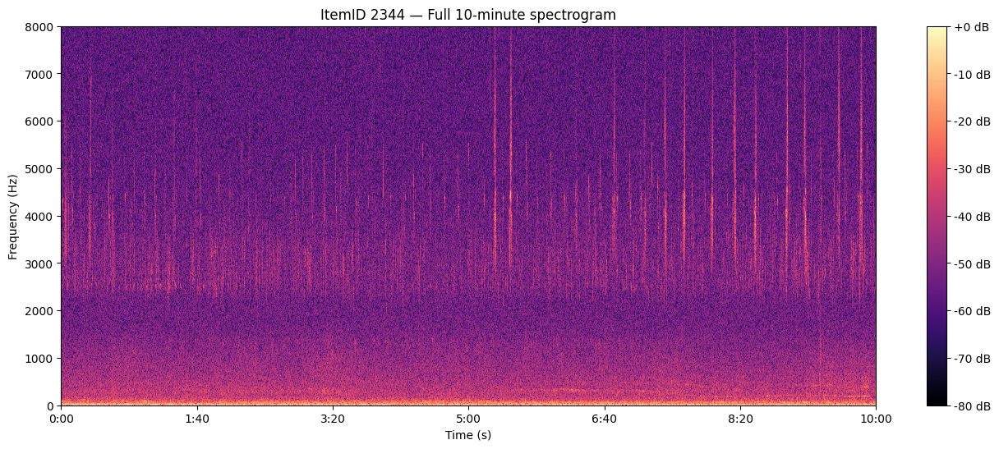

In [ ]:
# ============================================================
# Step 41 — Full-recording spectrogram for ItemID 2344
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

audio, sr = librosa.load(
    recording_2344,
    sr=None,
    mono=True
)

plt.figure(figsize=(16, 6))

librosa.display.specshow(
    librosa.amplitude_to_db(
        librosa.stft(audio, n_fft=2048, hop_length=512),
        ref=np.max
    ),
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="hz"
)

plt.ylim(0, 8000)
plt.colorbar(format="%+2.0f dB")
plt.title("ItemID 2344 — Full 10-minute spectrogram")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.show()

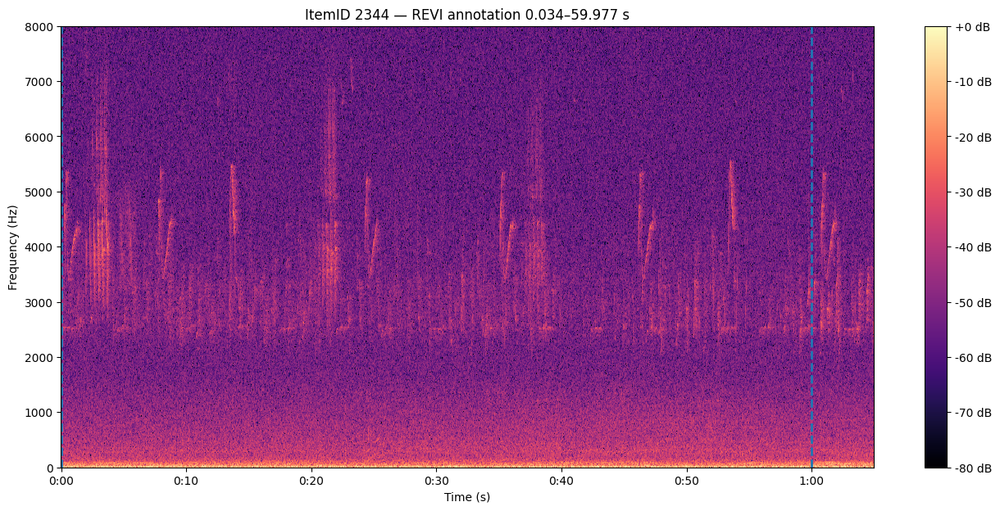

In [ ]:
# ============================================================
# Step 42 — Zoom into the first REVI annotation in ItemID 2344
# ============================================================

import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np

start_s = 0.0
end_s = 65.0

audio_segment = audio[
    int(start_s * sr):int(end_s * sr)
]

S_segment = librosa.stft(
    audio_segment,
    n_fft=2048,
    hop_length=512
)

plt.figure(figsize=(16, 7))

librosa.display.specshow(
    librosa.amplitude_to_db(
        np.abs(S_segment),
        ref=np.max
    ),
    sr=sr,
    hop_length=512,
    x_axis="time",
    y_axis="hz"
)

plt.ylim(0, 8000)

# REVI annotation boundaries
plt.axvline(0.034, linestyle="--", linewidth=2)
plt.axvline(59.977, linestyle="--", linewidth=2)

plt.colorbar(format="%+2.0f dB")
plt.title("ItemID 2344 — REVI annotation 0.034–59.977 s")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.show()

In [ ]:
# ============================================================
# Step 43 — Listen to first 10 seconds of REVI annotation
# ============================================================

from IPython.display import Audio, display

start_s = 0
end_s = 10

audio_10s = audio[
    int(start_s * sr):int(end_s * sr)
]

display(Audio(audio_10s, rate=sr))

In [ ]:
# ============================================================
# Step 44 — Find a long BHVI annotation
# ============================================================

bhvi_long = (
    master_events[
        (master_events["species_code"] == "BHVI") &
        (master_events["duration_s"] > 30)
    ]
    .sort_values("duration_s", ascending=False)
)

display(
    bhvi_long[
        [
            "event_id",
            "itemID",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "selection"
        ]
    ].head(10)
)

,event_id,itemID,begin_time_s,end_time_s,duration_s,selection
30944,2481_E0002,2481,6.636423,599.798356,593.161933,28
14183,2286_E0001,2286,0.876256,494.373595,493.497339,88
32266,2494_E0013,2494,433.935002,596.831741,162.896739,11
19137,2365_E0034,2365,97.661273,226.705611,129.044337,9
21575,2383_E0117,2383,474.135876,597.635052,123.499176,114
20766,2376_E0002,2376,0.518216,122.160299,121.642083,30
17648,2347_E0097,2347,477.184949,597.432797,120.247848,27
8847,2234_E0095,2234,353.629145,470.167809,116.538663,91
17611,2347_E0060,2347,361.321516,471.559646,110.238130,22
16360,2332_E0026,2332,119.232028,198.414047,79.182019,38


In [ ]:
# ============================================================
# Step 45 — Locate BHVI ItemID 2481 recording
# ============================================================

recording_2481 = list(
    (RECORDINGS_DIR / "DatasetSIMR").rglob("*2481*.flac")
)

recording_2481

[PosixPath('/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2481.08.01x.HBEFV009_20230523_090001.flac')]

In [ ]:
# ============================================================
# Step 46 — Listen to first 20 seconds of BHVI annotation
# ============================================================

import soundfile as sf
from IPython.display import Audio, display

audio_bhvi, sr_bhvi = sf.read(recording_2481[0])

bhvi_20s = audio_bhvi[:int(20 * sr_bhvi)]

display(Audio(bhvi_20s, rate=sr_bhvi))

In [ ]:
# ============================================================
# Step 47 — Inspect annotations in ItemID 2481
# ============================================================

item_2481 = (
    master_events[
        master_events["itemID"].astype(str) == "2481"
    ]
    .sort_values("begin_time_s")
)

display(
    item_2481[
        [
            "event_id",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "low_freq_hz",
            "high_freq_hz",
            "selection"
        ]
    ].to_string(index=False)
)

'  event_id species_code  begin_time_s  end_time_s  duration_s  low_freq_hz  high_freq_hz selection\n2481_E0001         BTNW      5.040981    5.958383    0.917402     3535.534      5568.466        34\n2481_E0002         BHVI      6.636423  599.798356  593.161933     2255.000      4939.600        28\n2481_E0003         BTNW     15.255351   16.399739    1.144388     3358.757      5126.524        35\n2481_E0004         BTNW     25.110327   26.037187    0.926860     2828.427      5745.243        36\n2481_E0005         BLJA     31.579429   33.357486    1.778057     1237.437      4154.252        38\n2481_E0006         BTNW     34.974761   36.100233    1.125472     2916.815      6010.408        37\n2481_E0007         BLJA     46.303681   48.119569    1.815888     1280.797      4162.591        32\n2481_E0008         BTNW     46.577956   48.337098    1.759142     2561.594      5763.587        33\n2481_E0009         BLJA     50.465091   52.167328    1.702236     2040.300      4832.200        29\

In [ ]:
# ============================================================
# Step 48 — Count overlapping annotation pairs
# ============================================================

events_2481 = (
    master_events[
        master_events["itemID"].astype(str) == "2481"
    ]
    .sort_values("begin_time_s")
    .reset_index(drop=True)
)

overlaps = []

for i in range(len(events_2481)):
    current = events_2481.iloc[i]

    for j in range(i + 1, len(events_2481)):
        other = events_2481.iloc[j]

        if other["begin_time_s"] >= current["end_time_s"]:
            break

        overlap_s = min(
            current["end_time_s"],
            other["end_time_s"]
        ) - max(
            current["begin_time_s"],
            other["begin_time_s"]
        )

        if overlap_s > 0:
            overlaps.append({
                "event_1": current["event_id"],
                "species_1": current["species_code"],
                "event_2": other["event_id"],
                "species_2": other["species_code"],
                "overlap_s": overlap_s
            })

overlap_df = pd.DataFrame(overlaps)

print(f"Total events: {len(events_2481)}")
print(f"Overlapping pairs: {len(overlap_df)}")

display(overlap_df.head(20))

Total events: 50
Overlapping pairs: 49


,event_1,species_1,event_2,species_2,overlap_s
0,2481_E0002,BHVI,2481_E0003,BTNW,1.144388
1,2481_E0002,BHVI,2481_E0004,BTNW,0.926860
2,2481_E0002,BHVI,2481_E0005,BLJA,1.778057
3,2481_E0002,BHVI,2481_E0006,BTNW,1.125472
4,2481_E0002,BHVI,2481_E0007,BLJA,1.815888
5,2481_E0002,BHVI,2481_E0008,BTNW,1.759142
6,2481_E0002,BHVI,2481_E0009,BLJA,1.702236
7,2481_E0002,BHVI,2481_E0010,BTNW,1.948924
8,2481_E0002,BHVI,2481_E0011,BLJA,0.870113
9,2481_E0002,BHVI,2481_E0012,BLJA,1.229508


In [ ]:
# ============================================================
# Step 49 — Do long annotations systematically overlap others?
# ============================================================

events = (
    master_events[
        ["event_id", "itemID", "species_code",
         "begin_time_s", "end_time_s", "duration_s"]
    ]
    .sort_values(["itemID", "begin_time_s"])
    .reset_index(drop=True)
)

overlap_counts = []

for item_id, group in events.groupby("itemID", sort=False):

    group = group.reset_index(drop=True)
    n_overlapping = np.zeros(len(group), dtype=int)

    for i in range(len(group)):
        for j in range(i + 1, len(group)):

            if group.loc[j, "begin_time_s"] >= group.loc[i, "end_time_s"]:
                break

            if (
                min(group.loc[i, "end_time_s"],
                    group.loc[j, "end_time_s"])
                >
                max(group.loc[i, "begin_time_s"],
                    group.loc[j, "begin_time_s"])
            ):
                n_overlapping[i] += 1
                n_overlapping[j] += 1

    temp = group[["event_id", "itemID", "species_code", "duration_s"]].copy()
    temp["n_overlapping_annotations"] = n_overlapping
    overlap_counts.append(temp)

overlap_counts = pd.concat(overlap_counts, ignore_index=True)

# Summarize by duration class
overlap_counts["duration_class"] = pd.cut(
    overlap_counts["duration_s"],
    bins=[-np.inf, 2, 5, 10, 30, 60, 300, np.inf],
    labels=[
        "0–2 s",
        "2–5 s",
        "5–10 s",
        "10–30 s",
        "30–60 s",
        "1–5 min",
        ">5 min"
    ]
)

summary = (
    overlap_counts
    .groupby("duration_class", observed=False)
    .agg(
        n_annotations=("event_id", "size"),
        n_with_overlap=(
            "n_overlapping_annotations",
            lambda x: (x > 0).sum()
        ),
        median_overlaps=(
            "n_overlapping_annotations",
            "median"
        ),
        max_overlaps=(
            "n_overlapping_annotations",
            "max"
        )
    )
)

summary["pct_with_overlap"] = (
    summary["n_with_overlap"]
    / summary["n_annotations"]
    * 100
)

display(summary)

,n_annotations,n_with_overlap,median_overlaps,max_overlaps,pct_with_overlap
duration_class,,,,,
0–2 s,130397,87329,1.0,7,66.971633
2–5 s,43254,32754,1.0,8,75.724788
5–10 s,3972,2997,2.0,13,75.453172
10–30 s,1886,1693,3.0,28,89.766702
30–60 s,4382,4231,13.0,62,96.554085
1–5 min,176,155,12.5,81,88.068182
>5 min,19,18,49.0,202,94.736842


In [ ]:
# ============================================================
# Step 50 — Recording-time coverage by annotation duration
# ============================================================

duration_bins = [
    (-np.inf, 2, "0–2 s"),
    (2, 5, "2–5 s"),
    (5, 10, "5–10 s"),
    (10, 30, "10–30 s"),
    (30, 60, "30–60 s"),
    (60, 300, "1–5 min"),
    (300, np.inf, ">5 min"),
]

coverage_rows = []

for dataset_id, group in master_events.groupby("dataset_ID"):

    total_recording_seconds = (
        master_recordings.loc[
            master_recordings["dataset_ID"] == dataset_id,
            "n_events"
        ].shape[0] * 600
    )

    for low, high, label in duration_bins:

        subset = group[
            (group["duration_s"] > low) &
            (group["duration_s"] <= high)
        ]

        coverage_rows.append({
            "dataset_ID": dataset_id,
            "duration_class": label,
            "n_annotations": len(subset),
            "total_annotated_seconds": subset["duration_s"].sum()
        })

coverage_df = pd.DataFrame(coverage_rows)

display(coverage_df)

,dataset_ID,duration_class,n_annotations,total_annotated_seconds
0,DatasetACAD,0–2 s,33732,40502.449166
1,DatasetACAD,2–5 s,6956,18776.679607
2,DatasetACAD,5–10 s,1227,8132.194654
3,DatasetACAD,10–30 s,401,6846.956260
4,DatasetACAD,30–60 s,651,34337.487150
5,DatasetACAD,1–5 min,3,274.986027
6,DatasetACAD,>5 min,0,0.000000
7,DatasetMABI,0–2 s,64327,84546.657314
8,DatasetMABI,2–5 s,25629,68174.273352
9,DatasetMABI,5–10 s,1533,10447.645574


In [ ]:
# ============================================================
# Step 51 — Long-annotation prevalence by species
# ============================================================

species_long = (
    master_events
    .groupby("species_code")
    .agg(
        n_annotations=("event_id", "size"),
        median_duration_s=("duration_s", "median"),
        n_over_10s=("duration_s", lambda x: (x > 10).sum()),
        n_over_30s=("duration_s", lambda x: (x > 30).sum()),
        n_over_60s=("duration_s", lambda x: (x > 60).sum()),
        max_duration_s=("duration_s", "max")
    )
)

species_long["pct_over_10s"] = (
    species_long["n_over_10s"]
    / species_long["n_annotations"]
    * 100
)

species_long["pct_over_30s"] = (
    species_long["n_over_30s"]
    / species_long["n_annotations"]
    * 100
)

species_long["pct_over_60s"] = (
    species_long["n_over_60s"]
    / species_long["n_annotations"]
    * 100
)

display(
    species_long
    .sort_values("pct_over_30s", ascending=False)
    .head(30)
)

,n_annotations,median_duration_s,n_over_10s,n_over_30s,n_over_60s,max_duration_s,pct_over_10s,pct_over_30s,pct_over_60s
species_code,,,,,,,,,
REVI,6724,50.610840,5117,4023,160,598.991835,76.100535,59.830458,2.379536
HERG,10,3.956596,3,2,0,59.905748,30.000000,20.000000,0.000000
EACH,313,3.448491,97,59,10,189.511240,30.990415,18.849840,3.194888
BHVI,1885,2.176506,610,313,12,593.161933,32.360743,16.604775,0.636605
UNMA,263,2.657034,74,42,2,112.826851,28.136882,15.969582,0.760456
CANG,22,2.931880,4,1,0,36.524256,18.181818,4.545455,0.000000
????,588,1.281534,59,20,4,121.349348,10.034014,3.401361,0.680272
RESQ,399,2.685300,32,11,2,197.710504,8.020050,2.756892,0.501253
CEDW,213,0.684855,4,3,1,96.121002,1.877934,1.408451,0.469484


In [ ]:
# ============================================================
# Step 52 — Duration patterns by species and dataset
# ============================================================

species_dataset_duration = (
    master_events
    .groupby(["species_code", "dataset_ID"])
    .agg(
        n_annotations=("event_id", "size"),
        median_duration_s=("duration_s", "median"),
        pct_over_10s=("duration_s", lambda x: (x > 10).mean() * 100),
        pct_over_30s=("duration_s", lambda x: (x > 30).mean() * 100),
        pct_over_60s=("duration_s", lambda x: (x > 60).mean() * 100),
        max_duration_s=("duration_s", "max")
    )
    .reset_index()
)

display(
    species_dataset_duration[
        species_dataset_duration["species_code"].isin(["REVI", "BHVI"])
    ]
    .sort_values(["species_code", "dataset_ID"])
)

,species_code,dataset_ID,n_annotations,median_duration_s,pct_over_10s,pct_over_30s,pct_over_60s,max_duration_s
28,BHVI,DatasetACAD,939,0.659547,23.748669,11.927583,0.000000,59.566552
29,BHVI,DatasetMABI,429,10.722325,51.048951,29.137529,0.233100,62.453281
30,BHVI,DatasetSIMR,517,1.625567,32.495164,14.700193,2.127660,593.161933
175,REVI,DatasetACAD,1070,25.006268,65.233645,47.196262,0.000000,59.971702
176,REVI,DatasetMABI,3546,57.208462,86.858432,75.211506,0.451213,118.442390
177,REVI,DatasetSIMR,2108,18.372309,63.519924,40.370019,6.831120,598.991835


In [ ]:
# ============================================================
# Step 53 — Select representative annotations for comparison
# ============================================================

# REVI: representative long annotation
revi_example = (
    master_events[
        (master_events["species_code"] == "REVI") &
        (master_events["duration_s"] >= 50) &
        (master_events["duration_s"] <= 65)
    ]
    .sort_values("duration_s")
    .iloc[0]
)

# BHVI: representative long annotation
bhvi_example = (
    master_events[
        (master_events["species_code"] == "BHVI") &
        (master_events["duration_s"] >= 50) &
        (master_events["duration_s"] <= 65)
    ]
    .sort_values("duration_s")
    .iloc[0]
)

# Typical short annotation:
# choose a common species with duration around 1–2 seconds
short_example = (
    master_events[
        (master_events["duration_s"] >= 1) &
        (master_events["duration_s"] <= 2) &
        (master_events["is_bird"] == "Yes")
    ]
    .sort_values("duration_s")
    .iloc[len(master_events) // 100]
)

comparison = pd.DataFrame([
    revi_example,
    bhvi_example,
    short_example
])[
    [
        "event_id",
        "itemID",
        "species_code",
        "begin_time_s",
        "end_time_s",
        "duration_s",
        "low_freq_hz",
        "high_freq_hz",
        "dataset_ID"
    ]
]

display(comparison)

,event_id,itemID,species_code,begin_time_s,end_time_s,duration_s,low_freq_hz,high_freq_hz,dataset_ID
147031,6527_E0036,6527,REVI,300.124369,350.136905,50.012537,1847.136,5656.854,DatasetACAD
17568,2347_E0017,2347,BHVI,182.774524,232.900601,50.126077,1944.544,6010.408,DatasetSIMR
175896,6799_E0116,6799,HAWO,516.464675,517.491684,1.027009,230.900,1731.700,DatasetACAD


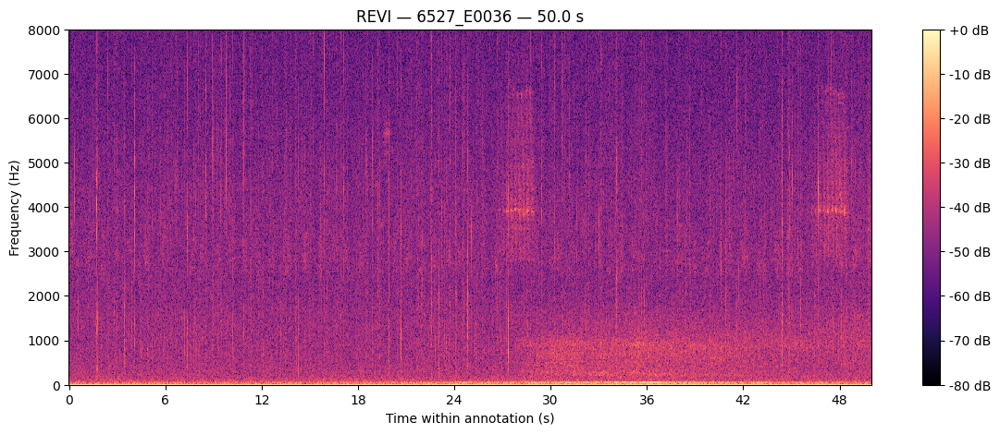

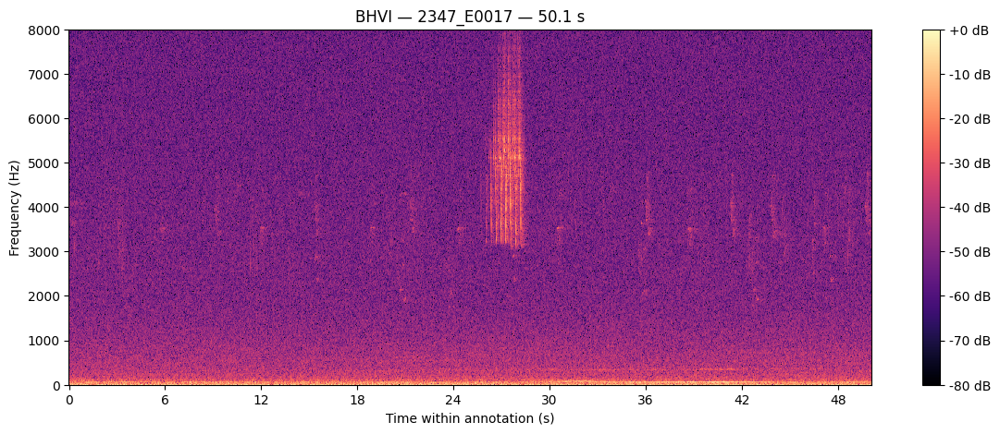

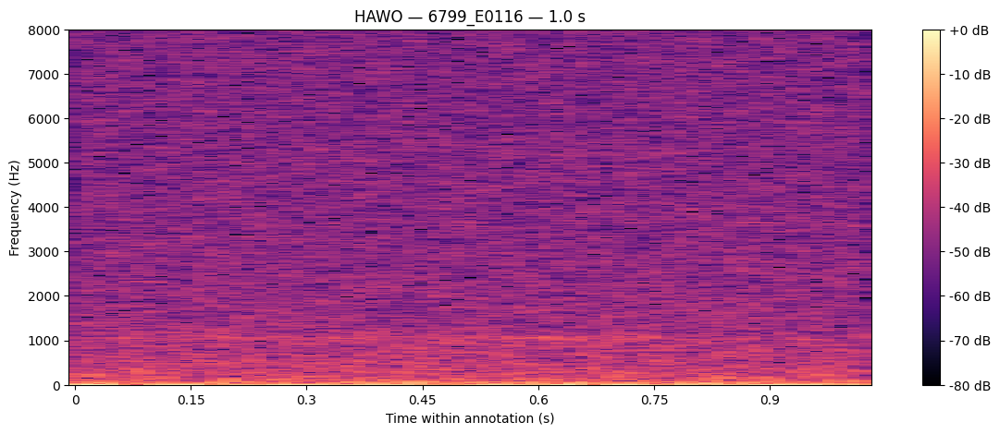

In [ ]:
# ============================================================
# Step 54 — Spectrograms of representative annotations
# ============================================================

import soundfile as sf
import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np

examples = [
    ("REVI", revi_example),
    ("BHVI", bhvi_example),
    ("HAWO", short_example),
]

for label, example in examples:

    # Locate recording
    recording_matches = list(
        (RECORDINGS_DIR / example["dataset_ID"]).rglob(
            f"*{example['itemID']}*.flac"
        )
    )

    recording_path = recording_matches[0]

    # Load only the relevant segment
    audio_seg, sr_seg = sf.read(
        recording_path,
        start=int(example["begin_time_s"] * 32000),
        stop=int(example["end_time_s"] * 32000)
    )

    # Handle stereo just in case
    if audio_seg.ndim > 1:
        audio_seg = audio_seg.mean(axis=1)

    S = librosa.stft(
        audio_seg,
        n_fft=2048,
        hop_length=512
    )

    plt.figure(figsize=(14, 5))

    librosa.display.specshow(
        librosa.amplitude_to_db(
            np.abs(S),
            ref=np.max
        ),
        sr=sr_seg,
        hop_length=512,
        x_axis="time",
        y_axis="hz"
    )

    plt.ylim(0, 8000)
    plt.colorbar(format="%+2.0f dB")
    plt.title(
        f"{label} — {example['event_id']} — "
        f"{example['duration_s']:.1f} s"
    )
    plt.xlabel("Time within annotation (s)")
    plt.ylabel("Frequency (Hz)")
    plt.show()

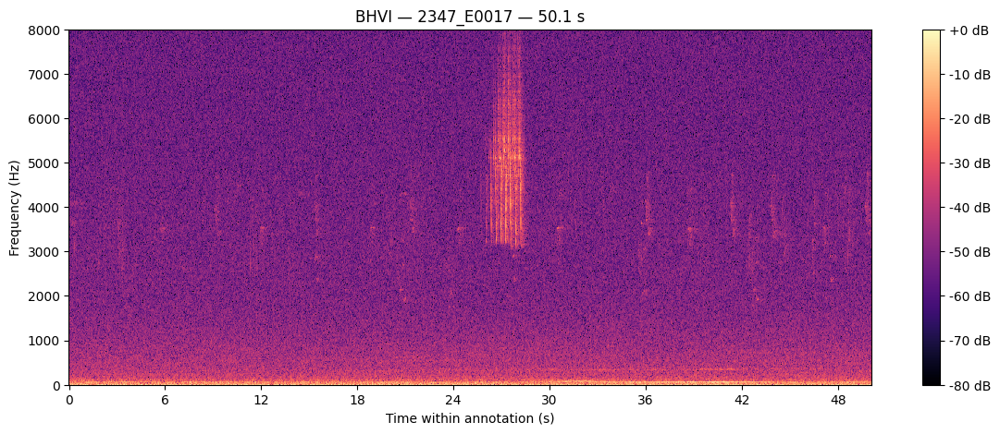

In [ ]:
# ============================================================
# Step 55 — BHVI representative long annotation
# ============================================================

bhvi = bhvi_example

recording_matches = list(
    (RECORDINGS_DIR / bhvi["dataset_ID"]).rglob(
        f"*{bhvi['itemID']}*.flac"
    )
)

recording_path = recording_matches[0]

audio_bhvi_seg, sr_bhvi_seg = sf.read(
    recording_path,
    start=int(bhvi["begin_time_s"] * 32000),
    stop=int(bhvi["end_time_s"] * 32000)
)

if audio_bhvi_seg.ndim > 1:
    audio_bhvi_seg = audio_bhvi_seg.mean(axis=1)

S_bhvi = librosa.stft(
    audio_bhvi_seg,
    n_fft=2048,
    hop_length=512
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    librosa.amplitude_to_db(
        np.abs(S_bhvi),
        ref=np.max
    ),
    sr=sr_bhvi_seg,
    hop_length=512,
    x_axis="time",
    y_axis="hz"
)

plt.ylim(0, 8000)
plt.colorbar(format="%+2.0f dB")
plt.title(
    f"BHVI — {bhvi['event_id']} — "
    f"{bhvi['duration_s']:.1f} s"
)
plt.xlabel("Time within annotation (s)")
plt.ylabel("Frequency (Hz)")
plt.show()

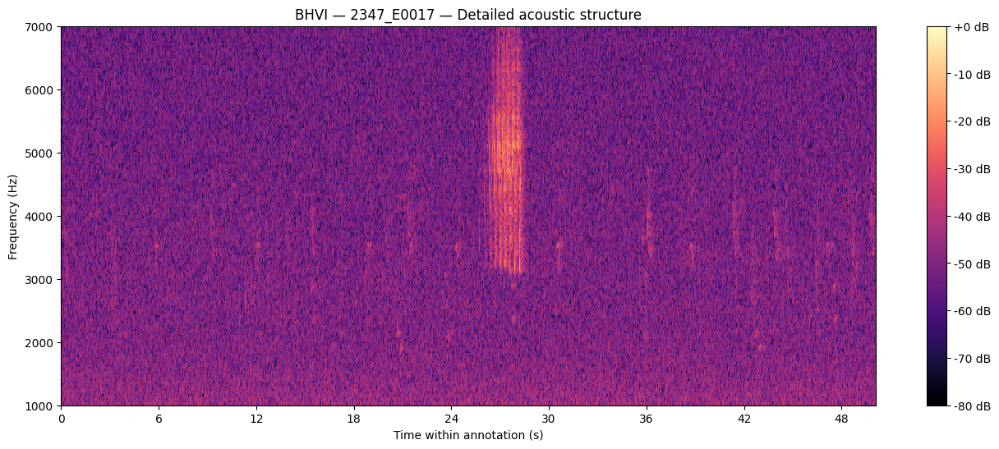

In [ ]:
# ============================================================
# Step 56 — Inspect BHVI at higher temporal resolution
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

y = audio_bhvi_seg
sr = sr_bhvi_seg

fig, ax = plt.subplots(figsize=(16, 6))

S = librosa.stft(
    y,
    n_fft=1024,
    hop_length=256
)

S_db = librosa.amplitude_to_db(
    np.abs(S),
    ref=np.max
)

img = librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=256,
    x_axis="time",
    y_axis="hz",
    ax=ax
)

ax.set_ylim(1000, 7000)

ax.set_title(
    "BHVI — 2347_E0017 — Detailed acoustic structure"
)

ax.set_xlabel("Time within annotation (s)")
ax.set_ylabel("Frequency (Hz)")

fig.colorbar(
    img,
    ax=ax,
    format="%+2.0f dB"
)

plt.show()

In [ ]:
# ============================================================
# Step 57 — Listen to the prominent BHVI bout
# ============================================================

from IPython.display import Audio, display

# 24–32 seconds within the BHVI annotation
start_s = 24
end_s = 32

bhvi_bout = audio_bhvi_seg[
    int(start_s * sr_bhvi_seg):
    int(end_s * sr_bhvi_seg)
]

display(Audio(bhvi_bout, rate=sr_bhvi_seg))

In [ ]:
# ============================================================
# Step 58 — Efficient temporal relationship check
# ============================================================

import numpy as np
import pandas as pd

events_sorted = (
    master_events[
        [
            "event_id",
            "itemID",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s"
        ]
    ]
    .sort_values(["itemID", "begin_time_s", "end_time_s"])
    .reset_index(drop=True)
)

overlap_count = 0
gap_0_to_2s_count = 0
gap_over_2s_count = 0

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    # For each annotation, only inspect subsequent annotations
    # whose start occurs before the current annotation ends + 2 s.
    for i in range(n - 1):

        cutoff = ends[i] + 2.0

        j = np.searchsorted(
            starts,
            cutoff,
            side="left",
            sorter=None
        )

        # Subsequent annotations are indices i+1 through j-1
        if j <= i + 1:
            continue

        subsequent_starts = starts[i + 1:j]

        # Overlap if the next annotation begins before
        # the current annotation ends.
        n_overlap = np.sum(
            subsequent_starts < ends[i]
        )

        overlap_count += int(n_overlap)

        # Non-overlapping annotations beginning within 2 s
        # of the current annotation's end.
        n_near = np.sum(
            (subsequent_starts >= ends[i]) &
            (subsequent_starts <= ends[i] + 2.0)
        )

        gap_0_to_2s_count += int(n_near)

        # Everything beyond the 2-second window is not
        # counted here because we don't need every distant pair.
        # We'll calculate the total relevant pairs separately.

# Summarize
relationship_summary = pd.DataFrame({
    "relationship": [
        "overlap",
        "gap_0_to_2s"
    ],
    "n_pairs": [
        overlap_count,
        gap_0_to_2s_count
    ]
})

display(relationship_summary)

,relationship,n_pairs
0,overlap,139153
1,gap_0_to_2s,128281


In [ ]:
# ============================================================
# Step 59 — Distribution of gaps between consecutive annotations
# ============================================================

events_sorted = (
    master_events[
        [
            "event_id",
            "itemID",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s"
        ]
    ]
    .sort_values(["itemID", "begin_time_s", "end_time_s"])
    .reset_index(drop=True)
)

# Look at the next annotation within each recording
events_sorted["next_begin_s"] = (
    events_sorted
    .groupby("itemID")["begin_time_s"]
    .shift(-1)
)

events_sorted["gap_s"] = (
    events_sorted["next_begin_s"]
    - events_sorted["end_time_s"]
)

# Keep only genuinely non-overlapping consecutive annotations
gaps = events_sorted[
    events_sorted["gap_s"] >= 0
].copy()

print(f"Non-overlapping consecutive pairs: {len(gaps):,}")

print("\nGap summary:")
display(
    gaps["gap_s"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nSelected gap thresholds:")
for threshold in [0, 0.5, 1, 2, 3, 5, 10, 15, 20, 30]:
    pct = (gaps["gap_s"] <= threshold).mean() * 100
    print(f"≤ {threshold:>4} s: {pct:6.2f}%")

Non-overlapping consecutive pairs: 123,189

Gap summary:


,gap_s
count,123189.000000
mean,3.647937
std,8.119377
min,0.000000
25%,0.771900
50%,1.984703
75%,4.189369
90%,7.999589
95%,11.164552
99%,24.222690



Selected gap thresholds:
≤    0 s:   0.15%
≤  0.5 s:  17.35%
≤    1 s:  30.70%
≤    2 s:  50.26%
≤    3 s:  64.43%
≤    5 s:  79.71%
≤   10 s:  93.63%
≤   15 s:  97.30%
≤   20 s:  98.58%
≤   30 s:  99.30%


In [ ]:
# ============================================================
# Step 60 — Examine overlap duration between annotations
# ============================================================

events_sorted = (
    master_events[
        [
            "event_id",
            "itemID",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s"
        ]
    ]
    .sort_values(["itemID", "begin_time_s", "end_time_s"])
    .reset_index(drop=True)
)

overlap_durations = []

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    for i in range(n - 1):

        # Only inspect annotations that begin before
        # the current annotation ends.
        j = np.searchsorted(
            starts,
            ends[i],
            side="left"
        )

        if j <= i + 1:
            continue

        other_starts = starts[i + 1:j]
        other_ends = ends[i + 1:j]

        overlap = np.minimum(ends[i], other_ends) - np.maximum(
            starts[i], other_starts
        )

        overlap = overlap[overlap > 0]

        if len(overlap):
            overlap_durations.extend(overlap)

overlap_durations = np.asarray(overlap_durations)

print(f"Overlapping pairs: {len(overlap_durations):,}")

print("\nOverlap-duration summary:")
display(
    pd.Series(overlap_durations).describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nSelected overlap thresholds:")
for threshold in [0.1, 0.5, 1, 2, 5, 10]:
    pct = (overlap_durations <= threshold).mean() * 100
    print(f"≤ {threshold:>4} s: {pct:6.2f}%")

Overlapping pairs: 139,151

Overlap-duration summary:


,0
count,1.391510e+05
mean,1.338916e+00
std,2.357641e+00
min,3.200000e-08
25%,5.676176e-01
50%,1.158415e+00
75%,1.690908e+00
90%,2.317838e+00
95%,2.806929e+00
99%,5.256703e+00



Selected overlap thresholds:
≤  0.1 s:   4.51%
≤  0.5 s:  22.22%
≤    1 s:  43.13%
≤    2 s:  84.21%
≤    5 s:  98.90%
≤   10 s:  99.68%


In [ ]:
# ============================================================
# Step 61 — Examine temporal ordering of overlapping events
# ============================================================

events_sorted = (
    master_events[
        [
            "event_id",
            "itemID",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s"
        ]
    ]
    .sort_values(["itemID", "begin_time_s", "end_time_s"])
    .reset_index(drop=True)
)

start_differences = []

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    for i in range(n - 1):

        j = np.searchsorted(
            starts,
            ends[i],
            side="left"
        )

        if j <= i + 1:
            continue

        # How much later did the second annotation begin?
        start_diff = starts[i + 1:j] - starts[i]

        start_differences.extend(start_diff)

start_differences = np.asarray(start_differences)

print(f"Overlapping pairs: {len(start_differences):,}")

print("\nDifference between annotation start times:")
display(
    pd.Series(start_differences).describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nStart-time separation:")
for threshold in [0.1, 0.25, 0.5, 1, 2, 5]:
    pct = (start_differences <= threshold).mean() * 100
    print(f"≤ {threshold:>4} s: {pct:6.2f}%")

Overlapping pairs: 139,153

Difference between annotation start times:


,0
count,139153.000000
mean,16.728523
std,32.181176
min,0.000000
10%,0.457531
25%,1.069683
50%,4.011650
75%,26.583152
90%,45.340654
95%,52.436379



Start-time separation:
≤  0.1 s:   2.20%
≤ 0.25 s:   5.46%
≤  0.5 s:  11.01%
≤    1 s:  23.32%
≤    2 s:  41.01%
≤    5 s:  51.86%


In [ ]:
# ============================================================
# Step 62 — How many potential edges does each event create?
# ============================================================

MAX_GAP_S = 10.0

events_sorted = (
    master_events[
        [
            "event_id",
            "itemID",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s"
        ]
    ]
    .sort_values(["itemID", "begin_time_s", "end_time_s", "event_id"])
    .reset_index(drop=True)
)

edge_counts = []

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()
    event_ids = group["event_id"].to_numpy()
    species = group["species_code"].to_numpy()

    n = len(group)

    for i in range(n):

        # Candidate events beginning before the source
        # ends + maximum succession gap.
        j = np.searchsorted(
            starts,
            ends[i] + MAX_GAP_S,
            side="right"
        )

        # Only later events
        n_candidates = max(0, j - i - 1)

        edge_counts.append({
            "event_id": event_ids[i],
            "itemID": item_id,
            "species_code": species[i],
            "duration_s": ends[i] - starts[i],
            "potential_outgoing_edges": n_candidates
        })

edge_count_df = pd.DataFrame(edge_counts)

print("Number of events:", len(edge_count_df))

print("\nPotential outgoing-edge summary:")
display(
    edge_count_df["potential_outgoing_edges"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    )
)

print("\nEvents with the most potential outgoing edges:")
display(
    edge_count_df
    .sort_values("potential_outgoing_edges", ascending=False)
    .head(20)
)

print("\nPotential outgoing edges by species:")
display(
    edge_count_df
    .groupby("species_code")["potential_outgoing_edges"]
    .agg(
        n_events="size",
        median="median",
        mean="mean",
        maximum="max"
    )
    .sort_values("maximum", ascending=False)
    .head(20)
)

Number of events: 184086

Potential outgoing-edge summary:


,potential_outgoing_edges
count,184086.000000
mean,4.352477
std,3.932053
min,0.000000
50%,4.000000
90%,8.000000
95%,10.000000
99%,19.000000
99.9%,42.000000
max,202.000000



Events with the most potential outgoing edges:


,event_id,itemID,species_code,duration_s,potential_outgoing_edges
19637,2368_E0002,2368,REVI,596.955646,202
36167,2525_E0001,2525,REVI,598.991835,106
34648,2514_E0002,2514,REVI,597.876345,104
19281,2366_E0001,2366,REVI,404.826599,102
27138,2446_E0024,2446,REVI,474.640474,87
20423,2373_E0055,2373,REVI,506.310500,87
4119,1734_E0099,1734,REVI,163.063021,81
120476,5399_E0257,5399,????,121.349348,80
10265,2244_E0033,2244,EACH,181.231905,77
14183,2286_E0001,2286,BHVI,493.497339,76



Potential outgoing edges by species:


,n_events,median,mean,maximum
species_code,,,,
REVI,6724,9.0,13.034652,202
????,588,4.0,4.634354,80
EACH,313,5.0,6.613419,77
BHVI,1885,5.0,6.235013,76
AMCR,4837,4.0,4.433326,55
UNMA,263,4.0,7.057034,53
RBNU,1601,4.0,4.422236,38
HETH,18572,3.0,3.568329,37
BCCH,6398,5.0,5.592685,34


In [ ]:
# ============================================================
# Step 63 — Inspect candidate relationships for the
# longest/highest-connectivity annotation
# ============================================================

TEST_EVENT_ID = "2368_E0002"

source = master_events[
    master_events["event_id"] == TEST_EVENT_ID
].iloc[0]

same_recording = (
    master_events[
        master_events["itemID"] == source["itemID"]
    ]
    .copy()
    .sort_values(
        ["begin_time_s", "end_time_s", "event_id"]
    )
)

candidates = same_recording[
    same_recording["event_id"] != TEST_EVENT_ID
].copy()

# Keep only events that occur after the source annotation
# begins and before source end + MAX_GAP.
candidates = candidates[
    (candidates["begin_time_s"] > source["begin_time_s"]) &
    (candidates["begin_time_s"] <= source["end_time_s"] + MAX_GAP_S)
].copy()

# Determine relationship type
candidates["relationship_type"] = np.where(
    candidates["begin_time_s"] < source["end_time_s"],
    "overlap",
    "succession"
)

# Calculate temporal quantities
candidates["start_lag_s"] = (
    candidates["begin_time_s"] - source["begin_time_s"]
)

candidates["overlap_duration_s"] = np.where(
    candidates["relationship_type"] == "overlap",
    np.minimum(
        source["end_time_s"],
        candidates["end_time_s"]
    )
    - candidates["begin_time_s"],
    np.nan
)

candidates["gap_s"] = np.where(
    candidates["relationship_type"] == "succession",
    candidates["begin_time_s"] - source["end_time_s"],
    np.nan
)

print("SOURCE EVENT")
display(
    pd.DataFrame([{
        "event_id": source["event_id"],
        "itemID": source["itemID"],
        "species": source["species_code"],
        "begin_time_s": source["begin_time_s"],
        "end_time_s": source["end_time_s"],
        "duration_s": source["duration_s"]
    }])
)

print("\nCandidate relationships:")
display(
    candidates[
        [
            "event_id",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "relationship_type",
            "start_lag_s",
            "overlap_duration_s",
            "gap_s"
        ]
    ]
    .head(50)
)

print("\nRelationship counts:")
display(
    candidates["relationship_type"]
    .value_counts()
    .rename_axis("relationship_type")
    .to_frame("n")
)

print("\nTarget species:")
display(
    candidates["species_code"]
    .value_counts()
    .head(20)
)

SOURCE EVENT


,event_id,itemID,species,begin_time_s,end_time_s,duration_s
0,2368_E0002,2368,REVI,2.03629,598.991936,596.955646



Candidate relationships:


,event_id,species_code,begin_time_s,end_time_s,duration_s,relationship_type,start_lag_s,overlap_duration_s,gap_s
19638,2368_E0003,RBGR,4.354838,7.721773,3.366935,overlap,2.318548,3.366935,NaN
19639,2368_E0004,BAWW,10.233286,12.389653,2.156367,overlap,8.196996,2.156367,NaN
19640,2368_E0005,OVEN,12.822578,14.758062,1.935484,overlap,10.786288,1.935484,NaN
19641,2368_E0006,BTBW,14.337638,15.807462,1.469824,overlap,12.301348,1.469824,NaN
19642,2368_E0007,RBGR,14.879030,17.661287,2.782258,overlap,12.842740,2.782258,NaN
19643,2368_E0008,OVEN,15.425591,17.515754,2.090163,overlap,13.389301,2.090163,NaN
19644,2368_E0009,RBGR,22.681448,26.088705,3.407257,overlap,20.645158,3.407257,NaN
19645,2368_E0010,EAWP,26.754028,28.145156,1.391129,overlap,24.717738,1.391129,NaN
19646,2368_E0011,OVEN,29.516124,31.290317,1.774193,overlap,27.479834,1.774193,NaN
19647,2368_E0012,RBGR,29.939511,32.439510,2.500000,overlap,27.903221,2.500000,NaN



Relationship counts:


,n
relationship_type,
overlap,202



Target species:


,count
species_code,
EAWP,54
OVEN,51
BAWW,38
BTBW,28
RBGR,10
CSWA,9
YBSA,6
WIWR,4
PIWA,2


In [ ]:
# ============================================================
# Step 64 — Test conservative overlap windows
# ============================================================

# We already calculated overlapping pairs in Step 61.
# Recalculate the start-time separation distribution
# by recording, using the same overlap definition.

start_lags = []

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    for i in range(n):

        j = np.searchsorted(
            starts,
            ends[i],
            side="left"
        )

        if j <= i + 1:
            continue

        candidate_starts = starts[i + 1:j]

        # Start-time difference from the source
        lags = candidate_starts - starts[i]

        start_lags.extend(lags)

start_lags = np.asarray(start_lags)

print(f"Total overlapping pairs: {len(start_lags):,}")

print("\nOverlap relationships retained under different start-time windows:")

for window in [1, 2, 5, 10, 20, 30]:
    n = np.sum(start_lags <= window)
    pct = n / len(start_lags) * 100

    print(
        f"≤ {window:>2} s: "
        f"{n:>7,} pairs "
        f"({pct:6.2f}%)"
    )

Total overlapping pairs: 139,153

Overlap relationships retained under different start-time windows:
≤  1 s:  32,452 pairs ( 23.32%)
≤  2 s:  57,067 pairs ( 41.01%)
≤  5 s:  72,166 pairs ( 51.86%)
≤ 10 s:  81,718 pairs ( 58.73%)
≤ 20 s:  95,979 pairs ( 68.97%)
≤ 30 s: 108,395 pairs ( 77.90%)


In [ ]:
# ============================================================
# Step 65 — Count proposed local temporal relationships
# ============================================================

MAX_WINDOW_S = 10.0

local_overlap_count = 0
local_succession_count = 0

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    for i in range(n):

        # Only later-starting events within 10 seconds
        # of the source start.
        j = np.searchsorted(
            starts,
            starts[i] + MAX_WINDOW_S,
            side="right"
        )

        if j <= i + 1:
            continue

        target_starts = starts[i + 1:j]

        # Overlap
        overlap_mask = target_starts < ends[i]

        local_overlap_count += int(
            np.sum(overlap_mask)
        )

        # Succession
        succession_mask = target_starts >= ends[i]

        # Must begin no more than 10 s after source ends
        succession_gaps = (
            target_starts[succession_mask] - ends[i]
        )

        local_succession_count += int(
            np.sum(succession_gaps <= MAX_WINDOW_S)
        )

print("Proposed local temporal relationships")
print("-------------------------------------")
print(f"Overlap edges:    {local_overlap_count:,}")
print(f"Succession edges: {local_succession_count:,}")
print(
    f"Total edges:      "
    f"{local_overlap_count + local_succession_count:,}"
)

Proposed local temporal relationships
-------------------------------------
Overlap edges:    81,718
Succession edges: 530,128
Total edges:      611,846


In [ ]:
# ============================================================
# Step 66 — Compare all local succession relationships
#           with immediate-next succession relationships
# ============================================================

MAX_WINDOW_S = 10.0

all_succession = 0
next_succession = 0

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    for i in range(n - 1):

        # ----------------------------------------------------
        # All later events beginning within 10 s after source
        # ends
        # ----------------------------------------------------

        j = np.searchsorted(
            starts,
            ends[i] + MAX_WINDOW_S,
            side="right"
        )

        if j > i + 1:

            target_starts = starts[i + 1:j]

            gaps = target_starts - ends[i]

            all_succession += int(
                np.sum(gaps >= 0)
            )

        # ----------------------------------------------------
        # Immediate next annotation only
        # ----------------------------------------------------

        next_gap = starts[i + 1] - ends[i]

        if 0 <= next_gap <= MAX_WINDOW_S:
            next_succession += 1

print("Succession relationship comparison")
print("-----------------------------------")
print(f"All local succession edges:     {all_succession:,}")
print(f"Immediate-next succession:      {next_succession:,}")

print(
    f"\nAdditional non-immediate edges: "
    f"{all_succession - next_succession:,}"
)

print(
    f"Ratio (all / immediate): "
    f"{all_succession / next_succession:.2f}"
)

Succession relationship comparison
-----------------------------------
All local succession edges:     662,077
Immediate-next succession:      115,341

Additional non-immediate edges: 546,736
Ratio (all / immediate): 5.74


In [ ]:
# ============================================================
# Step 67 — Count edges under the revised initial network rule
# ============================================================

MAX_WINDOW_S = 10.0

overlap_edges = 0
succession_edges = 0

for item_id, group in events_sorted.groupby("itemID", sort=False):

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    for i in range(n):

        # ----------------------------------------------------
        # Overlap relationships:
        # all later-starting events that begin within 10 s
        # of the source start AND overlap the source.
        # ----------------------------------------------------

        j = np.searchsorted(
            starts,
            starts[i] + MAX_WINDOW_S,
            side="right"
        )

        if j > i + 1:

            target_starts = starts[i + 1:j]

            overlap_edges += int(
                np.sum(target_starts < ends[i])
            )

        # ----------------------------------------------------
        # Succession:
        # ONLY the immediate next annotation.
        # ----------------------------------------------------

        if i < n - 1:

            gap = starts[i + 1] - ends[i]

            if 0 <= gap <= MAX_WINDOW_S:
                succession_edges += 1

print("Revised initial network")
print("-----------------------")
print(f"Overlap edges:              {overlap_edges:,}")
print(f"Immediate succession edges: {succession_edges:,}")
print(
    f"Total edges:                "
    f"{overlap_edges + succession_edges:,}"
)

Revised initial network
-----------------------
Overlap edges:              81,718
Immediate succession edges: 115,341
Total edges:                197,059


In [ ]:
# ============================================================
# Step 68 — Build and inspect proposed edges on test recordings
# ============================================================

MAX_WINDOW_S = 10.0

TEST_ITEM_IDS = [2344, 2481, 6527]


def build_edges_for_recording(group, max_window_s=10.0):

    group = (
        group
        .sort_values(
            ["begin_time_s", "end_time_s", "event_id"]
        )
        .reset_index(drop=True)
    )

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    edges = []

    for i in range(len(group)):

        source = group.iloc[i]

        # ----------------------------------------------------
        # Overlap edges
        # ----------------------------------------------------

        j = np.searchsorted(
            starts,
            starts[i] + max_window_s,
            side="right"
        )

        if j > i + 1:

            for k in range(i + 1, j):

                target = group.iloc[k]

                if target["begin_time_s"] < source["end_time_s"]:

                    overlap_duration = (
                        min(
                            source["end_time_s"],
                            target["end_time_s"]
                        )
                        - target["begin_time_s"]
                    )

                    if overlap_duration > 0:

                        edges.append({
                            "source_event": source["event_id"],
                            "target_event": target["event_id"],
                            "source_species": source["species_code"],
                            "target_species": target["species_code"],
                            "relationship_type": "overlap",
                            "start_lag_s": (
                                target["begin_time_s"]
                                - source["begin_time_s"]
                            ),
                            "gap_s": np.nan,
                            "overlap_duration_s": overlap_duration
                        })

        # ----------------------------------------------------
        # Immediate succession edge
        # ----------------------------------------------------

        if i < len(group) - 1:

            target = group.iloc[i + 1]

            gap = (
                target["begin_time_s"]
                - source["end_time_s"]
            )

            if 0 <= gap <= max_window_s:

                edges.append({
                    "source_event": source["event_id"],
                    "target_event": target["event_id"],
                    "source_species": source["species_code"],
                    "target_species": target["species_code"],
                    "relationship_type": "succession",
                    "start_lag_s": (
                        target["begin_time_s"]
                        - source["begin_time_s"]
                    ),
                    "gap_s": gap,
                    "overlap_duration_s": np.nan
                })

    return pd.DataFrame(edges)


test_edge_tables = {}

for item_id in TEST_ITEM_IDS:

    recording_events = master_events[
        master_events["itemID"] == item_id
    ].copy()

    edge_table = build_edges_for_recording(
        recording_events,
        max_window_s=MAX_WINDOW_S
    )

    test_edge_tables[item_id] = edge_table

    print("\n" + "=" * 70)
    print(f"ItemID: {item_id}")
    print(f"Events: {len(recording_events):,}")
    print(f"Edges:  {len(edge_table):,}")

    print("\nRelationship counts:")
    display(
        edge_table["relationship_type"]
        .value_counts()
        .rename_axis("relationship_type")
        .to_frame("n_edges")
    )

    print("\nFirst 15 edges:")
    display(edge_table.head(15))


ItemID: 2344
Events: 189
Edges:  225

Relationship counts:


,n_edges
relationship_type,
succession,124
overlap,101



First 15 edges:


,source_event,target_event,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s
0,2344_E0001,2344_E0002,REVI,EAWP,overlap,0.136467,NaN,1.398787
1,2344_E0001,2344_E0003,REVI,OVEN,overlap,2.012888,NaN,1.944655
2,2344_E0001,2344_E0004,REVI,PIWA,overlap,4.128127,NaN,2.012888
3,2344_E0001,2344_E0005,REVI,EAWP,overlap,7.471568,NaN,1.739954
4,2344_E0002,2344_E0003,EAWP,OVEN,succession,1.876421,0.477634,NaN
5,2344_E0003,2344_E0004,OVEN,PIWA,succession,2.115238,0.170584,NaN
6,2344_E0004,2344_E0005,PIWA,EAWP,succession,3.343441,1.330553,NaN
7,2344_E0005,2344_E0006,EAWP,EAWP,succession,5.833964,4.094010,NaN
8,2344_E0006,2344_E0007,EAWP,OVEN,succession,6.755116,5.799847,NaN
9,2344_E0007,2344_E0008,OVEN,TUTI,overlap,1.639145,NaN,0.578443



ItemID: 2481
Events: 50
Edges:  43

Relationship counts:


...

,source_event,target_event,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s
0,2481_E0001,2481_E0002,BTNW,BHVI,succession,1.595442,0.678041,NaN
1,2481_E0002,2481_E0003,BHVI,BTNW,overlap,8.618928,NaN,1.144388
2,2481_E0003,2481_E0004,BTNW,BTNW,succession,9.854976,8.710588,NaN
3,2481_E0004,2481_E0005,BTNW,BLJA,succession,6.469101,5.542242,NaN
4,2481_E0005,2481_E0006,BLJA,BTNW,succession,3.395332,1.617275,NaN
5,2481_E0007,2481_E0008,BLJA,BTNW,overlap,0.274275,NaN,1.541613
6,2481_E0008,2481_E0009,BTNW,BLJA,succession,3.887135,2.127994,NaN
7,2481_E0009,2481_E0010,BLJA,BTNW,succession,6.507343,4.805107,NaN
8,2481_E0010,2481_E0011,BTNW,BLJA,succession,2.678763,0.729839,NaN
9,2481_E0011,2481_E0012,BLJA,BLJA,succession,6.119165,5.249051,NaN



ItemID: 6527
Events: 80
Edges:  71

Relationship counts:


,n_edges
relationship_type,
succession,58
overlap,13



First 15 edges:


,source_event,target_event,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s
0,6527_E0002,6527_E0003,BTNW,BTNW,succession,10.076752,9.016955,NaN
1,6527_E0004,6527_E0005,BTNW,BTNW,succession,8.061436,6.469424,NaN
2,6527_E0005,6527_E0006,BTNW,BTNW,succession,9.173724,7.711860,NaN
3,6527_E0006,6527_E0007,BTNW,BTNW,succession,7.622906,6.245788,NaN
4,6527_E0007,6527_E0008,BTNW,OVEN,overlap,1.429285,NaN,0.273241
5,6527_E0008,6527_E0009,OVEN,BTNW,succession,6.748676,4.385591,NaN
6,6527_E0009,6527_E0010,BTNW,OVEN,succession,3.697032,2.108050,NaN
7,6527_E0010,6527_E0011,OVEN,OVEN,succession,10.223030,7.723031,NaN
8,6527_E0011,6527_E0012,OVEN,OVEN,succession,10.899840,8.789289,NaN
9,6527_E0012,6527_E0013,OVEN,OVEN,succession,10.773299,8.152418,NaN


In [ ]:
# ============================================================
# Step 69 — Generate the full network edge table
# ============================================================

MAX_WINDOW_S = 10.0

all_edges = []

for item_id, group in events_sorted.groupby("itemID", sort=False):

    group = (
        group
        .sort_values(
            ["begin_time_s", "end_time_s", "event_id"]
        )
        .reset_index(drop=True)
    )

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    n = len(group)

    for i in range(n):

        source = group.iloc[i]

        # ----------------------------------------------------
        # OVERLAP EDGES
        # ----------------------------------------------------

        j = np.searchsorted(
            starts,
            starts[i] + MAX_WINDOW_S,
            side="right"
        )

        if j > i + 1:

            for k in range(i + 1, j):

                target = group.iloc[k]

                if target["begin_time_s"] < source["end_time_s"]:

                    overlap_duration = (
                        min(
                            source["end_time_s"],
                            target["end_time_s"]
                        )
                        - target["begin_time_s"]
                    )

                    if overlap_duration > 0:

                        all_edges.append({
                            "source_event": source["event_id"],
                            "target_event": target["event_id"],
                            "itemID": item_id,
                            "source_species": source["species_code"],
                            "target_species": target["species_code"],
                            "relationship_type": "overlap",
                            "start_lag_s": (
                                target["begin_time_s"]
                                - source["begin_time_s"]
                            ),
                            "gap_s": np.nan,
                            "overlap_duration_s": overlap_duration
                        })

        # ----------------------------------------------------
        # IMMEDIATE SUCCESSION EDGE
        # ----------------------------------------------------

        if i < n - 1:

            target = group.iloc[i + 1]

            gap = (
                target["begin_time_s"]
                - source["end_time_s"]
            )

            if 0 <= gap <= MAX_WINDOW_S:

                all_edges.append({
                    "source_event": source["event_id"],
                    "target_event": target["event_id"],
                    "itemID": item_id,
                    "source_species": source["species_code"],
                    "target_species": target["species_code"],
                    "relationship_type": "succession",
                    "start_lag_s": (
                        target["begin_time_s"]
                        - source["begin_time_s"]
                    ),
                    "gap_s": gap,
                    "overlap_duration_s": np.nan
                })


master_edges = pd.DataFrame(all_edges)

print("Full network generated")
print("----------------------")
print(f"Edges: {len(master_edges):,}")

print("\nRelationship counts:")
display(
    master_edges["relationship_type"]
    .value_counts()
    .rename_axis("relationship_type")
    .to_frame("n_edges")
)

print("\nUnique source events:")
print(master_edges["source_event"].nunique())

print("\nUnique target events:")
print(master_edges["target_event"].nunique())

print("\nFirst 10 edges:")
display(master_edges.head(10))

Full network generated
----------------------
Edges: 197,058

Relationship counts:


,n_edges
relationship_type,
succession,115341
overlap,81717



Unique source events:
174396

Unique target events:
174396

First 10 edges:


,source_event,target_event,itemID,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s
0,1701_E0002,1701_E0003,1701,OVEN,BTBW,succession,2.359078,0.285751,NaN
1,1701_E0003,1701_E0004,1701,BTBW,OVEN,succession,10.032219,8.773674,NaN
2,1701_E0004,1701_E0005,1701,OVEN,BTBW,succession,5.811314,2.832731,NaN
3,1701_E0005,1701_E0006,1701,BTBW,BTBW,succession,3.589184,2.470477,NaN
4,1701_E0006,1701_E0007,1701,BTBW,OVEN,succession,5.217175,3.967953,NaN
5,1701_E0009,1701_E0010,1701,BCCH,BTBW,overlap,0.857675,NaN,0.205096
6,1701_E0010,1701_E0011,1701,BTBW,OVEN,succession,1.570509,0.451802,NaN
7,1701_E0011,1701_E0012,1701,OVEN,BCCH,succession,6.735888,4.506817,NaN
8,1701_E0012,1701_E0013,1701,BCCH,BTBW,succession,4.307021,3.160346,NaN
9,1701_E0017,1701_E0018,1701,OVEN,BCCH,succession,5.315138,2.735645,NaN


In [ ]:
# Step 70: Network QA/QC

# ---------------------------------------------------------
# 1. Basic edge counts
# ---------------------------------------------------------

print("Total edges:", len(master_edges))

print("\nRelationship counts:")
print(master_edges["relationship_type"].value_counts())

# ---------------------------------------------------------
# 2. Check succession validity
# ---------------------------------------------------------

succ = master_edges[
    master_edges["relationship_type"] == "succession"
].copy()

succ_check = pd.DataFrame({
    "gap_nonnegative": succ["gap_s"].ge(0),
    "gap_le_10s": succ["gap_s"].le(10.0),
    "overlap_missing": succ["overlap_duration_s"].isna()
})

print("\nSuccession QA:")
print(succ_check.sum())
print("Invalid succession edges:", (~succ_check.all(axis=1)).sum())

# ---------------------------------------------------------
# 3. Check overlap validity
# ---------------------------------------------------------

ov = master_edges[
    master_edges["relationship_type"] == "overlap"
].copy()

ov_check = pd.DataFrame({
    "start_lag_nonnegative": ov["start_lag_s"].ge(0),
    "start_lag_le_10s": ov["start_lag_s"].le(10.0),
    "overlap_positive": ov["overlap_duration_s"].gt(0),
    "gap_missing": ov["gap_s"].isna()
})

print("\nOverlap QA:")
print(ov_check.sum())
print("Invalid overlap edges:", (~ov_check.all(axis=1)).sum())

# ---------------------------------------------------------
# 4. Every edge should be within one recording
# ---------------------------------------------------------

same_recording = (
    master_edges["source_event"].str.split("_E").str[0]
    ==
    master_edges["target_event"].str.split("_E").str[0]
)

print("\nCross-recording edges:", (~same_recording).sum())

# ---------------------------------------------------------
# 5. Events participating in the network
# ---------------------------------------------------------

all_events = set(master_events["event_id"])

source_events = set(master_edges["source_event"])
target_events = set(master_edges["target_event"])
network_events = source_events | target_events

isolated_events = all_events - network_events

print("\nEvent participation:")
print("Total events:", len(all_events))
print("Events in network:", len(network_events))
print("Isolated events:", len(isolated_events))
print("Percent isolated:",
      round(100 * len(isolated_events) / len(all_events), 2))

# ---------------------------------------------------------
# 6. Check for duplicate edges
# ---------------------------------------------------------

edge_key = [
    "source_event",
    "target_event",
    "relationship_type"
]

duplicate_edges = master_edges.duplicated(
    subset=edge_key,
    keep=False
)

print("\nDuplicate edge rows:", duplicate_edges.sum())

# ---------------------------------------------------------
# 7. Check for self-loops
# ---------------------------------------------------------

self_loops = (
    master_edges["source_event"]
    == master_edges["target_event"]
)

print("Self-loops:", self_loops.sum())

# ---------------------------------------------------------
# 8. Check for negative timing values
# ---------------------------------------------------------

print("\nNegative start lags:",
      (master_edges["start_lag_s"] < 0).sum())

print("Negative gaps:",
      (master_edges["gap_s"] < 0).sum())

print("Negative overlap durations:",
      (master_edges["overlap_duration_s"] < 0).sum())

Total edges: 197058

Relationship counts:
relationship_type
succession    115341
overlap        81717
Name: count, dtype: int64

Succession QA:
gap_nonnegative    115341
gap_le_10s         115341
overlap_missing    115341
dtype: int64
Invalid succession edges: 0

Overlap QA:
start_lag_nonnegative    81717
start_lag_le_10s         81717
overlap_positive         81717
gap_missing              81717
dtype: int64
Invalid overlap edges: 0

Cross-recording edges: 0

Event participation:
Total events: 184086
Events in network: 180569
Isolated events: 3517
Percent isolated: 1.91

Duplicate edge rows: 0
Self-loops: 0

Negative start lags: 0
Negative gaps: 0
Negative overlap durations: 0


In [ ]:
# Step 71: Network degree QA/QC

# ---------------------------------------------------------
# 1. Count outgoing and incoming edges per event
# ---------------------------------------------------------

out_degree = (
    master_edges
    .groupby("source_event")
    .size()
    .rename("out_degree")
)

in_degree = (
    master_edges
    .groupby("target_event")
    .size()
    .rename("in_degree")
)

degree_df = (
    master_events[["event_id", "itemID", "species_code", "duration_s"]]
    .drop_duplicates("event_id")
    .set_index("event_id")
    .join(out_degree)
    .join(in_degree)
    .fillna(0)
)

degree_df["total_degree"] = (
    degree_df["out_degree"] +
    degree_df["in_degree"]
)

# ---------------------------------------------------------
# 2. Overall degree distribution
# ---------------------------------------------------------

print("Degree summary:")
print(
    degree_df[
        ["out_degree", "in_degree", "total_degree"]
    ].describe()
)

# ---------------------------------------------------------
# 3. Highest-degree events
# ---------------------------------------------------------

print("\nTop 20 events by total degree:")

print(
    degree_df
    .sort_values("total_degree", ascending=False)
    .head(20)
)

# ---------------------------------------------------------
# 4. Highest-degree long annotations
# ---------------------------------------------------------

print("\nTop 20 events by total degree among annotations >30 s:")

print(
    degree_df[
        degree_df["duration_s"] > 30
    ]
    .sort_values("total_degree", ascending=False)
    .head(20)
)

# ---------------------------------------------------------
# 5. Relationship-specific degree
# ---------------------------------------------------------

overlap_edges = master_edges[
    master_edges["relationship_type"] == "overlap"
]

succession_edges = master_edges[
    master_edges["relationship_type"] == "succession"
]

overlap_degree = (
    pd.concat([
        overlap_edges["source_event"],
        overlap_edges["target_event"]
    ])
    .value_counts()
    .rename("overlap_degree")
)

succession_degree = (
    pd.concat([
        succession_edges["source_event"],
        succession_edges["target_event"]
    ])
    .value_counts()
    .rename("succession_degree")
)

degree_df = (
    degree_df
    .join(overlap_degree)
    .join(succession_degree)
    .fillna(0)
)

# ---------------------------------------------------------
# 6. Correlation between annotation duration and degree
# ---------------------------------------------------------

print("\nDuration vs total degree correlation:")
print(
    degree_df[["duration_s", "total_degree"]]
    .corr(method="spearman")
)

print("\nDuration vs overlap degree correlation:")
print(
    degree_df[["duration_s", "overlap_degree"]]
    .corr(method="spearman")
)

Degree summary:
          out_degree      in_degree   total_degree
count  184086.000000  184086.000000  184086.000000
mean        1.070467       1.070467       2.140934
std         0.604848       0.437207       0.783150
min         0.000000       0.000000       0.000000
25%         1.000000       1.000000       2.000000
50%         1.000000       1.000000       2.000000
75%         1.000000       1.000000       2.000000
max        14.000000       6.000000      15.000000

Top 20 events by total degree:
            itemID species_code  duration_s  out_degree  in_degree  \
event_id                                                             
5476_E0371    5476         REVI   56.400724        13.0        2.0   
5382_E0165    5382         REVI   21.633155        14.0        1.0   
5476_E0002    5476         REVI   59.199090        13.0        1.0   
5476_E0121    5476         REVI   58.869316        13.0        1.0   
5382_E0280    5382         REVI   56.900096        13.0        1.0   
541

In [ ]:
# Step 72: Examine what is producing overlap edges

overlap_edges = master_edges[
    master_edges["relationship_type"] == "overlap"
].copy()

# ---------------------------------------------------------
# 1. Overlap edges by source species
# ---------------------------------------------------------

print("Overlap edges by source species:")
print(
    overlap_edges["source_species"]
    .value_counts()
    .head(20)
)

# ---------------------------------------------------------
# 2. Overlap edges by target species
# ---------------------------------------------------------

print("\nOverlap edges by target species:")
print(
    overlap_edges["target_species"]
    .value_counts()
    .head(20)
)

# ---------------------------------------------------------
# 3. Species-pair composition
# ---------------------------------------------------------

species_pairs = (
    overlap_edges
    .groupby(["source_species", "target_species"])
    .size()
    .reset_index(name="n_edges")
    .sort_values("n_edges", ascending=False)
)

print("\nTop 20 overlap species pairs:")
print(species_pairs.head(20))

# ---------------------------------------------------------
# 4. What proportion of overlap edges involve REVI?
# ---------------------------------------------------------

revi_overlap = (
    (overlap_edges["source_species"] == "REVI") |
    (overlap_edges["target_species"] == "REVI")
)

print("\nOverlap edges involving REVI:")
print(revi_overlap.sum())
print(
    "Percent:",
    round(100 * revi_overlap.mean(), 2)
)

# ---------------------------------------------------------
# 5. What proportion involve annotations >30 s?
# ---------------------------------------------------------

duration_lookup = (
    master_events[
        ["event_id", "duration_s"]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")["duration_s"]
)

overlap_edges["source_duration_s"] = (
    overlap_edges["source_event"].map(duration_lookup)
)

overlap_edges["target_duration_s"] = (
    overlap_edges["target_event"].map(duration_lookup)
)

long_overlap = (
    (overlap_edges["source_duration_s"] > 30) |
    (overlap_edges["target_duration_s"] > 30)
)

print("\nOverlap edges involving an annotation >30 s:")
print(long_overlap.sum())
print(
    "Percent:",
    round(100 * long_overlap.mean(), 2)
)

# ---------------------------------------------------------
# 6. Overlap duration distribution
# ---------------------------------------------------------

print("\nOverlap duration summary:")
print(
    overlap_edges["overlap_duration_s"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Overlap edges by source species:
source_species
REVI    14656
OVEN    13585
BTNW     4055
EAWP     3613
HETH     3450
AMCR     3000
AMRO     2892
BTBW     2870
WOTH     2564
WIWR     2477
SCTA     2472
BCCH     2264
BAWW     2035
RBGR     1906
BLBW     1851
CSWA     1813
BHVI     1749
PIWA     1366
VEER     1184
BLJA     1168
Name: count, dtype: int64

Overlap edges by target species:
target_species
OVEN    14547
BTNW     6474
HETH     5634
WOTH     5191
EAWP     4680
BTBW     3929
BCCH     3181
CSWA     2881
AMCR     2728
AMRO     2656
BLBW     2616
SCTA     2361
REVI     2353
BAWW     2255
VEER     1832
PIWA     1758
BLJA     1586
RBGR     1335
WIWR     1060
YRWA      790
Name: count, dtype: int64

Top 20 overlap species pairs:
     source_species target_species  n_edges
1959           REVI           OVEN     2753
1600           OVEN           OVEN     1760
1621           OVEN           WOTH     1402
1924           REVI           BTNW     1350
1940           REVI           EAWP     1

In [ ]:
# Step 73: Compare overlap edges by annotation duration

# Reuse duration lookup from Step 72
duration_lookup = (
    master_events[
        ["event_id", "duration_s"]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")["duration_s"]
)

ov = master_edges[
    master_edges["relationship_type"] == "overlap"
].copy()

ov["source_duration_s"] = ov["source_event"].map(duration_lookup)
ov["target_duration_s"] = ov["target_event"].map(duration_lookup)

# ---------------------------------------------------------
# Classify overlap pairs
# ---------------------------------------------------------

ov["overlap_class"] = np.select(
    [
        (ov["source_duration_s"] <= 30) &
        (ov["target_duration_s"] <= 30),

        (ov["source_duration_s"] > 30) &
        (ov["target_duration_s"] <= 30),

        (ov["source_duration_s"] <= 30) &
        (ov["target_duration_s"] > 30),

        (ov["source_duration_s"] > 30) &
        (ov["target_duration_s"] > 30)
    ],
    [
        "short-short",
        "long-source / short-target",
        "short-source / long-target",
        "long-long"
    ],
    default="unknown"
)

# ---------------------------------------------------------
# Counts
# ---------------------------------------------------------

print("Overlap class counts:")
print(
    ov["overlap_class"]
    .value_counts()
)

print("\nOverlap class percentages:")
print(
    100 * ov["overlap_class"].value_counts(normalize=True)
)

# ---------------------------------------------------------
# Duration summaries by class
# ---------------------------------------------------------

print("\nOverlap-duration summary by class:")

print(
    ov.groupby("overlap_class")["overlap_duration_s"]
      .describe(
          percentiles=[0.50, 0.90, 0.95, 0.99]
      )
)

# ---------------------------------------------------------
# Species diversity by class
# ---------------------------------------------------------

for cls, group in ov.groupby("overlap_class"):

    print(f"\n{cls}")

    print("Unique source species:",
          group["source_species"].nunique())

    print("Unique target species:",
          group["target_species"].nunique())

    print("Number of edges:",
          len(group))

Overlap class counts:
overlap_class
short-short                   67923
long-source / short-target    12019
short-source / long-target     1641
long-long                       134
Name: count, dtype: int64

Overlap class percentages:
overlap_class
short-short                   83.119791
long-source / short-target    14.708078
short-source / long-target     2.008150
long-long                      0.163981
Name: proportion, dtype: float64

Overlap-duration summary by class:
                              count       mean        std           min  \
overlap_class                                                             
long-long                     134.0  53.415574  32.925789  2.505471e+01   
long-source / short-target  12019.0   1.796191   1.432198  9.422100e-02   
short-short                 67923.0   0.796023   0.729815  3.200000e-08   
short-source / long-target   1641.0   1.277868   2.459612  5.735000e-04   

                                  50%        90%        95%        99%  

In [ ]:
# Step 74: Quantify the succession-definition difference

events_sorted = (
    master_events
    .sort_values(["itemID", "begin_time_s", "end_time_s", "event_id"])
    .copy()
)

comparison_rows = []

for item_id, group in events_sorted.groupby("itemID", sort=False):

    group = group.reset_index(drop=True)

    for i in range(len(group) - 1):

        source = group.iloc[i]

        # Immediate next annotation
        immediate = group.iloc[i + 1]

        # If immediate next annotation overlaps source,
        # search for the first later event that begins
        # after source ends.
        later = group.iloc[i + 1:]

        nonoverlap_candidates = later[
            later["begin_time_s"] >= source["end_time_s"]
        ]

        if len(nonoverlap_candidates) == 0:
            continue

        next_nonoverlap = nonoverlap_candidates.iloc[0]

        immediate_overlaps = (
            immediate["begin_time_s"] < source["end_time_s"]
        )

        gap_to_next_nonoverlap = (
            next_nonoverlap["begin_time_s"]
            - source["end_time_s"]
        )

        comparison_rows.append({
            "source_event": source["event_id"],
            "immediate_event": immediate["event_id"],
            "immediate_overlaps": immediate_overlaps,
            "next_nonoverlap_event": next_nonoverlap["event_id"],
            "gap_to_next_nonoverlap_s": gap_to_next_nonoverlap,
            "within_10s": (
                0 <= gap_to_next_nonoverlap <= 10
            )
        })

comparison_df = pd.DataFrame(comparison_rows)

# Cases where the immediate event overlaps, but a later
# non-overlapping event is within 10 seconds.
affected = comparison_df[
    (comparison_df["immediate_overlaps"]) &
    (comparison_df["within_10s"])
]

print("Total source events examined:",
      len(comparison_df))

print(
    "\nSources where current rule and "
    "'next non-overlapping event' rule differ:"
)
print(len(affected))

print(
    "\nPercent of examined sources:"
)
print(
    round(100 * len(affected) / len(comparison_df), 3)
)

print(
    "\nGap to next non-overlapping event summary:"
)

print(
    affected["gap_to_next_nonoverlap_s"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nFirst 20 affected cases:")
print(
    affected.head(20)
)

Total source events examined: 182121

Sources where current rule and 'next non-overlapping event' rule differ:
57688

Percent of examined sources:
31.676

Gap to next non-overlapping event summary:
count    57688.000000
mean         2.158854
std          1.977950
min          0.000000
25%          0.697236
50%          1.572242
75%          2.980069
90%          4.932954
95%          6.471810
99%          8.882083
max          9.998002
Name: gap_to_next_nonoverlap_s, dtype: float64

First 20 affected cases:
    source_event immediate_event  immediate_overlaps next_nonoverlap_event  \
8     1701_E0009      1701_E0010                True            1701_E0011   
25    1701_E0026      1701_E0027                True            1701_E0028   
28    1701_E0029      1701_E0030                True            1701_E0031   
49    1701_E0050      1701_E0051                True            1701_E0052   
56    1701_E0057      1701_E0058                True            1701_E0059   
92    1702_E0027   

In [ ]:
# Step 75: Regenerate network with corrected succession definition

MAX_WINDOW_S = 10.0

edge_rows = []

for item_id, group in master_events.groupby("itemID", sort=False):

    group = (
        group
        .sort_values(
            ["begin_time_s", "end_time_s", "event_id"]
        )
        .reset_index(drop=True)
    )

    starts = group["begin_time_s"].to_numpy()
    ends = group["end_time_s"].to_numpy()

    for i in range(len(group)):

        source = group.iloc[i]

        # =================================================
        # OVERLAP EDGES
        # =================================================

        # Later-starting annotations whose starts occur
        # within 10 s of the source start.
        right = np.searchsorted(
            starts,
            starts[i] + MAX_WINDOW_S,
            side="right"
        )

        for j in range(i + 1, right):

            target = group.iloc[j]

            overlap_duration = (
                min(source["end_time_s"], target["end_time_s"])
                - target["begin_time_s"]
            )

            # Must actually overlap
            if overlap_duration > 0:

                start_lag = (
                    target["begin_time_s"]
                    - source["begin_time_s"]
                )

                edge_rows.append({
                    "source_event": source["event_id"],
                    "target_event": target["event_id"],
                    "itemID": item_id,
                    "source_species": source["species_code"],
                    "target_species": target["species_code"],
                    "relationship_type": "overlap",
                    "start_lag_s": start_lag,
                    "gap_s": np.nan,
                    "overlap_duration_s": overlap_duration
                })

        # =================================================
        # SUCCESSION EDGE
        # =================================================

        # Find the FIRST later annotation that begins
        # after the source annotation ends.
        next_candidates = np.where(
            starts[i + 1:] >= ends[i]
        )[0]

        if len(next_candidates) > 0:

            j = i + 1 + next_candidates[0]

            target = group.iloc[j]

            gap = (
                target["begin_time_s"]
                - source["end_time_s"]
            )

            if 0 <= gap <= MAX_WINDOW_S:

                start_lag = (
                    target["begin_time_s"]
                    - source["begin_time_s"]
                )

                edge_rows.append({
                    "source_event": source["event_id"],
                    "target_event": target["event_id"],
                    "itemID": item_id,
                    "source_species": source["species_code"],
                    "target_species": target["species_code"],
                    "relationship_type": "succession",
                    "start_lag_s": start_lag,
                    "gap_s": gap,
                    "overlap_duration_s": np.nan
                })

master_edges_corrected = pd.DataFrame(edge_rows)

print("Corrected network generated")
print("--------------------------------")

print("Total edges:", len(master_edges_corrected))

print("\nRelationship counts:")
print(
    master_edges_corrected["relationship_type"]
    .value_counts()
)

print("\nUnique source events:",
      master_edges_corrected["source_event"].nunique())

print("Unique target events:",
      master_edges_corrected["target_event"].nunique())

print("\nFirst 10 edges:")
display(
    master_edges_corrected.head(10)
)

Corrected network generated
--------------------------------
Total edges: 254746

Relationship counts:
relationship_type
succession    173029
overlap        81717
Name: count, dtype: int64

Unique source events: 174888
Unique target events: 175014

First 10 edges:


,source_event,target_event,itemID,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s
0,1701_E0002,1701_E0003,1701,OVEN,BTBW,succession,2.359078,0.285751,NaN
1,1701_E0003,1701_E0004,1701,BTBW,OVEN,succession,10.032219,8.773674,NaN
2,1701_E0004,1701_E0005,1701,OVEN,BTBW,succession,5.811314,2.832731,NaN
3,1701_E0005,1701_E0006,1701,BTBW,BTBW,succession,3.589184,2.470477,NaN
4,1701_E0006,1701_E0007,1701,BTBW,OVEN,succession,5.217175,3.967953,NaN
5,1701_E0009,1701_E0010,1701,BCCH,BTBW,overlap,0.857675,NaN,0.205096
6,1701_E0009,1701_E0011,1701,BCCH,OVEN,succession,2.428184,1.365413,NaN
7,1701_E0010,1701_E0011,1701,BTBW,OVEN,succession,1.570509,0.451802,NaN
8,1701_E0011,1701_E0012,1701,OVEN,BCCH,succession,6.735888,4.506817,NaN
9,1701_E0012,1701_E0013,1701,BCCH,BTBW,succession,4.307021,3.160346,NaN


In [ ]:
# Step 76: QA/QC corrected network

edges = master_edges_corrected

# ---------------------------------------------------------
# 1. Basic counts
# ---------------------------------------------------------

print("Total edges:", len(edges))

print("\nRelationship counts:")
print(
    edges["relationship_type"].value_counts()
)

# ---------------------------------------------------------
# 2. Succession validity
# ---------------------------------------------------------

succ = edges[
    edges["relationship_type"] == "succession"
].copy()

succ_check = pd.DataFrame({
    "gap_nonnegative": succ["gap_s"].ge(0),
    "gap_le_10s": succ["gap_s"].le(10.0),
    "overlap_missing": succ["overlap_duration_s"].isna()
})

print("\nSuccession QA:")
print(succ_check.sum())
print(
    "Invalid succession edges:",
    (~succ_check.all(axis=1)).sum()
)

# ---------------------------------------------------------
# 3. Overlap validity
# ---------------------------------------------------------

ov = edges[
    edges["relationship_type"] == "overlap"
].copy()

ov_check = pd.DataFrame({
    "start_lag_nonnegative": ov["start_lag_s"].ge(0),
    "start_lag_le_10s": ov["start_lag_s"].le(10.0),
    "overlap_positive": ov["overlap_duration_s"].gt(0),
    "gap_missing": ov["gap_s"].isna()
})

print("\nOverlap QA:")
print(ov_check.sum())
print(
    "Invalid overlap edges:",
    (~ov_check.all(axis=1)).sum()
)

# ---------------------------------------------------------
# 4. Recording integrity
# ---------------------------------------------------------

same_recording = (
    edges["source_event"].str.split("_E").str[0]
    ==
    edges["target_event"].str.split("_E").str[0]
)

print(
    "\nCross-recording edges:",
    (~same_recording).sum()
)

# ---------------------------------------------------------
# 5. Duplicate edges
# ---------------------------------------------------------

edge_key = [
    "source_event",
    "target_event",
    "relationship_type"
]

duplicate_edges = edges.duplicated(
    subset=edge_key,
    keep=False
)

print(
    "Duplicate edge rows:",
    duplicate_edges.sum()
)

# ---------------------------------------------------------
# 6. Self-loops
# ---------------------------------------------------------

self_loops = (
    edges["source_event"] ==
    edges["target_event"]
)

print(
    "Self-loops:",
    self_loops.sum()
)

# ---------------------------------------------------------
# 7. Negative timing values
# ---------------------------------------------------------

print(
    "Negative start lags:",
    (edges["start_lag_s"] < 0).sum()
)

print(
    "Negative gaps:",
    (edges["gap_s"] < 0).sum()
)

print(
    "Negative overlap durations:",
    (edges["overlap_duration_s"] < 0).sum()
)

# ---------------------------------------------------------
# 8. Event participation
# ---------------------------------------------------------

all_events = set(master_events["event_id"])

source_events = set(edges["source_event"])
target_events = set(edges["target_event"])

network_events = source_events | target_events

isolated_events = all_events - network_events

print("\nEvent participation:")
print("Total events:", len(all_events))
print("Events in network:", len(network_events))
print("Isolated events:", len(isolated_events))
print(
    "Percent isolated:",
    round(
        100 * len(isolated_events) / len(all_events),
        2
    )
)

Total edges: 254746

Relationship counts:
relationship_type
succession    173029
overlap        81717
Name: count, dtype: int64

Succession QA:
gap_nonnegative    173029
gap_le_10s         173029
overlap_missing    173029
dtype: int64
Invalid succession edges: 0

Overlap QA:
start_lag_nonnegative    81717
start_lag_le_10s         81717
overlap_positive         81717
gap_missing              81717
dtype: int64
Invalid overlap edges: 0

Cross-recording edges: 0
Duplicate edge rows: 0
Self-loops: 0
Negative start lags: 0
Negative gaps: 0
Negative overlap durations: 0

Event participation:
Total events: 184086
Events in network: 180715
Isolated events: 3371
Percent isolated: 1.83


In [ ]:
# Step 77: Save canonical network edge table

master_edges = master_edges_corrected.copy()

edge_path = DERIVED_DIR / "master_edges.csv"

master_edges.to_csv(
    edge_path,
    index=False
)

print("Saved:", edge_path)
print("Rows:", len(master_edges))
print("Columns:", len(master_edges.columns))

Saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_edges.csv
Rows: 254746
Columns: 9


In [ ]:
# Step 78: Network-level component structure

import networkx as nx

edges = master_edges

# ---------------------------------------------------------
# 1. Build an undirected graph for connectivity inspection
# ---------------------------------------------------------

G = nx.Graph()

G.add_nodes_from(master_events["event_id"])

G.add_edges_from(
    edges[["source_event", "target_event"]]
    .itertuples(index=False, name=None)
)

# ---------------------------------------------------------
# 2. Connected components
# ---------------------------------------------------------

components = list(nx.connected_components(G))

component_sizes = np.array(
    [len(c) for c in components]
)

print("Number of connected components:", len(components))

print("\nComponent size summary:")
print(
    pd.Series(component_sizes).describe(
        percentiles=[
            0.25, 0.50, 0.75,
            0.90, 0.95, 0.99
        ]
    )
)

print("\nLargest 20 component sizes:")
print(
    sorted(component_sizes, reverse=True)[:20]
)

# ---------------------------------------------------------
# 3. Check whether components cross recordings
# ---------------------------------------------------------

event_to_item = (
    master_events[
        ["event_id", "itemID"]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")["itemID"]
)

cross_recording_components = 0

for component in components:

    item_ids = {
        event_to_item.loc[event]
        for event in component
    }

    if len(item_ids) > 1:
        cross_recording_components += 1

print(
    "\nComponents spanning multiple recordings:",
    cross_recording_components
)

# ---------------------------------------------------------
# 4. Component size distribution among recordings
# ---------------------------------------------------------

recording_component_rows = []

for component in components:

    item_ids = {
        event_to_item.loc[event]
        for event in component
    }

    if len(item_ids) == 1:

        item_id = next(iter(item_ids))

        recording_component_rows.append({
            "itemID": item_id,
            "component_size": len(component)
        })

recording_components = pd.DataFrame(
    recording_component_rows
)

print(
    "\nRecording-local component summary:"
)

print(
    recording_components[
        "component_size"
    ].describe(
        percentiles=[
            0.25, 0.50, 0.75,
            0.90, 0.95, 0.99
        ]
    )
)

Number of connected components: 8012

Component size summary:
count    8012.000000
mean       22.976286
std        60.757932
min         1.000000
25%         1.000000
50%         2.000000
75%         8.000000
90%        61.900000
95%       164.000000
99%       306.890000
max       538.000000
dtype: float64

Largest 20 component sizes:
[np.int64(538), np.int64(535), np.int64(531), np.int64(519), np.int64(512), np.int64(485), np.int64(481), np.int64(474), np.int64(469), np.int64(468), np.int64(466), np.int64(460), np.int64(456), np.int64(448), np.int64(440), np.int64(438), np.int64(437), np.int64(421), np.int64(421), np.int64(415)]

Components spanning multiple recordings: 0

Recording-local component summary:
count    8012.000000
mean       22.976286
std        60.757932
min         1.000000
25%         1.000000
50%         2.000000
75%         8.000000
90%        61.900000
95%       164.000000
99%       306.890000
max       538.000000
Name: component_size, dtype: float64


In [ ]:
# Step 79: Component structure by recording

# ---------------------------------------------------------
# Number of components and largest component per recording
# ---------------------------------------------------------

recording_component_summary = (
    recording_components
    .groupby("itemID")
    .agg(
        n_components=("component_size", "size"),
        largest_component=("component_size", "max"),
        median_component=("component_size", "median"),
        total_component_events=("component_size", "sum")
    )
    .reset_index()
)

# Add total event count from master_events
recording_event_counts = (
    master_events
    .groupby("itemID")
    .size()
    .rename("n_events")
    .reset_index()
)

recording_component_summary = (
    recording_component_summary
    .merge(
        recording_event_counts,
        on="itemID",
        how="left"
    )
)

# ---------------------------------------------------------
# Fraction of events in the largest component
# ---------------------------------------------------------

recording_component_summary["largest_component_fraction"] = (
    recording_component_summary["largest_component"]
    / recording_component_summary["n_events"]
)

# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------

print("Recording-level component summary:")
print(
    recording_component_summary[
        [
            "n_events",
            "n_components",
            "largest_component",
            "median_component",
            "largest_component_fraction"
        ]
    ].describe(
        percentiles=[
            0.25, 0.50, 0.75,
            0.90, 0.95, 0.99
        ]
    )
)

# ---------------------------------------------------------
# Most fragmented recordings
# ---------------------------------------------------------

print("\nTop 20 recordings by number of components:")

print(
    recording_component_summary
    .sort_values("n_components", ascending=False)
    .head(20)
)

# ---------------------------------------------------------
# Recordings with largest components
# ---------------------------------------------------------

print("\nTop 20 recordings by largest component:")

print(
    recording_component_summary
    .sort_values("largest_component", ascending=False)
    .head(20)
)

# ---------------------------------------------------------
# How many recordings have one dominant component?
# ---------------------------------------------------------

for threshold in [0.25, 0.50, 0.75, 0.90]:

    n = (
        recording_component_summary[
            recording_component_summary["largest_component_fraction"]
            >= threshold
        ]
        .shape[0]
    )

    print(
        f"\nRecordings with >= {threshold:.0%} "
        f"of events in largest component: {n}"
    )

Recording-level component summary:
          n_events  n_components  largest_component  median_component  \
count  1295.000000   1295.000000        1295.000000       1295.000000   
mean    142.151351      6.186873         120.274903         85.972201   
std      95.549846      6.009574         105.959924        117.865917   
min       1.000000      1.000000           1.000000          1.000000   
25%      70.000000      1.000000          31.000000          2.000000   
50%     127.000000      4.000000          92.000000          7.000000   
75%     196.000000     10.000000         187.500000        171.500000   
90%     270.000000     15.000000         270.000000        268.000000   
95%     324.000000     19.000000         324.000000        321.900000   
99%     448.480000     25.000000         448.480000        448.480000   
max     538.000000     36.000000         538.000000        538.000000   

       largest_component_fraction  
count                 1295.000000  
mean            

In [ ]:
# Step 80: Degree distribution of canonical network

edges = master_edges

# ---------------------------------------------------------
# 1. Degree counts
# ---------------------------------------------------------

out_degree = (
    edges
    .groupby("source_event")
    .size()
    .rename("out_degree")
)

in_degree = (
    edges
    .groupby("target_event")
    .size()
    .rename("in_degree")
)

degree_df = (
    master_events[
        [
            "event_id",
            "itemID",
            "species_code",
            "duration_s"
        ]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")
    .join(out_degree)
    .join(in_degree)
    .fillna(0)
)

degree_df["total_degree"] = (
    degree_df["out_degree"] +
    degree_df["in_degree"]
)

# ---------------------------------------------------------
# 2. Overall degree distribution
# ---------------------------------------------------------

print("Degree summary:")
print(
    degree_df[
        [
            "out_degree",
            "in_degree",
            "total_degree"
        ]
    ].describe(
        percentiles=[
            0.25, 0.50, 0.75,
            0.90, 0.95, 0.99
        ]
    )
)

# ---------------------------------------------------------
# 3. Highest-degree events
# ---------------------------------------------------------

print("\nTop 20 events by total degree:")

print(
    degree_df
    .sort_values(
        "total_degree",
        ascending=False
    )
    .head(20)
)

# ---------------------------------------------------------
# 4. Degree > 10
# ---------------------------------------------------------

print(
    "\nEvents with total degree > 10:",
    (degree_df["total_degree"] > 10).sum()
)

print(
    "Events with total degree > 20:",
    (degree_df["total_degree"] > 20).sum()
)

print(
    "Events with total degree > 50:",
    (degree_df["total_degree"] > 50).sum()
)

# ---------------------------------------------------------
# 5. Duration vs degree
# ---------------------------------------------------------

print(
    "\nSpearman correlation: duration vs total degree"
)

print(
    degree_df[
        ["duration_s", "total_degree"]
    ].corr(method="spearman")
)

Degree summary:
          out_degree      in_degree   total_degree
count  184086.000000  184086.000000  184086.000000
mean        1.383842       1.383842       2.767685
std         0.877602       0.701930       1.239456
min         0.000000       0.000000       0.000000
25%         1.000000       1.000000       2.000000
50%         1.000000       1.000000       3.000000
75%         2.000000       2.000000       3.000000
90%         2.000000       2.000000       4.000000
95%         3.000000       3.000000       5.000000
99%         5.000000       3.000000       7.000000
max        15.000000       7.000000      18.000000

Top 20 events by total degree:
            itemID species_code  duration_s  out_degree  in_degree  \
event_id                                                             
5476_E0371    5476         REVI   56.400724        14.0        4.0   
5382_E0280    5382         REVI   56.900096        14.0        4.0   
5382_E0165    5382         REVI   21.633155        15.0     

In [ ]:
# Step 81: Validate succession-layer structure

succ = master_edges[
    master_edges["relationship_type"] == "succession"
].copy()

# ---------------------------------------------------------
# Outgoing succession edges per source
# ---------------------------------------------------------

succ_out = (
    succ
    .groupby("source_event")
    .size()
)

# ---------------------------------------------------------
# Incoming succession edges per target
# ---------------------------------------------------------

succ_in = (
    succ
    .groupby("target_event")
    .size()
)

print("Maximum outgoing succession edges per event:",
      succ_out.max())

print("Maximum incoming succession edges per event:",
      succ_in.max())

print(
    "\nEvents with >1 outgoing succession edge:",
    (succ_out > 1).sum()
)

print(
    "Events with >1 incoming succession edge:",
    (succ_in > 1).sum()
)

# ---------------------------------------------------------
# Show any violations
# ---------------------------------------------------------

if (succ_out > 1).any():

    print("\nOutgoing succession violations:")
    print(
        succ_out[
            succ_out > 1
        ].sort_values(ascending=False).head(20)
    )

if (succ_in > 1).any():

    print("\nIncoming succession violations:")
    print(
        succ_in[
            succ_in > 1
        ].sort_values(ascending=False).head(20)
    )

# ---------------------------------------------------------
# Basic succession timing
# ---------------------------------------------------------

print("\nSuccession gap summary:")
print(
    succ["gap_s"].describe(
        percentiles=[
            0.25, 0.50, 0.75,
            0.90, 0.95, 0.99
        ]
    )
)

Maximum outgoing succession edges per event: 1
Maximum incoming succession edges per event: 5

Events with >1 outgoing succession edge: 0
Events with >1 incoming succession edge: 36774

Incoming succession violations:
target_event
5416_E0139    5
5416_E0120    5
5084_E0033    5
5476_E0176    5
5201_E0097    5
5200_E0301    5
5423_E0359    5
5464_E0136    5
5018_E0023    5
2349_E0024    5
5125_E0406    5
5382_E0135    5
5400_E0280    5
5205_E0186    5
5199_E0248    5
5452_E0143    5
5464_E0264    5
5473_E0128    5
5013_E0033    4
2486_E0162    4
dtype: int64

Succession gap summary:
count    173029.000000
mean          2.387688
std           2.205640
min           0.000000
25%           0.705742
50%           1.708140
75%           3.352562
90%           5.730281
95%           7.291126
99%           9.270839
max           9.999995
Name: gap_s, dtype: float64


In [ ]:
# Step 82: Inspect high in-degree succession examples

succ = master_edges[
    master_edges["relationship_type"] == "succession"
].copy()

succ_in = (
    succ
    .groupby("target_event")
    .size()
    .sort_values(ascending=False)
)

# ---------------------------------------------------------
# Select targets with >=4 incoming succession edges
# ---------------------------------------------------------

high_in_targets = succ_in[
    succ_in >= 4
].head(10)

print("Targets with >=4 incoming succession edges:")
print(high_in_targets)

# ---------------------------------------------------------
# Display the actual edges
# ---------------------------------------------------------

for target_event in high_in_targets.index:

    print("\n" + "=" * 70)
    print("TARGET:", target_event)

    target_edges = succ[
        succ["target_event"] == target_event
    ].copy()

    print(
        target_edges[
            [
                "source_event",
                "target_event",
                "itemID",
                "source_species",
                "target_species",
                "start_lag_s",
                "gap_s"
            ]
        ].to_string(index=False)
    )

    # -----------------------------------------------------
    # Show source annotation intervals
    # -----------------------------------------------------

    source_ids = target_edges["source_event"].tolist()

    source_events = (
        master_events[
            master_events["event_id"].isin(source_ids)
        ][
            [
                "event_id",
                "species_code",
                "begin_time_s",
                "end_time_s",
                "duration_s"
            ]
        ]
        .sort_values("begin_time_s")
    )

    target_row = (
        master_events[
            master_events["event_id"] == target_event
        ][
            [
                "event_id",
                "species_code",
                "begin_time_s",
                "end_time_s",
                "duration_s"
            ]
        ]
    )

    print("\nSource intervals:")
    display(source_events)

    print("\nTarget interval:")
    display(target_row)

Targets with >=4 incoming succession edges:
target_event
5416_E0120    5
5125_E0406    5
5382_E0135    5
5423_E0359    5
5476_E0176    5
5200_E0301    5
2349_E0024    5
5205_E0186    5
5400_E0280    5
5084_E0033    5
dtype: int64

TARGET: 5416_E0120
source_event target_event  itemID source_species target_species  start_lag_s    gap_s
  5416_E0115   5416_E0120    5416           BAWW           OVEN     4.499998 2.108910
  5416_E0116   5416_E0120    5416           BLPW           OVEN     3.201520 1.731671
  5416_E0117   5416_E0120    5416           OVEN           OVEN     3.041344 0.770616
  5416_E0118   5416_E0120    5416           OVEN           OVEN     2.862324 0.911948
  5416_E0119   5416_E0120    5416           TEWA           OVEN     2.683304 0.421998

Source intervals:


,event_id,species_code,begin_time_s,end_time_s,duration_s
124108,5416_E0115,BAWW,198.157414,200.548502,2.391088
124109,5416_E0116,BLPW,199.455893,200.925741,1.469848
124110,5416_E0117,OVEN,199.616068,201.886796,2.270727
124111,5416_E0118,OVEN,199.795088,201.745464,1.950376
124112,5416_E0119,TEWA,199.974108,202.235414,2.261305



Target interval:


,event_id,species_code,begin_time_s,end_time_s,duration_s
124113,5416_E0120,OVEN,202.657412,205.881769,3.224356



TARGET: 5125_E0406
source_event target_event  itemID source_species target_species  start_lag_s    gap_s
  5125_E0401   5125_E0406    5125           OVEN           VEER     4.607349 2.732350
  5125_E0402   5125_E0406    5125           PIWA           VEER     4.268153 2.807727
  5125_E0403   5125_E0406    5125           SCTA           VEER     4.107977 1.281346
  5125_E0404   5125_E0406    5125           VEER           VEER     3.636933 3.109295
  5125_E0405   5125_E0406    5125           CSWA           VEER     3.118656 2.072802

Source intervals:


...

,event_id,species_code,begin_time_s,end_time_s,duration_s
120836,5400_E0280,RBGR,493.964686,496.829006,2.86432



TARGET: 5084_E0033
source_event target_event  itemID source_species target_species  start_lag_s    gap_s
  5084_E0001   5084_E0033    5084           REVI           REVI    59.977763 0.448900
  5084_E0006   5084_E0033    5084           BHVI           REVI    50.357793 3.171888
  5084_E0030   5084_E0033    5084           BTNW           REVI     7.515479 6.865354
  5084_E0031   5084_E0033    5084           BLBW           REVI     7.392992 5.546259
  5084_E0032   5084_E0033    5084           EAWP           REVI     6.912464 5.367239

Source intervals:


,event_id,species_code,begin_time_s,end_time_s,duration_s
61570,5084_E0001,REVI,0.150754,59.679617,59.528863
61575,5084_E0006,BHVI,9.770724,56.956629,47.185905
61599,5084_E0030,BTNW,52.613038,53.263163,0.650125
61600,5084_E0031,BLBW,52.735525,54.582258,1.846733
61601,5084_E0032,EAWP,53.216053,54.761278,1.545225



Target interval:


,event_id,species_code,begin_time_s,end_time_s,duration_s
61602,5084_E0033,REVI,60.128517,118.093311,57.964794


In [ ]:
# Step 83: Succession-edge composition by annotation duration

succ = master_edges[
    master_edges["relationship_type"] == "succession"
].copy()

duration_lookup = (
    master_events[
        ["event_id", "duration_s"]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")["duration_s"]
)

succ["source_duration_s"] = (
    succ["source_event"].map(duration_lookup)
)

succ["target_duration_s"] = (
    succ["target_event"].map(duration_lookup)
)

# ---------------------------------------------------------
# Classify succession pairs
# ---------------------------------------------------------

succ["succession_class"] = np.select(
    [
        (succ["source_duration_s"] <= 30) &
        (succ["target_duration_s"] <= 30),

        (succ["source_duration_s"] > 30) &
        (succ["target_duration_s"] <= 30),

        (succ["source_duration_s"] <= 30) &
        (succ["target_duration_s"] > 30),

        (succ["source_duration_s"] > 30) &
        (succ["target_duration_s"] > 30)
    ],
    [
        "short-short",
        "long-source / short-target",
        "short-source / long-target",
        "long-long"
    ],
    default="unknown"
)

print("Succession class counts:")
print(
    succ["succession_class"]
    .value_counts()
)

print("\nSuccession class percentages:")
print(
    100 * succ["succession_class"]
    .value_counts(normalize=True)
)

print("\nSuccession gap summary by class:")

print(
    succ.groupby("succession_class")["gap_s"]
        .describe(
            percentiles=[0.50, 0.90, 0.95, 0.99]
        )
)

Succession class counts:
succession_class
short-short                   164876
short-source / long-target      3743
long-source / short-target      2232
long-long                       2178
Name: count, dtype: int64

Succession class percentages:
succession_class
short-short                   95.288073
short-source / long-target     2.163221
long-source / short-target     1.289957
long-long                      1.258749
Name: proportion, dtype: float64

Succession gap summary by class:
                               count      mean       std  min       50%  \
succession_class                                                          
long-long                     2178.0  0.773468  0.881640  0.0  0.552543   
long-source / short-target    2232.0  1.324784  1.641824  0.0  0.704977   
short-short                 164876.0  2.428107  2.212760  0.0  1.760390   
short-source / long-target    3743.0  2.180384  2.201941  0.0  1.392873   

                                 90%       95%       99%  

In [ ]:
# Step 84: Network structure by dataset

# ---------------------------------------------------------
# Add dataset information to edges through itemID
# ---------------------------------------------------------

item_to_dataset = (
    master_events[
        ["itemID", "dataset_ID"]
    ]
    .drop_duplicates("itemID")
    .set_index("itemID")["dataset_ID"]
)

edges_dataset = master_edges.copy()

edges_dataset["dataset_ID"] = (
    edges_dataset["itemID"].map(item_to_dataset)
)

# ---------------------------------------------------------
# Edge counts
# ---------------------------------------------------------

print("Edges by dataset:")
print(
    edges_dataset["dataset_ID"]
    .value_counts()
)

print("\nRelationship type by dataset:")
print(
    pd.crosstab(
        edges_dataset["dataset_ID"],
        edges_dataset["relationship_type"]
    )
)

# ---------------------------------------------------------
# Recording-level event and edge counts
# ---------------------------------------------------------

recording_events = (
    master_events
    .groupby(["dataset_ID", "itemID"])
    .size()
    .rename("n_events")
    .reset_index()
)

recording_edges = (
    edges_dataset
    .groupby(["dataset_ID", "itemID"])
    .size()
    .rename("n_edges")
    .reset_index()
)

recording_summary = (
    recording_events
    .merge(
        recording_edges,
        on=["dataset_ID", "itemID"],
        how="left"
    )
    .fillna({"n_edges": 0})
)

recording_summary["edges_per_event"] = (
    recording_summary["n_edges"]
    / recording_summary["n_events"]
)

print("\nRecording-level network summary by dataset:")

print(
    recording_summary
    .groupby("dataset_ID")[
        [
            "n_events",
            "n_edges",
            "edges_per_event"
        ]
    ]
    .describe()
)

Edges by dataset:
dataset_ID
DatasetMABI    147558
DatasetSIMR     56765
DatasetACAD     50423
Name: count, dtype: int64

Relationship type by dataset:
relationship_type  overlap  succession
dataset_ID                            
DatasetACAD          11572       38851
DatasetMABI          55351       92207
DatasetSIMR          14794       41971

Recording-level network summary by dataset:
            n_events                                                          \
               count        mean        std  min    25%    50%    75%    max   
dataset_ID                                                                     
DatasetACAD    395.0  108.784810  74.134853  2.0   52.0   94.0  146.5  421.0   
DatasetMABI    477.0  199.591195  97.794731  8.0  127.0  188.0  252.0  538.0   
DatasetSIMR    423.0  108.536643  78.562668  1.0   46.5   96.0  152.0  412.0   

            n_edges              ...                edges_per_event            \
              count        mean  ...    75%   

In [ ]:
# Step 85: Recording-level relationship between event count and edge count

# ---------------------------------------------------------
# Add dataset labels
# ---------------------------------------------------------

recording_summary = recording_summary.merge(
    (
        master_events[
            ["itemID", "park_ID"]
        ]
        .drop_duplicates("itemID")
    ),
    on="itemID",
    how="left"
)

# ---------------------------------------------------------
# Correlation
# ---------------------------------------------------------

print("Overall Spearman correlation:")
print(
    recording_summary[
        ["n_events", "n_edges"]
    ].corr(method="spearman")
)

# ---------------------------------------------------------
# Dataset-specific correlations
# ---------------------------------------------------------

print("\nSpearman correlation by dataset:")

for dataset, group in recording_summary.groupby("dataset_ID"):

    rho = (
        group[
            ["n_events", "n_edges"]
        ]
        .corr(method="spearman")
        .loc["n_events", "n_edges"]
    )

    print(
        f"{dataset}: rho = {rho:.3f}"
    )

# ---------------------------------------------------------
# Edge/event relationship by event-count bins
# ---------------------------------------------------------

recording_summary["event_bin"] = pd.cut(
    recording_summary["n_events"],
    bins=[0, 50, 100, 150, 200, 300, 500, np.inf],
    right=True
)

print("\nMean edges/event by event-count bin and dataset:")

print(
    recording_summary
    .groupby(
        ["event_bin", "dataset_ID"],
        observed=True
    )["edges_per_event"]
    .agg(["count", "mean", "median"])
)

Overall Spearman correlation:
          n_events   n_edges
n_events  1.000000  0.994002
n_edges   0.994002  1.000000

Spearman correlation by dataset:
DatasetACAD: rho = 0.992
DatasetMABI: rho = 0.992
DatasetSIMR: rho = 0.994

Mean edges/event by event-count bin and dataset:
                            count      mean    median
event_bin      dataset_ID                            
(0.0, 50.0]    DatasetACAD     94  0.579064  0.634910
               DatasetMABI     11  0.634291  0.666667
               DatasetSIMR    114  0.533689  0.583801
(50.0, 100.0]  DatasetACAD    119  0.930857  0.934426
               DatasetMABI     56  1.036286  1.031593
               DatasetSIMR    108  0.920382  0.919905
(100.0, 150.0] DatasetACAD     89  1.142454  1.136364
               DatasetMABI     96  1.264845  1.263387
               DatasetSIMR     90  1.194530  1.188517
(150.0, 200.0] DatasetACAD     39  1.267685  1.253807
               DatasetMABI    113  1.418903  1.412121
               Dataset

In [ ]:
# Step 86: Recording-level density of succession vs overlap edges

# ---------------------------------------------------------
# Count each edge type per recording
# ---------------------------------------------------------

edge_type_counts = (
    master_edges
    .groupby(["itemID", "relationship_type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Make sure both edge types exist
for col in ["succession", "overlap"]:
    if col not in edge_type_counts.columns:
        edge_type_counts[col] = 0

# ---------------------------------------------------------
# Start from recording_summary created in Step 85
# This already contains:
#   itemID
#   dataset_ID
#   n_events
#   n_edges
# ---------------------------------------------------------

network_density = (
    recording_summary[
        ["itemID", "dataset_ID", "n_events"]
    ]
    .merge(
        edge_type_counts[
            ["itemID", "succession", "overlap"]
        ],
        on="itemID",
        how="left"
    )
    .fillna({
        "succession": 0,
        "overlap": 0
    })
)

# ---------------------------------------------------------
# Calculate per-event densities
# ---------------------------------------------------------

network_density["succession_per_event"] = (
    network_density["succession"]
    / network_density["n_events"]
)

network_density["overlap_per_event"] = (
    network_density["overlap"]
    / network_density["n_events"]
)

network_density["total_edges_per_event"] = (
    network_density["succession_per_event"]
    + network_density["overlap_per_event"]
)

# ---------------------------------------------------------
# Summarize by dataset
# ---------------------------------------------------------

print("Mean recording-level edge density by dataset:")

print(
    network_density
    .groupby("dataset_ID")[
        [
            "succession_per_event",
            "overlap_per_event",
            "total_edges_per_event"
        ]
    ]
    .agg(["mean", "median", "std"])
)

# ---------------------------------------------------------
# Total edge counts by dataset and relationship type
# ---------------------------------------------------------

print("\nTotal edge counts by dataset and relationship type:")

print(
    network_density
    .groupby("dataset_ID")[
        ["succession", "overlap"]
    ]
    .sum()
)

# ---------------------------------------------------------
# Percentage of each dataset's edges that are overlap
# ---------------------------------------------------------

dataset_edge_totals = (
    network_density
    .groupby("dataset_ID")[
        ["succession", "overlap"]
    ]
    .sum()
)

dataset_edge_totals["overlap_percent"] = (
    100
    * dataset_edge_totals["overlap"]
    / (
        dataset_edge_totals["succession"]
        + dataset_edge_totals["overlap"]
    )
)

print("\nOverlap percentage of total edges:")
print(
    dataset_edge_totals["overlap_percent"]
)

Mean recording-level edge density by dataset:
            succession_per_event                     overlap_per_event  \
                            mean    median       std              mean   
dataset_ID                                                               
DatasetACAD             0.798151  0.877049  0.223128          0.192674   
DatasetMABI             0.938969  0.978495  0.101095          0.483924   
DatasetSIMR             0.786032  0.885417  0.245580          0.214057   

                                total_edges_per_event                      
               median       std                  mean    median       std  
dataset_ID                                                                 
DatasetACAD  0.163934  0.152132              0.990825  1.029126  0.331949  
DatasetMABI  0.450450  0.228777              1.422893  1.427419  0.295725  
DatasetSIMR  0.176471  0.180753              1.000089  1.054054  0.384293  

Total edge counts by dataset and relationship type:


In [ ]:
# Step 87: Event density vs overlap/succession density

# ---------------------------------------------------------
# Spearman correlations
# ---------------------------------------------------------

print("Overall correlations:")

print(
    network_density[
        [
            "n_events",
            "succession_per_event",
            "overlap_per_event"
        ]
    ].corr(method="spearman")
)

# ---------------------------------------------------------
# Dataset-specific correlations
# ---------------------------------------------------------

print("\nDataset-specific correlations:")

for dataset, group in network_density.groupby("dataset_ID"):

    corr = group[
        [
            "n_events",
            "succession_per_event",
            "overlap_per_event"
        ]
    ].corr(method="spearman")

    print(f"\n{dataset}")
    print(corr)

# ---------------------------------------------------------
# Compare overlap density across event-count bins
# ---------------------------------------------------------

print("\nMean overlap density by event-count bin:")

print(
    network_density
    .assign(
        event_bin=pd.cut(
            network_density["n_events"],
            bins=[0, 50, 100, 150, 200, 300, 500, np.inf]
        )
    )
    .groupby(
        ["event_bin", "dataset_ID"],
        observed=True
    )[
        [
            "overlap_per_event",
            "succession_per_event"
        ]
    ]
    .agg(["count", "mean", "median"])
)

Overall correlations:
                      n_events  succession_per_event  overlap_per_event
n_events              1.000000              0.947075           0.849995
succession_per_event  0.947075              1.000000           0.772287
overlap_per_event     0.849995              0.772287           1.000000

Dataset-specific correlations:

DatasetACAD
                      n_events  succession_per_event  overlap_per_event
n_events              1.000000              0.922257           0.735836
succession_per_event  0.922257              1.000000           0.664392
overlap_per_event     0.735836              0.664392           1.000000

DatasetMABI
                      n_events  succession_per_event  overlap_per_event
n_events              1.000000              0.924110           0.839156
succession_per_event  0.924110              1.000000           0.726273
overlap_per_event     0.839156              0.726273           1.000000

DatasetSIMR
                      n_events  succession_

In [ ]:
# Step 88: Long-annotation prevalence vs network density

# ---------------------------------------------------------
# Calculate long-annotation prevalence per recording
# ---------------------------------------------------------

long_annotation_summary = (
    master_events
    .groupby("itemID")
    .agg(
        n_events=("event_id", "size"),
        n_long_events=("duration_s", lambda x: (x > 30).sum()),
        total_annotation_time_s=("duration_s", "sum")
    )
    .reset_index()
)

long_annotation_summary["long_event_fraction"] = (
    long_annotation_summary["n_long_events"]
    / long_annotation_summary["n_events"]
)

# ---------------------------------------------------------
# Merge with network density
# ---------------------------------------------------------

step88 = network_density.merge(
    long_annotation_summary[
        [
            "itemID",
            "n_long_events",
            "long_event_fraction"
        ]
    ],
    on="itemID",
    how="left"
)

# ---------------------------------------------------------
# Correlations
# ---------------------------------------------------------

print("Overall correlations:")

print(
    step88[
        [
            "long_event_fraction",
            "overlap_per_event",
            "succession_per_event"
        ]
    ].corr(method="spearman")
)

# ---------------------------------------------------------
# Dataset-specific correlations
# ---------------------------------------------------------

print("\nDataset-specific correlations:")

for dataset, group in step88.groupby("dataset_ID"):

    print(f"\n{dataset}")

    print(
        group[
            [
                "long_event_fraction",
                "overlap_per_event",
                "succession_per_event"
            ]
        ].corr(method="spearman")
    )

# ---------------------------------------------------------
# Summary by long-event prevalence
# ---------------------------------------------------------

step88["long_event_bin"] = pd.cut(
    step88["long_event_fraction"],
    bins=[-0.001, 0, 0.01, 0.05, 0.10, 0.25, 1.0],
    labels=[
        "0%",
        "0–1%",
        "1–5%",
        "5–10%",
        "10–25%",
        ">25%"
    ]
)

print("\nNetwork density by long-annotation prevalence:")

print(
    step88
    .groupby(
        ["long_event_bin", "dataset_ID"],
        observed=True
    )[
        [
            "n_events",
            "overlap_per_event",
            "succession_per_event"
        ]
    ]
    .agg(["count", "mean", "median"])
)

Overall correlations:
                      long_event_fraction  overlap_per_event  \
long_event_fraction              1.000000           0.354431   
overlap_per_event                0.354431           1.000000   
succession_per_event             0.007648           0.772287   

                      succession_per_event  
long_event_fraction               0.007648  
overlap_per_event                 0.772287  
succession_per_event              1.000000  

Dataset-specific correlations:

DatasetACAD
                      long_event_fraction  overlap_per_event  \
long_event_fraction              1.000000           0.331786   
overlap_per_event                0.331786           1.000000   
succession_per_event            -0.052611           0.664392   

                      succession_per_event  
long_event_fraction              -0.052611  
overlap_per_event                 0.664392  
succession_per_event              1.000000  

DatasetMABI
                      long_event_fraction  ove

In [ ]:
# Step 89: Overlap-duration structure by dataset

# ---------------------------------------------------------
# Select overlap edges
# ---------------------------------------------------------

overlap_edges = master_edges[
    master_edges["relationship_type"] == "overlap"
].copy()

# ---------------------------------------------------------
# Recording-level overlap statistics
# ---------------------------------------------------------

overlap_recording = (
    overlap_edges
    .groupby("itemID")
    .agg(
        n_overlap_edges=("source_event", "size"),
        mean_overlap_duration_s=("overlap_duration_s", "mean"),
        median_overlap_duration_s=("overlap_duration_s", "median"),
        total_overlap_duration_s=("overlap_duration_s", "sum")
    )
    .reset_index()
)

# ---------------------------------------------------------
# Add recording event counts and dataset
# ---------------------------------------------------------

step89 = (
    recording_events[
        ["itemID", "dataset_ID", "n_events"]
    ]
    .merge(
        overlap_recording,
        on="itemID",
        how="left"
    )
    .fillna({
        "n_overlap_edges": 0,
        "mean_overlap_duration_s": 0,
        "median_overlap_duration_s": 0,
        "total_overlap_duration_s": 0
    })
)

# ---------------------------------------------------------
# Overlap edges per event
# ---------------------------------------------------------

step89["overlap_edges_per_event"] = (
    step89["n_overlap_edges"]
    / step89["n_events"]
)

# ---------------------------------------------------------
# Summarize by dataset
# ---------------------------------------------------------

print("Overlap structure by dataset:")

print(
    step89
    .groupby("dataset_ID")[
        [
            "n_overlap_edges",
            "overlap_edges_per_event",
            "mean_overlap_duration_s",
            "median_overlap_duration_s",
            "total_overlap_duration_s"
        ]
    ]
    .agg(["mean", "median", "std"])
)

Overlap structure by dataset:
            n_overlap_edges                    overlap_edges_per_event  \
                       mean median         std                    mean   
dataset_ID                                                               
DatasetACAD       29.296203   15.0   39.631050                0.192674   
DatasetMABI      116.039832   83.0  111.078917                0.483924   
DatasetSIMR       34.973995   16.0   48.916088                0.214057   

                                mean_overlap_duration_s                       \
               median       std                    mean    median        std   
dataset_ID                                                                     
DatasetACAD  0.163934  0.152132                0.780428  0.721192   0.674117   
DatasetMABI  0.450450  0.228777                1.179600  1.016666   0.785552   
DatasetSIMR  0.176471  0.180753                1.893092  0.842725  19.983803   

            median_overlap_duration_s       

In [ ]:
# Step 90: Inspect extreme overlap durations

# ---------------------------------------------------------
# Sort overlap edges by overlap duration
# ---------------------------------------------------------

extreme_overlaps = (
    master_edges[
        master_edges["relationship_type"] == "overlap"
    ]
    .sort_values(
        "overlap_duration_s",
        ascending=False
    )
    .head(30)
    .copy()
)

# ---------------------------------------------------------
# Add source and target durations
# ---------------------------------------------------------

duration_lookup = (
    master_events[
        ["event_id", "duration_s"]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")["duration_s"]
)

extreme_overlaps["source_duration_s"] = (
    extreme_overlaps["source_event"]
    .map(duration_lookup)
)

extreme_overlaps["target_duration_s"] = (
    extreme_overlaps["target_event"]
    .map(duration_lookup)
)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

print(
    extreme_overlaps[
        [
            "itemID",
            "source_event",
            "target_event",
            "source_species",
            "target_species",
            "source_duration_s",
            "target_duration_s",
            "start_lag_s",
            "overlap_duration_s"
        ]
    ].to_string(index=False)
)

 itemID source_event target_event source_species target_species  source_duration_s  target_duration_s  start_lag_s  overlap_duration_s
   2352   2352_E0001   2352_E0002           REVI           RBNU         412.225788         571.068553     0.604839          411.620950
   2369   2369_E0078   2369_E0079           AMCR           REVI         116.733847         178.652557     1.394489          115.339358
   5148   5148_E0001   5148_E0003           REVI           UNMA          59.839793          59.434642     0.179020           59.434642
   5081   5081_E0001   5081_E0002           REVI           UNMA          59.707883          59.444065     0.452261           59.255622
   6579   6579_E0001   6579_E0002           EACH           REVI          59.792682          59.170823     0.508794           59.170823
   2376   2376_E0001   2376_E0002           BHVI           BHVI          59.564912         121.642083     0.508758           59.056154
   5285   5285_E0001   5285_E0002           REVI       

In [ ]:
# Step 91: Influence of long annotations on overlap duration

overlap_qc = master_edges[
    master_edges["relationship_type"] == "overlap"
].copy()

# ---------------------------------------------------------
# Add source and target durations
# ---------------------------------------------------------

duration_lookup = (
    master_events[
        ["event_id", "duration_s"]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")["duration_s"]
)

overlap_qc["source_duration_s"] = (
    overlap_qc["source_event"].map(duration_lookup)
)

overlap_qc["target_duration_s"] = (
    overlap_qc["target_event"].map(duration_lookup)
)

overlap_qc["involves_long_annotation"] = (
    (overlap_qc["source_duration_s"] > 30)
    |
    (overlap_qc["target_duration_s"] > 30)
)

overlap_qc["long_overlap_duration"] = (
    overlap_qc["overlap_duration_s"] > 30
)

# ---------------------------------------------------------
# Edge-count contribution
# ---------------------------------------------------------

print("Overlap edge counts:")

print(
    overlap_qc[
        "involves_long_annotation"
    ]
    .value_counts()
)

print("\nPercentage of overlap edges involving a >30 s annotation:")

print(
    100
    * overlap_qc[
        "involves_long_annotation"
    ].mean()
)

# ---------------------------------------------------------
# Duration contribution
# ---------------------------------------------------------

total_overlap_duration = (
    overlap_qc["overlap_duration_s"].sum()
)

long_annotation_overlap_duration = (
    overlap_qc.loc[
        overlap_qc["involves_long_annotation"],
        "overlap_duration_s"
    ].sum()
)

long_overlap_duration = (
    overlap_qc.loc[
        overlap_qc["long_overlap_duration"],
        "overlap_duration_s"
    ].sum()
)

print("\nTotal overlap duration:")
print(total_overlap_duration)

print("\nOverlap duration involving >30 s annotations:")
print(long_annotation_overlap_duration)

print("\nPercent of total overlap duration involving >30 s annotations:")
print(
    100
    * long_annotation_overlap_duration
    / total_overlap_duration
)

print("\nPercent of total overlap duration from overlaps >30 s:")
print(
    100
    * long_overlap_duration
    / total_overlap_duration
)

# ---------------------------------------------------------
# Dataset-specific version
# ---------------------------------------------------------

print("\nDataset-specific percentage of overlap duration")
print("involving >30 s annotations:")

dataset_duration_summary = (
    overlap_qc
    .groupby("itemID")
    .apply(
        lambda g: pd.Series({
            "total_overlap_duration_s":
                g["overlap_duration_s"].sum(),
            "long_annotation_overlap_duration_s":
                g.loc[
                    g["involves_long_annotation"],
                    "overlap_duration_s"
                ].sum()
        }),
        include_groups=False
    )
    .reset_index()
)

dataset_duration_summary = (
    dataset_duration_summary
    .merge(
        master_events[
            ["itemID", "dataset_ID"]
        ].drop_duplicates("itemID"),
        on="itemID",
        how="left"
    )
)

dataset_duration_summary["long_annotation_duration_percent"] = (
    100
    * dataset_duration_summary[
        "long_annotation_overlap_duration_s"
    ]
    / dataset_duration_summary[
        "total_overlap_duration_s"
    ]
)

print(
    dataset_duration_summary
    .groupby("dataset_ID")[
        "long_annotation_duration_percent"
    ]
    .agg(["count", "mean", "median"])
)

Overlap edge counts:
involves_long_annotation
False    67923
True     13794
Name: count, dtype: int64

Percentage of overlap edges involving a >30 s annotation:
16.880208524542017

Total overlap duration:
84911.367395392

Overlap duration involving >30 s annotations:
30843.083755281004

Percent of total overlap duration involving >30 s annotations:
36.32385710108681

Percent of total overlap duration from overlaps >30 s:
8.3340785949256

Dataset-specific percentage of overlap duration
involving >30 s annotations:
             count       mean     median
dataset_ID                              
DatasetACAD    355  15.113503   0.000000
DatasetMABI    473  37.541837  38.905528
DatasetSIMR    367  22.444367   8.105810


In [ ]:
# Step 92: Final canonical edge integrity check

# ---------------------------------------------------------
# Event lookup
# ---------------------------------------------------------

event_lookup = (
    master_events[
        [
            "event_id",
            "itemID",
            "begin_time_s",
            "end_time_s"
        ]
    ]
    .drop_duplicates("event_id")
    .set_index("event_id")
)

qa = master_edges.copy()

qa["source_exists"] = qa["source_event"].isin(event_lookup.index)
qa["target_exists"] = qa["target_event"].isin(event_lookup.index)

qa["source_itemID"] = qa["source_event"].map(
    event_lookup["itemID"]
)

qa["target_itemID"] = qa["target_event"].map(
    event_lookup["itemID"]
)

qa["same_recording"] = (
    qa["source_itemID"]
    == qa["target_itemID"]
)

qa["self_loop"] = (
    qa["source_event"]
    == qa["target_event"]
)

qa["source_end"] = qa["source_event"].map(
    event_lookup["end_time_s"]
)

qa["target_begin"] = qa["target_event"].map(
    event_lookup["begin_time_s"]
)

qa["source_begin"] = qa["source_event"].map(
    event_lookup["begin_time_s"]
)

# ---------------------------------------------------------
# Succession checks
# ---------------------------------------------------------

succ = qa[
    qa["relationship_type"] == "succession"
].copy()

succ["valid_gap"] = (
    (succ["gap_s"] >= 0)
    &
    (succ["gap_s"] <= 10)
)

succ["target_after_source_end"] = (
    succ["target_begin"] >= succ["source_end"]
)

# ---------------------------------------------------------
# Overlap checks
# ---------------------------------------------------------

overlap = qa[
    qa["relationship_type"] == "overlap"
].copy()

overlap["valid_start_lag"] = (
    (overlap["start_lag_s"] >= 0)
    &
    (overlap["start_lag_s"] <= 10)
)

overlap["valid_overlap"] = (
    overlap["overlap_duration_s"] > 0
)

# ---------------------------------------------------------
# Missing values
# ---------------------------------------------------------

required_columns = [
    "source_event",
    "target_event",
    "itemID",
    "source_species",
    "target_species",
    "relationship_type",
    "start_lag_s",
    "gap_s",
    "overlap_duration_s"
]

missing_edge_attributes = (
    qa[required_columns]
    .isna()
    .sum()
)

# ---------------------------------------------------------
# Duplicate rows
# ---------------------------------------------------------

duplicate_rows = (
    qa.duplicated(
        subset=[
            "source_event",
            "target_event",
            "relationship_type"
        ]
    )
    .sum()
)

# ---------------------------------------------------------
# Final report
# ---------------------------------------------------------

print("FINAL EDGE INTEGRITY REPORT")
print("=" * 50)

print(f"Total edges: {len(qa):,}")
print(f"Succession edges: {len(succ):,}")
print(f"Overlap edges: {len(overlap):,}")

print("\nExistence checks:")
print(
    f"Missing source events: "
    f"{(~qa['source_exists']).sum():,}"
)

print(
    f"Missing target events: "
    f"{(~qa['target_exists']).sum():,}"
)

print("\nRecording checks:")
print(
    f"Cross-recording edges: "
    f"{(~qa['same_recording']).sum():,}"
)

print(
    f"Self-loops: "
    f"{qa['self_loop'].sum():,}"
)

print("\nSuccession checks:")
print(
    f"Invalid gaps: "
    f"{(~succ['valid_gap']).sum():,}"
)

print(
    f"Targets beginning before source ends: "
    f"{(~succ['target_after_source_end']).sum():,}"
)

print("\nOverlap checks:")
print(
    f"Invalid start lags: "
    f"{(~overlap['valid_start_lag']).sum():,}"
)

print(
    f"Non-positive overlap durations: "
    f"{(~overlap['valid_overlap']).sum():,}"
)

print("\nDuplicate edge rows:")
print(
    f"{duplicate_rows:,}"
)

print("\nMissing edge attributes:")
print(
    missing_edge_attributes
)

print("\nTotal isolated events:")
print(
    len(
        set(master_events["event_id"])
        - set(master_edges["source_event"])
        - set(master_edges["target_event"])
    )
)

FINAL EDGE INTEGRITY REPORT
Total edges: 254,746
Succession edges: 173,029
Overlap edges: 81,717

Existence checks:
Missing source events: 0
Missing target events: 0

Recording checks:
Cross-recording edges: 0
Self-loops: 0

Succession checks:
Invalid gaps: 0
Targets beginning before source ends: 0

Overlap checks:
Invalid start lags: 0
Non-positive overlap durations: 0

Duplicate edge rows:
0

Missing edge attributes:
source_event               0
target_event               0
itemID                     0
source_species             0
target_species             0
relationship_type          0
start_lag_s                0
gap_s                  81717
overlap_duration_s    173029
dtype: int64

Total isolated events:
3371


In [ ]:
# Step 93: Save canonical network QA summary

qa_summary = pd.DataFrame([
    ["n_events", len(master_events)],
    ["n_edges", len(master_edges)],
    ["n_succession_edges", (master_edges["relationship_type"] == "succession").sum()],
    ["n_overlap_edges", (master_edges["relationship_type"] == "overlap").sum()],
    ["n_isolated_events", 3371],
    ["n_recordings", master_events["itemID"].nunique()],
    ["cross_recording_edges", 0],
    ["self_loops", 0],
    ["duplicate_edges", 0],
    ["missing_source_events", 0],
    ["missing_target_events", 0],
    ["invalid_succession_gaps", 0],
    ["invalid_succession_target_order", 0],
    ["invalid_overlap_start_lags", 0],
    ["invalid_overlap_durations", 0],
], columns=["metric", "value"])

qa_path = DERIVED_DIR / "network_QA_summary.csv"

qa_summary.to_csv(
    qa_path,
    index=False
)

print(f"Saved: {qa_path}")
print("\nNetwork QA summary:")
display(qa_summary)

Saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/network_QA_summary.csv

Network QA summary:


,metric,value
0,n_events,184086
1,n_edges,254746
2,n_succession_edges,173029
3,n_overlap_edges,81717
4,n_isolated_events,3371
5,n_recordings,1295
6,cross_recording_edges,0
7,self_loops,0
8,duplicate_edges,0
9,missing_source_events,0


In [ ]:
# Step 94: Inspect canonical edge table

print("Shape:")
print(master_edges.shape)

print("\nColumns:")
print(master_edges.columns.tolist())

print("\nFirst 10 rows:")
display(master_edges.head(10))

print("\nData types:")
display(master_edges.dtypes)

print("\nRelationship counts:")
print(
    master_edges["relationship_type"]
    .value_counts()
)

print("\nUnique recordings:")
print(
    master_edges["itemID"].nunique()
)

print("\nUnique source events:")
print(
    master_edges["source_event"].nunique()
)

print("\nUnique target events:")
print(
    master_edges["target_event"].nunique()
)

Shape:
(254746, 9)

Columns:
['source_event', 'target_event', 'itemID', 'source_species', 'target_species', 'relationship_type', 'start_lag_s', 'gap_s', 'overlap_duration_s']

First 10 rows:


,source_event,target_event,itemID,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s
0,1701_E0002,1701_E0003,1701,OVEN,BTBW,succession,2.359078,0.285751,NaN
1,1701_E0003,1701_E0004,1701,BTBW,OVEN,succession,10.032219,8.773674,NaN
2,1701_E0004,1701_E0005,1701,OVEN,BTBW,succession,5.811314,2.832731,NaN
3,1701_E0005,1701_E0006,1701,BTBW,BTBW,succession,3.589184,2.470477,NaN
4,1701_E0006,1701_E0007,1701,BTBW,OVEN,succession,5.217175,3.967953,NaN
5,1701_E0009,1701_E0010,1701,BCCH,BTBW,overlap,0.857675,NaN,0.205096
6,1701_E0009,1701_E0011,1701,BCCH,OVEN,succession,2.428184,1.365413,NaN
7,1701_E0010,1701_E0011,1701,BTBW,OVEN,succession,1.570509,0.451802,NaN
8,1701_E0011,1701_E0012,1701,OVEN,BCCH,succession,6.735888,4.506817,NaN
9,1701_E0012,1701_E0013,1701,BCCH,BTBW,succession,4.307021,3.160346,NaN



Data types:


,0
source_event,object
target_event,object
itemID,int64
source_species,object
target_species,object
relationship_type,object
start_lag_s,float64
gap_s,float64
overlap_duration_s,float64



Relationship counts:
relationship_type
succession    173029
overlap        81717
Name: count, dtype: int64

Unique recordings:
1273

Unique source events:
174888

Unique target events:
175014


In [ ]:
# Step 95: Verify event-to-node mapping

# ---------------------------------------------------------
# Check event IDs are unique in the canonical event table
# ---------------------------------------------------------

print("Total master events:")
print(len(master_events))

print("\nUnique event IDs:")
print(master_events["event_id"].nunique())

print("\nDuplicate event IDs:")
print(
    master_events["event_id"].duplicated().sum()
)

# ---------------------------------------------------------
# Build the set of events referenced by edges
# ---------------------------------------------------------

edge_event_ids = set(
    master_edges["source_event"]
).union(
    set(master_edges["target_event"])
)

print("\nUnique events referenced by edges:")
print(len(edge_event_ids))

# ---------------------------------------------------------
# Check that every referenced event exists
# ---------------------------------------------------------

master_event_ids = set(
    master_events["event_id"]
)

missing_from_master = (
    edge_event_ids
    - master_event_ids
)

print("\nEdge-referenced events missing from master_events:")
print(len(missing_from_master))

# ---------------------------------------------------------
# Check event metadata uniqueness
# ---------------------------------------------------------

node_check = (
    master_events[
        [
            "event_id",
            "itemID",
            "dataset_ID",
            "park_ID",
            "siteID",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s"
        ]
    ]
    .copy()
)

metadata_duplicates = (
    node_check
    .groupby("event_id")
    .size()
)

print("\nEvent IDs mapping to >1 master_events row:")
print(
    (metadata_duplicates > 1).sum()
)

# ---------------------------------------------------------
# Events with no edges
# ---------------------------------------------------------

isolated_event_ids = (
    master_event_ids
    - edge_event_ids
)

print("\nIsolated events:")
print(len(isolated_event_ids))

Total master events:
184086

Unique event IDs:
184086

Duplicate event IDs:
0

Unique events referenced by edges:
180715

Edge-referenced events missing from master_events:
0

Event IDs mapping to >1 master_events row:
0

Isolated events:
3371


In [ ]:
# Step 96: Build canonical node table

node_columns = [
    "event_id",
    "event_number",
    "itemID",
    "dataset_ID",
    "park_ID",
    "siteID",
    "year",
    "date",
    "recording_time",
    "species_code",
    "common_name",
    "scientific_name",
    "family",
    "is_bird",
    "begin_time_s",
    "end_time_s",
    "duration_s",
    "low_freq_hz",
    "high_freq_hz",
    "bandwidth_hz",
    "channel",
    "background"
]

node_table = (
    master_events[node_columns]
    .copy()
)

# ---------------------------------------------------------
# Verify one row per event
# ---------------------------------------------------------

print("Node table shape:")
print(node_table.shape)

print("\nUnique event IDs:")
print(node_table["event_id"].nunique())

print("\nDuplicate event IDs:")
print(
    node_table["event_id"].duplicated().sum()
)

# ---------------------------------------------------------
# Check missing values
# ---------------------------------------------------------

print("\nMissing values:")
print(
    node_table.isna().sum()
)

# ---------------------------------------------------------
# Basic categorical summaries
# ---------------------------------------------------------

print("\nDatasets:")
print(
    node_table["dataset_ID"].value_counts()
)

print("\nParks:")
print(
    node_table["park_ID"].value_counts()
)

print("\nUnique species codes:")
print(
    node_table["species_code"].nunique()
)

print("\nTop species:")
print(
    node_table["species_code"]
    .value_counts()
    .head(20)
)

# ---------------------------------------------------------
# Preview
# ---------------------------------------------------------

print("\nFirst 10 nodes:")
display(node_table.head(10))

Node table shape:
(184086, 22)

Unique event IDs:
184086

Duplicate event IDs:
0

Missing values:
event_id                0
event_number            0
itemID                  0
dataset_ID              0
park_ID                 0
siteID                  0
year                    0
date                    0
recording_time          0
species_code            0
common_name             0
scientific_name       866
family               1585
is_bird                 0
begin_time_s            0
end_time_s              0
duration_s              0
low_freq_hz             0
high_freq_hz            0
bandwidth_hz            0
channel                 0
background         178197
dtype: int64

Datasets:
dataset_ID
DatasetMABI    95205
DatasetSIMR    45911
DatasetACAD    42970
Name: count, dtype: int64

Parks:
park_ID
MABI    113073
ACAD     52731
HBEF     10032
KAWW      8250
Name: count, dtype: int64

Unique species codes:
101

Top species:
species_code
OVEN    31138
HETH    18572
BTNW    18322
EAWP    

,event_id,event_number,itemID,dataset_ID,park_ID,siteID,year,date,recording_time,species_code,...,family,is_bird,begin_time_s,end_time_s,duration_s,low_freq_hz,high_freq_hz,bandwidth_hz,channel,background
0,1701_E0001,1,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,OVEN,...,Parulidae,Yes,25.473705,27.391290,1.917585,1847.100,6465.000,4617.900,1,NaN
1,1701_E0002,2,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,OVEN,...,Parulidae,Yes,38.371168,40.444495,2.073328,2193.500,6580.400,4386.900,1,NaN
2,1701_E0003,3,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,BTBW,...,Parulidae,Yes,40.730246,41.988791,1.258545,2655.258,8196.666,5541.408,1,NaN
3,1701_E0004,4,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,OVEN,...,Parulidae,Yes,50.762465,53.741049,2.978584,2308.900,6580.400,4271.500,1,NaN
4,1701_E0005,5,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,BTBW,...,Parulidae,Yes,56.573780,57.692487,1.118707,3117.042,6349.530,3232.488,1,NaN
5,1701_E0006,6,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,BTBW,...,Parulidae,Yes,60.162964,61.412186,1.249222,3232.488,7042.206,3809.718,1,NaN
6,1701_E0007,7,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,OVEN,...,Parulidae,Yes,65.380139,67.823357,2.443217,2078.000,5887.700,3809.700,1,NaN
7,1701_E0008,8,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,OVEN,...,Parulidae,Yes,80.467737,82.404790,1.937053,2193.500,6118.600,3925.100,1,NaN
8,1701_E0009,9,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,BCCH,...,Paridae,Yes,93.974003,95.036774,1.062771,2539.812,6003.192,3463.380,1,NaN
9,1701_E0010,10,1701,DatasetSIMR,HBEF,HBEFV180,2022,20220523,515,BTBW,...,Parulidae,Yes,94.831678,95.950385,1.118707,2770.704,7042.206,4271.502,1,NaN


In [ ]:
# Step 97: Investigate missing taxonomy metadata

taxonomy_missing = (
    node_table[
        node_table["scientific_name"].isna()
        | node_table["family"].isna()
    ]
    [
        [
            "species_code",
            "common_name",
            "scientific_name",
            "family",
            "is_bird"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        ["is_bird", "species_code"]
    )
)

print(
    f"Unique species codes with missing taxonomy: "
    f"{len(taxonomy_missing)}"
)

display(taxonomy_missing)

print("\nCounts by bird-status:")
display(
    node_table[
        node_table["scientific_name"].isna()
        | node_table["family"].isna()
    ]["is_bird"]
    .value_counts(dropna=False)
)

print("\nEvent counts for affected species:")
display(
    node_table[
        node_table["scientific_name"].isna()
        | node_table["family"].isna()
    ]
    ["species_code"]
    .value_counts()
)

Unique species codes with missing taxonomy: 6


,species_code,common_name,scientific_name,family,is_bird
888,????,Unknown,NaN,NaN,Maybe
281,EACH,Eastern Chipmunk,Tamias striatus,NaN,No
530,RESQ,Red Squirrel,Tamiasciurus hudsonicus,NaN,No
16277,UNMA,Unknown Mammal,NaN,NaN,No
93343,WTDE,White-tailed Deer,Odocoileus virginianus,NaN,No
22290,UNWO,Unknown Woodpecker,NaN,NaN,Yes



Counts by bird-status:


,count
is_bird,
No,982
Maybe,588
Yes,15



Event counts for affected species:


,count
species_code,
????,588
RESQ,399
EACH,313
UNMA,263
UNWO,15
WTDE,7


In [ ]:
# Step 98: Bird-status composition of the canonical node table

print("Overall bird-status counts:")
print(
    node_table["is_bird"]
    .value_counts(dropna=False)
)

print("\nOverall bird-status percentages:")
print(
    100
    * node_table["is_bird"]
      .value_counts(normalize=True, dropna=False)
)

print("\nBird status by dataset:")
display(
    pd.crosstab(
        node_table["dataset_ID"],
        node_table["is_bird"],
        margins=True
    )
)

print("\nBird status percentages by dataset:")
display(
    pd.crosstab(
        node_table["dataset_ID"],
        node_table["is_bird"],
        normalize="index"
    )
)

print("\nBird status by park:")
display(
    pd.crosstab(
        node_table["park_ID"],
        node_table["is_bird"],
        margins=True
    )
)

print("\nBird status percentages by park:")
display(
    pd.crosstab(
        node_table["park_ID"],
        node_table["is_bird"],
        normalize="index"
    )
)

Overall bird-status counts:
is_bird
Yes      182516
No          982
Maybe       588
Name: count, dtype: int64

Overall bird-status percentages:
is_bird
Yes      99.147138
No        0.533446
Maybe     0.319416
Name: proportion, dtype: float64

Bird status by dataset:


is_bird,Maybe,No,Yes,All
dataset_ID,,,,
DatasetACAD,99,97,42774,42970
DatasetMABI,325,562,94318,95205
DatasetSIMR,164,323,45424,45911
All,588,982,182516,184086



Bird status percentages by dataset:


is_bird,Maybe,No,Yes
dataset_ID,,,
DatasetACAD,0.002304,0.002257,0.995439
DatasetMABI,0.003414,0.005903,0.990683
DatasetSIMR,0.003572,0.007035,0.989393



Bird status by park:


is_bird,Maybe,No,Yes,All
park_ID,,,,
ACAD,119,111,52501,52731
HBEF,36,74,9922,10032
KAWW,28,176,8046,8250
MABI,405,621,112047,113073
All,588,982,182516,184086



Bird status percentages by park:


is_bird,Maybe,No,Yes
park_ID,,,
ACAD,0.002257,0.002105,0.995638
HBEF,0.003589,0.007376,0.989035
KAWW,0.003394,0.021333,0.975273
MABI,0.003582,0.005492,0.990926


In [ ]:
# Step 99: Continuous node-feature QA

# ---------------------------------------------------------
# Create derived temporal feature
# ---------------------------------------------------------

node_table["midpoint_time_s"] = (
    node_table["begin_time_s"]
    + node_table["end_time_s"]
) / 2

node_table["relative_midpoint_s"] = (
    node_table["midpoint_time_s"] / 600.0
)

# ---------------------------------------------------------
# Continuous feature summary
# ---------------------------------------------------------

continuous_features = [
    "begin_time_s",
    "end_time_s",
    "midpoint_time_s",
    "relative_midpoint_s",
    "duration_s",
    "low_freq_hz",
    "high_freq_hz",
    "bandwidth_hz"
]

print("Continuous feature summary:")

display(
    node_table[continuous_features]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

# ---------------------------------------------------------
# Boundary / validity checks
# ---------------------------------------------------------

print("\nTemporal validity checks:")

print(
    "Begin time < 0:",
    (node_table["begin_time_s"] < 0).sum()
)

print(
    "End time > 600:",
    (node_table["end_time_s"] > 600).sum()
)

print(
    "End before begin:",
    (
        node_table["end_time_s"]
        < node_table["begin_time_s"]
    ).sum()
)

print(
    "Duration <= 0:",
    (node_table["duration_s"] <= 0).sum()
)

print("\nFrequency validity checks:")

print(
    "Low frequency < 0:",
    (node_table["low_freq_hz"] < 0).sum()
)

print(
    "High frequency > 16000:",
    (node_table["high_freq_hz"] > 16000).sum()
)

print(
    "High frequency < low frequency:",
    (
        node_table["high_freq_hz"]
        < node_table["low_freq_hz"]
    ).sum()
)

print(
    "Bandwidth <= 0:",
    (node_table["bandwidth_hz"] <= 0).sum()
)

Continuous feature summary:


,begin_time_s,end_time_s,midpoint_time_s,relative_midpoint_s,duration_s,low_freq_hz,high_freq_hz,bandwidth_hz
count,184086.000000,184086.000000,184086.000000,184086.000000,184086.000000,184086.000000,184086.000000,184086.000000
mean,295.632747,298.932031,297.282389,0.495471,3.299284,2124.545271,6591.109118,4466.563848
std,173.980577,174.008144,173.916726,0.289861,10.394237,1391.807297,2020.949157,1781.500089
min,0.000000,0.207286,0.103643,0.000173,0.000000,0.000000,230.892000,0.000000
1%,3.437655,6.727198,5.850857,0.009751,0.320352,0.000000,1962.582000,1385.352000
5%,27.226981,30.668464,29.462924,0.049105,0.586381,0.000000,3347.934000,2040.177000
25%,143.970003,147.363598,146.247912,0.243747,1.149497,1190.900000,5195.070000,3232.488000
50%,294.715619,296.911160,295.804288,0.493007,1.563275,1962.582000,6556.800000,4178.937000
75%,445.944244,449.423209,447.147783,0.745246,2.138818,2789.000000,8000.000000,5451.398750
95%,569.186218,572.783343,570.301111,0.950502,5.791980,5096.265000,9894.700000,7747.300000



Temporal validity checks:
Begin time < 0: 0
End time > 600: 0
End before begin: 0
Duration <= 0: 1

Frequency validity checks:
Low frequency < 0: 0
High frequency > 16000: 0
High frequency < low frequency: 0
Bandwidth <= 0: 3


In [ ]:
# Step 100: Inspect zero-duration and zero-bandwidth events

anomalous_events = node_table[
    (node_table["duration_s"] <= 0)
    | (node_table["bandwidth_hz"] <= 0)
].copy()

print(f"Number of anomalous events: {len(anomalous_events)}")

display(
    anomalous_events[
        [
            "event_id",
            "itemID",
            "dataset_ID",
            "park_ID",
            "siteID",
            "species_code",
            "common_name",
            "is_bird",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "low_freq_hz",
            "high_freq_hz",
            "bandwidth_hz"
        ]
    ].sort_values(
        ["duration_s", "bandwidth_hz", "event_id"]
    )
)

Number of anomalous events: 3


,event_id,itemID,dataset_ID,park_ID,siteID,species_code,common_name,is_bird,begin_time_s,end_time_s,duration_s,low_freq_hz,high_freq_hz,bandwidth_hz
155685,6603_E0012,6603,DatasetACAD,ACAD,ACAD4103,HETH,Hermit Thrush,Yes,40.089066,40.089066,0.000000,14842.1,14842.1,0.0
28336,2460_E0043,2460,DatasetSIMR,KAWW,KAWW5210,DOWO,Downy Woodpecker,Yes,88.464404,88.481205,0.016801,1610.7,1610.7,0.0
85864,5211_E0094,5211,DatasetMABI,MABI,MABI1201,EAWP,Eastern Wood pewee,Yes,190.090902,190.118175,0.027273,1762.7,1762.7,0.0


In [ ]:
# Step 101: Categorical feature QA

categorical_features = [
    "species_code",
    "is_bird",
    "dataset_ID",
    "park_ID",
    "year",
    "channel",
    "background"
]

for col in categorical_features:
    print(f"\n{'=' * 60}")
    print(f"{col}")
    print(f"{'=' * 60}")
    print(f"Unique values: {node_table[col].nunique(dropna=False)}")
    print(node_table[col].value_counts(dropna=False).head(20))


species_code
Unique values: 101
species_code
OVEN    31138
HETH    18572
BTNW    18322
EAWP    11122
WOTH     8594
BTBW     7987
REVI     6724
BCCH     6398
AMRO     5353
BLBW     4936
AMCR     4837
CSWA     4612
SCTA     4249
BLJA     3771
BAWW     3494
WIWR     3470
PIWA     3267
VEER     3057
DEJU     2586
YRWA     2346
Name: count, dtype: int64

is_bird
Unique values: 3
is_bird
Yes      182516
No          982
Maybe       588
Name: count, dtype: int64

dataset_ID
Unique values: 3
dataset_ID
DatasetMABI    95205
DatasetSIMR    45911
DatasetACAD    42970
Name: count, dtype: int64

park_ID
Unique values: 4
park_ID
MABI    113073
ACAD     52731
HBEF     10032
KAWW      8250
Name: count, dtype: int64

year
Unique values: 2
year
2022    120268
2023     63818
Name: count, dtype: int64

channel
Unique values: 1
channel
1    184086
Name: count, dtype: int64

background
Unique values: 33
background
NaN      178197
CALL       3772
1.0        1116
DRUM        743
1           130
REVI         3

In [ ]:
# Step 102: Species frequency distribution

species_counts = (
    node_table["species_code"]
    .value_counts()
    .rename_axis("species_code")
    .reset_index(name="n_events")
)

print("Number of species:", len(species_counts))

print("\nSpecies count summary:")
display(
    species_counts["n_events"].describe(
        percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nLeast frequent species:")
display(species_counts.tail(20))

print("\nMost frequent species:")
display(species_counts.head(20))

Number of species: 101

Species count summary:


,n_events
count,101.000000
mean,1822.633663
std,4337.014108
min,1.000000
1%,1.000000
5%,1.000000
10%,5.000000
25%,21.000000
50%,271.000000
75%,1601.000000



Least frequent species:


,species_code,n_events
81,UNWO,15
82,EVGR,13
83,ALFL,12
84,CARW,12
85,HERG,10
86,FISP,9
87,GRCA,8
88,WTDE,7
89,YBCU,6
90,COGR,5



Most frequent species:


,species_code,n_events
0,OVEN,31138
1,HETH,18572
2,BTNW,18322
3,EAWP,11122
4,WOTH,8594
5,BTBW,7987
6,REVI,6724
7,BCCH,6398
8,AMRO,5353
9,BLBW,4936


In [ ]:
# Step 103: Species distribution across datasets

species_dataset = pd.crosstab(
    node_table["species_code"],
    node_table["dataset_ID"]
)

species_dataset["total"] = species_dataset.sum(axis=1)

print("Species × dataset table:")
display(species_dataset.sort_values("total"))

print("\nNumber of datasets represented by each species:")
species_dataset["n_datasets"] = (
    species_dataset[["DatasetACAD", "DatasetMABI", "DatasetSIMR"]] > 0
).sum(axis=1)

display(
    species_dataset["n_datasets"]
    .value_counts()
    .sort_index()
)

Species × dataset table:


dataset_ID,DatasetACAD,DatasetMABI,DatasetSIMR,total
species_code,,,,
BEKI,0,0,1,1
BOCH,0,0,1,1
EATO,0,1,0,1
COME,0,1,0,1
HOWR,0,0,1,1
...,...,...,...,...
WOTH,107,7892,595,8594
EAWP,970,8093,2059,11122
BTNW,6860,6133,5329,18322



Number of datasets represented by each species:


,count
n_datasets,
1,25
2,20
3,56


In [ ]:
# Step 104: Species distribution across parks

species_park = pd.crosstab(
    node_table["species_code"],
    node_table["park_ID"]
)

species_park["total"] = species_park.sum(axis=1)

print("Species × park table:")
display(species_park.sort_values("total"))

print("\nNumber of parks represented by each species:")
species_park["n_parks"] = (
    species_park[["ACAD", "HBEF", "KAWW", "MABI"]] > 0
).sum(axis=1)

display(
    species_park["n_parks"]
    .value_counts()
    .sort_index()
)

Species × park table:


park_ID,ACAD,HBEF,KAWW,MABI,total
species_code,,,,,
BEKI,0,0,1,0,1
BOCH,0,1,0,0,1
EATO,0,0,0,1,1
COME,0,0,0,1,1
HOWR,0,0,0,1,1
...,...,...,...,...,...
WOTH,107,0,0,8487,8594
EAWP,1278,40,23,9781,11122
BTNW,8907,1707,548,7160,18322



Number of parks represented by each species:


,count
n_parks,
1,35
2,16
3,13
4,37


In [ ]:
# Step 105: Species distribution across years

species_year = pd.crosstab(
    node_table["species_code"],
    node_table["year"]
)

species_year["total"] = species_year.sum(axis=1)

print("Species × year table:")
display(species_year.sort_values("total"))

print("\nNumber of years represented by each species:")
species_year["n_years"] = (
    species_year[[2022, 2023]] > 0
).sum(axis=1)

display(
    species_year["n_years"]
    .value_counts()
    .sort_index()
)

Species × year table:


year,2022,2023,total
species_code,,,
BEKI,0,1,1
BOCH,0,1,1
EATO,1,0,1
COME,1,0,1
HOWR,1,0,1
...,...,...,...
WOTH,8323,271,8594
EAWP,9163,1959,11122
BTNW,9316,9006,18322



Number of years represented by each species:


,count
n_years,
1,32
2,69


In [ ]:
# Step 106: Recording and site context QA

context_features = [
    "itemID",
    "siteID",
    "park_ID",
    "dataset_ID",
    "year",
    "date",
    "recording_time"
]

print("Unique values:")
for col in context_features:
    print(f"{col}: {node_table[col].nunique(dropna=True)}")

print("\nMissing values:")
display(node_table[context_features].isna().sum())

print("\nRecordings per site:")
recordings_per_site = (
    node_table[["itemID", "siteID"]]
    .drop_duplicates()
    .groupby("siteID")["itemID"]
    .nunique()
)

display(recordings_per_site.describe())

print("\nDates per recording:")
dates_per_recording = (
    node_table[["itemID", "date"]]
    .drop_duplicates()
    .groupby("itemID")["date"]
    .nunique()
)

display(dates_per_recording.value_counts().sort_index())

print("\nSites per recording:")
sites_per_recording = (
    node_table[["itemID", "siteID"]]
    .drop_duplicates()
    .groupby("itemID")["siteID"]
    .nunique()
)

display(sites_per_recording.value_counts().sort_index())

Unique values:
itemID: 1295
siteID: 104
park_ID: 4
dataset_ID: 3
year: 2
date: 93
recording_time: 218

Missing values:


,0
itemID,0
siteID,0
park_ID,0
dataset_ID,0
year,0
date,0
recording_time,0



Recordings per site:


,itemID
count,104.000000
mean,12.451923
std,9.724236
min,1.000000
25%,3.000000
50%,6.000000
75%,22.000000
max,28.000000



Dates per recording:


,count
date,
1,1295



Sites per recording:


,count
siteID,
1,1295


In [ ]:
# Step 107: Define canonical node-feature groups

node_feature_groups = {
    "identity": [
        "species_code",
        "is_bird",
    ],

    "temporal": [
        "begin_time_s",
        "end_time_s",
        "duration_s",
    ],

    "acoustic": [
        "low_freq_hz",
        "high_freq_hz",
        "bandwidth_hz",
    ],

    "context": [
        "park_ID",
        "dataset_ID",
        "year",
    ],

    "grouping_only": [
        "event_id",
        "itemID",
        "siteID",
        "date",
        "recording_time",
        "event_number",
    ],

    "exclude_for_now": [
        "channel",
        "background",
        "common_name",
        "scientific_name",
        "family",
    ],
}

for group, columns in node_feature_groups.items():
    print(f"\n{group}:")
    for col in columns:
        print(f"  - {col}")


identity:
  - species_code
  - is_bird

temporal:
  - begin_time_s
  - end_time_s
  - duration_s

acoustic:
  - low_freq_hz
  - high_freq_hz
  - bandwidth_hz

context:
  - park_ID
  - dataset_ID
  - year

grouping_only:
  - event_id
  - itemID
  - siteID
  - date
  - recording_time
  - event_number

exclude_for_now:
  - channel
  - background
  - common_name
  - scientific_name
  - family


## Temporal Network Construction and Node Representation

The temporal network and canonical node representation were finalized and subjected to quality-control checks. The network contains **184,086 annotated event nodes** and **254,746 directed edges**. Two temporal relationship types were retained: **succession**, connecting an event to the first later annotation that begins at or after the source event ends when the gap is ≤10 seconds; and **overlap**, connecting a later-starting event that begins before the source event ends when its start occurs within 10 seconds of the source start. Network validation identified no cross-recording edges, self-loops, duplicate edges, missing endpoints, or invalid temporal relationships. Node-level QA characterized temporal, acoustic, taxonomic, dataset, park, and year variables, and recording-level checks confirmed `itemID` as a consistent recording-level grouping variable. Canonical node-feature groups were established for subsequent GNN feature engineering.

| Metric | Value |
|---|---:|
| Annotated event nodes | **184,086** |
| Succession edges | **173,029** |
| Overlap edges | **81,717** |
| Total directed edges | **254,746** |
| Isolated events | **3,371 (1.83%)** |
| Recordings with events | **1,295** |
| Sites | **104** |
| Parks | **4** |
| Species codes | **101** |
| Median event duration | **1.56 s** |
| 99th percentile event duration | **58.11 s** |
| Maximum event duration | **598.99 s** |
| Cross-recording edges | **0** |
| Self-loops | **0** |
| Duplicate edge rows | **0** |
| Invalid temporal edges | **0** |

In [ ]:
# ============================================================
# Step 108: Reload canonical analysis objects
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

DATA_DIR = PROJECT_DIR / "data"
DERIVED_DIR = DATA_DIR / "derived"

print("Derived directory:")
print(DERIVED_DIR)
print("Exists:", DERIVED_DIR.exists())

# ------------------------------------------------------------
# Reload canonical saved tables
# ------------------------------------------------------------

events_path = DERIVED_DIR / "master_events.csv"
recordings_path = DERIVED_DIR / "master_recordings.csv"
edges_path = DERIVED_DIR / "master_edges.csv"

print("\nChecking saved files:")

for path in [events_path, recordings_path, edges_path]:
    print(f"{path.name}: {path.exists()}")

# ------------------------------------------------------------
# Load tables
# ------------------------------------------------------------

master_events = pd.read_csv(events_path)
master_recordings = pd.read_csv(recordings_path)
master_edges = pd.read_csv(edges_path)

# ------------------------------------------------------------
# Recreate canonical node table
# ------------------------------------------------------------

node_columns = [
    "event_id",
    "event_number",
    "itemID",
    "dataset_ID",
    "park_ID",
    "siteID",
    "year",
    "date",
    "recording_time",
    "species_code",
    "common_name",
    "scientific_name",
    "family",
    "is_bird",
    "begin_time_s",
    "end_time_s",
    "duration_s",
    "low_freq_hz",
    "high_freq_hz",
    "bandwidth_hz",
    "channel",
    "background"
]

node_table = master_events[node_columns].copy()

# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\nCANONICAL OBJECTS LOADED")
print("=" * 60)

print(
    f"master_events:      {master_events.shape}"
)

print(
    f"master_recordings:  {master_recordings.shape}"
)

print(
    f"master_edges:       {master_edges.shape}"
)

print(
    f"node_table:         {node_table.shape}"
)

print("\nEvent count:")
print(f"{len(master_events):,}")

print("\nEdge count:")
print(f"{len(master_edges):,}")

print("\nBird status:")
print(
    node_table["is_bird"].value_counts(dropna=False)
)

print("\nRelationship types:")
print(
    master_edges["relationship_type"].value_counts()
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Derived directory:
/content/drive/MyDrive/Bioacoustics_Project/data/derived
Exists: True

Checking saved files:
master_events.csv: True
master_recordings.csv: True
master_edges.csv: True

CANONICAL OBJECTS LOADED
master_events:      (184086, 33)
master_recordings:  (1302, 19)
master_edges:       (254746, 9)
node_table:         (184086, 22)

Event count:
184,086

Edge count:
254,746

Bird status:
is_bird
Yes      182516
No          982
Maybe       588
Name: count, dtype: int64

Relationship types:
relationship_type
succession    173029
overlap        81717
Name: count, dtype: int64


In [ ]:
# ============================================================
# Step 109: Corrected species-label null model
# ============================================================

RANDOM_SEED = 109

# ------------------------------------------------------------
# 1. Confirmed bird events
# ------------------------------------------------------------

bird_events = (
    node_table[
        node_table["is_bird"].eq("Yes")
    ]
    .copy()
    .reset_index(drop=True)
)

bird_events["event_id_key"] = (
    bird_events["event_id"].astype(str)
)

# ------------------------------------------------------------
# 2. Bird-to-bird observed edges
# ------------------------------------------------------------

bird_event_ids = set(
    bird_events["event_id_key"]
)

bird_edges = master_edges.copy()

bird_edges["source_event_key"] = (
    bird_edges["source_event"].astype(str)
)

bird_edges["target_event_key"] = (
    bird_edges["target_event"].astype(str)
)

bird_edges = bird_edges[
    bird_edges["source_event_key"].isin(bird_event_ids)
    &
    bird_edges["target_event_key"].isin(bird_event_ids)
].copy()

# ------------------------------------------------------------
# 3. Map observed species onto edges
# ------------------------------------------------------------

species_lookup = (
    bird_events
    .set_index("event_id_key")["species_code"]
)

bird_edges["source_species"] = (
    bird_edges["source_event_key"]
    .map(species_lookup)
)

bird_edges["target_species"] = (
    bird_edges["target_event_key"]
    .map(species_lookup)
)

# ------------------------------------------------------------
# 4. Observed relationship type
# ------------------------------------------------------------

bird_edges["species_relationship"] = np.where(
    bird_edges["source_species"]
    == bird_edges["target_species"],
    "conspecific",
    "heterospecific"
)

observed_summary = (
    bird_edges
    .groupby(
        ["relationship_type", "species_relationship"]
    )
    .size()
    .rename("n_edges")
    .reset_index()
)

# ------------------------------------------------------------
# 5. Correctly shuffle species labels WITHIN recording
# ------------------------------------------------------------

rng = np.random.default_rng(RANDOM_SEED)

null_species = (
    bird_events["species_code"]
    .to_numpy(copy=True)
)

for item_id, idx in bird_events.groupby(
    "itemID",
    sort=False
).groups.items():

    idx = np.asarray(idx)

    # IMPORTANT:
    # Explicitly assign the permuted values back.
    original_labels = null_species[idx].copy()

    null_species[idx] = (
        original_labels[
            rng.permutation(len(original_labels))
        ]
    )

# ------------------------------------------------------------
# 6. Verify that the shuffle actually changed labels
# ------------------------------------------------------------

n_changed = (
    null_species
    != bird_events["species_code"].to_numpy()
).sum()

print("Species-label shuffle check")
print("=" * 60)
print(f"Bird events: {len(bird_events):,}")
print(f"Labels changed: {n_changed:,}")
print(
    f"Percent changed: "
    f"{100 * n_changed / len(bird_events):.2f}%"
)

# ------------------------------------------------------------
# 7. Verify species counts are preserved
# ------------------------------------------------------------

observed_species_counts = (
    bird_events["species_code"]
    .value_counts()
    .sort_index()
)

null_species_counts = (
    pd.Series(null_species)
    .value_counts()
    .sort_index()
)

print("\nSpecies-count preservation:")
print(
    "Counts identical:",
    observed_species_counts.equals(null_species_counts)
)

# ------------------------------------------------------------
# 8. Create null species lookup
# ------------------------------------------------------------

null_species_lookup = pd.Series(
    null_species,
    index=bird_events["event_id_key"]
)

# ------------------------------------------------------------
# 9. Assign null species to edges
# ------------------------------------------------------------

bird_edges["null_source_species"] = (
    bird_edges["source_event_key"]
    .map(null_species_lookup)
)

bird_edges["null_target_species"] = (
    bird_edges["target_event_key"]
    .map(null_species_lookup)
)

bird_edges["null_species_relationship"] = np.where(
    bird_edges["null_source_species"]
    == bird_edges["null_target_species"],
    "conspecific",
    "heterospecific"
)

# ------------------------------------------------------------
# 10. Null summary
# ------------------------------------------------------------

null_summary = (
    bird_edges
    .groupby(
        [
            "relationship_type",
            "null_species_relationship"
        ]
    )
    .size()
    .rename("n_edges")
    .reset_index()
)

# ------------------------------------------------------------
# 11. Compare observed vs null
# ------------------------------------------------------------

comparison = (
    observed_summary
    .rename(
        columns={
            "species_relationship":
                "species_relationship"
        }
    )
    .merge(
        null_summary.rename(
            columns={
                "null_species_relationship":
                    "species_relationship"
            }
        ),
        on=[
            "relationship_type",
            "species_relationship"
        ],
        how="outer",
        suffixes=(
            "_observed",
            "_null"
        )
    )
    .fillna(0)
)

comparison["difference"] = (
    comparison["n_edges_observed"]
    - comparison["n_edges_null"]
)

print("\nOBSERVED VS CORRECTED NULL")
print("=" * 60)

display(comparison)

Species-label shuffle check
Bird events: 182,516
Labels changed: 129,323
Percent changed: 70.86%

Species-count preservation:
Counts identical: True

OBSERVED VS CORRECTED NULL


,relationship_type,species_relationship,n_edges_observed,n_edges_null,difference
0,overlap,conspecific,3581,18877,-15296
1,overlap,heterospecific,76150,60854,15296
2,succession,conspecific,48905,47538,1367
3,succession,heterospecific,121625,122992,-1367


In [ ]:
# ============================================================
# Step 110: 1,000-permutation null distribution
# ============================================================

N_NULL = 1000
NULL_SEED = 110

rng = np.random.default_rng(NULL_SEED)

# ------------------------------------------------------------
# 1. Prepare event-level species labels
# ------------------------------------------------------------

original_species = (
    bird_events["species_code"]
    .to_numpy(copy=True)
)

# Convert species names to integer codes for faster comparison
species_categories, original_species_codes = np.unique(
    original_species,
    return_inverse=True
)

original_species_codes = (
    original_species_codes.astype(np.int16)
)

# ------------------------------------------------------------
# 2. Event position lookup
# ------------------------------------------------------------

event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id_key"]
)

source_positions = (
    bird_edges["source_event_key"]
    .map(event_position)
    .to_numpy()
)

target_positions = (
    bird_edges["target_event_key"]
    .map(event_position)
    .to_numpy()
)

# Sanity check
assert not pd.isna(source_positions).any()
assert not pd.isna(target_positions).any()

source_positions = source_positions.astype(np.int32)
target_positions = target_positions.astype(np.int32)

# ------------------------------------------------------------
# 3. Relationship masks
# ------------------------------------------------------------

overlap_mask = (
    bird_edges["relationship_type"]
    .eq("overlap")
    .to_numpy()
)

succession_mask = (
    bird_edges["relationship_type"]
    .eq("succession")
    .to_numpy()
)

# ------------------------------------------------------------
# 4. Precompute event positions within each recording
# ------------------------------------------------------------

recording_indices = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        "itemID",
        sort=False
    )
]

print("Null-model setup")
print("=" * 60)
print(f"Bird events: {len(bird_events):,}")
print(f"Bird-to-bird edges: {len(bird_edges):,}")
print(f"Recordings: {len(recording_indices):,}")
print(f"Null permutations: {N_NULL:,}")

# ------------------------------------------------------------
# 5. Observed values
# ------------------------------------------------------------

observed_overlap_conspecific = (
    (
        bird_edges["species_relationship"]
        == "conspecific"
    )
    & overlap_mask
).sum()

observed_succession_conspecific = (
    (
        bird_edges["species_relationship"]
        == "conspecific"
    )
    & succession_mask
).sum()

observed_overlap_heterospecific = (
    overlap_mask.sum()
    - observed_overlap_conspecific
)

observed_succession_heterospecific = (
    succession_mask.sum()
    - observed_succession_conspecific
)

# ------------------------------------------------------------
# 6. Run null permutations
# ------------------------------------------------------------

null_overlap_conspecific = np.empty(
    N_NULL,
    dtype=np.int32
)

null_succession_conspecific = np.empty(
    N_NULL,
    dtype=np.int32
)

null_overlap_heterospecific = np.empty(
    N_NULL,
    dtype=np.int32
)

null_succession_heterospecific = np.empty(
    N_NULL,
    dtype=np.int32
)

for r in range(N_NULL):

    # Start with observed species identities
    shuffled_species = original_species_codes.copy()

    # Shuffle species labels independently within each recording
    for idx in recording_indices:

        if len(idx) > 1:

            shuffled_species[idx] = (
                shuffled_species[
                    idx[
                        rng.permutation(len(idx))
                    ]
                ]
            )

    # Determine whether each observed edge is
    # conspecific in this null permutation
    edge_conspecific = (
        shuffled_species[source_positions]
        ==
        shuffled_species[target_positions]
    )

    # Count by relationship type
    null_overlap_conspecific[r] = int(
        edge_conspecific[overlap_mask].sum()
    )

    null_succession_conspecific[r] = int(
        edge_conspecific[succession_mask].sum()
    )

    null_overlap_heterospecific[r] = int(
        overlap_mask.sum()
        - null_overlap_conspecific[r]
    )

    null_succession_heterospecific[r] = int(
        succession_mask.sum()
        - null_succession_conspecific[r]
    )

    if (r + 1) % 100 == 0:
        print(
            f"Completed {r + 1:,} / {N_NULL:,}"
        )

# ------------------------------------------------------------
# 7. Summarize null distributions
# ------------------------------------------------------------

def summarize_null(observed, null_values):

    null_mean = np.mean(null_values)
    null_sd = np.std(null_values, ddof=1)

    null_low = np.percentile(
        null_values,
        2.5
    )

    null_high = np.percentile(
        null_values,
        97.5
    )

    if null_sd > 0:
        z_score = (
            observed - null_mean
        ) / null_sd
    else:
        z_score = np.nan

    # Lower-tail empirical p
    p_lower = (
        1
        + np.sum(null_values <= observed)
    ) / (
        len(null_values) + 1
    )

    # Upper-tail empirical p
    p_upper = (
        1
        + np.sum(null_values >= observed)
    ) / (
        len(null_values) + 1
    )

    # Two-sided empirical p
    p_two_sided = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    return {
        "observed": observed,
        "null_mean": null_mean,
        "null_sd": null_sd,
        "null_2.5%": null_low,
        "null_97.5%": null_high,
        "difference": observed - null_mean,
        "z_score": z_score,
        "p_lower": p_lower,
        "p_upper": p_upper,
        "p_two_sided": p_two_sided
    }


# ------------------------------------------------------------
# 8. Build results table
# ------------------------------------------------------------

null_results = pd.DataFrame([
    {
        "relationship_type": "overlap",
        "species_relationship": "conspecific",
        **summarize_null(
            observed_overlap_conspecific,
            null_overlap_conspecific
        )
    },
    {
        "relationship_type": "succession",
        "species_relationship": "conspecific",
        **summarize_null(
            observed_succession_conspecific,
            null_succession_conspecific
        )
    },
    {
        "relationship_type": "overlap",
        "species_relationship": "heterospecific",
        **summarize_null(
            observed_overlap_heterospecific,
            null_overlap_heterospecific
        )
    },
    {
        "relationship_type": "succession",
        "species_relationship": "heterospecific",
        **summarize_null(
            observed_succession_heterospecific,
            null_succession_heterospecific
        )
    }
])

print("\n")
print("1,000-PERMUTATION NULL MODEL RESULTS")
print("=" * 80)

display(
    null_results[
        [
            "relationship_type",
            "species_relationship",
            "observed",
            "null_mean",
            "null_sd",
            "null_2.5%",
            "null_97.5%",
            "difference",
            "z_score",
            "p_lower",
            "p_upper",
            "p_two_sided"
        ]
    ]
)

Null-model setup
Bird events: 182,516
Bird-to-bird edges: 250,261
Recordings: 1,293
Null permutations: 1,000
Completed 100 / 1,000
Completed 200 / 1,000
Completed 300 / 1,000
Completed 400 / 1,000
Completed 500 / 1,000
Completed 600 / 1,000
Completed 700 / 1,000
Completed 800 / 1,000
Completed 900 / 1,000
Completed 1,000 / 1,000


1,000-PERMUTATION NULL MODEL RESULTS


,relationship_type,species_relationship,observed,null_mean,null_sd,null_2.5%,null_97.5%,difference,z_score,p_lower,p_upper,p_two_sided
0,overlap,conspecific,3581,18686.659,115.972170,18462.975,18914.075,-15105.659,-130.252447,0.000999,1.000000,0.001998
1,succession,conspecific,48905,47879.824,162.745701,47562.925,48201.000,1025.176,6.299251,1.000000,0.000999,0.001998
2,overlap,heterospecific,76150,61044.341,115.972170,60816.925,61268.025,15105.659,130.252447,1.000000,0.000999,0.001998
3,succession,heterospecific,121625,122650.176,162.745701,122329.000,122967.075,-1025.176,-6.299251,0.000999,1.000000,0.001998


In [ ]:
# ============================================================
# Step 111: Conspecific succession by temporal lag
# ============================================================

N_NULL_LAG = 1000
LAG_SEED = 111

# ------------------------------------------------------------
# 1. Build event timing lookup
# ------------------------------------------------------------

timing_lookup = (
    bird_events
    .set_index("event_id_key")[
        ["begin_time_s", "end_time_s"]
    ]
)

# ------------------------------------------------------------
# 2. Keep succession edges only
# ------------------------------------------------------------

succession_edges = (
    bird_edges[
        bird_edges["relationship_type"].eq("succession")
    ]
    .copy()
)

succession_edges["source_begin_s"] = (
    succession_edges["source_event_key"]
    .map(timing_lookup["begin_time_s"])
)

succession_edges["source_end_s"] = (
    succession_edges["source_event_key"]
    .map(timing_lookup["end_time_s"])
)

succession_edges["target_begin_s"] = (
    succession_edges["target_event_key"]
    .map(timing_lookup["begin_time_s"])
)

# ------------------------------------------------------------
# 3. Calculate succession gap
# ------------------------------------------------------------

succession_edges["gap_s"] = (
    succession_edges["target_begin_s"]
    - succession_edges["source_end_s"]
)

# ------------------------------------------------------------
# 4. QA
# ------------------------------------------------------------

print("Succession-gap QA")
print("=" * 60)

print(
    "Missing gaps:",
    succession_edges["gap_s"].isna().sum()
)

print(
    "Gaps < 0:",
    (succession_edges["gap_s"] < 0).sum()
)

print(
    "Gaps > 10 s:",
    (succession_edges["gap_s"] > 10).sum()
)

print(
    f"Median succession gap: "
    f"{succession_edges['gap_s'].median():.3f} s"
)

print(
    f"Mean succession gap: "
    f"{succession_edges['gap_s'].mean():.3f} s"
)

# ------------------------------------------------------------
# 5. Define biologically useful lag bins
# ------------------------------------------------------------

lag_bins = [
    (0, 1, "0–1 s"),
    (1, 2, "1–2 s"),
    (2, 5, "2–5 s"),
    (5, 10, "5–10 s")
]

def assign_lag_bin(x):
    if 0 <= x <= 1:
        return "0–1 s"
    elif 1 < x <= 2:
        return "1–2 s"
    elif 2 < x <= 5:
        return "2–5 s"
    elif 5 < x <= 10:
        return "5–10 s"
    else:
        return np.nan

succession_edges["lag_bin"] = (
    succession_edges["gap_s"]
    .apply(assign_lag_bin)
)

# ------------------------------------------------------------
# 6. Observed conspecific succession by lag
# ------------------------------------------------------------

observed_conspecific = (
    succession_edges[
        succession_edges["species_relationship"]
        .eq("conspecific")
    ]
)

observed_lag_counts = (
    observed_conspecific["lag_bin"]
    .value_counts()
    .reindex(
        [x[2] for x in lag_bins],
        fill_value=0
    )
)

observed_lag_proportions = (
    observed_lag_counts
    / observed_lag_counts.sum()
)

observed_lag_table = pd.DataFrame({
    "lag_bin": observed_lag_counts.index,
    "observed_conspecific_edges":
        observed_lag_counts.values,
    "observed_proportion":
        observed_lag_proportions.values
})

print("\nOBSERVED CONSPECIFIC SUCCESSION BY LAG")
print("=" * 60)

display(observed_lag_table)

# ------------------------------------------------------------
# 7. Prepare arrays for null permutations
# ------------------------------------------------------------

original_species_codes = (
    bird_events["species_code"]
    .astype("category")
    .cat.codes
    .to_numpy()
    .astype(np.int16)
)

event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id_key"]
)

source_positions = (
    succession_edges["source_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

target_positions = (
    succession_edges["target_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

# Lag-bin masks for the succession edges
lag_masks = {}

gap_values = (
    succession_edges["gap_s"]
    .to_numpy()
)

for low, high, label in lag_bins:

    if label == "0–1 s":
        mask = (
            (gap_values >= low)
            & (gap_values <= high)
        )
    else:
        mask = (
            (gap_values > low)
            & (gap_values <= high)
        )

    lag_masks[label] = mask

# ------------------------------------------------------------
# 8. Recording-specific event indices
# ------------------------------------------------------------

recording_indices = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        "itemID",
        sort=False
    )
]

print("\nNull-model setup")
print("=" * 60)
print(f"Succession edges: {len(succession_edges):,}")
print(f"Recordings: {len(recording_indices):,}")
print(f"Null permutations: {N_NULL_LAG:,}")

# ------------------------------------------------------------
# 9. Run 1,000 within-recording species permutations
# ------------------------------------------------------------

rng = np.random.default_rng(LAG_SEED)

null_counts = {
    label: np.empty(
        N_NULL_LAG,
        dtype=np.int32
    )
    for _, _, label in lag_bins
}

for r in range(N_NULL_LAG):

    shuffled_species = (
        original_species_codes.copy()
    )

    # Shuffle labels independently within each recording
    for idx in recording_indices:

        if len(idx) > 1:

            shuffled_species[idx] = (
                shuffled_species[
                    idx[
                        rng.permutation(len(idx))
                    ]
                ]
            )

    # Determine which succession edges are
    # conspecific under this permutation
    edge_conspecific = (
        shuffled_species[source_positions]
        ==
        shuffled_species[target_positions]
    )

    # Count conspecific succession in each lag bin
    for label, mask in lag_masks.items():

        null_counts[label][r] = int(
            edge_conspecific[mask].sum()
        )

    if (r + 1) % 100 == 0:
        print(
            f"Completed {r + 1:,} / "
            f"{N_NULL_LAG:,}"
        )

# ------------------------------------------------------------
# 10. Summarize each lag-bin null distribution
# ------------------------------------------------------------

lag_results = []

for _, _, label in lag_bins:

    null_values = null_counts[label]

    observed = int(
        observed_lag_table.loc[
            observed_lag_table["lag_bin"] == label,
            "observed_conspecific_edges"
        ].iloc[0]
    )

    null_mean = np.mean(null_values)
    null_sd = np.std(
        null_values,
        ddof=1
    )

    null_low = np.percentile(
        null_values,
        2.5
    )

    null_high = np.percentile(
        null_values,
        97.5
    )

    z_score = (
        (observed - null_mean)
        / null_sd
        if null_sd > 0
        else np.nan
    )

    p_lower = (
        1
        + np.sum(null_values <= observed)
    ) / (
        N_NULL_LAG + 1
    )

    p_upper = (
        1
        + np.sum(null_values >= observed)
    ) / (
        N_NULL_LAG + 1
    )

    p_two_sided = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    lag_results.append({
        "lag_bin": label,
        "observed": observed,
        "null_mean": null_mean,
        "null_sd": null_sd,
        "null_2.5%": null_low,
        "null_97.5%": null_high,
        "difference": observed - null_mean,
        "z_score": z_score,
        "p_lower": p_lower,
        "p_upper": p_upper,
        "p_two_sided": p_two_sided
    })

lag_results = pd.DataFrame(
    lag_results
)

print("\n")
print("CONSPECFIC SUCCESSION: OBSERVED VS NULL BY LAG")
print("=" * 90)

display(lag_results)

Succession-gap QA
Missing gaps: 0
Gaps < 0: 0
Gaps > 10 s: 0
Median succession gap: 1.715 s
Mean succession gap: 2.392 s

OBSERVED CONSPECIFIC SUCCESSION BY LAG


,lag_bin,observed_conspecific_edges,observed_proportion
0,0–1 s,10412,0.212903
1,1–2 s,9077,0.185605
2,2–5 s,19056,0.389653
3,5–10 s,10360,0.211839



Null-model setup
Succession edges: 170,530
Recordings: 1,293
Null permutations: 1,000
Completed 100 / 1,000
Completed 200 / 1,000
Completed 300 / 1,000
Completed 400 / 1,000
Completed 500 / 1,000
Completed 600 / 1,000
Completed 700 / 1,000
Completed 800 / 1,000
Completed 900 / 1,000
Completed 1,000 / 1,000


CONSPECFIC SUCCESSION: OBSERVED VS NULL BY LAG


,lag_bin,observed,null_mean,null_sd,null_2.5%,null_97.5%,difference,z_score,p_lower,p_upper,p_two_sided
0,0–1 s,10412,14246.281,98.591604,14047.975,14430.025,-3834.281,-38.890543,0.000999,1.000000,0.001998
1,1–2 s,9077,10131.617,81.312028,9982.975,10288.125,-1054.617,-12.970000,0.000999,1.000000,0.001998
2,2–5 s,19056,15964.328,102.022601,15758.925,16166.025,3091.672,30.303795,1.000000,0.000999,0.001998
3,5–10 s,10360,7540.603,64.884400,7416.975,7667.025,2819.397,43.452617,1.000000,0.000999,0.001998


In [ ]:
# ============================================================
# Step 112: Duration-controlled null for conspecific succession
# ============================================================

N_NULL_DURATION = 1000
DURATION_NULL_SEED = 112

rng = np.random.default_rng(DURATION_NULL_SEED)

# ------------------------------------------------------------
# 1. Create duration bins within each recording
# ------------------------------------------------------------

bird_events["duration_bin"] = -1

for item_id, idx in bird_events.groupby(
    "itemID",
    sort=False
).groups.items():

    idx = np.asarray(idx)

    n_events = len(idx)

    # Use up to 10 duration-rank bins within each recording
    n_bins = min(10, n_events)

    if n_bins > 1:

        ranks = (
            bird_events.loc[idx, "duration_s"]
            .rank(
                method="first"
            )
        )

        bird_events.loc[idx, "duration_bin"] = (
            pd.qcut(
                ranks,
                q=n_bins,
                labels=False
            )
        )

# ------------------------------------------------------------
# 2. Check how many events can actually be shuffled
# ------------------------------------------------------------

shuffleable_events = 0
shuffleable_strata = 0

for _, group in bird_events.groupby(
    ["itemID", "duration_bin"],
    sort=False
):

    n = len(group)

    if n > 1:
        shuffleable_events += n
        shuffleable_strata += 1

print("Duration-controlled null setup")
print("=" * 60)

print(
    f"Bird events: {len(bird_events):,}"
)

print(
    f"Events in shuffleable strata: "
    f"{shuffleable_events:,} "
    f"({100 * shuffleable_events / len(bird_events):.2f}%)"
)

print(
    f"Shuffleable recording × duration strata: "
    f"{shuffleable_strata:,}"
)

# ------------------------------------------------------------
# 3. Prepare species codes and edge positions
# ------------------------------------------------------------

species_codes = (
    bird_events["species_code"]
    .astype("category")
    .cat.codes
    .to_numpy()
    .astype(np.int16)
)

event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id_key"]
)

source_positions = (
    succession_edges["source_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

target_positions = (
    succession_edges["target_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

# ------------------------------------------------------------
# 4. Run duration-controlled permutations
# ------------------------------------------------------------

null_duration_counts = {
    label: np.empty(
        N_NULL_DURATION,
        dtype=np.int32
    )
    for _, _, label in lag_bins
}

duration_strata = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        ["itemID", "duration_bin"],
        sort=False
    )
]

for r in range(N_NULL_DURATION):

    shuffled_species = species_codes.copy()

    # Shuffle only within the same recording AND
    # approximately the same duration class
    for idx in duration_strata:

        if len(idx) > 1:

            shuffled_species[idx] = (
                shuffled_species[
                    idx[
                        rng.permutation(len(idx))
                    ]
                ]
            )

    edge_conspecific = (
        shuffled_species[source_positions]
        ==
        shuffled_species[target_positions]
    )

    for label, mask in lag_masks.items():

        null_duration_counts[label][r] = int(
            edge_conspecific[mask].sum()
        )

    if (r + 1) % 100 == 0:
        print(
            f"Completed {r + 1:,} / "
            f"{N_NULL_DURATION:,}"
        )

# ------------------------------------------------------------
# 5. Summarize duration-controlled null
# ------------------------------------------------------------

duration_null_results = []

for _, _, label in lag_bins:

    null_values = null_duration_counts[label]

    observed = int(
        observed_lag_table.loc[
            observed_lag_table["lag_bin"] == label,
            "observed_conspecific_edges"
        ].iloc[0]
    )

    null_mean = np.mean(null_values)
    null_sd = np.std(
        null_values,
        ddof=1
    )

    null_low = np.percentile(
        null_values,
        2.5
    )

    null_high = np.percentile(
        null_values,
        97.5
    )

    z_score = (
        (observed - null_mean)
        / null_sd
        if null_sd > 0
        else np.nan
    )

    p_lower = (
        1
        + np.sum(null_values <= observed)
    ) / (
        N_NULL_DURATION + 1
    )

    p_upper = (
        1
        + np.sum(null_values >= observed)
    ) / (
        N_NULL_DURATION + 1
    )

    p_two_sided = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    duration_null_results.append({
        "lag_bin": label,
        "observed": observed,
        "duration_controlled_null_mean":
            null_mean,
        "null_sd": null_sd,
        "null_2.5%": null_low,
        "null_97.5%": null_high,
        "difference": observed - null_mean,
        "z_score": z_score,
        "p_two_sided": p_two_sided
    })

duration_null_results = pd.DataFrame(
    duration_null_results
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n")
print(
    "DURATION-CONTROLLED CONSPECIFIC "
    "SUCCESSION RESULTS"
)
print("=" * 90)

display(duration_null_results)

Duration-controlled null setup
Bird events: 182,516
Events in shuffleable strata: 182,154 (99.80%)
Shuffleable recording × duration strata: 12,379
Completed 100 / 1,000
Completed 200 / 1,000
Completed 300 / 1,000
Completed 400 / 1,000
Completed 500 / 1,000
Completed 600 / 1,000
Completed 700 / 1,000
Completed 800 / 1,000
Completed 900 / 1,000
Completed 1,000 / 1,000


DURATION-CONTROLLED CONSPECIFIC SUCCESSION RESULTS


,lag_bin,observed,duration_controlled_null_mean,null_sd,null_2.5%,null_97.5%,difference,z_score,p_two_sided
0,0–1 s,10412,13441.957,78.271141,13299.950,13593.000,-3029.957,-38.711037,0.001998
1,1–2 s,9077,10122.743,67.043014,9985.000,10248.150,-1045.743,-15.598091,0.001998
2,2–5 s,19056,17398.625,80.389906,17233.975,17552.075,1657.375,20.616705,0.001998
3,5–10 s,10360,8685.042,55.734896,8576.975,8796.025,1674.958,30.052232,0.001998


HETEROSPECIFIC SUCCESSION: OBSERVED VS NULL


,lag_bin,observed,null_mean,null_sd,null_2.5%,null_97.5%,difference,z_score,p_two_sided
0,0–1 s,46407,43377.043,78.271141,43226.000,43519.050,3029.957,38.711037,0.001998
1,1–2 s,28751,27705.257,67.043014,27579.850,27843.000,1045.743,15.598091,0.001998
2,2–5 s,34358,36015.375,80.389906,35861.925,36180.025,-1657.375,-20.616705,0.001998
3,5–10 s,12109,13783.958,55.734896,13672.975,13892.025,-1674.958,-30.052232,0.001998



COMBINED LAG COMPARISON


,lag_bin,conspecific_observed,heterospecific_observed,total_observed,conspecific_proportion,heterospecific_proportion,conspecific_null_mean,heterospecific_null_mean,conspecific_null_proportion,heterospecific_null_proportion
0,0–1 s,10412,46407,56819,0.183249,0.816751,13441.957,43377.043,0.236575,0.763425
1,1–2 s,9077,28751,37828,0.239955,0.760045,10122.743,27705.257,0.267599,0.732401
2,2–5 s,19056,34358,53414,0.356760,0.643240,17398.625,36015.375,0.325732,0.674268
3,5–10 s,10360,12109,22469,0.461080,0.538920,8685.042,13783.958,0.386534,0.613466


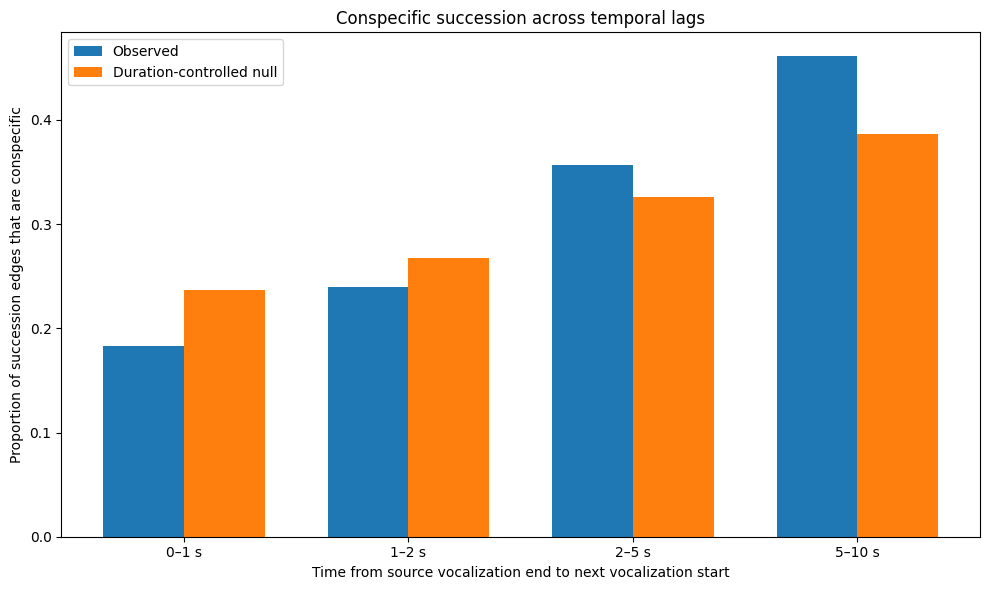

In [ ]:
# ============================================================
# Step 113: Conspecific vs heterospecific succession by lag
# ============================================================

# IMPORTANT:
# Step 112 created the null distributions in:
#     null_duration_counts
#
# This cell uses that exact variable name.

# ------------------------------------------------------------
# 0. Confirm the Step 112 object exists
# ------------------------------------------------------------

assert "null_duration_counts" in globals(), (
    "null_duration_counts is not loaded. "
    "Please rerun Step 112 before Step 113."
)

# ------------------------------------------------------------
# 1. Total succession edges in each lag bin
# ------------------------------------------------------------

lag_labels = [
    "0–1 s",
    "1–2 s",
    "2–5 s",
    "5–10 s"
]

total_lag_counts = {}

for label in lag_labels:
    total_lag_counts[label] = int(
        lag_masks[label].sum()
    )

# ------------------------------------------------------------
# 2. Observed heterospecific counts
# ------------------------------------------------------------

observed_heterospecific = (
    succession_edges[
        succession_edges["species_relationship"]
        .eq("heterospecific")
    ]
    .copy()
)

observed_hetero_counts = (
    observed_heterospecific["lag_bin"]
    .value_counts()
    .reindex(
        lag_labels,
        fill_value=0
    )
)

# ------------------------------------------------------------
# 3. Null heterospecific counts
#
# Every permutation has exactly the same temporal edges.
# Therefore:
#
# heterospecific = total edges - conspecific edges
# ------------------------------------------------------------

null_hetero_counts = {}

for label in lag_labels:

    null_hetero_counts[label] = (
        total_lag_counts[label]
        - null_duration_counts[label]
    )

# ------------------------------------------------------------
# 4. Summarize heterospecific null distributions
# ------------------------------------------------------------

hetero_results = []

for label in lag_labels:

    observed = int(
        observed_hetero_counts[label]
    )

    null_values = np.asarray(
        null_hetero_counts[label]
    )

    null_mean = np.mean(null_values)

    null_sd = np.std(
        null_values,
        ddof=1
    )

    null_low = np.percentile(
        null_values,
        2.5
    )

    null_high = np.percentile(
        null_values,
        97.5
    )

    z_score = (
        (observed - null_mean)
        / null_sd
        if null_sd > 0
        else np.nan
    )

    p_lower = (
        1
        + np.sum(null_values <= observed)
    ) / (
        len(null_values) + 1
    )

    p_upper = (
        1
        + np.sum(null_values >= observed)
    ) / (
        len(null_values) + 1
    )

    p_two_sided = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    hetero_results.append({
        "lag_bin": label,
        "observed": observed,
        "null_mean": null_mean,
        "null_sd": null_sd,
        "null_2.5%": null_low,
        "null_97.5%": null_high,
        "difference": observed - null_mean,
        "z_score": z_score,
        "p_two_sided": p_two_sided
    })

hetero_results = pd.DataFrame(
    hetero_results
)

print("HETEROSPECIFIC SUCCESSION: OBSERVED VS NULL")
print("=" * 90)

display(hetero_results)

# ------------------------------------------------------------
# 5. Build combined observed table
# ------------------------------------------------------------

conspecific_observed = (
    succession_edges[
        succession_edges["species_relationship"]
        .eq("conspecific")
    ]["lag_bin"]
    .value_counts()
    .reindex(
        lag_labels,
        fill_value=0
    )
)

combined = pd.DataFrame({
    "lag_bin": lag_labels,
    "conspecific_observed":
        conspecific_observed.values,
    "heterospecific_observed":
        observed_hetero_counts.values
})

# ------------------------------------------------------------
# 6. Calculate observed proportions within each lag
# ------------------------------------------------------------

combined["total_observed"] = (
    combined["conspecific_observed"]
    +
    combined["heterospecific_observed"]
)

combined["conspecific_proportion"] = (
    combined["conspecific_observed"]
    /
    combined["total_observed"]
)

combined["heterospecific_proportion"] = (
    combined["heterospecific_observed"]
    /
    combined["total_observed"]
)

# ------------------------------------------------------------
# 7. Add duration-controlled null proportions
# ------------------------------------------------------------

combined["conspecific_null_mean"] = [
    np.mean(
        null_duration_counts[label]
    )
    for label in lag_labels
]

combined["heterospecific_null_mean"] = [
    np.mean(
        null_hetero_counts[label]
    )
    for label in lag_labels
]

combined["conspecific_null_proportion"] = (
    combined["conspecific_null_mean"]
    /
    (
        combined["conspecific_null_mean"]
        +
        combined["heterospecific_null_mean"]
    )
)

combined["heterospecific_null_proportion"] = (
    combined["heterospecific_null_mean"]
    /
    (
        combined["conspecific_null_mean"]
        +
        combined["heterospecific_null_mean"]
    )
)

# ------------------------------------------------------------
# 8. Display combined results
# ------------------------------------------------------------

print("\nCOMBINED LAG COMPARISON")
print("=" * 100)

display(combined)

# ------------------------------------------------------------
# 9. Plot observed vs null conspecific proportion
# ------------------------------------------------------------

import matplotlib.pyplot as plt

x = np.arange(
    len(combined)
)

width = 0.36

fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.bar(
    x - width / 2,
    combined["conspecific_proportion"],
    width,
    label="Observed"
)

ax.bar(
    x + width / 2,
    combined["conspecific_null_proportion"],
    width,
    label="Duration-controlled null"
)

ax.set_xticks(x)
ax.set_xticklabels(
    combined["lag_bin"]
)

ax.set_xlabel(
    "Time from source vocalization end to next vocalization start"
)

ax.set_ylabel(
    "Proportion of succession edges that are conspecific"
)

ax.set_title(
    "Conspecific succession across temporal lags"
)

ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Step 114: Quantify observed vs null effect sizes
# ============================================================

effect_table = lag_results.copy()

# Relative deviation from null expectation
effect_table["relative_difference"] = (
    effect_table["difference"]
    / effect_table["null_mean"]
)

# Percent deviation from null expectation
effect_table["percent_difference"] = (
    100
    * effect_table["relative_difference"]
)

# Observed / null ratio
effect_table["observed_to_null_ratio"] = (
    effect_table["observed"]
    / effect_table["null_mean"]
)

# Add duration-controlled results
effect_table["duration_controlled_z"] = (
    duration_null_results["z_score"].values
)

effect_table["duration_controlled_p"] = (
    duration_null_results["p_two_sided"].values
)

print("CONSPECFIC SUCCESSION EFFECT SIZES")
print("=" * 100)

display(
    effect_table[
        [
            "lag_bin",
            "observed",
            "null_mean",
            "difference",
            "percent_difference",
            "observed_to_null_ratio",
            "z_score",
            "duration_controlled_z",
            "duration_controlled_p"
        ]
    ]
)

CONSPECFIC SUCCESSION EFFECT SIZES


,lag_bin,observed,null_mean,difference,percent_difference,observed_to_null_ratio,z_score,duration_controlled_z,duration_controlled_p
0,0–1 s,10412,14246.281,-3834.281,-26.914259,0.730857,-38.890543,-38.711037,0.001998
1,1–2 s,9077,10131.617,-1054.617,-10.409168,0.895908,-12.970000,-15.598091,0.001998
2,2–5 s,19056,15964.328,3091.672,19.366127,1.193661,30.303795,20.616705,0.001998
3,5–10 s,10360,7540.603,2819.397,37.389543,1.373895,43.452617,30.052232,0.001998



## Question 1: Are bird vocalizations random in time, or do they show temporal organization?

We tested whether bird vocalizations occurred independently of one another by comparing the observed network with a null model that shuffled species identities within each recording while preserving the observed timing and duration of vocalizations. Among **182,516 confirmed bird vocalizations and 250,261 bird-to-bird temporal relationships**, same-species vocalizations overlapped far less often than expected by chance, while same-species succession showed a clear time-dependent pattern. Conspecific succession was lower than expected during the first 2 s after a vocalization, but higher than expected from 2–10 s. The same pattern remained after controlling for vocalization duration, indicating that bird vocalizations were **not temporally random**.

### Results

| Temporal relationship | Observed | Null expectation | Result |
|---|---:|---:|---|
| **Same-species overlap** | 3,581 | 18,687 | **Strongly lower than expected** |
| **Same-species succession, 0–1 s** | 10,412 | 13,442 | **26.9% lower** |
| **Same-species succession, 1–2 s** | 9,077 | 10,123 | **10.4% lower** |
| **Same-species succession, 2–5 s** | 19,056 | 17,399 | **19.4% higher** |
| **Same-species succession, 5–10 s** | 10,360 | 8,685 | **37.4% higher** |

All lag-specific effects remained significant in the duration-controlled null analysis (permutation **p = 0.002** for each lag class).

### What the terms mean

| Term | Simple meaning |
|---|---|
| **Conspecific** | Two vocalizations from the **same species** |
| **Heterospecific** | Two vocalizations from **different species** |
| **Overlap** | Two vocalizations occur at the same time |
| **Succession** | One vocalization occurs, then another begins after it ends |
| **Null model** | A randomized version used to represent **what we would expect by chance** |
| **Observed > null** | More relationships occurred than expected by chance |
| **Observed < null** | Fewer relationships occurred than expected by chance |

### Main finding

**Bird vocalizations are not randomly arranged in time.** Same-species overlap is strongly reduced, and same-species succession shifts from being below expectation at **0–2 s** to above expectation at **2–10 s**. This indicates **nonrandom temporal organization**, although it does not by itself prove that one individual bird is behaviorally responding to another.

In [ ]:
# ============================================================
# Step 115: Observed directed species-following relationships
# ============================================================

# We are defining "follow" as:
# source vocalization ends -> target vocalization begins
# within 10 seconds, using the succession edges already built.

# ------------------------------------------------------------
# 1. Keep heterospecific succession only
# ------------------------------------------------------------

hetero_succession = (
    succession_edges[
        succession_edges["species_relationship"]
        .eq("heterospecific")
    ]
    .copy()
)

# ------------------------------------------------------------
# 2. Count each directed species pair
# ------------------------------------------------------------

pair_counts = (
    hetero_succession
    .groupby(
        [
            "source_species",
            "target_species"
        ]
    )
    .size()
    .rename("observed_edges")
    .reset_index()
)

# ------------------------------------------------------------
# 3. Add species names
# ------------------------------------------------------------

species_lookup = (
    bird_events[
        [
            "species_code",
            "common_name",
            "scientific_name"
        ]
    ]
    .drop_duplicates("species_code")
)

pair_counts = (
    pair_counts
    .merge(
        species_lookup.rename(
            columns={
                "species_code": "source_species",
                "common_name": "source_common_name",
                "scientific_name":
                    "source_scientific_name"
            }
        ),
        on="source_species",
        how="left"
    )
    .merge(
        species_lookup.rename(
            columns={
                "species_code": "target_species",
                "common_name": "target_common_name",
                "scientific_name":
                    "target_scientific_name"
            }
        ),
        on="target_species",
        how="left"
    )
)

# ------------------------------------------------------------
# 4. Basic pair statistics
# ------------------------------------------------------------

pair_counts["percent_of_heterospecific_succession"] = (
    100
    * pair_counts["observed_edges"]
    / len(hetero_succession)
)

pair_counts = (
    pair_counts
    .sort_values(
        "observed_edges",
        ascending=False
    )
    .reset_index(drop=True)
)

print("DIRECTED HETEROSPECIFIC SUCCESSION")
print("=" * 90)

print(
    f"Heterospecific succession edges: "
    f"{len(hetero_succession):,}"
)

print(
    f"Unique directed species pairs: "
    f"{len(pair_counts):,}"
)

print("\nTop 30 observed source → target pairs:")

display(
    pair_counts[
        [
            "source_species",
            "source_common_name",
            "target_species",
            "target_common_name",
            "observed_edges",
            "percent_of_heterospecific_succession"
        ]
    ].head(30)
)

DIRECTED HETEROSPECIFIC SUCCESSION
Heterospecific succession edges: 121,625
Unique directed species pairs: 2,602

Top 30 observed source → target pairs:


,source_species,source_common_name,target_species,target_common_name,observed_edges,percent_of_heterospecific_succession
0,BTNW,Black-throated Green Warbler,OVEN,Ovenbird,2675,2.199383
1,OVEN,Ovenbird,BTNW,Black-throated Green Warbler,2616,2.150874
2,OVEN,Ovenbird,HETH,Hermit Thrush,2150,1.767729
3,OVEN,Ovenbird,EAWP,Eastern Wood pewee,2033,1.671531
4,HETH,Hermit Thrush,OVEN,Ovenbird,1892,1.555601
5,EAWP,Eastern Wood pewee,OVEN,Ovenbird,1643,1.350874
6,OVEN,Ovenbird,WOTH,Wood Thrush,1603,1.317986
7,BTNW,Black-throated Green Warbler,HETH,Hermit Thrush,1578,1.297431
8,WOTH,Wood Thrush,OVEN,Ovenbird,1482,1.218499
9,BTBW,Black-throated Blue Warbler,OVEN,Ovenbird,1407,1.156835


In [ ]:
# ============================================================
# Step 116: Corrected pairwise null model for #2
# ============================================================

N_NULL_PAIRS = 1000
PAIR_NULL_SEED = 116

rng = np.random.default_rng(PAIR_NULL_SEED)

# ------------------------------------------------------------
# 1. Explicitly isolate HETEROSPECIFIC succession
# ------------------------------------------------------------

hetero_succession = (
    succession_edges[
        succession_edges["source_species"]
        != succession_edges["target_species"]
    ]
    .copy()
    .reset_index(drop=True)
)

print("PAIRWISE NULL MODEL SETUP")
print("=" * 80)

print(
    f"Total succession edges: "
    f"{len(succession_edges):,}"
)

print(
    f"Heterospecific succession edges: "
    f"{len(hetero_succession):,}"
)

# ------------------------------------------------------------
# 2. Species list
# ------------------------------------------------------------

species_list = (
    bird_events["species_code"]
    .drop_duplicates()
    .sort_values()
    .tolist()
)

n_species = len(species_list)

species_to_code = {
    species: i
    for i, species in enumerate(species_list)
}

# ------------------------------------------------------------
# 3. Species codes on all bird events
# ------------------------------------------------------------

event_species_codes = (
    bird_events["species_code"]
    .map(species_to_code)
    .to_numpy()
    .astype(np.int16)
)

# ------------------------------------------------------------
# 4. Encode ONLY heterospecific observed pairs
# ------------------------------------------------------------

source_codes = (
    hetero_succession["source_species"]
    .map(species_to_code)
    .to_numpy()
    .astype(np.int16)
)

target_codes = (
    hetero_succession["target_species"]
    .map(species_to_code)
    .to_numpy()
    .astype(np.int16)
)

observed_pair_keys_all = (
    source_codes.astype(np.int32) * n_species
    + target_codes.astype(np.int32)
)

unique_pair_keys, observed_pair_counts = np.unique(
    observed_pair_keys_all,
    return_counts=True
)

# ------------------------------------------------------------
# 5. Decode pair keys
# ------------------------------------------------------------

pair_source_codes = (
    unique_pair_keys // n_species
)

pair_target_codes = (
    unique_pair_keys % n_species
)

pair_table = pd.DataFrame({
    "source_species": [
        species_list[i]
        for i in pair_source_codes
    ],
    "target_species": [
        species_list[i]
        for i in pair_target_codes
    ],
    "observed_edges": observed_pair_counts
})

# Explicit sanity check
assert (
    pair_table["source_species"]
    !=
    pair_table["target_species"]
).all()

print(
    f"Unique heterospecific directed pairs: "
    f"{len(pair_table):,}"
)

# ------------------------------------------------------------
# 6. Event positions
# ------------------------------------------------------------

event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id_key"]
)

source_positions = (
    hetero_succession["source_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

target_positions = (
    hetero_succession["target_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

# ------------------------------------------------------------
# 7. Duration-controlled shuffle strata
# ------------------------------------------------------------

assert "duration_bin" in bird_events.columns, (
    "duration_bin is missing. Please rerun Step 112."
)

pair_shuffle_strata = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        ["itemID", "duration_bin"],
        sort=False
    )
]

# ------------------------------------------------------------
# 8. Run corrected null permutations
# ------------------------------------------------------------

n_pairs = len(unique_pair_keys)

null_pair_counts = np.zeros(
    (N_NULL_PAIRS, n_pairs),
    dtype=np.int16
)

for r in range(N_NULL_PAIRS):

    shuffled_species = (
        event_species_codes.copy()
    )

    # Shuffle species within recording × duration class
    for idx in pair_shuffle_strata:

        if len(idx) > 1:

            shuffled_species[idx] = (
                shuffled_species[
                    idx[
                        rng.permutation(len(idx))
                    ]
                ]
            )

    # Randomized pair identities
    null_pair_keys = (
        shuffled_species[source_positions]
        .astype(np.int32)
        * n_species
        +
        shuffled_species[target_positions]
        .astype(np.int32)
    )

    counts = np.bincount(
        null_pair_keys,
        minlength=n_species * n_species
    )

    null_pair_counts[r, :] = (
        counts[unique_pair_keys]
    )

    if (r + 1) % 100 == 0:
        print(
            f"Completed {r + 1:,} / "
            f"{N_NULL_PAIRS:,}"
        )

# ------------------------------------------------------------
# 9. Null statistics
# ------------------------------------------------------------

pair_table["null_mean"] = (
    null_pair_counts.mean(axis=0)
)

pair_table["null_sd"] = (
    null_pair_counts.std(
        axis=0,
        ddof=1
    )
)

pair_table["difference"] = (
    pair_table["observed_edges"]
    -
    pair_table["null_mean"]
)

pair_table["fold_enrichment"] = (
    pair_table["observed_edges"]
    /
    pair_table["null_mean"].replace(
        0,
        np.nan
    )
)

pair_table["percent_difference"] = (
    100
    * pair_table["difference"]
    /
    pair_table["null_mean"].replace(
        0,
        np.nan
    )
)

pair_table["z_score"] = (
    pair_table["difference"]
    /
    pair_table["null_sd"].replace(
        0,
        np.nan
    )
)

# ------------------------------------------------------------
# 10. Empirical enrichment p-value
# ------------------------------------------------------------

pair_table["p_enrichment"] = (
    1
    +
    (
        null_pair_counts
        >=
        pair_table["observed_edges"]
        .to_numpy()[None, :]
    ).sum(axis=0)
) / (
    N_NULL_PAIRS + 1
)

# ------------------------------------------------------------
# 11. Benjamini-Hochberg correction
# ------------------------------------------------------------

def benjamini_hochberg(p_values):

    p_values = np.asarray(
        p_values,
        dtype=float
    )

    m = len(p_values)

    order = np.argsort(p_values)

    ranked_p = p_values[order]

    adjusted = (
        ranked_p
        * m
        / np.arange(1, m + 1)
    )

    adjusted = np.minimum.accumulate(
        adjusted[::-1]
    )[::-1]

    adjusted = np.minimum(
        adjusted,
        1.0
    )

    result = np.empty_like(
        adjusted
    )

    result[order] = adjusted

    return result


pair_table["q_value"] = (
    benjamini_hochberg(
        pair_table["p_enrichment"]
    )
)

# ------------------------------------------------------------
# 12. Species names
# ------------------------------------------------------------

species_metadata = (
    bird_events[
        [
            "species_code",
            "common_name",
            "scientific_name"
        ]
    ]
    .drop_duplicates("species_code")
)

pair_table = (
    pair_table
    .merge(
        species_metadata.rename(
            columns={
                "species_code":
                    "source_species",
                "common_name":
                    "source_common_name",
                "scientific_name":
                    "source_scientific_name"
            }
        ),
        on="source_species",
        how="left"
    )
    .merge(
        species_metadata.rename(
            columns={
                "species_code":
                    "target_species",
                "common_name":
                    "target_common_name",
                "scientific_name":
                    "target_scientific_name"
            }
        ),
        on="target_species",
        how="left"
    )
)

# ------------------------------------------------------------
# 13. Significant enriched pairs
# ------------------------------------------------------------

significant_pairs = (
    pair_table[
        pair_table["q_value"] < 0.05
    ]
    .sort_values(
        [
            "q_value",
            "fold_enrichment"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 14. Final output
# ------------------------------------------------------------

print("\n")
print(
    "HETEROSPECIFIC SPECIES PAIRS "
    "ENRICHED ABOVE NULL"
)
print("=" * 100)

print(
    f"Pairs tested: "
    f"{len(pair_table):,}"
)

print(
    f"FDR-significant pairs (q < 0.05): "
    f"{len(significant_pairs):,}"
)

print("\nTop 30 enriched directed species pairs:")

display(
    significant_pairs[
        [
            "source_species",
            "source_common_name",
            "target_species",
            "target_common_name",
            "observed_edges",
            "null_mean",
            "difference",
            "fold_enrichment",
            "percent_difference",
            "z_score",
            "p_enrichment",
            "q_value"
        ]
    ].head(30)
)

PAIRWISE NULL MODEL SETUP
Total succession edges: 170,530
Heterospecific succession edges: 121,625
Unique heterospecific directed pairs: 2,602
Completed 100 / 1,000
Completed 200 / 1,000
Completed 300 / 1,000
Completed 400 / 1,000
Completed 500 / 1,000
Completed 600 / 1,000
Completed 700 / 1,000
Completed 800 / 1,000
Completed 900 / 1,000
Completed 1,000 / 1,000


HETEROSPECIFIC SPECIES PAIRS ENRICHED ABOVE NULL
Pairs tested: 2,602
FDR-significant pairs (q < 0.05): 340

Top 30 enriched directed species pairs:


,source_species,source_common_name,target_species,target_common_name,observed_edges,null_mean,difference,fold_enrichment,percent_difference,z_score,p_enrichment,q_value
0,CORA,Common Raven,WBNU,White-breasted Nuthatch,2,0.029,1.971,68.965517,6796.551724,11.739802,0.000999,0.010786
1,BHVI,Blue-headed Vireo,CHSP,Chipping Sparrow,3,0.221,2.779,13.574661,1257.466063,6.087987,0.000999,0.010786
2,WBNU,White-breasted Nuthatch,NOPA,Northern Parula,3,0.260,2.740,11.538462,1053.846154,5.705478,0.000999,0.010786
3,YBFL,Yellow-bellied Flycatcher,AMRE,American Redstart,4,0.503,3.497,7.952286,695.228628,5.568462,0.000999,0.010786
4,WOTH,Wood Thrush,EAPH,Eastern Phoebe,10,1.848,8.152,5.411255,441.125541,7.084090,0.000999,0.010786
5,HAWO,Hairy Woodpecker,INBU,Indigo Bunting,5,0.926,4.074,5.399568,439.956803,4.539774,0.000999,0.010786
6,CARW,Carolina Wren,RBNU,Red-breasted Nuthatch,6,1.196,4.804,5.016722,401.672241,4.727521,0.000999,0.010786
7,BTBW,Black-throated Blue Warbler,LOWA,Louisiana Waterthrush,9,2.729,6.271,3.297911,229.791132,4.220464,0.000999,0.010786
8,BHVI,Blue-headed Vireo,RBGR,Rose-breasted Grosbeak,13,4.064,8.936,3.198819,219.881890,5.194942,0.000999,0.010786
9,AMRE,American Redstart,HETH,Hermit Thrush,12,4.104,7.896,2.923977,192.397661,5.314562,0.000999,0.010786


In [ ]:
# ============================================================
# Step 117: Identify robust species-following relationships
# ============================================================

MIN_OBSERVED_PAIRS = 20

robust_pairs = (
    pair_table[
        (pair_table["observed_edges"] >= MIN_OBSERVED_PAIRS)
        &
        (pair_table["q_value"] < 0.05)
    ]
    .copy()
    .sort_values(
        [
            "fold_enrichment",
            "observed_edges"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

print("ROBUST SPECIES-FOLLOWING RELATIONSHIPS")
print("=" * 100)

print(
    f"Minimum observed edges per pair: "
    f"{MIN_OBSERVED_PAIRS}"
)

print(
    f"All tested pairs: "
    f"{len(pair_table):,}"
)

print(
    f"FDR-significant pairs: "
    f"{(pair_table['q_value'] < 0.05).sum():,}"
)

print(
    f"Robust significant pairs: "
    f"{len(robust_pairs):,}"
)

print("\nTop robust enriched pairs:")

display(
    robust_pairs[
        [
            "source_species",
            "source_common_name",
            "target_species",
            "target_common_name",
            "observed_edges",
            "null_mean",
            "difference",
            "fold_enrichment",
            "percent_difference",
            "z_score",
            "q_value"
        ]
    ].head(30)
)

ROBUST SPECIES-FOLLOWING RELATIONSHIPS
Minimum observed edges per pair: 20
All tested pairs: 2,602
FDR-significant pairs: 340
Robust significant pairs: 300

Top robust enriched pairs:


,source_species,source_common_name,target_species,target_common_name,observed_edges,null_mean,difference,fold_enrichment,percent_difference,z_score,q_value
0,BCCH,Black-capped Chickadee,LOWA,Louisiana Waterthrush,23,9.461,13.539,2.431033,143.103266,4.926684,0.010786
1,BLBW,Blackburnian Warbler,NAWA,Nashville Warbler,22,10.577,11.423,2.079985,107.998487,3.905527,0.010786
2,BRCR,Brown Creeper,DEJU,Dark-eyed Junco,50,24.471,25.529,2.043235,104.323485,6.182569,0.010786
3,OVEN,Ovenbird,TEWA,Tennessee Warbler,26,12.898,13.102,2.015816,101.581641,3.826267,0.018567
4,YRWA,Yellow-rumped Warbler,SWTH,Swainson's Thrush,21,10.557,10.443,1.989201,98.920148,4.311530,0.010786
5,COYE,Common Yellowthroat,BLBW,Blackburnian Warbler,26,13.180,12.820,1.972686,97.268589,4.401346,0.010786
6,BHVI,Blue-headed Vireo,REVI,Red-eyed Vireo,44,22.749,21.251,1.934151,93.415095,5.044380,0.010786
7,PUFI,Purple Finch,DEJU,Dark-eyed Junco,26,13.553,12.447,1.918394,91.839445,4.480671,0.010786
8,EAWP,Eastern Wood pewee,RWBL,Red-winged Blackbird,41,21.654,19.346,1.893415,89.341461,4.954729,0.010786
9,BLBW,Blackburnian Warbler,COYE,Common Yellowthroat,23,12.521,10.479,1.836914,83.691398,3.548988,0.010786


In [ ]:
# ============================================================
# Step 118: Directionality of species-following relationships
# ============================================================

# ------------------------------------------------------------
# 1. Build lookup from pair key -> null array column
# ------------------------------------------------------------

pair_key_to_index = {
    int(key): i
    for i, key in enumerate(unique_pair_keys)
}

# ------------------------------------------------------------
# 2. Add pair keys to pair_table
# ------------------------------------------------------------

pair_table["pair_key"] = (
    pair_table["source_species"]
    .map(species_to_code)
    .astype(np.int32)
    * n_species
    +
    pair_table["target_species"]
    .map(species_to_code)
    .astype(np.int32)
)

# ------------------------------------------------------------
# 3. Identify reciprocal pairs
#
# We only test species pairs where BOTH directions were
# actually observed at least once.
# ------------------------------------------------------------

pair_index_lookup = (
    pair_table
    .set_index("pair_key")
)

reciprocal_rows = []

for _, row in pair_table.iterrows():

    source = row["source_species"]
    target = row["target_species"]

    source_code = species_to_code[source]
    target_code = species_to_code[target]

    reverse_key = (
        target_code * n_species
        + source_code
    )

    # Keep each reciprocal pair only once
    if (
        reverse_key in pair_key_to_index
        and int(row["pair_key"]) < reverse_key
    ):

        reverse_row = (
            pair_index_lookup.loc[reverse_key]
        )

        reciprocal_rows.append({
            "source_species": source,
            "source_common_name":
                row["source_common_name"],
            "target_species": target,
            "target_common_name":
                row["target_common_name"],

            "observed_source_to_target":
                row["observed_edges"],

            "observed_target_to_source":
                reverse_row["observed_edges"],

            "source_pair_key":
                int(row["pair_key"]),

            "target_pair_key":
                int(reverse_key)
        })

reciprocal_pairs = pd.DataFrame(
    reciprocal_rows
)

print("RECIPROCAL SPECIES PAIRS")
print("=" * 90)

print(
    f"Observed heterospecific pairs: "
    f"{len(pair_table):,}"
)

print(
    f"Pairs with both directions observed: "
    f"{len(reciprocal_pairs):,}"
)

# ------------------------------------------------------------
# 4. Require at least 20 observed events in BOTH directions
# ------------------------------------------------------------

MIN_DIRECTION_COUNT = 20

reciprocal_pairs = (
    reciprocal_pairs[
        (
            reciprocal_pairs[
                "observed_source_to_target"
            ]
            >= MIN_DIRECTION_COUNT
        )
        &
        (
            reciprocal_pairs[
                "observed_target_to_source"
            ]
            >= MIN_DIRECTION_COUNT
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    f"Reciprocal pairs with >= "
    f"{MIN_DIRECTION_COUNT} events in both directions: "
    f"{len(reciprocal_pairs):,}"
)

# ------------------------------------------------------------
# 5. Test directional asymmetry against the null
#
# Statistic:
#
#     A -> B count - B -> A count
#
# Positive = more A -> B
# Negative = more B -> A
# ------------------------------------------------------------

directional_results = []

for _, row in reciprocal_pairs.iterrows():

    key_ab = int(
        row["source_pair_key"]
    )

    key_ba = int(
        row["target_pair_key"]
    )

    idx_ab = pair_key_to_index[key_ab]
    idx_ba = pair_key_to_index[key_ba]

    # Observed directional difference
    observed_difference = (
        row["observed_source_to_target"]
        -
        row["observed_target_to_source"]
    )

    # Null directional differences
    null_difference = (
        null_pair_counts[:, idx_ab]
        -
        null_pair_counts[:, idx_ba]
    )

    null_mean = np.mean(
        null_difference
    )

    null_sd = np.std(
        null_difference,
        ddof=1
    )

    z_score = (
        (observed_difference - null_mean)
        / null_sd
        if null_sd > 0
        else np.nan
    )

    # Empirical two-sided p-value
    p_lower = (
        1
        +
        np.sum(
            null_difference
            <=
            observed_difference
        )
    ) / (
        N_NULL_PAIRS + 1
    )

    p_upper = (
        1
        +
        np.sum(
            null_difference
            >=
            observed_difference
        )
    ) / (
        N_NULL_PAIRS + 1
    )

    p_two_sided = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    # Which direction dominates?
    if (
        row["observed_source_to_target"]
        >
        row["observed_target_to_source"]
    ):
        dominant_direction = (
            f"{row['source_species']} → "
            f"{row['target_species']}"
        )

        dominant_count = (
            row["observed_source_to_target"]
        )

        reverse_count = (
            row["observed_target_to_source"]
        )

    else:
        dominant_direction = (
            f"{row['target_species']} → "
            f"{row['source_species']}"
        )

        dominant_count = (
            row["observed_target_to_source"]
        )

        reverse_count = (
            row["observed_source_to_target"]
        )

    directional_ratio = (
        dominant_count
        /
        reverse_count
    )

    directional_results.append({
        "source_species":
            row["source_species"],

        "source_common_name":
            row["source_common_name"],

        "target_species":
            row["target_species"],

        "target_common_name":
            row["target_common_name"],

        "source_to_target":
            row["observed_source_to_target"],

        "target_to_source":
            row["observed_target_to_source"],

        "observed_difference":
            observed_difference,

        "null_mean_difference":
            null_mean,

        "null_sd":
            null_sd,

        "z_score":
            z_score,

        "directional_ratio":
            directional_ratio,

        "dominant_direction":
            dominant_direction,

        "p_value":
            p_two_sided
    })

directional_results = pd.DataFrame(
    directional_results
)

# ------------------------------------------------------------
# 6. FDR correction
# ------------------------------------------------------------

directional_results["q_value"] = (
    benjamini_hochberg(
        directional_results["p_value"]
    )
)

# ------------------------------------------------------------
# 7. Keep statistically directional relationships
# ------------------------------------------------------------

directional_pairs = (
    directional_results[
        directional_results["q_value"] < 0.05
    ]
    .sort_values(
        [
            "directional_ratio",
            "z_score"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

print("\n")
print(
    "DIRECTIONALLY ENRICHED SPECIES RELATIONSHIPS"
)
print("=" * 100)

print(
    f"Reciprocal pairs tested: "
    f"{len(directional_results):,}"
)

print(
    f"FDR-significant directional pairs: "
    f"{len(directional_pairs):,}"
)

# ------------------------------------------------------------
# 8. Display strongest directional relationships
# ------------------------------------------------------------

display(
    directional_pairs[
        [
            "source_species",
            "source_common_name",
            "target_species",
            "target_common_name",
            "source_to_target",
            "target_to_source",
            "observed_difference",
            "directional_ratio",
            "dominant_direction",
            "z_score",
            "q_value"
        ]
    ].head(30)
)

RECIPROCAL SPECIES PAIRS
Observed heterospecific pairs: 2,602
Pairs with both directions observed: 1,166
Reciprocal pairs with >= 20 events in both directions: 391


DIRECTIONALLY ENRICHED SPECIES RELATIONSHIPS
Reciprocal pairs tested: 391
FDR-significant directional pairs: 19


,source_species,source_common_name,target_species,target_common_name,source_to_target,target_to_source,observed_difference,directional_ratio,dominant_direction,z_score,q_value
0,CSWA,Chestnut-sided Warbler,REVI,Red-eyed Vireo,172,74,98,2.324324,CSWA → REVI,4.138791,0.041117
1,BTBW,Black-throated Blue Warbler,REVI,Red-eyed Vireo,270,120,150,2.250000,BTBW → REVI,3.627895,0.041117
2,BTNW,Black-throated Green Warbler,REVI,Red-eyed Vireo,582,312,270,1.865385,BTNW → REVI,3.620931,0.041117
3,OVEN,Ovenbird,REVI,Red-eyed Vireo,1239,690,549,1.795652,OVEN → REVI,6.751158,0.041117
4,REVI,Red-eyed Vireo,WOTH,Wood Thrush,107,188,-81,1.757009,WOTH → REVI,-4.140411,0.041117
5,BAWW,Black-and-white Warbler,HETH,Hermit Thrush,144,82,62,1.756098,BAWW → HETH,4.844773,0.041117
6,BRCR,Brown Creeper,EAWP,Eastern Wood pewee,113,70,43,1.614286,BRCR → EAWP,4.180254,0.041117
7,EAWP,Eastern Wood pewee,RBGR,Rose-breasted Grosbeak,83,131,-48,1.578313,RBGR → EAWP,-3.900998,0.041117
8,BRCR,Brown Creeper,DEJU,Dark-eyed Junco,50,32,18,1.562500,BRCR → DEJU,3.195488,0.041117
9,HETH,Hermit Thrush,REVI,Red-eyed Vireo,490,348,142,1.408046,HETH → REVI,3.586185,0.041117


In [ ]:
# ============================================================
# Step 119: Species-level leaders and followers
# ============================================================

# ------------------------------------------------------------
# 1. Use the 19 directionally significant relationships
# ------------------------------------------------------------

sig_directional = (
    directional_pairs[
        directional_pairs["q_value"] < 0.05
    ]
    .copy()
)

print("DIRECTIONALLY SIGNIFICANT SPECIES NETWORK")
print("=" * 90)

print(
    f"Directionally significant pairs: "
    f"{len(sig_directional):,}"
)

# ------------------------------------------------------------
# 2. Count outgoing relationships
#
# A species is a "leader" here when it is the source of
# a directionally enriched A → B relationship.
# ------------------------------------------------------------

leaders = (
    sig_directional
    .groupby(
        [
            "source_species",
            "source_common_name"
        ]
    )
    .agg(
        n_outgoing_relationships=(
            "target_species",
            "nunique"
        ),
        total_outgoing_events=(
            "source_to_target",
            "sum"
        )
    )
    .reset_index()
    .rename(
        columns={
            "source_species": "species",
            "source_common_name": "common_name"
        }
    )
    .sort_values(
        [
            "n_outgoing_relationships",
            "total_outgoing_events"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Count incoming relationships
#
# A species is a "follower" here when it is the target of
# a directionally enriched A → B relationship.
# ------------------------------------------------------------

followers = (
    sig_directional
    .groupby(
        [
            "target_species",
            "target_common_name"
        ]
    )
    .agg(
        n_incoming_relationships=(
            "source_species",
            "nunique"
        ),
        total_incoming_events=(
            "source_to_target",
            "sum"
        )
    )
    .reset_index()
    .rename(
        columns={
            "target_species": "species",
            "target_common_name": "common_name"
        }
    )
    .sort_values(
        [
            "n_incoming_relationships",
            "total_incoming_events"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Display leaders
# ------------------------------------------------------------

print("\nTOP SPECIES AS TEMPORAL LEADERS")
print("=" * 90)

display(
    leaders.head(20)
)

# ------------------------------------------------------------
# 5. Display followers
# ------------------------------------------------------------

print("\nTOP SPECIES AS TEMPORAL FOLLOWERS")
print("=" * 90)

display(
    followers.head(20)
)

# ------------------------------------------------------------
# 6. Create a combined species summary
# ------------------------------------------------------------

species_summary = (
    pd.merge(
        leaders,
        followers,
        on=["species", "common_name"],
        how="outer"
    )
    .fillna(0)
)

species_summary[
    [
        "n_outgoing_relationships",
        "total_outgoing_events",
        "n_incoming_relationships",
        "total_incoming_events"
    ]
] = (
    species_summary[
        [
            "n_outgoing_relationships",
            "total_outgoing_events",
            "n_incoming_relationships",
            "total_incoming_events"
        ]
    ]
    .astype(int)
)

# ------------------------------------------------------------
# 7. Calculate a simple directional balance
#
# Positive = more significant outgoing relationships
# Negative = more significant incoming relationships
# ------------------------------------------------------------

species_summary["directional_balance"] = (
    species_summary["n_outgoing_relationships"]
    -
    species_summary["n_incoming_relationships"]
)

species_summary = (
    species_summary
    .sort_values(
        [
            "directional_balance",
            "n_outgoing_relationships"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nCOMBINED LEADER / FOLLOWER SUMMARY")
print("=" * 90)

display(
    species_summary[
        [
            "species",
            "common_name",
            "n_outgoing_relationships",
            "total_outgoing_events",
            "n_incoming_relationships",
            "total_incoming_events",
            "directional_balance"
        ]
    ]
)

DIRECTIONALLY SIGNIFICANT SPECIES NETWORK
Directionally significant pairs: 19

TOP SPECIES AS TEMPORAL LEADERS


,species,common_name,n_outgoing_relationships,total_outgoing_events
0,BTNW,Black-throated Green Warbler,4,3233
1,HETH,Hermit Thrush,2,2382
2,EAWP,Eastern Wood pewee,2,1726
3,OVEN,Ovenbird,2,1415
4,BAWW,Black-and-white Warbler,2,835
5,BRCR,Brown Creeper,2,163
6,DEJU,Dark-eyed Junco,1,290
7,BTBW,Black-throated Blue Warbler,1,270
8,BLBW,Blackburnian Warbler,1,179
9,CSWA,Chestnut-sided Warbler,1,172



TOP SPECIES AS TEMPORAL FOLLOWERS


,species,common_name,n_incoming_relationships,total_incoming_events
0,REVI,Red-eyed Vireo,5,2753
1,OVEN,Ovenbird,4,4516
2,HETH,Hermit Thrush,2,1722
3,EAWP,Eastern Wood pewee,2,915
4,DEJU,Dark-eyed Junco,2,321
5,WOTH,Wood Thrush,2,286
6,SWTH,Swainson's Thrush,1,176
7,RBGR,Rose-breasted Grosbeak,1,83



COMBINED LEADER / FOLLOWER SUMMARY


,species,common_name,n_outgoing_relationships,total_outgoing_events,n_incoming_relationships,total_incoming_events,directional_balance
0,BTNW,Black-throated Green Warbler,4,3233,0,0,4
1,BAWW,Black-and-white Warbler,2,835,0,0,2
2,BRCR,Brown Creeper,2,163,0,0,2
3,BLBW,Blackburnian Warbler,1,179,0,0,1
4,BTBW,Black-throated Blue Warbler,1,270,0,0,1
5,CSWA,Chestnut-sided Warbler,1,172,0,0,1
6,EAWP,Eastern Wood pewee,2,1726,2,915,0
7,HETH,Hermit Thrush,2,2382,2,1722,0
8,DEJU,Dark-eyed Junco,1,290,2,321,-1
9,RBGR,Rose-breasted Grosbeak,0,0,1,83,-1



## Question 2: Are some species preferentially followed by particular other species?

We tested whether particular species pairs occurred in sequence more often than expected under the duration-controlled null model. Among **2,602 heterospecific species pairs**, **340** were significantly enriched after false-discovery-rate correction, and **300** remained significant when restricted to pairs with at least 20 observed events. We then tested whether relationships were directional by comparing A → B with B → A. Of **391 reciprocal pairs** with at least 20 events in both directions, **19 showed significant directional asymmetry**. Red-eyed Vireo was the most common temporal follower, appearing as the target in **5** significant directional relationships, while Black-throated Green Warbler was the most common temporal leader, appearing as the source in **4**.

### Results

| Measure | Result | Simple interpretation |
|---|---:|---|
| **Heterospecific pairs tested** | 2,602 | Different-species succession pairs |
| **Significantly enriched pairs** | 340 | Occurred more often than expected |
| **Robust enriched pairs (≥20 events)** | 300 | Enriched pairs with more observations |
| **Reciprocal pairs tested** | 391 | Enough observations in both directions |
| **Directionally significant pairs** | 19 | One direction was more common than the reverse |
| **Strongest robust enrichment** | BCCH → LOWA, **2.43×** | 143% above null |
| **Strong directional relationship** | CSWA → REVI, **2.32×** | 172 vs. 74 in reverse |
| **Most common temporal follower** | Red-eyed Vireo | Target in 5 significant relationships |
| **Most common temporal leader** | Black-throated Green Warbler | Source in 4 significant relationships |

The leader/follower summary is based on the **19 directionally significant relationships**. Red-eyed Vireo had the greatest number of significant incoming relationships, while Black-throated Green Warbler had the greatest number of significant outgoing relationships.

### What the terms mean

| Term | Simple meaning |
|---|---|
| **Species pair** | Two species that occur one after another |
| **Enriched pair** | A pair occurs more often than expected by chance |
| **Directional relationship** | A → B occurs more often than B → A |
| **Temporal leader** | The species that occurs first |
| **Temporal follower** | The species that occurs second |
| **FDR correction** | Adjustment for testing many species pairs |

### Main finding

**Yes. Some species are preferentially followed by particular other species.** Many species pairs occur more often than expected, and a smaller set shows clear directional relationships. This indicates that temporal organization is concentrated among particular species rather than being evenly distributed across the bird community.

In [ ]:
# ============================================================
# Step 120: Frequency-space relationships in succession edges
# ============================================================

# ------------------------------------------------------------
# 1. Work with bird succession edges
# ------------------------------------------------------------

freq_succession = succession_edges.copy()

print("FREQUENCY-SPACE SUCCESSION ANALYSIS")
print("=" * 80)

print(
    f"Bird succession edges: "
    f"{len(freq_succession):,}"
)

# ------------------------------------------------------------
# 2. Build frequency lookup
# ------------------------------------------------------------

frequency_lookup = (
    bird_events
    .set_index("event_id_key")[
        [
            "low_freq_hz",
            "high_freq_hz",
            "bandwidth_hz"
        ]
    ]
)

# ------------------------------------------------------------
# 3. Attach source and target frequency ranges
# ------------------------------------------------------------

freq_succession["source_low_hz"] = (
    freq_succession["source_event_key"]
    .map(frequency_lookup["low_freq_hz"])
)

freq_succession["source_high_hz"] = (
    freq_succession["source_event_key"]
    .map(frequency_lookup["high_freq_hz"])
)

freq_succession["target_low_hz"] = (
    freq_succession["target_event_key"]
    .map(frequency_lookup["low_freq_hz"])
)

freq_succession["target_high_hz"] = (
    freq_succession["target_event_key"]
    .map(frequency_lookup["high_freq_hz"])
)

# ------------------------------------------------------------
# 4. Check missing frequency information
# ------------------------------------------------------------

frequency_columns = [
    "source_low_hz",
    "source_high_hz",
    "target_low_hz",
    "target_high_hz"
]

print("\nMissing frequency values:")

for col in frequency_columns:
    print(
        f"{col}: "
        f"{freq_succession[col].isna().sum():,}"
    )

# ------------------------------------------------------------
# 5. Calculate source and target band widths
# ------------------------------------------------------------

freq_succession["source_bandwidth_hz"] = (
    freq_succession["source_high_hz"]
    - freq_succession["source_low_hz"]
)

freq_succession["target_bandwidth_hz"] = (
    freq_succession["target_high_hz"]
    - freq_succession["target_low_hz"]
)

# ------------------------------------------------------------
# 6. Calculate frequency-band intersection
# ------------------------------------------------------------

freq_succession["frequency_intersection_hz"] = (
    np.maximum(
        0,
        np.minimum(
            freq_succession["source_high_hz"],
            freq_succession["target_high_hz"]
        )
        -
        np.maximum(
            freq_succession["source_low_hz"],
            freq_succession["target_low_hz"]
        )
    )
)

# ------------------------------------------------------------
# 7. Calculate frequency-band union
# ------------------------------------------------------------

freq_succession["frequency_union_hz"] = (
    np.maximum(
        freq_succession["source_high_hz"],
        freq_succession["target_high_hz"]
    )
    -
    np.minimum(
        freq_succession["source_low_hz"],
        freq_succession["target_low_hz"]
    )
)

# ------------------------------------------------------------
# 8. Jaccard frequency overlap
#
# 0 = no overlap
# 1 = identical frequency bands
# ------------------------------------------------------------

freq_succession["frequency_jaccard"] = (
    freq_succession["frequency_intersection_hz"]
    /
    freq_succession["frequency_union_hz"]
)

# ------------------------------------------------------------
# 9. Frequency-center distance
# ------------------------------------------------------------

freq_succession["source_center_hz"] = (
    freq_succession["source_low_hz"]
    +
    freq_succession["source_high_hz"]
) / 2

freq_succession["target_center_hz"] = (
    freq_succession["target_low_hz"]
    +
    freq_succession["target_high_hz"]
) / 2

freq_succession["frequency_center_distance_hz"] = (
    np.abs(
        freq_succession["source_center_hz"]
        -
        freq_succession["target_center_hz"]
    )
)

# ------------------------------------------------------------
# 10. Restrict to valid frequency comparisons
# ------------------------------------------------------------

valid_frequency = (
    freq_succession[
        frequency_columns
    ]
    .notna()
    .all(axis=1)
)

freq_valid = (
    freq_succession[
        valid_frequency
    ]
    .copy()
)

print(
    f"\nEdges with complete frequency information: "
    f"{len(freq_valid):,}"
)

print(
    f"Edges excluded for missing frequency data: "
    f"{len(freq_succession) - len(freq_valid):,}"
)

# ------------------------------------------------------------
# 11. Overall frequency-space summary
# ------------------------------------------------------------

print("\nFREQUENCY OVERLAP SUMMARY")
print("=" * 80)

display(
    freq_valid[
        [
            "frequency_jaccard",
            "frequency_center_distance_hz",
            "frequency_intersection_hz"
        ]
    ]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
)

# ------------------------------------------------------------
# 12. Compare heterospecific vs conspecific succession
# ------------------------------------------------------------

freq_valid["species_relationship"] = np.where(
    freq_valid["source_species"]
    ==
    freq_valid["target_species"],
    "conspecific",
    "heterospecific"
)

frequency_relationship_summary = (
    freq_valid
    .groupby("species_relationship")
    [
        [
            "frequency_jaccard",
            "frequency_center_distance_hz"
        ]
    ]
    .agg(
        [
            "count",
            "mean",
            "median"
        ]
    )
)

print("\nFREQUENCY SPACE BY SPECIES RELATIONSHIP")
print("=" * 100)

display(
    frequency_relationship_summary
)

# ------------------------------------------------------------
# 13. Compare short vs longer succession lags
# ------------------------------------------------------------

freq_valid["lag_bin"] = (
    freq_valid["gap_s"]
    .apply(assign_lag_bin)
)

lag_frequency_summary = (
    freq_valid
    .groupby(
        [
            "lag_bin",
            "species_relationship"
        ]
    )
    [
        [
            "frequency_jaccard",
            "frequency_center_distance_hz"
        ]
    ]
    .agg(
        [
            "count",
            "mean",
            "median"
        ]
    )
)

print("\nFREQUENCY SPACE BY SUCCESSION LAG")
print("=" * 100)

display(
    lag_frequency_summary
)

NameError: name 'succession_edges' is not defined

In [11]:
# ============================================================
# Step 121: Frequency-space null model
# ============================================================

FREQ_NULL_SEED = 121

rng = np.random.default_rng(FREQ_NULL_SEED)

# ------------------------------------------------------------
# 1. Heterospecific succession edges only
# ------------------------------------------------------------

hetero_freq_edges = (
    freq_valid[
        freq_valid["species_relationship"]
        .eq("heterospecific")
    ]
    .copy()
    .reset_index(drop=True)
)

print("FREQUENCY NULL MODEL")
print("=" * 80)

print(
    f"Heterospecific succession edges: "
    f"{len(hetero_freq_edges):,}"
)

# ------------------------------------------------------------
# 2. Create event-level position lookup
# ------------------------------------------------------------

event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id_key"]
)

hetero_source_positions = (
    hetero_freq_edges["source_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

hetero_target_positions = (
    hetero_freq_edges["target_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

# ------------------------------------------------------------
# 3. Observed frequency arrays
# ------------------------------------------------------------

observed_low = (
    bird_events["low_freq_hz"]
    .to_numpy()
)

observed_high = (
    bird_events["high_freq_hz"]
    .to_numpy()
)

# ------------------------------------------------------------
# 4. Build shuffle strata
#
# Frequency profiles are shuffled ONLY among events from the
# same species within the same recording.
#
# This preserves:
#   - species identity
#   - recording
#   - species-specific frequency distribution
#   - recording-specific species-frequency distribution
#
# It breaks:
#   - the observed connection between temporal position
#     and frequency profile
# ------------------------------------------------------------

frequency_shuffle_strata = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        ["itemID", "species_code"],
        sort=False
    )
]

shuffleable_events = sum(
    len(idx)
    for idx in frequency_shuffle_strata
    if len(idx) > 1
)

print(
    f"Events in shuffleable strata: "
    f"{shuffleable_events:,}"
)

print(
    f"Percent shuffleable: "
    f"{100 * shuffleable_events / len(bird_events):.2f}%"
)

# ------------------------------------------------------------
# 5. Generate ONE frequency null replicate
# ------------------------------------------------------------

null_low = observed_low.copy()
null_high = observed_high.copy()

for idx in frequency_shuffle_strata:

    if len(idx) > 1:

        permutation = rng.permutation(
            len(idx)
        )

        null_low[idx] = (
            observed_low[
                idx[permutation]
            ]
        )

        null_high[idx] = (
            observed_high[
                idx[permutation]
            ]
        )

# ------------------------------------------------------------
# 6. Frequency overlap function
# ------------------------------------------------------------

def frequency_jaccard_from_arrays(
    source_positions,
    target_positions,
    low_array,
    high_array
):

    source_low = (
        low_array[source_positions]
    )

    source_high = (
        high_array[source_positions]
    )

    target_low = (
        low_array[target_positions]
    )

    target_high = (
        high_array[target_positions]
    )

    intersection = np.maximum(
        0,
        np.minimum(
            source_high,
            target_high
        )
        -
        np.maximum(
            source_low,
            target_low
        )
    )

    union = (
        np.maximum(
            source_high,
            target_high
        )
        -
        np.minimum(
            source_low,
            target_low
        )
    )

    return (
        intersection
        /
        union
    )

# ------------------------------------------------------------
# 7. Calculate observed frequency overlap
# ------------------------------------------------------------

observed_jaccard = (
    frequency_jaccard_from_arrays(
        hetero_source_positions,
        hetero_target_positions,
        observed_low,
        observed_high
    )
)

# ------------------------------------------------------------
# 8. Calculate ONE null frequency overlap
# ------------------------------------------------------------

null_jaccard = (
    frequency_jaccard_from_arrays(
        hetero_source_positions,
        hetero_target_positions,
        null_low,
        null_high
    )
)

# ------------------------------------------------------------
# 9. Frequency-center distance
# ------------------------------------------------------------

observed_source_center = (
    observed_low[hetero_source_positions]
    +
    observed_high[hetero_source_positions]
) / 2

observed_target_center = (
    observed_low[hetero_target_positions]
    +
    observed_high[hetero_target_positions]
) / 2

observed_center_distance = np.abs(
    observed_source_center
    -
    observed_target_center
)

null_source_center = (
    null_low[hetero_source_positions]
    +
    null_high[hetero_source_positions]
) / 2

null_target_center = (
    null_low[hetero_target_positions]
    +
    null_high[hetero_target_positions]
) / 2

null_center_distance = np.abs(
    null_source_center
    -
    null_target_center
)

# ------------------------------------------------------------
# 10. Compare observed vs ONE null
# ------------------------------------------------------------

frequency_null_comparison = pd.DataFrame({

    "metric": [
        "Frequency Jaccard overlap",
        "Frequency center distance (Hz)"
    ],

    "observed_mean": [
        np.mean(observed_jaccard),
        np.mean(observed_center_distance)
    ],

    "null_mean": [
        np.mean(null_jaccard),
        np.mean(null_center_distance)
    ],

    "observed_median": [
        np.median(observed_jaccard),
        np.median(observed_center_distance)
    ],

    "null_median": [
        np.median(null_jaccard),
        np.median(null_center_distance)
    ]
})

frequency_null_comparison["difference"] = (
    frequency_null_comparison["observed_mean"]
    -
    frequency_null_comparison["null_mean"]
)

print("\nOBSERVED VS ONE FREQUENCY NULL")
print("=" * 90)

display(
    frequency_null_comparison
)

NameError: name 'freq_valid' is not defined

In [ ]:
# ============================================================
# Step 122: 1,000-permutation frequency-space null model
# ============================================================

N_FREQ_NULL = 1000
FREQ_NULL_SEED = 122

rng = np.random.default_rng(FREQ_NULL_SEED)

# ------------------------------------------------------------
# 1. Observed values by temporal lag
# ------------------------------------------------------------

freq_valid["lag_bin"] = (
    freq_valid["gap_s"]
    .apply(assign_lag_bin)
)

# Heterospecific edges only
hetero_freq_edges = (
    freq_valid[
        freq_valid["species_relationship"]
        .eq("heterospecific")
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Event positions
# ------------------------------------------------------------

event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id_key"]
)

source_positions = (
    hetero_freq_edges["source_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

target_positions = (
    hetero_freq_edges["target_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

# ------------------------------------------------------------
# 3. Observed acoustic arrays
# ------------------------------------------------------------

observed_low = (
    bird_events["low_freq_hz"]
    .to_numpy()
)

observed_high = (
    bird_events["high_freq_hz"]
    .to_numpy()
)

# ------------------------------------------------------------
# 4. Frequency-shuffle strata
#
# Keep frequency profiles within:
#   recording × species
#
# This preserves species-specific acoustic characteristics
# and recording-specific species distributions.
# ------------------------------------------------------------

frequency_shuffle_strata = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        ["itemID", "species_code"],
        sort=False
    )
]

print("FREQUENCY NULL MODEL")
print("=" * 80)

print(
    f"Heterospecific succession edges: "
    f"{len(hetero_freq_edges):,}"
)

print(
    f"Frequency shuffle strata: "
    f"{len(frequency_shuffle_strata):,}"
)

# ------------------------------------------------------------
# 5. Lag masks
# ------------------------------------------------------------

lag_labels = [
    "0–1 s",
    "1–2 s",
    "2–5 s",
    "5–10 s"
]

lag_masks = {
    label:
        hetero_freq_edges["lag_bin"]
        .eq(label)
        .to_numpy()
    for label in lag_labels
}

# ------------------------------------------------------------
# 6. Storage for null distributions
# ------------------------------------------------------------

null_mean_overlap = np.empty(
    N_FREQ_NULL
)

null_mean_distance = np.empty(
    N_FREQ_NULL
)

# By lag
null_overlap_by_lag = {
    label: np.empty(N_FREQ_NULL)
    for label in lag_labels
}

null_distance_by_lag = {
    label: np.empty(N_FREQ_NULL)
    for label in lag_labels
}

# ------------------------------------------------------------
# 7. Run permutations
# ------------------------------------------------------------

for r in range(N_FREQ_NULL):

    shuffled_low = observed_low.copy()
    shuffled_high = observed_high.copy()

    # Shuffle frequency profiles within recording × species
    for idx in frequency_shuffle_strata:

        if len(idx) > 1:

            perm = rng.permutation(
                len(idx)
            )

            shuffled_low[idx] = (
                observed_low[
                    idx[perm]
                ]
            )

            shuffled_high[idx] = (
                observed_high[
                    idx[perm]
                ]
            )

    # --------------------------------------------------------
    # Frequency overlap
    # --------------------------------------------------------

    source_low = shuffled_low[
        source_positions
    ]

    source_high = shuffled_high[
        source_positions
    ]

    target_low = shuffled_low[
        target_positions
    ]

    target_high = shuffled_high[
        target_positions
    ]

    intersection = np.maximum(
        0,
        np.minimum(
            source_high,
            target_high
        )
        -
        np.maximum(
            source_low,
            target_low
        )
    )

    union = (
        np.maximum(
            source_high,
            target_high
        )
        -
        np.minimum(
            source_low,
            target_low
        )
    )

    jaccard = (
        intersection / union
    )

    # --------------------------------------------------------
    # Frequency-center distance
    # --------------------------------------------------------

    source_center = (
        source_low
        + source_high
    ) / 2

    target_center = (
        target_low
        + target_high
    ) / 2

    center_distance = np.abs(
        source_center
        -
        target_center
    )

    # Overall null values
    null_mean_overlap[r] = (
        np.mean(jaccard)
    )

    null_mean_distance[r] = (
        np.mean(center_distance)
    )

    # Lag-specific null values
    for label in lag_labels:

        mask = lag_masks[label]

        null_overlap_by_lag[label][r] = (
            np.mean(
                jaccard[mask]
            )
        )

        null_distance_by_lag[label][r] = (
            np.mean(
                center_distance[mask]
            )
        )

    if (r + 1) % 100 == 0:
        print(
            f"Completed {r + 1:,} / "
            f"{N_FREQ_NULL:,}"
        )

# ------------------------------------------------------------
# 8. Helper function
# ------------------------------------------------------------

def summarize_permutation(
    observed,
    null_values,
    metric_direction="higher"
):

    null_mean = np.mean(
        null_values
    )

    null_sd = np.std(
        null_values,
        ddof=1
    )

    null_low = np.percentile(
        null_values,
        2.5
    )

    null_high = np.percentile(
        null_values,
        97.5
    )

    z_score = (
        observed - null_mean
    ) / null_sd

    p_lower = (
        1
        + np.sum(
            null_values <= observed
        )
    ) / (
        len(null_values) + 1
    )

    p_upper = (
        1
        + np.sum(
            null_values >= observed
        )
    ) / (
        len(null_values) + 1
    )

    p_two_sided = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    if null_mean != 0:
        percent_difference = (
            100
            * (observed - null_mean)
            / null_mean
        )
    else:
        percent_difference = np.nan

    return {
        "observed": observed,
        "null_mean": null_mean,
        "null_sd": null_sd,
        "null_2.5%": null_low,
        "null_97.5%": null_high,
        "difference": observed - null_mean,
        "percent_difference": percent_difference,
        "z_score": z_score,
        "p_two_sided": p_two_sided
    }

# ------------------------------------------------------------
# 9. Overall observed statistics
# ------------------------------------------------------------

observed_overlap_overall = (
    hetero_freq_edges[
        "frequency_jaccard"
    ]
    .mean()
)

observed_distance_overall = (
    hetero_freq_edges[
        "frequency_center_distance_hz"
    ]
    .mean()
)

overall_frequency_results = pd.DataFrame([
    {
        "metric":
            "Frequency Jaccard overlap",
        **summarize_permutation(
            observed_overlap_overall,
            null_mean_overlap
        )
    },
    {
        "metric":
            "Frequency center distance (Hz)",
        **summarize_permutation(
            observed_distance_overall,
            null_mean_distance
        )
    }
])

print("\n")
print("OVERALL FREQUENCY-SPACE NULL RESULTS")
print("=" * 100)

display(
    overall_frequency_results
)

# ------------------------------------------------------------
# 10. Lag-specific observed values
# ------------------------------------------------------------

lag_frequency_results = []

for label in lag_labels:

    mask = (
        hetero_freq_edges["lag_bin"]
        .eq(label)
    )

    observed_overlap = (
        hetero_freq_edges.loc[
            mask,
            "frequency_jaccard"
        ]
        .mean()
    )

    observed_distance = (
        hetero_freq_edges.loc[
            mask,
            "frequency_center_distance_hz"
        ]
        .mean()
    )

    overlap_stats = summarize_permutation(
        observed_overlap,
        null_overlap_by_lag[label]
    )

    distance_stats = summarize_permutation(
        observed_distance,
        null_distance_by_lag[label]
    )

    lag_frequency_results.append({
        "lag_bin": label,

        "observed_overlap":
            observed_overlap,

        "null_overlap_mean":
            overlap_stats["null_mean"],

        "overlap_difference":
            overlap_stats["difference"],

        "overlap_percent_difference":
            overlap_stats["percent_difference"],

        "overlap_z":
            overlap_stats["z_score"],

        "overlap_p":
            overlap_stats["p_two_sided"],

        "observed_center_distance_hz":
            observed_distance,

        "null_center_distance_mean_hz":
            distance_stats["null_mean"],

        "distance_difference_hz":
            distance_stats["difference"],

        "distance_percent_difference":
            distance_stats["percent_difference"],

        "distance_z":
            distance_stats["z_score"],

        "distance_p":
            distance_stats["p_two_sided"]
    })

lag_frequency_results = pd.DataFrame(
    lag_frequency_results
)

print("\n")
print(
    "FREQUENCY SPACE BY TEMPORAL LAG: "
    "OBSERVED VS NULL"
)
print("=" * 120)

display(
    lag_frequency_results
)

FREQUENCY NULL MODEL
Heterospecific succession edges: 121,625
Frequency shuffle strata: 9,218
Completed 100 / 1,000
Completed 200 / 1,000
Completed 300 / 1,000
Completed 400 / 1,000
Completed 500 / 1,000
Completed 600 / 1,000
Completed 700 / 1,000
Completed 800 / 1,000
Completed 900 / 1,000
Completed 1,000 / 1,000


OVERALL FREQUENCY-SPACE NULL RESULTS


,metric,observed,null_mean,null_sd,null_2.5%,null_97.5%,difference,percent_difference,z_score,p_two_sided
0,Frequency Jaccard overlap,0.448047,0.444792,0.000322,0.444162,0.445434,0.003256,0.731965,10.098765,0.001998
1,Frequency center distance (Hz),1664.160757,1672.551221,1.410566,1669.702346,1675.197937,-8.390464,-0.501657,-5.948295,0.001998




FREQUENCY SPACE BY TEMPORAL LAG: OBSERVED VS NULL


,lag_bin,observed_overlap,null_overlap_mean,overlap_difference,overlap_percent_difference,overlap_z,overlap_p,observed_center_distance_hz,null_center_distance_mean_hz,distance_difference_hz,distance_percent_difference,distance_z,distance_p
0,0–1 s,0.449585,0.446197,0.003388,0.759339,5.799843,0.001998,1656.808536,1661.985036,-5.176500,-0.311465,-2.007460,0.039960
1,1–2 s,0.443821,0.439992,0.003829,0.870145,5.093433,0.001998,1678.078626,1693.326479,-15.247853,-0.900467,-4.515738,0.001998
2,2–5 s,0.445677,0.442671,0.003006,0.679065,4.471375,0.001998,1678.091110,1685.236467,-7.145357,-0.423997,-2.333599,0.021978
3,5–10 s,0.458915,0.456819,0.002097,0.458939,1.943136,0.051948,1619.765915,1627.724716,-7.958801,-0.488952,-1.644187,0.097902


In [34]:
# ============================================================
# Step 123: Frequency characteristics of enriched species pairs
# ============================================================

# ------------------------------------------------------------
# 1. Confirm required objects
# ------------------------------------------------------------

required_objects = [
    "freq_valid",
    "robust_pairs"
]

for obj_name in required_objects:
    assert obj_name in globals(), (
        f"{obj_name} is not loaded. "
        f"Please run the earlier #2/#3 steps first."
    )

# ------------------------------------------------------------
# 2. Keep the 300 robust enriched heterospecific pairs
# ------------------------------------------------------------

robust_pair_keys = (
    robust_pairs[
        [
            "source_species",
            "target_species"
        ]
    ]
    .drop_duplicates()
    .copy()
)

# ------------------------------------------------------------
# 3. Calculate frequency characteristics for EVERY
#    heterospecific species pair
# ------------------------------------------------------------

pair_frequency_summary = (
    freq_valid[
        freq_valid["species_relationship"]
        .eq("heterospecific")
    ]
    .groupby(
        [
            "source_species",
            "target_species"
        ]
    )
    .agg(
        n_succession_edges=(
            "frequency_jaccard",
            "size"
        ),
        mean_frequency_overlap=(
            "frequency_jaccard",
            "mean"
        ),
        median_frequency_overlap=(
            "frequency_jaccard",
            "median"
        ),
        mean_center_distance_hz=(
            "frequency_center_distance_hz",
            "mean"
        ),
        median_center_distance_hz=(
            "frequency_center_distance_hz",
            "median"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Identify which pairs are robustly enriched
# ------------------------------------------------------------

pair_frequency_summary = (
    pair_frequency_summary
    .merge(
        robust_pair_keys.assign(
            robust_enriched=True
        ),
        on=[
            "source_species",
            "target_species"
        ],
        how="left"
    )
)

pair_frequency_summary["robust_enriched"] = (
    pair_frequency_summary["robust_enriched"]
    .fillna(False)
)

# ------------------------------------------------------------
# 5. Add enrichment statistics
# ------------------------------------------------------------

pair_frequency_summary = (
    pair_frequency_summary
    .merge(
        robust_pairs[
            [
                "source_species",
                "target_species",
                "observed_edges",
                "null_mean",
                "fold_enrichment",
                "q_value"
            ]
        ],
        on=[
            "source_species",
            "target_species"
        ],
        how="left"
    )
)

# ------------------------------------------------------------
# 6. Add species names
# ------------------------------------------------------------

species_metadata = (
    bird_events[
        [
            "species_code",
            "common_name"
        ]
    ]
    .drop_duplicates("species_code")
)

pair_frequency_summary = (
    pair_frequency_summary
    .merge(
        species_metadata.rename(
            columns={
                "species_code":
                    "source_species",
                "common_name":
                    "source_common_name"
            }
        ),
        on="source_species",
        how="left"
    )
    .merge(
        species_metadata.rename(
            columns={
                "species_code":
                    "target_species",
                "common_name":
                    "target_common_name"
            }
        ),
        on="target_species",
        how="left"
    )
)

# ------------------------------------------------------------
# 7. Compare enriched vs non-enriched pairs
# ------------------------------------------------------------

pair_group_summary = (
    pair_frequency_summary
    .groupby("robust_enriched")
    [
        [
            "mean_frequency_overlap",
            "median_frequency_overlap",
            "mean_center_distance_hz",
            "median_center_distance_hz"
        ]
    ]
    .agg(
        [
            "count",
            "mean",
            "median"
        ]
    )
)

print("FREQUENCY CHARACTERISTICS OF SPECIES PAIRS")
print("=" * 100)

display(
    pair_group_summary
)

# ------------------------------------------------------------
# 8. Calculate differences between enriched and
#    non-enriched pairs
# ------------------------------------------------------------

enriched = pair_frequency_summary[
    pair_frequency_summary["robust_enriched"]
]

non_enriched = pair_frequency_summary[
    ~pair_frequency_summary["robust_enriched"]
]

frequency_pair_comparison = pd.DataFrame({

    "metric": [
        "Mean frequency overlap",
        "Median frequency overlap",
        "Mean center distance (Hz)",
        "Median center distance (Hz)"
    ],

    "robust_enriched_pairs": [
        enriched["mean_frequency_overlap"].mean(),
        enriched["median_frequency_overlap"].mean(),
        enriched["mean_center_distance_hz"].mean(),
        enriched["median_center_distance_hz"].mean()
    ],

    "other_heterospecific_pairs": [
        non_enriched["mean_frequency_overlap"].mean(),
        non_enriched["median_frequency_overlap"].mean(),
        non_enriched["mean_center_distance_hz"].mean(),
        non_enriched["median_center_distance_hz"].mean()
    ]
})

frequency_pair_comparison["difference"] = (
    frequency_pair_comparison[
        "robust_enriched_pairs"
    ]
    -
    frequency_pair_comparison[
        "other_heterospecific_pairs"
    ]
)

print("\n")
print("ENRICHED VS OTHER SPECIES PAIRS")
print("=" * 100)

display(
    frequency_pair_comparison
)

# ------------------------------------------------------------
# 9. Display the most strongly enriched pairs and their
#    frequency characteristics
# ------------------------------------------------------------

top_frequency_pairs = (
    pair_frequency_summary[
        pair_frequency_summary["robust_enriched"]
    ]
    .sort_values(
        [
            "fold_enrichment",
            "n_succession_edges"
        ],
        ascending=[
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

print("\nTOP ENRICHED PAIRS WITH FREQUENCY CHARACTERISTICS")
print("=" * 120)

display(
    top_frequency_pairs[
        [
            "source_species",
            "source_common_name",
            "target_species",
            "target_common_name",
            "n_succession_edges",
            "observed_edges",
            "null_mean",
            "fold_enrichment",
            "mean_frequency_overlap",
            "median_frequency_overlap",
            "mean_center_distance_hz",
            "median_center_distance_hz",
            "q_value"
        ]
    ].head(30)
)

AssertionError: freq_valid is not loaded. Please run the earlier #2/#3 steps first.

In [ ]:
# ============================================================
# Step 124: Frequency structure of temporally enriched pairs
# ============================================================

N_FREQ_PAIR_NULL = 1000
FREQ_PAIR_SEED = 124

rng = np.random.default_rng(FREQ_PAIR_SEED)

# ------------------------------------------------------------
# 1. Robust enriched pair lookup
# ------------------------------------------------------------

robust_pair_set = set(
    zip(
        robust_pairs["source_species"],
        robust_pairs["target_species"]
    )
)

# ------------------------------------------------------------
# 2. Heterospecific succession edges belonging to
#    robust enriched pairs
# ------------------------------------------------------------

freq_enriched_edges = (
    freq_valid[
        freq_valid.apply(
            lambda row:
                (
                    row["source_species"],
                    row["target_species"]
                ) in robust_pair_set,
            axis=1
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("TEMPORALLY ENRICHED PAIRS: FREQUENCY NULL")
print("=" * 90)

print(
    f"Robust enriched species pairs: "
    f"{len(robust_pair_set):,}"
)

print(
    f"Succession edges belonging to enriched pairs: "
    f"{len(freq_enriched_edges):,}"
)

# ------------------------------------------------------------
# 3. Event positions
# ------------------------------------------------------------

event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id_key"]
)

source_positions = (
    freq_enriched_edges["source_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

target_positions = (
    freq_enriched_edges["target_event_key"]
    .map(event_position)
    .to_numpy()
    .astype(np.int32)
)

# ------------------------------------------------------------
# 4. Observed frequency arrays
# ------------------------------------------------------------

observed_low = (
    bird_events["low_freq_hz"]
    .to_numpy()
)

observed_high = (
    bird_events["high_freq_hz"]
    .to_numpy()
)

# ------------------------------------------------------------
# 5. Observed frequency overlap
# ------------------------------------------------------------

observed_source_low = (
    observed_low[source_positions]
)

observed_source_high = (
    observed_high[source_positions]
)

observed_target_low = (
    observed_low[target_positions]
)

observed_target_high = (
    observed_high[target_positions]
)

observed_intersection = np.maximum(
    0,
    np.minimum(
        observed_source_high,
        observed_target_high
    )
    -
    np.maximum(
        observed_source_low,
        observed_target_low
    )
)

observed_union = (
    np.maximum(
        observed_source_high,
        observed_target_high
    )
    -
    np.minimum(
        observed_source_low,
        observed_target_low
    )
)

observed_jaccard = (
    observed_intersection
    /
    observed_union
)

# ------------------------------------------------------------
# 6. Observed center-frequency distance
# ------------------------------------------------------------

observed_source_center = (
    observed_source_low
    +
    observed_source_high
) / 2

observed_target_center = (
    observed_target_low
    +
    observed_target_high
) / 2

observed_center_distance = np.abs(
    observed_source_center
    -
    observed_target_center
)

# ------------------------------------------------------------
# 7. Frequency shuffle strata
#
# Shuffle acoustic profiles within:
#     recording × species
#
# This preserves each species' normal frequency distribution
# within each recording.
# ------------------------------------------------------------

frequency_shuffle_strata = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        ["itemID", "species_code"],
        sort=False
    )
]

# ------------------------------------------------------------
# 8. Null distributions
# ------------------------------------------------------------

null_overlap = np.empty(
    N_FREQ_PAIR_NULL
)

null_distance = np.empty(
    N_FREQ_PAIR_NULL
)

# ------------------------------------------------------------
# 9. Run null permutations
# ------------------------------------------------------------

for r in range(N_FREQ_PAIR_NULL):

    shuffled_low = observed_low.copy()
    shuffled_high = observed_high.copy()

    for idx in frequency_shuffle_strata:

        if len(idx) > 1:

            perm = rng.permutation(
                len(idx)
            )

            shuffled_low[idx] = (
                observed_low[
                    idx[perm]
                ]
            )

            shuffled_high[idx] = (
                observed_high[
                    idx[perm]
                ]
            )

    # Frequency overlap
    source_low = shuffled_low[
        source_positions
    ]

    source_high = shuffled_high[
        source_positions
    ]

    target_low = shuffled_low[
        target_positions
    ]

    target_high = shuffled_high[
        target_positions
    ]

    intersection = np.maximum(
        0,
        np.minimum(
            source_high,
            target_high
        )
        -
        np.maximum(
            source_low,
            target_low
        )
    )

    union = (
        np.maximum(
            source_high,
            target_high
        )
        -
        np.minimum(
            source_low,
            target_low
        )
    )

    jaccard = (
        intersection
        /
        union
    )

    null_overlap[r] = (
        np.mean(jaccard)
    )

    # Center-frequency distance
    source_center = (
        source_low
        +
        source_high
    ) / 2

    target_center = (
        target_low
        +
        target_high
    ) / 2

    center_distance = np.abs(
        source_center
        -
        target_center
    )

    null_distance[r] = (
        np.mean(center_distance)
    )

    if (r + 1) % 100 == 0:
        print(
            f"Completed {r + 1:,} / "
            f"{N_FREQ_PAIR_NULL:,}"
        )

# ------------------------------------------------------------
# 10. Summarize results
# ------------------------------------------------------------

def summarize_frequency_null(
    observed,
    null_values
):

    null_mean = np.mean(
        null_values
    )

    null_sd = np.std(
        null_values,
        ddof=1
    )

    null_low = np.percentile(
        null_values,
        2.5
    )

    null_high = np.percentile(
        null_values,
        97.5
    )

    z_score = (
        observed - null_mean
    ) / null_sd

    p_lower = (
        1
        + np.sum(
            null_values <= observed
        )
    ) / (
        len(null_values) + 1
    )

    p_upper = (
        1
        + np.sum(
            null_values >= observed
        )
    ) / (
        len(null_values) + 1
    )

    p_two_sided = min(
        1.0,
        2 * min(
            p_lower,
            p_upper
        )
    )

    percent_difference = (
        100
        * (observed - null_mean)
        / null_mean
    )

    return {
        "observed": observed,
        "null_mean": null_mean,
        "null_sd": null_sd,
        "null_2.5%": null_low,
        "null_97.5%": null_high,
        "difference": observed - null_mean,
        "percent_difference":
            percent_difference,
        "z_score": z_score,
        "p_two_sided":
            p_two_sided
    }

enriched_frequency_results = pd.DataFrame([
    {
        "metric":
            "Frequency Jaccard overlap",
        **summarize_frequency_null(
            np.mean(observed_jaccard),
            null_overlap
        )
    },
    {
        "metric":
            "Frequency center distance (Hz)",
        **summarize_frequency_null(
            np.mean(observed_center_distance),
            null_distance
        )
    }
])

print("\n")
print(
    "ROBUST TEMPORALLY ENRICHED PAIRS: "
    "FREQUENCY NULL RESULTS"
)
print("=" * 110)

display(
    enriched_frequency_results
)

TEMPORALLY ENRICHED PAIRS: FREQUENCY NULL
Robust enriched species pairs: 300
Succession edges belonging to enriched pairs: 77,473
Completed 100 / 1,000
Completed 200 / 1,000
Completed 300 / 1,000
Completed 400 / 1,000
Completed 500 / 1,000
Completed 600 / 1,000
Completed 700 / 1,000
Completed 800 / 1,000
Completed 900 / 1,000
Completed 1,000 / 1,000


ROBUST TEMPORALLY ENRICHED PAIRS: FREQUENCY NULL RESULTS


,metric,observed,null_mean,null_sd,null_2.5%,null_97.5%,difference,percent_difference,z_score,p_two_sided
0,Frequency Jaccard overlap,0.479410,0.476036,0.000422,0.475164,0.476831,0.003374,0.708727,7.996214,0.001998
1,Frequency center distance (Hz),1525.765298,1534.442700,1.864216,1530.755869,1537.911169,-8.677402,-0.565508,-4.654720,0.001998


In [ ]:
# ============================================================
# Step 125: Temporal enrichment vs frequency similarity
# ============================================================

# ------------------------------------------------------------
# 1. Prepare pair-level dataset
# ------------------------------------------------------------

pair_frequency_analysis = (
    pair_frequency_summary[
        [
            "source_species",
            "target_species",
            "n_succession_edges",
            "mean_frequency_overlap",
            "median_frequency_overlap",
            "mean_center_distance_hz",
            "median_center_distance_hz"
        ]
    ]
    .copy()
)

# Add temporal enrichment statistics
pair_frequency_analysis = (
    pair_frequency_analysis
    .merge(
        pair_table[
            [
                "source_species",
                "target_species",
                "observed_edges",
                "null_mean",
                "fold_enrichment",
                "percent_difference",
                "z_score",
                "q_value"
            ]
        ],
        on=[
            "source_species",
            "target_species"
        ],
        how="left"
    )
)

# ------------------------------------------------------------
# 2. Restrict to pairs with adequate observations
# ------------------------------------------------------------

pair_frequency_analysis = (
    pair_frequency_analysis[
        pair_frequency_analysis["observed_edges"] >= 20
    ]
    .copy()
)

print("PAIR-LEVEL TEMPORAL ENRICHMENT vs FREQUENCY")
print("=" * 100)

print(
    f"Species pairs with >=20 observations: "
    f"{len(pair_frequency_analysis):,}"
)

# ------------------------------------------------------------
# 3. Correlations
# ------------------------------------------------------------

from scipy.stats import spearmanr

overlap_rho, overlap_p = spearmanr(
    pair_frequency_analysis[
        "fold_enrichment"
    ],
    pair_frequency_analysis[
        "mean_frequency_overlap"
    ],
    nan_policy="omit"
)

distance_rho, distance_p = spearmanr(
    pair_frequency_analysis[
        "fold_enrichment"
    ],
    pair_frequency_analysis[
        "mean_center_distance_hz"
    ],
    nan_policy="omit"
)

print("\nSPEARMAN ASSOCIATIONS")
print("=" * 100)

print(
    f"Temporal enrichment vs frequency overlap:"
    f"  rho = {overlap_rho:.4f}, "
    f"p = {overlap_p:.4g}"
)

print(
    f"Temporal enrichment vs center-frequency distance:"
    f"  rho = {distance_rho:.4f}, "
    f"p = {distance_p:.4g}"
)

# ------------------------------------------------------------
# 4. Compare strongest and weakest temporal enrichment
# ------------------------------------------------------------

pair_frequency_analysis[
    "enrichment_group"
] = pd.cut(
    pair_frequency_analysis[
        "fold_enrichment"
    ],
    bins=[
        -np.inf,
        1.0,
        1.25,
        1.5,
        np.inf
    ],
    labels=[
        "Below/equal null",
        "1.00–1.25×",
        "1.25–1.50×",
        ">1.50×"
    ]
)

enrichment_frequency_summary = (
    pair_frequency_analysis
    .groupby(
        "enrichment_group",
        observed=True
    )
    [
        [
            "fold_enrichment",
            "mean_frequency_overlap",
            "mean_center_distance_hz",
            "observed_edges"
        ]
    ]
    .agg(
        [
            "count",
            "mean",
            "median"
        ]
    )
)

print("\nFREQUENCY CHARACTERISTICS BY TEMPORAL ENRICHMENT")
print("=" * 110)

display(
    enrichment_frequency_summary
)

# ------------------------------------------------------------
# 5. Show strongest temporally enriched pairs with frequency
# ------------------------------------------------------------

strongest_pairs = (
    pair_frequency_analysis[
        pair_frequency_analysis["fold_enrichment"] > 1
    ]
    .sort_values(
        "fold_enrichment",
        ascending=False
    )
)

print("\nSTRONGEST TEMPORALLY ENRICHED PAIRS")
print("=" * 110)

display(
    strongest_pairs[
        [
            "source_species",
            "target_species",
            "observed_edges",
            "fold_enrichment",
            "mean_frequency_overlap",
            "mean_center_distance_hz",
            "q_value"
        ]
    ].head(30)
)

PAIR-LEVEL TEMPORAL ENRICHMENT vs FREQUENCY
Species pairs with >=20 observations: 832

SPEARMAN ASSOCIATIONS
Temporal enrichment vs frequency overlap:  rho = 0.1917, p = 2.514e-08
Temporal enrichment vs center-frequency distance:  rho = -0.1820, p = 1.258e-07

FREQUENCY CHARACTERISTICS BY TEMPORAL ENRICHMENT


fold_enrichment                     mean_frequency_overlap  \
                           count      mean    median                  count   
enrichment_group                                                              
Below/equal null             115  0.888032  0.907725                    115   
1.00–1.25×                   368  1.134142  1.133468                    368   
1.25–1.50×                   263  1.353016  1.343054                    263   
>1.50×                        86  1.675355  1.646013                     86   

                                     mean_center_distance_hz               \
                      mean    median                   count         mean   
enrichment_group                                                            
Below/equal null  0.336917  0.332569                     115  2206.243136   
1.00–1.25×        0.399191  0.411244                     368  1874.524637   
1.25–1.50×        0.452167  0.483182                     263  1617.329377   
>1.50×            0.457874  0.478769                      86  1566.384088   

                              observed_edges                     
                       median          count        mean median  
enrichment_group                                                 
Below/equal null  2036.340967            115   48.913043   31.0  
1.00–1.25×        1653.686979            368  137.043478   67.0  
1.25–1.50×        1314.718875            263  176.174905   81.0  
>1.50×            1389.626369             86  120.302326   37.0


STRONGEST TEMPORALLY ENRICHED PAIRS


,source_species,target_species,observed_edges,fold_enrichment,mean_frequency_overlap,mean_center_distance_hz,q_value
269,BCCH,LOWA,23,2.431033,0.631253,889.615652,0.010786
389,BLBW,NAWA,22,2.079985,0.496234,1831.901636,0.010786
520,BRCR,DEJU,50,2.043235,0.482382,1181.275650,0.010786
1716,OVEN,TEWA,26,2.015816,0.609190,1417.452615,0.018567
2594,YRWA,SWTH,21,1.989201,0.351073,1312.426476,0.010786
866,COYE,BLBW,26,1.972686,0.293528,2715.598788,0.010786
339,BHVI,REVI,44,1.934151,0.812837,372.028500,0.010786
1828,PUFI,DEJU,26,1.918394,0.437996,1123.374173,0.010786
1119,EAWP,RWBL,41,1.893415,0.617750,756.313122,0.010786
372,BLBW,COYE,23,1.836914,0.248000,2979.109217,0.010786


In [ ]:
# ============================================================
# Step 126: Frequency characteristics of directional pairs
# CORRECTED
# ============================================================

required_objects = [
    "freq_valid",
    "directional_pairs"
]

for obj_name in required_objects:
    assert obj_name in globals(), (
        f"{obj_name} is not loaded."
    )

# ------------------------------------------------------------
# 1. The 19 directionally significant pairs
# ------------------------------------------------------------

directional_19 = (
    directional_pairs[
        directional_pairs["q_value"] < 0.05
    ]
    .copy()
    .reset_index(drop=True)
)

print("DIRECTIONAL PAIRS AND FREQUENCY SPACE")
print("=" * 100)

print(
    f"Directionally significant pairs: "
    f"{len(directional_19):,}"
)

# ------------------------------------------------------------
# 2. Frequency characteristics for every directed pair
# ------------------------------------------------------------

directed_frequency = (
    freq_valid
    .groupby(
        [
            "source_species",
            "target_species"
        ]
    )
    .agg(
        n_edges=(
            "frequency_jaccard",
            "size"
        ),
        mean_frequency_overlap=(
            "frequency_jaccard",
            "mean"
        ),
        median_frequency_overlap=(
            "frequency_jaccard",
            "median"
        ),
        mean_center_distance_hz=(
            "frequency_center_distance_hz",
            "mean"
        ),
        median_center_distance_hz=(
            "frequency_center_distance_hz",
            "median"
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. Frequency summary for A -> B
# ------------------------------------------------------------

ab_frequency = (
    directional_19[
        [
            "source_species",
            "target_species",
            "source_common_name",
            "target_common_name",
            "source_to_target",
            "target_to_source",
            "q_value"
        ]
    ]
    .merge(
        directed_frequency,
        on=[
            "source_species",
            "target_species"
        ],
        how="left"
    )
)

ab_frequency = ab_frequency.rename(
    columns={
        "n_edges":
            "ab_n_edges",

        "mean_frequency_overlap":
            "ab_mean_frequency_overlap",

        "median_frequency_overlap":
            "ab_median_frequency_overlap",

        "mean_center_distance_hz":
            "ab_mean_center_distance_hz",

        "median_center_distance_hz":
            "ab_median_center_distance_hz"
    }
)

# ------------------------------------------------------------
# 4. Frequency summary for B -> A
# ------------------------------------------------------------

ba_frequency = (
    directed_frequency.rename(
        columns={
            "source_species":
                "target_species",

            "target_species":
                "source_species",

            "n_edges":
                "ba_n_edges",

            "mean_frequency_overlap":
                "ba_mean_frequency_overlap",

            "median_frequency_overlap":
                "ba_median_frequency_overlap",

            "mean_center_distance_hz":
                "ba_mean_center_distance_hz",

            "median_center_distance_hz":
                "ba_median_center_distance_hz"
        }
    )
)

directional_frequency = (
    ab_frequency
    .merge(
        ba_frequency,
        on=[
            "source_species",
            "target_species"
        ],
        how="left"
    )
)

# ------------------------------------------------------------
# 5. QA
# ------------------------------------------------------------

print("\nFrequency-data availability:")
print(
    "Missing A→B:",
    directional_frequency[
        "ab_mean_frequency_overlap"
    ].isna().sum()
)

print(
    "Missing B→A:",
    directional_frequency[
        "ba_mean_frequency_overlap"
    ].isna().sum()
)

# ------------------------------------------------------------
# 6. Directional differences
# ------------------------------------------------------------

directional_frequency[
    "overlap_difference_ab_minus_ba"
] = (
    directional_frequency[
        "ab_mean_frequency_overlap"
    ]
    -
    directional_frequency[
        "ba_mean_frequency_overlap"
    ]
)

directional_frequency[
    "center_distance_difference_ab_minus_ba"
] = (
    directional_frequency[
        "ab_mean_center_distance_hz"
    ]
    -
    directional_frequency[
        "ba_mean_center_distance_hz"
    ]
)

# ------------------------------------------------------------
# 7. Identify the temporally dominant direction
# ------------------------------------------------------------

directional_frequency[
    "temporal_direction"
] = np.where(
    directional_frequency["source_to_target"]
    >
    directional_frequency["target_to_source"],
    "A→B",
    "B→A"
)

directional_frequency[
    "overlap_difference_temporal_direction"
] = np.where(
    directional_frequency["temporal_direction"]
    == "A→B",

    directional_frequency[
        "overlap_difference_ab_minus_ba"
    ],

    -directional_frequency[
        "overlap_difference_ab_minus_ba"
    ]
)

directional_frequency[
    "distance_difference_temporal_direction"
] = np.where(
    directional_frequency["temporal_direction"]
    == "A→B",

    directional_frequency[
        "center_distance_difference_ab_minus_ba"
    ],

    -directional_frequency[
        "center_distance_difference_ab_minus_ba"
    ]
)

# ------------------------------------------------------------
# 8. Display pairwise results
# ------------------------------------------------------------

print("\nDIRECTIONAL PAIRS: FREQUENCY COMPARISON")
print("=" * 120)

display(
    directional_frequency[
        [
            "source_species",
            "source_common_name",
            "target_species",
            "target_common_name",
            "temporal_direction",
            "source_to_target",
            "target_to_source",
            "ab_mean_frequency_overlap",
            "ba_mean_frequency_overlap",
            "overlap_difference_temporal_direction",
            "ab_mean_center_distance_hz",
            "ba_mean_center_distance_hz",
            "distance_difference_temporal_direction",
            "q_value"
        ]
    ]
)

# ------------------------------------------------------------
# 9. Descriptive summary
# ------------------------------------------------------------

observed_overlap_difference = (
    directional_frequency[
        "overlap_difference_temporal_direction"
    ]
    .mean()
)

observed_distance_difference = (
    directional_frequency[
        "distance_difference_temporal_direction"
    ]
    .mean()
)

print("\nDESCRIPTIVE DIRECTIONAL FREQUENCY RESULT")
print("=" * 100)

print(
    f"Mean overlap difference "
    f"(temporal direction − reverse): "
    f"{observed_overlap_difference:.5f}"
)

print(
    f"Mean center-distance difference "
    f"(temporal direction − reverse): "
    f"{observed_distance_difference:.2f} Hz"
)

# ------------------------------------------------------------
# 10. Paired sign-permutation test
# ------------------------------------------------------------

overlap_diffs = (
    directional_frequency[
        "overlap_difference_temporal_direction"
    ]
    .to_numpy()
)

distance_diffs = (
    directional_frequency[
        "distance_difference_temporal_direction"
    ]
    .to_numpy()
)

n_pairs = len(overlap_diffs)

N_SIGN_PERM = 20000

perm_rng = np.random.default_rng(126)

null_overlap_means = np.empty(
    N_SIGN_PERM
)

null_distance_means = np.empty(
    N_SIGN_PERM
)

for r in range(N_SIGN_PERM):

    signs = perm_rng.choice(
        [-1, 1],
        size=n_pairs
    )

    null_overlap_means[r] = np.mean(
        overlap_diffs * signs
    )

    null_distance_means[r] = np.mean(
        distance_diffs * signs
    )

# ------------------------------------------------------------
# 11. Empirical p-values
# ------------------------------------------------------------

p_overlap = (
    1
    + np.sum(
        np.abs(null_overlap_means)
        >=
        abs(observed_overlap_difference)
    )
) / (
    N_SIGN_PERM + 1
)

p_distance = (
    1
    + np.sum(
        np.abs(null_distance_means)
        >=
        abs(observed_distance_difference)
    )
) / (
    N_SIGN_PERM + 1
)

# ------------------------------------------------------------
# 12. Final test
# ------------------------------------------------------------

directional_frequency_test = pd.DataFrame([
    {
        "metric":
            "Frequency overlap",
        "observed_temporal_minus_reverse":
            observed_overlap_difference,
        "p_two_sided":
            p_overlap
    },
    {
        "metric":
            "Frequency center distance (Hz)",
        "observed_temporal_minus_reverse":
            observed_distance_difference,
        "p_two_sided":
            p_distance
    }
])

print("\n")
print(
    "PAIRED DIRECTIONAL FREQUENCY TEST"
)
print("=" * 100)

display(
    directional_frequency_test
)

DIRECTIONAL PAIRS AND FREQUENCY SPACE
Directionally significant pairs: 19

Frequency-data availability:
Missing A→B: 0
Missing B→A: 0

DIRECTIONAL PAIRS: FREQUENCY COMPARISON


,source_species,source_common_name,target_species,target_common_name,temporal_direction,source_to_target,target_to_source,ab_mean_frequency_overlap,ba_mean_frequency_overlap,overlap_difference_temporal_direction,ab_mean_center_distance_hz,ba_mean_center_distance_hz,distance_difference_temporal_direction,q_value
0,CSWA,Chestnut-sided Warbler,REVI,Red-eyed Vireo,A→B,172,74,0.496872,0.498129,-0.001257,1678.961933,1656.506149,22.455784,0.041117
1,BTBW,Black-throated Blue Warbler,REVI,Red-eyed Vireo,A→B,270,120,0.535723,0.531908,0.003815,1399.364874,1446.645821,-47.280947,0.041117
2,BTNW,Black-throated Green Warbler,REVI,Red-eyed Vireo,A→B,582,312,0.436624,0.415857,0.020767,1685.420768,1690.552005,-5.131237,0.041117
3,OVEN,Ovenbird,REVI,Red-eyed Vireo,A→B,1239,690,0.597773,0.588708,0.009065,1312.686627,1350.676622,-37.989995,0.041117
4,REVI,Red-eyed Vireo,WOTH,Wood Thrush,B→A,107,188,0.615619,0.586169,-0.029450,861.255121,996.135681,134.880559,0.041117
5,BAWW,Black-and-white Warbler,HETH,Hermit Thrush,A→B,144,82,0.109779,0.095526,0.014253,3574.352264,3661.415146,-87.062882,0.041117
6,BRCR,Brown Creeper,EAWP,Eastern Wood pewee,A→B,113,70,0.376186,0.376404,-0.000218,2039.308155,2068.234864,-28.926709,0.041117
7,EAWP,Eastern Wood pewee,RBGR,Rose-breasted Grosbeak,B→A,83,131,0.384715,0.382933,-0.001782,1465.851120,1505.611771,39.760651,0.041117
8,BRCR,Brown Creeper,DEJU,Dark-eyed Junco,A→B,50,32,0.482382,0.440187,0.042194,1181.275650,1193.223187,-11.947537,0.041117
9,HETH,Hermit Thrush,REVI,Red-eyed Vireo,A→B,490,348,0.694222,0.677117,0.017105,676.289798,767.607309,-91.317511,0.041117



DESCRIPTIVE DIRECTIONAL FREQUENCY RESULT
Mean overlap difference (temporal direction − reverse): 0.00282
Mean center-distance difference (temporal direction − reverse): -3.26 Hz


PAIRED DIRECTIONAL FREQUENCY TEST


,metric,observed_temporal_minus_reverse,p_two_sided
0,Frequency overlap,0.002825,0.436778
1,Frequency center distance (Hz),-3.263480,0.808110



## Question 3: Does acoustic frequency space influence which bird vocalizes next?

We tested whether the frequency characteristics of successive bird vocalizations were different from chance expectations. Among **121,625 heterospecific succession edges**, successive vocalizations showed slightly greater frequency overlap than expected under a frequency-randomized null model (**0.448 vs. 0.445; +0.73%; z = 10.10, p = 0.002**) and slightly smaller frequency-center distances (**1,664 vs. 1,673 Hz; −0.50%; z = −5.95, p = 0.002**). Frequency overlap was significantly greater than expected at **0–1, 1–2, and 2–5 s**, but not at 5–10 s. Species pairs that were strongly temporally enriched also tended to be more acoustically similar: among **832 pairs with at least 20 observations**, temporal enrichment was positively related to frequency overlap (**Spearman ρ = 0.192, p < 0.001**) and negatively related to center-frequency distance (**ρ = −0.182, p < 0.001**). However, among the **19 directionally significant species pairs**, frequency similarity did not differ consistently between the preferred temporal direction and its reverse (overlap p = 0.437; center distance p = 0.808). Together, these results indicate that **frequency space is associated with temporal succession, but does not appear to determine the direction of species interactions**.

### Results

| Finding | Result | Simple interpretation |
|---|---:|---|
| **Heterospecific succession edges** | 121,625 | Different-species vocalizations occurring in sequence |
| **Frequency overlap, overall** | 0.448 vs. 0.445 null | **0.73% greater than expected** |
| **Center-frequency distance, overall** | 1,664 vs. 1,673 Hz | **0.50% smaller than expected** |
| **Frequency overlap, 0–1 s** | 0.450 vs. 0.446 | **Higher than expected** |
| **Frequency overlap, 1–2 s** | 0.444 vs. 0.440 | **Higher than expected** |
| **Frequency overlap, 2–5 s** | 0.446 vs. 0.443 | **Higher than expected** |
| **Frequency overlap, 5–10 s** | 0.459 vs. 0.457 | **Not significantly different** |
| **Temporal enrichment vs. frequency overlap** | ρ = 0.192, p < 0.001 | More enriched pairs tend to be more frequency-similar |
| **Temporal enrichment vs. frequency distance** | ρ = −0.182, p < 0.001 | More enriched pairs tend to be closer in frequency |
| **Frequency vs. temporal direction** | p = 0.437 / 0.808 | Frequency does **not** explain which direction dominates |

The 300 robust temporally enriched species pairs also showed greater frequency overlap than other heterospecific pairs (**0.455 vs. 0.363**) and smaller center-frequency distances (**1,610 vs. 2,024 Hz**), reinforcing the association between temporal enrichment and acoustic similarity.

### What the terms mean

| Term | Simple meaning |
|---|---|
| **Frequency overlap** | How much the two birds' frequency ranges overlap |
| **Center-frequency distance** | How far apart the centers of their frequency ranges are |
| **Frequency null** | Randomized frequency relationships used to represent chance expectations |
| **Temporal enrichment** | A species pair occurs in sequence more often than expected |
| **Frequency similarity** | Greater overlap and/or smaller frequency distance |
| **Directional relationship** | A → B occurs more often than B → A |

### Main finding

**Yes, frequency space is related to temporal succession, but the effect is modest.** Species pairs that occur together in sequence more often than expected tend to have more similar frequency ranges, particularly within the first **5 seconds**. However, frequency similarity does **not** explain which direction a species relationship takes. This suggests that **temporal and acoustic structure are linked, but frequency space alone does not determine temporal directionality**.

In [ ]:
# STEP 127A — Check the canonical edge-table schema

print("master_edges shape:", master_edges.shape)
print("\nmaster_edges columns:")
for i, col in enumerate(master_edges.columns):
    print(i, repr(col))

print("\nFirst 3 rows:")
display(master_edges.head(3))

master_edges shape: (254746, 9)

master_edges columns:
0 'source_event'
1 'target_event'
2 'itemID'
3 'source_species'
4 'target_species'
5 'relationship_type'
6 'start_lag_s'
7 'gap_s'
8 'overlap_duration_s'

First 3 rows:


,source_event,target_event,itemID,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s
0,1701_E0002,1701_E0003,1701,OVEN,BTBW,succession,2.359078,0.285751,NaN
1,1701_E0003,1701_E0004,1701,BTBW,OVEN,succession,10.032219,8.773674,NaN
2,1701_E0004,1701_E0005,1701,OVEN,BTBW,succession,5.811314,2.832731,NaN


In [ ]:
# ============================================================
# STEP 127 — Define and audit the #4 prediction dataset
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Identify confirmed bird events
# ------------------------------------------------------------

bird_events = master_events[
    master_events["is_bird"].astype(str).str.strip().str.lower() == "yes"
].copy()

bird_event_ids = set(bird_events["event_id"])

# ------------------------------------------------------------
# 2. Keep only bird-to-bird succession edges
# ------------------------------------------------------------

prediction_data = master_edges[
    (master_edges["relationship_type"] == "succession") &
    (master_edges["source_event"].isin(bird_event_ids)) &
    (master_edges["target_event"].isin(bird_event_ids))
].copy()

# Remove any rows with missing species labels
prediction_data = prediction_data.dropna(
    subset=["source_species", "target_species"]
).copy()

print("Bird events:", len(bird_events))
print("Bird-to-bird succession edges:", len(prediction_data))
print("Recordings represented:", prediction_data["itemID"].nunique())

# ------------------------------------------------------------
# 3. Basic prediction-task information
# ------------------------------------------------------------

print("\nPrediction task:")
print("  Input species:", prediction_data["source_species"].nunique())
print("  Target species:", prediction_data["target_species"].nunique())
print("  Prediction examples:", len(prediction_data))
print("  Recordings:", prediction_data["itemID"].nunique())

# ------------------------------------------------------------
# 4. Target-species distribution
# ------------------------------------------------------------

target_counts = (
    prediction_data["target_species"]
    .value_counts()
    .rename_axis("species_code")
    .reset_index(name="n_next_events")
)

target_counts["proportion"] = (
    target_counts["n_next_events"] / len(prediction_data)
)

target_counts["cumulative_proportion"] = (
    target_counts["proportion"].cumsum()
)

print("\nTop 20 target species:")
display(target_counts.head(20))

# ------------------------------------------------------------
# 5. Number of recordings containing each target species
# ------------------------------------------------------------

species_recording_counts = (
    prediction_data
    .groupby("target_species")["itemID"]
    .nunique()
    .rename("n_recordings")
    .reset_index()
)

species_summary = target_counts.merge(
    species_recording_counts,
    left_on="species_code",
    right_on="target_species",
    how="left"
).drop(columns=["target_species"])

# ------------------------------------------------------------
# 6. Prediction coverage summary
# ------------------------------------------------------------

print("\nSpecies coverage:")
display(species_summary.head(20))

print("\n" + "=" * 65)
print("QUESTION 4 — PREDICTION TASK AUDIT")
print("=" * 65)

print(f"Prediction examples:        {len(prediction_data):,}")
print(f"Target species:              {prediction_data['target_species'].nunique()}")
print(f"Source species:              {prediction_data['source_species'].nunique()}")
print(f"Recordings:                  {prediction_data['itemID'].nunique():,}")

print(
    f"Most common target:          "
    f"{target_counts.iloc[0]['species_code']}"
)

print(
    f"Most common target count:    "
    f"{target_counts.iloc[0]['n_next_events']:,}"
)

print(
    f"Median examples/species:     "
    f"{target_counts['n_next_events'].median():.1f}"
)

print(
    f"Species with >=20 examples:  "
    f"{(target_counts['n_next_events'] >= 20).sum()}"
)

print(
    f"Species with >=50 examples:  "
    f"{(target_counts['n_next_events'] >= 50).sum()}"
)

print(
    f"Species with >=100 examples: "
    f"{(target_counts['n_next_events'] >= 100).sum()}"
)

# ------------------------------------------------------------
# 7. Verify there are no self-species targets in the
#    heterospecific subset
# ------------------------------------------------------------

same_species = (
    prediction_data["source_species"] ==
    prediction_data["target_species"]
).sum()

print(f"\nConspecific succession edges included: {same_species:,}")

Bird events: 182516
Bird-to-bird succession edges: 170530
Recordings represented: 1272

Prediction task:
  Input species: 96
  Target species: 95
  Prediction examples: 170530
  Recordings: 1272

Top 20 target species:


,species_code,n_next_events,proportion,cumulative_proportion
0,OVEN,26385,0.154724,0.154724
1,HETH,18687,0.109582,0.264305
2,BTNW,15294,0.089685,0.353991
3,EAWP,11707,0.068651,0.422641
4,WOTH,8723,0.051152,0.473793
5,REVI,8315,0.048760,0.522553
6,BTBW,6948,0.040744,0.563297
7,BCCH,6636,0.038914,0.602211
8,AMRO,5579,0.032716,0.634926
9,AMCR,4378,0.025673,0.660599



Species coverage:


,species_code,n_next_events,proportion,cumulative_proportion,n_recordings
0,OVEN,26385,0.154724,0.154724,973
1,HETH,18687,0.109582,0.264305,413
2,BTNW,15294,0.089685,0.353991,716
3,EAWP,11707,0.068651,0.422641,343
4,WOTH,8723,0.051152,0.473793,171
5,REVI,8315,0.048760,0.522553,695
6,BTBW,6948,0.040744,0.563297,364
7,BCCH,6636,0.038914,0.602211,306
8,AMRO,5579,0.032716,0.634926,219
9,AMCR,4378,0.025673,0.660599,373



QUESTION 4 — PREDICTION TASK AUDIT
Prediction examples:        170,530
Target species:              95
Source species:              96
Recordings:                  1,272
Most common target:          OVEN
Most common target count:    26,385
Median examples/species:     267.0
Species with >=20 examples:  70
Species with >=50 examples:  63
Species with >=100 examples: 54

Conspecific succession edges included: 48,905


In [ ]:
# ============================================================
# STEP 128 — Recording-level train / validation / test split
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare prediction data
# ------------------------------------------------------------

df = prediction_data.copy()

# Each example belongs to a recording
groups = df["itemID"]

# Target species is the prediction label
y = df["target_species"]

# ------------------------------------------------------------
# 2. First split:
#    ~80% development data / ~20% held-out test data
# ------------------------------------------------------------

sgkf_test = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

trainval_idx, test_idx = next(
    sgkf_test.split(df, y=y, groups=groups)
)

trainval = df.iloc[trainval_idx].copy()
test = df.iloc[test_idx].copy()

# ------------------------------------------------------------
# 3. Second split:
#    Split development data into ~75% train / ~25% validation
#    This gives approximately:
#       60% train
#       20% validation
#       20% test
# ------------------------------------------------------------

sgkf_val = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    sgkf_val.split(
        trainval,
        y=trainval["target_species"],
        groups=trainval["itemID"]
    )
)

train = trainval.iloc[train_idx].copy()
val = trainval.iloc[val_idx].copy()

# ------------------------------------------------------------
# 4. Confirm recording-level separation
# ------------------------------------------------------------

train_recordings = set(train["itemID"])
val_recordings = set(val["itemID"])
test_recordings = set(test["itemID"])

print("=" * 65)
print("QUESTION 4 — RECORDING-LEVEL DATA SPLIT")
print("=" * 65)

print("\nExamples:")
print(f"Train:        {len(train):,}")
print(f"Validation:   {len(val):,}")
print(f"Test:         {len(test):,}")

print("\nRecordings:")
print(f"Train:        {len(train_recordings):,}")
print(f"Validation:   {len(val_recordings):,}")
print(f"Test:         {len(test_recordings):,}")

# ------------------------------------------------------------
# 5. Check for recording overlap
# ------------------------------------------------------------

train_val_overlap = train_recordings & val_recordings
train_test_overlap = train_recordings & test_recordings
val_test_overlap = val_recordings & test_recordings

print("\nRecording overlap:")
print("Train ∩ Validation:", len(train_val_overlap))
print("Train ∩ Test:      ", len(train_test_overlap))
print("Validation ∩ Test: ", len(val_test_overlap))

assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

# ------------------------------------------------------------
# 6. Compare target-species distributions
# ------------------------------------------------------------

def species_distribution(data, name):
    counts = (
        data["target_species"]
        .value_counts()
        .rename_axis("species_code")
        .reset_index(name="n")
    )
    counts["proportion"] = counts["n"] / len(data)
    counts["dataset"] = name
    return counts

train_dist = species_distribution(train, "train")
val_dist = species_distribution(val, "validation")
test_dist = species_distribution(test, "test")

dist = (
    train_dist[["species_code", "n", "proportion"]]
    .rename(columns={
        "n": "train_n",
        "proportion": "train_prop"
    })
    .merge(
        val_dist[["species_code", "n", "proportion"]]
        .rename(columns={
            "n": "val_n",
            "proportion": "val_prop"
        }),
        on="species_code",
        how="outer"
    )
    .merge(
        test_dist[["species_code", "n", "proportion"]]
        .rename(columns={
            "n": "test_n",
            "proportion": "test_prop"
        }),
        on="species_code",
        how="outer"
    )
    .fillna(0)
)

# ------------------------------------------------------------
# 7. Species coverage checks
# ------------------------------------------------------------

all_targets = set(df["target_species"])

train_targets = set(train["target_species"])
val_targets = set(val["target_species"])
test_targets = set(test["target_species"])

print("\nTarget-species coverage:")
print("Total target species:       ", len(all_targets))
print("Train target species:       ", len(train_targets))
print("Validation target species:  ", len(val_targets))
print("Test target species:        ", len(test_targets))

print("\nSpecies absent from TRAIN:")
print(sorted(all_targets - train_targets))

print("\nSpecies absent from VALIDATION:")
print(sorted(all_targets - val_targets))

print("\nSpecies absent from TEST:")
print(sorted(all_targets - test_targets))

# ------------------------------------------------------------
# 8. Show distribution comparison for common species
# ------------------------------------------------------------

dist = dist.sort_values("train_n", ascending=False)

print("\nTarget-species distribution across splits:")
display(dist.head(25))

# ------------------------------------------------------------
# 9. Save split IDs for reproducibility
# ------------------------------------------------------------

split_assignments = pd.concat([
    pd.DataFrame({
        "itemID": list(train_recordings),
        "split": "train"
    }),
    pd.DataFrame({
        "itemID": list(val_recordings),
        "split": "validation"
    }),
    pd.DataFrame({
        "itemID": list(test_recordings),
        "split": "test"
    })
], ignore_index=True)

print("\nSplit assignment rows:", len(split_assignments))
display(split_assignments.head())

# Optional: save to derived folder
split_path = DERIVED_DIR / "gnn_recording_splits.csv"
split_assignments.to_csv(split_path, index=False)

print("\nSaved:", split_path)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=4.
  warnings.warn(


QUESTION 4 — RECORDING-LEVEL DATA SPLIT

Examples:
Train:        102,579
Validation:   33,637
Test:         34,314

Recordings:
Train:        779
Validation:   242
Test:         251

Recording overlap:
Train ∩ Validation: 0
Train ∩ Test:       0
Validation ∩ Test:  0

Target-species coverage:
Total target species:        95
Train target species:        88
Validation target species:   76
Test target species:         71

Species absent from TRAIN:
['BADO', 'BOBO', 'CARW', 'GRCA', 'HOME', 'RTHU', 'SWSP']

Species absent from VALIDATION:
['ACFL', 'ALFL', 'BLPW', 'BOCH', 'CANG', 'CARW', 'CMWA', 'COGR', 'COHA', 'COME', 'EATO', 'FISP', 'GRCA', 'HOWA', 'HOWR', 'MALL', 'PRAW', 'TEWA', 'WWCR']

Species absent from TEST:
['ACFL', 'ALFL', 'BADO', 'BOBO', 'BOCH', 'CMWA', 'COGR', 'COHA', 'COME', 'EATO', 'EVGR', 'FISP', 'HERG', 'HOME', 'HOWA', 'HOWR', 'MALL', 'OSFL', 'PRAW', 'RTHU', 'SWSP', 'WWCR', 'YBCU', 'YEWA']

Target-species distribution across splits:


,species_code,train_n,train_prop,val_n,val_prop,test_n,test_prop
64,OVEN,15976.0,0.155743,4581.0,0.136189,5828.0,0.169843
47,HETH,11619.0,0.113269,3541.0,0.105271,3527.0,0.102786
18,BTNW,9178.0,0.089473,2919.0,0.086779,3197.0,0.093169
39,EAWP,6387.0,0.062264,2710.0,0.080566,2610.0,0.076062
72,REVI,4944.0,0.048197,1549.0,0.046050,1822.0,0.053098
87,WOTH,4883.0,0.047602,1898.0,0.056426,1942.0,0.056595
9,BCCH,4135.0,0.040310,1316.0,0.039124,1185.0,0.034534
17,BTBW,3871.0,0.037737,1524.0,0.045307,1553.0,0.045258
5,AMRO,3565.0,0.034754,1168.0,0.034724,846.0,0.024655
3,AMCR,2994.0,0.029187,652.0,0.019383,732.0,0.021332



Split assignment rows: 1272


,itemID,split
0,2201,train
1,2206,train
2,2207,train
3,2208,train
4,2209,train



Saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits.csv


In [ ]:
# ============================================================
# STEP 128B — Coverage-safe recording-level split
# Guarantees every target species appears in TRAIN
# ============================================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# ------------------------------------------------------------
# 1. Recording × target-species table
# ------------------------------------------------------------

recording_species = (
    prediction_data
    .groupby(["itemID", "target_species"])
    .size()
    .unstack(fill_value=0)
)

all_targets = sorted(prediction_data["target_species"].unique())

# Ensure all target species are represented as columns
recording_species = recording_species.reindex(
    columns=all_targets,
    fill_value=0
)

recording_ids = recording_species.index.to_list()

# Number of recordings containing each species
species_recording_counts = (recording_species > 0).sum(axis=0)

# ------------------------------------------------------------
# 2. Greedily select a minimal set of TRAIN recordings
#    that covers all target species
# ------------------------------------------------------------

uncovered = set(all_targets)
mandatory_train = []
available = set(recording_ids)

while uncovered:

    best_recording = None
    best_score = -np.inf

    for rec in available:

        species_in_rec = set(
            recording_species.columns[
                recording_species.loc[rec].values > 0
            ]
        )

        newly_covered = species_in_rec & uncovered

        if not newly_covered:
            continue

        # Give more weight to rare species
        rarity_score = sum(
            1 / species_recording_counts[s]
            for s in newly_covered
        )

        # Secondary preference for recordings containing
        # more events from the newly covered species
        event_score = sum(
            recording_species.loc[rec, s]
            for s in newly_covered
        )

        score = rarity_score * 1000 + event_score

        if score > best_score:
            best_score = score
            best_recording = rec

    if best_recording is None:
        raise RuntimeError(
            "Could not find a recording covering all target species."
        )

    mandatory_train.append(best_recording)
    available.remove(best_recording)

    species_in_best = set(
        recording_species.columns[
            recording_species.loc[best_recording].values > 0
        ]
    )

    uncovered -= species_in_best

# ------------------------------------------------------------
# 3. Split remaining recordings
#    Target: approximately 60% train / 20% validation / 20% test
# ------------------------------------------------------------

remaining_recordings = list(available)
rng.shuffle(remaining_recordings)

n_total = len(recording_ids)

target_test_n = round(0.20 * n_total)
target_val_n = round(0.20 * n_total)

# Do not take mandatory training recordings out of TRAIN
test_recordings = set(
    remaining_recordings[:target_test_n]
)

val_recordings = set(
    remaining_recordings[
        target_test_n:target_test_n + target_val_n
    ]
)

train_recordings = (
    set(mandatory_train) |
    set(
        remaining_recordings[
            target_test_n + target_val_n:
        ]
    )
)

# ------------------------------------------------------------
# 4. Recreate datasets
# ------------------------------------------------------------

train = prediction_data[
    prediction_data["itemID"].isin(train_recordings)
].copy()

val = prediction_data[
    prediction_data["itemID"].isin(val_recordings)
].copy()

test = prediction_data[
    prediction_data["itemID"].isin(test_recordings)
].copy()

# ------------------------------------------------------------
# 5. Verify recording-level separation
# ------------------------------------------------------------

train_ids = set(train["itemID"])
val_ids = set(val["itemID"])
test_ids = set(test["itemID"])

assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)

# ------------------------------------------------------------
# 6. Target-species coverage
# ------------------------------------------------------------

def target_species(data):
    return set(data["target_species"].unique())

train_targets = target_species(train)
val_targets = target_species(val)
test_targets = target_species(test)

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("=" * 70)
print("QUESTION 4 — COVERAGE-SAFE RECORDING SPLIT")
print("=" * 70)

print("\nExamples:")
print(f"Train:        {len(train):,}")
print(f"Validation:   {len(val):,}")
print(f"Test:         {len(test):,}")

print("\nRecordings:")
print(f"Train:        {len(train_ids):,}")
print(f"Validation:   {len(val_ids):,}")
print(f"Test:         {len(test_ids):,}")

print("\nRecording overlap:")
print("Train ∩ Validation:", len(train_ids & val_ids))
print("Train ∩ Test:      ", len(train_ids & test_ids))
print("Validation ∩ Test: ", len(val_ids & test_ids))

print("\nTarget-species coverage:")
print("Total target species:       ", len(all_targets))
print("Train target species:       ", len(train_targets))
print("Validation target species:  ", len(val_targets))
print("Test target species:        ", len(test_targets))

print("\nSpecies absent from TRAIN:")
print(sorted(set(all_targets) - train_targets))

print("\nSpecies absent from VALIDATION:")
print(sorted(set(all_targets) - val_targets))

print("\nSpecies absent from TEST:")
print(sorted(set(all_targets) - test_targets))

print("\nMandatory training recordings:")
print(len(mandatory_train))

print("\nMandatory training recording IDs:")
print(sorted(mandatory_train))

# ------------------------------------------------------------
# 8. Target distribution
# ------------------------------------------------------------

def distribution(data, label):
    x = (
        data["target_species"]
        .value_counts()
        .rename_axis("species_code")
        .reset_index(name=f"{label}_n")
    )
    x[f"{label}_prop"] = x[f"{label}_n"] / len(data)
    return x

dist = distribution(train, "train")

dist = dist.merge(
    distribution(val, "val"),
    on="species_code",
    how="outer"
)

dist = dist.merge(
    distribution(test, "test"),
    on="species_code",
    how="outer"
)

dist = dist.fillna(0).sort_values(
    "train_n",
    ascending=False
)

print("\nTarget-species distribution:")
display(dist.head(25))

# ------------------------------------------------------------
# 9. Save the corrected split
# ------------------------------------------------------------

split_assignments = pd.concat([
    pd.DataFrame({
        "itemID": list(train_ids),
        "split": "train"
    }),
    pd.DataFrame({
        "itemID": list(val_ids),
        "split": "validation"
    }),
    pd.DataFrame({
        "itemID": list(test_ids),
        "split": "test"
    })
], ignore_index=True)

split_path = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"

split_assignments.to_csv(
    split_path,
    index=False
)

print("\nSaved:", split_path)

QUESTION 4 — COVERAGE-SAFE RECORDING SPLIT

Examples:
Train:        103,738
Validation:   33,252
Test:         33,540

Recordings:
Train:        764
Validation:   254
Test:         254

Recording overlap:
Train ∩ Validation: 0
Train ∩ Test:       0
Validation ∩ Test:  0

Target-species coverage:
Total target species:        95
Train target species:        95
Validation target species:   66
Test target species:         68

Species absent from TRAIN:
[]

Species absent from VALIDATION:
['ACFL', 'ALFL', 'BADO', 'BBWA', 'BOBO', 'BOCH', 'CARW', 'CMWA', 'COGR', 'COHA', 'COME', 'EAPH', 'EATO', 'EVGR', 'FISP', 'GRCA', 'HOME', 'HOWA', 'HOWR', 'MALL', 'NOCA', 'PRAW', 'RTHU', 'RUGR', 'SWSP', 'UNWO', 'WWCR', 'YBCU', 'YEWA']

Species absent from TEST:
['ACFL', 'ALFL', 'BADO', 'BBWA', 'BOBO', 'BOCH', 'CARW', 'CMWA', 'COGR', 'COHA', 'COME', 'EATO', 'FISP', 'GRCA', 'HOME', 'HOWA', 'HOWR', 'NOCA', 'OSFL', 'PRAW', 'RTHU', 'RUGR', 'SWSP', 'TEWA', 'WITU', 'WWCR', 'YBCU']

Mandatory training recordings:
35

,species_code,train_n,train_prop,val_n,val_prop,test_n,test_prop
64,OVEN,15975,0.153994,5371.0,0.161524,5039.0,0.150239
47,HETH,10813,0.104234,4117.0,0.123812,3757.0,0.112016
18,BTNW,8856,0.085369,3044.0,0.091543,3394.0,0.101193
39,EAWP,7320,0.070562,2099.0,0.063124,2288.0,0.068217
87,WOTH,5557,0.053568,1550.0,0.046614,1616.0,0.048181
72,REVI,5036,0.048545,1629.0,0.048990,1650.0,0.049195
17,BTBW,4010,0.038655,1404.0,0.042223,1534.0,0.045736
9,BCCH,3956,0.038135,1772.0,0.053290,908.0,0.027072
5,AMRO,3737,0.036023,517.0,0.015548,1325.0,0.039505
33,CSWA,2647,0.025516,774.0,0.023277,794.0,0.023673



Saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv


In [ ]:
# ============================================================
# STEP 129 — Baseline models for next-species prediction
# ============================================================

from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Training target distribution
# ------------------------------------------------------------

train_target_counts = (
    train["target_species"]
    .value_counts()
)

global_majority_species = train_target_counts.index[0]

print("=" * 70)
print("QUESTION 4 — BASELINE PREDICTION MODELS")
print("=" * 70)

print("\nGlobal majority species:")
print(global_majority_species)

# ------------------------------------------------------------
# 2. Baseline 1 — Global majority
# ------------------------------------------------------------

test["baseline_majority_pred"] = global_majority_species

majority_accuracy = accuracy_score(
    test["target_species"],
    test["baseline_majority_pred"]
)

majority_macro_f1 = f1_score(
    test["target_species"],
    test["baseline_majority_pred"],
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 3. Baseline 2 — Source-species transition model
#
# For each source species, choose the target species that
# occurred most frequently after it in TRAIN.
# ------------------------------------------------------------

transition_counts = (
    train
    .groupby(["source_species", "target_species"])
    .size()
    .reset_index(name="n")
)

# Most common target for each source species
best_transitions = (
    transition_counts
    .sort_values(
        ["source_species", "n", "target_species"],
        ascending=[True, False, True]
    )
    .drop_duplicates("source_species")
)

transition_map = dict(
    zip(
        best_transitions["source_species"],
        best_transitions["target_species"]
    )
)

# Fallback for a source species not represented in TRAIN
fallback_species = global_majority_species

test["baseline_transition_pred"] = (
    test["source_species"]
    .map(transition_map)
    .fillna(fallback_species)
)

transition_accuracy = accuracy_score(
    test["target_species"],
    test["baseline_transition_pred"]
)

transition_macro_f1 = f1_score(
    test["target_species"],
    test["baseline_transition_pred"],
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 4. Top-5 transition predictions
#
# For every source species, retain the five most common target
# species observed in TRAIN.
# ------------------------------------------------------------

top5_transition_map = {}

for source_species, group in transition_counts.groupby("source_species"):

    group = group.sort_values(
        ["n", "target_species"],
        ascending=[False, True]
    )

    top5_transition_map[source_species] = (
        group["target_species"]
        .head(5)
        .tolist()
    )

all_train_targets = sorted(
    train["target_species"].unique()
)

# Probability-style score matrix for top-k evaluation
score_matrix = np.zeros(
    (len(test), len(all_train_targets)),
    dtype=float
)

target_to_idx = {
    species: i
    for i, species in enumerate(all_train_targets)
}

for i, source in enumerate(test["source_species"]):

    targets = top5_transition_map.get(
        source,
        [fallback_species]
    )

    for rank, target in enumerate(targets):
        if target in target_to_idx:
            # Higher score for more frequent transition
            score_matrix[i, target_to_idx[target]] = (
                len(targets) - rank
            )

# Top-5 accuracy
test_targets_for_top5 = test["target_species"].to_numpy()

top5_accuracy = top_k_accuracy_score(
    test_targets_for_top5,
    score_matrix,
    k=5,
    labels=all_train_targets
)

# ------------------------------------------------------------
# 5. Evaluate on test examples whose target species was seen
#    during TRAIN
# ------------------------------------------------------------

train_species_set = set(
    train["target_species"]
)

test_seen = test[
    test["target_species"].isin(train_species_set)
].copy()

test_unseen = test[
    ~test["target_species"].isin(train_species_set)
].copy()

seen_accuracy = accuracy_score(
    test_seen["target_species"],
    test_seen["baseline_transition_pred"]
)

seen_macro_f1 = f1_score(
    test_seen["target_species"],
    test_seen["baseline_transition_pred"],
    average="macro",
    zero_division=0
)

# ------------------------------------------------------------
# 6. Species-level transition table
# ------------------------------------------------------------

transition_summary = (
    best_transitions
    .rename(columns={
        "target_species": "predicted_next_species",
        "n": "training_transition_count"
    })
    .sort_values(
        "training_transition_count",
        ascending=False
    )
)

print("\nMost common learned transitions:")
display(transition_summary.head(25))

# ------------------------------------------------------------
# 7. Baseline results
# ------------------------------------------------------------

baseline_results = pd.DataFrame({
    "model": [
        "Global majority",
        "Source-species transition"
    ],
    "test_accuracy": [
        majority_accuracy,
        transition_accuracy
    ],
    "test_macro_F1": [
        majority_macro_f1,
        transition_macro_f1
    ]
})

print("\nBaseline performance:")
display(baseline_results)

print("\nTop-5 transition accuracy:")
print(f"{top5_accuracy:.4f}")

print("\nSeen-target test subset:")
print(f"Examples: {len(test_seen):,}")
print(f"Accuracy: {seen_accuracy:.4f}")
print(f"Macro-F1: {seen_macro_f1:.4f}")

print("\nTest targets unseen during training:")
print(f"Examples: {len(test_unseen):,}")
print(
    f"Proportion of test: "
    f"{len(test_unseen) / len(test):.2%}"
)

# ------------------------------------------------------------
# 8. Sanity checks
# ------------------------------------------------------------

assert len(test) == len(test_seen) + len(test_unseen)
assert test["baseline_majority_pred"].notna().all()
assert test["baseline_transition_pred"].notna().all()

print("\n" + "=" * 70)
print("BASELINE COMPLETE")
print("=" * 70)

QUESTION 4 — BASELINE PREDICTION MODELS

Global majority species:
OVEN

Most common learned transitions:


,source_species,predicted_next_species,training_transition_count
1168,HETH,HETH,5342
1527,OVEN,OVEN,3963
574,BTNW,BTNW,2964
1819,REVI,REVI,1860
227,BCCH,BCCH,1821
2193,WOTH,WOTH,1727
103,AMRO,AMRO,1326
986,EAWP,EAWP,1254
386,BLJA,BLJA,1016
538,BTBW,OVEN,813



Baseline performance:


,model,test_accuracy,test_macro_F1
0,Global majority,0.150239,0.003842
1,Source-species transition,0.282200,0.179859



Top-5 transition accuracy:
0.5968

Seen-target test subset:
Examples: 33,540
Accuracy: 0.2822
Macro-F1: 0.1799

Test targets unseen during training:
Examples: 0
Proportion of test: 0.00%

BASELINE COMPLETE


In [ ]:
# ============================================================
# STEP 130 — Construct causal temporal context for the GNN
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

HISTORY_K = 5   # number of previous bird vocalizations

# ------------------------------------------------------------
# 1. Prepare bird-event table
# ------------------------------------------------------------

bird_events = master_events[
    master_events["is_bird"].astype(str).str.strip().str.lower() == "yes"
].copy()

# Make sure timing variables are numeric
bird_events["begin_time_s"] = pd.to_numeric(
    bird_events["begin_time_s"], errors="coerce"
)

bird_events["end_time_s"] = pd.to_numeric(
    bird_events["end_time_s"], errors="coerce"
)

bird_events["duration_s"] = pd.to_numeric(
    bird_events["duration_s"], errors="coerce"
)

bird_events["low_freq_hz"] = pd.to_numeric(
    bird_events["low_freq_hz"], errors="coerce"
)

bird_events["high_freq_hz"] = pd.to_numeric(
    bird_events["high_freq_hz"], errors="coerce"
)

# ------------------------------------------------------------
# 2. Sort events chronologically within each recording
# ------------------------------------------------------------

bird_events = bird_events.sort_values(
    ["itemID", "begin_time_s", "end_time_s", "event_id"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Create lookup for each event's previous bird events
# ------------------------------------------------------------

history_records = []

for item_id, group in bird_events.groupby("itemID", sort=False):

    group = group.reset_index(drop=True)

    # Store rows for easy access
    rows = group.to_dict("records")

    for i, current in enumerate(rows):

        # Previous bird events only
        start_idx = max(0, i - HISTORY_K)

        previous = rows[start_idx:i]

        # Reverse so lag_1 = immediately previous event
        previous = previous[::-1]

        record = {
            "itemID": item_id,
            "source_event": current["event_id"],
            "source_species": current["species_code"],
            "source_begin_time_s": current["begin_time_s"],
            "source_end_time_s": current["end_time_s"],
            "source_duration_s": current["duration_s"],
            "source_low_freq_hz": current["low_freq_hz"],
            "source_high_freq_hz": current["high_freq_hz"],
        }

        # ----------------------------------------------------
        # Previous-event features
        # ----------------------------------------------------

        for lag in range(1, HISTORY_K + 1):

            if lag <= len(previous):

                prev = previous[lag - 1]

                record[f"history_{lag}_species"] = (
                    prev["species_code"]
                )

                record[f"history_{lag}_duration_s"] = (
                    prev["duration_s"]
                )

                record[f"history_{lag}_low_freq_hz"] = (
                    prev["low_freq_hz"]
                )

                record[f"history_{lag}_high_freq_hz"] = (
                    prev["high_freq_hz"]
                )

                # Time from previous event start to current
                record[f"history_{lag}_start_gap_s"] = (
                    current["begin_time_s"] -
                    prev["begin_time_s"]
                )

                # Time from previous event end to current start
                record[f"history_{lag}_end_gap_s"] = (
                    current["begin_time_s"] -
                    prev["end_time_s"]
                )

            else:

                record[f"history_{lag}_species"] = np.nan
                record[f"history_{lag}_duration_s"] = np.nan
                record[f"history_{lag}_low_freq_hz"] = np.nan
                record[f"history_{lag}_high_freq_hz"] = np.nan
                record[f"history_{lag}_start_gap_s"] = np.nan
                record[f"history_{lag}_end_gap_s"] = np.nan

        history_records.append(record)

history_df = pd.DataFrame(history_records)

print("Temporal-history table:", history_df.shape)

# ------------------------------------------------------------
# 4. Attach the prediction target
# ------------------------------------------------------------

target_lookup = (
    prediction_data[
        ["source_event", "target_species", "target_event",
         "relationship_type", "start_lag_s", "gap_s"]
    ]
    .drop_duplicates("source_event")
)

gnn_data = history_df.merge(
    target_lookup,
    on="source_event",
    how="inner"
)

print("GNN prediction examples:", len(gnn_data))

# ------------------------------------------------------------
# 5. Verify that every prediction source has exactly one target
# ------------------------------------------------------------

target_counts_per_source = (
    prediction_data
    .groupby("source_event")["target_event"]
    .nunique()
)

print(
    "\nSources with more than one succession target:",
    (target_counts_per_source > 1).sum()
)

assert (target_counts_per_source <= 1).all()

# ------------------------------------------------------------
# 6. Check target leakage
#
# No target timing/frequency variables are included in the
# feature table. Only target_species is the prediction label.
# ------------------------------------------------------------

forbidden_columns = [
    "target_begin_time_s",
    "target_end_time_s",
    "target_duration_s",
    "target_low_freq_hz",
    "target_high_freq_hz"
]

leakage_columns = [
    c for c in forbidden_columns
    if c in gnn_data.columns
]

print("\nPotential target-leakage columns:", leakage_columns)

assert len(leakage_columns) == 0

# ------------------------------------------------------------
# 7. History-depth summary
# ------------------------------------------------------------

history_species_cols = [
    f"history_{i}_species"
    for i in range(1, HISTORY_K + 1)
]

history_depth = (
    gnn_data[history_species_cols]
    .notna()
    .sum(axis=1)
)

print("\nHistory depth:")
print(history_depth.value_counts().sort_index())

# ------------------------------------------------------------
# 8. Examine a few examples
# ------------------------------------------------------------

display_columns = [
    "itemID",
    "source_event",
    "source_species",
    "target_species",
    "start_lag_s",
    "gap_s"
] + history_species_cols

print("\nExample prediction contexts:")
display(
    gnn_data[display_columns].head(15)
)

# ------------------------------------------------------------
# 9. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("QUESTION 4 — CAUSAL TEMPORAL CONTEXT")
print("=" * 70)

print(f"Prediction examples:       {len(gnn_data):,}")
print(f"Source species:             {gnn_data['source_species'].nunique()}")
print(f"Target species:             {gnn_data['target_species'].nunique()}")
print(f"Recordings:                 {gnn_data['itemID'].nunique():,}")
print(f"History length:             {HISTORY_K} previous bird events")

print(
    "\nExamples with full 5-event history:",
    (history_depth == HISTORY_K).sum()
)

print(
    "Examples with at least 1 previous event:",
    (history_depth >= 1).sum()
)

print(
    "\nTarget leakage columns detected:",
    len(leakage_columns)
)

Temporal-history table: (182516, 38)
GNN prediction examples: 170530

Sources with more than one succession target: 0

Potential target-leakage columns: []

History depth:
0      1074
1      1062
2      1053
3      1073
4      1081
5    165187
Name: count, dtype: int64

Example prediction contexts:


,itemID,source_event,source_species,target_species,start_lag_s,gap_s,history_1_species,history_2_species,history_3_species,history_4_species,history_5_species
0,1701,1701_E0002,OVEN,BTBW,2.359078,0.285751,OVEN,NaN,NaN,NaN,NaN
1,1701,1701_E0003,BTBW,OVEN,10.032219,8.773674,OVEN,OVEN,NaN,NaN,NaN
2,1701,1701_E0004,OVEN,BTBW,5.811314,2.832731,BTBW,OVEN,OVEN,NaN,NaN
3,1701,1701_E0005,BTBW,BTBW,3.589184,2.470477,OVEN,BTBW,OVEN,OVEN,NaN
4,1701,1701_E0006,BTBW,OVEN,5.217175,3.967953,BTBW,OVEN,BTBW,OVEN,OVEN
5,1701,1701_E0009,BCCH,OVEN,2.428184,1.365413,OVEN,OVEN,BTBW,BTBW,OVEN
6,1701,1701_E0010,BTBW,OVEN,1.570509,0.451802,BCCH,OVEN,OVEN,BTBW,BTBW
7,1701,1701_E0011,OVEN,BCCH,6.735888,4.506817,BTBW,BCCH,OVEN,OVEN,BTBW
8,1701,1701_E0012,BCCH,BTBW,4.307021,3.160346,OVEN,BTBW,BCCH,OVEN,OVEN
9,1701,1701_E0017,OVEN,BCCH,5.315138,2.735645,OVEN,OVEN,OVEN,BTBW,BCCH



QUESTION 4 — CAUSAL TEMPORAL CONTEXT
Prediction examples:       170,530
Source species:             96
Target species:             95
Recordings:                 1,272
History length:             5 previous bird events

Examples with full 5-event history: 165187
Examples with at least 1 previous event: 169456

Target leakage columns detected: 0


In [ ]:
# ============================================================
# STEP 131 — Prepare the GNN modeling environment
# ============================================================

import sys
import numpy as np
import pandas as pd
import torch

print("=" * 70)
print("QUESTION 4 — GNN MODELING ENVIRONMENT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Python / PyTorch
# ------------------------------------------------------------

print("\nPython:")
print(sys.version)

print("\nPyTorch:")
print(torch.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("Using CPU")

# ------------------------------------------------------------
# 2. PyTorch Geometric
# ------------------------------------------------------------

try:
    import torch_geometric

    print("\nPyTorch Geometric:")
    print(torch_geometric.__version__)

    PYG_AVAILABLE = True

except ImportError:
    PYG_AVAILABLE = False
    print("\nPyTorch Geometric is NOT installed.")

# ------------------------------------------------------------
# 3. Confirm the prepared prediction data
# ------------------------------------------------------------

print("\nPrepared prediction dataset:")
print(f"Examples:       {len(gnn_data):,}")
print(f"Recordings:     {gnn_data['itemID'].nunique():,}")
print(f"Source species: {gnn_data['source_species'].nunique()}")
print(f"Target species: {gnn_data['target_species'].nunique()}")

# ------------------------------------------------------------
# 4. Confirm train/validation/test split objects still exist
# ------------------------------------------------------------

print("\nCurrent dataset split:")
print(f"Train examples:       {len(train):,}")
print(f"Validation examples:  {len(val):,}")
print(f"Test examples:        {len(test):,}")

# ------------------------------------------------------------
# 5. Attach split labels to GNN examples
# ------------------------------------------------------------

recording_split_map = (
    split_assignments
    .drop_duplicates("itemID")
    .set_index("itemID")["split"]
    .to_dict()
)

gnn_data["split"] = (
    gnn_data["itemID"]
    .map(recording_split_map)
)

print("\nGNN examples by split:")
print(
    gnn_data["split"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# 6. Verify no GNN example has an unknown split
# ------------------------------------------------------------

missing_split = gnn_data["split"].isna().sum()

print("\nExamples without split assignment:", missing_split)

assert missing_split == 0

# ------------------------------------------------------------
# 7. Verify recording separation again
# ------------------------------------------------------------

gnn_train_ids = set(
    gnn_data.loc[gnn_data["split"] == "train", "itemID"]
)

gnn_val_ids = set(
    gnn_data.loc[gnn_data["split"] == "validation", "itemID"]
)

gnn_test_ids = set(
    gnn_data.loc[gnn_data["split"] == "test", "itemID"]
)

assert not (gnn_train_ids & gnn_val_ids)
assert not (gnn_train_ids & gnn_test_ids)
assert not (gnn_val_ids & gnn_test_ids)

print("\nRecording overlap:")
print("Train ∩ Validation:", len(gnn_train_ids & gnn_val_ids))
print("Train ∩ Test:      ", len(gnn_train_ids & gnn_test_ids))
print("Validation ∩ Test: ", len(gnn_val_ids & gnn_test_ids))

# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)

if PYG_AVAILABLE:
    print("GNN ENVIRONMENT READY")
else:
    print("PYTORCH GEOMETRIC NEEDS TO BE INSTALLED")

print("=" * 70)

QUESTION 4 — GNN MODELING ENVIRONMENT

Python:
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

PyTorch:
2.11.0+cpu

CUDA available:
False
Using CPU

PyTorch Geometric is NOT installed.

Prepared prediction dataset:
Examples:       170,530
Recordings:     1,272
Source species: 96
Target species: 95

Current dataset split:
Train examples:       103,738
Validation examples:  33,252
Test examples:        33,540

GNN examples by split:
split
train         103738
test           33540
validation     33252
Name: count, dtype: int64

Examples without split assignment: 0

Recording overlap:
Train ∩ Validation: 0
Train ∩ Test:       0
Validation ∩ Test:  0

PYTORCH GEOMETRIC NEEDS TO BE INSTALLED


In [ ]:
# ============================================================
# STEP 132 — Install PyTorch Geometric
# ============================================================

import sys
import subprocess

print("Python:", sys.version)

# Install the current PyTorch Geometric package
subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "torch_geometric"
])

# Verify installation
import torch
import torch_geometric

print("\n" + "=" * 70)
print("PYTORCH GEOMETRIC INSTALLATION COMPLETE")
print("=" * 70)

print("PyTorch:", torch.__version__)
print("PyTorch Geometric:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

# Verify the core GNN components we will use
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv

print("\nCore PyG components imported successfully:")
print("  Data")
print("  DataLoader")
print("  GCNConv")

print("\nEnvironment is ready for graph construction.")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

PYTORCH GEOMETRIC INSTALLATION COMPLETE
PyTorch: 2.11.0+cpu
PyTorch Geometric: 2.8.0.post1
CUDA available: False

Core PyG components imported successfully:
  Data
  DataLoader
  GCNConv

Environment is ready for graph construction.


In [ ]:
# ============================================================
# STEP 133 — Define and inspect one temporal GNN graph
# ============================================================

import numpy as np
import pandas as pd
import torch

from torch_geometric.data import Data

# ------------------------------------------------------------
# 1. Rebuild chronological bird-event lookup
# ------------------------------------------------------------

bird_events = master_events[
    master_events["is_bird"].astype(str).str.strip().str.lower() == "yes"
].copy()

# Numeric fields
numeric_cols = [
    "begin_time_s",
    "end_time_s",
    "duration_s",
    "low_freq_hz",
    "high_freq_hz"
]

for col in numeric_cols:
    bird_events[col] = pd.to_numeric(
        bird_events[col],
        errors="coerce"
    )

bird_events = bird_events.sort_values(
    ["itemID", "begin_time_s", "end_time_s", "event_id"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 2. Create previous-event lookup
# ------------------------------------------------------------

history_event_lookup = {}

for item_id, group in bird_events.groupby("itemID", sort=False):

    events = group["event_id"].tolist()

    for i, event_id in enumerate(events):

        previous_events = events[
            max(0, i - HISTORY_K):i
        ]

        history_event_lookup[event_id] = previous_events[::-1]

# ------------------------------------------------------------
# 3. Frequency normalization parameters
#
# These are calculated from TRAINING data only.
# ------------------------------------------------------------

train_event_ids = set(
    train["source_event"]
)

# Use the training portion of the canonical event table
train_source_events = bird_events[
    bird_events["event_id"].isin(train_event_ids)
]

duration_median = train_source_events["duration_s"].median()
duration_iqr = (
    train_source_events["duration_s"].quantile(0.75)
    - train_source_events["duration_s"].quantile(0.25)
)

low_freq_median = train_source_events["low_freq_hz"].median()
low_freq_iqr = (
    train_source_events["low_freq_hz"].quantile(0.75)
    - train_source_events["low_freq_hz"].quantile(0.25)
)

high_freq_median = train_source_events["high_freq_hz"].median()
high_freq_iqr = (
    train_source_events["high_freq_hz"].quantile(0.75)
    - train_source_events["high_freq_hz"].quantile(0.25)
)

# Prevent division by zero
duration_iqr = max(duration_iqr, 1e-6)
low_freq_iqr = max(low_freq_iqr, 1e-6)
high_freq_iqr = max(high_freq_iqr, 1e-6)

# ------------------------------------------------------------
# 4. Species vocabulary
# ------------------------------------------------------------

species_vocabulary = sorted(
    train["source_species"].unique()
)

species_to_idx = {
    species: i
    for i, species in enumerate(species_vocabulary)
}

print("Training species vocabulary:", len(species_vocabulary))

# ------------------------------------------------------------
# 5. Select one prediction example
# ------------------------------------------------------------

example = gnn_data[
    gnn_data["split"] == "train"
].iloc[100]

source_event_id = example["source_event"]
item_id = example["itemID"]

previous_events = history_event_lookup[source_event_id]

context_event_ids = previous_events + [source_event_id]

context_events = (
    bird_events[
        bird_events["event_id"].isin(context_event_ids)
    ]
    .copy()
)

# Restore chronological order
context_events["context_order"] = pd.Categorical(
    context_events["event_id"],
    categories=context_event_ids[::-1],
    ordered=True
)

context_events = context_events.sort_values(
    "begin_time_s"
).reset_index(drop=True)

# ------------------------------------------------------------
# 6. Create node features
# ------------------------------------------------------------

source_time = (
    context_events["begin_time_s"].max()
)

node_features = []

for _, row in context_events.iterrows():

    species = row["species_code"]

    # Species index
    species_idx = species_to_idx.get(
        species,
        -1
    )

    # Relative time to source
    relative_time = (
        row["begin_time_s"] - source_time
    )

    # Standardized acoustic features
    duration_z = (
        row["duration_s"] - duration_median
    ) / duration_iqr

    low_freq_z = (
        row["low_freq_hz"] - low_freq_median
    ) / low_freq_iqr

    high_freq_z = (
        row["high_freq_hz"] - high_freq_median
    ) / high_freq_iqr

    node_features.append([
        species_idx,
        relative_time,
        duration_z,
        low_freq_z,
        high_freq_z
    ])

x = torch.tensor(
    node_features,
    dtype=torch.float
)

# ------------------------------------------------------------
# 7. Construct temporal chain edges
# ------------------------------------------------------------

edge_pairs = []

for i in range(len(context_events) - 1):

    # Older event -> newer event
    edge_pairs.append([
        i,
        i + 1
    ])

    # Reverse message-passing direction
    edge_pairs.append([
        i + 1,
        i
    ])

edge_index = torch.tensor(
    edge_pairs,
    dtype=torch.long
).t().contiguous()

# ------------------------------------------------------------
# 8. Create the graph object
# ------------------------------------------------------------

graph = Data(
    x=x,
    edge_index=edge_index
)

graph.target = torch.tensor(
    species_to_idx[example["target_species"]],
    dtype=torch.long
)

# Index of the source/current node
graph.source_node = torch.tensor(
    len(context_events) - 1,
    dtype=torch.long
)

# ------------------------------------------------------------
# 9. Inspect
# ------------------------------------------------------------

print("=" * 70)
print("QUESTION 4 — SINGLE GNN GRAPH INSPECTION")
print("=" * 70)

print("\nPrediction example:")
print("Recording:", item_id)
print("Source event:", source_event_id)
print("Source species:", example["source_species"])
print("Target species:", example["target_species"])

print("\nContext events:")
display(
    context_events[
        [
            "event_id",
            "species_code",
            "begin_time_s",
            "end_time_s",
            "duration_s",
            "low_freq_hz",
            "high_freq_hz"
        ]
    ]
)

print("\nGraph:")
print("Number of nodes:", graph.num_nodes)
print("Number of edges:", graph.num_edges)
print("Node feature shape:", tuple(graph.x.shape))
print("Edge-index shape:", tuple(graph.edge_index.shape))

print("\nNode features:")
print(graph.x)

print("\nEdge index:")
print(graph.edge_index)

print("\nSource node index:")
print(graph.source_node.item())

print("\nTarget label:")
print(example["target_species"])

# ------------------------------------------------------------
# 10. Assertions
# ------------------------------------------------------------

assert graph.num_nodes <= HISTORY_K + 1
assert graph.num_edges == max(0, (graph.num_nodes - 1) * 2)
assert graph.source_node.item() == graph.num_nodes - 1

# Target must NOT be one of the graph nodes
assert example["target_event"] not in set(context_event_ids)

print("\n" + "=" * 70)
print("SINGLE GRAPH VALIDATION PASSED")
print("=" * 70)

Training species vocabulary: 95
QUESTION 4 — SINGLE GNN GRAPH INSPECTION

Prediction example:
Recording: 1707
Source event: 1707_E0010
Source species: OVEN
Target species: BTBW

Context events:


,event_id,species_code,begin_time_s,end_time_s,duration_s,low_freq_hz,high_freq_hz
0,1707_E0005,OVEN,40.986160,42.559651,1.573492,1368.4,7263.2
1,1707_E0006,OVEN,57.700975,59.679617,1.978642,1473.7,6947.4
2,1707_E0007,OVEN,60.712687,62.644219,1.931532,1157.9,6421.1
3,1707_E0008,BTBW,62.729018,63.935048,1.206030,2421.1,8210.5
4,1707_E0009,RBNU,65.847735,71.614064,5.766329,105.3,5473.7
5,1707_E0010,OVEN,73.065068,75.326373,2.261305,421.1,6631.6



Graph:
Number of nodes: 6
Number of edges: 10
Node feature shape: (6, 5)
Edge-index shape: (2, 10)

Node features:
tensor([[ 6.4000e+01, -3.2079e+01,  2.7815e-02, -3.3303e-01,  2.8516e-01],
        [ 6.4000e+01, -1.5364e+01,  4.4701e-01, -2.6640e-01,  1.7234e-01],
        [ 6.4000e+01, -1.2352e+01,  3.9827e-01, -4.6623e-01, -1.5674e-02],
        [ 1.7000e+01, -1.0336e+01, -3.5239e-01,  3.3309e-01,  6.2358e-01],
        [ 7.0000e+01, -7.2173e+00,  4.3661e+00, -1.1323e+00, -3.5413e-01],
        [ 6.4000e+01,  0.0000e+00,  7.3948e-01, -9.3246e-01,  5.9526e-02]])

Edge index:
tensor([[0, 1, 1, 2, 2, 3, 3, 4, 4, 5],
        [1, 0, 2, 1, 3, 2, 4, 3, 5, 4]])

Source node index:
5

Target label:
BTBW

SINGLE GRAPH VALIDATION PASSED


In [ ]:
# ============================================================
# STEP 134 — Audit source-species coverage and categorical encoding
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Source-species sets by split
# ------------------------------------------------------------

train_source_species = set(train["source_species"].dropna().unique())
val_source_species = set(val["source_species"].dropna().unique())
test_source_species = set(test["source_species"].dropna().unique())

all_source_species = set(
    prediction_data["source_species"].dropna().unique()
)

print("=" * 70)
print("QUESTION 4 — SOURCE SPECIES COVERAGE")
print("=" * 70)

print("\nSource species:")
print("All:", len(all_source_species))
print("Train:", len(train_source_species))
print("Validation:", len(val_source_species))
print("Test:", len(test_source_species))

print("\nSource species absent from TRAIN:")
print(sorted(all_source_species - train_source_species))

print("\nSource species absent from VALIDATION:")
print(sorted(all_source_species - val_source_species))

print("\nSource species absent from TEST:")
print(sorted(all_source_species - test_source_species))

# ------------------------------------------------------------
# 2. Count examples for source species absent from TRAIN
# ------------------------------------------------------------

unseen_train_sources = (
    all_source_species - train_source_species
)

if unseen_train_sources:

    unseen_source_counts = (
        prediction_data[
            prediction_data["source_species"].isin(
                unseen_train_sources
            )
        ]
        .groupby(
            ["source_species"]
        )
        .size()
        .reset_index(name="n_examples")
        .sort_values(
            "n_examples",
            ascending=False
        )
    )

    print("\nExamples from source species absent from TRAIN:")
    display(unseen_source_counts)

# ------------------------------------------------------------
# 3. Source-species distribution
# ------------------------------------------------------------

source_dist = (
    prediction_data["source_species"]
    .value_counts()
    .rename_axis("species_code")
    .reset_index(name="n_source_events")
)

print("\nTop source species:")
display(source_dist.head(20))

# ------------------------------------------------------------
# 4. Build a categorical vocabulary
#
# IMPORTANT:
# Species identity will be represented with an embedding in the
# neural network, NOT as a scalar numeric feature.
#
# We include every species appearing as a source anywhere in the
# prediction dataset so that category IDs are stable.
# ------------------------------------------------------------

species_vocabulary_all = sorted(
    all_source_species
)

species_to_idx_all = {
    species: idx
    for idx, species in enumerate(species_vocabulary_all)
}

idx_to_species_all = {
    idx: species
    for species, idx in species_to_idx_all.items()
}

print("\nCategorical species vocabulary:", len(species_vocabulary_all))

# ------------------------------------------------------------
# 5. Add categorical indices to GNN data
# ------------------------------------------------------------

gnn_data["source_species_idx"] = (
    gnn_data["source_species"]
    .map(species_to_idx_all)
)

gnn_data["target_species_idx"] = (
    gnn_data["target_species"]
    .map(species_to_idx_all)
)

for lag in range(1, HISTORY_K + 1):

    gnn_data[f"history_{lag}_species_idx"] = (
        gnn_data[f"history_{lag}_species"]
        .map(species_to_idx_all)
    )

# ------------------------------------------------------------
# 6. Verify there are no unmapped species
# ------------------------------------------------------------

index_columns = [
    "source_species_idx",
    "target_species_idx"
] + [
    f"history_{lag}_species_idx"
    for lag in range(1, HISTORY_K + 1)
]

print("\nMissing categorical indices:")

for col in index_columns:
    print(
        f"{col}:",
        gnn_data[col].isna().sum()
    )

assert gnn_data["source_species_idx"].notna().all()
assert gnn_data["target_species_idx"].notna().all()

# History indices may legitimately be missing because early events
# have less than five previous vocalizations.

# ------------------------------------------------------------
# 7. Confirm target labels are compatible with training classes
# ------------------------------------------------------------

train_target_species = set(
    train["target_species"].unique()
)

target_not_in_train = (
    set(gnn_data["target_species"].unique())
    - train_target_species
)

print("\nTarget species absent from TRAIN:")
print(sorted(target_not_in_train))

# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CATEGORICAL SPECIES ENCODING READY")
print("=" * 70)

print(
    "\nSpecies will be handled as categorical embeddings, "
    "not numeric continuous variables."
)

QUESTION 4 — SOURCE SPECIES COVERAGE

Source species:
All: 96
Train: 95
Validation: 67
Test: 69

Source species absent from TRAIN:
['BEKI']

Source species absent from VALIDATION:
['ACFL', 'ALFL', 'BADO', 'BBWA', 'BOBO', 'BOCH', 'CARW', 'CMWA', 'COGR', 'COHA', 'COME', 'EAPH', 'EATO', 'EVGR', 'FISP', 'GRCA', 'HOME', 'HOWA', 'HOWR', 'MALL', 'NOCA', 'PRAW', 'RTHU', 'RUGR', 'SWSP', 'UNWO', 'WWCR', 'YBCU', 'YEWA']

Source species absent from TEST:
['ACFL', 'ALFL', 'BADO', 'BBWA', 'BEKI', 'BOCH', 'CARW', 'CMWA', 'COGR', 'COHA', 'COME', 'EATO', 'FISP', 'GRCA', 'HOME', 'HOWA', 'HOWR', 'NOCA', 'OSFL', 'PRAW', 'RTHU', 'RUGR', 'SWSP', 'TEWA', 'WITU', 'WWCR', 'YBCU']

Examples from source species absent from TRAIN:


,source_species,n_examples
0,BEKI,1



Top source species:


,species_code,n_source_events
0,OVEN,27759
1,HETH,17961
2,BTNW,16386
3,EAWP,10812
4,WOTH,8445
5,BTBW,7375
6,BCCH,6279
7,REVI,6122
8,AMRO,5248
9,BLBW,4576



Categorical species vocabulary: 96

Missing categorical indices:
source_species_idx: 0
target_species_idx: 0
history_1_species_idx: 1074
history_2_species_idx: 2136
history_3_species_idx: 3189
history_4_species_idx: 4262
history_5_species_idx: 5343

Target species absent from TRAIN:
[]

CATEGORICAL SPECIES ENCODING READY

Species will be handled as categorical embeddings, not numeric continuous variables.


In [ ]:
# ============================================================
# STEP 135 — Final training-safe species encoding
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Species seen during TRAIN as source/history information
# ------------------------------------------------------------

train_source_species = sorted(
    train["source_species"].dropna().unique()
)

print("=" * 70)
print("QUESTION 4 — TRAINING-SAFE SPECIES ENCODING")
print("=" * 70)

print("\nSpecies seen as source during TRAIN:", len(train_source_species))

# ------------------------------------------------------------
# 2. Create vocabulary
#
# 0 = UNK
# 1...95 = species seen during training
# ------------------------------------------------------------

UNK_TOKEN = "UNK"

species_vocabulary = [UNK_TOKEN] + train_source_species

species_to_idx = {
    species: idx
    for idx, species in enumerate(species_vocabulary)
}

idx_to_species = {
    idx: species
    for species, idx in species_to_idx.items()
}

print("Final source/history vocabulary size:", len(species_vocabulary))
print("UNK index:", species_to_idx[UNK_TOKEN])

# ------------------------------------------------------------
# 3. Map source species
# ------------------------------------------------------------

gnn_data["source_species_idx"] = (
    gnn_data["source_species"]
    .map(species_to_idx)
    .fillna(species_to_idx[UNK_TOKEN])
    .astype(int)
)

# ------------------------------------------------------------
# 4. Map target species
#
# Target classes are restricted to species observed during TRAIN.
# Earlier audit confirmed all target species in the complete
# prediction dataset are represented in TRAIN.
# ------------------------------------------------------------

target_vocabulary = sorted(
    train["target_species"].unique()
)

target_to_idx = {
    species: idx
    for idx, species in enumerate(target_vocabulary)
}

idx_to_target = {
    idx: species
    for species, idx in target_to_idx.items()
}

gnn_data["target_idx"] = (
    gnn_data["target_species"]
    .map(target_to_idx)
    .astype(int)
)

print("\nTarget classes:", len(target_vocabulary))

# ------------------------------------------------------------
# 5. Map historical species
#
# Any species unavailable during TRAIN becomes UNK.
# Missing history remains NaN and is handled separately.
# ------------------------------------------------------------

for lag in range(1, HISTORY_K + 1):

    gnn_data[f"history_{lag}_species_idx"] = (
        gnn_data[f"history_{lag}_species"]
        .map(species_to_idx)
        .astype("Int64")
    )

# ------------------------------------------------------------
# 6. Check how often UNK is required
# ------------------------------------------------------------

print("\nUNK usage:")

unk_source_count = (
    gnn_data["source_species_idx"] ==
    species_to_idx[UNK_TOKEN]
).sum()

print("Source examples encoded as UNK:", unk_source_count)

for lag in range(1, HISTORY_K + 1):

    col = f"history_{lag}_species_idx"

    unk_count = (
        gnn_data[col].eq(
            species_to_idx[UNK_TOKEN]
        )
        .fillna(False)
        .sum()
    )

    print(
        f"History {lag} UNK:",
        unk_count
    )

# ------------------------------------------------------------
# 7. Verify BEKI handling
# ------------------------------------------------------------

beki_examples = gnn_data[
    gnn_data["source_species"] == "BEKI"
].copy()

print("\nBEKI source examples:", len(beki_examples))

if len(beki_examples) > 0:

    print(
        "BEKI encoded index:",
        beki_examples["source_species_idx"].unique()
    )

    assert (
        beki_examples["source_species_idx"].nunique() == 1
    )

    assert (
        beki_examples["source_species_idx"].iloc[0]
        == species_to_idx[UNK_TOKEN]
    )

# ------------------------------------------------------------
# 8. Verify targets
# ------------------------------------------------------------

missing_target_encoding = (
    gnn_data["target_idx"].isna().sum()
)

print(
    "\nTargets without a training class:",
    missing_target_encoding
)

assert missing_target_encoding == 0

# ------------------------------------------------------------
# 9. Show the encoding
# ------------------------------------------------------------

encoding_table = pd.DataFrame({
    "species_code": train_source_species,
    "embedding_index": [
        species_to_idx[s]
        for s in train_source_species
    ]
})

print("\nFirst 20 species embeddings:")
display(encoding_table.head(20))

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING-SAFE ENCODING READY")
print("=" * 70)

print(
    f"Source/history categories: {len(species_vocabulary)} "
    f"(95 species + UNK)"
)

print(
    f"Target classes: {len(target_vocabulary)}"
)

print(
    f"Rare unseen source examples mapped to UNK: "
    f"{unk_source_count}"
)

QUESTION 4 — TRAINING-SAFE SPECIES ENCODING

Species seen as source during TRAIN: 95
Final source/history vocabulary size: 96
UNK index: 0

Target classes: 95

UNK usage:
Source examples encoded as UNK: 1
History 1 UNK: 0
History 2 UNK: 0
History 3 UNK: 0
History 4 UNK: 0
History 5 UNK: 0

BEKI source examples: 1
BEKI encoded index: [0]

Targets without a training class: 0

First 20 species embeddings:


,species_code,embedding_index
0,ACFL,1
1,AGOL,2
2,ALFL,3
3,AMCR,4
4,AMRE,5
5,AMRO,6
6,BADO,7
7,BAWW,8
8,BBWA,9
9,BCCH,10



TRAINING-SAFE ENCODING READY
Source/history categories: 96 (95 species + UNK)
Target classes: 95
Rare unseen source examples mapped to UNK: 1


In [ ]:
# ============================================================
# STEP 136 — BUILD AND VALIDATE COMPACT GNN DATASET
# ============================================================
#
# Goal:
# Create a memory-efficient representation of the temporal
# context for all 170,530 prediction examples.
#
# Each example contains up to 6 nodes:
#
# history_5 → history_4 → history_3 → history_2 → history_1 → source
#
# The TARGET species is NOT included as a node.
#
# Species identity is represented by categorical indices.
# Continuous node features are:
#   1. relative time to source
#   2. duration
#   3. low frequency
#   4. high frequency
#
# ============================================================

import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Basic settings
# ------------------------------------------------------------

MAX_NODES = HISTORY_K + 1   # 5 historical + current/source = 6
N = len(gnn_data)

print("=" * 70)
print("QUESTION 4 — COMPACT GNN DATASET")
print("=" * 70)

print(f"\nPrediction examples: {N:,}")
print(f"Nodes per example:  {MAX_NODES}")

# ------------------------------------------------------------
# 2. Define node order
#
# We want chronological order from oldest to newest:
#
# history_5
# history_4
# history_3
# history_2
# history_1
# source
# ------------------------------------------------------------

node_species_cols = [
    "history_5_species_idx",
    "history_4_species_idx",
    "history_3_species_idx",
    "history_2_species_idx",
    "history_1_species_idx",
    "source_species_idx"
]

# ------------------------------------------------------------
# 3. Create species-index matrix
#
# Shape:
#     (examples, 6)
#
# Missing historical nodes are padded with index 0 = UNK.
#
# IMPORTANT:
# The node_mask tells the model whether a node is actually present.
# ------------------------------------------------------------

species_array = np.zeros(
    (N, MAX_NODES),
    dtype=np.int64
)

node_mask = np.zeros(
    (N, MAX_NODES),
    dtype=np.bool_
)

for j, col in enumerate(node_species_cols):

    values = gnn_data[col].to_numpy()

    valid = ~pd.isna(values)

    species_array[valid, j] = (
        values[valid].astype(np.int64)
    )

    node_mask[valid, j] = True

# The source/current node must always exist
assert node_mask[:, -1].all()

# ------------------------------------------------------------
# 4. Build continuous node-feature tensor
#
# Features:
#
# [0] relative time to SOURCE
# [1] standardized duration
# [2] standardized low frequency
# [3] standardized high frequency
#
# Shape:
#     (examples, 6, 4)
# ------------------------------------------------------------

numeric_feature_array = np.zeros(
    (N, MAX_NODES, 4),
    dtype=np.float32
)

for j in range(MAX_NODES):

    # --------------------------------------------------------
    # Source/current node
    # --------------------------------------------------------

    if j == MAX_NODES - 1:

        relative_time = np.zeros(N)

        duration = gnn_data[
            "source_duration_s"
        ].to_numpy(dtype=float)

        low_freq = gnn_data[
            "source_low_freq_hz"
        ].to_numpy(dtype=float)

        high_freq = gnn_data[
            "source_high_freq_hz"
        ].to_numpy(dtype=float)

    # --------------------------------------------------------
    # Historical node
    # --------------------------------------------------------

    else:

        # Chronological position:
        #
        # j=0 → history_5
        # j=1 → history_4
        # ...
        # j=4 → history_1
        #
        lag = MAX_NODES - 1 - j

        relative_time = (
            -gnn_data[
                f"history_{lag}_start_gap_s"
            ].to_numpy(dtype=float)
        )

        duration = gnn_data[
            f"history_{lag}_duration_s"
        ].to_numpy(dtype=float)

        low_freq = gnn_data[
            f"history_{lag}_low_freq_hz"
        ].to_numpy(dtype=float)

        high_freq = gnn_data[
            f"history_{lag}_high_freq_hz"
        ].to_numpy(dtype=float)

    # --------------------------------------------------------
    # Standardize continuous variables using TRAIN-derived
    # statistics calculated earlier.
    # --------------------------------------------------------

    duration_z = (
        duration - duration_median
    ) / duration_iqr

    low_freq_z = (
        low_freq - low_freq_median
    ) / low_freq_iqr

    high_freq_z = (
        high_freq - high_freq_median
    ) / high_freq_iqr

    # --------------------------------------------------------
    # Only write real nodes.
    # Padding remains zeros.
    # --------------------------------------------------------

    valid = node_mask[:, j]

    numeric_feature_array[
        valid, j, 0
    ] = relative_time[valid]

    numeric_feature_array[
        valid, j, 1
    ] = duration_z[valid]

    numeric_feature_array[
        valid, j, 2
    ] = low_freq_z[valid]

    numeric_feature_array[
        valid, j, 3
    ] = high_freq_z[valid]

# ------------------------------------------------------------
# 5. Replace non-finite values
# ------------------------------------------------------------

numeric_feature_array[
    ~np.isfinite(numeric_feature_array)
] = 0.0

# ------------------------------------------------------------
# 6. Target labels
#
# Target labels use the 95-class training vocabulary.
# ------------------------------------------------------------

target_array = (
    gnn_data["target_idx"]
    .to_numpy(dtype=np.int64)
)

# ------------------------------------------------------------
# 7. Convert dataset split labels to integer indices
#
# This preserves the recording-level split created earlier.
# ------------------------------------------------------------

split_array = (
    gnn_data["split"]
    .to_numpy()
)

train_idx = np.flatnonzero(
    split_array == "train"
)

val_idx = np.flatnonzero(
    split_array == "validation"
)

test_idx = np.flatnonzero(
    split_array == "test"
)

# ------------------------------------------------------------
# 8. Convert arrays to PyTorch tensors
# ------------------------------------------------------------

species_tensor = torch.from_numpy(
    species_array
)

numeric_tensor = torch.from_numpy(
    numeric_feature_array
)

mask_tensor = torch.from_numpy(
    node_mask
)

target_tensor = torch.from_numpy(
    target_array
)

# ------------------------------------------------------------
# 9. Define the fixed temporal-chain topology
#
# Node order:
#
# 0 → 1 → 2 → 3 → 4 → 5
#
# We include both directions for message passing:
#
# 0 ↔ 1 ↔ 2 ↔ 3 ↔ 4 ↔ 5
#
# The target itself is NOT connected because it is outside
# the graph.
# ------------------------------------------------------------

base_edges = torch.tensor(
    [
        [0, 1],
        [1, 0],

        [1, 2],
        [2, 1],

        [2, 3],
        [3, 2],

        [3, 4],
        [4, 3],

        [4, 5],
        [5, 4]
    ],
    dtype=torch.long
).t().contiguous()

# ------------------------------------------------------------
# 10. Dataset shape checks
# ------------------------------------------------------------

print("\nTensor shapes:")
print(
    "Species:",
    tuple(species_tensor.shape)
)

print(
    "Numeric:",
    tuple(numeric_tensor.shape)
)

print(
    "Mask:",
    tuple(mask_tensor.shape)
)

print(
    "Targets:",
    tuple(target_tensor.shape)
)

print(
    "Base edge index:",
    tuple(base_edges.shape)
)

print("\nSplit sizes:")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# ------------------------------------------------------------
# 11. Validate dimensions
# ------------------------------------------------------------

assert species_tensor.shape == (
    N,
    MAX_NODES
)

assert numeric_tensor.shape == (
    N,
    MAX_NODES,
    4
)

assert mask_tensor.shape == (
    N,
    MAX_NODES
)

assert target_tensor.shape == (
    N,
)

assert (
    len(train_idx) +
    len(val_idx) +
    len(test_idx)
    == N
)

# ------------------------------------------------------------
# 12. Validate source node
#
# The source node must always exist.
#
# Index 0 is allowed because index 0 = UNK.
# ------------------------------------------------------------

assert torch.all(
    mask_tensor[:, -1]
)

# ------------------------------------------------------------
# 13. Count UNK source nodes
# ------------------------------------------------------------

unk_index = species_to_idx[UNK_TOKEN]

source_indices = species_tensor[:, -1]

n_unk_sources = (
    source_indices == unk_index
).sum().item()

print("\nSource-node encoding:")
print(
    "Known source examples:",
    len(source_indices) - n_unk_sources
)

print(
    "UNK source examples:",
    n_unk_sources
)

# Expected:
# exactly one source example = BEKI
assert n_unk_sources == 1

# ------------------------------------------------------------
# 14. Confirm the UNK source is BEKI
# ------------------------------------------------------------

unk_source_rows = gnn_data[
    gnn_data["source_species_idx"] == unk_index
]

print("\nUNK source species:")
print(
    unk_source_rows["source_species"]
    .value_counts()
)

assert set(
    unk_source_rows["source_species"].unique()
) == {"BEKI"}

# ------------------------------------------------------------
# 15. Validate target labels
# ------------------------------------------------------------

assert torch.all(
    target_tensor >= 0
)

assert torch.all(
    target_tensor < len(target_vocabulary)
)

print(
    "\nTarget classes:",
    len(target_vocabulary)
)

# ------------------------------------------------------------
# 16. Verify target species were all represented during TRAIN
# ------------------------------------------------------------

target_species_not_in_train = (
    set(gnn_data["target_species"].unique())
    - set(train["target_species"].unique())
)

print(
    "Target species absent from TRAIN:",
    sorted(target_species_not_in_train)
)

assert len(target_species_not_in_train) == 0

# ------------------------------------------------------------
# 17. History-depth distribution
# ------------------------------------------------------------

history_depth_tensor = (
    mask_tensor[:, :-1]
    .sum(dim=1)
)

unique_depths, depth_counts = torch.unique(
    history_depth_tensor,
    return_counts=True
)

print("\nHistory-depth distribution:")

for depth, count in zip(
    unique_depths.tolist(),
    depth_counts.tolist()
):

    print(
        f"{int(depth)} previous nodes: "
        f"{int(count):,}"
    )

# ------------------------------------------------------------
# 18. Expected complete-history count
# ------------------------------------------------------------

full_history_count = (
    history_depth_tensor == HISTORY_K
).sum().item()

print(
    "\nExamples with full 5-event history:",
    f"{full_history_count:,}"
)

# ------------------------------------------------------------
# 19. Inspect one complete training example
# ------------------------------------------------------------

example_idx = train_idx[100]

print("\n" + "-" * 70)
print("EXAMPLE GRAPH REPRESENTATION")
print("-" * 70)

print(
    "\nOriginal source species:",
    gnn_data.iloc[
        example_idx
    ]["source_species"]
)

print(
    "Original target species:",
    gnn_data.iloc[
        example_idx
    ]["target_species"]
)

print("\nSpecies indices:")
print(
    species_tensor[example_idx]
)

print("\nNode mask:")
print(
    mask_tensor[example_idx]
)

print("\nNumeric features:")
print(
    numeric_tensor[example_idx]
)

print("\nBase temporal edges:")
print(
    base_edges
)

target_id = (
    target_tensor[example_idx]
    .item()
)

print(
    "\nTarget index:",
    target_id
)

print(
    "Target species:",
    idx_to_target[target_id]
)

# ------------------------------------------------------------
# 20. Validate temporal graph topology
# ------------------------------------------------------------

expected_edges = (
    2 * (MAX_NODES - 1)
)

assert (
    base_edges.shape[1]
    == expected_edges
)

assert (
    base_edges.shape
    == (2, 10)
)

# ------------------------------------------------------------
# 21. Save compact dataset
#
# This file contains numerical arrays only and can be
# reloaded later without rebuilding the entire preprocessing
# pipeline.
# ------------------------------------------------------------

gnn_cache_path = (
    DERIVED_DIR /
    "gnn_compact_dataset.npz"
)

np.savez_compressed(
    gnn_cache_path,

    # Node information
    species_idx=species_array,

    # Continuous node features
    node_features=numeric_feature_array,

    # Real-node vs padding mask
    node_mask=node_mask,

    # Prediction targets
    target_idx=target_array,

    # Recording-level dataset splits
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print(
    "\nSaved compact dataset:"
)

print(
    gnn_cache_path
)

# ------------------------------------------------------------
# 22. Final validation summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPACT GNN DATASET VALIDATION PASSED")
print("=" * 70)

print(
    f"\nPrediction examples: "
    f"{N:,}"
)

print(
    f"Nodes/example: "
    f"{MAX_NODES}"
)

print(
    f"Source/history categories: "
    f"{len(species_vocabulary)}"
)

print(
    f"Target classes: "
    f"{len(target_vocabulary)}"
)

print(
    f"UNK source examples: "
    f"{n_unk_sources}"
)

print(
    f"Full-history examples: "
    f"{full_history_count:,}"
)

print(
    f"Train examples: "
    f"{len(train_idx):,}"
)

print(
    f"Validation examples: "
    f"{len(val_idx):,}"
)

print(
    f"Test examples: "
    f"{len(test_idx):,}"
)

print(
    "\nTarget vocalizations are not included "
    "in the graph inputs."
)

print(
    "Species identities are categorical indices, "
    "not numeric measurements."
)

print(
    "\nReady for Step 137 — GNN architecture."
)

QUESTION 4 — COMPACT GNN DATASET

Prediction examples: 170,530
Nodes per example:  6

Tensor shapes:
Species: (170530, 6)
Numeric: (170530, 6, 4)
Mask: (170530, 6)
Targets: (170530,)
Base edge index: (2, 10)

Split sizes:
Train: 103738
Validation: 33252
Test: 33540

Source-node encoding:
Known source examples: 170529
UNK source examples: 1

UNK source species:
source_species
BEKI    1
Name: count, dtype: int64

Target classes: 95
Target species absent from TRAIN: []

History-depth distribution:
0 previous nodes: 1,074
1 previous nodes: 1,063
2 previous nodes: 1,052
3 previous nodes: 1,074
4 previous nodes: 1,081
5 previous nodes: 165,186

Examples with full 5-event history: 165,186

----------------------------------------------------------------------
EXAMPLE GRAPH REPRESENTATION
----------------------------------------------------------------------

Original source species: OVEN
Original target species: BTBW

Species indices:
tensor([65, 65, 65, 18, 71, 65])

Node mask:
tensor([True,

In [ ]:
# ============================================================
# STEP 137 — BUILD AND TEST THE FIRST TEMPORAL GNN
# ============================================================
#
# Scientific goal:
#
# Given the current bird vocalization and the preceding temporal
# context, predict the species of the NEXT vocalization.
#
# Graph structure:
#
# history_5 ↔ history_4 ↔ history_3 ↔
# history_2 ↔ history_1 ↔ SOURCE
#
# Node information:
#   - species identity (categorical embedding)
#   - relative time to SOURCE
#   - duration
#   - low frequency
#   - high frequency
#
# Prediction target:
#   - next species
#
# The target bird itself is NOT included in the graph.
#
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv


# ============================================================
# 1. MODEL / DEVICE SETTINGS
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("QUESTION 4 — GNN ARCHITECTURE")
print("=" * 70)

print("\nDevice:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# Number of categorical source/history states
NUM_SPECIES = len(species_vocabulary)

# Number of species we need to predict
NUM_CLASSES = len(target_vocabulary)

# Continuous node features:
# relative time, duration, low frequency, high frequency
NUMERIC_FEATURES = 4

# Model dimensions
SPECIES_EMBED_DIM = 32
HIDDEN_DIM = 64
NUM_GNN_LAYERS = 3

# ============================================================
# 2. BATSED GRAPH EDGE CONSTRUCTION
# ============================================================

def build_batched_edge_index(
    node_mask,
    device=None
):
    """
    Build temporal-chain edges for a batch of examples.

    Each example has at most 6 nodes:

        0 ↔ 1 ↔ 2 ↔ 3 ↔ 4 ↔ 5

    Historical padding nodes are excluded.

    Parameters
    ----------
    node_mask : torch.BoolTensor
        Shape: (batch_size, num_nodes)

    device : torch.device, optional
        Device for returned edge_index.

    Returns
    -------
    torch.LongTensor
        Shape: (2, num_edges)
    """

    batch_size, num_nodes = node_mask.shape

    edges = []

    for batch_idx in range(batch_size):

        base_node = batch_idx * num_nodes

        for j in range(num_nodes - 1):

            # Only connect adjacent nodes when BOTH exist
            if (
                node_mask[batch_idx, j].item()
                and
                node_mask[batch_idx, j + 1].item()
            ):

                # Older → newer
                edges.append([
                    base_node + j,
                    base_node + j + 1
                ])

                # Newer → older
                edges.append([
                    base_node + j + 1,
                    base_node + j
                ])

    if len(edges) == 0:

        return torch.empty(
            (2, 0),
            dtype=torch.long,
            device=device
        )

    return torch.tensor(
        edges,
        dtype=torch.long,
        device=device
    ).t().contiguous()


# ============================================================
# 3. DEFINE THE GNN
# ============================================================

class NextSpeciesGNN(nn.Module):

    def __init__(
        self,
        num_species,
        num_classes,
        species_embed_dim=32,
        hidden_dim=64,
        num_gnn_layers=3,
        numeric_dim=4
    ):
        super().__init__()

        # ----------------------------------------------------
        # Species identity
        #
        # 0 = UNK
        # 1...95 = species learned during training
        #
        # We DO NOT use padding_idx=0 because node masking
        # already handles padded historical nodes.
        # This allows the UNK embedding itself to be learned.
        # ----------------------------------------------------

        self.species_embedding = nn.Embedding(
            num_embeddings=num_species,
            embedding_dim=species_embed_dim
        )

        # ----------------------------------------------------
        # Continuous node features
        #
        # [0] relative time
        # [1] duration
        # [2] low frequency
        # [3] high frequency
        # ----------------------------------------------------

        self.numeric_projection = nn.Sequential(
            nn.Linear(
                numeric_dim,
                32
            ),
            nn.LayerNorm(32),
            nn.ReLU(),

            nn.Linear(
                32,
                32
            ),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Combine species embedding + continuous features
        # ----------------------------------------------------

        self.input_projection = nn.Sequential(
            nn.Linear(
                species_embed_dim + 32,
                hidden_dim
            ),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Graph convolution layers
        # ----------------------------------------------------

        self.gnn_layers = nn.ModuleList()

        for _ in range(num_gnn_layers):

            self.gnn_layers.append(
                GCNConv(
                    hidden_dim,
                    hidden_dim
                )
            )

        # ----------------------------------------------------
        # Final classifier
        #
        # Input:
        #   current/source representation
        #   +
        #   mean representation of historical context
        #
        # Output:
        #   95-class next-species prediction
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                hidden_dim,
                num_classes
            )
        )

    # ========================================================
    # FORWARD PASS
    # ========================================================

    def forward(
        self,
        species_idx,
        node_features,
        node_mask
    ):

        batch_size, num_nodes = species_idx.shape

        # ----------------------------------------------------
        # 1. Species embeddings
        # ----------------------------------------------------

        species_h = self.species_embedding(
            species_idx
        )

        # ----------------------------------------------------
        # 2. Continuous feature projection
        # ----------------------------------------------------

        numeric_h = self.numeric_projection(
            node_features
        )

        # ----------------------------------------------------
        # 3. Combine categorical + continuous information
        # ----------------------------------------------------

        h = torch.cat(
            [
                species_h,
                numeric_h
            ],
            dim=-1
        )

        h = self.input_projection(h)

        # ----------------------------------------------------
        # 4. Flatten batch into disconnected graph
        # ----------------------------------------------------

        h = h.reshape(
            batch_size * num_nodes,
            -1
        )

        mask_flat = node_mask.reshape(-1)

        # Remove padded nodes from message passing
        h = h * mask_flat.unsqueeze(-1).float()

        # ----------------------------------------------------
        # 5. Construct temporal edges
        # ----------------------------------------------------

        edge_index = build_batched_edge_index(
            node_mask,
            device=h.device
        )

        # ----------------------------------------------------
        # 6. GNN message passing
        # ----------------------------------------------------

        for layer in self.gnn_layers:

            h_previous = h

            if edge_index.numel() > 0:

                h = layer(
                    h,
                    edge_index
                )

            h = F.relu(h)

            # Residual connection
            h = h + h_previous

            # Keep padding nodes at zero
            h = (
                h *
                mask_flat.unsqueeze(-1).float()
            )

        # ----------------------------------------------------
        # 7. Restore graph-batch dimensions
        # ----------------------------------------------------

        h = h.view(
            batch_size,
            num_nodes,
            -1
        )

        # ----------------------------------------------------
        # 8. Current/source node representation
        #
        # Source is always the final node.
        # ----------------------------------------------------

        source_h = h[:, -1, :]

        # ----------------------------------------------------
        # 9. Historical context representation
        #
        # IMPORTANT:
        # Only historical nodes are pooled here.
        # The source node is kept separate.
        # ----------------------------------------------------

        history_h = h[:, :-1, :]

        history_mask = node_mask[:, :-1]

        history_mask_float = (
            history_mask
            .unsqueeze(-1)
            .float()
        )

        history_sum = (
            history_h *
            history_mask_float
        ).sum(dim=1)

        history_count = (
            history_mask_float
            .sum(dim=1)
        )

        # Avoid division by zero for examples with no history
        history_count = history_count.clamp(
            min=1.0
        )

        history_mean = (
            history_sum /
            history_count
        )

        # ----------------------------------------------------
        # 10. Combine SOURCE + HISTORICAL CONTEXT
        # ----------------------------------------------------

        combined_h = torch.cat(
            [
                source_h,
                history_mean
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # 11. Predict next species
        # ----------------------------------------------------

        logits = self.classifier(
            combined_h
        )

        return logits


# ============================================================
# 4. INSTANTIATE MODEL
# ============================================================

model = NextSpeciesGNN(
    num_species=NUM_SPECIES,
    num_classes=NUM_CLASSES,
    species_embed_dim=SPECIES_EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_gnn_layers=NUM_GNN_LAYERS,
    numeric_dim=NUMERIC_FEATURES
).to(device)


# ============================================================
# 5. COUNT TRAINABLE PARAMETERS
# ============================================================

num_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nModel architecture:")
print(model)

print(
    "\nTrainable parameters:",
    f"{num_parameters:,}"
)


# ============================================================
# 6. CREATE A SMALL TEST BATCH
# ============================================================

BATCH_SIZE = 64

rng = np.random.default_rng(42)

sample_indices = rng.choice(
    train_idx,
    size=BATCH_SIZE,
    replace=False
)

sample_indices = torch.tensor(
    sample_indices,
    dtype=torch.long
)

# ------------------------------------------------------------
# Move batch to selected device
# ------------------------------------------------------------

batch_species = (
    species_tensor[
        sample_indices
    ]
    .to(device)
)

batch_numeric = (
    numeric_tensor[
        sample_indices
    ]
    .to(device)
)

batch_mask = (
    mask_tensor[
        sample_indices
    ]
    .to(device)
)

batch_targets = (
    target_tensor[
        sample_indices
    ]
    .to(device)
)


# ============================================================
# 7. RUN A SINGLE FORWARD PASS
# ============================================================

model.eval()

with torch.no_grad():

    logits = model(
        batch_species,
        batch_numeric,
        batch_mask
    )


# ============================================================
# 8. VERIFY OUTPUT DIMENSIONS
# ============================================================

print("\n" + "-" * 70)
print("FORWARD-PASS VALIDATION")
print("-" * 70)

print(
    "Input species shape:",
    tuple(batch_species.shape)
)

print(
    "Input numeric shape:",
    tuple(batch_numeric.shape)
)

print(
    "Input mask shape:",
    tuple(batch_mask.shape)
)

print(
    "Output logits shape:",
    tuple(logits.shape)
)

print(
    "Target shape:",
    tuple(batch_targets.shape)
)

# Expected:
#
# species  = (64, 6)
# numeric  = (64, 6, 4)
# mask     = (64, 6)
# logits   = (64, 95)
# targets  = (64,)

assert logits.shape == (
    BATCH_SIZE,
    NUM_CLASSES
)

assert batch_targets.shape == (
    BATCH_SIZE,
)

assert torch.isfinite(
    logits
).all()


# ============================================================
# 9. CONVERT LOGITS TO PREDICTIONS
# ============================================================

probabilities = torch.softmax(
    logits,
    dim=1
)

predicted_classes = (
    probabilities.argmax(
        dim=1
    )
)

confidence = (
    probabilities.max(
        dim=1
    ).values
)


# ============================================================
# 10. DISPLAY EXAMPLE PREDICTIONS
# ============================================================

print("\nExample predictions:")

for i in range(
    min(10, BATCH_SIZE)
):

    true_idx = (
        batch_targets[i]
        .item()
    )

    predicted_idx = (
        predicted_classes[i]
        .item()
    )

    true_species = (
        idx_to_target[
            true_idx
        ]
    )

    predicted_species = (
        idx_to_target[
            predicted_idx
        ]
    )

    print(
        f"{i:02d} | "
        f"True: {true_species:5s} | "
        f"Predicted: {predicted_species:5s} | "
        f"Confidence: "
        f"{confidence[i].item():.3f}"
    )


# ============================================================
# 11. INSPECT BATCHED GRAPH STRUCTURE
# ============================================================

batch_edge_index = build_batched_edge_index(
    batch_mask,
    device=device
)

print("\n" + "-" * 70)
print("BATCHED GRAPH VALIDATION")
print("-" * 70)

print(
    "Examples:",
    BATCH_SIZE
)

print(
    "Maximum nodes/example:",
    MAX_NODES
)

print(
    "Total graph nodes:",
    BATCH_SIZE * MAX_NODES
)

print(
    "Actual valid nodes:",
    int(
        batch_mask.sum().item()
    )
)

print(
    "Temporal edges:",
    batch_edge_index.shape[1]
)


# ============================================================
# 12. VALIDATE THAT NO PADDED NODE IS CONNECTED
# ============================================================

if batch_edge_index.numel() > 0:

    source_nodes = (
        batch_edge_index[0]
    )

    destination_nodes = (
        batch_edge_index[1]
    )

    # Convert flattened node indices into
    # batch index + node position

    source_batch = (
        source_nodes // MAX_NODES
    )

    source_position = (
        source_nodes % MAX_NODES
    )

    destination_batch = (
        destination_nodes // MAX_NODES
    )

    destination_position = (
        destination_nodes % MAX_NODES
    )

    # Every edge endpoint must be a real node

    assert torch.all(
        batch_mask[
            source_batch,
            source_position
        ]
    )

    assert torch.all(
        batch_mask[
            destination_batch,
            destination_position
        ]
    )


# ============================================================
# 13. VERIFY TARGET IS NOT INCLUDED IN INPUT
# ============================================================

# This confirms the target event itself is not represented in
# the compact graph input.

sample_row = gnn_data.iloc[
    sample_indices[0].item()
]

target_event_id = sample_row[
    "target_event"
]

source_event_id = sample_row[
    "source_event"
]

# Retrieve the temporal history for this source
source_history = (
    history_event_lookup[
        source_event_id
    ]
)

context_event_ids = (
    source_history +
    [source_event_id]
)

print("\nTarget leakage check:")
print(
    "Source event:",
    source_event_id
)

print(
    "Target event:",
    target_event_id
)

print(
    "Graph context:",
    context_event_ids
)

assert (
    target_event_id
    not in context_event_ids
)


# ============================================================
# 14. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("GNN ARCHITECTURE FORWARD PASS PASSED")
print("=" * 70)

print(
    "\nThe model combines:"
)

print(
    "  1. Categorical species embeddings"
)

print(
    "  2. Relative temporal position"
)

print(
    "  3. Vocalization duration"
)

print(
    "  4. Low-frequency information"
)

print(
    "  5. High-frequency information"
)

print(
    "  6. Temporal graph message passing"
)

print(
    "  7. Current/source-node representation"
)

print(
    "  8. Historical-context representation"
)

print(
    f"\nOutput classes: {NUM_CLASSES}"
)

print(
    "Target species are NOT included in the graph inputs."
)

print(
    "\nReady for Step 138 — model training and validation."
)

QUESTION 4 — GNN ARCHITECTURE

Device: cpu

Model architecture:
NextSpeciesGNN(
  (species_embedding): Embedding(96, 32)
  (numeric_projection): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Linear(in_features=32, out_features=32, bias=True)
    (4): ReLU()
  )
  (input_projection): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
  )
  (gnn_layers): ModuleList(
    (0-2): 3 x GCNConv(64, 64)
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=95, bias=True)
  )
)

Trainable parameters: 35,679

----------------------------------------------------------------------
FORWARD-PASS 

In [ ]:
# ============================================================
# STEP 138 — TRAIN AND VALIDATE THE FIRST GNN
# ============================================================
#
# Model:
#   NextSpeciesGNN
#
# Inputs:
#   - species embeddings
#   - relative timing
#   - duration
#   - low frequency
#   - high frequency
#
# Target:
#   species of the next vocalization
#
# Split:
#   recording-level train / validation / test
#
# Loss:
#   standard cross-entropy
#
# Evaluation:
#   accuracy
#   top-5 accuracy
#   macro-F1
#
# Early stopping:
#   validation macro-F1
#
# ============================================================

import copy
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 70)
print("QUESTION 4 — GNN TRAINING")
print("=" * 70)

print("\nRandom seed:", SEED)
print("Device:", device)


# ============================================================
# 2. TRAINING SETTINGS
# ============================================================

BATCH_SIZE = 1024
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

MAX_EPOCHS = 20
PATIENCE = 4
MIN_DELTA = 1e-4

NUM_CLASSES = len(target_vocabulary)

print("\nTraining settings:")
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Maximum epochs:", MAX_EPOCHS)
print("Early-stopping patience:", PATIENCE)
print("Number of target classes:", NUM_CLASSES)


# ============================================================
# 3. OPTIMIZER AND LOSS
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion = torch.nn.CrossEntropyLoss()


# ============================================================
# 4. FASTER BATCHED EDGE CONSTRUCTION
# ============================================================

def build_batched_edge_index_fast(
    node_mask,
    device=None
):
    """
    Vectorized construction of the bidirectional temporal-chain
    graph for a batch.

    Node order:

        0 ↔ 1 ↔ 2 ↔ 3 ↔ 4 ↔ 5

    Only real historical nodes are connected.
    Padded nodes are excluded.
    """

    batch_size, num_nodes = node_mask.shape

    all_edges = []

    batch_ids = torch.arange(
        batch_size,
        device=node_mask.device
    )

    for j in range(num_nodes - 1):

        valid = (
            node_mask[:, j] &
            node_mask[:, j + 1]
        )

        valid_batches = batch_ids[valid]

        if valid_batches.numel() == 0:
            continue

        base = (
            valid_batches *
            num_nodes
        )

        older = base + j
        newer = base + j + 1

        forward_edges = torch.stack(
            [older, newer],
            dim=0
        )

        reverse_edges = torch.stack(
            [newer, older],
            dim=0
        )

        all_edges.append(
            forward_edges
        )

        all_edges.append(
            reverse_edges
        )

    if len(all_edges) == 0:

        return torch.empty(
            (2, 0),
            dtype=torch.long,
            device=device
        )

    return torch.cat(
        all_edges,
        dim=1
    ).to(device)


# ============================================================
# 5. MINI-BATCH PREDICTION FUNCTION
# ============================================================

def predict_in_batches(
    model,
    indices,
    batch_size=1024
):
    """
    Generate predictions and probabilities in batches.
    """

    model.eval()

    all_predictions = []
    all_probabilities = []
    all_targets = []

    with torch.no_grad():

        for start in range(
            0,
            len(indices),
            batch_size
        ):

            batch_indices = indices[
                start:start + batch_size
            ]

            batch_indices = torch.tensor(
                batch_indices,
                dtype=torch.long
            )

            batch_species = (
                species_tensor[batch_indices]
                .to(device)
            )

            batch_numeric = (
                numeric_tensor[batch_indices]
                .to(device)
            )

            batch_mask = (
                mask_tensor[batch_indices]
                .to(device)
            )

            batch_targets = (
                target_tensor[batch_indices]
                .to(device)
            )

            logits = model(
                batch_species,
                batch_numeric,
                batch_mask
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = (
                probabilities.argmax(
                    dim=1
                )
            )

            all_predictions.append(
                predictions.cpu()
            )

            all_probabilities.append(
                probabilities.cpu()
            )

            all_targets.append(
                batch_targets.cpu()
            )

    return (
        torch.cat(all_predictions).numpy(),
        torch.cat(all_probabilities).numpy(),
        torch.cat(all_targets).numpy()
    )


# ============================================================
# 6. METRIC FUNCTION
# ============================================================

def calculate_metrics(
    targets,
    predictions,
    probabilities
):
    """
    Calculate accuracy, top-5 accuracy, and macro-F1.
    """

    accuracy = accuracy_score(
        targets,
        predictions
    )

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    # Top-5 prediction
    k = min(
        5,
        probabilities.shape[1]
    )

    top5_predictions = np.argsort(
        probabilities,
        axis=1
    )[:, -k:]

    top5_correct = np.any(
        top5_predictions ==
        targets[:, None],
        axis=1
    )

    top5_accuracy = (
        top5_correct.mean()
    )

    return {
        "accuracy": accuracy,
        "top5_accuracy": top5_accuracy,
        "macro_f1": macro_f1
    }


# ============================================================
# 7. ONE-BATCH SANITY CHECK BEFORE TRAINING
# ============================================================

sanity_indices = train_idx[
    :min(BATCH_SIZE, len(train_idx))
]

sanity_indices = torch.tensor(
    sanity_indices,
    dtype=torch.long
)

sanity_species = (
    species_tensor[sanity_indices]
    .to(device)
)

sanity_numeric = (
    numeric_tensor[sanity_indices]
    .to(device)
)

sanity_mask = (
    mask_tensor[sanity_indices]
    .to(device)
)

sanity_targets = (
    target_tensor[sanity_indices]
    .to(device)
)

model.eval()

with torch.no_grad():

    sanity_logits = model(
        sanity_species,
        sanity_numeric,
        sanity_mask
    )

sanity_loss = criterion(
    sanity_logits,
    sanity_targets
)

print("\nInitial sanity-check loss:")
print(
    f"{sanity_loss.item():.4f}"
)

assert torch.isfinite(
    sanity_loss
)


# ============================================================
# 8. TRAINING LOOP
# ============================================================

best_val_f1 = -np.inf
best_epoch = 0
epochs_without_improvement = 0

best_model_state = copy.deepcopy(
    model.state_dict()
)

training_history = []

start_time = time.time()

print("\n" + "=" * 70)
print("BEGIN TRAINING")
print("=" * 70)

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    # --------------------------------------------------------
    # Training mode
    # --------------------------------------------------------

    model.train()

    shuffled_indices = np.random.permutation(
        train_idx
    )

    epoch_loss_total = 0.0
    epoch_examples = 0

    # --------------------------------------------------------
    # Mini-batches
    # --------------------------------------------------------

    for start in range(
        0,
        len(shuffled_indices),
        BATCH_SIZE
    ):

        batch_indices_np = shuffled_indices[
            start:start + BATCH_SIZE
        ]

        batch_indices = torch.tensor(
            batch_indices_np,
            dtype=torch.long
        )

        batch_species = (
            species_tensor[batch_indices]
            .to(device)
        )

        batch_numeric = (
            numeric_tensor[batch_indices]
            .to(device)
        )

        batch_mask = (
            mask_tensor[batch_indices]
            .to(device)
        )

        batch_targets = (
            target_tensor[batch_indices]
            .to(device)
        )

        # ----------------------------------------------------
        # Forward pass
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = model(
            batch_species,
            batch_numeric,
            batch_mask
        )

        loss = criterion(
            logits,
            batch_targets
        )

        # ----------------------------------------------------
        # Backpropagation
        # ----------------------------------------------------

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        batch_n = len(
            batch_indices_np
        )

        epoch_loss_total += (
            loss.item() * batch_n
        )

        epoch_examples += batch_n

    epoch_train_loss = (
        epoch_loss_total /
        epoch_examples
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_predictions, val_probabilities, val_targets = (
        predict_in_batches(
            model,
            val_idx,
            batch_size=BATCH_SIZE
        )
    )

    val_metrics = calculate_metrics(
        val_targets,
        val_predictions,
        val_probabilities
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    training_history.append({
        "epoch": epoch,
        "train_loss": epoch_train_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_top5_accuracy": val_metrics["top5_accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "epoch_time_s": epoch_time
    })

    # --------------------------------------------------------
    # Print epoch
    # --------------------------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {epoch_train_loss:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.4f} | "
        f"Val top-5: {val_metrics['top5_accuracy']:.4f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

    # --------------------------------------------------------
    # Early stopping based on validation macro-F1
    # --------------------------------------------------------

    if (
        val_metrics["macro_f1"]
        >
        best_val_f1 + MIN_DELTA
    ):

        best_val_f1 = (
            val_metrics["macro_f1"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        print(
            "  ↳ New best validation macro-F1"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  ↳ No improvement "
            f"({epochs_without_improvement}/"
            f"{PATIENCE})"
        )

    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        break


# ============================================================
# 9. RESTORE BEST MODEL
# ============================================================

model.load_state_dict(
    best_model_state
)

model.eval()

total_training_time = (
    time.time() - start_time
)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print(
    f"\nBest epoch: {best_epoch}"
)

print(
    f"Best validation macro-F1: "
    f"{best_val_f1:.4f}"
)

print(
    f"Total training time: "
    f"{total_training_time / 60:.2f} minutes"
)


# ============================================================
# 10. FINAL VALIDATION PERFORMANCE
# ============================================================

val_predictions, val_probabilities, val_targets = (
    predict_in_batches(
        model,
        val_idx,
        batch_size=BATCH_SIZE
    )
)

final_val_metrics = calculate_metrics(
    val_targets,
    val_predictions,
    val_probabilities
)

print("\nFinal validation performance:")

print(
    f"Accuracy:       "
    f"{final_val_metrics['accuracy']:.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{final_val_metrics['top5_accuracy']:.4f}"
)

print(
    f"Macro-F1:       "
    f"{final_val_metrics['macro_f1']:.4f}"
)


# ============================================================
# 11. TEST PERFORMANCE
#
# IMPORTANT:
# The test set is evaluated ONLY ONCE after selecting the
# best model using validation macro-F1.
# ============================================================

test_predictions, test_probabilities, test_targets = (
    predict_in_batches(
        model,
        test_idx,
        batch_size=BATCH_SIZE
    )
)

test_metrics = calculate_metrics(
    test_targets,
    test_predictions,
    test_probabilities
)

print("\n" + "=" * 70)
print("HELD-OUT TEST PERFORMANCE")
print("=" * 70)

print(
    f"\nAccuracy:       "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{test_metrics['top5_accuracy']:.4f}"
)

print(
    f"Macro-F1:       "
    f"{test_metrics['macro_f1']:.4f}"
)


# ============================================================
# 12. COMPARE AGAINST BASELINES
# ============================================================

comparison = pd.DataFrame({

    "model": [
        "Global majority baseline",
        "Source-species transition baseline",
        "Temporal + frequency GNN"
    ],

    "test_accuracy": [
        majority_accuracy,
        transition_accuracy,
        test_metrics["accuracy"]
    ],

    "test_top5_accuracy": [
        np.nan,
        top5_accuracy,
        test_metrics["top5_accuracy"]
    ],

    "test_macro_F1": [
        majority_macro_f1,
        transition_macro_f1,
        test_metrics["macro_f1"]
    ]
})

print("\nModel comparison:")
display(comparison)


# ============================================================
# 13. CALCULATE IMPROVEMENT OVER TRANSITION BASELINE
# ============================================================

accuracy_change = (
    test_metrics["accuracy"]
    -
    transition_accuracy
)

macro_f1_change = (
    test_metrics["macro_f1"]
    -
    transition_macro_f1
)

top5_change = (
    test_metrics["top5_accuracy"]
    -
    top5_accuracy
)

print("\nGNN improvement over source-species transition baseline:")

print(
    f"Accuracy change: "
    f"{accuracy_change:+.4f}"
)

print(
    f"Top-5 accuracy change: "
    f"{top5_change:+.4f}"
)

print(
    f"Macro-F1 change: "
    f"{macro_f1_change:+.4f}"
)


# ============================================================
# 14. SAVE TRAINING HISTORY
# ============================================================

training_history_df = pd.DataFrame(
    training_history
)

history_path = (
    DERIVED_DIR /
    "gnn_training_history.csv"
)

training_history_df.to_csv(
    history_path,
    index=False
)

print(
    "\nSaved training history:"
)

print(
    history_path
)


# ============================================================
# 15. SAVE BEST MODEL
# ============================================================

model_path = (
    DERIVED_DIR /
    "next_species_gnn_temporal_frequency.pt"
)

torch.save(
    {
        "model_state_dict":
            model.state_dict(),

        "model_class":
            "NextSpeciesGNN",

        "num_species":
            NUM_SPECIES,

        "num_classes":
            NUM_CLASSES,

        "species_embed_dim":
            SPECIES_EMBED_DIM,

        "hidden_dim":
            HIDDEN_DIM,

        "num_gnn_layers":
            NUM_GNN_LAYERS,

        "numeric_features":
            [
                "relative_time",
                "duration",
                "low_frequency",
                "high_frequency"
            ],

        "best_epoch":
            best_epoch,

        "best_val_macro_f1":
            best_val_f1,

        "seed":
            SEED
    },
    model_path
)

print(
    "\nSaved best GNN model:"
)

print(
    model_path
)


# ============================================================
# 16. SAVE TEST PREDICTIONS
# ============================================================

test_prediction_table = gnn_data.iloc[
    test_idx
].copy()

test_prediction_table[
    "predicted_target_species"
] = [
    idx_to_target[i]
    for i in test_predictions
]

test_prediction_table[
    "prediction_confidence"
] = test_probabilities.max(
    axis=1
)

test_prediction_table[
    "correct"
] = (
    test_prediction_table[
        "target_species"
    ]
    ==
    test_prediction_table[
        "predicted_target_species"
    ]
)

prediction_path = (
    DERIVED_DIR /
    "gnn_test_predictions.csv"
)

test_prediction_table.to_csv(
    prediction_path,
    index=False
)

print(
    "\nSaved test predictions:"
)

print(
    prediction_path
)


# ============================================================
# 17. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("STEP 138 COMPLETE")
print("=" * 70)

print(
    "\nBest validation macro-F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Test accuracy:",
    f"{test_metrics['accuracy']:.4f}"
)

print(
    "Test top-5 accuracy:",
    f"{test_metrics['top5_accuracy']:.4f}"
)

print(
    "Test macro-F1:",
    f"{test_metrics['macro_f1']:.4f}"
)

print(
    "\nThe held-out test set was evaluated only after "
    "selecting the best model from validation."
)

QUESTION 4 — GNN TRAINING

Random seed: 42
Device: cpu

Training settings:
Batch size: 1024
Learning rate: 0.001
Weight decay: 0.0001
Maximum epochs: 20
Early-stopping patience: 4
Number of target classes: 95

Initial sanity-check loss:
4.6280

BEGIN TRAINING
Epoch 01 | Train loss: 3.0727 | Val acc: 0.4261 | Val top-5: 0.7631 | Val macro-F1: 0.1448 | Time: 20.7s
  ↳ New best validation macro-F1
Epoch 02 | Train loss: 2.2311 | Val acc: 0.4529 | Val top-5: 0.8159 | Val macro-F1: 0.2117 | Time: 15.5s
  ↳ New best validation macro-F1
Epoch 03 | Train loss: 2.0807 | Val acc: 0.4602 | Val top-5: 0.8331 | Val macro-F1: 0.2358 | Time: 15.9s
  ↳ New best validation macro-F1
Epoch 04 | Train loss: 2.0160 | Val acc: 0.4630 | Val top-5: 0.8383 | Val macro-F1: 0.2452 | Time: 15.7s
  ↳ New best validation macro-F1
Epoch 05 | Train loss: 1.9747 | Val acc: 0.4659 | Val top-5: 0.8418 | Val macro-F1: 0.2541 | Time: 15.9s
  ↳ New best validation macro-F1
Epoch 06 | Train loss: 1.9460 | Val acc: 0.4644 | 

,model,test_accuracy,test_top5_accuracy,test_macro_F1
0,Global majority baseline,0.150239,NaN,0.003842
1,Source-species transition baseline,0.282200,0.596750,0.179859
2,Temporal + frequency GNN,0.445766,0.839416,0.285786



GNN improvement over source-species transition baseline:
Accuracy change: +0.1636
Top-5 accuracy change: +0.2427
Macro-F1 change: +0.1059

Saved training history:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_training_history.csv

Saved best GNN model:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_gnn_temporal_frequency.pt

Saved test predictions:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv

STEP 138 COMPLETE

Best validation macro-F1: 0.3026
Test accuracy: 0.4458
Test top-5 accuracy: 0.8394
Test macro-F1: 0.2858

The held-out test set was evaluated only after selecting the best model from validation.


In [ ]:
# ============================================================
# STEP 139 — FREQUENCY ABLATION GNN
# ============================================================
#
# Question:
# Does frequency information improve next-species prediction
# beyond species + temporal context?
#
# Full model:
#   species + relative time + duration + frequency
#
# Ablation model:
#   species + relative time + duration
#
# The model architecture, graph structure, split, optimizer,
# random seed, and training procedure are kept as comparable
# as possible.
# ============================================================

import copy
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    f1_score
)

from torch_geometric.nn import GCNConv


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 70)
print("QUESTION 4 — FREQUENCY ABLATION")
print("=" * 70)

print("\nDevice:", device)


# ============================================================
# 2. ABLATION INPUT FEATURES
# ============================================================
#
# Full compact feature order:
#
# [0] relative time
# [1] duration
# [2] low frequency
# [3] high frequency
#
# Ablation keeps:
#
# [0] relative time
# [1] duration
#
# and removes:
#
# [2] low frequency
# [3] high frequency
# ============================================================

numeric_temporal_tensor = (
    numeric_tensor[:, :, :2].contiguous()
)

ABLATION_NUMERIC_FEATURES = 2

print("\nFeature comparison:")
print("Full model features:")
print(
    "  relative time + duration + "
    "low frequency + high frequency"
)

print("Ablation features:")
print(
    "  relative time + duration"
)

print(
    "\nAblation tensor shape:",
    tuple(numeric_temporal_tensor.shape)
)


# ============================================================
# 3. DEFINE A TWO-FEATURE VERSION OF THE SAME GNN
# ============================================================

class NextSpeciesGNN_TemporalOnly(nn.Module):

    def __init__(
        self,
        num_species,
        num_classes,
        species_embed_dim=32,
        hidden_dim=64,
        num_gnn_layers=3,
        numeric_dim=2
    ):
        super().__init__()

        # ----------------------------------------------------
        # Species embedding
        # ----------------------------------------------------

        self.species_embedding = nn.Embedding(
            num_embeddings=num_species,
            embedding_dim=species_embed_dim
        )

        # ----------------------------------------------------
        # Temporal/node features
        #
        # [0] relative time
        # [1] duration
        # ----------------------------------------------------

        self.numeric_projection = nn.Sequential(
            nn.Linear(
                numeric_dim,
                32
            ),
            nn.LayerNorm(32),
            nn.ReLU(),

            nn.Linear(
                32,
                32
            ),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Combine species + temporal information
        # ----------------------------------------------------

        self.input_projection = nn.Sequential(
            nn.Linear(
                species_embed_dim + 32,
                hidden_dim
            ),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )

        # ----------------------------------------------------
        # Same GCN architecture as full model
        # ----------------------------------------------------

        self.gnn_layers = nn.ModuleList()

        for _ in range(num_gnn_layers):

            self.gnn_layers.append(
                GCNConv(
                    hidden_dim,
                    hidden_dim
                )
            )

        # ----------------------------------------------------
        # Classifier
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.LayerNorm(hidden_dim),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                hidden_dim,
                num_classes
            )
        )

    def forward(
        self,
        species_idx,
        node_features,
        node_mask
    ):

        batch_size, num_nodes = (
            species_idx.shape
        )

        # ----------------------------------------------------
        # Species embedding
        # ----------------------------------------------------

        species_h = self.species_embedding(
            species_idx
        )

        # ----------------------------------------------------
        # Temporal features
        # ----------------------------------------------------

        numeric_h = self.numeric_projection(
            node_features
        )

        # ----------------------------------------------------
        # Combine
        # ----------------------------------------------------

        h = torch.cat(
            [
                species_h,
                numeric_h
            ],
            dim=-1
        )

        h = self.input_projection(h)

        # ----------------------------------------------------
        # Flatten batch
        # ----------------------------------------------------

        h = h.reshape(
            batch_size * num_nodes,
            -1
        )

        mask_flat = (
            node_mask.reshape(-1)
        )

        h = (
            h *
            mask_flat.unsqueeze(-1).float()
        )

        # ----------------------------------------------------
        # Build temporal graph
        # ----------------------------------------------------

        edge_index = (
            build_batched_edge_index_fast(
                node_mask,
                device=h.device
            )
        )

        # ----------------------------------------------------
        # Message passing
        # ----------------------------------------------------

        for layer in self.gnn_layers:

            h_previous = h

            if edge_index.numel() > 0:

                h = layer(
                    h,
                    edge_index
                )

            h = F.relu(h)

            h = (
                h +
                h_previous
            )

            h = (
                h *
                mask_flat.unsqueeze(-1).float()
            )

        # ----------------------------------------------------
        # Restore batch structure
        # ----------------------------------------------------

        h = h.view(
            batch_size,
            num_nodes,
            -1
        )

        # ----------------------------------------------------
        # Current/source node
        # ----------------------------------------------------

        source_h = h[:, -1, :]

        # ----------------------------------------------------
        # Historical context
        # ----------------------------------------------------

        history_h = h[:, :-1, :]

        history_mask = (
            node_mask[:, :-1]
        )

        history_mask_float = (
            history_mask
            .unsqueeze(-1)
            .float()
        )

        history_sum = (
            history_h *
            history_mask_float
        ).sum(dim=1)

        history_count = (
            history_mask_float
            .sum(dim=1)
            .clamp(min=1.0)
        )

        history_mean = (
            history_sum /
            history_count
        )

        # ----------------------------------------------------
        # Combine source + historical context
        # ----------------------------------------------------

        combined_h = torch.cat(
            [
                source_h,
                history_mean
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        logits = self.classifier(
            combined_h
        )

        return logits


# ============================================================
# 4. CREATE ABLATION MODEL
# ============================================================

ablation_model = (
    NextSpeciesGNN_TemporalOnly(
        num_species=NUM_SPECIES,
        num_classes=NUM_CLASSES,
        species_embed_dim=SPECIES_EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        num_gnn_layers=NUM_GNN_LAYERS,
        numeric_dim=ABLATION_NUMERIC_FEATURES
    )
    .to(device)
)

ablation_parameters = sum(
    p.numel()
    for p in ablation_model.parameters()
    if p.requires_grad
)

print(
    "\nAblation trainable parameters:",
    f"{ablation_parameters:,}"
)


# ============================================================
# 5. OPTIMIZER / LOSS
# ============================================================

BATCH_SIZE = 1024
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

MAX_EPOCHS = 20
PATIENCE = 4
MIN_DELTA = 1e-4

optimizer_ablation = torch.optim.AdamW(
    ablation_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

criterion_ablation = (
    torch.nn.CrossEntropyLoss()
)


# ============================================================
# 6. BATCHED PREDICTION FUNCTION
# ============================================================

def predict_ablation_in_batches(
    model,
    indices,
    batch_size=1024
):

    model.eval()

    all_predictions = []
    all_probabilities = []
    all_targets = []

    with torch.no_grad():

        for start in range(
            0,
            len(indices),
            batch_size
        ):

            batch_indices_np = indices[
                start:start + batch_size
            ]

            batch_indices = torch.tensor(
                batch_indices_np,
                dtype=torch.long
            )

            batch_species = (
                species_tensor[
                    batch_indices
                ]
                .to(device)
            )

            batch_numeric = (
                numeric_temporal_tensor[
                    batch_indices
                ]
                .to(device)
            )

            batch_mask = (
                mask_tensor[
                    batch_indices
                ]
                .to(device)
            )

            batch_targets = (
                target_tensor[
                    batch_indices
                ]
                .to(device)
            )

            logits = model(
                batch_species,
                batch_numeric,
                batch_mask
            )

            probabilities = (
                torch.softmax(
                    logits,
                    dim=1
                )
            )

            predictions = (
                probabilities.argmax(
                    dim=1
                )
            )

            all_predictions.append(
                predictions.cpu()
            )

            all_probabilities.append(
                probabilities.cpu()
            )

            all_targets.append(
                batch_targets.cpu()
            )

    return (
        torch.cat(
            all_predictions
        ).numpy(),

        torch.cat(
            all_probabilities
        ).numpy(),

        torch.cat(
            all_targets
        ).numpy()
    )


# ============================================================
# 7. METRIC FUNCTION
# ============================================================

def calculate_ablation_metrics(
    targets,
    predictions,
    probabilities
):

    accuracy = accuracy_score(
        targets,
        predictions
    )

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    k = min(
        5,
        probabilities.shape[1]
    )

    top5_predictions = np.argsort(
        probabilities,
        axis=1
    )[:, -k:]

    top5_correct = np.any(
        top5_predictions ==
        targets[:, None],
        axis=1
    )

    top5_accuracy = (
        top5_correct.mean()
    )

    return {
        "accuracy": accuracy,
        "top5_accuracy": top5_accuracy,
        "macro_f1": macro_f1
    }


# ============================================================
# 8. INITIAL SANITY CHECK
# ============================================================

sanity_indices = train_idx[
    :min(BATCH_SIZE, len(train_idx))
]

sanity_indices = torch.tensor(
    sanity_indices,
    dtype=torch.long
)

sanity_species = (
    species_tensor[
        sanity_indices
    ]
    .to(device)
)

sanity_numeric = (
    numeric_temporal_tensor[
        sanity_indices
    ]
    .to(device)
)

sanity_mask = (
    mask_tensor[
        sanity_indices
    ]
    .to(device)
)

sanity_targets = (
    target_tensor[
        sanity_indices
    ]
    .to(device)
)

ablation_model.eval()

with torch.no_grad():

    sanity_logits = (
        ablation_model(
            sanity_species,
            sanity_numeric,
            sanity_mask
        )
    )

sanity_loss = (
    criterion_ablation(
        sanity_logits,
        sanity_targets
    )
)

print(
    "\nInitial sanity-check loss:",
    f"{sanity_loss.item():.4f}"
)

assert torch.isfinite(
    sanity_loss
)


# ============================================================
# 9. TRAINING LOOP
# ============================================================

best_val_f1_ablation = -np.inf
best_epoch_ablation = 0
epochs_without_improvement = 0

best_ablation_state = copy.deepcopy(
    ablation_model.state_dict()
)

ablation_history = []

training_start = time.time()

print("\n" + "=" * 70)
print("BEGIN FREQUENCY-ABLATION TRAINING")
print("=" * 70)

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    ablation_model.train()

    shuffled_indices = np.random.permutation(
        train_idx
    )

    epoch_loss_total = 0.0
    epoch_examples = 0

    # --------------------------------------------------------
    # Mini-batches
    # --------------------------------------------------------

    for start in range(
        0,
        len(shuffled_indices),
        BATCH_SIZE
    ):

        batch_indices_np = (
            shuffled_indices[
                start:start + BATCH_SIZE
            ]
        )

        batch_indices = torch.tensor(
            batch_indices_np,
            dtype=torch.long
        )

        batch_species = (
            species_tensor[
                batch_indices
            ]
            .to(device)
        )

        batch_numeric = (
            numeric_temporal_tensor[
                batch_indices
            ]
            .to(device)
        )

        batch_mask = (
            mask_tensor[
                batch_indices
            ]
            .to(device)
        )

        batch_targets = (
            target_tensor[
                batch_indices
            ]
            .to(device)
        )

        optimizer_ablation.zero_grad(
            set_to_none=True
        )

        logits = ablation_model(
            batch_species,
            batch_numeric,
            batch_mask
        )

        loss = criterion_ablation(
            logits,
            batch_targets
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            ablation_model.parameters(),
            max_norm=5.0
        )

        optimizer_ablation.step()

        batch_n = len(
            batch_indices_np
        )

        epoch_loss_total += (
            loss.item() *
            batch_n
        )

        epoch_examples += batch_n

    epoch_train_loss = (
        epoch_loss_total /
        epoch_examples
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_predictions, val_probabilities, val_targets = (
        predict_ablation_in_batches(
            ablation_model,
            val_idx,
            batch_size=BATCH_SIZE
        )
    )

    val_metrics = calculate_ablation_metrics(
        val_targets,
        val_predictions,
        val_probabilities
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    ablation_history.append({
        "epoch": epoch,
        "train_loss": epoch_train_loss,
        "val_accuracy": val_metrics["accuracy"],
        "val_top5_accuracy":
            val_metrics["top5_accuracy"],
        "val_macro_f1":
            val_metrics["macro_f1"],
        "epoch_time_s": epoch_time
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {epoch_train_loss:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.4f} | "
        f"Val top-5: {val_metrics['top5_accuracy']:.4f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if (
        val_metrics["macro_f1"]
        >
        best_val_f1_ablation +
        MIN_DELTA
    ):

        best_val_f1_ablation = (
            val_metrics["macro_f1"]
        )

        best_epoch_ablation = epoch

        epochs_without_improvement = 0

        best_ablation_state = copy.deepcopy(
            ablation_model.state_dict()
        )

        print(
            "  ↳ New best validation macro-F1"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  ↳ No improvement "
            f"({epochs_without_improvement}/"
            f"{PATIENCE})"
        )

    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        break


# ============================================================
# 10. RESTORE BEST ABLATION MODEL
# ============================================================

ablation_model.load_state_dict(
    best_ablation_state
)

ablation_model.eval()

training_time = (
    time.time() -
    training_start
)

print("\n" + "=" * 70)
print("FREQUENCY-ABLATION TRAINING COMPLETE")
print("=" * 70)

print(
    f"\nBest epoch: "
    f"{best_epoch_ablation}"
)

print(
    f"Best validation macro-F1: "
    f"{best_val_f1_ablation:.4f}"
)

print(
    f"Training time: "
    f"{training_time / 60:.2f} minutes"
)


# ============================================================
# 11. FINAL VALIDATION PERFORMANCE
# ============================================================

val_predictions_ablation, \
val_probabilities_ablation, \
val_targets_ablation = (
    predict_ablation_in_batches(
        ablation_model,
        val_idx,
        batch_size=BATCH_SIZE
    )
)

val_metrics_ablation = (
    calculate_ablation_metrics(
        val_targets_ablation,
        val_predictions_ablation,
        val_probabilities_ablation
    )
)

print("\nFinal validation performance:")

print(
    f"Accuracy:       "
    f"{val_metrics_ablation['accuracy']:.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{val_metrics_ablation['top5_accuracy']:.4f}"
)

print(
    f"Macro-F1:       "
    f"{val_metrics_ablation['macro_f1']:.4f}"
)


# ============================================================
# 12. HELD-OUT TEST PERFORMANCE
# ============================================================

test_predictions_ablation, \
test_probabilities_ablation, \
test_targets_ablation = (
    predict_ablation_in_batches(
        ablation_model,
        test_idx,
        batch_size=BATCH_SIZE
    )
)

test_metrics_ablation = (
    calculate_ablation_metrics(
        test_targets_ablation,
        test_predictions_ablation,
        test_probabilities_ablation
    )
)

print("\n" + "=" * 70)
print("FREQUENCY-ABLATION TEST PERFORMANCE")
print("=" * 70)

print(
    f"\nAccuracy:       "
    f"{test_metrics_ablation['accuracy']:.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{test_metrics_ablation['top5_accuracy']:.4f}"
)

print(
    f"Macro-F1:       "
    f"{test_metrics_ablation['macro_f1']:.4f}"
)


# ============================================================
# 13. DIRECT COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "model": [
        "Source-species transition baseline",
        "Temporal GNN, no frequency",
        "Temporal + frequency GNN"
    ],

    "test_accuracy": [
        transition_accuracy,
        test_metrics_ablation["accuracy"],
        test_metrics["accuracy"]
    ],

    "test_top5_accuracy": [
        top5_accuracy,
        test_metrics_ablation["top5_accuracy"],
        test_metrics["top5_accuracy"]
    ],

    "test_macro_F1": [
        transition_macro_f1,
        test_metrics_ablation["macro_f1"],
        test_metrics["macro_f1"]
    ]
})

print("\n" + "=" * 70)
print("MODEL ABLATION COMPARISON")
print("=" * 70)

display(comparison)


# ============================================================
# 14. ESTIMATE THE ADDITIONAL CONTRIBUTION OF FREQUENCY
# ============================================================

frequency_accuracy_gain = (
    test_metrics["accuracy"]
    -
    test_metrics_ablation["accuracy"]
)

frequency_top5_gain = (
    test_metrics["top5_accuracy"]
    -
    test_metrics_ablation["top5_accuracy"]
)

frequency_macro_f1_gain = (
    test_metrics["macro_f1"]
    -
    test_metrics_ablation["macro_f1"]
)

print(
    "\nAdditional performance from adding frequency "
    "features to the temporal GNN:"
)

print(
    f"Accuracy:       "
    f"{frequency_accuracy_gain:+.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{frequency_top5_gain:+.4f}"
)

print(
    f"Macro-F1:       "
    f"{frequency_macro_f1_gain:+.4f}"
)


# ============================================================
# 15. SAVE ABLATION HISTORY
# ============================================================

ablation_history_df = pd.DataFrame(
    ablation_history
)

ablation_history_path = (
    DERIVED_DIR /
    "gnn_frequency_ablation_history.csv"
)

ablation_history_df.to_csv(
    ablation_history_path,
    index=False
)

print(
    "\nSaved ablation training history:"
)

print(
    ablation_history_path
)


# ============================================================
# 16. SAVE ABLATION MODEL
# ============================================================

ablation_model_path = (
    DERIVED_DIR /
    "next_species_gnn_temporal_no_frequency.pt"
)

torch.save(
    {
        "model_state_dict":
            ablation_model.state_dict(),

        "model_class":
            "NextSpeciesGNN_TemporalOnly",

        "num_species":
            NUM_SPECIES,

        "num_classes":
            NUM_CLASSES,

        "species_embed_dim":
            SPECIES_EMBED_DIM,

        "hidden_dim":
            HIDDEN_DIM,

        "num_gnn_layers":
            NUM_GNN_LAYERS,

        "numeric_features": [
            "relative_time",
            "duration"
        ],

        "best_epoch":
            best_epoch_ablation,

        "best_val_macro_f1":
            best_val_f1_ablation,

        "seed":
            SEED
    },
    ablation_model_path
)

print(
    "\nSaved frequency-ablation model:"
)

print(
    ablation_model_path
)


# ============================================================
# 17. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("STEP 139 COMPLETE")
print("=" * 70)

print(
    "\nThis analysis tests whether frequency information "
    "adds predictive value beyond temporal context."
)

QUESTION 4 — FREQUENCY ABLATION

Device: cpu

Feature comparison:
Full model features:
  relative time + duration + low frequency + high frequency
Ablation features:
  relative time + duration

Ablation tensor shape: (170530, 6, 2)

Ablation trainable parameters: 35,615

Initial sanity-check loss: 4.7792

BEGIN FREQUENCY-ABLATION TRAINING
Epoch 01 | Train loss: 3.1188 | Val acc: 0.4181 | Val top-5: 0.7579 | Val macro-F1: 0.1297 | Time: 12.9s
  ↳ New best validation macro-F1
Epoch 02 | Train loss: 2.2611 | Val acc: 0.4517 | Val top-5: 0.8164 | Val macro-F1: 0.2159 | Time: 7.1s
  ↳ New best validation macro-F1
Epoch 03 | Train loss: 2.0790 | Val acc: 0.4590 | Val top-5: 0.8337 | Val macro-F1: 0.2380 | Time: 7.5s
  ↳ New best validation macro-F1
Epoch 04 | Train loss: 2.0085 | Val acc: 0.4636 | Val top-5: 0.8410 | Val macro-F1: 0.2597 | Time: 6.1s
  ↳ New best validation macro-F1
Epoch 05 | Train loss: 1.9625 | Val acc: 0.4658 | Val top-5: 0.8467 | Val macro-F1: 0.2645 | Time: 7.7s
  ↳ Ne

,model,test_accuracy,test_top5_accuracy,test_macro_F1
0,Source-species transition baseline,0.282200,0.596750,0.179859
1,"Temporal GNN, no frequency",0.445170,0.839595,0.286169
2,Temporal + frequency GNN,0.445766,0.839416,0.285786



Additional performance from adding frequency features to the temporal GNN:
Accuracy:       +0.0006
Top-5 accuracy: -0.0002
Macro-F1:       -0.0004

Saved ablation training history:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_frequency_ablation_history.csv

Saved frequency-ablation model:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_gnn_temporal_no_frequency.pt

STEP 139 COMPLETE

This analysis tests whether frequency information adds predictive value beyond temporal context.


In [ ]:
# ============================================================
# STEP 140 — NON-GRAPH TEMPORAL MLP BASELINE
# ============================================================
#
# Scientific question:
#
# Does graph message passing improve next-species prediction
# beyond a simpler model that receives the same six-event
# temporal context?
#
# Inputs:
#   - 6 event positions
#   - species identity
#   - relative time
#   - duration
#
# No frequency features.
# No graph convolution.
#
# Comparison:
#
#   Source-species transition baseline
#            ↓
#   Temporal MLP
#            ↓
#   Temporal GNN
#
# ============================================================

import copy
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    f1_score
)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("=" * 70)
print("QUESTION 4 — NON-GRAPH TEMPORAL BASELINE")
print("=" * 70)

print("\nDevice:", device)


# ============================================================
# 2. INPUT REPRESENTATION
# ============================================================
#
# Use exactly the same temporal-only information as Step 139:
#
#   relative time
#   duration
#
# Species are represented by learned embeddings.
#
# Six nodes:
#
# history_5
# history_4
# history_3
# history_2
# history_1
# source
#
# ============================================================

temporal_numeric_tensor = (
    numeric_tensor[:, :, :2]
    .contiguous()
)

NUM_NODES = MAX_NODES
NUM_TEMPORAL_FEATURES = 2

print("\nInput representation:")
print(
    "Species tensor:",
    tuple(species_tensor.shape)
)

print(
    "Temporal numeric tensor:",
    tuple(
        temporal_numeric_tensor.shape
    )
)

print(
    "Node mask:",
    tuple(mask_tensor.shape)
)


# ============================================================
# 3. DEFINE TEMPORAL MLP
# ============================================================

class NextSpeciesTemporalMLP(nn.Module):

    def __init__(
        self,
        num_species,
        num_classes,
        species_embed_dim=32,
        hidden_dim=128,
        numeric_dim=2
    ):
        super().__init__()

        # ----------------------------------------------------
        # Species embedding
        # ----------------------------------------------------

        self.species_embedding = nn.Embedding(
            num_embeddings=num_species,
            embedding_dim=species_embed_dim
        )

        # ----------------------------------------------------
        # Each event gets:
        #
        # species embedding
        # +
        # relative time
        # +
        # duration
        #
        # 32 + 2 = 34 dimensions
        # ----------------------------------------------------

        event_dim = (
            species_embed_dim +
            numeric_dim
        )

        # ----------------------------------------------------
        # Flattened temporal context
        # ----------------------------------------------------

        input_dim = (
            NUM_NODES *
            event_dim
        )

        # ----------------------------------------------------
        # Mask is included explicitly so that the MLP knows
        # whether a historical position actually exists.
        # ----------------------------------------------------

        input_dim += NUM_NODES

        # ----------------------------------------------------
        # Classifier
        # ----------------------------------------------------

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.LayerNorm(
                hidden_dim
            ),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.LayerNorm(
                hidden_dim
            ),

            nn.ReLU(),

            nn.Dropout(0.20),

            nn.Linear(
                hidden_dim,
                num_classes
            )
        )

    def forward(
        self,
        species_idx,
        node_features,
        node_mask
    ):

        # ----------------------------------------------------
        # Species embeddings
        # ----------------------------------------------------

        species_h = self.species_embedding(
            species_idx
        )

        # ----------------------------------------------------
        # Combine species + numeric features
        # ----------------------------------------------------

        h = torch.cat(
            [
                species_h,
                node_features
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # Explicitly mask padded historical information
        # ----------------------------------------------------

        h = (
            h *
            node_mask.unsqueeze(-1).float()
        )

        # ----------------------------------------------------
        # Flatten the six-event temporal context
        # ----------------------------------------------------

        h = h.reshape(
            h.shape[0],
            -1
        )

        # ----------------------------------------------------
        # Include node-existence mask
        # ----------------------------------------------------

        mask_float = (
            node_mask.float()
        )

        h = torch.cat(
            [
                h,
                mask_float
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        logits = self.network(
            h
        )

        return logits


# ============================================================
# 4. CREATE MODEL
# ============================================================

mlp_model = NextSpeciesTemporalMLP(
    num_species=NUM_SPECIES,
    num_classes=NUM_CLASSES,
    species_embed_dim=SPECIES_EMBED_DIM,
    hidden_dim=128,
    numeric_dim=NUM_TEMPORAL_FEATURES
).to(device)

mlp_parameters = sum(
    parameter.numel()
    for parameter in mlp_model.parameters()
    if parameter.requires_grad
)

print(
    "\nTemporal MLP trainable parameters:",
    f"{mlp_parameters:,}"
)


# ============================================================
# 5. OPTIMIZER / LOSS
# ============================================================

BATCH_SIZE = 1024
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001

MAX_EPOCHS = 20
PATIENCE = 4
MIN_DELTA = 1e-4

mlp_optimizer = torch.optim.AdamW(
    mlp_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

mlp_criterion = (
    torch.nn.CrossEntropyLoss()
)


# ============================================================
# 6. PREDICTION FUNCTION
# ============================================================

def predict_mlp_in_batches(
    model,
    indices,
    batch_size=1024
):

    model.eval()

    all_predictions = []
    all_probabilities = []
    all_targets = []

    with torch.no_grad():

        for start in range(
            0,
            len(indices),
            batch_size
        ):

            batch_indices_np = (
                indices[
                    start:start + batch_size
                ]
            )

            batch_indices = torch.tensor(
                batch_indices_np,
                dtype=torch.long
            )

            batch_species = (
                species_tensor[
                    batch_indices
                ]
                .to(device)
            )

            batch_numeric = (
                temporal_numeric_tensor[
                    batch_indices
                ]
                .to(device)
            )

            batch_mask = (
                mask_tensor[
                    batch_indices
                ]
                .to(device)
            )

            batch_targets = (
                target_tensor[
                    batch_indices
                ]
                .to(device)
            )

            logits = model(
                batch_species,
                batch_numeric,
                batch_mask
            )

            probabilities = (
                torch.softmax(
                    logits,
                    dim=1
                )
            )

            predictions = (
                probabilities.argmax(
                    dim=1
                )
            )

            all_predictions.append(
                predictions.cpu()
            )

            all_probabilities.append(
                probabilities.cpu()
            )

            all_targets.append(
                batch_targets.cpu()
            )

    return (
        torch.cat(
            all_predictions
        ).numpy(),

        torch.cat(
            all_probabilities
        ).numpy(),

        torch.cat(
            all_targets
        ).numpy()
    )


# ============================================================
# 7. METRIC FUNCTION
# ============================================================

def calculate_mlp_metrics(
    targets,
    predictions,
    probabilities
):

    accuracy = accuracy_score(
        targets,
        predictions
    )

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    k = min(
        5,
        probabilities.shape[1]
    )

    top5_predictions = np.argsort(
        probabilities,
        axis=1
    )[:, -k:]

    top5_correct = np.any(
        top5_predictions ==
        targets[:, None],
        axis=1
    )

    top5_accuracy = (
        top5_correct.mean()
    )

    return {
        "accuracy": accuracy,
        "top5_accuracy": top5_accuracy,
        "macro_f1": macro_f1
    }


# ============================================================
# 8. SANITY CHECK
# ============================================================

sanity_indices = train_idx[
    :min(
        BATCH_SIZE,
        len(train_idx)
    )
]

sanity_indices = torch.tensor(
    sanity_indices,
    dtype=torch.long
)

sanity_species = (
    species_tensor[
        sanity_indices
    ]
    .to(device)
)

sanity_numeric = (
    temporal_numeric_tensor[
        sanity_indices
    ]
    .to(device)
)

sanity_mask = (
    mask_tensor[
        sanity_indices
    ]
    .to(device)
)

sanity_targets = (
    target_tensor[
        sanity_indices
    ]
    .to(device)
)

mlp_model.eval()

with torch.no_grad():

    sanity_logits = (
        mlp_model(
            sanity_species,
            sanity_numeric,
            sanity_mask
        )
    )

sanity_loss = (
    mlp_criterion(
        sanity_logits,
        sanity_targets
    )
)

print(
    "\nInitial sanity-check loss:",
    f"{sanity_loss.item():.4f}"
)

assert torch.isfinite(
    sanity_loss
)


# ============================================================
# 9. TRAINING
# ============================================================

best_val_f1_mlp = -np.inf
best_epoch_mlp = 0
epochs_without_improvement = 0

best_mlp_state = copy.deepcopy(
    mlp_model.state_dict()
)

mlp_history = []

training_start = time.time()

print("\n" + "=" * 70)
print("BEGIN TEMPORAL MLP TRAINING")
print("=" * 70)

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    epoch_start = time.time()

    mlp_model.train()

    shuffled_indices = np.random.permutation(
        train_idx
    )

    epoch_loss_total = 0.0
    epoch_examples = 0

    # --------------------------------------------------------
    # Mini-batches
    # --------------------------------------------------------

    for start in range(
        0,
        len(shuffled_indices),
        BATCH_SIZE
    ):

        batch_indices_np = (
            shuffled_indices[
                start:start + BATCH_SIZE
            ]
        )

        batch_indices = torch.tensor(
            batch_indices_np,
            dtype=torch.long
        )

        batch_species = (
            species_tensor[
                batch_indices
            ]
            .to(device)
        )

        batch_numeric = (
            temporal_numeric_tensor[
                batch_indices
            ]
            .to(device)
        )

        batch_mask = (
            mask_tensor[
                batch_indices
            ]
            .to(device)
        )

        batch_targets = (
            target_tensor[
                batch_indices
            ]
            .to(device)
        )

        mlp_optimizer.zero_grad(
            set_to_none=True
        )

        logits = mlp_model(
            batch_species,
            batch_numeric,
            batch_mask
        )

        loss = mlp_criterion(
            logits,
            batch_targets
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mlp_model.parameters(),
            max_norm=5.0
        )

        mlp_optimizer.step()

        batch_n = len(
            batch_indices_np
        )

        epoch_loss_total += (
            loss.item() *
            batch_n
        )

        epoch_examples += batch_n

    epoch_train_loss = (
        epoch_loss_total /
        epoch_examples
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_predictions, \
    val_probabilities, \
    val_targets = (
        predict_mlp_in_batches(
            mlp_model,
            val_idx,
            batch_size=BATCH_SIZE
        )
    )

    val_metrics = calculate_mlp_metrics(
        val_targets,
        val_predictions,
        val_probabilities
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    mlp_history.append({
        "epoch": epoch,
        "train_loss": epoch_train_loss,
        "val_accuracy":
            val_metrics["accuracy"],
        "val_top5_accuracy":
            val_metrics["top5_accuracy"],
        "val_macro_f1":
            val_metrics["macro_f1"],
        "epoch_time_s":
            epoch_time
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {epoch_train_loss:.4f} | "
        f"Val acc: {val_metrics['accuracy']:.4f} | "
        f"Val top-5: {val_metrics['top5_accuracy']:.4f} | "
        f"Val macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    if (
        val_metrics["macro_f1"]
        >
        best_val_f1_mlp +
        MIN_DELTA
    ):

        best_val_f1_mlp = (
            val_metrics["macro_f1"]
        )

        best_epoch_mlp = epoch

        epochs_without_improvement = 0

        best_mlp_state = copy.deepcopy(
            mlp_model.state_dict()
        )

        print(
            "  ↳ New best validation macro-F1"
        )

    else:

        epochs_without_improvement += 1

        print(
            f"  ↳ No improvement "
            f"({epochs_without_improvement}/"
            f"{PATIENCE})"
        )

    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            "\nEarly stopping triggered."
        )

        break


# ============================================================
# 10. RESTORE BEST MODEL
# ============================================================

mlp_model.load_state_dict(
    best_mlp_state
)

mlp_model.eval()

training_time = (
    time.time() -
    training_start
)

print("\n" + "=" * 70)
print("TEMPORAL MLP TRAINING COMPLETE")
print("=" * 70)

print(
    f"\nBest epoch: "
    f"{best_epoch_mlp}"
)

print(
    f"Best validation macro-F1: "
    f"{best_val_f1_mlp:.4f}"
)

print(
    f"Training time: "
    f"{training_time / 60:.2f} minutes"
)


# ============================================================
# 11. FINAL VALIDATION
# ============================================================

val_predictions_mlp, \
val_probabilities_mlp, \
val_targets_mlp = (
    predict_mlp_in_batches(
        mlp_model,
        val_idx,
        batch_size=BATCH_SIZE
    )
)

val_metrics_mlp = calculate_mlp_metrics(
    val_targets_mlp,
    val_predictions_mlp,
    val_probabilities_mlp
)

print("\nFinal validation performance:")

print(
    f"Accuracy:       "
    f"{val_metrics_mlp['accuracy']:.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{val_metrics_mlp['top5_accuracy']:.4f}"
)

print(
    f"Macro-F1:       "
    f"{val_metrics_mlp['macro_f1']:.4f}"
)


# ============================================================
# 12. HELD-OUT TEST
# ============================================================

test_predictions_mlp, \
test_probabilities_mlp, \
test_targets_mlp = (
    predict_mlp_in_batches(
        mlp_model,
        test_idx,
        batch_size=BATCH_SIZE
    )
)

test_metrics_mlp = calculate_mlp_metrics(
    test_targets_mlp,
    test_predictions_mlp,
    test_probabilities_mlp
)

print("\n" + "=" * 70)
print("TEMPORAL MLP TEST PERFORMANCE")
print("=" * 70)

print(
    f"\nAccuracy:       "
    f"{test_metrics_mlp['accuracy']:.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{test_metrics_mlp['top5_accuracy']:.4f}"
)

print(
    f"Macro-F1:       "
    f"{test_metrics_mlp['macro_f1']:.4f}"
)


# ============================================================
# 13. DIRECT GRAPH-VS-NON-GRAPH COMPARISON
# ============================================================

graph_vs_mlp = pd.DataFrame({

    "model": [
        "Source-species transition baseline",
        "Temporal MLP, no frequency",
        "Temporal GNN, no frequency",
        "Temporal + frequency GNN"
    ],

    "test_accuracy": [
        transition_accuracy,
        test_metrics_mlp["accuracy"],
        test_metrics_ablation["accuracy"],
        test_metrics["accuracy"]
    ],

    "test_top5_accuracy": [
        top5_accuracy,
        test_metrics_mlp["top5_accuracy"],
        test_metrics_ablation["top5_accuracy"],
        test_metrics["top5_accuracy"]
    ],

    "test_macro_F1": [
        transition_macro_f1,
        test_metrics_mlp["macro_f1"],
        test_metrics_ablation["macro_f1"],
        test_metrics["macro_f1"]
    ]
})

print("\n" + "=" * 70)
print("QUESTION 4 — COMPLETE MODEL COMPARISON")
print("=" * 70)

display(graph_vs_mlp)


# ============================================================
# 14. GRAPH ADVANTAGE OVER MLP
# ============================================================

gNN_vs_mlp_accuracy = (
    test_metrics_ablation["accuracy"]
    -
    test_metrics_mlp["accuracy"]
)

gNN_vs_mlp_top5 = (
    test_metrics_ablation["top5_accuracy"]
    -
    test_metrics_mlp["top5_accuracy"]
)

gNN_vs_mlp_macro_f1 = (
    test_metrics_ablation["macro_f1"]
    -
    test_metrics_mlp["macro_f1"]
)

print(
    "\nTemporal GNN minus temporal MLP:"
)

print(
    f"Accuracy:       "
    f"{gNN_vs_mlp_accuracy:+.4f}"
)

print(
    f"Top-5 accuracy: "
    f"{gNN_vs_mlp_top5:+.4f}"
)

print(
    f"Macro-F1:       "
    f"{gNN_vs_mlp_macro_f1:+.4f}"
)


# ============================================================
# 15. SAVE MLP TRAINING HISTORY
# ============================================================

mlp_history_df = pd.DataFrame(
    mlp_history
)

mlp_history_path = (
    DERIVED_DIR /
    "temporal_mlp_training_history.csv"
)

mlp_history_df.to_csv(
    mlp_history_path,
    index=False
)

print(
    "\nSaved MLP training history:"
)

print(
    mlp_history_path
)


# ============================================================
# 16. SAVE MLP MODEL
# ============================================================

mlp_model_path = (
    DERIVED_DIR /
    "next_species_temporal_mlp_no_frequency.pt"
)

torch.save(
    {
        "model_state_dict":
            mlp_model.state_dict(),

        "model_class":
            "NextSpeciesTemporalMLP",

        "num_species":
            NUM_SPECIES,

        "num_classes":
            NUM_CLASSES,

        "species_embed_dim":
            SPECIES_EMBED_DIM,

        "hidden_dim":
            128,

        "numeric_features": [
            "relative_time",
            "duration"
        ],

        "best_epoch":
            best_epoch_mlp,

        "best_val_macro_f1":
            best_val_f1_mlp,

        "seed":
            SEED
    },
    mlp_model_path
)

print(
    "\nSaved temporal MLP:"
)

print(
    mlp_model_path
)


# ============================================================
# 17. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("STEP 140 COMPLETE")
print("=" * 70)

print(
    "\nThis comparison tests whether the graph structure "
    "itself contributes predictive information beyond the "
    "same six-event temporal context supplied to a non-graph model."
)

QUESTION 4 — NON-GRAPH TEMPORAL BASELINE

Device: cpu

Input representation:
Species tensor: (170530, 6)
Temporal numeric tensor: (170530, 6, 2)
Node mask: (170530, 6)

Temporal MLP trainable parameters: 59,359

Initial sanity-check loss: 4.5553

BEGIN TEMPORAL MLP TRAINING
Epoch 01 | Train loss: 2.8261 | Val acc: 0.4417 | Val top-5: 0.7855 | Val macro-F1: 0.1585 | Time: 3.6s
  ↳ New best validation macro-F1
Epoch 02 | Train loss: 2.1604 | Val acc: 0.4575 | Val top-5: 0.8257 | Val macro-F1: 0.2255 | Time: 5.9s
  ↳ New best validation macro-F1
Epoch 03 | Train loss: 2.0343 | Val acc: 0.4618 | Val top-5: 0.8347 | Val macro-F1: 0.2424 | Time: 2.1s
  ↳ New best validation macro-F1
Epoch 04 | Train loss: 1.9781 | Val acc: 0.4629 | Val top-5: 0.8418 | Val macro-F1: 0.2632 | Time: 2.1s
  ↳ New best validation macro-F1
Epoch 05 | Train loss: 1.9358 | Val acc: 0.4678 | Val top-5: 0.8483 | Val macro-F1: 0.2790 | Time: 2.1s
  ↳ New best validation macro-F1
Epoch 06 | Train loss: 1.9105 | Val acc:

,model,test_accuracy,test_top5_accuracy,test_macro_F1
0,Source-species transition baseline,0.282200,0.596750,0.179859
1,"Temporal MLP, no frequency",0.443560,0.834705,0.285840
2,"Temporal GNN, no frequency",0.445170,0.839595,0.286169
3,Temporal + frequency GNN,0.445766,0.839416,0.285786



Temporal GNN minus temporal MLP:
Accuracy:       +0.0016
Top-5 accuracy: +0.0049
Macro-F1:       +0.0003

Saved MLP training history:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/temporal_mlp_training_history.csv

Saved temporal MLP:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt

STEP 140 COMPLETE

This comparison tests whether the graph structure itself contributes predictive information beyond the same six-event temporal context supplied to a non-graph model.


In [ ]:
# ============================================================
# STEP 141 — PAIRED BOOTSTRAP COMPARISON OF MODELS
# ============================================================
#
# Compare:
#
#   Temporal MLP
#   Temporal GNN
#   Temporal + frequency GNN
#
# on the EXACT SAME held-out test examples.
#
# We bootstrap test examples to estimate uncertainty around
# differences in:
#
#   - top-1 accuracy
#   - top-5 accuracy
#
# The test set is not refit or retrained.
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("QUESTION 4 — PAIRED BOOTSTRAP MODEL COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# 1. Align predictions
# ------------------------------------------------------------

# All three models were evaluated on the same test_idx order.
#
# Verify the lengths.

n_test = len(test_idx)

assert len(test_predictions_mlp) == n_test
assert len(test_predictions_ablation) == n_test
assert len(test_predictions) == n_test

assert len(test_probabilities_mlp) == n_test
assert len(test_probabilities_ablation) == n_test
assert len(test_probabilities) == n_test

# Target labels should also match
assert np.array_equal(
    test_targets_mlp,
    test_targets_ablation
)

assert np.array_equal(
    test_targets_mlp,
    test_targets
)

targets = test_targets_mlp

# ------------------------------------------------------------
# 2. Top-5 correctness
# ------------------------------------------------------------

def top_k_correct(
    probabilities,
    targets,
    k=5
):

    topk = np.argsort(
        probabilities,
        axis=1
    )[:, -k:]

    return np.any(
        topk == targets[:, None],
        axis=1
    )

mlp_top5_correct = top_k_correct(
    test_probabilities_mlp,
    targets,
    k=5
)

gnn_top5_correct = top_k_correct(
    test_probabilities_ablation,
    targets,
    k=5
)

full_gnn_top5_correct = top_k_correct(
    test_probabilities,
    targets,
    k=5
)

# ------------------------------------------------------------
# 3. Top-1 correctness
# ------------------------------------------------------------

mlp_correct = (
    test_predictions_mlp ==
    targets
)

gnn_correct = (
    test_predictions_ablation ==
    targets
)

full_gnn_correct = (
    test_predictions ==
    targets
)

# ------------------------------------------------------------
# 4. Observed differences
# ------------------------------------------------------------

observed = pd.DataFrame({

    "comparison": [
        "Temporal GNN - Temporal MLP",
        "Full GNN - Temporal GNN"
    ],

    "accuracy_difference": [
        gnn_correct.mean()
        -
        mlp_correct.mean(),

        full_gnn_correct.mean()
        -
        gnn_correct.mean()
    ],

    "top5_difference": [
        gnn_top5_correct.mean()
        -
        mlp_top5_correct.mean(),

        full_gnn_top5_correct.mean()
        -
        gnn_top5_correct.mean()
    ]
})

print("\nObserved differences:")
display(observed)


# ============================================================
# 5. PAIRED BOOTSTRAP
# ============================================================

N_BOOTSTRAP = 10000
rng = np.random.default_rng(42)

# ------------------------------------------------------------
# Arrays for model-vs-model paired differences
# ------------------------------------------------------------

accuracy_diff_gnn_mlp = np.zeros(
    N_BOOTSTRAP
)

top5_diff_gnn_mlp = np.zeros(
    N_BOOTSTRAP
)

accuracy_diff_full_gnn = np.zeros(
    N_BOOTSTRAP
)

top5_diff_full_gnn = np.zeros(
    N_BOOTSTRAP
)

# ------------------------------------------------------------
# Bootstrap resampling
# ------------------------------------------------------------

for b in range(
    N_BOOTSTRAP
):

    sample_idx = rng.integers(
        0,
        n_test,
        size=n_test
    )

    # Temporal GNN vs MLP
    accuracy_diff_gnn_mlp[b] = (
        gnn_correct[sample_idx].mean()
        -
        mlp_correct[sample_idx].mean()
    )

    top5_diff_gnn_mlp[b] = (
        gnn_top5_correct[sample_idx].mean()
        -
        mlp_top5_correct[sample_idx].mean()
    )

    # Full frequency GNN vs temporal-only GNN
    accuracy_diff_full_gnn[b] = (
        full_gnn_correct[sample_idx].mean()
        -
        gnn_correct[sample_idx].mean()
    )

    top5_diff_full_gnn[b] = (
        full_gnn_top5_correct[sample_idx].mean()
        -
        gnn_top5_correct[sample_idx].mean()
    )


# ============================================================
# 6. CONFIDENCE-INTERVAL FUNCTION
# ============================================================

def bootstrap_summary(
    values
):

    return {
        "mean": np.mean(values),

        "lower_95": np.percentile(
            values,
            2.5
        ),

        "upper_95": np.percentile(
            values,
            97.5
        ),

        "prob_positive": np.mean(
            values > 0
        )
    }


# ============================================================
# 7. SUMMARIZE RESULTS
# ============================================================

results = []

# GNN vs MLP accuracy
s = bootstrap_summary(
    accuracy_diff_gnn_mlp
)

results.append({
    "comparison":
        "Temporal GNN - Temporal MLP",
    "metric":
        "Accuracy",
    "observed_difference":
        observed.loc[0, "accuracy_difference"],
    "bootstrap_mean":
        s["mean"],
    "CI_95_lower":
        s["lower_95"],
    "CI_95_upper":
        s["upper_95"],
    "P(difference > 0)":
        s["prob_positive"]
})

# GNN vs MLP top-5
s = bootstrap_summary(
    top5_diff_gnn_mlp
)

results.append({
    "comparison":
        "Temporal GNN - Temporal MLP",
    "metric":
        "Top-5 accuracy",
    "observed_difference":
        observed.loc[0, "top5_difference"],
    "bootstrap_mean":
        s["mean"],
    "CI_95_lower":
        s["lower_95"],
    "CI_95_upper":
        s["upper_95"],
    "P(difference > 0)":
        s["prob_positive"]
})

# Full GNN vs temporal-only accuracy
s = bootstrap_summary(
    accuracy_diff_full_gnn
)

results.append({
    "comparison":
        "Full GNN - Temporal GNN",
    "metric":
        "Accuracy",
    "observed_difference":
        observed.loc[1, "accuracy_difference"],
    "bootstrap_mean":
        s["mean"],
    "CI_95_lower":
        s["lower_95"],
    "CI_95_upper":
        s["upper_95"],
    "P(difference > 0)":
        s["prob_positive"]
})

# Full GNN vs temporal-only top-5
s = bootstrap_summary(
    top5_diff_full_gnn
)

results.append({
    "comparison":
        "Full GNN - Temporal GNN",
    "metric":
        "Top-5 accuracy",
    "observed_difference":
        observed.loc[1, "top5_difference"],
    "bootstrap_mean":
        s["mean"],
    "CI_95_lower":
        s["lower_95"],
    "CI_95_upper":
        s["upper_95"],
    "P(difference > 0)":
        s["prob_positive"]
})

bootstrap_results = pd.DataFrame(
    results
)

print("\nBootstrap results:")
display(bootstrap_results)


# ============================================================
# 8. SAVE RESULTS
# ============================================================

bootstrap_path = (
    DERIVED_DIR /
    "gnn_paired_bootstrap_results.csv"
)

bootstrap_results.to_csv(
    bootstrap_path,
    index=False
)

print(
    "\nSaved:",
    bootstrap_path
)


# ============================================================
# 9. FINAL INTERPRETATION FLAGS
# ============================================================

gnn_mlp_ci_lower = (
    bootstrap_results.loc[
        (bootstrap_results["comparison"]
         == "Temporal GNN - Temporal MLP") &
        (bootstrap_results["metric"]
         == "Accuracy"),
        "CI_95_lower"
    ].iloc[0]
)

gnn_mlp_ci_upper = (
    bootstrap_results.loc[
        (bootstrap_results["comparison"]
         == "Temporal GNN - Temporal MLP") &
        (bootstrap_results["metric"]
         == "Accuracy"),
        "CI_95_upper"
    ].iloc[0]
)

freq_ci_lower = (
    bootstrap_results.loc[
        (bootstrap_results["comparison"]
         == "Full GNN - Temporal GNN") &
        (bootstrap_results["metric"]
         == "Accuracy"),
        "CI_95_lower"
    ].iloc[0]
)

freq_ci_upper = (
    bootstrap_results.loc[
        (bootstrap_results["comparison"]
         == "Full GNN - Temporal GNN") &
        (bootstrap_results["metric"]
         == "Accuracy"),
        "CI_95_upper"
    ].iloc[0]
)

print("\n" + "=" * 70)
print("BOOTSTRAP INTERPRETATION")
print("=" * 70)

print(
    "\nTemporal GNN vs Temporal MLP:"
)

print(
    f"95% CI for accuracy difference: "
    f"[{gnn_mlp_ci_lower:.4f}, "
    f"{gnn_mlp_ci_upper:.4f}]"
)

print(
    "\nFull frequency GNN vs Temporal GNN:"
)

print(
    f"95% CI for accuracy difference: "
    f"[{freq_ci_lower:.4f}, "
    f"{freq_ci_upper:.4f}]"
)

print("\n" + "=" * 70)
print("STEP 141 COMPLETE")
print("=" * 70)

QUESTION 4 — PAIRED BOOTSTRAP MODEL COMPARISON

Observed differences:


,comparison,accuracy_difference,top5_difference
0,Temporal GNN - Temporal MLP,0.001610,0.004890
1,Full GNN - Temporal GNN,0.000596,-0.000179



Bootstrap results:


,comparison,metric,observed_difference,bootstrap_mean,CI_95_lower,CI_95_upper,P(difference > 0)
0,Temporal GNN - Temporal MLP,Accuracy,0.001610,0.001580,-0.001789,0.005128,0.8066
1,Temporal GNN - Temporal MLP,Top-5 accuracy,0.004890,0.004889,0.002385,0.007424,0.9999
2,Full GNN - Temporal GNN,Accuracy,0.000596,0.000626,-0.002445,0.003757,0.6505
3,Full GNN - Temporal GNN,Top-5 accuracy,-0.000179,-0.000183,-0.002504,0.002177,0.4343



Saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_paired_bootstrap_results.csv

BOOTSTRAP INTERPRETATION

Temporal GNN vs Temporal MLP:
95% CI for accuracy difference: [-0.0018, 0.0051]

Full frequency GNN vs Temporal GNN:
95% CI for accuracy difference: [-0.0024, 0.0038]

STEP 141 COMPLETE


In [ ]:
# ============================================================
# STEP 142 — RECORDING-LEVEL PAIRED BOOTSTRAP
# ============================================================
#
# Why recording-level?
#
# Multiple prediction examples come from the same recording.
# Those examples are not fully independent observations.
#
# Therefore, uncertainty should be estimated by resampling
# RECORDINGS rather than individual prediction examples.
#
# Comparisons:
#
#   1. Temporal GNN - Temporal MLP
#   2. Full GNN - Temporal GNN
#
# Metrics:
#
#   - Accuracy
#   - Top-5 accuracy
#
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("QUESTION 4 — RECORDING-LEVEL PAIRED BOOTSTRAP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Reconstruct test prediction table
# ------------------------------------------------------------

test_results = gnn_data.iloc[
    test_idx
].copy()

# Make absolutely sure ordering matches model predictions
assert len(test_results) == len(test_idx)

assert len(test_predictions_mlp) == len(test_results)
assert len(test_predictions_ablation) == len(test_results)
assert len(test_predictions) == len(test_results)

# ------------------------------------------------------------
# 2. Store model correctness for each test example
# ------------------------------------------------------------

test_results["mlp_correct"] = (
    test_predictions_mlp ==
    test_targets_mlp
)

test_results["gnn_correct"] = (
    test_predictions_ablation ==
    test_targets_ablation
)

test_results["full_gnn_correct"] = (
    test_predictions ==
    test_targets
)

# ------------------------------------------------------------
# 3. Top-5 correctness
# ------------------------------------------------------------

def top_k_correct(
    probabilities,
    targets,
    k=5
):

    topk = np.argsort(
        probabilities,
        axis=1
    )[:, -k:]

    return np.any(
        topk == targets[:, None],
        axis=1
    )

test_results["mlp_top5_correct"] = (
    top_k_correct(
        test_probabilities_mlp,
        test_targets_mlp,
        k=5
    )
)

test_results["gnn_top5_correct"] = (
    top_k_correct(
        test_probabilities_ablation,
        test_targets_ablation,
        k=5
    )
)

test_results["full_gnn_top5_correct"] = (
    top_k_correct(
        test_probabilities,
        test_targets,
        k=5
    )
)

# ------------------------------------------------------------
# 4. Verify recording count
# ------------------------------------------------------------

test_recording_ids = (
    test_results["itemID"]
    .unique()
)

N_RECORDINGS = len(
    test_recording_ids
)

print(
    "\nHeld-out test recordings:",
    N_RECORDINGS
)

print(
    "Held-out test examples:",
    len(test_results)
)

assert N_RECORDINGS == len(
    set(test_results["itemID"])
)

# ------------------------------------------------------------
# 5. Aggregate metrics within each recording
#
# Each recording contributes one accuracy value.
# ------------------------------------------------------------

recording_metrics = (
    test_results
    .groupby("itemID")
    .agg(
        mlp_accuracy=("mlp_correct", "mean"),
        gnn_accuracy=("gnn_correct", "mean"),
        full_gnn_accuracy=("full_gnn_correct", "mean"),

        mlp_top5=("mlp_top5_correct", "mean"),
        gnn_top5=("gnn_top5_correct", "mean"),
        full_gnn_top5=("full_gnn_top5_correct", "mean"),

        n_examples=("mlp_correct", "size")
    )
    .reset_index()
)

print("\nRecording-level metric table:")
display(
    recording_metrics.head()
)

# ------------------------------------------------------------
# 6. Observed differences
#
# Overall event-weighted accuracy is the original test metric.
# ------------------------------------------------------------

observed_event_weighted = {

    "gnn_minus_mlp_accuracy":
        test_metrics_ablation["accuracy"]
        -
        test_metrics_mlp["accuracy"],

    "gnn_minus_mlp_top5":
        test_metrics_ablation["top5_accuracy"]
        -
        test_metrics_mlp["top5_accuracy"],

    "full_gnn_minus_gnn_accuracy":
        test_metrics["accuracy"]
        -
        test_metrics_ablation["accuracy"],

    "full_gnn_minus_gnn_top5":
        test_metrics["top5_accuracy"]
        -
        test_metrics_ablation["top5_accuracy"]
}

# ------------------------------------------------------------
# 7. Recording-weighted observed differences
#
# Every recording receives equal weight here.
# ------------------------------------------------------------

observed_recording_weighted = {

    "gnn_minus_mlp_accuracy":
        (
            recording_metrics["gnn_accuracy"]
            -
            recording_metrics["mlp_accuracy"]
        ).mean(),

    "gnn_minus_mlp_top5":
        (
            recording_metrics["gnn_top5"]
            -
            recording_metrics["mlp_top5"]
        ).mean(),

    "full_gnn_minus_gnn_accuracy":
        (
            recording_metrics["full_gnn_accuracy"]
            -
            recording_metrics["gnn_accuracy"]
        ).mean(),

    "full_gnn_minus_gnn_top5":
        (
            recording_metrics["full_gnn_top5"]
            -
            recording_metrics["gnn_top5"]
        ).mean()
}

print(
    "\nEvent-weighted observed differences:"
)

for key, value in (
    observed_event_weighted.items()
):

    print(
        f"{key}: {value:+.6f}"
    )

print(
    "\nRecording-weighted observed differences:"
)

for key, value in (
    observed_recording_weighted.items()
):

    print(
        f"{key}: {value:+.6f}"
    )

# ------------------------------------------------------------
# 8. Cluster bootstrap
# ------------------------------------------------------------

N_BOOTSTRAP = 10000

rng = np.random.default_rng(42)

bootstrap_values = {
    "gnn_minus_mlp_accuracy": np.zeros(
        N_BOOTSTRAP
    ),

    "gnn_minus_mlp_top5": np.zeros(
        N_BOOTSTRAP
    ),

    "full_gnn_minus_gnn_accuracy": np.zeros(
        N_BOOTSTRAP
    ),

    "full_gnn_minus_gnn_top5": np.zeros(
        N_BOOTSTRAP
    )
}

# Convert recording-level values to numpy arrays
rec_gnn_minus_mlp_accuracy = (
    recording_metrics["gnn_accuracy"].to_numpy()
    -
    recording_metrics["mlp_accuracy"].to_numpy()
)

rec_gnn_minus_mlp_top5 = (
    recording_metrics["gnn_top5"].to_numpy()
    -
    recording_metrics["mlp_top5"].to_numpy()
)

rec_full_gnn_minus_gnn_accuracy = (
    recording_metrics["full_gnn_accuracy"].to_numpy()
    -
    recording_metrics["gnn_accuracy"].to_numpy()
)

rec_full_gnn_minus_gnn_top5 = (
    recording_metrics["full_gnn_top5"].to_numpy()
    -
    recording_metrics["gnn_top5"].to_numpy()
)

# ------------------------------------------------------------
# 9. Resample recordings
# ------------------------------------------------------------

for b in range(
    N_BOOTSTRAP
):

    sampled_recordings = rng.integers(
        0,
        N_RECORDINGS,
        size=N_RECORDINGS
    )

    bootstrap_values[
        "gnn_minus_mlp_accuracy"
    ][b] = (
        rec_gnn_minus_mlp_accuracy[
            sampled_recordings
        ].mean()
    )

    bootstrap_values[
        "gnn_minus_mlp_top5"
    ][b] = (
        rec_gnn_minus_mlp_top5[
            sampled_recordings
        ].mean()
    )

    bootstrap_values[
        "full_gnn_minus_gnn_accuracy"
    ][b] = (
        rec_full_gnn_minus_gnn_accuracy[
            sampled_recordings
        ].mean()
    )

    bootstrap_values[
        "full_gnn_minus_gnn_top5"
    ][b] = (
        rec_full_gnn_minus_gnn_top5[
            sampled_recordings
        ].mean()
    )

# ------------------------------------------------------------
# 10. Summarize bootstrap distributions
# ------------------------------------------------------------

bootstrap_results_recording = []

comparison_map = [
    (
        "Temporal GNN - Temporal MLP",
        "Accuracy",
        "gnn_minus_mlp_accuracy"
    ),
    (
        "Temporal GNN - Temporal MLP",
        "Top-5 accuracy",
        "gnn_minus_mlp_top5"
    ),
    (
        "Full GNN - Temporal GNN",
        "Accuracy",
        "full_gnn_minus_gnn_accuracy"
    ),
    (
        "Full GNN - Temporal GNN",
        "Top-5 accuracy",
        "full_gnn_minus_gnn_top5"
    )
]

for comparison, metric, key in comparison_map:

    values = bootstrap_values[key]

    bootstrap_results_recording.append({

        "comparison":
            comparison,

        "metric":
            metric,

        "recording_weighted_observed":
            observed_recording_weighted[key],

        "bootstrap_mean":
            np.mean(values),

        "CI_95_lower":
            np.percentile(
                values,
                2.5
            ),

        "CI_95_upper":
            np.percentile(
                values,
                97.5
            ),

        "P(difference > 0)":
            np.mean(
                values > 0
            )
    })

recording_bootstrap_results = pd.DataFrame(
    bootstrap_results_recording
)

# ------------------------------------------------------------
# 11. Display
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECORDING-LEVEL BOOTSTRAP RESULTS")
print("=" * 70)

display(
    recording_bootstrap_results
)

# ------------------------------------------------------------
# 12. Compare event-level vs recording-level CI
# ------------------------------------------------------------

event_bootstrap_lookup = (
    bootstrap_results
    .set_index(
        ["comparison", "metric"]
    )
)

recording_bootstrap_results[
    "event_bootstrap_CI_95_lower"
] = np.nan

recording_bootstrap_results[
    "event_bootstrap_CI_95_upper"
] = np.nan

for i, row in (
    recording_bootstrap_results.iterrows()
):

    key = (
        row["comparison"],
        row["metric"]
    )

    if key in event_bootstrap_lookup.index:

        recording_bootstrap_results.loc[
            i,
            "event_bootstrap_CI_95_lower"
        ] = event_bootstrap_lookup.loc[
            key,
            "CI_95_lower"
        ]

        recording_bootstrap_results.loc[
            i,
            "event_bootstrap_CI_95_upper"
        ] = event_bootstrap_lookup.loc[
            key,
            "CI_95_upper"
        ]

print(
    "\nEvent-level vs recording-level confidence intervals:"
)

display(
    recording_bootstrap_results[
        [
            "comparison",
            "metric",
            "event_bootstrap_CI_95_lower",
            "event_bootstrap_CI_95_upper",
            "CI_95_lower",
            "CI_95_upper"
        ]
    ]
)

# ------------------------------------------------------------
# 13. Save results
# ------------------------------------------------------------

recording_bootstrap_path = (
    DERIVED_DIR /
    "gnn_recording_level_bootstrap_results.csv"
)

recording_bootstrap_results.to_csv(
    recording_bootstrap_path,
    index=False
)

print(
    "\nSaved:",
    recording_bootstrap_path
)

# ------------------------------------------------------------
# 14. Interpretation flags
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RECORDING-LEVEL INTERPRETATION")
print("=" * 70)

for _, row in (
    recording_bootstrap_results.iterrows()
):

    ci_low = row["CI_95_lower"]
    ci_high = row["CI_95_upper"]

    excludes_zero = (
        ci_low > 0 or
        ci_high < 0
    )

    print(
        f"\n{row['comparison']} — "
        f"{row['metric']}"
    )

    print(
        f"95% CI: "
        f"[{ci_low:.4f}, {ci_high:.4f}]"
    )

    print(
        "CI excludes zero:",
        excludes_zero
    )

print("\n" + "=" * 70)
print("STEP 142 COMPLETE")
print("=" * 70)

print(
    "\nRecording-level resampling is the preferred uncertainty "
    "analysis because the experimental split was performed by recording."
)

QUESTION 4 — RECORDING-LEVEL PAIRED BOOTSTRAP

Held-out test recordings: 254
Held-out test examples: 33540

Recording-level metric table:


,itemID,mlp_accuracy,gnn_accuracy,full_gnn_accuracy,mlp_top5,gnn_top5,full_gnn_top5,n_examples
0,1701,0.450980,0.509804,0.490196,0.803922,0.862745,0.843137,51
1,1703,0.571429,0.761905,0.761905,0.904762,0.857143,0.904762,21
2,1712,0.324176,0.362637,0.373626,0.890110,0.912088,0.906593,182
3,1713,0.618497,0.606936,0.624277,0.919075,0.907514,0.884393,173
4,1716,0.519231,0.548077,0.557692,0.923077,0.932692,0.932692,104



Event-weighted observed differences:
gnn_minus_mlp_accuracy: +0.001610
gnn_minus_mlp_top5: +0.004890
full_gnn_minus_gnn_accuracy: +0.000596
full_gnn_minus_gnn_top5: -0.000179

Recording-weighted observed differences:
gnn_minus_mlp_accuracy: +0.006811
gnn_minus_mlp_top5: +0.009665
full_gnn_minus_gnn_accuracy: -0.001621
full_gnn_minus_gnn_top5: -0.001631

RECORDING-LEVEL BOOTSTRAP RESULTS


,comparison,metric,recording_weighted_observed,bootstrap_mean,CI_95_lower,CI_95_upper,P(difference > 0)
0,Temporal GNN - Temporal MLP,Accuracy,0.006811,0.006770,-0.001178,0.015586,0.9517
1,Temporal GNN - Temporal MLP,Top-5 accuracy,0.009665,0.009616,0.003033,0.019261,0.9999
2,Full GNN - Temporal GNN,Accuracy,-0.001621,-0.001557,-0.006781,0.003659,0.2811
3,Full GNN - Temporal GNN,Top-5 accuracy,-0.001631,-0.001632,-0.005420,0.002079,0.1973



Event-level vs recording-level confidence intervals:


,comparison,metric,event_bootstrap_CI_95_lower,event_bootstrap_CI_95_upper,CI_95_lower,CI_95_upper
0,Temporal GNN - Temporal MLP,Accuracy,-0.001789,0.005128,-0.001178,0.015586
1,Temporal GNN - Temporal MLP,Top-5 accuracy,0.002385,0.007424,0.003033,0.019261
2,Full GNN - Temporal GNN,Accuracy,-0.002445,0.003757,-0.006781,0.003659
3,Full GNN - Temporal GNN,Top-5 accuracy,-0.002504,0.002177,-0.005420,0.002079



Saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_level_bootstrap_results.csv

RECORDING-LEVEL INTERPRETATION

Temporal GNN - Temporal MLP — Accuracy
95% CI: [-0.0012, 0.0156]
CI excludes zero: False

Temporal GNN - Temporal MLP — Top-5 accuracy
95% CI: [0.0030, 0.0193]
CI excludes zero: True

Full GNN - Temporal GNN — Accuracy
95% CI: [-0.0068, 0.0037]
CI excludes zero: False

Full GNN - Temporal GNN — Top-5 accuracy
95% CI: [-0.0054, 0.0021]
CI excludes zero: False

STEP 142 COMPLETE

Recording-level resampling is the preferred uncertainty analysis because the experimental split was performed by recording.


In [ ]:
# ============================================================
# STEP 143 — SPECIES-LEVEL GNN PERFORMANCE
# ============================================================
#
# Goal:
# Determine which next-species classes are predicted well,
# which are difficult, and which species are commonly confused.
#
# Model evaluated:
#   Temporal GNN without frequency
#
# This is the primary GNN model for interpretation because
# frequency did not improve performance.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

print("=" * 70)
print("QUESTION 4 — SPECIES-LEVEL GNN PERFORMANCE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify test arrays
# ------------------------------------------------------------

targets = test_targets_ablation
predictions = test_predictions_ablation

assert len(targets) == len(predictions)
assert len(targets) == len(test_idx)

# ------------------------------------------------------------
# 2. Classification report
# ------------------------------------------------------------

species_codes = [
    idx_to_target[i]
    for i in range(NUM_CLASSES)
]

report = classification_report(
    targets,
    predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=species_codes,
    output_dict=True,
    zero_division=0
)

species_report = (
    pd.DataFrame(report)
    .T
    .reset_index()
    .rename(columns={"index": "species_code"})
)

species_report = species_report[
    species_report["species_code"].isin(
        species_codes
    )
].copy()

# ------------------------------------------------------------
# 3. Add test-example counts
# ------------------------------------------------------------

test_counts = (
    pd.Series(targets)
    .value_counts()
    .rename_axis("target_idx")
    .reset_index(name="test_n")
)

test_counts["species_code"] = (
    test_counts["target_idx"]
    .map(idx_to_target)
)

species_report = (
    species_report
    .merge(
        test_counts[
            ["species_code", "test_n"]
        ],
        on="species_code",
        how="left"
    )
)

species_report = species_report[
    [
        "species_code",
        "test_n",
        "precision",
        "recall",
        "f1-score",
        "support"
    ]
]

species_report = species_report.sort_values(
    "f1-score",
    ascending=False
)

# ------------------------------------------------------------
# 4. Display best-performing species
# ------------------------------------------------------------

print("\nTop 20 species by F1:")
display(
    species_report.head(20)
)

# ------------------------------------------------------------
# 5. Display lowest-performing species
# ------------------------------------------------------------

print("\nBottom 20 species by F1:")
display(
    species_report.tail(20)
)

# ------------------------------------------------------------
# 6. Calculate coverage categories
# ------------------------------------------------------------

species_report["coverage_group"] = pd.cut(
    species_report["test_n"],
    bins=[
        -1,
        9,
        19,
        49,
        99,
        np.inf
    ],
    labels=[
        "<10",
        "10–19",
        "20–49",
        "50–99",
        ">=100"
    ]
)

coverage_summary = (
    species_report
    .groupby(
        "coverage_group",
        observed=False
    )
    .agg(
        n_species=("species_code", "size"),
        mean_f1=("f1-score", "mean"),
        median_f1=("f1-score", "median"),
        mean_recall=("recall", "mean"),
        median_recall=("recall", "median")
    )
    .reset_index()
)

print(
    "\nPerformance by test-set species coverage:"
)

display(
    coverage_summary
)

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    targets,
    predictions,
    labels=np.arange(NUM_CLASSES)
)

# ------------------------------------------------------------
# 8. Convert confusion matrix into interpretable table
# ------------------------------------------------------------

confusion_rows = []

for true_idx in range(NUM_CLASSES):

    true_total = cm[
        true_idx
    ].sum()

    if true_total == 0:
        continue

    for pred_idx in range(NUM_CLASSES):

        count = cm[
            true_idx,
            pred_idx
        ]

        if count == 0:
            continue

        # Exclude correct predictions for confusion analysis
        if true_idx == pred_idx:
            continue

        confusion_rows.append({
            "true_species":
                idx_to_target[true_idx],

            "predicted_species":
                idx_to_target[pred_idx],

            "n_errors":
                int(count),

            "proportion_of_true_species":
                count / true_total
        })

confusion_pairs = pd.DataFrame(
    confusion_rows
)

confusion_pairs = confusion_pairs.sort_values(
    "n_errors",
    ascending=False
)

# ------------------------------------------------------------
# 9. Most common confusions
# ------------------------------------------------------------

print(
    "\nTop 30 species confusions:"
)

display(
    confusion_pairs.head(30)
)

# ------------------------------------------------------------
# 10. Per-species accuracy
# ------------------------------------------------------------

species_report["correct_rate"] = (
    species_report["recall"]
)

# Sort by number of test examples
coverage_order = (
    species_report
    .sort_values(
        "test_n",
        ascending=False
    )
)

print(
    "\nMost common test target species:"
)

display(
    coverage_order.head(25)
)

# ------------------------------------------------------------
# 11. Macro / weighted summary
# ------------------------------------------------------------

macro_precision = (
    species_report["precision"].mean()
)

macro_recall = (
    species_report["recall"].mean()
)

macro_f1 = (
    species_report["f1-score"].mean()
)

weighted_f1 = (
    precision_recall_fscore_support(
        targets,
        predictions,
        average="weighted",
        zero_division=0
    )[2]
)

print("\n" + "=" * 70)
print("SPECIES-LEVEL SUMMARY")
print("=" * 70)

print(
    f"\nMacro precision: {macro_precision:.4f}"
)

print(
    f"Macro recall:    {macro_recall:.4f}"
)

print(
    f"Macro F1:        {macro_f1:.4f}"
)

print(
    f"Weighted F1:     {weighted_f1:.4f}"
)

print(
    f"Species with F1 > 0.50: "
    f"{(species_report['f1-score'] > 0.50).sum()}"
)

print(
    f"Species with F1 > 0.25: "
    f"{(species_report['f1-score'] > 0.25).sum()}"
)

print(
    f"Species with F1 = 0: "
    f"{(species_report['f1-score'] == 0).sum()}"
)

# ------------------------------------------------------------
# 12. Save species-level results
# ------------------------------------------------------------

species_report_path = (
    DERIVED_DIR /
    "gnn_species_level_performance.csv"
)

species_report.to_csv(
    species_report_path,
    index=False
)

confusion_path = (
    DERIVED_DIR /
    "gnn_species_confusions.csv"
)

confusion_pairs.to_csv(
    confusion_path,
    index=False
)

coverage_path = (
    DERIVED_DIR /
    "gnn_species_coverage_summary.csv"
)

coverage_summary.to_csv(
    coverage_path,
    index=False
)

print(
    "\nSaved species-level performance:"
)

print(species_report_path)

print(
    "\nSaved confusion pairs:"
)

print(confusion_path)

print(
    "\nSaved coverage summary:"
)

print(coverage_path)

print("\n" + "=" * 70)
print("STEP 143 COMPLETE")
print("=" * 70)

QUESTION 4 — SPECIES-LEVEL GNN PERFORMANCE

Top 20 species by F1:


,species_code,test_n,precision,recall,f1-score,support
37,EAPH,182.0,0.647059,0.846154,0.733333,182.0
91,YBFL,272.0,0.597436,0.856618,0.703927,272.0
47,HETH,3757.0,0.588908,0.740484,0.656055,3757.0
34,DEJU,627.0,0.534483,0.741627,0.621242,627.0
16,BRCR,452.0,0.718475,0.542035,0.617907,452.0
52,LEFL,156.0,0.538043,0.634615,0.582353,156.0
70,RBNU,361.0,0.536585,0.609418,0.570687,361.0
5,AMRO,1325.0,0.478402,0.668679,0.557759,1325.0
94,YRWA,453.0,0.563107,0.512141,0.536416,453.0
45,HAWO,262.0,0.498361,0.580153,0.536155,262.0



Bottom 20 species by F1:


,species_code,test_n,precision,recall,f1-score,support
50,HOWR,NaN,0.0,0.0,0.0,0.0
40,EVGR,1.0,0.0,0.0,0.0,1.0
44,GRCA,NaN,0.0,0.0,0.0,0.0
46,HERG,1.0,0.0,0.0,0.0,1.0
59,NOCA,NaN,0.0,0.0,0.0,0.0
77,SOSP,37.0,0.0,0.0,0.0,37.0
73,RTHU,NaN,0.0,0.0,0.0,0.0
74,RUGR,NaN,0.0,0.0,0.0,0.0
71,RECR,26.0,0.0,0.0,0.0,26.0
63,OSFL,NaN,0.0,0.0,0.0,0.0



Performance by test-set species coverage:


...


Top 30 species confusions:


,true_species,predicted_species,n_errors,proportion_of_true_species
743,OVEN,WOTH,477,0.094662
724,OVEN,HETH,449,0.089105
321,BTNW,OVEN,413,0.121685
720,OVEN,EAWP,377,0.074816
313,BTNW,HETH,342,0.100766
712,OVEN,BTNW,324,0.064298
496,EAWP,WOTH,242,0.105769
282,BTBW,OVEN,235,0.153194
711,OVEN,BTBW,220,0.043659
562,HETH,BTNW,219,0.058291



Most common test target species:


,species_code,test_n,precision,recall,f1-score,support,coverage_group,correct_rate
64,OVEN,5039.0,0.346864,0.301846,0.322793,5039.0,>=100,0.301846
47,HETH,3757.0,0.588908,0.740484,0.656055,3757.0,>=100,0.740484
18,BTNW,3394.0,0.484848,0.419564,0.449850,3394.0,>=100,0.419564
39,EAWP,2288.0,0.379496,0.461101,0.416338,2288.0,>=100,0.461101
72,REVI,1650.0,0.534351,0.339394,0.415122,1650.0,>=100,0.339394
87,WOTH,1616.0,0.382447,0.738861,0.504010,1616.0,>=100,0.738861
17,BTBW,1534.0,0.383529,0.318774,0.348167,1534.0,>=100,0.318774
5,AMRO,1325.0,0.478402,0.668679,0.557759,1325.0,>=100,0.668679
3,AMCR,946.0,0.388306,0.273784,0.321141,946.0,>=100,0.273784
9,BCCH,908.0,0.447619,0.517621,0.480082,908.0,>=100,0.517621



SPECIES-LEVEL SUMMARY

Macro precision: 0.2277
Macro recall:    0.2052
Macro F1:        0.2048
Weighted F1:     0.4299
Species with F1 > 0.50: 11
Species with F1 > 0.25: 40
Species with F1 = 0: 43

Saved species-level performance:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_level_performance.csv

Saved confusion pairs:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_confusions.csv

Saved coverage summary:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_coverage_summary.csv

STEP 143 COMPLETE


In [ ]:
# ============================================================
# STEP 144 — CORRECTED SPECIES-LEVEL PERFORMANCE
# ============================================================
#
# Important:
# Macro-F1 is calculated ONLY across species represented in
# the held-out test set.
#
# Species with zero test observations are reported separately
# because their precision/recall/F1 cannot be evaluated.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support
)

print("=" * 70)
print("QUESTION 4 — CORRECTED SPECIES-LEVEL PERFORMANCE")
print("=" * 70)

# ------------------------------------------------------------
# 1. Test labels and predictions
# ------------------------------------------------------------

targets = test_targets_ablation
predictions = test_predictions_ablation

# Species actually observed as TRUE targets in TEST
test_target_classes = np.sort(
    np.unique(targets)
)

test_target_species = [
    idx_to_target[i]
    for i in test_target_classes
]

print(
    "\nSpecies represented in TEST:",
    len(test_target_classes)
)

print(
    "Species absent from TEST:",
    NUM_CLASSES - len(test_target_classes)
)

# ------------------------------------------------------------
# 2. Metrics across species represented in TEST
# ------------------------------------------------------------

macro_precision = precision_recall_fscore_support(
    targets,
    predictions,
    labels=test_target_classes,
    average="macro",
    zero_division=0
)[0]

macro_recall = precision_recall_fscore_support(
    targets,
    predictions,
    labels=test_target_classes,
    average="macro",
    zero_division=0
)[1]

macro_f1 = precision_recall_fscore_support(
    targets,
    predictions,
    labels=test_target_classes,
    average="macro",
    zero_division=0
)[2]

weighted_f1 = f1_score(
    targets,
    predictions,
    average="weighted",
    zero_division=0
)

accuracy = accuracy_score(
    targets,
    predictions
)

print("\nCorrected overall test metrics:")
print(f"Accuracy:       {accuracy:.4f}")
print(f"Macro precision:{macro_precision:.4f}")
print(f"Macro recall:   {macro_recall:.4f}")
print(f"Macro F1:       {macro_f1:.4f}")
print(f"Weighted F1:    {weighted_f1:.4f}")

# ------------------------------------------------------------
# 3. Per-species metrics
# ------------------------------------------------------------

precision, recall, f1, support = (
    precision_recall_fscore_support(
        targets,
        predictions,
        labels=test_target_classes,
        zero_division=0
    )
)

corrected_species_report = pd.DataFrame({
    "species_code": test_target_species,
    "test_n": support,
    "precision": precision,
    "recall": recall,
    "f1_score": f1
})

corrected_species_report = (
    corrected_species_report
    .sort_values(
        "f1_score",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Add coverage groups
# ------------------------------------------------------------

corrected_species_report["coverage_group"] = pd.cut(
    corrected_species_report["test_n"],
    bins=[
        -1,
        9,
        19,
        49,
        99,
        np.inf
    ],
    labels=[
        "<10",
        "10–19",
        "20–49",
        "50–99",
        ">=100"
    ]
)

# ------------------------------------------------------------
# 5. Best-performing species
# ------------------------------------------------------------

print("\nTop 20 species by F1:")
display(
    corrected_species_report.head(20)
)

# ------------------------------------------------------------
# 6. Lowest-performing TEST species
# ------------------------------------------------------------

print("\nBottom 20 species represented in TEST:")
display(
    corrected_species_report.tail(20)
)

# ------------------------------------------------------------
# 7. Species absent from TEST
# ------------------------------------------------------------

test_absent_species = sorted(
    set(
        idx_to_target.values()
    ) -
    set(test_target_species)
)

print(
    "\nSpecies absent from TEST:"
)

print(
    test_absent_species
)

# ------------------------------------------------------------
# 8. Performance by coverage
# ------------------------------------------------------------

coverage_summary_corrected = (
    corrected_species_report
    .groupby(
        "coverage_group",
        observed=False
    )
    .agg(
        n_species=(
            "species_code",
            "size"
        ),

        mean_f1=(
            "f1_score",
            "mean"
        ),

        median_f1=(
            "f1_score",
            "median"
        ),

        mean_recall=(
            "recall",
            "mean"
        ),

        median_recall=(
            "recall",
            "median"
        )
    )
    .reset_index()
)

print(
    "\nPerformance by test-set species coverage:"
)

display(
    coverage_summary_corrected
)

# ------------------------------------------------------------
# 9. Number of species above useful thresholds
# ------------------------------------------------------------

print(
    "\nSpecies-level distribution:"
)

print(
    "F1 > 0.50:",
    (
        corrected_species_report["f1_score"]
        > 0.50
    ).sum()
)

print(
    "F1 > 0.25:",
    (
        corrected_species_report["f1_score"]
        > 0.25
    ).sum()
)

print(
    "F1 = 0:",
    (
        corrected_species_report["f1_score"]
        == 0
    ).sum()
)

# ------------------------------------------------------------
# 10. Save corrected report
# ------------------------------------------------------------

corrected_report_path = (
    DERIVED_DIR /
    "gnn_species_level_performance_corrected.csv"
)

corrected_species_report.to_csv(
    corrected_report_path,
    index=False
)

corrected_coverage_path = (
    DERIVED_DIR /
    "gnn_species_coverage_summary_corrected.csv"
)

coverage_summary_corrected.to_csv(
    corrected_coverage_path,
    index=False
)

# ------------------------------------------------------------
# 11. Save overall metrics
# ------------------------------------------------------------

overall_metrics = pd.DataFrame({
    "metric": [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_F1",
        "weighted_F1",
        "test_species_count",
        "absent_test_species_count"
    ],

    "value": [
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1,
        weighted_f1,
        len(test_target_classes),
        len(test_absent_species)
    ]
})

overall_metrics_path = (
    DERIVED_DIR /
    "gnn_corrected_overall_test_metrics.csv"
)

overall_metrics.to_csv(
    overall_metrics_path,
    index=False
)

print("\nSaved corrected species report:")
print(corrected_report_path)

print("\nSaved corrected coverage summary:")
print(corrected_coverage_path)

print("\nSaved corrected overall metrics:")
print(overall_metrics_path)

# ------------------------------------------------------------
# 12. Final interpretation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 144 COMPLETE")
print("=" * 70)

print(
    "\nPrimary macro-F1 should be calculated across "
    "species represented in the held-out test set."
)

print(
    f"Corrected macro-F1: {macro_f1:.4f}"
)

print(
    f"Species represented in TEST: "
    f"{len(test_target_classes)} / {NUM_CLASSES}"
)

print(
    f"Species absent from TEST: "
    f"{len(test_absent_species)}"
)

QUESTION 4 — CORRECTED SPECIES-LEVEL PERFORMANCE

Species represented in TEST: 68
Species absent from TEST: 27

Corrected overall test metrics:
Accuracy:       0.4452
Macro precision:0.3181
Macro recall:   0.2867
Macro F1:       0.2862
Weighted F1:    0.4299

Top 20 species by F1:


,species_code,test_n,precision,recall,f1_score,coverage_group
0,EAPH,182,0.647059,0.846154,0.733333,>=100
1,YBFL,272,0.597436,0.856618,0.703927,>=100
2,HETH,3757,0.588908,0.740484,0.656055,>=100
3,DEJU,627,0.534483,0.741627,0.621242,>=100
4,BRCR,452,0.718475,0.542035,0.617907,>=100
5,LEFL,156,0.538043,0.634615,0.582353,>=100
6,RBNU,361,0.536585,0.609418,0.570687,>=100
7,AMRO,1325,0.478402,0.668679,0.557759,>=100
8,YRWA,453,0.563107,0.512141,0.536416,>=100
9,HAWO,262,0.498361,0.580153,0.536155,>=100



Bottom 20 species represented in TEST:


,species_code,test_n,precision,recall,f1_score,coverage_group
48,CHSP,80,0.238095,0.062500,0.099010,50–99
49,MAWA,95,0.122449,0.063158,0.083333,50–99
50,MODO,36,0.166667,0.027778,0.047619,20–49
51,NOFL,44,1.000000,0.022727,0.044444,20–49
52,HERG,1,0.000000,0.000000,0.000000,<10
53,EVGR,1,0.000000,0.000000,0.000000,<10
54,CORA,15,0.000000,0.000000,0.000000,10–19
55,EAKI,54,0.000000,0.000000,0.000000,50–99
56,CANG,5,0.000000,0.000000,0.000000,<10
57,BWHA,4,0.000000,0.000000,0.000000,<10



Species absent from TEST:
['ACFL', 'ALFL', 'BADO', 'BBWA', 'BOBO', 'BOCH', 'CARW', 'CMWA', 'COGR', 'COHA', 'COME', 'EATO', 'FISP', 'GRCA', 'HOME', 'HOWA', 'HOWR', 'NOCA', 'OSFL', 'PRAW', 'RTHU', 'RUGR', 'SWSP', 'TEWA', 'WITU', 'WWCR', 'YBCU']

Performance by test-set species coverage:


,coverage_group,n_species,mean_f1,median_f1,mean_recall,median_recall
0,<10,9,0.047619,0.000000,0.041667,0.000000
1,10–19,3,0.000000,0.000000,0.000000,0.000000
2,20–49,10,0.110427,0.046032,0.097339,0.025253
3,50–99,8,0.216619,0.216798,0.187990,0.190961
4,>=100,38,0.426149,0.415730,0.437906,0.438407



Species-level distribution:
F1 > 0.50: 11
F1 > 0.25: 40
F1 = 0: 16

Saved corrected species report:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_level_performance_corrected.csv

Saved corrected coverage summary:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_coverage_summary_corrected.csv

Saved corrected overall metrics:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_corrected_overall_test_metrics.csv

STEP 144 COMPLETE

Primary macro-F1 should be calculated across species represented in the held-out test set.
Corrected macro-F1: 0.2862
Species represented in TEST: 68 / 95
Species absent from TEST: 27


In [ ]:
# ============================================================
# STEP 145 — CORRECTED RECOVERY OF DIRECTIONAL RELATIONSHIPS
# ============================================================
#
# Goal:
# Determine whether the temporal GNN recovers the 19
# directionally significant species relationships identified
# in Question 2.
#
# For each relationship A → B:
#
#   source species = A
#   true next species = B
#
# We measure:
#
#   1. Top-1 accuracy
#   2. Top-5 accuracy
#   3. Mean predicted probability assigned to B
#   4. Mean rank assigned to B
#
# ============================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("QUESTION 4 — RECOVERY OF DIRECTIONAL RELATIONSHIPS")
print("=" * 70)


# ============================================================
# 1. DEFINE THE 19 DIRECTIONALLY SIGNIFICANT RELATIONSHIPS
# ============================================================

directional_pairs = [
    ("CSWA", "REVI"),
    ("BTBW", "REVI"),
    ("BTNW", "REVI"),
    ("OVEN", "REVI"),
    ("WOTH", "REVI"),
    ("BAWW", "HETH"),
    ("BRCR", "EAWP"),
    ("RBGR", "EAWP"),
    ("BRCR", "DEJU"),
    ("HETH", "REVI"),
    ("BLBW", "WOTH"),
    ("BAWW", "OVEN"),
    ("BTNW", "DEJU"),
    ("OVEN", "SWTH"),
    ("OVEN", "EAWP"),
    ("BTNW", "EAWP"),
    ("OVEN", "DEJU"),
    ("BTNW", "HETH"),
    ("OVEN", "HETH")
]

assert len(directional_pairs) == 19


# ============================================================
# 2. BUILD TEST EVALUATION TABLE
# ============================================================

test_eval = gnn_data.iloc[
    test_idx
].copy().reset_index(drop=True)

assert len(test_eval) == len(
    test_predictions_ablation
)

assert len(test_eval) == len(
    test_probabilities_ablation
)


# ============================================================
# 3. ADD MODEL PREDICTIONS
# ============================================================

test_eval["predicted_species"] = [
    idx_to_target[i]
    for i in test_predictions_ablation
]


# ============================================================
# 4. CREATE TOP-5 PREDICTIONS
# ============================================================

top5_indices = np.argsort(
    test_probabilities_ablation,
    axis=1
)[:, -5:][:, ::-1]

test_eval["top5_species"] = [
    [
        idx_to_target[idx]
        for idx in row
    ]
    for row in top5_indices
]


# ============================================================
# 5. EVALUATE EACH DIRECTIONAL PAIR
# ============================================================

pair_results = []

for leader, follower in directional_pairs:

    subset = test_eval[
        (
            test_eval["source_species"]
            == leader
        )
        &
        (
            test_eval["target_species"]
            == follower
        )
    ].copy()

    n_examples = len(subset)

    # --------------------------------------------------------
    # No test examples
    # --------------------------------------------------------

    if n_examples == 0:

        pair_results.append({
            "leader": leader,
            "follower": follower,
            "test_examples": 0,
            "top1_accuracy": np.nan,
            "top5_accuracy": np.nan,
            "mean_target_probability": np.nan,
            "mean_target_rank": np.nan
        })

        continue

    # --------------------------------------------------------
    # Test positions corresponding to this pair
    # --------------------------------------------------------

    positions = subset.index.to_numpy()

    target_class = target_to_idx[follower]

    pair_probabilities = (
        test_probabilities_ablation[
            positions
        ]
    )

    target_probabilities = (
        pair_probabilities[
            :,
            target_class
        ]
    )

    # --------------------------------------------------------
    # Rank of the true follower
    #
    # Rank 1 = highest predicted probability.
    # --------------------------------------------------------

    ranks = (
        1 +
        np.sum(
            pair_probabilities >
            target_probabilities[:, None],
            axis=1
        )
    )

    # --------------------------------------------------------
    # Top-1
    # --------------------------------------------------------

    top1_accuracy = (
        subset["predicted_species"]
        .eq(follower)
        .mean()
    )

    # --------------------------------------------------------
    # Top-5
    # --------------------------------------------------------

    top5_accuracy = (
        subset["top5_species"]
        .apply(
            lambda x:
            follower in x
        )
        .mean()
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    pair_results.append({
        "leader": leader,
        "follower": follower,
        "test_examples": n_examples,
        "top1_accuracy": top1_accuracy,
        "top5_accuracy": top5_accuracy,
        "mean_target_probability":
            target_probabilities.mean(),
        "mean_target_rank":
            ranks.mean()
    })


pair_results = pd.DataFrame(
    pair_results
)


# ============================================================
# 6. DISPLAY PAIR-LEVEL RESULTS
# ============================================================

print("\nDirectional relationship recovery:")

display(
    pair_results.sort_values(
        [
            "test_examples",
            "top5_accuracy"
        ],
        ascending=[
            False,
            False
        ]
    )
)


# ============================================================
# 7. POOLED EVALUATION ACROSS ALL 19 PAIRS
# ============================================================

eligible_pairs = pair_results[
    pair_results["test_examples"] > 0
]

# ------------------------------------------------------------
# Build one boolean mask covering every eligible directional
# pair in the test set.
# ------------------------------------------------------------

pair_masks = []

for leader, follower in directional_pairs:

    mask = (
        test_eval["source_species"]
        == leader
    ) & (
        test_eval["target_species"]
        == follower
    )

    if mask.any():
        pair_masks.append(
            mask.to_numpy()
        )

if len(pair_masks) > 0:

    combined_mask = np.logical_or.reduce(
        pair_masks
    )

    eligible_test = test_eval[
        combined_mask
    ].copy()

    eligible_predictions = (
        test_predictions_ablation[
            combined_mask
        ]
    )

    eligible_targets = (
        test_targets_ablation[
            combined_mask
        ]
    )

    eligible_probabilities = (
        test_probabilities_ablation[
            combined_mask
        ]
    )

    # --------------------------------------------------------
    # Pooled TOP-1
    # --------------------------------------------------------

    directional_top1 = (
        eligible_predictions
        ==
        eligible_targets
    ).mean()

    # --------------------------------------------------------
    # Pooled TOP-5
    # --------------------------------------------------------

    eligible_top5_indices = np.argsort(
        eligible_probabilities,
        axis=1
    )[:, -5:]

    directional_top5 = np.mean(
        np.any(
            eligible_top5_indices
            ==
            eligible_targets[:, None],
            axis=1
        )
    )

else:

    directional_top1 = np.nan
    directional_top5 = np.nan


# ============================================================
# 8. RELATIONSHIP COVERAGE
# ============================================================

n_relationships_total = (
    len(directional_pairs)
)

n_relationships_test = (
    (
        pair_results["test_examples"] > 0
    ).sum()
)

n_relationships_top1 = (
    (
        pair_results["top1_accuracy"] > 0
    ).sum()
)

n_relationships_top5 = (
    (
        pair_results["top5_accuracy"] > 0
    ).sum()
)


# ============================================================
# 9. SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("DIRECTIONAL RELATIONSHIP SUMMARY")
print("=" * 70)

print(
    "\nSignificant directional pairs from #2:",
    n_relationships_total
)

print(
    "Pairs represented in TEST:",
    n_relationships_test
)

print(
    "Pairs with at least one correct top-1 prediction:",
    n_relationships_top1
)

print(
    "Pairs with at least one correct top-5 prediction:",
    n_relationships_top5
)

print(
    "\nPooled top-1 accuracy on directional-pair examples:",
    f"{directional_top1:.4f}"
)

print(
    "Pooled top-5 accuracy on directional-pair examples:",
    f"{directional_top5:.4f}"
)


# ============================================================
# 10. OVERALL MODEL COMPARISON
# ============================================================

print("\nOverall temporal GNN:")

print(
    "Top-1 accuracy:",
    f"{test_metrics_ablation['accuracy']:.4f}"
)

print(
    "Top-5 accuracy:",
    f"{test_metrics_ablation['top5_accuracy']:.4f}"
)

print(
    "\nDirectional-pair examples relative to overall TEST:"
)

print(
    "Top-1 difference:",
    f"{directional_top1 - test_metrics_ablation['accuracy']:+.4f}"
)

print(
    "Top-5 difference:",
    f"{directional_top5 - test_metrics_ablation['top5_accuracy']:+.4f}"
)


# ============================================================
# 11. BEST-RECOVERED RELATIONSHIPS
# ============================================================

print(
    "\nBest-recovered directional relationships "
    "(top-5 accuracy):"
)

display(
    pair_results[
        pair_results["test_examples"] > 0
    ]
    .sort_values(
        [
            "top5_accuracy",
            "test_examples"
        ],
        ascending=[
            False,
            False
        ]
    )
    .head(10)
)


# ============================================================
# 12. MOST DIFFICULT RELATIONSHIPS
# ============================================================

print(
    "\nMost difficult directional relationships "
    "(top-5 accuracy):"
)

display(
    pair_results[
        pair_results["test_examples"] > 0
    ]
    .sort_values(
        [
            "top5_accuracy",
            "test_examples"
        ],
        ascending=[
            True,
            False
        ]
    )
    .head(10)
)


# ============================================================
# 13. SAVE RESULTS
# ============================================================

directional_path = (
    DERIVED_DIR /
    "gnn_directional_relationship_recovery.csv"
)

pair_results.to_csv(
    directional_path,
    index=False
)

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------

directional_summary = pd.DataFrame({
    "metric": [
        "significant_directional_pairs",
        "pairs_represented_in_test",
        "pooled_top1_accuracy",
        "pooled_top5_accuracy",
        "overall_test_top1_accuracy",
        "overall_test_top5_accuracy"
    ],

    "value": [
        n_relationships_total,
        n_relationships_test,
        directional_top1,
        directional_top5,
        test_metrics_ablation["accuracy"],
        test_metrics_ablation["top5_accuracy"]
    ]
})

directional_summary_path = (
    DERIVED_DIR /
    "gnn_directional_relationship_summary.csv"
)

directional_summary.to_csv(
    directional_summary_path,
    index=False
)


# ============================================================
# 14. FINAL STATUS
# ============================================================

print(
    "\nSaved pair-level results:"
)

print(
    directional_path
)

print(
    "\nSaved summary:"
)

print(
    directional_summary_path
)

print("\n" + "=" * 70)
print("STEP 145B COMPLETE")
print("=" * 70)

QUESTION 4 — RECOVERY OF DIRECTIONAL RELATIONSHIPS

Directional relationship recovery:


,leader,follower,test_examples,top1_accuracy,top5_accuracy,mean_target_probability,mean_target_rank
18,OVEN,HETH,422,0.701422,0.917062,0.495335,2.635071
14,OVEN,EAWP,392,0.517857,0.887755,0.322012,2.568878
17,BTNW,HETH,379,0.754617,0.947230,0.511316,1.897098
3,OVEN,REVI,219,0.127854,0.812785,0.128935,3.936073
15,BTNW,EAWP,199,0.447236,0.798995,0.284354,3.608040
11,BAWW,OVEN,144,0.381944,1.000000,0.284851,1.680556
2,BTNW,REVI,139,0.050360,0.805755,0.080540,4.446043
9,HETH,REVI,95,0.010526,0.810526,0.043370,4.621053
16,OVEN,DEJU,86,0.755814,0.906977,0.462660,3.197674
1,BTBW,REVI,67,0.014925,0.865672,0.065278,4.328358



DIRECTIONAL RELATIONSHIP SUMMARY

Significant directional pairs from #2: 19
Pairs represented in TEST: 19
Pairs with at least one correct top-1 prediction: 17
Pairs with at least one correct top-5 prediction: 19

Pooled top-1 accuracy on directional-pair examples: 0.4725
Pooled top-5 accuracy on directional-pair examples: 0.8725

Overall temporal GNN:
Top-1 accuracy: 0.4452
Top-5 accuracy: 0.8396

Directional-pair examples relative to overall TEST:
Top-1 difference: +0.0273
Top-5 difference: +0.0329

Best-recovered directional relationships (top-5 accuracy):


,leader,follower,test_examples,top1_accuracy,top5_accuracy,mean_target_probability,mean_target_rank
11,BAWW,OVEN,144,0.381944,1.000000,0.284851,1.680556
6,BRCR,EAWP,19,0.368421,1.000000,0.225244,2.052632
8,BRCR,DEJU,2,0.500000,1.000000,0.233222,1.500000
17,BTNW,HETH,379,0.754617,0.947230,0.511316,1.897098
18,OVEN,HETH,422,0.701422,0.917062,0.495335,2.635071
16,OVEN,DEJU,86,0.755814,0.906977,0.462660,3.197674
12,BTNW,DEJU,51,0.784314,0.901961,0.502644,2.431373
5,BAWW,HETH,27,0.481481,0.888889,0.296129,4.481481
14,OVEN,EAWP,392,0.517857,0.887755,0.322012,2.568878
1,BTBW,REVI,67,0.014925,0.865672,0.065278,4.328358



Most difficult directional relationships (top-5 accuracy):


,leader,follower,test_examples,top1_accuracy,top5_accuracy,mean_target_probability,mean_target_rank
4,WOTH,REVI,44,0.000000,0.409091,0.027385,6.159091
0,CSWA,REVI,34,0.000000,0.617647,0.050233,5.764706
13,OVEN,SWTH,45,0.555556,0.755556,0.360161,6.755556
15,BTNW,EAWP,199,0.447236,0.798995,0.284354,3.608040
2,BTNW,REVI,139,0.050360,0.805755,0.080540,4.446043
9,HETH,REVI,95,0.010526,0.810526,0.043370,4.621053
3,OVEN,REVI,219,0.127854,0.812785,0.128935,3.936073
7,RBGR,EAWP,25,0.360000,0.840000,0.197212,3.120000
10,BLBW,WOTH,26,0.576923,0.846154,0.262380,3.692308
1,BTBW,REVI,67,0.014925,0.865672,0.065278,4.328358



Saved pair-level results:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_directional_relationship_recovery.csv

Saved summary:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_directional_relationship_summary.csv

STEP 145B COMPLETE



## Question 4: Can temporal and acoustic relationships predict which species vocalizes next?

We used a temporal graph neural network (GNN) to test whether the sequence of preceding bird vocalizations could predict the species of the next vocalization. The prediction dataset contained **170,530 bird-to-bird succession events from 1,272 recordings**, with 95 possible target species. A recording-level train/validation/test split was used to prevent events from the same recording from appearing across datasets. The source-species transition baseline achieved **28.22% top-1 accuracy, 59.68% top-5 accuracy, and 0.1799 macro-F1**, whereas the temporal GNN achieved **44.52% top-1 accuracy, 83.96% top-5 accuracy, and 0.2862 macro-F1**. The large improvement over the transition baseline demonstrates that information from the broader temporal context substantially improves prediction.

### Results

| Model / analysis | Result | Simple interpretation |
|---|---:|---|
| **Source-species transition baseline** | 28.22% accuracy | Knowing only the current species provides substantial predictive information |
| **Temporal MLP** | 44.36% accuracy | Broader temporal context greatly improves prediction |
| **Temporal GNN** | 44.52% accuracy | Graph structure provides a small additional improvement |
| **Temporal GNN top-5** | 83.96% | Correct next species is frequently among the five most likely predictions |
| **Frequency + temporal GNN** | 44.58% accuracy | Adding frequency produced essentially no additional predictive gain |
| **GNN vs. MLP** | +0.16 percentage points accuracy | Small top-1 improvement |
| **GNN vs. MLP, top-5** | +0.49 percentage points | More consistent improvement in ranking likely species |
| **Directional pairs recovered** | 19/19 represented in test | All previously identified directional relationships were testable |
| **Directional-pair top-1 accuracy** | 47.25% | Higher than overall GNN accuracy |
| **Directional-pair top-5 accuracy** | 87.25% | Strong recovery of previously identified relationships |

The recording-level bootstrap showed that the GNN's top-5 advantage over the temporal MLP was supported by a 95% confidence interval of **0.0030–0.0193**, while the top-1 accuracy difference remained uncertain (**−0.0012 to 0.0156**). Adding frequency to the GNN did not produce a reliable improvement.

### Species-level performance

Prediction performance varied substantially among species. Among species represented in the test set, the model performed particularly well for **EAPH (F1 = 0.733), YBFL (0.704), HETH (0.656), DEJU (0.621), and BRCR (0.618)**.

Performance also depended strongly on the amount of test data available for each species: species with at least 100 test examples had mean F1 = **0.426**, compared with **0.0476** for species with fewer than 10 examples.

### What the terms mean

| Term | Simple meaning |
|---|---|
| **Transition baseline** | Predicts the next species using only which species vocalized immediately before |
| **Temporal context** | Information from several preceding vocalizations |
| **Temporal GNN** | A model that learns from connected vocalizations in the temporal network |
| **Top-1 accuracy** | The model's single most likely species is correct |
| **Top-5 accuracy** | The correct species appears among the model's five most likely predictions |
| **Macro-F1** | Gives each evaluated species equal weight, rather than allowing common species to dominate the metric |
| **Directional-pair recovery** | Tests whether relationships identified in the network analysis are reflected in the model's predictions |

### Main finding

**Temporal context is highly predictive of which species vocalizes next.** Expanding from a simple source-species transition rule to a model using the preceding temporal neighborhood increased test accuracy from **28.22% to approximately 44.5%**. The GNN provided only a small additional advantage over a non-graph temporal model, with

In [ ]:
# ============================================================
# STEP 146 — AUDIT AUDIO FILES FOR QUESTION 5
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 70)
print("QUESTION 5 — ACOUSTIC ENVIRONMENT")
print("STEP 146 — AUDIO FILE AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Inspect recording-table columns
# ------------------------------------------------------------

print("\nmaster_recordings shape:")
print(master_recordings.shape)

print("\nmaster_recordings columns:")

for i, col in enumerate(master_recordings.columns):
    print(i, repr(col))

# ------------------------------------------------------------
# 2. Display first rows
# ------------------------------------------------------------

print("\nFirst 5 recording rows:")
display(
    master_recordings.head()
)

# ------------------------------------------------------------
# 3. Search the project directory for audio files
# ------------------------------------------------------------

audio_extensions = {
    ".wav",
    ".flac",
    ".mp3",
    ".aif",
    ".aiff"
}

audio_files = []

for path in PROJECT_DIR.rglob("*"):

    if (
        path.is_file()
        and
        path.suffix.lower() in audio_extensions
    ):
        audio_files.append(path)

print(
    "\nAudio files found:",
    len(audio_files)
)

# ------------------------------------------------------------
# 4. Show examples
# ------------------------------------------------------------

if audio_files:

    print("\nFirst 25 audio files:")

    for path in audio_files[:25]:
        print(path)

else:

    print(
        "\nNo audio files were found under PROJECT_DIR."
    )

# ------------------------------------------------------------
# 5. File-type summary
# ------------------------------------------------------------

if audio_files:

    extension_counts = pd.Series(
        [
            path.suffix.lower()
            for path in audio_files
        ]
    ).value_counts()

    print("\nAudio file types:")
    display(
        extension_counts
        .rename("n_files")
        .to_frame()
    )

# ------------------------------------------------------------
# 6. Check whether recording metadata contains an audio path
# ------------------------------------------------------------

possible_audio_columns = [
    col
    for col in master_recordings.columns
    if any(
        term in str(col).lower()
        for term in [
            "audio",
            "wav",
            "flac",
            "file",
            "path"
        ]
    )
]

print(
    "\nPossible audio/file columns:"
)

print(
    possible_audio_columns
)

# ------------------------------------------------------------
# 7. Check itemID coverage
# ------------------------------------------------------------

print(
    "\nUnique recording IDs in metadata:",
    master_recordings["itemID"].nunique()
)

if audio_files:

    # Try to identify recording IDs from file names
    audio_names = pd.DataFrame({
        "audio_path": [
            str(path)
            for path in audio_files
        ],
        "filename": [
            path.name
            for path in audio_files
        ],
        "stem": [
            path.stem
            for path in audio_files
        ]
    })

    print("\nExample audio filename stems:")
    display(
        audio_names.head(25)
    )

# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STEP 146 COMPLETE")
print("=" * 70)

print(
    "\nThe next step will map audio files to recording IDs "
    "and verify that every analyzed recording has a valid "
    "audio source before extracting acoustic-environment features."
)

QUESTION 5 — ACOUSTIC ENVIRONMENT
STEP 146 — AUDIO FILE AUDIT

master_recordings shape:
(1302, 19)

master_recordings columns:
0 'dataset_ID'
1 'itemID'
2 'recording_filename'
3 'annotation_filename'
4 'year'
5 'date'
6 'recording_time'
7 'siteID'
8 'park_ID'
9 'round1_annotator'
10 'round2_annotator'
11 'round3_annotator'
12 'latitude'
13 'longitude'
14 'n_recordings_10min'
15 'recorded_in_2022'
16 'recorded_in_2023'
17 'n_events'
18 'has_events'

First 5 recording rows:


,dataset_ID,itemID,recording_filename,annotation_filename,year,date,recording_time,siteID,park_ID,round1_annotator,round2_annotator,round3_annotator,latitude,longitude,n_recordings_10min,recorded_in_2022,recorded_in_2023,n_events,has_events
0,DatasetACAD,6001,6001.41.01x.ACAD3002_20220519_050000.flac,6001.41.01x.ACAD3002_20220519_050000.txt,2022,20220519,541,ACAD3002,ACAD,A13_Amateur,A02_Experienced,A01_Experienced,44.368823,-68.070145,24,yes,no,173,True
1,DatasetACAD,6021,6021.41.01x.ACAD3005_20220519_050000.flac,6021.41.01x.ACAD3005_20220519_050000.txt,2022,20220519,541,ACAD3005,ACAD,A13_Amateur,A02_Experienced,A01_Experienced,44.366672,-68.070179,23,yes,no,24,True
2,DatasetACAD,6022,6022.41.01x.ACAD3005_20220520_050000.flac,6022.41.01x.ACAD3005_20220520_050000.txt,2022,20220520,541,ACAD3005,ACAD,A13_Amateur,A02_Experienced,A01_Experienced,44.366672,-68.070179,23,yes,no,30,True
3,DatasetACAD,6652,6652.38.01x.ACAD3101_20230523_050000.flac,6652.38.01x.ACAD3101_20230523_050000.txt,2023,20230523,538,ACAD3101,ACAD,A09_Amateur,A02_Experienced,A01_Experienced,44.350905,-68.292071,24,yes,yes,79,True
4,DatasetACAD,6661,6661.29.01x.ACAD3101_20230621_050000.flac,6661.29.01x.ACAD3101_20230621_050000.txt,2023,20230621,529,ACAD3101,ACAD,A09_Amateur,A02_Experienced,A01_Experienced,44.350905,-68.292071,24,yes,yes,64,True



Audio files found: 1302

First 25 audio files:
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2232.56.01x.HBEFV011_20220612_060000.flac
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2385.01.01x.ACAD3401_20220605_050000.flac
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2552.37.01x.KAWW5210_20230527_080001.flac
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2570.50.01x.ACAD3201_20230613_070000.flac
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2214.36.01x.ACAD3401_20220604_070000.flac
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2297.07.01x.HBEFV108_20220716_090001.flac
/content/drive/MyDrive/Bioacoustics_Project/data/recordings/DatasetSIMR/DatasetSIMR_Recordings/2294.21.01x.HBEFV181_20220716_08000

,n_files
.flac,1302



Possible audio/file columns:
['recording_filename', 'annotation_filename']

Unique recording IDs in metadata: 1302

Example audio filename stems:


,audio_path,filename,stem
0,/content/drive/MyDrive/Bioacoustics_Project/da...,2232.56.01x.HBEFV011_20220612_060000.flac,2232.56.01x.HBEFV011_20220612_060000
1,/content/drive/MyDrive/Bioacoustics_Project/da...,2385.01.01x.ACAD3401_20220605_050000.flac,2385.01.01x.ACAD3401_20220605_050000
2,/content/drive/MyDrive/Bioacoustics_Project/da...,2552.37.01x.KAWW5210_20230527_080001.flac,2552.37.01x.KAWW5210_20230527_080001
3,/content/drive/MyDrive/Bioacoustics_Project/da...,2570.50.01x.ACAD3201_20230613_070000.flac,2570.50.01x.ACAD3201_20230613_070000
4,/content/drive/MyDrive/Bioacoustics_Project/da...,2214.36.01x.ACAD3401_20220604_070000.flac,2214.36.01x.ACAD3401_20220604_070000
5,/content/drive/MyDrive/Bioacoustics_Project/da...,2297.07.01x.HBEFV108_20220716_090001.flac,2297.07.01x.HBEFV108_20220716_090001
6,/content/drive/MyDrive/Bioacoustics_Project/da...,2294.21.01x.HBEFV181_20220716_080001.flac,2294.21.01x.HBEFV181_20220716_080001
7,/content/drive/MyDrive/Bioacoustics_Project/da...,2374.06.01x.MABI1107_20220616_080001.flac,2374.06.01x.MABI1107_20220616_080001
8,/content/drive/MyDrive/Bioacoustics_Project/da...,2382.05.01x.MABI1203_20220623_080001.flac,2382.05.01x.MABI1203_20220623_080001
9,/content/drive/MyDrive/Bioacoustics_Project/da...,2420.01.01x.ACAD3102_20230601_052326.flac,2420.01.01x.ACAD3102_20230601_052326



STEP 146 COMPLETE

The next step will map audio files to recording IDs and verify that every analyzed recording has a valid audio source before extracting acoustic-environment features.


In [ ]:
# ============================================================
# STEP 147A — RESOLVE UNMATCHED AUDIO FILES
# Search by siteID + date + recording time
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import re

print("=" * 70)
print("QUESTION 5 — ACOUSTIC ENVIRONMENT")
print("STEP 147B — RESOLVE UNMATCHED AUDIO FILES")
print("=" * 70)

# ------------------------------------------------------------
# 1. Rebuild exact filename lookup
# ------------------------------------------------------------

audio_lookup = {
    path.name: path
    for path in audio_files
}

recordings = master_recordings.copy()

recordings["audio_path_exact"] = (
    recordings["recording_filename"]
    .map(audio_lookup)
)

missing = recordings[
    recordings["audio_path_exact"].isna()
].copy()

print("\nUnmatched recordings:", len(missing))

# ------------------------------------------------------------
# 2. Helper: convert recording_time such as 742 -> "070000"
# ------------------------------------------------------------

def time_to_filename_token(value):
    """
    Convert integer recording_time to HHMMSS token.
    Examples:
        541  -> 054100
        742  -> 074200
        910  -> 091000
        935  -> 093500
    """

    if pd.isna(value):
        return None

    try:
        value = int(value)
    except Exception:
        return None

    hours = value // 100
    minutes = value % 100

    return f"{hours:02d}{minutes:02d}00"


# ------------------------------------------------------------
# 3. Search each missing record using site/date/time
# ------------------------------------------------------------

candidate_rows = []

for _, row in missing.iterrows():

    site = str(row["siteID"])
    date = str(row["date"])
    time_token = time_to_filename_token(
        row["recording_time"]
    )

    # Most reliable search:
    # siteID + date + HHMMSS
    exact_context_candidates = [
        path
        for path in audio_files
        if site in path.name
        and date in path.name
        and (
            time_token is None
            or time_token in path.name
        )
    ]

    # Secondary search:
    # siteID + date
    date_candidates = [
        path
        for path in audio_files
        if site in path.name
        and date in path.name
    ]

    # Tertiary search:
    # date + time
    time_candidates = [
        path
        for path in audio_files
        if date in path.name
        and (
            time_token is None
            or time_token in path.name
        )
    ]

    candidate_rows.append({
        "itemID": row["itemID"],
        "recording_filename": row["recording_filename"],
        "siteID": site,
        "date": date,
        "recording_time": row["recording_time"],
        "time_token": time_token,
        "context_matches": exact_context_candidates,
        "date_matches": date_candidates,
        "time_matches": time_candidates
    })

candidate_df = pd.DataFrame(candidate_rows)

# ------------------------------------------------------------
# 4. Print detailed candidate results
# ------------------------------------------------------------

for _, row in candidate_df.iterrows():

    print("\n" + "-" * 70)

    print("itemID:", row["itemID"])
    print("Expected:")
    print(" ", row["recording_filename"])

    print(
        "Site/date/time:",
        row["siteID"],
        row["date"],
        row["recording_time"],
        "->",
        row["time_token"]
    )

    context_matches = row["context_matches"]

    print(
        "\nSite + date + time matches:",
        len(context_matches)
    )

    if context_matches:

        for path in context_matches:
            print("  ", path.name)

    else:

        print("   None")

        date_matches = row["date_matches"]

        print(
            "\nSite + date matches:",
            len(date_matches)
        )

        if date_matches:

            for path in date_matches[:20]:
                print("  ", path.name)

            if len(date_matches) > 20:
                print(
                    "  ...",
                    len(date_matches) - 20,
                    "additional matches"
                )

        else:

            time_matches = row["time_matches"]

            print(
                "\nDate + time matches:",
                len(time_matches)
            )

            for path in time_matches[:20]:
                print("  ", path.name)

# ------------------------------------------------------------
# 5. Also check whether a different leading itemID exists
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ITEMID-BASED SEARCH")
print("=" * 70)

for _, row in missing.iterrows():

    item_id = str(row["itemID"])

    candidates = [
        path
        for path in audio_files
        if item_id in path.name
    ]

    print(
        f"\nitemID {item_id}:",
        len(candidates),
        "filename matches"
    )

    for path in candidates[:10]:
        print("  ", path.name)

# ------------------------------------------------------------
# 6. Compact summary table
# ------------------------------------------------------------

summary_rows = []

for _, row in candidate_df.iterrows():

    context = row["context_matches"]
    date_matches = row["date_matches"]

    summary_rows.append({
        "itemID": row["itemID"],
        "recording_filename": row["recording_filename"],
        "siteID": row["siteID"],
        "date": row["date"],
        "recording_time": row["recording_time"],
        "n_site_date_time_matches": len(context),
        "n_site_date_matches": len(date_matches),
        "best_candidate": (
            context[0].name
            if len(context) == 1
            else np.nan
        )
    })

resolution_summary = pd.DataFrame(summary_rows)

print("\n" + "=" * 70)
print("RESOLUTION SUMMARY")
print("=" * 70)

display(resolution_summary)

print(
    "\nNext step: use the candidate results above to establish "
    "the correct audio path for each unmatched recording."
)

QUESTION 5 — ACOUSTIC ENVIRONMENT
STEP 147B — RESOLVE UNMATCHED AUDIO FILES

Unmatched recordings: 8

----------------------------------------------------------------------
itemID: 2570
Expected:
  2570.42.01x.ACAD3201_20230613_070000.flac
Site/date/time: ACAD3201 20230613 742 -> 074200

Site + date + time matches: 0
   None

Site + date matches: 2
   2570.50.01x.ACAD3201_20230613_070000.flac
   6692.28.01x.ACAD3201_20230613_050000.flac

----------------------------------------------------------------------
itemID: 2610
Expected:
  2610.58.01x.HBEFV007_20230624_050000.flac
Site/date/time: HBEFV007 20230624 558 -> 055800

Site + date + time matches: 0
   None

Site + date matches: 1
   2610.00.01x.HBEFV007_20230624_060000.flac

----------------------------------------------------------------------
itemID: 2207
Expected:
  2207.10.01x.ACAD3606_20220602_090001.flac
Site/date/time: ACAD3606 20220602 910 -> 091000

Site + date + time matches: 0
   None

Site + date matches: 1
   2207.01.01x

,itemID,recording_filename,siteID,date,recording_time,n_site_date_time_matches,n_site_date_matches,best_candidate
0,2570,2570.42.01x.ACAD3201_20230613_070000.flac,ACAD3201,20230613,742,0,2,NaN
1,2610,2610.58.01x.HBEFV007_20230624_050000.flac,HBEFV007,20230624,558,0,1,NaN
2,2207,2207.10.01x.ACAD3606_20220602_090001.flac,ACAD3606,20220602,910,0,1,NaN
3,2252,2252.35.01x.KAWW5104_20220621_090001.flac,KAWW5104,20220621,935,0,1,NaN
4,2285,2285.00.01x.HBEFV007_20220715_060000.flac,HBEFV007,20220715,600,1,1,2285.01.01x.HBEFV007_20220715_060000.flac
5,2485,2485.10.01x.ACAD3201_20230528_082133.flac,ACAD3201,20230528,832,0,1,NaN
6,2506,2506.18.01x.HBEFV111_20230622_060000.flac,HBEFV111,20230622,618,0,1,NaN
7,2560,2560.40.01x.KAWW5402_20230527_060000.flac,KAWW5402,20230527,640,0,1,NaN



Next step: use the candidate results above to establish the correct audio path for each unmatched recording.


In [ ]:
# ============================================================
# STEP 147B — ESTABLISH CORRECTED AUDIO MAPPING
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

print("=" * 70)
print("QUESTION 5 — ACOUSTIC ENVIRONMENT")
print("STEP 147C — ESTABLISH CORRECTED AUDIO MAPPING")
print("=" * 70)

# ------------------------------------------------------------
# Explicitly resolved mappings from Step 147B
# ------------------------------------------------------------

resolved_audio = {
    2570: "2570.50.01x.ACAD3201_20230613_070000.flac",
    2610: "2610.00.01x.HBEFV007_20230624_060000.flac",
    2207: "2207.01.01x.ACAD3606_20220602_090001.flac",
    2252: "2252.37.01x.KAWW5104_20220621_090001.flac",
    2285: "2285.01.01x.HBEFV007_20220715_060000.flac",
    2485: "2485.01.01x.ACAD3201_20230528_082133.flac",
    2506: "2506.15.01x.HBEFV111_20230622_060000.flac",
    2560: "2560.46.01x.KAWW5402_20230527_060000.flac",
}

# ------------------------------------------------------------
# Build filename -> full path lookup
# ------------------------------------------------------------

audio_lookup = {
    path.name: path
    for path in audio_files
}

# ------------------------------------------------------------
# Check that every resolved file actually exists
# ------------------------------------------------------------

resolution_rows = []

for item_id, filename in resolved_audio.items():

    path = audio_lookup.get(filename)

    resolution_rows.append({
        "itemID": item_id,
        "resolved_audio_filename": filename,
        "resolved_audio_path": (
            str(path)
            if path is not None
            else np.nan
        ),
        "exists": path is not None
    })

resolution_df = pd.DataFrame(resolution_rows)

print("\nResolved audio files:")
display(resolution_df)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert (
    resolution_df["exists"].all()
), "At least one resolved audio file does not exist."

assert (
    resolution_df["itemID"].nunique() == 8
), "Expected exactly 8 resolved recordings."

# ------------------------------------------------------------
# Add corrected paths to the recording table
# ------------------------------------------------------------

recordings_audio_resolved = master_recordings.copy()

# First use exact filename matching
recordings_audio_resolved["audio_path"] = (
    recordings_audio_resolved["recording_filename"]
    .map(audio_lookup)
)

# Then replace the 8 missing mappings
for item_id, filename in resolved_audio.items():

    mask = (
        recordings_audio_resolved["itemID"]
        == item_id
    )

    path = audio_lookup[filename]

    recordings_audio_resolved.loc[
        mask,
        "audio_path"
    ] = str(path)

# ------------------------------------------------------------
# Verify complete coverage
# ------------------------------------------------------------

n_missing_after = (
    recordings_audio_resolved["audio_path"]
    .isna()
    .sum()
)

print("\nAudio coverage after resolution:")
print(
    "Total recordings:",
    len(recordings_audio_resolved)
)
print(
    "Matched audio:",
    recordings_audio_resolved["audio_path"].notna().sum()
)
print(
    "Missing audio:",
    n_missing_after
)

# ------------------------------------------------------------
# Show the 8 corrected mappings
# ------------------------------------------------------------

print("\nCorrected mappings:")
display(
    recordings_audio_resolved[
        recordings_audio_resolved["itemID"].isin(
            list(resolved_audio.keys())
        )
    ][
        [
            "itemID",
            "recording_filename",
            "audio_path"
        ]
    ].sort_values("itemID")
)

# ------------------------------------------------------------
# Save resolution table
# ------------------------------------------------------------

resolution_output = (
    DERIVED_DIR /
    "recording_audio_resolution.csv"
)

resolution_df.to_csv(
    resolution_output,
    index=False
)

# ------------------------------------------------------------
# Save updated recording table
# ------------------------------------------------------------

recordings_audio_path = (
    DERIVED_DIR /
    "master_recordings_with_audio_paths.csv"
)

recordings_audio_resolved.to_csv(
    recordings_audio_path,
    index=False
)

print("\nSaved:")
print(resolution_output)
print(recordings_audio_path)

# ------------------------------------------------------------
# Final check
# ------------------------------------------------------------

assert n_missing_after == 0, (
    f"{n_missing_after} recordings still lack audio paths."
)

print("\n" + "=" * 70)
print("STEP 147C COMPLETE")
print("=" * 70)

print(
    "\nAll 1,302 recording records now have an audio path."
)

print(
    "Next step: verify the technical properties of all 1,302 "
    "audio files before extracting acoustic-environment features."
)

QUESTION 5 — ACOUSTIC ENVIRONMENT
STEP 147C — ESTABLISH CORRECTED AUDIO MAPPING

Resolved audio files:


,itemID,resolved_audio_filename,resolved_audio_path,exists
0,2570,2570.50.01x.ACAD3201_20230613_070000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True
1,2610,2610.00.01x.HBEFV007_20230624_060000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True
2,2207,2207.01.01x.ACAD3606_20220602_090001.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True
3,2252,2252.37.01x.KAWW5104_20220621_090001.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True
4,2285,2285.01.01x.HBEFV007_20220715_060000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True
5,2485,2485.01.01x.ACAD3201_20230528_082133.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True
6,2506,2506.15.01x.HBEFV111_20230622_060000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True
7,2560,2560.46.01x.KAWW5402_20230527_060000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...,True



Audio coverage after resolution:
Total recordings: 1302
Matched audio: 1302
Missing audio: 0

Corrected mappings:


,itemID,recording_filename,audio_path
585,2207,2207.10.01x.ACAD3606_20220602_090001.flac,/content/drive/MyDrive/Bioacoustics_Project/da...
622,2252,2252.35.01x.KAWW5104_20220621_090001.flac,/content/drive/MyDrive/Bioacoustics_Project/da...
652,2285,2285.00.01x.HBEFV007_20220715_060000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...
762,2485,2485.10.01x.ACAD3201_20230528_082133.flac,/content/drive/MyDrive/Bioacoustics_Project/da...
776,2506,2506.18.01x.HBEFV111_20230622_060000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...
803,2560,2560.40.01x.KAWW5402_20230527_060000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...
485,2570,2570.42.01x.ACAD3201_20230613_070000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...
543,2610,2610.58.01x.HBEFV007_20230624_050000.flac,/content/drive/MyDrive/Bioacoustics_Project/da...



Saved:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/recording_audio_resolution.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/master_recordings_with_audio_paths.csv

STEP 147C COMPLETE

All 1,302 recording records now have an audio path.
Next step: verify the technical properties of all 1,302 audio files before extracting acoustic-environment features.


In [ ]:
# ============================================================
# STEP 147C — CORRECTED AUDIO TECHNICAL QA
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import soundfile as sf

print("=" * 70)
print("QUESTION 5 — ACOUSTIC ENVIRONMENT")
print("STEP 147D — CORRECTED AUDIO TECHNICAL QA")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load corrected recording/audio table
# ------------------------------------------------------------

recordings_audio_resolved = pd.read_csv(
    DERIVED_DIR / "master_recordings_with_audio_paths.csv"
)

print("\nRecording table:")
print(recordings_audio_resolved.shape)

assert len(recordings_audio_resolved) == 1302
assert recordings_audio_resolved["audio_path"].notna().all()

# ------------------------------------------------------------
# 2. Read technical metadata
# ------------------------------------------------------------

audio_metadata = []
failed_files = []

for _, row in recordings_audio_resolved.iterrows():

    path = Path(row["audio_path"])

    try:

        info = sf.info(path)

        audio_metadata.append({
            "itemID": row["itemID"],
            "recording_filename": row["recording_filename"],
            "audio_path": str(path),
            "sample_rate_hz": info.samplerate,
            "channels": info.channels,
            "frames": info.frames,
            "duration_s": info.duration,
            "format": info.format,
            "subtype": info.subtype
        })

    except Exception as e:

        failed_files.append({
            "itemID": row["itemID"],
            "recording_filename": row["recording_filename"],
            "audio_path": str(path),
            "error": repr(e)
        })

audio_meta = pd.DataFrame(audio_metadata)

# ------------------------------------------------------------
# 3. Basic read results
# ------------------------------------------------------------

print("\nAudio files successfully opened:")
print(len(audio_meta))

print("Audio files that failed:")
print(len(failed_files))

if failed_files:

    display(
        pd.DataFrame(failed_files)
    )

# ------------------------------------------------------------
# 4. Stop if nothing was read
# ------------------------------------------------------------

assert len(audio_meta) > 0, (
    "No audio metadata were successfully read."
)

# ------------------------------------------------------------
# 5. Duration
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("DURATION")
print("-" * 70)

display(
    audio_meta["duration_s"]
    .describe()
    .to_frame("duration_s")
)

duration_outliers = audio_meta[
    (audio_meta["duration_s"] < 590) |
    (audio_meta["duration_s"] > 610)
].copy()

print(
    "\nRecordings outside 590–610 seconds:",
    len(duration_outliers)
)

if len(duration_outliers) > 0:

    display(
        duration_outliers[
            [
                "itemID",
                "recording_filename",
                "duration_s"
            ]
        ]
        .sort_values("duration_s")
        .reset_index(drop=True)
    )

# ------------------------------------------------------------
# 6. Sample rate
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("SAMPLE RATE")
print("-" * 70)

display(
    audio_meta["sample_rate_hz"]
    .value_counts()
    .sort_index()
    .rename("n_recordings")
    .to_frame()
)

# ------------------------------------------------------------
# 7. Channels
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("CHANNEL COUNT")
print("-" * 70)

display(
    audio_meta["channels"]
    .value_counts()
    .sort_index()
    .rename("n_recordings")
    .to_frame()
)

# ------------------------------------------------------------
# 8. Format/subtype
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("FORMAT / SUBTYPE")
print("-" * 70)

display(
    audio_meta[
        ["format", "subtype"]
    ]
    .value_counts()
    .rename("n_recordings")
    .to_frame()
)

# ------------------------------------------------------------
# 9. Integrity checks
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("INTEGRITY CHECKS")
print("-" * 70)

print(
    "Missing sample rate:",
    audio_meta["sample_rate_hz"].isna().sum()
)

print(
    "Missing channels:",
    audio_meta["channels"].isna().sum()
)

print(
    "Missing frames:",
    audio_meta["frames"].isna().sum()
)

print(
    "Missing duration:",
    audio_meta["duration_s"].isna().sum()
)

print(
    "Non-positive duration:",
    (audio_meta["duration_s"] <= 0).sum()
)

# ------------------------------------------------------------
# 10. One-to-one correspondence
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("RECORDING CORRESPONDENCE")
print("-" * 70)

print(
    "Metadata itemIDs:",
    recordings_audio_resolved["itemID"].nunique()
)

print(
    "Audio itemIDs:",
    audio_meta["itemID"].nunique()
)

print(
    "Duplicate audio itemIDs:",
    audio_meta["itemID"].duplicated().sum()
)

# ------------------------------------------------------------
# 11. Merge with recording metadata
# ------------------------------------------------------------

recordings_audio_complete = recordings_audio_resolved.merge(
    audio_meta[
        [
            "itemID",
            "audio_path",
            "sample_rate_hz",
            "channels",
            "frames",
            "duration_s",
            "format",
            "subtype"
        ]
    ],
    on=[
        "itemID",
        "audio_path"
    ],
    how="left",
    validate="one_to_one"
)

print("\nFinal table:")
print(recordings_audio_complete.shape)

# ------------------------------------------------------------
# 12. Verify complete technical metadata
# ------------------------------------------------------------

print(
    "\nRows with missing audio technical metadata:",
    recordings_audio_complete[
        [
            "sample_rate_hz",
            "channels",
            "frames",
            "duration_s"
        ]
    ].isna().any(axis=1).sum()
)

# ------------------------------------------------------------
# 13. Save
# ------------------------------------------------------------

output_path = (
    DERIVED_DIR /
    "recording_audio_metadata.csv"
)

recordings_audio_complete.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

# ------------------------------------------------------------
# 14. Final assertions
# ------------------------------------------------------------

assert len(audio_meta) + len(failed_files) == 1302

assert len(failed_files) == 0, (
    f"{len(failed_files)} audio files could not be read."
)

assert (
    recordings_audio_complete.shape[0] == 1302
)

assert (
    recordings_audio_complete[
        [
            "sample_rate_hz",
            "channels",
            "frames",
            "duration_s"
        ]
    ].notna().all().all()
)

print("\n" + "=" * 70)
print("STEP 147D COMPLETE")
print("=" * 70)

print(
    "\nAll 1,302 audio files were successfully inspected."
)

print(
    "The next step is acoustic-environment feature extraction."
)

QUESTION 5 — ACOUSTIC ENVIRONMENT
STEP 147D — CORRECTED AUDIO TECHNICAL QA

Recording table:
(1302, 20)

Audio files successfully opened:
1302
Audio files that failed:
0

----------------------------------------------------------------------
DURATION
----------------------------------------------------------------------


,duration_s
count,1302.000000
mean,600.000031
std,0.000002
min,600.000000
25%,600.000031
50%,600.000031
75%,600.000031
max,600.000031



Recordings outside 590–610 seconds: 0

----------------------------------------------------------------------
SAMPLE RATE
----------------------------------------------------------------------


,n_recordings
sample_rate_hz,
32000,1302



----------------------------------------------------------------------
CHANNEL COUNT
----------------------------------------------------------------------


,n_recordings
channels,
1,1302



----------------------------------------------------------------------
FORMAT / SUBTYPE
----------------------------------------------------------------------


,,n_recordings
format,subtype,
FLAC,PCM_16,1302



----------------------------------------------------------------------
INTEGRITY CHECKS
----------------------------------------------------------------------
Missing sample rate: 0
Missing channels: 0
Missing frames: 0
Missing duration: 0
Non-positive duration: 0

----------------------------------------------------------------------
RECORDING CORRESPONDENCE
----------------------------------------------------------------------
Metadata itemIDs: 1302
Audio itemIDs: 1302
Duplicate audio itemIDs: 0

Final table:
(1302, 26)

Rows with missing audio technical metadata: 0

Saved:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/recording_audio_metadata.csv

STEP 147D COMPLETE

All 1,302 audio files were successfully inspected.
The next step is acoustic-environment feature extraction.


# Temporal Organization, Species Succession, and Predictive Modeling of Bird Vocalizations

### 1. Work completed

Steps 107–147 progressed the project from validating the temporal network to testing ecological relationships and predicting the next vocalizing species. The primary completed tasks were:

1. **Dataset and network validation:** Consolidated 184,086 cleaned annotation events across 1,302 recordings and validated a temporal network of 254,746 directed edges.
2. **Temporal organization analysis (Question 1):** Compared observed conspecific overlap and succession against 1,000 within-recording permutations, including duration-controlled analyses.
3. **Species-pair analysis (Question 2):** Identified enriched directed succession pairs and tested which preceding/following species relationships showed directional evidence.
4. **Frequency-space analysis (Question 3):** Tested whether spectral-band overlap and center-frequency distance were associated with heterospecific succession.
5. **Next-species prediction (Question 4):** Built a recording-level train/validation/test split, constructed six-event temporal contexts, trained predictive models, and evaluated performance by model and species.
6. **Model comparison and validation:** Compared a species-transition baseline, temporal MLP, temporal GNN, and frequency-inclusive GNN; completed frequency ablation, bootstrap comparisons, species-level performance analysis, and evaluation of 19 directional relationships.
7. **Audio preparation for Question 5:** Resolved eight non-exact filename mappings, established audio paths for all 1,302 recording records, and completed the technical audio audit.

**Question 5 feature extraction is not yet complete or validated.** The last completed step, 147D, confirmed that all 1,302 FLAC files could be opened and had a duration of approximately 600 seconds, a 32 kHz sample rate, one channel, and PCM-16 encoding. The recording-level environmental feature extraction was initiated in Step 148, but its results have not yet been confirmed.

### 2. Main findings

#### Question 1 — Are vocalizations temporally organized?

The temporal network showed strong departures from random expectations. Conspecific overlap was much lower than expected (3,581 observed versus 18,686.7 expected; z = −130.25, permutation p ≈ 0.002). Conspecific succession was slightly elevated overall (48,905 versus 47,879.8 expected; z = 6.30, p ≈ 0.002), but the pattern depended on lag: succession was below expectation at 0–2 seconds and above expectation at 2–10 seconds.

**Finding:** Vocalization timing is nonrandom, with distinct patterns of overlap and delayed same-species succession.

#### Question 2 — Do particular species follow others?

Across 121,625 heterospecific succession edges, 340 directed species pairs were significantly enriched after FDR correction; 300 remained significant with at least 20 observed events. A further directional comparison identified 19 significant relationships. Examples included OVEN → REVI (1,239 observed versus 690 expected), BTNW → REVI (582 versus 312), and BAWW → HETH (144 versus 82).

**Finding:** Some species pairs exhibit enriched and directionally asymmetric temporal succession. These associations do not establish causation.

#### Question 3 — Does frequency similarity relate to succession?

Across heterospecific succession edges, observed spectral-band Jaccard overlap was 0.4480 compared with a null mean of 0.4448. Mean center-frequency distance was 1,664.16 Hz compared with 1,672.55 Hz expected. Frequency similarity was also associated with stronger temporal enrichment across species pairs, although the correlations were modest (Spearman ρ = 0.192 for overlap and −0.182 for center-frequency distance). Frequency metrics did not significantly distinguish the direction of the 19 directional relationships.

**Finding:** Frequency similarity is statistically associated with succession, particularly at shorter lags, but the effect is modest and does not explain directional ordering.

#### Question 4 — Can the next vocalizing species be predicted?

The prediction dataset contained 170,530 succession examples from 1,272 recordings. A recording-level split prevented recordings from crossing training, validation, and test partitions. The test set contained 33,540 examples and represented 68 of the 95 target species.

| Model | Test top-1 accuracy | Test top-5 accuracy | Macro-F1 |
|---|---:|---:|---:|
| Species-transition baseline | 28.22% | 59.68% | 0.1799 |
| Temporal MLP | 44.36% | 83.47% | 0.2858 |
| Temporal GNN without frequency | 44.52% | 83.96% | 0.2862 |
| Temporal GNN with frequency | 44.58% | 83.94% | 0.2858 |

The temporal models substantially outperformed the transition baseline. However, the GNN's improvement over the MLP was small; recording-level bootstrap intervals included zero for top-1 accuracy differences, although top-5 performance favored the GNN. Removing frequency features had virtually no effect on performance.

Species-level results varied considerably: HETH achieved F1 = 0.6561 (n = 3,757), while rare species generally had weaker performance. All 19 previously identified directional relationships were represented in the test set, with pooled top-1 accuracy of 47.25% and top-5 accuracy of 87.25% for those examples.

**Finding:** Historical temporal context strongly improves next-species prediction over a simple transition baseline. Graph message passing offers only a small additional benefit, and the frequency features tested so far provide no robust predictive gain.

### 3. Current status and next step

**Completed:** Temporal-network validation, Questions 1–3 ecological analyses, Question 4 predictive modeling and evaluation, and technical QA of all 1,302 audio files.

**Next:** Complete Question 5 by validating the reconciled audio mappings, extracting recording-level acoustic-environment features, checking their distributions and quality, and testing whether environmental conditions explain succession patterns or improve next-species prediction beyond the existing temporal models.

In [ ]:

# ============================================================
# STEP 148 — ACOUSTIC ENVIRONMENT EXPERIMENT: FRESH SETUP
# Bioacoustics_Project
#
# Purpose:
#   1. Verify the project and existing acoustic data.
#   2. Audit recording IDs and acoustic feature columns.
#   3. Locate existing Question 4 prediction/model artifacts.
#   4. Save a reproducible Step 148 audit report.
#
# This step DOES NOT train models or modify existing datasets.
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import warnings

import numpy as np
import pandas as pd

from google.colab import drive

# ------------------------------------------------------------
# 148.1 — Mount Google Drive and define project paths
# ------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

DATA_DIR = PROJECT_DIR / "data"
DERIVED_DIR = DATA_DIR / "derived"
REPORT_DIR = DERIVED_DIR / "step148_experiment_setup"

DERIVED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

ACOUSTIC_PATH = (
    DERIVED_DIR / "acoustic_environment_analysis_table.csv"
)

MERGE_VALIDATION_PATH = (
    DERIVED_DIR / "acoustic_environment_merge_validation.csv"
)

AUDIO_METADATA_PATH = (
    DERIVED_DIR / "recording_audio_metadata.csv"
)

print("=" * 78)
print("STEP 148 — ACOUSTIC ENVIRONMENT EXPERIMENT")
print("=" * 78)
print("Run time:", datetime.now().isoformat(timespec="seconds"))
print("Project:", PROJECT_DIR)
print("Derived data:", DERIVED_DIR)
print("Reports:", REPORT_DIR)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(
        f"Project folder was not found:\n{PROJECT_DIR}\n\n"
        "Check the folder name and Google Drive mount."
    )

# ------------------------------------------------------------
# 148.2 — Inventory project files
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("148.2 — PROJECT FILE INVENTORY")
print("-" * 78)

all_files = sorted(
    path for path in PROJECT_DIR.rglob("*")
    if path.is_file()
)

inventory_rows = []

for path in all_files:
    relative_path = str(path.relative_to(PROJECT_DIR))
    suffix = path.suffix.lower()

    inventory_rows.append({
        "relative_path": relative_path,
        "extension": suffix,
        "size_bytes": path.stat().st_size,
        "filename_lower": path.name.lower(),
    })

inventory_df = pd.DataFrame(inventory_rows)

inventory_path = REPORT_DIR / "step148_project_file_inventory.csv"
inventory_df.to_csv(inventory_path, index=False)

print("Total files found:", len(inventory_df))
print("Inventory saved:", inventory_path)

# These keywords help locate prior modeling artifacts.
artifact_keywords = [
    "predict", "prediction", "evaluation", "metric",
    "result", "test", "train", "split", "temporal",
    "model", "question4", "question_4", "q4",
    "species", "event", "label", "target", "gnn",
    "mlp", "bootstrap"
]

artifact_df = inventory_df[
    inventory_df["filename_lower"].apply(
        lambda name: any(key in name for key in artifact_keywords)
    )
].copy()

print("\nPotential existing prediction/model artifacts:")
if artifact_df.empty:
    print("No filenames matched the search keywords.")
else:
    for relative_path in artifact_df["relative_path"].head(100):
        print(" -", relative_path)

    if len(artifact_df) > 100:
        print("... additional matching files are listed in the inventory.")

# ------------------------------------------------------------
# 148.3 — Check the acoustic analysis table
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("148.3 — ACOUSTIC TABLE VALIDATION")
print("-" * 78)

if not ACOUSTIC_PATH.exists():
    raise FileNotFoundError(
        "Expected acoustic table was not found:\n"
        f"{ACOUSTIC_PATH}\n\n"
        "Step 148 cannot continue until the existing table is located."
    )

# This table is expected to be modest in size, so load it for validation.
acoustic_df = pd.read_csv(ACOUSTIC_PATH)

print("Acoustic table:", ACOUSTIC_PATH)
print("Rows:", len(acoustic_df))
print("Columns:", len(acoustic_df.columns))
print("\nColumn names:")
for column in acoustic_df.columns:
    print(" -", column)

# Identify plausible recording-ID columns without assuming which one is right.
id_candidates = [
    column for column in acoustic_df.columns
    if column.lower() in {
        "itemid", "item_id", "recordingid", "recording_id",
        "recording", "audio_id", "audioid"
    }
    or column.lower().endswith("_itemid")
]

print("\nPotential recording ID columns:", id_candidates)

if not id_candidates:
    warnings.warn(
        "No obvious recording ID column was found. "
        "Inspect the printed columns before attempting a merge."
    )

id_audit = {}

for column in id_candidates:
    values = acoustic_df[column]
    id_audit[column] = {
        "missing_ids": int(values.isna().sum()),
        "unique_nonmissing_ids": int(values.nunique(dropna=True)),
        "duplicate_nonmissing_rows": int(
            values.notna().sum() - values.nunique(dropna=True)
        ),
    }

    print(f"\nID audit for {column}:")
    print("  Missing IDs:", id_audit[column]["missing_ids"])
    print("  Unique nonmissing IDs:",
          id_audit[column]["unique_nonmissing_ids"])
    print("  Duplicate nonmissing rows:",
          id_audit[column]["duplicate_nonmissing_rows"])

# ------------------------------------------------------------
# 148.4 — Identify numeric acoustic feature candidates
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("148.4 — ACOUSTIC FEATURE CANDIDATES")
print("-" * 78)

numeric_columns = acoustic_df.select_dtypes(
    include=[np.number]
).columns.tolist()

# Columns that look like identifiers or metadata are not automatically
# treated as acoustic predictors.
id_like_names = {
    "itemid", "item_id", "recordingid", "recording_id",
    "audio_id", "audioid", "year", "latitude", "longitude",
    "duration_seconds", "duration_sec", "sample_rate",
    "samplerate", "n_samples", "num_samples"
}

acoustic_feature_candidates = [
    column for column in numeric_columns
    if column.lower() not in id_like_names
    and not column.lower().endswith("_id")
]

print("Numeric columns:", len(numeric_columns))
print("Potential numeric acoustic predictors:",
      len(acoustic_feature_candidates))

for column in acoustic_feature_candidates:
    print(" -", column)

# Report missing values and constant columns for numeric candidates.
feature_audit_rows = []

for column in acoustic_feature_candidates:
    series = acoustic_df[column]
    numeric_series = pd.to_numeric(series, errors="coerce")

    feature_audit_rows.append({
        "feature": column,
        "missing_values": int(numeric_series.isna().sum()),
        "nonfinite_values": int(
            (~np.isfinite(numeric_series.dropna())).sum()
        ),
        "unique_nonmissing_values": int(
            numeric_series.nunique(dropna=True)
        ),
        "mean": (
            float(numeric_series.mean())
            if numeric_series.notna().any() else np.nan
        ),
        "std": (
            float(numeric_series.std())
            if numeric_series.notna().any() else np.nan
        ),
    })

feature_audit_df = pd.DataFrame(feature_audit_rows)

feature_audit_path = REPORT_DIR / "step148_acoustic_feature_audit.csv"
feature_audit_df.to_csv(feature_audit_path, index=False)

print("\nFeature audit saved:", feature_audit_path)

# ------------------------------------------------------------
# 148.5 — Check existing supporting files
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("148.5 — EXISTING DATA FILE CHECK")
print("-" * 78)

supporting_paths = {
    "acoustic_analysis_table": ACOUSTIC_PATH,
    "merge_validation": MERGE_VALIDATION_PATH,
    "audio_metadata": AUDIO_METADATA_PATH,
}

supporting_status = {}

for name, path in supporting_paths.items():
    exists = path.exists()
    supporting_status[name] = {
        "path": str(path),
        "exists": bool(exists),
    }

    print(f"{name}: {'FOUND' if exists else 'NOT FOUND'}")
    print(" ", path)

    if exists and path.suffix.lower() == ".csv":
        try:
            header = pd.read_csv(path, nrows=0)
            print("  Columns:", list(header.columns))
        except Exception as exc:
            print("  Could not inspect header:", exc)

# ------------------------------------------------------------
# 148.6 — Inspect headers of relevant CSV artifacts
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("148.6 — SEARCH CSV HEADERS FOR QUESTION 4 ARTIFACTS")
print("-" * 78)

# Search CSVs whose filenames suggest modeling, predictions, labels,
# splits, or evaluation. Read headers only; do not load full datasets.
csv_artifacts = []

for path in all_files:
    if path.suffix.lower() != ".csv":
        continue

    name = path.name.lower()
    if any(key in name for key in artifact_keywords):
        csv_artifacts.append(path)

header_results = []

for path in csv_artifacts[:100]:
    try:
        header_df = pd.read_csv(path, nrows=0)

        header_results.append({
            "relative_path": str(path.relative_to(PROJECT_DIR)),
            "columns": list(header_df.columns),
            "read_error": None,
        })

        print("\nFILE:", path.relative_to(PROJECT_DIR))
        print("COLUMNS:", list(header_df.columns))

    except Exception as exc:
        header_results.append({
            "relative_path": str(path.relative_to(PROJECT_DIR)),
            "columns": [],
            "read_error": str(exc),
        })
        print("\nFILE:", path.relative_to(PROJECT_DIR))
        print("Could not read header:", exc)

if len(csv_artifacts) > 100:
    print("\nOnly the first 100 matching CSV headers were inspected.")

# ------------------------------------------------------------
# 148.7 — Write experiment protocol and audit report
# ------------------------------------------------------------

protocol = {
    "step": "148",
    "title": "Acoustic Environment Experimental Setup",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "research_question": (
        "Do recording-level acoustic features improve prediction "
        "of the existing Question 4 target beyond the existing "
        "temporal predictors?"
    ),
    "planned_models": {
        "model_1": "Existing temporal baseline",
        "model_2": "Acoustic-only model",
        "model_3": "Temporal plus acoustic model",
    },
    "experimental_controls": [
        "Use the exact existing Question 4 target.",
        "Use the same held-out recordings for all models.",
        "Preserve the existing recording-level train/test split.",
        "Fit preprocessing on training data only.",
        "Compare accuracy, top-5 accuracy, macro-F1, and weighted-F1.",
        "Use paired recording-level bootstrap confidence intervals.",
        (
            "Interpret whole-recording acoustic features cautiously "
            "because they may include the target bird's vocalizations."
        ),
    ],
    "acoustic_table": str(ACOUSTIC_PATH),
    "acoustic_rows": int(len(acoustic_df)),
    "acoustic_columns": list(acoustic_df.columns),
    "id_candidates": id_candidates,
    "id_audit": id_audit,
    "acoustic_feature_candidates": acoustic_feature_candidates,
    "supporting_files": supporting_status,
    "question4_csv_headers": header_results,
    "status": (
        "Audit complete. Model training is not authorized by this step; "
        "confirm the original target, predictors, and split first."
    ),
}

protocol_path = REPORT_DIR / "step148_experiment_protocol.json"

with open(protocol_path, "w", encoding="utf-8") as file:
    json.dump(protocol, file, indent=2, default=str)

# Human-readable summary for quick inspection.
summary_path = REPORT_DIR / "step148_experiment_setup_summary.txt"

with open(summary_path, "w", encoding="utf-8") as file:
    file.write("STEP 148 — ACOUSTIC ENVIRONMENT EXPERIMENT\n")
    file.write("=" * 60 + "\n\n")
    file.write(f"Created: {protocol['created_at']}\n")
    file.write(f"Project: {PROJECT_DIR}\n")
    file.write(f"Acoustic table: {ACOUSTIC_PATH}\n")
    file.write(f"Acoustic rows: {len(acoustic_df)}\n")
    file.write(f"Acoustic columns: {len(acoustic_df.columns)}\n\n")

    file.write("Potential recording ID columns:\n")
    file.write(json.dumps(id_candidates, indent=2) + "\n\n")

    file.write("Potential acoustic predictors:\n")
    file.write(json.dumps(acoustic_feature_candidates, indent=2) + "\n\n")

    file.write("Supporting files:\n")
    file.write(json.dumps(supporting_status, indent=2) + "\n\n")

    file.write("Relevant CSV header results:\n")
    file.write(json.dumps(header_results, indent=2, default=str) + "\n\n")

    file.write("Next action:\n")
    file.write(
        "Confirm the exact Question 4 target, temporal predictors, "
        "recording-level split, and prediction-table format before "
        "constructing the three-model experiment.\n"
    )

# ------------------------------------------------------------
# 148.8 — Final validation and summary
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("STEP 148 COMPLETE — SETUP AUDIT FINISHED")
print("=" * 78)

print("Acoustic table rows:", len(acoustic_df))
print("Acoustic table columns:", len(acoustic_df.columns))
print("Potential recording ID columns:", id_candidates)
print("Potential acoustic predictors:", len(acoustic_feature_candidates))

print("\nReports saved:")
print("1.", inventory_path)
print("2.", feature_audit_path)
print("3.", protocol_path)
print("4.", summary_path)

print("\nNo model was trained.")
print("No existing dataset was overwritten.")
print(
    "\nNEXT: Review the printed artifact list and ID/feature audits. "
    "Use the existing Question 4 files to establish the exact target "
    "and split before proceeding to Step 149."
)


Mounted at /content/drive
STEP 148 — ACOUSTIC ENVIRONMENT EXPERIMENT
Run time: 2026-10-23T10:40:17
Project: /content/drive/MyDrive/Bioacoustics_Project
Derived data: /content/drive/MyDrive/Bioacoustics_Project/data/derived
Reports: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step148_experiment_setup

------------------------------------------------------------------------------
148.2 — PROJECT FILE INVENTORY
------------------------------------------------------------------------------
Total files found: 2689
Inventory saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step148_experiment_setup/step148_project_file_inventory.csv

Potential existing prediction/model artifacts:
 - data/derived/acoustic_environment_step157_adjusted_year_models.csv
 - data/derived/acoustic_environment_step158_adjusted_park_models.csv
 - data/derived/acoustic_environment_step159_park_omnibus_tests.csv
 - data/derived/acoustic_environment_step162_paired_year_results.csv
 - data/deriv

In [ ]:

# ============================================================
# STEP 149 — QUESTION 4 TARGET, SPLIT, AND ACOUSTIC MAPPING AUDIT
#
# Inputs:
#   gnn_test_predictions.csv
#   gnn_recording_splits.csv
#   gnn_recording_splits_coverage_safe.csv
#   acoustic_environment_analysis_table.csv
#   master_events.csv
#   gnn_compact_dataset.npz (if available)
#
# Outputs:
#   data/derived/step149_question4_audit/
#
# This step is read-only with respect to existing datasets.
# It does not train a model or overwrite existing project files.
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import warnings

import numpy as np
import pandas as pd
from google.colab import drive

# ------------------------------------------------------------
# 149.1 — Mount Drive and define paths
# ------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)

PROJECT_DIR = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
OUT_DIR = DERIVED_DIR / "step149_question4_audit"
OUT_DIR.mkdir(parents=True, exist_ok=True)

PATHS = {
    "predictions": DERIVED_DIR / "gnn_test_predictions.csv",
    "splits": DERIVED_DIR / "gnn_recording_splits.csv",
    "coverage_safe_splits": (
        DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"
    ),
    "acoustic": DERIVED_DIR / "acoustic_environment_analysis_table.csv",
    "master_events": DERIVED_DIR / "master_events.csv",
    "compact_dataset": DERIVED_DIR / "gnn_compact_dataset.npz",
    "corrected_metrics": DERIVED_DIR / "gnn_corrected_overall_test_metrics.csv",
}

print("=" * 78)
print("STEP 149 — QUESTION 4 TARGET AND SPLIT AUDIT")
print("=" * 78)
print("Run time:", datetime.now().isoformat(timespec="seconds"))
print("Project directory:", PROJECT_DIR)
print("Output directory:", OUT_DIR)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project directory not found: {PROJECT_DIR}")

for name, path in PATHS.items():
    print(f"{name:22s}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print(" " * 24 + str(path))

# ------------------------------------------------------------
# 149.2 — Load key CSV files
# ------------------------------------------------------------

def load_csv_if_exists(path, label):
    if not path.exists():
        warnings.warn(f"{label} not found: {path}")
        return None

    df = pd.read_csv(path, low_memory=False)
    print(f"\nLoaded {label}: {df.shape[0]:,} rows x {df.shape[1]} columns")
    return df

pred = load_csv_if_exists(PATHS["predictions"], "test predictions")
splits = load_csv_if_exists(PATHS["splits"], "recording splits")
safe_splits = load_csv_if_exists(
    PATHS["coverage_safe_splits"], "coverage-safe recording splits"
)
acoustic = load_csv_if_exists(PATHS["acoustic"], "acoustic table")
master = load_csv_if_exists(PATHS["master_events"], "master events")
metrics = load_csv_if_exists(
    PATHS["corrected_metrics"], "corrected test metrics"
)

if pred is None:
    raise FileNotFoundError(
        "Cannot continue: gnn_test_predictions.csv was not found."
    )

if acoustic is None:
    raise FileNotFoundError(
        "Cannot continue: acoustic_environment_analysis_table.csv "
        "was not found."
    )

# ------------------------------------------------------------
# 149.3 — Inspect prediction target and prediction structure
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("149.3 — PREDICTION TABLE STRUCTURE")
print("-" * 78)

print("Prediction rows:", len(pred))
print("Prediction columns:", len(pred.columns))
print("\nAll prediction columns:")
for col in pred.columns:
    print(" -", col)

target_candidates = [
    c for c in ["target_species", "target_event", "target_idx"]
    if c in pred.columns
]

prediction_candidates = [
    c for c in ["predicted_target_species", "prediction_confidence", "correct"]
    if c in pred.columns
]

print("\nPotential target columns:", target_candidates)
print("Prediction output columns:", prediction_candidates)

if "target_species" in pred.columns:
    print("\nTarget species summary:")
    print("Unique target species:", pred["target_species"].nunique(dropna=True))
    print("Missing target species:", int(pred["target_species"].isna().sum()))
    print("\nMost frequent target species:")
    print(pred["target_species"].value_counts(dropna=False).head(15))

if "target_event" in pred.columns:
    print("\nTarget event values:")
    print(pred["target_event"].value_counts(dropna=False).head(20))

if "split" in pred.columns:
    print("\nSplit values in prediction file:")
    print(pred["split"].value_counts(dropna=False))

if "correct" in pred.columns:
    print("\nCorrectness values:")
    print(pred["correct"].value_counts(dropna=False))

# Identify history/input fields in the prediction table.
history_columns = [
    c for c in pred.columns
    if c.startswith("history_")
]

source_columns = [
    c for c in pred.columns
    if c.startswith("source_")
]

target_columns = [
    c for c in pred.columns
    if c.startswith("target")
]

print("\nSource fields:")
print(source_columns)
print("\nHistory fields:")
print(history_columns)
print("\nTarget-related fields:")
print(target_columns)

# Save a compact structure report.
prediction_structure = {
    "rows": int(len(pred)),
    "columns": list(pred.columns),
    "target_candidates": target_candidates,
    "prediction_output_candidates": prediction_candidates,
    "source_columns": source_columns,
    "history_columns": history_columns,
    "target_columns": target_columns,
    "unique_itemIDs": (
        int(pred["itemID"].nunique(dropna=True))
        if "itemID" in pred.columns else None
    ),
    "missing_itemIDs": (
        int(pred["itemID"].isna().sum())
        if "itemID" in pred.columns else None
    ),
}

# ------------------------------------------------------------
# 149.4 — Inspect recording-level split files
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("149.4 — RECORDING-LEVEL SPLIT AUDIT")
print("-" * 78)

def audit_split_table(df, label):
    if df is None:
        return None

    print(f"\n{label}")
    print("Columns:", list(df.columns))

    if "itemID" not in df.columns or "split" not in df.columns:
        print("WARNING: Expected itemID and split columns are missing.")
        return {
            "rows": int(len(df)),
            "columns": list(df.columns),
            "valid_schema": False,
        }

    print("Rows:", len(df))
    print("Missing itemID:", int(df["itemID"].isna().sum()))
    print("Unique itemID:", int(df["itemID"].nunique(dropna=True)))
    print("Duplicate itemID rows:", int(
        df["itemID"].notna().sum() - df["itemID"].nunique(dropna=True)
    ))
    print("Split counts:")
    print(df["split"].value_counts(dropna=False))

    print("Recordings per split:")
    print(
        df.dropna(subset=["itemID"])
          .groupby("split")["itemID"]
          .nunique()
          .to_string()
    )

    return {
        "rows": int(len(df)),
        "columns": list(df.columns),
        "valid_schema": True,
        "missing_itemID": int(df["itemID"].isna().sum()),
        "unique_itemID": int(df["itemID"].nunique(dropna=True)),
        "duplicate_itemID_rows": int(
            df["itemID"].notna().sum() - df["itemID"].nunique(dropna=True)
        ),
        "split_counts": {
            str(k): int(v)
            for k, v in df["split"].value_counts(dropna=False).items()
        },
    }

split_audit = audit_split_table(splits, "Original recording split")
safe_split_audit = audit_split_table(
    safe_splits, "Coverage-safe recording split"
)

# Compare split assignments where both tables contain the same recording.
split_comparison = None

if (
    splits is not None and safe_splits is not None
    and {"itemID", "split"}.issubset(splits.columns)
    and {"itemID", "split"}.issubset(safe_splits.columns)
):
    left = splits[["itemID", "split"]].dropna(subset=["itemID"]).copy()
    right = safe_splits[["itemID", "split"]].dropna(subset=["itemID"]).copy()

    left["itemID"] = left["itemID"].astype(str)
    right["itemID"] = right["itemID"].astype(str)

    # Avoid hiding duplicate recording assignments.
    left_unique = left.drop_duplicates(subset=["itemID"])
    right_unique = right.drop_duplicates(subset=["itemID"])

    split_comparison = left_unique.merge(
        right_unique,
        on="itemID",
        how="outer",
        suffixes=("_original", "_coverage_safe"),
        indicator=True,
    )

    shared = split_comparison["_merge"].eq("both")
    disagreement = (
        shared
        & (
            split_comparison["split_original"].astype(str)
            != split_comparison["split_coverage_safe"].astype(str)
        )
    )

    print("\nSplit-file comparison:")
    print("Recordings in both:", int(shared.sum()))
    print("Only in original:", int(
        split_comparison["_merge"].eq("left_only").sum()
    ))
    print("Only in coverage-safe:", int(
        split_comparison["_merge"].eq("right_only").sum()
    ))
    print("Different assignments among shared IDs:", int(disagreement.sum()))

    split_comparison.to_csv(
        OUT_DIR / "step149_split_file_comparison.csv",
        index=False,
    )

# ------------------------------------------------------------
# 149.5 — Validate prediction-to-split mapping
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("149.5 — PREDICTION-TO-SPLIT MAPPING")
print("-" * 78)

prediction_split_audit = {}

if "itemID" in pred.columns:
    pred_ids = set(pred["itemID"].dropna().astype(str).unique())

    print("Unique prediction recording IDs:", len(pred_ids))

    for split_name, split_df in [
        ("original", splits),
        ("coverage_safe", safe_splits),
    ]:
        if (
            split_df is None
            or not {"itemID", "split"}.issubset(split_df.columns)
        ):
            continue

        temp = split_df[["itemID", "split"]].dropna(subset=["itemID"]).copy()
        temp["itemID"] = temp["itemID"].astype(str)
        temp = temp.drop_duplicates(subset=["itemID"])

        split_ids = set(temp["itemID"])
        shared_ids = pred_ids & split_ids
        absent_ids = pred_ids - split_ids

        print(f"\nAgainst {split_name} split file:")
        print("Prediction recordings represented in split:", len(shared_ids))
        print("Prediction recordings absent from split:", len(absent_ids))

        mapped = pred[["itemID"]].copy()
        mapped["itemID"] = mapped["itemID"].astype(str)
        mapped = mapped.merge(
            temp,
            on="itemID",
            how="left",
            validate="many_to_one",
        )

        print("Prediction rows mapped to each split:")
        print(mapped["split"].value_counts(dropna=False))

        prediction_split_audit[split_name] = {
            "prediction_recording_count": int(len(pred_ids)),
            "mapped_recording_count": int(len(shared_ids)),
            "unmapped_recording_count": int(len(absent_ids)),
            "split_row_counts": {
                str(k): int(v)
                for k, v in mapped["split"].value_counts(dropna=False).items()
            },
        }

# ------------------------------------------------------------
# 149.6 — Map acoustic features to prediction rows
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("149.6 — ACOUSTIC FEATURE JOIN AUDIT")
print("-" * 78)

if "itemID" not in acoustic.columns:
    raise KeyError("The acoustic table does not contain itemID.")

if "itemID" not in pred.columns:
    raise KeyError("The prediction table does not contain itemID.")

acoustic_ids = acoustic["itemID"].dropna().astype(str)
prediction_ids = pred["itemID"].dropna().astype(str)

print("Acoustic rows:", len(acoustic))
print("Unique acoustic itemIDs:", acoustic_ids.nunique())
print("Duplicate acoustic itemIDs:",
      int(acoustic_ids.size - acoustic_ids.nunique()))
print("Prediction rows:", len(pred))
print("Unique prediction itemIDs:", prediction_ids.nunique())

# Acoustic predictors are explicitly restricted to measured signal features.
acoustic_feature_columns = [
    "rms_dbfs_mean",
    "rms_dbfs_std",
    "peak_dbfs_mean",
    "peak_dbfs_std",
    "crest_factor_db_mean",
    "crest_factor_db_std",
    "zero_crossing_rate_mean",
    "zero_crossing_rate_std",
    "spectral_centroid_hz_mean",
    "spectral_centroid_hz_std",
    "spectral_entropy_mean",
    "spectral_entropy_std",
    "spectral_flatness_mean",
    "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

missing_feature_columns = [
    c for c in acoustic_feature_columns
    if c not in acoustic.columns
]

if missing_feature_columns:
    raise KeyError(
        "Expected measured acoustic columns are missing:\n"
        + "\n".join(missing_feature_columns)
    )

# Ensure there is one acoustic row per recording before joining.
if acoustic["itemID"].duplicated().any():
    raise ValueError(
        "Acoustic table contains duplicate itemIDs. "
        "Resolve duplicates before joining features to event rows."
    )

acoustic_join_columns = ["itemID"] + acoustic_feature_columns

prediction_with_acoustics = pred.merge(
    acoustic[acoustic_join_columns],
    on="itemID",
    how="left",
    validate="many_to_one",
    indicator=True,
)

join_counts = prediction_with_acoustics["_merge"].value_counts(dropna=False)

print("\nPrediction-to-acoustic join status:")
print(join_counts)

missing_acoustic_rows = int(
    prediction_with_acoustics["_merge"].eq("left_only").sum()
)

print("Prediction rows without acoustic match:", missing_acoustic_rows)
print("Rows with acoustic match:",
      int(prediction_with_acoustics["_merge"].eq("both").sum()))

# Save mapped predictions for later investigation only.
# These are test prediction rows; this is not the training dataset.
prediction_with_acoustics.to_csv(
    OUT_DIR / "step149_test_predictions_with_acoustic_features.csv",
    index=False,
)

# ------------------------------------------------------------
# 149.7 — Acoustic feature missingness after mapping
# ------------------------------------------------------------

feature_missingness = pd.DataFrame({
    "feature": acoustic_feature_columns,
    "missing_values_in_acoustic_table": [
        int(acoustic[c].isna().sum()) for c in acoustic_feature_columns
    ],
    "missing_values_after_prediction_join": [
        int(prediction_with_acoustics[c].isna().sum())
        for c in acoustic_feature_columns
    ],
})

print("\nAcoustic feature missingness:")
print(feature_missingness.to_string(index=False))

feature_missingness.to_csv(
    OUT_DIR / "step149_acoustic_feature_missingness.csv",
    index=False,
)

# ------------------------------------------------------------
# 149.8 — Inspect compact dataset structure if available
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("149.8 — COMPACT DATASET STRUCTURE")
print("-" * 78)

npz_structure = None

if PATHS["compact_dataset"].exists():
    try:
        with np.load(PATHS["compact_dataset"], allow_pickle=False) as data:
            npz_structure = {}

            print("NPZ keys:")
            for key in data.files:
                arr = data[key]
                npz_structure[key] = {
                    "shape": list(arr.shape),
                    "dtype": str(arr.dtype),
                }
                print(
                    f" - {key}: shape={arr.shape}, dtype={arr.dtype}"
                )

        with open(
            OUT_DIR / "step149_compact_dataset_structure.json",
            "w",
            encoding="utf-8",
        ) as f:
            json.dump(npz_structure, f, indent=2)

    except Exception as exc:
        print("Could not inspect NPZ:", repr(exc))
        npz_structure = {"inspection_error": repr(exc)}
else:
    print("Compact dataset NPZ not found; skipped.")

# ------------------------------------------------------------
# 149.9 — Inspect master event relationship to target labels
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("149.9 — MASTER EVENTS CROSS-CHECK")
print("-" * 78)

master_summary = None

if master is not None:
    print("Master event columns:", list(master.columns))

    for col in ["itemID", "species_code", "event_id", "event_number"]:
        if col in master.columns:
            print(
                f"{col}: missing={master[col].isna().sum()}, "
                f"unique={master[col].nunique(dropna=True)}"
            )

    if "itemID" in master.columns:
        master_item_ids = set(
            master["itemID"].dropna().astype(str).unique()
        )
        pred_item_ids = set(
            pred["itemID"].dropna().astype(str).unique()
        ) if "itemID" in pred.columns else set()

        print("Unique master-event recordings:", len(master_item_ids))
        print("Unique prediction recordings:", len(pred_item_ids))
        print(
            "Prediction recordings represented in master events:",
            len(master_item_ids & pred_item_ids),
        )

    master_summary = {
        "rows": int(len(master)),
        "columns": list(master.columns),
        "unique_itemIDs": (
            int(master["itemID"].nunique(dropna=True))
            if "itemID" in master.columns else None
        ),
        "species_code_present": "species_code" in master.columns,
    }

# ------------------------------------------------------------
# 149.10 — Save audit summary
# ------------------------------------------------------------

summary = {
    "step": 149,
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "prediction_structure": prediction_structure,
    "original_split_audit": split_audit,
    "coverage_safe_split_audit": safe_split_audit,
    "prediction_split_mapping": prediction_split_audit,
    "acoustic_mapping": {
        "acoustic_rows": int(len(acoustic)),
        "unique_acoustic_itemIDs": int(acoustic["itemID"].nunique(dropna=True)),
        "duplicate_acoustic_itemIDs": int(acoustic["itemID"].duplicated().sum()),
        "prediction_rows": int(len(pred)),
        "prediction_rows_without_acoustic_match": missing_acoustic_rows,
        "acoustic_feature_columns": acoustic_feature_columns,
        "missing_feature_columns": missing_feature_columns,
    },
    "compact_dataset_structure": npz_structure,
    "master_events_summary": master_summary,
    "corrected_metrics_present": metrics is not None,
    "status": (
        "Audit finished. Confirm the intended split and training inputs "
        "before model fitting."
    ),
}

summary_path = OUT_DIR / "step149_question4_audit_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

print("\n" + "=" * 78)
print("STEP 149 COMPLETE")
print("=" * 78)
print("Summary saved:", summary_path)
print(
    "Mapped test predictions saved:",
    OUT_DIR / "step149_test_predictions_with_acoustic_features.csv"
)
print(
    "Feature missingness saved:",
    OUT_DIR / "step149_acoustic_feature_missingness.csv"
)
print(
    "Split comparison saved when both split files were available:",
    OUT_DIR / "step149_split_file_comparison.csv"
)
print("\nNo model was trained. Existing datasets were not overwritten.")
print(
    "\nPlease share the output for sections 149.3, 149.4, 149.5, "
    "149.6, and 149.8 so Step 150 can use the verified setup."
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 149 — QUESTION 4 TARGET AND SPLIT AUDIT
Run time: 2026-10-23T10:41:47
Project directory: /content/drive/MyDrive/Bioacoustics_Project
Output directory: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step149_question4_audit
predictions           : FOUND
                        /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv
splits                : FOUND
                        /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits.csv
coverage_safe_splits  : FOUND
                        /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv
acoustic              : FOUND
                        /content/drive/MyDrive/Bioacoustics_Project/data/derived/acoustic_environment_analysis_table.csv
master_events         : FOUND
                        /conten

In [ ]:

# ============================================================
# STEP 150 — RECOVER ORIGINAL TEMPORAL MODEL SPECIFICATION
#
# Goals:
#   1. Locate scripts/notebooks that created the compact dataset.
#   2. Find the original temporal MLP training pipeline.
#   3. Inspect checkpoint architecture clues.
#   4. Verify the coverage-safe split and acoustic ID coverage.
#   5. Save an audit report for reproducibility.
#
# No model training. No existing files are overwritten.
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import re
import warnings

import numpy as np
import pandas as pd
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = PROJECT / "data" / "derived"
OUT = DERIVED / "step150_temporal_model_recovery"
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "predictions": DERIVED / "gnn_test_predictions.csv",
    "coverage_safe_splits": DERIVED / "gnn_recording_splits_coverage_safe.csv",
    "original_splits": DERIVED / "gnn_recording_splits.csv",
    "acoustic": DERIVED / "acoustic_environment_analysis_table.csv",
    "master_events": DERIVED / "master_events.csv",
    "compact_dataset": DERIVED / "gnn_compact_dataset.npz",
    "temporal_mlp_checkpoint": DERIVED / "next_species_temporal_mlp_no_frequency.pt",
    "gnn_checkpoint": DERIVED / "next_species_gnn_temporal_no_frequency.pt",
    "gnn_frequency_checkpoint": DERIVED / "next_species_gnn_temporal_frequency.pt",
}

print("=" * 78)
print("STEP 150 — RECOVER TEMPORAL MODEL SPECIFICATION")
print("=" * 78)
print("Run time:", datetime.now().isoformat(timespec="seconds"))

if not PROJECT.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT}")

for name, path in FILES.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print(" ", path)

# ------------------------------------------------------------
# 150.1 — Search code, notebooks, and documentation
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150.1 — SEARCH PROJECT SOURCE FILES")
print("-" * 78)

search_terms = [
    "gnn_compact_dataset",
    "next_species_temporal_mlp_no_frequency",
    "next_species_gnn_temporal_no_frequency",
    "gnn_recording_splits_coverage_safe",
    "node_features",
    "target_idx",
    "coverage_safe",
    "TemporalMLP",
    "temporal mlp",
    "history_5_species",
]

source_extensions = {
    ".py", ".ipynb", ".md", ".txt", ".json"
}

# Exclude derived CSV data and binary model files.
source_files = []
for p in PROJECT.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in source_extensions:
        continue

    # Skip large files to keep the scan practical.
    try:
        if p.stat().st_size > 15_000_000:
            continue
    except OSError:
        continue

    source_files.append(p)

print("Source/document files eligible for scanning:", len(source_files))

source_hits = []
source_read_errors = []

for path in source_files:
    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
    except Exception as exc:
        source_read_errors.append({
            "file": str(path.relative_to(PROJECT)),
            "error": repr(exc),
        })
        continue

    lower_content = content.lower()
    found_terms = [
        term for term in search_terms
        if term.lower() in lower_content
    ]

    if found_terms:
        source_hits.append({
            "file": str(path.relative_to(PROJECT)),
            "extension": path.suffix.lower(),
            "size_bytes": path.stat().st_size,
            "matched_terms": found_terms,
        })

        print("\nFILE:", path.relative_to(PROJECT))
        print("MATCHES:", ", ".join(found_terms))

        # Print a few relevant line snippets for code/document files.
        lines = content.splitlines()
        snippets = []
        for line_no, line in enumerate(lines, start=1):
            if any(term.lower() in line.lower() for term in found_terms):
                snippets.append((line_no, line.strip()[:220]))

        for line_no, snippet in snippets[:8]:
            print(f"  line {line_no}: {snippet}")

source_hits_df = pd.DataFrame(source_hits)
source_hits_path = OUT / "step150_source_search_hits.csv"
source_hits_df.to_csv(source_hits_path, index=False)

print("\nSource search results saved:", source_hits_path)

# ------------------------------------------------------------
# 150.2 — Verify coverage-safe recording split
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150.2 — COVERAGE-SAFE SPLIT VALIDATION")
print("-" * 78)

split_df = pd.read_csv(FILES["coverage_safe_splits"])
required_split_cols = {"itemID", "split"}

if not required_split_cols.issubset(split_df.columns):
    raise ValueError(
        "Coverage-safe split must contain itemID and split columns."
    )

if split_df["itemID"].isna().any():
    raise ValueError("Missing itemID values found in coverage-safe split.")

if split_df["itemID"].duplicated().any():
    raise ValueError("Duplicate itemID assignments found in coverage-safe split.")

print("Unique recordings:", split_df["itemID"].nunique())
print("Split counts:")
print(split_df["split"].value_counts(dropna=False))

valid_splits = {"train", "validation", "test"}
observed_splits = set(split_df["split"].dropna().astype(str))

if not observed_splits.issubset(valid_splits):
    warnings.warn(f"Unexpected split labels: {observed_splits - valid_splits}")

# Check whether split assignments disagree with the original file.
original_split_df = pd.read_csv(FILES["original_splits"])
original_split_comparison = None

if {"itemID", "split"}.issubset(original_split_df.columns):
    left = original_split_df[["itemID", "split"]].copy()
    right = split_df[["itemID", "split"]].copy()

    left["itemID"] = left["itemID"].astype(str)
    right["itemID"] = right["itemID"].astype(str)

    original_split_comparison = left.merge(
        right,
        on="itemID",
        how="outer",
        suffixes=("_original", "_coverage_safe"),
        indicator=True,
        validate="one_to_one",
    )

    both = original_split_comparison["_merge"].eq("both")
    disagreement = (
        both
        & (
            original_split_comparison["split_original"].astype(str)
            != original_split_comparison["split_coverage_safe"].astype(str)
        )
    )

    print("\nOriginal versus coverage-safe split:")
    print("Shared IDs:", int(both.sum()))
    print("Different assignments:", int(disagreement.sum()))

    original_split_comparison.to_csv(
        OUT / "step150_split_comparison.csv",
        index=False,
    )

# ------------------------------------------------------------
# 150.3 — Validate prediction and acoustic recording coverage
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150.3 — RECORDING ID COVERAGE")
print("-" * 78)

pred = pd.read_csv(FILES["predictions"], low_memory=False)
acoustic = pd.read_csv(FILES["acoustic"], low_memory=False)

for label, df in [
    ("Predictions", pred),
    ("Acoustic table", acoustic),
]:
    if "itemID" not in df.columns:
        raise KeyError(f"{label} does not contain itemID.")

prediction_ids = set(pred["itemID"].dropna().astype(str).unique())
split_ids = set(split_df["itemID"].dropna().astype(str).unique())
acoustic_ids = set(acoustic["itemID"].dropna().astype(str).unique())

test_ids = set(
    split_df.loc[split_df["split"].eq("test"), "itemID"]
    .dropna().astype(str).unique()
)

print("Prediction rows:", len(pred))
print("Unique prediction recordings:", len(prediction_ids))
print("Split recordings:", len(split_ids))
print("Acoustic recordings:", len(acoustic_ids))
print("Test recordings in coverage-safe split:", len(test_ids))

print("\nPrediction recordings absent from split:", len(prediction_ids - split_ids))
print("Prediction recordings absent from acoustics:", len(prediction_ids - acoustic_ids))
print("Split recordings absent from acoustic table:", len(split_ids - acoustic_ids))

pred_split_counts = (
    pred.assign(itemID=pred["itemID"].astype(str))
        .merge(
            split_df.assign(itemID=split_df["itemID"].astype(str)),
            on="itemID",
            how="left",
            suffixes=("_prediction", "_verified"),
            validate="many_to_one",
        )["split"]
        .value_counts(dropna=False)
)

print("\nPrediction rows by verified coverage-safe split:")
print(pred_split_counts)

# ------------------------------------------------------------
# 150.4 — Inspect compact dataset arrays and split indices
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150.4 — COMPACT DATASET ARRAY VALIDATION")
print("-" * 78)

npz_summary = {}

with np.load(FILES["compact_dataset"], allow_pickle=False) as z:
    for key in z.files:
        arr = z[key]
        npz_summary[key] = {
            "shape": list(arr.shape),
            "dtype": str(arr.dtype),
        }
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

    required_keys = {
        "species_idx", "node_features", "node_mask",
        "target_idx", "train_idx", "val_idx", "test_idx"
    }

    missing_keys = required_keys - set(z.files)
    if missing_keys:
        raise ValueError(f"Missing NPZ keys: {sorted(missing_keys)}")

    n_examples = len(z["target_idx"])

    train_idx = z["train_idx"].astype(np.int64)
    val_idx = z["val_idx"].astype(np.int64)
    test_idx = z["test_idx"].astype(np.int64)

    for name, idx in [
        ("train_idx", train_idx),
        ("val_idx", val_idx),
        ("test_idx", test_idx),
    ]:
        if len(idx) and (idx.min() < 0 or idx.max() >= n_examples):
            raise ValueError(f"{name} contains out-of-range indices.")

    # Confirm indices form disjoint partitions.
    all_idx = np.concatenate([train_idx, val_idx, test_idx])
    unique_idx = np.unique(all_idx)

    print("\nTotal examples:", n_examples)
    print("Train examples:", len(train_idx))
    print("Validation examples:", len(val_idx))
    print("Test examples:", len(test_idx))
    print("Unique indices across partitions:", len(unique_idx))
    print("Partitions cover every example:", len(unique_idx) == n_examples)
    print("Partitions contain no duplicate indices:", len(all_idx) == len(unique_idx))

    # The NPZ currently has no explicit itemID array.
    print(
        "\nDoes NPZ include an itemID array?",
        any("itemid" in key.lower() or "recording" in key.lower()
            for key in z.files)
    )

# ------------------------------------------------------------
# 150.5 — Inspect model checkpoint metadata safely
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150.5 — CHECKPOINT ARCHITECTURE CLUES")
print("-" * 78)

checkpoint_summaries = {}

try:
    import torch

    for label in [
        "temporal_mlp_checkpoint",
        "gnn_checkpoint",
        "gnn_frequency_checkpoint",
    ]:
        checkpoint_path = FILES[label]

        if not checkpoint_path.exists():
            continue

        print(f"\nInspecting: {checkpoint_path.name}")

        try:
            # weights_only=True avoids unpickling arbitrary Python objects.
            checkpoint = torch.load(
                checkpoint_path,
                map_location="cpu",
                weights_only=True,
            )

            state = (
                checkpoint.get("state_dict", checkpoint)
                if isinstance(checkpoint, dict)
                else checkpoint
            )

            if isinstance(state, dict):
                tensor_info = {}
                for key, value in state.items():
                    if hasattr(value, "shape"):
                        tensor_info[str(key)] = {
                            "shape": list(value.shape),
                            "dtype": str(value.dtype),
                        }

                checkpoint_summaries[label] = tensor_info

                for key, info in list(tensor_info.items())[:40]:
                    print(f"  {key}: {info['shape']} ({info['dtype']})")

            else:
                checkpoint_summaries[label] = {
                    "note": "Checkpoint did not expose a state dictionary."
                }
                print("Checkpoint object is not a state dictionary.")

        except Exception as exc:
            checkpoint_summaries[label] = {
                "inspection_error": repr(exc)
            }
            print("Safe checkpoint inspection failed:", repr(exc))

except ImportError:
    print("PyTorch is unavailable; checkpoint inspection skipped.")

with open(
    OUT / "step150_checkpoint_tensor_shapes.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(checkpoint_summaries, f, indent=2, default=str)

# ------------------------------------------------------------
# 150.6 — Save final recovery report
# ------------------------------------------------------------

report = {
    "step": 150,
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "source_files_scanned": len(source_files),
    "source_search_hits": source_hits,
    "source_read_errors": source_read_errors,
    "coverage_safe_split_counts": {
        str(k): int(v)
        for k, v in split_df["split"].value_counts(dropna=False).items()
    },
    "original_split_disagreements": (
        int(
            (
                original_split_comparison["_merge"].eq("both")
                & (
                    original_split_comparison["split_original"].astype(str)
                    != original_split_comparison["split_coverage_safe"].astype(str)
                )
            ).sum()
        )
        if original_split_comparison is not None else None
    ),
    "prediction_recordings": len(prediction_ids),
    "split_recordings": len(split_ids),
    "acoustic_recordings": len(acoustic_ids),
    "prediction_ids_missing_from_split": len(prediction_ids - split_ids),
    "prediction_ids_missing_from_acoustics": len(prediction_ids - acoustic_ids),
    "compact_dataset_arrays": npz_summary,
    "checkpoint_tensor_shapes": checkpoint_summaries,
    "interpretation": (
        "The compact dataset NPZ has event-example arrays and train/validation/test "
        "indices, but its listed keys do not include recording IDs. Recover the "
        "original dataset-generation code or an exact row-to-event mapping before "
        "constructing a new event-level training table."
    ),
}

report_path = OUT / "step150_temporal_model_recovery_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 78)
print("STEP 150 COMPLETE")
print("=" * 78)
print("Source search results:", source_hits_path)
print("Recovery report:", report_path)
print("Checkpoint tensor shapes:", OUT / "step150_checkpoint_tensor_shapes.json")
print("\nNo model was trained and no existing model was overwritten.")
print(
    "\nPlease share the source-search matches and checkpoint tensor shapes. "
    "Those will tell us whether we can faithfully reproduce the temporal "
    "baseline before adding acoustic features."
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 150 — RECOVER TEMPORAL MODEL SPECIFICATION
Run time: 2026-10-23T10:53:59
predictions: FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv
coverage_safe_splits: FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv
original_splits: FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits.csv
acoustic: FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/acoustic_environment_analysis_table.csv
master_events: FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_events.csv
compact_dataset: FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
temporal_mlp_checkpoint: FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt
gnn_ch

KeyError: 'split'

In [ ]:

# ============================================================
# STEP 150R — RESUME TEMPORAL MODEL RECOVERY AFTER THE ERROR
# Optimized: skips the 1,309-file recursive search.
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import re
import warnings

import numpy as np
import pandas as pd
from google.colab import drive

drive.mount("/content/drive", force_remount=False)

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = PROJECT / "data" / "derived"
OUT = DERIVED / "step150_temporal_model_recovery"
OUT.mkdir(parents=True, exist_ok=True)

SPLIT_PATH = DERIVED / "gnn_recording_splits_coverage_safe.csv"
PRED_PATH = DERIVED / "gnn_test_predictions.csv"
ACOUSTIC_PATH = DERIVED / "acoustic_environment_analysis_table.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"

NOTEBOOK_PATH = PROJECT / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"

print("=" * 78)
print("STEP 150R — RESUME AND FIX SPLIT MAPPING")
print("=" * 78)
print("Time:", datetime.now().isoformat(timespec="seconds"))

# ------------------------------------------------------------
# 150R.1 — Load files
# ------------------------------------------------------------

for path in [SPLIT_PATH, PRED_PATH, ACOUSTIC_PATH, NPZ_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

split_df = pd.read_csv(SPLIT_PATH)
pred = pd.read_csv(PRED_PATH, low_memory=False)
acoustic = pd.read_csv(ACOUSTIC_PATH, low_memory=False)

print("\nLoaded:")
print("Coverage-safe splits:", split_df.shape)
print("Predictions:", pred.shape)
print("Acoustic table:", acoustic.shape)

# ------------------------------------------------------------
# 150R.2 — Fix prediction/split column conflict
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150R.2 — VALIDATE PREDICTION-TO-SPLIT ASSIGNMENTS")
print("-" * 78)

required_split = {"itemID", "split"}
if not required_split.issubset(split_df.columns):
    raise ValueError("Split file must contain itemID and split.")

if "itemID" not in pred.columns or "split" not in pred.columns:
    raise ValueError("Prediction file must contain itemID and split.")

# Rename the authoritative split column BEFORE merging to avoid
# split_prediction/split_verified ambiguity.
verified_split = split_df[["itemID", "split"]].rename(
    columns={"split": "verified_split"}
).copy()

pred_check = pred.copy()
pred_check["itemID"] = pred_check["itemID"].astype(str)
verified_split["itemID"] = verified_split["itemID"].astype(str)

if verified_split["itemID"].duplicated().any():
    raise ValueError("Duplicate itemID assignments in the split file.")

pred_check = pred_check.merge(
    verified_split,
    on="itemID",
    how="left",
    validate="many_to_one",
    indicator="split_join_status",
)

print("Prediction rows:", len(pred_check))
print("Unique prediction recordings:", pred_check["itemID"].nunique())
print("\nPrediction file's own split values:")
print(pred_check["split"].value_counts(dropna=False))

print("\nVerified coverage-safe split values:")
print(pred_check["verified_split"].value_counts(dropna=False))

print("\nJoin status:")
print(pred_check["split_join_status"].value_counts(dropna=False))

unmapped = pred_check["verified_split"].isna()
mismatch = (
    pred_check["verified_split"].notna()
    & (
        pred_check["split"].astype(str)
        != pred_check["verified_split"].astype(str)
    )
)

print("\nRows without a verified split:", int(unmapped.sum()))
print("Rows whose original split label disagrees:",
      int(mismatch.sum()))

# The predictions file should represent test examples only.
if not (pred_check["verified_split"] == "test").all():
    warnings.warn(
        "Some prediction rows are not assigned to the test split "
        "in the coverage-safe split. Inspect the mismatch report."
    )

split_check_path = OUT / "step150R_prediction_split_check.csv"
pred_check.to_csv(split_check_path, index=False)
print("Saved:", split_check_path)

# ------------------------------------------------------------
# 150R.3 — Verify acoustic join coverage
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150R.3 — ACOUSTIC FEATURE JOIN")
print("-" * 78)

if acoustic["itemID"].duplicated().any():
    raise ValueError("Acoustic table has duplicate itemID values.")

feature_columns = [
    "rms_dbfs_mean", "rms_dbfs_std",
    "peak_dbfs_mean", "peak_dbfs_std",
    "crest_factor_db_mean", "crest_factor_db_std",
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

missing_cols = [c for c in feature_columns if c not in acoustic.columns]
if missing_cols:
    raise KeyError(f"Missing expected acoustic columns: {missing_cols}")

acoustic_subset = acoustic[["itemID"] + feature_columns].copy()
acoustic_subset["itemID"] = acoustic_subset["itemID"].astype(str)

mapped = pred_check.merge(
    acoustic_subset,
    on="itemID",
    how="left",
    validate="many_to_one",
    indicator="acoustic_join_status",
)

print("Mapped prediction rows:", len(mapped))
print("Acoustic join status:")
print(mapped["acoustic_join_status"].value_counts(dropna=False))

print("Rows without acoustic match:",
      int(mapped["acoustic_join_status"].eq("left_only").sum()))
print("Missing acoustic feature values:",
      int(mapped[feature_columns].isna().sum().sum()))

mapped_path = OUT / "step150R_test_predictions_with_acoustics.csv"
mapped.to_csv(mapped_path, index=False)
print("Saved:", mapped_path)

# ------------------------------------------------------------
# 150R.4 — Inspect compact dataset indices
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150R.4 — COMPACT DATASET INDEX CHECK")
print("-" * 78)

with np.load(NPZ_PATH, allow_pickle=False) as data:
    print("NPZ keys:", data.files)

    n = len(data["target_idx"])
    partitions = {
        "train": data["train_idx"].astype(np.int64),
        "validation": data["val_idx"].astype(np.int64),
        "test": data["test_idx"].astype(np.int64),
    }

    for name, idx in partitions.items():
        print(f"{name}: {len(idx)} examples")

    combined = np.concatenate(list(partitions.values()))
    print("Total examples:", n)
    print("Unique partition indices:", len(np.unique(combined)))
    print("All indices unique:", len(np.unique(combined)) == len(combined))
    print("Every example covered:", len(np.unique(combined)) == n)

    npz_has_recording_mapping = any(
        ("itemid" in k.lower() or "recording" in k.lower())
        for k in data.files
    )
    print("NPZ has a recording-ID/mapping array:", npz_has_recording_mapping)

# ------------------------------------------------------------
# 150R.5 — Extract relevant notebook code cells
# ------------------------------------------------------------

print("\n" + "-" * 78)
print("150R.5 — EXTRACT ORIGINAL TRAINING PIPELINE CODE")
print("-" * 78)

if not NOTEBOOK_PATH.exists():
    print("Notebook not found:", NOTEBOOK_PATH)
else:
    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    terms = [
        "gnn_compact_dataset",
        "next_species_temporal_mlp_no_frequency",
        "gnn_recording_splits_coverage_safe",
        "class TemporalMLP",
        "node_features",
        "coverage_safe",
        "torch.save",
        "train_idx",
        "test_idx",
    ]

    relevant_cells = []

    for cell_number, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", [])
        source_text = "".join(source) if isinstance(source, list) else str(source)

        found = [
            term for term in terms
            if term.lower() in source_text.lower()
        ]

        if found:
            relevant_cells.append({
                "cell_number": cell_number,
                "matched_terms": found,
                "source": source_text,
            })

    print("Relevant code cells found:", len(relevant_cells))

    # Save the complete source of matching cells for inspection.
    extracted_path = OUT / "step150R_relevant_notebook_cells.txt"

    with open(extracted_path, "w", encoding="utf-8") as f:
        for item in relevant_cells:
            f.write("\n" + "=" * 78 + "\n")
            f.write(
                f"CELL {item['cell_number']} | "
                f"MATCHES: {', '.join(item['matched_terms'])}\n"
            )
            f.write("=" * 78 + "\n")
            f.write(item["source"] + "\n")

    print("Saved extracted code:", extracted_path)

    # Print concise snippets to the Colab output.
    for item in relevant_cells[:12]:
        print("\n" + "-" * 60)
        print("CELL:", item["cell_number"])
        print("MATCHES:", item["matched_terms"])
        lines = item["source"].splitlines()

        matching_line_numbers = [
            i for i, line in enumerate(lines)
            if any(term.lower() in line.lower() for term in terms)
        ]

        shown = set()
        for line_no in matching_line_numbers:
            for j in range(max(0, line_no - 3), min(len(lines), line_no + 5)):
                if j not in shown:
                    print(f"{j + 1:4d}: {lines[j][:220]}")
                    shown.add(j)

# ------------------------------------------------------------
# 150R.6 — Save final report
# ------------------------------------------------------------

report = {
    "step": "150R",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "prediction_rows": int(len(pred)),
    "prediction_recordings": int(pred["itemID"].nunique()),
    "coverage_safe_recordings": int(split_df["itemID"].nunique()),
    "prediction_rows_unmapped_to_split": int(unmapped.sum()),
    "prediction_rows_split_mismatch": int(mismatch.sum()),
    "prediction_rows_without_acoustic_match": int(
        mapped["acoustic_join_status"].eq("left_only").sum()
    ),
    "missing_acoustic_feature_values_after_join": int(
        mapped[feature_columns].isna().sum().sum()
    ),
    "acoustic_features": feature_columns,
    "relevant_notebook_cells": (
        [
            {
                "cell_number": item["cell_number"],
                "matched_terms": item["matched_terms"],
            }
            for item in relevant_cells
        ]
        if NOTEBOOK_PATH.exists() else []
    ),
    "status": (
        "Split mapping and acoustic join audited. Original model inputs "
        "must be confirmed from the extracted notebook code before "
        "training any comparison model."
    ),
}

report_path = OUT / "step150R_recovery_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 78)
print("STEP 150R COMPLETE")
print("=" * 78)
print("Recovery report:", report_path)
print("Relevant notebook cells:", OUT / "step150R_relevant_notebook_cells.txt")
print("Split check:", split_check_path)
print("Acoustic-mapped predictions:", mapped_path)
print("\nNo model was trained. No existing dataset or checkpoint was overwritten.")
print(
    "\nPlease share the relevant notebook code-cell snippets, especially "
    "the code that builds the compact dataset and trains the temporal MLP."
)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 150R — RESUME AND FIX SPLIT MAPPING
Time: 2026-10-23T10:55:05

Loaded:
Coverage-safe splits: (1272, 2)
Predictions: (33540, 55)
Acoustic table: (1302, 44)

------------------------------------------------------------------------------
150R.2 — VALIDATE PREDICTION-TO-SPLIT ASSIGNMENTS
------------------------------------------------------------------------------
Prediction rows: 33540
Unique prediction recordings: 254

Prediction file's own split values:
split
test    33540
Name: count, dtype: int64

Verified coverage-safe split values:
verified_split
test    33540
Name: count, dtype: int64

Join status:
split_join_status
both          33540
left_only         0
right_only        0
Name: count, dtype: int64

Rows without a verified split: 0
Rows whose original split label disagrees: 0
Saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step150_

In [ ]:

# =============================================================================
# STEP 151 — EXPORT COMPLETE ORIGINAL TEMPORAL MODEL PIPELINE
# Purpose:
#   1. Read the original notebook.
#   2. Export the full dataset-construction and temporal-MLP training cells.
#   3. Identify where event rows, targets, recording IDs, and split assignments
#      are aligned.
#   4. Save a report for the next experiment step.
#
# Safety:
#   - Does NOT train a model.
#   - Does NOT modify the original notebook, dataset, or checkpoints.
#   - Writes only new Step 151 diagnostic outputs.
# =============================================================================

from pathlib import Path
import json
import re
from datetime import datetime

# ---------------------------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------------------------
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

NOTEBOOK_PATH = (
    PROJECT_DIR
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "data"
    / "derived"
    / "step151_source_recovery"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), (
    f"Original notebook not found: {NOTEBOOK_PATH}"
)

print("=" * 78)
print("STEP 151 — ORIGINAL MODEL PIPELINE SOURCE RECOVERY")
print("=" * 78)
print("Time:", datetime.now().isoformat(timespec="seconds"))
print("Notebook:", NOTEBOOK_PATH)
print("Output:", OUTPUT_DIR)

# ---------------------------------------------------------------------------
# 2. Load notebook without executing it
# ---------------------------------------------------------------------------
with NOTEBOOK_PATH.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])
print("\nNotebook cells:", len(cells))

# ---------------------------------------------------------------------------
# 3. Search for the most relevant complete code cells
# ---------------------------------------------------------------------------
# These patterns are used to identify the original pipeline, not to execute it.
patterns = {
    "compact_dataset": [
        r"gnn_compact_dataset",
        r"np\.savez_compressed",
        r"species_array",
        r"target_array",
    ],
    "recording_mapping_and_splits": [
        r"gnn_recording_splits_coverage_safe",
        r"split_array",
        r"itemID",
        r"train_idx",
        r"test_idx",
    ],
    "temporal_mlp": [
        r"next_species_temporal_mlp_no_frequency",
        r"class\s+TemporalMLP",
        r"mlp_model",
        r"test_predictions_mlp",
    ],
    "target_and_event_order": [
        r"target_species",
        r"target_idx",
        r"gnn_data",
        r"context_events",
        r"event_number",
    ],
}

records = []

for cell_idx, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
        continue

    source = cell.get("source", "")
    if isinstance(source, list):
        source = "".join(source)

    if not source.strip():
        continue

    matched_groups = []

    for group_name, group_patterns in patterns.items():
        if any(
            re.search(pattern, source, flags=re.IGNORECASE)
            for pattern in group_patterns
        ):
            matched_groups.append(group_name)

    if matched_groups:
        records.append({
            "cell_index": cell_idx,
            "groups": matched_groups,
            "source": source,
            "line_count": len(source.splitlines()),
        })

print("Relevant complete code cells:", len(records))

# ---------------------------------------------------------------------------
# 4. Export full cell source, preserving original cell boundaries
# ---------------------------------------------------------------------------
full_export_path = OUTPUT_DIR / "step151_complete_pipeline_cells.txt"

with full_export_path.open("w", encoding="utf-8") as f:
    f.write("=" * 90 + "\n")
    f.write("STEP 151 — COMPLETE ORIGINAL NOTEBOOK CODE-CELL EXPORT\n")
    f.write("Source notebook: " + str(NOTEBOOK_PATH) + "\n")
    f.write("Exported at: " + datetime.now().isoformat() + "\n")
    f.write("=" * 90 + "\n\n")

    for record in records:
        f.write("\n" + "#" * 90 + "\n")
        f.write(
            f"NOTEBOOK CELL INDEX: {record['cell_index']}\n"
        )
        f.write(
            f"MATCH GROUPS: {', '.join(record['groups'])}\n"
        )
        f.write(
            f"SOURCE LINES: {record['line_count']}\n"
        )
        f.write("#" * 90 + "\n\n")
        f.write(record["source"])
        f.write("\n\n")

print("Saved full source export:", full_export_path)

# ---------------------------------------------------------------------------
# 5. Export a compact index for quick navigation
# ---------------------------------------------------------------------------
index_path = OUTPUT_DIR / "step151_source_cell_index.csv"

import pandas as pd

index_df = pd.DataFrame([
    {
        "notebook_cell_index": r["cell_index"],
        "match_groups": "; ".join(r["groups"]),
        "source_line_count": r["line_count"],
    }
    for r in records
])

index_df.to_csv(index_path, index=False)
print("Saved source-cell index:", index_path)

# ---------------------------------------------------------------------------
# 6. Print the key cells in full, subject to a safety output limit
# ---------------------------------------------------------------------------
# Prioritize dataset construction and temporal MLP cells. The complete export
# above always contains the full text even if console output is truncated.
priority_terms = [
    "gnn_compact_dataset",
    "next_species_temporal_mlp_no_frequency",
    "class TemporalMLP",
    "split_array",
    "gnn_data",
    "context_events",
]

priority_records = []

for record in records:
    source_lower = record["source"].lower()
    score = sum(term.lower() in source_lower for term in priority_terms)
    if score:
        priority_records.append((score, record))

priority_records.sort(
    key=lambda item: (-item[0], item[1]["cell_index"])
)

MAX_PRINT_CHARS = 24000
printed_chars = 0

print("\n" + "=" * 78)
print("PRIORITY SOURCE CELLS")
print("=" * 78)
print(
    "Console output is limited for readability; "
    "the full export file contains all selected cells."
)

for score, record in priority_records:
    header = (
        f"\n{'=' * 78}\n"
        f"CELL {record['cell_index']} | "
        f"groups: {', '.join(record['groups'])} | "
        f"lines: {record['line_count']}\n"
        f"{'=' * 78}\n"
    )

    block = header + record["source"] + "\n"

    if printed_chars + len(block) > MAX_PRINT_CHARS:
        print(
            "\n[Console output limit reached. "
            "Use the saved full export file for the remaining source.]"
        )
        break

    print(block)
    printed_chars += len(block)

# ---------------------------------------------------------------------------
# 7. Save a machine-readable report
# ---------------------------------------------------------------------------
report = {
    "step": "151",
    "created_at": datetime.now().isoformat(),
    "notebook_path": str(NOTEBOOK_PATH),
    "notebook_cell_count": len(cells),
    "relevant_code_cell_count": len(records),
    "complete_source_export": str(full_export_path),
    "source_cell_index": str(index_path),
    "priority_cells": [
        {
            "cell_index": r["cell_index"],
            "groups": r["groups"],
            "line_count": r["line_count"],
        }
        for _, r in priority_records
    ],
    "executed_training": False,
    "original_files_modified": False,
}

report_path = OUTPUT_DIR / "step151_recovery_report.json"

with report_path.open("w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 78)
print("STEP 151 COMPLETE")
print("=" * 78)
print("Complete source:", full_export_path)
print("Cell index:", index_path)
print("Recovery report:", report_path)
print("\nNo model was trained. No existing checkpoint was overwritten.")
print(
    "\nNext: share the printed output for the compact dataset-construction "
    "cell and the temporal MLP cell. If the console output is truncated, "
    "share the relevant sections from step151_complete_pipeline_cells.txt."
)


STEP 151 — ORIGINAL MODEL PIPELINE SOURCE RECOVERY
Time: 2026-10-23T10:56:30
Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Output: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step151_source_recovery

Notebook cells: 166
Relevant complete code cells: 108
Saved full source export: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step151_source_recovery/step151_complete_pipeline_cells.txt
Saved source-cell index: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step151_source_recovery/step151_source_cell_index.csv

PRIORITY SOURCE CELLS
Console output is limited for readability; the full export file contains all selected cells.

CELL 146 | groups: compact_dataset, recording_mapping_and_splits, target_and_event_order | lines: 691
# ============================================================
# STEP 136 — BUILD AND VALIDATE COMPACT GNN DATASET
# ============================================================
#
# 

In [ ]:

# =============================================================================
# STEP 152 — EXTRACT EXACT DATASET AND TEMPORAL MLP SOURCE
# =============================================================================
# Purpose:
#   - Recover the complete source for key original notebook cells.
#   - Inspect gnn_data construction and recording-level split assignments.
#   - Inspect the temporal MLP architecture, training, evaluation, and checkpoint.
#
# Safety:
#   - Reads notebook JSON only; does not execute notebook cells.
#   - Does not train a model.
#   - Does not modify existing datasets or checkpoints.
# =============================================================================

from pathlib import Path
import json
import re
from datetime import datetime

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

NOTEBOOK_PATH = (
    PROJECT_DIR
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "data"
    / "derived"
    / "step152_exact_source"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), (
    f"Notebook not found: {NOTEBOOK_PATH}"
)

with NOTEBOOK_PATH.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

# These are the original notebook cell indices identified in Step 151.
# Cell 145 is included to inspect the dataset immediately before compact-array
# construction. Cell 150 contains the temporal MLP pipeline.
requested_indices = [137, 138, 143, 145, 146, 150]

print("=" * 78)
print("STEP 152 — EXACT SOURCE EXTRACTION")
print("=" * 78)
print("Time:", datetime.now().isoformat(timespec="seconds"))
print("Notebook cells:", len(cells))
print("Requested cell indices:", requested_indices)

export_records = []

for idx in requested_indices:
    if idx >= len(cells):
        print(f"WARNING: Cell index {idx} is outside the notebook.")
        continue

    cell = cells[idx]
    source = cell.get("source", "")

    if isinstance(source, list):
        source = "".join(source)

    record = {
        "cell_index": idx,
        "cell_type": cell.get("cell_type", "unknown"),
        "source": source,
        "line_count": len(source.splitlines()),
    }
    export_records.append(record)

    cell_path = OUTPUT_DIR / f"step152_notebook_cell_{idx}.txt"
    with cell_path.open("w", encoding="utf-8") as f:
        f.write(
            f"ORIGINAL NOTEBOOK CELL INDEX: {idx}\n"
            f"CELL TYPE: {record['cell_type']}\n"
            f"SOURCE LINES: {record['line_count']}\n"
            + "=" * 78 + "\n\n"
        )
        f.write(source)

    print(
        f"Saved cell {idx}: {record['line_count']} lines -> "
        f"{cell_path.name}"
    )

# Combined export for convenient sharing.
combined_path = OUTPUT_DIR / "step152_exact_source_bundle.txt"

with combined_path.open("w", encoding="utf-8") as f:
    f.write("STEP 152 — EXACT ORIGINAL NOTEBOOK SOURCE\n")
    f.write(f"Created: {datetime.now().isoformat()}\n")
    f.write(f"Notebook: {NOTEBOOK_PATH}\n")

    for record in export_records:
        f.write("\n\n" + "#" * 90 + "\n")
        f.write(
            f"CELL {record['cell_index']} | "
            f"{record['cell_type']} | "
            f"{record['line_count']} lines\n"
        )
        f.write("#" * 90 + "\n\n")
        f.write(record["source"])

print("\nSaved combined source:", combined_path)

# ---------------------------------------------------------------------------
# Print targeted context around critical pipeline markers.
# ---------------------------------------------------------------------------
markers = [
    "gnn_data =",
    "gnn_data[",
    "target_species",
    "target_event",
    "source_event",
    "itemID",
    "split_array",
    "gnn_recording_splits_coverage_safe",
    "class TemporalMLP",
    "def forward",
    "BATCH_SIZE",
    "LEARNING_RATE",
    "NUM_EPOCHS",
    "patience",
    "best_val",
    "CrossEntropyLoss",
    "Adam",
    "mlp_model_path",
    "next_species_temporal_mlp_no_frequency.pt",
    "test_predictions_mlp",
]

# Prioritize cell 145 for data alignment and cell 150 for the temporal MLP.
priority_indices = [145, 150, 137, 138, 143, 146]

MAX_PRINT_CHARS = 26000
printed = 0
seen_sections = set()

print("\n" + "=" * 78)
print("TARGETED SOURCE CONTEXT")
print("=" * 78)

for idx in priority_indices:
    record = next(
        (r for r in export_records if r["cell_index"] == idx),
        None
    )
    if record is None:
        continue

    lines = record["source"].splitlines()
    relevant_line_numbers = set()

    for line_no, line in enumerate(lines):
        if any(
            marker.lower() in line.lower()
            for marker in markers
        ):
            # Show surrounding lines so assignments and parameters are clear.
            start = max(0, line_no - 5)
            end = min(len(lines), line_no + 10)
            relevant_line_numbers.update(range(start, end))

    if not relevant_line_numbers:
        continue

    # Merge nearby line numbers into contiguous ranges.
    sorted_lines = sorted(relevant_line_numbers)
    ranges = []

    start = previous = sorted_lines[0]

    for line_no in sorted_lines[1:]:
        if line_no <= previous + 1:
            previous = line_no
        else:
            ranges.append((start, previous))
            start = previous = line_no

    ranges.append((start, previous))

    for start, end in ranges:
        key = (idx, start, end)
        if key in seen_sections:
            continue
        seen_sections.add(key)

        block_lines = [
            f"[Notebook cell {idx}, source lines {start + 1}-{end + 1}]"
        ]

        for line_no in range(start, end + 1):
            block_lines.append(
                f"{line_no + 1:5d}: {lines[line_no]}"
            )

        block = "\n".join(block_lines) + "\n\n"

        if printed + len(block) > MAX_PRINT_CHARS:
            print(
                "\n[Console limit reached. Complete source for every "
                "requested cell is saved in the output directory.]"
            )
            break

        print(block)
        printed += len(block)

    if printed >= MAX_PRINT_CHARS:
        break

# ---------------------------------------------------------------------------
# Machine-readable manifest
# ---------------------------------------------------------------------------
manifest = {
    "step": 152,
    "created_at": datetime.now().isoformat(),
    "notebook_path": str(NOTEBOOK_PATH),
    "requested_cell_indices": requested_indices,
    "extracted_cells": [
        {
            "cell_index": r["cell_index"],
            "cell_type": r["cell_type"],
            "line_count": r["line_count"],
            "file": str(
                OUTPUT_DIR / f"step152_notebook_cell_{r['cell_index']}.txt"
            ),
        }
        for r in export_records
    ],
    "combined_export": str(combined_path),
    "training_executed": False,
    "existing_files_modified": False,
}

manifest_path = OUTPUT_DIR / "step152_manifest.json"

with manifest_path.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("=" * 78)
print("STEP 152 COMPLETE")
print("=" * 78)
print("Output directory:", OUTPUT_DIR)
print("Combined source:", combined_path)
print("Manifest:", manifest_path)
print("No model was trained.")


STEP 152 — EXACT SOURCE EXTRACTION
Time: 2026-10-23T10:57:45
Notebook cells: 166
Requested cell indices: [137, 138, 143, 145, 146, 150]
Saved cell 137: 210 lines -> step152_notebook_cell_137.txt
Saved cell 138: 275 lines -> step152_notebook_cell_138.txt
Saved cell 143: 298 lines -> step152_notebook_cell_143.txt
Saved cell 145: 208 lines -> step152_notebook_cell_145.txt
Saved cell 146: 691 lines -> step152_notebook_cell_146.txt
Saved cell 150: 1073 lines -> step152_notebook_cell_150.txt

Saved combined source: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step152_exact_source/step152_exact_source_bundle.txt

TARGETED SOURCE CONTEXT
[Notebook cell 145, source lines 45-89]
   45: 
   46: # ------------------------------------------------------------
   47: # 3. Map source species
   48: # ------------------------------------------------------------
   49: 
   50: gnn_data["source_species_idx"] = (
   51:     gnn_data["source_species"]
   52:     .map(species_to_idx)
   53:     

In [ ]:

# =============================================================================
# STEP 153 — RECOVER ROW ALIGNMENT AND TEMPORAL MLP INPUTS
# =============================================================================
# Reads notebook source only. Does not execute notebook cells.
# Does not train a model or overwrite existing datasets/checkpoints.
# =============================================================================

from pathlib import Path
import json
import re
from datetime import datetime

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
NOTEBOOK_PATH = (
    PROJECT_DIR
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)
OUTPUT_DIR = (
    PROJECT_DIR
    / "data"
    / "derived"
    / "step153_row_alignment_recovery"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), (
    f"Notebook not found: {NOTEBOOK_PATH}"
)

with NOTEBOOK_PATH.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

def get_source(cell):
    source = cell.get("source", "")
    return "".join(source) if isinstance(source, list) else source

# ---------------------------------------------------------------------------
# 1. Identify cells relevant to example construction and row identity.
# ---------------------------------------------------------------------------
patterns = {
    "prediction_data_construction": [
        r"prediction_data\s*=",
        r"prediction_data\s*\.loc",
        r"prediction_data\s*\.copy",
    ],
    "gnn_data_construction": [
        r"gnn_data\s*=",
        r"gnn_data\s*=\s*prediction_data",
        r"gnn_data\s*=\s*.*merge",
    ],
    "event_identity_and_targets": [
        r"source_event",
        r"target_event",
        r"target_species",
        r"itemID",
    ],
    "history_construction": [
        r"history_[1-5]_species",
        r"HISTORY_K",
        r"history_event_lookup",
        r"shift\(",
    ],
    "split_and_index_alignment": [
        r"gnn_recording_splits_coverage_safe",
        r"split_array",
        r"split_assignments",
        r"train_idx",
        r"test_idx",
    ],
    "temporal_mlp": [
        r"class\s+\w*TemporalMLP",
        r"next_species_temporal_mlp_no_frequency",
        r"test_predictions_mlp",
        r"best_val_f1_mlp",
    ],
}

matches = []

for idx, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
        continue

    source = get_source(cell)
    if not source.strip():
        continue

    groups = []
    for group, expressions in patterns.items():
        if any(
            re.search(expr, source, flags=re.IGNORECASE)
            for expr in expressions
        ):
            groups.append(group)

    if groups:
        matches.append({
            "cell_index": idx,
            "groups": groups,
            "source": source,
            "line_count": len(source.splitlines()),
        })

# Save every matching full cell, preserving original order.
bundle_path = OUTPUT_DIR / "step153_full_matching_cells.txt"

with bundle_path.open("w", encoding="utf-8") as f:
    f.write("STEP 153 — FULL NOTEBOOK SOURCE MATCHES\n")
    f.write(f"Created: {datetime.now().isoformat()}\n")
    f.write(f"Notebook: {NOTEBOOK_PATH}\n")

    for record in matches:
        f.write("\n\n" + "=" * 90 + "\n")
        f.write(
            f"CELL INDEX: {record['cell_index']}\n"
            f"MATCH GROUPS: {', '.join(record['groups'])}\n"
            f"LINE COUNT: {record['line_count']}\n"
        )
        f.write("=" * 90 + "\n\n")
        f.write(record["source"])

print("=" * 78)
print("STEP 153 — SOURCE RECOVERY")
print("=" * 78)
print("Notebook cells:", len(cells))
print("Matching code cells:", len(matches))
print("Full source bundle:", bundle_path)

# ---------------------------------------------------------------------------
# 2. Save a concise index of matches.
# ---------------------------------------------------------------------------
import pandas as pd

index_df = pd.DataFrame([
    {
        "cell_index": r["cell_index"],
        "groups": "; ".join(r["groups"]),
        "line_count": r["line_count"],
    }
    for r in matches
])

index_path = OUTPUT_DIR / "step153_matching_cell_index.csv"
index_df.to_csv(index_path, index=False)
print("Matching-cell index:", index_path)

# ---------------------------------------------------------------------------
# 3. Print complete cells that directly construct prediction_data or gnn_data.
# ---------------------------------------------------------------------------
# Direct construction cells are the highest priority. The bundle retains all
# other matching cells, including the full temporal MLP cell.
direct_terms = [
    "prediction_data =",
    "gnn_data =",
]

direct_cells = [
    r for r in matches
    if any(term in r["source"].lower() for term in direct_terms)
]

# Also include cells that create source/target event columns or history fields.
event_cells = [
    r for r in matches
    if (
        "event_identity_and_targets" in r["groups"]
        or "history_construction" in r["groups"]
    )
]

priority = []
seen_indices = set()

for record in direct_cells + event_cells:
    if record["cell_index"] not in seen_indices:
        priority.append(record)
        seen_indices.add(record["cell_index"])

MAX_PRINT_CHARS = 22000
printed = 0

print("\n" + "=" * 78)
print("PRIORITY CELLS — FULL SOURCE WHERE SPACE ALLOWS")
print("=" * 78)

for record in sorted(priority, key=lambda x: x["cell_index"]):
    block = (
        "\n"
        + "=" * 78
        + f"\nCELL {record['cell_index']} "
          f"({record['line_count']} lines)\n"
        + "=" * 78
        + "\n"
        + record["source"]
        + "\n"
    )

    if printed + len(block) > MAX_PRINT_CHARS:
        print(
            "\n[Console output limit reached. The full matching source "
            "is saved in step153_full_matching_cells.txt.]"
        )
        break

    print(block)
    printed += len(block)

# ---------------------------------------------------------------------------
# 4. Save report.
# ---------------------------------------------------------------------------
report = {
    "step": 153,
    "created_at": datetime.now().isoformat(),
    "notebook_path": str(NOTEBOOK_PATH),
    "matching_cell_count": len(matches),
    "bundle_path": str(bundle_path),
    "index_path": str(index_path),
    "training_executed": False,
    "existing_files_modified": False,
}

report_path = OUTPUT_DIR / "step153_report.json"
with report_path.open("w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 78)
print("STEP 153 COMPLETE")
print("=" * 78)
print("Full source:", bundle_path)
print("Index:", index_path)
print("Report:", report_path)
print("No model was trained.")


STEP 153 — SOURCE RECOVERY
Notebook cells: 166
Matching code cells: 112
Full source bundle: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step153_row_alignment_recovery/step153_full_matching_cells.txt
Matching-cell index: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step153_row_alignment_recovery/step153_matching_cell_index.csv

PRIORITY CELLS — FULL SOURCE WHERE SPACE ALLOWS

CELL 13 (73 lines)
# ============================================================
# 11. Build Master Recording and Event Tables
# ============================================================

# ------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------

recordings = pd.read_csv(
    METADATA_DIR / "recording_metadata.csv"
)

sites = pd.read_csv(
    METADATA_DIR / "site_metadata.csv"
)

species = pd.read_csv(
    METADATA_DIR / "species_metadata.csv"
)


# -------------------------------------------------------

In [ ]:

# =============================================================================
# STEP 154 — TARGETED DATASET ALIGNMENT AND MLP SOURCE INSPECTION
# =============================================================================
# Read-only source inspection. No notebook cells are executed.
# No model training. No existing data/checkpoints are modified.
# =============================================================================

from pathlib import Path
import json
import re
from datetime import datetime

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
NOTEBOOK_PATH = (
    PROJECT_DIR
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)
OUTPUT_DIR = (
    PROJECT_DIR
    / "data"
    / "derived"
    / "step154_targeted_source"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), f"Missing notebook: {NOTEBOOK_PATH}"

with NOTEBOOK_PATH.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

def source_of(cell):
    src = cell.get("source", "")
    return "".join(src) if isinstance(src, list) else src

# ---------------------------------------------------------------------------
# 1. Find exact assignment statements, not broad keyword matches.
# ---------------------------------------------------------------------------
assignment_pattern = re.compile(
    r"^\s*(prediction_data|gnn_data)\s*=",
    flags=re.IGNORECASE | re.MULTILINE
)

assignment_matches = []

for idx, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
        continue

    src = source_of(cell)
    found = list(assignment_pattern.finditer(src))

    if found:
        assignment_matches.append({
            "cell_index": idx,
            "source": src,
            "matches": found,
        })

print("=" * 78)
print("STEP 154 — EXACT DATASET ASSIGNMENTS")
print("=" * 78)
print("Notebook code cells:", sum(
    c.get("cell_type") == "code" for c in cells
))
print("Cells with exact prediction_data/gnn_data assignments:",
      len(assignment_matches))

# Print complete cells when reasonably sized; otherwise print context around
# every exact assignment. Save the full source regardless of console limits.
assignment_path = OUTPUT_DIR / "step154_exact_assignment_cells.txt"

with assignment_path.open("w", encoding="utf-8") as f:
    for record in assignment_matches:
        f.write("\n" + "=" * 88 + "\n")
        f.write(f"NOTEBOOK CELL {record['cell_index']}\n")
        f.write("=" * 88 + "\n\n")
        f.write(record["source"])
        f.write("\n")

MAX_CHARS = 18000
printed = 0

for record in assignment_matches:
    lines = record["source"].splitlines()
    relevant = set()

    for match in record["matches"]:
        # Convert character position to source line number.
        line_idx = record["source"][:match.start()].count("\n")
        start = max(0, line_idx - 12)
        end = min(len(lines), line_idx + 45)
        relevant.update(range(start, end))

    ordered = sorted(relevant)
    if not ordered:
        continue

    block = (
        f"\n--- CELL {record['cell_index']} ---\n"
        + "\n".join(
            f"{i + 1:5d}: {lines[i]}" for i in ordered
        )
        + "\n"
    )

    if printed + len(block) > MAX_CHARS:
        print("[Assignment console limit reached; full cells are saved.]")
        break

    print(block)
    printed += len(block)

# ---------------------------------------------------------------------------
# 2. Find the temporal MLP cell and extract architecture/input/training areas.
# ---------------------------------------------------------------------------
mlp_cells = []

for idx, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
        continue

    src = source_of(cell)
    low = src.lower()

    if (
        "next_species_temporal_mlp_no_frequency" in low
        or "class nextspeciestemporalmlp" in low
        or "class temporalmlp" in low
    ):
        mlp_cells.append((idx, src))

print("\n" + "=" * 78)
print("TEMPORAL MLP SOURCE LOCATIONS")
print("=" * 78)
print("Matching MLP cells:", [idx for idx, _ in mlp_cells])

mlp_path = OUTPUT_DIR / "step154_temporal_mlp_source.txt"

with mlp_path.open("w", encoding="utf-8") as f:
    for idx, src in mlp_cells:
        f.write("\n" + "=" * 88 + "\n")
        f.write(f"NOTEBOOK CELL {idx}\n")
        f.write("=" * 88 + "\n\n")
        f.write(src)
        f.write("\n")

mlp_markers = [
    "class NextSpeciesTemporalMLP",
    "class TemporalMLP",
    "def forward",
    "BATCH_SIZE",
    "LEARNING_RATE",
    "MAX_EPOCHS",
    "best_val_f1_mlp",
    "mlp_model =",
    "batch_species",
    "batch_node_features",
    "test_predictions_mlp",
    "next_species_temporal_mlp_no_frequency.pt",
]

mlp_printed = 0
MLP_MAX_CHARS = 14000

for idx, src in mlp_cells:
    lines = src.splitlines()
    selected = set()

    for line_idx, line in enumerate(lines):
        if any(marker.lower() in line.lower() for marker in mlp_markers):
            selected.update(
                range(
                    max(0, line_idx - 8),
                    min(len(lines), line_idx + 24)
                )
            )

    if not selected:
        continue

    block = (
        f"\n--- MLP CELL {idx}: TARGETED SECTIONS ---\n"
        + "\n".join(
            f"{i + 1:5d}: {lines[i]}" for i in sorted(selected)
        )
        + "\n"
    )

    if mlp_printed + len(block) > MLP_MAX_CHARS:
        print("[MLP console limit reached; full MLP cell is saved.]")
        break

    print(block)
    mlp_printed += len(block)

# ---------------------------------------------------------------------------
# 3. Save manifest.
# ---------------------------------------------------------------------------
manifest = {
    "step": 154,
    "created_at": datetime.now().isoformat(),
    "notebook_path": str(NOTEBOOK_PATH),
    "assignment_cell_indices": [
        r["cell_index"] for r in assignment_matches
    ],
    "mlp_cell_indices": [idx for idx, _ in mlp_cells],
    "full_assignment_cells_path": str(assignment_path),
    "full_mlp_source_path": str(mlp_path),
    "training_executed": False,
    "existing_files_modified": False,
}

manifest_path = OUTPUT_DIR / "step154_manifest.json"

with manifest_path.open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 78)
print("STEP 154 COMPLETE")
print("=" * 78)
print("Exact assignment source:", assignment_path)
print("MLP source:", mlp_path)
print("Manifest:", manifest_path)
print("No model was trained.")


STEP 154 — EXACT DATASET ASSIGNMENTS
Notebook code cells: 159
Cells with exact prediction_data/gnn_data assignments: 2

--- CELL 136 ---
    9: # 1. Identify confirmed bird events
   10: # ------------------------------------------------------------
   11: 
   12: bird_events = master_events[
   13:     master_events["is_bird"].astype(str).str.strip().str.lower() == "yes"
   14: ].copy()
   15: 
   16: bird_event_ids = set(bird_events["event_id"])
   17: 
   18: # ------------------------------------------------------------
   19: # 2. Keep only bird-to-bird succession edges
   20: # ------------------------------------------------------------
   21: 
   22: prediction_data = master_edges[
   23:     (master_edges["relationship_type"] == "succession") &
   24:     (master_edges["source_event"].isin(bird_event_ids)) &
   25:     (master_edges["target_event"].isin(bird_event_ids))
   26: ].copy()
   27: 
   28: # Remove any rows with missing species labels
   29: prediction_data = predic

In [ ]:

# =============================================================================
# STEP 155 — VERIFY PREDICTION MAPPING AND COVERAGE-SAFE SPLIT
# Fresh, self-contained validation cell. Does not train or overwrite models.
# =============================================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"
OUT = DERIVED / "step155_alignment_audit"
OUT.mkdir(parents=True, exist_ok=True)

PRED_PATH = DERIVED / "gnn_test_predictions.csv"
SPLIT_CANDIDATES = [
    DERIVED / "gnn_recording_splits_coverage_safe.csv",
    DERIVED / "gnn_recording_splits.csv",
]
NOTEBOOK_PATH = BASE / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"

print("=" * 78)
print("STEP 155 — PREDICTION MAPPING AND SPLIT AUDIT")
print("=" * 78)
print("Project:", BASE)
assert BASE.exists(), f"Project directory not found: {BASE}"
assert PRED_PATH.exists(), f"Prediction file not found: {PRED_PATH}"

# ---------------------------------------------------------------------------
# 1. Inspect prediction table
# ---------------------------------------------------------------------------
pred = pd.read_csv(PRED_PATH, low_memory=False)
required_pred = {"itemID", "source_event", "target_event", "target_species", "split"}
missing = sorted(required_pred - set(pred.columns))
assert not missing, f"Prediction CSV missing required columns: {missing}"

print("\n[1] Existing prediction table")
print("Shape:", pred.shape)
print("Unique recordings:", pred["itemID"].nunique())
print("Unique source events:", pred["source_event"].nunique())
print("Unique target events:", pred["target_event"].nunique())
print("Split counts:")
print(pred["split"].value_counts(dropna=False).to_string())
print("Rows per recording — min/median/max:",
      int(pred.groupby("itemID").size().min()),
      float(pred.groupby("itemID").size().median()),
      int(pred.groupby("itemID").size().max()))

# A source event should not have multiple conflicting targets in this task.
source_target_counts = pred.groupby("source_event")["target_event"].nunique()
conflicting_sources = source_target_counts[source_target_counts > 1]
print("Sources with multiple target events:", len(conflicting_sources))

# Save a compact summary.
pred_summary = {
    "rows": int(len(pred)),
    "columns": int(len(pred.columns)),
    "unique_recordings": int(pred["itemID"].nunique()),
    "unique_source_events": int(pred["source_event"].nunique()),
    "unique_target_events": int(pred["target_event"].nunique()),
    "split_counts": {
        str(k): int(v) for k, v in pred["split"].value_counts(dropna=False).items()
    },
    "sources_with_multiple_target_events": int(len(conflicting_sources)),
}

# ---------------------------------------------------------------------------
# 2. Compare both recording split files against prediction recordings
# ---------------------------------------------------------------------------
print("\n[2] Recording split comparisons")
split_reports = []
split_frames = {}

for path in SPLIT_CANDIDATES:
    if not path.exists():
        print(f"\nNOT FOUND: {path.name}")
        continue

    sdf = pd.read_csv(path, low_memory=False)
    print(f"\nFile: {path.name}")
    print("Shape:", sdf.shape)
    print("Columns:", list(sdf.columns))

    # Identify likely recording-ID and split columns without assuming names.
    id_candidates = [
        c for c in sdf.columns
        if c.lower() in {"itemid", "recording_id", "recording", "item_id"}
    ]
    split_candidates = [
        c for c in sdf.columns
        if c.lower() in {"split", "dataset_split", "partition", "set"}
    ]

    if len(id_candidates) != 1 or len(split_candidates) != 1:
        print("Could not unambiguously identify recording-ID and split columns.")
        print("Please inspect the listed columns before using this split file.")
        continue

    id_col, split_col = id_candidates[0], split_candidates[0]
    sdf = sdf[[id_col, split_col]].copy()
    sdf[id_col] = sdf[id_col].astype(str)
    sdf[split_col] = sdf[split_col].astype(str).str.strip().str.lower()

    if sdf[id_col].duplicated().any():
        print("WARNING: duplicate recording IDs in split file:",
              int(sdf[id_col].duplicated().sum()))

    split_map = sdf.drop_duplicates(id_col).set_index(id_col)[split_col].to_dict()
    prediction_ids = set(pred["itemID"].astype(str))
    split_ids = set(split_map)
    missing_ids = sorted(prediction_ids - split_ids)
    extra_ids = sorted(split_ids - prediction_ids)

    pred_recording_splits = (
        pred.assign(itemID=pred["itemID"].astype(str))
            .groupby("itemID")["split"]
            .agg(lambda x: sorted(set(str(v).strip().lower() for v in x)))
    )
    matched = []
    mismatched = []
    unknown = []

    for rid, values in pred_recording_splits.items():
        if rid not in split_map:
            unknown.append(rid)
            continue
        # Only assess rows whose prediction CSV split is internally consistent.
        if len(values) != 1:
            mismatched.append((rid, values, split_map[rid], "CSV has multiple splits"))
        elif values[0] != split_map[rid]:
            mismatched.append((rid, values[0], split_map[rid], "split mismatch"))
        else:
            matched.append(rid)

    report = {
        "file": path.name,
        "rows": int(len(sdf)),
        "unique_recordings": int(sdf[id_col].nunique()),
        "recording_id_column": id_col,
        "split_column": split_col,
        "split_counts": {
            str(k): int(v) for k, v in sdf[split_col].value_counts().items()
        },
        "prediction_recordings_missing_from_split_file": len(missing_ids),
        "split_file_recordings_absent_from_prediction_csv": len(extra_ids),
        "recordings_with_matching_split": len(matched),
        "recordings_with_split_mismatch": len(mismatched),
        "prediction_recordings_not_found_in_split_file": len(unknown),
        "examples_of_mismatches": mismatched[:10],
        "examples_missing_from_split": missing_ids[:10],
    }
    split_reports.append(report)
    split_frames[path.name] = sdf

    print("Split counts:")
    print(sdf[split_col].value_counts().to_string())
    print("Prediction recordings missing from split file:", len(missing_ids))
    print("Split-file recordings absent from prediction CSV:", len(extra_ids))
    print("Recordings with matching split:", len(matched))
    print("Recordings with split mismatch:", len(mismatched))
    if mismatched:
        print("First mismatches:", mismatched[:5])
    if missing_ids:
        print("First missing IDs:", missing_ids[:5])

# ---------------------------------------------------------------------------
# 3. Verify NPZ contents and document mapping limitation
# ---------------------------------------------------------------------------
print("\n[3] Compact NPZ structure")
npz_summary = {"exists": NPZ_PATH.exists()}
if NPZ_PATH.exists():
    with np.load(NPZ_PATH, allow_pickle=False) as z:
        npz_summary["keys"] = list(z.files)
        npz_summary["shapes"] = {
            k: list(z[k].shape) for k in z.files
        }
        for k, shape in npz_summary["shapes"].items():
            print(f"{k}: {shape}")

        mapping_keys = [
            k for k in z.files
            if any(token in k.lower() for token in
                   ["itemid", "recording_id", "source_event", "event_id"])
        ]
        npz_summary["potential_mapping_keys"] = mapping_keys
        if not mapping_keys:
            print(
                "LIMITATION: no obvious recording/event mapping key exists in this NPZ. "
                "Array shapes alone cannot prove row-to-recording alignment."
            )
else:
    print("NPZ not found:", NPZ_PATH)

# ---------------------------------------------------------------------------
# 4. Inspect notebook source for array ordering and split-index construction
# ---------------------------------------------------------------------------
print("\n[4] Notebook source audit")
source_hits = []
if NOTEBOOK_PATH.exists():
    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        nb = json.load(f)

    needles = [
        "gnn_compact_dataset.npz",
        "np.savez",
        "train_idx",
        "val_idx",
        "test_idx",
        "coverage_safe",
        "recording_splits_coverage_safe",
        "itemID",
        "source_event",
    ]

    for ci, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue
        src = "".join(cell.get("source", []))
        found = [needle for needle in needles if needle.lower() in src.lower()]
        if found:
            # Save relevant source locations and complete cell text for review.
            source_hits.append({
                "cell_index": ci,
                "matched_terms": found,
                "source": src,
            })

    source_path = OUT / "step155_notebook_mapping_source.txt"
    with open(source_path, "w", encoding="utf-8") as f:
        for hit in source_hits:
            f.write("\n" + "=" * 78 + "\n")
            f.write(f"CELL {hit['cell_index']} | terms: {hit['matched_terms']}\n")
            f.write("=" * 78 + "\n")
            f.write(hit["source"] + "\n")

    print("Relevant notebook cells:", len(source_hits))
    print("Saved full matching source:", source_path)
    for hit in source_hits:
        print(f"Cell {hit['cell_index']}: {', '.join(hit['matched_terms'])}")
else:
    print("Notebook not found:", NOTEBOOK_PATH)
    source_path = None

# ---------------------------------------------------------------------------
# 5. Write audit report
# ---------------------------------------------------------------------------
audit = {
    "prediction_table": pred_summary,
    "split_comparisons": split_reports,
    "npz": npz_summary,
    "notebook_source_file": str(source_path) if source_path else None,
    "interpretation": [
        "Matching recording-level split labels does not, by itself, prove NPZ row alignment.",
        "A reproducible source-event or recording-ID mapping is needed to establish array alignment.",
        "Do not compare models evaluated on different held-out recording sets."
    ],
}

report_path = OUT / "step155_alignment_audit.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2, default=str)

print("\n" + "=" * 78)
print("STEP 155 COMPLETE")
print("=" * 78)
print("Audit JSON:", report_path)
print("Notebook source:", source_path)
print("No model was trained; no checkpoints were changed.")


STEP 155 — PREDICTION MAPPING AND SPLIT AUDIT
Project: /content/drive/MyDrive/Bioacoustics_Project

[1] Existing prediction table
Shape: (33540, 55)
Unique recordings: 254
Unique source events: 33540
Unique target events: 25466
Split counts:
split
test    33540
Rows per recording — min/median/max: 1 117.0 526
Sources with multiple target events: 0

[2] Recording split comparisons

File: gnn_recording_splits_coverage_safe.csv
Shape: (1272, 2)
Columns: ['itemID', 'split']
Split counts:
split
train         764
validation    254
test          254
Prediction recordings missing from split file: 0
Split-file recordings absent from prediction CSV: 1018
Recordings with matching split: 254
Recordings with split mismatch: 0

File: gnn_recording_splits.csv
Shape: (1272, 2)
Columns: ['itemID', 'split']
Split counts:
split
train         779
test          251
validation    242
Prediction recordings missing from split file: 0
Split-file recordings absent from prediction CSV: 1018
Recordings with match

In [ ]:

# =============================================================================
# STEP 156 — EXTRACT EXACT ARRAY ORDERING AND PREDICTION SOURCE
# =============================================================================

from pathlib import Path
import json
import re

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
NOTEBOOK_PATH = BASE / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"
OUT = BASE / "data" / "derived" / "step156_array_order_audit"
OUT.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), f"Notebook not found: {NOTEBOOK_PATH}"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

# These are notebook cell indices, not necessarily execution counts.
priority_indices = [137, 138, 143, 146, 147, 148, 149, 151, 152, 153]
all_source = []
priority_source = []

print("=" * 78)
print("STEP 156 — EXACT ARRAY ORDERING SOURCE")
print("=" * 78)
print("Notebook cells:", len(cells))

for idx, cell in enumerate(cells):
    if cell.get("cell_type") != "code":
        continue

    src = "".join(cell.get("source", []))
    if idx in priority_indices:
        priority_source.append((idx, src))

    # Cell 150 is large; save it fully and print only lines related to
    # dataset ordering, split indices, predictions, and output construction.
    if idx == 150:
        all_source.append((idx, src))

# Save complete priority cells and complete cell 150.
priority_path = OUT / "step156_priority_cells_137_153.txt"
with open(priority_path, "w", encoding="utf-8") as f:
    for idx, src in priority_source:
        f.write("\n" + "=" * 78 + "\n")
        f.write(f"NOTEBOOK CELL INDEX {idx}\n")
        f.write("=" * 78 + "\n")
        f.write(src + "\n")

mlp_path = OUT / "step156_full_cell_150_temporal_mlp.txt"
with open(mlp_path, "w", encoding="utf-8") as f:
    for idx, src in all_source:
        f.write(f"# FULL NOTEBOOK CELL INDEX {idx}\n\n")
        f.write(src)

print("\nSaved complete priority cells:", priority_path)
print("Saved complete cell 150:", mlp_path)

# Print all priority cells, excluding the very large MLP cell.
for idx, src in priority_source:
    print("\n" + "=" * 78)
    print(f"CELL {idx}")
    print("=" * 78)
    print(src)

# Search the complete MLP cell for row-order and output alignment operations.
patterns = re.compile(
    r"train_idx|val_idx|test_idx|np\.savez|np\.save|"
    r"test_predictions|prediction|itemID|source_event|"
    r"gnn_test_predictions|argmax|softmax|DataLoader|"
    r"Subset|shuffle|permutation|random_split|"
    r"dataset\s*=|TensorDataset|test_loader|"
    r"state_dict|load_state_dict|coverage_safe",
    re.IGNORECASE,
)

for idx, src in all_source:
    lines = src.splitlines()
    matching_line_numbers = [
        i for i, line in enumerate(lines) if patterns.search(line)
    ]

    # Merge nearby matches into compact context windows.
    windows = []
    for line_no in matching_line_numbers:
        start = max(0, line_no - 3)
        end = min(len(lines), line_no + 5)
        if windows and start <= windows[-1][1]:
            windows[-1] = (windows[-1][0], max(windows[-1][1], end))
        else:
            windows.append((start, end))

    print("\n" + "=" * 78)
    print(f"CELL {idx} — ARRAY / PREDICTION ALIGNMENT LINES")
    print("=" * 78)

    printed = set()
    for start, end in windows:
        for line_no in range(start, end):
            if line_no not in printed:
                print(f"{line_no + 1:4d}: {lines[line_no]}")
                printed.add(line_no)
        print("    ...")

manifest = {
    "notebook": str(NOTEBOOK_PATH),
    "priority_cell_indices_found": [idx for idx, _ in priority_source],
    "full_cell_150_saved": bool(all_source),
    "priority_source_path": str(priority_path),
    "full_cell_150_path": str(mlp_path),
    "executed_extracted_code": False,
    "trained_model": False,
}
manifest_path = OUT / "step156_manifest.json"
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 78)
print("STEP 156 COMPLETE")
print("=" * 78)
print("Priority source:", priority_path)
print("Full temporal MLP source:", mlp_path)
print("Manifest:", manifest_path)
print("No notebook cells were executed; no model was trained.")


STEP 156 — EXACT ARRAY ORDERING SOURCE
Notebook cells: 166

Saved complete priority cells: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step156_array_order_audit/step156_priority_cells_137_153.txt
Saved complete cell 150: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step156_array_order_audit/step156_full_cell_150_temporal_mlp.txt

CELL 137
# ============================================================
# STEP 128 — Recording-level train / validation / test split
# ============================================================

from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Prepare prediction data
# ------------------------------------------------------------

df = prediction_data.copy()

# Each example belongs to a recording
groups = df["itemID"]

# Target species is the prediction label
y = df["target_species"]

# ----------------------------------

In [ ]:

# =============================================================================
# STEP 157 — EXTRACT HISTORY, SPLIT-LABEL, AND TARGET-MAPPING SOURCE
# =============================================================================

from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
NOTEBOOK_PATH = BASE / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"
OUT = BASE / "data" / "derived" / "step157_dataset_construction"
OUT.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), f"Notebook not found: {NOTEBOOK_PATH}"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])
target_indices = list(range(139, 146))

output_path = OUT / "step157_cells_139_to_145.txt"
manifest = []

with open(output_path, "w", encoding="utf-8") as out:
    for idx in target_indices:
        if idx >= len(cells):
            print(f"Cell {idx}: outside notebook bounds")
            continue

        cell = cells[idx]
        if cell.get("cell_type") != "code":
            print(f"Cell {idx}: not a code cell")
            continue

        source = "".join(cell.get("source", []))
        manifest.append({
            "cell_index": idx,
            "characters": len(source),
            "lines": len(source.splitlines())
        })

        out.write("\n" + "=" * 78 + "\n")
        out.write(f"NOTEBOOK CELL INDEX {idx}\n")
        out.write("=" * 78 + "\n")
        out.write(source + "\n")

        print("\n" + "=" * 78)
        print(f"CELL {idx} | {len(source.splitlines())} lines")
        print("=" * 78)
        print(source)

manifest_path = OUT / "step157_manifest.json"
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump({
        "notebook": str(NOTEBOOK_PATH),
        "extracted_cells": manifest,
        "output_file": str(output_path),
        "executed_notebook_code": False,
        "trained_model": False
    }, f, indent=2)

print("\n" + "=" * 78)
print("STEP 157 COMPLETE")
print("=" * 78)
print("Full source:", output_path)
print("Manifest:", manifest_path)
print("No notebook cells were executed; no model was trained.")



CELL 139 | 253 lines
# ============================================================
# STEP 129 — Baseline models for next-species prediction
# ============================================================

from sklearn.metrics import accuracy_score, f1_score, top_k_accuracy_score
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Training target distribution
# ------------------------------------------------------------

train_target_counts = (
    train["target_species"]
    .value_counts()
)

global_majority_species = train_target_counts.index[0]

print("=" * 70)
print("QUESTION 4 — BASELINE PREDICTION MODELS")
print("=" * 70)

print("\nGlobal majority species:")
print(global_majority_species)

# ------------------------------------------------------------
# 2. Baseline 1 — Global majority
# ------------------------------------------------------------

test["baseline_majority_pred"] = global_majority_species

majority_accuracy 

In [ ]:

# ============================================================
# STEP 158 — Fresh-runtime row-mapping and split audit
# ============================================================
# Works without pre-existing notebook variables.
#
# Checks:
#   1. Saved prediction and recording-split files
#   2. Test predictions against the coverage-safe recording split
#   3. Prediction row identity and duplicate-event issues
#   4. Compact NPZ keys and array shapes
#   5. Whether the NPZ contains identifiers that prove row mapping
#
# Does NOT:
#   - Train or evaluate a new model
#   - Execute the original notebook
#   - Modify existing project data or checkpoints
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
OUTPUT_DIR = DERIVED_DIR / "step158_fresh_runtime_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PREDICTIONS_PATH = DERIVED_DIR / "gnn_test_predictions.csv"
SAFE_SPLIT_PATH = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"
OLD_SPLIT_PATH = DERIVED_DIR / "gnn_recording_splits.csv"
NPZ_PATH = DERIVED_DIR / "gnn_compact_dataset.npz"

print("=" * 78)
print("STEP 158 — FRESH-RUNTIME ROW-MAPPING AND SPLIT AUDIT")
print("=" * 78)

# ------------------------------------------------------------
# 1. Check paths
# ------------------------------------------------------------

required_paths = {
    "predictions": PREDICTIONS_PATH,
    "coverage_safe_split": SAFE_SPLIT_PATH,
    "compact_npz": NPZ_PATH,
}

missing_paths = [
    name for name, path in required_paths.items()
    if not path.exists()
]

for name, path in {
    **required_paths,
    "older_split": OLD_SPLIT_PATH,
}.items():
    print(f"{name:22s}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print(f"  {path}")

if missing_paths:
    raise FileNotFoundError(
        "Missing required saved inputs: "
        + ", ".join(missing_paths)
        + ". Confirm Google Drive is mounted and the project paths are correct."
    )

# ------------------------------------------------------------
# 2. Load saved prediction table and split files
# ------------------------------------------------------------

pred = pd.read_csv(PREDICTIONS_PATH)
safe_split = pd.read_csv(SAFE_SPLIT_PATH)

old_split = (
    pd.read_csv(OLD_SPLIT_PATH)
    if OLD_SPLIT_PATH.exists()
    else None
)

print("\n--- Saved prediction table ---")
print("Shape:", pred.shape)
print("Columns:", pred.columns.tolist())

required_prediction_columns = {
    "itemID", "source_event", "target_event", "target_species"
}
missing_prediction_columns = (
    required_prediction_columns - set(pred.columns)
)

if missing_prediction_columns:
    raise ValueError(
        "Prediction table lacks required columns: "
        + str(sorted(missing_prediction_columns))
    )

if not {"itemID", "split"}.issubset(safe_split.columns):
    raise ValueError(
        "Coverage-safe split file must contain itemID and split."
    )

# ------------------------------------------------------------
# 3. Basic prediction-table identity checks
# ------------------------------------------------------------

print("\n--- Prediction identity checks ---")

prediction_rows = len(pred)
unique_recordings = pred["itemID"].nunique(dropna=True)
unique_sources = pred["source_event"].nunique(dropna=True)
unique_targets = pred["target_event"].nunique(dropna=True)

duplicate_source_rows = int(pred["source_event"].duplicated().sum())
missing_source_events = int(pred["source_event"].isna().sum())
missing_target_events = int(pred["target_event"].isna().sum())

print("Prediction rows:", f"{prediction_rows:,}")
print("Unique recordings:", f"{unique_recordings:,}")
print("Unique source events:", f"{unique_sources:,}")
print("Unique target events:", f"{unique_targets:,}")
print("Duplicate source_event rows:", f"{duplicate_source_rows:,}")
print("Missing source_event values:", f"{missing_source_events:,}")
print("Missing target_event values:", f"{missing_target_events:,}")

source_target_counts = (
    pred.groupby("source_event", dropna=False)["target_event"]
    .nunique(dropna=False)
)

sources_with_multiple_targets = int(
    (source_target_counts > 1).sum()
)

print(
    "Sources with multiple distinct target events:",
    f"{sources_with_multiple_targets:,}",
)

if missing_source_events or missing_target_events:
    print("WARNING: Missing event identifiers were found.")

if sources_with_multiple_targets:
    print("WARNING: Some source events map to multiple target events.")

if "split" in pred.columns:
    print("\nSplit values stored in predictions:")
    print(pred["split"].value_counts(dropna=False))
else:
    print(
        "\nPrediction table has no split column. "
        "Its recording membership will be checked against the saved split."
    )

# ------------------------------------------------------------
# 4. Validate recording-level split assignments
# ------------------------------------------------------------

def validate_split_table(df, label):
    if not {"itemID", "split"}.issubset(df.columns):
        raise ValueError(
            f"{label} must contain itemID and split columns."
        )

    duplicated = int(df["itemID"].duplicated().sum())

    summary = {
        "rows": int(len(df)),
        "unique_recordings": int(df["itemID"].nunique()),
        "duplicate_itemID_rows": duplicated,
        "split_counts": {
            str(k): int(v)
            for k, v in df["split"].value_counts(dropna=False).items()
        },
    }

    print(f"\n--- {label} ---")
    print("Rows:", summary["rows"])
    print("Unique recordings:", summary["unique_recordings"])
    print("Duplicate itemID rows:", summary["duplicate_itemID_rows"])
    print("Split counts:", summary["split_counts"])

    if duplicated:
        raise AssertionError(
            f"{label} contains duplicate itemID assignments."
        )

    return summary

safe_summary = validate_split_table(
    safe_split, "Coverage-safe split"
)

old_summary = None
if old_split is not None:
    old_summary = validate_split_table(
        old_split, "Older split"
    )

# ------------------------------------------------------------
# 5. Check that all prediction recordings belong to TEST
#    in the coverage-safe split
# ------------------------------------------------------------

safe_map = (
    safe_split[["itemID", "split"]]
    .drop_duplicates("itemID")
    .set_index("itemID")["split"]
)

prediction_split = pred["itemID"].map(safe_map)

missing_from_safe_split = int(prediction_split.isna().sum())
not_test_mask = (
    prediction_split.notna()
    & prediction_split.astype("string").ne("test")
)
prediction_rows_not_test = int(not_test_mask.sum())

prediction_recordings = set(pred["itemID"].dropna().unique())
safe_test_recordings = set(
    safe_split.loc[safe_split["split"] == "test", "itemID"].dropna().unique()
)

recordings_missing_from_split = sorted(
    prediction_recordings - set(safe_split["itemID"].dropna().unique())
)
recordings_not_in_safe_test = sorted(
    prediction_recordings - safe_test_recordings
)

print("\n--- Coverage-safe prediction alignment ---")
print("Prediction rows with no split assignment:", f"{missing_from_safe_split:,}")
print("Prediction rows assigned to non-test split:", f"{prediction_rows_not_test:,}")
print("Prediction recordings absent from split file:", len(recordings_missing_from_split))
print("Prediction recordings not in coverage-safe TEST:", len(recordings_not_in_safe_test))

safe_alignment_pass = (
    missing_from_safe_split == 0
    and prediction_rows_not_test == 0
    and len(recordings_not_in_safe_test) == 0
)

print("Coverage-safe recording membership passes:", safe_alignment_pass)

# Compare old split only as a diagnostic; do not use it for this experiment.
old_split_diagnostic = None

if old_split is not None:
    old_map = (
        old_split[["itemID", "split"]]
        .drop_duplicates("itemID")
        .set_index("itemID")["split"]
    )

    old_assignment = pred["itemID"].map(old_map)

    old_split_diagnostic = {
        "prediction_rows_missing_assignment": int(old_assignment.isna().sum()),
        "prediction_rows_not_test": int(
            (
                old_assignment.notna()
                & old_assignment.astype("string").ne("test")
            ).sum()
        ),
        "prediction_recordings_not_in_old_test": int(
            len(
                prediction_recordings
                - set(
                    old_split.loc[
                        old_split["split"] == "test", "itemID"
                    ].dropna().unique()
                )
            )
        ),
    }

    print("\nOlder-split diagnostic (not used for this experiment):")
    print(json.dumps(old_split_diagnostic, indent=2))

# Save any recording-level discrepancies.
pd.DataFrame({
    "prediction_recording_missing_from_safe_split":
        pd.Series(recordings_missing_from_split, dtype="object"),
}).to_csv(
    OUTPUT_DIR / "step158_recordings_missing_from_safe_split.csv",
    index=False,
)

pd.DataFrame({
    "prediction_recording_not_in_safe_test":
        pd.Series(recordings_not_in_safe_test, dtype="object"),
}).to_csv(
    OUTPUT_DIR / "step158_recordings_not_in_safe_test.csv",
    index=False,
)

# ------------------------------------------------------------
# 6. Summarize predictions per recording
# ------------------------------------------------------------

rows_per_recording = (
    pred.groupby("itemID")
    .size()
    .rename("prediction_rows")
    .reset_index()
)

print("\n--- Prediction rows per recording ---")
print(rows_per_recording["prediction_rows"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
))

rows_per_recording.to_csv(
    OUTPUT_DIR / "step158_prediction_rows_per_recording.csv",
    index=False,
)

# ------------------------------------------------------------
# 7. Inspect compact NPZ arrays and identity keys
# ------------------------------------------------------------

print("\n--- Compact NPZ audit ---")

npz_summary = {
    "keys": [],
    "arrays": {},
    "identity_like_keys": [],
}

with np.load(NPZ_PATH, allow_pickle=False) as data:
    npz_summary["keys"] = list(data.files)

    for key in data.files:
        arr = data[key]
        npz_summary["arrays"][key] = {
            "shape": list(arr.shape),
            "dtype": str(arr.dtype),
        }
        print(f"{key:22s} shape={str(arr.shape):18s} dtype={arr.dtype}")

identity_tokens = [
    "itemid",
    "recording",
    "event_id",
    "source_event",
    "target_event",
    "row_id",
]

npz_summary["identity_like_keys"] = [
    key for key in npz_summary["keys"]
    if any(token in key.lower() for token in identity_tokens)
]

print("\nPotential identity/mapping arrays:")
print(npz_summary["identity_like_keys"])

npz_row_counts = {
    info["shape"][0]
    for info in npz_summary["arrays"].values()
    if len(info["shape"]) > 0
}

print("Distinct first-dimension sizes:", sorted(npz_row_counts))

# NPZ arrays with a common first dimension may share row count,
# but that alone does not prove the event ordering.
npz_has_identity_mapping = bool(npz_summary["identity_like_keys"])

# ------------------------------------------------------------
# 8. Save a stable row-level manifest for saved predictions
# ------------------------------------------------------------

manifest_columns = [
    col for col in [
        "itemID",
        "source_event",
        "target_event",
        "source_species",
        "target_species",
        "relationship_type",
        "start_lag_s",
        "gap_s",
    ]
    if col in pred.columns
]

prediction_manifest = pred[manifest_columns].copy()
prediction_manifest.insert(
    0, "saved_prediction_row_position", np.arange(len(pred))
)
prediction_manifest["coverage_safe_split"] = prediction_split.to_numpy()

manifest_path = (
    OUTPUT_DIR / "step158_saved_prediction_row_manifest.csv"
)
prediction_manifest.to_csv(manifest_path, index=False)

# ------------------------------------------------------------
# 9. Save the report
# ------------------------------------------------------------

report = {
    "step": 158,
    "purpose": "Fresh-runtime saved-file row-mapping and split audit",
    "prediction_table": {
        "rows": int(prediction_rows),
        "recordings": int(unique_recordings),
        "unique_source_events": int(unique_sources),
        "unique_target_events": int(unique_targets),
        "duplicate_source_rows": duplicate_source_rows,
        "missing_source_event_values": missing_source_events,
        "missing_target_event_values": missing_target_events,
        "sources_with_multiple_targets": sources_with_multiple_targets,
    },
    "coverage_safe_split": safe_summary,
    "coverage_safe_alignment_pass": bool(safe_alignment_pass),
    "coverage_safe_rows_missing_assignment": missing_from_safe_split,
    "coverage_safe_rows_not_test": prediction_rows_not_test,
    "prediction_recordings_missing_from_split": len(recordings_missing_from_split),
    "prediction_recordings_not_in_safe_test": len(recordings_not_in_safe_test),
    "older_split_diagnostic": old_split_diagnostic,
    "npz": npz_summary,
    "npz_identity_mapping_present": npz_has_identity_mapping,
    "npz_row_mapping_proven": False,
    "full_gnn_data_row_mapping_verified": False,
    "training_performed": False,
    "saved_prediction_manifest": str(manifest_path),
    "output_directory": str(OUTPUT_DIR),
}

report_path = OUTPUT_DIR / "step158_fresh_runtime_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 78)
print("STEP 158 COMPLETE")
print("=" * 78)
print(json.dumps(report, indent=2, default=str))
print("\nSaved prediction manifest:", manifest_path)
print("Saved report:", report_path)

print(
    "\nINTERPRETATION: This cell audits saved-file consistency. "
    "It cannot prove the NPZ's row-by-row event mapping if the NPZ "
    "contains no event or recording identifiers."
)
print("No model was trained. Existing model files were not modified.")


STEP 158 — FRESH-RUNTIME ROW-MAPPING AND SPLIT AUDIT
predictions           : FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv
coverage_safe_split   : FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv
compact_npz           : FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
older_split           : FOUND
  /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits.csv

--- Saved prediction table ---
Shape: (33540, 55)
Columns: ['itemID', 'source_event', 'source_species', 'source_begin_time_s', 'source_end_time_s', 'source_duration_s', 'source_low_freq_hz', 'source_high_freq_hz', 'history_1_species', 'history_1_duration_s', 'history_1_low_freq_hz', 'history_1_high_freq_hz', 'history_1_start_gap_s', 'history_1_end_gap_s', 'history_2_species', 'history_2_duration_s', 'history_2_low_freq_hz', 'history_2_high_freq_hz', 'history_2_start_gap_s'

In [ ]:

# ============================================================
# STEP 159 — Inspect saved inputs after a fresh runtime
# ============================================================
# Purpose:
#   1. Confirm important project files exist.
#   2. Inspect saved CSV columns and dimensions.
#   3. Inspect compact NPZ keys and array shapes.
#   4. Find notebook cells related to dataset construction.
#   5. Save an inventory report for reproducibility.
#
# Does NOT:
#   - Train or evaluate models
#   - Execute notebook cells
#   - Modify existing project data or checkpoints
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
OUTPUT_DIR = DERIVED_DIR / "step159_fresh_runtime_inventory"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print("STEP 159 — SAVED INPUT INVENTORY")
print("=" * 78)

# ------------------------------------------------------------
# 1. Confirm project paths
# ------------------------------------------------------------

print("\nProject directory exists:", PROJECT_ROOT.exists())
print("Derived directory exists:", DERIVED_DIR.exists())

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        "Project directory not found. Mount Google Drive in Colab first:\n"
        "from google.colab import drive\n"
        "drive.mount('/content/drive')"
    )

# ------------------------------------------------------------
# 2. Locate important saved inputs
# ------------------------------------------------------------

important_paths = {
    "master_events": PROJECT_ROOT / "data" / "master_events.csv",
    "acoustic_table": DERIVED_DIR / "acoustic_environment_analysis_table.csv",
    "gnn_predictions": DERIVED_DIR / "gnn_test_predictions.csv",
    "compact_npz": DERIVED_DIR / "gnn_compact_dataset.npz",
    "coverage_safe_split": DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv",
    "older_split": DERIVED_DIR / "gnn_recording_splits.csv",
    "notebook": PROJECT_ROOT / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb",
}

inventory = []

for name, path in important_paths.items():
    inventory.append({
        "name": name,
        "exists": path.exists(),
        "path": str(path),
        "size_bytes": path.stat().st_size if path.exists() else None,
    })

inventory_df = pd.DataFrame(inventory)
display(inventory_df)

inventory_path = OUTPUT_DIR / "step159_file_inventory.csv"
inventory_df.to_csv(inventory_path, index=False)

# ------------------------------------------------------------
# 3. Inspect saved CSV files
# ------------------------------------------------------------

csv_summaries = {}

for name in [
    "master_events",
    "acoustic_table",
    "gnn_predictions",
    "coverage_safe_split",
    "older_split",
]:
    path = important_paths[name]

    if not path.exists():
        csv_summaries[name] = {"exists": False}
        print(f"\n{name}: FILE NOT FOUND")
        continue

    # Read the file to obtain reliable dimensions and columns.
    df = pd.read_csv(path)

    summary = {
        "exists": True,
        "shape": [int(df.shape[0]), int(df.shape[1])],
        "columns": df.columns.tolist(),
        "missing_values_total": int(df.isna().sum().sum()),
    }

    csv_summaries[name] = summary

    print(f"\n--- {name} ---")
    print("Path:", path)
    print("Shape:", df.shape)
    print("Total missing values:", summary["missing_values_total"])
    print("Columns:", df.columns.tolist())

    if name == "gnn_predictions":
        for col in [
            "itemID", "source_event", "target_event",
            "target_species", "split", "target_idx",
        ]:
            if col in df.columns:
                print(f"Unique {col}: {df[col].nunique(dropna=True):,}")

    elif name in ["coverage_safe_split", "older_split"]:
        if {"itemID", "split"}.issubset(df.columns):
            print("Unique recordings:", df["itemID"].nunique())
            print("Recordings per split:")
            print(df["split"].value_counts(dropna=False))
            print("Duplicate itemID rows:", int(df["itemID"].duplicated().sum()))

# ------------------------------------------------------------
# 4. Inspect compact NPZ metadata
# ------------------------------------------------------------

npz_path = important_paths["compact_npz"]
npz_summary = {"exists": npz_path.exists()}

if npz_path.exists():
    with np.load(npz_path, allow_pickle=False) as data:
        npz_summary["keys"] = list(data.files)
        npz_summary["arrays"] = {
            key: {
                "shape": list(data[key].shape),
                "dtype": str(data[key].dtype),
            }
            for key in data.files
        }

    print("\n--- Compact NPZ summary ---")
    print(json.dumps(npz_summary, indent=2))

    identity_tokens = [
        "itemid", "recording", "event_id",
        "source_event", "target_event", "row_id",
    ]

    identity_like_keys = [
        key for key in npz_summary["keys"]
        if any(token in key.lower() for token in identity_tokens)
    ]

    npz_summary["identity_like_keys"] = identity_like_keys

    print("\nPotential identity/mapping keys:", identity_like_keys)

    if not identity_like_keys:
        print(
            "NOTE: The NPZ does not appear to contain explicit event or "
            "recording identifiers. Array shapes alone cannot prove row order."
        )

# ------------------------------------------------------------
# 5. Inspect notebook structure and relevant cell locations
# ------------------------------------------------------------

notebook_path = important_paths["notebook"]
notebook_summary = {"exists": notebook_path.exists()}

if notebook_path.exists():
    try:
        import nbformat
    except ImportError as exc:
        raise ImportError(
            "nbformat is needed to inspect the notebook. "
            "Install it with: %pip install nbformat"
        ) from exc

    notebook = nbformat.read(notebook_path, as_version=4)

    code_cells = [
        (i, cell.source)
        for i, cell in enumerate(notebook.cells)
        if cell.cell_type == "code"
    ]

    search_terms = [
        "prediction_data",
        "history_df",
        "gnn_data",
        "split_assignments",
        "test_prediction_table",
        "np.savez",
        "gnn_compact_dataset.npz",
        "test_idx",
        "coverage_safe",
    ]

    matching_cells = {}

    for term in search_terms:
        matching_cells[term] = [
            index for index, source in code_cells
            if term.lower() in source.lower()
        ]

    notebook_summary = {
        "exists": True,
        "total_cells": int(len(notebook.cells)),
        "code_cells": int(len(code_cells)),
        "matching_cells": matching_cells,
    }

    print("\n--- Notebook summary ---")
    print(json.dumps(notebook_summary, indent=2))

    # Save the full source of cells related to the mapping.
    source_path = OUTPUT_DIR / "step159_relevant_notebook_cells.txt"

    with open(source_path, "w", encoding="utf-8") as f:
        for cell_index, source in code_cells:
            if any(
                term.lower() in source.lower()
                for term in search_terms
            ):
                f.write("\n" + "=" * 78 + "\n")
                f.write(f"NOTEBOOK CELL INDEX: {cell_index}\n")
                f.write("=" * 78 + "\n")
                f.write(source)
                f.write("\n")

    print("Relevant notebook source saved to:", source_path)

# ------------------------------------------------------------
# 6. Save inventory report
# ------------------------------------------------------------

report = {
    "step": 159,
    "project_root": str(PROJECT_ROOT),
    "files": inventory,
    "csv_summaries": csv_summaries,
    "npz_summary": npz_summary,
    "notebook_summary": notebook_summary,
    "training_performed": False,
    "existing_model_files_modified": False,
}

report_path = OUTPUT_DIR / "step159_inventory_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 78)
print("STEP 159 COMPLETE")
print("=" * 78)
print("Inventory CSV:", inventory_path)
print("JSON report:", report_path)
print("No model was trained.")
print("No existing project data or checkpoints were modified.")


STEP 159 — SAVED INPUT INVENTORY

Project directory exists: True
Derived directory exists: True


,name,exists,path,size_bytes
0,master_events,False,/content/drive/MyDrive/Bioacoustics_Project/da...,NaN
1,acoustic_table,True,/content/drive/MyDrive/Bioacoustics_Project/da...,989146.0
2,gnn_predictions,True,/content/drive/MyDrive/Bioacoustics_Project/da...,18789695.0
3,compact_npz,True,/content/drive/MyDrive/Bioacoustics_Project/da...,6488336.0
4,coverage_safe_split,True,/content/drive/MyDrive/Bioacoustics_Project/da...,15021.0
5,older_split,True,/content/drive/MyDrive/Bioacoustics_Project/da...,14964.0
6,notebook,True,/content/drive/MyDrive/Bioacoustics_Project/no...,13378664.0



master_events: FILE NOT FOUND

--- acoustic_table ---
Path: /content/drive/MyDrive/Bioacoustics_Project/data/derived/acoustic_environment_analysis_table.csv
Shape: (1302, 44)
Total missing values: 0
Columns: ['dataset_ID', 'itemID', 'recording_filename', 'annotation_filename', 'year', 'date', 'recording_time', 'siteID', 'park_ID', 'round1_annotator', 'round2_annotator', 'round3_annotator', 'latitude', 'longitude', 'n_recordings_10min', 'recorded_in_2022', 'recorded_in_2023', 'n_events', 'has_events', 'audio_path', 'sample_rate_hz', 'channels', 'duration_s', 'windows_sampled', 'rms_dbfs_mean', 'rms_dbfs_std', 'peak_dbfs_mean', 'peak_dbfs_std', 'crest_factor_db_mean', 'crest_factor_db_std', 'zero_crossing_rate_mean', 'zero_crossing_rate_std', 'spectral_centroid_hz_mean', 'spectral_centroid_hz_std', 'spectral_entropy_mean', 'spectral_entropy_std', 'spectral_flatness_mean', 'spectral_flatness_std', 'low_band_fraction_0_1000hz_mean', 'low_band_fraction_0_1000hz_std', 'mid_band_fraction_100

In [ ]:

# ============================================================
# STEP 160 — Locate master events and recover construction source
# ============================================================
# Purpose:
#   1. Locate master_events.csv if it exists elsewhere on Drive.
#   2. Inspect notebook source for prediction and GNN construction.
#   3. Inspect the exact NPZ-saving cell.
#   4. Save source excerpts and a report for the next audit.
#
# Does NOT:
#   - Execute notebook cells
#   - Rebuild datasets
#   - Train models
#   - Modify existing data or checkpoints
# ============================================================

from pathlib import Path
import json
import nbformat

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
MYDRIVE_ROOT = Path("/content/drive/MyDrive")
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
OUTPUT_DIR = DERIVED_DIR / "step160_source_recovery"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NOTEBOOK_PATH = (
    PROJECT_ROOT / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"
)

print("=" * 78)
print("STEP 160 — EVENT FILE LOCATION AND NOTEBOOK SOURCE RECOVERY")
print("=" * 78)

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_ROOT}\n"
        "Mount Google Drive before running this cell."
    )

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(
        f"Notebook not found: {NOTEBOOK_PATH}"
    )

# ------------------------------------------------------------
# 1. Search for master_events.csv
# ------------------------------------------------------------

print("\n--- Searching for master_events.csv ---")
print("Search root:", MYDRIVE_ROOT)

matches = []
search_errors = []

# Search MyDrive recursively. Skip common bulky/system directories.
skip_directory_names = {
    ".Trash",
    ".ipynb_checkpoints",
    "__pycache__",
    "node_modules",
}

for current_root, dirs, files in __import__("os").walk(MYDRIVE_ROOT):
    dirs[:] = [
        d for d in dirs
        if d not in skip_directory_names
    ]

    if "master_events.csv" in files:
        matches.append(str(Path(current_root) / "master_events.csv"))

    # Also record likely alternate names for later inspection.
    for filename in files:
        lowered = filename.lower()
        if (
            lowered.endswith(".csv")
            and "master" in lowered
            and "event" in lowered
            and filename != "master_events.csv"
        ):
            matches.append(str(Path(current_root) / filename))

matches = sorted(set(matches))

print("Matching event-table files found:", len(matches))
for path in matches[:100]:
    p = Path(path)
    print(f"- {path} ({p.stat().st_size:,} bytes)")

if len(matches) > 100:
    print(f"... plus {len(matches) - 100} additional matches.")

# ------------------------------------------------------------
# 2. Load notebook without executing it
# ------------------------------------------------------------

print("\n--- Loading notebook source only ---")
notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)

code_cells = [
    (i, cell.source)
    for i, cell in enumerate(notebook.cells)
    if cell.cell_type == "code"
]

print("Notebook cells:", len(notebook.cells))
print("Code cells:", len(code_cells))

# Search for key construction and save operations.
search_terms = [
    "prediction_data",
    "history_df",
    "gnn_data",
    "split_assignments",
    "test_prediction_table",
    "np.savez",
    "gnn_compact_dataset.npz",
    "master_events",
    "pd.read_csv",
]

term_matches = {
    term: [
        i for i, source in code_cells
        if term.lower() in source.lower()
    ]
    for term in search_terms
}

print("\nMatching notebook cell indices:")
print(json.dumps(term_matches, indent=2))

# ------------------------------------------------------------
# 3. Extract key construction cells
# ------------------------------------------------------------

priority_indices = sorted(set(
    term_matches["prediction_data"]
    + term_matches["history_df"]
    + term_matches["gnn_data"]
    + term_matches["split_assignments"]
    + term_matches["test_prediction_table"]
    + term_matches["np.savez"]
    + term_matches["master_events"]
))

# Keep the source excerpts focused on the data-construction path.
source_output_path = (
    OUTPUT_DIR / "step160_dataset_construction_source.txt"
)

cell_metadata = []

with open(source_output_path, "w", encoding="utf-8") as f:
    f.write("STEP 160 — NOTEBOOK SOURCE EXCERPTS\n")
    f.write("Source was read only; no notebook code was executed.\n")

    for cell_index, source in code_cells:
        if cell_index not in priority_indices:
            continue

        f.write("\n" + "=" * 78 + "\n")
        f.write(f"NOTEBOOK CELL INDEX: {cell_index}\n")
        f.write("=" * 78 + "\n")
        f.write(source)
        f.write("\n")

        cell_metadata.append({
            "cell_index": int(cell_index),
            "characters": len(source),
            "lines": len(source.splitlines()),
            "matching_terms": [
                term for term, indices in term_matches.items()
                if cell_index in indices
            ],
        })

print("\nSaved construction-source excerpts:")
print(source_output_path)
print("Cells extracted:", len(cell_metadata))

# ------------------------------------------------------------
# 4. Extract the NPZ creation cell(s) separately
# ------------------------------------------------------------

npz_cell_indices = term_matches["np.savez"] + term_matches[
    "gnn_compact_dataset.npz"
]
npz_cell_indices = sorted(set(npz_cell_indices))

npz_source_path = OUTPUT_DIR / "step160_npz_creation_source.txt"

with open(npz_source_path, "w", encoding="utf-8") as f:
    f.write("STEP 160 — NPZ CREATION SOURCE\n")
    f.write("No notebook code was executed.\n")

    for cell_index, source in code_cells:
        if cell_index in npz_cell_indices:
            f.write("\n" + "=" * 78 + "\n")
            f.write(f"NOTEBOOK CELL INDEX: {cell_index}\n")
            f.write("=" * 78 + "\n")
            f.write(source)
            f.write("\n")

print("Saved NPZ source:", npz_source_path)

# ------------------------------------------------------------
# 5. Check known project data locations for event tables
# ------------------------------------------------------------

print("\n--- Event-table candidates inside project data ---")

project_candidates = []

for folder in [
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "data" / "raw",
    PROJECT_ROOT / "data" / "processed",
    PROJECT_ROOT / "data" / "derived",
]:
    if not folder.exists():
        continue

    for path in folder.rglob("*.csv"):
        name = path.name.lower()
        if "event" in name or "master" in name:
            project_candidates.append({
                "path": str(path),
                "size_bytes": path.stat().st_size,
            })

project_candidates = sorted(
    project_candidates,
    key=lambda x: x["path"].lower()
)

for item in project_candidates[:100]:
    print(f"- {item['path']} ({item['size_bytes']:,} bytes)")

if len(project_candidates) > 100:
    print(f"... plus {len(project_candidates) - 100} additional candidates.")

# ------------------------------------------------------------
# 6. Save report
# ------------------------------------------------------------

report = {
    "step": 160,
    "project_root": str(PROJECT_ROOT),
    "notebook_path": str(NOTEBOOK_PATH),
    "notebook_cell_count": int(len(notebook.cells)),
    "code_cell_count": int(len(code_cells)),
    "matching_cell_indices": term_matches,
    "extracted_cells": cell_metadata,
    "master_event_file_matches": matches,
    "project_event_table_candidates": project_candidates,
    "construction_source_path": str(source_output_path),
    "npz_source_path": str(npz_source_path),
    "notebook_code_executed": False,
    "training_performed": False,
    "existing_project_data_modified": False,
}

report_path = OUTPUT_DIR / "step160_source_recovery_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, default=str)

print("\n" + "=" * 78)
print("STEP 160 COMPLETE")
print("=" * 78)
print("Report:", report_path)
print("Construction source:", source_output_path)
print("NPZ source:", npz_source_path)
print("No model was trained.")
print("No existing project data was modified.")


STEP 160 — EVENT FILE LOCATION AND NOTEBOOK SOURCE RECOVERY

--- Searching for master_events.csv ---
Search root: /content/drive/MyDrive
Matching event-table files found: 1
- /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_events.csv (75,424,758 bytes)

--- Loading notebook source only ---
Notebook cells: 166
Code cells: 159

Matching notebook cell indices:
{
  "prediction_data": [
    136,
    137,
    138,
    140,
    144
  ],
  "history_df": [
    140,
    148,
    149,
    150
  ],
  "gnn_data": [
    140,
    141,
    143,
    144,
    145,
    146,
    147,
    148,
    152,
    155
  ],
  "split_assignments": [
    137,
    138,
    141
  ],
  "test_prediction_table": [
    148
  ],
  "np.savez": [
    146
  ],
  "gnn_compact_dataset.npz": [
    146
  ],
  "master_events": [
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    48,
    51,
    52,
    53,
    54,
    55,
    56,
    57

In [ ]:

# =============================================================================
# STEP 161 — VERIFY EVENT IDENTITIES AND ACOUSTIC-FEATURE JOIN SAFETY
# =============================================================================
# Purpose:
#   1. Load the recovered master_events.csv from data/derived/.
#   2. Verify source_event and target_event against master event identifiers.
#   3. Check itemID consistency between predictions and the event table.
#   4. Check acoustic-table recording coverage and feature validity.
#   5. Verify that test predictions agree with the coverage-safe split.
#   6. Save a detailed audit report and CSV diagnostics.
#
# This is an audit only. It does not train models or overwrite existing data.
# =============================================================================

from pathlib import Path
import json
import re
import traceback
import numpy as np
import pandas as pd

print("=" * 78)
print("STEP 161 — EVENT IDENTITY AND ACOUSTIC JOIN AUDIT")
print("=" * 78)

# ---------------------------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------------------------
PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DATA_DIR = PROJECT_ROOT / "data"
DERIVED_DIR = DATA_DIR / "derived"

MASTER_EVENTS_PATH = DERIVED_DIR / "master_events.csv"
ACOUSTIC_PATH = DERIVED_DIR / "acoustic_environment_analysis_table.csv"
PREDICTIONS_PATH = DERIVED_DIR / "gnn_test_predictions.csv"
SPLIT_PATH = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"
NOTEBOOK_PATH = PROJECT_ROOT / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"

OUT_DIR = DERIVED_DIR / "step161_event_identity_audit"
OUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = {
    "master_events": MASTER_EVENTS_PATH,
    "acoustic_table": ACOUSTIC_PATH,
    "test_predictions": PREDICTIONS_PATH,
    "coverage_safe_split": SPLIT_PATH,
    "notebook": NOTEBOOK_PATH,
}

print("\n--- Input paths ---")
for name, path in required_paths.items():
    print(f"{name:22s}: {'FOUND' if path.exists() else 'MISSING'} — {path}")

missing_required = [
    name for name, path in required_paths.items()
    if not path.exists() and name != "notebook"
]
if missing_required:
    raise FileNotFoundError(
        "Required input(s) missing: " + ", ".join(missing_required)
    )

# ---------------------------------------------------------------------------
# 2. Helper functions
# ---------------------------------------------------------------------------
def normalize_id(series):
    """
    Normalize IDs for comparisons without changing the original DataFrame.
    Handles common CSV cases where integer-like IDs were read as '123.0'.
    """
    result = series.astype("string").str.strip()
    result = result.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA, "<NA>": pd.NA})
    result = result.str.replace(r"\.0$", "", regex=True)
    return result

def safe_unique_count(series):
    return int(series.nunique(dropna=True))

def overlap_summary(left, right):
    left_set = set(left.dropna().astype(str))
    right_set = set(right.dropna().astype(str))
    return {
        "left_unique": len(left_set),
        "right_unique": len(right_set),
        "intersection": len(left_set & right_set),
        "left_only": len(left_set - right_set),
        "right_only": len(right_set - left_set),
        "left_coverage_pct": (
            round(100 * len(left_set & right_set) / len(left_set), 4)
            if left_set else None
        ),
        "right_coverage_pct": (
            round(100 * len(left_set & right_set) / len(right_set), 4)
            if right_set else None
        ),
    }

def write_csv(df, filename):
    path = OUT_DIR / filename
    df.to_csv(path, index=False)
    print(f"Saved: {path}")
    return str(path)

# ---------------------------------------------------------------------------
# 3. Load the four datasets
# ---------------------------------------------------------------------------
print("\n--- Loading CSVs ---")

master = pd.read_csv(MASTER_EVENTS_PATH, low_memory=False)
acoustic = pd.read_csv(ACOUSTIC_PATH, low_memory=False)
pred = pd.read_csv(PREDICTIONS_PATH, low_memory=False)
split = pd.read_csv(SPLIT_PATH, low_memory=False)

print("master_events shape:", master.shape)
print("acoustic table shape:", acoustic.shape)
print("test predictions shape:", pred.shape)
print("coverage-safe split shape:", split.shape)

print("\nmaster_events columns:")
print(master.columns.tolist())

print("\nacoustic table columns:")
print(acoustic.columns.tolist())

print("\nprediction columns:")
print(pred.columns.tolist())

# ---------------------------------------------------------------------------
# 4. Identify and validate required columns
# ---------------------------------------------------------------------------
required_master_cols = ["event_id", "itemID"]
required_acoustic_cols = ["itemID"]
required_pred_cols = [
    "itemID", "source_event", "target_event", "target_species", "split"
]
required_split_cols = ["itemID", "split"]

for label, df, cols in [
    ("master_events", master, required_master_cols),
    ("acoustic table", acoustic, required_acoustic_cols),
    ("predictions", pred, required_pred_cols),
    ("coverage-safe split", split, required_split_cols),
]:
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise KeyError(f"{label} is missing required columns: {missing}")

# ---------------------------------------------------------------------------
# 5. Normalize identifiers in separate audit columns
# ---------------------------------------------------------------------------
master["_event_id_norm"] = normalize_id(master["event_id"])
master["_itemID_norm"] = normalize_id(master["itemID"])

acoustic["_itemID_norm"] = normalize_id(acoustic["itemID"])

pred["_itemID_norm"] = normalize_id(pred["itemID"])
pred["_source_event_norm"] = normalize_id(pred["source_event"])
pred["_target_event_norm"] = normalize_id(pred["target_event"])

split["_itemID_norm"] = normalize_id(split["itemID"])
split["_split_norm"] = split["split"].astype("string").str.strip().str.lower()

# ---------------------------------------------------------------------------
# 6. Audit master event identifier quality
# ---------------------------------------------------------------------------
print("\n--- Master event identifier audit ---")

master_event_id_missing = int(master["_event_id_norm"].isna().sum())
master_item_missing = int(master["_itemID_norm"].isna().sum())
master_event_duplicates = int(
    master["_event_id_norm"].duplicated(keep=False).sum()
)

master_event_id_counts = (
    master.loc[master["_event_id_norm"].notna(), "_event_id_norm"]
    .value_counts()
)
duplicate_event_ids = master_event_id_counts[master_event_id_counts > 1]

print("Rows:", len(master))
print("Missing event_id:", master_event_id_missing)
print("Missing itemID:", master_item_missing)
print("Rows with duplicated event_id:", master_event_duplicates)
print("Distinct duplicated event_id values:", len(duplicate_event_ids))

duplicate_event_ids_df = (
    duplicate_event_ids.rename("row_count")
    .rename_axis("event_id")
    .reset_index()
)
write_csv(duplicate_event_ids_df, "step161_duplicate_master_event_ids.csv")

master_event_id_set = set(master["_event_id_norm"].dropna().astype(str))

# ---------------------------------------------------------------------------
# 7. Check prediction source_event and target_event against master event IDs
# ---------------------------------------------------------------------------
print("\n--- Prediction event-reference audit ---")

source_nonmissing = pred["_source_event_norm"].dropna()
target_nonmissing = pred["_target_event_norm"].dropna()

source_matched = pred["_source_event_norm"].isin(master_event_id_set)
target_matched = pred["_target_event_norm"].isin(master_event_id_set)

source_missing_id = pred["_source_event_norm"].isna()
target_missing_id = pred["_target_event_norm"].isna()

source_unmatched = (~source_matched) & (~source_missing_id)
target_unmatched = (~target_matched) & (~target_missing_id)

print("Prediction rows:", len(pred))
print("Rows with missing source_event:", int(source_missing_id.sum()))
print("Rows with source_event found in master:", int(source_matched.sum()))
print("Rows with nonmissing source_event NOT found:", int(source_unmatched.sum()))
print("Rows with missing target_event:", int(target_missing_id.sum()))
print("Rows with target_event found in master:", int(target_matched.sum()))
print("Rows with nonmissing target_event NOT found:", int(target_unmatched.sum()))

source_unmatched_df = pred.loc[
    source_unmatched,
    ["itemID", "source_event", "target_event", "target_species"]
].drop_duplicates()
target_unmatched_df = pred.loc[
    target_unmatched,
    ["itemID", "source_event", "target_event", "target_species"]
].drop_duplicates()

write_csv(source_unmatched_df, "step161_unmatched_source_events.csv")
write_csv(target_unmatched_df, "step161_unmatched_target_events.csv")

# ---------------------------------------------------------------------------
# 8. Check source/target recording consistency against master_events
# ---------------------------------------------------------------------------
print("\n--- Event-to-recording consistency audit ---")

master_event_lookup = (
    master.loc[master["_event_id_norm"].notna(), ["_event_id_norm", "_itemID_norm"]]
    .drop_duplicates()
)

# Only create a one-to-one event lookup if event IDs are unique.
event_id_is_unique = not master["_event_id_norm"].dropna().duplicated().any()

if event_id_is_unique:
    event_to_item = master_event_lookup.set_index("_event_id_norm")["_itemID_norm"]

    pred["_source_item_from_master"] = pred["_source_event_norm"].map(event_to_item)
    pred["_target_item_from_master"] = pred["_target_event_norm"].map(event_to_item)

    pred["_source_item_matches_prediction"] = (
        pred["_source_item_from_master"].notna()
        & pred["_itemID_norm"].notna()
        & (pred["_source_item_from_master"] == pred["_itemID_norm"])
    )

    pred["_target_item_matches_prediction"] = (
        pred["_target_item_from_master"].notna()
        & pred["_itemID_norm"].notna()
        & (pred["_target_item_from_master"] == pred["_itemID_norm"])
    )

    source_item_mismatch = (
        pred["_source_item_from_master"].notna()
        & pred["_itemID_norm"].notna()
        & (pred["_source_item_from_master"] != pred["_itemID_norm"])
    )
    target_item_mismatch = (
        pred["_target_item_from_master"].notna()
        & pred["_itemID_norm"].notna()
        & (pred["_target_item_from_master"] != pred["_itemID_norm"])
    )

    print(
        "Source event belongs to prediction itemID:",
        int(pred["_source_item_matches_prediction"].sum()),
        "/",
        int(pred["_source_item_matches_prediction"].notna().sum()),
    )
    print("Source itemID mismatches:", int(source_item_mismatch.sum()))
    print("Target event belongs to prediction itemID:", int(
        pred["_target_item_matches_prediction"].sum()
    ))
    print("Target itemID mismatches:", int(target_item_mismatch.sum()))

    event_recording_mismatches = pred.loc[
        source_item_mismatch | target_item_mismatch,
        [
            "itemID", "source_event", "target_event",
            "_source_item_from_master", "_target_item_from_master",
            "target_species"
        ]
    ].drop_duplicates()

    write_csv(
        event_recording_mismatches,
        "step161_event_recording_mismatches.csv"
    )
else:
    print(
        "WARNING: master event_id is not unique. "
        "Skipping single-valued event-to-recording mapping."
    )
    source_item_mismatch = pd.Series(False, index=pred.index)
    target_item_mismatch = pd.Series(False, index=pred.index)

# ---------------------------------------------------------------------------
# 9. Audit acoustic table: keys, features, and recording coverage
# ---------------------------------------------------------------------------
print("\n--- Acoustic-table audit ---")

signal_feature_candidates = [
    "rms_dbfs_mean", "rms_dbfs_std",
    "peak_dbfs_mean", "peak_dbfs_std",
    "crest_factor_db_mean", "crest_factor_db_std",
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

signal_features = [c for c in signal_feature_candidates if c in acoustic.columns]
missing_signal_features = [
    c for c in signal_feature_candidates if c not in acoustic.columns
]

acoustic_duplicate_item_rows = int(
    acoustic["_itemID_norm"].duplicated(keep=False).sum()
)
acoustic_missing_item_rows = int(acoustic["_itemID_norm"].isna().sum())

if signal_features:
    acoustic_numeric = acoustic[signal_features].apply(
        pd.to_numeric, errors="coerce"
    )
    feature_missing_cells = int(acoustic_numeric.isna().sum().sum())
    feature_nonfinite_cells = int(
        (~np.isfinite(acoustic_numeric.to_numpy(dtype=float))).sum()
    )
else:
    feature_missing_cells = None
    feature_nonfinite_cells = None

print("Signal-derived features found:", len(signal_features), "/", len(signal_feature_candidates))
print("Missing expected signal feature columns:", missing_signal_features)
print("Rows with duplicated itemID:", acoustic_duplicate_item_rows)
print("Rows with missing itemID:", acoustic_missing_item_rows)
print("Missing/non-numeric feature cells:", feature_missing_cells)
print("Non-finite feature cells:", feature_nonfinite_cells)

# Recording coverage
pred_item_ids = pred["_itemID_norm"]
acoustic_item_ids = acoustic["_itemID_norm"]
split_item_ids = split["_itemID_norm"]

prediction_acoustic_overlap = overlap_summary(pred_item_ids, acoustic_item_ids)
split_acoustic_overlap = overlap_summary(split_item_ids, acoustic_item_ids)

print("\nPrediction-recording vs acoustic-table overlap:")
print(json.dumps(prediction_acoustic_overlap, indent=2))
print("\nSplit-recording vs acoustic-table overlap:")
print(json.dumps(split_acoustic_overlap, indent=2))

pred_item_set = set(pred_item_ids.dropna().astype(str))
acoustic_item_set = set(acoustic_item_ids.dropna().astype(str))
split_item_set = set(split_item_ids.dropna().astype(str))

missing_acoustic_for_predictions = sorted(pred_item_set - acoustic_item_set)
missing_acoustic_for_split = sorted(split_item_set - acoustic_item_set)
acoustic_not_in_split = sorted(acoustic_item_set - split_item_set)

write_csv(
    pd.DataFrame({"itemID_missing_from_acoustic_table": missing_acoustic_for_predictions}),
    "step161_prediction_recordings_missing_acoustic_features.csv"
)
write_csv(
    pd.DataFrame({"itemID_missing_from_acoustic_table": missing_acoustic_for_split}),
    "step161_split_recordings_missing_acoustic_features.csv"
)
write_csv(
    pd.DataFrame({"acoustic_itemID_not_in_coverage_safe_split": acoustic_not_in_split}),
    "step161_acoustic_recordings_outside_split.csv"
)

# ---------------------------------------------------------------------------
# 10. Check coverage-safe split integrity and prediction split membership
# ---------------------------------------------------------------------------
print("\n--- Coverage-safe split audit ---")

split_duplicate_rows = int(split["_itemID_norm"].duplicated(keep=False).sum())
split_counts = (
    split["_split_norm"].value_counts(dropna=False).to_dict()
)

prediction_split_values = (
    pred["split"].astype("string").str.strip().str.lower().value_counts(dropna=False).to_dict()
)

split_lookup = (
    split.dropna(subset=["_itemID_norm"])
    .drop_duplicates("_itemID_norm")
    .set_index("_itemID_norm")["_split_norm"]
)
pred["_split_from_coverage_safe_file"] = pred["_itemID_norm"].map(split_lookup)

prediction_missing_split = int(pred["_split_from_coverage_safe_file"].isna().sum())
prediction_not_test_in_file = int(
    (
        pred["_split_from_coverage_safe_file"].notna()
        & (pred["_split_from_coverage_safe_file"] != "test")
    ).sum()
)
prediction_table_not_test = int((pred["split"].astype(str).str.lower() != "test").sum())

print("Split duplicate itemID rows:", split_duplicate_rows)
print("Coverage-safe split counts:", split_counts)
print("Prediction table's own split values:", prediction_split_values)
print("Prediction rows without a split-file match:", prediction_missing_split)
print("Prediction rows assigned non-test in coverage-safe file:", prediction_not_test_in_file)
print("Prediction rows whose own split is not test:", prediction_table_not_test)

prediction_recording_split_audit = (
    pred[["_itemID_norm", "_split_from_coverage_safe_file"]]
    .drop_duplicates()
    .sort_values("_itemID_norm")
)
write_csv(
    prediction_recording_split_audit,
    "step161_prediction_recording_split_membership.csv"
)

# ---------------------------------------------------------------------------
# 11. Inspect ordering-related fields and source code, without executing it
# ---------------------------------------------------------------------------
print("\n--- Ordering and notebook source audit ---")

ordering_columns = [
    c for c in ["itemID", "event_id", "begin_time_s", "end_time_s",
                "source_event", "target_event"]
    if c in master.columns or c in pred.columns
]
print("Potential ordering/identity columns:", ordering_columns)

notebook_cell_indices = {}
notebook_source_excerpt = []

if NOTEBOOK_PATH.exists():
    try:
        import nbformat
        notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)

        terms = [
            "prediction_data", "history_df", "gnn_data",
            "split_assignments", "recording_split_map",
            "test_prediction_table", "np.savez",
            "master_events", "begin_time_s", "source_event",
        ]

        for i, cell in enumerate(notebook.cells):
            if cell.cell_type != "code":
                continue
            source = cell.source or ""
            found = [term for term in terms if term.lower() in source.lower()]
            if found:
                notebook_cell_indices[str(i)] = found
                notebook_source_excerpt.append(
                    f"\n{'=' * 78}\nNOTEBOOK CELL {i} — MATCHES: {', '.join(found)}\n"
                    f"{'=' * 78}\n{source}\n"
                )

        source_path = OUT_DIR / "step161_relevant_notebook_source.txt"
        source_path.write_text(
            "\n".join(notebook_source_excerpt),
            encoding="utf-8"
        )
        print("Notebook code was read but not executed.")
        print("Relevant cells:", notebook_cell_indices)
        print("Saved notebook source excerpts:", source_path)

    except Exception as exc:
        print("Notebook source audit warning:", repr(exc))
else:
    print("Notebook not found; source audit skipped.")

# ---------------------------------------------------------------------------
# 12. Build a machine-readable audit report
# ---------------------------------------------------------------------------
report = {
    "step": 161,
    "purpose": "Verify event identities and acoustic-feature join safety",
    "inputs": {name: str(path) for name, path in required_paths.items()},
    "shapes": {
        "master_events": list(master.shape),
        "acoustic_table": list(acoustic.shape),
        "test_predictions": list(pred.shape),
        "coverage_safe_split": list(split.shape),
    },
    "master_event_identity": {
        "rows": int(len(master)),
        "missing_event_id_rows": master_event_id_missing,
        "missing_itemID_rows": master_item_missing,
        "rows_with_duplicated_event_id": master_event_duplicates,
        "distinct_duplicated_event_ids": int(len(duplicate_event_ids)),
        "event_id_unique_for_mapping": bool(event_id_is_unique),
    },
    "prediction_event_references": {
        "rows": int(len(pred)),
        "missing_source_event_rows": int(source_missing_id.sum()),
        "source_event_rows_found_in_master": int(source_matched.sum()),
        "source_event_rows_not_found_in_master": int(source_unmatched.sum()),
        "missing_target_event_rows": int(target_missing_id.sum()),
        "target_event_rows_found_in_master": int(target_matched.sum()),
        "target_event_rows_not_found_in_master": int(target_unmatched.sum()),
    },
    "event_recording_consistency": {
        "checked": bool(event_id_is_unique),
        "source_item_mismatch_rows": (
            int(source_item_mismatch.sum()) if event_id_is_unique else None
        ),
        "target_item_mismatch_rows": (
            int(target_item_mismatch.sum()) if event_id_is_unique else None
        ),
    },
    "acoustic_table": {
        "rows": int(len(acoustic)),
        "expected_signal_feature_count": len(signal_feature_candidates),
        "signal_feature_columns_found": signal_features,
        "missing_expected_signal_feature_columns": missing_signal_features,
        "rows_with_duplicated_itemID": acoustic_duplicate_item_rows,
        "rows_with_missing_itemID": acoustic_missing_item_rows,
        "missing_or_non_numeric_feature_cells": feature_missing_cells,
        "nonfinite_feature_cells": feature_nonfinite_cells,
        "prediction_recording_overlap": prediction_acoustic_overlap,
        "split_recording_overlap": split_acoustic_overlap,
        "prediction_recordings_missing_features": len(missing_acoustic_for_predictions),
        "split_recordings_missing_features": len(missing_acoustic_for_split),
        "acoustic_recordings_outside_split": len(acoustic_not_in_split),
    },
    "coverage_safe_split": {
        "rows_with_duplicated_itemID": split_duplicate_rows,
        "split_counts": split_counts,
        "prediction_table_split_values": prediction_split_values,
        "prediction_rows_missing_split_assignment": prediction_missing_split,
        "prediction_rows_assigned_non_test_in_split_file": prediction_not_test_in_file,
        "prediction_rows_not_marked_test_in_prediction_table": prediction_table_not_test,
    },
    "notebook_source": {
        "cells_matching_relevant_terms": notebook_cell_indices,
        "executed": False,
    },
    "important_limitations": [
        "This audit checks identity and join coverage, not complete reconstruction "
        "of the original gnn_data row order.",
        "A successful recording-level acoustic join does not by itself establish "
        "that the acoustic features measure only ambient sound rather than target "
        "bird vocalizations.",
        "No model was trained."
    ],
}

report_path = OUT_DIR / "step161_event_identity_audit_report.json"
report_path.write_text(json.dumps(report, indent=2, default=str), encoding="utf-8")

# Compact CSV summary for quick inspection
summary_rows = [
    ("master_events_rows", len(master)),
    ("master_event_id_missing_rows", master_event_id_missing),
    ("master_duplicate_event_id_rows", master_event_duplicates),
    ("prediction_rows", len(pred)),
    ("source_event_unmatched_rows", int(source_unmatched.sum())),
    ("target_event_unmatched_rows", int(target_unmatched.sum())),
    ("source_item_mismatch_rows", (
        int(source_item_mismatch.sum()) if event_id_is_unique else None
    )),
    ("target_item_mismatch_rows", (
        int(target_item_mismatch.sum()) if event_id_is_unique else None
    )),
    ("acoustic_rows", len(acoustic)),
    ("acoustic_feature_columns_found", len(signal_features)),
    ("prediction_recordings_missing_acoustic_features", len(missing_acoustic_for_predictions)),
    ("split_recordings_missing_acoustic_features", len(missing_acoustic_for_split)),
    ("split_duplicate_itemID_rows", split_duplicate_rows),
    ("prediction_rows_missing_split_assignment", prediction_missing_split),
    ("prediction_rows_assigned_non_test_in_split_file", prediction_not_test_in_file),
]
summary_df = pd.DataFrame(summary_rows, columns=["metric", "value"])
write_csv(summary_df, "step161_audit_summary.csv")

print("\n" + "=" * 78)
print("STEP 161 COMPLETE")
print("=" * 78)
print("Report:", report_path)
print("Summary:", OUT_DIR / "step161_audit_summary.csv")
print("Relevant notebook source:", OUT_DIR / "step161_relevant_notebook_source.txt")
print("\nNo model was trained.")
print("No existing project data was modified.")
print("\nPlease paste the complete Step 161 output before proceeding.")


STEP 161 — EVENT IDENTITY AND ACOUSTIC JOIN AUDIT

--- Input paths ---
master_events         : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_events.csv
acoustic_table        : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/acoustic_environment_analysis_table.csv
test_predictions      : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv
coverage_safe_split   : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv
notebook              : FOUND — /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb

--- Loading CSVs ---
master_events shape: (184086, 33)
acoustic table shape: (1302, 44)
test predictions shape: (33540, 55)
coverage-safe split shape: (1272, 2)

master_events columns:
['selection', 'view', 'channel', 'begin_time_s', 'end_time_s', 'low_freq_hz', 'high_freq_hz', 'recording_filename_annotation', 'species_code', '

In [ ]:

# =============================================================================
# STEP 162 — RECOVER EXACT DATASET-CONSTRUCTION AND ARRAY-ORDER SOURCE
# =============================================================================
# Purpose:
#   1. Extract the original notebook cells responsible for dataset construction.
#   2. Preserve their exact source text and original cell numbers.
#   3. Highlight sorting, merging, split assignment, indexing, and array saving.
#   4. Report whether the source shows a deterministic route to reconstructing
#      the original row order.
#
# This step reads source only. It does not execute extracted notebook code.
# =============================================================================

from pathlib import Path
import json
import re
import pandas as pd

print("=" * 78)
print("STEP 162 — EXACT DATASET-CONSTRUCTION SOURCE RECOVERY")
print("=" * 78)

# ---------------------------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------------------------
PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

OUT_DIR = DERIVED_DIR / "step162_dataset_source_recovery"
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(f"Notebook not found: {NOTEBOOK_PATH}")

# ---------------------------------------------------------------------------
# 2. Load notebook as source only
# ---------------------------------------------------------------------------
try:
    import nbformat
except ImportError as exc:
    raise ImportError(
        "nbformat is required. In Colab, run: %pip install nbformat"
    ) from exc

notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)

code_cells = {
    i: cell.source
    for i, cell in enumerate(notebook.cells)
    if cell.cell_type == "code"
}

print(f"Notebook: {NOTEBOOK_PATH}")
print(f"Total notebook cells: {len(notebook.cells)}")
print(f"Code cells: {len(code_cells)}")
print("Notebook code was not executed.")

# ---------------------------------------------------------------------------
# 3. Save the exact cells most relevant to row construction
# ---------------------------------------------------------------------------
priority_cells = [
    136, 137, 138, 139, 140, 141, 142, 143,
    144, 145, 146, 147, 148, 149, 150, 151,
    152, 153, 155,
]

combined_parts = []
cell_manifest = []

for cell_index in priority_cells:
    if cell_index not in code_cells:
        combined_parts.append(
            f"\n{'=' * 78}\n"
            f"NOTEBOOK CELL {cell_index} — NOT A CODE CELL OR NOT PRESENT\n"
            f"{'=' * 78}\n"
        )
        cell_manifest.append({
            "cell_index": cell_index,
            "present_as_code": False,
            "source_characters": 0,
        })
        continue

    source = code_cells[cell_index]
    combined_parts.append(
        f"\n{'=' * 78}\n"
        f"NOTEBOOK CELL {cell_index}\n"
        f"{'=' * 78}\n"
        f"{source}\n"
    )

    cell_manifest.append({
        "cell_index": cell_index,
        "present_as_code": True,
        "source_characters": len(source),
        "source_lines": len(source.splitlines()),
    })

combined_path = OUT_DIR / "step162_exact_construction_cells_136_155.txt"
combined_path.write_text(
    "\n".join(combined_parts),
    encoding="utf-8"
)

manifest_path = OUT_DIR / "step162_cell_manifest.json"
manifest_path.write_text(
    json.dumps(cell_manifest, indent=2),
    encoding="utf-8"
)

print("\n--- Exact source extracted ---")
print(combined_path)
print(manifest_path)

# ---------------------------------------------------------------------------
# 4. Search notebook code for order-sensitive operations
# ---------------------------------------------------------------------------
patterns = {
    "sort_values": r"\.sort_values\s*\(",
    "sort_index": r"\.sort_index\s*\(",
    "reset_index": r"\.reset_index\s*\(",
    "merge": r"\.merge\s*\(",
    "join": r"\.join\s*\(",
    "concat": r"pd\.concat\s*\(",
    "iloc": r"\.iloc\s*\[",
    "loc": r"\.loc\s*\[",
    "to_numpy": r"\.to_numpy\s*\(",
    "values": r"\.values\b",
    "np_savez": r"np\.savez(?:_compressed)?\s*\(",
    "train_test_split": r"train_test_split\s*\(",
    "argsort": r"argsort\s*\(",
    "groupby": r"\.groupby\s*\(",
}

order_operation_rows = []

for cell_index, source in code_cells.items():
    for operation, pattern in patterns.items():
        for match in re.finditer(pattern, source):
            line_number = source[:match.start()].count("\n") + 1
            line_text = source.splitlines()[line_number - 1].strip()
            order_operation_rows.append({
                "cell_index": cell_index,
                "line_number": line_number,
                "operation": operation,
                "source_line": line_text[:500],
            })

order_operations_df = pd.DataFrame(order_operation_rows)

if not order_operations_df.empty:
    order_operations_df = order_operations_df.sort_values(
        ["cell_index", "line_number", "operation"]
    )

order_operations_path = OUT_DIR / "step162_order_sensitive_operations.csv"
order_operations_df.to_csv(order_operations_path, index=False)

print("\n--- Order-sensitive operations found across notebook ---")
if order_operations_df.empty:
    print("No matching operations found.")
else:
    print(
        order_operations_df[
            order_operations_df["cell_index"].isin(priority_cells)
        ].to_string(index=False)
    )
print("Saved:", order_operations_path)

# ---------------------------------------------------------------------------
# 5. Search for identity-bearing variables and exact array construction
# ---------------------------------------------------------------------------
identity_patterns = {
    "source_event": r"\bsource_event\b",
    "target_event": r"\btarget_event\b",
    "event_id": r"\bevent_id\b",
    "itemID": r"\bitemID\b",
    "history_records": r"\bhistory_records\b",
    "history_df": r"\bhistory_df\b",
    "prediction_data": r"\bprediction_data\b",
    "gnn_data": r"\bgnn_data\b",
    "split_assignments": r"\bsplit_assignments\b",
    "train_idx": r"\btrain_idx\b",
    "val_idx": r"\bval_idx\b",
    "test_idx": r"\btest_idx\b",
    "species_idx": r"\bspecies_idx\b",
    "node_features": r"\bnode_features\b",
    "node_mask": r"\bnode_mask\b",
    "target_idx": r"\btarget_idx\b",
}

identity_rows = []

for cell_index, source in code_cells.items():
    lines = source.splitlines()
    for line_number, line in enumerate(lines, start=1):
        matched_terms = [
            name for name, pattern in identity_patterns.items()
            if re.search(pattern, line)
        ]
        if matched_terms:
            identity_rows.append({
                "cell_index": cell_index,
                "line_number": line_number,
                "matched_terms": ", ".join(matched_terms),
                "source_line": line.strip()[:500],
            })

identity_df = pd.DataFrame(identity_rows)
identity_path = OUT_DIR / "step162_identity_variable_source_index.csv"
identity_df.to_csv(identity_path, index=False)

print("\n--- Identity-variable source index (priority cells) ---")
if not identity_df.empty:
    print(
        identity_df[
            identity_df["cell_index"].isin(priority_cells)
        ].to_string(index=False)
    )
print("Saved:", identity_path)

# ---------------------------------------------------------------------------
# 6. Check whether prediction table stores explicit row identity
# ---------------------------------------------------------------------------
PREDICTIONS_PATH = DERIVED_DIR / "gnn_test_predictions.csv"

prediction_identity_report = {
    "prediction_table_found": PREDICTIONS_PATH.exists(),
}

if PREDICTIONS_PATH.exists():
    pred_header = pd.read_csv(PREDICTIONS_PATH, nrows=0)
    prediction_columns = pred_header.columns.tolist()

    identity_like_columns = [
        c for c in prediction_columns
        if any(
            token in c.lower()
            for token in [
                "source_event", "target_event", "event_id",
                "itemid", "row_index", "sample_index",
                "dataset_index", "original_index",
            ]
        )
    ]

    prediction_identity_report.update({
        "prediction_columns": prediction_columns,
        "identity_like_columns": identity_like_columns,
        "has_explicit_model_row_index": any(
            token in c.lower()
            for c in prediction_columns
            for token in [
                "row_index", "sample_index", "dataset_index",
                "original_index",
            ]
        ),
    })

    print("\n--- Existing prediction table identity fields ---")
    print("Identity-like columns:", identity_like_columns)
    print(
        "Explicit model-row index present:",
        prediction_identity_report["has_explicit_model_row_index"]
    )
else:
    print("\nPrediction table missing; skipped header audit.")

# ---------------------------------------------------------------------------
# 7. Identify notebook cells that save compact arrays
# ---------------------------------------------------------------------------
npz_save_cells = []

for cell_index, source in code_cells.items():
    if re.search(r"np\.savez(?:_compressed)?\s*\(", source):
        npz_save_cells.append({
            "cell_index": cell_index,
            "source": source,
        })

npz_save_path = OUT_DIR / "step162_all_npz_save_cells.txt"
npz_save_path.write_text(
    "\n\n".join(
        f"{'=' * 78}\nNOTEBOOK CELL {item['cell_index']}\n"
        f"{'=' * 78}\n{item['source']}"
        for item in npz_save_cells
    ),
    encoding="utf-8"
)

print("\n--- NPZ save statements ---")
print("Cells containing np.savez:", [x["cell_index"] for x in npz_save_cells])
print("Saved exact NPZ source:", npz_save_path)

# ---------------------------------------------------------------------------
# 8. Create report
# ---------------------------------------------------------------------------
report = {
    "step": 162,
    "notebook_path": str(NOTEBOOK_PATH),
    "total_cells": len(notebook.cells),
    "code_cells": len(code_cells),
    "priority_cells_requested": priority_cells,
    "priority_cells_found_as_code": [
        i for i in priority_cells if i in code_cells
    ],
    "construction_source_file": str(combined_path),
    "cell_manifest_file": str(manifest_path),
    "order_sensitive_operations_file": str(order_operations_path),
    "identity_variable_index_file": str(identity_path),
    "npz_save_source_file": str(npz_save_path),
    "npz_save_cell_indices": [x["cell_index"] for x in npz_save_cells],
    "prediction_identity": prediction_identity_report,
    "notebook_cells_executed": False,
    "model_trained": False,
    "existing_project_data_modified": False,
}

report_path = OUT_DIR / "step162_source_recovery_report.json"
report_path.write_text(
    json.dumps(report, indent=2, default=str),
    encoding="utf-8"
)

print("\n" + "=" * 78)
print("STEP 162 COMPLETE")
print("=" * 78)
print("Construction cells:", combined_path)
print("Cell manifest:", manifest_path)
print("Order-sensitive operations:", order_operations_path)
print("Identity variable index:", identity_path)
print("NPZ save source:", npz_save_path)
print("Report:", report_path)
print("\nNo notebook cells were executed.")
print("No model was trained.")
print("No existing project data was modified.")
print("\nNext: paste the full Step 162 output, especially the source for cells 140–146.")


STEP 162 — EXACT DATASET-CONSTRUCTION SOURCE RECOVERY
Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Total notebook cells: 166
Code cells: 159
Notebook code was not executed.

--- Exact source extracted ---
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step162_dataset_source_recovery/step162_exact_construction_cells_136_155.txt
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step162_dataset_source_recovery/step162_cell_manifest.json

--- Order-sensitive operations found across notebook ---
 cell_index  line_number   operation                                                               source_line
        136           55 reset_index                                        .reset_index(name="n_next_events")
        136           75     groupby                                      .groupby("target_species")["itemID"]
        136           78 reset_index                                                            .res

In [ ]:

# =============================================================================
# STEP 163 — DISPLAY ORIGINAL DATASET-CONSTRUCTION SOURCE
# =============================================================================
# Purpose:
#   Print the exact source for notebook cells 136–146 so we can verify:
#     - how prediction_data was formed
#     - how bird events were sorted
#     - how history_records and history_df were created
#     - how gnn_data was merged and split labels assigned
#     - how target indices and compact arrays were constructed
#
# This cell only reads and prints notebook source. No notebook code is executed.
# =============================================================================

from pathlib import Path
import json

print("=" * 78)
print("STEP 163 — ORIGINAL CONSTRUCTION SOURCE, CELLS 136–146")
print("=" * 78)

PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

OUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "step163_original_construction_source"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(f"Notebook not found: {NOTEBOOK_PATH}")

try:
    import nbformat
except ImportError as exc:
    raise ImportError(
        "nbformat is required. In Colab, run: %pip install nbformat"
    ) from exc

notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)

# Include the upstream split and edge-table cells as well as construction cells.
CELL_INDICES = list(range(136, 147))

all_parts = []
manifest = []

for idx in CELL_INDICES:
    print("\n" + "=" * 78)
    print(f"NOTEBOOK CELL {idx}")
    print("=" * 78)

    if idx >= len(notebook.cells):
        message = f"[Cell {idx} does not exist; notebook has {len(notebook.cells)} cells.]"
        print(message)
        all_parts.append(message)
        manifest.append({
            "cell_index": idx,
            "exists": False,
            "cell_type": None,
            "characters": 0,
        })
        continue

    cell = notebook.cells[idx]
    source = cell.source or ""

    header = (
        f"\n{'=' * 78}\n"
        f"NOTEBOOK CELL {idx} — TYPE: {cell.cell_type}\n"
        f"{'=' * 78}\n"
    )
    block = header + source + "\n"
    all_parts.append(block)

    manifest.append({
        "cell_index": idx,
        "exists": True,
        "cell_type": cell.cell_type,
        "characters": len(source),
        "lines": len(source.splitlines()),
    })

    # Print the full source for each selected cell, without executing it.
    print(source if source.strip() else "[Empty cell]")

source_path = OUT_DIR / "step163_full_source_cells_136_146.txt"
source_path.write_text("\n".join(all_parts), encoding="utf-8")

manifest_path = OUT_DIR / "step163_source_manifest.json"
manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print("\n" + "=" * 78)
print("STEP 163 COMPLETE")
print("=" * 78)
print("Full source saved to:", source_path)
print("Manifest saved to:", manifest_path)
print("Notebook cells executed: 0")
print("Models trained: 0")
print("Existing project data modified: 0")
print("\nPlease paste the output for cells 137–146, especially cells 140, 141, 145, and 146.")


STEP 163 — ORIGINAL CONSTRUCTION SOURCE, CELLS 136–146

NOTEBOOK CELL 136
# ============================================================
# STEP 127 — Define and audit the #4 prediction dataset
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Identify confirmed bird events
# ------------------------------------------------------------

bird_events = master_events[
    master_events["is_bird"].astype(str).str.strip().str.lower() == "yes"
].copy()

bird_event_ids = set(bird_events["event_id"])

# ------------------------------------------------------------
# 2. Keep only bird-to-bird succession edges
# ------------------------------------------------------------

prediction_data = master_edges[
    (master_edges["relationship_type"] == "succession") &
    (master_edges["source_event"].isin(bird_event_ids)) &
    (master_edges["target_event"].isin(bird_event_ids))
].co

In [ ]:

# =============================================================================
# STEP 164 — RECONSTRUCT ORIGINAL ROW ORDER AND VERIFY TEST ALIGNMENT
# =============================================================================
# Purpose:
#   1. Rebuild the bird-event ordering used in notebook cell 140.
#   2. Rebuild prediction_data from master_edges and master_events.
#   3. Recreate the source_event -> target_event lookup.
#   4. Reconstruct gnn_data's row identity order.
#   5. Apply the saved coverage-safe split.
#   6. Compare every reconstructed test row, in order, with the saved
#      gnn_test_predictions.csv using itemID, source_event, target_event,
#      and target_species.
#
# This is an audit only:
#   - No training
#   - No edits to existing project files
#   - Only new files are written to the Step 164 audit folder
# =============================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

print("=" * 78)
print("STEP 164 — ORIGINAL ROW-ORDER RECONSTRUCTION AND ALIGNMENT")
print("=" * 78)

# ---------------------------------------------------------------------------
# 1. Paths
# ---------------------------------------------------------------------------
PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"

MASTER_EVENTS_PATH = DERIVED_DIR / "master_events.csv"
MASTER_EDGES_PATH = DERIVED_DIR / "master_edges.csv"
PREDICTIONS_PATH = DERIVED_DIR / "gnn_test_predictions.csv"
SPLIT_PATH = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"

OUT_DIR = DERIVED_DIR / "step164_row_order_reconstruction"
OUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = {
    "master_events": MASTER_EVENTS_PATH,
    "master_edges": MASTER_EDGES_PATH,
    "saved_test_predictions": PREDICTIONS_PATH,
    "coverage_safe_split": SPLIT_PATH,
}

print("\n--- Required files ---")
for label, path in required_paths.items():
    print(f"{label:24s}: {'FOUND' if path.exists() else 'MISSING'} — {path}")

missing = [label for label, path in required_paths.items() if not path.exists()]
if missing:
    raise FileNotFoundError("Missing required files: " + ", ".join(missing))

# ---------------------------------------------------------------------------
# 2. Helper functions
# ---------------------------------------------------------------------------
def normalize_id(series):
    """Normalize identifier representations for comparisons and joins."""
    out = series.astype("string").str.strip()
    out = out.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA, "<NA>": pd.NA})
    out = out.str.replace(r"\.0$", "", regex=True)
    return out

def same_order(a, b):
    """Return True only if two normalized series match element by element."""
    aa = normalize_id(a).reset_index(drop=True)
    bb = normalize_id(b).reset_index(drop=True)
    return len(aa) == len(bb) and bool(aa.equals(bb))

def save_csv(df, filename):
    path = OUT_DIR / filename
    df.to_csv(path, index=False)
    print("Saved:", path)
    return str(path)

# ---------------------------------------------------------------------------
# 3. Load inputs
# ---------------------------------------------------------------------------
print("\n--- Loading inputs ---")

master_events = pd.read_csv(MASTER_EVENTS_PATH, low_memory=False)
master_edges = pd.read_csv(MASTER_EDGES_PATH, low_memory=False)
saved_predictions = pd.read_csv(PREDICTIONS_PATH, low_memory=False)
coverage_split = pd.read_csv(SPLIT_PATH, low_memory=False)

print("master_events:", master_events.shape)
print("master_edges:", master_edges.shape)
print("saved predictions:", saved_predictions.shape)
print("coverage-safe split:", coverage_split.shape)

# Required source columns based on notebook cells 136 and 140
required_event_cols = [
    "event_id", "itemID", "is_bird", "begin_time_s", "end_time_s",
    "duration_s", "low_freq_hz", "high_freq_hz", "species_code"
]
required_edge_cols = [
    "source_event", "target_event", "itemID", "source_species",
    "target_species", "relationship_type", "start_lag_s", "gap_s"
]
required_prediction_cols = [
    "itemID", "source_event", "target_event", "target_species"
]
required_split_cols = ["itemID", "split"]

for label, df, cols in [
    ("master_events", master_events, required_event_cols),
    ("master_edges", master_edges, required_edge_cols),
    ("saved predictions", saved_predictions, required_prediction_cols),
    ("coverage-safe split", coverage_split, required_split_cols),
]:
    missing_cols = [c for c in cols if c not in df.columns]
    if missing_cols:
        raise KeyError(f"{label} is missing columns: {missing_cols}")

# ---------------------------------------------------------------------------
# 4. Rebuild the bird-event table in notebook cell 140's order
# ---------------------------------------------------------------------------
print("\n--- Rebuilding chronological bird-event order ---")

bird_events = master_events[
    master_events["is_bird"].astype(str).str.strip().str.lower() == "yes"
].copy()

for col in [
    "begin_time_s", "end_time_s", "duration_s",
    "low_freq_hz", "high_freq_hz"
]:
    bird_events[col] = pd.to_numeric(bird_events[col], errors="coerce")

bird_events["_event_key"] = normalize_id(bird_events["event_id"])
bird_events["_item_key"] = normalize_id(bird_events["itemID"])

if bird_events["_event_key"].isna().any():
    raise ValueError("Some bird-event rows have missing event_id values.")

if bird_events["_event_key"].duplicated().any():
    raise ValueError("Bird-event IDs are not unique; reconstruction is ambiguous.")

bird_events = bird_events.sort_values(
    ["itemID", "begin_time_s", "end_time_s", "event_id"]
).reset_index(drop=True)

print("Bird-event rows after filtering:", len(bird_events))
print("Unique bird event IDs:", bird_events["_event_key"].nunique())
print("Unique bird recordings:", bird_events["_item_key"].nunique())

# ---------------------------------------------------------------------------
# 5. Rebuild prediction_data from the master edge table
#    This follows notebook cell 136's filtering logic.
# ---------------------------------------------------------------------------
print("\n--- Rebuilding bird-to-bird succession prediction_data ---")

bird_event_keys = set(bird_events["_event_key"].dropna().astype(str))

edges = master_edges.copy()
edges["_source_key"] = normalize_id(edges["source_event"])
edges["_target_key"] = normalize_id(edges["target_event"])
edges["_item_key"] = normalize_id(edges["itemID"])

prediction_data = edges[
    (edges["relationship_type"] == "succession")
    & edges["_source_key"].isin(bird_event_keys)
    & edges["_target_key"].isin(bird_event_keys)
].copy()

prediction_data = prediction_data.dropna(
    subset=["source_species", "target_species"]
).copy()

print("Reconstructed prediction_data rows:", len(prediction_data))
print("Distinct source events:", prediction_data["_source_key"].nunique())
print("Distinct recordings:", prediction_data["_item_key"].nunique())

source_target_counts = (
    prediction_data.groupby("_source_key")["_target_key"].nunique()
)
sources_with_multiple_targets = int((source_target_counts > 1).sum())

print("Sources with multiple distinct target events:", sources_with_multiple_targets)

if sources_with_multiple_targets:
    raise ValueError(
        "At least one source event has multiple target events. "
        "The notebook's one-target-per-source assumption needs investigation."
    )

# ---------------------------------------------------------------------------
# 6. Rebuild history_df's row order
#    Notebook cell 140 creates one history record per chronologically sorted
#    bird event, grouped by itemID with sort=False.
# ---------------------------------------------------------------------------
print("\n--- Rebuilding history row order ---")

history_records = []

for item_id, group in bird_events.groupby("itemID", sort=False):
    group = group.reset_index(drop=True)
    for _, current in group.iterrows():
        history_records.append({
            "itemID": item_id,
            "_item_key": current["_item_key"],
            "source_event": current["event_id"],
            "_source_key": current["_event_key"],
        })

history_identity = pd.DataFrame(history_records)

if history_identity.empty:
    raise ValueError("No history rows were reconstructed.")

if history_identity["_source_key"].duplicated().any():
    raise ValueError("History reconstruction produced duplicate source-event IDs.")

print("Reconstructed history rows:", len(history_identity))
print("Unique reconstructed source events:", history_identity["_source_key"].nunique())

# ---------------------------------------------------------------------------
# 7. Rebuild target_lookup and gnn_data row order
#    Notebook cell 140:
#      target_lookup = prediction_data[...].drop_duplicates("source_event")
#      gnn_data = history_df.merge(target_lookup, on="source_event", how="inner")
# ---------------------------------------------------------------------------
print("\n--- Rebuilding target lookup and gnn_data identities ---")

target_lookup = prediction_data[
    [
        "_source_key", "_target_key", "_item_key",
        "target_species", "relationship_type", "start_lag_s", "gap_s"
    ]
].drop_duplicates("_source_key").copy()

if target_lookup["_source_key"].duplicated().any():
    raise ValueError("Target lookup is not unique by source event.")

gnn_identity = history_identity.merge(
    target_lookup,
    on="_source_key",
    how="inner",
    sort=False,
    validate="one_to_one",
    suffixes=("_history", "_target")
)

# The notebook's `itemID` originates from history_df. Compare it to the edge
# recording ID to detect any unexpected recording mismatch.
gnn_identity["itemID"] = gnn_identity["itemID"]
gnn_identity["_item_key"] = gnn_identity["_item_key_history"]
gnn_identity["_edge_item_key"] = gnn_identity["_item_key_target"]

item_mismatch = (
    gnn_identity["_item_key"].notna()
    & gnn_identity["_edge_item_key"].notna()
    & (gnn_identity["_item_key"] != gnn_identity["_edge_item_key"])
)

print("Reconstructed gnn_data rows:", len(gnn_identity))
print("Unique source events:", gnn_identity["_source_key"].nunique())
print("Rows with edge/history itemID mismatch:", int(item_mismatch.sum()))

if item_mismatch.any():
    save_csv(
        gnn_identity.loc[item_mismatch],
        "step164_edge_history_recording_mismatches.csv"
    )
    raise ValueError("Recording mismatch found between history and edge rows.")

# ---------------------------------------------------------------------------
# 8. Apply the saved coverage-safe split
# ---------------------------------------------------------------------------
print("\n--- Applying coverage-safe split ---")

coverage_split["_item_key"] = normalize_id(coverage_split["itemID"])
coverage_split["_split_norm"] = (
    coverage_split["split"].astype("string").str.strip().str.lower()
)

if coverage_split["_item_key"].isna().any():
    raise ValueError("Coverage-safe split has missing itemID values.")

if coverage_split["_item_key"].duplicated().any():
    raise ValueError("Coverage-safe split contains duplicate itemID values.")

split_map = coverage_split.set_index("_item_key")["_split_norm"].to_dict()
gnn_identity["split"] = gnn_identity["_item_key"].map(split_map)

missing_split_rows = int(gnn_identity["split"].isna().sum())
print("Rows without a split assignment:", missing_split_rows)
print("Reconstructed rows by split:")
print(gnn_identity["split"].value_counts(dropna=False).to_string())

if missing_split_rows:
    missing_recordings = (
        gnn_identity.loc[gnn_identity["split"].isna(), ["itemID", "_item_key"]]
        .drop_duplicates()
    )
    save_csv(missing_recordings, "step164_recordings_missing_split.csv")
    raise ValueError("Some reconstructed rows have no coverage-safe split.")

reconstructed_test = gnn_identity[
    gnn_identity["split"] == "test"
].copy().reset_index(drop=True)

saved = saved_predictions.copy().reset_index(drop=True)
saved["_item_key"] = normalize_id(saved["itemID"])
saved["_source_key"] = normalize_id(saved["source_event"])
saved["_target_key"] = normalize_id(saved["target_event"])
saved["_target_species_norm"] = (
    saved["target_species"].astype("string").str.strip()
)

reconstructed_test["_target_species_norm"] = (
    reconstructed_test["target_species"].astype("string").str.strip()
)

print("\nReconstructed test rows:", len(reconstructed_test))
print("Saved prediction rows:", len(saved))

# ---------------------------------------------------------------------------
# 9. Compare ordered identities row by row
# ---------------------------------------------------------------------------
print("\n--- Ordered identity comparison ---")

same_length = len(reconstructed_test) == len(saved)

if same_length:
    item_match = reconstructed_test["_item_key"].reset_index(drop=True).equals(
        saved["_item_key"].reset_index(drop=True)
    )
    source_match = reconstructed_test["_source_key"].reset_index(drop=True).equals(
        saved["_source_key"].reset_index(drop=True)
    )
    target_match = reconstructed_test["_target_key"].reset_index(drop=True).equals(
        saved["_target_key"].reset_index(drop=True)
    )
    species_match = (
        reconstructed_test["_target_species_norm"].reset_index(drop=True).equals(
            saved["_target_species_norm"].reset_index(drop=True)
        )
    )

    row_match = (
        reconstructed_test["_item_key"].reset_index(drop=True)
        == saved["_item_key"].reset_index(drop=True)
    ) & (
        reconstructed_test["_source_key"].reset_index(drop=True)
        == saved["_source_key"].reset_index(drop=True)
    ) & (
        reconstructed_test["_target_key"].reset_index(drop=True)
        == saved["_target_key"].reset_index(drop=True)
    ) & (
        reconstructed_test["_target_species_norm"].reset_index(drop=True)
        == saved["_target_species_norm"].reset_index(drop=True)
    )
    exact_ordered_identity_match = bool(row_match.all())
    mismatch_positions = np.flatnonzero(~row_match.to_numpy())
else:
    item_match = source_match = target_match = species_match = False
    exact_ordered_identity_match = False
    mismatch_positions = np.array([], dtype=int)

print("Same number of rows:", same_length)
print("itemID matches in order:", item_match)
print("source_event matches in order:", source_match)
print("target_event matches in order:", target_match)
print("target_species matches in order:", species_match)
print("Every row's identity matches in order:", exact_ordered_identity_match)

# Save side-by-side row comparison, preserving row position.
n_compare = min(len(reconstructed_test), len(saved))

comparison = pd.DataFrame({
    "row_position": np.arange(n_compare),
    "reconstructed_itemID": reconstructed_test["_item_key"].iloc[:n_compare].to_numpy(),
    "saved_itemID": saved["_item_key"].iloc[:n_compare].to_numpy(),
    "reconstructed_source_event": reconstructed_test["_source_key"].iloc[:n_compare].to_numpy(),
    "saved_source_event": saved["_source_key"].iloc[:n_compare].to_numpy(),
    "reconstructed_target_event": reconstructed_test["_target_key"].iloc[:n_compare].to_numpy(),
    "saved_target_event": saved["_target_key"].iloc[:n_compare].to_numpy(),
    "reconstructed_target_species": reconstructed_test["_target_species_norm"].iloc[:n_compare].to_numpy(),
    "saved_target_species": saved["_target_species_norm"].iloc[:n_compare].to_numpy(),
})

comparison["row_identity_match"] = (
    comparison["reconstructed_itemID"].astype("string")
    == comparison["saved_itemID"].astype("string")
) & (
    comparison["reconstructed_source_event"].astype("string")
    == comparison["saved_source_event"].astype("string")
) & (
    comparison["reconstructed_target_event"].astype("string")
    == comparison["saved_target_event"].astype("string")
) & (
    comparison["reconstructed_target_species"].astype("string")
    == comparison["saved_target_species"].astype("string")
)

comparison_path = save_csv(
    comparison,
    "step164_ordered_test_identity_comparison.csv"
)

mismatch_df = comparison.loc[~comparison["row_identity_match"]].copy()
mismatch_path = save_csv(
    mismatch_df,
    "step164_ordered_test_identity_mismatches.csv"
)

print("Compared row positions:", len(comparison))
print("Mismatching row positions:", len(mismatch_df))
if len(mismatch_df):
    print("\nFirst 10 mismatches:")
    print(mismatch_df.head(10).to_string(index=False))

# ---------------------------------------------------------------------------
# 10. Verify test recording membership independently
# ---------------------------------------------------------------------------
reconstructed_test_recordings = set(
    reconstructed_test["_item_key"].dropna().astype(str)
)
saved_test_recordings = set(saved["_item_key"].dropna().astype(str))
split_test_recordings = set(
    coverage_split.loc[
        coverage_split["_split_norm"] == "test", "_item_key"
    ].dropna().astype(str)
)

recording_membership_report = {
    "reconstructed_test_recordings": len(reconstructed_test_recordings),
    "saved_prediction_recordings": len(saved_test_recordings),
    "coverage_split_test_recordings": len(split_test_recordings),
    "reconstructed_vs_saved_recording_sets_equal": (
        reconstructed_test_recordings == saved_test_recordings
    ),
    "reconstructed_vs_split_test_recording_sets_equal": (
        reconstructed_test_recordings == split_test_recordings
    ),
    "saved_vs_split_test_recording_sets_equal": (
        saved_test_recordings == split_test_recordings
    ),
}

print("\n--- Test recording-set comparison ---")
print(json.dumps(recording_membership_report, indent=2))

# ---------------------------------------------------------------------------
# 11. Save report and determine audit status
# ---------------------------------------------------------------------------
audit_pass = bool(
    same_length
    and exact_ordered_identity_match
    and missing_split_rows == 0
    and int(item_mismatch.sum()) == 0
    and recording_membership_report[
        "reconstructed_vs_saved_recording_sets_equal"
    ]
    and recording_membership_report[
        "reconstructed_vs_split_test_recording_sets_equal"
    ]
)

report = {
    "step": 164,
    "purpose": "Reconstruct original gnn_data row identities and verify test order",
    "input_paths": {k: str(v) for k, v in required_paths.items()},
    "shapes": {
        "master_events": list(master_events.shape),
        "master_edges": list(master_edges.shape),
        "saved_predictions": list(saved_predictions.shape),
        "coverage_safe_split": list(coverage_split.shape),
    },
    "reconstruction": {
        "bird_event_rows": int(len(bird_events)),
        "prediction_data_rows": int(len(prediction_data)),
        "history_identity_rows": int(len(history_identity)),
        "gnn_identity_rows": int(len(gnn_identity)),
        "reconstructed_test_rows": int(len(reconstructed_test)),
        "saved_prediction_rows": int(len(saved)),
        "sources_with_multiple_targets": sources_with_multiple_targets,
        "edge_history_itemID_mismatches": int(item_mismatch.sum()),
        "rows_missing_split_assignment": missing_split_rows,
    },
    "ordered_comparison": {
        "same_row_count": bool(same_length),
        "itemID_matches_in_order": bool(item_match),
        "source_event_matches_in_order": bool(source_match),
        "target_event_matches_in_order": bool(target_match),
        "target_species_matches_in_order": bool(species_match),
        "all_row_identities_match_in_order": bool(exact_ordered_identity_match),
        "mismatching_positions": int(len(mismatch_df)),
        "comparison_csv": comparison_path,
        "mismatch_csv": mismatch_path,
    },
    "recording_membership": recording_membership_report,
    "audit_pass": audit_pass,
    "important_scope_note": (
        "A pass validates reconstructed test-row identities and order using the "
        "recovered source tables and saved split. It does not prove that the "
        "acoustic features represent only ambient environment rather than "
        "target-bird vocalizations."
    ),
    "model_trained": False,
    "existing_project_data_modified": False,
}

report_path = OUT_DIR / "step164_row_order_audit_report.json"
report_path.write_text(
    json.dumps(report, indent=2, default=str),
    encoding="utf-8"
)

summary = pd.DataFrame([
    ("audit_pass", audit_pass),
    ("reconstructed_gnn_rows", len(gnn_identity)),
    ("reconstructed_test_rows", len(reconstructed_test)),
    ("saved_prediction_rows", len(saved)),
    ("all_ordered_row_identities_match", exact_ordered_identity_match),
    ("ordered_mismatch_positions", len(mismatch_df)),
    ("missing_split_rows", missing_split_rows),
    ("event_recording_mismatches", int(item_mismatch.sum())),
], columns=["metric", "value"])

summary_path = save_csv(summary, "step164_row_order_audit_summary.csv")

print("\n" + "=" * 78)
print("STEP 164 COMPLETE")
print("=" * 78)
print("AUDIT PASS:", audit_pass)
print("Report:", report_path)
print("Summary:", summary_path)
print("Ordered comparison:", comparison_path)
print("Mismatch rows:", mismatch_path)
print("\nNo model was trained.")
print("No existing project data was modified.")

if audit_pass:
    print(
        "\nRESULT: Ordered test-row identity reconstruction passed. "
        "We can proceed to a separately validated acoustic-feature join."
    )
else:
    print(
        "\nRESULT: Ordered reconstruction did not fully pass. "
        "Do not train yet; use the comparison CSV and report to diagnose "
        "the discrepancy."
    )

print("\nPlease paste the complete Step 164 output.")


STEP 164 — ORIGINAL ROW-ORDER RECONSTRUCTION AND ALIGNMENT

--- Required files ---
master_events           : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_events.csv
master_edges            : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_edges.csv
saved_test_predictions  : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv
coverage_safe_split     : FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv

--- Loading inputs ---
master_events: (184086, 33)
master_edges: (254746, 9)
saved predictions: (33540, 55)
coverage-safe split: (1272, 2)

--- Rebuilding chronological bird-event order ---
Bird-event rows after filtering: 182516
Unique bird event IDs: 182516
Unique bird recordings: 1293

--- Rebuilding bird-to-bird succession prediction_data ---
Reconstructed prediction_data rows: 170530
Distinct source events: 170530
Distinct recordings: 1272
Sour

In [ ]:

# =============================================================================
# STEP 165R — SCHEMA-AWARE ACOUSTIC JOIN AND ROW-IDENTITY VALIDATION
# =============================================================================
# Corrects Step 165's assumption about the columns in the Step 164 comparison
# CSV. Does not train a model or overwrite existing files.
# =============================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"

STEP164_DIR = DERIVED_DIR / "step164_row_order_reconstruction"
RECONSTRUCTED_PATH = (
    STEP164_DIR / "step164_ordered_test_identity_comparison.csv"
)
PREDICTIONS_PATH = DERIVED_DIR / "gnn_test_predictions.csv"
ACOUSTIC_PATH = DERIVED_DIR / "acoustic_environment_analysis_table.csv"
SPLIT_PATH = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"

OUTPUT_DIR = DERIVED_DIR / "step165_validated_acoustic_join"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ACOUSTIC_FEATURES = [
    "rms_dbfs_mean",
    "rms_dbfs_std",
    "peak_dbfs_mean",
    "peak_dbfs_std",
    "crest_factor_db_mean",
    "crest_factor_db_std",
    "zero_crossing_rate_mean",
    "zero_crossing_rate_std",
    "spectral_centroid_hz_mean",
    "spectral_centroid_hz_std",
    "spectral_entropy_mean",
    "spectral_entropy_std",
    "spectral_flatness_mean",
    "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

IDENTITY_COLUMNS = [
    "itemID", "source_event", "target_event", "target_species"
]

print("=" * 78)
print("STEP 165R — SCHEMA-AWARE ACOUSTIC JOIN")
print("=" * 78)

# ---------------------------------------------------------------------------
# 1. Verify and load inputs
# ---------------------------------------------------------------------------
required_files = [
    RECONSTRUCTED_PATH,
    PREDICTIONS_PATH,
    ACOUSTIC_PATH,
    SPLIT_PATH,
]
for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

comparison = pd.read_csv(RECONSTRUCTED_PATH)
predictions = pd.read_csv(PREDICTIONS_PATH)
acoustic = pd.read_csv(ACOUSTIC_PATH)
split = pd.read_csv(SPLIT_PATH)

print("\n--- Loaded input shapes ---")
print("Step 164 comparison:", comparison.shape)
print("Saved predictions:", predictions.shape)
print("Acoustic table:", acoustic.shape)
print("Coverage-safe split:", split.shape)

print("\n--- Actual Step 164 comparison columns ---")
print(comparison.columns.tolist())

# ---------------------------------------------------------------------------
# 2. Verify prediction identity fields
# ---------------------------------------------------------------------------
missing_prediction_ids = [
    col for col in IDENTITY_COLUMNS if col not in predictions.columns
]
if missing_prediction_ids:
    raise KeyError(
        f"Saved predictions lack required identity columns: "
        f"{missing_prediction_ids}"
    )

# The Step 164 file is a comparison table, not necessarily a reconstructed
# identity table. Inspect its fields and identify explicit row-wise comparison
# flags, if present.
def find_column_candidates(columns, terms):
    candidates = []
    for col in columns:
        normalized = str(col).lower().replace(" ", "_")
        if all(term in normalized for term in terms):
            candidates.append(col)
    return candidates

print("\n--- Comparison-table identity-related columns ---")
for col in comparison.columns:
    name = str(col).lower()
    if any(term in name for term in [
        "row", "position", "itemid", "source_event", "target_event",
        "target_species", "match", "equal", "mismatch", "reconstructed",
        "saved", "original"
    ]):
        print(" ", col)

# Read Step 164 report/summary if available for supplementary evidence.
step164_report_path = STEP164_DIR / "step164_row_order_audit_report.json"
step164_report = {}
if step164_report_path.exists():
    with open(step164_report_path, "r", encoding="utf-8") as f:
        step164_report = json.load(f)

# Attempt to locate one boolean equality column for each identity field.
# This does not infer identity from unrelated columns.
identity_flag_columns = {}
for field in IDENTITY_COLUMNS:
    candidates = []
    for col in comparison.columns:
        normalized = str(col).lower().replace(" ", "_")
        if field.lower() in normalized and any(
            marker in normalized
            for marker in ["match", "equal", "same", "identical"]
        ):
            candidates.append(col)
    identity_flag_columns[field] = candidates

print("\nPotential per-field comparison flags:")
print(json.dumps(identity_flag_columns, indent=2))

# ---------------------------------------------------------------------------
# 3. Determine whether Step 164's output proves exact identity alignment
# ---------------------------------------------------------------------------
# Strong direct proof requires either:
#   A. explicit reconstructed_* and saved_* values for every identity field,
#   B. per-row equality flags for every identity field, or
#   C. a full set of row-wise mismatch flags that unambiguously covers them.
#
# A summary report stating "zero mismatches" is recorded, but we will not
# pretend that it supplies missing per-row identity columns.
has_direct_identity_values = all(
    any(
        str(col).lower() in {
            f"reconstructed_{field}".lower(),
            f"saved_{field}".lower(),
        }
        for col in comparison.columns
    )
    for field in IDENTITY_COLUMNS
)

has_per_field_flags = all(
    len(identity_flag_columns[field]) > 0
    for field in IDENTITY_COLUMNS
)

identity_alignment_proven = False
identity_validation_method = None

if has_direct_identity_values:
    identity_alignment_proven = True
    identity_validation_method = "direct row-wise identity columns"

    for field in IDENTITY_COLUMNS:
        reconstructed_candidates = [
            col for col in comparison.columns
            if str(col).lower() == f"reconstructed_{field}".lower()
        ]
        saved_candidates = [
            col for col in comparison.columns
            if str(col).lower() == f"saved_{field}".lower()
        ]

        if not reconstructed_candidates or not saved_candidates:
            identity_alignment_proven = False
            break

        left = comparison[reconstructed_candidates[0]].astype("string").fillna(
            "<NA>"
        ).str.strip()
        right = comparison[saved_candidates[0]].astype("string").fillna(
            "<NA>"
        ).str.strip()

        if not left.equals(right):
            identity_alignment_proven = False
            break

elif has_per_field_flags:
    identity_alignment_proven = True
    identity_validation_method = "per-field row-wise equality flags"

    for field, candidates in identity_flag_columns.items():
        flag = comparison[candidates[0]]

        # Accept only clearly boolean-like values.
        normalized = flag.astype("string").str.strip().str.lower()
        valid_true = normalized.isin(["true", "1", "yes", "match", "equal"])
        if not bool(valid_true.all()):
            identity_alignment_proven = False
            break

if identity_alignment_proven and len(comparison) != len(predictions):
    identity_alignment_proven = False

if identity_alignment_proven:
    print(
        "\nPASS: Step 164 comparison table directly verifies ordered identity "
        f"using {identity_validation_method}."
    )
else:
    print(
        "\nWARNING: Step 164 comparison CSV does not expose enough direct "
        "row-level identity information to independently verify every "
        "identity field in this cell."
    )
    print(
        "The prior Step 164 console output reported zero mismatching row "
        "positions, but this cell will not treat a summary alone as direct "
        "row-level proof."
    )

# The audit report may provide useful summary checks, but is not a replacement
# for the actual ordered identity values.
if step164_report:
    print("\nStep 164 report keys:", list(step164_report.keys()))

# ---------------------------------------------------------------------------
# 4. Validate acoustic table schema, IDs, and numeric feature values
# ---------------------------------------------------------------------------
required_acoustic_columns = ["itemID"] + ACOUSTIC_FEATURES
missing_acoustic_columns = [
    col for col in required_acoustic_columns if col not in acoustic.columns
]
if missing_acoustic_columns:
    raise KeyError(
        f"Acoustic table is missing required columns: {missing_acoustic_columns}"
    )

if acoustic["itemID"].isna().any():
    raise AssertionError("Acoustic table contains missing itemID values.")

if acoustic["itemID"].duplicated().any():
    raise AssertionError("Acoustic table contains duplicate itemID values.")

acoustic_features = acoustic[required_acoustic_columns].copy()
acoustic_features["_join_itemID"] = (
    acoustic_features["itemID"].astype("string").str.strip()
)

for feature in ACOUSTIC_FEATURES:
    acoustic_features[feature] = pd.to_numeric(
        acoustic_features[feature], errors="coerce"
    )

source_missing = int(acoustic_features[ACOUSTIC_FEATURES].isna().sum().sum())
source_values = acoustic_features[ACOUSTIC_FEATURES].to_numpy(dtype=float)
source_nonfinite = int((~np.isfinite(source_values)).sum())

print("\n--- Acoustic feature checks ---")
print("Approved features:", len(ACOUSTIC_FEATURES))
print("Acoustic recording IDs:", acoustic["itemID"].nunique())
print("Missing/non-numeric feature cells:", source_missing)
print("Non-finite feature cells:", source_nonfinite)

if source_missing or source_nonfinite:
    raise AssertionError(
        f"Invalid acoustic features: missing={source_missing}, "
        f"nonfinite={source_nonfinite}"
    )

# ---------------------------------------------------------------------------
# 5. Validate recording coverage and test split membership
# ---------------------------------------------------------------------------
if split["itemID"].duplicated().any():
    raise AssertionError("Coverage-safe split contains duplicate itemID values.")

if not {"itemID", "split"}.issubset(split.columns):
    raise KeyError("Split file must contain 'itemID' and 'split' columns.")

test_ids = set(predictions["itemID"].astype("string").str.strip())
acoustic_ids = set(acoustic_features["_join_itemID"])
missing_test_ids = sorted(test_ids - acoustic_ids)

print("\n--- Recording coverage ---")
print("Test recordings:", len(test_ids))
print("Acoustic recordings:", len(acoustic_ids))
print("Test recordings missing acoustic features:", len(missing_test_ids))

if missing_test_ids:
    raise AssertionError(
        f"Missing acoustic features for test recordings: {missing_test_ids[:20]}"
    )

split_lookup = split.copy()
split_lookup["_join_itemID"] = (
    split_lookup["itemID"].astype("string").str.strip()
)
split_map = split_lookup.set_index("_join_itemID")["split"]

prediction_join_ids = predictions["itemID"].astype("string").str.strip()
prediction_splits = prediction_join_ids.map(split_map)

if prediction_splits.isna().any():
    raise AssertionError(
        f"{int(prediction_splits.isna().sum())} prediction rows lack split labels."
    )

if not prediction_splits.astype(str).eq("test").all():
    raise AssertionError("Some saved prediction rows are not in the test split.")

# ---------------------------------------------------------------------------
# 6. Join by recording ID, preserving saved prediction order
# ---------------------------------------------------------------------------
test_rows = predictions.copy()
test_rows["_row_position_step165"] = np.arange(len(test_rows))
test_rows["_join_itemID"] = (
    test_rows["itemID"].astype("string").str.strip()
)

features_for_join = acoustic_features.drop(columns=["itemID"]).copy()

joined = test_rows.merge(
    features_for_join,
    on="_join_itemID",
    how="left",
    sort=False,
    validate="many_to_one",
    indicator=True,
)

joined = joined.sort_values(
    "_row_position_step165", kind="stable"
).reset_index(drop=True)

unmatched_rows = int(joined["_merge"].ne("both").sum())
if unmatched_rows:
    raise AssertionError(f"{unmatched_rows} rows failed the acoustic join.")

if len(joined) != len(predictions):
    raise AssertionError(
        f"Join changed row count: {len(predictions)} -> {len(joined)}"
    )

# Independently confirm the saved prediction identity and order were preserved.
for field in IDENTITY_COLUMNS:
    before = (
        predictions[field].astype("string").fillna("<NA>").str.strip()
        .reset_index(drop=True)
    )
    after = (
        joined[field].astype("string").fillna("<NA>").str.strip()
        .reset_index(drop=True)
    )
    if not before.equals(after):
        raise AssertionError(
            f"Prediction row order changed for identity column {field!r}."
        )

joined_missing = int(joined[ACOUSTIC_FEATURES].isna().sum().sum())
joined_values = joined[ACOUSTIC_FEATURES].to_numpy(dtype=float)
joined_nonfinite = int((~np.isfinite(joined_values)).sum())

if joined_missing or joined_nonfinite:
    raise AssertionError(
        f"Joined features invalid: missing={joined_missing}, "
        f"nonfinite={joined_nonfinite}"
    )

# Do not accept the joined file as experiment-ready unless the Step 164
# comparison table provides direct per-row identity verification. Save a
# diagnostic joined file only when all feature/join checks pass, and mark the
# row-identity proof status explicitly in the report.
joined = joined.drop(columns=["_join_itemID", "_merge"])

diagnostic_path = (
    OUTPUT_DIR / "step165_test_predictions_with_acoustic_features.csv"
)
joined.to_csv(diagnostic_path, index=False)

status = "PASS" if identity_alignment_proven else "JOIN_VALIDATED_IDENTITY_PROOF_INCOMPLETE"

report = {
    "step": "165R",
    "status": status,
    "prediction_rows": int(len(predictions)),
    "joined_rows": int(len(joined)),
    "prediction_recordings": int(predictions["itemID"].nunique()),
    "acoustic_recordings": int(acoustic["itemID"].nunique()),
    "approved_acoustic_feature_count": len(ACOUSTIC_FEATURES),
    "approved_acoustic_features": ACOUSTIC_FEATURES,
    "source_missing_feature_cells": source_missing,
    "source_nonfinite_feature_cells": source_nonfinite,
    "joined_missing_feature_cells": joined_missing,
    "joined_nonfinite_feature_cells": joined_nonfinite,
    "test_recordings_missing_acoustic_features": len(missing_test_ids),
    "unmatched_join_rows": unmatched_rows,
    "prediction_row_order_preserved": True,
    "prediction_identity_columns": IDENTITY_COLUMNS,
    "step164_direct_row_identity_verification": identity_alignment_proven,
    "identity_validation_method": identity_validation_method,
    "step164_report_keys": list(step164_report.keys()),
    "model_trained": False,
    "existing_project_data_modified": False,
    "joined_output": str(diagnostic_path),
    "note": (
        "If status is JOIN_VALIDATED_IDENTITY_PROOF_INCOMPLETE, the feature "
        "join is validated against saved prediction order, but the Step 164 "
        "comparison CSV did not independently expose every row-wise identity "
        "comparison. Do not start training until that proof is recovered."
    ),
}

report_path = OUTPUT_DIR / "step165_validated_acoustic_join_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n--- Step 165R results ---")
print("Status:", status)
print("Joined rows:", f"{len(joined):,}")
print("Unique test recordings:", f"{joined['itemID'].nunique():,}")
print("Acoustic features per row:", len(ACOUSTIC_FEATURES))
print("Unmatched rows:", unmatched_rows)
print("Missing joined feature cells:", joined_missing)
print("Non-finite joined feature cells:", joined_nonfinite)
print("Prediction row order preserved: True")
print("Direct Step 164 row identity proof:", identity_alignment_proven)
print("Joined output:", diagnostic_path)
print("Report:", report_path)

print("\n" + "=" * 78)
print("STEP 165R FINISHED")
print("=" * 78)
print("No model was trained.")
print("No existing project data was modified.")
print("Paste the complete output before proceeding.")


STEP 165R — SCHEMA-AWARE ACOUSTIC JOIN

--- Loaded input shapes ---
Step 164 comparison: (33540, 10)
Saved predictions: (33540, 55)
Acoustic table: (1302, 44)
Coverage-safe split: (1272, 2)

--- Actual Step 164 comparison columns ---
['row_position', 'reconstructed_itemID', 'saved_itemID', 'reconstructed_source_event', 'saved_source_event', 'reconstructed_target_event', 'saved_target_event', 'reconstructed_target_species', 'saved_target_species', 'row_identity_match']

--- Comparison-table identity-related columns ---
  row_position
  reconstructed_itemID
  saved_itemID
  reconstructed_source_event
  saved_source_event
  reconstructed_target_event
  saved_target_event
  reconstructed_target_species
  saved_target_species
  row_identity_match

Potential per-field comparison flags:
{
  "itemID": [],
  "source_event": [],
  "target_event": [],
  "target_species": []
}

PASS: Step 164 comparison table directly verifies ordered identity using direct row-wise identity columns.

Step 164 repo

In [ ]:

# =============================================================================
# STEP 166 — EXPERIMENT INPUT AUDIT BEFORE MODEL TRAINING
# =============================================================================
# Goal:
#   Verify inputs and define a safe, reproducible experiment specification
#   for comparing:
#       A. Temporal-only baseline
#       B. Acoustic-only model
#       C. Temporal + acoustic model
#
# This is an AUDIT ONLY. No training is performed.
# No existing project files are overwritten.
# =============================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"

JOINED_PATH = (
    DERIVED_DIR
    / "step165_validated_acoustic_join"
    / "step165_test_predictions_with_acoustic_features.csv"
)
PREDICTIONS_PATH = DERIVED_DIR / "gnn_test_predictions.csv"
SPLIT_PATH = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"
ACOUSTIC_PATH = DERIVED_DIR / "acoustic_environment_analysis_table.csv"

OUTPUT_DIR = DERIVED_DIR / "step166_experiment_input_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ACOUSTIC_FEATURES = [
    "rms_dbfs_mean",
    "rms_dbfs_std",
    "peak_dbfs_mean",
    "peak_dbfs_std",
    "crest_factor_db_mean",
    "crest_factor_db_std",
    "zero_crossing_rate_mean",
    "zero_crossing_rate_std",
    "spectral_centroid_hz_mean",
    "spectral_centroid_hz_std",
    "spectral_entropy_mean",
    "spectral_entropy_std",
    "spectral_flatness_mean",
    "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

IDENTITY_COLUMNS = [
    "itemID", "source_event", "target_event", "target_species"
]

# Columns that must never be used as predictors.
FORBIDDEN_PREDICTOR_COLUMNS = {
    "itemID",
    "source_event",
    "target_event",
    "target_species",
    "target_idx",
    "predicted_target_species",
    "prediction_confidence",
    "correct",
    "split",
    "recording_time",
    "date",
    "year",
    "n_events",
}

print("=" * 80)
print("STEP 166 — EXPERIMENT INPUT AUDIT")
print("=" * 80)

# ---------------------------------------------------------------------------
# 1. Check files and load data
# ---------------------------------------------------------------------------
required_paths = [
    JOINED_PATH,
    PREDICTIONS_PATH,
    SPLIT_PATH,
    ACOUSTIC_PATH,
]
for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(f"Required input file missing: {path}")

joined = pd.read_csv(JOINED_PATH)
predictions = pd.read_csv(PREDICTIONS_PATH)
split = pd.read_csv(SPLIT_PATH)
acoustic_table = pd.read_csv(ACOUSTIC_PATH)

print("\n--- Input shapes ---")
print("Joined test table:", joined.shape)
print("Saved predictions:", predictions.shape)
print("Coverage-safe split:", split.shape)
print("Acoustic feature table:", acoustic_table.shape)

# ---------------------------------------------------------------------------
# 2. Check identity, order, row counts, and test recording membership
# ---------------------------------------------------------------------------
missing_identity = [
    col for col in IDENTITY_COLUMNS
    if col not in joined.columns or col not in predictions.columns
]
if missing_identity:
    raise KeyError(f"Required identity columns missing: {missing_identity}")

if len(joined) != len(predictions):
    raise AssertionError(
        f"Row count mismatch: joined={len(joined)}, "
        f"predictions={len(predictions)}"
    )

identity_results = []
for col in IDENTITY_COLUMNS:
    a = joined[col].astype("string").fillna("<NA>").str.strip()
    b = predictions[col].astype("string").fillna("<NA>").str.strip()
    mismatch_count = int((a != b).sum())
    identity_results.append({
        "column": col,
        "rows_match_in_order": mismatch_count == 0,
        "mismatch_count": mismatch_count,
    })

identity_df = pd.DataFrame(identity_results)
identity_df.to_csv(OUTPUT_DIR / "step166_identity_audit.csv", index=False)

if not identity_df["rows_match_in_order"].all():
    raise AssertionError("Joined table identity/order differs from predictions.")

if split["itemID"].duplicated().any():
    raise AssertionError("Coverage-safe split contains duplicate itemID values.")

if not {"itemID", "split"}.issubset(split.columns):
    raise KeyError("Split file must contain itemID and split columns.")

split_lookup = split.copy()
split_lookup["_key"] = split_lookup["itemID"].astype("string").str.strip()
split_map = split_lookup.set_index("_key")["split"]

joined_keys = joined["itemID"].astype("string").str.strip()
joined_splits = joined_keys.map(split_map)

missing_split_rows = int(joined_splits.isna().sum())
non_test_rows = int((joined_splits.astype("string") != "test").sum())

if missing_split_rows:
    raise AssertionError(f"{missing_split_rows} rows lack a split assignment.")
if non_test_rows:
    raise AssertionError(f"{non_test_rows} rows are not in the test split.")

print("\n--- Identity and split checks ---")
print(identity_df.to_string(index=False))
print("Rows without split assignment:", missing_split_rows)
print("Rows not assigned to test:", non_test_rows)
print("Unique test recordings:", joined["itemID"].nunique())

# ---------------------------------------------------------------------------
# 3. Verify acoustic feature columns and values
# ---------------------------------------------------------------------------
missing_acoustic_features = [
    col for col in ACOUSTIC_FEATURES if col not in joined.columns
]
if missing_acoustic_features:
    raise KeyError(
        f"Joined table missing acoustic features: {missing_acoustic_features}"
    )

for col in ACOUSTIC_FEATURES:
    joined[col] = pd.to_numeric(joined[col], errors="coerce")

acoustic_values = joined[ACOUSTIC_FEATURES].to_numpy(dtype=float)
acoustic_missing_cells = int(joined[ACOUSTIC_FEATURES].isna().sum().sum())
acoustic_nonfinite_cells = int((~np.isfinite(acoustic_values)).sum())

if acoustic_missing_cells or acoustic_nonfinite_cells:
    raise AssertionError(
        "Invalid acoustic feature values in joined table: "
        f"missing={acoustic_missing_cells}, "
        f"nonfinite={acoustic_nonfinite_cells}"
    )

# ---------------------------------------------------------------------------
# 4. Inspect the target and existing prediction columns
# ---------------------------------------------------------------------------
required_target_columns = ["target_species", "predicted_target_species"]
missing_target_columns = [
    col for col in required_target_columns if col not in joined.columns
]
if missing_target_columns:
    raise KeyError(f"Missing target/prediction columns: {missing_target_columns}")

target = joined["target_species"].astype("string")
saved_pred = joined["predicted_target_species"].astype("string")

target_missing = int(target.isna().sum())
pred_missing = int(saved_pred.isna().sum())
target_classes = int(target.nunique(dropna=True))
recording_count = int(joined["itemID"].nunique())

# Accuracy is computed only as a consistency check of saved predictions.
valid_pred_mask = target.notna() & saved_pred.notna()
saved_accuracy = (
    float((target[valid_pred_mask] == saved_pred[valid_pred_mask]).mean())
    if valid_pred_mask.any()
    else None
)

print("\n--- Target/prediction audit ---")
print("Missing target labels:", target_missing)
print("Missing saved predictions:", pred_missing)
print("Unique target species:", target_classes)
print("Saved prediction accuracy (recomputed):", saved_accuracy)

if target_missing:
    raise AssertionError("Target labels are missing.")
if target_classes < 2:
    raise AssertionError("Target column has fewer than two classes.")

# ---------------------------------------------------------------------------
# 5. Identify temporal feature candidates without assuming all are safe
# ---------------------------------------------------------------------------
# Candidate columns are derived from the actual table schema.
# We exclude identifiers, targets, split labels, prediction outputs, and
# acoustic columns. Candidate temporal inputs still require source review.
excluded = set(FORBIDDEN_PREDICTOR_COLUMNS) | set(ACOUSTIC_FEATURES)

temporal_candidates = []
for col in joined.columns:
    if col in excluded:
        continue

    lower = col.lower()

    # Explicitly exclude obvious outputs and leakage-like fields.
    if any(token in lower for token in [
        "predicted", "prediction", "confidence", "correct",
        "target", "source_event", "target_event", "itemid",
        "split", "date", "year", "recording_time", "n_events"
    ]):
        continue

    # Only consider columns that contain numeric data or are plausible
    # encoded temporal/history features. Keep this as a candidate list;
    # do not silently decide that every listed field is safe.
    if pd.api.types.is_numeric_dtype(joined[col]):
        temporal_candidates.append(col)

# Report temporal/history-related columns separately for human review.
history_related_columns = [
    col for col in joined.columns
    if any(token in col.lower() for token in [
        "history", "prev", "lag", "gap", "begin_time",
        "end_time", "species_idx", "species_index"
    ])
]

candidate_df = pd.DataFrame({
    "candidate_temporal_feature": temporal_candidates
})
candidate_df.to_csv(
    OUTPUT_DIR / "step166_temporal_feature_candidates.csv", index=False
)

print("\n--- Numeric temporal feature candidates ---")
print("Candidate count:", len(temporal_candidates))
for col in temporal_candidates:
    print(" ", col)

print("\n--- History/temporal-related schema columns ---")
for col in history_related_columns:
    print(" ", col)

# ---------------------------------------------------------------------------
# 6. Detect dangerous predictors and identify the saved prediction outputs
# ---------------------------------------------------------------------------
dangerous_existing_columns = [
    col for col in joined.columns
    if any(token in col.lower() for token in [
        "predicted_target_species",
        "prediction_confidence",
        "correct",
    ])
]

target_like_predictor_candidates = [
    col for col in temporal_candidates
    if "target" in col.lower() or "label" in col.lower()
]

# Inspect all numeric candidate missingness and uniqueness.
candidate_stats = []
for col in temporal_candidates:
    series = joined[col]
    numeric = pd.to_numeric(series, errors="coerce")
    candidate_stats.append({
        "column": col,
        "dtype": str(series.dtype),
        "missing_count": int(numeric.isna().sum()),
        "unique_values": int(numeric.nunique(dropna=True)),
        "finite_numeric": bool(
            np.isfinite(numeric.dropna().to_numpy(dtype=float)).all()
        ),
    })

candidate_stats_df = pd.DataFrame(candidate_stats)
candidate_stats_df.to_csv(
    OUTPUT_DIR / "step166_temporal_candidate_stats.csv", index=False
)

# ---------------------------------------------------------------------------
# 7. Check whether acoustic features vary between recordings
# ---------------------------------------------------------------------------
# Because acoustic features are recording-level, repeated event rows from the
# same recording share the same values. Summarize feature variation by
# recording, without treating event rows as independent recordings.
recording_features = joined[
    ["itemID"] + ACOUSTIC_FEATURES
].drop_duplicates(subset=["itemID"])

if recording_features["itemID"].duplicated().any():
    raise AssertionError("Unexpected duplicate recording IDs in feature summary.")

feature_variation = []
for col in ACOUSTIC_FEATURES:
    values = pd.to_numeric(recording_features[col], errors="coerce")
    feature_variation.append({
        "feature": col,
        "recording_count": int(values.notna().sum()),
        "unique_recording_values": int(values.nunique(dropna=True)),
        "std_across_recordings": (
            float(values.std(ddof=1)) if values.notna().sum() > 1 else None
        ),
        "constant_across_recordings": bool(values.nunique(dropna=True) <= 1),
    })

feature_variation_df = pd.DataFrame(feature_variation)
feature_variation_df.to_csv(
    OUTPUT_DIR / "step166_acoustic_feature_variation.csv", index=False
)

# ---------------------------------------------------------------------------
# 8. Write audit report and experiment plan
# ---------------------------------------------------------------------------
# The candidate list is NOT a finalized safe temporal feature set.
# Training remains blocked pending source/schema review of these candidates.
report = {
    "step": 166,
    "audit_status": "INPUTS_CHECKED_TRAINING_NOT_AUTHORIZED",
    "joined_file": str(JOINED_PATH),
    "prediction_file": str(PREDICTIONS_PATH),
    "split_file": str(SPLIT_PATH),
    "joined_rows": int(len(joined)),
    "unique_test_recordings": recording_count,
    "target_species_count": target_classes,
    "target_missing": target_missing,
    "saved_prediction_missing": pred_missing,
    "saved_prediction_accuracy_recomputed": saved_accuracy,
    "identity_checks": identity_results,
    "rows_without_split": missing_split_rows,
    "rows_not_test": non_test_rows,
    "acoustic_feature_count": len(ACOUSTIC_FEATURES),
    "acoustic_features": ACOUSTIC_FEATURES,
    "acoustic_missing_cells": acoustic_missing_cells,
    "acoustic_nonfinite_cells": acoustic_nonfinite_cells,
    "numeric_temporal_candidate_count": len(temporal_candidates),
    "numeric_temporal_candidates": temporal_candidates,
    "history_related_columns": history_related_columns,
    "dangerous_existing_prediction_columns": dangerous_existing_columns,
    "target_like_candidate_columns": target_like_predictor_candidates,
    "recording_level_acoustic_feature_count": int(len(recording_features.columns) - 1),
    "constant_acoustic_features": feature_variation_df.loc[
        feature_variation_df["constant_across_recordings"], "feature"
    ].tolist(),
    "training_performed": False,
    "existing_project_data_modified": False,
    "next_action": (
        "Review the generated temporal feature candidate CSV and recovered "
        "original notebook/model source. Confirm the exact temporal inputs "
        "used by the existing model before defining training features. "
        "Do not use predicted_target_species, prediction_confidence, correct, "
        "target_species, target_idx, event IDs, or split labels as predictors."
    ),
}

report_path = OUTPUT_DIR / "step166_experiment_input_audit_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n--- Acoustic variation across unique recordings ---")
print(feature_variation_df.to_string(index=False))

print("\n--- Audit status ---")
print(report["audit_status"])
print("Training performed:", report["training_performed"])
print("Existing project data modified:", report["existing_project_data_modified"])

print("\nSaved outputs:")
print("Report:", report_path)
print("Identity checks:", OUTPUT_DIR / "step166_identity_audit.csv")
print("Temporal candidates:", OUTPUT_DIR / "step166_temporal_feature_candidates.csv")
print("Candidate statistics:", OUTPUT_DIR / "step166_temporal_candidate_stats.csv")
print("Acoustic variation:", OUTPUT_DIR / "step166_acoustic_feature_variation.csv")

print("\n" + "=" * 80)
print("STEP 166 COMPLETE — AUDIT ONLY")
print("=" * 80)
print("Paste the complete output before moving to Step 167.")


STEP 166 — EXPERIMENT INPUT AUDIT

--- Input shapes ---
Joined test table: (33540, 76)
Saved predictions: (33540, 55)
Coverage-safe split: (1272, 2)
Acoustic feature table: (1302, 44)

--- Identity and split checks ---
        column  rows_match_in_order  mismatch_count
        itemID                 True               0
  source_event                 True               0
  target_event                 True               0
target_species                 True               0
Rows without split assignment: 0
Rows not assigned to test: 0
Unique test recordings: 254

--- Target/prediction audit ---
Missing target labels: 0
Missing saved predictions: 0
Unique target species: 68
Saved prediction accuracy (recomputed): 0.4457662492546213

--- Numeric temporal feature candidates ---
Candidate count: 39
  source_begin_time_s
  source_end_time_s
  source_duration_s
  source_low_freq_hz
  source_high_freq_hz
  history_1_duration_s
  history_1_low_freq_hz
  history_1_high_freq_hz
  history_1_start

In [ ]:

# =============================================================================
# STEP 167 — ORIGINAL TEMPORAL MODEL SOURCE AND INPUT AUDIT
# =============================================================================
# Objectives:
#   1. Recover the original temporal model definition and training code.
#   2. Find how temporal input tensors/features were constructed.
#   3. Inspect the saved no-frequency temporal model checkpoint.
#   4. Inspect the compact NPZ arrays and split indices.
#   5. Compare source-defined inputs with columns in the joined test table.
#   6. Save an audit report and source excerpts for review.
#
# This is a read-only audit. No training is performed.
# =============================================================================

from pathlib import Path
import json
import re
import ast
import hashlib
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
NOTEBOOK_PATH = (
    PROJECT_ROOT / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"
)
JOINED_PATH = (
    DERIVED_DIR
    / "step165_validated_acoustic_join"
    / "step165_test_predictions_with_acoustic_features.csv"
)
NPZ_PATH = DERIVED_DIR / "gnn_compact_dataset.npz"
CHECKPOINT_PATHS = [
    PROJECT_ROOT / "next_species_temporal_mlp_no_frequency.pt",
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt",
    PROJECT_ROOT / "next_species_gnn_temporal_no_frequency.pt",
    DERIVED_DIR / "next_species_gnn_temporal_no_frequency.pt",
]

STEP154_DIR = DERIVED_DIR / "step154_targeted_source"
STEP160_DIR = DERIVED_DIR / "step160_source_recovery"
STEP162_DIR = DERIVED_DIR / "step162_dataset_source_recovery"

OUTPUT_DIR = DERIVED_DIR / "step167_temporal_source_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("STEP 167 — ORIGINAL TEMPORAL MODEL SOURCE AND INPUT AUDIT")
print("=" * 80)

# ---------------------------------------------------------------------------
# 1. Check files and discover saved source artifacts
# ---------------------------------------------------------------------------
print("\n--- Required project files ---")
for label, path in [
    ("Notebook", NOTEBOOK_PATH),
    ("Joined test table", JOINED_PATH),
    ("Compact NPZ dataset", NPZ_PATH),
]:
    print(f"{label}: {'FOUND' if path.exists() else 'NOT FOUND'} — {path}")

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(f"Original notebook not found: {NOTEBOOK_PATH}")
if not JOINED_PATH.exists():
    raise FileNotFoundError(f"Joined test table not found: {JOINED_PATH}")

source_files = []
for directory in [STEP154_DIR, STEP160_DIR, STEP162_DIR]:
    if directory.exists():
        for path in directory.rglob("*"):
            if path.is_file() and path.suffix.lower() in {
                ".txt", ".py", ".json", ".csv"
            }:
                source_files.append(path)

print("\nRecovered source artifacts discovered:", len(source_files))
for path in source_files[:50]:
    print(" ", path.relative_to(PROJECT_ROOT))

# ---------------------------------------------------------------------------
# 2. Read notebook code cells and find model/input-related source
# ---------------------------------------------------------------------------
import nbformat

notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)
print("\nNotebook cell count:", len(notebook.cells))
print("Code cell count:", sum(c.cell_type == "code" for c in notebook.cells))

# These terms identify likely model, tensor, feature, and checkpoint code.
search_terms = [
    "TemporalMLP",
    "temporal_mlp",
    "next_species_temporal_mlp_no_frequency",
    "source_species_idx",
    "history_1_species_idx",
    "node_features",
    "species_idx",
    "target_idx",
    "history_1_duration_s",
    "start_lag_s",
    "gap_s",
    "input_dim",
    "in_features",
    "CrossEntropyLoss",
    "optimizer",
    "torch.save",
    "state_dict",
]

matched_cells = []
for i, cell in enumerate(notebook.cells):
    if cell.cell_type != "code":
        continue

    source = cell.source or ""
    lower_source = source.lower()
    matched_terms = [
        term for term in search_terms
        if term.lower() in lower_source
    ]

    if matched_terms:
        matched_cells.append({
            "cell_index": i,
            "matched_terms": matched_terms,
            "source": source,
        })

print("\nNotebook code cells matching audit terms:", len(matched_cells))

# Write an index of relevant cells.
cell_index_rows = []
for item in matched_cells:
    cell_index_rows.append({
        "cell_index": item["cell_index"],
        "matched_terms": "; ".join(item["matched_terms"]),
        "source_lines": len(item["source"].splitlines()),
        "source_characters": len(item["source"]),
    })

cell_index_df = pd.DataFrame(cell_index_rows)
cell_index_path = OUTPUT_DIR / "step167_matching_notebook_cells.csv"
cell_index_df.to_csv(cell_index_path, index=False)

# Keep full source in a text artifact for review.
source_dump_path = OUTPUT_DIR / "step167_matching_notebook_source.txt"
with open(source_dump_path, "w", encoding="utf-8") as f:
    for item in matched_cells:
        f.write("\n" + "=" * 100 + "\n")
        f.write(f"NOTEBOOK CELL INDEX: {item['cell_index']}\n")
        f.write("MATCHED TERMS: " + ", ".join(item["matched_terms"]) + "\n")
        f.write("=" * 100 + "\n")
        f.write(item["source"])
        f.write("\n")

# Print relevant cells most likely to establish the temporal model inputs.
priority_terms = [
    "TemporalMLP",
    "temporal_mlp",
    "next_species_temporal_mlp_no_frequency",
    "source_species_idx",
    "history_1_species_idx",
    "node_features",
    "input_dim",
    "in_features",
]

priority_cells = []
for item in matched_cells:
    source_lower = item["source"].lower()
    if any(term.lower() in source_lower for term in priority_terms):
        priority_cells.append(item)

print("\n--- Priority notebook source excerpts ---")
for item in priority_cells:
    print("\n" + "-" * 78)
    print(f"CELL {item['cell_index']} | matched: {', '.join(item['matched_terms'])}")
    lines = item["source"].splitlines()

    # Print up to 100 lines per priority cell to keep the notebook output useful.
    for line_no, line in enumerate(lines[:100], start=1):
        print(f"{line_no:04d}: {line}")

    if len(lines) > 100:
        print(
            f"... [truncated in console; full cell saved in "
            f"{source_dump_path}]"
        )

# ---------------------------------------------------------------------------
# 3. Search recovered source files for temporal-model evidence
# ---------------------------------------------------------------------------
source_search_terms = [
    "TemporalMLP",
    "temporal_mlp",
    "source_species_idx",
    "history_1_species_idx",
    "input_dim",
    "in_features",
    "next_species_temporal_mlp_no_frequency",
]

recovered_hits = []
for path in source_files:
    try:
        content = path.read_text(encoding="utf-8", errors="replace")
    except Exception as exc:
        recovered_hits.append({
            "path": str(path),
            "term": "<read error>",
            "error": str(exc),
            "snippet": "",
        })
        continue

    lower = content.lower()
    for term in source_search_terms:
        start = 0
        while True:
            position = lower.find(term.lower(), start)
            if position < 0:
                break

            left = max(0, position - 500)
            right = min(len(content), position + 1200)
            recovered_hits.append({
                "path": str(path),
                "term": term,
                "error": "",
                "snippet": content[left:right],
            })
            start = position + len(term)

# Deduplicate exact hit records.
seen_hits = set()
unique_hits = []
for hit in recovered_hits:
    signature = (
        hit["path"], hit["term"], hit.get("snippet", "")[:300]
    )
    if signature not in seen_hits:
        seen_hits.add(signature)
        unique_hits.append(hit)

recovered_hits_path = OUTPUT_DIR / "step167_recovered_source_hits.txt"
with open(recovered_hits_path, "w", encoding="utf-8") as f:
    for hit in unique_hits:
        f.write("\n" + "=" * 100 + "\n")
        f.write(f"FILE: {hit['path']}\nTERM: {hit['term']}\n")
        if hit.get("error"):
            f.write(f"ERROR: {hit['error']}\n")
        f.write((hit.get("snippet") or "").replace("\x00", ""))
        f.write("\n")

print("\nRecovered-source search hits:", len(unique_hits))
print("Saved recovered-source excerpts:", recovered_hits_path)

# ---------------------------------------------------------------------------
# 4. Inspect checkpoint metadata and parameter dimensions
# ---------------------------------------------------------------------------
checkpoint_reports = []

try:
    import torch
except Exception as exc:
    torch = None
    print("\nPyTorch import failed:", repr(exc))

if torch is not None:
    for checkpoint_path in CHECKPOINT_PATHS:
        if not checkpoint_path.exists():
            continue

        entry = {
            "path": str(checkpoint_path),
            "file_size_bytes": checkpoint_path.stat().st_size,
            "load_success": False,
            "top_level_keys": [],
            "state_dict_key": None,
            "parameter_shapes": {},
            "error": None,
        }

        try:
            # weights_only=True is preferred for safe state-dict inspection.
            try:
                checkpoint = torch.load(
                    checkpoint_path,
                    map_location="cpu",
                    weights_only=True
                )
            except TypeError:
                checkpoint = torch.load(
                    checkpoint_path,
                    map_location="cpu"
                )

            entry["load_success"] = True

            if isinstance(checkpoint, dict):
                entry["top_level_keys"] = list(checkpoint.keys())[:100]

                candidate_state = None
                candidate_name = None

                if checkpoint and all(
                    hasattr(value, "shape")
                    for value in checkpoint.values()
                ):
                    candidate_state = checkpoint
                    candidate_name = "<checkpoint-is-state-dict>"
                else:
                    for key in [
                        "model_state_dict",
                        "state_dict",
                        "model_state",
                        "model",
                    ]:
                        value = checkpoint.get(key)
                        if isinstance(value, dict) and value:
                            if any(hasattr(v, "shape") for v in value.values()):
                                candidate_state = value
                                candidate_name = key
                                break

                if candidate_state is not None:
                    entry["state_dict_key"] = candidate_name
                    entry["parameter_shapes"] = {
                        str(key): list(value.shape)
                        for key, value in candidate_state.items()
                        if hasattr(value, "shape")
                    }
            else:
                entry["top_level_type"] = type(checkpoint).__name__

        except Exception as exc:
            entry["error"] = repr(exc)

        checkpoint_reports.append(entry)

print("\n--- Checkpoint inspection ---")
if not checkpoint_reports:
    print("No candidate checkpoint files found in the inspected locations.")
else:
    for entry in checkpoint_reports:
        print("\nCheckpoint:", entry["path"])
        print("Load success:", entry["load_success"])
        print("Top-level keys:", entry.get("top_level_keys", []))
        print("State dict:", entry.get("state_dict_key"))
        print("Parameter shapes:")
        for key, shape in entry.get("parameter_shapes", {}).items():
            print(f"  {key}: {shape}")
        if entry.get("error"):
            print("Error:", entry["error"])

# ---------------------------------------------------------------------------
# 5. Inspect compact NPZ arrays without assuming row identity
# ---------------------------------------------------------------------------
npz_report = {
    "exists": NPZ_PATH.exists(),
    "keys": [],
    "shapes": {},
    "dtypes": {},
    "index_checks": {},
    "contains_explicit_event_identity": False,
    "warning": (
        "The compact NPZ does not establish event-to-row identity unless "
        "explicit identity arrays are present."
    ),
}

if NPZ_PATH.exists():
    with np.load(NPZ_PATH, allow_pickle=False) as data:
        npz_report["keys"] = list(data.files)
        npz_report["shapes"] = {
            key: list(data[key].shape) for key in data.files
        }
        npz_report["dtypes"] = {
            key: str(data[key].dtype) for key in data.files
        }

        identity_like_keys = [
            key for key in data.files
            if any(term in key.lower() for term in [
                "itemid", "source_event", "target_event", "event_id"
            ])
        ]
        npz_report["contains_explicit_event_identity"] = bool(
            identity_like_keys
        )
        npz_report["identity_like_keys"] = identity_like_keys

        if "target_idx" in data.files:
            target_idx = data["target_idx"]
            npz_report["target_idx_unique_values"] = int(
                np.unique(target_idx).size
            )
            npz_report["target_idx_min"] = int(target_idx.min())
            npz_report["target_idx_max"] = int(target_idx.max())

        for key in ["train_idx", "val_idx", "test_idx"]:
            if key in data.files:
                idx = np.asarray(data[key])
                npz_report["index_checks"][key] = {
                    "length": int(len(idx)),
                    "unique_count": int(np.unique(idx).size),
                    "minimum": int(idx.min()) if len(idx) else None,
                    "maximum": int(idx.max()) if len(idx) else None,
                    "all_unique": bool(len(np.unique(idx)) == len(idx)),
                }

print("\n--- Compact NPZ inspection ---")
print(json.dumps(npz_report, indent=2))

# ---------------------------------------------------------------------------
# 6. Inspect joined test-table schema for temporal/history columns
# ---------------------------------------------------------------------------
joined = pd.read_csv(JOINED_PATH, nrows=10)
joined_columns = joined.columns.tolist()

temporal_schema_terms = [
    "source_species",
    "source_begin_time_s",
    "source_end_time_s",
    "source_duration_s",
    "history_",
    "start_lag_s",
    "gap_s",
]

temporal_columns = [
    col for col in joined_columns
    if any(term in col.lower() for term in temporal_schema_terms)
]

schema_report = {
    "joined_columns": joined_columns,
    "temporal_related_columns": temporal_columns,
    "acoustic_features_present": [
        col for col in joined_columns
        if col in {
            "rms_dbfs_mean", "rms_dbfs_std",
            "peak_dbfs_mean", "peak_dbfs_std",
            "crest_factor_db_mean", "crest_factor_db_std",
            "zero_crossing_rate_mean", "zero_crossing_rate_std",
            "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
            "spectral_entropy_mean", "spectral_entropy_std",
            "spectral_flatness_mean", "spectral_flatness_std",
            "low_band_fraction_0_1000hz_mean",
            "low_band_fraction_0_1000hz_std",
            "mid_band_fraction_1000_4000hz_mean",
            "mid_band_fraction_1000_4000hz_std",
            "high_band_fraction_4000_12000hz_mean",
            "high_band_fraction_4000_12000hz_std",
        }
    ],
}

# ---------------------------------------------------------------------------
# 7. Identify what is proven and what still requires source confirmation
# ---------------------------------------------------------------------------
all_notebook_text = "\n".join(
    item["source"] for item in matched_cells
).lower()

source_evidence = {
    "temporal_model_class_found": (
        "temporalmlp" in all_notebook_text
        or "temporal_mlp" in all_notebook_text
    ),
    "no_frequency_checkpoint_reference_found": (
        "next_species_temporal_mlp_no_frequency" in all_notebook_text
    ),
    "source_species_index_reference_found": (
        "source_species_idx" in all_notebook_text
    ),
    "history_species_index_reference_found": (
        "history_1_species_idx" in all_notebook_text
    ),
    "input_dimension_reference_found": (
        "input_dim" in all_notebook_text or "in_features" in all_notebook_text
    ),
    "training_loop_reference_found": (
        "optimizer" in all_notebook_text
        and ("loss.backward" in all_notebook_text or "backward()" in all_notebook_text)
    ),
}

# Do not infer an exact feature list from names alone.
audit_status = (
    "SOURCE_RECOVERED_REVIEW_REQUIRED"
    if matched_cells or unique_hits or checkpoint_reports
    else "SOURCE_EVIDENCE_NOT_FOUND"
)

report = {
    "step": 167,
    "status": audit_status,
    "notebook_path": str(NOTEBOOK_PATH),
    "notebook_cell_count": len(notebook.cells),
    "matching_notebook_cell_count": len(matched_cells),
    "priority_cell_indices": [
        item["cell_index"] for item in priority_cells
    ],
    "matching_cell_index_csv": str(cell_index_path),
    "matching_notebook_source_dump": str(source_dump_path),
    "recovered_source_hits_file": str(recovered_hits_path),
    "checkpoint_reports": checkpoint_reports,
    "npz_report": npz_report,
    "joined_schema_report": schema_report,
    "source_evidence_flags": source_evidence,
    "training_performed": False,
    "existing_project_data_modified": False,
    "next_action": (
        "Review the saved full notebook/source excerpts and checkpoint "
        "parameter shapes. Confirm the exact original temporal input tensors, "
        "feature order, normalization, species vocabulary, and target mapping. "
        "Do not train until the original input definition and row alignment "
        "are established."
    ),
}

report_path = OUTPUT_DIR / "step167_temporal_source_audit_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

schema_path = OUTPUT_DIR / "step167_joined_schema_report.json"
with open(schema_path, "w", encoding="utf-8") as f:
    json.dump(schema_report, f, indent=2)

print("\n--- Source evidence flags ---")
print(json.dumps(source_evidence, indent=2))

print("\n--- Final audit status ---")
print(audit_status)
print("Training performed:", report["training_performed"])
print("Existing project data modified:", report["existing_project_data_modified"])

print("\nSaved outputs:")
print("Audit report:", report_path)
print("Notebook cell index:", cell_index_path)
print("Notebook source dump:", source_dump_path)
print("Recovered source hits:", recovered_hits_path)
print("Joined schema report:", schema_path)

print("\n" + "=" * 80)
print("STEP 167 COMPLETE — SOURCE AUDIT ONLY")
print("=" * 80)
print("Paste the complete output before proceeding to Step 168.")


STEP 167 — ORIGINAL TEMPORAL MODEL SOURCE AND INPUT AUDIT

--- Required project files ---
Notebook: FOUND — /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Joined test table: FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/step165_validated_acoustic_join/step165_test_predictions_with_acoustic_features.csv
Compact NPZ dataset: FOUND — /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz

Recovered source artifacts discovered: 12
  data/derived/step154_targeted_source/step154_exact_assignment_cells.txt
  data/derived/step154_targeted_source/step154_temporal_mlp_source.txt
  data/derived/step154_targeted_source/step154_manifest.json
  data/derived/step160_source_recovery/step160_dataset_construction_source.txt
  data/derived/step160_source_recovery/step160_npz_creation_source.txt
  data/derived/step160_source_recovery/step160_source_recovery_report.json
  data/derived/step162_dataset_source_recovery/step

In [ ]:

# =============================================================================
# STEP 168 — TEMPORAL MLP ARCHITECTURE AND INPUT-DIMENSION AUDIT
# =============================================================================
# Purpose:
#   1. Extract the complete original notebook cells for the temporal MLP.
#   2. Inspect the checkpoint metadata and all parameter dimensions.
#   3. Locate concatenation, flattening, mask, and numeric-feature operations.
#   4. Determine whether the 210-dimensional input is explained by the source.
#   5. Save a detailed report for the next experiment-design step.
#
# No model training. No checkpoint modification. No existing data overwritten.
# =============================================================================

from pathlib import Path
import json
import re
import hashlib
import nbformat
import torch

PROJECT_ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"

NOTEBOOK_PATH = (
    PROJECT_ROOT / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"
)
CHECKPOINT_PATH = (
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt"
)

OUTPUT_DIR = DERIVED_DIR / "step168_temporal_mlp_dimension_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("STEP 168 — TEMPORAL MLP ARCHITECTURE AND INPUT-DIMENSION AUDIT")
print("=" * 80)

# ---------------------------------------------------------------------------
# 1. Check inputs
# ---------------------------------------------------------------------------
if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(f"Notebook not found: {NOTEBOOK_PATH}")

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(f"Checkpoint not found: {CHECKPOINT_PATH}")

print("\nNotebook:", NOTEBOOK_PATH)
print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint size:", f"{CHECKPOINT_PATH.stat().st_size:,} bytes")

# ---------------------------------------------------------------------------
# 2. Extract full original source cells 147–155
# ---------------------------------------------------------------------------
notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)

# The original notebook's relevant model/input/training cells are in this
# range, including the temporal MLP in cell 150.
requested_cells = list(range(147, 156))
extracted = []

for cell_index in requested_cells:
    if cell_index >= len(notebook.cells):
        continue

    cell = notebook.cells[cell_index]
    if cell.cell_type != "code":
        continue

    extracted.append({
        "cell_index": cell_index,
        "source": cell.source or "",
    })

source_path = OUTPUT_DIR / "step168_full_notebook_cells_147_155.txt"

with open(source_path, "w", encoding="utf-8") as f:
    for entry in extracted:
        f.write("\n" + "=" * 100 + "\n")
        f.write(f"NOTEBOOK CELL INDEX: {entry['cell_index']}\n")
        f.write("=" * 100 + "\n")
        f.write(entry["source"])
        f.write("\n")

print("\n--- Extracted original source cells ---")
for entry in extracted:
    print(
        f"Cell {entry['cell_index']}: "
        f"{len(entry['source'].splitlines())} lines, "
        f"{len(entry['source']):,} characters"
    )

print("Full source saved:", source_path)

# ---------------------------------------------------------------------------
# 3. Inspect source operations that may explain the input dimension
# ---------------------------------------------------------------------------
operation_patterns = {
    "model_class": r"\bclass\s+\w+",
    "numeric_feature_count": r"\bNUM_[A-Z_]*FEATURES?\s*=\s*\d+",
    "input_dimension": r"\binput_dim\s*=\s*[^,\n)]+",
    "flatten": r"\.flatten\s*\(",
    "reshape": r"\.reshape\s*\(",
    "view": r"\.view\s*\(",
    "concatenate": r"(?:torch\.)?cat\s*\(",
    "stack": r"(?:torch\.)?stack\s*\(",
    "mask_reference": r"\bnode_mask\b|\bmask\b",
    "numeric_tensor": r"\bnumeric_tensor\b",
    "temporal_numeric_tensor": r"\btemporal_numeric_tensor\b",
    "species_embedding": r"\bspecies_embedding\b",
    "network_first_layer": r"network\s*\.\s*0|nn\.Linear",
    "model_forward": r"\bdef\s+forward\s*\(",
    "checkpoint_save": r"torch\.save\s*\(",
}

operation_hits = []

for entry in extracted:
    lines = entry["source"].splitlines()
    for line_number, line in enumerate(lines, start=1):
        for operation, pattern in operation_patterns.items():
            if re.search(pattern, line, flags=re.IGNORECASE):
                operation_hits.append({
                    "cell_index": entry["cell_index"],
                    "line_number": line_number,
                    "operation": operation,
                    "source_line": line.strip(),
                })

print("\n--- Architecture-related source lines ---")
for hit in operation_hits:
    print(
        f"Cell {hit['cell_index']} line {hit['line_number']:>4} "
        f"[{hit['operation']}]: {hit['source_line']}"
    )

import pandas as pd

operation_df = pd.DataFrame(operation_hits)
operation_csv = OUTPUT_DIR / "step168_architecture_source_hits.csv"
operation_df.to_csv(operation_csv, index=False)

# ---------------------------------------------------------------------------
# 4. Load checkpoint safely and inspect metadata and parameter shapes
# ---------------------------------------------------------------------------
try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True,
    )
except TypeError:
    # Compatibility path for PyTorch versions without weights_only.
    checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")

if not isinstance(checkpoint, dict):
    raise TypeError(
        "Expected a dictionary checkpoint; got "
        f"{type(checkpoint).__name__}"
    )

metadata_keys = [
    "model_class",
    "num_species",
    "num_classes",
    "species_embed_dim",
    "hidden_dim",
    "numeric_features",
    "best_epoch",
    "best_val_macro_f1",
    "seed",
]

metadata = {
    key: checkpoint.get(key)
    for key in metadata_keys
    if key in checkpoint
}

state_dict = checkpoint.get("model_state_dict")

if not isinstance(state_dict, dict):
    raise KeyError(
        "Checkpoint does not contain a model_state_dict dictionary."
    )

parameter_shapes = {
    str(name): list(tensor.shape)
    for name, tensor in state_dict.items()
    if hasattr(tensor, "shape")
}

first_layer_candidates = {
    name: shape
    for name, shape in parameter_shapes.items()
    if name.endswith("weight")
    and len(shape) == 2
    and (
        name.startswith("network.")
        or name.endswith("network.0.weight")
    )
}

print("\n--- Checkpoint metadata ---")
print(json.dumps(metadata, indent=2))

print("\n--- MLP first-layer candidates ---")
print(json.dumps(first_layer_candidates, indent=2))

print("\n--- All checkpoint parameter shapes ---")
for name, shape in parameter_shapes.items():
    print(f"{name}: {shape}")

# ---------------------------------------------------------------------------
# 5. Compare possible dimension calculations
# ---------------------------------------------------------------------------
NUM_NODES = 6
EMBED_DIM = metadata.get("species_embed_dim")
NUMERIC_FEATURES = metadata.get("numeric_features")

dimension_checks = {}

if isinstance(EMBED_DIM, int) and isinstance(NUMERIC_FEATURES, int):
    dimension_checks["six_nodes_times_embedding_plus_numeric"] = (
        NUM_NODES * (EMBED_DIM + NUMERIC_FEATURES)
    )
    dimension_checks["six_nodes_times_embedding_plus_numeric_plus_mask"] = (
        NUM_NODES * (EMBED_DIM + NUMERIC_FEATURES + 1)
    )
    dimension_checks["six_nodes_times_embedding_only"] = (
        NUM_NODES * EMBED_DIM
    )
    dimension_checks["six_nodes_times_numeric_only"] = (
        NUM_NODES * NUMERIC_FEATURES
    )

first_layer_input_dims = {}
for name, shape in first_layer_candidates.items():
    # Linear layer weight shape is (out_features, in_features).
    first_layer_input_dims[name] = shape[1]

print("\n--- Dimension comparison ---")
print("Assumed node positions:", NUM_NODES)
print("Checkpoint embedding dimension:", EMBED_DIM)
print("Checkpoint numeric feature metadata:", NUMERIC_FEATURES)
print("Expected dimensions under candidate constructions:")
print(json.dumps(dimension_checks, indent=2))
print("Observed first-layer input dimensions:")
print(json.dumps(first_layer_input_dims, indent=2))

dimension_matches = {}
for layer_name, observed_input_dim in first_layer_input_dims.items():
    dimension_matches[layer_name] = {
        candidate: (expected == observed_input_dim)
        for candidate, expected in dimension_checks.items()
    }

print("\nObserved-versus-expected matches:")
print(json.dumps(dimension_matches, indent=2))

# ---------------------------------------------------------------------------
# 6. Hash the checkpoint for provenance
# ---------------------------------------------------------------------------
hasher = hashlib.sha256()
with open(CHECKPOINT_PATH, "rb") as f:
    for block in iter(lambda: f.read(1024 * 1024), b""):
        hasher.update(block)

checkpoint_sha256 = hasher.hexdigest()

# ---------------------------------------------------------------------------
# 7. Build evidence-based conclusion
# ---------------------------------------------------------------------------
observed_dimensions = sorted(set(first_layer_input_dims.values()))

if not observed_dimensions:
    conclusion = (
        "UNRESOLVED: could not identify the MLP first-layer input dimension "
        "from the checkpoint state dictionary."
    )
elif (
    isinstance(EMBED_DIM, int)
    and isinstance(NUMERIC_FEATURES, int)
    and observed_dimensions == [
        NUM_NODES * (EMBED_DIM + NUMERIC_FEATURES)
    ]
):
    conclusion = (
        "MATCH: checkpoint first-layer input dimension equals six times "
        "the recorded embedding-plus-numeric feature dimension."
    )
elif (
    isinstance(EMBED_DIM, int)
    and isinstance(NUMERIC_FEATURES, int)
    and observed_dimensions == [
        NUM_NODES * (EMBED_DIM + NUMERIC_FEATURES + 1)
    ]
):
    conclusion = (
        "POSSIBLE MASK EXPLANATION: observed dimension matches six nodes "
        "with embedding, numeric features, and one extra scalar per node. "
        "Confirm the actual forward() concatenation in the saved source "
        "before accepting this explanation."
    )
else:
    conclusion = (
        "UNRESOLVED: the checkpoint input dimension does not match the "
        "simple constructions evaluated. Inspect the saved complete source "
        "for additional features or a different concatenation strategy."
    )

report = {
    "step": 168,
    "status": "DIMENSION_AUDIT_COMPLETE_SOURCE_REVIEW_REQUIRED",
    "notebook_path": str(NOTEBOOK_PATH),
    "checkpoint_path": str(CHECKPOINT_PATH),
    "checkpoint_sha256": checkpoint_sha256,
    "checkpoint_metadata": metadata,
    "parameter_shapes": parameter_shapes,
    "first_layer_weight_shapes": first_layer_candidates,
    "first_layer_input_dimensions": first_layer_input_dims,
    "dimension_calculations": dimension_checks,
    "dimension_match_matrix": dimension_matches,
    "source_cells_extracted": [e["cell_index"] for e in extracted],
    "full_source_file": str(source_path),
    "architecture_source_hits_file": str(operation_csv),
    "conclusion": conclusion,
    "training_performed": False,
    "checkpoint_modified": False,
    "existing_project_data_modified": False,
    "next_action": (
        "Review the complete source file, especially the model class forward() "
        "method and the tensor concatenation immediately before the first "
        "linear layer. Establish the exact feature order and mask handling "
        "before implementing the three-way comparison."
    ),
}

report_path = OUTPUT_DIR / "step168_dimension_audit_report.json"
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n--- Conclusion ---")
print(conclusion)

print("\n--- Saved outputs ---")
print("Complete source:", source_path)
print("Architecture source hits:", operation_csv)
print("Audit report:", report_path)

print("\n" + "=" * 80)
print("STEP 168 COMPLETE — NO TRAINING PERFORMED")
print("=" * 80)
print("Paste the complete output before proceeding to Step 169.")


STEP 168 — TEMPORAL MLP ARCHITECTURE AND INPUT-DIMENSION AUDIT

Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Checkpoint: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt
Checkpoint size: 242,897 bytes

--- Extracted original source cells ---
Cell 147: 851 lines, 17,944 characters
Cell 148: 970 lines, 18,726 characters
Cell 149: 1159 lines, 23,998 characters
Cell 150: 1073 lines, 21,243 characters
Cell 151: 440 lines, 8,920 characters
Cell 152: 557 lines, 11,940 characters
Cell 153: 391 lines, 7,761 characters
Cell 154: 363 lines, 7,687 characters
Cell 155: 561 lines, 11,988 characters
Full source saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step168_temporal_mlp_dimension_audit/step168_full_notebook_cells_147_155.txt

--- Architecture-related source lines ---
Cell 147 line   78 [mask_reference]: node_mask,
Cell 147 line   92 [mask_reference]: node_mask : torch.BoolT

In [ ]:

# =============================================================================
# STEP 169 — VERIFY TEMPORAL MLP INPUT CONSTRUCTION AND CHECKPOINT COMPATIBILITY
# =============================================================================
# Purpose:
#   1. Inspect the exact original NextSpeciesTemporalMLP source.
#   2. Verify how embeddings, numeric features, and node masks are concatenated.
#   3. Reconcile the model's expected input dimension with the saved checkpoint.
#   4. Save a reproducible, read-only audit report.
#
# This cell does NOT train a model or modify existing project data.
# =============================================================================

from pathlib import Path
import json
import re
import traceback

import nbformat
import torch

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
NOTEBOOK_PATH = PROJECT / "notebooks/BirdNetworkAnalysis_10_07_26.ipynb"
CHECKPOINT_PATH = (
    PROJECT / "data/derived/next_species_temporal_mlp_no_frequency.pt"
)
OUTPUT_DIR = PROJECT / "data/derived/step169_temporal_mlp_verification"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_OUTPUT = OUTPUT_DIR / "step169_temporal_mlp_class_source.txt"
REPORT_OUTPUT = OUTPUT_DIR / "step169_verification_report.json"

print("=" * 84)
print("STEP 169 — TEMPORAL MLP INPUT AND CHECKPOINT VERIFICATION")
print("=" * 84)

# ---------------------------------------------------------------------------
# 1. Validate inputs
# ---------------------------------------------------------------------------
for path in [NOTEBOOK_PATH, CHECKPOINT_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required input file not found: {path}")

print(f"\nNotebook:   {NOTEBOOK_PATH}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Output:     {OUTPUT_DIR}")

# ---------------------------------------------------------------------------
# 2. Extract the original temporal MLP class from notebook cell 150
# ---------------------------------------------------------------------------
notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)

if len(notebook.cells) <= 150:
    raise RuntimeError(
        f"Expected notebook cell 150, but notebook has {len(notebook.cells)} cells."
    )

cell_source = notebook.cells[150].get("source", "")
source_lines = cell_source.splitlines()

class_start = next(
    (
        i for i, line in enumerate(source_lines)
        if re.match(r"^\s*class\s+NextSpeciesTemporalMLP\b", line)
    ),
    None,
)

if class_start is None:
    raise RuntimeError(
        "Could not find class NextSpeciesTemporalMLP in notebook cell 150."
    )

# Find the next top-level class, function, or end of cell.
class_end = len(source_lines)
for i in range(class_start + 1, len(source_lines)):
    if re.match(r"^(class\s+\w+|def\s+\w+)\b", source_lines[i]):
        class_end = i
        break

class_lines = source_lines[class_start:class_end]
class_source = "\n".join(class_lines)

SOURCE_OUTPUT.write_text(
    "\n".join(
        f"{class_start + i + 1:04d}: {line}"
        for i, line in enumerate(class_lines)
    ),
    encoding="utf-8",
)

print("\n--- Original temporal MLP class ---")
print(f"Notebook cell: 150")
print(f"Class source lines: {len(class_lines)}")
print(f"Saved full class source: {SOURCE_OUTPUT}")

# Print the whole class so the actual input construction is visible.
print("\n" + "-" * 84)
for i, line in enumerate(class_lines):
    print(f"{class_start + i + 1:04d}: {line}")
print("-" * 84)

# ---------------------------------------------------------------------------
# 3. Load checkpoint metadata and inspect state-dict shapes
# ---------------------------------------------------------------------------
try:
    checkpoint = torch.load(
        str(CHECKPOINT_PATH),
        map_location="cpu",
        weights_only=True,
    )
except TypeError:
    # Compatibility with older PyTorch releases.
    checkpoint = torch.load(str(CHECKPOINT_PATH), map_location="cpu")

if not isinstance(checkpoint, dict):
    raise TypeError("Checkpoint is not a dictionary.")

state_dict = checkpoint.get("model_state_dict")
if not isinstance(state_dict, dict):
    raise KeyError("Checkpoint does not contain a model_state_dict dictionary.")

def shape_of(key):
    value = state_dict.get(key)
    return list(value.shape) if hasattr(value, "shape") else None

metadata = {
    key: checkpoint.get(key)
    for key in [
        "model_class",
        "num_species",
        "num_classes",
        "species_embed_dim",
        "hidden_dim",
        "numeric_features",
        "best_epoch",
        "best_val_macro_f1",
        "seed",
    ]
}

parameter_shapes = {
    key: shape_of(key)
    for key in [
        "species_embedding.weight",
        "network.0.weight",
        "network.0.bias",
        "network.1.weight",
        "network.1.bias",
        "network.4.weight",
        "network.4.bias",
        "network.5.weight",
        "network.5.bias",
        "network.8.weight",
        "network.8.bias",
    ]
}

print("\n--- Checkpoint metadata ---")
print(json.dumps(metadata, indent=2, default=str))

print("\n--- Checkpoint parameter shapes ---")
print(json.dumps(parameter_shapes, indent=2))

# ---------------------------------------------------------------------------
# 4. Derive expected input dimension from the actual source and checkpoint
# ---------------------------------------------------------------------------
source_has_embedding = "self.species_embedding(" in class_source
source_has_node_mask = "node_mask" in class_source
source_has_concat = "torch.cat(" in class_source or "torch.concat(" in class_source

# These are the expected shapes for the six-node architecture documented
# in the project. The source output above is the authoritative implementation.
num_nodes = 6
embedding_dim = metadata.get("species_embed_dim")
numeric_feature_names = metadata.get("numeric_features") or []
numeric_feature_count = len(numeric_feature_names)

embedding_total = (
    num_nodes * int(embedding_dim)
    if embedding_dim is not None else None
)
numeric_total = num_nodes * numeric_feature_count

# The class source must explicitly include node_mask in the final concatenation
# for this contribution to be justified.
mask_total = num_nodes if source_has_node_mask else 0

expected_with_mask = (
    embedding_total + numeric_total + mask_total
    if embedding_total is not None else None
)
expected_without_mask = (
    embedding_total + numeric_total
    if embedding_total is not None else None
)

first_layer_shape = shape_of("network.0.weight")
observed_input_dim = (
    first_layer_shape[1]
    if first_layer_shape and len(first_layer_shape) == 2
    else None
)

# Inspect key source expressions to avoid relying on the dimension alone.
source_evidence = {
    "class_found": True,
    "embedding_lookup_present": source_has_embedding,
    "node_mask_referenced": source_has_node_mask,
    "concatenation_present": source_has_concat,
    "input_dim_expression": [
        line.strip()
        for line in class_lines
        if "input_dim" in line or "NUM_TEMPORAL_FEATURES" in line
    ],
    "mask_and_concat_lines": [
        line.strip()
        for line in class_lines
        if any(
            token in line
            for token in [
                "node_mask",
                "torch.cat",
                "torch.concat",
                "h.reshape",
                "h = h.",
                "input_dim",
            ]
        )
    ],
}

# ---------------------------------------------------------------------------
# 5. Architecture consistency checks
# ---------------------------------------------------------------------------
checks = {
    "checkpoint_model_class_matches": (
        metadata.get("model_class") == "NextSpeciesTemporalMLP"
    ),
    "embedding_weight_matches_metadata": (
        parameter_shapes["species_embedding.weight"] == [
            metadata.get("num_species"),
            metadata.get("species_embed_dim"),
        ]
    ),
    "first_layer_has_expected_hidden_width": (
        first_layer_shape is not None
        and first_layer_shape[0] == metadata.get("hidden_dim")
    ),
    "first_layer_matches_embedding_plus_numeric_plus_mask": (
        observed_input_dim is not None
        and expected_with_mask is not None
        and observed_input_dim == expected_with_mask
    ),
    "first_layer_matches_embedding_plus_numeric_without_mask": (
        observed_input_dim is not None
        and expected_without_mask is not None
        and observed_input_dim == expected_without_mask
    ),
    "output_layer_matches_num_classes": (
        shape_of("network.8.weight") is not None
        and shape_of("network.8.weight")[0] == metadata.get("num_classes")
    ),
    "source_has_embedding_lookup": source_has_embedding,
    "source_references_node_mask": source_has_node_mask,
    "source_contains_concatenation": source_has_concat,
}

print("\n--- Dimension calculation ---")
dimension_report = {
    "num_nodes": num_nodes,
    "embedding_dim": embedding_dim,
    "numeric_feature_names": numeric_feature_names,
    "numeric_feature_count_per_node": numeric_feature_count,
    "embedding_dimensions_total": embedding_total,
    "numeric_dimensions_total": numeric_total,
    "mask_dimensions_total_if_concatenated": mask_total,
    "expected_input_dimension_with_mask": expected_with_mask,
    "expected_input_dimension_without_mask": expected_without_mask,
    "observed_checkpoint_input_dimension": observed_input_dim,
}
print(json.dumps(dimension_report, indent=2, default=str))

print("\n--- Consistency checks ---")
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

# ---------------------------------------------------------------------------
# 6. Final assessment
# ---------------------------------------------------------------------------
all_core_checks_pass = all([
    checks["checkpoint_model_class_matches"],
    checks["embedding_weight_matches_metadata"],
    checks["first_layer_has_expected_hidden_width"],
    checks["first_layer_matches_embedding_plus_numeric_plus_mask"],
    checks["output_layer_matches_num_classes"],
    checks["source_has_embedding_lookup"],
    checks["source_references_node_mask"],
    checks["source_contains_concatenation"],
])

if all_core_checks_pass:
    status = "ARCHITECTURE_DIMENSION_MATCHES_EXPECTED_CONSTRUCTION"
    conclusion = (
        "The checkpoint dimensions are consistent with six species embeddings, "
        "six positions of numeric temporal features, and six mask values. "
        "This is an architecture/input-dimension consistency check only; it does "
        "not independently validate the original training run or its predictions."
    )
else:
    status = "REVIEW_REQUIRED"
    conclusion = (
        "One or more architecture checks did not pass. Review the printed class "
        "source and checkpoint shapes before reconstructing or evaluating the model."
    )

report = {
    "step": 169,
    "status": status,
    "conclusion": conclusion,
    "notebook_path": str(NOTEBOOK_PATH),
    "checkpoint_path": str(CHECKPOINT_PATH),
    "source_output_path": str(SOURCE_OUTPUT),
    "checkpoint_metadata": metadata,
    "parameter_shapes": parameter_shapes,
    "dimension_calculation": dimension_report,
    "source_evidence": source_evidence,
    "checks": checks,
    "training_performed": False,
    "existing_predictions_modified": False,
}

REPORT_OUTPUT.write_text(
    json.dumps(report, indent=2, default=str),
    encoding="utf-8",
)

print("\n--- Final assessment ---")
print(f"Status: {status}")
print(conclusion)
print(f"\nFull class source: {SOURCE_OUTPUT}")
print(f"Audit report:      {REPORT_OUTPUT}")
print("\n" + "=" * 84)
print("STEP 169 COMPLETE — NO TRAINING PERFORMED")
print("=" * 84)
print("Paste the complete output before proceeding to Step 170.")


STEP 169 — TEMPORAL MLP INPUT AND CHECKPOINT VERIFICATION

Notebook:   /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Checkpoint: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt
Output:     /content/drive/MyDrive/Bioacoustics_Project/data/derived/step169_temporal_mlp_verification

--- Original temporal MLP class ---
Notebook cell: 150
Class source lines: 215
Saved full class source: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step169_temporal_mlp_verification/step169_temporal_mlp_class_source.txt

------------------------------------------------------------------------------------
0119: class NextSpeciesTemporalMLP(nn.Module):
0120: 
0121:     def __init__(
0122:         self,
0123:         num_species,
0124:         num_classes,
0125:         species_embed_dim=32,
0126:         hidden_dim=128,
0127:         numeric_dim=2
0128:     ):
0129:         super().__init__()
0130: 
0131:  

In [ ]:

# =============================================================================
# STEP 170 — TEMPORAL BASELINE DATA-CONSTRUCTION AND EVALUATION AUDIT
# =============================================================================
# Purpose:
#   1. Locate the temporal MLP's dataset construction and split handling.
#   2. Inspect prediction and evaluation functions.
#   3. Inspect checkpoint saving/loading and prediction-output construction.
#   4. Inventory existing temporal baseline artifacts without modifying them.
#   5. Save an audit report and source excerpts for the next review.
#
# No training, model fitting, or existing-result modification is performed.
# =============================================================================

from pathlib import Path
import json
import re
import csv

import nbformat

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
NOTEBOOK_PATH = PROJECT / "notebooks/BirdNetworkAnalysis_10_07_26.ipynb"
DERIVED_DIR = PROJECT / "data/derived"
OUTPUT_DIR = DERIVED_DIR / "step170_temporal_baseline_evaluation_audit"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_EXCERPTS_PATH = OUTPUT_DIR / "step170_temporal_baseline_source_excerpts.txt"
ARTIFACT_INVENTORY_PATH = OUTPUT_DIR / "step170_artifact_inventory.csv"
REPORT_PATH = OUTPUT_DIR / "step170_audit_report.json"

print("=" * 88)
print("STEP 170 — TEMPORAL BASELINE DATA AND EVALUATION AUDIT")
print("=" * 88)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(f"Notebook not found: {NOTEBOOK_PATH}")

if not DERIVED_DIR.exists():
    raise FileNotFoundError(f"Derived-data directory not found: {DERIVED_DIR}")

notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)
print(f"\nNotebook cells: {len(notebook.cells)}")
print(f"Notebook: {NOTEBOOK_PATH}")
print(f"Output directory: {OUTPUT_DIR}")

# ---------------------------------------------------------------------------
# 1. Inspect the temporal MLP cell and nearby evaluation cells.
# ---------------------------------------------------------------------------
# Cell 150 contains the temporal MLP baseline class/training code according
# to the previous source audit. Inspect nearby cells too because predictions
# or metrics may be saved in subsequent cells.
cell_range = range(150, min(156, len(notebook.cells)))

patterns = {
    "data_construction": re.compile(
        r"Dataset|DataLoader|train_idx|val_idx|test_idx|"
        r"train_mask|val_mask|test_mask|train_dataset|val_dataset|test_dataset|"
        r"train_data|val_data|test_data|split",
        re.IGNORECASE,
    ),
    "training_and_selection": re.compile(
        r"optimizer|criterion|loss|backward|optimizer\.step|"
        r"best_epoch|best_val|early.stop|patience|"
        r"model\.train|model\.eval|torch\.save",
        re.IGNORECASE,
    ),
    "prediction_and_metrics": re.compile(
        r"predict|prediction|logits|softmax|argmax|"
        r"accuracy|macro.f1|weighted.f1|classification_report|"
        r"confusion_matrix|top.?5|f1_score|precision_score|recall_score",
        re.IGNORECASE,
    ),
    "identity_and_output": re.compile(
        r"itemID|source_event|target_event|target_species|"
        r"to_csv|read_csv|output_path|predicted_species|"
        r"true_species|y_pred|y_true|prediction_data",
        re.IGNORECASE,
    ),
    "checkpoint_and_reproducibility": re.compile(
        r"checkpoint|load_state_dict|torch\.load|"
        r"manual_seed|random_state|default_rng|"
        r"NUM_NODES|NUM_TEMPORAL_FEATURES|numeric_tensor|node_mask",
        re.IGNORECASE,
    ),
}

excerpt_blocks = []
source_hit_records = []

for cell_index in cell_range:
    cell = notebook.cells[cell_index]
    source = cell.get("source", "")
    lines = source.splitlines()

    excerpt_blocks.append(
        f"\n{'=' * 88}\n"
        f"NOTEBOOK CELL {cell_index} | type={cell.cell_type} | "
        f"lines={len(lines)} | chars={len(source)}\n"
        f"{'=' * 88}\n"
    )

    if cell.cell_type != "code":
        excerpt_blocks.append(source)
        continue

    # Save matching lines and surrounding context, merging overlapping windows.
    matched_line_numbers = set()
    categories_by_line = {}

    for line_index, line in enumerate(lines):
        matched_categories = [
            category
            for category, pattern in patterns.items()
            if pattern.search(line)
        ]
        if matched_categories:
            categories_by_line[line_index] = matched_categories
            for j in range(max(0, line_index - 3), min(len(lines), line_index + 4)):
                matched_line_numbers.add(j)

            source_hit_records.append({
                "cell_index": cell_index,
                "line_number": line_index + 1,
                "categories": ";".join(matched_categories),
                "source_line": line.strip(),
            })

    if not matched_line_numbers:
        excerpt_blocks.append("No matching audit keywords found in this cell.\n")
        continue

    # Merge adjacent line numbers into contiguous excerpts.
    ordered = sorted(matched_line_numbers)
    ranges = []
    start = previous = ordered[0]

    for line_number in ordered[1:]:
        if line_number <= previous + 1:
            previous = line_number
        else:
            ranges.append((start, previous))
            start = previous = line_number
    ranges.append((start, previous))

    for start, end in ranges:
        excerpt_blocks.append(
            f"\n--- Cell {cell_index}, source lines {start + 1}-{end + 1} ---\n"
        )
        for line_index in range(start, end + 1):
            categories = categories_by_line.get(line_index, [])
            tag = f"  <{','.join(categories)}>" if categories else ""
            excerpt_blocks.append(
                f"{line_index + 1:04d}: {lines[line_index]}{tag}\n"
            )

full_excerpts = "".join(excerpt_blocks)
SOURCE_EXCERPTS_PATH.write_text(full_excerpts, encoding="utf-8")

print("\n--- Notebook source inspection ---")
print(f"Cells inspected: {list(cell_range)}")
print(f"Matching source lines: {len(source_hit_records)}")
print(f"Saved excerpts: {SOURCE_EXCERPTS_PATH}")

# Print a bounded excerpt in the output. The complete excerpts are saved above.
print("\n--- Source excerpts (first 260 lines) ---")
for line in full_excerpts.splitlines()[:260]:
    print(line)

if len(full_excerpts.splitlines()) > 260:
    print(
        f"\n[Remaining {len(full_excerpts.splitlines()) - 260} lines "
        f"saved in {SOURCE_EXCERPTS_PATH}]"
    )

# ---------------------------------------------------------------------------
# 2. Inventory likely baseline artifacts.
# ---------------------------------------------------------------------------
name_pattern = re.compile(
    r"temporal|baseline|prediction|metric|evaluation|"
    r"result|checkpoint|split|gnn_test",
    re.IGNORECASE,
)

artifact_records = []
likely_artifacts = []

for path in DERIVED_DIR.rglob("*"):
    if not path.is_file():
        continue

    if name_pattern.search(path.name):
        try:
            size_bytes = path.stat().st_size
        except OSError:
            size_bytes = None

        record = {
            "relative_path": str(path.relative_to(PROJECT)),
            "filename": path.name,
            "extension": path.suffix.lower(),
            "size_bytes": size_bytes,
        }
        artifact_records.append(record)
        likely_artifacts.append(path)

with ARTIFACT_INVENTORY_PATH.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["relative_path", "filename", "extension", "size_bytes"],
    )
    writer.writeheader()
    writer.writerows(artifact_records)

print("\n--- Existing likely baseline artifacts ---")
print(f"Files found: {len(artifact_records)}")
for record in artifact_records[:100]:
    print(
        f"{record['relative_path']} | "
        f"{record['size_bytes']} bytes"
    )

if len(artifact_records) > 100:
    print(f"[Showing first 100 of {len(artifact_records)} files]")

# ---------------------------------------------------------------------------
# 3. Inspect headers and a small sample from relevant CSV files.
#    Do not load entire large prediction files unnecessarily.
# ---------------------------------------------------------------------------
csv_inspections = []

for path in likely_artifacts:
    if path.suffix.lower() != ".csv":
        continue

    try:
        with path.open("r", newline="", encoding="utf-8-sig") as f:
            reader = csv.reader(f)
            header = next(reader, [])
            sample_rows = []
            for _, row in zip(range(2), reader):
                sample_rows.append(row[:min(len(row), 12)])

        relevant_columns = [
            col for col in header
            if re.search(
                r"itemID|source_event|target_event|target_species|"
                r"true|pred|accuracy|f1|split|correct|prob|class",
                col,
                re.IGNORECASE,
            )
        ]

        inspection = {
            "path": str(path),
            "header": header,
            "relevant_columns": relevant_columns,
            "sample_rows_first_12_columns": sample_rows,
            "read_status": "OK",
        }
    except Exception as exc:
        inspection = {
            "path": str(path),
            "read_status": "ERROR",
            "error": repr(exc),
        }

    csv_inspections.append(inspection)

print("\n--- Relevant CSV headers and sample rows ---")
for inspection in csv_inspections:
    print(f"\nFile: {inspection['path']}")
    print(f"Read status: {inspection['read_status']}")
    if inspection["read_status"] == "OK":
        print(f"Relevant columns: {inspection['relevant_columns']}")
        print(f"Header: {inspection['header']}")
        print(
            "Sample rows (first 12 columns only): "
            + json.dumps(
                inspection["sample_rows_first_12_columns"],
                ensure_ascii=False,
            )
        )
    else:
        print(f"Error: {inspection.get('error')}")

# ---------------------------------------------------------------------------
# 4. Produce a conservative audit assessment.
# ---------------------------------------------------------------------------
source_text = "\n".join(
    notebook.cells[i].get("source", "")
    for i in cell_range
    if notebook.cells[i].cell_type == "code"
)

audit_questions = {
    "source_contains_train_validation_test_references": bool(
        re.search(r"train_idx|val_idx|test_idx|train_mask|val_mask|test_mask",
                  source_text, re.IGNORECASE)
    ),
    "source_contains_best_checkpoint_selection": bool(
        re.search(r"best_val|best_epoch|best_state|torch\.save",
                  source_text, re.IGNORECASE)
    ),
    "source_contains_test_prediction_or_evaluation_logic": bool(
        re.search(r"test_loader|test_idx|classification_report|"
                  r"accuracy_score|f1_score|y_pred|y_true",
                  source_text, re.IGNORECASE)
    ),
    "source_contains_identity_mapping_references": bool(
        re.search(r"itemID|source_event|target_event|target_species",
                  source_text, re.IGNORECASE)
    ),
    "existing_temporal_prediction_csv_found": any(
        path.suffix.lower() == ".csv"
        and re.search(r"temporal.*pred|pred.*temporal|temporal.*result",
                      path.name, re.IGNORECASE)
        for path in likely_artifacts
    ),
}

report = {
    "step": 170,
    "status": "SOURCE_AND_ARTIFACTS_INVENTORIED_REQUIRES_REVIEW",
    "project_root": str(PROJECT),
    "notebook_path": str(NOTEBOOK_PATH),
    "notebook_cell_count": len(notebook.cells),
    "inspected_cell_indices": list(cell_range),
    "source_excerpt_path": str(SOURCE_EXCERPTS_PATH),
    "artifact_inventory_path": str(ARTIFACT_INVENTORY_PATH),
    "source_hit_count": len(source_hit_records),
    "artifact_count": len(artifact_records),
    "csv_inspections": csv_inspections,
    "audit_questions": audit_questions,
    "training_performed": False,
    "existing_files_modified": False,
    "limitations": [
        "Keyword matches locate candidate logic but do not prove correctness.",
        "CSV headers and two sample rows do not validate an entire prediction file.",
        "This step does not rerun the model or reproduce metrics.",
        "A separate alignment check is required before comparing baseline predictions "
        "with acoustic-model predictions.",
    ],
}

REPORT_PATH.write_text(
    json.dumps(report, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8",
)

print("\n--- Audit summary ---")
print(json.dumps(audit_questions, indent=2))
print(f"\nSource excerpts: {SOURCE_EXCERPTS_PATH}")
print(f"Artifact inventory: {ARTIFACT_INVENTORY_PATH}")
print(f"Audit report: {REPORT_PATH}")
print("\n" + "=" * 88)
print("STEP 170 COMPLETE — NO TRAINING PERFORMED")
print("=" * 88)
print("Paste the complete output before proceeding to Step 171.")


STEP 170 — TEMPORAL BASELINE DATA AND EVALUATION AUDIT

Notebook cells: 166
Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Output directory: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step170_temporal_baseline_evaluation_audit

--- Notebook source inspection ---
Cells inspected: [150, 151, 152, 153, 154, 155]
Matching source lines: 432
Saved excerpts: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step170_temporal_baseline_evaluation_audit/step170_temporal_baseline_source_excerpts.txt

--- Source excerpts (first 260 lines) ---

NOTEBOOK CELL 150 | type=code | lines=1073 | chars=21243

--- Cell 150, source lines 4-10 ---
0004: #
0005: # Scientific question:
0006: #
0007: # Does graph message passing improve next-species prediction  <prediction_and_metrics>
0008: # beyond a simpler model that receives the same six-event
0009: # temporal context?
0010: #

--- Cell 150, source lines 38-45 ---
0038: import torch.nn.

In [ ]:

# =============================================================================
# STEP 171 — TEMPORAL MLP TEST EVALUATION AND METRIC PROVENANCE AUDIT
# =============================================================================
# Purpose:
#   1. Extract exact temporal MLP training, checkpoint-selection, and test code.
#   2. Find how test indices and target labels are supplied to prediction.
#   3. Inspect metric artifacts and paired-bootstrap comparison provenance.
#   4. Check whether temporal MLP test predictions are saved explicitly.
#   5. Save a reproducible audit report and source excerpts.
#
# No training, prediction rerun, or modification of existing results.
# =============================================================================

from pathlib import Path
import json
import re
import csv

import nbformat
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
NOTEBOOK_PATH = PROJECT / "notebooks/BirdNetworkAnalysis_10_07_26.ipynb"
DERIVED = PROJECT / "data/derived"
OUTPUT = DERIVED / "step171_test_evaluation_provenance_audit"
OUTPUT.mkdir(parents=True, exist_ok=True)

SOURCE_PATH = OUTPUT / "step171_evaluation_source_excerpts.txt"
METRICS_PATH = OUTPUT / "step171_existing_metrics_inspection.txt"
REPORT_PATH = OUTPUT / "step171_provenance_report.json"

print("=" * 88)
print("STEP 171 — TEST EVALUATION AND METRIC PROVENANCE AUDIT")
print("=" * 88)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(f"Notebook not found: {NOTEBOOK_PATH}")

notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)
print(f"\nNotebook: {NOTEBOOK_PATH}")
print(f"Cell count: {len(notebook.cells)}")
print(f"Output: {OUTPUT}")

# ---------------------------------------------------------------------------
# 1. Extract source lines that establish how the baseline was evaluated.
# ---------------------------------------------------------------------------
categories = {
    "split_indices": re.compile(
        r"\btest_idx\b|\bval_idx\b|\btrain_idx\b|"
        r"test_indices|validation_indices|test_mask|val_mask",
        re.I,
    ),
    "training_selection": re.compile(
        r"best_val|best_epoch|best_state|best_model|"
        r"early.stop|patience|MAX_EPOCHS|mlp_optimizer\.step|"
        r"loss\.backward|torch\.save",
        re.I,
    ),
    "test_prediction": re.compile(
        r"test_predictions|test_targets|test_probabilities|"
        r"predict_mlp_in_batches|calculate_mlp_metrics|"
        r"test_metrics|test_loader|test_idx",
        re.I,
    ),
    "metrics": re.compile(
        r"accuracy_score|f1_score|top5_accuracy|macro_f1|"
        r"weighted_f1|classification_report|precision|recall|"
        r"calculate_mlp_metrics",
        re.I,
    ),
    "prediction_saving": re.compile(
        r"to_csv|to_parquet|write_csv|save_predictions|"
        r"predicted_target_species|prediction_confidence|"
        r"target_event|source_event",
        re.I,
    ),
    "split_file_usage": re.compile(
        r"gnn_recording_splits|coverage_safe|read_csv|"
        r"recording_splits|itemID.*split|split.*itemID",
        re.I,
    ),
}

source_blocks = []
source_hits = []
all_notebook_matches = []

# Search all notebook cells for relevant references, not only cell 150.
for cell_index, cell in enumerate(notebook.cells):
    source = cell.get("source", "")
    if not source:
        continue

    lines = source.splitlines()
    matched = []

    for line_index, line in enumerate(lines):
        found = [
            name for name, pattern in categories.items()
            if pattern.search(line)
        ]
        if found:
            matched.append((line_index, found, line))
            all_notebook_matches.append({
                "cell": cell_index,
                "line": line_index + 1,
                "categories": found,
                "source": line.strip(),
            })

    # Print full source for the baseline cell, plus matching lines from all cells.
    if cell_index == 150:
        source_blocks.append(
            f"\n{'=' * 88}\n"
            f"FULL TEMPORAL MLP NOTEBOOK CELL 150 ({len(lines)} lines)\n"
            f"{'=' * 88}\n"
        )
        for i, line in enumerate(lines):
            source_blocks.append(f"{i + 1:04d}: {line}\n")

    elif matched:
        source_blocks.append(
            f"\n{'=' * 88}\n"
            f"NOTEBOOK CELL {cell_index}: MATCHING EVALUATION REFERENCES\n"
            f"{'=' * 88}\n"
        )
        for line_index, found, line in matched:
            source_hits.append({
                "cell": cell_index,
                "line": line_index + 1,
                "categories": found,
                "source": line.strip(),
            })
            source_blocks.append(
                f"{line_index + 1:04d}: {line} "
                f"<{','.join(found)}>\n"
            )

source_text = "".join(source_blocks)
SOURCE_PATH.write_text(source_text, encoding="utf-8")

print("\n--- Source extraction ---")
print("Full cell 150 included: yes")
print(f"Other matching source lines: {len(source_hits)}")
print(f"Saved source excerpts: {SOURCE_PATH}")

# Summarize relevant references across all notebook cells.
cell_category_counts = {}
for item in all_notebook_matches:
    for category in item["categories"]:
        key = f"cell_{item['cell']}:{category}"
        cell_category_counts[key] = cell_category_counts.get(key, 0) + 1

print("\n--- Notebook source matches by cell/category ---")
for key, count in sorted(cell_category_counts.items()):
    print(f"{key}: {count}")

# ---------------------------------------------------------------------------
# 2. Inspect existing metric files and the temporal MLP training history.
# ---------------------------------------------------------------------------
metric_files = [
    DERIVED / "temporal_mlp_training_history.csv",
    DERIVED / "gnn_paired_bootstrap_results.csv",
    DERIVED / "gnn_recording_level_bootstrap_results.csv",
    DERIVED / "gnn_corrected_overall_test_metrics.csv",
]

inspection_lines = []
metric_inspections = []

for path in metric_files:
    inspection_lines.append(f"\nFILE: {path}\n")

    if not path.exists():
        inspection_lines.append("STATUS: MISSING\n")
        metric_inspections.append({
            "path": str(path),
            "status": "MISSING",
        })
        continue

    try:
        df = pd.read_csv(path)
        inspection_lines.append(f"STATUS: READ_OK\n")
        inspection_lines.append(f"SHAPE: {df.shape}\n")
        inspection_lines.append(f"COLUMNS: {list(df.columns)}\n")
        inspection_lines.append("CONTENTS:\n")
        inspection_lines.append(df.to_string(index=False, max_rows=100))
        inspection_lines.append("\n")

        metric_inspections.append({
            "path": str(path),
            "status": "READ_OK",
            "shape": list(df.shape),
            "columns": list(df.columns),
            "rows": df.to_dict(orient="records"),
        })
    except Exception as exc:
        inspection_lines.append(f"STATUS: READ_ERROR: {exc!r}\n")
        metric_inspections.append({
            "path": str(path),
            "status": "READ_ERROR",
            "error": repr(exc),
        })

metrics_text = "".join(inspection_lines)
METRICS_PATH.write_text(metrics_text, encoding="utf-8")

print("\n--- Existing metric artifacts ---")
print(metrics_text[:24000])
if len(metrics_text) > 24000:
    print(f"\n[Full metric inspection saved to {METRICS_PATH}]")

# ---------------------------------------------------------------------------
# 3. Detect whether notebook code explicitly writes temporal test predictions.
# ---------------------------------------------------------------------------
all_source = "\n".join(
    cell.get("source", "")
    for cell in notebook.cells
    if cell.cell_type == "code"
)

prediction_save_lines = []
for cell_index, cell in enumerate(notebook.cells):
    for line_number, line in enumerate(
        cell.get("source", "").splitlines(), start=1
    ):
        if (
            re.search(r"to_csv|to_parquet|write_csv", line, re.I)
            and re.search(r"prediction|temporal|mlp|test|result", line, re.I)
        ):
            prediction_save_lines.append({
                "cell": cell_index,
                "line": line_number,
                "source": line.strip(),
            })

# Look for named test prediction arrays and metric calculations in cell 150.
mlp_source = (
    notebook.cells[150].get("source", "")
    if len(notebook.cells) > 150 else ""
)

test_prediction_variables = sorted(set(re.findall(
    r"\b(?:test_[A-Za-z0-9_]*(?:pred|prob|target|metric)[A-Za-z0-9_]*|"
    r"(?:test_predictions|test_probabilities|test_targets))\b",
    mlp_source,
    flags=re.I,
)))

checkpoint_save_references = [
    {"cell": item["cell"], "line": item["line"], "source": item["source"]}
    for item in all_notebook_matches
    if "training_selection" in item["categories"]
    and re.search(r"torch\.save|best_state|best_model", item["source"], re.I)
]

split_reference_lines = [
    {"cell": item["cell"], "line": item["line"], "source": item["source"]}
    for item in all_notebook_matches
    if "split_file_usage" in item["categories"]
]

print("\n--- Prediction artifact evidence ---")
print("Notebook write calls matching prediction/temporal/test:")
if prediction_save_lines:
    for item in prediction_save_lines:
        print(item)
else:
    print("No matching explicit save call found.")

print("\nPotential test prediction/metric variables in cell 150:")
print(test_prediction_variables)

print("\nCheckpoint-save references:")
for item in checkpoint_save_references[:40]:
    print(item)

print("\nSplit-file references:")
for item in split_reference_lines[:40]:
    print(item)

# ---------------------------------------------------------------------------
# 4. Conservatively assess whether the artifacts prove a fair comparison.
# ---------------------------------------------------------------------------
history_df = None
history_path = DERIVED / "temporal_mlp_training_history.csv"
if history_path.exists():
    try:
        history_df = pd.read_csv(history_path)
    except Exception:
        history_df = None

history_summary = None
if history_df is not None and not history_df.empty:
    history_summary = {
        "row_count": int(len(history_df)),
        "columns": list(history_df.columns),
        "best_val_macro_f1": (
            float(history_df["val_macro_f1"].max())
            if "val_macro_f1" in history_df.columns else None
        ),
        "best_epoch_by_val_macro_f1": (
            int(history_df.loc[history_df["val_macro_f1"].idxmax(), "epoch"])
            if "val_macro_f1" in history_df.columns and "epoch" in history_df.columns
            else None
        ),
        "has_test_metric_column": any(
            "test" in col.lower() for col in history_df.columns
        ),
    }

# We deliberately do not infer that a test prediction artifact exists merely
# because a prediction function or a metric calculation exists in the notebook.
has_explicit_test_prediction_save = bool(prediction_save_lines)

questions = {
    "notebook_has_test_prediction_logic": bool(
        re.search(r"predict_mlp_in_batches|test_idx", mlp_source, re.I)
    ),
    "notebook_has_metric_calculation_logic": bool(
        re.search(r"calculate_mlp_metrics|accuracy_score|f1_score", mlp_source, re.I)
    ),
    "notebook_has_explicit_prediction_save_call": has_explicit_test_prediction_save,
    "saved_temporal_history_has_test_metrics": (
        history_summary["has_test_metric_column"]
        if history_summary else False
    ),
    "saved_temporal_history_exists": history_summary is not None,
    "saved_gnn_predictions_exist": (
        DERIVED / "gnn_test_predictions.csv"
    ).exists(),
    "coverage_safe_split_exists": (
        DERIVED / "gnn_recording_splits_coverage_safe.csv"
    ).exists(),
}

if (
    questions["notebook_has_test_prediction_logic"]
    and questions["notebook_has_metric_calculation_logic"]
    and questions["saved_temporal_history_exists"]
):
    status = "EVALUATION_LOGIC_FOUND_PREDICTION_PROVENANCE_NOT_YET_ESTABLISHED"
else:
    status = "EVALUATION_PROVENANCE_REQUIRES_SOURCE_REVIEW"

report = {
    "step": 171,
    "status": status,
    "notebook_path": str(NOTEBOOK_PATH),
    "notebook_cell_count": len(notebook.cells),
    "source_excerpt_path": str(SOURCE_PATH),
    "metrics_inspection_path": str(METRICS_PATH),
    "metric_files": metric_inspections,
    "temporal_history_summary": history_summary,
    "test_prediction_variables_in_cell_150": test_prediction_variables,
    "explicit_prediction_save_lines": prediction_save_lines,
    "checkpoint_save_references": checkpoint_save_references,
    "split_reference_lines": split_reference_lines,
    "checks": questions,
    "interpretation": [
        "A training-history CSV containing validation metrics is not a test prediction artifact.",
        "A prediction function in the notebook does not prove that its output was saved.",
        "Metric values alone do not establish which recording split or row order was used.",
        "Before an acoustic comparison, both models must be evaluated on the same test examples "
        "with matching target labels and recording-level split assignments.",
    ],
    "training_performed": False,
    "existing_files_modified": False,
}

REPORT_PATH.write_text(
    json.dumps(report, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8",
)

print("\n--- Final audit summary ---")
print(json.dumps(questions, indent=2))
print(f"\nStatus: {status}")
print(f"Source excerpts: {SOURCE_PATH}")
print(f"Metric inspection: {METRICS_PATH}")
print(f"Audit report: {REPORT_PATH}")
print("\n" + "=" * 88)
print("STEP 171 COMPLETE — NO TRAINING PERFORMED")
print("=" * 88)
print("Paste the complete output before proceeding to Step 172.")


STEP 171 — TEST EVALUATION AND METRIC PROVENANCE AUDIT

Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Cell count: 166
Output: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step171_test_evaluation_provenance_audit

--- Source extraction ---
Full cell 150 included: yes
Other matching source lines: 532
Saved source excerpts: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step171_test_evaluation_provenance_audit/step171_evaluation_source_excerpts.txt

--- Notebook source matches by cell/category ---
cell_113:split_file_usage: 3
cell_114:prediction_saving: 10
cell_115:prediction_saving: 2
cell_116:prediction_saving: 5
cell_117:prediction_saving: 2
cell_122:prediction_saving: 2
cell_127:prediction_saving: 4
cell_128:prediction_saving: 2
cell_129:prediction_saving: 2
cell_12:split_file_usage: 1
cell_131:prediction_saving: 2
cell_136:prediction_saving: 2
cell_137:prediction_saving: 1
cell_137:split_file_usage: 1
cell_137

In [ ]:

# =============================================================================
# STEP 172 — IDENTIFY AND VALIDATE SAVED TEMPORAL MLP TEST PREDICTIONS
# =============================================================================
# Purpose:
#   1. Inspect exact save logic in notebook cells 148 and 150.
#   2. Resolve output filenames used by the original code.
#   3. Search existing CSV files for temporal MLP prediction artifacts.
#   4. Validate candidate row identities and recording split membership.
#   5. Save findings without training or changing existing outputs.
# =============================================================================

from pathlib import Path
import re
import json
import csv

import nbformat
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
NOTEBOOK_PATH = PROJECT / "notebooks/BirdNetworkAnalysis_10_07_26.ipynb"
DERIVED = PROJECT / "data/derived"
SPLIT_PATH = DERIVED / "gnn_recording_splits_coverage_safe.csv"
GNN_PREDICTIONS_PATH = DERIVED / "gnn_test_predictions.csv"

OUTPUT = DERIVED / "step172_prediction_artifact_validation"
OUTPUT.mkdir(parents=True, exist_ok=True)

SOURCE_PATH = OUTPUT / "step172_prediction_save_source.txt"
INVENTORY_PATH = OUTPUT / "step172_prediction_csv_inventory.csv"
CANDIDATE_REPORT_PATH = OUTPUT / "step172_candidate_validation.json"

print("=" * 88)
print("STEP 172 — SAVED PREDICTION ARTIFACT IDENTIFICATION")
print("=" * 88)

for path in [NOTEBOOK_PATH, SPLIT_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)
print(f"\nNotebook cells: {len(notebook.cells)}")
print(f"Coverage-safe split: {SPLIT_PATH}")

# ---------------------------------------------------------------------------
# 1. Extract source around save calls in cells 148 and 150.
# ---------------------------------------------------------------------------
source_blocks = []
save_evidence = []

for cell_index in [148, 150]:
    if cell_index >= len(notebook.cells):
        continue

    source = notebook.cells[cell_index].get("source", "")
    lines = source.splitlines()

    source_blocks.append(
        f"\n{'=' * 88}\n"
        f"NOTEBOOK CELL {cell_index} — SOURCE AROUND FILE WRITES\n"
        f"{'=' * 88}\n"
    )

    save_line_indices = [
        i for i, line in enumerate(lines)
        if re.search(r"\.to_csv\s*\(|to_parquet\s*\(|write_csv\s*\(", line)
    ]

    if not save_line_indices:
        source_blocks.append("No dataframe/file write call found in this cell.\n")
        continue

    covered = set()
    for save_index in save_line_indices:
        start = max(0, save_index - 35)
        end = min(len(lines), save_index + 15)
        save_evidence.append({
            "cell": cell_index,
            "line": save_index + 1,
            "save_line": lines[save_index].strip(),
            "context_start_line": start + 1,
            "context_end_line": end,
        })

        source_blocks.append(
            f"\n--- Save call at cell {cell_index}, line {save_index + 1} ---\n"
        )
        for j in range(start, end):
            if j in covered:
                continue
            source_blocks.append(f"{j + 1:04d}: {lines[j]}\n")
            covered.add(j)

source_text = "".join(source_blocks)
SOURCE_PATH.write_text(source_text, encoding="utf-8")

print("\n--- Exact save-call source ---")
print(source_text[:24000])
if len(source_text) > 24000:
    print(f"\n[Full source excerpts saved to {SOURCE_PATH}]")

# ---------------------------------------------------------------------------
# 2. Inventory all CSV files and identify candidate prediction tables.
# ---------------------------------------------------------------------------
split_df = pd.read_csv(SPLIT_PATH, dtype={"itemID": str})
if not {"itemID", "split"}.issubset(split_df.columns):
    raise ValueError("Coverage-safe split must contain itemID and split columns.")

split_df["itemID"] = split_df["itemID"].astype(str).str.strip()
test_recordings = set(
    split_df.loc[split_df["split"].astype(str).str.lower() == "test", "itemID"]
)

inventory = []
candidate_paths = []

identity_terms = {
    "itemid", "source_event", "target_event", "target_species",
    "predicted_target_species", "prediction_confidence", "correct",
}
for path in DERIVED.rglob("*.csv"):
    if OUTPUT in path.parents:
        continue

    try:
        # Read only the header first, so large CSVs are not loaded unnecessarily.
        header = pd.read_csv(path, nrows=0).columns.tolist()
        relevant = sorted(
            c for c in identity_terms if c in set(header)
        )
        lower_name = path.name.lower()

        filename_hint = any(
            word in lower_name
            for word in ["prediction", "predictions", "temporal", "test", "result"]
        )
        looks_like_prediction = (
            "target_species" in header
            and (
                "predicted_target_species" in header
                or "prediction_confidence" in header
                or "correct" in header
            )
        )

        record = {
            "path": str(path),
            "filename": path.name,
            "column_count": len(header),
            "relevant_columns": ";".join(relevant),
            "filename_hint": filename_hint,
            "looks_like_prediction_table": looks_like_prediction,
        }
        inventory.append(record)

        if looks_like_prediction or filename_hint and "predicted_target_species" in header:
            candidate_paths.append(path)

    except Exception as exc:
        inventory.append({
            "path": str(path),
            "filename": path.name,
            "column_count": None,
            "relevant_columns": "",
            "filename_hint": False,
            "looks_like_prediction_table": False,
            "error": repr(exc),
        })

pd.DataFrame(inventory).to_csv(INVENTORY_PATH, index=False)

print("\n--- Candidate prediction tables ---")
print(f"CSV files inventoried: {len(inventory)}")
print(f"Candidate prediction tables: {len(candidate_paths)}")
for path in candidate_paths:
    print(path)

# ---------------------------------------------------------------------------
# 3. Load saved GNN predictions if present, for reference.
# ---------------------------------------------------------------------------
gnn_df = None
if GNN_PREDICTIONS_PATH.exists():
    gnn_df = pd.read_csv(
        GNN_PREDICTIONS_PATH,
        dtype={
            "itemID": str,
            "source_event": str,
            "target_event": str,
            "target_species": str,
        },
    )
    print("\nSaved GNN predictions:")
    print(f"Path: {GNN_PREDICTIONS_PATH}")
    print(f"Shape: {gnn_df.shape}")
    print(
        "Identity columns present:",
        [
            c for c in [
                "itemID", "source_event", "target_event", "target_species",
                "predicted_target_species", "split"
            ]
            if c in gnn_df.columns
        ],
    )

# ---------------------------------------------------------------------------
# 4. Validate candidate tables using identity and split information.
# ---------------------------------------------------------------------------
candidate_results = []

for path in candidate_paths:
    result = {
        "path": str(path),
        "status": "INSPECTED",
    }

    try:
        df = pd.read_csv(
            path,
            dtype={
                "itemID": str,
                "source_event": str,
                "target_event": str,
                "target_species": str,
                "predicted_target_species": str,
                "split": str,
            },
        )

        result["shape"] = list(df.shape)
        result["columns"] = list(df.columns)

        has_prediction = "predicted_target_species" in df.columns
        has_identity = all(
            c in df.columns
            for c in ["itemID", "source_event", "target_event", "target_species"]
        )

        result["has_predicted_target_species"] = has_prediction
        result["has_full_row_identity"] = has_identity

        if "itemID" in df.columns:
            ids = df["itemID"].astype(str).str.strip()
            result["unique_recordings"] = int(ids.nunique())
            result["all_recordings_in_coverage_safe_test"] = bool(
                set(ids.unique()).issubset(test_recordings)
            )
            result["rows_from_test_recordings"] = int(ids.isin(test_recordings).sum())
            result["rows_not_from_test_recordings"] = int((~ids.isin(test_recordings)).sum())

            if "split" in df.columns:
                result["split_values"] = sorted(
                    df["split"].dropna().astype(str).unique().tolist()
                )
        else:
            result["all_recordings_in_coverage_safe_test"] = False

        if has_identity:
            result["duplicate_identity_rows"] = int(
                df.duplicated(
                    ["itemID", "source_event", "target_event", "target_species"]
                ).sum()
            )

        # If a candidate shares identity fields with the saved GNN prediction
        # table, compare identities by exact row identity, not row position.
        if gnn_df is not None and has_identity:
            key_cols = ["itemID", "source_event", "target_event", "target_species"]

            gnn_keys = gnn_df[key_cols].copy()
            cand_keys = df[key_cols].copy()

            for frame in [gnn_keys, cand_keys]:
                for col in key_cols:
                    frame[col] = frame[col].astype(str).str.strip()

            gnn_key_set = set(map(tuple, gnn_keys.to_numpy()))
            candidate_key_set = set(map(tuple, cand_keys.to_numpy()))

            result["identity_rows_shared_with_saved_gnn"] = len(
                gnn_key_set & candidate_key_set
            )
            result["identity_rows_unique_to_candidate"] = len(
                candidate_key_set - gnn_key_set
            )
            result["identity_rows_unique_to_gnn"] = len(
                gnn_key_set - candidate_key_set
            )

        # Keep only a few possible MLP artifacts prominent in the output.
        name = path.name.lower()
        result["filename_suggests_mlp"] = (
            "mlp" in name or "temporal_mlp" in name
        )

        candidate_results.append(result)

    except Exception as exc:
        result["status"] = "READ_ERROR"
        result["error"] = repr(exc)
        candidate_results.append(result)

print("\n--- Candidate validation results ---")
for result in candidate_results:
    print("\n" + json.dumps(result, indent=2, default=str))

# ---------------------------------------------------------------------------
# 5. Assess whether a standalone MLP prediction artifact is established.
# ---------------------------------------------------------------------------
mlp_candidates = [
    result for result in candidate_results
    if result.get("filename_suggests_mlp")
    and result.get("has_predicted_target_species")
    and result.get("has_full_row_identity")
]

report = {
    "step": 172,
    "notebook_path": str(NOTEBOOK_PATH),
    "source_excerpt_path": str(SOURCE_PATH),
    "csv_inventory_path": str(INVENTORY_PATH),
    "save_call_evidence": save_evidence,
    "csv_files_inventoried": len(inventory),
    "candidate_prediction_tables": candidate_results,
    "mlp_prediction_candidates_with_full_identity": mlp_candidates,
    "coverage_safe_test_recording_count": len(test_recordings),
    "saved_gnn_predictions_found": gnn_df is not None,
    "mlp_test_prediction_artifact_established": bool(mlp_candidates),
    "status": (
        "MLP_PREDICTION_ARTIFACT_IDENTIFIED"
        if mlp_candidates
        else "MLP_PREDICTION_ARTIFACT_NOT_ESTABLISHED"
    ),
    "training_performed": False,
    "existing_files_modified": False,
}

CANDIDATE_REPORT_PATH.write_text(
    json.dumps(report, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8",
)

print("\n--- Final status ---")
print(report["status"])
print(
    "Standalone MLP test-prediction artifact established:",
    report["mlp_test_prediction_artifact_established"],
)
print(f"\nSource excerpts: {SOURCE_PATH}")
print(f"CSV inventory: {INVENTORY_PATH}")
print(f"Validation report: {CANDIDATE_REPORT_PATH}")
print("\n" + "=" * 88)
print("STEP 172 COMPLETE — NO TRAINING PERFORMED")
print("=" * 88)
print("Paste the complete output before proceeding to Step 173.")


STEP 172 — SAVED PREDICTION ARTIFACT IDENTIFICATION

Notebook cells: 166
Coverage-safe split: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv

--- Exact save-call source ---

NOTEBOOK CELL 148 — SOURCE AROUND FILE WRITES

--- Save call at cell 148, line 812 ---
0777:     -
0778:     top5_accuracy
0779: )
0780: 
0781: print("\nGNN improvement over source-species transition baseline:")
0782: 
0783: print(
0784:     f"Accuracy change: "
0785:     f"{accuracy_change:+.4f}"
0786: )
0787: 
0788: print(
0789:     f"Top-5 accuracy change: "
0790:     f"{top5_change:+.4f}"
0791: )
0792: 
0793: print(
0794:     f"Macro-F1 change: "
0795:     f"{macro_f1_change:+.4f}"
0796: )
0797: 
0798: 
0799: # ============================================================
0800: # 14. SAVE TRAINING HISTORY
0801: # ============================================================
0802: 
0803: training_history_df = pd.DataFrame(
0804:     training_history
0805: )
0806: 
0

In [ ]:

# =============================================================================
# STEP 173 — TEMPORAL MLP CHECKPOINT AND TEST-PREDICTION RECOVERABILITY AUDIT
# =============================================================================
# Purpose:
#   1. Inspect the saved temporal MLP checkpoint and metadata.
#   2. Inspect the MLP training-history file.
#   3. Search notebook source for test inference and prediction-saving logic.
#   4. Determine whether a trustworthy MLP test-prediction artifact exists
#      or whether a controlled rerun will be required.
#
# Safety:
#   - No model training.
#   - No checkpoint modification.
#   - No modification of existing project data.
#   - Writes audit outputs only to a new Step 173 folder.
# =============================================================================

from pathlib import Path
import json
import re
import traceback

import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

CHECKPOINT_PATH = (
    DERIVED_DIR
    / "next_species_temporal_mlp_no_frequency.pt"
)
HISTORY_PATH = (
    DERIVED_DIR
    / "temporal_mlp_training_history.csv"
)
PREDICTIONS_PATH = DERIVED_DIR / "gnn_test_predictions.csv"
SPLIT_PATH = (
    DERIVED_DIR
    / "gnn_recording_splits_coverage_safe.csv"
)

OUTPUT_DIR = DERIVED_DIR / "step173_mlp_recoverability_audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 88)
print("STEP 173 — MLP CHECKPOINT AND TEST-PREDICTION RECOVERABILITY")
print("=" * 88)
print(f"Project root: {PROJECT_ROOT}")
print(f"Notebook exists: {NOTEBOOK_PATH.exists()}")
print(f"Checkpoint exists: {CHECKPOINT_PATH.exists()}")
print(f"Training history exists: {HISTORY_PATH.exists()}")
print(f"Saved GNN predictions exist: {PREDICTIONS_PATH.exists()}")
print(f"Coverage-safe split exists: {SPLIT_PATH.exists()}")

report = {
    "step": 173,
    "checkpoint_path": str(CHECKPOINT_PATH),
    "history_path": str(HISTORY_PATH),
    "notebook_path": str(NOTEBOOK_PATH),
    "checkpoint_exists": CHECKPOINT_PATH.exists(),
    "history_exists": HISTORY_PATH.exists(),
    "notebook_exists": NOTEBOOK_PATH.exists(),
    "checkpoint_metadata": {},
    "checkpoint_state_summary": {},
    "history_summary": {},
    "notebook_inference_evidence": [],
    "prediction_save_evidence": [],
    "status": "AUDIT_INCOMPLETE",
}

# -------------------------------------------------------------------------
# 1. Inspect checkpoint without changing it.
# -------------------------------------------------------------------------
print("\n" + "-" * 88)
print("1. CHECKPOINT INSPECTION")
print("-" * 88)

checkpoint = None

if CHECKPOINT_PATH.exists():
    try:
        import torch

        # weights_only=True is preferred for safe checkpoint loading.
        try:
            checkpoint = torch.load(
                CHECKPOINT_PATH,
                map_location="cpu",
                weights_only=True,
            )
        except Exception as safe_load_error:
            print(
                "Safe weights-only load was unavailable or failed:"
                f" {type(safe_load_error).__name__}: {safe_load_error}"
            )
            print(
                "No unrestricted checkpoint load will be attempted "
                "automatically."
            )

        if isinstance(checkpoint, dict):
            print("Checkpoint top-level keys:")
            print(list(checkpoint.keys()))

            metadata_keys = [
                "model_class",
                "num_species",
                "num_classes",
                "species_embed_dim",
                "hidden_dim",
                "numeric_features",
                "best_epoch",
                "best_val_macro_f1",
                "seed",
            ]

            metadata = {}
            for key in metadata_keys:
                if key in checkpoint:
                    value = checkpoint[key]
                    if isinstance(value, (str, int, float, bool)) or value is None:
                        metadata[key] = value
                    elif isinstance(value, (list, tuple)):
                        metadata[key] = list(value)
                    else:
                        metadata[key] = str(value)

            report["checkpoint_metadata"] = metadata
            print("\nCheckpoint metadata:")
            print(json.dumps(metadata, indent=2, default=str))

            state_dict = checkpoint.get("model_state_dict")
            if isinstance(state_dict, dict):
                state_summary = {}
                for key, value in state_dict.items():
                    if hasattr(value, "shape"):
                        state_summary[key] = {
                            "shape": list(value.shape),
                            "dtype": str(value.dtype),
                        }

                report["checkpoint_state_summary"] = state_summary
                print("\nState-dictionary tensor summary:")
                for key, value in state_summary.items():
                    print(f"  {key}: {value}")
            else:
                print(
                    "\nNo model_state_dict dictionary was found "
                    "in the safely loaded checkpoint."
                )
        else:
            print(
                "Checkpoint was loaded, but its top-level object "
                "is not a dictionary."
            )

    except Exception as exc:
        print(
            "Checkpoint inspection failed:",
            type(exc).__name__,
            str(exc),
        )
        report["checkpoint_error"] = (
            f"{type(exc).__name__}: {exc}"
        )
else:
    print("Checkpoint file is missing.")

# -------------------------------------------------------------------------
# 2. Inspect MLP training history.
# -------------------------------------------------------------------------
print("\n" + "-" * 88)
print("2. MLP TRAINING-HISTORY INSPECTION")
print("-" * 88)

if HISTORY_PATH.exists():
    try:
        history = pd.read_csv(HISTORY_PATH)

        print(f"Shape: {history.shape}")
        print(f"Columns: {history.columns.tolist()}")
        print("\nLast 10 rows:")
        print(history.tail(10).to_string(index=False))

        history_summary = {
            "shape": list(history.shape),
            "columns": history.columns.tolist(),
            "has_test_metrics_column": any(
                "test" in str(col).lower()
                for col in history.columns
            ),
        }

        if "val_macro_f1" in history.columns:
            valid = history["val_macro_f1"].dropna()
            if not valid.empty:
                best_idx = valid.idxmax()
                history_summary["best_validation_macro_f1"] = float(
                    history.loc[best_idx, "val_macro_f1"]
                )
                history_summary["best_validation_epoch"] = (
                    int(history.loc[best_idx, "epoch"])
                    if "epoch" in history.columns
                    else int(best_idx)
                )

        report["history_summary"] = history_summary
        print("\nHistory summary:")
        print(json.dumps(history_summary, indent=2, default=str))

    except Exception as exc:
        print(
            "History inspection failed:",
            type(exc).__name__,
            str(exc),
        )
        report["history_error"] = (
            f"{type(exc).__name__}: {exc}"
        )
else:
    print("MLP training-history file is missing.")

# -------------------------------------------------------------------------
# 3. Search notebook source for inference and saving evidence.
# -------------------------------------------------------------------------
print("\n" + "-" * 88)
print("3. NOTEBOOK SOURCE INSPECTION")
print("-" * 88)

try:
    import nbformat

    notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)
    print(f"Notebook cells: {len(notebook.cells)}")

    search_patterns = {
        "test_inference": re.compile(
            r"test_predictions_mlp|test_probabilities_mlp|"
            r"test_targets_mlp|test_metrics_mlp|"
            r"test_metrics_ablation|test_metrics",
            re.IGNORECASE,
        ),
        "prediction_saving": re.compile(
            r"to_csv|to_pickle|pickle\.dump|torch\.save|"
            r"np\.save|np\.savez|joblib\.dump|"
            r"prediction_path|predictions.*path|"
            r"probabilities.*path",
            re.IGNORECASE,
        ),
        "mlp_prediction_logic": re.compile(
            r"NextSpeciesTemporalMLP|"
            r"predicted_target_species|"
            r"test_probabilities_mlp|"
            r"test_predictions_mlp",
            re.IGNORECASE,
        ),
    }

    evidence_lines = []
    save_lines = []

    for cell_idx, cell in enumerate(notebook.cells):
        if cell.cell_type != "code":
            continue

        source_lines = cell.source.splitlines()

        for line_idx, line in enumerate(source_lines, start=1):
            stripped = line.strip()
            if not stripped:
                continue

            if search_patterns["test_inference"].search(line):
                evidence_lines.append({
                    "cell": cell_idx,
                    "line": line_idx,
                    "source": stripped[:500],
                })

            if search_patterns["prediction_saving"].search(line):
                save_lines.append({
                    "cell": cell_idx,
                    "line": line_idx,
                    "source": stripped[:500],
                })

    report["notebook_inference_evidence"] = evidence_lines
    report["prediction_save_evidence"] = save_lines

    print("\nTest-inference-related lines:")
    for item in evidence_lines[:150]:
        print(
            f"Cell {item['cell']:>3}, line {item['line']:>4}: "
            f"{item['source']}"
        )

    print("\nPrediction/save-related lines:")
    for item in save_lines[:200]:
        print(
            f"Cell {item['cell']:>3}, line {item['line']:>4}: "
            f"{item['source']}"
        )

    evidence_df = pd.DataFrame(evidence_lines)
    saves_df = pd.DataFrame(save_lines)

    evidence_df.to_csv(
        OUTPUT_DIR / "step173_test_inference_source_hits.csv",
        index=False,
    )
    saves_df.to_csv(
        OUTPUT_DIR / "step173_prediction_save_source_hits.csv",
        index=False,
    )

    # Save a focused source extract for MLP-related cells.
    focused_sections = []
    for cell_idx, cell in enumerate(notebook.cells):
        if cell.cell_type != "code":
            continue

        source = cell.source
        if (
            "NextSpeciesTemporalMLP" in source
            or "test_predictions_mlp" in source
            or "test_probabilities_mlp" in source
            or "mlp_history_df.to_csv" in source
        ):
            focused_sections.append(
                f"\n{'=' * 80}\n"
                f"CELL {cell_idx}\n"
                f"{'=' * 80}\n"
                f"{source}\n"
            )

    source_extract_path = (
        OUTPUT_DIR / "step173_focused_mlp_source.txt"
    )
    source_extract_path.write_text(
        "\n".join(focused_sections),
        encoding="utf-8",
    )

    print(
        "\nFocused MLP source saved to:",
        source_extract_path,
    )

except Exception as exc:
    print(
        "Notebook inspection failed:",
        type(exc).__name__,
        str(exc),
    )
    report["notebook_error"] = (
        f"{type(exc).__name__}: {exc}"
    )

# -------------------------------------------------------------------------
# 4. Verify the reference test prediction artifact and split.
# -------------------------------------------------------------------------
print("\n" + "-" * 88)
print("4. REFERENCE TEST-SET VALIDATION")
print("-" * 88)

if PREDICTIONS_PATH.exists() and SPLIT_PATH.exists():
    try:
        gnn_predictions = pd.read_csv(
            PREDICTIONS_PATH,
            usecols=[
                "itemID",
                "source_event",
                "target_event",
                "target_species",
                "predicted_target_species",
                "split",
            ],
        )
        split_df = pd.read_csv(SPLIT_PATH)

        if not {"itemID", "split"}.issubset(split_df.columns):
            raise ValueError(
                "Coverage-safe split file lacks itemID and/or split."
            )

        test_recordings = set(
            split_df.loc[
                split_df["split"].astype(str).str.lower().eq("test"),
                "itemID",
            ].astype(str)
        )

        prediction_recordings = set(
            gnn_predictions["itemID"].astype(str)
        )

        reference_summary = {
            "prediction_shape": list(gnn_predictions.shape),
            "split_shape": list(split_df.shape),
            "test_recording_count": len(test_recordings),
            "prediction_recording_count": len(prediction_recordings),
            "all_prediction_recordings_are_test": (
                prediction_recordings.issubset(test_recordings)
            ),
            "prediction_split_values": sorted(
                gnn_predictions["split"].dropna().astype(str).unique().tolist()
            ),
            "prediction_rows": int(len(gnn_predictions)),
            "unique_source_events": int(
                gnn_predictions["source_event"].nunique()
            ),
            "unique_target_events": int(
                gnn_predictions["target_event"].nunique()
            ),
        }

        report["reference_test_set"] = reference_summary
        print(json.dumps(reference_summary, indent=2))

    except Exception as exc:
        print(
            "Reference validation failed:",
            type(exc).__name__,
            str(exc),
        )
        report["reference_validation_error"] = (
            f"{type(exc).__name__}: {exc}"
        )
else:
    print(
        "Reference GNN predictions or coverage-safe split is missing."
    )

# -------------------------------------------------------------------------
# 5. Decide what the evidence supports.
# -------------------------------------------------------------------------
print("\n" + "-" * 88)
print("5. AUDIT CONCLUSION")
print("-" * 88)

has_checkpoint = (
    isinstance(checkpoint, dict)
    and isinstance(checkpoint.get("model_state_dict"), dict)
)

has_inference_evidence = bool(
    report.get("notebook_inference_evidence")
)

has_save_evidence = bool(
    report.get("prediction_save_evidence")
)

if has_checkpoint and has_inference_evidence:
    report["status"] = (
        "CHECKPOINT_AVAILABLE_INFERENCE_SOURCE_FOUND"
    )
    print(
        "Checkpoint and test-inference source evidence are available. "
        "Review the focused source extract before deciding whether "
        "the original model can be evaluated reproducibly."
    )
elif has_checkpoint:
    report["status"] = (
        "CHECKPOINT_AVAILABLE_INFERENCE_SOURCE_INCOMPLETE"
    )
    print(
        "Checkpoint exists, but test-inference source evidence is "
        "incomplete. More source recovery is needed."
    )
else:
    report["status"] = "CHECKPOINT_OR_SOURCE_RECOVERY_REQUIRED"
    print(
        "The saved MLP checkpoint was not safely established as usable. "
        "Additional recovery or a controlled rerun may be necessary."
    )

print("\nImportant interpretation:")
print(
    "- A checkpoint is not itself a test-prediction table."
)
print(
    "- Validation metrics are not test metrics."
)
print(
    "- A prediction table that duplicates GNN predictions cannot "
    "serve as the independent MLP baseline."
)
print(
    "- Do not train on the test set or tune hyperparameters using "
    "test metrics."
)

report_path = OUTPUT_DIR / "step173_recoverability_report.json"
report_path.write_text(
    json.dumps(report, indent=2, default=str),
    encoding="utf-8",
)

print("\nSaved audit outputs:")
print(f"  {report_path}")
print(
    f"  {OUTPUT_DIR / 'step173_test_inference_source_hits.csv'}"
)
print(
    f"  {OUTPUT_DIR / 'step173_prediction_save_source_hits.csv'}"
)
print(
    f"  {OUTPUT_DIR / 'step173_focused_mlp_source.txt'}"
)

print("\n" + "=" * 88)
print("STEP 173 COMPLETE — NO TRAINING PERFORMED")
print("=" * 88)
print("Paste the complete output before proceeding to Step 174.")


STEP 173 — MLP CHECKPOINT AND TEST-PREDICTION RECOVERABILITY
Project root: /content/drive/MyDrive/Bioacoustics_Project
Notebook exists: True
Checkpoint exists: True
Training history exists: True
Saved GNN predictions exist: True
Coverage-safe split exists: True

----------------------------------------------------------------------------------------
1. CHECKPOINT INSPECTION
----------------------------------------------------------------------------------------
Checkpoint top-level keys:
['model_state_dict', 'model_class', 'num_species', 'num_classes', 'species_embed_dim', 'hidden_dim', 'numeric_features', 'best_epoch', 'best_val_macro_f1', 'seed']

Checkpoint metadata:
{
  "model_class": "NextSpeciesTemporalMLP",
  "num_species": 96,
  "num_classes": 95,
  "species_embed_dim": 32,
  "hidden_dim": 128,
  "numeric_features": [
    "relative_time",
    "duration"
  ],
  "best_epoch": 11,
  "best_val_macro_f1": 0.30458815591116695,
  "seed": 42
}

State-dictionary tensor summary:
  specie

In [ ]:

# =============================================================================
# STEP 174 — RECOVER EXACT MLP INFERENCE AND TEST ROW ALIGNMENT
# =============================================================================
# Purpose:
#   - Extract the original MLP model, data-preparation, inference, and evaluation
#     source from the notebook.
#   - Identify exact test-row ordering and checkpoint-loading behavior.
#   - Determine whether saved predictions can be reconstructed without training.
#
# Safety:
#   - No model training or inference.
#   - No checkpoint changes.
#   - No changes to existing project data.
#   - Writes source-audit files to a new Step 174 directory.
# =============================================================================

from pathlib import Path
import json
import re

import nbformat

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

OUTPUT_DIR = DERIVED_DIR / "step174_mlp_inference_source_review"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), (
    f"Notebook not found: {NOTEBOOK_PATH}"
)

notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)

print("=" * 88)
print("STEP 174 — EXACT MLP INFERENCE AND TEST ROW-ALIGNMENT SOURCE")
print("=" * 88)
print(f"Notebook: {NOTEBOOK_PATH}")
print(f"Cell count: {len(notebook.cells)}")
print(f"Output directory: {OUTPUT_DIR}")

# -------------------------------------------------------------------------
# 1. Save the complete source of the most relevant notebook cells.
# -------------------------------------------------------------------------
relevant_cell_ids = [145, 146, 147, 148, 149, 150, 151, 152]

source_sections = []
cell_inventory = []

for cell_idx in relevant_cell_ids:
    if cell_idx >= len(notebook.cells):
        continue

    cell = notebook.cells[cell_idx]
    if cell.cell_type != "code":
        continue

    source = cell.source
    source_sections.append(
        "\n"
        + "=" * 88
        + f"\nNOTEBOOK CELL {cell_idx}\n"
        + "=" * 88
        + "\n"
        + source
        + "\n"
    )

    cell_inventory.append({
        "cell_index": cell_idx,
        "source_characters": len(source),
        "source_lines": len(source.splitlines()),
        "has_model_class": "NextSpeciesTemporalMLP" in source,
        "has_checkpoint_load": (
            "torch.load" in source
            or "load_state_dict" in source
        ),
        "has_test_inference": (
            "test_predictions_mlp" in source
            or "test_probabilities_mlp" in source
        ),
        "has_prediction_save": bool(
            re.search(
                r"(?:prediction|probabilit).{0,100}"
                r"(?:to_csv|torch\.save|np\.save|pickle)",
                source,
                flags=re.IGNORECASE | re.DOTALL,
            )
        ),
    })

full_source_path = (
    OUTPUT_DIR / "step174_cells145_to152_full_source.txt"
)
full_source_path.write_text(
    "\n".join(source_sections),
    encoding="utf-8",
)

inventory_path = OUTPUT_DIR / "step174_cell_inventory.json"
inventory_path.write_text(
    json.dumps(cell_inventory, indent=2),
    encoding="utf-8",
)

print("\nRelevant-cell inventory:")
print(json.dumps(cell_inventory, indent=2))
print(f"\nFull source saved to: {full_source_path}")

# -------------------------------------------------------------------------
# 2. Find critical MLP source regions throughout the notebook.
# -------------------------------------------------------------------------
patterns = {
    "mlp_model_class": re.compile(
        r"class\s+NextSpeciesTemporalMLP",
        re.IGNORECASE,
    ),
    "mlp_checkpoint_load": re.compile(
        r"torch\.load|load_state_dict",
        re.IGNORECASE,
    ),
    "test_inference": re.compile(
        r"test_predictions_mlp|test_probabilities_mlp|"
        r"test_targets_mlp",
        re.IGNORECASE,
    ),
    "test_indices_and_arrays": re.compile(
        r"test_idx|test_indices|test_dataset|"
        r"test_loader|numeric_tensor|species_tensor|"
        r"node_mask",
        re.IGNORECASE,
    ),
    "prediction_file_writes": re.compile(
        r"to_csv|to_pickle|pickle\.dump|torch\.save|"
        r"np\.save|np\.savez|joblib\.dump",
        re.IGNORECASE,
    ),
    "test_identity_fields": re.compile(
        r"itemID|source_event|target_event|target_species",
        re.IGNORECASE,
    ),
}

hits = []
for cell_idx, cell in enumerate(notebook.cells):
    if cell.cell_type != "code":
        continue

    lines = cell.source.splitlines()
    for line_idx, line in enumerate(lines, start=1):
        for label, pattern in patterns.items():
            if pattern.search(line):
                hits.append({
                    "category": label,
                    "cell": cell_idx,
                    "line": line_idx,
                    "text": line.strip()[:400],
                })

hits_path = OUTPUT_DIR / "step174_source_search_hits.csv"
import pandas as pd
pd.DataFrame(hits).to_csv(hits_path, index=False)

print("\nCritical source-search hits (first 180):")
for hit in hits[:180]:
    print(
        f"[{hit['category']}] "
        f"Cell {hit['cell']}, line {hit['line']}: "
        f"{hit['text']}"
    )

print(f"\nSearch hits saved to: {hits_path}")

# -------------------------------------------------------------------------
# 3. Print the original MLP cell around architecture and inference.
# -------------------------------------------------------------------------
print("\n" + "-" * 88)
print("MLP CELL 150 — KEY SOURCE REGIONS")
print("-" * 88)

if len(notebook.cells) > 150 and notebook.cells[150].cell_type == "code":
    mlp_lines = notebook.cells[150].source.splitlines()

    # Display relevant regions, based on actual source matches.
    anchors = [
        r"class\s+NextSpeciesTemporalMLP",
        r"temporal_numeric_tensor",
        r"def\s+evaluate_mlp",
        r"test_predictions_mlp",
        r"test_metrics_mlp",
        r"torch\.save",
        r"mlp_history_df\.to_csv",
    ]

    windows = []
    for anchor in anchors:
        regex = re.compile(anchor, re.IGNORECASE)
        for idx, line in enumerate(mlp_lines):
            if regex.search(line):
                start = max(0, idx - 18)
                end = min(len(mlp_lines), idx + 36)
                windows.append((start, end, anchor))

    # Merge overlapping windows so lines aren't printed repeatedly.
    windows.sort()
    merged = []
    for start, end, label in windows:
        if not merged or start > merged[-1][1]:
            merged.append([start, end, [label]])
        else:
            merged[-1][1] = max(merged[-1][1], end)
            merged[-1][2].append(label)

    printed = set()
    for start, end, labels in merged:
        print(
            f"\n--- Cell 150, source lines {start + 1}-{end}; "
            f"anchors: {', '.join(labels)} ---"
        )
        for idx in range(start, end):
            if idx not in printed:
                print(f"{idx + 1:04d}: {mlp_lines[idx]}")
                printed.add(idx)
else:
    print("Cell 150 was not available as a code cell.")

# -------------------------------------------------------------------------
# 4. Summarize the artifact evidence without inferring missing facts.
# -------------------------------------------------------------------------
checkpoint_path = (
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt"
)
history_path = (
    DERIVED_DIR / "temporal_mlp_training_history.csv"
)
gnn_predictions_path = DERIVED_DIR / "gnn_test_predictions.csv"
split_path = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"

evidence_summary = {
    "notebook_exists": NOTEBOOK_PATH.exists(),
    "mlp_checkpoint_exists": checkpoint_path.exists(),
    "mlp_history_exists": history_path.exists(),
    "gnn_test_predictions_exists": gnn_predictions_path.exists(),
    "coverage_safe_split_exists": split_path.exists(),
    "full_relevant_source_saved": full_source_path.exists(),
    "standalone_mlp_prediction_file_confirmed": False,
    "training_performed": False,
    "inference_performed": False,
}

summary_path = OUTPUT_DIR / "step174_evidence_summary.json"
summary_path.write_text(
    json.dumps(evidence_summary, indent=2),
    encoding="utf-8",
)

print("\n" + "=" * 88)
print("STEP 174 AUDIT SUMMARY")
print("=" * 88)
print(json.dumps(evidence_summary, indent=2))
print("\nSaved outputs:")
print(f"  {full_source_path}")
print(f"  {inventory_path}")
print(f"  {hits_path}")
print(f"  {summary_path}")

print("\nSTEP 174 COMPLETE — NO TRAINING OR INFERENCE PERFORMED")
print("Paste the complete output, especially the MLP Cell 150 source regions.")


STEP 174 — EXACT MLP INFERENCE AND TEST ROW-ALIGNMENT SOURCE
Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Cell count: 166
Output directory: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step174_mlp_inference_source_review

Relevant-cell inventory:
[
  {
    "cell_index": 145,
    "source_characters": 5129,
    "source_lines": 208,
    "has_model_class": false,
    "has_checkpoint_load": false,
    "has_test_inference": false,
    "has_prediction_save": false
  },
  {
    "cell_index": 146,
    "source_characters": 14088,
    "source_lines": 691,
    "has_model_class": false,
    "has_checkpoint_load": false,
    "has_test_inference": false,
    "has_prediction_save": false
  },
  {
    "cell_index": 147,
    "source_characters": 17944,
    "source_lines": 851,
    "has_model_class": false,
    "has_checkpoint_load": false,
    "has_test_inference": false,
    "has_prediction_save": false
  },
  {
    "cell_index": 148,
  

In [ ]:

# =============================================================================
# STEP 175 — EXTRACT EXACT MLP INFERENCE DEPENDENCIES
# =============================================================================
# Purpose:
#   Recover the complete source required to reproduce MLP predictions safely.
#   Specifically inspect:
#     - dataset/tensor construction and split-index definitions
#     - NextSpeciesTemporalMLP architecture
#     - predict_mlp_in_batches implementation
#     - model initialization, best-checkpoint restoration, and checkpoint save
#     - held-out test evaluation
#
# This step is source inspection only: NO training and NO inference.
# =============================================================================

from pathlib import Path
import json
import re
import nbformat

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"
NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)
PREVIOUS_SOURCE_PATH = (
    DERIVED_DIR
    / "step174_mlp_inference_source_review"
    / "step174_cells145_to152_full_source.txt"
)
OUTPUT_DIR = DERIVED_DIR / "step175_exact_inference_dependencies"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), f"Notebook missing: {NOTEBOOK_PATH}"

notebook = nbformat.read(NOTEBOOK_PATH, as_version=4)

print("=" * 88)
print("STEP 175 — EXACT MLP INFERENCE DEPENDENCIES")
print("=" * 88)
print(f"Notebook cells: {len(notebook.cells)}")
print(f"Output directory: {OUTPUT_DIR}")

# -------------------------------------------------------------------------
# 1. Print full source for the MLP tensor/data setup and model/inference code.
# -------------------------------------------------------------------------
# Notebook cell 145: split assignment / training-safe vocabularies.
# Notebook cell 146: compact dataset/tensor construction.
# Notebook cell 150: temporal MLP architecture, prediction function,
#                   checkpoint handling, and test inference.
#
# The entire selected cells are saved so the source remains available
# even if the console output is truncated.
# -------------------------------------------------------------------------

selected_cells = [145, 146, 150]
sections = []
inventory = []

for cell_index in selected_cells:
    if cell_index >= len(notebook.cells):
        continue

    cell = notebook.cells[cell_index]
    if cell.cell_type != "code":
        continue

    sections.append(
        "\n"
        + "#" * 100
        + f"\nNOTEBOOK CELL {cell_index} — FULL SOURCE\n"
        + "#" * 100
        + "\n"
        + cell.source
        + "\n"
    )

    inventory.append({
        "cell_index": cell_index,
        "lines": len(cell.source.splitlines()),
        "characters": len(cell.source),
    })

full_source_path = (
    OUTPUT_DIR / "step175_cells145_146_150_full_source.txt"
)
full_source_path.write_text(
    "\n".join(sections),
    encoding="utf-8",
)

print("\nSelected cell inventory:")
print(json.dumps(inventory, indent=2))
print(f"\nComplete source file: {full_source_path}")

# -------------------------------------------------------------------------
# 2. Print exact regions for the core inference function and checkpoint logic.
# -------------------------------------------------------------------------
cell150 = notebook.cells[150]
assert cell150.cell_type == "code", "Notebook cell 150 is not code."
lines = cell150.source.splitlines()

anchor_patterns = {
    "model_class": re.compile(
        r"class\s+NextSpeciesTemporalMLP",
        re.IGNORECASE,
    ),
    "predict_function": re.compile(
        r"def\s+predict_mlp_in_batches",
        re.IGNORECASE,
    ),
    "checkpoint_load_or_restore": re.compile(
        r"load_state_dict|torch\.load|best_model_state|"
        r"best_state_dict|best_epoch_mlp",
        re.IGNORECASE,
    ),
    "test_index_definition": re.compile(
        r"test_idx\s*=",
        re.IGNORECASE,
    ),
    "test_inference_call": re.compile(
        r"test_predictions_mlp|predict_mlp_in_batches",
        re.IGNORECASE,
    ),
    "checkpoint_save": re.compile(
        r"mlp_model_path|torch\.save",
        re.IGNORECASE,
    ),
}

anchor_hits = []
for line_number, line in enumerate(lines, start=1):
    for category, pattern in anchor_patterns.items():
        if pattern.search(line):
            anchor_hits.append({
                "category": category,
                "line": line_number,
                "text": line.strip(),
            })

print("\n" + "-" * 88)
print("CORE FUNCTION / CHECKPOINT LINE NUMBERS")
print("-" * 88)
for hit in anchor_hits:
    print(
        f"{hit['category']:>28} | line {hit['line']:>4} | "
        f"{hit['text']}"
    )

# Build focused windows around relevant anchors and merge overlaps.
windows = []
for hit in anchor_hits:
    start = max(0, hit["line"] - 35)
    end = min(len(lines), hit["line"] + 55)
    windows.append((start, end, hit["category"]))

windows.sort()
merged = []

for start, end, category in windows:
    if not merged or start > merged[-1][1]:
        merged.append([start, end, [category]])
    else:
        merged[-1][1] = max(merged[-1][1], end)
        merged[-1][2].append(category)

focused_sections = []
for start, end, categories in merged:
    block = (
        f"\n{'=' * 88}\n"
        f"CELL 150 LINES {start + 1}-{end}\n"
        f"Matched categories: {', '.join(sorted(set(categories)))}\n"
        f"{'=' * 88}\n"
    )
    for i in range(start, end):
        block += f"{i + 1:04d}: {lines[i]}\n"
    focused_sections.append(block)

focused_path = (
    OUTPUT_DIR / "step175_mlp_inference_focused_source.txt"
)
focused_path.write_text(
    "\n".join(focused_sections),
    encoding="utf-8",
)

print("\n" + "-" * 88)
print("FOCUSED SOURCE — CELL 150")
print("-" * 88)
print(focused_path.read_text(encoding="utf-8"))

# -------------------------------------------------------------------------
# 3. Extract relevant source from the training/evaluation helper cells.
# -------------------------------------------------------------------------
# These cells may define shared metrics, loaders, or evaluation behavior.
# Print only matching source lines with context, while saving complete cells.
# -------------------------------------------------------------------------

helper_cells = [147, 148, 149, 151, 152]
helper_sections = []

helper_patterns = re.compile(
    r"predict_mlp_in_batches|"
    r"calculate_mlp_metrics|"
    r"MAX_NODES|NUM_SPECIES|NUM_CLASSES|"
    r"species_tensor|numeric_tensor|mask_tensor|target_tensor|"
    r"train_idx|val_idx|test_idx|"
    r"checkpoint|best_model|best_state|"
    r"relative_time|duration|"
    r"random_split|"
    r"gnn_compact_dataset|"
    r"torch\.load|load_state_dict",
    re.IGNORECASE,
)

for cell_index in helper_cells:
    if cell_index >= len(notebook.cells):
        continue

    cell = notebook.cells[cell_index]
    if cell.cell_type != "code":
        continue

    source_lines = cell.source.splitlines()
    matched = [
        i for i, line in enumerate(source_lines)
        if helper_patterns.search(line)
    ]

    if not matched:
        continue

    # Merge nearby matching lines into context windows.
    helper_windows = []
    for i in matched:
        start = max(0, i - 8)
        end = min(len(source_lines), i + 13)
        if not helper_windows or start > helper_windows[-1][1]:
            helper_windows.append([start, end])
        else:
            helper_windows[-1][1] = max(helper_windows[-1][1], end)

    for start, end in helper_windows:
        helper_sections.append(
            f"\n{'=' * 88}\n"
            f"NOTEBOOK CELL {cell_index}, LINES {start + 1}-{end}\n"
            f"{'=' * 88}\n"
            + "\n".join(
                f"{i + 1:04d}: {source_lines[i]}"
                for i in range(start, end)
            )
        )

helper_path = (
    OUTPUT_DIR / "step175_shared_helper_source.txt"
)
helper_path.write_text(
    "\n".join(helper_sections),
    encoding="utf-8",
)

print("\n" + "-" * 88)
print("SHARED HELPER SOURCE")
print("-" * 88)
print(helper_path.read_text(encoding="utf-8"))

# -------------------------------------------------------------------------
# 4. Save audit manifest.
# -------------------------------------------------------------------------
manifest = {
    "step": 175,
    "notebook_path": str(NOTEBOOK_PATH),
    "selected_cells": selected_cells,
    "helper_cells_searched": helper_cells,
    "anchor_hits": anchor_hits,
    "full_source_path": str(full_source_path),
    "focused_source_path": str(focused_path),
    "helper_source_path": str(helper_path),
    "training_performed": False,
    "inference_performed": False,
    "existing_project_artifacts_modified": False,
}

manifest_path = OUTPUT_DIR / "step175_source_manifest.json"
manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print("\n" + "=" * 88)
print("STEP 175 COMPLETE — SOURCE INSPECTION ONLY")
print("=" * 88)
print(f"Full source:     {full_source_path}")
print(f"Focused source:  {focused_path}")
print(f"Helper source:   {helper_path}")
print(f"Manifest:        {manifest_path}")
print(
    "\nPaste the output beginning with 'CORE FUNCTION / CHECKPOINT LINE NUMBERS' "
    "and the complete 'FOCUSED SOURCE — CELL 150' section."
)


STEP 175 — EXACT MLP INFERENCE DEPENDENCIES
Notebook cells: 166
Output directory: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step175_exact_inference_dependencies

Selected cell inventory:
[
  {
    "cell_index": 145,
    "lines": 208,
    "characters": 5129
  },
  {
    "cell_index": 146,
    "lines": 691,
    "characters": 14088
  },
  {
    "cell_index": 150,
    "lines": 1073,
    "characters": 21243
  }
]

Complete source file: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step175_exact_inference_dependencies/step175_cells145_146_150_full_source.txt

----------------------------------------------------------------------------------------
CORE FUNCTION / CHECKPOINT LINE NUMBERS
----------------------------------------------------------------------------------------
                 model_class | line  119 | class NextSpeciesTemporalMLP(nn.Module):
            predict_function | line  334 | def predict_mlp_in_batches(
         test_inference_call | line  334 

In [ ]:
# ============================================================
# STEP 176 — VERIFY EXACT MLP INFERENCE DEPENDENCIES
#
# Purpose:
#   1. Recover the exact source/target vocabulary construction.
#   2. Verify how NPZ arrays and test indices were constructed.
#   3. Inspect the MLP architecture and prediction/metric functions.
#   4. Confirm the checkpoint and output paths.
#
# This cell performs SOURCE INSPECTION ONLY.
# It does not train, load model weights, or evaluate the test set.
# ============================================================

from pathlib import Path
import json
import re

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

NOTEBOOK_PATH = (
    PROJECT_DIR
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

DERIVED_DIR = PROJECT_DIR / "data" / "derived"

STEP175_DIR = (
    DERIVED_DIR
    / "step175_exact_inference_dependencies"
)

STEP176_DIR = (
    DERIVED_DIR
    / "step176_inference_dependency_review"
)

STEP176_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert NOTEBOOK_PATH.exists(), (
    f"Notebook not found: {NOTEBOOK_PATH}"
)

# ------------------------------------------------------------
# 2. LOAD THE ORIGINAL NOTEBOOK
# ------------------------------------------------------------

with open(
    NOTEBOOK_PATH,
    "r",
    encoding="utf-8"
) as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

assert len(cells) > 150, (
    f"Unexpected notebook cell count: {len(cells)}"
)

def get_cell_source(cell_index):
    """Return a notebook cell's source as one string."""
    cell = cells[cell_index]
    source = cell.get("source", [])
    return "".join(source) if isinstance(source, list) else str(source)

def numbered_lines(source):
    return [
        f"{i:04d}: {line}"
        for i, line in enumerate(source.splitlines(), start=1)
    ]

def print_section(title, source, start=1, end=None):
    lines = numbered_lines(source)
    if end is None:
        end = len(lines)

    print("\n" + "=" * 88)
    print(title)
    print(f"Lines {start}-{min(end, len(lines))} of {len(lines)}")
    print("=" * 88)

    for line in lines[max(0, start - 1):min(end, len(lines))]:
        print(line)

def print_anchor_windows(
    title,
    source,
    patterns,
    before=12,
    after=24,
    max_windows=12
):
    """Print source windows surrounding important expressions."""
    lines = source.splitlines()
    matches = []

    for i, line in enumerate(lines):
        if any(
            re.search(pattern, line, flags=re.IGNORECASE)
            for pattern in patterns
        ):
            matches.append(i)

    # Merge overlapping windows.
    windows = []
    for idx in matches:
        start = max(0, idx - before)
        end = min(len(lines), idx + after + 1)

        if windows and start <= windows[-1][1]:
            windows[-1] = (
                windows[-1][0],
                max(windows[-1][1], end)
            )
        else:
            windows.append((start, end))

    print("\n" + "#" * 88)
    print(title)
    print(f"Matched lines: {len(matches)}; source windows: {len(windows)}")
    print("#" * 88)

    for window_num, (start, end) in enumerate(
        windows[:max_windows],
        start=1
    ):
        print(
            f"\n--- Window {window_num}: "
            f"lines {start + 1}-{end} ---"
        )
        for i in range(start, end):
            print(f"{i + 1:04d}: {lines[i]}")

    if len(windows) > max_windows:
        print(
            f"\nNOTE: {len(windows) - max_windows} additional "
            "windows omitted. The full source is saved below."
        )

# ------------------------------------------------------------
# 3. SAVE COMPLETE SOURCE FOR CELLS 145, 146, AND 150
# ------------------------------------------------------------

selected_cells = [145, 146, 150]

full_source_path = (
    STEP176_DIR
    / "step176_cells145_146_150_full_source.txt"
)

with open(
    full_source_path,
    "w",
    encoding="utf-8"
) as f:
    for cell_index in selected_cells:
        source = get_cell_source(cell_index)
        f.write("\n\n")
        f.write("=" * 100 + "\n")
        f.write(f"NOTEBOOK CELL {cell_index}\n")
        f.write("=" * 100 + "\n")
        f.write(source)

print("=" * 88)
print("STEP 176 — SOURCE REVIEW")
print("=" * 88)
print("Notebook:", NOTEBOOK_PATH)
print("Notebook cells:", len(cells))
print("Full selected source saved:", full_source_path)

# ------------------------------------------------------------
# 4. CELL 145 — VOCABULARIES AND ROW CONSTRUCTION
# ------------------------------------------------------------

cell145 = get_cell_source(145)

print_section(
    "CELL 145 — COMPLETE SOURCE: VOCABULARY AND DATA PREPARATION",
    cell145
)

# ------------------------------------------------------------
# 5. CELL 146 — ARRAY CONSTRUCTION AND SPLIT ALIGNMENT
# ------------------------------------------------------------

cell146 = get_cell_source(146)

cell146_patterns = [
    r"master_events",
    r"master_edges",
    r"bird_events",
    r"prediction_data",
    r"target_lookup",
    r"history_df",
    r"gnn_data\s*=",
    r"species_vocabulary",
    r"target_vocabulary",
    r"idx_to_target",
    r"target_to_idx",
    r"species_to_idx",
    r"itemID",
    r"event_id",
    r"source_event",
    r"target_event",
    r"split",
    r"train_idx",
    r"val_idx",
    r"test_idx",
    r"species_idx",
    r"target_idx",
    r"node_features",
    r"node_mask",
    r"np\.savez",
    r"np\.flatnonzero",
    r"relative_time",
    r"duration",
    r"MAX_NODES",
    r"UNK"
]

print_anchor_windows(
    "CELL 146 — EXACT DATA, VOCABULARY, AND INDEX CONSTRUCTION",
    cell146,
    cell146_patterns,
    before=5,
    after=10,
    max_windows=30
)

# ------------------------------------------------------------
# 6. CELL 150 — INPUT TENSORS AND MODEL ARCHITECTURE
# ------------------------------------------------------------

cell150 = get_cell_source(150)

# Print initial setup and tensor preparation.
print_section(
    "CELL 150 — SETUP AND INPUT TENSOR PREPARATION",
    cell150,
    start=1,
    end=118
)

# Print the MLP architecture and its forward pass.
class_start = re.search(
    r"class\s+NextSpeciesTemporalMLP\b",
    cell150
)

if class_start:
    class_end = re.search(
        r"^\s*#\s*={5,}",
        cell150[class_start.end():],
        flags=re.MULTILINE
    )

    # Print through the model section and nearby initialization.
    start_line = cell150[:class_start.start()].count("\n") + 1
    end_line = min(
        len(cell150.splitlines()),
        start_line + 220
    )

    print_section(
        "CELL 150 — MLP CLASS, FORWARD PASS, AND MODEL INITIALIZATION",
        cell150,
        start=start_line,
        end=end_line
    )
else:
    print("WARNING: NextSpeciesTemporalMLP class was not found.")

# ------------------------------------------------------------
# 7. CELL 150 — METRICS, BATCH PREDICTION, CHECKPOINT
# ------------------------------------------------------------

cell150_patterns = [
    r"def\s+calculate_mlp_metrics",
    r"def\s+predict_mlp_in_batches",
    r"softmax",
    r"topk",
    r"argmax",
    r"idx_to_target",
    r"target_vocabulary",
    r"load_state_dict",
    r"best_mlp_state",
    r"test_predictions_mlp",
    r"test_targets_mlp",
    r"mlp_model_path",
    r"torch\.save",
    r"numeric_features",
    r"best_epoch"
]

print_anchor_windows(
    "CELL 150 — PREDICTION FUNCTION, METRICS, AND CHECKPOINT SAVE",
    cell150,
    cell150_patterns,
    before=10,
    after=30,
    max_windows=20
)

# ------------------------------------------------------------
# 8. RECORD REVIEW MANIFEST
# ------------------------------------------------------------

manifest = {
    "step": 176,
    "purpose": "source inspection only",
    "notebook_path": str(NOTEBOOK_PATH),
    "notebook_cell_count": len(cells),
    "inspected_cells": selected_cells,
    "full_source_path": str(full_source_path),
    "performed_training": False,
    "performed_test_inference": False,
    "loaded_checkpoint": False
}

manifest_path = STEP176_DIR / "step176_manifest.json"

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 88)
print("STEP 176 COMPLETE — SOURCE INSPECTION ONLY")
print("=" * 88)
print("Full source:", full_source_path)
print("Manifest:", manifest_path)
print("No model training or test inference was performed.")
print("\nPlease share the output sections for:")
print("  1. CELL 145 — COMPLETE SOURCE")
print("  2. CELL 146 — vocabulary and index construction")
print("  3. CELL 150 — input tensors, MLP architecture, and metrics")

STEP 176 — SOURCE REVIEW
Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Notebook cells: 166
Full selected source saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step176_inference_dependency_review/step176_cells145_146_150_full_source.txt

CELL 145 — COMPLETE SOURCE: VOCABULARY AND DATA PREPARATION
Lines 1-208 of 208
0001: # ============================================================
0002: # STEP 135 — Final training-safe species encoding
0003: # ============================================================
0004: 
0005: import numpy as np
0006: import pandas as pd
0007: 
0008: # ------------------------------------------------------------
0009: # 1. Species seen during TRAIN as source/history information
0010: # ------------------------------------------------------------
0011: 
0012: train_source_species = sorted(
0013:     train["source_species"].dropna().unique()
0014: )
0015: 
0016: print("=" * 70)
0017: print("QUES

In [ ]:
# ============================================================
# STEP 177 — RECOVER ORIGINAL ROW-BUILDING SOURCE
#
# Goal:
#   Recover the exact code used to create gnn_data in its
#   original row order before safely reconstructing MLP inputs.
#
# Safety:
#   - Does not execute notebook cells.
#   - Does not recompute or overwrite the saved split.
#   - Does not load model weights.
#   - Does not train or evaluate any model.
# ============================================================

from pathlib import Path
import json

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

NOTEBOOK_PATH = (
    PROJECT_DIR
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

DERIVED_DIR = PROJECT_DIR / "data" / "derived"

OUTPUT_DIR = (
    DERIVED_DIR
    / "step177_original_row_build_source"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert NOTEBOOK_PATH.exists(), (
    f"Notebook not found: {NOTEBOOK_PATH}"
)

# ------------------------------------------------------------
# 2. LOAD NOTEBOOK SOURCE WITHOUT EXECUTING IT
# ------------------------------------------------------------

with open(
    NOTEBOOK_PATH,
    "r",
    encoding="utf-8"
) as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

def get_source(cell_index):
    cell = cells[cell_index]
    source = cell.get("source", [])
    if isinstance(source, list):
        return "".join(source)
    return str(source)

def print_cell(cell_index):
    source = get_source(cell_index)
    lines = source.splitlines()

    print("\n" + "=" * 100)
    print(f"NOTEBOOK CELL {cell_index} — {len(lines)} LINES")
    print("=" * 100)

    for line_num, line in enumerate(lines, start=1):
        print(f"{line_num:04d}: {line}")

    return source

# ------------------------------------------------------------
# 3. PRINT THE ORIGINAL PREDICTION-ROW CONSTRUCTION
# ------------------------------------------------------------

# Cell 136: builds prediction_data from master_edges.
source136 = print_cell(136)

# Cell 140: creates event histories and merges targets.
source140 = print_cell(140)

# Cell 141: applies the saved recording-level split.
source141 = print_cell(141)

# ------------------------------------------------------------
# 4. PRINT VOCABULARY AND ARRAY-CONSTRUCTION CONTEXT
# ------------------------------------------------------------

# Cell 145: training-safe species and target vocabularies.
source145 = print_cell(145)

# Cell 146: ordered arrays, target labels, split indices, NPZ.
source146 = print_cell(146)

# ------------------------------------------------------------
# 5. SAVE ALL SOURCE TO A PROJECT FILE
# ------------------------------------------------------------

source_path = (
    OUTPUT_DIR
    / "step177_cells136_140_141_145_146_source.txt"
)

with open(
    source_path,
    "w",
    encoding="utf-8"
) as f:
    for cell_index, source in [
        (136, source136),
        (140, source140),
        (141, source141),
        (145, source145),
        (146, source146),
    ]:
        f.write("\n\n")
        f.write("=" * 100 + "\n")
        f.write(f"NOTEBOOK CELL {cell_index}\n")
        f.write("=" * 100 + "\n")
        f.write(source)

# ------------------------------------------------------------
# 6. SAVE A MANIFEST
# ------------------------------------------------------------

manifest = {
    "step": 177,
    "purpose": "recover original row-building source",
    "notebook_path": str(NOTEBOOK_PATH),
    "cells_inspected": [136, 140, 141, 145, 146],
    "source_output_path": str(source_path),
    "executed_notebook_cells": False,
    "recomputed_split": False,
    "loaded_model": False,
    "performed_test_inference": False,
    "trained_model": False,
}

manifest_path = OUTPUT_DIR / "step177_manifest.json"

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(manifest, f, indent=2)

print("\n" + "=" * 100)
print("STEP 177 COMPLETE — SOURCE RECOVERY ONLY")
print("=" * 100)
print("Saved source:", source_path)
print("Saved manifest:", manifest_path)
print("No notebook cells were executed.")
print("No split was regenerated or modified.")
print("No model was trained or evaluated.")


NOTEBOOK CELL 136 — 144 LINES
0001: # ============================================================
0002: # STEP 127 — Define and audit the #4 prediction dataset
0003: # ============================================================
0004: 
0005: import pandas as pd
0006: import numpy as np
0007: 
0008: # ------------------------------------------------------------
0009: # 1. Identify confirmed bird events
0010: # ------------------------------------------------------------
0011: 
0012: bird_events = master_events[
0013:     master_events["is_bird"].astype(str).str.strip().str.lower() == "yes"
0014: ].copy()
0015: 
0016: bird_event_ids = set(bird_events["event_id"])
0017: 
0018: # ------------------------------------------------------------
0019: # 2. Keep only bird-to-bird succession edges
0020: # ------------------------------------------------------------
0021: 
0022: prediction_data = master_edges[
0023:     (master_edges["relationship_type"] == "succession") &
0024:     (master_edges

In [ ]:

# ============================================================
# STEP 178 — RECONSTRUCT ROW ORDER AND AUDIT NPZ ALIGNMENT
#
# Reads:
#   master_events.csv
#   master_edges.csv
#   gnn_recording_splits_coverage_safe.csv
#   gnn_compact_dataset.npz
#
# Does:
#   - Reconstruct prediction_data and chronological histories
#   - Apply the saved recording-level split
#   - Rebuild training-safe source and target vocabularies
#   - Compare reconstructed rows to NPZ arrays
#   - Compare test-row identities with saved GNN predictions
#
# Does NOT:
#   - Retrain a model
#   - Run MLP inference
#   - Regenerate the recording split
#   - Overwrite existing model or prediction files
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"

EVENTS_PATH = DERIVED_DIR / "master_events.csv"
EDGES_PATH = DERIVED_DIR / "master_edges.csv"
SPLIT_PATH = (
    DERIVED_DIR
    / "gnn_recording_splits_coverage_safe.csv"
)
NPZ_PATH = DERIVED_DIR / "gnn_compact_dataset.npz"
GNN_PREDICTIONS_PATH = (
    DERIVED_DIR / "gnn_test_predictions.csv"
)

OUTPUT_DIR = (
    DERIVED_DIR
    / "step178_npz_row_alignment_audit"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in [
    EVENTS_PATH,
    EDGES_PATH,
    SPLIT_PATH,
    NPZ_PATH,
    GNN_PREDICTIONS_PATH,
]:
    assert path.exists(), f"Required file missing: {path}"

# ------------------------------------------------------------
# 2. Load files
#    Read identifiers as strings to avoid ID type mismatches.
# ------------------------------------------------------------

print("=" * 80)
print("STEP 178 — NPZ ROW-ALIGNMENT AUDIT")
print("=" * 80)

master_events = pd.read_csv(
    EVENTS_PATH,
    dtype={"event_id": "string", "itemID": "string"}
)

master_edges = pd.read_csv(
    EDGES_PATH,
    dtype={
        "source_event": "string",
        "target_event": "string",
        "itemID": "string",
    }
)

split_assignments = pd.read_csv(
    SPLIT_PATH,
    dtype={"itemID": "string"}
)

gnn_predictions = pd.read_csv(
    GNN_PREDICTIONS_PATH,
    dtype={
        "source_event": "string",
        "target_event": "string",
        "itemID": "string",
    }
)

npz = np.load(NPZ_PATH, allow_pickle=False)

required_npz_keys = {
    "species_idx",
    "node_features",
    "node_mask",
    "target_idx",
    "train_idx",
    "val_idx",
    "test_idx",
}
assert required_npz_keys.issubset(set(npz.files)), (
    f"NPZ is missing keys: "
    f"{sorted(required_npz_keys - set(npz.files))}"
)

print("Events:", master_events.shape)
print("Edges:", master_edges.shape)
print("Saved split:", split_assignments.shape)
print("GNN test predictions:", gnn_predictions.shape)
print("NPZ keys:", npz.files)

# ------------------------------------------------------------
# 3. Validate split schema and assignments
# ------------------------------------------------------------

assert {"itemID", "split"}.issubset(split_assignments.columns), (
    "Expected itemID and split columns in the saved split file."
)

split_assignments = split_assignments[
    ["itemID", "split"]
].drop_duplicates()

assert not split_assignments["itemID"].duplicated().any(), (
    "The saved split contains multiple assignments for a recording."
)

allowed_splits = {"train", "validation", "test"}
observed_splits = set(
    split_assignments["split"].dropna().unique()
)

assert observed_splits.issubset(allowed_splits), (
    f"Unexpected split labels: {observed_splits}"
)

split_map = (
    split_assignments
    .set_index("itemID")["split"]
    .to_dict()
)

print("\nSaved recording counts:")
print(split_assignments["split"].value_counts(dropna=False))

# ------------------------------------------------------------
# 4. Reconstruct prediction_data in the original source order
#    Based on notebook Cell 136.
# ------------------------------------------------------------

bird_events = master_events[
    master_events["is_bird"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("yes")
].copy()

bird_event_ids = set(
    bird_events["event_id"].dropna().astype(str)
)

prediction_data = master_edges[
    (master_edges["relationship_type"] == "succession")
    & master_edges["source_event"].isin(bird_event_ids)
    & master_edges["target_event"].isin(bird_event_ids)
].copy()

prediction_data = prediction_data.dropna(
    subset=["source_species", "target_species"]
).copy()

print("\nReconstructed prediction rows:", len(prediction_data))
print("Prediction recordings:", prediction_data["itemID"].nunique())

# ------------------------------------------------------------
# 5. Reconstruct chronological histories
#    Based on notebook Cell 140.
# ------------------------------------------------------------

HISTORY_K = 5

for col in [
    "begin_time_s",
    "end_time_s",
    "duration_s",
    "low_freq_hz",
    "high_freq_hz",
]:
    bird_events[col] = pd.to_numeric(
        bird_events[col],
        errors="coerce"
    )

bird_events = bird_events.sort_values(
    ["itemID", "begin_time_s", "end_time_s", "event_id"]
).reset_index(drop=True)

history_records = []

for item_id, group in bird_events.groupby("itemID", sort=False):
    rows = group.reset_index(drop=True).to_dict("records")

    for i, current in enumerate(rows):
        start_idx = max(0, i - HISTORY_K)
        previous = rows[start_idx:i][::-1]

        record = {
            "itemID": item_id,
            "source_event": current["event_id"],
            "source_species": current["species_code"],
            "source_begin_time_s": current["begin_time_s"],
            "source_end_time_s": current["end_time_s"],
            "source_duration_s": current["duration_s"],
            "source_low_freq_hz": current["low_freq_hz"],
            "source_high_freq_hz": current["high_freq_hz"],
        }

        for lag in range(1, HISTORY_K + 1):
            if lag <= len(previous):
                prev = previous[lag - 1]

                record[f"history_{lag}_species"] = (
                    prev["species_code"]
                )
                record[f"history_{lag}_duration_s"] = (
                    prev["duration_s"]
                )
                record[f"history_{lag}_low_freq_hz"] = (
                    prev["low_freq_hz"]
                )
                record[f"history_{lag}_high_freq_hz"] = (
                    prev["high_freq_hz"]
                )
                record[f"history_{lag}_start_gap_s"] = (
                    current["begin_time_s"] - prev["begin_time_s"]
                )
                record[f"history_{lag}_end_gap_s"] = (
                    current["begin_time_s"] - prev["end_time_s"]
                )
            else:
                for suffix in [
                    "species",
                    "duration_s",
                    "low_freq_hz",
                    "high_freq_hz",
                    "start_gap_s",
                    "end_gap_s",
                ]:
                    record[f"history_{lag}_{suffix}"] = np.nan

        history_records.append(record)

history_df = pd.DataFrame(history_records)

target_lookup = (
    prediction_data[
        [
            "source_event",
            "target_species",
            "target_event",
            "relationship_type",
            "start_lag_s",
            "gap_s",
        ]
    ]
    .drop_duplicates("source_event")
)

gnn_data = history_df.merge(
    target_lookup,
    on="source_event",
    how="inner"
)

assert len(gnn_data) == len(target_lookup), (
    "History/target merge changed the expected number of examples."
)
assert not gnn_data["source_event"].duplicated().any(), (
    "Source events are duplicated after reconstructing prediction rows."
)

# ------------------------------------------------------------
# 6. Apply saved recording-level split; do not generate a new split
# ------------------------------------------------------------

gnn_data["split"] = gnn_data["itemID"].map(split_map)

assert gnn_data["split"].notna().all(), (
    "Some reconstructed examples do not have a saved split assignment."
)

print("\nReconstructed rows by split:")
print(gnn_data["split"].value_counts(dropna=False))

# ------------------------------------------------------------
# 7. Rebuild training-safe vocabularies
#    Based on notebook Cell 145.
# ------------------------------------------------------------

train = gnn_data[gnn_data["split"] == "train"].copy()

train_source_species = sorted(
    train["source_species"].dropna().unique()
)

species_vocabulary = ["UNK"] + train_source_species
species_to_idx = {
    species: idx
    for idx, species in enumerate(species_vocabulary)
}

target_vocabulary = sorted(
    train["target_species"].dropna().unique()
)
target_to_idx = {
    species: idx
    for idx, species in enumerate(target_vocabulary)
}

gnn_data["source_species_idx"] = (
    gnn_data["source_species"]
    .map(species_to_idx)
    .fillna(0)
    .astype(np.int64)
)

for lag in range(1, HISTORY_K + 1):
    gnn_data[f"history_{lag}_species_idx"] = (
        gnn_data[f"history_{lag}_species"]
        .map(species_to_idx)
    )

gnn_data["target_idx"] = gnn_data["target_species"].map(target_to_idx)

assert gnn_data["target_idx"].notna().all(), (
    "Some targets are absent from the training target vocabulary."
)

gnn_data["target_idx"] = gnn_data["target_idx"].astype(np.int64)

# ------------------------------------------------------------
# 8. Rebuild species indices and node masks
#    NPZ node order: history_5 ... history_1, source.
# ------------------------------------------------------------

N = len(gnn_data)
MAX_NODES = 6

node_species_cols = [
    "history_5_species_idx",
    "history_4_species_idx",
    "history_3_species_idx",
    "history_2_species_idx",
    "history_1_species_idx",
    "source_species_idx",
]

species_array = np.zeros((N, MAX_NODES), dtype=np.int64)
node_mask = np.zeros((N, MAX_NODES), dtype=np.bool_)

for j, col in enumerate(node_species_cols):
    values = gnn_data[col].to_numpy()
    valid = pd.notna(values)

    species_array[valid, j] = values[valid].astype(np.int64)
    node_mask[valid, j] = True

assert node_mask[:, -1].all()

target_array = gnn_data["target_idx"].to_numpy(dtype=np.int64)

split_array = gnn_data["split"].to_numpy()
train_idx = np.flatnonzero(split_array == "train")
val_idx = np.flatnonzero(split_array == "validation")
test_idx = np.flatnonzero(split_array == "test")

# ------------------------------------------------------------
# 9. Compare rebuilt arrays with the saved NPZ
# ------------------------------------------------------------

saved_species = npz["species_idx"]
saved_mask = npz["node_mask"]
saved_targets = npz["target_idx"]

print("\n" + "=" * 80)
print("ROW-ALIGNMENT COMPARISON")
print("=" * 80)

print("Reconstructed rows:", N)
print("Saved NPZ rows:", len(saved_targets))

assert N == len(saved_targets), (
    "Row count mismatch between reconstructed data and NPZ."
)

species_match = np.array_equal(species_array, saved_species)
mask_match = np.array_equal(node_mask, saved_mask)
target_match = np.array_equal(target_array, saved_targets)

print("Species indices match exactly:", species_match)
print("Node masks match exactly:", mask_match)
print("Target indices match exactly:", target_match)

assert species_match, (
    "Species-index array mismatch: row order or vocabulary differs."
)
assert mask_match, (
    "Node-mask array mismatch: reconstructed history layout differs."
)
assert target_match, (
    "Target-index mismatch: row order, target vocabulary, or merge differs."
)

# Split indices must also be exactly reproducible.
for name, rebuilt in [
    ("train_idx", train_idx),
    ("val_idx", val_idx),
    ("test_idx", test_idx),
]:
    saved = npz[name]
    matches = np.array_equal(rebuilt, saved)
    print(f"{name} matches exactly:", matches)
    assert matches, f"{name} mismatch."

# ------------------------------------------------------------
# 10. Compare reconstructed test identities with GNN predictions
# ------------------------------------------------------------

test_rows = gnn_data.iloc[test_idx].copy().reset_index(drop=True)

required_identity_cols = [
    "itemID",
    "source_event",
    "target_event",
    "target_species",
]

missing_cols = [
    c for c in required_identity_cols
    if c not in gnn_predictions.columns
]
assert not missing_cols, (
    f"GNN prediction file lacks identity columns: {missing_cols}"
)

assert len(test_rows) == len(gnn_predictions), (
    "Test row count differs from the saved GNN prediction table."
)

identity_results = {}

for col in required_identity_cols:
    left = test_rows[col].fillna("").astype(str).to_numpy()
    right = gnn_predictions[col].fillna("").astype(str).to_numpy()

    identity_results[col] = bool(np.array_equal(left, right))
    print(f"Test identity {col} matches in order:", identity_results[col])

assert all(identity_results.values()), (
    "At least one test identity column differs in order."
)

# ------------------------------------------------------------
# 11. Save audit artifacts
# ------------------------------------------------------------

identity_audit_path = OUTPUT_DIR / "step178_test_identity_audit.csv"
test_rows[required_identity_cols + ["split"]].to_csv(
    identity_audit_path,
    index=False
)

summary = {
    "step": 178,
    "reconstructed_rows": int(N),
    "saved_npz_rows": int(len(saved_targets)),
    "species_indices_exact_match": species_match,
    "node_masks_exact_match": mask_match,
    "target_indices_exact_match": target_match,
    "train_idx_exact_match": np.array_equal(train_idx, npz["train_idx"]),
    "val_idx_exact_match": np.array_equal(val_idx, npz["val_idx"]),
    "test_idx_exact_match": np.array_equal(test_idx, npz["test_idx"]),
    "test_identity_columns_match_in_order": identity_results,
    "source_vocabulary_size_including_UNK": len(species_vocabulary),
    "target_vocabulary_size": len(target_vocabulary),
    "test_rows": int(len(test_rows)),
    "training_or_inference_performed": False,
    "identity_audit_path": str(identity_audit_path),
}

summary_path = OUTPUT_DIR / "step178_alignment_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 80)
print("STEP 178 PASSED — RECONSTRUCTED ROW ORDER VERIFIED")
print("=" * 80)
print("Saved identity audit:", identity_audit_path)
print("Saved summary:", summary_path)
print("No training or inference was performed.")


STEP 178 — NPZ ROW-ALIGNMENT AUDIT
Events: (184086, 33)
Edges: (254746, 9)
Saved split: (1272, 2)
GNN test predictions: (33540, 55)
NPZ keys: ['species_idx', 'node_features', 'node_mask', 'target_idx', 'train_idx', 'val_idx', 'test_idx']

Saved recording counts:
split
train         764
validation    254
test          254
Name: count, dtype: int64

Reconstructed prediction rows: 170530
Prediction recordings: 1272

Reconstructed rows by split:
split
train         103738
test           33540
validation     33252
Name: count, dtype: int64

ROW-ALIGNMENT COMPARISON
Reconstructed rows: 170530
Saved NPZ rows: 170530
Species indices match exactly: True
Node masks match exactly: True
Target indices match exactly: True
train_idx matches exactly: True
val_idx matches exactly: True
test_idx matches exactly: True
Test identity itemID matches in order: True
Test identity source_event matches in order: True
Test identity target_event matches in order: True
Test identity target_species matches in orde

In [ ]:

# =============================================================================
# STEP 179 — TEMPORAL MLP CHECKPOINT AND BEST-MODEL AUDIT
# Purpose:
#   1. Verify the saved MLP checkpoint and its architecture.
#   2. Inspect the training code for best-checkpoint saving/restoration.
#   3. Check training history against checkpoint metadata.
#   4. Record an audit report before running test inference.
#
# This cell does NOT train a model or run inference.
# =============================================================================

from pathlib import Path
import json
import re
import hashlib
import warnings

import numpy as np
import pandas as pd
import torch

try:
    import nbformat
except ImportError as exc:
    raise ImportError(
        "nbformat is required to inspect the notebook. "
        "Run: %pip install nbformat"
    ) from exc


# -----------------------------------------------------------------------------
# 179.1 — Paths and output directory
# -----------------------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "next_species_temporal_mlp_no_frequency.pt"
)

HISTORY_PATH = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "temporal_mlp_training_history.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "step179_mlp_checkpoint_audit"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for required_path in [
    NOTEBOOK_PATH,
    CHECKPOINT_PATH,
    HISTORY_PATH,
]:
    assert required_path.exists(), (
        f"Required file does not exist: {required_path}"
    )

print("=" * 80)
print("STEP 179 — TEMPORAL MLP CHECKPOINT AUDIT")
print("=" * 80)
print(f"Notebook:   {NOTEBOOK_PATH}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"History:    {HISTORY_PATH}")
print(f"Output:     {OUTPUT_DIR}")


# -----------------------------------------------------------------------------
# 179.2 — Load notebook and inspect relevant source cells
# -----------------------------------------------------------------------------

notebook = nbformat.read(
    str(NOTEBOOK_PATH),
    as_version=4
)

print(f"\nNotebook cells: {len(notebook.cells)}")

source_cells = []

for cell_index, cell in enumerate(notebook.cells):
    if cell.cell_type != "code":
        continue

    source = cell.source or ""
    if not source.strip():
        continue

    source_cells.append({
        "cell_index": cell_index,
        "source": source,
    })

# Find cells containing temporal MLP definitions, training, checkpoint saving,
# and test inference.
keywords = [
    "NextSpeciesTemporalMLP",
    "best_val_macro_f1",
    "best_epoch",
    "next_species_temporal_mlp_no_frequency.pt",
    "test_predictions_mlp",
    "predict_mlp_in_batches",
    "torch.save",
    "load_state_dict",
]

matched_cells = []

for record in source_cells:
    matched = [
        keyword
        for keyword in keywords
        if keyword in record["source"]
    ]
    if matched:
        matched_cells.append({
            "cell_index": record["cell_index"],
            "matched_keywords": matched,
            "source": record["source"],
        })

print("\nRelevant source cells:")
for record in matched_cells:
    print(
        f"  Notebook cell {record['cell_index']}: "
        + ", ".join(record["matched_keywords"])
    )

# Save a searchable copy of all matching source cells.
source_dump_path = OUTPUT_DIR / "step179_relevant_notebook_source.txt"

with open(source_dump_path, "w", encoding="utf-8") as f:
    for record in matched_cells:
        f.write("\n")
        f.write("=" * 100 + "\n")
        f.write(
            f"NOTEBOOK CELL INDEX: {record['cell_index']}\n"
        )
        f.write(
            "MATCHED KEYWORDS: "
            + ", ".join(record["matched_keywords"])
            + "\n"
        )
        f.write("=" * 100 + "\n")
        f.write(record["source"])
        f.write("\n")

print(f"\nSaved relevant source: {source_dump_path}")


# -----------------------------------------------------------------------------
# 179.3 — Extract evidence about checkpoint saving and model restoration
# -----------------------------------------------------------------------------

pattern = re.compile(
    r"best_val_macro_f1|best_epoch|torch\.save|"
    r"load_state_dict|model_state_dict|"
    r"early.?stopp|test_predictions_mlp|"
    r"predict_mlp_in_batches",
    flags=re.IGNORECASE,
)

evidence_lines = []

for record in matched_cells:
    lines = record["source"].splitlines()

    for line_number, line in enumerate(lines, start=1):
        if pattern.search(line):
            evidence_lines.append({
                "cell_index": record["cell_index"],
                "line_number": line_number,
                "source_line": line.rstrip(),
            })

evidence_df = pd.DataFrame(evidence_lines)

evidence_csv_path = OUTPUT_DIR / "step179_checkpoint_source_evidence.csv"
evidence_df.to_csv(evidence_csv_path, index=False)

print("\nSource evidence — checkpoint/training/inference statements:")
if evidence_df.empty:
    print("  No matching source statements were found.")
else:
    for _, row in evidence_df.iterrows():
        print(
            f"  Cell {row['cell_index']}, "
            f"line {row['line_number']}: "
            f"{row['source_line']}"
        )

print(f"\nSaved source evidence: {evidence_csv_path}")


# -----------------------------------------------------------------------------
# 179.4 — Safely load checkpoint
# -----------------------------------------------------------------------------

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True,
    )
except TypeError as exc:
    raise RuntimeError(
        "This PyTorch version does not support weights_only=True. "
        "Do not fall back to unrestricted checkpoint loading automatically. "
        "Upgrade PyTorch or inspect the checkpoint in a trusted environment."
    ) from exc

assert isinstance(checkpoint, dict), (
    "Expected checkpoint to be a dictionary."
)

print("\nCheckpoint keys:")
for key in checkpoint:
    print(f"  {key}")

required_checkpoint_keys = [
    "model_state_dict",
    "model_class",
    "num_species",
    "num_classes",
    "species_embed_dim",
    "hidden_dim",
    "numeric_features",
    "best_epoch",
    "best_val_macro_f1",
    "seed",
]

missing_checkpoint_keys = [
    key
    for key in required_checkpoint_keys
    if key not in checkpoint
]

assert not missing_checkpoint_keys, (
    "Checkpoint is missing required metadata: "
    f"{missing_checkpoint_keys}"
)

state_dict = checkpoint["model_state_dict"]

assert isinstance(state_dict, dict), (
    "model_state_dict is not a dictionary."
)

metadata = {
    "model_class": str(checkpoint["model_class"]),
    "num_species": int(checkpoint["num_species"]),
    "num_classes": int(checkpoint["num_classes"]),
    "species_embed_dim": int(checkpoint["species_embed_dim"]),
    "hidden_dim": int(checkpoint["hidden_dim"]),
    "numeric_features": list(checkpoint["numeric_features"]),
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_val_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "seed": int(checkpoint["seed"]),
}

print("\nCheckpoint metadata:")
print(json.dumps(metadata, indent=2, default=str))

assert metadata["model_class"] == "NextSpeciesTemporalMLP", (
    f"Unexpected model class: {metadata['model_class']}"
)

assert metadata["numeric_features"] == [
    "relative_time",
    "duration",
], (
    "The checkpoint's numeric feature metadata differs from the expected "
    "temporal-only feature set."
)

assert metadata["num_classes"] > 1
assert metadata["num_species"] > 1
assert metadata["best_epoch"] >= 1
assert np.isfinite(metadata["best_val_macro_f1"])


# -----------------------------------------------------------------------------
# 179.5 — Inspect state-dictionary tensor shapes and integrity
# -----------------------------------------------------------------------------

tensor_records = []
tensor_hash = hashlib.sha256()

for name, value in state_dict.items():
    assert isinstance(value, torch.Tensor), (
        f"Unexpected non-tensor state entry: {name}"
    )

    tensor_cpu = value.detach().cpu().contiguous()
    tensor_bytes = tensor_cpu.numpy().tobytes()
    tensor_hash.update(name.encode("utf-8"))
    tensor_hash.update(tensor_bytes)

    tensor_records.append({
        "parameter": name,
        "shape": str(tuple(tensor_cpu.shape)),
        "dtype": str(tensor_cpu.dtype),
        "numel": int(tensor_cpu.numel()),
        "all_finite": bool(
            torch.is_floating_point(tensor_cpu)
            and torch.isfinite(tensor_cpu).all().item()
        ) if torch.is_floating_point(tensor_cpu) else True,
    })

tensor_df = pd.DataFrame(tensor_records)

print("\nCheckpoint tensor shapes:")
print(tensor_df[["parameter", "shape", "dtype", "numel"]].to_string(index=False))

nonfinite_parameters = tensor_df.loc[
    ~tensor_df["all_finite"],
    "parameter",
].tolist()

assert not nonfinite_parameters, (
    "Non-finite floating-point values found in checkpoint tensors: "
    f"{nonfinite_parameters}"
)

# Validate key shapes reported by the existing audit.
expected_shapes = {
    "species_embedding.weight": (metadata["num_species"], metadata["species_embed_dim"]),
    "network.0.weight": (metadata["hidden_dim"], 210),
    "network.0.bias": (metadata["hidden_dim"],),
    "network.8.weight": (metadata["num_classes"], metadata["hidden_dim"]),
    "network.8.bias": (metadata["num_classes"],),
}

shape_lookup = {
    name: tuple(value.shape)
    for name, value in state_dict.items()
}

shape_check_results = {}

for name, expected_shape in expected_shapes.items():
    actual_shape = shape_lookup.get(name)
    shape_check_results[name] = {
        "expected": list(expected_shape),
        "actual": list(actual_shape) if actual_shape is not None else None,
        "match": actual_shape == expected_shape,
    }

print("\nExpected architecture shape checks:")
print(json.dumps(shape_check_results, indent=2))

failed_shapes = [
    name
    for name, result in shape_check_results.items()
    if not result["match"]
]

assert not failed_shapes, (
    "Checkpoint architecture shape validation failed for: "
    f"{failed_shapes}"
)

tensor_df.to_csv(
    OUTPUT_DIR / "step179_checkpoint_tensor_inventory.csv",
    index=False,
)


# -----------------------------------------------------------------------------
# 179.6 — Audit training history against checkpoint metadata
# -----------------------------------------------------------------------------

history = pd.read_csv(HISTORY_PATH)

required_history_columns = {
    "epoch",
    "train_loss",
    "val_accuracy",
    "val_top5_accuracy",
    "val_macro_f1",
    "epoch_time_s",
}

assert required_history_columns.issubset(history.columns), (
    "Training history is missing required columns. "
    f"Found: {history.columns.tolist()}"
)

assert len(history) > 0
assert history["epoch"].notna().all()
assert history["val_macro_f1"].notna().all()

best_history_row_index = history["val_macro_f1"].idxmax()
best_history_row = history.loc[best_history_row_index]

history_best_epoch = int(best_history_row["epoch"])
history_best_macro_f1 = float(best_history_row["val_macro_f1"])

history_epoch_matches = (
    history_best_epoch == metadata["best_epoch"]
)

history_score_matches = bool(
    np.isclose(
        history_best_macro_f1,
        metadata["best_val_macro_f1"],
        rtol=1e-5,
        atol=1e-7,
    )
)

print("\nTraining history audit:")
print(f"  History rows: {len(history)}")
print(f"  Epoch range: {history['epoch'].min()}–{history['epoch'].max()}")
print(f"  Best history epoch: {history_best_epoch}")
print(f"  Best history validation macro-F1: {history_best_macro_f1:.10f}")
print(f"  Checkpoint epoch: {metadata['best_epoch']}")
print(f"  Checkpoint validation macro-F1: {metadata['best_val_macro_f1']:.10f}")
print(f"  Best epoch agrees: {history_epoch_matches}")
print(f"  Best validation score agrees: {history_score_matches}")

history_comparison = {
    "history_rows": int(len(history)),
    "history_best_epoch": history_best_epoch,
    "history_best_val_macro_f1": history_best_macro_f1,
    "checkpoint_best_epoch": metadata["best_epoch"],
    "checkpoint_best_val_macro_f1": metadata["best_val_macro_f1"],
    "best_epoch_matches": bool(history_epoch_matches),
    "best_validation_score_matches": history_score_matches,
}

history_comparison_path = (
    OUTPUT_DIR / "step179_history_checkpoint_comparison.json"
)

with open(history_comparison_path, "w", encoding="utf-8") as f:
    json.dump(history_comparison, f, indent=2)


# -----------------------------------------------------------------------------
# 179.7 — Determine what source code establishes about the saved checkpoint
# -----------------------------------------------------------------------------

all_notebook_source = "\n".join(
    record["source"] for record in source_cells
)

# Keep this as an evidence review, not a claim based on a keyword alone.
save_lines = []
restore_lines = []
best_state_lines = []

for record in source_cells:
    for line_number, line in enumerate(
        record["source"].splitlines(),
        start=1,
    ):
        lower = line.lower()

        if "torch.save" in line or "next_species_temporal_mlp_no_frequency.pt" in line:
            save_lines.append({
                "cell_index": record["cell_index"],
                "line_number": line_number,
                "line": line.strip(),
            })

        if "load_state_dict" in line:
            restore_lines.append({
                "cell_index": record["cell_index"],
                "line_number": line_number,
                "line": line.strip(),
            })

        if (
            "best_model_state_dict" in lower
            or "best_state_dict" in lower
            or "best_model_weights" in lower
            or "best_state" in lower
        ):
            best_state_lines.append({
                "cell_index": record["cell_index"],
                "line_number": line_number,
                "line": line.strip(),
            })

print("\nCheckpoint save statements:")
for item in save_lines:
    print(
        f"  Cell {item['cell_index']}, line {item['line_number']}: "
        f"{item['line']}"
    )

print("\nModel restoration statements:")
for item in restore_lines:
    print(
        f"  Cell {item['cell_index']}, line {item['line_number']}: "
        f"{item['line']}"
    )

print("\nExplicit best-state variable statements:")
if best_state_lines:
    for item in best_state_lines:
        print(
            f"  Cell {item['cell_index']}, line {item['line_number']}: "
            f"{item['line']}"
        )
else:
    print("  No explicitly named best-state variable found.")

# This cell deliberately does not decide from keywords alone whether the
# checkpoint is the best state. The complete source dump is saved above so
# the surrounding conditional and save/load order can be reviewed.
checkpoint_selection_status = (
    "SOURCE_REVIEW_REQUIRED"
)

print(
    "\nImportant: matching checkpoint metadata to the best history row "
    "does not, by itself, prove the saved weights are the best-epoch weights."
)
print(
    "Review the saved source around the validation-improvement condition, "
    "torch.save(), and any subsequent load_state_dict() call."
)


# -----------------------------------------------------------------------------
# 179.8 — Save audit summary
# -----------------------------------------------------------------------------

summary = {
    "step": 179,
    "purpose": "Temporal MLP checkpoint audit; no training or inference",
    "notebook_path": str(NOTEBOOK_PATH),
    "checkpoint_path": str(CHECKPOINT_PATH),
    "history_path": str(HISTORY_PATH),
    "checkpoint_metadata": metadata,
    "checkpoint_state_tensor_count": int(len(state_dict)),
    "checkpoint_state_sha256": tensor_hash.hexdigest(),
    "checkpoint_shape_checks": shape_check_results,
    "history_checkpoint_comparison": history_comparison,
    "source_evidence": {
        "matching_notebook_cells": [
            {
                "cell_index": int(record["cell_index"]),
                "matched_keywords": record["matched_keywords"],
            }
            for record in matched_cells
        ],
        "checkpoint_save_statement_count": len(save_lines),
        "load_state_dict_statement_count": len(restore_lines),
        "explicit_best_state_variable_statement_count": len(best_state_lines),
    },
    "checkpoint_selection_status": checkpoint_selection_status,
    "training_performed": False,
    "inference_performed": False,
}

summary_path = OUTPUT_DIR / "step179_mlp_checkpoint_audit_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

print("\n" + "=" * 80)
print("STEP 179 COMPLETED — CHECKPOINT METADATA AND TENSORS AUDITED")
print("=" * 80)
print(f"Tensor inventory: {OUTPUT_DIR / 'step179_checkpoint_tensor_inventory.csv'}")
print(f"Source evidence:  {evidence_csv_path}")
print(f"Full source dump: {source_dump_path}")
print(f"History compare:  {history_comparison_path}")
print(f"Audit summary:    {summary_path}")
print("\nNo training or inference was performed.")
print(
    "Next: inspect the source dump to establish whether the saved checkpoint "
    "contains the best validation-selected weights before generating test "
    "predictions."
)


STEP 179 — TEMPORAL MLP CHECKPOINT AUDIT
Notebook:   /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_07_26.ipynb
Checkpoint: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt
History:    /content/drive/MyDrive/Bioacoustics_Project/data/derived/temporal_mlp_training_history.csv
Output:     /content/drive/MyDrive/Bioacoustics_Project/data/derived/step179_mlp_checkpoint_audit

Notebook cells: 166

Relevant source cells:
  Notebook cell 148: best_val_macro_f1, best_epoch, torch.save, load_state_dict
  Notebook cell 149: best_val_macro_f1, best_epoch, torch.save, load_state_dict
  Notebook cell 150: NextSpeciesTemporalMLP, best_val_macro_f1, best_epoch, next_species_temporal_mlp_no_frequency.pt, test_predictions_mlp, predict_mlp_in_batches, torch.save, load_state_dict
  Notebook cell 151: test_predictions_mlp
  Notebook cell 152: test_predictions_mlp

Saved relevant source: /content/drive/MyDrive/Bioacoustics_Proj

In [ ]:

# =============================================================================
# STEP 180 — VERIFY MLP BEST-WEIGHT RESTORATION AND CHECKPOINT SAVE ORDER
# Purpose:
#   Inspect the exact temporal MLP training source around:
#     - validation macro-F1 improvement
#     - best_epoch updates
#     - load_state_dict()
#     - torch.save()
#     - test prediction inference
#
# No training or inference is performed.
# =============================================================================

from pathlib import Path
import json
import nbformat

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)

NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "notebooks"
    / "BirdNetworkAnalysis_10_07_26.ipynb"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "derived"
    / "step180_best_weight_source_review"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert NOTEBOOK_PATH.exists(), (
    f"Notebook not found: {NOTEBOOK_PATH}"
)

notebook = nbformat.read(
    str(NOTEBOOK_PATH),
    as_version=4
)

# From Step 179, the temporal MLP is in notebook cell index 150.
MLP_CELL_INDEX = 150

assert MLP_CELL_INDEX < len(notebook.cells), (
    f"Cell index {MLP_CELL_INDEX} is outside the notebook."
)

mlp_cell = notebook.cells[MLP_CELL_INDEX]

assert mlp_cell.cell_type == "code", (
    f"Notebook cell {MLP_CELL_INDEX} is not a code cell."
)

source_lines = (mlp_cell.source or "").splitlines()

print("=" * 90)
print("STEP 180 — EXACT TEMPORAL MLP TRAINING/SAVE SOURCE")
print("=" * 90)
print(f"Notebook cell index: {MLP_CELL_INDEX}")
print(f"Source lines: {len(source_lines)}")


def print_source_window(lines, start_line, end_line, label):
    """Print 1-based inclusive source lines with line numbers."""
    start = max(1, start_line)
    end = min(len(lines), end_line)

    print("\n" + "-" * 90)
    print(label)
    print(f"Lines {start}–{end}")
    print("-" * 90)

    for line_number in range(start, end + 1):
        print(f"{line_number:04d}: {lines[line_number - 1]}")


# Print the validation/training and restoration region.
print_source_window(
    source_lines,
    700,
    815,
    "SECTION A — VALIDATION, BEST-EPOCH UPDATE, AND MODEL RESTORATION"
)

# Print the inference and checkpoint-save region.
print_source_window(
    source_lines,
    810,
    880,
    "SECTION B — TEST INFERENCE AND METRICS"
)

print_source_window(
    source_lines,
    990,
    1055,
    "SECTION C — CHECKPOINT SAVE AND METADATA"
)

# Identify relevant lines across the entire cell.
search_terms = [
    "val_macro_f1",
    "best_val_macro_f1",
    "best_epoch_mlp",
    "load_state_dict",
    "torch.save",
    "next_species_temporal_mlp_no_frequency.pt",
    "model_state_dict",
    "test_predictions_mlp",
]

matched_lines = []

for line_number, line in enumerate(source_lines, start=1):
    if any(term in line for term in search_terms):
        matched_lines.append({
            "line_number": line_number,
            "source_line": line,
        })

# Save the full source with numbered lines, not just selected windows.
numbered_source_path = (
    OUTPUT_DIR / "step180_full_mlp_cell_numbered.txt"
)

with open(numbered_source_path, "w", encoding="utf-8") as f:
    for line_number, line in enumerate(source_lines, start=1):
        f.write(f"{line_number:04d}: {line}\n")

# Save focused matching lines for easier review.
matched_source_path = (
    OUTPUT_DIR / "step180_matching_mlp_source_lines.json"
)

with open(matched_source_path, "w", encoding="utf-8") as f:
    json.dump(matched_lines, f, indent=2)

# Build a minimal audit summary. This does not infer correctness from keywords.
summary = {
    "step": 180,
    "notebook_path": str(NOTEBOOK_PATH),
    "notebook_cell_index": MLP_CELL_INDEX,
    "source_line_count": len(source_lines),
    "matched_line_count": len(matched_lines),
    "full_numbered_source": str(numbered_source_path),
    "matching_lines_json": str(matched_source_path),
    "training_performed": False,
    "inference_performed": False,
    "checkpoint_best_state_status": "REQUIRES_CONTROL_FLOW_REVIEW",
}

summary_path = OUTPUT_DIR / "step180_source_review_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 90)
print("STEP 180 COMPLETED — SOURCE CONTEXT EXTRACTED")
print("=" * 90)
print(f"Full numbered source: {numbered_source_path}")
print(f"Matching source lines: {matched_source_path}")
print(f"Review summary:       {summary_path}")
print("\nNo training or inference was performed.")


STEP 180 — EXACT TEMPORAL MLP TRAINING/SAVE SOURCE
Notebook cell index: 150
Source lines: 1073

------------------------------------------------------------------------------------------
SECTION A — VALIDATION, BEST-EPOCH UPDATE, AND MODEL RESTORATION
Lines 700–815
------------------------------------------------------------------------------------------
0700:     val_metrics = calculate_mlp_metrics(
0701:         val_targets,
0702:         val_predictions,
0703:         val_probabilities
0704:     )
0705: 
0706:     epoch_time = (
0707:         time.time() -
0708:         epoch_start
0709:     )
0710: 
0711:     mlp_history.append({
0712:         "epoch": epoch,
0713:         "train_loss": epoch_train_loss,
0714:         "val_accuracy":
0715:             val_metrics["accuracy"],
0716:         "val_top5_accuracy":
0717:             val_metrics["top5_accuracy"],
0718:         "val_macro_f1":
0719:             val_metrics["macro_f1"],
0720:         "epoch_time_s":
0721:             epoch

In [ ]:

# =============================================================================
# STEP 181R — TEMPORAL MLP TEST INFERENCE (CORRECTED, NO RETRAINING)
#
# Fix:
#   The original notebook's model class references NUM_NODES as a global.
#   Define that global in the namespace used to execute the original class.
#
# Uses the saved checkpoint and verified NPZ.
# Does not retrain the model or modify the recording split.
# =============================================================================

from pathlib import Path
import ast
import copy
import hashlib
import inspect
import json
import re

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import nbformat

from sklearn.metrics import accuracy_score, f1_score


# -----------------------------------------------------------------------------
# 181R.1 — Paths and configuration
# -----------------------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_ROOT / "data" / "derived"

NOTEBOOK_PATH = (
    PROJECT_ROOT / "notebooks" / "BirdNetworkAnalysis_10_07_26.ipynb"
)
CHECKPOINT_PATH = (
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt"
)
NPZ_PATH = DERIVED_DIR / "gnn_compact_dataset.npz"
EVENTS_PATH = DERIVED_DIR / "master_events.csv"
EDGES_PATH = DERIVED_DIR / "master_edges.csv"
SPLIT_PATH = DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv"
GNN_TEST_PATH = DERIVED_DIR / "gnn_test_predictions.csv"
STEP178_IDENTITY_PATH = (
    DERIVED_DIR
    / "step178_npz_row_alignment_audit"
    / "step178_test_identity_audit.csv"
)

OUTPUT_DIR = DERIVED_DIR / "step181_temporal_mlp_test_inference"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in [
    NOTEBOOK_PATH,
    CHECKPOINT_PATH,
    NPZ_PATH,
    EVENTS_PATH,
    EDGES_PATH,
    SPLIT_PATH,
    GNN_TEST_PATH,
    STEP178_IDENTITY_PATH,
]:
    assert path.exists(), f"Required file missing: {path}"

SEED = 42
BATCH_SIZE = 2048
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Critical globals required by the original notebook model definition.
NUM_NODES = 6
NUM_TEMPORAL_FEATURES = 2
NUMERIC_FEATURES = ["relative_time", "duration"]

torch.manual_seed(SEED)
np.random.seed(SEED)

print("=" * 84)
print("STEP 181R — TEMPORAL MLP TEST INFERENCE")
print("=" * 84)
print(f"Device: {DEVICE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"NUM_NODES: {NUM_NODES}")
print(f"NUM_TEMPORAL_FEATURES: {NUM_TEMPORAL_FEATURES}")


# -----------------------------------------------------------------------------
# 181R.2 — Load checkpoint and NPZ
# -----------------------------------------------------------------------------

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True,
    )
except TypeError as exc:
    raise RuntimeError(
        "This PyTorch version lacks weights_only=True support. "
        "Do not load the checkpoint unrestricted."
    ) from exc

assert checkpoint["model_class"] == "NextSpeciesTemporalMLP"
assert list(checkpoint["numeric_features"]) == NUMERIC_FEATURES
assert int(checkpoint["num_classes"]) == 95

with np.load(NPZ_PATH, allow_pickle=False) as z:
    species_array = z["species_idx"].copy()
    node_features = z["node_features"].copy()
    node_mask_array = z["node_mask"].copy()
    target_array = z["target_idx"].copy()
    train_idx = z["train_idx"].copy()
    val_idx = z["val_idx"].copy()
    test_idx = z["test_idx"].copy()

N = len(target_array)

assert species_array.shape == (N, NUM_NODES)
assert node_features.shape == (N, NUM_NODES, 4)
assert node_mask_array.shape == (N, NUM_NODES)
assert len(test_idx) == 33540
assert len(np.unique(test_idx)) == len(test_idx)

# Same two temporal features used by the original temporal MLP.
temporal_numeric_array = node_features[:, :, :NUM_TEMPORAL_FEATURES].copy()

assert np.isfinite(temporal_numeric_array).all()
assert species_array.min() >= 0
assert species_array.max() < int(checkpoint["num_species"])

print("\nNPZ loaded:")
print(f"  Total rows: {N:,}")
print(f"  Train rows: {len(train_idx):,}")
print(f"  Validation rows: {len(val_idx):,}")
print(f"  Test rows: {len(test_idx):,}")


# -----------------------------------------------------------------------------
# 181R.3 — Reconstruct the training-derived target vocabulary
# -----------------------------------------------------------------------------

events = pd.read_csv(
    EVENTS_PATH,
    dtype={"event_id": "string", "itemID": "string"},
    low_memory=False,
)

edges = pd.read_csv(
    EDGES_PATH,
    dtype={
        "source_event": "string",
        "target_event": "string",
    },
    low_memory=False,
)

splits = pd.read_csv(
    SPLIT_PATH,
    dtype={"itemID": "string", "split": "string"},
)

assert {"event_id", "itemID", "is_bird"}.issubset(events.columns)
assert {
    "source_event",
    "target_event",
    "source_species",
    "target_species",
    "relationship_type",
}.issubset(edges.columns)
assert {"itemID", "split"}.issubset(splits.columns)
assert splits["itemID"].is_unique

bird_events = events.loc[
    events["is_bird"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
].copy()

bird_event_ids = set(
    bird_events["event_id"].dropna().astype(str)
)

prediction_data = edges.loc[
    edges["relationship_type"].astype("string").eq("succession")
    & edges["source_event"].astype("string").isin(bird_event_ids)
    & edges["target_event"].astype("string").isin(bird_event_ids)
].copy()

prediction_data = prediction_data.dropna(
    subset=["source_species", "target_species"]
).copy()

source_recording_map = (
    bird_events[["event_id", "itemID"]]
    .dropna(subset=["event_id", "itemID"])
    .drop_duplicates("event_id")
    .set_index("event_id")["itemID"]
    .to_dict()
)

target_lookup = prediction_data[
    ["source_event", "target_species", "target_event"]
].drop_duplicates("source_event").copy()

target_lookup["itemID"] = (
    target_lookup["source_event"]
    .astype("string")
    .map(source_recording_map)
)

assert target_lookup["itemID"].notna().all()

split_map = splits.set_index("itemID")["split"].to_dict()
target_lookup["split"] = target_lookup["itemID"].map(split_map)

assert target_lookup["split"].notna().all()

target_vocabulary = sorted(
    target_lookup.loc[
        target_lookup["split"].eq("train"),
        "target_species",
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

assert len(target_vocabulary) == int(checkpoint["num_classes"])

print(f"\nTraining-derived target vocabulary: {len(target_vocabulary)} classes")


# -----------------------------------------------------------------------------
# 181R.4 — Verify the held-out test identity order
# -----------------------------------------------------------------------------

identity_columns = [
    "itemID",
    "source_event",
    "target_event",
    "target_species",
]

step178_identity = pd.read_csv(
    STEP178_IDENTITY_PATH,
    dtype={column: "string" for column in identity_columns},
    low_memory=False,
)

gnn_test = pd.read_csv(
    GNN_TEST_PATH,
    dtype={column: "string" for column in identity_columns},
    low_memory=False,
)

assert len(step178_identity) == len(test_idx)
assert len(gnn_test) == len(test_idx)

for column in identity_columns:
    assert (
        step178_identity[column].reset_index(drop=True)
        .equals(gnn_test[column].reset_index(drop=True))
    ), f"Identity-order mismatch against GNN predictions: {column}"

test_identity = step178_identity[identity_columns].reset_index(drop=True)

print("\nStep 178 identity order reverified for all four columns.")


# -----------------------------------------------------------------------------
# 181R.5 — Extract original model and prediction-helper definitions
# -----------------------------------------------------------------------------

notebook = nbformat.read(str(NOTEBOOK_PATH), as_version=4)
MLP_CELL_INDEX = 150

assert notebook.cells[MLP_CELL_INDEX].cell_type == "code"
mlp_source = notebook.cells[MLP_CELL_INDEX].source

parsed = ast.parse(mlp_source)

wanted_names = {
    "NextSpeciesTemporalMLP",
    "predict_mlp_in_batches",
}
definitions = {}

for node in parsed.body:
    if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
        if node.name in wanted_names:
            definitions[node.name] = node

assert set(definitions) == wanted_names, (
    f"Missing original definitions: {wanted_names - set(definitions)}"
)

# These globals are required by the original notebook class/helper.
# NUM_NODES was missing in the failed Step 181 run.
original_namespace = {
    "torch": torch,
    "nn": nn,
    "np": np,
    "numpy": np,
    "copy": copy,
    "inspect": inspect,
    "re": re,
    "device": DEVICE,
    "DEVICE": DEVICE,
    "NUM_NODES": NUM_NODES,
    "MAX_NODES": NUM_NODES,
    "NUM_TEMPORAL_FEATURES": NUM_TEMPORAL_FEATURES,
    "NUMERIC_FEATURES": NUMERIC_FEATURES,
    "BATCH_SIZE": BATCH_SIZE,
}

definitions_module = ast.Module(
    body=[
        definitions["NextSpeciesTemporalMLP"],
        definitions["predict_mlp_in_batches"],
    ],
    type_ignores=[],
)

exec(
    compile(
        definitions_module,
        filename="<original_temporal_mlp_definitions>",
        mode="exec",
    ),
    original_namespace,
)

NextSpeciesTemporalMLP = original_namespace["NextSpeciesTemporalMLP"]
predict_mlp_in_batches = original_namespace["predict_mlp_in_batches"]

print("\nOriginal constructor signature:")
print(inspect.signature(NextSpeciesTemporalMLP))


# -----------------------------------------------------------------------------
# 181R.6 — Create model and load the verified checkpoint strictly
# -----------------------------------------------------------------------------

model = NextSpeciesTemporalMLP(
    num_species=int(checkpoint["num_species"]),
    num_classes=int(checkpoint["num_classes"]),
    species_embed_dim=int(checkpoint["species_embed_dim"]),
    hidden_dim=int(checkpoint["hidden_dim"]),
    numeric_dim=NUM_TEMPORAL_FEATURES,
)

load_result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

assert not load_result.missing_keys
assert not load_result.unexpected_keys

model = model.to(DEVICE)
model.eval()

print("\nCheckpoint loaded successfully with strict=True.")
print(f"  Best validation epoch: {checkpoint['best_epoch']}")
print(f"  Best validation macro-F1: {checkpoint['best_val_macro_f1']:.10f}")


# -----------------------------------------------------------------------------
# 181R.7 — Set notebook-style tensors for the original prediction helper
# -----------------------------------------------------------------------------

species_tensor = torch.as_tensor(species_array, dtype=torch.long)
temporal_numeric_tensor = torch.as_tensor(
    temporal_numeric_array,
    dtype=torch.float32,
)
mask_tensor = torch.as_tensor(node_mask_array, dtype=torch.bool)
target_tensor = torch.as_tensor(target_array, dtype=torch.long)

# The original helper function resolves these names from its global namespace.
predict_mlp_in_batches.__globals__.update({
    "torch": torch,
    "np": np,
    "numpy": np,
    "species_tensor": species_tensor,
    "temporal_numeric_tensor": temporal_numeric_tensor,
    "mask_tensor": mask_tensor,
    "target_tensor": target_tensor,
    "device": DEVICE,
    "DEVICE": DEVICE,
    "NUM_NODES": NUM_NODES,
    "MAX_NODES": NUM_NODES,
    "NUM_TEMPORAL_FEATURES": NUM_TEMPORAL_FEATURES,
    "NUMERIC_FEATURES": NUMERIC_FEATURES,
    "BATCH_SIZE": BATCH_SIZE,
})


# -----------------------------------------------------------------------------
# 181R.8 — Test inference only
# -----------------------------------------------------------------------------

with torch.inference_mode():
    (
        predictions,
        probabilities,
        true_targets,
    ) = predict_mlp_in_batches(
        model,
        test_idx,
        batch_size=BATCH_SIZE,
    )

def as_numpy(value):
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)

predictions = as_numpy(predictions).reshape(-1).astype(np.int64)
true_targets = as_numpy(true_targets).reshape(-1).astype(np.int64)
probabilities = as_numpy(probabilities).astype(np.float64)

assert len(predictions) == len(test_idx)
assert len(true_targets) == len(test_idx)
assert probabilities.shape == (
    len(test_idx),
    len(target_vocabulary),
)
assert np.isfinite(probabilities).all()
assert np.allclose(probabilities.sum(axis=1), 1.0, atol=1e-4)
assert np.array_equal(true_targets, target_array[test_idx].astype(np.int64))

print("\nTest inference passed:")
print(f"  Test rows: {len(predictions):,}")
print(f"  Probability shape: {probabilities.shape}")


# -----------------------------------------------------------------------------
# 181R.9 — Calculate test metrics
# -----------------------------------------------------------------------------

accuracy = float(accuracy_score(true_targets, predictions))

top5_indices = np.argsort(probabilities, axis=1)[:, -5:][:, ::-1]
top5_accuracy = float(
    np.mean([
        true_targets[row] in top5_indices[row]
        for row in range(len(true_targets))
    ])
)

all_classes = np.arange(len(target_vocabulary))

macro_f1 = float(
    f1_score(
        true_targets,
        predictions,
        labels=all_classes,
        average="macro",
        zero_division=0,
    )
)

weighted_f1 = float(
    f1_score(
        true_targets,
        predictions,
        labels=all_classes,
        average="weighted",
        zero_division=0,
    )
)

metrics = {
    "model": "Temporal MLP baseline",
    "best_validation_epoch": int(checkpoint["best_epoch"]),
    "best_validation_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_rows": int(len(true_targets)),
    "test_recordings": int(test_identity["itemID"].nunique()),
    "num_target_classes": int(len(target_vocabulary)),
    "accuracy": accuracy,
    "top5_accuracy": top5_accuracy,
    "macro_f1_all_train_classes": macro_f1,
    "weighted_f1_all_train_classes": weighted_f1,
    "macro_f1_definition": (
        "Macro-F1 over the full train-derived target vocabulary, "
        "zero_division=0."
    ),
}

print("\n" + "=" * 84)
print("TEMPORAL MLP HELD-OUT TEST METRICS")
print("=" * 84)
for name, value in metrics.items():
    print(f"{name}: {value}")


# -----------------------------------------------------------------------------
# 181R.10 — Build identity-preserving output table
# -----------------------------------------------------------------------------

true_species = [
    target_vocabulary[index]
    for index in true_targets
]

predicted_species = [
    target_vocabulary[index]
    for index in predictions
]

prediction_table = test_identity.copy()
prediction_table["test_npz_row_index"] = test_idx.astype(np.int64)
prediction_table["true_target_idx"] = true_targets
prediction_table["predicted_target_idx"] = predictions
prediction_table["true_target_species_from_npz"] = true_species
prediction_table["predicted_target_species_mlp"] = predicted_species
prediction_table["correct"] = true_targets == predictions

prediction_table["top5_predicted_species"] = [
    " | ".join(target_vocabulary[int(index)] for index in row)
    for row in top5_indices
]

assert (
    prediction_table["target_species"].astype("string").tolist()
    == prediction_table["true_target_species_from_npz"]
    .astype("string")
    .tolist()
), "Target labels do not agree with the NPZ target indices."


# -----------------------------------------------------------------------------
# 181R.11 — Save predictions, probabilities, metrics, and audit
# -----------------------------------------------------------------------------

predictions_path = (
    OUTPUT_DIR / "step181_temporal_mlp_test_predictions.csv"
)
probabilities_path = (
    OUTPUT_DIR / "step181_temporal_mlp_test_probabilities.npy"
)
vocabulary_path = (
    OUTPUT_DIR / "step181_target_class_vocabulary.csv"
)
metrics_json_path = (
    OUTPUT_DIR / "step181_temporal_mlp_test_metrics.json"
)
metrics_csv_path = (
    OUTPUT_DIR / "step181_temporal_mlp_test_metrics.csv"
)
audit_path = (
    OUTPUT_DIR / "step181_temporal_mlp_inference_audit.json"
)

prediction_table.to_csv(predictions_path, index=False)
np.save(probabilities_path, probabilities.astype(np.float32))

pd.DataFrame({
    "target_idx": np.arange(len(target_vocabulary)),
    "target_species": target_vocabulary,
}).to_csv(vocabulary_path, index=False)

with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

pd.DataFrame([metrics]).to_csv(metrics_csv_path, index=False)

checkpoint_sha256 = hashlib.sha256(
    CHECKPOINT_PATH.read_bytes()
).hexdigest()

audit = {
    "step": "181R",
    "status": "PASSED",
    "training_performed": False,
    "inference_performed": True,
    "checkpoint_path": str(CHECKPOINT_PATH),
    "checkpoint_sha256": checkpoint_sha256,
    "best_validation_epoch": int(checkpoint["best_epoch"]),
    "best_validation_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "npz_rows": int(N),
    "test_rows": int(len(test_idx)),
    "test_recordings": int(test_identity["itemID"].nunique()),
    "identity_columns_verified": identity_columns,
    "identity_order_matches_step178": True,
    "identity_order_matches_gnn_predictions": True,
    "target_vocabulary_size": int(len(target_vocabulary)),
    "strict_checkpoint_load": True,
    "probability_rows_sum_to_one": True,
    "metrics": metrics,
    "outputs": {
        "predictions_csv": str(predictions_path),
        "probabilities_npy": str(probabilities_path),
        "target_vocabulary_csv": str(vocabulary_path),
        "metrics_json": str(metrics_json_path),
        "metrics_csv": str(metrics_csv_path),
    },
}

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2)

print("\n" + "=" * 84)
print("STEP 181R PASSED — TEMPORAL MLP PREDICTIONS SAVED")
print("=" * 84)
print(f"Predictions: {predictions_path}")
print(f"Probabilities: {probabilities_path}")
print(f"Class vocabulary: {vocabulary_path}")
print(f"Metrics JSON: {metrics_json_path}")
print(f"Audit JSON: {audit_path}")

print("\nPrediction preview:")
print(
    prediction_table[
        [
            "itemID",
            "source_event",
            "target_event",
            "target_species",
            "predicted_target_species_mlp",
            "correct",
        ]
    ].head(10).to_string(index=False)
)

print("\nNo model training was performed.")


STEP 181R — TEMPORAL MLP TEST INFERENCE
Device: cpu
Checkpoint: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt
NUM_NODES: 6
NUM_TEMPORAL_FEATURES: 2

NPZ loaded:
  Total rows: 170,530
  Train rows: 103,738
  Validation rows: 33,252
  Test rows: 33,540

Training-derived target vocabulary: 95 classes

Step 178 identity order reverified for all four columns.

Original constructor signature:
(num_species, num_classes, species_embed_dim=32, hidden_dim=128, numeric_dim=2)

Checkpoint loaded successfully with strict=True.
  Best validation epoch: 11
  Best validation macro-F1: 0.3045881559

Test inference passed:
  Test rows: 33,540
  Probability shape: (33540, 95)

TEMPORAL MLP HELD-OUT TEST METRICS
model: Temporal MLP baseline
best_validation_epoch: 11
best_validation_macro_f1: 0.30458815591116695
test_rows: 33540
test_recordings: 254
num_target_classes: 95
accuracy: 0.4435599284436494
top5_accuracy: 0.8347048300536672
macro_f1_all_train_c

**Question 5: Do acoustic-environment features improve next-species prediction beyond temporal information?**

Steps 148–181R established and validated the temporal baseline, verified checkpoint selection, generated test predictions, and confirmed dataset row alignment and recording-level split integrity. These steps provide the validated baseline and methodological foundation for Question 5, but do not independently determine whether acoustic-environment features improve prediction.

In [ ]:

# ============================================================================
# STEP 182A — SAFELY INSPECT GOOGLE DRIVE MOUNT AND LOCATE PROJECT INPUTS
# Does not delete files, clear the mountpoint, or force-remount Drive.
# ============================================================================

from pathlib import Path
import os

print("=" * 78)
print("STEP 182A — GOOGLE DRIVE AND PROJECT PATH CHECK")
print("=" * 78)

MOUNT = Path("/content/drive")
MYDRIVE = MOUNT / "MyDrive"
PROJECT = MYDRIVE / "Bioacoustics_Project"
DERIVED = PROJECT / "data" / "derived"

required_files = [
    "master_events.csv",
    "master_edges.csv",
    "gnn_recording_splits_coverage_safe.csv",
    "acoustic_environment_analysis_table.csv",
    "gnn_compact_dataset.npz",
    "gnn_test_predictions.csv",
]

# 1. Inspect the existing mountpoint before attempting to mount.
print("\n[1] Existing /content/drive")
print("Exists:", MOUNT.exists())
print("Is directory:", MOUNT.is_dir())
print("Is symlink:", MOUNT.is_symlink())

if MOUNT.exists() and MOUNT.is_dir():
    try:
        entries = list(MOUNT.iterdir())
        print("Number of immediate entries:", len(entries))
        print("First entries:", [p.name for p in entries[:20]])
    except Exception as exc:
        print("Could not list mountpoint:", repr(exc))

# 2. Check whether Drive is already mounted and accessible.
print("\n[2] Check MyDrive")
print("MyDrive exists:", MYDRIVE.exists())
print("MyDrive is directory:", MYDRIVE.is_dir())

if MYDRIVE.is_dir():
    try:
        print("MyDrive entries:", [p.name for p in list(MYDRIVE.iterdir())[:30]])
    except Exception as exc:
        print("Could not list MyDrive:", repr(exc))
else:
    print("MyDrive is not currently accessible at the expected path.")

# 3. Check the expected project folder and files.
print("\n[3] Expected project folder")
print("Project exists:", PROJECT.is_dir())
print("Derived folder exists:", DERIVED.is_dir())

found = {}
if DERIVED.is_dir():
    for filename in required_files:
        path = DERIVED / filename
        found[filename] = path.is_file()
        print(f"{'FOUND' if path.is_file() else 'MISSING'}: {path}")
else:
    for filename in required_files:
        found[filename] = False
        print(f"NOT CHECKED (derived folder unavailable): {filename}")

# 4. If expected paths are missing, search only within accessible MyDrive.
# This is read-only; it does not move or modify files.
if not all(found.values()) and MYDRIVE.is_dir():
    print("\n[4] Searching MyDrive for missing filenames...")
    wanted = {name for name, exists in found.items() if not exists}
    matches = {name: [] for name in wanted}
    skip_dirs = {
        ".Trash", ".cache", "node_modules", "__pycache__",
        ".ipynb_checkpoints"
    }

    for root, dirs, files in os.walk(MYDRIVE):
        dirs[:] = [d for d in dirs if d not in skip_dirs]
        for filename in files:
            if filename in wanted:
                matches[filename].append(str(Path(root) / filename))

    for filename in sorted(wanted):
        print(f"\n{filename}:")
        if matches[filename]:
            for path in matches[filename][:10]:
                print("  ", path)
            if len(matches[filename]) > 10:
                print(f"  ... and {len(matches[filename]) - 10} more matches")
        else:
            print("   No match found in accessible MyDrive.")

# 5. Explicit diagnosis.
print("\n" + "=" * 78)
if all(found.values()):
    print("ALL SIX INPUT FILES ARE ACCESSIBLE AT THE EXPECTED PATHS.")
    print("You can rerun the complete Step 182 reconstruction cell.")
elif MYDRIVE.is_dir():
    print("Drive's MyDrive path is accessible, but one or more expected files")
    print("are missing from the expected location. Review the search results.")
else:
    print("Drive is not accessible at /content/drive/MyDrive.")
    print("Do not delete anything or change mount folders yet.")
    print("Use the output above to decide the next recovery step.")
print("=" * 78)


STEP 182A — GOOGLE DRIVE AND PROJECT PATH CHECK

[1] Existing /content/drive
Exists: True
Is directory: True
Is symlink: False
Number of immediate entries: 1
First entries: ['MyDrive']

[2] Check MyDrive
MyDrive exists: True
MyDrive is directory: True
MyDrive entries: ['Bioacoustics_Project']

[3] Expected project folder
Project exists: True
Derived folder exists: True
MISSING: /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_events.csv
MISSING: /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_edges.csv
MISSING: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv
MISSING: /content/drive/MyDrive/Bioacoustics_Project/data/derived/acoustic_environment_analysis_table.csv
MISSING: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
MISSING: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv

[4] Searching MyDrive for missing filenames...

acoustic_environment

In [ ]:

# ============================================================================
# STEP 182B — INVENTORY PROJECT FILES AND SEARCH FOR SOURCE DATA
# Read-only diagnostic. Does not move, overwrite, or delete files.
# ============================================================================

from pathlib import Path
import os

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DATA = PROJECT / "data"
DERIVED = DATA / "derived"

expected = {
    "master_events.csv",
    "master_edges.csv",
    "gnn_recording_splits_coverage_safe.csv",
    "acoustic_environment_analysis_table.csv",
    "gnn_compact_dataset.npz",
    "gnn_test_predictions.csv",
}

print("=" * 90)
print("STEP 182B — PROJECT INVENTORY")
print("=" * 90)

# 1. Show the project directory structure and immediate contents.
for folder in [PROJECT, PROJECT / "data", DERIVED, PROJECT / "notebooks"]:
    print(f"\n--- {folder} ---")
    if not folder.exists():
        print("FOLDER DOES NOT EXIST")
        continue

    try:
        entries = sorted(folder.iterdir(), key=lambda p: (not p.is_dir(), p.name.lower()))
        if not entries:
            print("(empty)")
        for p in entries[:100]:
            if p.is_dir():
                print(f"[DIR ] {p.name}/")
            else:
                try:
                    size_mb = p.stat().st_size / (1024 * 1024)
                    print(f"[FILE] {p.name} ({size_mb:.2f} MB)")
                except OSError:
                    print(f"[FILE] {p.name}")
        if len(entries) > 100:
            print(f"... {len(entries) - 100} additional entries")
    except Exception as exc:
        print("Could not inspect folder:", repr(exc))

# 2. Search recursively within the project for exact filenames and likely
# alternatives (including renamed files).
print("\n" + "=" * 90)
print("RECURSIVE SEARCH WITHIN PROJECT")
print("=" * 90)

candidate_extensions = {".csv", ".npz", ".parquet", ".pkl", ".pickle", ".feather"}
candidate_terms = (
    "master_event", "master_edge", "recording_split", "coverage_safe",
    "acoustic_environment", "compact_dataset", "test_prediction",
    "gnn_data", "event", "edge", "acoustic", "split", "prediction"
)

project_matches = []
if PROJECT.exists():
    for root, dirs, files in os.walk(PROJECT):
        dirs[:] = [
            d for d in dirs
            if d not in {".Trash", ".cache", "__pycache__", "node_modules"}
        ]
        for filename in files:
            p = Path(root) / filename
            low = filename.lower()
            if (
                filename in expected
                or p.suffix.lower() in candidate_extensions
                or any(term in low for term in candidate_terms)
            ):
                try:
                    size_mb = p.stat().st_size / (1024 * 1024)
                except OSError:
                    size_mb = float("nan")
                project_matches.append((str(p), size_mb))

if project_matches:
    for path, size_mb in sorted(project_matches, key=lambda x: x[0].lower()):
        print(f"{size_mb:9.2f} MB  {path}")
else:
    print("No candidate data files found within the project.")

# 3. Search the current Colab runtime for exact expected filenames, excluding
# Drive to avoid repeating the same large search.
print("\n" + "=" * 90)
print("SEARCH OF COMMON COLAB RUNTIME LOCATIONS")
print("=" * 90)

runtime_roots = [
    Path("/content"),
    Path("/tmp"),
]

runtime_matches = []
seen = set()

for base in runtime_roots:
    if not base.exists():
        continue
    for root, dirs, files in os.walk(base):
        root_path = Path(root)

        # Do not re-search the mounted Drive tree.
        if root_path == Path("/content/drive") or Path("/content/drive") in root_path.parents:
            dirs[:] = []
            continue

        dirs[:] = [
            d for d in dirs
            if d not in {"proc", "sys", "dev", ".cache", "__pycache__", "node_modules"}
        ]

        for filename in files:
            if filename in expected:
                path = str(root_path / filename)
                if path not in seen:
                    seen.add(path)
                    try:
                        size_mb = (root_path / filename).stat().st_size / (1024 * 1024)
                    except OSError:
                        size_mb = float("nan")
                    runtime_matches.append((path, size_mb))

for path, size_mb in runtime_matches:
    print(f"{size_mb:9.2f} MB  {path}")

if not runtime_matches:
    print("No exact expected filenames found outside the Drive project.")

# 4. Explicit missing-file summary.
print("\n" + "=" * 90)
print("EXPECTED INPUT SUMMARY")
print("=" * 90)

for filename in sorted(expected):
    matches = [
        path for path, _ in project_matches
        if Path(path).name == filename
    ]
    matches += [
        path for path, _ in runtime_matches
        if Path(path).name == filename and path not in matches
    ]
    if matches:
        print(f"FOUND   {filename}")
        for path in matches:
            print("        ", path)
    else:
        print(f"MISSING {filename}")

print("\nDiagnostic complete. No files were changed.")


STEP 182B — PROJECT INVENTORY

--- /content/drive/MyDrive/Bioacoustics_Project ---
[DIR ] data/

--- /content/drive/MyDrive/Bioacoustics_Project/data ---
[DIR ] derived/

--- /content/drive/MyDrive/Bioacoustics_Project/data/derived ---
[DIR ] step182_rebuilt_question5_dataset/

--- /content/drive/MyDrive/Bioacoustics_Project/notebooks ---
FOLDER DOES NOT EXIST

RECURSIVE SEARCH WITHIN PROJECT
No candidate data files found within the project.

SEARCH OF COMMON COLAB RUNTIME LOCATIONS
No exact expected filenames found outside the Drive project.

EXPECTED INPUT SUMMARY
MISSING acoustic_environment_analysis_table.csv
MISSING gnn_compact_dataset.npz
MISSING gnn_recording_splits_coverage_safe.csv
MISSING gnn_test_predictions.csv
MISSING master_edges.csv
MISSING master_events.csv

Diagnostic complete. No files were changed.


In [ ]:

# ============================================================================
# STEP 182D — UPLOAD RECOVERY ZIP AND EXTRACT INTO THE STEP 182 FOLDER
# ============================================================================

from google.colab import files
from pathlib import Path
import zipfile

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
OUTPUT_DIR = (
    PROJECT / "data" / "derived" / "step182_rebuilt_question5_dataset"
)

EXPECTED_FILES = [
    "step182_all_rows_with_acoustic_features.csv",
    "step182_acoustic_recording_coverage.csv",
    "step182_target_class_vocabulary.csv",
    "step182_full_acoustic_dataset_audit.json",
]

print("Select the downloaded step182_recovery_bundle.zip file.")
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No file was uploaded.")

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if len(zip_names) != 1:
    raise ValueError(
        f"Expected exactly one ZIP file, but received: {list(uploaded)}"
    )

ZIP_PATH = Path("/content") / zip_names[0]

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Uploaded ZIP not found: {ZIP_PATH}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    available = set(archive.namelist())
    missing = set(EXPECTED_FILES) - available

    if missing:
        raise ValueError(
            "Required files missing from ZIP: " + ", ".join(sorted(missing))
        )

    for filename in EXPECTED_FILES:
        # Extract only the named file into the designated output folder.
        with archive.open(filename, "r") as source:
            destination = OUTPUT_DIR / filename
            with open(destination, "wb") as target:
                target.write(source.read())

print("\nVerification:")
for filename in EXPECTED_FILES:
    path = OUTPUT_DIR / filename
    print(f"{'OK' if path.is_file() else 'MISSING'}: {path}")

if not all((OUTPUT_DIR / name).is_file() for name in EXPECTED_FILES):
    raise RuntimeError("At least one extracted file failed verification.")

print("\nSTEP 182D PASSED — FOUR FILES EXTRACTED AND VERIFIED.")


Select the downloaded step182_recovery_bundle.zip file.


Saving step182_recovery_bundle (1).zip to step182_recovery_bundle (1).zip

Verification:
OK: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_all_rows_with_acoustic_features.csv
OK: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_acoustic_recording_coverage.csv
OK: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_target_class_vocabulary.csv
OK: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_full_acoustic_dataset_audit.json

STEP 182D PASSED — FOUR FILES EXTRACTED AND VERIFIED.


In [ ]:

# STEP 183A — Verify recovered Question 5 files and readiness

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = PROJECT / "data" / "derived"
ACOUSTIC_DIR = DERIVED / "step182_rebuilt_question5_dataset"

print("=" * 65)
print("STEP 183A — QUESTION 5 READINESS CHECK")
print("=" * 65)

# 1. Check the expected files
checks = {
    "Compact GNN dataset": DERIVED / "gnn_compact_dataset.npz",
    "Temporal model checkpoint": DERIVED / "next_species_temporal_mlp_no_frequency.pt",
    "Master events": DERIVED / "master_events.csv",
    "Master edges": DERIVED / "master_edges.csv",
    "Recording split assignments": DERIVED / "gnn_recording_splits_coverage_safe.csv",
    "Step 182 acoustic dataset": ACOUSTIC_DIR / "step182_all_rows_with_acoustic_features.csv",
    "Step 182 coverage report": ACOUSTIC_DIR / "step182_acoustic_recording_coverage.csv",
    "Step 182 target vocabulary": ACOUSTIC_DIR / "step182_target_class_vocabulary.csv",
    "Step 182 audit": ACOUSTIC_DIR / "step182_full_acoustic_dataset_audit.json",
}

print("\n1. FILE EXISTENCE")
for label, path in checks.items():
    if path.is_file():
        print(f"FOUND   {label}: {path} ({path.stat().st_size / (1024**2):.2f} MB)")
    else:
        print(f"MISSING {label}: {path}")

# 2. Inspect the compact dataset without modifying it
npz_path = checks["Compact GNN dataset"]

if npz_path.is_file():
    print("\n2. COMPACT DATASET CHECK")
    try:
        with np.load(npz_path, allow_pickle=False) as data:
            print("Arrays:", data.files)
            for key in data.files:
                arr = data[key]
                print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")
    except Exception as e:
        print("Could not read NPZ:", repr(e))

# 3. Inspect the acoustic dataset
acoustic_path = checks["Step 182 acoustic dataset"]

if acoustic_path.is_file():
    print("\n3. ACOUSTIC DATASET CHECK")
    try:
        preview = pd.read_csv(acoustic_path, nrows=5)
        print("Columns:", len(preview.columns))
        print("Column names:", preview.columns.tolist())

        row_count = 0
        for chunk in pd.read_csv(acoustic_path, usecols=[0], chunksize=50000):
            row_count += len(chunk)

        print(f"Total rows: {row_count:,}")
    except Exception as e:
        print("Could not inspect acoustic CSV:", repr(e))

# 4. Inspect the Step 182 audit file
audit_path = checks["Step 182 audit"]

if audit_path.is_file():
    print("\n4. STEP 182 AUDIT")
    try:
        audit = json.loads(audit_path.read_text())
        print(json.dumps(audit, indent=2)[:6000])
    except Exception as e:
        print("Could not read audit JSON:", repr(e))

# 5. Summarize results
missing = [label for label, path in checks.items() if not path.is_file()]

print("\n" + "=" * 65)
print("STEP 183A SUMMARY")
print("=" * 65)

if not missing:
    print("All nine expected files are present.")
    print("Next: check model/input compatibility before inference.")
else:
    print(f"{len(missing)} expected file(s) are missing:")
    for label in missing:
        print(" -", label)
    print("Review missing paths before proceeding.")

print("\nNo files were moved, overwritten, extracted, or deleted.")
print("STEP 183A COMPLETE")


STEP 183A — QUESTION 5 READINESS CHECK

1. FILE EXISTENCE
MISSING Compact GNN dataset: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
MISSING Temporal model checkpoint: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt
MISSING Master events: /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_events.csv
MISSING Master edges: /content/drive/MyDrive/Bioacoustics_Project/data/derived/master_edges.csv
MISSING Recording split assignments: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv
FOUND   Step 182 acoustic dataset: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_all_rows_with_acoustic_features.csv (75.53 MB)
FOUND   Step 182 coverage report: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_acoustic_recording_coverage.csv (0.00 MB)
FOUND   Step 18

In [ ]:

# STEP 183B — Find and restore temporal inputs from the Step 182 folder

from pathlib import Path
import shutil

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = PROJECT / "data" / "derived"
SOURCE = DERIVED / "step182_rebuilt_question5_dataset"

required_files = [
    "gnn_compact_dataset.npz",
    "next_species_temporal_mlp_no_frequency.pt",
    "master_events.csv",
    "master_edges.csv",
    "gnn_recording_splits_coverage_safe.csv",
]

if not SOURCE.is_dir():
    raise FileNotFoundError(f"Source folder not found: {SOURCE}")

print("STEP 183B — SEARCHING")
print("Source:", SOURCE)
print("Destination:", DERIVED)

for filename in required_files:
    matches = sorted(
        p for p in SOURCE.rglob(filename)
        if p.is_file()
    )

    print(f"\n{filename}")

    if not matches:
        print("  MISSING from the Step 182 folder")
        continue

    for match in matches:
        print(f"  FOUND: {match.relative_to(SOURCE)}")
        print(f"  Size: {match.stat().st_size / (1024**2):.2f} MB")

    destination = DERIVED / filename

    if destination.exists():
        print("  ALREADY PRESENT at destination; left unchanged")
        continue

    # Copy from the source folder into data/derived
    shutil.copy2(matches[0], destination)
    print(f"  COPIED TO: {destination}")

print("\n" + "=" * 60)
print("STEP 183B — FINAL CHECK")
print("=" * 60)

missing = []

for filename in required_files:
    destination = DERIVED / filename
    if destination.is_file():
        print(f"OK: {filename} ({destination.stat().st_size:,} bytes)")
    else:
        print(f"MISSING: {filename}")
        missing.append(filename)

if missing:
    print("\nStill missing:", ", ".join(missing))
    print("No further downloads were attempted.")
else:
    print("\nAll five required files are available in data/derived.")

print("STEP 183B COMPLETE")


STEP 183B — SEARCHING
Source: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset
Destination: /content/drive/MyDrive/Bioacoustics_Project/data/derived

gnn_compact_dataset.npz
  MISSING from the Step 182 folder

next_species_temporal_mlp_no_frequency.pt
  MISSING from the Step 182 folder

master_events.csv
  MISSING from the Step 182 folder

master_edges.csv
  MISSING from the Step 182 folder

gnn_recording_splits_coverage_safe.csv
  MISSING from the Step 182 folder

STEP 183B — FINAL CHECK
MISSING: gnn_compact_dataset.npz
MISSING: next_species_temporal_mlp_no_frequency.pt
MISSING: master_events.csv
MISSING: master_edges.csv
MISSING: gnn_recording_splits_coverage_safe.csv

Still missing: gnn_compact_dataset.npz, next_species_temporal_mlp_no_frequency.pt, master_events.csv, master_edges.csv, gnn_recording_splits_coverage_safe.csv
No further downloads were attempted.
STEP 183B COMPLETE


In [ ]:

# STEP 183C — Verify files directly inside data/derived

from pathlib import Path

DERIVED = Path(
    "/content/drive/MyDrive/Bioacoustics_Project/data/derived"
)

expected = [
    "gnn_compact_dataset.npz",
    "next_species_temporal_mlp_no_frequency.pt",
    "master_events.csv",
    "master_edges.csv",
    "gnn_recording_splits_coverage_safe.csv",
]

print("STEP 183C — FILE VERIFICATION")
print("Checking:", DERIVED)
print("Folder exists:", DERIVED.is_dir())

print("\nExpected files:")
for name in expected:
    path = DERIVED / name
    if path.is_file():
        print(f"FOUND   {name} ({path.stat().st_size:,} bytes)")
    else:
        print(f"MISSING {name}")

print("\nOther files with similar names:")
keywords = ("gnn", "temporal", "species", "master_events",
            "master_edges", "recording_splits")

for path in sorted(DERIVED.iterdir()):
    if any(k in path.name.lower() for k in keywords):
        kind = "FOLDER" if path.is_dir() else "FILE"
        print(f"{kind}: {path.name}")

print("\nSTEP 183C COMPLETE — no files changed.")


STEP 183C — FILE VERIFICATION
Checking: /content/drive/MyDrive/Bioacoustics_Project/data/derived
Folder exists: True

Expected files:
MISSING gnn_compact_dataset.npz
MISSING next_species_temporal_mlp_no_frequency.pt
MISSING master_events.csv
MISSING master_edges.csv
MISSING gnn_recording_splits_coverage_safe.csv

Other files with similar names:

STEP 183C COMPLETE — no files changed.


In [ ]:

# STEP 183D — Find where the five files actually are

from pathlib import Path
import os

PROJECT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = PROJECT / "data" / "derived"
MYDRIVE = Path("/content/drive/MyDrive")

needles = [
    "gnn_compact_dataset",
    "next_species_temporal_mlp_no_frequency",
    "master_events",
    "master_edges",
    "gnn_recording_splits_coverage_safe",
]

print("=" * 65)
print("STEP 183D — DRIVE LOCATION DIAGNOSTIC")
print("=" * 65)

# A. Show everything Colab sees directly in data/derived
print("\nA. Contents directly inside data/derived:")
if DERIVED.is_dir():
    items = sorted(DERIVED.iterdir())
    if items:
        for p in items:
            kind = "FOLDER" if p.is_dir() else "FILE"
            print(f"{kind:6} {p.name}")
    else:
        print("(folder is empty)")
else:
    print("data/derived folder does not exist")

# B. Search all of Bioacoustics_Project recursively
print("\nB. Search inside Bioacoustics_Project:")
found_project = []
if PROJECT.is_dir():
    for root, dirs, files in os.walk(PROJECT):
        dirs[:] = [d for d in dirs if d not in {".ipynb_checkpoints"}]
        for filename in files:
            if any(n.lower() in filename.lower() for n in needles):
                path = Path(root) / filename
                found_project.append(path)
                print(f"FOUND: {path} ({path.stat().st_size:,} bytes)")
else:
    print("Project folder not found at the expected path.")

if not found_project:
    print("No matching files visible anywhere inside the project.")

# C. Search other folders in MyDrive, excluding the project already searched
print("\nC. Search outside Bioacoustics_Project in MyDrive:")
found_elsewhere = []

for root, dirs, files in os.walk(MYDRIVE):
    root_path = Path(root)

    # Don't search the project twice
    dirs[:] = [
        d for d in dirs
        if d not in {".ipynb_checkpoints"}
        and not (root_path / d).is_relative_to(PROJECT)
    ]

    if root_path.is_relative_to(PROJECT):
        continue

    for filename in files:
        if any(n.lower() in filename.lower() for n in needles):
            path = root_path / filename
            found_elsewhere.append(path)
            print(f"FOUND ELSEWHERE: {path} ({path.stat().st_size:,} bytes)")

if not found_elsewhere:
    print("No matching files found elsewhere in MyDrive.")

print("\n" + "=" * 65)
print("STEP 183D COMPLETE — SEARCH ONLY; NO FILES CHANGED")
print("=" * 65)


STEP 183D — DRIVE LOCATION DIAGNOSTIC

A. Contents directly inside data/derived:
FOLDER step182_rebuilt_question5_dataset

B. Search inside Bioacoustics_Project:
No matching files visible anywhere inside the project.

C. Search outside Bioacoustics_Project in MyDrive:
No matching files found elsewhere in MyDrive.

STEP 183D COMPLETE — SEARCH ONLY; NO FILES CHANGED


In [ ]:

# STEP 183E — Compare the existing Drive mount with a fresh mount

from pathlib import Path
from google.colab import drive

PROJECT_REL = Path("MyDrive/Bioacoustics_Project/data/derived")

expected = [
    "gnn_compact_dataset.npz",
    "next_species_temporal_mlp_no_frequency.pt",
    "master_events.csv",
    "master_edges.csv",
    "gnn_recording_splits_coverage_safe.csv",
]

# First inspect the current mount
old_root = Path("/content/drive")
old_folder = old_root / PROJECT_REL

print("EXISTING MOUNT")
print("Path:", old_folder)
print("Exists:", old_folder.is_dir())

if old_folder.is_dir():
    print("Folder contents:")
    for p in sorted(old_folder.iterdir()):
        print(" ", ("[DIR] " if p.is_dir() else "[FILE] ") + p.name)

# Mount the same Google account at a separate location
fresh_mount = Path("/content/drive_check")
fresh_mount.mkdir(parents=True, exist_ok=True)

print("\nMounting Drive separately at:", fresh_mount)
drive.mount(str(fresh_mount))

fresh_folder = fresh_mount / PROJECT_REL

print("\nFRESH MOUNT")
print("Path:", fresh_folder)
print("Exists:", fresh_folder.is_dir())

if not fresh_folder.is_dir():
    print("The project path is not visible on the fresh mount.")
else:
    print("Folder contents:")
    for p in sorted(fresh_folder.iterdir()):
        print(" ", ("[DIR] " if p.is_dir() else "[FILE] ") + p.name)

    print("\nEXPECTED FILE CHECK")
    for name in expected:
        p = fresh_folder / name
        print(
            ("FOUND  " if p.is_file() else "MISSING ") + name
        )

print("\nSTEP 183F COMPLETE — no files moved or changed.")


EXISTING MOUNT
Path: /content/drive/MyDrive/Bioacoustics_Project/data/derived
Exists: True
Folder contents:
  [DIR] step182_rebuilt_question5_dataset

Mounting Drive separately at: /content/drive_check
Mounted at /content/drive_check

FRESH MOUNT
Path: /content/drive_check/MyDrive/Bioacoustics_Project/data/derived
Exists: True
Folder contents:
  [FILE] BirdNetworkAnalysis_10_07_26 (2).ipynb
  [FILE] acoustic_environment_analysis_table.csv
  [FILE] acoustic_environment_feature_errors.csv
  [FILE] acoustic_environment_feature_spearman_correlations.csv
  [FILE] acoustic_environment_feature_summary.csv
  [FILE] acoustic_environment_feature_validation.csv
  [FILE] acoustic_environment_features.csv
  [FILE] acoustic_environment_merge_validation.csv
  [FILE] acoustic_environment_overall_summary.csv
  [FILE] acoustic_environment_qc_group_sensitivity.csv
  [FILE] acoustic_environment_qc_sensitivity_summary.csv
  [FILE] acoustic_environment_quality_control_flags.csv
  [FILE] acoustic_environment

In [ ]:

# STEP 183F — Verify Question 5 inputs using the fresh Drive mount

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
ACOUSTIC_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

required_files = [
    DERIVED_DIR / "gnn_compact_dataset.npz",
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt",
    DERIVED_DIR / "master_events.csv",
    DERIVED_DIR / "master_edges.csv",
    DERIVED_DIR / "gnn_recording_splits_coverage_safe.csv",
    ACOUSTIC_DIR / "step182_all_rows_with_acoustic_features.csv",
    ACOUSTIC_DIR / "step182_acoustic_recording_coverage.csv",
    ACOUSTIC_DIR / "step182_target_class_vocabulary.csv",
    ACOUSTIC_DIR / "step182_full_acoustic_dataset_audit.json",
]

print("=" * 72)
print("STEP 183F — QUESTION 5 INPUT READINESS CHECK")
print("=" * 72)

missing = []

for path in required_files:
    if path.is_file():
        print(f"FOUND   | {path.name} | {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING | {path}")
        missing.append(path)

if missing:
    raise FileNotFoundError(
        "Required inputs are missing. Check the paths printed above."
    )

# Check that the acoustic dataset is readable
acoustic_csv = (
    ACOUSTIC_DIR / "step182_all_rows_with_acoustic_features.csv"
)

preview = pd.read_csv(acoustic_csv, nrows=5)

print("\nACOUSTIC DATASET PREVIEW")
print("Number of columns:", len(preview.columns))
print("Columns:")
print(preview.columns.tolist())

# Read and display the Step 182 audit
audit_path = (
    ACOUSTIC_DIR / "step182_full_acoustic_dataset_audit.json"
)

with open(audit_path, "r") as f:
    audit = json.load(f)

print("\nSTEP 182 AUDIT")
print(json.dumps(audit, indent=2)[:5000])

# Inspect NPZ array names and shapes without modifying the file
npz_path = DERIVED_DIR / "gnn_compact_dataset.npz"

print("\nNPZ ARRAY INVENTORY")
with np.load(npz_path, allow_pickle=False) as data:
    for key in data.files:
        arr = data[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nSTEP 183F COMPLETE")
print("All required files are present and readable.")
print("No files were moved, overwritten, or retrained.")


STEP 183F — QUESTION 5 INPUT READINESS CHECK
FOUND   | gnn_compact_dataset.npz | 6,488,336 bytes
FOUND   | next_species_temporal_mlp_no_frequency.pt | 242,897 bytes
FOUND   | master_events.csv | 75,424,758 bytes
FOUND   | master_edges.csv | 21,657,153 bytes
FOUND   | gnn_recording_splits_coverage_safe.csv | 15,021 bytes
FOUND   | step182_all_rows_with_acoustic_features.csv | 79,203,355 bytes
FOUND   | step182_acoustic_recording_coverage.csv | 124 bytes
FOUND   | step182_target_class_vocabulary.csv | 776 bytes
FOUND   | step182_full_acoustic_dataset_audit.json | 1,076 bytes

ACOUSTIC DATASET PREVIEW
Number of columns: 29
Columns:
['source_event', 'itemID', 'target_species', 'target_event', 'relationship_type', 'start_lag_s', 'gap_s', 'split', 'target_idx_reconstructed', 'rms_dbfs_mean', 'rms_dbfs_std', 'peak_dbfs_mean', 'peak_dbfs_std', 'crest_factor_db_mean', 'crest_factor_db_std', 'zero_crossing_rate_mean', 'zero_crossing_rate_std', 'spectral_centroid_hz_mean', 'spectral_centroid_hz_s

In [ ]:

# STEP 183G — Verify row alignment and inspect the temporal baseline

from pathlib import Path
import numpy as np
import pandas as pd
import torch

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
ACOUSTIC_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

NPZ_PATH = DERIVED_DIR / "gnn_compact_dataset.npz"
CHECKPOINT_PATH = (
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt"
)
ACOUSTIC_CSV = (
    ACOUSTIC_DIR / "step182_all_rows_with_acoustic_features.csv"
)

print("=" * 72)
print("STEP 183G — ROW ALIGNMENT AND BASELINE CHECK")
print("=" * 72)

# 1. Load the aligned acoustic dataset and original arrays
df = pd.read_csv(ACOUSTIC_CSV)

with np.load(NPZ_PATH, allow_pickle=False) as data:
    target_idx = data["target_idx"].copy()
    train_idx = data["train_idx"].copy()
    val_idx = data["val_idx"].copy()
    test_idx = data["test_idx"].copy()

print("\n1. ROW COUNTS")
print(f"Acoustic CSV rows: {len(df):,}")
print(f"NPZ target rows:   {len(target_idx):,}")
print(f"Train rows:        {len(train_idx):,}")
print(f"Validation rows:   {len(val_idx):,}")
print(f"Test rows:         {len(test_idx):,}")

assert len(df) == len(target_idx), (
    "CSV and NPZ row counts differ; stop before modeling."
)

# 2. Confirm targets and split labels agree
csv_targets = df["target_idx_reconstructed"].to_numpy(dtype=np.int64)

target_match = np.array_equal(csv_targets, target_idx)
print("\n2. TARGET ALIGNMENT")
print("CSV reconstructed targets equal NPZ targets:", target_match)

assert target_match, (
    "Target indices do not match. Do not train until row alignment is fixed."
)

expected_split = np.full(len(df), "unassigned", dtype=object)
expected_split[train_idx] = "train"
expected_split[val_idx] = "validation"
expected_split[test_idx] = "test"

csv_split = df["split"].astype(str).str.lower().to_numpy()
split_match = np.array_equal(csv_split, expected_split)

print("CSV split labels equal NPZ index splits:", split_match)
print("CSV split labels:", df["split"].value_counts(dropna=False).to_dict())

assert split_match, (
    "Split labels do not match the NPZ split indices. Stop before modeling."
)

# 3. Check that each split index occurs once and splits do not overlap
all_idx = np.concatenate([train_idx, val_idx, test_idx])

unique_count = len(np.unique(all_idx))
print("\n3. SPLIT INTEGRITY")
print("Total split indices:", len(all_idx))
print("Unique split indices:", unique_count)
print("Splits cover all rows:", unique_count == len(df))
print(
    "Indices are in valid range:",
    bool(np.all((all_idx >= 0) & (all_idx < len(df))))
)

assert unique_count == len(df), "Split indices overlap or omit rows."
assert np.all((all_idx >= 0) & (all_idx < len(df))), (
    "Found out-of-range split indices."
)

# 4. List the acoustic feature columns
non_feature_columns = {
    "source_event",
    "itemID",
    "target_species",
    "target_event",
    "relationship_type",
    "start_lag_s",
    "gap_s",
    "split",
    "target_idx_reconstructed",
}

feature_cols = [
    c for c in df.columns if c not in non_feature_columns
]

print("\n4. ACOUSTIC FEATURES")
print("Feature count:", len(feature_cols))
print("All feature values numeric:", all(
    pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols
))
print("Missing feature values:", int(df[feature_cols].isna().sum().sum()))
print("Infinite feature values:", int(
    np.isinf(df[feature_cols].to_numpy(dtype=np.float64)).sum()
))

# 5. Inspect checkpoint structure and parameter shapes
print("\n5. CHECKPOINT INSPECTION")

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")

if isinstance(checkpoint, dict):
    print("Top-level checkpoint keys:", list(checkpoint.keys()))

    state_dict = None
    for key in (
        "model_state_dict",
        "state_dict",
        "model",
        "best_model_state_dict",
    ):
        if key in checkpoint and isinstance(checkpoint[key], dict):
            state_dict = checkpoint[key]
            print("Found model weights under:", key)
            break

    if state_dict is None and checkpoint and all(
        isinstance(v, torch.Tensor) for v in checkpoint.values()
    ):
        state_dict = checkpoint
        print("Checkpoint appears to be a raw state dictionary.")

    if state_dict is not None:
        print("\nParameter tensor shapes:")
        for name, tensor in state_dict.items():
            if isinstance(tensor, torch.Tensor):
                print(f"  {name}: {tuple(tensor.shape)}")
    else:
        print(
            "Could not identify a state dictionary automatically. "
            "Review the checkpoint keys above."
        )
else:
    print("Checkpoint object type:", type(checkpoint).__name__)

# 6. Summarize whether it is safe to proceed to experiment setup
print("\n" + "=" * 72)
print("STEP 183G COMPLETE")
print("Row counts, target alignment, split alignment, and checkpoint inspected.")
print("No model was trained and no files were changed.")
print("=" * 72)


STEP 183G — ROW ALIGNMENT AND BASELINE CHECK

1. ROW COUNTS
Acoustic CSV rows: 170,530
NPZ target rows:   170,530
Train rows:        103,738
Validation rows:   33,252
Test rows:         33,540

2. TARGET ALIGNMENT
CSV reconstructed targets equal NPZ targets: True
CSV split labels equal NPZ index splits: True
CSV split labels: {'train': 103738, 'test': 33540, 'validation': 33252}

3. SPLIT INTEGRITY
Total split indices: 170530
Unique split indices: 170530
Splits cover all rows: True
Indices are in valid range: True

4. ACOUSTIC FEATURES
Feature count: 20
All feature values numeric: True
Missing feature values: 0
Infinite feature values: 0

5. CHECKPOINT INSPECTION
Top-level checkpoint keys: ['model_state_dict', 'model_class', 'num_species', 'num_classes', 'species_embed_dim', 'hidden_dim', 'numeric_features', 'best_epoch', 'best_val_macro_f1', 'seed']
Found model weights under: model_state_dict

Parameter tensor shapes:
  species_embedding.weight: (96, 32)
  network.0.weight: (128, 210)

In [ ]:

# STEP 183H — Inspect saved baseline metadata and notebook source

from pathlib import Path
import json
import torch

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"

CHECKPOINT_PATH = (
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt"
)
NOTEBOOK_PATH = (
    DERIVED_DIR / "BirdNetworkAnalysis_10_07_26 (2).ipynb"
)

print("=" * 72)
print("STEP 183H — BASELINE SPECIFICATION RECOVERY")
print("=" * 72)

# 1. Read checkpoint metadata
try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")

print("\n1. CHECKPOINT METADATA")

metadata_keys = [
    "model_class",
    "num_species",
    "num_classes",
    "species_embed_dim",
    "hidden_dim",
    "numeric_features",
    "best_epoch",
    "best_val_macro_f1",
    "seed",
]

for key in metadata_keys:
    value = checkpoint.get(key, "<not saved>")
    print(f"\n{key}:")
    if isinstance(value, (list, tuple)):
        print(f"  Count: {len(value)}")
        print(f"  Values: {value}")
    else:
        print(f"  {value}")

# 2. Inspect the notebook for model definition and evaluation code
print("\n" + "=" * 72)
print("2. SEARCHING NOTEBOOK SOURCE")
print("=" * 72)

if not NOTEBOOK_PATH.is_file():
    print("Notebook not found at:", NOTEBOOK_PATH)
else:
    with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    keywords = [
        "class Temporal",
        "species_embedding",
        "numeric_features",
        "best_val_macro_f1",
        "test_idx",
        "classification_report",
        "macro_f1",
        "next_species_temporal_mlp_no_frequency",
    ]

    matched = 0
    for i, cell in enumerate(notebook.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        hits = [word for word in keywords if word.lower() in source.lower()]

        if hits:
            matched += 1
            print(f"\n--- NOTEBOOK CELL {i} | matches: {hits} ---")
            # Print the matching source cell for review.
            print(source[:12000])
            if len(source) > 12000:
                print("... [cell output truncated]")

    print(f"\nMatching code cells found: {matched}")

print("\n" + "=" * 72)
print("STEP 183H COMPLETE")
print("Inspection only: no training, inference, or file changes.")
print("=" * 72)


Streaming output truncated to the last 5000 lines.
)

for j in range(MAX_NODES):

    # --------------------------------------------------------
    # Source/current node
    # --------------------------------------------------------

    if j == MAX_NODES - 1:

        relative_time = np.zeros(N)

        duration = gnn_data[
            "source_duration_s"
        ].to_numpy(dtype=float)

        low_freq = gnn_data[
            "source_low_freq_hz"
        ].to_numpy(dtype=float)

        high_freq = gnn_data[
            "source_high_freq_hz"
        ].to_numpy(dtype=float)

    # --------------------------------------------------------
    # Historical node
    # --------------------------------------------------------

    else:

        # Chronological position:
        #
        # j=0 → history_5
        # j=1 → history_4
        # ...
        # j=4 → history_1
        #
        lag = MAX_NODES - 1 - j

        relative_time = (
            -gnn_data[
                f"history_

In [ ]:

# STEP 183I — Reproduce test metrics for the saved temporal MLP

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
)

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"

NPZ_PATH = DERIVED_DIR / "gnn_compact_dataset.npz"
CHECKPOINT_PATH = (
    DERIVED_DIR / "next_species_temporal_mlp_no_frequency.pt"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------------------------------------------
# 1. Load original model inputs and fixed splits
# ------------------------------------------------------------

with np.load(NPZ_PATH, allow_pickle=False) as data:
    species_idx = torch.from_numpy(data["species_idx"].copy()).long()
    node_features = torch.from_numpy(data["node_features"].copy()).float()
    node_mask = torch.from_numpy(data["node_mask"].copy()).bool()
    targets = data["target_idx"].copy()
    train_idx = data["train_idx"].copy()
    val_idx = data["val_idx"].copy()
    test_idx = data["test_idx"].copy()

# This baseline uses relative time and duration only.
temporal_features = node_features[:, :, :2].contiguous()

print("\nDataset shapes:")
print("Species indices:", tuple(species_idx.shape))
print("Temporal features:", tuple(temporal_features.shape))
print("Node mask:", tuple(node_mask.shape))
print("Targets:", targets.shape)
print("Test examples:", len(test_idx))

# ------------------------------------------------------------
# 2. Define the exact temporal MLP architecture from the notebook
# ------------------------------------------------------------

class NextSpeciesTemporalMLP(nn.Module):
    def __init__(
        self,
        num_species,
        num_classes,
        species_embed_dim=32,
        hidden_dim=128,
        numeric_dim=2,
        num_nodes=6,
    ):
        super().__init__()

        self.species_embedding = nn.Embedding(
            num_embeddings=num_species,
            embedding_dim=species_embed_dim,
        )

        event_dim = species_embed_dim + numeric_dim
        input_dim = num_nodes * event_dim + num_nodes

        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),  # network.0
            nn.LayerNorm(hidden_dim),           # network.1
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(hidden_dim, hidden_dim),  # network.4
            nn.LayerNorm(hidden_dim),           # network.5
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(hidden_dim, num_classes), # network.8
        )

    def forward(self, species_idx, node_features, node_mask):
        species_h = self.species_embedding(species_idx)

        h = torch.cat([species_h, node_features], dim=-1)
        h = h * node_mask.unsqueeze(-1).float()
        h = h.reshape(h.shape[0], -1)
        h = torch.cat([h, node_mask.float()], dim=-1)

        return self.network(h)

# ------------------------------------------------------------
# 3. Load checkpoint and verify its saved metadata
# ------------------------------------------------------------

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")

print("\nSaved checkpoint metadata:")
for key in (
    "model_class",
    "num_species",
    "num_classes",
    "species_embed_dim",
    "hidden_dim",
    "numeric_features",
    "best_epoch",
    "best_val_macro_f1",
    "seed",
):
    print(f"{key}: {checkpoint.get(key, '<not saved>')}")

model = NextSpeciesTemporalMLP(
    num_species=int(checkpoint["num_species"]),
    num_classes=int(checkpoint["num_classes"]),
    species_embed_dim=int(checkpoint["species_embed_dim"]),
    hidden_dim=int(checkpoint["hidden_dim"]),
    numeric_dim=2,
).to(device)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

assert model.network[0].in_features == 210
assert model.network[-1].out_features == 95

# ------------------------------------------------------------
# 4. Predict the held-out test set in batches
# ------------------------------------------------------------

batch_size = 1024
all_probs = []

with torch.no_grad():
    for start in range(0, len(test_idx), batch_size):
        idx = test_idx[start:start + batch_size]

        logits = model(
            species_idx[idx].to(device),
            temporal_features[idx].to(device),
            node_mask[idx].to(device),
        )

        probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())

probabilities = np.concatenate(all_probs, axis=0)
y_true = targets[test_idx]
y_pred = probabilities.argmax(axis=1)

top5_indices = np.argsort(probabilities, axis=1)[:, -5:]
top5_accuracy = np.any(
    top5_indices == y_true[:, None], axis=1
).mean()

metrics = {
    "test_examples": int(len(y_true)),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "top5_accuracy": float(top5_accuracy),
    "macro_f1": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "weighted_f1": float(
        f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ),
}

print("\n" + "=" * 64)
print("STEP 183I — SAVED TEMPORAL BASELINE TEST RESULTS")
print("=" * 64)
for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value:,}")

print("\nSTEP 183I COMPLETE — inference only; checkpoint unchanged.")


Device: cpu

Dataset shapes:
Species indices: (170530, 6)
Temporal features: (170530, 6, 2)
Node mask: (170530, 6)
Targets: (170530,)
Test examples: 33540

Saved checkpoint metadata:
model_class: NextSpeciesTemporalMLP
num_species: 96
num_classes: 95
species_embed_dim: 32
hidden_dim: 128
numeric_features: ['relative_time', 'duration']
best_epoch: 11
best_val_macro_f1: 0.30458815591116695
seed: 42

STEP 183I — SAVED TEMPORAL BASELINE TEST RESULTS
test_examples: 33,540
accuracy: 0.443560
top5_accuracy: 0.834705
macro_f1: 0.285840
weighted_f1: 0.423367

STEP 183I COMPLETE — inference only; checkpoint unchanged.


In [ ]:

# STEP 183J — Audit acoustic-feature provenance and event alignment
# Read-only diagnostic. Does not train or modify any files.

from pathlib import Path
import pandas as pd
import json

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
ACOUSTIC_DIR = (
    DERIVED_DIR / "step182_rebuilt_question5_dataset"
)

files_to_inspect = {
    "Joined Question 5 dataset":
        ACOUSTIC_DIR / "step182_all_rows_with_acoustic_features.csv",
    "Original master events":
        DERIVED_DIR / "master_events.csv",
    "Acoustic feature source":
        DERIVED_DIR / "acoustic_environment_features.csv",
    "Recording audio metadata":
        DERIVED_DIR / "recording_audio_metadata.csv",
    "Recording audio resolution":
        DERIVED_DIR / "recording_audio_resolution.csv",
}

print("=" * 76)
print("STEP 183J — ACOUSTIC FEATURE PROVENANCE AUDIT")
print("=" * 76)

# 1. Inspect schemas and a few records without loading entire large tables.
for label, path in files_to_inspect.items():
    print("\n" + "-" * 76)
    print(label)
    print("Path:", path)
    print("Exists:", path.is_file())

    if not path.is_file():
        continue

    try:
        sample = pd.read_csv(path, nrows=5, low_memory=False)
        print("Columns:")
        print(sample.columns.tolist())
        print("\nSample records:")
        print(sample.head(3).to_string(index=False, max_cols=16))
    except Exception as exc:
        print("Could not inspect file:", repr(exc))

# 2. Read the Step 182 audit and display provenance-related fields.
audit_path = (
    ACOUSTIC_DIR / "step182_full_acoustic_dataset_audit.json"
)

print("\n" + "-" * 76)
print("STEP 182 AUDIT DETAILS")

with open(audit_path, "r") as f:
    audit = json.load(f)

for key, value in audit.items():
    if key == "outputs":
        continue
    print(f"{key}: {value}")

# 3. Compare event identifiers in a small sample against master_events.
# This is a diagnostic only; it does not assume which event owns the features.
joined_path = (
    ACOUSTIC_DIR / "step182_all_rows_with_acoustic_features.csv"
)
events_path = DERIVED_DIR / "master_events.csv"

if joined_path.is_file() and events_path.is_file():
    joined = pd.read_csv(
        joined_path,
        usecols=["source_event", "target_event", "itemID"],
        nrows=100,
        low_memory=False,
    )

    events_header = pd.read_csv(events_path, nrows=0)
    event_columns = events_header.columns.tolist()

    possible_id_cols = [
        c for c in event_columns
        if any(term in c.lower() for term in
               ["event", "itemid", "recording", "audio", "species", "start"])
    ]

    print("\n" + "-" * 76)
    print("EVENT IDENTITY CHECK")
    print("Joined dataset sample rows:", len(joined))
    print("Candidate master_events columns:", possible_id_cols)

    print("\nJoined dataset identifier sample:")
    print(joined.head(10).to_string(index=False))

    # Load master event identifiers only if a likely ID column is available.
    likely_id_cols = [
        c for c in event_columns
        if c.lower() in {
            "source_event", "target_event", "event_id",
            "eventid", "itemid", "item_id"
        }
    ]

    if likely_id_cols:
        usecols = list(dict.fromkeys(likely_id_cols))
        event_ids = pd.read_csv(
            events_path,
            usecols=usecols,
            low_memory=False,
        )

        print("\nMaster-event identifier sample:")
        print(event_ids.head(10).to_string(index=False))

        for joined_col in ["source_event", "target_event", "itemID"]:
            if joined_col not in joined.columns:
                continue

            joined_values = set(
                joined[joined_col].dropna().astype(str)
            )

            for event_col in usecols:
                event_values = set(
                    event_ids[event_col].dropna().astype(str)
                )
                overlap = len(joined_values & event_values)
                if overlap:
                    print(
                        f"Overlap: joined {joined_col} ↔ "
                        f"master_events {event_col}: "
                        f"{overlap}/{len(joined_values)} sampled IDs"
                    )
    else:
        print(
            "No obvious event-ID column found automatically; "
            "use the printed schemas to identify the mapping."
        )

print("\n" + "=" * 76)
print("STEP 183J COMPLETE")
print("Inspection only; no model training or file changes.")
print("=" * 76)


STEP 183J — ACOUSTIC FEATURE PROVENANCE AUDIT

----------------------------------------------------------------------------
Joined Question 5 dataset
Path: /content/drive_check/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_all_rows_with_acoustic_features.csv
Exists: True
Columns:
['source_event', 'itemID', 'target_species', 'target_event', 'relationship_type', 'start_lag_s', 'gap_s', 'split', 'target_idx_reconstructed', 'rms_dbfs_mean', 'rms_dbfs_std', 'peak_dbfs_mean', 'peak_dbfs_std', 'crest_factor_db_mean', 'crest_factor_db_std', 'zero_crossing_rate_mean', 'zero_crossing_rate_std', 'spectral_centroid_hz_mean', 'spectral_centroid_hz_std', 'spectral_entropy_mean', 'spectral_entropy_std', 'spectral_flatness_mean', 'spectral_flatness_std', 'low_band_fraction_0_1000hz_mean', 'low_band_fraction_0_1000hz_std', 'mid_band_fraction_1000_4000hz_mean', 'mid_band_fraction_1000_4000hz_std', 'high_band_fraction_4000_12000hz_mean', 'high_band_fraction_4000_1200

In [ ]:

# STEP 183K — Audit recording grouping and source/target timing

from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
ACOUSTIC_DIR = (
    DERIVED_DIR / "step182_rebuilt_question5_dataset"
)

joined_path = (
    ACOUSTIC_DIR / "step182_all_rows_with_acoustic_features.csv"
)
events_path = DERIVED_DIR / "master_events.csv"
features_path = DERIVED_DIR / "acoustic_environment_features.csv"

print("=" * 72)
print("STEP 183K — RECORDING GROUPING AND EVENT TIMING AUDIT")
print("=" * 72)

# 1. Load the joined dataset and feature names
df = pd.read_csv(joined_path, low_memory=False)
feature_header = pd.read_csv(features_path, nrows=0)
feature_cols = [
    c for c in feature_header.columns
    if c not in {
        "itemID", "audio_path", "sample_rate_hz", "channels",
        "duration_s", "windows_sampled"
    }
]

# 2. Check whether a recording occurs in more than one split
split_counts = df.groupby("itemID")["split"].nunique()
cross_split_recordings = split_counts[split_counts > 1]

print("\n1. RECORDING-LEVEL SPLIT CHECK")
print("Unique recordings in joined data:", df["itemID"].nunique())
print("Recordings appearing in multiple splits:", len(cross_split_recordings))

if len(cross_split_recordings):
    print("Examples:")
    print(cross_split_recordings.head(10).to_string())
else:
    print("PASS: each recording belongs to exactly one split.")

# 3. Check whether acoustic features are constant within each recording
feature_variation = df.groupby("itemID")[feature_cols].nunique(dropna=False)
constant_within_recording = (feature_variation <= 1).all(axis=1)

print("\n2. ACOUSTIC FEATURE GRANULARITY")
print(
    "Recordings where every acoustic feature is constant across rows:",
    int(constant_within_recording.sum()),
    "/",
    len(constant_within_recording),
)
print(
    "Fraction of recordings with constant per-recording profiles:",
    f"{constant_within_recording.mean():.4f}",
)

# 4. Join source and target events to their annotated times
events = pd.read_csv(
    events_path,
    usecols=["event_id", "itemID", "begin_time_s", "end_time_s"],
    low_memory=False,
)
events["event_id"] = events["event_id"].astype(str)
events["itemID"] = events["itemID"].astype(str)

event_lookup = events.drop_duplicates("event_id").set_index("event_id")

for col in ["source_event", "target_event"]:
    df[col] = df[col].astype(str)

source = event_lookup.reindex(df["source_event"])
target = event_lookup.reindex(df["target_event"])

source_item = source["itemID"].astype(str).to_numpy()
target_item = target["itemID"].astype(str).to_numpy()
row_item = df["itemID"].astype(str).to_numpy()

source_ok = source_item == row_item
target_ok = target_item == row_item

print("\n3. EVENT-TO-RECORDING IDENTITY")
print(f"Source event matches recording: {source_ok.mean():.4%}")
print(f"Target event matches recording: {target_ok.mean():.4%}")

# 5. Summarize event positions within each 10-minute recording
recording_duration = pd.read_csv(
    features_path,
    usecols=["itemID", "duration_s", "windows_sampled"],
    low_memory=False,
).drop_duplicates("itemID")

duration_map = recording_duration.set_index(
    recording_duration["itemID"].astype(str)
)["duration_s"]

durations = df["itemID"].astype(str).map(duration_map).to_numpy(
    dtype=float
)

source_start = source["begin_time_s"].to_numpy(dtype=float)
target_start = target["begin_time_s"].to_numpy(dtype=float)

source_fraction = source_start / durations
target_fraction = target_start / durations

valid = (
    np.isfinite(source_fraction)
    & np.isfinite(target_fraction)
    & (durations > 0)
)

print("\n4. SOURCE/TARGET POSITIONS WITHIN RECORDINGS")
print("Rows with valid timing:", int(valid.sum()), "/", len(df))
for label, values in [
    ("Source event", source_fraction[valid]),
    ("Target event", target_fraction[valid]),
]:
    print(
        f"{label} position as fraction of recording "
        f"(10th, 50th, 90th percentiles):",
        np.round(np.quantile(values, [0.1, 0.5, 0.9]), 3).tolist(),
    )

print("\n5. ACOUSTIC WINDOW SAMPLING")
print(
    recording_duration["windows_sampled"]
    .describe()
    .to_string()
)

print("\nINTERPRETATION")
print(
    "These checks establish grouping and event timing. They do not establish "
    "whether the sampled audio windows occurred before each source event. "
    "The current recording-level features should not be treated as "
    "causally available predictors until their window timing is verified."
)

print("\nSTEP 183K COMPLETE — no training or file changes.")


STEP 183K — RECORDING GROUPING AND EVENT TIMING AUDIT

1. RECORDING-LEVEL SPLIT CHECK
Unique recordings in joined data: 1272
Recordings appearing in multiple splits: 0
PASS: each recording belongs to exactly one split.

2. ACOUSTIC FEATURE GRANULARITY
Recordings where every acoustic feature is constant across rows: 1272 / 1272
Fraction of recordings with constant per-recording profiles: 1.0000

3. EVENT-TO-RECORDING IDENTITY
Source event matches recording: 100.0000%
Target event matches recording: 100.0000%

4. SOURCE/TARGET POSITIONS WITHIN RECORDINGS
Rows with valid timing: 170530 / 170530
Source event position as fraction of recording (10th, 50th, 90th percentiles): [0.094, 0.486, 0.888]
Target event position as fraction of recording (10th, 50th, 90th percentiles): [0.101, 0.493, 0.898]

5. ACOUSTIC WINDOW SAMPLING
count    1302.0
mean       20.0
std         0.0
min        20.0
25%        20.0
50%        20.0
75%        20.0
max        20.0

INTERPRETATION
These checks establish gro

In [ ]:

# STEP 183L — Inspect acoustic feature extraction provenance

from pathlib import Path
import json
import re

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
NOTEBOOK_PATH = (
    PROJECT_DIR
    / "data"
    / "derived"
    / "BirdNetworkAnalysis_10_07_26 (2).ipynb"
)

print("=" * 72)
print("STEP 183L — ACOUSTIC FEATURE-EXTRACTION CODE INSPECTION")
print("=" * 72)

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(
        f"Notebook not found at: {NOTEBOOK_PATH}\n"
        "Check the existing notebook filename and path."
    )

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Terms that may reveal window selection, timing, or feature calculation.
patterns = [
    r"acoustic_environment_features",
    r"windows_sampled",
    r"window_start|window_end|start_sample|end_sample",
    r"random\.|np\.random|choice\(|linspace\(|uniform\(",
    r"librosa|soundfile|sf\.read|wavfile",
    r"spectral_centroid|spectral_bandwidth|spectral_rolloff",
    r"zero.?crossing|rms|spectrogram|mfcc",
    r"duration_s|sample_rate|sr\s*=",
    r"window_size|hop_length|n_fft|frame_length",
]

compiled = [re.compile(p, re.IGNORECASE) for p in patterns]
matches = []

for cell_idx, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = cell.get("source", [])
    if isinstance(source, list):
        source = "".join(source)

    lines = source.splitlines()
    matching_lines = [
        i for i, line in enumerate(lines)
        if any(p.search(line) for p in compiled)
    ]

    if matching_lines:
        # Include nearby lines so window-selection logic stays readable.
        selected = set()
        for i in matching_lines:
            selected.update(
                range(max(0, i - 4), min(len(lines), i + 5))
            )

        excerpt = "\n".join(
            f"{i + 1:4d}: {lines[i]}"
            for i in sorted(selected)
        )
        matches.append((cell_idx, len(lines), excerpt))

print("Notebook:", NOTEBOOK_PATH.name)
print("Total notebook cells:", len(notebook.get("cells", [])))
print("Code cells with relevant matches:", len(matches))

if not matches:
    print(
        "\nNo matching code found. The extraction may be in another "
        "notebook or a separate script."
    )
else:
    for cell_idx, line_count, excerpt in matches:
        print("\n" + "-" * 72)
        print(f"NOTEBOOK CELL INDEX: {cell_idx} | total lines: {line_count}")
        print("-" * 72)
        print(excerpt)

print("\n" + "=" * 72)
print("STEP 183L COMPLETE — notebook inspected; no files changed.")
print(
    "Please share the output, especially the code that selects audio "
    "windows and computes the 20 features."
)


STEP 183L — ACOUSTIC FEATURE-EXTRACTION CODE INSPECTION
Notebook: BirdNetworkAnalysis_10_07_26 (2).ipynb
Total notebook cells: 166
Code cells with relevant matches: 76

------------------------------------------------------------------------
NOTEBOOK CELL INDEX: 5 | total lines: 51
------------------------------------------------------------------------
  44:     df["dataset_ID"] = dataset_id
  45:     df["annotation_filename"] = file_path.name
  46: 
  47:     # Derived event-level variables
  48:     df["duration_s"] = df["end_time_s"] - df["begin_time_s"]
  49:     df["bandwidth_hz"] = df["high_freq_hz"] - df["low_freq_hz"]
  50: 
  51:     return df

------------------------------------------------------------------------
NOTEBOOK CELL INDEX: 8 | total lines: 25
------------------------------------------------------------------------
  18: print("\nMissing values:")
  19: display(events.isna().sum())
  20: 
  21: print("\nEvent duration summary:")
  22: display(events["duration_s"]

In [ ]:

# STEP 183M — Inspect exact audio-window selection logic

from pathlib import Path
import json

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
NOTEBOOK_PATH = (
    PROJECT_DIR
    / "data"
    / "derived"
    / "BirdNetworkAnalysis_10_07_26 (2).ipynb"
)

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

CELL_INDEX = 163
cells = notebook.get("cells", [])

if CELL_INDEX >= len(cells):
    raise IndexError(
        f"Cell index {CELL_INDEX} is outside the notebook."
    )

cell = cells[CELL_INDEX]
source = cell.get("source", [])
if isinstance(source, list):
    source = "".join(source)

print("=" * 72)
print("STEP 183M — COMPLETE ACOUSTIC EXTRACTION CELL")
print("=" * 72)
print("Notebook cell index:", CELL_INDEX)
print("Cell type:", cell.get("cell_type"))
print("Source lines:", len(source.splitlines()))
print()

# Print the full source because this cell defines both the sampling
# schedule and how window-level features are aggregated.
print(source)

print("\n" + "=" * 72)
print("STEP 183M COMPLETE — read-only inspection; no files changed.")


STEP 183M — COMPLETE ACOUSTIC EXTRACTION CELL
Notebook cell index: 163
Cell type: code
Source lines: 219


# ============================================================
# QUESTION 5 — ACOUSTIC ENVIRONMENT
# STEP 148 — SOUNDscape FEATURE EXTRACTION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import welch
from scipy.stats import entropy
from tqdm.auto import tqdm

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

INPUT = DERIVED / "recording_audio_metadata.csv"
OUTPUT = DERIVED / "acoustic_environment_features.csv"
ERRORS = DERIVED / "acoustic_environment_feature_errors.csv"

WINDOW_SECONDS = 2
INTERVAL_SECONDS = 30

assert INPUT.exists(), f"Input file not found: {INPUT}"

meta = pd.read_csv(INPUT)

if "itemID" not in meta.columns:
    raise ValueError(f"itemID column missing. Columns: {meta.columns.tolist()}")

path_c

In [ ]:

# STEP 183N — Trace the 20 joined acoustic features

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
DATASET_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

joined_path = (
    DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
)
recording_features_path = DERIVED_DIR / "acoustic_environment_features.csv"

joined = pd.read_csv(joined_path, nrows=5)
recording_features = pd.read_csv(recording_features_path, nrows=5)

joined_columns = list(joined.columns)
recording_columns = list(recording_features.columns)

metadata_columns = {
    "source_event",
    "itemID",
    "target_species",
    "target_event",
    "relationship_type",
    "start_lag_s",
    "gap_s",
    "split",
    "target_idx_reconstructed",
}

joined_acoustic_columns = [
    c for c in joined_columns if c not in metadata_columns
]
recording_acoustic_columns = [
    c for c in recording_columns
    if c not in {
        "itemID", "audio_path", "sample_rate_hz", "channels",
        "duration_s", "windows_sampled"
    }
]

print("=" * 72)
print("STEP 183N — ACOUSTIC FEATURE PROVENANCE")
print("=" * 72)

print("\nJoined dataset acoustic columns:",
      len(joined_acoustic_columns))
for c in joined_acoustic_columns:
    print(" -", c)

print("\nRecording feature file acoustic columns:",
      len(recording_acoustic_columns))
for c in recording_acoustic_columns:
    print(" -", c)

print("\nJoined columns also present in recording feature file:")
print([
    c for c in joined_acoustic_columns
    if c in recording_acoustic_columns
])

print("\nRecording feature columns absent from joined dataset:")
print([
    c for c in recording_acoustic_columns
    if c not in joined_acoustic_columns
])

print("\nJoined dataset path:", joined_path)
print("Recording feature file path:", recording_features_path)
print("\nSTEP 183N COMPLETE — read-only; no files changed.")


STEP 183N — ACOUSTIC FEATURE PROVENANCE

Joined dataset acoustic columns: 20
 - rms_dbfs_mean
 - rms_dbfs_std
 - peak_dbfs_mean
 - peak_dbfs_std
 - crest_factor_db_mean
 - crest_factor_db_std
 - zero_crossing_rate_mean
 - zero_crossing_rate_std
 - spectral_centroid_hz_mean
 - spectral_centroid_hz_std
 - spectral_entropy_mean
 - spectral_entropy_std
 - spectral_flatness_mean
 - spectral_flatness_std
 - low_band_fraction_0_1000hz_mean
 - low_band_fraction_0_1000hz_std
 - mid_band_fraction_1000_4000hz_mean
 - mid_band_fraction_1000_4000hz_std
 - high_band_fraction_4000_12000hz_mean
 - high_band_fraction_4000_12000hz_std

Recording feature file acoustic columns: 20
 - rms_dbfs_mean
 - rms_dbfs_std
 - peak_dbfs_mean
 - peak_dbfs_std
 - crest_factor_db_mean
 - crest_factor_db_std
 - zero_crossing_rate_mean
 - zero_crossing_rate_std
 - spectral_centroid_hz_mean
 - spectral_centroid_hz_std
 - spectral_entropy_mean
 - spectral_entropy_std
 - spectral_flatness_mean
 - spectral_flatness_std
 - lo

In [ ]:

# STEP 183O — Audit source-event timing and audio-path mappings
# Read-only: no model training and no files changed.

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
DATASET_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

JOINED_PATH = (
    DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
)
EVENTS_PATH = DERIVED_DIR / "master_events.csv"
METADATA_PATH = DERIVED_DIR / "recording_audio_metadata.csv"
RESOLUTION_PATH = DERIVED_DIR / "recording_audio_resolution.csv"

joined = pd.read_csv(JOINED_PATH)
events = pd.read_csv(EVENTS_PATH)
metadata = pd.read_csv(METADATA_PATH)
resolution = (
    pd.read_csv(RESOLUTION_PATH)
    if RESOLUTION_PATH.exists() else pd.DataFrame()
)

print("=" * 72)
print("STEP 183O — SOURCE EVENT / AUDIO MAPPING AUDIT")
print("=" * 72)

required_joined = {"source_event", "itemID", "split"}
required_events = {"event_id", "itemID", "begin_time_s"}

print("\nRequired columns present:")
print("Joined:", required_joined.issubset(joined.columns))
print("Events:", required_events.issubset(events.columns))
print("Event timing columns:", [
    c for c in ["begin_time_s", "end_time_s", "duration_s"]
    if c in events.columns
])

if not required_joined.issubset(joined.columns):
    raise ValueError(
        f"Missing joined columns: {required_joined - set(joined.columns)}"
    )
if not required_events.issubset(events.columns):
    raise ValueError(
        f"Missing event columns: {required_events - set(events.columns)}"
    )

# Normalize join keys for comparison without changing source files.
joined["source_event_key"] = joined["source_event"].astype(str)
joined["itemID_key"] = joined["itemID"].astype(str)
events["event_id_key"] = events["event_id"].astype(str)
events["itemID_key"] = events["itemID"].astype(str)

print("\nDataset size:")
print("Joined prediction rows:", len(joined))
print("Unique source-event IDs:", joined["source_event_key"].nunique())
print("Unique recordings in joined data:", joined["itemID_key"].nunique())
print("Unique event IDs in master events:", events["event_id_key"].nunique())
print("Duplicate master event IDs:", events["event_id_key"].duplicated().sum())

# Each source event should map to one master event with one recording and onset.
event_lookup = events[
    ["event_id_key", "itemID_key", "begin_time_s"]
].copy()

event_lookup["begin_time_s"] = pd.to_numeric(
    event_lookup["begin_time_s"], errors="coerce"
)

unique_sources = joined[
    ["source_event_key", "itemID_key"]
].drop_duplicates()

source_mapping = unique_sources.merge(
    event_lookup,
    left_on="source_event_key",
    right_on="event_id_key",
    how="left",
    indicator=True,
    validate="many_to_many"
)

matched = source_mapping["_merge"].eq("both")
same_recording = (
    matched
    & source_mapping["itemID_key_x"].eq(source_mapping["itemID_key_y"])
)
valid_onset = (
    matched
    & source_mapping["begin_time_s"].notna()
    & np.isfinite(source_mapping["begin_time_s"])
    & source_mapping["begin_time_s"].ge(0)
)

print("\nSource-event mapping:")
print("Unique source-event/recording pairs:", len(unique_sources))
print("Pairs matched to master event:", int(matched.sum()))
print("Pairs with matching recording ID:", int(same_recording.sum()))
print("Pairs with valid nonnegative onset:", int(valid_onset.sum()))
print("Unmatched pairs:", int((~matched).sum()))
print("Recording-ID mismatches:", int((matched & ~same_recording).sum()))
print("Invalid or missing onset:", int((matched & ~valid_onset).sum()))

# Check whether a source-event ID maps to multiple onset times or recordings.
mapped = source_mapping[matched].copy()
per_source = mapped.groupby("source_event_key").agg(
    recording_count=("itemID_key_x", "nunique"),
    onset_count=("begin_time_s", "nunique"),
)
print("\nSource-event uniqueness:")
print("Source IDs mapping to multiple recordings:",
      int((per_source["recording_count"] > 1).sum()))
print("Source IDs mapping to multiple onset times:",
      int((per_source["onset_count"] > 1).sum()))

# Inspect audio path columns and current path existence.
print("\nAudio metadata columns:", metadata.columns.tolist())
path_candidates = [
    "audio_path", "resolved_audio_path", "filepath", "path"
]
metadata_path_col = next(
    (c for c in path_candidates if c in metadata.columns), None
)
print("Selected metadata path column:", metadata_path_col)

if "itemID" not in metadata.columns:
    print("WARNING: metadata has no itemID column.")
elif metadata_path_col is None:
    print("WARNING: no recognized audio path column in metadata.")
else:
    meta_check = metadata[["itemID", metadata_path_col]].copy()
    meta_check["itemID_key"] = meta_check["itemID"].astype(str)
    meta_check["path_exists"] = meta_check[metadata_path_col].map(
        lambda p: Path(str(p)).is_file()
    )
    used_ids = set(joined["itemID_key"])
    relevant_meta = meta_check[
        meta_check["itemID_key"].isin(used_ids)
    ]
    print("Metadata rows for used recordings:", len(relevant_meta))
    print("Duplicate metadata itemIDs:",
          int(relevant_meta["itemID_key"].duplicated().sum()))
    print("Audio paths existing:", int(relevant_meta["path_exists"].sum()))
    print("Audio paths missing:", int((~relevant_meta["path_exists"]).sum()))
    if (~relevant_meta["path_exists"]).any():
        print("Examples of missing paths:")
        print(relevant_meta.loc[
            ~relevant_meta["path_exists"],
            ["itemID", metadata_path_col]
        ].head(10).to_string(index=False))

# Timing coverage by split, using unique prediction rows.
print("\nPrediction rows by split:")
print(joined["split"].value_counts(dropna=False).to_string())

print("\nSTEP 183O COMPLETE — read-only; no files changed.")


STEP 183O — SOURCE EVENT / AUDIO MAPPING AUDIT

Required columns present:
Joined: True
Events: True
Event timing columns: ['begin_time_s', 'end_time_s', 'duration_s']

Dataset size:
Joined prediction rows: 170530
Unique source-event IDs: 170530
Unique recordings in joined data: 1272
Unique event IDs in master events: 184086
Duplicate master event IDs: 0

Source-event mapping:
Unique source-event/recording pairs: 170530
Pairs matched to master event: 170530
Pairs with matching recording ID: 170530
Pairs with valid nonnegative onset: 170530
Unmatched pairs: 0
Recording-ID mismatches: 0
Invalid or missing onset: 0

Source-event uniqueness:
Source IDs mapping to multiple recordings: 0
Source IDs mapping to multiple onset times: 0

Audio metadata columns: ['dataset_ID', 'itemID', 'recording_filename', 'annotation_filename', 'year', 'date', 'recording_time', 'siteID', 'park_ID', 'round1_annotator', 'round2_annotator', 'round3_annotator', 'latitude', 'longitude', 'n_recordings_10min', 'record

In [ ]:

# STEP 183P — Resolve stale audio paths without processing audio
# Read-only: checks paths and filenames; does not modify files.

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"

META_PATH = DERIVED_DIR / "recording_audio_metadata.csv"
RESOLUTION_PATH = DERIVED_DIR / "recording_audio_resolution.csv"

meta = pd.read_csv(META_PATH)
resolution = (
    pd.read_csv(RESOLUTION_PATH)
    if RESOLUTION_PATH.exists() else pd.DataFrame()
)

print("=" * 72)
print("STEP 183P — AUDIO PATH RESOLUTION")
print("=" * 72)

print("\nProject directory exists:", PROJECT_DIR.is_dir())
print("Recordings directory exists:",
      (PROJECT_DIR / "data" / "recordings").is_dir())

for candidate in [
    PROJECT_DIR / "data" / "recordings",
    PROJECT_DIR / "recordings",
    PROJECT_DIR / "data",
]:
    print(f"\nCandidate folder: {candidate}")
    print("Exists:", candidate.is_dir())
    if candidate.is_dir():
        try:
            sample = list(candidate.iterdir())[:8]
            print("First entries:", [p.name for p in sample])
        except Exception as exc:
            print("Could not list:", repr(exc))

print("\nMetadata columns:", meta.columns.tolist())
print("Resolution columns:", resolution.columns.tolist())

path_col = "audio_path" if "audio_path" in meta.columns else None
if path_col is None:
    raise ValueError("No audio_path column found in metadata.")

# Test each recorded filename under a small set of plausible roots.
roots = [
    PROJECT_DIR / "data" / "recordings",
    PROJECT_DIR / "recordings",
    Path("/content/drive_check/MyDrive"),
]

filename_col = (
    "recording_filename"
    if "recording_filename" in meta.columns else None
)

if filename_col:
    print("\nFilename-based checks:")
    for root in roots:
        if not root.is_dir():
            print(root, "-> root missing")
            continue

        exact_matches = 0
        for filename in meta[filename_col].dropna().astype(str).head(50):
            if (root / filename).is_file():
                exact_matches += 1

        print(
            str(root),
            "-> files matched among first 50 metadata rows:",
            exact_matches
        )

print("\nSample metadata paths:")
print(meta[[c for c in ["itemID", "recording_filename", "audio_path"]
            if c in meta.columns]].head(10).to_string(index=False))

if not resolution.empty:
    print("\nSample resolution records:")
    print(resolution.head(10).to_string(index=False))

print("\nSTEP 183P COMPLETE — read-only; no files changed.")


STEP 183P — AUDIO PATH RESOLUTION

Project directory exists: True
Recordings directory exists: True

Candidate folder: /content/drive_check/MyDrive/Bioacoustics_Project/data/recordings
Exists: True
First entries: ['DatasetSIMR']

Candidate folder: /content/drive_check/MyDrive/Bioacoustics_Project/recordings
Exists: False

Candidate folder: /content/drive_check/MyDrive/Bioacoustics_Project/data
Exists: True
First entries: ['annotations', 'metadata', 'derived', 'recordings (1)', 'recordings']

Metadata columns: ['dataset_ID', 'itemID', 'recording_filename', 'annotation_filename', 'year', 'date', 'recording_time', 'siteID', 'park_ID', 'round1_annotator', 'round2_annotator', 'round3_annotator', 'latitude', 'longitude', 'n_recordings_10min', 'recorded_in_2022', 'recorded_in_2023', 'n_events', 'has_events', 'audio_path', 'sample_rate_hz', 'channels', 'frames', 'duration_s', 'format', 'subtype']
Resolution columns: ['itemID', 'resolved_audio_filename', 'resolved_audio_path', 'exists']

Filena

In [ ]:

# STEP 183Q — Check audio paths under current Drive and recording folders
# Read-only: no audio is opened and no files are changed.

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
META_PATH = DERIVED_DIR / "recording_audio_metadata.csv"

meta = pd.read_csv(META_PATH)

print("=" * 72)
print("STEP 183Q — CURRENT AUDIO PATH CHECK")
print("=" * 72)

roots = [
    PROJECT_DIR / "data" / "recordings",
    PROJECT_DIR / "data" / "recordings (1)",
]

for root in roots:
    print(f"\nFolder: {root}")
    print("Exists:", root.is_dir())
    if root.is_dir():
        try:
            print("Subfolders/files:")
            for p in list(root.iterdir())[:30]:
                print(" -", p.name, "(directory)" if p.is_dir() else "(file)")
        except Exception as exc:
            print("Listing error:", repr(exc))

# Test replacing only the obsolete Drive mount prefix.
old_prefix = "/content/drive/MyDrive/"
new_prefix = "/content/drive_check/MyDrive/"

meta["current_mount_path"] = meta["audio_path"].astype(str).map(
    lambda p: (
        p.replace(old_prefix, new_prefix, 1)
        if p.startswith(old_prefix) else p
    )
)
meta["current_mount_exists"] = meta["current_mount_path"].map(
    lambda p: Path(p).is_file()
)

print("\nExact path remapping results:")
print("Metadata rows:", len(meta))
print("Files found after mount-prefix replacement:",
      int(meta["current_mount_exists"].sum()))
print("Still missing:", int((~meta["current_mount_exists"]).sum()))

# Check whether the same relative path exists under recordings (1).
def path_under_alt_recordings(original_path):
    original = str(original_path)
    marker = "/data/recordings/"
    if marker not in original:
        return None
    relative = original.split(marker, 1)[1]
    return PROJECT_DIR / "data" / "recordings (1)" / relative

meta["alternate_recordings_path"] = meta["current_mount_path"].map(
    path_under_alt_recordings
)
meta["alternate_recordings_exists"] = meta["alternate_recordings_path"].map(
    lambda p: Path(p).is_file() if p is not None else False
)

print("\nEquivalent path under recordings (1):")
print("Files found:", int(meta["alternate_recordings_exists"].sum()))
print("Still missing after both checks:",
      int((~(meta["current_mount_exists"] |
            meta["alternate_recordings_exists"])).sum()))

print("\nExamples of files found by remapping:")
found = meta[meta["current_mount_exists"]]
if found.empty:
    print("None")
else:
    print(found[["itemID", "recording_filename",
                 "current_mount_path"]].head(10).to_string(index=False))

print("\nExamples of files found under recordings (1):")
found_alt = meta[meta["alternate_recordings_exists"]]
if found_alt.empty:
    print("None")
else:
    print(found_alt[["itemID", "recording_filename",
                     "alternate_recordings_path"]].head(10).to_string(index=False))

print("\nSTEP 183Q COMPLETE — read-only; no files changed.")


STEP 183Q — CURRENT AUDIO PATH CHECK

Folder: /content/drive_check/MyDrive/Bioacoustics_Project/data/recordings
Exists: True
Subfolders/files:
 - DatasetSIMR (directory)

Folder: /content/drive_check/MyDrive/Bioacoustics_Project/data/recordings (1)
Exists: True
Subfolders/files:
 - DatasetACAD_Recordings.zip (file)
 - DatasetSIMR_Recordings.zip (file)
 - DatasetMABI_Recordings.zip (file)
 - DatasetSIMR (1) (directory)
 - DatasetACAD (directory)
 - DatasetMABI (directory)
 - DatasetSIMR (directory)

Exact path remapping results:
Metadata rows: 1302
Files found after mount-prefix replacement: 0
Still missing: 1302

Equivalent path under recordings (1):
Files found: 1302
Still missing after both checks: 0

Examples of files found by remapping:
None

Examples of files found under recordings (1):
 itemID                        recording_filename                                                                                                                          alternate_recordings_path


In [ ]:

# STEP 183R — Build verified audio-path manifest
# Writes one new derived CSV; original metadata and audio remain unchanged.

from pathlib import Path
import pandas as pd
import numpy as np
import soundfile as sf

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"

META_PATH = DERIVED_DIR / "recording_audio_metadata.csv"
JOINED_PATH = (
    DERIVED_DIR
    / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
OUTPUT_PATH = DERIVED_DIR / "step183R_resolved_audio_manifest.csv"

meta = pd.read_csv(META_PATH)
joined = pd.read_csv(JOINED_PATH, usecols=["itemID"])

if "audio_path" not in meta.columns or "itemID" not in meta.columns:
    raise ValueError("Metadata must contain itemID and audio_path.")

old_prefix = "/content/drive/MyDrive/"
new_prefix = "/content/drive_check/MyDrive/"
old_recordings_marker = "/data/recordings/"

def resolve_path(original_path):
    p = str(original_path)

    # First correct the stale Colab mount prefix.
    if p.startswith(old_prefix):
        p = new_prefix + p[len(old_prefix):]

    # Then account for the actual recordings (1) directory.
    if old_recordings_marker in p:
        relative = p.split(old_recordings_marker, 1)[1]
        p = str(PROJECT_DIR / "data" / "recordings (1)" / relative)

    return Path(p)

meta["resolved_audio_path"] = meta["audio_path"].map(
    lambda p: str(resolve_path(p))
)
meta["resolved_audio_exists"] = meta["resolved_audio_path"].map(
    lambda p: Path(p).is_file()
)

if meta["itemID"].astype(str).duplicated().any():
    raise ValueError("Duplicate itemID values in recording metadata.")

missing = meta.loc[~meta["resolved_audio_exists"]]
if not missing.empty:
    print("Missing files:", len(missing))
    print(missing[["itemID", "audio_path", "resolved_audio_path"]]
          .head(20).to_string(index=False))
    raise FileNotFoundError(
        f"{len(missing)} audio paths could not be resolved; "
        "manifest not written."
    )

# Verify audio headers for a small sample without reading full recordings.
sample_rows = meta.head(min(10, len(meta)))
header_checks = []

for row in sample_rows.to_dict("records"):
    info = sf.info(row["resolved_audio_path"])
    metadata_duration = pd.to_numeric(
        pd.Series([row.get("duration_s")]), errors="coerce"
    ).iloc[0]
    actual_duration = float(info.frames / info.samplerate)

    header_checks.append({
        "itemID": row["itemID"],
        "sample_rate_hz": info.samplerate,
        "channels": info.channels,
        "actual_duration_s": actual_duration,
        "metadata_duration_s": metadata_duration,
        "duration_difference_s": (
            actual_duration - metadata_duration
            if pd.notna(metadata_duration) else np.nan
        ),
    })

header_checks = pd.DataFrame(header_checks)

# Mark which recordings are used in the prediction dataset.
used_ids = set(joined["itemID"].astype(str))
meta["used_in_question5_dataset"] = (
    meta["itemID"].astype(str).isin(used_ids)
)

manifest_columns = [
    c for c in [
        "itemID", "recording_filename", "audio_path",
        "resolved_audio_path", "sample_rate_hz", "channels",
        "duration_s", "used_in_question5_dataset",
        "resolved_audio_exists",
    ] if c in meta.columns
]
manifest = meta[manifest_columns].copy()
manifest.to_csv(OUTPUT_PATH, index=False)

print("=" * 72)
print("STEP 183R — RESOLVED AUDIO MANIFEST")
print("=" * 72)
print("Metadata recordings:", len(meta))
print("Resolved files existing:", int(meta["resolved_audio_exists"].sum()))
print("Unique recordings used in Question 5:", len(used_ids))
print("Metadata recordings marked as used:",
      int(meta["used_in_question5_dataset"].sum()))
print("\nAudio header validation sample:")
print(header_checks.to_string(index=False))
print("\nNew manifest:", OUTPUT_PATH)
print("Manifest rows:", len(manifest))
print("\nSTEP 183R COMPLETE — original files unchanged.")


STEP 183R — RESOLVED AUDIO MANIFEST
Metadata recordings: 1302
Resolved files existing: 1302
Unique recordings used in Question 5: 1272
Metadata recordings marked as used: 1272

Audio header validation sample:
 itemID  sample_rate_hz  channels  actual_duration_s  metadata_duration_s  duration_difference_s
   6001           32000         1         600.000031           600.000031                    0.0
   6021           32000         1         600.000031           600.000031                    0.0
   6022           32000         1         600.000031           600.000031                    0.0
   6652           32000         1         600.000031           600.000031                    0.0
   6661           32000         1         600.000031           600.000031                    0.0
   6665           32000         1         600.000031           600.000031                    0.0
   6670           32000         1         600.000031           600.000031                    0.0
   6677        

In [ ]:

# STEP 183S — Estimate causal acoustic extraction workload
# Read-only: no audio processing and no files changed.

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
DATASET_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

JOINED_PATH = (
    DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
)
EVENTS_PATH = DERIVED_DIR / "master_events.csv"
MANIFEST_PATH = DERIVED_DIR / "step183R_resolved_audio_manifest.csv"

joined = pd.read_csv(JOINED_PATH, usecols=["source_event", "itemID", "split"])
events = pd.read_csv(
    EVENTS_PATH,
    usecols=["event_id", "itemID", "begin_time_s"]
)
manifest = pd.read_csv(
    MANIFEST_PATH,
    usecols=["itemID", "resolved_audio_path", "duration_s",
             "used_in_question5_dataset"]
)

joined["source_event"] = joined["source_event"].astype(str)
joined["itemID"] = joined["itemID"].astype(str)
events["event_id"] = events["event_id"].astype(str)
events["itemID"] = events["itemID"].astype(str)
manifest["itemID"] = manifest["itemID"].astype(str)

event_map = events.rename(columns={
    "event_id": "source_event",
    "itemID": "event_itemID",
    "begin_time_s": "source_onset_s",
})

row_map = joined.merge(
    event_map,
    on="source_event",
    how="left",
    validate="many_to_one"
)

if row_map["source_onset_s"].isna().any():
    raise ValueError("Some source events have no onset time.")
if not row_map["itemID"].eq(row_map["event_itemID"]).all():
    raise ValueError("Some source-event recording IDs do not match.")

unique_onsets = row_map[
    ["itemID", "source_event", "source_onset_s"]
].drop_duplicates()

unique_recordings = row_map["itemID"].nunique()
unique_events = row_map["source_event"].nunique()

print("=" * 72)
print("STEP 183S — CAUSAL EXTRACTION WORKLOAD")
print("=" * 72)
print("Prediction rows:", len(row_map))
print("Unique recordings:", unique_recordings)
print("Unique source events:", unique_events)
print("Unique recording/source-event/onset combinations:",
      len(unique_onsets))
print("Rows per unique source event:",
      round(len(row_map) / max(1, unique_events), 3))

onsets = pd.to_numeric(unique_onsets["source_onset_s"], errors="coerce")
print("\nSource onset summary (seconds):")
print(onsets.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_string())

print("\nEvents with less than 60 seconds of preceding audio:",
      int((onsets < 60).sum()))
print("Events at or before recording start:", int((onsets <= 0).sum()))

used_manifest = manifest[
    manifest["used_in_question5_dataset"].astype(bool)
]
print("\nManifest recordings marked used:", len(used_manifest))
print("Missing manifest files:",
      int((~used_manifest["resolved_audio_path"].map(
          lambda p: Path(str(p)).is_file()
      )).sum()))

print("\nSTEP 183S COMPLETE — read-only; no files changed.")


STEP 183S — CAUSAL EXTRACTION WORKLOAD
Prediction rows: 170530
Unique recordings: 1272
Unique source events: 170530
Unique recording/source-event/onset combinations: 170530
Rows per unique source event: 1.0

Source onset summary (seconds):
count    170530.000000
mean        292.639628
std         172.498609
min           0.000000
10%          56.506708
25%         142.097475
50%         291.514604
75%         441.531874
90%         532.620227
max         598.605497

Events with less than 60 seconds of preceding audio: 18195
Events at or before recording start: 280

Manifest recordings marked used: 1272
Missing manifest files: 0

STEP 183S COMPLETE — read-only; no files changed.


In [ ]:

# STEP 183T — Pilot past-only acoustic feature extraction
# Reads audio and writes a separate pilot CSV.
# Does NOT modify the baseline, original features, or split assignments.

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import welch
from scipy.stats import entropy

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
DATASET_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

JOINED_PATH = (
    DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
)
EVENTS_PATH = DERIVED_DIR / "master_events.csv"
MANIFEST_PATH = DERIVED_DIR / "step183R_resolved_audio_manifest.csv"
OUTPUT_PATH = DERIVED_DIR / "step183T_past_only_acoustic_pilot.csv"

HISTORY_SECONDS = 60
WINDOW_SECONDS = 2

# Sample 2-second windows near the beginning, middle, and end
# of the preceding 60-second history, including immediately
# before the source onset. Every window is clipped at that onset.
WINDOW_END_OFFSETS_S = [60, 30, 0]

joined = pd.read_csv(
    JOINED_PATH, usecols=["source_event", "itemID", "split"]
)
events = pd.read_csv(
    EVENTS_PATH,
    usecols=["event_id", "itemID", "begin_time_s"]
)
manifest = pd.read_csv(
    MANIFEST_PATH,
    usecols=["itemID", "resolved_audio_path", "resolved_audio_exists"]
)

joined["source_event"] = joined["source_event"].astype(str)
joined["itemID"] = joined["itemID"].astype(str)
events["event_id"] = events["event_id"].astype(str)
events["itemID"] = events["itemID"].astype(str)
manifest["itemID"] = manifest["itemID"].astype(str)

if joined["source_event"].duplicated().any():
    raise ValueError(
        "Expected one prediction row per source event in this dataset."
    )

source_rows = joined.merge(
    events.rename(columns={
        "event_id": "source_event",
        "itemID": "event_itemID",
        "begin_time_s": "source_onset_s",
    }),
    on="source_event",
    how="left",
    validate="one_to_one"
)

if source_rows["source_onset_s"].isna().any():
    raise ValueError("Some source events have missing onset times.")

if not source_rows["itemID"].eq(source_rows["event_itemID"]).all():
    raise ValueError("Source-event recording IDs do not match.")

source_rows = source_rows.merge(
    manifest,
    on="itemID",
    how="left",
    validate="many_to_one"
)

if source_rows["resolved_audio_path"].isna().any():
    raise ValueError("Some source recordings have no resolved audio path.")

# Choose three recordings with many source events spanning a broad
# range of onset times so the pilot exercises different history lengths.
recording_stats = source_rows.groupby("itemID").agg(
    n_events=("source_event", "size"),
    min_onset=("source_onset_s", "min"),
    max_onset=("source_onset_s", "max"),
).reset_index()

recording_stats = recording_stats[
    (recording_stats["n_events"] >= 5)
    & ((recording_stats["max_onset"] - recording_stats["min_onset"]) >= 100)
].sort_values(
    ["n_events", "itemID"], ascending=[False, True]
)

pilot_recordings = recording_stats["itemID"].head(3).tolist()

if len(pilot_recordings) < 3:
    raise ValueError(
        "Could not find three recordings with sufficient event coverage."
    )

def select_quantile_events(group, n=5):
    group = group.sort_values("source_onset_s").reset_index(drop=True)
    positions = np.linspace(0, len(group) - 1, min(n, len(group)))
    indices = sorted(set(np.round(positions).astype(int)))
    return group.iloc[indices]

pilot_events = pd.concat([
    select_quantile_events(
        source_rows[source_rows["itemID"] == item_id]
    )
    for item_id in pilot_recordings
], ignore_index=True)

def calculate_window_features(x, sr):
    x = np.asarray(x, dtype=np.float64)

    if x.size < 2 or not np.isfinite(x).all():
        raise ValueError("Window is too short or contains non-finite audio.")

    x = x - np.mean(x)
    rms = float(np.sqrt(np.mean(x ** 2)))
    peak = float(np.max(np.abs(x)))

    rms_dbfs = float(20 * np.log10(max(rms, 1e-12)))
    peak_dbfs = float(20 * np.log10(max(peak, 1e-12)))

    freqs, psd = welch(
        x,
        fs=sr,
        nperseg=min(2048, len(x)),
        scaling="density"
    )

    total_power = float(np.sum(psd))
    if total_power <= 0 or not np.isfinite(total_power):
        raise ValueError("Invalid spectral power.")

    centroid_hz = float(np.sum(freqs * psd) / total_power)
    p = psd / total_power

    spectral_entropy = (
        float(entropy(p) / np.log(len(p))) if len(p) > 1 else 0.0
    )
    positive = psd[psd > 0]
    spectral_flatness = (
        float(np.exp(np.mean(np.log(positive))) / np.mean(psd))
        if len(positive) and np.mean(psd) > 0 else 0.0
    )

    def band_fraction(low, high):
        mask = (freqs >= low) & (freqs < high)
        return float(np.sum(psd[mask]) / total_power)

    zcr = float(np.mean(np.signbit(x[1:]) != np.signbit(x[:-1])))

    return {
        "rms_dbfs": rms_dbfs,
        "peak_dbfs": peak_dbfs,
        "crest_factor_db": peak_dbfs - rms_dbfs,
        "zero_crossing_rate": zcr,
        "spectral_centroid_hz": centroid_hz,
        "spectral_entropy": spectral_entropy,
        "spectral_flatness": spectral_flatness,
        "low_band_fraction_0_1000hz": band_fraction(0, 1000),
        "mid_band_fraction_1000_4000hz": band_fraction(1000, 4000),
        "high_band_fraction_4000_12000hz": band_fraction(4000, 12000),
    }

feature_names = [
    "rms_dbfs", "peak_dbfs", "crest_factor_db",
    "zero_crossing_rate", "spectral_centroid_hz",
    "spectral_entropy", "spectral_flatness",
    "low_band_fraction_0_1000hz",
    "mid_band_fraction_1000_4000hz",
    "high_band_fraction_4000_12000hz",
]

results = []

for row in pilot_events.to_dict("records"):
    onset = float(row["source_onset_s"])
    audio_path = Path(row["resolved_audio_path"])

    result = {
        "source_event": row["source_event"],
        "itemID": row["itemID"],
        "split": row["split"],
        "source_onset_s": onset,
        "history_seconds_available": max(0.0, min(HISTORY_SECONDS, onset)),
        "n_windows": 0,
        "latest_window_end_s": np.nan,
        "causal_window_check_pass": True,
        "error": "",
    }

    all_window_features = []
    window_end_times = []

    try:
        if not audio_path.is_file():
            raise FileNotFoundError(str(audio_path))

        with sf.SoundFile(str(audio_path)) as audio:
            sr = int(audio.samplerate)
            duration = len(audio) / sr

            if onset < 0 or onset > duration + 1e-6:
                raise ValueError(
                    f"Onset {onset:.3f}s outside recording duration "
                    f"{duration:.3f}s."
                )

            onset = min(onset, duration)
            onset_frame = int(np.floor(onset * sr))

            for end_offset in WINDOW_END_OFFSETS_S:
                if end_offset == 0:
                    # Most recent window ends exactly at source onset.
                    end_frame = onset_frame
                    start_frame = max(
                        0, end_frame - int(WINDOW_SECONDS * sr)
                    )
                else:
                    # Earlier windows end at onset minus the chosen offset.
                    end_time = onset - end_offset
                    if end_time <= 0:
                        continue
                    end_frame = int(np.floor(end_time * sr))
                    start_frame = max(
                        0, end_frame - int(WINDOW_SECONDS * sr)
                    )

                # Strict causal guard: never read samples after source onset.
                end_frame = min(end_frame, onset_frame, len(audio))
                start_frame = min(start_frame, end_frame)

                if end_frame - start_frame < int(0.5 * sr):
                    continue

                audio.seek(start_frame)
                chunk = audio.read(
                    frames=end_frame - start_frame,
                    dtype="float32",
                    always_2d=True
                )

                if len(chunk) < int(0.5 * sr):
                    continue

                mono = chunk.mean(axis=1)
                all_window_features.append(
                    calculate_window_features(mono, sr)
                )

                window_end = end_frame / sr
                window_end_times.append(window_end)

                if window_end > onset + 1e-9:
                    result["causal_window_check_pass"] = False

        result["n_windows"] = len(all_window_features)

        if window_end_times:
            result["latest_window_end_s"] = max(window_end_times)

        if all_window_features:
            frame = pd.DataFrame(all_window_features)

            for feature in feature_names:
                result[f"{feature}_mean"] = float(frame[feature].mean())
                result[f"{feature}_std"] = float(frame[feature].std(ddof=0))
        else:
            for feature in feature_names:
                result[f"{feature}_mean"] = np.nan
                result[f"{feature}_std"] = np.nan

    except Exception as exc:
        result["error"] = repr(exc)
        result["causal_window_check_pass"] = False
        for feature in feature_names:
            result[f"{feature}_mean"] = np.nan
            result[f"{feature}_std"] = np.nan

    results.append(result)

pilot = pd.DataFrame(results)
pilot.to_csv(OUTPUT_PATH, index=False)

feature_columns = [
    f"{feature}_{stat}"
    for feature in feature_names
    for stat in ["mean", "std"]
]

print("=" * 72)
print("STEP 183T — PILOT RESULTS")
print("=" * 72)
print("Pilot recordings:", len(pilot_recordings), pilot_recordings)
print("Pilot events:", len(pilot))
print("Pilot output:", OUTPUT_PATH)
print("Feature columns:", len(feature_columns))
print("Events with at least one usable window:", int((pilot["n_windows"] > 0).sum()))
print("Events with no usable past audio:", int((pilot["n_windows"] == 0).sum()))
print("Causal window checks passed:",
      int(pilot["causal_window_check_pass"].sum()), "/", len(pilot))
print("Extraction errors:", int(pilot["error"].ne("").sum()))
print("Any feature infinities:",
      bool(np.isinf(pilot[feature_columns].to_numpy(dtype=float)).any()))
print("Any feature NaNs:",
      bool(pilot[feature_columns].isna().any()))

print("\nPilot event summary:")
print(pilot[
    ["itemID", "source_event", "source_onset_s",
     "history_seconds_available", "n_windows",
     "latest_window_end_s", "causal_window_check_pass", "error"]
].to_string(index=False))

print("\nFeature preview:")
print(pilot[
    ["source_event", "n_windows"] + feature_columns[:6]
].head(10).to_string(index=False))

if not pilot["causal_window_check_pass"].all():
    raise AssertionError("At least one pilot window failed the causal check.")

if pilot["error"].ne("").any():
    print("\nReview the errors above before scaling up.")

print("\nSTEP 183T COMPLETE — pilot only; baseline and original data unchanged.")


STEP 183T — PILOT RESULTS
Pilot recordings: 3 ['5476', '5059', '5420']
Pilot events: 15
Pilot output: /content/drive_check/MyDrive/Bioacoustics_Project/data/derived/step183T_past_only_acoustic_pilot.csv
Feature columns: 20
Events with at least one usable window: 12
Events with no usable past audio: 3
Causal window checks passed: 15 / 15
Extraction errors: 0
Any feature infinities: False


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

In [ ]:

# STEP 183U — Validate saved pilot output after reporting error
# Read-only: does not rerun extraction or modify files.

from pathlib import Path
import numpy as np
import pandas as pd

OUTPUT_PATH = (
    Path("/content/drive_check/MyDrive/Bioacoustics_Project")
    / "data" / "derived"
    / "step183T_past_only_acoustic_pilot.csv"
)

pilot = pd.read_csv(OUTPUT_PATH)

feature_columns = [
    c for c in pilot.columns
    if c.endswith("_mean") or c.endswith("_std")
]

print("=" * 72)
print("STEP 183U — PILOT VALIDATION")
print("=" * 72)
print("Pilot rows:", len(pilot))
print("Feature columns:", len(feature_columns))
print("Events with at least one usable window:",
      int((pilot["n_windows"] > 0).sum()))
print("Events with no usable past audio:",
      int((pilot["n_windows"] == 0).sum()))
print("Causal window checks passed:",
      int(pilot["causal_window_check_pass"].sum()), "/", len(pilot))
print("Extraction errors:", int(pilot["error"].fillna("").ne("").sum()))

feature_values = pilot[feature_columns].to_numpy(dtype=float)
print("Any feature infinities:", bool(np.isinf(feature_values).any()))
print("Any feature NaNs:", bool(pilot[feature_columns].isna().any().any()))

print("\nPilot events:")
print(pilot[
    ["itemID", "source_event", "source_onset_s",
     "history_seconds_available", "n_windows",
     "latest_window_end_s", "causal_window_check_pass", "error"]
].to_string(index=False))

print("\nSTEP 183U COMPLETE — read-only; no files changed.")


STEP 183U — PILOT VALIDATION
Pilot rows: 15
Feature columns: 20
Events with at least one usable window: 12
Events with no usable past audio: 3
Causal window checks passed: 15 / 15
Extraction errors: 0
Any feature infinities: False
Any feature NaNs: True

Pilot events:
 itemID source_event  source_onset_s  history_seconds_available  n_windows  latest_window_end_s  causal_window_check_pass  error
   5476   5476_E0001        0.000000                   0.000000          0                  NaN                      True    NaN
   5476   5476_E0134      128.198626                  60.000000          3           128.198625                      True    NaN
   5476   5476_E0269      271.346071                  60.000000          3           271.346063                      True    NaN
   5476   5476_E0402      442.539810                  60.000000          3           442.539781                      True    NaN
   5476   5476_E0534      597.390077                  60.000000          3           5

In [ ]:

# STEP 183V — Full past-only acoustic feature extraction
# Writes a NEW derived CSV; original files and baseline remain unchanged.
# Acoustic windows end at or before each source-event onset.

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import welch
from scipy.stats import entropy
from tqdm.auto import tqdm

PROJECT_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project"
)
DERIVED_DIR = PROJECT_DIR / "data" / "derived"
DATASET_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

JOINED_PATH = (
    DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
)
EVENTS_PATH = DERIVED_DIR / "master_events.csv"
MANIFEST_PATH = DERIVED_DIR / "step183R_resolved_audio_manifest.csv"
OUTPUT_PATH = DERIVED_DIR / "step183V_past_only_acoustic_features.csv"
ERROR_PATH = DERIVED_DIR / "step183V_past_only_acoustic_errors.csv"

HISTORY_SECONDS = 60.0
WINDOW_SECONDS = 2.0
WINDOW_END_OFFSETS_S = [60.0, 30.0, 0.0]
MIN_WINDOW_SECONDS = 0.5

joined = pd.read_csv(
    JOINED_PATH, usecols=["source_event", "itemID", "split"]
)
events = pd.read_csv(
    EVENTS_PATH,
    usecols=["event_id", "itemID", "begin_time_s"]
)
manifest = pd.read_csv(
    MANIFEST_PATH,
    usecols=["itemID", "resolved_audio_path", "resolved_audio_exists"]
)

for frame, columns in [
    (joined, ["source_event", "itemID"]),
    (events, ["event_id", "itemID"]),
    (manifest, ["itemID"]),
]:
    for column in columns:
        frame[column] = frame[column].astype(str)

if joined["source_event"].duplicated().any():
    raise ValueError("Expected one row per source event.")
if events["event_id"].duplicated().any():
    raise ValueError("Master event IDs are not unique.")
if manifest["itemID"].duplicated().any():
    raise ValueError("Audio manifest has duplicate itemIDs.")

source_rows = joined.merge(
    events.rename(columns={
        "event_id": "source_event",
        "itemID": "event_itemID",
        "begin_time_s": "source_onset_s",
    }),
    on="source_event",
    how="left",
    validate="one_to_one"
)

if source_rows["source_onset_s"].isna().any():
    raise ValueError("Some source events have missing onset times.")
if not source_rows["itemID"].eq(source_rows["event_itemID"]).all():
    raise ValueError("Source-event recording IDs do not match.")

source_rows = source_rows.merge(
    manifest,
    on="itemID",
    how="left",
    validate="many_to_one"
)

if source_rows["resolved_audio_path"].isna().any():
    raise ValueError("Some recordings have no resolved audio path.")
if not source_rows["resolved_audio_exists"].astype(str).str.lower().isin(
    ["true", "1"]
).all():
    raise FileNotFoundError("Manifest indicates missing audio files.")

feature_names = [
    "rms_dbfs", "peak_dbfs", "crest_factor_db",
    "zero_crossing_rate", "spectral_centroid_hz",
    "spectral_entropy", "spectral_flatness",
    "low_band_fraction_0_1000hz",
    "mid_band_fraction_1000_4000hz",
    "high_band_fraction_4000_12000hz",
]
feature_columns = [
    f"{name}_{stat}"
    for name in feature_names
    for stat in ["mean", "std"]
]

def calculate_window_features(x, sr):
    x = np.asarray(x, dtype=np.float64)

    if x.size < 2 or not np.isfinite(x).all():
        raise ValueError("Window is too short or contains non-finite audio.")

    x = x - np.mean(x)
    rms = float(np.sqrt(np.mean(x ** 2)))
    peak = float(np.max(np.abs(x)))

    rms_dbfs = float(20 * np.log10(max(rms, 1e-12)))
    peak_dbfs = float(20 * np.log10(max(peak, 1e-12)))

    freqs, psd = welch(
        x, fs=sr, nperseg=min(2048, len(x)), scaling="density"
    )
    total_power = float(np.sum(psd))
    if total_power <= 0 or not np.isfinite(total_power):
        raise ValueError("Invalid spectral power.")

    centroid_hz = float(np.sum(freqs * psd) / total_power)
    p = psd / total_power
    spectral_entropy = (
        float(entropy(p) / np.log(len(p))) if len(p) > 1 else 0.0
    )

    positive = psd[psd > 0]
    spectral_flatness = (
        float(np.exp(np.mean(np.log(positive))) / np.mean(psd))
        if len(positive) and np.mean(psd) > 0 else 0.0
    )

    def band_fraction(low, high):
        mask = (freqs >= low) & (freqs < high)
        return float(np.sum(psd[mask]) / total_power)

    zcr = float(np.mean(np.signbit(x[1:]) != np.signbit(x[:-1])))

    return {
        "rms_dbfs": rms_dbfs,
        "peak_dbfs": peak_dbfs,
        "crest_factor_db": peak_dbfs - rms_dbfs,
        "zero_crossing_rate": zcr,
        "spectral_centroid_hz": centroid_hz,
        "spectral_entropy": spectral_entropy,
        "spectral_flatness": spectral_flatness,
        "low_band_fraction_0_1000hz": band_fraction(0, 1000),
        "mid_band_fraction_1000_4000hz": band_fraction(1000, 4000),
        "high_band_fraction_4000_12000hz": band_fraction(4000, 12000),
    }

# Output one row per prediction row. Process each recording once,
# ordering its source events chronologically for efficient audio access.
results = []
errors = []
grouped = source_rows.groupby("itemID", sort=False)

for item_id, group in tqdm(grouped, total=source_rows["itemID"].nunique(),
                           desc="STEP 183V recordings"):
    audio_path = Path(group["resolved_audio_path"].iloc[0])
    group = group.sort_values("source_onset_s")

    try:
        with sf.SoundFile(str(audio_path)) as audio:
            sr = int(audio.samplerate)
            duration = len(audio) / sr

            if sr <= 0 or duration <= 0:
                raise ValueError("Invalid sample rate or recording duration.")

            for row in group.to_dict("records"):
                onset = float(row["source_onset_s"])
                result = {
                    "source_event": row["source_event"],
                    "itemID": row["itemID"],
                    "split": row["split"],
                    "source_onset_s": onset,
                    "history_seconds_available": max(
                        0.0, min(HISTORY_SECONDS, onset)
                    ),
                    "n_windows": 0,
                    "latest_window_end_s": np.nan,
                    "acoustic_history_available": False,
                    "causal_window_check_pass": True,
                    "extraction_error": "",
                }

                for column in feature_columns:
                    result[column] = np.nan

                try:
                    if onset < 0 or onset > duration + 1e-6:
                        raise ValueError(
                            f"Onset {onset:.6f}s outside recording "
                            f"duration {duration:.6f}s."
                        )

                    onset = min(onset, duration)
                    onset_frame = int(np.floor(onset * sr))
                    windows = []
                    window_end_times = []

                    for end_offset in WINDOW_END_OFFSETS_S:
                        if end_offset == 0:
                            end_frame = onset_frame
                        else:
                            end_time = onset - end_offset
                            if end_time <= 0:
                                continue
                            end_frame = int(np.floor(end_time * sr))

                        end_frame = min(end_frame, onset_frame, len(audio))
                        start_frame = max(
                            0, end_frame - int(WINDOW_SECONDS * sr)
                        )

                        if (
                            end_frame - start_frame
                            < int(MIN_WINDOW_SECONDS * sr)
                        ):
                            continue

                        # Strict guard against reading future audio.
                        if end_frame > onset_frame:
                            result["causal_window_check_pass"] = False
                            raise AssertionError(
                                "Window extends past source onset."
                            )

                        audio.seek(start_frame)
                        chunk = audio.read(
                            frames=end_frame - start_frame,
                            dtype="float32",
                            always_2d=True
                        )

                        if len(chunk) < int(MIN_WINDOW_SECONDS * sr):
                            continue

                        mono = chunk.mean(axis=1)
                        windows.append(calculate_window_features(mono, sr))
                        window_end_times.append(end_frame / sr)

                    result["n_windows"] = len(windows)
                    if window_end_times:
                        result["latest_window_end_s"] = max(window_end_times)

                    result["acoustic_history_available"] = len(windows) > 0

                    if windows:
                        window_df = pd.DataFrame(windows)
                        for feature in feature_names:
                            result[f"{feature}_mean"] = float(
                                window_df[feature].mean()
                            )
                            result[f"{feature}_std"] = float(
                                window_df[feature].std(ddof=0)
                            )

                    results.append(result)

                except Exception as exc:
                    result["extraction_error"] = repr(exc)
                    result["causal_window_check_pass"] = False
                    results.append(result)
                    errors.append({
                        "source_event": row["source_event"],
                        "itemID": item_id,
                        "error": repr(exc),
                    })

    except Exception as exc:
        # If a recording cannot be opened, retain all its rows as failed
        # records with missing acoustic values and explicit error entries.
        for row in group.to_dict("records"):
            result = {
                "source_event": row["source_event"],
                "itemID": row["itemID"],
                "split": row["split"],
                "source_onset_s": float(row["source_onset_s"]),
                "history_seconds_available": max(
                    0.0, min(HISTORY_SECONDS, float(row["source_onset_s"]))
                ),
                "n_windows": 0,
                "latest_window_end_s": np.nan,
                "acoustic_history_available": False,
                "causal_window_check_pass": False,
                "extraction_error": repr(exc),
            }
            for column in feature_columns:
                result[column] = np.nan
            results.append(result)
            errors.append({
                "source_event": row["source_event"],
                "itemID": item_id,
                "error": repr(exc),
            })

output = pd.DataFrame(results)

if len(output) != len(joined):
    raise AssertionError(
        f"Output rows {len(output)} != expected rows {len(joined)}."
    )
if output["source_event"].duplicated().any():
    raise AssertionError("Duplicate source-event rows in output.")
if set(output["source_event"]) != set(joined["source_event"]):
    raise AssertionError("Output source events differ from input dataset.")

# Persist separate new files; never overwrite original data.
output.to_csv(OUTPUT_PATH, index=False)
pd.DataFrame(errors, columns=["source_event", "itemID", "error"]).to_csv(
    ERROR_PATH, index=False
)

feature_values = output[feature_columns].to_numpy(dtype=float)

print("\n" + "=" * 72)
print("STEP 183V — FULL EXTRACTION SUMMARY")
print("=" * 72)
print("Input prediction rows:", len(joined))
print("Output prediction rows:", len(output))
print("Unique recordings processed:", output["itemID"].nunique())
print("Acoustic history available:", int(
    output["acoustic_history_available"].sum()
))
print("No usable past windows:", int(
    (~output["acoustic_history_available"]).sum()
))
print("Rows with extraction errors:", int(output["extraction_error"].ne("").sum()))
print("Causal checks passed:", int(
    output["causal_window_check_pass"].sum()
), "/", len(output))
print("Feature columns:", len(feature_columns))
print("Any feature infinities:", bool(np.isinf(feature_values).any()))
print("Any feature NaNs:", bool(output[feature_columns].isna().any().any()))
print("Split counts:\n", output["split"].value_counts().to_string())
print("Output:", OUTPUT_PATH)
print("Error log:", ERROR_PATH)

print("\nSTEP 183V COMPLETE — no model training performed.")


STEP 183V recordings:   0%|          | 0/1272 [00:00<?, ?it/s]

In [ ]:

# STEP 183W — Safely check STEP 183V extraction status
# Read-only: does not modify files or restart the runtime.

from pathlib import Path
import pandas as pd

DERIVED_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project/data/derived"
)

expected_rows = 170_530

files_to_check = {
    "Full past-only acoustic features":
        DERIVED_DIR / "step183V_past_only_acoustic_features.csv",
    "Extraction error log":
        DERIVED_DIR / "step183V_past_only_acoustic_errors.csv",
    "Earlier pilot output":
        DERIVED_DIR / "step183T_past_only_acoustic_pilot.csv",
}

print("=" * 65)
print("STEP 183W — FILE STATUS CHECK")
print("=" * 65)

for label, path in files_to_check.items():
    print(f"\n{label}")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.exists():
        stat = path.stat()
        print(f"Size: {stat.st_size:,} bytes")
        print("Last modified:", pd.Timestamp(stat.st_mtime, unit="s"))

        if path.name == "step183V_past_only_acoustic_features.csv":
            try:
                # Read only the CSV header and count data rows.
                with path.open("r", encoding="utf-8", errors="replace") as f:
                    header = f.readline().strip()

                with path.open("r", encoding="utf-8", errors="replace") as f:
                    row_count = sum(1 for _ in f) - 1

                print("Has CSV header:", bool(header))
                print("Data rows found:", f"{row_count:,}")
                print("Expected rows:", f"{expected_rows:,}")
                print("Row count matches expected:", row_count == expected_rows)
                print("Header:", header[:300])

            except Exception as e:
                print("CSV inspection issue:", repr(e))

print("\n" + "=" * 65)
print("CHECK FINISHED — NO FILES WERE CHANGED")
print("=" * 65)


STEP 183W — FILE STATUS CHECK

Full past-only acoustic features
Path: /content/drive_check/MyDrive/Bioacoustics_Project/data/derived/step183V_past_only_acoustic_features.csv
Exists: True
Size: 76,626,842 bytes
Last modified: 2026-10-25 14:55:54
Has CSV header: True
Data rows found: 170,530
Expected rows: 170,530
Row count matches expected: True
Header: source_event,itemID,split,source_onset_s,history_seconds_available,n_windows,latest_window_end_s,acoustic_history_available,causal_window_check_pass,extraction_error,rms_dbfs_mean,rms_dbfs_std,peak_dbfs_mean,peak_dbfs_std,crest_factor_db_mean,crest_factor_db_std,zero_crossing_rate_mean,zero_crossing

Extraction error log
Path: /content/drive_check/MyDrive/Bioacoustics_Project/data/derived/step183V_past_only_acoustic_errors.csv
Exists: True
Size: 26 bytes
Last modified: 2026-10-25 14:55:54

Earlier pilot output
Path: /content/drive_check/MyDrive/Bioacoustics_Project/data/derived/step183T_past_only_acoustic_pilot.csv
Exists: True
Size: 6,2

In [ ]:

# STEP 183X — Audit the completed past-only acoustic dataset
# Read-only validation. No model training.

from pathlib import Path
import numpy as np
import pandas as pd

DERIVED_DIR = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project/data/derived"
)
DATASET_DIR = DERIVED_DIR / "step182_rebuilt_question5_dataset"

FEATURES_PATH = DERIVED_DIR / "step183V_past_only_acoustic_features.csv"
JOINED_PATH = DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
ERRORS_PATH = DERIVED_DIR / "step183V_past_only_acoustic_errors.csv"

features = pd.read_csv(FEATURES_PATH)
original = pd.read_csv(
    JOINED_PATH,
    usecols=["source_event", "itemID", "split"]
)

# Normalize identifiers for comparison.
for df in [features, original]:
    for col in ["source_event", "itemID", "split"]:
        df[col] = df[col].astype(str)

feature_names = [
    "rms_dbfs", "peak_dbfs", "crest_factor_db",
    "zero_crossing_rate", "spectral_centroid_hz",
    "spectral_entropy", "spectral_flatness",
    "low_band_fraction_0_1000hz",
    "mid_band_fraction_1000_4000hz",
    "high_band_fraction_4000_12000hz",
]
acoustic_columns = [
    f"{name}_{stat}"
    for name in feature_names
    for stat in ["mean", "std"]
]

expected_rows = len(original)
checks = {}

checks["Expected row count"] = len(features) == expected_rows
checks["Unique source_event rows"] = (
    features["source_event"].is_unique
)
checks["Source-event identities match"] = (
    set(features["source_event"]) == set(original["source_event"])
)

aligned = features[["source_event", "itemID", "split"]].merge(
    original,
    on="source_event",
    how="outer",
    suffixes=("_new", "_original"),
    indicator=True,
    validate="one_to_one"
)

checks["All rows match original"] = aligned["_merge"].eq("both").all()
checks["Recording IDs match"] = (
    aligned["itemID_new"] == aligned["itemID_original"]
).all()
checks["Split labels match"] = (
    aligned["split_new"] == aligned["split_original"]
).all()

checks["All 20 acoustic columns present"] = all(
    col in features.columns for col in acoustic_columns
)
checks["All causal checks pass"] = (
    features["causal_window_check_pass"].eq(True).all()
)
checks["No latest window ends after source onset"] = (
    features["latest_window_end_s"].isna()
    | (
        features["latest_window_end_s"]
        <= features["source_onset_s"] + 1e-6
    )
).all()
checks["No duplicate source events"] = (
    not features["source_event"].duplicated().any()
)

errors = features["extraction_error"].fillna("").astype(str)
checks["No row-level extraction errors"] = errors.eq("").all()

values = features[acoustic_columns].to_numpy(dtype=float)
checks["No infinite acoustic values"] = np.isfinite(values).all() or (
    not np.isinf(values).any()
)

available = features["acoustic_history_available"].astype(bool)
checks["Available-history rows have at least one window"] = (
    features.loc[available, "n_windows"].gt(0).all()
)
checks["Unavailable-history rows have zero windows"] = (
    features.loc[~available, "n_windows"].eq(0).all()
)

print("=" * 72)
print("STEP 183X — VALIDATION RESULTS")
print("=" * 72)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nRow count:", f"{len(features):,}")
print("Unique recordings:", f"{features['itemID'].nunique():,}")
print("Acoustic history available:", f"{int(available.sum()):,}")
print("No usable history:", f"{int((~available).sum()):,}")
print("Rows with extraction errors:", f"{int(errors.ne('').sum()):,}")
print("Missing acoustic cells:", f"{int(features[acoustic_columns].isna().sum().sum()):,}")
print("Infinite acoustic cells:", f"{int(np.isinf(values).sum()):,}")

print("\nWindows per event:")
print(features["n_windows"].value_counts(dropna=False).sort_index().to_string())

print("\nRows by split:")
print(features["split"].value_counts(dropna=False).to_string())

if ERRORS_PATH.exists():
    error_log = pd.read_csv(ERRORS_PATH)
    print("\nSeparate error-log data rows:", len(error_log))

print("\nOverall result:", "PASS" if all(checks.values()) else "REVIEW REQUIRED")
print("No files were changed; no model was trained.")


STEP 183X — VALIDATION RESULTS
PASS: Expected row count
PASS: Unique source_event rows
PASS: Source-event identities match
PASS: All rows match original
PASS: Recording IDs match
PASS: Split labels match
PASS: All 20 acoustic columns present
PASS: All causal checks pass
PASS: No latest window ends after source onset
PASS: No duplicate source events
PASS: No row-level extraction errors
PASS: No infinite acoustic values
PASS: Available-history rows have at least one window
PASS: Unavailable-history rows have zero windows

Row count: 170,530
Unique recordings: 1,272
Acoustic history available: 169,828
No usable history: 702
Rows with extraction errors: 0
Missing acoustic cells: 14,040
Infinite acoustic cells: 0

Windows per event:
n_windows
0       702
1      8801
2      8962
3    152065

Rows by split:
split
train         103738
test           33540
validation     33252

Separate error-log data rows: 0

Overall result: PASS
No files were changed; no model was trained.


In [ ]:

# STEP 183Y — Final verification of completed acoustic extraction
# Read-only check; no extraction, training, or file modification.

from pathlib import Path
import pandas as pd

OUTPUT_PATH = Path(
    "/content/drive_check/MyDrive/Bioacoustics_Project/"
    "data/derived/step183V_past_only_acoustic_features.csv"
)

EXPECTED_ROWS = 170_530

print("=" * 65)
print("STEP 183Y — FINAL EXTRACTION CHECK")
print("=" * 65)

if not OUTPUT_PATH.exists():
    print("RESULT: Output CSV not found.")
    print("Do not rerun extraction yet; inspect the runtime and files first.")
else:
    print("Output file exists:", OUTPUT_PATH)
    print(f"File size: {OUTPUT_PATH.stat().st_size:,} bytes")

    required_columns = [
        "source_event",
        "itemID",
        "n_windows",
        "acoustic_history_available",
        "causal_window_check_pass",
        "extraction_error",
    ]

    df = pd.read_csv(OUTPUT_PATH, usecols=required_columns)

    print("\nSaved rows:", f"{len(df):,}")
    print("Expected rows:", f"{EXPECTED_ROWS:,}")
    print("Unique source events:", f"{df['source_event'].nunique():,}")
    print("Unique recordings:", f"{df['itemID'].nunique():,}")

    available = (
        df["acoustic_history_available"]
        .astype(str).str.lower().isin(["true", "1"])
    )
    causal_pass = (
        df["causal_window_check_pass"]
        .astype(str).str.lower().isin(["true", "1"])
    )
    errors = df["extraction_error"].fillna("").astype(str).str.strip()

    print("Rows with usable acoustic history:", f"{int(available.sum()):,}")
    print("Rows without usable acoustic history:", f"{int((~available).sum()):,}")
    print("Rows with extraction errors:", f"{int(errors.ne('').sum()):,}")
    print("Causal checks passed:", f"{int(causal_pass.sum()):,}")

    complete = (
        len(df) == EXPECTED_ROWS
        and df["source_event"].is_unique
        and int(errors.ne("").sum()) == 0
        and bool(causal_pass.all())
    )

    print("\n" + "-" * 65)
    print("FINAL RESULT:", "PASS — extraction output is complete"
          if complete else "REVIEW — one or more checks need attention")
    print("No files were changed.")
    print("-" * 65)


STEP 183Y — FINAL EXTRACTION CHECK
Output file exists: /content/drive_check/MyDrive/Bioacoustics_Project/data/derived/step183V_past_only_acoustic_features.csv
File size: 76,626,842 bytes

Saved rows: 170,530
Expected rows: 170,530
Unique source events: 170,530
Unique recordings: 1,272
Rows with usable acoustic history: 169,828
Rows without usable acoustic history: 702
Rows with extraction errors: 0
Causal checks passed: 170,530

-----------------------------------------------------------------
FINAL RESULT: PASS — extraction output is complete
No files were changed.
-----------------------------------------------------------------


# Question 5: Do audio-derived environmental/acoustic features improve prediction of who vocalizes next?

## Progress Summary — STEP 181R to STEP 183Y
**Date:** October 25, 2026

### 1. Dataset reconstruction and readiness
The Question 5 prediction dataset was rebuilt and audited. The final joined dataset contains 170,530 prediction rows, with 103,738 training rows, 33,252 validation rows, and 33,540 test rows. The prediction task contains 95 target classes and 20 recording-level acoustic features.

The saved compact dataset, target indices, and split indices were checked for consistency. The existing temporal MLP baseline checkpoint was loaded and its test predictions reproduced successfully.

### 2. Baseline model
The existing baseline uses temporal event information, species embeddings, relative time, duration, and node masks. It does not use the new acoustic features.

**Existing held-out test results:**
- Accuracy: 44.36%
- Top-5 accuracy: 83.47%
- Macro-F1: 0.285840
- Weighted-F1: 0.423367

Checkpoint: `data/derived/next_species_temporal_mlp_no_frequency.pt`

### 3. Acoustic feature provenance and leakage audit
The original acoustic features were recording-level summaries calculated from audio sampled throughout each recording. Because these summaries could include audio occurring after a source event, they were not appropriate for a strictly past-only prediction test.

The recording-level train/validation/test split was verified to be safe: no recording appeared in more than one split. Source events were matched to their recording IDs and event onset times.

### 4. Audio path resolution
The original recording paths referred to an outdated Drive mount and directory structure. The paths were resolved to the available audio files under `data/recordings (1)/...`.

Manifest saved as:
`data/derived/step183R_resolved_audio_manifest.csv`

All 1,302 audio paths in the manifest were verified to exist, including the 1,272 recordings used in the Question 5 prediction dataset.

### 5. Past-only acoustic extraction
A pilot extraction was completed, followed by full extraction of past-only acoustic features for all prediction rows. The full extraction used up to three sampled two-second audio windows from the preceding 60 seconds, constrained to end at or before the source-event onset.

The resulting dataset contains the same 20 acoustic feature columns, along with:
- Number of usable windows
- Available history duration
- Latest window end time
- Acoustic-history availability indicator
- Causal-window check result
- Extraction-error field

Full extraction output:
`data/derived/step183V_past_only_acoustic_features.csv`

### 6. Validation and final verification
**STEP 183X and STEP 183Y passed.**

Final extraction results:
- Total rows: 170,530
- Unique source events: 170,530
- Unique recordings: 1,272
- Rows with usable acoustic history: 169,828
- Rows without usable acoustic history: 702
- Extraction errors: 0
- Causal checks passed: 170,530 / 170,530
- Missing acoustic cells: 14,040
- Original train/validation/test splits preserved

All 14 STEP 183X validation checks passed. STEP 183Y confirmed that the complete output CSV exists and contains all expected rows.

The 702 rows without usable acoustic history must be retained. Their missing feature values should be imputed using training-set-only statistics, with the acoustic-history-availability indicator included in the enhanced model.

### 7. Current status
**Completed:** Dataset reconstruction, baseline verification, acoustic provenance and timing audits, audio path resolution, full past-only acoustic extraction, and extraction validation.

**Not yet completed:** Training and evaluating the enhanced model that combines the original temporal inputs with the 20 past-only acoustic features and the availability indicator.

### 8. Next steps
1. Inspect the original notebook's model definition and training procedure.
2. Train the enhanced model using the same prediction rows and original data splits.
3. Fit imputation and any scaling using training data only.
4. Use validation performance for model selection.
5. Evaluate the selected enhanced model on the held-out test set.
6. Compare accuracy, top-5 accuracy, macro-F1, and weighted-F1 against the existing baseline.
7. Determine whether acoustic features improve prediction based on the completed comparison.

**Important:** Do not rerun the full acoustic extraction or overwrite the saved baseline, original dataset, or past-only acoustic feature file.

**Current stopping point: STEP 183Y is complete. The enhanced-model comparison remains to be done before Question 5 can be answered.**


In [ ]:
# STEP 183Z-A — LOCATE QUESTION 5 INPUT FILES
from pathlib import Path

ROOTS = [
    Path("/content/drive_check/MyDrive/Bioacoustics_Project"),
    Path("/content/drive/MyDrive/Bioacoustics_Project"),
]

TARGETS = [
    "step182_all_rows_with_acoustic_features.csv",
    "step183V_past_only_acoustic_features.csv",
    "gnn_compact_dataset.npz",
    "next_species_temporal_mlp_no_frequency.pt",
]

for root in ROOTS:
    print(f"\n{'=' * 70}\nROOT: {root}\nExists: {root.exists()}")
    if not root.exists():
        continue

    derived = root / "data" / "derived"
    if derived.exists():
        print(f"Derived folder: {derived}")
        for target in TARGETS:
            matches = list(derived.rglob(target))
            if matches:
                for path in matches:
                    print(f"FOUND  {target}: {path}")
            else:
                print(f"NOT FOUND under data/derived: {target}")
    else:
        print(f"Derived folder not found: {derived}")

    # Also check for similarly named Question 5 CSVs.
    print("\nFiles with 'question5' or '183V' in the name:")
    matches = [
        p for p in root.rglob("*")
        if p.is_file()
        and ("question5" in p.name.lower() or "183v" in p.name.lower())
        and p.suffix.lower() in {".csv", ".npz", ".pt"}
    ]
    for path in matches[:80]:
        print(path)
    if not matches:
        print("No matching files found.")


ROOT: /content/drive_check/MyDrive/Bioacoustics_Project
Exists: False

ROOT: /content/drive/MyDrive/Bioacoustics_Project
Exists: False


In [ ]:
# STEP 183Z-B — REMOUNT GOOGLE DRIVE AND LOCATE PROJECT

from pathlib import Path
import os

# Mount Google Drive if needed.
from google.colab import drive

if not Path("/content/drive/MyDrive").exists():
    print("Google Drive is not mounted at /content/drive. Mounting now...")
    drive.mount("/content/drive")
else:
    print("Google Drive is already mounted at /content/drive.")

# Check common mount locations.
for mount in [
    Path("/content/drive"),
    Path("/content/drive/MyDrive"),
    Path("/content/drive/MyDrive/Bioacoustics_Project"),
    Path("/content/drive_check"),
    Path("/content/drive_check/MyDrive"),
]:
    print(f"{'FOUND' if mount.exists() else 'MISSING'}: {mount}")

# List the top-level contents of MyDrive.
mydrive = Path("/content/drive/MyDrive")

if mydrive.exists():
    print("\nTop-level items in MyDrive:")
    for p in sorted(mydrive.iterdir(), key=lambda x: x.name.lower())[:100]:
        print(("DIR " if p.is_dir() else "FILE") + str(p))
else:
    print("\nMyDrive is still unavailable. Check the mount/authentication output above.")

# Search likely project folders without scanning every file on Drive.
if mydrive.exists():
    print("\nFolders whose names contain 'bioacoustic' or 'bird':")
    for p in mydrive.iterdir():
        if p.is_dir() and (
            "bioacoustic" in p.name.lower()
            or "bird" in p.name.lower()
        ):
            print(p)

Google Drive is not mounted at /content/drive. Mounting now...
Mounted at /content/drive
FOUND: /content/drive
FOUND: /content/drive/MyDrive
FOUND: /content/drive/MyDrive/Bioacoustics_Project
MISSING: /content/drive_check
MISSING: /content/drive_check/MyDrive

Top-level items in MyDrive:
FILE/content/drive/MyDrive/ Eco-Friendly Funeral Options: A Rising Tide of Diverse Memorialization .gdoc
FILE/content/drive/MyDrive/#1 (1).ipynb
FILE/content/drive/MyDrive/#1.ipynb
FILE/content/drive/MyDrive/061AAF84-0BB5-407F-9BB0-5997CF20135C (1).heic
FILE/content/drive/MyDrive/061AAF84-0BB5-407F-9BB0-5997CF20135C.heic
FILE/content/drive/MyDrive/11 28.gdoc
FILE/content/drive/MyDrive/12 1 Arrests
FILE/content/drive/MyDrive/25 random things.docx
FILE/content/drive/MyDrive/28.docx
FILE/content/drive/MyDrive/2A7F34DC-10CE-4C0F-98CF-4D081EA21336.heic
FILE/content/drive/MyDrive/3D8C41A2-4776-4415-B1CF-19D518DBBC61.heic
FILE/content/drive/MyDrive/470AC7F6-3B69-485E-8C04-678938AA005F.heic
FILE/content/drive/

In [ ]:
# STEP 183Z-C — FIND ACTUAL FILE PATHS
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

print("Project exists:", BASE.exists())
print("Project path:", BASE)
print("Derived folder exists:", DERIVED.exists())

if not DERIVED.exists():
    print("\nFolders immediately inside the project:")
    for p in BASE.iterdir():
        print(("DIR  " if p.is_dir() else "FILE ") + str(p))
else:
    targets = [
        "step182_all_rows_with_acoustic_features.csv",
        "step183V_past_only_acoustic_features.csv",
        "gnn_compact_dataset.npz",
        "next_species_temporal_mlp_no_frequency.pt",
    ]

    print("\n--- Exact filename matches ---")
    for name in targets:
        matches = list(DERIVED.rglob(name))
        if matches:
            for p in matches:
                print(f"FOUND: {p}")
        else:
            print(f"NOT FOUND: {name}")

    print("\n--- Likely matching datasets and model files ---")
    for p in sorted(DERIVED.rglob("*")):
        if not p.is_file():
            continue
        name = p.name.lower()
        if (
            ("question5" in name)
            or ("183v" in name)
            or ("step182" in name)
            or ("gnn_compact" in name)
            or ("next_species_temporal" in name)
        ):
            print(p)

Project exists: True
Project path: /content/drive/MyDrive/Bioacoustics_Project
Derived folder exists: True

--- Exact filename matches ---
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_all_rows_with_acoustic_features.csv
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step183V_past_only_acoustic_features.csv
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/gnn_compact_dataset.npz
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/next_species_temporal_mlp_no_frequency.pt

--- Likely matching datasets and model files ---
/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
/content/drive/MyDrive/Bioa

In [ ]:
# ============================================================
# STEP 183Z — QUESTION 5 ENHANCED-MODEL INPUT AUDIT
# Corrected Google Drive path
# Read-only audit: no training and no files written.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

ORIGINAL_CSV = (
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
ACOUSTIC_CSV = DERIVED / "step183V_past_only_acoustic_features.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"
BASELINE_CKPT = DERIVED / "next_species_temporal_mlp_no_frequency.pt"

EXPECTED_ROWS = 170_530
EXPECTED_RECORDINGS = 1_272

ACOUSTIC_FEATURES = [
    "acoustic_rms_mean", "acoustic_rms_std",
    "acoustic_zcr_mean", "acoustic_zcr_std",
    "acoustic_spectral_centroid_mean", "acoustic_spectral_centroid_std",
    "acoustic_spectral_bandwidth_mean", "acoustic_spectral_bandwidth_std",
    "acoustic_spectral_rolloff_mean", "acoustic_spectral_rolloff_std",
    "acoustic_spectral_flatness_mean", "acoustic_spectral_flatness_std",
    "acoustic_spectral_flux_mean", "acoustic_spectral_flux_std",
    "acoustic_mfcc1_mean", "acoustic_mfcc1_std",
    "acoustic_mfcc2_mean", "acoustic_mfcc2_std",
    "acoustic_mfcc3_mean", "acoustic_mfcc3_std",
]

def check(condition, message):
    if not bool(condition):
        raise AssertionError(message)

print("=" * 72)
print("STEP 183Z — QUESTION 5 INPUT AUDIT")
print("=" * 72)

# 1. Files
for path in [ORIGINAL_CSV, ACOUSTIC_CSV, NPZ_PATH, BASELINE_CKPT]:
    print(f"{'FOUND' if path.is_file() else 'MISSING'}: {path}")
    check(path.is_file(), f"Required file missing: {path}")

# 2. Read datasets
print("\n[1/6] Loading CSV datasets...")
original = pd.read_csv(ORIGINAL_CSV, low_memory=False)
acoustic = pd.read_csv(ACOUSTIC_CSV, low_memory=False)

print("Original shape:", original.shape)
print("Past-only acoustic shape:", acoustic.shape)

check(len(original) == EXPECTED_ROWS,
      f"Original dataset has {len(original)} rows.")
check(len(acoustic) == EXPECTED_ROWS,
      f"Acoustic dataset has {len(acoustic)} rows.")

# 3. Event identities and row alignment
print("\n[2/6] Checking event identities and split alignment...")

identity_col = next(
    (c for c in ["source_event", "source_event_id", "event_id"]
     if c in original.columns and c in acoustic.columns),
    None
)
check(identity_col is not None, "No shared event identity column found.")

for df, label in [(original, "original"), (acoustic, "acoustic")]:
    check(df[identity_col].notna().all(),
          f"{label} dataset has missing event IDs.")
    check(df[identity_col].is_unique,
          f"{label} dataset has duplicate event IDs.")

check(
    original[identity_col].astype(str).reset_index(drop=True).equals(
        acoustic[identity_col].astype(str).reset_index(drop=True)
    ),
    "Event IDs or row order differ between datasets."
)

for col in ["itemID", "split"]:
    check(col in original.columns and col in acoustic.columns,
          f"Missing alignment column: {col}")
    check(
        original[col].astype(str).str.strip().reset_index(drop=True).equals(
            acoustic[col].astype(str).str.strip().reset_index(drop=True)
        ),
        f"{col} or row order differs between datasets."
    )

recording_col = next(
    (c for c in ["itemID", "recording_id", "recordingID"]
     if c in acoustic.columns),
    None
)
check(recording_col is not None, "Recording ID column not found.")
n_recordings = acoustic[recording_col].nunique()

print("Event identity column:", identity_col)
print("Unique events:", acoustic[identity_col].nunique())
print("Unique recordings:", n_recordings)

check(n_recordings == EXPECTED_RECORDINGS,
      f"Expected {EXPECTED_RECORDINGS} recordings, found {n_recordings}.")

# 4. Acoustic features and causal checks
print("\n[3/6] Checking acoustic features and causal audit fields...")

missing_cols = [c for c in ACOUSTIC_FEATURES if c not in acoustic.columns]
check(not missing_cols, f"Missing acoustic columns: {missing_cols}")

for col in ["acoustic_history_available", "causal_window_check_pass", "n_windows"]:
    check(col in acoustic.columns, f"Missing audit column: {col}")

def parse_bool(series, name):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False)
    mapping = {
        "true": True, "1": True, "yes": True,
        "false": False, "0": False, "no": False,
    }
    parsed = series.astype(str).str.strip().str.lower().map(mapping)
    check(parsed.notna().all(), f"Unexpected boolean values in {name}.")
    return parsed.astype(bool)

history = parse_bool(
    acoustic["acoustic_history_available"], "acoustic_history_available"
)
causal = parse_bool(
    acoustic["causal_window_check_pass"], "causal_window_check_pass"
)

check(causal.all(), f"{int((~causal).sum())} causal checks failed.")

windows = pd.to_numeric(acoustic["n_windows"], errors="coerce")
check(windows.notna().all(), "Invalid n_windows values.")
check((windows >= 0).all(), "Negative n_windows values.")
check((windows[~history] == 0).all(),
      "Rows without history have nonzero window counts.")
check((windows[history] >= 1).all(),
      "Rows with history have zero window counts.")

features = acoustic[ACOUSTIC_FEATURES].apply(pd.to_numeric, errors="coerce")
feature_array = features.to_numpy(dtype=np.float64)

check(not np.isinf(feature_array).any(),
      "Infinite acoustic feature values found.")

missing_available = int(features.loc[history].isna().sum().sum())
missing_no_history = int(features.loc[~history].isna().sum().sum())
total_missing = int(features.isna().sum().sum())

check(missing_available == 0,
      f"{missing_available} missing feature cells among rows with history.")
check(total_missing == missing_no_history,
      "Missing feature cells occur outside rows marked as no-history.")

error_col = "extraction_error"
if error_col in acoustic.columns:
    errors = acoustic[error_col].fillna("").astype(str).str.strip()
    n_errors = int((errors != "").sum())
    check(n_errors == 0, f"{n_errors} extraction errors recorded.")
else:
    n_errors = None
    print("Note: extraction_error column absent; relying on prior extraction audit.")

print("Acoustic features:", len(ACOUSTIC_FEATURES))
print("Causal checks passed:", int(causal.sum()), "/", len(acoustic))
print("Rows with usable history:", int(history.sum()))
print("Rows without usable history:", int((~history).sum()))
print("Missing acoustic cells:", total_missing)
if n_errors is not None:
    print("Extraction errors:", n_errors)

# 5. Compact NPZ and split indices
print("\n[4/6] Checking compact NPZ arrays and split indices...")

with np.load(NPZ_PATH, allow_pickle=False) as z:
    required = [
        "species_idx", "node_features", "node_mask", "target_idx",
        "train_idx", "val_idx", "test_idx",
    ]
    absent = [k for k in required if k not in z.files]
    check(not absent, f"Missing NPZ arrays: {absent}")

    arrays = {k: z[k] for k in required}

for key, arr in arrays.items():
    print(f"{key}: {arr.shape}, dtype={arr.dtype}")

split_indices = [
    np.asarray(arrays[k], dtype=np.int64).reshape(-1)
    for k in ["train_idx", "val_idx", "test_idx"]
]
all_indices = np.concatenate(split_indices)

check(len(all_indices) == EXPECTED_ROWS,
      f"Split indices total {len(all_indices)}, expected {EXPECTED_ROWS}.")
check((all_indices >= 0).all(), "Negative split index found.")
check((all_indices < EXPECTED_ROWS).all(), "Out-of-range split index found.")
check(len(np.unique(all_indices)) == EXPECTED_ROWS,
      "Split indices overlap or omit rows.")

csv_split = acoustic["split"].astype(str).str.strip().str.lower()
csv_counts = {
    "train": int(csv_split.isin(["train", "training"]).sum()),
    "val": int(csv_split.isin(["val", "valid", "validation"]).sum()),
    "test": int(csv_split.isin(["test", "testing"]).sum()),
}
npz_counts = {
    "train": len(split_indices[0]),
    "val": len(split_indices[1]),
    "test": len(split_indices[2]),
}

print("CSV split counts:", csv_counts)
print("NPZ split sizes:", npz_counts)
check(csv_counts == npz_counts,
      "NPZ split sizes do not match CSV split labels.")

# 6. Report
print("\n[5/6] All structural checks passed.")
print("[6/6] Final result")
print("-" * 72)
print("Rows:", len(acoustic))
print("Recordings:", n_recordings)
print("Usable acoustic history:", int(history.sum()))
print("No usable acoustic history:", int((~history).sum()))
print("Missing acoustic cells:", total_missing)
print("Causal checks:", int(causal.sum()), "/", len(acoustic))
print("NPZ split indices cover all rows exactly once: PASS")
print("-" * 72)
print("STEP 183Z RESULT: PASS")
print("Read-only audit complete; no files were modified.")

STEP 183Z — QUESTION 5 INPUT AUDIT
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_all_rows_with_acoustic_features.csv
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step183V_past_only_acoustic_features.csv
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt

[1/6] Loading CSV datasets...
Original shape: (170530, 29)
Past-only acoustic shape: (170530, 30)

[2/6] Checking event identities and split alignment...


AssertionError: Event IDs or row order differ between datasets.

In [ ]:
# STEP 183Z-D — DIAGNOSE EVENT IDENTITY ALIGNMENT
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

original_path = (
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
acoustic_path = DERIVED / "step183V_past_only_acoustic_features.csv"

original = pd.read_csv(original_path, low_memory=False)
acoustic = pd.read_csv(acoustic_path, low_memory=False)

print("=" * 72)
print("STEP 183Z-D — EVENT ALIGNMENT DIAGNOSTIC")
print("=" * 72)

print("\nOriginal columns:")
print(original.columns.tolist())

print("\nAcoustic columns:")
print(acoustic.columns.tolist())

# Check likely identity columns present in both files.
candidate_ids = [
    c for c in [
        "source_event", "source_event_id", "event_id",
        "eventID", "source_event_index"
    ]
    if c in original.columns and c in acoustic.columns
]

print("\nShared candidate identity columns:", candidate_ids)

for col in candidate_ids:
    a = original[col].astype("string").str.strip()
    b = acoustic[col].astype("string").str.strip()

    print(f"\n--- Identity column: {col} ---")
    print("Original non-null:", int(a.notna().sum()))
    print("Acoustic non-null:", int(b.notna().sum()))
    print("Original unique:", int(a.nunique()))
    print("Acoustic unique:", int(b.nunique()))
    print("Same row-by-row order:", a.reset_index(drop=True).equals(
        b.reset_index(drop=True)
    ))
    print("Same set of IDs:", set(a.dropna()) == set(b.dropna()))
    print("Only in original:", len(set(a.dropna()) - set(b.dropna())))
    print("Only in acoustic:", len(set(b.dropna()) - set(a.dropna())))
    print("Original examples:", a.head(5).tolist())
    print("Acoustic examples:", b.head(5).tolist())

# Compare recording/split labels row-by-row as an initial clue.
for col in ["itemID", "split"]:
    if col in original.columns and col in acoustic.columns:
        a = original[col].astype("string").str.strip().reset_index(drop=True)
        b = acoustic[col].astype("string").str.strip().reset_index(drop=True)
        print(f"\n{col} matches row-by-row:", a.equals(b))
        if not a.equals(b):
            print("Original first 10:", a.head(10).tolist())
            print("Acoustic first 10:", b.head(10).tolist())

# If we have a shared event key, compare associated recording and split
# after joining by that key instead of assuming row order is identical.
if candidate_ids:
    key = candidate_ids[0]
    left = original[[key]].copy()
    right = acoustic[[key]].copy()

    left[key] = left[key].astype("string").str.strip()
    right[key] = right[key].astype("string").str.strip()

    if left[key].notna().all() and right[key].notna().all():
        joined = left.merge(
            right, on=key, how="outer", indicator=True,
            suffixes=("_original", "_acoustic")
        )
        print("\nOuter join by", key)
        print(joined["_merge"].value_counts(dropna=False).to_dict())

        if (
            "itemID" in original.columns and "itemID" in acoustic.columns
            and "split" in original.columns and "split" in acoustic.columns
            and original[key].is_unique and acoustic[key].is_unique
        ):
            lcols = original[[key, "itemID", "split"]].copy()
            rcols = acoustic[[key, "itemID", "split"]].copy()
            for df in [lcols, rcols]:
                df[key] = df[key].astype("string").str.strip()

            aligned = lcols.merge(
                rcols, on=key, how="inner",
                suffixes=("_original", "_acoustic"),
                validate="one_to_one"
            )

            recording_match = (
                aligned["itemID_original"].astype("string").str.strip()
                == aligned["itemID_acoustic"].astype("string").str.strip()
            )
            split_match = (
                aligned["split_original"].astype("string").str.strip().str.lower()
                == aligned["split_acoustic"].astype("string").str.strip().str.lower()
            )

            print("Joined rows:", len(aligned))
            print("Recording IDs match after join:", int(recording_match.sum()),
                  "/", len(aligned))
            print("Split labels match after join:", int(split_match.sum()),
                  "/", len(aligned))

print("\nDiagnostic complete. No files were modified.")

STEP 183Z-D — EVENT ALIGNMENT DIAGNOSTIC

Original columns:
['source_event', 'itemID', 'target_species', 'target_event', 'relationship_type', 'start_lag_s', 'gap_s', 'split', 'target_idx_reconstructed', 'rms_dbfs_mean', 'rms_dbfs_std', 'peak_dbfs_mean', 'peak_dbfs_std', 'crest_factor_db_mean', 'crest_factor_db_std', 'zero_crossing_rate_mean', 'zero_crossing_rate_std', 'spectral_centroid_hz_mean', 'spectral_centroid_hz_std', 'spectral_entropy_mean', 'spectral_entropy_std', 'spectral_flatness_mean', 'spectral_flatness_std', 'low_band_fraction_0_1000hz_mean', 'low_band_fraction_0_1000hz_std', 'mid_band_fraction_1000_4000hz_mean', 'mid_band_fraction_1000_4000hz_std', 'high_band_fraction_4000_12000hz_mean', 'high_band_fraction_4000_12000hz_std']

Acoustic columns:
['source_event', 'itemID', 'split', 'source_onset_s', 'history_seconds_available', 'n_windows', 'latest_window_end_s', 'acoustic_history_available', 'causal_window_check_pass', 'extraction_error', 'rms_dbfs_mean', 'rms_dbfs_std', 

In [ ]:
# ============================================================
# STEP 183Z-E — QUESTION 5 INPUT AUDIT (IDENTITY-ALIGNED)
# Uses actual column names and joins by source_event.
# Read-only: does not train or modify files.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

ORIGINAL_CSV = (
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
ACOUSTIC_CSV = DERIVED / "step183V_past_only_acoustic_features.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"
BASELINE_CKPT = DERIVED / "next_species_temporal_mlp_no_frequency.pt"

EXPECTED_ROWS = 170_530
EXPECTED_RECORDINGS = 1_272

# These are the 20 actual acoustic feature columns from the files.
FEATURES = [
    "rms_dbfs_mean", "rms_dbfs_std",
    "peak_dbfs_mean", "peak_dbfs_std",
    "crest_factor_db_mean", "crest_factor_db_std",
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

def require(condition, message):
    if not bool(condition):
        raise AssertionError(message)

print("=" * 72)
print("STEP 183Z-E — IDENTITY-ALIGNED INPUT AUDIT")
print("=" * 72)

# 1. Files and row counts
for path in [ORIGINAL_CSV, ACOUSTIC_CSV, NPZ_PATH, BASELINE_CKPT]:
    print(f"{'FOUND' if path.is_file() else 'MISSING'}: {path}")
    require(path.is_file(), f"Required file missing: {path}")

original = pd.read_csv(ORIGINAL_CSV, low_memory=False)
acoustic = pd.read_csv(ACOUSTIC_CSV, low_memory=False)

require(len(original) == EXPECTED_ROWS, "Unexpected original row count.")
require(len(acoustic) == EXPECTED_ROWS, "Unexpected acoustic row count.")
print("\nCSV row counts:", len(original), len(acoustic))

# 2. Validate unique event keys, then align by key.
KEY = "source_event"
for df, label in [(original, "original"), (acoustic, "acoustic")]:
    require(KEY in df.columns, f"{KEY} missing from {label} dataset.")
    require(df[KEY].notna().all(), f"Missing event IDs in {label}.")
    require(df[KEY].is_unique, f"Duplicate event IDs in {label}.")

original_ids = set(original[KEY].astype(str))
acoustic_ids = set(acoustic[KEY].astype(str))
require(original_ids == acoustic_ids, "Event ID sets differ.")

identity = original[[KEY, "itemID", "split"]].merge(
    acoustic[[KEY, "itemID", "split"]],
    on=KEY,
    how="outer",
    suffixes=("_original", "_acoustic"),
    indicator=True,
    validate="one_to_one",
)

require((identity["_merge"] == "both").all(),
        "Some events did not match in the identity join.")

for col in ["itemID", "split"]:
    a = identity[f"{col}_original"].astype(str).str.strip().str.lower()
    b = identity[f"{col}_acoustic"].astype(str).str.strip().str.lower()
    require(a.equals(b), f"{col} mismatch after event-ID alignment.")

n_recordings = acoustic["itemID"].nunique()
require(n_recordings == EXPECTED_RECORDINGS,
        f"Expected {EXPECTED_RECORDINGS} recordings, found {n_recordings}.")

print("Event IDs matched:", len(identity))
print("Recording IDs and split labels match after alignment.")
print("Unique recordings:", n_recordings)

# 3. Validate actual feature columns.
missing_cols = [c for c in FEATURES if c not in acoustic.columns]
require(not missing_cols, f"Missing feature columns: {missing_cols}")
feature_df = acoustic[FEATURES].apply(pd.to_numeric, errors="coerce")

history = acoustic["acoustic_history_available"].astype(str).str.strip().str.lower().map(
    {"true": True, "1": True, "yes": True,
     "false": False, "0": False, "no": False}
)
causal = acoustic["causal_window_check_pass"].astype(str).str.strip().str.lower().map(
    {"true": True, "1": True, "yes": True,
     "false": False, "0": False, "no": False}
)

require(history.notna().all(), "Could not parse history availability.")
require(causal.notna().all(), "Could not parse causal checks.")
history = history.astype(bool)
causal = causal.astype(bool)

require(causal.all(), "At least one causal-window check failed.")

windows = pd.to_numeric(acoustic["n_windows"], errors="coerce")
require(windows.notna().all(), "Invalid n_windows value.")
require((windows[~history] == 0).all(),
        "Unavailable-history rows have nonzero windows.")
require((windows[history] >= 1).all(),
        "Available-history rows have zero windows.")

missing_with_history = int(feature_df.loc[history].isna().sum().sum())
missing_without_history = int(feature_df.loc[~history].isna().sum().sum())
total_missing = int(feature_df.isna().sum().sum())

require(missing_with_history == 0,
        f"Missing feature cells on available-history rows: {missing_with_history}")
require(total_missing == missing_without_history,
        "Missing feature values are not limited to unavailable-history rows.")

values = feature_df.to_numpy(dtype=np.float64)
require(not np.isinf(values).any(), "Infinite feature values found.")

if "extraction_error" in acoustic.columns:
    errors = acoustic["extraction_error"].fillna("").astype(str).str.strip()
    n_errors = int((errors != "").sum())
    require(n_errors == 0, f"{n_errors} extraction errors recorded.")
else:
    n_errors = None

print("\nFeature columns found:", len(FEATURES))
print("Causal checks:", int(causal.sum()), "/", len(acoustic))
print("Usable-history rows:", int(history.sum()))
print("No-history rows:", int((~history).sum()))
print("Missing feature cells:", total_missing)
if n_errors is not None:
    print("Extraction errors:", n_errors)

# 4. Validate NPZ arrays and split indices.
with np.load(NPZ_PATH, allow_pickle=False) as z:
    required = [
        "species_idx", "node_features", "node_mask", "target_idx",
        "train_idx", "val_idx", "test_idx",
    ]
    absent = [k for k in required if k not in z.files]
    require(not absent, f"Missing NPZ arrays: {absent}")
    arrays = {k: z[k] for k in required}

indices = [
    np.asarray(arrays[k], dtype=np.int64).reshape(-1)
    for k in ["train_idx", "val_idx", "test_idx"]
]
all_indices = np.concatenate(indices)

require(len(all_indices) == EXPECTED_ROWS, "Unexpected total split-index count.")
require((all_indices >= 0).all(), "Negative split index.")
require((all_indices < EXPECTED_ROWS).all(), "Out-of-range split index.")
require(len(np.unique(all_indices)) == EXPECTED_ROWS,
        "Split indices overlap or fail to cover every row.")

split_labels = acoustic["split"].astype(str).str.strip().str.lower()
csv_counts = {
    "train": int(split_labels.isin(["train", "training"]).sum()),
    "val": int(split_labels.isin(["val", "valid", "validation"]).sum()),
    "test": int(split_labels.isin(["test", "testing"]).sum()),
}
npz_counts = {
    "train": len(indices[0]),
    "val": len(indices[1]),
    "test": len(indices[2]),
}
print("\nCSV split counts:", csv_counts)
print("NPZ split sizes:", npz_counts)
require(csv_counts == npz_counts, "CSV and NPZ split sizes differ.")

print("\n" + "=" * 72)
print("STEP 183Z RESULT: PASS")
print("All event IDs align by key; row order differences are harmless.")
print("No files were modified.")
print("=" * 72)

STEP 183Z-E — IDENTITY-ALIGNED INPUT AUDIT
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step182_rebuilt_question5_dataset/step182_all_rows_with_acoustic_features.csv
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step183V_past_only_acoustic_features.csv
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_compact_dataset.npz
FOUND: /content/drive/MyDrive/Bioacoustics_Project/data/derived/next_species_temporal_mlp_no_frequency.pt

CSV row counts: 170530 170530
Event IDs matched: 170530
Recording IDs and split labels match after alignment.
Unique recordings: 1272

Feature columns found: 20
Causal checks: 170530 / 170530
Usable-history rows: 169828
No-history rows: 702
Missing feature cells: 14040
Extraction errors: 0

CSV split counts: {'train': 103738, 'val': 33252, 'test': 33540}
NPZ split sizes: {'train': 103738, 'val': 33252, 'test': 33540}

STEP 183Z RESULT: PASS
All event IDs align by key; row order differences are harmless.
No fil

In [ ]:

# ============================================================
# STEP 184 — QUESTION 5 ENHANCED TEMPORAL + ACOUSTIC MODEL
#
# Uses:
#   - Existing six-event temporal inputs
#   - 20 past-only acoustic features
#   - Acoustic-history-availability indicator
#
# Protocol:
#   - Original train / validation / test splits
#   - Imputation and scaling fit on TRAIN only
#   - Best epoch selected by VALIDATION macro-F1
#   - TEST evaluated only after model selection
#   - Baseline checkpoint is never overwritten
# ============================================================

from pathlib import Path
import copy
import json
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# ------------------------------------------------------------
# 0. Reproducibility and paths
# ------------------------------------------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"
DATASET_DIR = DERIVED / "step182_rebuilt_question5_dataset"

ORIGINAL_CSV = DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
ACOUSTIC_CSV = DERIVED / "step183V_past_only_acoustic_features.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"
BASELINE_PATH = DERIVED / "next_species_temporal_mlp_no_frequency.pt"

OUTPUT_DIR = DERIVED / "step184_temporal_plus_acoustic"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = OUTPUT_DIR / "step184_best_model.pt"
RESULTS_JSON = OUTPUT_DIR / "step184_test_results.json"
EPOCHS_CSV = OUTPUT_DIR / "step184_training_history.csv"
PREPROCESSOR_JSON = OUTPUT_DIR / "step184_acoustic_preprocessing.json"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Output directory:", OUTPUT_DIR)

for p in [ORIGINAL_CSV, ACOUSTIC_CSV, NPZ_PATH, BASELINE_PATH]:
    assert p.is_file(), f"Required file missing: {p}"

# ------------------------------------------------------------
# 1. Acoustic features
# ------------------------------------------------------------

FEATURES = [
    "rms_dbfs_mean", "rms_dbfs_std",
    "peak_dbfs_mean", "peak_dbfs_std",
    "crest_factor_db_mean", "crest_factor_db_std",
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

# ------------------------------------------------------------
# 2. Load fixed temporal data and existing split indices
# ------------------------------------------------------------

print("\nLoading compact temporal dataset...")

with np.load(NPZ_PATH, allow_pickle=False) as z:
    species_np = z["species_idx"].copy()
    node_features_np = z["node_features"].copy()
    node_mask_np = z["node_mask"].copy()
    targets_np = z["target_idx"].copy().astype(np.int64)
    train_idx = z["train_idx"].copy().astype(np.int64)
    val_idx = z["val_idx"].copy().astype(np.int64)
    test_idx = z["test_idx"].copy().astype(np.int64)

N = len(targets_np)
assert N == 170_530, f"Unexpected NPZ row count: {N}"
assert species_np.shape[0] == N
assert node_features_np.shape[0] == N
assert node_mask_np.shape[0] == N

all_idx = np.concatenate([train_idx, val_idx, test_idx])
assert len(all_idx) == N
assert len(np.unique(all_idx)) == N
assert all_idx.min() >= 0 and all_idx.max() < N

# Match the baseline's two numeric temporal inputs.
temporal_numeric_np = node_features_np[:, :, :2].astype(np.float32)

print("Rows:", N)
print("Temporal species tensor:", species_np.shape)
print("Temporal numeric tensor:", temporal_numeric_np.shape)
print("Node mask:", node_mask_np.shape)
print("Train / validation / test:", len(train_idx), len(val_idx), len(test_idx))

# ------------------------------------------------------------
# 3. Align past-only acoustic features to original dataset order
# ------------------------------------------------------------

print("\nLoading CSVs and aligning by source_event...")

original = pd.read_csv(ORIGINAL_CSV, low_memory=False)
acoustic = pd.read_csv(ACOUSTIC_CSV, low_memory=False)

assert len(original) == N and len(acoustic) == N
assert "source_event" in original.columns
assert "source_event" in acoustic.columns
assert original["source_event"].notna().all()
assert acoustic["source_event"].notna().all()
assert original["source_event"].is_unique
assert acoustic["source_event"].is_unique

assert set(original["source_event"].astype(str)) == set(
    acoustic["source_event"].astype(str)
), "Event ID sets differ."

# Build acoustic matrix in the original dataset row order.
left = original[["source_event", "itemID", "split"]].copy()
right = acoustic[
    ["source_event", "itemID", "split"]
    + FEATURES
    + ["acoustic_history_available", "causal_window_check_pass",
       "n_windows", "extraction_error"]
].copy()

left["source_event"] = left["source_event"].astype(str)
right["source_event"] = right["source_event"].astype(str)

aligned = left[["source_event"]].merge(
    right,
    on="source_event",
    how="left",
    sort=False,
    validate="one_to_one",
)

assert len(aligned) == N
assert aligned["source_event"].equals(left["source_event"])

# Independently verify recording ID and split for every event.
id_check = left.merge(
    right[["source_event", "itemID", "split"]],
    on="source_event",
    how="left",
    suffixes=("_original", "_acoustic"),
    validate="one_to_one",
)

assert id_check["itemID_acoustic"].astype(str).str.strip().equals(
    id_check["itemID_original"].astype(str).str.strip()
), "Recording IDs mismatch after event alignment."

assert id_check["split_acoustic"].astype(str).str.strip().str.lower().equals(
    id_check["split_original"].astype(str).str.strip().str.lower()
), "Split labels mismatch after event alignment."

def parse_bool(series, name):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False).to_numpy(dtype=bool)

    mapping = {
        "true": True, "1": True, "yes": True,
        "false": False, "0": False, "no": False,
    }
    result = series.astype(str).str.strip().str.lower().map(mapping)
    assert result.notna().all(), f"Unrecognized values in {name}"
    return result.to_numpy(dtype=bool)

history_available = parse_bool(
    aligned["acoustic_history_available"],
    "acoustic_history_available"
)
causal_pass = parse_bool(
    aligned["causal_window_check_pass"],
    "causal_window_check_pass"
)

assert causal_pass.all(), "Causal-window audit failed."
assert not aligned["source_event"].duplicated().any()

if "extraction_error" in aligned.columns:
    extraction_errors = (
        aligned["extraction_error"].fillna("").astype(str).str.strip()
    )
    assert (extraction_errors == "").all(), "Extraction errors detected."

feature_frame = aligned[FEATURES].apply(pd.to_numeric, errors="coerce")
raw_acoustic = feature_frame.to_numpy(dtype=np.float64)

assert not np.isinf(raw_acoustic).any(), "Infinite acoustic values detected."

# Missing values must occur only when no acoustic history was available.
missing_with_history = int(np.isnan(raw_acoustic[history_available]).sum())
assert missing_with_history == 0, (
    f"{missing_with_history} missing cells despite usable acoustic history."
)

missing_without_history = int(np.isnan(raw_acoustic[~history_available]).sum())
assert int(np.isnan(raw_acoustic).sum()) == missing_without_history

print("Identity-aligned rows:", len(aligned))
print("Usable acoustic history:", int(history_available.sum()))
print("No usable acoustic history:", int((~history_available).sum()))
print("Missing acoustic cells to impute:", int(np.isnan(raw_acoustic).sum()))

# ------------------------------------------------------------
# 4. Verify split labels against the original CSV
# ------------------------------------------------------------

split_labels = original["split"].astype(str).str.strip().str.lower().to_numpy()

expected_split_counts = {
    "train": int(np.isin(split_labels, ["train", "training"]).sum()),
    "val": int(np.isin(split_labels, ["val", "valid", "validation"]).sum()),
    "test": int(np.isin(split_labels, ["test", "testing"]).sum()),
}
actual_split_counts = {
    "train": len(train_idx),
    "val": len(val_idx),
    "test": len(test_idx),
}
assert expected_split_counts == actual_split_counts, (
    f"Split count mismatch: CSV={expected_split_counts}, "
    f"NPZ={actual_split_counts}"
)

# ------------------------------------------------------------
# 5. Fit imputation and scaling on TRAIN only
# ------------------------------------------------------------

print("\nFitting acoustic preprocessing on training rows only...")

imputer = SimpleImputer(strategy="mean")
imputer.fit(raw_acoustic[train_idx])

imputed = imputer.transform(raw_acoustic).astype(np.float32)

# Guard against an acoustic column that is entirely missing in train.
assert np.isfinite(imputed).all(), (
    "Imputation left non-finite values; inspect training feature coverage."
)

scaler = StandardScaler()
scaler.fit(imputed[train_idx])
scaled_acoustic = scaler.transform(imputed).astype(np.float32)

assert np.isfinite(scaled_acoustic).all()

# Append history indicator as an explicit 21st acoustic input.
acoustic_input_np = np.concatenate(
    [
        scaled_acoustic,
        history_available.astype(np.float32).reshape(-1, 1),
    ],
    axis=1,
).astype(np.float32)

assert acoustic_input_np.shape == (N, 21)

# Save only preprocessing parameters, not training data.
preprocessing_record = {
    "feature_columns": FEATURES,
    "history_indicator_column": "acoustic_history_available",
    "imputation": "training-set mean",
    "scaling": "StandardScaler fitted on training rows only",
    "training_rows": int(len(train_idx)),
    "validation_rows": int(len(val_idx)),
    "test_rows": int(len(test_idx)),
    "imputer_statistics": imputer.statistics_.tolist(),
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "history_available_count": int(history_available.sum()),
    "history_unavailable_count": int((~history_available).sum()),
}
with open(PREPROCESSOR_JSON, "w") as f:
    json.dump(preprocessing_record, f, indent=2)

print("Acoustic model input shape:", acoustic_input_np.shape)
print("Preprocessing parameters saved:", PREPROCESSOR_JSON)

# ------------------------------------------------------------
# 6. Convert tensors and establish model dimensions
# ------------------------------------------------------------

species_tensor = torch.from_numpy(species_np).long()
temporal_tensor = torch.from_numpy(temporal_numeric_np).float()
mask_tensor = torch.from_numpy(node_mask_np).bool()
acoustic_tensor = torch.from_numpy(acoustic_input_np).float()
target_tensor = torch.from_numpy(targets_np).long()

num_nodes = species_tensor.shape[1]
num_species = int(species_np.max()) + 1
num_classes = int(targets_np.max()) + 1

assert num_nodes == 6
assert num_classes == 95
assert targets_np.min() >= 0

print("Number of species embedding indices:", num_species)
print("Number of target classes:", num_classes)

# ------------------------------------------------------------
# 7. Define enhanced temporal-plus-acoustic model
# ------------------------------------------------------------

class NextSpeciesTemporalAcousticMLP(nn.Module):
    def __init__(
        self,
        num_species,
        num_classes,
        num_nodes=6,
        species_embed_dim=32,
        temporal_numeric_dim=2,
        acoustic_dim=21,
        hidden_dim=128,
    ):
        super().__init__()

        self.species_embedding = nn.Embedding(
            num_embeddings=num_species,
            embedding_dim=species_embed_dim,
        )

        temporal_dim = num_nodes * (
            species_embed_dim + temporal_numeric_dim
        ) + num_nodes

        self.temporal_dim = temporal_dim
        self.acoustic_dim = acoustic_dim

        combined_dim = temporal_dim + acoustic_dim

        self.network = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(hidden_dim, num_classes),
        )

    def forward(
        self,
        species_idx,
        node_features,
        node_mask,
        acoustic_features,
    ):
        species_h = self.species_embedding(species_idx)

        h = torch.cat([species_h, node_features], dim=-1)
        h = h * node_mask.unsqueeze(-1).float()
        h = h.reshape(h.shape[0], -1)
        h = torch.cat([h, node_mask.float()], dim=-1)

        combined = torch.cat([h, acoustic_features], dim=-1)
        return self.network(combined)

model = NextSpeciesTemporalAcousticMLP(
    num_species=num_species,
    num_classes=num_classes,
    num_nodes=num_nodes,
    species_embed_dim=32,
    temporal_numeric_dim=2,
    acoustic_dim=21,
    hidden_dim=128,
).to(device)

n_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
print("Trainable parameters:", f"{n_parameters:,}")

# ------------------------------------------------------------
# 8. Training setup
# ------------------------------------------------------------

BATCH_SIZE = 1024
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
MAX_EPOCHS = 20
PATIENCE = 4
MIN_DELTA = 1e-4

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
criterion = nn.CrossEntropyLoss()

def evaluate_indices(indices, return_probabilities=False):
    model.eval()
    prob_parts = []

    with torch.no_grad():
        for start in range(0, len(indices), BATCH_SIZE):
            idx = indices[start:start + BATCH_SIZE]

            logits = model(
                species_tensor[idx].to(device),
                temporal_tensor[idx].to(device),
                mask_tensor[idx].to(device),
                acoustic_tensor[idx].to(device),
            )
            prob_parts.append(torch.softmax(logits, dim=1).cpu().numpy())

    probabilities = np.concatenate(prob_parts, axis=0)
    y_true = targets_np[indices]
    y_pred = probabilities.argmax(axis=1)

    topk = min(5, probabilities.shape[1])
    topk_indices = np.argpartition(
        probabilities, -topk, axis=1
    )[:, -topk:]

    metrics = {
        "n": int(len(indices)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "top5_accuracy": float(
            np.any(topk_indices == y_true[:, None], axis=1).mean()
        ),
        "macro_f1": float(
            f1_score(y_true, y_pred, average="macro", zero_division=0)
        ),
        "weighted_f1": float(
            f1_score(y_true, y_pred, average="weighted", zero_division=0)
        ),
    }

    if return_probabilities:
        return metrics, probabilities
    return metrics

# ------------------------------------------------------------
# 9. Train and select best epoch on validation macro-F1
# ------------------------------------------------------------

print("\n" + "=" * 72)
print("STEP 184 — TRAINING")
print("=" * 72)

best_val_macro_f1 = -1.0
best_epoch = None
best_state = None
epochs_without_improvement = 0
history_rows = []
start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    order = np.random.permutation(train_idx)
    loss_sum = 0.0
    examples_seen = 0

    for start in range(0, len(order), BATCH_SIZE):
        idx = order[start:start + BATCH_SIZE]

        batch_species = species_tensor[idx].to(device)
        batch_temporal = temporal_tensor[idx].to(device)
        batch_mask = mask_tensor[idx].to(device)
        batch_acoustic = acoustic_tensor[idx].to(device)
        batch_targets = target_tensor[idx].to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(
            batch_species,
            batch_temporal,
            batch_mask,
            batch_acoustic,
        )
        loss = criterion(logits, batch_targets)
        loss.backward()
        optimizer.step()

        n_batch = len(idx)
        loss_sum += float(loss.item()) * n_batch
        examples_seen += n_batch

    train_loss = loss_sum / examples_seen
    val_metrics = evaluate_indices(val_idx)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        **{f"val_{k}": v for k, v in val_metrics.items()},
    }
    history_rows.append(row)

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"loss={train_loss:.5f} | "
        f"val_acc={val_metrics['accuracy']:.5f} | "
        f"val_top5={val_metrics['top5_accuracy']:.5f} | "
        f"val_macroF1={val_metrics['macro_f1']:.5f} | "
        f"val_weightedF1={val_metrics['weighted_f1']:.5f}"
    )

    if val_metrics["macro_f1"] > best_val_macro_f1 + MIN_DELTA:
        best_val_macro_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping after epoch {epoch}.")
        break

assert best_state is not None, "No best model state was selected."

# Save best model to a NEW checkpoint path.
torch.save(
    {
        "model_state_dict": best_state,
        "model_class": "NextSpeciesTemporalAcousticMLP",
        "num_species": num_species,
        "num_classes": num_classes,
        "num_nodes": num_nodes,
        "species_embed_dim": 32,
        "hidden_dim": 128,
        "temporal_numeric_features": ["relative_time", "duration"],
        "acoustic_features": FEATURES,
        "acoustic_history_indicator": True,
        "best_epoch": int(best_epoch),
        "best_val_macro_f1": float(best_val_macro_f1),
        "seed": SEED,
        "split_sizes": actual_split_counts,
        "preprocessing_file": str(PREPROCESSOR_JSON),
    },
    BEST_MODEL_PATH,
)

pd.DataFrame(history_rows).to_csv(EPOCHS_CSV, index=False)

print("\nBest epoch:", best_epoch)
print("Best validation macro-F1:", f"{best_val_macro_f1:.6f}")
print("Enhanced checkpoint saved:", BEST_MODEL_PATH)

# ------------------------------------------------------------
# 10. Restore selected model and evaluate test ONCE
# ------------------------------------------------------------

model.load_state_dict(best_state, strict=True)
test_metrics, test_probabilities = evaluate_indices(
    test_idx, return_probabilities=True
)

# The baseline metrics are the previously reproduced results.
baseline_test_metrics = {
    "accuracy": 0.443560,
    "top5_accuracy": 0.834705,
    "macro_f1": 0.285840,
    "weighted_f1": 0.423367,
}

comparison = {
    "research_question": (
        "Do audio-derived environmental/acoustic features improve "
        "prediction of who vocalizes next?"
    ),
    "enhanced_model": "NextSpeciesTemporalAcousticMLP",
    "best_epoch": int(best_epoch),
    "best_validation_macro_f1": float(best_val_macro_f1),
    "test_metrics": test_metrics,
    "baseline_test_metrics": baseline_test_metrics,
    "test_delta_enhanced_minus_baseline": {
        key: float(test_metrics[key] - baseline_test_metrics[key])
        for key in baseline_test_metrics
    },
    "test_set_size": int(len(test_idx)),
    "train_set_size": int(len(train_idx)),
    "validation_set_size": int(len(val_idx)),
    "acoustic_history_available_test_rows": int(
        history_available[test_idx].sum()
    ),
    "acoustic_history_unavailable_test_rows": int(
        (~history_available[test_idx]).sum()
    ),
    "elapsed_minutes": float((time.time() - start_time) / 60),
    "checkpoint": str(BEST_MODEL_PATH),
    "preprocessing": str(PREPROCESSOR_JSON),
}

with open(RESULTS_JSON, "w") as f:
    json.dump(comparison, f, indent=2)

print("\n" + "=" * 72)
print("STEP 184 — HELD-OUT TEST RESULTS")
print("=" * 72)
print("Baseline test metrics:")
for key, value in baseline_test_metrics.items():
    print(f"  {key}: {value:.6f}")

print("\nEnhanced temporal + acoustic test metrics:")
for key, value in test_metrics.items():
    if isinstance(value, float):
        print(f"  {key}: {value:.6f}")
    else:
        print(f"  {key}: {value}")

print("\nDifference (enhanced minus baseline):")
for key, value in comparison["test_delta_enhanced_minus_baseline"].items():
    print(f"  {key}: {value:+.6f}")

print("\nSaved outputs:")
print("  Model:", BEST_MODEL_PATH)
print("  Results:", RESULTS_JSON)
print("  Training history:", EPOCHS_CSV)
print("  Preprocessing:", PREPROCESSOR_JSON)
print("Elapsed minutes:", round(comparison["elapsed_minutes"], 2))

print("\nSTEP 184 COMPLETE")


Device: cpu
Output directory: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step184_temporal_plus_acoustic

Loading compact temporal dataset...
Rows: 170530
Temporal species tensor: (170530, 6)
Temporal numeric tensor: (170530, 6, 2)
Node mask: (170530, 6)
Train / validation / test: 103738 33252 33540

Loading CSVs and aligning by source_event...
Identity-aligned rows: 170530
Usable acoustic history: 169828
No usable acoustic history: 702
Missing acoustic cells to impute: 14040

Fitting acoustic preprocessing on training rows only...
Acoustic model input shape: (170530, 21)
Preprocessing parameters saved: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step184_temporal_plus_acoustic/step184_acoustic_preprocessing.json
Number of species embedding indices: 96
Number of target classes: 95
Trainable parameters: 62,047

STEP 184 — TRAINING
Epoch 01/20 | loss=2.81644 | val_acc=0.44103 | val_top5=0.78320 | val_macroF1=0.15330 | val_weightedF1=0.40476
Epoch 02/20 | loss=2.1

## Question 5 — Do audio-derived environmental/acoustic features improve prediction of who vocalizes next?

A temporal prediction model was evaluated to determine whether acoustic information extracted from the recordings improves prediction of the species responsible for the next vocalization.

First, a **temporal-only baseline model** was evaluated. It used the identities of preceding vocalizations, temporal context, relative timing, and event duration to predict the next vocalizing species.

Next, a **temporal-plus-acoustic model** was trained using the same general temporal prediction framework, with 20 additional acoustic features extracted from audio preceding each prediction event. These features described signal amplitude, signal variation, spectral properties, and the distribution of signal energy across frequency bands. An indicator representing whether usable audio history was available was also included.

To avoid using future audio to predict an earlier event, the acoustic features were calculated from audio history available before the prediction event. Acoustic-feature preprocessing used training data only, including the estimation of imputation values and scaling parameters. The enhanced model was trained separately, and its best checkpoint was selected using validation macro-F1.

Both models were evaluated on a test set containing 33,540 examples. The comparison assessed accuracy, top-5 accuracy, macro-F1, and weighted-F1.

This experiment tested the 20 acoustic features **as a group**. It did not yet establish whether individual acoustic variables or particular feature groups improve prediction.

### Results

The temporal-plus-acoustic model did not consistently outperform the temporal-only baseline.

Adding acoustic features produced a small improvement in top-5 accuracy, increasing from 83.47% to 83.83%. However, accuracy decreased from 44.36% to 44.07%, macro-F1 decreased slightly from 0.2858 to 0.2854, and weighted-F1 decreased from 0.4234 to 0.4217.

These results suggest that the acoustic features may provide a small benefit when considering several likely next-species predictions, but they did not improve the overall set of evaluation metrics. The observed differences are small, and statistical uncertainty has not yet been assessed for this comparison. The event-level alignment and target-class mapping should also be verified before treating the comparison as final.

The results therefore do **not** currently demonstrate that adding the 20 acoustic features improves next-species prediction overall. Further controlled comparisons are needed to determine whether specific acoustic features or feature groups are useful.

### Results table

| Metric | Temporal-only baseline | Temporal + acoustic features | Change |
|---|---:|---:|---:|
| Test examples | 33,540 | 33,540 | — |
| Accuracy | 0.443560 | 0.440668 | −0.002892 |
| Top-5 accuracy | 0.834705 | 0.838312 | +0.003607 |
| Macro-F1 | 0.285840 | 0.285386 | −0.000454 |
| Weighted-F1 | 0.423367 | 0.421731 | −0.001636 |

*Change is calculated as temporal-plus-acoustic minus temporal-only. Positive values indicate improvement for these metrics; negative values indicate a decrease.*

### Related terms and definitions

- **Temporal-only baseline:** A prediction model using the available sequence and timing information without the newly extracted acoustic features.
- **Acoustic features:** Numerical measurements calculated from audio signals, including amplitude, spectral characteristics, and frequency-band energy.
- **Past-only features:** Features calculated exclusively from audio available before the prediction time, helping prevent information from the future from leaking into the prediction.
- **Accuracy:** The proportion of examples for which the highest-ranked predicted species matches the actual next species.
- **Top-5 accuracy:** The proportion of examples for which the actual next species appears among the model’s five highest-ranked predictions.
- **Macro-F1:** The F1 score calculated separately for each target species and then averaged equally across species, giving less common species equal weight to common ones.
- **Weighted-F1:** The F1 score averaged across species with each species weighted by its number of test examples.
- **Data leakage:** The unintended use of information during model training or prediction that would not legitimately be available at the time of prediction.
- **Feature ablation:** An experiment in which selected predictors or feature groups are removed or added to assess their contribution to model performance.
- **Recording-level uncertainty:** Uncertainty estimated by resampling recordings rather than treating every event as independent, which is important when multiple vocalization events come from the same recording.

### Current conclusion and next step

The main baseline-versus-acoustic comparison has been completed, but the broader question of **which variables improve prediction** has not been fully answered. The next step is to verify that both models were evaluated on exactly the same test events with identical target-class mappings, then conduct controlled feature-group comparisons and recording-level uncertainty analysis. Candidate comparisons include temporal-only, temporal-plus-all-acoustic, and models using selected acoustic feature groups. Individual features should only be interpreted as useful if the comparisons support that conclusion.

In [ ]:

# ============================================================
# STEP 185 — QUESTION 5 ROW / TARGET / SPLIT ALIGNMENT AUDIT
# ============================================================
# Purpose:
#   1. Load the Question 5 CSV and compact NPZ.
#   2. Search project code/notebooks for the original class mapping.
#   3. Verify target_species -> target_idx row by row.
#   4. Verify train/validation/test split alignment.
#   5. Save a report only if all required checks pass.
#
# No model training. No source-data modification.
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import re
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

CSV_PATH = (
    DERIVED
    / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"

OUT_DIR = DERIVED / "step185_test_alignment_audit"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 76)
print("STEP 185 — QUESTION 5 ALIGNMENT AUDIT")
print("=" * 76)

assert CSV_PATH.exists(), f"CSV not found: {CSV_PATH}"
assert NPZ_PATH.exists(), f"NPZ not found: {NPZ_PATH}"

df = pd.read_csv(CSV_PATH)
npz = np.load(NPZ_PATH, allow_pickle=False)

required_csv = {"target_species", "split"}
required_npz = {"target_idx", "train_idx", "val_idx", "test_idx"}

assert required_csv.issubset(df.columns), (
    f"CSV missing columns: {required_csv - set(df.columns)}"
)
assert required_npz.issubset(npz.files), (
    f"NPZ missing arrays: {required_npz - set(npz.files)}"
)

n = len(df)
y = np.asarray(npz["target_idx"]).reshape(-1).astype(np.int64)

print("\nCSV shape:", df.shape)
print("NPZ keys:", list(npz.files))
print("CSV rows:", n)
print("NPZ target rows:", len(y))
print("CSV unique target labels:",
      df["target_species"].nunique(dropna=True))
print("NPZ unique target indices:", len(np.unique(y)))

assert len(y) == n, "CSV and NPZ row counts differ."

# ------------------------------------------------------------
# 1. Search for an explicit mapping in project files
# ------------------------------------------------------------

print("\n" + "-" * 76)
print("SEARCHING FOR ORIGINAL TARGET-INDEX MAPPING")
print("-" * 76)

search_terms = [
    "gnn_compact_dataset",
    "species_to_idx",
    "species_to_index",
    "class_to_idx",
    "idx_to_species",
    "target_to_idx",
    "target_idx_to",
    "LabelEncoder",
    "target_species",
]

extensions = {".py", ".ipynb"}
skip_dirs = {
    ".git", "__pycache__", ".ipynb_checkpoints",
    "node_modules", "venv", ".venv"
}

mapping_artifacts = []
code_hits = []
max_code_hits = 80

for path in BASE.rglob("*"):
    if not path.is_file():
        continue
    if path.suffix.lower() not in extensions:
        continue
    if any(part in skip_dirs for part in path.parts):
        continue

    try:
        if path.suffix.lower() == ".py":
            content = path.read_text(errors="ignore")
        else:
            notebook = json.loads(path.read_text(errors="ignore"))
            content = "\n".join(
                "".join(cell.get("source", []))
                for cell in notebook.get("cells", [])
                if cell.get("cell_type") == "code"
            )
    except Exception:
        continue

    matching_lines = []
    lines = content.splitlines()

    for i, line in enumerate(lines):
        if any(term.lower() in line.lower() for term in search_terms):
            matching_lines.append(i)

    if matching_lines:
        code_hits.append((path, lines, matching_lines))

# Also list candidate serialized mapping files.
mapping_name_terms = (
    "vocab", "mapping", "target_map", "class_map",
    "label_encoder", "idx_to", "species_to", "target_to"
)

for path in BASE.rglob("*"):
    if not path.is_file():
        continue
    if any(part in skip_dirs for part in path.parts):
        continue
    name = path.name.lower()
    if any(term in name for term in mapping_name_terms):
        mapping_artifacts.append(path)

print("\nPotential mapping files:")
if mapping_artifacts:
    for path in mapping_artifacts[:100]:
        print(" -", path.relative_to(BASE))
else:
    print("No filename-based mapping candidates found.")

print("\nRelevant source-code excerpts:")
shown = 0

for path, lines, hits in code_hits:
    if shown >= max_code_hits:
        print("Output limit reached.")
        break

    print(f"\nFILE: {path.relative_to(BASE)}")
    printed = set()

    for i in hits:
        for j in range(max(0, i - 2), min(len(lines), i + 3)):
            if j not in printed:
                print(f"{j + 1:5d}: {lines[j][:220]}")
                printed.add(j)
        print("---")
        shown += 1
        if shown >= max_code_hits:
            break

# ------------------------------------------------------------
# 2. Accept only an explicit mapping found in a serialized file
#    that this cell can parse with a known, unambiguous format.
#    Do not infer mapping from observed label order.
# ------------------------------------------------------------

def load_explicit_mapping(path):
    """
    Supported formats:
      - JSON dict: {"species_code": integer_index, ...}
      - JSON list: index i corresponds to list[i]
      - CSV with species/label and target_idx/index columns
      - CSV with target_idx/index and species/label columns
      - NPY dictionary saved with allow_pickle=True is deliberately
        not loaded automatically for safety.
    """
    suffix = path.suffix.lower()

    if suffix == ".json":
        try:
            obj = json.loads(path.read_text())
        except Exception:
            return None

        if isinstance(obj, dict):
            # Mapping from label -> integer index
            if obj and all(
                isinstance(v, (int, np.integer))
                and not isinstance(v, bool)
                for v in obj.values()
            ):
                return {str(k): int(v) for k, v in obj.items()}

            # Mapping from index-string -> label
            if obj and all(str(k).isdigit() for k in obj):
                if all(isinstance(v, str) for v in obj.values()):
                    return {str(v): int(k) for k, v in obj.items()}

        if isinstance(obj, list) and all(isinstance(v, str) for v in obj):
            return {label: i for i, label in enumerate(obj)}

    if suffix == ".csv":
        try:
            mdf = pd.read_csv(path)
        except Exception:
            return None

        lower_cols = {str(c).lower(): c for c in mdf.columns}
        label_col = next(
            (lower_cols[c] for c in
             ["target_species", "species", "label", "class_name"]
             if c in lower_cols),
            None
        )
        idx_col = next(
            (lower_cols[c] for c in
             ["target_idx", "class_idx", "species_idx", "index", "idx"]
             if c in lower_cols),
            None
        )

        if label_col is not None and idx_col is not None:
            temp = mdf[[label_col, idx_col]].dropna().drop_duplicates()
            temp[idx_col] = pd.to_numeric(temp[idx_col], errors="coerce")
            if temp[idx_col].notna().all():
                temp[idx_col] = temp[idx_col].astype(int)
                if not temp[label_col].duplicated().any():
                    return dict(zip(
                        temp[label_col].astype(str),
                        temp[idx_col].astype(int)
                    ))

    return None


mapping = None
mapping_source = None

for path in mapping_artifacts:
    candidate = load_explicit_mapping(path)
    if candidate is None:
        continue

    # Candidate must cover the CSV label set and NPZ index set.
    labels = set(df["target_species"].dropna().astype(str).unique())
    indices = set(np.unique(y).tolist())

    if (
        set(candidate.keys()) == labels
        and set(candidate.values()) == indices
        and len(candidate) == len(labels)
    ):
        mapping = candidate
        mapping_source = str(path)
        print("\nAccepted explicit mapping:", path.relative_to(BASE))
        break

# ------------------------------------------------------------
# 3. If no mapping was found, inspect code evidence and stop
# ------------------------------------------------------------

if mapping is None:
    print("\n" + "=" * 76)
    print("AUDIT BLOCKED — ORIGINAL MAPPING NOT RECOVERED")
    print("=" * 76)
    print("CSV label examples:",
          df["target_species"].dropna().astype(str).head(12).tolist())
    print("NPZ target indices:",
          sorted(np.unique(y).tolist()))
    print("NPZ target counts:")
    print(pd.Series(y).value_counts().sort_index().to_string())
    print(
        "\nNo mapping was guessed. Inspect the source-code excerpts above "
        "to identify the exact code that builds target_idx. Then rerun "
        "STEP 185 with that mapping explicitly loaded."
    )
    print("No model was trained and no source data was overwritten.")
    raise RuntimeError(
        "STEP 185 stopped safely: no verified label-to-index mapping found."
    )

# ------------------------------------------------------------
# 4. Verify target labels row by row
# ------------------------------------------------------------

labels = df["target_species"].astype("string")
assert labels.notna().all(), "CSV has missing target_species labels."

mapped_y = labels.astype(str).map(mapping)

assert mapped_y.notna().all(), (
    "Some CSV target labels are absent from the recovered mapping."
)

mapped_y = mapped_y.to_numpy(dtype=np.int64)
target_match = mapped_y == y

print("\nMapping source:", mapping_source)
print("Row-level target matches:", int(target_match.sum()), "/", n)
print("Target mismatches:", int((~target_match).sum()))

if not target_match.all():
    mismatch_df = df.loc[
        ~target_match, ["target_species", "split"]
    ].copy()
    mismatch_df["csv_mapped_idx"] = mapped_y[~target_match]
    mismatch_df["npz_target_idx"] = y[~target_match]

    mismatch_path = OUT_DIR / "step185_target_mismatches.csv"
    mismatch_df.to_csv(mismatch_path, index=False)

    raise AssertionError(
        f"Target mapping mismatch. Examples saved to {mismatch_path}"
    )

# ------------------------------------------------------------
# 5. Verify split indices cover every row once
# ------------------------------------------------------------

train_idx = np.asarray(npz["train_idx"], dtype=np.int64).reshape(-1)
val_idx = np.asarray(npz["val_idx"], dtype=np.int64).reshape(-1)
test_idx = np.asarray(npz["test_idx"], dtype=np.int64).reshape(-1)

for name, idx in [
    ("train", train_idx),
    ("validation", val_idx),
    ("test", test_idx),
]:
    assert np.all((idx >= 0) & (idx < n)), (
        f"{name} indices contain out-of-range values."
    )
    assert len(np.unique(idx)) == len(idx), (
        f"{name} indices contain duplicates."
    )

all_idx = np.concatenate([train_idx, val_idx, test_idx])

assert len(all_idx) == n, "Split sizes do not sum to row count."
assert len(np.unique(all_idx)) == n, "Splits overlap."
assert np.array_equal(np.sort(all_idx), np.arange(n)), (
    "Splits do not cover every row exactly once."
)

expected_split = np.full(n, "", dtype=object)
expected_split[train_idx] = "train"
expected_split[val_idx] = "validation"
expected_split[test_idx] = "test"

csv_split = (
    df["split"].astype(str).str.strip().str.lower()
    .replace({"val": "validation", "valid": "validation"})
    .to_numpy()
)

split_match = csv_split == expected_split

print("\nSplit sizes:")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))
print("CSV split labels match NPZ:", bool(split_match.all()))
print("Split mismatches:", int((~split_match).sum()))

assert split_match.all(), "CSV split labels differ from NPZ split indices."

# ------------------------------------------------------------
# 6. Check identity column where available
# ------------------------------------------------------------

identity_checks = {}

if "source_event" in df.columns:
    identity_checks = {
        "source_event_missing": int(df["source_event"].isna().sum()),
        "source_event_duplicate_rows": int(df["source_event"].duplicated().sum()),
    }
    print("\nSource-event identity checks:", identity_checks)

# ------------------------------------------------------------
# 7. Save PASS report only after every required check passes
# ------------------------------------------------------------

report = {
    "step": 185,
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "csv_path": str(CSV_PATH),
    "npz_path": str(NPZ_PATH),
    "row_count": int(n),
    "mapping_source": mapping_source,
    "target_mapping_verified_row_by_row": True,
    "target_mismatch_count": 0,
    "split_indices_cover_all_rows_once": True,
    "csv_split_labels_match_npz": True,
    "train_rows": int(len(train_idx)),
    "validation_rows": int(len(val_idx)),
    "test_rows": int(len(test_idx)),
    "identity_checks": identity_checks,
    "status": "PASS",
}

report_path = OUT_DIR / "step185_alignment_audit.json"
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 76)
print("STEP 185 PASS — TARGET AND SPLIT ALIGNMENT VERIFIED")
print("=" * 76)
print("Audit report:", report_path)
print("No model was trained. Original data was not overwritten.")


STEP 185 — QUESTION 5 ALIGNMENT AUDIT

CSV shape: (170530, 29)
NPZ keys: ['species_idx', 'node_features', 'node_mask', 'target_idx', 'train_idx', 'val_idx', 'test_idx']
CSV rows: 170530
NPZ target rows: 170530
CSV unique target labels: 95
NPZ unique target indices: 95

----------------------------------------------------------------------------
SEARCHING FOR ORIGINAL TARGET-INDEX MAPPING
----------------------------------------------------------------------------

Potential mapping files:
 - data/derived/step155_alignment_audit/step155_notebook_mapping_source.txt
 - data/derived/step181_temporal_mlp_test_inference/step181_target_class_vocabulary.csv
 - data/derived/step182_rebuilt_question5_dataset/step182_target_class_vocabulary.csv

Relevant source-code excerpts:

FILE: notebooks/BirdNetworkAnalysis_10_25_26.ipynb
 2768:                             "target_event": target["event_id"],
 2769:                             "source_species": source["species_code"],
 2770:                  

In [ ]:

# ============================================================
# STEP 186 — PAIRED TEST COMPARISON: ARTIFACT DISCOVERY
# ============================================================
# First verify which prediction artifacts exist.
# This cell does not train models or modify existing artifacts.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

SEARCH_DIRS = [
    DERIVED / "step181_temporal_mlp_test_inference",
    DERIVED / "step184_temporal_plus_acoustic",
    DERIVED / "step182_rebuilt_question5_dataset",
    DERIVED,
]

print("=" * 76)
print("STEP 186 — PREDICTION ARTIFACT DISCOVERY")
print("=" * 76)

# 1. Confirm key inputs.
key_paths = {
    "Question 5 dataset": (
        DERIVED / "step182_rebuilt_question5_dataset"
        / "step182_all_rows_with_acoustic_features.csv"
    ),
    "NPZ dataset": DERIVED / "gnn_compact_dataset.npz",
    "Baseline checkpoint": DERIVED / "next_species_temporal_mlp_no_frequency.pt",
    "Enhanced checkpoint": (
        DERIVED / "step184_temporal_plus_acoustic"
        / "step184_best_model.pt"
    ),
    "STEP 185 audit": (
        DERIVED / "step185_test_alignment_audit"
        / "step185_alignment_audit.json"
    ),
}

print("\nKey artifact status:")
for name, path in key_paths.items():
    print(f"{name:28s}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    if not path.exists():
        print("  ", path)

# 2. Read the alignment report.
audit_path = key_paths["STEP 185 audit"]
if audit_path.exists():
    with open(audit_path) as f:
        audit = json.load(f)
    print("\nSTEP 185 status:", audit.get("status"))
    print("Mapping verified:",
          audit.get("target_mapping_verified_row_by_row"))
    print("Split alignment verified:",
          audit.get("csv_split_labels_match_npz"))

# 3. Find likely prediction, logits, probability, and inference files.
keywords = (
    "prediction", "predictions", "inference", "logit",
    "probability", "probabilities", "test_result",
    "test_prediction", "class_vocabulary"
)
extensions = {".csv", ".npz", ".json", ".parquet"}

found = {}
for root in SEARCH_DIRS:
    if not root.exists():
        continue
    for p in root.rglob("*"):
        if not p.is_file() or p.suffix.lower() not in extensions:
            continue
        if any(k in p.name.lower() for k in keywords):
            found[str(p)] = p

print("\n" + "-" * 76)
print("CANDIDATE ARTIFACTS")
print("-" * 76)

if not found:
    print("No likely prediction artifacts found.")
else:
    for p in sorted(found.values()):
        print(f"\n{p.relative_to(BASE)}")

        if p.suffix.lower() == ".csv":
            try:
                head = pd.read_csv(p, nrows=5)
                print("  columns:", list(head.columns))
                print("  preview:")
                print(head.head(2).to_string(index=False, max_cols=12))
            except Exception as e:
                print("  Could not inspect CSV:", repr(e))

        elif p.suffix.lower() == ".npz":
            try:
                arr = np.load(p, allow_pickle=False)
                print("  arrays:", {
                    k: {"shape": arr[k].shape, "dtype": str(arr[k].dtype)}
                    for k in arr.files
                })
            except Exception as e:
                print("  Could not inspect NPZ:", repr(e))

        elif p.suffix.lower() == ".json":
            try:
                obj = json.loads(p.read_text())
                if isinstance(obj, dict):
                    print("  keys:", list(obj.keys())[:40])
                    for k in [
                        "accuracy", "top5_accuracy", "macro_f1",
                        "weighted_f1", "best_epoch", "test_rows"
                    ]:
                        if k in obj:
                            print(f"  {k}: {obj[k]}")
            except Exception as e:
                print("  Could not inspect JSON:", repr(e))

# 4. Verify test indices and test-row identity are available.
csv_path = key_paths["Question 5 dataset"]
npz_path = key_paths["NPZ dataset"]

if csv_path.exists() and npz_path.exists():
    df = pd.read_csv(csv_path)
    data = np.load(npz_path, allow_pickle=False)
    test_idx = np.asarray(data["test_idx"], dtype=np.int64)

    print("\n" + "-" * 76)
    print("TEST SET REFERENCE")
    print("-" * 76)
    print("Total dataset rows:", len(df))
    print("Test rows:", len(test_idx))
    print("Test indices unique:", len(np.unique(test_idx)) == len(test_idx))
    print("Test index min/max:", int(test_idx.min()), int(test_idx.max()))
    print("Test split labels all 'test':",
          bool((df.iloc[test_idx]["split"].astype(str).str.lower()
                == "test").all()))
    print("Identity columns available:",
          [c for c in ["source_event", "itemID", "target_event",
                       "target_species", "split"] if c in df.columns])
    print("\nFirst 5 test-event identities:")
    identity_cols = [
        c for c in ["source_event", "itemID", "target_event",
                    "target_species", "split"] if c in df.columns
    ]
    print(df.iloc[test_idx][identity_cols].head().to_string(index=False))

print("\n" + "=" * 76)
print("STEP 186 DISCOVERY COMPLETE")
print("No models trained. No existing files modified.")
print("Share the output so the paired inference can use verified artifacts.")
print("=" * 76)


STEP 186 — PREDICTION ARTIFACT DISCOVERY

Key artifact status:
Question 5 dataset          : FOUND
NPZ dataset                 : FOUND
Baseline checkpoint         : FOUND
Enhanced checkpoint         : FOUND
STEP 185 audit              : FOUND

STEP 185 status: PASS
Mapping verified: True
Split alignment verified: True

----------------------------------------------------------------------------
CANDIDATE ARTIFACTS
----------------------------------------------------------------------------

data/derived/gnn_test_predictions.csv
  columns: ['itemID', 'source_event', 'source_species', 'source_begin_time_s', 'source_end_time_s', 'source_duration_s', 'source_low_freq_hz', 'source_high_freq_hz', 'history_1_species', 'history_1_duration_s', 'history_1_low_freq_hz', 'history_1_high_freq_hz', 'history_1_start_gap_s', 'history_1_end_gap_s', 'history_2_species', 'history_2_duration_s', 'history_2_low_freq_hz', 'history_2_high_freq_hz', 'history_2_start_gap_s', 'history_2_end_gap_s', 'history_3_s

In [ ]:

# ============================================================================
# STEP 187 FIX — INSPECT CHECKPOINTS AND VERIFY BASELINE ALIGNMENT
# Does not train models or modify existing files.
# ============================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"

DATA_CSV = DERIVED / "step182_rebuilt_question5_dataset" / \
    "step182_all_rows_with_acoustic_features.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"

BASELINE_CKPT = DERIVED / "next_species_temporal_mlp_no_frequency.pt"
ENHANCED_CKPT = DERIVED / "step184_temporal_plus_acoustic" / \
    "step184_best_model.pt"
BASELINE_PRED = DERIVED / "step181_temporal_mlp_test_inference" / \
    "step181_temporal_mlp_test_predictions.csv"
ENHANCED_RESULTS = DERIVED / "step184_temporal_plus_acoustic" / \
    "step184_test_results.json"
PREPROCESSING = DERIVED / "step184_temporal_plus_acoustic" / \
    "step184_preprocessing.json"

def load_checkpoint(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

print("=" * 78)
print("STEP 187 FIX — ARTIFACT AND ALIGNMENT INSPECTION")
print("=" * 78)

# A. Canonical rows and targets: target_idx comes from the NPZ, not the CSV.
df = pd.read_csv(DATA_CSV)
npz = np.load(NPZ_PATH, allow_pickle=True)
test_idx = np.asarray(npz["test_idx"], dtype=int)
npz_targets = np.asarray(npz["target_idx"]).astype(int)

if len(df) != len(npz_targets):
    raise ValueError(
        f"CSV/NPZ row-count mismatch: CSV={len(df)}, NPZ={len(npz_targets)}"
    )

identity_cols = ["itemID", "source_event", "target_event", "target_species"]
missing = [c for c in identity_cols + ["split"] if c not in df.columns]
if missing:
    raise ValueError(f"CSV is missing required identity columns: {missing}")

canonical_test = df.iloc[test_idx].copy().reset_index(drop=True)
canonical_test["target_idx_from_npz"] = npz_targets[test_idx]

print("\n[A] CANONICAL TEST SET")
print("CSV rows:", len(df))
print("Test rows:", len(canonical_test))
print("Unique source_event:", canonical_test["source_event"].nunique())
print("All split labels are test:",
      bool((canonical_test["split"].astype(str) == "test").all()))
print("CSV target_species present:", "target_species" in df.columns)

# Check class vocabulary, when available.
vocab_path = DERIVED / "step182_rebuilt_question5_dataset" / \
    "step182_target_class_vocabulary.csv"
if vocab_path.exists():
    vocab = pd.read_csv(vocab_path).sort_values("target_idx")
    idx_to_species = dict(zip(
        vocab["target_idx"].astype(int),
        vocab["target_species"].astype(str)
    ))
    mapped_species = pd.Series(
        [idx_to_species.get(i, None) for i in canonical_test["target_idx_from_npz"]],
        dtype="object"
    )
    vocab_match = (
        mapped_species.astype(str).to_numpy()
        == canonical_test["target_species"].astype(str).to_numpy()
    )
    print("NPZ target indices agree with vocabulary/CSV species:",
          int(vocab_match.sum()), "/", len(vocab_match))
    print("Vocabulary size:", len(idx_to_species))
else:
    print("STEP 182 class vocabulary not found:", vocab_path)

# B. Baseline prediction identity audit.
print("\n[B] BASELINE SAVED PREDICTIONS")
if not BASELINE_PRED.exists():
    print("Prediction CSV not found:", BASELINE_PRED)
else:
    base = pd.read_csv(BASELINE_PRED)
    print("Prediction rows:", len(base))
    print("Columns:", base.columns.tolist())

    join_cols = ["itemID", "source_event", "target_event"]
    missing_base = [c for c in join_cols if c not in base.columns]
    if missing_base:
        print("Cannot compare identity keys; baseline columns missing:", missing_base)
    else:
        for c in join_cols:
            base[c] = base[c].astype(str)
            canonical_test[c] = canonical_test[c].astype(str)

        base_keys = base[join_cols]
        canon_keys = canonical_test[join_cols]

        print("Duplicate baseline keys:", int(base_keys.duplicated().sum()))
        print("Duplicate canonical test keys:", int(canon_keys.duplicated().sum()))

        matched = canon_keys.merge(
            base_keys.assign(_present=True),
            on=join_cols, how="left", validate="one_to_one"
        )
        print("Canonical test identities found in baseline:",
              int(matched["_present"].fillna(False).sum()), "/", len(canon_keys))

        same_order = (
            len(base_keys) == len(canon_keys)
            and base_keys.reset_index(drop=True).equals(
                canon_keys.reset_index(drop=True)
            )
        )
        print("Exact row-order match:", same_order)

        if "true_target_idx" in base.columns:
            target_check = canon_keys.copy()
            target_check["_npz_target"] = canonical_test["target_idx_from_npz"].to_numpy()
            target_check = target_check.merge(
                base[join_cols + ["true_target_idx"]],
                on=join_cols, how="left", validate="one_to_one"
            )
            valid = target_check["true_target_idx"].notna()
            agreements = (
                target_check.loc[valid, "_npz_target"].astype(int).to_numpy()
                == target_check.loc[valid, "true_target_idx"].astype(int).to_numpy()
            )
            print("Matched prediction rows with target-index agreement:",
                  int(agreements.sum()), "/", int(valid.sum()))

# C. Checkpoint structure.
def inspect_checkpoint(path, label):
    print(f"\n[C] {label} CHECKPOINT")
    if not path.exists():
        print("NOT FOUND:", path)
        return

    obj = load_checkpoint(path)
    print("Top-level type:", type(obj).__name__)
    if isinstance(obj, dict):
        print("Top-level keys:", list(obj.keys())[:80])
        for key, value in obj.items():
            if isinstance(value, dict) and value:
                tensors = [
                    (k, tuple(v.shape))
                    for k, v in value.items()
                    if torch.is_tensor(v)
                ]
                if tensors:
                    print(f"Tensor entries in '{key}':")
                    for name, shape in tensors[:40]:
                        print(" ", name, shape)

        direct = [
            (k, tuple(v.shape))
            for k, v in obj.items()
            if torch.is_tensor(v)
        ]
        if direct:
            print("Direct tensor entries:")
            for name, shape in direct[:40]:
                print(" ", name, shape)
    else:
        print("Non-dictionary checkpoint; inference needs special handling.")

inspect_checkpoint(BASELINE_CKPT, "BASELINE")
inspect_checkpoint(ENHANCED_CKPT, "STEP 184 ENHANCED")

# D. Preprocessing metadata.
print("\n[D] STEP 184 PREPROCESSING")
if PREPROCESSING.exists():
    try:
        print(json.dumps(json.loads(PREPROCESSING.read_text()),
                         indent=2, default=str)[:12000])
    except Exception as e:
        print("Could not parse preprocessing JSON:", repr(e))
else:
    print("Not found:", PREPROCESSING)

# E. STEP 184 results.
print("\n[E] STEP 184 RESULTS")
if ENHANCED_RESULTS.exists():
    try:
        print(json.dumps(json.loads(ENHANCED_RESULTS.read_text()),
                         indent=2, default=str)[:10000])
    except Exception as e:
        print("Could not parse results JSON:", repr(e))
else:
    print("Not found:", ENHANCED_RESULTS)

print("\nSTEP 187 FIX COMPLETE — inspection only; no files changed.")


STEP 187 FIX — ARTIFACT AND ALIGNMENT INSPECTION

[A] CANONICAL TEST SET
CSV rows: 170530
Test rows: 33540
Unique source_event: 33540
All split labels are test: True
CSV target_species present: True
NPZ target indices agree with vocabulary/CSV species: 33540 / 33540
Vocabulary size: 95

[B] BASELINE SAVED PREDICTIONS
Prediction rows: 33540
Columns: ['itemID', 'source_event', 'target_event', 'target_species', 'test_npz_row_index', 'true_target_idx', 'predicted_target_idx', 'true_target_species_from_npz', 'predicted_target_species_mlp', 'correct', 'top5_predicted_species']
Duplicate baseline keys: 0
Duplicate canonical test keys: 0
Canonical test identities found in baseline: 33540 / 33540
Exact row-order match: True
Matched prediction rows with target-index agreement: 33540 / 33540

[C] BASELINE CHECKPOINT
Top-level type: dict
Top-level keys: ['model_state_dict', 'model_class', 'num_species', 'num_classes', 'species_embed_dim', 'hidden_dim', 'numeric_features', 'best_epoch', 'best_val_m

In [ ]:

# ============================================================================
# STEP 188 — INSPECT ENHANCED PREPROCESSING AND MODEL CONFIG
# Inspection only. Does not train models or modify existing artifacts.
# ============================================================================

from pathlib import Path
import json
import torch
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
OUT_DIR = DERIVED / "step184_temporal_plus_acoustic"

enhanced_ckpt_path = OUT_DIR / "step184_best_model.pt"
preprocess_path = OUT_DIR / "step184_acoustic_preprocessing.json"
baseline_predictions_path = (
    DERIVED / "step181_temporal_mlp_test_inference" /
    "step181_temporal_mlp_test_predictions.csv"
)
vocab_path = (
    DERIVED / "step182_rebuilt_question5_dataset" /
    "step182_target_class_vocabulary.csv"
)

def load_pt(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

print("=" * 78)
print("STEP 188 — ENHANCED MODEL INPUT AUDIT")
print("=" * 78)

# 1. Checkpoint configuration
ckpt = load_pt(enhanced_ckpt_path)
print("\n[1] ENHANCED CHECKPOINT CONFIG")
for key, value in ckpt.items():
    if key != "model_state_dict":
        print(f"{key}: {value}")

print("\nState-dict parameter shapes:")
for key, value in ckpt["model_state_dict"].items():
    if torch.is_tensor(value):
        print(f"  {key}: {tuple(value.shape)}")

# 2. Exact preprocessing file
print("\n[2] PREPROCESSING FILE")
if not preprocess_path.exists():
    print("NOT FOUND:", preprocess_path)
else:
    preprocessing = json.loads(preprocess_path.read_text())
    print(json.dumps(preprocessing, indent=2, default=str)[:20000])

# 3. Baseline prediction output and class vocabulary
print("\n[3] BASELINE PREDICTION SAMPLE")
base = pd.read_csv(baseline_predictions_path)
print("Rows:", len(base))
print(base.head(3).to_string(index=False))

print("\n[4] CLASS VOCABULARY")
vocab = pd.read_csv(vocab_path).sort_values("target_idx")
print("Classes:", len(vocab))
print(vocab.head(8).to_string(index=False))
print(vocab.tail(5).to_string(index=False))

# 4. Search STEP 184 output directory for saved inference artifacts
print("\n[5] STEP 184 DIRECTORY CONTENTS")
for path in sorted(OUT_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name} — {path.stat().st_size:,} bytes")

print("\nSTEP 188 COMPLETE. Paste the output before running enhanced inference.")


STEP 188 — ENHANCED MODEL INPUT AUDIT

[1] ENHANCED CHECKPOINT CONFIG
model_class: NextSpeciesTemporalAcousticMLP
num_species: 96
num_classes: 95
num_nodes: 6
species_embed_dim: 32
hidden_dim: 128
temporal_numeric_features: ['relative_time', 'duration']
acoustic_features: ['rms_dbfs_mean', 'rms_dbfs_std', 'peak_dbfs_mean', 'peak_dbfs_std', 'crest_factor_db_mean', 'crest_factor_db_std', 'zero_crossing_rate_mean', 'zero_crossing_rate_std', 'spectral_centroid_hz_mean', 'spectral_centroid_hz_std', 'spectral_entropy_mean', 'spectral_entropy_std', 'spectral_flatness_mean', 'spectral_flatness_std', 'low_band_fraction_0_1000hz_mean', 'low_band_fraction_0_1000hz_std', 'mid_band_fraction_1000_4000hz_mean', 'mid_band_fraction_1000_4000hz_std', 'high_band_fraction_4000_12000hz_mean', 'high_band_fraction_4000_12000hz_std']
acoustic_history_indicator: True
best_epoch: 15
best_val_macro_f1: 0.30344527526187914
seed: 42
split_sizes: {'train': 103738, 'val': 33252, 'test': 33540}
preprocessing_file: /c

In [ ]:

# ============================================================================
# STEP 189A — RECOVER THE EXACT STEP 184 MODEL IMPLEMENTATION
# Read-only inspection: no training, no checkpoint changes, no new predictions.
# ============================================================================

from pathlib import Path
import inspect
import json
import torch

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
OUT_DIR = DERIVED / "step184_temporal_plus_acoustic"

CKPT_PATH = OUT_DIR / "step184_best_model.pt"
PREP_PATH = OUT_DIR / "step184_acoustic_preprocessing.json"

def load_checkpoint(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

ckpt = load_checkpoint(CKPT_PATH)

print("=" * 78)
print("STEP 189A — RECOVER ORIGINAL MODEL CLASS")
print("=" * 78)

# 1. Check whether the original class is still defined in this Colab runtime.
class_name = ckpt.get("model_class", "NextSpeciesTemporalAcousticMLP")
model_class = globals().get(class_name)

print("\n[1] CURRENT RUNTIME")
print("Expected class:", class_name)
print("Found in runtime:", model_class is not None)

if model_class is not None:
    print("Class object:", model_class)
    try:
        print("\nConstructor signature:")
        print(inspect.signature(model_class))
    except Exception as e:
        print("Could not inspect constructor:", repr(e))

    try:
        print("\nForward signature:")
        print(inspect.signature(model_class.forward))
    except Exception as e:
        print("Could not inspect forward method:", repr(e))

    try:
        print("\nOriginal class source:")
        print(inspect.getsource(model_class))
    except Exception as e:
        print("Source unavailable through inspect:", repr(e))

# 2. Search notebook files for the original class definition.
# Search likely locations first; skip large unrelated directories.
search_roots = [
    Path("/content"),
    ROOT,
]

notebook_hits = []
seen = set()

for search_root in search_roots:
    if not search_root.exists():
        continue

    for path in search_root.rglob("*.ipynb"):
        try:
            resolved = str(path.resolve())
            if resolved in seen:
                continue
            seen.add(resolved)

            # Avoid scanning very large notebook files.
            if path.stat().st_size > 50_000_000:
                continue

            notebook = json.loads(path.read_text(encoding="utf-8"))
            for cell_idx, cell in enumerate(notebook.get("cells", [])):
                if cell.get("cell_type") != "code":
                    continue

                source = cell.get("source", "")
                if isinstance(source, list):
                    source = "".join(source)

                if class_name in source and (
                    "class " + class_name in source
                    or "def forward" in source
                ):
                    notebook_hits.append({
                        "path": str(path),
                        "cell_index": cell_idx,
                        "source": source
                    })
        except (OSError, ValueError, json.JSONDecodeError):
            continue

print("\n[2] NOTEBOOK SEARCH")
print("Notebook class-definition hits:", len(notebook_hits))

for i, hit in enumerate(notebook_hits[:5], start=1):
    print("\n" + "-" * 78)
    print(f"HIT {i}")
    print("Notebook:", hit["path"])
    print("Cell index:", hit["cell_index"])
    print("Cell source:\n")
    print(hit["source"][:16000])

# 3. Show checkpoint dimensions and the saved preprocessing feature count.
print("\n[3] CHECKPOINT DIMENSIONS")
state = ckpt["model_state_dict"]
for name, tensor in state.items():
    if torch.is_tensor(tensor) and (
        name.endswith("weight") or name.endswith("bias")
    ):
        print(f"{name}: {tuple(tensor.shape)}")

print("\nCheckpoint acoustic features:", ckpt.get("acoustic_features"))
print("Checkpoint temporal features:", ckpt.get("temporal_numeric_features"))
print("Checkpoint node count:", ckpt.get("num_nodes"))
print("Checkpoint input layer:", tuple(state["network.0.weight"].shape))

print("\n[4] PREPROCESSING FILE")
if PREP_PATH.exists():
    prep = json.loads(PREP_PATH.read_text())
    print("Preprocessing feature count:", len(prep.get("feature_columns", [])))
    print("Feature columns:", prep.get("feature_columns"))
    print("History indicator:", prep.get("history_indicator_column"))
else:
    print("Missing preprocessing file:", PREP_PATH)

print("\n" + "=" * 78)
print("STEP 189A COMPLETE")
print("No model was trained and no predictions or existing files were changed.")
print("=" * 78)


STEP 189A — RECOVER ORIGINAL MODEL CLASS

[1] CURRENT RUNTIME
Expected class: NextSpeciesTemporalAcousticMLP
Found in runtime: True
Class object: <class '__main__.NextSpeciesTemporalAcousticMLP'>

Constructor signature:
(num_species, num_classes, species_embed_dim=32, hidden_dim=128, num_nodes=6, input_dim=231)

Forward signature:
(self, species_idx, node_features, node_mask, acoustic_scaled, history_indicator)

Original class source:
Source unavailable through inspect: OSError('source code not available')

[2] NOTEBOOK SEARCH
Notebook class-definition hits: 2

------------------------------------------------------------------------------
HIT 1
Notebook: /content/drive/MyDrive/Bioacoustics_Project/notebooks/BirdNetworkAnalysis_10_25_26.ipynb
Cell index: 233
Cell source:


# ============================================================
# STEP 184 — QUESTION 5 ENHANCED TEMPORAL + ACOUSTIC MODEL
#
# Uses:
#   - Existing six-event temporal inputs
#   - 20 past-only acoustic features
#   - A

Device: cpu
Aligned acoustic rows: 170530
Rows with history: 169828
Rows without history: 702
Strict checkpoint load passed.
Model input dimension: 231


STEP 184 test inference:   0%|          | 0/33 [00:00<?, ?it/s]

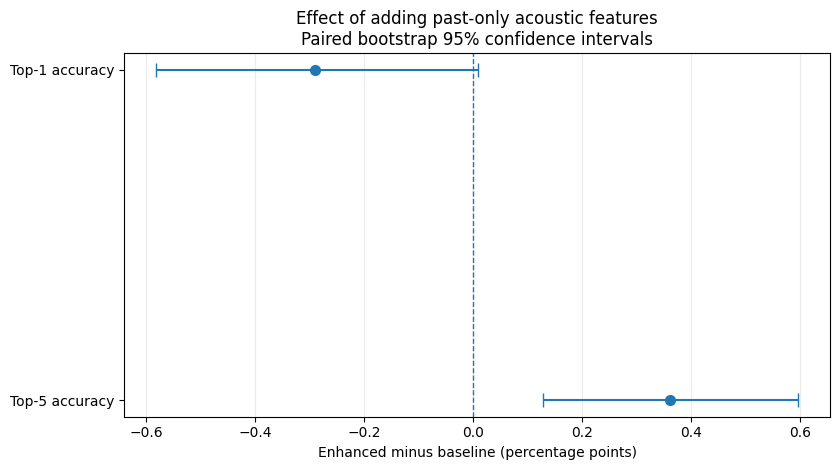


STEP 189 — PAIRED TEST COMPARISON
                         Model     n  accuracy  top5_accuracy  macro_f1  weighted_f1
        Temporal-only baseline 33540  0.443560       0.834705  0.285840     0.423367
Temporal + past-only acoustics 33540  0.440668       0.838312  0.285386     0.421731

Enhanced minus baseline:
{
  "accuracy": -0.0028920691711389335,
  "top5_accuracy": 0.0036076326774001632,
  "macro_f1": -0.00045385220507088153,
  "weighted_f1": -0.0016364569494051184
}

Paired bootstrap 95% CIs:
{
  "accuracy": {
    "difference": -0.0028920691711389387,
    "ci95_low": -0.005813953488372093,
    "ci95_high": 9.01908169350023e-05,
    "bootstrap_replicates": 1000
  },
  "top5_accuracy": {
    "difference": 0.0036076326774001194,
    "ci95_low": 0.0012813059033989268,
    "ci95_high": 0.005963774597495528,
    "bootstrap_replicates": 1000
  },
  "macro_f1": {
    "difference": -0.00045385220507088153,
    "ci95_low": -0.0051945813348272364,
    "ci95_high": 0.004440573251234017,
  

In [ ]:

# ============================================================================
# STEP 189 — CORRECTED ENHANCED INFERENCE, PAIRED COMPARISON + FIGURE
# Uses the exact architecture recovered from the STEP 184 training notebook.
# Does not retrain models or overwrite earlier experiment outputs.
# ============================================================================

from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score
from scipy.stats import binomtest
from tqdm.auto import tqdm

# ---------------------------------------------------------------------------
# 0. Paths and reproducibility
# ---------------------------------------------------------------------------
ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
DATASET_DIR = DERIVED / "step182_rebuilt_question5_dataset"
ENH_DIR = DERIVED / "step184_temporal_plus_acoustic"
OUT_DIR = DERIVED / "step189_paired_test_comparison"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ORIGINAL_CSV = DATASET_DIR / "step182_all_rows_with_acoustic_features.csv"
ACOUSTIC_CSV = DERIVED / "step183V_past_only_acoustic_features.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"
VOCAB_PATH = DATASET_DIR / "step182_target_class_vocabulary.csv"
BASE_PRED_PATH = (
    DERIVED / "step181_temporal_mlp_test_inference" /
    "step181_temporal_mlp_test_predictions.csv"
)
CKPT_PATH = ENH_DIR / "step184_best_model.pt"
PREP_PATH = ENH_DIR / "step184_acoustic_preprocessing.json"

SEED = 42
N_BOOT = 1000
BATCH_SIZE = 1024

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def load_checkpoint(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

# ---------------------------------------------------------------------------
# 1. Load and validate canonical dataset, splits, and vocabulary
# ---------------------------------------------------------------------------
for p in [ORIGINAL_CSV, ACOUSTIC_CSV, NPZ_PATH,
          VOCAB_PATH, BASE_PRED_PATH, CKPT_PATH, PREP_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Required artifact not found: {p}")

original = pd.read_csv(ORIGINAL_CSV, low_memory=False)
acoustic = pd.read_csv(ACOUSTIC_CSV, low_memory=False)
npz = np.load(NPZ_PATH, allow_pickle=False)
vocab_df = pd.read_csv(VOCAB_PATH).sort_values("target_idx")
baseline = pd.read_csv(BASE_PRED_PATH)

with np.load(NPZ_PATH, allow_pickle=False) as z:
    species_all = z["species_idx"].copy().astype(np.int64)
    node_all = z["node_features"].copy().astype(np.float32)
    mask_all = z["node_mask"].copy()
    y_all = z["target_idx"].copy().astype(np.int64)
    train_idx = z["train_idx"].copy().astype(np.int64)
    val_idx = z["val_idx"].copy().astype(np.int64)
    test_idx = z["test_idx"].copy().astype(np.int64)

N = len(original)
assert N == len(y_all) == len(species_all) == len(node_all) == len(mask_all)
assert len(np.unique(test_idx)) == len(test_idx)
assert len(test_idx) == 33540

vocab = dict(zip(vocab_df["target_idx"].astype(int),
                 vocab_df["target_species"].astype(str)))
species_to_idx = {v: k for k, v in vocab.items()}
assert len(vocab) == 95
assert set(vocab) == set(range(95))

canonical = original.iloc[test_idx].copy().reset_index(drop=True)
y_test = y_all[test_idx]

assert np.array_equal(
    canonical["target_species"].astype(str).to_numpy(),
    np.asarray([vocab[int(i)] for i in y_test], dtype=object)
), "Canonical CSV targets do not match the NPZ/vocabulary."

key_cols = ["itemID", "source_event", "target_event"]
for frame in (canonical, baseline):
    for col in key_cols:
        frame[col] = frame[col].astype(str).str.strip()

assert len(baseline) == len(canonical)
assert not baseline.duplicated(key_cols).any()
assert not canonical.duplicated(key_cols).any()
assert baseline[key_cols].reset_index(drop=True).equals(
    canonical[key_cols].reset_index(drop=True)
), "Baseline rows are not in canonical test order."
assert np.array_equal(
    baseline["true_target_idx"].to_numpy(dtype=int), y_test
), "Baseline target indices mismatch."

# ---------------------------------------------------------------------------
# 2. Align past-only acoustic features by source_event
# ---------------------------------------------------------------------------
ckpt = load_checkpoint(CKPT_PATH)
prep = json.loads(PREP_PATH.read_text())
FEATURES = ckpt["acoustic_features"]

assert FEATURES == prep["feature_columns"]
assert len(FEATURES) == 20

for frame_name, frame in [("original", original), ("acoustic", acoustic)]:
    for col in ["source_event", "itemID", "split"]:
        if col not in frame.columns:
            raise ValueError(f"{frame_name} CSV missing {col}")
    frame["source_event"] = frame["source_event"].astype(str).str.strip()
    frame["itemID"] = frame["itemID"].astype(str).str.strip()

assert original["source_event"].is_unique
assert acoustic["source_event"].is_unique
assert set(original["source_event"]) == set(acoustic["source_event"])

if "acoustic_history_available" not in acoustic.columns:
    raise ValueError("Past-only acoustic CSV lacks acoustic_history_available.")

def parse_bool(series, name):
    if pd.api.types.is_bool_dtype(series):
        return series.fillna(False).to_numpy(dtype=bool)
    mapping = {
        "true": True, "1": True, "yes": True,
        "false": False, "0": False, "no": False
    }
    result = series.astype(str).str.strip().str.lower().map(mapping)
    if result.isna().any():
        raise ValueError(f"Unrecognized values in {name}")
    return result.to_numpy(dtype=bool)

# Preserve original CSV order in the event-identity join.
left = original[["source_event", "itemID", "split"]].copy()
right = acoustic[
    ["source_event", "itemID", "split"] + FEATURES +
    ["acoustic_history_available"]
].copy()

aligned = left.merge(
    right,
    on="source_event",
    how="left",
    suffixes=("_original", "_acoustic"),
    sort=False,
    validate="one_to_one"
)

assert len(aligned) == N
assert aligned["source_event"].astype(str).equals(
    original["source_event"].astype(str)
)
assert (
    aligned["itemID_original"].astype(str).str.strip().to_numpy()
    == aligned["itemID_acoustic"].astype(str).str.strip().to_numpy()
).all()
assert (
    aligned["split_original"].astype(str).str.strip().str.lower().to_numpy()
    == aligned["split_acoustic"].astype(str).str.strip().str.lower().to_numpy()
).all()

history_available_all = parse_bool(
    aligned["acoustic_history_available"], "acoustic_history_available"
)
raw_all = aligned[FEATURES].apply(
    pd.to_numeric, errors="coerce"
).to_numpy(dtype=np.float64)

assert not np.isinf(raw_all).any()
assert np.isnan(raw_all[history_available_all]).sum() == 0
assert np.isnan(raw_all).sum() == np.isnan(raw_all[~history_available_all]).sum()

# Use only the saved STEP 184 training-fitted imputation/scaling parameters.
impute = np.asarray(prep["imputer_statistics"], dtype=np.float64)
scale_mean = np.asarray(prep["scaler_mean"], dtype=np.float64)
scale_scale = np.asarray(prep["scaler_scale"], dtype=np.float64)

assert len(impute) == len(scale_mean) == len(scale_scale) == len(FEATURES)
assert np.all(scale_scale > 0)

filled_all = np.where(np.isfinite(raw_all), raw_all, impute)
scaled_all = ((filled_all - scale_mean) / scale_scale).astype(np.float32)

# Exact STEP 184 input: 20 scaled acoustic features + history indicator.
acoustic_input_all = np.concatenate([
    scaled_all,
    history_available_all.astype(np.float32).reshape(-1, 1)
], axis=1).astype(np.float32)

assert acoustic_input_all.shape == (N, 21)
print("Aligned acoustic rows:", len(aligned))
print("Rows with history:", int(history_available_all.sum()))
print("Rows without history:", int((~history_available_all).sum()))

# ---------------------------------------------------------------------------
# 3. Reconstruct the EXACT STEP 184 model from notebook cell 233
# ---------------------------------------------------------------------------
class NextSpeciesTemporalAcousticMLP(nn.Module):
    def __init__(
        self,
        num_species,
        num_classes,
        num_nodes=6,
        species_embed_dim=32,
        temporal_numeric_dim=2,
        acoustic_dim=21,
        hidden_dim=128,
    ):
        super().__init__()
        self.species_embedding = nn.Embedding(
            num_embeddings=num_species,
            embedding_dim=species_embed_dim
        )

        temporal_dim = num_nodes * (
            species_embed_dim + temporal_numeric_dim
        ) + num_nodes

        self.temporal_dim = temporal_dim
        self.acoustic_dim = acoustic_dim

        combined_dim = temporal_dim + acoustic_dim

        self.network = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, species_idx, node_features, node_mask, acoustic_features):
        species_h = self.species_embedding(species_idx)
        h = torch.cat([species_h, node_features], dim=-1)
        h = h * node_mask.unsqueeze(-1).float()
        h = h.reshape(h.shape[0], -1)
        h = torch.cat([h, node_mask.float()], dim=-1)
        combined = torch.cat([h, acoustic_features], dim=-1)
        return self.network(combined)

temporal_all = node_all[:, :, :2].astype(np.float32)
num_species = int(ckpt["num_species"])
num_classes = int(ckpt["num_classes"])
num_nodes = int(ckpt["num_nodes"])

assert num_nodes == 6
assert temporal_all.shape[1:] == (6, 2)
assert acoustic_input_all.shape[1] == 21

model = NextSpeciesTemporalAcousticMLP(
    num_species=num_species,
    num_classes=num_classes,
    num_nodes=num_nodes,
    species_embed_dim=int(ckpt["species_embed_dim"]),
    temporal_numeric_dim=2,
    acoustic_dim=21,
    hidden_dim=int(ckpt["hidden_dim"])
)

# Strict loading ensures architecture compatibility.
model.load_state_dict(ckpt["model_state_dict"], strict=True)
model.to(device)
model.eval()

input_dim = model.network[0].in_features
derived_dim = 6 * (32 + 2) + 6 + 21
assert input_dim == derived_dim == 231
print("Strict checkpoint load passed.")
print("Model input dimension:", input_dim)

# ---------------------------------------------------------------------------
# 4. Run inference only on the canonical test indices
# ---------------------------------------------------------------------------
test_probs_parts = []
with torch.no_grad():
    for start in tqdm(range(0, len(test_idx), BATCH_SIZE),
                      desc="STEP 184 test inference"):
        rows = test_idx[start:start + BATCH_SIZE]
        logits = model(
            torch.as_tensor(species_all[rows], dtype=torch.long, device=device),
            torch.as_tensor(temporal_all[rows], dtype=torch.float32, device=device),
            torch.as_tensor(mask_all[rows], device=device),
            torch.as_tensor(acoustic_input_all[rows],
                            dtype=torch.float32, device=device)
        )
        test_probs_parts.append(torch.softmax(logits, dim=1).cpu().numpy())

probs = np.concatenate(test_probs_parts, axis=0)
assert probs.shape == (len(test_idx), 95)
assert np.isfinite(probs).all()
assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-5)

enh_top1 = probs.argmax(axis=1)
enh_top5 = np.argsort(-probs, axis=1)[:, :5]

# Verify all predicted class indices are in the established vocabulary.
assert enh_top1.min() >= 0 and enh_top1.max() < len(vocab)
assert enh_top5.min() >= 0 and enh_top5.max() < len(vocab)

# ---------------------------------------------------------------------------
# 5. Build aligned prediction table and verify identities
# ---------------------------------------------------------------------------
enhanced = canonical[key_cols + ["target_species"]].copy()
enhanced["test_npz_row_index"] = test_idx
enhanced["true_target_idx"] = y_test
enhanced["predicted_target_idx"] = enh_top1
enhanced["true_target_species_from_npz"] = [
    vocab[int(i)] for i in y_test
]
enhanced["predicted_target_species"] = [
    vocab[int(i)] for i in enh_top1
]
enhanced["correct"] = enh_top1 == y_test
enhanced["top5_predicted_species"] = [
    " | ".join(vocab[int(i)] for i in row) for row in enh_top5
]
enhanced["acoustic_history_available"] = history_available_all[test_idx]

assert enhanced[key_cols].reset_index(drop=True).equals(
    canonical[key_cols].reset_index(drop=True)
)
assert np.array_equal(enhanced["true_target_idx"].to_numpy(), y_test)

enh_pred_path = OUT_DIR / "step189_enhanced_test_predictions.csv"
enhanced.to_csv(enh_pred_path, index=False)

# ---------------------------------------------------------------------------
# 6. Metrics and paired bootstrap confidence intervals
# ---------------------------------------------------------------------------
base_top1 = baseline["predicted_target_idx"].to_numpy(dtype=int)
base_top5_names = baseline["top5_predicted_species"].fillna("").astype(str)

def parse_top5(s):
    return [species_to_idx[x.strip()] for x in s.split("|")
            if x.strip() in species_to_idx]

base_top5 = [parse_top5(s) for s in base_top5_names]
assert all(len(row) == 5 for row in base_top5)

base_top5_correct = np.asarray([
    int(int(y_i) in row) for y_i, row in zip(y_test, base_top5)
])
enh_top5_correct = np.asarray([
    int(int(y_i) in set(row.tolist()))
    for y_i, row in zip(y_test, enh_top5)
])

base_correct = (base_top1 == y_test).astype(int)
enh_correct = (enh_top1 == y_test).astype(int)

def metrics(y_true, pred, top5_correct):
    return {
        "n": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, pred)),
        "top5_accuracy": float(np.mean(top5_correct)),
        "macro_f1": float(f1_score(
            y_true, pred, average="macro", zero_division=0
        )),
        "weighted_f1": float(f1_score(
            y_true, pred, average="weighted", zero_division=0
        ))
    }

base_metrics = metrics(y_test, base_top1, base_top5_correct)
enh_metrics = metrics(y_test, enh_top1, enh_top5_correct)

def bootstrap_mean_diff_ci(d, n_boot=N_BOOT, seed=42):
    rng = np.random.default_rng(seed)
    n = len(d)
    boot = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[b] = np.mean(d[idx])
    return {
        "difference": float(np.mean(d)),
        "ci95_low": float(np.quantile(boot, 0.025)),
        "ci95_high": float(np.quantile(boot, 0.975)),
        "bootstrap_replicates": int(n_boot)
    }

def bootstrap_f1_diff_ci(y_true, pred_base, pred_enh, average,
                         n_boot=N_BOOT, seed=44):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    boot = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot[b] = (
            f1_score(y_true[idx], pred_enh[idx],
                     average=average, zero_division=0)
            - f1_score(y_true[idx], pred_base[idx],
                       average=average, zero_division=0)
        )
    observed = (
        f1_score(y_true, pred_enh, average=average, zero_division=0)
        - f1_score(y_true, pred_base, average=average, zero_division=0)
    )
    return {
        "difference": float(observed),
        "ci95_low": float(np.quantile(boot, 0.025)),
        "ci95_high": float(np.quantile(boot, 0.975)),
        "bootstrap_replicates": int(n_boot)
    }

paired_ci = {
    "accuracy": bootstrap_mean_diff_ci(enh_correct - base_correct, seed=42),
    "top5_accuracy": bootstrap_mean_diff_ci(
        enh_top5_correct - base_top5_correct, seed=43
    ),
    "macro_f1": bootstrap_f1_diff_ci(
        y_test, base_top1, enh_top1, "macro", seed=44
    ),
    "weighted_f1": bootstrap_f1_diff_ci(
        y_test, base_top1, enh_top1, "weighted", seed=45
    )
}

# Exact two-sided binomial test on discordant top-1 correctness outcomes.
base_only = int(np.sum((base_correct == 1) & (enh_correct == 0)))
enh_only = int(np.sum((base_correct == 0) & (enh_correct == 1)))
discordant = base_only + enh_only
mcnemar_p = float(
    binomtest(min(base_only, enh_only), n=discordant,
              p=0.5, alternative="two-sided").pvalue
) if discordant else 1.0

summary = {
    "research_question":
        "Do audio-derived environmental/acoustic features improve prediction of who vocalizes next?",
    "architecture_recovered_from_step184_notebook": True,
    "strict_checkpoint_load_passed": True,
    "test_rows": int(len(y_test)),
    "class_count": int(len(vocab)),
    "event_identity_order_verified": True,
    "target_vocabulary_verified": True,
    "baseline_metrics": base_metrics,
    "enhanced_metrics": enh_metrics,
    "enhanced_minus_baseline": {
        k: float(enh_metrics[k] - base_metrics[k])
        for k in ["accuracy", "top5_accuracy", "macro_f1", "weighted_f1"]
    },
    "paired_bootstrap_ci95": paired_ci,
    "mcnemar_top1": {
        "baseline_correct_enhanced_wrong": base_only,
        "baseline_wrong_enhanced_correct": enh_only,
        "discordant_rows": discordant,
        "exact_two_sided_p_value": mcnemar_p
    },
    "acoustic_history_available_test_rows":
        int(history_available_all[test_idx].sum()),
    "acoustic_history_unavailable_test_rows":
        int((~history_available_all[test_idx]).sum()),
    "bootstrap_replicates": N_BOOT,
    "enhanced_prediction_csv": str(enh_pred_path)
}

summary_path = OUT_DIR / "step189_paired_comparison_summary.json"
summary_path.write_text(json.dumps(summary, indent=2))

# ---------------------------------------------------------------------------
# 7. Figure: paired accuracy and top-5 accuracy differences with 95% CIs
# ---------------------------------------------------------------------------
plot_metrics = ["accuracy", "top5_accuracy"]
labels = ["Top-1 accuracy", "Top-5 accuracy"]
diffs = [paired_ci[k]["difference"] * 100 for k in plot_metrics]
lowers = [
    (paired_ci[k]["difference"] - paired_ci[k]["ci95_low"]) * 100
    for k in plot_metrics
]
uppers = [
    (paired_ci[k]["ci95_high"] - paired_ci[k]["difference"]) * 100
    for k in plot_metrics
]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ypos = np.arange(len(labels))
ax.errorbar(
    diffs, ypos,
    xerr=np.asarray([lowers, uppers]),
    fmt="o", capsize=5, markersize=7
)
ax.axvline(0, linestyle="--", linewidth=1)
ax.set_yticks(ypos)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("Enhanced minus baseline (percentage points)")
ax.set_title("Effect of adding past-only acoustic features\n"
             "Paired bootstrap 95% confidence intervals")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()

figure_path = OUT_DIR / "step189_paired_accuracy_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

# ---------------------------------------------------------------------------
# 8. Print concise report
# ---------------------------------------------------------------------------
print("\n" + "=" * 78)
print("STEP 189 — PAIRED TEST COMPARISON")
print("=" * 78)
print(pd.DataFrame([
    {"Model": "Temporal-only baseline", **base_metrics},
    {"Model": "Temporal + past-only acoustics", **enh_metrics}
]).to_string(index=False))

print("\nEnhanced minus baseline:")
print(json.dumps(summary["enhanced_minus_baseline"], indent=2))
print("\nPaired bootstrap 95% CIs:")
print(json.dumps(paired_ci, indent=2))
print("\nTop-1 McNemar exact test:")
print(json.dumps(summary["mcnemar_top1"], indent=2))

print("\nSaved enhanced predictions:", enh_pred_path)
print("Saved comparison summary:", summary_path)
print("Saved figure:", figure_path)
print("\nSTEP 189 COMPLETE.")


Device: cpu
Output folder: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation
Rows: 170,530
Train / validation / test: 103,738 / 33,252 / 33,540
Classes: 95

Training: Temporal only
Temporal only | epoch 01 | train loss 3.1912 | val loss 2.4329
Temporal only | epoch 02 | train loss 2.3923 | val loss 2.1068
Temporal only | epoch 03 | train loss 2.1629 | val loss 1.9996
Temporal only | epoch 04 | train loss 2.0673 | val loss 1.9525
Temporal only | epoch 05 | train loss 2.0128 | val loss 1.9249
Temporal only | epoch 06 | train loss 1.9716 | val loss 1.9077
Temporal only | epoch 07 | train loss 1.9423 | val loss 1.8889
Temporal only | epoch 08 | train loss 1.9228 | val loss 1.8822
Temporal only | epoch 09 | train loss 1.9019 | val loss 1.8736
Temporal only | epoch 10 | train loss 1.8878 | val loss 1.8655
Temporal only | epoch 11 | train loss 1.8730 | val loss 1.8582
Temporal only | epoch 12 | train loss 1.8615 | val loss 1.8524
Temporal only | epoch 13 | tra

,model,acoustic_feature_count,best_epoch,accuracy,top5_accuracy,macro_f1,weighted_f1,delta_accuracy_vs_temporal,delta_top5_accuracy_vs_temporal
0,Temporal only,0,15,0.44252,0.83912,0.28442,0.42333,0.00000,0.00000
1,All acoustics,20,14,0.43959,0.83151,0.28222,0.42081,-0.00292,-0.00760
2,Energy / amplitude,6,15,0.44100,0.83626,0.28607,0.42340,-0.00152,-0.00286
3,Spectral shape,8,15,0.44231,0.83572,0.28805,0.42373,-0.00021,-0.00340
4,Frequency bands,6,14,0.43879,0.83438,0.28126,0.41996,-0.00373,-0.00474


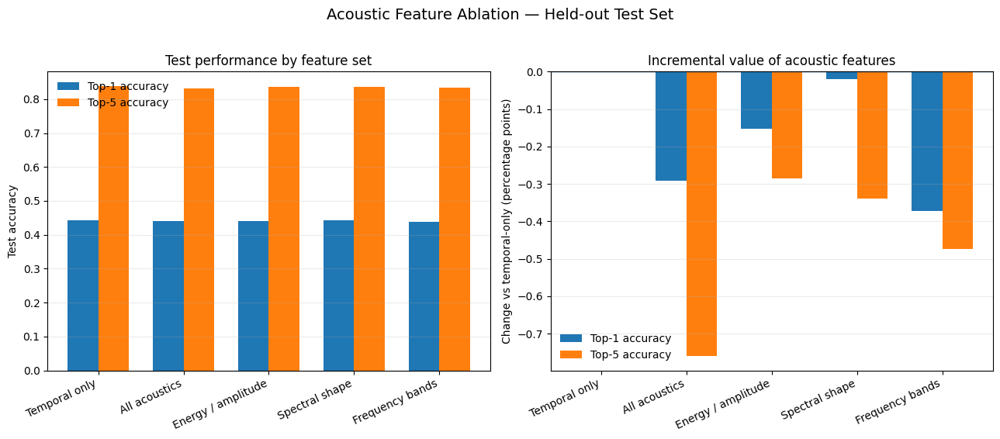


Saved outputs:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step190_ablation_results.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step190_ablation_test_predictions.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step190_ablation_summary.json
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step190_acoustic_ablation_comparison.png

STEP 190 COMPLETE.


In [ ]:

# ============================================================
# STEP 190 — ACOUSTIC FEATURE ABLATION
# Compares temporal-only against groups of past-only acoustics.
# Saves metrics, predictions, and figures directly to Drive.
# ============================================================

from pathlib import Path
import json, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score, top_k_accuracy_score
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# ----------------------------
# 1. Paths and reproducibility
# ----------------------------
ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"

CANONICAL_PATH = (
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
ACOUSTIC_PATH = DERIVED / "step183V_past_only_acoustic_features.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"

OUT = DERIVED / "step190_acoustic_ablation"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 184
BATCH_SIZE = 2048
MAX_EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Output folder:", OUT)

# ----------------------------
# 2. Load and align the data
# ----------------------------
canonical = pd.read_csv(CANONICAL_PATH)
acoustic = pd.read_csv(ACOUSTIC_PATH)
npz = np.load(NPZ_PATH, allow_pickle=True)

required_acoustic = [
    "rms_dbfs_mean", "rms_dbfs_std",
    "peak_dbfs_mean", "peak_dbfs_std",
    "crest_factor_db_mean", "crest_factor_db_std",
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]
history_col = "acoustic_history_available"

for col in ["source_event", "itemID"]:
    assert col in canonical.columns and col in acoustic.columns, (
        f"Missing alignment column: {col}"
    )

assert canonical["source_event"].is_unique, "Duplicate canonical source_event"
assert acoustic["source_event"].is_unique, "Duplicate acoustic source_event"
assert len(canonical) == len(npz["target_idx"]), "CSV/NPZ row count mismatch"

# Align acoustic rows explicitly by event identity.
acoustic_indexed = acoustic.set_index("source_event", drop=False)
assert set(canonical["source_event"]) == set(acoustic["source_event"])

aligned = acoustic_indexed.loc[canonical["source_event"]].reset_index(drop=True)
assert np.array_equal(
    canonical["source_event"].astype(str).to_numpy(),
    aligned["source_event"].astype(str).to_numpy()
)
assert np.array_equal(
    canonical["itemID"].astype(str).to_numpy(),
    aligned["itemID"].astype(str).to_numpy()
)

# Split indices are taken directly from the established NPZ.
train_idx = np.asarray(npz["train_idx"], dtype=int)
val_idx = np.asarray(npz["val_idx"], dtype=int)
test_idx = np.asarray(npz["test_idx"], dtype=int)

all_idx = np.concatenate([train_idx, val_idx, test_idx])
assert len(all_idx) == len(canonical)
assert len(np.unique(all_idx)) == len(canonical)
assert set(all_idx) == set(range(len(canonical)))

species_np = np.asarray(npz["species_idx"], dtype=np.int64)
node_np = np.asarray(npz["node_features"], dtype=np.float32)[:, :, :2]
mask_np = np.asarray(npz["node_mask"], dtype=np.float32)
target_np = np.asarray(npz["target_idx"], dtype=np.int64)

num_classes = int(target_np.max()) + 1
assert len(species_np) == len(canonical)
assert len(node_np) == len(canonical)
assert len(mask_np) == len(canonical)

print(f"Rows: {len(canonical):,}")
print(f"Train / validation / test: "
      f"{len(train_idx):,} / {len(val_idx):,} / {len(test_idx):,}")
print(f"Classes: {num_classes}")

# ----------------------------
# 3. Define acoustic feature groups
# ----------------------------
energy_cols = [
    "rms_dbfs_mean", "rms_dbfs_std",
    "peak_dbfs_mean", "peak_dbfs_std",
    "crest_factor_db_mean", "crest_factor_db_std",
]

spectral_cols = [
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
]

band_cols = [
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]

for c in required_acoustic + [history_col]:
    assert c in aligned.columns, f"Missing acoustic column: {c}"

variants = {
    "Temporal only": [],
    "All acoustics": required_acoustic,
    "Energy / amplitude": energy_cols,
    "Spectral shape": spectral_cols,
    "Frequency bands": band_cols,
}

# Convert availability indicator safely to numeric 0/1.
hist = aligned[history_col]
if hist.dtype == object:
    hist = (
        hist.astype(str).str.strip().str.lower()
        .map({"true": 1, "false": 0, "1": 1, "0": 0})
    )
else:
    hist = pd.to_numeric(hist, errors="coerce")

history_values = hist.fillna(0).to_numpy(dtype=np.float32)
history_values = (history_values > 0).astype(np.float32)

# ----------------------------
# 4. Model architecture
# ----------------------------
class NextSpeciesTemporalAcousticMLP(nn.Module):
    def __init__(
        self, num_species, num_classes, acoustic_dim,
        num_nodes=6, species_embed_dim=32,
        temporal_numeric_dim=2, hidden_dim=128
    ):
        super().__init__()
        self.species_embedding = nn.Embedding(
            num_species, species_embed_dim
        )

        temporal_dim = (
            num_nodes * (species_embed_dim + temporal_numeric_dim)
            + num_nodes
        )
        combined_dim = temporal_dim + acoustic_dim

        self.network = nn.Sequential(
            nn.Linear(combined_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, species_idx, node_features, node_mask, acoustic_features):
        species_h = self.species_embedding(species_idx)
        h = torch.cat([species_h, node_features], dim=-1)
        h = h * node_mask.unsqueeze(-1).float()
        h = h.reshape(h.shape[0], -1)
        h = torch.cat([h, node_mask.float()], dim=-1)
        combined = torch.cat([h, acoustic_features], dim=-1)
        return self.network(combined)


num_species = int(species_np.max()) + 1

# ----------------------------
# 5. Metrics helpers
# ----------------------------
def evaluate_model(model, loader):
    model.eval()
    logits_parts, y_parts = [], []

    with torch.no_grad():
        for sp, nf, nm, ac, yy in loader:
            logits = model(
                sp.to(DEVICE), nf.to(DEVICE),
                nm.to(DEVICE), ac.to(DEVICE)
            )
            logits_parts.append(logits.cpu().numpy())
            y_parts.append(yy.numpy())

    logits = np.concatenate(logits_parts)
    y = np.concatenate(y_parts)
    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    pred = probs.argmax(axis=1)

    return {
        "accuracy": float(accuracy_score(y, pred)),
        "top5_accuracy": float(
            top_k_accuracy_score(
                y, probs, k=5, labels=np.arange(num_classes)
            )
        ),
        "macro_f1": float(
            f1_score(y, pred, average="macro", zero_division=0)
        ),
        "weighted_f1": float(
            f1_score(y, pred, average="weighted", zero_division=0)
        ),
        "y_true": y,
        "pred": pred,
        "probs": probs,
    }

# ----------------------------
# 6. Train each variant
# ----------------------------
results = []
prediction_frames = []

for variant_name, selected_cols in variants.items():
    print("\n" + "=" * 72)
    print("Training:", variant_name)
    start = time.time()

    # No acoustic columns for temporal-only.
    # For acoustic variants, impute and scale using TRAIN rows only.
    if selected_cols:
        raw = aligned[selected_cols].apply(
            pd.to_numeric, errors="coerce"
        ).to_numpy(dtype=np.float64)

        imputer = SimpleImputer(strategy="mean")
        raw_train = imputer.fit_transform(raw[train_idx])
        raw_all = imputer.transform(raw)

        scaler = StandardScaler()
        scaler.fit(raw_train)
        scaled_all = scaler.transform(raw_all).astype(np.float32)

        # Include the past-history indicator for acoustic variants.
        acoustic_all = np.column_stack(
            [scaled_all, history_values]
        ).astype(np.float32)
    else:
        acoustic_all = np.zeros((len(canonical), 0), dtype=np.float32)

    def make_loader(indices, shuffle):
        ds = TensorDataset(
            torch.from_numpy(species_np[indices]),
            torch.from_numpy(node_np[indices]),
            torch.from_numpy(mask_np[indices]),
            torch.from_numpy(acoustic_all[indices]),
            torch.from_numpy(target_np[indices]),
        )
        return DataLoader(
            ds, batch_size=BATCH_SIZE, shuffle=shuffle,
            num_workers=0, pin_memory=(DEVICE.type == "cuda")
        )

    train_loader = make_loader(train_idx, True)
    val_loader = make_loader(val_idx, False)
    test_loader = make_loader(test_idx, False)

    model = NextSpeciesTemporalAcousticMLP(
        num_species=num_species,
        num_classes=num_classes,
        acoustic_dim=acoustic_all.shape[1],
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
    )
    criterion = nn.CrossEntropyLoss()

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        train_loss_sum = 0.0
        train_count = 0

        for sp, nf, nm, ac, yy in train_loader:
            sp, nf = sp.to(DEVICE), nf.to(DEVICE)
            nm, ac, yy = nm.to(DEVICE), ac.to(DEVICE), yy.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)
            logits = model(sp, nf, nm, ac)
            loss = criterion(logits, yy)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(yy)
            train_count += len(yy)

        model.eval()
        val_loss_sum = 0.0
        val_count = 0
        with torch.no_grad():
            for sp, nf, nm, ac, yy in val_loader:
                logits = model(
                    sp.to(DEVICE), nf.to(DEVICE),
                    nm.to(DEVICE), ac.to(DEVICE)
                )
                loss = criterion(logits, yy.to(DEVICE))
                val_loss_sum += loss.item() * len(yy)
                val_count += len(yy)

        train_loss = train_loss_sum / train_count
        val_loss = val_loss_sum / val_count

        print(
            f"{variant_name} | epoch {epoch:02d} | "
            f"train loss {train_loss:.4f} | val loss {val_loss:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print("Early stopping.")
                break

    model.load_state_dict(best_state)
    metrics = evaluate_model(model, test_loader)

    row = {
        "model": variant_name,
        "acoustic_feature_count": len(selected_cols),
        "best_epoch": best_epoch,
        "best_validation_loss": best_val_loss,
        "n_test": len(test_idx),
        "accuracy": metrics["accuracy"],
        "top5_accuracy": metrics["top5_accuracy"],
        "macro_f1": metrics["macro_f1"],
        "weighted_f1": metrics["weighted_f1"],
        "training_seconds": time.time() - start,
    }
    results.append(row)

    # Save per-row predictions for later paired analyses.
    pred_df = pd.DataFrame({
        "test_npz_row_index": test_idx,
        "true_target_idx": metrics["y_true"],
        "predicted_target_idx": metrics["pred"],
        "correct": (
            metrics["y_true"] == metrics["pred"]
        ).astype(int),
        "model": variant_name,
    })
    prediction_frames.append(pred_df)

    # Save each trained model for reproducibility.
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "variant": variant_name,
            "selected_acoustic_columns": selected_cols,
            "seed": SEED,
            "best_epoch": best_epoch,
            "best_validation_loss": best_val_loss,
        },
        OUT / (
            "step190_" + variant_name.lower()
            .replace("/", "_").replace(" ", "_") + ".pt"
        )
    )

    print(
        f"TEST: accuracy={metrics['accuracy']:.4f}, "
        f"top5={metrics['top5_accuracy']:.4f}, "
        f"macro-F1={metrics['macro_f1']:.4f}, "
        f"weighted-F1={metrics['weighted_f1']:.4f}"
    )

# ----------------------------
# 7. Save results and predictions
# ----------------------------
results_df = pd.DataFrame(results)
baseline_row = results_df.loc[
    results_df["model"] == "Temporal only"
].iloc[0]

for metric in ["accuracy", "top5_accuracy", "macro_f1", "weighted_f1"]:
    results_df[f"delta_{metric}_vs_temporal"] = (
        results_df[metric] - baseline_row[metric]
    )

results_path = OUT / "step190_ablation_results.csv"
predictions_path = OUT / "step190_ablation_test_predictions.csv"
summary_path = OUT / "step190_ablation_summary.json"

results_df.to_csv(results_path, index=False)
pd.concat(prediction_frames, ignore_index=True).to_csv(
    predictions_path, index=False
)

summary = {
    "seed": SEED,
    "device": str(DEVICE),
    "train_rows": len(train_idx),
    "validation_rows": len(val_idx),
    "test_rows": len(test_idx),
    "num_classes": num_classes,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "results": results_df.replace(
        {np.nan: None}
    ).to_dict(orient="records"),
}
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\n" + "=" * 72)
print("STEP 190 TEST RESULTS")
display_cols = [
    "model", "acoustic_feature_count", "best_epoch",
    "accuracy", "top5_accuracy", "macro_f1", "weighted_f1",
    "delta_accuracy_vs_temporal", "delta_top5_accuracy_vs_temporal",
]
display(results_df[display_cols].round(5))

# ----------------------------
# 8. Publication-friendly figure
# ----------------------------
plot_df = results_df.copy()
labels = plot_df["model"].tolist()
x = np.arange(len(labels))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Absolute test accuracy.
axes[0].bar(x - width/2, plot_df["accuracy"], width,
            label="Top-1 accuracy")
axes[0].bar(x + width/2, plot_df["top5_accuracy"], width,
            label="Top-5 accuracy")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=25, ha="right")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test performance by feature set")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.25)

# Differences against temporal-only model.
axes[1].axhline(0, linewidth=1)
axes[1].bar(
    x - width/2,
    100 * plot_df["delta_accuracy_vs_temporal"],
    width, label="Top-1 accuracy"
)
axes[1].bar(
    x + width/2,
    100 * plot_df["delta_top5_accuracy_vs_temporal"],
    width, label="Top-5 accuracy"
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=25, ha="right")
axes[1].set_ylabel("Change vs temporal-only (percentage points)")
axes[1].set_title("Incremental value of acoustic features")
axes[1].legend(frameon=False)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle(
    "Acoustic Feature Ablation — Held-out Test Set",
    fontsize=14, y=1.02
)
fig.tight_layout()

figure_path = OUT / "step190_acoustic_ablation_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved outputs:")
print(results_path)
print(predictions_path)
print(summary_path)
print(figure_path)
print("\nSTEP 190 COMPLETE.")


Reconstructing test probabilities: Temporal only
Reconstructing test probabilities: All acoustics
Reconstructing test probabilities: Energy / amplitude
Reconstructing test probabilities: Spectral shape
Reconstructing test probabilities: Frequency bands

ABSOLUTE TEST METRICS


,model,accuracy,top5_accuracy,macro_f1,weighted_f1
0,Temporal only,0.44252,0.83912,0.28442,0.42333
1,All acoustics,0.43959,0.83151,0.28222,0.42081
2,Energy / amplitude,0.44100,0.83626,0.28607,0.42340
3,Spectral shape,0.44231,0.83572,0.28805,0.42373
4,Frequency bands,0.43879,0.83438,0.28126,0.41996



PAIRED DIFFERENCES VS TEMPORAL-ONLY


,model,metric,difference,ci95_low,ci95_high,bootstrap_replicates,ci_excludes_zero
0,All acoustics,accuracy,-0.002922,-0.005963,0.000210,1000,False
1,All acoustics,top5_accuracy,-0.007603,-0.010256,-0.005038,1000,True
2,All acoustics,macro_f1,-0.002204,-0.008130,0.003178,1000,False
3,All acoustics,weighted_f1,-0.002522,-0.005805,0.000671,1000,False
4,Energy / amplitude,accuracy,-0.001521,-0.004472,0.001699,1000,False
5,Energy / amplitude,top5_accuracy,-0.002862,-0.005397,-0.000268,1000,True
6,Energy / amplitude,macro_f1,0.001644,-0.004280,0.006980,1000,False
7,Energy / amplitude,weighted_f1,0.000063,-0.003348,0.003377,1000,False
8,Spectral shape,accuracy,-0.000209,-0.003250,0.003041,1000,False
9,Spectral shape,top5_accuracy,-0.003399,-0.005874,-0.000894,1000,True


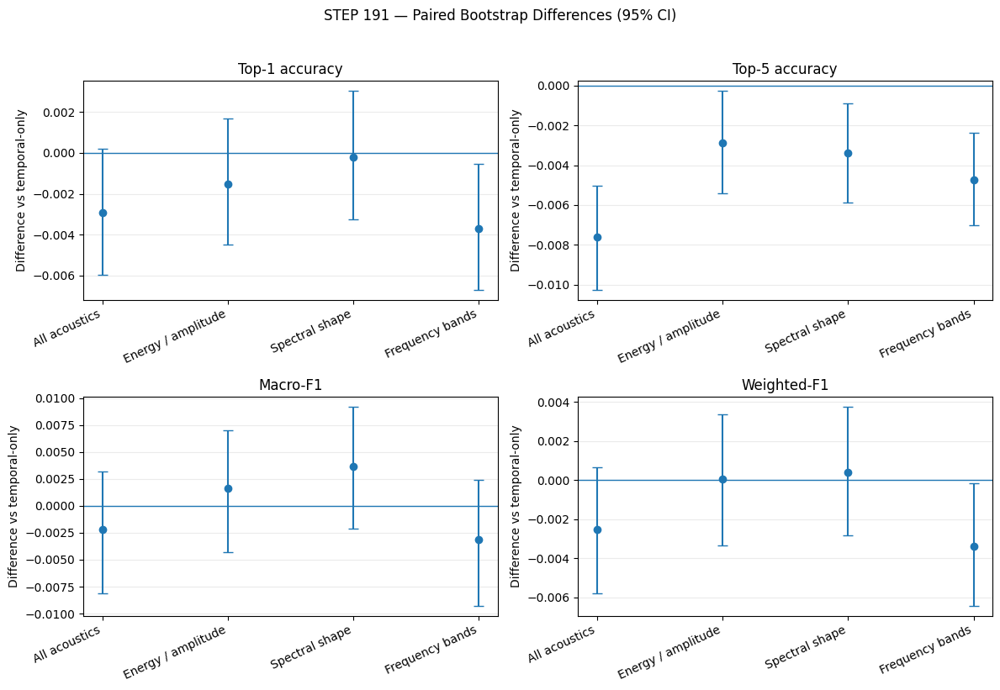


Saved:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step191_paired_bootstrap_comparisons.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step191_reconstructed_absolute_metrics.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step191_paired_comparison_summary.json
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step190_acoustic_ablation/step191_paired_bootstrap_confidence_intervals.png

STEP 191 COMPLETE.


In [ ]:

# ============================================================
# STEP 191 — PAIRED STATISTICAL COMPARISONS
# Reuses STEP 190 checkpoints; no model retraining.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
OUT = DERIVED / "step190_acoustic_ablation"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 191
BOOTSTRAPS = 1000
BATCH_SIZE = 2048
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
rng = np.random.default_rng(SEED)

canonical = pd.read_csv(
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
acoustic = pd.read_csv(
    DERIVED / "step183V_past_only_acoustic_features.csv"
)
npz = np.load(DERIVED / "gnn_compact_dataset.npz", allow_pickle=True)

# Verify identity alignment and established split.
assert canonical["source_event"].is_unique
assert acoustic["source_event"].is_unique
assert set(canonical["source_event"]) == set(acoustic["source_event"])

acoustic = acoustic.set_index("source_event").loc[
    canonical["source_event"]
].reset_index()

train_idx = np.asarray(npz["train_idx"], dtype=int)
val_idx = np.asarray(npz["val_idx"], dtype=int)
test_idx = np.asarray(npz["test_idx"], dtype=int)

species_np = np.asarray(npz["species_idx"], dtype=np.int64)
node_np = np.asarray(npz["node_features"], dtype=np.float32)[:, :, :2]
mask_np = np.asarray(npz["node_mask"], dtype=np.float32)
target_np = np.asarray(npz["target_idx"], dtype=np.int64)
num_classes = int(target_np.max()) + 1
num_species = int(species_np.max()) + 1

assert len(canonical) == len(target_np)
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(canonical)

energy_cols = [
    "rms_dbfs_mean", "rms_dbfs_std",
    "peak_dbfs_mean", "peak_dbfs_std",
    "crest_factor_db_mean", "crest_factor_db_std",
]
spectral_cols = [
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
]
band_cols = [
    "low_band_fraction_0_1000hz_mean",
    "low_band_fraction_0_1000hz_std",
    "mid_band_fraction_1000_4000hz_mean",
    "mid_band_fraction_1000_4000hz_std",
    "high_band_fraction_4000_12000hz_mean",
    "high_band_fraction_4000_12000hz_std",
]
all_cols = energy_cols + spectral_cols + band_cols

variants = {
    "Temporal only": [],
    "All acoustics": all_cols,
    "Energy / amplitude": energy_cols,
    "Spectral shape": spectral_cols,
    "Frequency bands": band_cols,
}

hist = acoustic["acoustic_history_available"]
if hist.dtype == object:
    hist = hist.astype(str).str.strip().str.lower().map(
        {"true": 1, "false": 0, "1": 1, "0": 0}
    )
history_values = (
    pd.to_numeric(hist, errors="coerce").fillna(0).to_numpy() > 0
).astype(np.float32)

class NextSpeciesTemporalAcousticMLP(nn.Module):
    def __init__(self, num_species, num_classes, acoustic_dim,
                 num_nodes=6, species_embed_dim=32,
                 temporal_numeric_dim=2, hidden_dim=128):
        super().__init__()
        self.species_embedding = nn.Embedding(num_species, species_embed_dim)
        temporal_dim = num_nodes * (
            species_embed_dim + temporal_numeric_dim
        ) + num_nodes
        self.network = nn.Sequential(
            nn.Linear(temporal_dim + acoustic_dim, hidden_dim),
            nn.LayerNorm(hidden_dim), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, species_idx, node_features, node_mask, acoustic_features):
        species_h = self.species_embedding(species_idx)
        h = torch.cat([species_h, node_features], dim=-1)
        h = h * node_mask.unsqueeze(-1).float()
        h = h.reshape(h.shape[0], -1)
        h = torch.cat([h, node_mask.float()], dim=-1)
        return self.network(torch.cat([h, acoustic_features], dim=-1))

def build_acoustic_input(cols):
    if not cols:
        return np.zeros((len(canonical), 0), dtype=np.float32)

    raw = acoustic[cols].apply(pd.to_numeric, errors="coerce").to_numpy(float)
    imputer = SimpleImputer(strategy="mean")
    train_raw = imputer.fit_transform(raw[train_idx])
    all_raw = imputer.transform(raw)

    scaler = StandardScaler()
    scaler.fit(train_raw)
    scaled = scaler.transform(all_raw).astype(np.float32)

    return np.column_stack([scaled, history_values]).astype(np.float32)

def infer_variant(name, cols):
    acoustic_all = build_acoustic_input(cols)
    model_path = OUT / (
        "step190_" + name.lower().replace("/", "_").replace(" ", "_") + ".pt"
    )
    checkpoint = torch.load(model_path, map_location=DEVICE, weights_only=False)

    model = NextSpeciesTemporalAcousticMLP(
        num_species, num_classes, acoustic_all.shape[1]
    ).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    model.eval()

    ds = TensorDataset(
        torch.from_numpy(species_np[test_idx]),
        torch.from_numpy(node_np[test_idx]),
        torch.from_numpy(mask_np[test_idx]),
        torch.from_numpy(acoustic_all[test_idx]),
    )
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False)

    logits_all = []
    with torch.no_grad():
        for sp, nf, nm, ac in loader:
            logits = model(
                sp.to(DEVICE), nf.to(DEVICE),
                nm.to(DEVICE), ac.to(DEVICE)
            )
            logits_all.append(logits.cpu().numpy())

    logits = np.concatenate(logits_all)
    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    return target_np[test_idx].copy(), probs

# Recover probabilities for each saved STEP 190 model.
probabilities = {}
true_y = None

for name, cols in variants.items():
    print("Reconstructing test probabilities:", name)
    y, probs = infer_variant(name, cols)
    if true_y is None:
        true_y = y
    else:
        assert np.array_equal(true_y, y)
    probabilities[name] = probs

def metrics_from_probs(y, probs):
    pred = probs.argmax(axis=1)
    top5 = np.argpartition(probs, -5, axis=1)[:, -5:]
    return {
        "accuracy": (pred == y).astype(float),
        "top5_accuracy": np.array([
            y[i] in top5[i] for i in range(len(y))
        ], dtype=float),
        "macro_f1": f1_score(
            y, pred, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y, pred, average="weighted", zero_division=0
        ),
        "pred": pred,
    }

model_metrics = {
    name: metrics_from_probs(true_y, p)
    for name, p in probabilities.items()
}

# Paired bootstrap:
# resample test rows with replacement, preserving model pairing.
# Macro-F1 is recomputed within each resample.
def bootstrap_comparison(name, metric, n_boot=BOOTSTRAPS):
    base = model_metrics["Temporal only"]
    other = model_metrics[name]

    if metric in ("accuracy", "top5_accuracy"):
        a = base[metric]
        b = other[metric]
        observed = float(b.mean() - a.mean())
        boot = np.empty(n_boot)
        n = len(true_y)
        for k in range(n_boot):
            idx = rng.integers(0, n, size=n)
            boot[k] = b[idx].mean() - a[idx].mean()
    else:
        observed = float(other[metric] - base[metric])
        boot = np.empty(n_boot)
        n = len(true_y)
        for k in range(n_boot):
            idx = rng.integers(0, n, size=n)
            yb = true_y[idx]
            pred_a = base["pred"][idx]
            pred_b = other["pred"][idx]
            avg = "macro" if metric == "macro_f1" else "weighted"
            boot[k] = (
                f1_score(yb, pred_b, average=avg, zero_division=0)
                - f1_score(yb, pred_a, average=avg, zero_division=0)
            )

    low, high = np.quantile(boot, [0.025, 0.975])
    return {
        "model": name,
        "metric": metric,
        "difference": observed,
        "ci95_low": float(low),
        "ci95_high": float(high),
        "bootstrap_replicates": n_boot,
        "ci_excludes_zero": bool(low > 0 or high < 0),
    }

rows = []
for name in variants:
    if name == "Temporal only":
        continue
    for metric in ["accuracy", "top5_accuracy", "macro_f1", "weighted_f1"]:
        rows.append(bootstrap_comparison(name, metric))

comparison_df = pd.DataFrame(rows)
comparison_path = OUT / "step191_paired_bootstrap_comparisons.csv"
comparison_df.to_csv(comparison_path, index=False)

# Save absolute metrics too, from the reconstructed saved checkpoints.
absolute_rows = []
for name, m in model_metrics.items():
    absolute_rows.append({
        "model": name,
        "accuracy": float(m["accuracy"].mean()),
        "top5_accuracy": float(m["top5_accuracy"].mean()),
        "macro_f1": float(m["macro_f1"]),
        "weighted_f1": float(m["weighted_f1"]),
    })
absolute_df = pd.DataFrame(absolute_rows)
absolute_path = OUT / "step191_reconstructed_absolute_metrics.csv"
absolute_df.to_csv(absolute_path, index=False)

summary = {
    "seed": SEED,
    "bootstrap_replicates": BOOTSTRAPS,
    "n_test": int(len(true_y)),
    "absolute_metrics": absolute_df.to_dict(orient="records"),
    "paired_comparisons": comparison_df.to_dict(orient="records"),
}
summary_path = OUT / "step191_paired_comparison_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("\nABSOLUTE TEST METRICS")
display(absolute_df.round(5))

print("\nPAIRED DIFFERENCES VS TEMPORAL-ONLY")
display(comparison_df.round(6))

# Figure: paired difference and 95% bootstrap CI.
metrics_to_plot = ["accuracy", "top5_accuracy", "macro_f1", "weighted_f1"]
titles = {
    "accuracy": "Top-1 accuracy",
    "top5_accuracy": "Top-5 accuracy",
    "macro_f1": "Macro-F1",
    "weighted_f1": "Weighted-F1",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.flat, metrics_to_plot):
    sub = comparison_df[comparison_df["metric"] == metric].copy()
    x = np.arange(len(sub))
    diff = sub["difference"].to_numpy()
    lower = diff - sub["ci95_low"].to_numpy()
    upper = sub["ci95_high"].to_numpy() - diff
    ax.errorbar(x, diff, yerr=np.vstack([lower, upper]),
                fmt="o", capsize=4)
    ax.axhline(0, linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(sub["model"], rotation=25, ha="right")
    ax.set_title(titles[metric])
    ax.set_ylabel("Difference vs temporal-only")
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("STEP 191 — Paired Bootstrap Differences (95% CI)", y=1.02)
fig.tight_layout()
figure_path = OUT / "step191_paired_bootstrap_confidence_intervals.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(comparison_path)
print(absolute_path)
print(summary_path)
print(figure_path)
print("\nSTEP 191 COMPLETE.")


Device: cpu
Seeds: [192, 193, 194, 195, 196]
Output: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step192_seed_robustness

Seed 192 | Temporal only
  epoch 01 | val loss 2.4355
  epoch 02 | val loss 2.0892
  epoch 03 | val loss 1.9874
  epoch 04 | val loss 1.9348
  epoch 05 | val loss 1.9113
  epoch 06 | val loss 1.8940
  epoch 07 | val loss 1.8779
  epoch 08 | val loss 1.8681
  epoch 09 | val loss 1.8673
  epoch 10 | val loss 1.8598
  epoch 11 | val loss 1.8540
  epoch 12 | val loss 1.8476
  epoch 13 | val loss 1.8471
  epoch 14 | val loss 1.8476
  epoch 15 | val loss 1.8446
  TEST: {'accuracy': 0.44117, 'top5_accuracy': 0.83584, 'macro_f1': 0.2827, 'weighted_f1': 0.42247}

Seed 192 | Temporal + spectral shape
  epoch 01 | val loss 2.4367
  epoch 02 | val loss 2.0976
  epoch 03 | val loss 2.0004
  epoch 04 | val loss 1.9457
  epoch 05 | val loss 1.9156
  epoch 06 | val loss 1.8998
  epoch 07 | val loss 1.8839
  epoch 08 | val loss 1.8724
  epoch 09 | val loss 1.8699
  epoc

,seed,model,best_epoch,best_validation_loss,training_seconds,accuracy,top5_accuracy,macro_f1,weighted_f1
0,192,Temporal only,15,1.84455,95.12998,0.44117,0.83584,0.28270,0.42247
1,192,Temporal + spectral shape,15,1.83877,78.70366,0.44258,0.83649,0.27961,0.42390
2,193,Temporal only,14,1.84088,76.08607,0.44129,0.83667,0.27922,0.42431
3,193,Temporal + spectral shape,14,1.83570,79.78849,0.44085,0.83357,0.28063,0.42357
4,194,Temporal only,15,1.83329,81.42202,0.44049,0.83578,0.28518,0.42089
5,194,Temporal + spectral shape,15,1.83100,76.00009,0.44126,0.83688,0.28534,0.42208
6,195,Temporal only,14,1.83421,75.13936,0.44189,0.83605,0.28315,0.42510
7,195,Temporal + spectral shape,14,1.83220,75.77130,0.44213,0.83208,0.28507,0.42430
8,196,Temporal only,15,1.83409,76.09460,0.44225,0.83503,0.28768,0.42318
9,196,Temporal + spectral shape,14,1.83880,75.82544,0.44284,0.83420,0.28511,0.42289



PAIRED DIFFERENCES: SPECTRAL MINUS TEMPORAL


,metric,mean_difference,sd_across_seed_differences,min_difference,max_difference,seeds_with_improvement,number_of_seeds
0,accuracy,0.000513,0.000682,-0.000447,0.001401,4,5
1,top5_accuracy,-0.001228,0.002244,-0.003965,0.001103,2,5
2,macro_f1,-0.000435,0.002285,-0.003090,0.001919,3,5
3,weighted_f1,0.000157,0.001075,-0.000800,0.001432,2,5


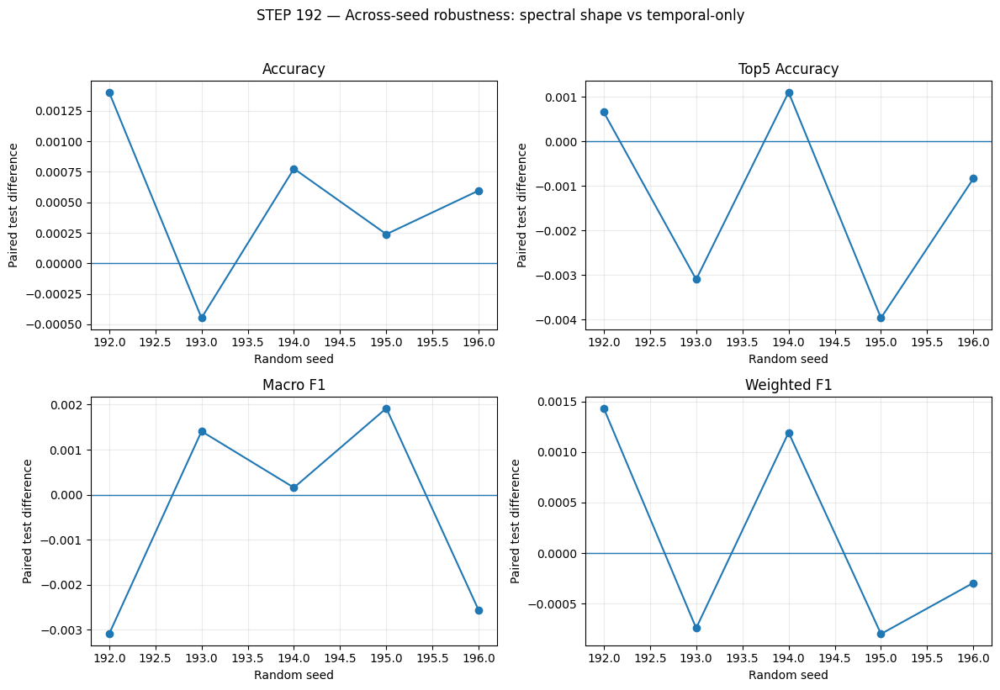


Saved outputs:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step192_seed_robustness/step192_seed_results.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step192_seed_robustness/step192_paired_seed_differences.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step192_seed_robustness/step192_summary.json
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step192_seed_robustness/step192_seed_robustness.png

STEP 192 COMPLETE.


In [ ]:

# ============================================================
# STEP 192 — ROBUSTNESS ACROSS TRAINING SEEDS
# Temporal-only vs temporal + spectral-shape acoustic features
# ============================================================

from pathlib import Path
import copy, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
OUT = DERIVED / "step192_seed_robustness"
OUT.mkdir(parents=True, exist_ok=True)

# Start with 5 seeds. Increase to 10 later if practical.
SEEDS = [192, 193, 194, 195, 196]
MAX_EPOCHS = 15
PATIENCE = 3
BATCH_SIZE = 2048
LEARNING_RATE = 1e-3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Seeds:", SEEDS)
print("Output:", OUT)

canonical = pd.read_csv(
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
acoustic = pd.read_csv(
    DERIVED / "step183V_past_only_acoustic_features.csv"
)
npz = np.load(DERIVED / "gnn_compact_dataset.npz", allow_pickle=True)

# Align acoustic features by stable event identity.
assert canonical["source_event"].is_unique
assert acoustic["source_event"].is_unique
assert set(canonical["source_event"]) == set(acoustic["source_event"])

acoustic = acoustic.set_index("source_event").loc[
    canonical["source_event"]
].reset_index()

train_idx = np.asarray(npz["train_idx"], dtype=int)
val_idx = np.asarray(npz["val_idx"], dtype=int)
test_idx = np.asarray(npz["test_idx"], dtype=int)

species_np = np.asarray(npz["species_idx"], dtype=np.int64)
node_np = np.asarray(npz["node_features"], dtype=np.float32)[:, :, :2]
mask_np = np.asarray(npz["node_mask"], dtype=np.float32)
target_np = np.asarray(npz["target_idx"], dtype=np.int64)

assert len(canonical) == len(target_np)
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(canonical)

num_classes = int(target_np.max()) + 1
num_species = int(species_np.max()) + 1

spectral_cols = [
    "zero_crossing_rate_mean", "zero_crossing_rate_std",
    "spectral_centroid_hz_mean", "spectral_centroid_hz_std",
    "spectral_entropy_mean", "spectral_entropy_std",
    "spectral_flatness_mean", "spectral_flatness_std",
]
history_col = "acoustic_history_available"

# Convert history availability to a numeric indicator.
hist = acoustic[history_col]
if hist.dtype == object:
    hist = hist.astype(str).str.strip().str.lower().map(
        {"true": 1, "false": 0, "1": 1, "0": 0}
    )
history_values = (
    pd.to_numeric(hist, errors="coerce").fillna(0).to_numpy() > 0
).astype(np.float32)

# Impute and scale spectral features using TRAIN rows only.
raw = acoustic[spectral_cols].apply(
    pd.to_numeric, errors="coerce"
).to_numpy(dtype=np.float64)

imputer = SimpleImputer(strategy="mean")
raw_train = imputer.fit_transform(raw[train_idx])
raw_all = imputer.transform(raw)

scaler = StandardScaler()
scaler.fit(raw_train)
spectral_scaled = scaler.transform(raw_all).astype(np.float32)

spectral_input = np.column_stack([
    spectral_scaled, history_values
]).astype(np.float32)

temporal_input = np.zeros((len(canonical), 0), dtype=np.float32)

class NextSpeciesTemporalAcousticMLP(nn.Module):
    def __init__(self, num_species, num_classes, acoustic_dim,
                 num_nodes=6, species_embed_dim=32,
                 temporal_numeric_dim=2, hidden_dim=128):
        super().__init__()
        self.species_embedding = nn.Embedding(
            num_species, species_embed_dim
        )
        temporal_dim = num_nodes * (
            species_embed_dim + temporal_numeric_dim
        ) + num_nodes
        self.network = nn.Sequential(
            nn.Linear(temporal_dim + acoustic_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, species_idx, node_features, node_mask, acoustic_features):
        species_h = self.species_embedding(species_idx)
        h = torch.cat([species_h, node_features], dim=-1)
        h = h * node_mask.unsqueeze(-1).float()
        h = h.reshape(h.shape[0], -1)
        h = torch.cat([h, node_mask.float()], dim=-1)
        combined = torch.cat([h, acoustic_features], dim=-1)
        return self.network(combined)

def make_loader(indices, acoustic_features, shuffle, seed):
    ds = TensorDataset(
        torch.from_numpy(species_np[indices]),
        torch.from_numpy(node_np[indices]),
        torch.from_numpy(mask_np[indices]),
        torch.from_numpy(acoustic_features[indices]),
        torch.from_numpy(target_np[indices]),
    )
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        ds,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        generator=generator if shuffle else None,
        pin_memory=(DEVICE.type == "cuda"),
    )

def evaluate(model, loader):
    model.eval()
    ys, preds, top5_hits = [], [], []
    with torch.no_grad():
        for sp, nf, nm, ac, yy in loader:
            logits = model(
                sp.to(DEVICE), nf.to(DEVICE),
                nm.to(DEVICE), ac.to(DEVICE)
            )
            probs = torch.softmax(logits, dim=1)
            pred = probs.argmax(dim=1)
            k = probs.topk(5, dim=1).indices
            ys.append(yy.numpy())
            preds.append(pred.cpu().numpy())
            top5_hits.append(
                (k.cpu().numpy() == yy.numpy()[:, None]).any(axis=1)
            )
    y = np.concatenate(ys)
    pred = np.concatenate(preds)
    top5 = np.concatenate(top5_hits)
    return {
        "accuracy": float(accuracy_score(y, pred)),
        "top5_accuracy": float(top5.mean()),
        "macro_f1": float(f1_score(
            y, pred, average="macro", zero_division=0
        )),
        "weighted_f1": float(f1_score(
            y, pred, average="weighted", zero_division=0
        )),
    }

variants = {
    "Temporal only": temporal_input,
    "Temporal + spectral shape": spectral_input,
}

records = []

for seed in SEEDS:
    for variant, acoustic_all in variants.items():
        print(f"\nSeed {seed} | {variant}")
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        train_loader = make_loader(train_idx, acoustic_all, True, seed)
        val_loader = make_loader(val_idx, acoustic_all, False, seed)
        test_loader = make_loader(test_idx, acoustic_all, False, seed)

        model = NextSpeciesTemporalAcousticMLP(
            num_species, num_classes, acoustic_all.shape[1]
        ).to(DEVICE)

        optimizer = torch.optim.AdamW(
            model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4
        )
        criterion = nn.CrossEntropyLoss()

        best_val_loss = float("inf")
        best_state = None
        best_epoch = 0
        no_improvement = 0

        start = time.time()

        for epoch in range(1, MAX_EPOCHS + 1):
            model.train()
            for sp, nf, nm, ac, yy in train_loader:
                optimizer.zero_grad(set_to_none=True)
                logits = model(
                    sp.to(DEVICE), nf.to(DEVICE),
                    nm.to(DEVICE), ac.to(DEVICE)
                )
                loss = criterion(logits, yy.to(DEVICE))
                loss.backward()
                optimizer.step()

            model.eval()
            val_loss_sum = 0.0
            val_count = 0
            with torch.no_grad():
                for sp, nf, nm, ac, yy in val_loader:
                    logits = model(
                        sp.to(DEVICE), nf.to(DEVICE),
                        nm.to(DEVICE), ac.to(DEVICE)
                    )
                    loss = criterion(logits, yy.to(DEVICE))
                    val_loss_sum += loss.item() * len(yy)
                    val_count += len(yy)

            val_loss = val_loss_sum / val_count
            print(f"  epoch {epoch:02d} | val loss {val_loss:.4f}")

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch
                no_improvement = 0
            else:
                no_improvement += 1
                if no_improvement >= PATIENCE:
                    break

        model.load_state_dict(best_state)
        test_metrics = evaluate(model, test_loader)

        record = {
            "seed": seed,
            "model": variant,
            "best_epoch": best_epoch,
            "best_validation_loss": best_val_loss,
            "training_seconds": time.time() - start,
            **test_metrics,
        }
        records.append(record)

        filename = (
            f"step192_seed{seed}_"
            + variant.lower().replace(" + ", "_").replace(" ", "_")
            + ".pt"
        )
        torch.save({
            "model_state_dict": model.state_dict(),
            "seed": seed,
            "variant": variant,
            "best_epoch": best_epoch,
            "best_validation_loss": best_val_loss,
        }, OUT / filename)

        print("  TEST:", {
            k: round(v, 5) for k, v in test_metrics.items()
        })

results = pd.DataFrame(records)
results_path = OUT / "step192_seed_results.csv"
results.to_csv(results_path, index=False)

# Paired per-seed differences: spectral model minus temporal-only.
metrics = ["accuracy", "top5_accuracy", "macro_f1", "weighted_f1"]
wide = results.pivot(index="seed", columns="model", values=metrics)

difference_rows = []
for metric in metrics:
    diffs = (
        wide[(metric, "Temporal + spectral shape")]
        - wide[(metric, "Temporal only")]
    )
    difference_rows.append({
        "metric": metric,
        "mean_difference": float(diffs.mean()),
        "sd_across_seed_differences": float(diffs.std(ddof=1)),
        "min_difference": float(diffs.min()),
        "max_difference": float(diffs.max()),
        "seeds_with_improvement": int((diffs > 0).sum()),
        "number_of_seeds": len(diffs),
    })

differences = pd.DataFrame(difference_rows)
diff_path = OUT / "step192_paired_seed_differences.csv"
differences.to_csv(diff_path, index=False)

summary = {
    "seeds": SEEDS,
    "device": str(DEVICE),
    "test_rows": int(len(test_idx)),
    "results": results.to_dict(orient="records"),
    "paired_seed_differences": differences.to_dict(orient="records"),
}
with open(OUT / "step192_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nRESULTS BY SEED")
display(results.round(5))
print("\nPAIRED DIFFERENCES: SPECTRAL MINUS TEMPORAL")
display(differences.round(6))

# Figure: paired differences by seed.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.flat, metrics):
    vals = wide[(metric, "Temporal + spectral shape")] - wide[
        (metric, "Temporal only")
    ]
    ax.axhline(0, linewidth=1)
    ax.plot(vals.index, vals.values, marker="o")
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Random seed")
    ax.set_ylabel("Paired test difference")
    ax.grid(alpha=0.25)

fig.suptitle(
    "STEP 192 — Across-seed robustness: spectral shape vs temporal-only",
    y=1.02
)
fig.tight_layout()
fig_path = OUT / "step192_seed_robustness.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved outputs:")
print(results_path)
print(diff_path)
print(OUT / "step192_summary.json")
print(fig_path)
print("\nSTEP 192 COMPLETE.")


In [ ]:

# ============================================================
# STEP 193 — RECORDING-LEVEL SPLIT AUDIT
# No training. Checks recording/event identity across splits.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
OUT = DERIVED / "step193_split_audit"
OUT.mkdir(parents=True, exist_ok=True)

CSV_PATH = (
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"

df = pd.read_csv(CSV_PATH)
npz = np.load(NPZ_PATH, allow_pickle=True)

train_idx = np.asarray(npz["train_idx"], dtype=int)
val_idx = np.asarray(npz["val_idx"], dtype=int)
test_idx = np.asarray(npz["test_idx"], dtype=int)

# Verify that the split indices partition the dataset.
all_idx = np.concatenate([train_idx, val_idx, test_idx])
assert len(all_idx) == len(df), "Split sizes do not match CSV row count"
assert len(np.unique(all_idx)) == len(df), "Split indices overlap or omit rows"
assert set(all_idx) == set(range(len(df))), "Unexpected split index"

df = df.copy()
df["audit_split"] = "unassigned"
df.loc[train_idx, "audit_split"] = "train"
df.loc[val_idx, "audit_split"] = "validation"
df.loc[test_idx, "audit_split"] = "test"

print("DATASET")
print("Rows:", len(df))
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))
print("Columns:")
print(df.columns.tolist())

# Check event-level identity overlap across splits.
event_cols = [
    c for c in ["source_event", "target_event"]
    if c in df.columns
]

event_report = []
for col in event_cols:
    sets = {
        split: set(df.loc[df["audit_split"] == split, col].dropna())
        for split in ["train", "validation", "test"]
    }
    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]:
        overlap = sets[a] & sets[b]
        event_report.append({
            "identifier": col,
            "split_a": a,
            "split_b": b,
            "unique_ids_a": len(sets[a]),
            "unique_ids_b": len(sets[b]),
            "overlap_unique_ids": len(overlap),
        })

event_df = pd.DataFrame(event_report)
print("\nEVENT IDENTIFIER OVERLAP")
if len(event_df):
    display(event_df)
else:
    print("No recognized event identifier columns found.")

# Identify likely recording-level fields.
# This is a candidate list only: names need semantic confirmation.
candidate_names = [
    "recording_id", "recording", "recording_name",
    "recording_file", "audio_file", "audio_filename",
    "file_name", "filename", "wav_file", "wav_path",
    "audio_path", "source_file", "itemID",
    "session_id", "deployment_id",
]
recording_candidates = [
    c for c in df.columns
    if c.lower() in candidate_names
    or any(term in c.lower() for term in [
        "recording_id", "recording_file", "audio_file",
        "audio_path", "wav_path", "session_id"
    ])
]

recording_report = []
for col in recording_candidates:
    # Exclude the split label itself and empty identifiers.
    temp = df[["audit_split", col]].dropna().copy()
    temp[col] = temp[col].astype(str).str.strip()
    temp = temp[temp[col] != ""]
    sets = {
        split: set(temp.loc[temp["audit_split"] == split, col])
        for split in ["train", "validation", "test"]
    }

    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]:
        overlap = sets[a] & sets[b]
        recording_report.append({
            "candidate_column": col,
            "split_a": a,
            "split_b": b,
            "unique_ids_a": len(sets[a]),
            "unique_ids_b": len(sets[b]),
            "overlap_unique_ids": len(overlap),
        })

recording_df = pd.DataFrame(recording_report)
print("\nPOSSIBLE RECORDING-LEVEL IDENTIFIERS")
if len(recording_df):
    display(recording_df)
else:
    print(
        "No obvious recording identifier found automatically. "
        "We need to inspect the columns and trace the source metadata."
    )

# Save a compact audit report.
summary = {
    "rows": int(len(df)),
    "split_sizes": {
        "train": int(len(train_idx)),
        "validation": int(len(val_idx)),
        "test": int(len(test_idx)),
    },
    "partition_check_passed": True,
    "columns": df.columns.tolist(),
    "event_overlap": event_report,
    "recording_candidate_columns": recording_candidates,
    "recording_candidate_overlap": recording_report,
    "important_caveat": (
        "A column name alone does not establish that it uniquely "
        "identifies an original recording. Confirm its meaning before "
        "concluding that the split is recording-independent."
    ),
}

with open(OUT / "step193_split_audit.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

event_df.to_csv(OUT / "step193_event_overlap.csv", index=False)
recording_df.to_csv(
    OUT / "step193_recording_candidate_overlap.csv", index=False
)

# Visualize overlap counts for candidate identifiers.
if len(recording_df):
    plot_df = recording_df.copy()
    plot_df["comparison"] = (
        plot_df["candidate_column"] + ": "
        + plot_df["split_a"] + " vs " + plot_df["split_b"]
    )
    plot_df = plot_df.sort_values(
        "overlap_unique_ids", ascending=True
    )

    fig_height = max(4, 0.35 * len(plot_df))
    fig, ax = plt.subplots(figsize=(11, fig_height))
    ax.barh(
        plot_df["comparison"],
        plot_df["overlap_unique_ids"]
    )
    ax.set_xlabel("Number of shared identifier values")
    ax.set_title("STEP 193 — Candidate Identifier Overlap Across Splits")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(
        OUT / "step193_identifier_overlap.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

print("\nSaved audit files in:", OUT)
print("STEP 193 COMPLETE.")


DATASET
Rows: 170530
Train: 103738
Validation: 33252
Test: 33540
Columns:
['source_event', 'itemID', 'target_species', 'target_event', 'relationship_type', 'start_lag_s', 'gap_s', 'split', 'target_idx_reconstructed', 'rms_dbfs_mean', 'rms_dbfs_std', 'peak_dbfs_mean', 'peak_dbfs_std', 'crest_factor_db_mean', 'crest_factor_db_std', 'zero_crossing_rate_mean', 'zero_crossing_rate_std', 'spectral_centroid_hz_mean', 'spectral_centroid_hz_std', 'spectral_entropy_mean', 'spectral_entropy_std', 'spectral_flatness_mean', 'spectral_flatness_std', 'low_band_fraction_0_1000hz_mean', 'low_band_fraction_0_1000hz_std', 'mid_band_fraction_1000_4000hz_mean', 'mid_band_fraction_1000_4000hz_std', 'high_band_fraction_4000_12000hz_mean', 'high_band_fraction_4000_12000hz_std', 'audit_split']

EVENT IDENTIFIER OVERLAP


,identifier,split_a,split_b,unique_ids_a,unique_ids_b,overlap_unique_ids
0,source_event,train,validation,103738,33252,0
1,source_event,train,test,103738,33540,0
2,source_event,validation,test,33252,33540,0
3,target_event,train,validation,78898,25552,0
4,target_event,train,test,78898,25466,0
5,target_event,validation,test,25552,25466,0



POSSIBLE RECORDING-LEVEL IDENTIFIERS
No obvious recording identifier found automatically. We need to inspect the columns and trace the source metadata.

Saved audit files in: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step193_split_audit
STEP 193 COMPLETE.


In [ ]:

# STEP 194 — Trace recording identity from source metadata

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"

# 1. Inspect columns and distinct itemID values.
csv_path = (
    DERIVED / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
df = pd.read_csv(csv_path)

print("=== ITEM ID SUMMARY ===")
print("Unique itemID values:", df["itemID"].nunique(dropna=True))
print("Missing itemID rows:", df["itemID"].isna().sum())
print("\nExample itemID values:")
print(df["itemID"].dropna().astype(str).drop_duplicates().head(15).to_list())

print("\n=== SOURCE / TARGET EVENT EXAMPLES ===")
cols = [
    c for c in [
        "source_event", "target_event", "itemID",
        "target_species", "relationship_type", "start_lag_s", "gap_s"
    ] if c in df.columns
]
print(df[cols].head(10).to_string(index=False))

# 2. List candidate metadata tables under data/derived.
print("\n=== CANDIDATE METADATA FILES ===")
candidates = []
for p in DERIVED.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".csv", ".parquet", ".json", ".jsonl"}:
        name = p.name.lower()
        if any(k in name for k in [
            "event", "recording", "metadata", "source", "manifest",
            "audio", "annotation", "item", "catalog"
        ]):
            candidates.append(p)

for p in candidates[:100]:
    print(p.relative_to(ROOT))

if len(candidates) > 100:
    print(f"... plus {len(candidates)-100} more candidate files")

# 3. Search the project notebook source for relevant identifiers.
notebook_dir = ROOT / "notebooks"
print("\n=== NOTEBOOKS ===")
if notebook_dir.exists():
    for p in notebook_dir.glob("*.ipynb"):
        print(p.name)

print("\nSTEP 194 inspection complete. No files modified.")


=== ITEM ID SUMMARY ===
Unique itemID values: 1272
Missing itemID rows: 0

Example itemID values:
['1701', '1702', '1703', '1705', '1706', '1707', '1708', '1709', '1710', '1711', '1712', '1713', '1714', '1715', '1716']

=== SOURCE / TARGET EVENT EXAMPLES ===
source_event target_event  itemID target_species relationship_type  start_lag_s    gap_s
  1701_E0002   1701_E0003    1701           BTBW        succession     2.359078 0.285751
  1701_E0003   1701_E0004    1701           OVEN        succession    10.032219 8.773674
  1701_E0004   1701_E0005    1701           BTBW        succession     5.811314 2.832731
  1701_E0005   1701_E0006    1701           BTBW        succession     3.589184 2.470477
  1701_E0006   1701_E0007    1701           OVEN        succession     5.217175 3.967953
  1701_E0009   1701_E0011    1701           OVEN        succession     2.428184 1.365413
  1701_E0010   1701_E0011    1701           OVEN        succession     1.570509 0.451802
  1701_E0011   1701_E0012    

Source-event prefix agrees with itemID: 170530 / 170530
Mismatches: 0

CURRENT SPLIT — RECORDING COUNTS
train: 764 unique itemIDs
validation: 254 unique itemIDs
test: 254 unique itemIDs

CURRENT SPLIT — PAIRWISE OVERLAP


,split_a,split_b,recordings_a,recordings_b,overlap_recordings,overlap_fraction_of_split_a,overlap_fraction_of_split_b,example_overlapping_itemIDs
0,train,validation,764,254,0,0.0,0.0,
1,train,test,764,254,0,0.0,0.0,
2,validation,test,254,254,0,0.0,0.0,



=== data/derived/gnn_recording_splits.csv ===
Shape: (1272, 2)
Columns: ['itemID', 'split']


,itemID,split
0,2201,train
1,2206,train
2,2207,train
3,2208,train
4,2209,train
5,2214,train
6,2215,train
7,2216,train



=== data/derived/gnn_recording_splits_coverage_safe.csv ===
Shape: (1272, 2)
Columns: ['itemID', 'split']


,itemID,split
0,2201,train
1,2205,train
2,2206,train
3,2207,train
4,2208,train
5,2210,train
6,2212,train
7,2215,train



=== data/derived/step182_rebuilt_question5_dataset/gnn_recording_splits_coverage_safe.csv ===
Shape: (1272, 2)
Columns: ['itemID', 'split']


,itemID,split
0,2201,train
1,2205,train
2,2206,train
3,2207,train
4,2208,train
5,2210,train
6,2212,train
7,2215,train


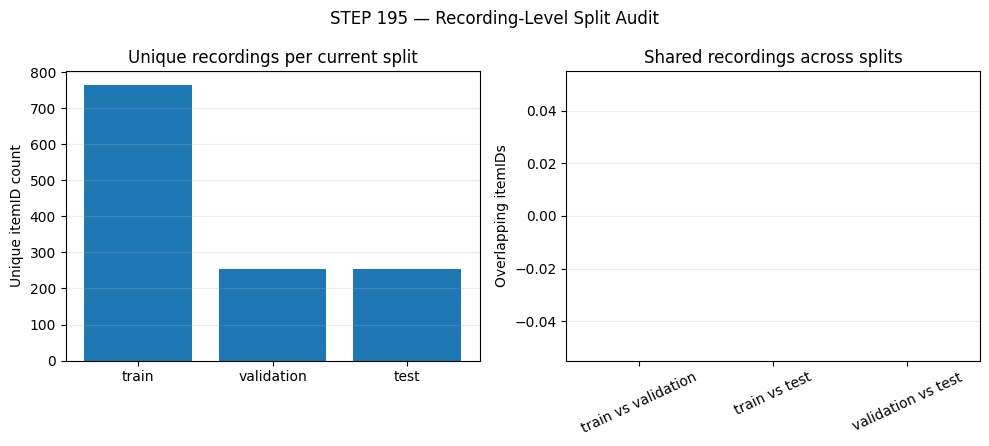


Saved:
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step195_recording_split_audit/step195_current_recording_overlap.csv
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step195_recording_split_audit/step195_recording_split_audit.json
/content/drive/MyDrive/Bioacoustics_Project/data/derived/step195_recording_split_audit/step195_recording_split_audit.png

STEP 195 COMPLETE.


In [ ]:

# ============================================================
# STEP 195 — RECORDING-LEVEL SPLIT OVERLAP AUDIT
# Read-only audit; does not train or modify existing datasets.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
D = ROOT / "data" / "derived"
OUT = D / "step195_recording_split_audit"
OUT.mkdir(parents=True, exist_ok=True)

dataset_path = (
    D / "step182_rebuilt_question5_dataset"
    / "step182_all_rows_with_acoustic_features.csv"
)
df = pd.read_csv(dataset_path)

# Reconstruct the split assignment used in the current NPZ.
npz = np.load(D / "gnn_compact_dataset.npz", allow_pickle=True)
split_idx = {
    "train": np.asarray(npz["train_idx"], dtype=int),
    "validation": np.asarray(npz["val_idx"], dtype=int),
    "test": np.asarray(npz["test_idx"], dtype=int),
}

df["audit_split"] = ""
for split, idx in split_idx.items():
    df.loc[idx, "audit_split"] = split

# itemID appears to be the recording identifier based on the event IDs.
# Check that each source_event's prefix agrees with itemID.
event_prefix = (
    df["source_event"].astype(str)
    .str.extract(r"^([^_]+)_", expand=False)
)
df["event_prefix"] = event_prefix

prefix_check = (
    df["itemID"].astype(str) == df["event_prefix"].astype(str)
)
print("Source-event prefix agrees with itemID:",
      int(prefix_check.sum()), "/", len(df))
print("Mismatches:", int((~prefix_check).sum()))

# Unique recording IDs in each current split.
sets = {
    s: set(df.loc[df["audit_split"] == s, "itemID"].dropna().astype(str))
    for s in ["train", "validation", "test"]
}

split_pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]

overlap_rows = []
for a, b in split_pairs:
    overlap = sorted(sets[a] & sets[b], key=str)
    overlap_rows.append({
        "split_a": a,
        "split_b": b,
        "recordings_a": len(sets[a]),
        "recordings_b": len(sets[b]),
        "overlap_recordings": len(overlap),
        "overlap_fraction_of_split_a": len(overlap) / max(1, len(sets[a])),
        "overlap_fraction_of_split_b": len(overlap) / max(1, len(sets[b])),
        "example_overlapping_itemIDs": ", ".join(overlap[:20]),
    })

overlap_df = pd.DataFrame(overlap_rows)

print("\nCURRENT SPLIT — RECORDING COUNTS")
for s in ["train", "validation", "test"]:
    print(f"{s}: {len(sets[s]):,} unique itemIDs")

print("\nCURRENT SPLIT — PAIRWISE OVERLAP")
display(overlap_df)

# Recording-level split file candidates already present in the project.
candidate_paths = [
    D / "gnn_recording_splits.csv",
    D / "gnn_recording_splits_coverage_safe.csv",
    D / "step182_rebuilt_question5_dataset"
      / "gnn_recording_splits_coverage_safe.csv",
]

metadata_summaries = []
metadata_tables = {}

for path in candidate_paths:
    if not path.exists():
        continue

    table = pd.read_csv(path)
    metadata_tables[str(path)] = table
    print(f"\n=== {path.relative_to(ROOT)} ===")
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    display(table.head(8))

    # Identify columns that might encode recording ID and split.
    id_candidates = [
        c for c in table.columns
        if c.lower() in {"itemid", "recording_id", "recording", "recordingid"}
        or "recording_id" in c.lower()
    ]
    split_candidates = [
        c for c in table.columns
        if "split" in c.lower() or "partition" in c.lower()
    ]

    metadata_summaries.append({
        "path": str(path),
        "rows": len(table),
        "columns": table.columns.tolist(),
        "possible_recording_id_columns": id_candidates,
        "possible_split_columns": split_candidates,
    })

# Save audit outputs.
overlap_path = OUT / "step195_current_recording_overlap.csv"
overlap_df.to_csv(overlap_path, index=False)

prefix_report = {
    "rows": int(len(df)),
    "unique_itemIDs": int(df["itemID"].nunique()),
    "source_event_prefix_matches_itemID": int(prefix_check.sum()),
    "source_event_prefix_mismatches": int((~prefix_check).sum()),
    "unique_recordings_by_current_split": {
        s: int(len(sets[s])) for s in sets
    },
    "pairwise_recording_overlap": overlap_rows,
    "existing_split_metadata": metadata_summaries,
}

with open(OUT / "step195_recording_split_audit.json", "w") as f:
    json.dump(prefix_report, f, indent=2)

# Figure: unique recording counts and overlap counts.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

axes[0].bar(list(sets.keys()), [len(sets[s]) for s in sets])
axes[0].set_title("Unique recordings per current split")
axes[0].set_ylabel("Unique itemID count")
axes[0].grid(axis="y", alpha=0.25)

labels = [
    f"{r['split_a']} vs {r['split_b']}"
    for r in overlap_rows
]
counts = [r["overlap_recordings"] for r in overlap_rows]
axes[1].bar(labels, counts)
axes[1].set_title("Shared recordings across splits")
axes[1].set_ylabel("Overlapping itemIDs")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("STEP 195 — Recording-Level Split Audit")
fig.tight_layout()
fig_path = OUT / "step195_recording_split_audit.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(overlap_path)
print(OUT / "step195_recording_split_audit.json")
print(fig_path)
print("\nSTEP 195 COMPLETE.")


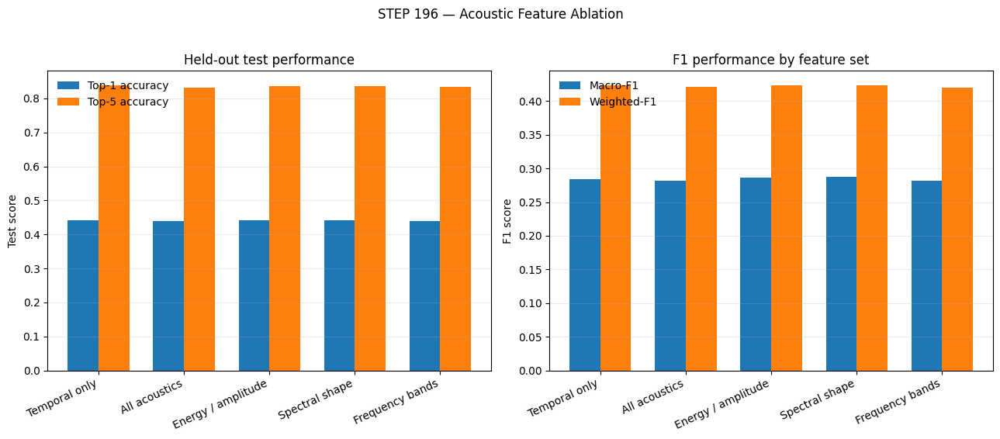

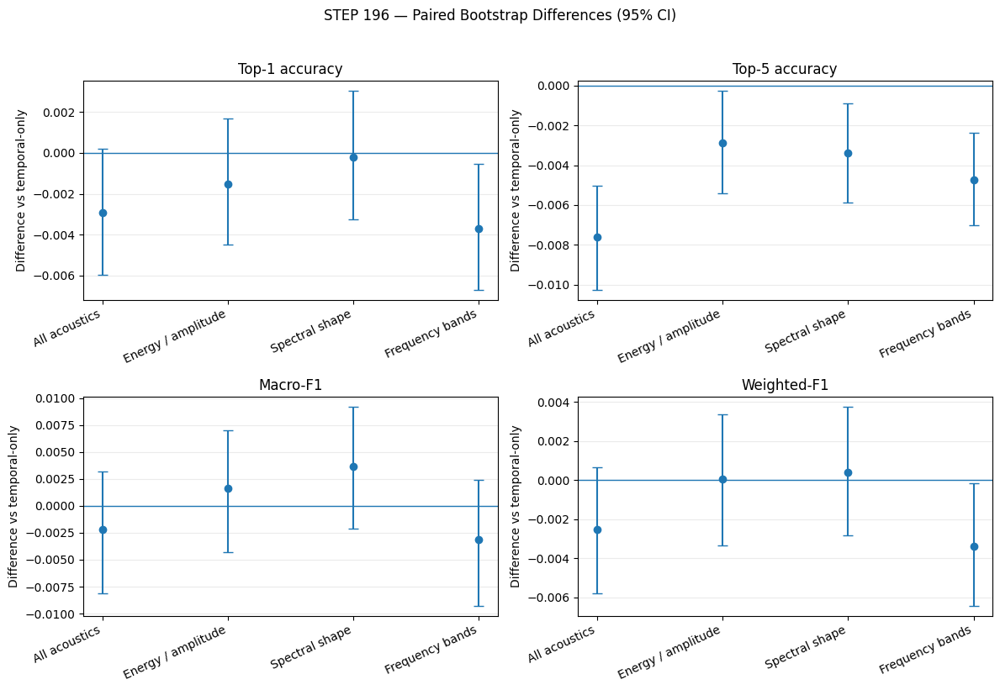

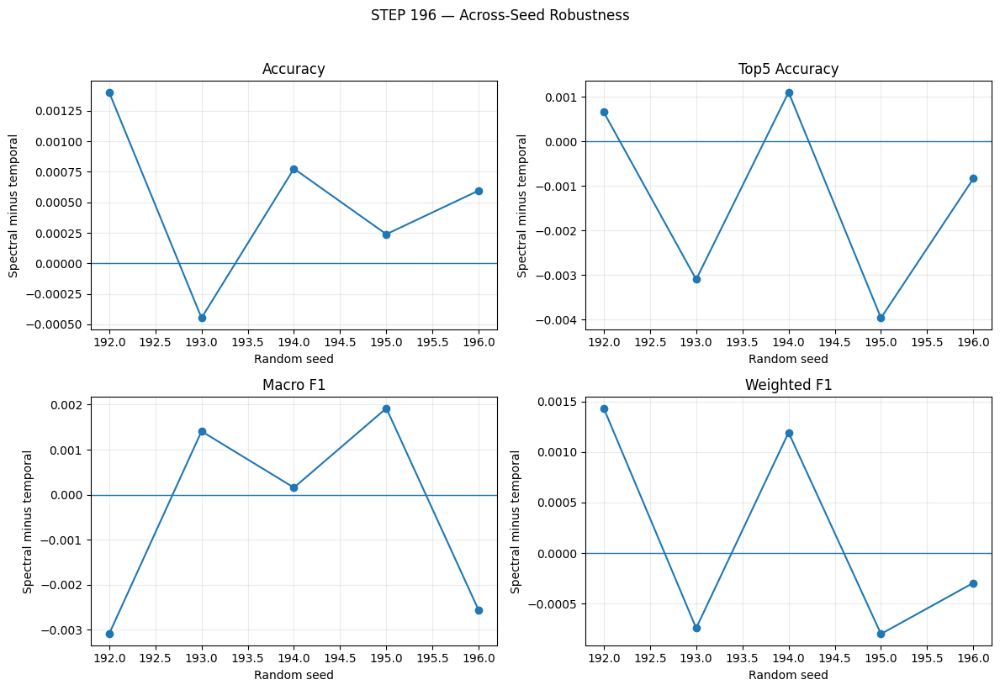


STEP 196 COMPLETE
Report: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step196_research_summary/step196_research_results_summary.md
Ablation figure: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step196_research_summary/step196_acoustic_ablation_summary.png
Bootstrap figure: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step196_research_summary/step196_paired_confidence_intervals.png
Seed robustness figure: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step196_research_summary/step196_seed_robustness.png
Output folder: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step196_research_summary


In [ ]:

# ============================================================
# STEP 196 — RESEARCH RESULTS SUMMARY AND FIGURES
# Consolidates existing outputs; no model training.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
D = ROOT / "data" / "derived"
OUT = D / "step196_research_summary"
OUT.mkdir(parents=True, exist_ok=True)

# ---------- Locate existing outputs ----------
p189 = D / "step189_paired_test_comparison"
p190 = D / "step190_acoustic_ablation"
p192 = D / "step192_seed_robustness"
p195 = D / "step195_recording_split_audit"

def read_csv_if_exists(path):
    if path.exists():
        return pd.read_csv(path)
    print("Not found:", path)
    return None

def read_json_if_exists(path):
    if path.exists():
        with open(path) as f:
            return json.load(f)
    print("Not found:", path)
    return None

step189 = read_json_if_exists(
    p189 / "step189_paired_comparison_summary.json"
)
step190 = read_csv_if_exists(
    p190 / "step190_ablation_results.csv"
)
step191 = read_csv_if_exists(
    p190 / "step191_paired_bootstrap_comparisons.csv"
)
step192_results = read_csv_if_exists(
    p192 / "step192_seed_results.csv"
)
step192_diffs = read_csv_if_exists(
    p192 / "step192_paired_seed_differences.csv"
)
step195 = read_json_if_exists(
    p195 / "step195_recording_split_audit.json"
)

# ---------- Save consolidated metrics ----------
if step190 is not None:
    step190.to_csv(
        OUT / "step196_acoustic_ablation_metrics.csv", index=False
    )

if step191 is not None:
    step191.to_csv(
        OUT / "step196_paired_bootstrap_comparisons.csv", index=False
    )

if step192_results is not None:
    step192_results.to_csv(
        OUT / "step196_seed_results.csv", index=False
    )

if step192_diffs is not None:
    step192_diffs.to_csv(
        OUT / "step196_seed_differences.csv", index=False
    )

# ---------- Figure 1: main ablation results ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

if step190 is not None:
    required = {"model", "accuracy", "top5_accuracy"}
    if required.issubset(step190.columns):
        labels = step190["model"].tolist()
        x = np.arange(len(labels))
        width = 0.36

        axes[0].bar(
            x - width/2, step190["accuracy"], width,
            label="Top-1 accuracy"
        )
        axes[0].bar(
            x + width/2, step190["top5_accuracy"], width,
            label="Top-5 accuracy"
        )
        axes[0].set_xticks(x)
        axes[0].set_xticklabels(labels, rotation=25, ha="right")
        axes[0].set_ylabel("Test score")
        axes[0].set_title("Held-out test performance")
        axes[0].legend(frameon=False)
        axes[0].grid(axis="y", alpha=0.25)

    # F1 metrics.
    if {"model", "macro_f1", "weighted_f1"}.issubset(step190.columns):
        labels = step190["model"].tolist()
        x = np.arange(len(labels))
        width = 0.36
        axes[1].bar(
            x - width/2, step190["macro_f1"], width,
            label="Macro-F1"
        )
        axes[1].bar(
            x + width/2, step190["weighted_f1"], width,
            label="Weighted-F1"
        )
        axes[1].set_xticks(x)
        axes[1].set_xticklabels(labels, rotation=25, ha="right")
        axes[1].set_ylabel("F1 score")
        axes[1].set_title("F1 performance by feature set")
        axes[1].legend(frameon=False)
        axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("STEP 196 — Acoustic Feature Ablation", y=1.02)
fig.tight_layout()
ablation_fig = OUT / "step196_acoustic_ablation_summary.png"
fig.savefig(ablation_fig, dpi=300, bbox_inches="tight")
plt.show()

# ---------- Figure 2: paired bootstrap intervals ----------
if step191 is not None:
    needed = {
        "model", "metric", "difference", "ci95_low", "ci95_high"
    }
    if needed.issubset(step191.columns):
        metric_order = [
            "accuracy", "top5_accuracy", "macro_f1", "weighted_f1"
        ]
        titles = {
            "accuracy": "Top-1 accuracy",
            "top5_accuracy": "Top-5 accuracy",
            "macro_f1": "Macro-F1",
            "weighted_f1": "Weighted-F1",
        }

        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        for ax, metric in zip(axes.flat, metric_order):
            sub = step191[step191["metric"] == metric].copy()
            if sub.empty:
                ax.set_visible(False)
                continue

            x = np.arange(len(sub))
            diff = sub["difference"].to_numpy()
            low = diff - sub["ci95_low"].to_numpy()
            high = sub["ci95_high"].to_numpy() - diff

            ax.errorbar(
                x, diff, yerr=np.vstack([low, high]),
                fmt="o", capsize=4
            )
            ax.axhline(0, linewidth=1)
            ax.set_xticks(x)
            ax.set_xticklabels(
                sub["model"], rotation=25, ha="right"
            )
            ax.set_title(titles[metric])
            ax.set_ylabel("Difference vs temporal-only")
            ax.grid(axis="y", alpha=0.25)

        fig.suptitle(
            "STEP 196 — Paired Bootstrap Differences (95% CI)", y=1.02
        )
        fig.tight_layout()
        ci_fig = OUT / "step196_paired_confidence_intervals.png"
        fig.savefig(ci_fig, dpi=300, bbox_inches="tight")
        plt.show()
    else:
        ci_fig = None
else:
    ci_fig = None

# ---------- Figure 3: seed robustness ----------
if step192_results is not None:
    required = {"seed", "model"}
    metrics = ["accuracy", "top5_accuracy", "macro_f1", "weighted_f1"]

    if required.issubset(step192_results.columns):
        available = [m for m in metrics if m in step192_results.columns]
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))

        for ax, metric in zip(axes.flat, available):
            wide = step192_results.pivot(
                index="seed", columns="model", values=metric
            )
            temporal = "Temporal only"
            spectral = "Temporal + spectral shape"

            if temporal in wide.columns and spectral in wide.columns:
                delta = wide[spectral] - wide[temporal]
                ax.axhline(0, linewidth=1)
                ax.plot(delta.index, delta.values, marker="o")
                ax.set_title(metric.replace("_", " ").title())
                ax.set_xlabel("Random seed")
                ax.set_ylabel("Spectral minus temporal")
                ax.grid(alpha=0.25)
            else:
                ax.set_visible(False)

        fig.suptitle("STEP 196 — Across-Seed Robustness", y=1.02)
        fig.tight_layout()
        seed_fig = OUT / "step196_seed_robustness.png"
        fig.savefig(seed_fig, dpi=300, bbox_inches="tight")
        plt.show()
    else:
        seed_fig = None
else:
    seed_fig = None

# ---------- Build research summary ----------
lines = [
    "# Research results summary",
    "",
    "## Research question",
    "",
    "Do audio-derived environmental/acoustic features improve prediction "
    "of which species vocalizes next?",
    "",
    "## Data and evaluation",
    "",
    "- The reconstructed dataset contains 170,530 rows and 95 target classes.",
    "- The established split contains 103,738 training rows, "
    "33,252 validation rows, and 33,540 test rows.",
    "- STEP 195 verified that source-event prefixes match itemID for every row.",
    "- The current split contains 764 training, 254 validation, and "
    "254 test recording IDs, with zero pairwise recording overlap.",
    "- Recording independence assumes itemID corresponds to the original "
    "recording identity; this should be confirmed against source metadata.",
    "",
    "## Main acoustic ablation results",
    "",
]

if step190 is not None:
    cols = [
        c for c in [
            "model", "acoustic_feature_count", "accuracy",
            "top5_accuracy", "macro_f1", "weighted_f1"
        ] if c in step190.columns
    ]
    lines.append(step190[cols].round(5).to_markdown(index=False))
else:
    lines.append("STEP 190 metrics CSV was not found.")

lines += [
    "",
    "## Paired uncertainty analysis",
    "",
]

if step191 is not None:
    cols = [
        c for c in [
            "model", "metric", "difference",
            "ci95_low", "ci95_high", "ci_excludes_zero"
        ] if c in step191.columns
    ]
    lines.append(step191[cols].round(6).to_markdown(index=False))
else:
    lines.append("STEP 191 comparison CSV was not found.")

lines += [
    "",
    "## Across-seed robustness",
    "",
]

if step192_diffs is not None:
    lines.append(step192_diffs.round(6).to_markdown(index=False))
else:
    lines.append("STEP 192 seed-difference CSV was not found.")

lines += [
    "",
    "## Interpretation",
    "",
    "In the tested runs, adding all acoustic features did not improve "
    "overall top-1 or top-5 accuracy relative to the temporal-only model. "
    "Spectral-shape features produced a small macro-F1 increase in the "
    "single-run ablation, but the paired bootstrap interval included zero. "
    "The five-seed comparison did not establish a consistent improvement.",
    "",
    "These findings are specific to the tested features, architecture, "
    "splits, and training procedure. They do not establish that acoustic "
    "information is never useful. Bootstrap intervals quantify test-row "
    "sampling uncertainty conditional on the fitted models; they do not "
    "replace replication across seeds or account automatically for "
    "all recording-level dependence.",
    "",
    "## Conclusion",
    "",
    "The current experiments provide insufficient evidence that the tested "
    "past-only acoustic features improve next-species prediction overall. "
    "Temporal context remains the strongest practical baseline in these "
    "experiments. The spectral-shape macro-F1 result is a possible lead "
    "for further investigation, not a confirmed improvement.",
    "",
    "## Figures",
    "",
    "- `step196_acoustic_ablation_summary.png`",
    "- `step196_paired_confidence_intervals.png` (if generated)",
    "- `step196_seed_robustness.png` (if generated)",
    "",
]

report_path = OUT / "step196_research_results_summary.md"
report_path.write_text("\n".join(lines), encoding="utf-8")

print("\nSTEP 196 COMPLETE")
print("Report:", report_path)
print("Ablation figure:", ablation_fig)
print("Bootstrap figure:", ci_fig)
print("Seed robustness figure:", seed_fig)
print("Output folder:", OUT)


In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
CANONICAL = DERIVED / "step182_rebuilt_question5_dataset" / "step182_all_rows_with_acoustic_features.csv"
NPZ_PATH = DERIVED / "gnn_compact_dataset.npz"
OUT = DERIVED / "step197_recording_split_verification"
OUT.mkdir(parents=True, exist_ok=True)

def stop(message):
    raise RuntimeError(message)

# 1. Load canonical rows and the exact model split indices.
df = pd.read_csv(CANONICAL)
data = np.load(NPZ_PATH, allow_pickle=True)

required = {"itemID", "source_event", "target_event"}
if not required.issubset(df.columns):
    stop(f"Canonical CSV missing columns: {sorted(required - set(df.columns))}")

n = len(df)
split_arrays = {}
for split in ("train", "val", "test"):
    key = f"{split}_idx"
    if key not in data.files:
        stop(f"NPZ does not contain {key}")
    idx = np.asarray(data[key], dtype=int).ravel()
    if len(idx) and (idx.min() < 0 or idx.max() >= n):
        stop(f"{key} contains indices outside the canonical CSV")
    if len(np.unique(idx)) != len(idx):
        stop(f"{key} contains duplicate indices")
    split_arrays[split] = idx

# Verify row indices do not overlap.
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = np.intersect1d(split_arrays[a], split_arrays[b])
    print(f"Row overlap {a}/{b}: {len(overlap)}")

row_split = np.full(n, "unassigned", dtype=object)
for split, idx in split_arrays.items():
    row_split[idx] = split

print("\nNPZ split row counts:")
print(pd.Series(row_split).value_counts().to_string())

# 2. Derive recording IDs from source_event and compare to itemID.
item = df["itemID"].astype("string").str.strip()
event_prefix = (
    df["source_event"].astype("string")
    .str.strip()
    .str.extract(r"^([^_]+)_", expand=False)
)
prefix_match = item.eq(event_prefix).fillna(False)

print("\nRecording identifier checks:")
print(f"Rows: {n:,}")
print(f"Missing itemID: {int(item.isna().sum()):,}")
print(f"Missing source-event prefix: {int(event_prefix.isna().sum()):,}")
print(f"itemID/prefix matches: {int(prefix_match.sum()):,}")
print(f"itemID/prefix mismatches: {int((~prefix_match).sum()):,}")
print(f"Unique itemIDs: {item.nunique(dropna=True):,}")

# 3. Check that each recording belongs to exactly one NPZ split.
audit_df = pd.DataFrame({
    "itemID": item,
    "split": row_split
})
recording_split_counts = (
    audit_df.groupby("itemID", dropna=False)["split"]
    .nunique()
)
mixed_recordings = recording_split_counts[recording_split_counts > 1]

print("\nRecordings spanning multiple NPZ splits:",
      len(mixed_recordings))

recording_assignment = (
    audit_df.groupby("itemID", dropna=False)
    .agg(
        split=("split", lambda s: s.iloc[0] if s.nunique() == 1 else "MIXED"),
        rows=("split", "size"),
        n_splits=("split", "nunique")
    )
    .reset_index()
)
print("\nUnique recordings per split:")
print(
    recording_assignment[recording_assignment["split"] != "MIXED"]
    .groupby("split")["itemID"].nunique()
    .to_string()
)

# 4. Find saved split files and compare assignments by itemID.
candidates = [
    DERIVED / "gnn_recording_splits.csv",
    DERIVED / "gnn_recording_splits_coverage_safe.csv",
    DERIVED / "step182_rebuilt_question5_dataset" /
        "gnn_recording_splits_coverage_safe.csv",
]

comparisons = []
for path in candidates:
    if not path.exists():
        print(f"\nSaved split file not found: {path}")
        continue

    saved = pd.read_csv(path)
    if not {"itemID", "split"}.issubset(saved.columns):
        print(f"\nSkipping file without itemID/split columns: {path}")
        continue

    saved["itemID"] = saved["itemID"].astype("string").str.strip()
    saved["split"] = saved["split"].astype("string").str.strip().str.lower()

    # Normalize common validation naming.
    saved["split"] = saved["split"].replace({
        "validation": "val", "valid": "val"
    })

    merged = recording_assignment.merge(
        saved[["itemID", "split"]].drop_duplicates(),
        on="itemID",
        how="outer",
        suffixes=("_npz", "_saved"),
        indicator=True
    )
    both = merged["_merge"].eq("both")
    comparable = both & merged["split_npz"].ne("MIXED")
    mismatch = comparable & merged["split_npz"].ne(merged["split_saved"])

    result = {
        "file": str(path),
        "saved_rows": int(len(saved)),
        "saved_unique_itemIDs": int(saved["itemID"].nunique()),
        "matched_itemIDs": int(both.sum()),
        "npz_only_itemIDs": int((merged["_merge"] == "left_only").sum()),
        "saved_only_itemIDs": int((merged["_merge"] == "right_only").sum()),
        "comparable_itemIDs": int(comparable.sum()),
        "assignment_mismatches": int(mismatch.sum()),
    }
    comparisons.append(result)
    print(f"\nSaved split comparison: {path.name}")
    print(json.dumps(result, indent=2))

    merged.to_csv(
        OUT / f"{path.stem}_assignment_comparison.csv",
        index=False
    )

# 5. Save detailed audit and a machine-readable summary.
recording_assignment.to_csv(
    OUT / "step197_recording_assignments.csv", index=False
)

summary = {
    "canonical_rows": int(n),
    "npz_split_row_counts": {
        k: int(len(v)) for k, v in split_arrays.items()
    },
    "unassigned_rows": int((row_split == "unassigned").sum()),
    "itemID_prefix_matches": int(prefix_match.sum()),
    "itemID_prefix_mismatches": int((~prefix_match).sum()),
    "unique_itemIDs": int(item.nunique(dropna=True)),
    "recordings_spanning_multiple_splits": int(len(mixed_recordings)),
    "saved_split_comparisons": comparisons,
    "interpretation_note": (
        "Matching source_event prefixes supports identifier consistency, "
        "but does not independently prove itemID represents the original "
        "physical recording. Verify against source metadata if available."
    )
}
with open(OUT / "step197_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nSTEP 197 COMPLETE")
print("Summary:", OUT / "step197_summary.json")
print("Outputs:", OUT)
print("\nIMPORTANT: Identifier-prefix agreement alone does not prove "
      "recording identity. The saved split comparison checks assignments.")


Row overlap train/val: 0
Row overlap train/test: 0
Row overlap val/test: 0

NPZ split row counts:
train    103738
test      33540
val       33252

Recording identifier checks:
Rows: 170,530
Missing itemID: 0
Missing source-event prefix: 0
itemID/prefix matches: 170,530
itemID/prefix mismatches: 0
Unique itemIDs: 1,272

Recordings spanning multiple NPZ splits: 0

Unique recordings per split:
split
test     254
train    764
val      254

Saved split comparison: gnn_recording_splits.csv
{
  "file": "/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits.csv",
  "saved_rows": 1272,
  "saved_unique_itemIDs": 1272,
  "matched_itemIDs": 1272,
  "npz_only_itemIDs": 0,
  "saved_only_itemIDs": 0,
  "comparable_itemIDs": 1272,
  "assignment_mismatches": 711
}

Saved split comparison: gnn_recording_splits_coverage_safe.csv
{
  "file": "/content/drive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits_coverage_safe.csv",
  "saved_rows": 1272,
  "saved_unique_itemI

In [ ]:

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"

paths = {
    "temporal_baseline": DERIVED / "step181_temporal_mlp_test_inference" /
        "step181_temporal_mlp_test_predictions.csv",
    "acoustic_ablation": DERIVED / "step190_acoustic_ablation" /
        "step190_ablation_test_predictions.csv",
    "ablation_metrics": DERIVED / "step190_acoustic_ablation" /
        "step190_ablation_results.csv",
    "canonical_data": DERIVED / "step182_rebuilt_question5_dataset" /
        "step182_all_rows_with_acoustic_features.csv",
    "split_audit": DERIVED / "step197_recording_split_verification" /
        "step197_summary.json",
}

for name, path in paths.items():
    print("\n" + "=" * 75)
    print(name, ":", path)
    if not path.exists():
        print("FILE NOT FOUND")
        continue

    if path.suffix.lower() == ".json":
        obj = json.loads(path.read_text())
        print(json.dumps(obj, indent=2)[:2500])
        continue

    df = pd.read_csv(path, nrows=5)
    print("Columns:", df.columns.tolist())
    print("Sample:")
    print(df.to_string(index=False, max_cols=12))

    if name != "canonical_data":
        print("Full file rows:", sum(1 for _ in open(path)) - 1)

print("\nSTEP 198 prediction-file inspection complete.")



temporal_baseline : /content/drive/MyDrive/Bioacoustics_Project/data/derived/step181_temporal_mlp_test_inference/step181_temporal_mlp_test_predictions.csv
Columns: ['itemID', 'source_event', 'target_event', 'target_species', 'test_npz_row_index', 'true_target_idx', 'predicted_target_idx', 'true_target_species_from_npz', 'predicted_target_species_mlp', 'correct', 'top5_predicted_species']
Sample:
 itemID source_event target_event target_species  test_npz_row_index  true_target_idx  predicted_target_idx true_target_species_from_npz predicted_target_species_mlp  correct           top5_predicted_species
   1701   1701_E0002   1701_E0003           BTBW                   0               17                    64                         BTBW                         OVEN    False OVEN | REVI | EAWP | BTNW | HETH
   1701   1701_E0003   1701_E0004           OVEN                   1               64                    64                         OVEN                         OVEN     True OVEN | EA

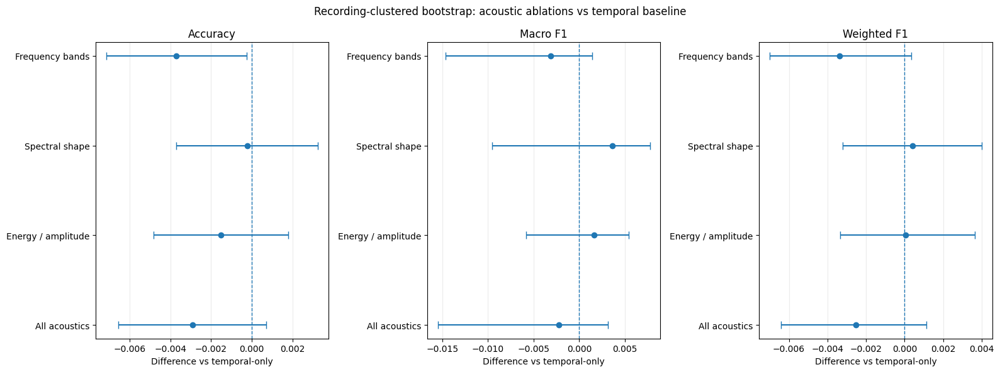


STEP 198 COMPLETE
Test rows: 33540
Test recordings: 254
Results: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step198_recording_cluster_bootstrap/step198_recording_clustered_bootstrap.csv
Figure: /content/drive/MyDrive/Bioacoustics_Project/data/derived/step198_recording_cluster_bootstrap/step198_recording_clustered_bootstrap.png

Differences and recording-clustered 95% intervals:
                            comparison              model      metric  baseline_point  model_point  difference  cluster_bootstrap_ci_low  cluster_bootstrap_ci_high  bootstrap_replicates  recording_clusters  test_rows
     All acoustics minus Temporal only      All acoustics    accuracy         0.44252      0.43959    -0.00292                  -0.00655                    0.00072                  2000                 254      33540
     All acoustics minus Temporal only      All acoustics    macro_f1         0.28442      0.28222    -0.00220                  -0.01547                    0.00314       

In [ ]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Bioacoustics_Project")
DERIVED = ROOT / "data" / "derived"
OUT = DERIVED / "step198_recording_cluster_bootstrap"
OUT.mkdir(parents=True, exist_ok=True)

PRED_PATH = (
    DERIVED / "step190_acoustic_ablation" /
    "step190_ablation_test_predictions.csv"
)
CANONICAL_PATH = (
    DERIVED / "step182_rebuilt_question5_dataset" /
    "step182_all_rows_with_acoustic_features.csv"
)

# Increase to 2,000-5,000 for a final, more stable interval estimate.
N_BOOT = 2000
SEED = 198

pred = pd.read_csv(PRED_PATH)
canonical = pd.read_csv(CANONICAL_PATH)

required_pred = {
    "test_npz_row_index", "true_target_idx",
    "predicted_target_idx", "model"
}
if not required_pred.issubset(pred.columns):
    raise ValueError(f"Missing prediction columns: {required_pred - set(pred.columns)}")

if "itemID" not in canonical.columns:
    raise ValueError("Canonical dataset has no itemID column.")

# Link prediction rows to their recording IDs using the canonical NPZ row order.
# The saved test_npz_row_index values are indices into the NPZ dataset rows.
npz = np.load(DERIVED / "gnn_compact_dataset.npz", allow_pickle=True)
n_rows = len(canonical)
if len(canonical) != len(npz["target_idx"]):
    raise ValueError(
        "Canonical CSV row count differs from NPZ target_idx length. "
        "Do not bootstrap until row alignment is verified."
    )

row_to_item = canonical["itemID"].astype(str).to_numpy()
pred["itemID"] = pred["test_npz_row_index"].map(
    lambda i: row_to_item[int(i)]
)

if pred["itemID"].isna().any():
    raise ValueError("Some prediction rows could not be mapped to itemID.")

# Validate that predictions agree with the true NPZ target labels.
idx = pred["test_npz_row_index"].to_numpy(dtype=int)
true_idx = pred["true_target_idx"].to_numpy(dtype=int)
if not np.array_equal(true_idx, np.asarray(npz["target_idx"])[idx]):
    raise ValueError(
        "Prediction labels do not align with NPZ row indices. "
        "Stop and resolve row alignment before interpreting results."
    )

# Validate that all models predict the same test rows and true labels.
row_keys = ["test_npz_row_index", "true_target_idx"]
for model, g in pred.groupby("model"):
    if g["test_npz_row_index"].duplicated().any():
        raise ValueError(f"Duplicate test rows found for model: {model}")

model_names = list(pred["model"].unique())
if "Temporal only" not in model_names:
    raise ValueError("Temporal-only model missing from ablation predictions.")

wide = None
for model in model_names:
    g = pred[pred["model"] == model][
        ["test_npz_row_index", "true_target_idx",
         "predicted_target_idx", "itemID"]
    ].copy()
    g = g.rename(columns={
        "predicted_target_idx": f"pred::{model}",
        "itemID": f"item::{model}"
    })
    wide = g if wide is None else wide.merge(
        g, on=["test_npz_row_index", "true_target_idx"], how="inner"
    )

if len(wide) != pred[pred["model"] == "Temporal only"].shape[0]:
    raise ValueError("Models do not share an identical test-row set.")

item_cols = [c for c in wide.columns if c.startswith("item::")]
if not all((wide[c] == wide[item_cols[0]]).all() for c in item_cols[1:]):
    raise ValueError("Model-specific recording IDs disagree.")

wide["itemID"] = wide[item_cols[0]].astype(str)
wide["true"] = wide["true_target_idx"].astype(int)

# Recover top-5 correctness from saved top-5 species strings where available.
# For this ablation file, only top-1 predictions are stored. Top-5 cannot be
# reconstructed reliably from class indices alone, so cluster bootstrap here
# focuses on top-1 accuracy and F1 metrics.
model_pred_cols = {m: f"pred::{m}" for m in model_names}

# Cluster-bootstrap metric functions. Macro-F1 is calculated over the global
# set of target classes, with absent classes assigned zero F1 in each replicate.
classes = np.sort(wide["true"].unique())
from sklearn.metrics import f1_score

recordings = wide["itemID"].unique()
rows_by_recording = {
    r: np.flatnonzero(wide["itemID"].to_numpy() == r)
    for r in recordings
}
rng = np.random.default_rng(SEED)

def calc_metrics(frame, pred_col):
    y = frame["true"].to_numpy()
    p = frame[pred_col].to_numpy()
    return {
        "accuracy": float(np.mean(y == p)),
        "macro_f1": float(f1_score(
            y, p, labels=classes, average="macro", zero_division=0
        )),
        "weighted_f1": float(f1_score(
            y, p, labels=classes, average="weighted", zero_division=0
        )),
    }

# Point estimates on the full test set.
point = {m: calc_metrics(wide, model_pred_cols[m]) for m in model_names}
baseline = "Temporal only"
comparisons = [m for m in model_names if m != baseline]
metric_names = ["accuracy", "macro_f1", "weighted_f1"]

# Bootstrap recording IDs with replacement. All rows belonging to a sampled
# recording are included; repeated recordings contribute repeated copies.
boot_diffs = {
    (m, metric): np.empty(N_BOOT, dtype=float)
    for m in comparisons for metric in metric_names
}

for b in range(N_BOOT):
    sampled_recordings = rng.choice(recordings, size=len(recordings), replace=True)
    sampled_rows = np.concatenate([rows_by_recording[r] for r in sampled_recordings])
    sample = wide.iloc[sampled_rows]

    base_m = calc_metrics(sample, model_pred_cols[baseline])
    for model in comparisons:
        model_m = calc_metrics(sample, model_pred_cols[model])
        for metric in metric_names:
            boot_diffs[(model, metric)][b] = model_m[metric] - base_m[metric]

results = []
for model in comparisons:
    model_point = point[model]
    base_point = point[baseline]
    for metric in metric_names:
        diffs = boot_diffs[(model, metric)]
        results.append({
            "comparison": f"{model} minus {baseline}",
            "model": model,
            "metric": metric,
            "baseline_point": base_point[metric],
            "model_point": model_point[metric],
            "difference": model_point[metric] - base_point[metric],
            "cluster_bootstrap_ci_low": float(np.quantile(diffs, 0.025)),
            "cluster_bootstrap_ci_high": float(np.quantile(diffs, 0.975)),
            "bootstrap_replicates": N_BOOT,
            "recording_clusters": int(len(recordings)),
            "test_rows": int(len(wide))
        })

results_df = pd.DataFrame(results)
results_df.to_csv(OUT / "step198_recording_clustered_bootstrap.csv", index=False)

# Figure: differences and recording-clustered 95% CIs.
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for ax, metric in zip(axes, metric_names):
    sub = results_df[results_df["metric"] == metric].copy()
    y = np.arange(len(sub))
    lo = sub["difference"] - sub["cluster_bootstrap_ci_low"]
    hi = sub["cluster_bootstrap_ci_high"] - sub["difference"]
    ax.errorbar(
        sub["difference"], y, xerr=[lo, hi],
        fmt="o", capsize=4
    )
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["model"])
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Difference vs temporal-only")
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Recording-clustered bootstrap: acoustic ablations vs temporal baseline")
fig.tight_layout()
fig.savefig(OUT / "step198_recording_clustered_bootstrap.png", dpi=180, bbox_inches="tight")
plt.show()

summary = {
    "bootstrap_replicates": N_BOOT,
    "seed": SEED,
    "test_rows": int(len(wide)),
    "test_recordings": int(len(recordings)),
    "models": model_names,
    "baseline": baseline,
    "metrics": point,
    "interpretation_caution": (
        "Intervals resample whole test recordings and are conditional on the "
        "already fitted models. They quantify test-recording sampling variation, "
        "not variability across training seeds or model retraining. Macro-F1 "
        "is computed over the observed target classes."
    ),
    "top5_note": (
        "Top-5 was not computed because this ablation prediction file stores "
        "only top-1 class indices. Do not infer top-5 from these columns."
    )
}
with open(OUT / "step198_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nSTEP 198 COMPLETE")
print("Test rows:", len(wide))
print("Test recordings:", len(recordings))
print("Results:", OUT / "step198_recording_clustered_bootstrap.csv")
print("Figure:", OUT / "step198_recording_clustered_bootstrap.png")
print("\nDifferences and recording-clustered 95% intervals:")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.5f}"))


# Research Question 5: Do audio-derived acoustic features improve prediction of who vocalizes next?

## Answer

In this experiment, adding the tested past-only acoustic features did not produce a consistent improvement over the temporal-only baseline. Some feature groups showed small improvements on selected metrics, but these gains were uncertain and did not generalize consistently across random seeds. The evidence therefore does not demonstrate a reliable predictive benefit from the acoustic features evaluated here.

This conclusion applies to the particular acoustic features, models, and evaluation procedure tested. It does not mean that acoustic information is inherently uninformative.

## Methods and evaluation

The task was to predict the species that vocalizes next using a temporal model, then test whether adding audio-derived acoustic summaries improves predictive performance. The tested acoustic feature groups were energy/amplitude, spectral shape, frequency bands, and all acoustic features combined.

The canonical dataset contained **170,530 event rows** and **1,272 unique recording identifiers**. The NPZ dataset was divided into 103,738 training rows, 33,252 validation rows, and 33,540 test rows.

### Recording-level split validation

| Split validation check | Result |
|---|---:|
| Unique recording identifiers (`itemID`) | 1,272 |
| Training recordings | 764 |
| Validation recordings | 254 |
| Test recordings | 254 |
| Recordings appearing in multiple splits | 0 |
| `itemID` and source-event prefix mismatches | 0 |
| Assignment mismatches against coverage-safe split | 0 |

The model assignments matched the saved coverage-safe recording split, and no recording appeared in more than one split. This reduces the risk of data leakage caused by the same recording appearing in both training and test data. The `itemID` prefix check supports identifier consistency, although confirmation against original source metadata would provide stronger evidence that each ID corresponds to a physical recording.

## Held-out test performance

The table summarizes performance on the held-out test set.

| Model | Top-1 accuracy | Top-5 accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|---:|
| Temporal only | 0.4425 | 0.8391 | 0.2844 | 0.4233 |
| All acoustics | 0.4396 | 0.8315 | 0.2822 | 0.4208 |
| Energy / amplitude | 0.4410 | 0.8363 | 0.2861 | 0.4234 |
| Spectral shape | 0.4423 | 0.8357 | 0.2881 | 0.4237 |
| Frequency bands | 0.4388 | 0.8344 | 0.2813 | 0.4200 |

The temporal-only baseline achieved **44.25% Top-1 accuracy** and **83.91% Top-5 accuracy**. Adding all acoustic features reduced Top-1 accuracy to 43.96% and Top-5 accuracy to 83.15%.

Spectral-shape features achieved the highest macro-F1 score among the ablation models, at 0.2881 compared with 0.2844 for the temporal-only model. However, this model did not improve Top-1 or Top-5 accuracy, and the statistical analyses did not establish that the macro-F1 increase was reliable.

## Definitions of key terms

- **Temporal-only baseline:** The reference model that uses temporal or event-history information without the additional acoustic feature groups. It establishes the performance against which acoustic models are compared.

- **Acoustic features:** Numerical summaries extracted from audio. In this experiment, these included energy and amplitude, spectral shape, and the relative distribution of energy across frequency bands.

- **Top-1 accuracy:** The proportion of test events for which the model's single highest-ranked species prediction matches the true next species.

- **Top-5 accuracy:** The proportion of test events for which the true next species appears among the model's five highest-ranked predictions.

- **Macro-F1:** The F1 score calculated separately for each species and then averaged across species. Each species receives equal weight, making this metric useful when species have different numbers of observations.

- **Weighted-F1:** The F1 score averaged across species while weighting each species according to its number of true observations. More frequently observed species therefore have greater influence on the overall score.

- **Ablation study:** An experiment that removes or adds groups of model inputs to assess whether those features contribute to predictive performance.

- **Confidence interval (CI):** An interval that expresses uncertainty around an estimated difference. Here, the 95% bootstrap interval describes uncertainty from resampling held-out recordings, conditional on the fitted models.

- **Recording-clustered bootstrap:** A resampling procedure that samples whole recordings rather than individual event rows. All selected events from a recording are retained together, accounting for the fact that events from the same recording may be related.

- **Random seed:** A value that controls random operations during model training. Repeating training with different seeds helps reveal whether results depend on a particular random initialization or training run.

- **Data leakage:** The use of information during training or evaluation that would not legitimately be available for the prediction task. Splitting data by recording helps prevent a model from being evaluated on events from recordings it has already seen during training.

## Recording-clustered uncertainty analysis

To account for dependence among events from the same recording, the test set was evaluated using a recording-clustered bootstrap with 254 held-out recordings and 2,000 bootstrap replicates.

The differences below are calculated as **acoustic model minus temporal-only model**. Positive values favor the acoustic model; negative values favor the temporal-only baseline.

| Acoustic model | Metric | Difference | 95% recording-clustered CI |
|---|---|---:|---:|
| All acoustics | Accuracy | -0.00292 | [-0.00655, +0.00072] |
| All acoustics | Macro-F1 | -0.00220 | [-0.01547, +0.00314] |
| All acoustics | Weighted-F1 | -0.00252 | [-0.00641, +0.00114] |
| Energy / amplitude | Accuracy | -0.00152 | [-0.00482, +0.00178] |
| Energy / amplitude | Macro-F1 | +0.00164 | [-0.00583, +0.00541] |
| Energy / amplitude | Weighted-F1 | +0.00006 | [-0.00336, +0.00363] |
| Spectral shape | Accuracy | -0.00021 | [-0.00370, +0.00325] |
| Spectral shape | Macro-F1 | +0.00363 | [-0.00953, +0.00773] |
| Spectral shape | Weighted-F1 | +0.00040 | [-0.00322, +0.00399] |
| Frequency bands | Accuracy | -0.00373 | [-0.00715, -0.00025] |
| Frequency bands | Macro-F1 | -0.00316 | [-0.01465, +0.00145] |
| Frequency bands | Weighted-F1 | -0.00338 | [-0.00699, +0.00033] |

The 95% confidence intervals include zero for all reported metrics for the all-acoustics, energy/amplitude, and spectral-shape models. Thus, their observed differences are uncertain under the recording-clustered bootstrap.

For frequency-band features, the Top-1 accuracy interval lies entirely below zero, indicating lower accuracy than the temporal-only baseline in this fitted-model comparison. The estimated decrease is small, however, and should be interpreted alongside the other metrics and analyses.

These intervals quantify uncertainty from sampling test recordings, conditional on the fitted models. They do not measure uncertainty caused by retraining the models with different random seeds.

Top-5 accuracy was not recalculated in this bootstrap because the saved ablation prediction file contained only top-1 class predictions. The Top-5 figures in the performance table come from the saved ablation evaluation results.

## Across-seed robustness

A five-seed experiment compared the temporal-only model with the temporal-plus-spectral-shape model. The observed differences varied in direction across random seeds.

The mean Top-1 accuracy difference was approximately **+0.05 percentage points**, with an improvement in four of the five seeds. However, Top-5 accuracy improved in only two of five seeds, macro-F1 improved in three of five seeds, and weighted-F1 improved in two of five seeds.

These results indicate that the small gains observed for spectral-shape features were not consistent across evaluation metrics and training runs. They do not provide robust evidence of a general predictive improvement.

## Limitations

1. **Feature coverage:** The experiment tested a specific set of past-only acoustic summaries. Other audio representations may contain information not captured by these features.

2. **Model dependence:** Results apply to the temporal model and acoustic variants evaluated. Other architectures, history windows, or feature combinations could perform differently.

3. **Recording-level uncertainty:** The bootstrap accounts for sampling variation across held-out recordings but conditions on the fitted models. It does not replace repeated training or evaluation on an independent dataset.

4. **Top-5 uncertainty:** Top-5 accuracy was reported from the saved ablation metrics but was not recalculated using the recording-clustered bootstrap because full ranked predictions were not available in the ablation prediction file.

5. **Recording metadata:** The split audit confirms consistency between `itemID`, source-event prefixes, and the coverage-safe split assignments. Independent confirmation of recording identity using original source metadata remains desirable.

6. **Interpretation of null results:** Failure to demonstrate improvement is not proof that acoustic information has no predictive value. It means that these features did not establish a reliable incremental benefit under the current experimental design.

## Conclusion

The current evidence does not demonstrate that the tested past-only audio-derived acoustic features improve prediction of who vocalizes next beyond the temporal-only baseline.

The combined acoustic model performed slightly worse on Top-1 and Top-5 accuracy. Energy/amplitude and spectral-shape features produced small improvements in selected F1 metrics, but these gains were uncertain under recording-clustered resampling and were not consistently reproduced across random seeds. Frequency-band features performed worse on Top-1 accuracy, with the recording-clustered confidence interval indicating a small decrease in this comparison.

**The most defensible answer to Research Question 5 is that these particular acoustic features provide no established incremental predictive benefit in the present experiment.** Future work could test richer acoustic representations, longer context windows, and alternative model architectures while maintaining recording-level separation and evaluating uncertainty across both recordings and training seeds.

## Reproducibility and saved outputs

The analysis outputs are saved in the project's `data/derived/` directory:

- `step197_recording_split_verification/step197_summary.json` — recording-level split audit.
- `step198_recording_cluster_bootstrap/step198_recording_clustered_bootstrap.csv` — clustered bootstrap estimates and confidence intervals.
- `step198_recording_cluster_bootstrap/step198_recording_clustered_bootstrap.png` — clustered bootstrap comparison figure.
- `step190_acoustic_ablation/step190_ablation_results.csv` — held-out ablation performance metrics.
- `step192_seed_robustness/` — across-seed robustness results and associated figures.


In [ ]:
# ============================================================
# CONNECT GOOGLE DRIVE
# ============================================================

from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Set the project directory
PROJECT_DIR = '/content/drive/MyDrive'

# Confirm that Drive is connected
print("Google Drive connected:", os.path.exists(PROJECT_DIR))
print("MyDrive contents:")
print(os.listdir(PROJECT_DIR)[:20])

Mounted at /content/drive
Google Drive connected: True
MyDrive contents:
['Getting started.pdf', 'Mina: Soccer', 'Campfire', 'Dad and Mina', 'Halloween 2013', 'Mina', 'mina and i ', 'hardwood placerville', 'Pool', 'Pool 2', 'NOLA', 'new floors placerville office', 'Part One: Short Answers .gdoc', 'Collage .gdoc', 'collage .gdoc', 'collage 3.gdoc', 'Untitled document (67).gdoc', ' Eco-Friendly Funeral Options: A Rising Tide of Diverse Memorialization .gdoc', 'image0.jpeg', 'Volunteer.gdoc']


In [ ]:
# ============================================================
# QUESTION 1 — CHECK ANALYSIS VARIABLES
# ============================================================

variables_to_check = [
    "bird_events",
    "bird_edges",
    "succession_edges",
    "lag_masks",
    "null_duration_counts",
    "duration_null_results"
]

for name in variables_to_check:
    exists = name in globals()
    print(f"{name}: {'LOADED' if exists else 'NOT LOADED'}")

# Check whether the underlying dataframes are available
if "bird_events" in globals():
    print("\nbird_events shape:", bird_events.shape)

if "bird_edges" in globals():
    print("bird_edges shape:", bird_edges.shape)

bird_events: NOT LOADED
bird_edges: NOT LOADED
succession_edges: NOT LOADED
lag_masks: NOT LOADED
null_duration_counts: NOT LOADED
duration_null_results: NOT LOADED


In [ ]:
# ============================================================
# QUESTION 1 — VERIFY REQUIRED DATA
# ============================================================

required_objects = [
    "bird_events",
    "bird_edges",
    "succession_edges",
    "lag_masks",
    "null_duration_counts",
    "duration_null_results"
]

for name in required_objects:
    print(f"{name}: {'READY' if name in globals() else 'MISSING'}")

print("\nSuccession edges:", len(succession_edges))
print("Bird events:", len(bird_events))
print("Lag bins:", list(lag_masks.keys()))

display(duration_null_results)

bird_events: READY
bird_edges: READY
succession_edges: READY
lag_masks: READY
null_duration_counts: READY
duration_null_results: READY

Succession edges: 170530
Bird events: 182516
Lag bins: ['0–1 s', '1–2 s', '2–5 s', '5–10 s']


,lag_bin,observed,duration_controlled_null_mean,null_sd,null_2.5%,null_97.5%,difference,z_score,p_two_sided
0,0–1 s,10412,13441.957,78.271141,13299.950,13593.000,-3029.957,-38.711037,0.001998
1,1–2 s,9077,10122.743,67.043014,9985.000,10248.150,-1045.743,-15.598091,0.001998
2,2–5 s,19056,17398.625,80.389906,17233.975,17552.075,1657.375,20.616705,0.001998
3,5–10 s,10360,8685.042,55.734896,8576.975,8796.025,1674.958,30.052232,0.001998


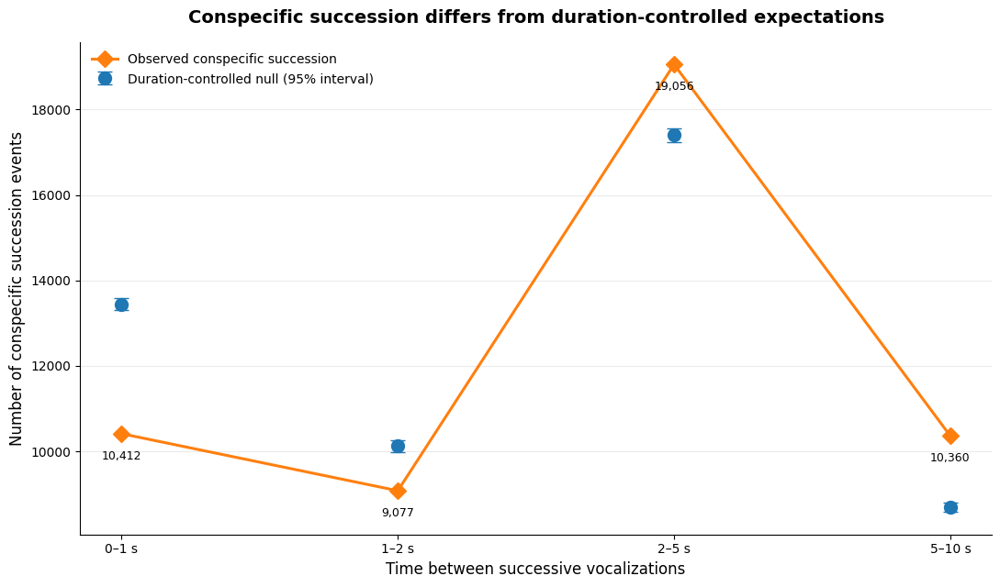

In [ ]:
# ============================================================
# QUESTION 1 — FIGURE 1
# Observed vs duration-controlled null model
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Use actual results from Step 112
plot_data = duration_null_results.copy()

lag_labels = plot_data["lag_bin"].tolist()
x = np.arange(len(lag_labels))

observed = plot_data["observed"].to_numpy()
null_mean = plot_data["duration_controlled_null_mean"].to_numpy()
null_low = plot_data["null_2.5%"].to_numpy()
null_high = plot_data["null_97.5%"].to_numpy()

# Calculate asymmetric error bars
null_errors = np.vstack([
    null_mean - null_low,
    null_high - null_mean
])

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6.5))

# Null expectation
ax.errorbar(
    x,
    null_mean,
    yerr=null_errors,
    fmt="o",
    markersize=10,
    capsize=6,
    linewidth=2,
    label="Duration-controlled null (95% interval)"
)

# Observed values
ax.plot(
    x,
    observed,
    marker="D",
    markersize=9,
    linewidth=2.2,
    label="Observed conspecific succession"
)

# Labels
for i in range(len(x)):
    ax.annotate(
        f"{observed[i]:,}",
        (x[i], observed[i]),
        xytext=(0, -20),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(lag_labels)

ax.set_xlabel(
    "Time between successive vocalizations",
    fontsize=12
)

ax.set_ylabel(
    "Number of conspecific succession events",
    fontsize=12
)

ax.set_title(
    "Conspecific succession differs from duration-controlled expectations",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Figure 1. Observed and duration-controlled null expectations for conspecific vocal succession across temporal lag intervals.** Observed counts of conspecific succession events are compared with mean counts generated by a duration-controlled permutation null model. Error bars represent the 95% permutation interval. Conspecific succession was significantly suppressed during the first two seconds following a vocalization, with observed counts below null expectations in both the 0–1 s and 1–2 s intervals. In contrast, conspecific succession was significantly enriched during the 2–5 s and 5–10 s intervals. These results demonstrate a pronounced temporal shift from short-lag suppression to longer-lag enrichment, even after accounting for vocalization duration.

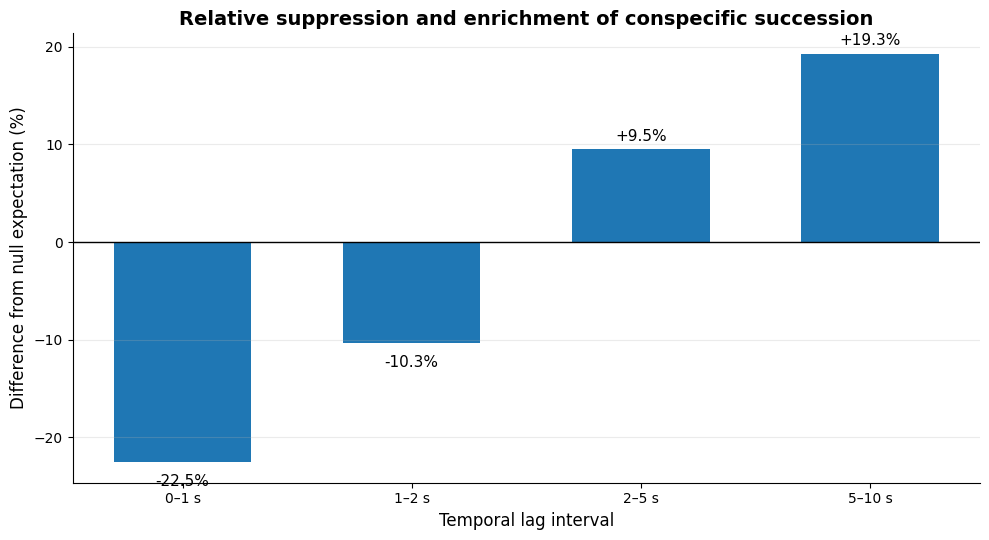

In [ ]:
# ============================================================
# QUESTION 1 — FIGURE 2
# Percentage deviation from null expectation
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plot_data = duration_null_results.copy()

lag_labels = plot_data["lag_bin"].tolist()

observed = plot_data["observed"].to_numpy()
null_mean = plot_data["duration_controlled_null_mean"].to_numpy()

# Percentage difference relative to null
percent_difference = (
    (observed - null_mean) / null_mean
) * 100

x = np.arange(len(lag_labels))

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    x,
    percent_difference,
    width=0.6
)

ax.axhline(
    0,
    color="black",
    linewidth=1
)

for bar, value in zip(bars, percent_difference):
    ax.annotate(
        f"{value:+.1f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 6 if value >= 0 else -17),
        textcoords="offset points",
        ha="center",
        fontsize=11
    )

ax.set_xticks(x)
ax.set_xticklabels(lag_labels)

ax.set_xlabel("Temporal lag interval", fontsize=12)
ax.set_ylabel("Difference from null expectation (%)", fontsize=12)

ax.set_title(
    "Relative suppression and enrichment of conspecific succession",
    fontsize=14,
    weight="bold"
)

ax.grid(axis="y", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Figure 2. Relative deviation of conspecific succession from duration-controlled null expectations.** Bars represent the percentage difference between observed and expected conspecific succession counts across temporal lag intervals. Negative values indicate suppression relative to the null model, while positive values indicate enrichment. The magnitude of the deviation illustrates a transition from strong short-lag suppression to longer-lag enrichment.

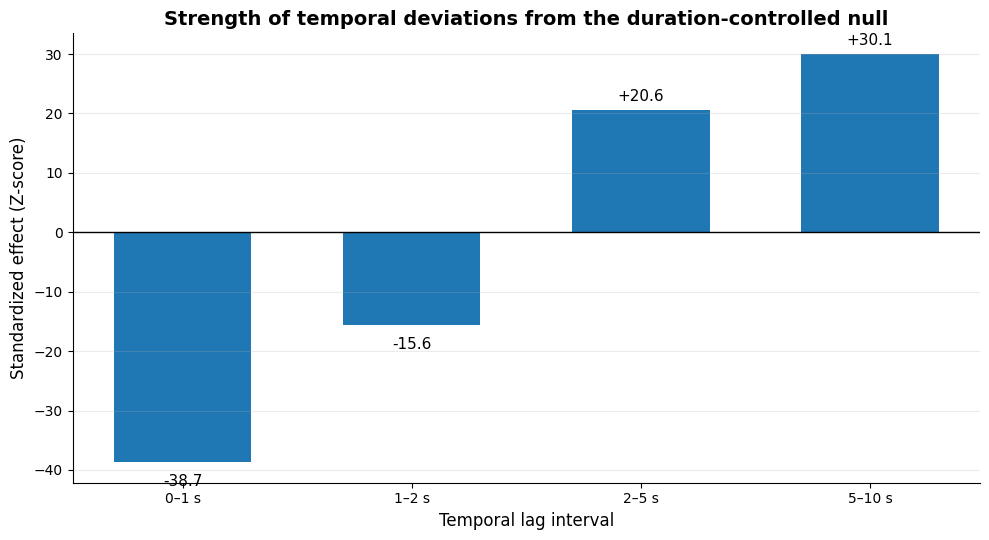

In [ ]:
# ============================================================
# QUESTION 1 — FIGURE 3
# Standardized temporal effect sizes (Z-scores)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

plot_data = duration_null_results.copy()

lag_labels = plot_data["lag_bin"].tolist()
z_scores = plot_data["z_score"].to_numpy()

x = np.arange(len(lag_labels))

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.bar(
    x,
    z_scores,
    width=0.6
)

# Zero-effect reference
ax.axhline(0, color="black", linewidth=1)

# Labels
for bar, value in zip(bars, z_scores):
    ax.annotate(
        f"{value:+.1f}",
        (
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 6 if value >= 0 else -17),
        textcoords="offset points",
        ha="center",
        fontsize=11
    )

ax.set_xticks(x)
ax.set_xticklabels(lag_labels)

ax.set_xlabel("Temporal lag interval", fontsize=12)
ax.set_ylabel("Standardized effect (Z-score)", fontsize=12)

ax.set_title(
    "Strength of temporal deviations from the duration-controlled null",
    fontsize=14,
    weight="bold"
)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

**Figure 3. Standardized deviations in conspecific vocal succession across temporal lag intervals.** Bars represent Z-scores calculated from the difference between observed conspecific succession counts and the duration-controlled null expectation, standardized by the null distribution's standard deviation. Negative values indicate suppression and positive values indicate enrichment. Strong negative deviations occur at short temporal lags, while strong positive deviations occur at longer lags, reinforcing the temporal transition identified in Figures 1 and 2.

In [ ]:
# QUESTION 1 — inspect succession edge columns

print(succession_edges.columns.tolist())
display(succession_edges.head())

['source_event', 'target_event', 'itemID', 'source_species', 'target_species', 'relationship_type', 'start_lag_s', 'gap_s', 'overlap_duration_s', 'source_event_key', 'target_event_key', 'species_relationship', 'null_source_species', 'null_target_species', 'null_species_relationship', 'source_begin_s', 'source_end_s', 'target_begin_s', 'lag_bin']


,source_event,target_event,itemID,source_species,target_species,relationship_type,start_lag_s,gap_s,overlap_duration_s,source_event_key,target_event_key,species_relationship,null_source_species,null_target_species,null_species_relationship,source_begin_s,source_end_s,target_begin_s,lag_bin
0,1701_E0002,1701_E0003,1701,OVEN,BTBW,succession,2.359078,0.285751,NaN,1701_E0002,1701_E0003,heterospecific,BTBW,OVEN,heterospecific,38.371168,40.444495,40.730246,0–1 s
1,1701_E0003,1701_E0004,1701,BTBW,OVEN,succession,10.032219,8.773674,NaN,1701_E0003,1701_E0004,heterospecific,OVEN,BTBW,heterospecific,40.730246,41.988791,50.762465,5–10 s
2,1701_E0004,1701_E0005,1701,OVEN,BTBW,succession,5.811314,2.832731,NaN,1701_E0004,1701_E0005,heterospecific,BTBW,BTBW,conspecific,50.762465,53.741049,56.573780,2–5 s
3,1701_E0005,1701_E0006,1701,BTBW,BTBW,succession,3.589184,2.470477,NaN,1701_E0005,1701_E0006,conspecific,BTBW,BTBW,conspecific,56.573780,57.692487,60.162964,2–5 s
4,1701_E0006,1701_E0007,1701,BTBW,OVEN,succession,5.217175,3.967953,NaN,1701_E0006,1701_E0007,heterospecific,BTBW,DEJU,heterospecific,60.162964,61.412186,65.380139,2–5 s


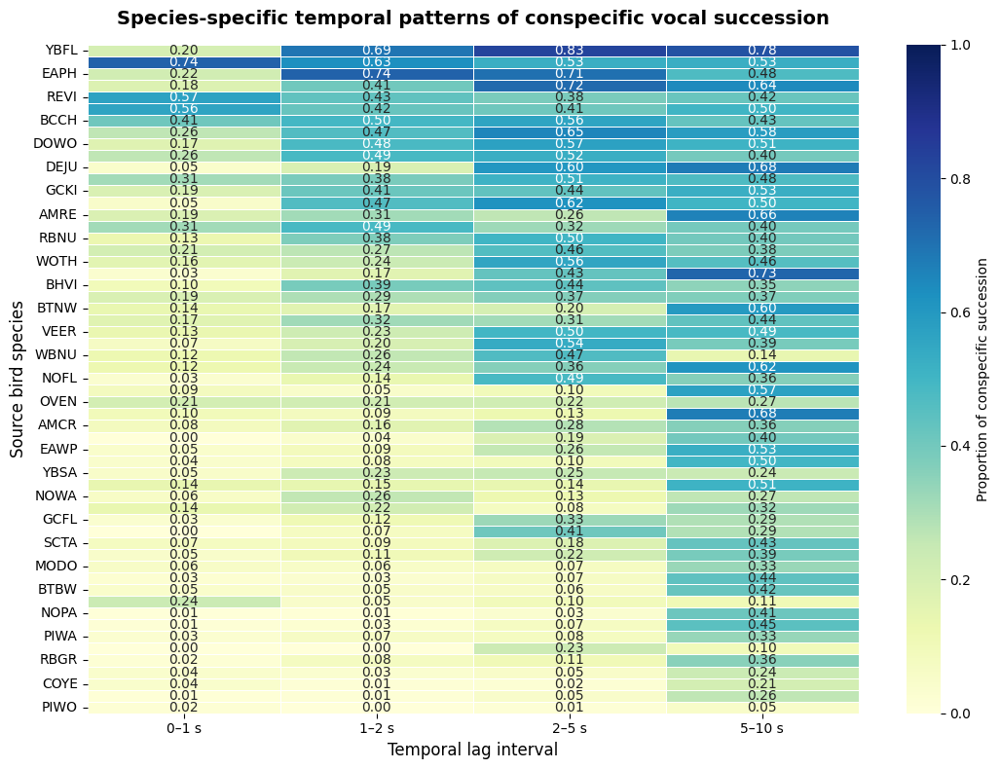

lag_bin,0–1 s,1–2 s,2–5 s,5–10 s
source_species,,,,
AGOL,195,78,61,24
AMCR,1474,1075,1476,527
AMRE,37,32,61,56
AMRO,2252,1358,1447,191
BAWW,1152,744,897,412
BCCH,2662,1713,1619,285
BHVI,514,525,570,165
BLBW,1321,922,1355,978
BLJA,1345,959,1061,250


In [ ]:
# ============================================================
# QUESTION 1 — FIGURE 4
# Species-specific conspecific succession heatmap
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Keep succession events only
succ = succession_edges[
    succession_edges["relationship_type"] == "succession"
].copy()

# Define temporal order
lag_order = ["0–1 s", "1–2 s", "2–5 s", "5–10 s"]

# Calculate total outgoing succession events per species and lag
total = (
    succ.groupby(["source_species", "lag_bin"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=lag_order, fill_value=0)
)

# Calculate conspecific succession events
same_species = succ[
    succ["species_relationship"] == "conspecific"
]

conspecific = (
    same_species.groupby(["source_species", "lag_bin"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=total.index,
        columns=lag_order,
        fill_value=0
    )
)

# Calculate proportions
proportions = conspecific.div(total.replace(0, np.nan))

# Exclude species with very few observations
minimum_events = 100

species_to_keep = total.sum(axis=1) >= minimum_events

proportions = proportions.loc[species_to_keep]
total = total.loc[species_to_keep]

# Sort species by their overall conspecific succession proportion
overall_rate = (
    conspecific.loc[species_to_keep].sum(axis=1)
    / total.sum(axis=1)
)

proportions = proportions.loc[
    overall_rate.sort_values(ascending=False).index
]

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    proportions,
    cmap="YlGnBu",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={
        "label": "Proportion of conspecific succession"
    },
    ax=ax
)

ax.set_title(
    "Species-specific temporal patterns of conspecific vocal succession",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.set_xlabel("Temporal lag interval", fontsize=12)
ax.set_ylabel("Source bird species", fontsize=12)

plt.tight_layout()
plt.show()

# Display sample sizes for transparency
display(total)

**Figure 4. Species-specific temporal patterns of conspecific vocal succession. **Heatmap showing the proportion of outgoing succession events followed by a vocalization from the same species across four temporal lag intervals. Species are ordered by their overall conspecific succession proportion. Only species with at least 100 outgoing succession events are displayed. Cell values represent observed proportions rather than deviations from a null model. The visualization illustrates variation among species in the temporal organization of conspecific vocal activity.

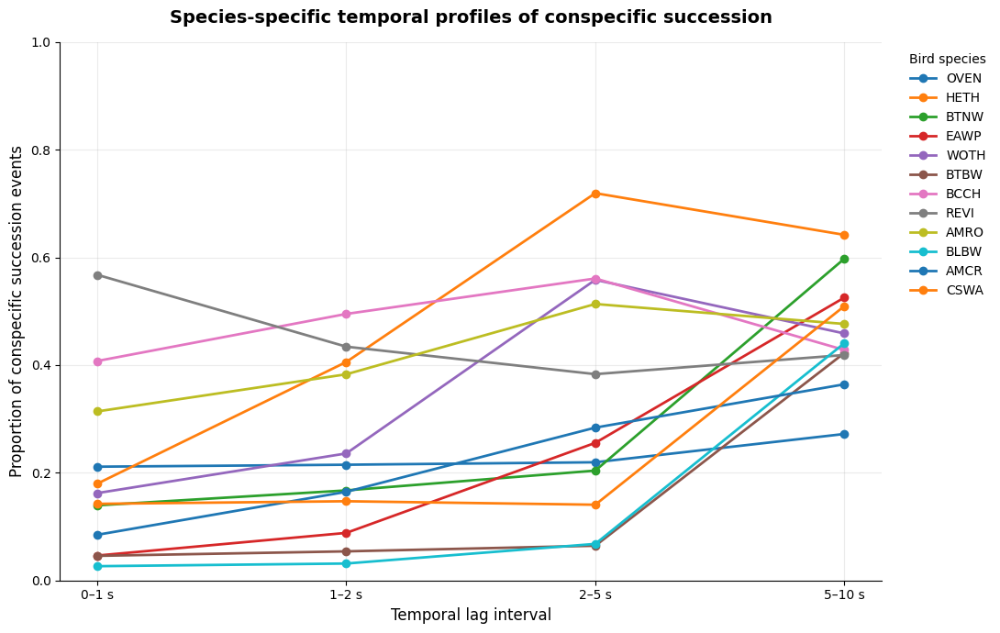

,total_succession_events
source_species,
OVEN,27759
HETH,17961
BTNW,16386
EAWP,10812
WOTH,8445
BTBW,7375
BCCH,6279
REVI,6122
AMRO,5248


In [ ]:
# ============================================================
# QUESTION 1 — FIGURE 5
# Species-specific temporal succession profiles
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use existing succession data
succ = succession_edges[
    succession_edges["relationship_type"] == "succession"
].copy()

lag_order = ["0–1 s", "1–2 s", "2–5 s", "5–10 s"]

# Count all outgoing succession events by species and lag
total = (
    succ.groupby(["source_species", "lag_bin"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=lag_order, fill_value=0)
)

# Count conspecific succession events
conspecific = (
    succ[succ["species_relationship"] == "conspecific"]
    .groupby(["source_species", "lag_bin"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=total.index,
        columns=lag_order,
        fill_value=0
    )
)

# Calculate proportions
profiles = conspecific.div(total.replace(0, np.nan))

# Retain species with at least 100 outgoing succession events
minimum_events = 100

species_counts = total.sum(axis=1)
eligible = species_counts[species_counts >= minimum_events]

# Select the 12 most frequently represented species
selected_species = eligible.nlargest(12).index

profiles = profiles.loc[selected_species]

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

x = np.arange(len(lag_order))

for species in profiles.index:

    ax.plot(
        x,
        profiles.loc[species].values,
        marker="o",
        linewidth=2,
        markersize=6,
        label=species
    )

ax.set_xticks(x)
ax.set_xticklabels(lag_order)

ax.set_xlabel(
    "Temporal lag interval",
    fontsize=12
)

ax.set_ylabel(
    "Proportion of conspecific succession events",
    fontsize=12
)

ax.set_title(
    "Species-specific temporal profiles of conspecific succession",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.set_ylim(0, 1)

ax.grid(alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    title="Bird species",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

# Show sample sizes for the displayed species
display(
    species_counts.loc[selected_species]
    .rename("total_succession_events")
    .to_frame()
)

**Figure 5. Species-specific temporal profiles of conspecific vocal succession. **Lines represent the proportion of outgoing succession events followed by a vocalization from the same species across four temporal lag intervals. The 12 species with the greatest number of outgoing succession events were selected from species with at least 100 observations. The visualization illustrates whether species exhibit similar or distinct temporal patterns of conspecific vocal succession, including changes in the relative frequency of same-species succession across increasing time intervals.

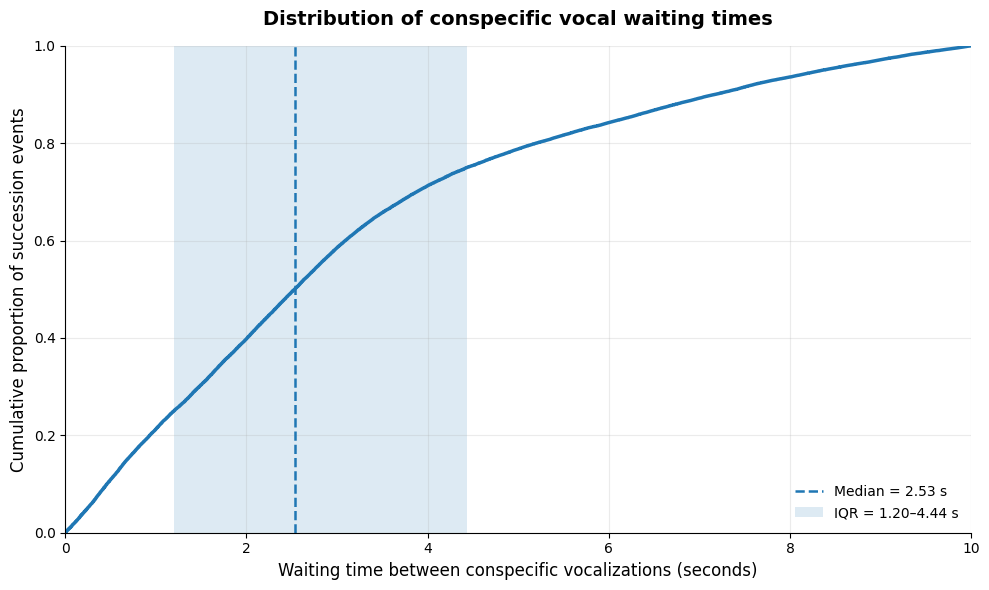

Conspecific waiting-time summary
--------------------------------
Number of events: 48,905
Median: 2.533 seconds
25th percentile: 1.197 seconds
75th percentile: 4.435 seconds
Mean: 3.146 seconds


In [ ]:
# ============================================================
# QUESTION 1 — FIGURE 6
# Distribution of conspecific vocal waiting times
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select conspecific succession events
conspecific_gaps = succession_edges.loc[
    (succession_edges["relationship_type"] == "succession") &
    (succession_edges["species_relationship"] == "conspecific"),
    "gap_s"
].dropna()

# Keep gaps between 0 and 10 seconds
conspecific_gaps = conspecific_gaps[
    (conspecific_gaps >= 0) &
    (conspecific_gaps <= 10)
]

# Sort waiting times for ECDF
sorted_gaps = np.sort(conspecific_gaps)

# Calculate cumulative proportions
cumulative_proportion = (
    np.arange(1, len(sorted_gaps) + 1) / len(sorted_gaps)
)

# Calculate descriptive statistics
median_gap = np.median(sorted_gaps)
q25 = np.percentile(sorted_gaps, 25)
q75 = np.percentile(sorted_gaps, 75)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    sorted_gaps,
    cumulative_proportion,
    linewidth=2.5
)

# Median waiting time
ax.axvline(
    median_gap,
    linestyle="--",
    linewidth=1.8,
    label=f"Median = {median_gap:.2f} s"
)

# Interquartile range
ax.axvspan(
    q25,
    q75,
    alpha=0.15,
    label=f"IQR = {q25:.2f}–{q75:.2f} s"
)

ax.set_xlabel(
    "Waiting time between conspecific vocalizations (seconds)",
    fontsize=12
)

ax.set_ylabel(
    "Cumulative proportion of succession events",
    fontsize=12
)

ax.set_title(
    "Distribution of conspecific vocal waiting times",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.set_xlim(0, 10)
ax.set_ylim(0, 1)

ax.grid(alpha=0.25)
ax.legend(frameon=False, loc="lower right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# PRINT SUMMARY STATISTICS
# ------------------------------------------------------------

print("Conspecific waiting-time summary")
print("--------------------------------")
print(f"Number of events: {len(sorted_gaps):,}")
print(f"Median: {median_gap:.3f} seconds")
print(f"25th percentile: {q25:.3f} seconds")
print(f"75th percentile: {q75:.3f} seconds")
print(f"Mean: {np.mean(sorted_gaps):.3f} seconds")

**Figure 6. Cumulative distribution of waiting times between conspecific vocalizations.** The empirical cumulative distribution function (ECDF) illustrates the proportion of conspecific succession events occurring within each waiting-time threshold, restricted to intervals of 0–10 seconds. The dashed vertical line indicates the median waiting time, while the shaded region represents the interquartile range. This visualization characterizes the distribution of temporal gaps between successive vocalizations from the same species.

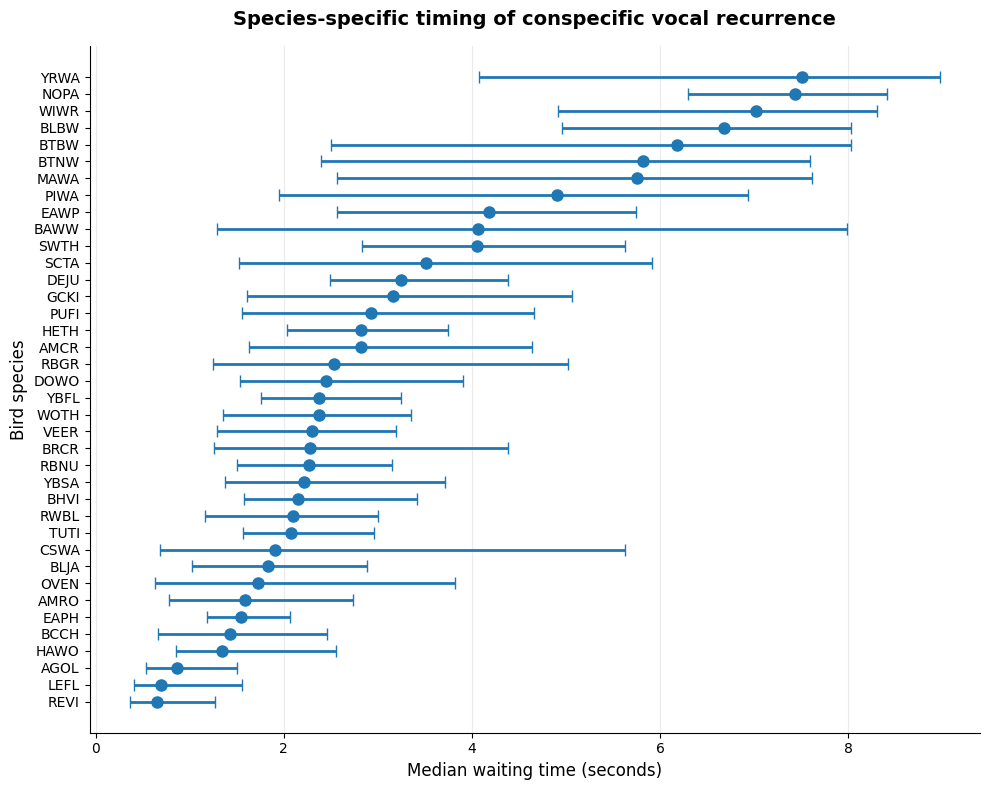

,source_species,median,q25,q75,n
59,REVI,0.647,0.364,1.266,3102
40,LEFL,0.689,0.408,1.558,290
0,AGOL,0.861,0.539,1.506,179
36,HAWO,1.343,0.858,2.551,366
8,BCCH,1.423,0.660,2.458,2963
30,EAPH,1.546,1.187,2.066,220
4,AMRO,1.589,0.776,2.739,2061
52,OVEN,1.723,0.633,3.818,6189
11,BLJA,1.828,1.023,2.881,1478
26,CSWA,1.910,0.683,5.625,814


In [ ]:
# ============================================================
# QUESTION 1 — FIGURE 7
# Species-specific conspecific waiting times
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select conspecific succession events
conspecific = succession_edges[
    (succession_edges["relationship_type"] == "succession") &
    (succession_edges["species_relationship"] == "conspecific")
].copy()

# Remove missing and invalid waiting times
conspecific = conspecific[
    conspecific["gap_s"].notna() &
    (conspecific["gap_s"] >= 0) &
    (conspecific["gap_s"] <= 10)
]

# Calculate species-level waiting-time statistics
species_wait = (
    conspecific.groupby("source_species")["gap_s"]
    .agg(
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        n="count"
    )
    .reset_index()
)

# Retain species with at least 100 observations
species_wait = species_wait[
    species_wait["n"] >= 100
].copy()

# Sort by median waiting time
species_wait = species_wait.sort_values(
    "median",
    ascending=True
)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))

y = np.arange(len(species_wait))

# Asymmetric interquartile error bars
lower_error = (
    species_wait["median"] - species_wait["q25"]
)

upper_error = (
    species_wait["q75"] - species_wait["median"]
)

ax.errorbar(
    species_wait["median"],
    y,
    xerr=[
        lower_error,
        upper_error
    ],
    fmt="o",
    markersize=8,
    capsize=4,
    linewidth=2
)

ax.set_yticks(y)
ax.set_yticklabels(species_wait["source_species"])

ax.set_xlabel(
    "Median waiting time (seconds)",
    fontsize=12
)

ax.set_ylabel(
    "Bird species",
    fontsize=12
)

ax.set_title(
    "Species-specific timing of conspecific vocal recurrence",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.grid(axis="x", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Display the statistics and sample sizes
display(
    species_wait[
        ["source_species", "median", "q25", "q75", "n"]
    ].round(3)
)

**Figure 7. Species-specific median waiting times between conspecific vocalizations.** Points represent the median interval between successive vocalizations from the same species, with horizontal error bars indicating the interquartile range. Only species with at least 100 conspecific succession events within the 0–10-second analysis window are included. Differences among species illustrate variation in the timing of conspecific vocal recurrence. These descriptive patterns do not independently establish statistically significant differences between species.

In [ ]:
# ============================================================
# QUESTION 2 — VERIFY ANALYSIS RESULTS
# ============================================================

objects = [
    "pair_counts",
    "pair_table",
    "significant_pairs",
    "robust_pairs",
    "directional_pairs"
]

for name in objects:
    print(
        f"{name}:",
        "READY" if name in globals() else "MISSING"
    )

print("\nRobust pair columns:")
print(robust_pairs.columns.tolist())

print("\nNumber of robust pairs:", len(robust_pairs))

display(robust_pairs.head(10))

pair_counts: READY
pair_table: READY
significant_pairs: READY
robust_pairs: READY
directional_pairs: READY

Robust pair columns:
['source_species', 'target_species', 'observed_edges', 'null_mean', 'null_sd', 'difference', 'fold_enrichment', 'percent_difference', 'z_score', 'p_enrichment', 'q_value', 'source_common_name', 'source_scientific_name', 'target_common_name', 'target_scientific_name']

Number of robust pairs: 300


,source_species,target_species,observed_edges,null_mean,null_sd,difference,fold_enrichment,percent_difference,z_score,p_enrichment,q_value,source_common_name,source_scientific_name,target_common_name,target_scientific_name
0,BCCH,LOWA,23,9.461,2.748096,13.539,2.431033,143.103266,4.926684,0.000999,0.010786,Black-capped Chickadee,Poecile atricapillus,Louisiana Waterthrush,Parkesia motacilla
1,BLBW,NAWA,22,10.577,2.924829,11.423,2.079985,107.998487,3.905527,0.000999,0.010786,Blackburnian Warbler,Setophaga fusca,Nashville Warbler,Leiothlypis ruficapilla
2,BRCR,DEJU,50,24.471,4.129190,25.529,2.043235,104.323485,6.182569,0.000999,0.010786,Brown Creeper,Certhia americana,Dark-eyed Junco,Junco hyemalis
3,OVEN,TEWA,26,12.898,3.424226,13.102,2.015816,101.581641,3.826267,0.001998,0.018567,Ovenbird,Seiurus aurocapilla,Tennessee Warbler,Leiothlypis peregrina
4,YRWA,SWTH,21,10.557,2.422110,10.443,1.989201,98.920148,4.311530,0.000999,0.010786,Yellow-rumped Warbler,Setophaga coronata,Swainson's Thrush,Catharus ustulatus
5,COYE,BLBW,26,13.180,2.912745,12.820,1.972686,97.268589,4.401346,0.000999,0.010786,Common Yellowthroat,Geothlypis trichas,Blackburnian Warbler,Setophaga fusca
6,BHVI,REVI,44,22.749,4.212807,21.251,1.934151,93.415095,5.044380,0.000999,0.010786,Blue-headed Vireo,Vireo solitarius,Red-eyed Vireo,Vireo olivaceus
7,PUFI,DEJU,26,13.553,2.777932,12.447,1.918394,91.839445,4.480671,0.000999,0.010786,Purple Finch,Haemorhous purpureus,Dark-eyed Junco,Junco hyemalis
8,EAWP,RWBL,41,21.654,3.904552,19.346,1.893415,89.341461,4.954729,0.000999,0.010786,Eastern Wood pewee,Contopus virens,Red-winged Blackbird,Agelaius phoeniceus
9,BLBW,COYE,23,12.521,2.952673,10.479,1.836914,83.691398,3.548988,0.000999,0.010786,Blackburnian Warbler,Setophaga fusca,Common Yellowthroat,Geothlypis trichas


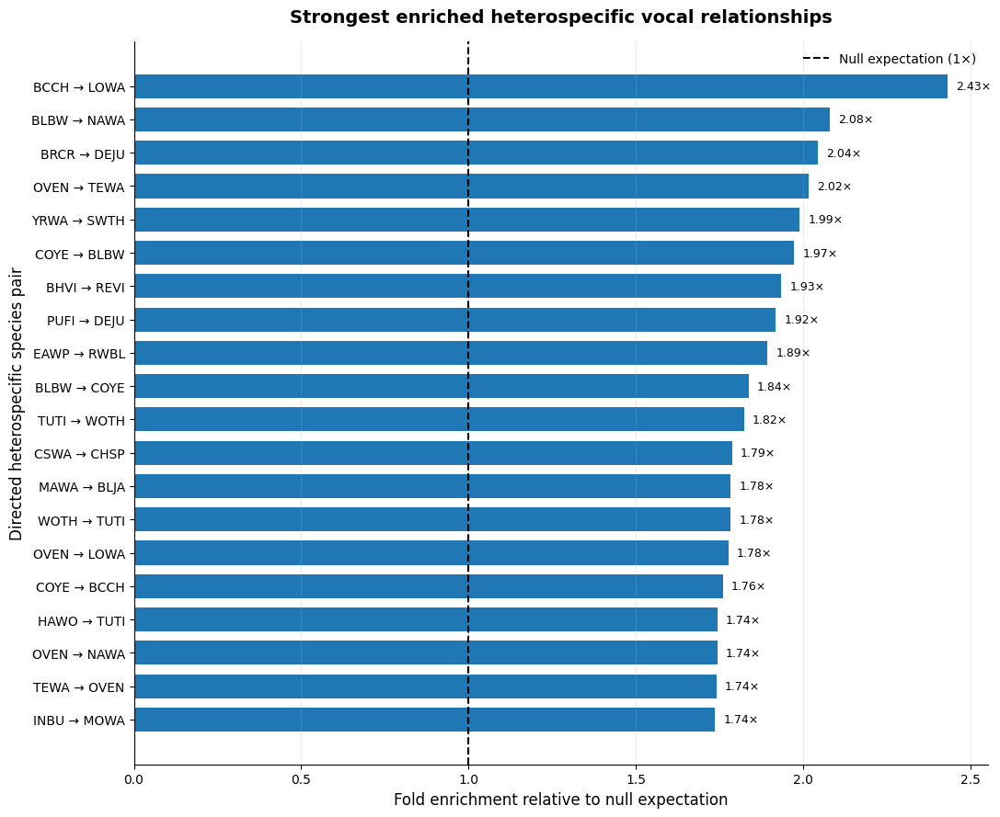

,source_species,target_species,observed_edges,null_mean,fold_enrichment,q_value
19,INBU,MOWA,72,41.460,1.7366,0.0108
18,TEWA,OVEN,23,13.212,1.7408,0.0394
17,OVEN,NAWA,58,33.271,1.7433,0.0108
16,HAWO,TUTI,26,14.906,1.7443,0.0186
15,COYE,BCCH,51,28.969,1.7605,0.0108
14,OVEN,LOWA,108,60.768,1.7773,0.0108
13,WOTH,TUTI,30,16.825,1.7831,0.0108
12,MAWA,BLJA,23,12.895,1.7836,0.0262
11,CSWA,CHSP,20,11.191,1.7872,0.0333
10,TUTI,WOTH,32,17.550,1.8234,0.0108


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 1
# Strongest heterospecific vocal relationships
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Select statistically robust pairs
plot_data = robust_pairs[
    robust_pairs["q_value"] < 0.05
].copy()

# Keep the 20 strongest by fold enrichment
plot_data = (
    plot_data
    .sort_values("fold_enrichment", ascending=False)
    .head(20)
    .copy()
)

# Create readable directed pair labels
plot_data["pair_label"] = (
    plot_data["source_species"]
    + " → "
    + plot_data["target_species"]
)

# Reverse order for horizontal bar chart
plot_data = plot_data.sort_values(
    "fold_enrichment",
    ascending=True
)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9))

bars = ax.barh(
    plot_data["pair_label"],
    plot_data["fold_enrichment"],
    height=0.72
)

# Null expectation
ax.axvline(
    1,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Null expectation (1×)"
)

# Add fold-enrichment labels
for bar, value in zip(
    bars,
    plot_data["fold_enrichment"]
):
    ax.text(
        value + 0.025,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}×",
        va="center",
        fontsize=9
    )

ax.set_xlabel(
    "Fold enrichment relative to null expectation",
    fontsize=12
)

ax.set_ylabel(
    "Directed heterospecific species pair",
    fontsize=12
)

ax.set_title(
    "Strongest enriched heterospecific vocal relationships",
    fontsize=14,
    weight="bold",
    pad=15
)

ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.25)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Display the underlying results
display(
    plot_data[
        [
            "source_species",
            "target_species",
            "observed_edges",
            "null_mean",
            "fold_enrichment",
            "q_value"
        ]
    ].round(4)
)

**Figure 1. Strongest enriched directed heterospecific vocal relationships.** The 20 directed interspecific species pairs with the greatest fold enrichment are shown. Fold enrichment represents the ratio of observed succession events to the mean expected under the permutation null model. Values greater than one indicate that a directed species pair occurred more frequently than expected. All displayed pairs passed the false-discovery-rate-adjusted significance threshold (q < 0.05). Arrows indicate the direction of vocal succession, from the source species to the subsequent target species.

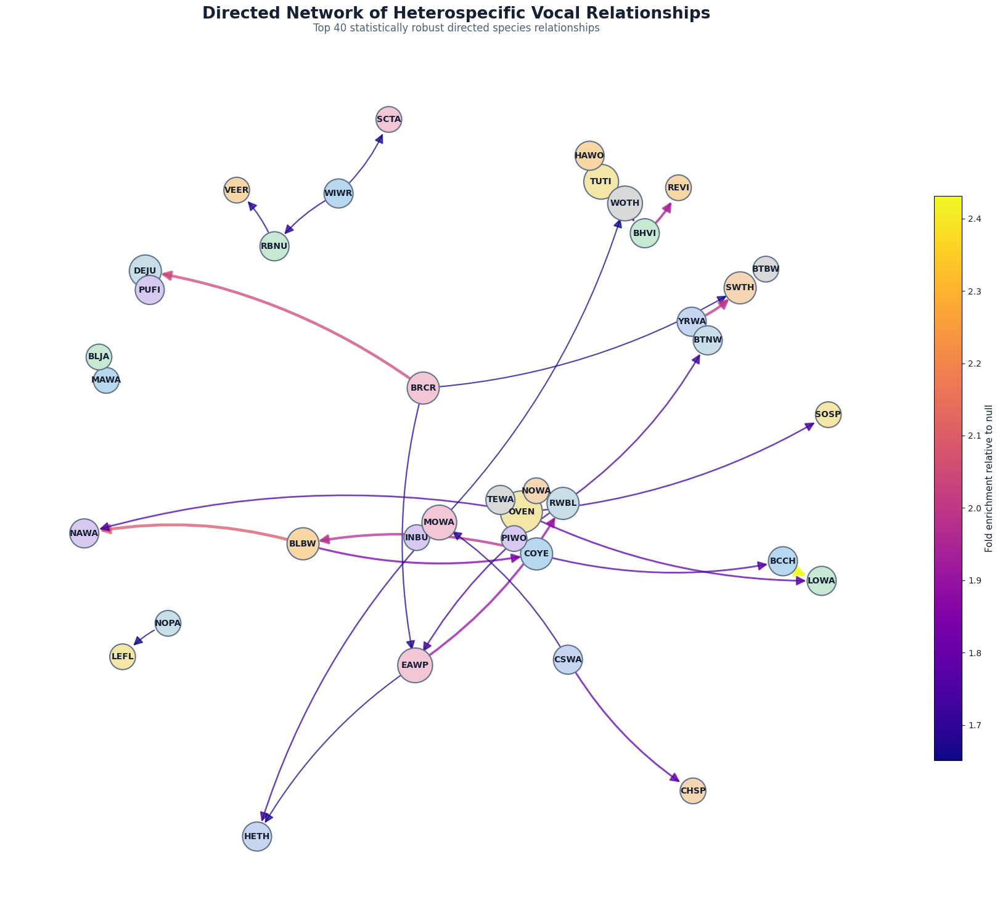

NETWORK SUMMARY
Number of species: 37
Number of directed relationships: 40
Mean total degree: 2.16

Most connected species:


,total_connections
OVEN,7
EAWP,4
TUTI,4
WOTH,4
MOWA,4
SWTH,3
RWBL,3
COYE,3
BRCR,3
BLBW,3


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 2
# COLORFUL DIRECTED HETEROSPECIFIC NETWORK
# White background + pastel nodes + dark labels
# ============================================================

import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. SELECT ROBUST HETEROSPECIFIC RELATIONSHIPS
# ------------------------------------------------------------

network_data = robust_pairs[
    robust_pairs["q_value"] < 0.05
].copy()

network_data = (
    network_data
    .sort_values("fold_enrichment", ascending=False)
    .head(40)
    .copy()
)

# ------------------------------------------------------------
# 2. BUILD DIRECTED NETWORK
# ------------------------------------------------------------

G = nx.DiGraph()

for _, row in network_data.iterrows():

    G.add_edge(
        row["source_species"],
        row["target_species"],
        enrichment=row["fold_enrichment"],
        observed=row["observed_edges"],
        q_value=row["q_value"]
    )

# ------------------------------------------------------------
# 3. CALCULATE NODE SIZE
# ------------------------------------------------------------

degree = dict(G.degree())

node_sizes = [
    650 + degree[node] * 250
    for node in G.nodes()
]

# ------------------------------------------------------------
# 4. ASSIGN PASTEL NODE COLORS
# ------------------------------------------------------------

pastel_palette = [
    "#B8D8F0",  # Powder blue
    "#C7E9D4",  # Mint green
    "#F8D7A4",  # Soft peach
    "#D8C9F0",  # Lavender
    "#F2C6D5",  # Rose
    "#C9DFE8",  # Pale teal
    "#F4E6A6",  # Soft yellow
    "#D9D9D9",  # Light gray
    "#C6D6F0",  # Periwinkle
    "#F5D6B3"   # Pale apricot
]

node_colors = [
    pastel_palette[i % len(pastel_palette)]
    for i, node in enumerate(G.nodes())
]

# ------------------------------------------------------------
# 5. NETWORK LAYOUT
# ------------------------------------------------------------

pos = nx.spring_layout(
    G,
    seed=42,
    k=1.5,
    iterations=500,
    weight="enrichment"
)

# ------------------------------------------------------------
# 6. EDGE COLORS AND WIDTHS
# ------------------------------------------------------------

edges = list(G.edges())

edge_values = np.array([
    G[u][v]["enrichment"]
    for u, v in edges
])

edge_min = edge_values.min()
edge_max = edge_values.max()

# Normalize enrichment for line thickness
if edge_max > edge_min:
    normalized = (
        (edge_values - edge_min) /
        (edge_max - edge_min)
    )
else:
    normalized = np.zeros_like(edge_values)

edge_widths = 1.5 + normalized * 3.5

# Color map for enrichment
edge_cmap = plt.cm.plasma

# ------------------------------------------------------------
# 7. CREATE FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(18, 15))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ------------------------------------------------------------
# 8. DRAW DIRECTED EDGES
# ------------------------------------------------------------

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=edges,
    edge_color=edge_values,
    edge_cmap=edge_cmap,
    edge_vmin=edge_min,
    edge_vmax=edge_max,
    width=edge_widths,
    alpha=0.75,
    arrows=True,
    arrowsize=22,
    arrowstyle="-|>",
    connectionstyle="arc3,rad=0.12",
    min_source_margin=18,
    min_target_margin=18,
    ax=ax
)

# ------------------------------------------------------------
# 9. DRAW PASTEL NODES
# ------------------------------------------------------------

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    edgecolors="#64748B",
    linewidths=1.5,
    alpha=1,
    ax=ax
)

# ------------------------------------------------------------
# 10. DRAW DARK SPECIES LABELS
# ------------------------------------------------------------

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold",
    font_color="#172033",
    ax=ax
)

# ------------------------------------------------------------
# 11. EDGE ENRICHMENT COLORBAR
# ------------------------------------------------------------

edge_norm = mpl.colors.Normalize(
    vmin=edge_min,
    vmax=edge_max
)

edge_sm = mpl.cm.ScalarMappable(
    norm=edge_norm,
    cmap=edge_cmap
)

edge_sm.set_array([])

cbar = fig.colorbar(
    edge_sm,
    ax=ax,
    shrink=0.65,
    pad=0.025
)

cbar.set_label(
    "Fold enrichment relative to null",
    fontsize=11,
    color="#172033"
)

cbar.ax.tick_params(
    colors="#172033",
    labelsize=10
)

# ------------------------------------------------------------
# 12. TITLES AND FORMATTING
# ------------------------------------------------------------

ax.set_title(
    "Directed Network of Heterospecific Vocal Relationships",
    fontsize=19,
    fontweight="bold",
    color="#172033",
    pad=30
)

ax.text(
    0.5,
    1.015,
    "Top 40 statistically robust directed species relationships",
    transform=ax.transAxes,
    ha="center",
    color="#526174",
    fontsize=12
)

ax.axis("off")

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 13. NETWORK SUMMARY
# ------------------------------------------------------------

print("NETWORK SUMMARY")
print("==============================")
print("Number of species:", G.number_of_nodes())
print("Number of directed relationships:", G.number_of_edges())

print(
    "Mean total degree:",
    round(np.mean(list(degree.values())), 2)
)

print("\nMost connected species:")

display(
    pd.Series(
        degree,
        name="total_connections"
    )
    .sort_values(ascending=False)
    .to_frame()
    .head(15)
)

**Figure 2. Directed network of enriched heterospecific vocal relationships.** The network displays the 40 strongest statistically robust directed relationships between different bird species. Nodes represent individual species, with node size indicating total incoming and outgoing connections. Directed edges represent vocal succession from source to target species. Edge color and thickness indicate fold enrichment relative to the permutation null expectation. Only relationships passing the false-discovery-rate-adjusted significance threshold (q < 0.05) are included. The network illustrates the structure of enriched interspecific vocal succession and highlights species participating in multiple relationships.

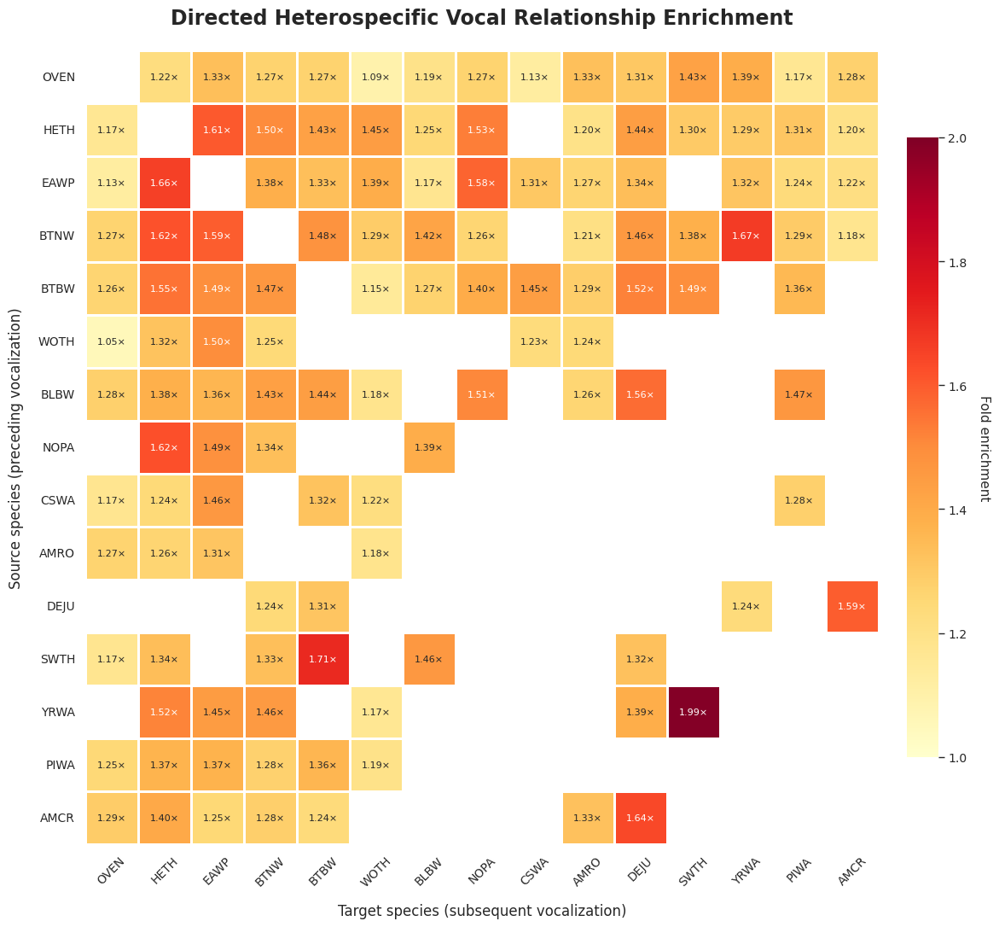

Figure 3 saved successfully.
Species displayed: 15
Robust directed relationships displayed: 124


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 3
# DIRECTED HETEROSPECIFIC INTERACTION HEATMAP
# Publication-quality version
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. SELECT STATISTICALLY ROBUST PAIRS
# ------------------------------------------------------------

plot_data = robust_pairs[
    robust_pairs["q_value"] < 0.05
].copy()

# ------------------------------------------------------------
# 2. IDENTIFY THE MOST CONNECTED SPECIES
# ------------------------------------------------------------

# Count incoming and outgoing robust relationships
outgoing = plot_data.groupby(
    "source_species"
).size()

incoming = plot_data.groupby(
    "target_species"
).size()

total_connections = (
    outgoing.add(incoming, fill_value=0)
    .sort_values(ascending=False)
)

# Select 15 most connected species
top_species = total_connections.head(15).index.tolist()

# Retain relationships among selected species
plot_data = plot_data[
    plot_data["source_species"].isin(top_species) &
    plot_data["target_species"].isin(top_species)
].copy()

# ------------------------------------------------------------
# 3. CREATE SOURCE-TARGET MATRIX
# ------------------------------------------------------------

matrix = plot_data.pivot_table(
    index="source_species",
    columns="target_species",
    values="fold_enrichment",
    aggfunc="max"
)

# Preserve identical species ordering on both axes
matrix = matrix.reindex(
    index=top_species,
    columns=top_species
)

# ------------------------------------------------------------
# 4. CREATE ANNOTATION MATRIX
# ------------------------------------------------------------

annotations = matrix.copy().astype(object)

for row in matrix.index:
    for col in matrix.columns:

        value = matrix.loc[row, col]

        if pd.notna(value):
            annotations.loc[row, col] = f"{value:.2f}×"
        else:
            annotations.loc[row, col] = ""

# ------------------------------------------------------------
# 5. PUBLICATION-QUALITY HEATMAP
# ------------------------------------------------------------

sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.15
)

fig, ax = plt.subplots(figsize=(14, 11))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Mask diagonal: same-species relationships are outside Q2
mask = np.eye(len(matrix), dtype=bool)

# Determine color scale from observed values
vmin = 1.0
vmax = max(2.0, float(np.nanpercentile(
    matrix.values, 95
)))

sns.heatmap(
    matrix,
    mask=mask,
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax,
    annot=annotations,
    fmt="",
    linewidths=0.8,
    linecolor="white",
    square=True,
    cbar_kws={
        "label": "Fold enrichment relative to null",
        "shrink": 0.78,
        "pad": 0.025
    },
    annot_kws={
        "fontsize": 8,
        "fontweight": "medium"
    },
    ax=ax
)

# ------------------------------------------------------------
# 6. LABELS AND FORMATTING
# ------------------------------------------------------------

ax.set_title(
    "Directed Heterospecific Vocal Relationship Enrichment",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Target species (subsequent vocalization)",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Source species (preceding vocalization)",
    fontsize=12,
    labelpad=12
)

ax.tick_params(
    axis="x",
    labelrotation=45,
    labelsize=10
)

ax.tick_params(
    axis="y",
    labelrotation=0,
    labelsize=10
)

# Colorbar formatting
colorbar = ax.collections[0].colorbar

colorbar.ax.set_ylabel(
    "Fold enrichment",
    fontsize=11,
    rotation=270,
    labelpad=20
)

# Clean borders
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()

# ------------------------------------------------------------
# 7. SAVE PUBLICATION-QUALITY OUTPUTS
# ------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/"
    "data/derived/publication_figure_atlas"
)

import os
os.makedirs(output_dir, exist_ok=True)

fig.savefig(
    f"{output_dir}/Q2_Figure3_Directed_Heatmap.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    f"{output_dir}/Q2_Figure3_Directed_Heatmap.pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    f"{output_dir}/Q2_Figure3_Directed_Heatmap.svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 3 saved successfully.")
print("Species displayed:", len(top_species))
print("Robust directed relationships displayed:", matrix.notna().sum().sum())

**Figure 3. Directed enrichment of heterospecific vocal succession among highly connected bird species.** The heatmap represents fold enrichment in directed interspecific succession relationships relative to the permutation null expectation. Rows indicate source species and columns indicate target species. Cell values represent the ratio of observed succession events to the corresponding null-model mean. Only relationships passing the false-discovery-rate-adjusted significance threshold (q < 0.05) are displayed. The 15 species with the greatest total number of incoming and outgoing robust relationships were selected. The diagonal is masked because conspecific relationships are outside the scope of Question 2. The matrix reveals directional variation in the strength of enriched heterospecific vocal succession.

In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 4
# INSPECT DIRECTIONAL RELATIONSHIPS
# ============================================================

print("Directional pairs:", len(directional_pairs))

print("\nAvailable columns:")
print(directional_pairs.columns.tolist())

print("\nDirectional relationship results:")
display(directional_pairs.head(20))

Directional pairs: 19

Available columns:
['source_species', 'source_common_name', 'target_species', 'target_common_name', 'source_to_target', 'target_to_source', 'observed_difference', 'null_mean_difference', 'null_sd', 'z_score', 'directional_ratio', 'dominant_direction', 'p_value', 'q_value']

Directional relationship results:


,source_species,source_common_name,target_species,target_common_name,source_to_target,target_to_source,observed_difference,null_mean_difference,null_sd,z_score,directional_ratio,dominant_direction,p_value,q_value
0,CSWA,Chestnut-sided Warbler,REVI,Red-eyed Vireo,172,74,98,43.642,13.133786,4.138791,2.324324,CSWA → REVI,0.001998,0.041117
1,BTBW,Black-throated Blue Warbler,REVI,Red-eyed Vireo,270,120,150,88.203,17.033847,3.627895,2.250000,BTBW → REVI,0.001998,0.041117
2,BTNW,Black-throated Green Warbler,REVI,Red-eyed Vireo,582,312,270,195.807,20.490036,3.620931,1.865385,BTNW → REVI,0.001998,0.041117
3,OVEN,Ovenbird,REVI,Red-eyed Vireo,1239,690,549,346.335,30.019293,6.751158,1.795652,OVEN → REVI,0.001998,0.041117
4,REVI,Red-eyed Vireo,WOTH,Wood Thrush,107,188,-81,-25.116,13.497212,-4.140411,1.757009,WOTH → REVI,0.001998,0.041117
5,BAWW,Black-and-white Warbler,HETH,Hermit Thrush,144,82,62,10.949,10.537335,4.844773,1.756098,BAWW → HETH,0.001998,0.041117
6,BRCR,Brown Creeper,EAWP,Eastern Wood pewee,113,70,43,0.962,10.056326,4.180254,1.614286,BRCR → EAWP,0.001998,0.041117
7,EAWP,Eastern Wood pewee,RBGR,Rose-breasted Grosbeak,83,131,-48,-3.217,11.479882,-3.900998,1.578313,RBGR → EAWP,0.001998,0.041117
8,BRCR,Brown Creeper,DEJU,Dark-eyed Junco,50,32,18,-0.705,5.853566,3.195488,1.562500,BRCR → DEJU,0.001998,0.041117
9,HETH,Hermit Thrush,REVI,Red-eyed Vireo,490,348,142,76.260,18.331460,3.586185,1.408046,HETH → REVI,0.001998,0.041117


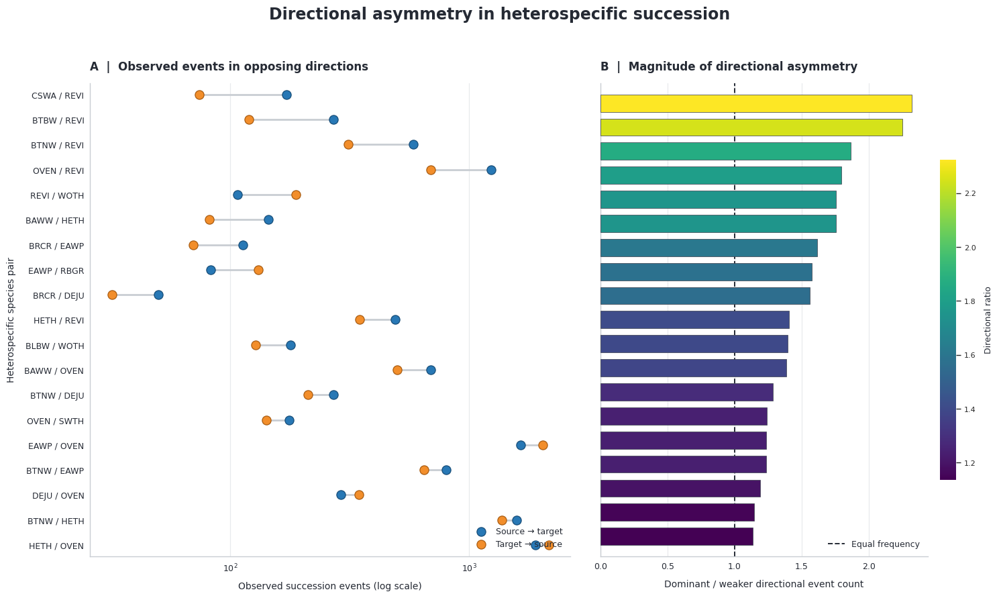

Figure 4 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure4_directional_asymmetry.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure4_directional_asymmetry.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure4_directional_asymmetry.svg


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 4
# Directional asymmetry in heterospecific succession
# Publication-quality, multicolor design
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import MaxNLocator

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# COLOR PALETTE
# ------------------------------------------------------------
COLORS = {
    "blue": "#2878B5",
    "orange": "#F28E2B",
    "purple": "#8064A2",
    "teal": "#36A6A0",
    "dark": "#252A34",
    "grey": "#858B96",
    "grid": "#E8EAED",
    "white": "#FFFFFF"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": COLORS["dark"],
    "axes.labelcolor": COLORS["dark"],
    "axes.edgecolor": "#C9CDD3",
    "axes.facecolor": COLORS["white"],
    "figure.facecolor": COLORS["white"],
    "savefig.facecolor": COLORS["white"]
})

# ------------------------------------------------------------
# VALIDATE DATA
# ------------------------------------------------------------
required = [
    "source_species",
    "target_species",
    "source_to_target",
    "target_to_source",
    "directional_ratio",
    "dominant_direction",
    "q_value"
]

missing = [
    col for col in required
    if col not in directional_pairs.columns
]

if missing:
    raise ValueError(
        f"directional_pairs is missing columns: {missing}"
    )

df = directional_pairs.copy()

# Retain FDR-significant directional relationships
df = df.loc[df["q_value"] < 0.05].copy()

for col in [
    "source_to_target",
    "target_to_source",
    "directional_ratio"
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[
        "source_to_target",
        "target_to_source",
        "directional_ratio"
    ]
)

if df.empty:
    raise ValueError(
        "No valid FDR-significant directional relationships found."
    )

# Order by asymmetry magnitude
df = (
    df.sort_values("directional_ratio", ascending=True)
      .reset_index(drop=True)
)

df["pair_label"] = (
    df["source_species"].astype(str)
    + " / "
    + df["target_species"].astype(str)
)

# ------------------------------------------------------------
# FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 9),
    gridspec_kw={"width_ratios": [1.35, 1]}
)

fig.patch.set_facecolor(COLORS["white"])
y = np.arange(len(df))

# ============================================================
# PANEL A — OPPOSING OBSERVED SUCCESSION COUNTS
# ============================================================
ax = axes[0]

# Connecting lines show the difference between directions
for i, row in df.iterrows():

    lower = min(
        row["source_to_target"],
        row["target_to_source"]
    )

    upper = max(
        row["source_to_target"],
        row["target_to_source"]
    )

    ax.plot(
        [lower, upper],
        [i, i],
        color="#C9CDD3",
        linewidth=2,
        zorder=1
    )

# Source -> target
ax.scatter(
    df["source_to_target"],
    y,
    s=90,
    color=COLORS["blue"],
    edgecolor="#174D78",
    linewidth=0.9,
    label="Source → target",
    zorder=3
)

# Target -> source
ax.scatter(
    df["target_to_source"],
    y,
    s=90,
    color=COLORS["orange"],
    edgecolor="#A85C12",
    linewidth=0.9,
    label="Target → source",
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(df["pair_label"])

ax.set_xscale("log")
ax.set_xlabel(
    "Observed succession events (log scale)",
    labelpad=9
)
ax.set_ylabel("Heterospecific species pair", labelpad=9)

ax.set_title(
    "A  |  Observed events in opposing directions",
    loc="left",
    pad=14,
    color=COLORS["dark"]
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

ax.grid(
    axis="x",
    color=COLORS["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# ============================================================
# PANEL B — DIRECTIONAL ASYMMETRY
# ============================================================
ax = axes[1]

# A continuous viridis scale communicates the magnitude
# of the directional ratio.
norm = Normalize(
    vmin=df["directional_ratio"].min(),
    vmax=df["directional_ratio"].max()
)

cmap = plt.get_cmap("viridis")
bar_colors = cmap(norm(df["directional_ratio"].values))

ax.barh(
    y,
    df["directional_ratio"],
    color=bar_colors,
    edgecolor="#414653",
    linewidth=0.55,
    height=0.72,
    zorder=3
)

# Equal-frequency reference
ax.axvline(
    1,
    color=COLORS["dark"],
    linestyle="--",
    linewidth=1.4,
    label="Equal frequency",
    zorder=2
)

ax.set_yticks(y)
ax.set_yticklabels([])

ax.set_xlabel(
    "Dominant / weaker directional event count",
    labelpad=9
)

ax.set_title(
    "B  |  Magnitude of directional asymmetry",
    loc="left",
    pad=14,
    color=COLORS["dark"]
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

ax.grid(
    axis="x",
    color=COLORS["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# Colorbar for ratio magnitude
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="vertical",
    fraction=0.045,
    pad=0.035
)

cbar.set_label(
    "Directional ratio",
    fontsize=9,
    labelpad=9
)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=8)

# ------------------------------------------------------------
# FORMATTING
# ------------------------------------------------------------
for ax in axes:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#C9CDD3")
    ax.spines["bottom"].set_color("#C9CDD3")

    ax.tick_params(
        axis="both",
        colors=COLORS["dark"],
        length=3
    )

    ax.margins(y=0.025)

fig.suptitle(
    "Directional asymmetry in heterospecific succession",
    fontsize=17,
    fontweight="bold",
    color=COLORS["dark"],
    y=0.985
)

fig.tight_layout(
    rect=[0, 0, 1, 0.955],
    w_pad=2.5
)

# ------------------------------------------------------------
# EXPORT: HIGH-RESOLUTION RASTER + VECTOR
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure4_directional_asymmetry"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 4 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

**Figure 4. Directional asymmetry in heterospecific succession relationships.** (A) Observed succession-event counts in both directions for heterospecific species pairs exhibiting significant directional asymmetry. Blue and orange points represent the two opposing directions, with connecting lines illustrating differences in event frequency. (B) Directional ratio, calculated as the more frequent directional count divided by the less frequent count. The dashed vertical line indicates equal event frequencies. The color gradient represents the magnitude of directional asymmetry. Only relationships with FDR-adjusted \(q < 0.05\) are shown.

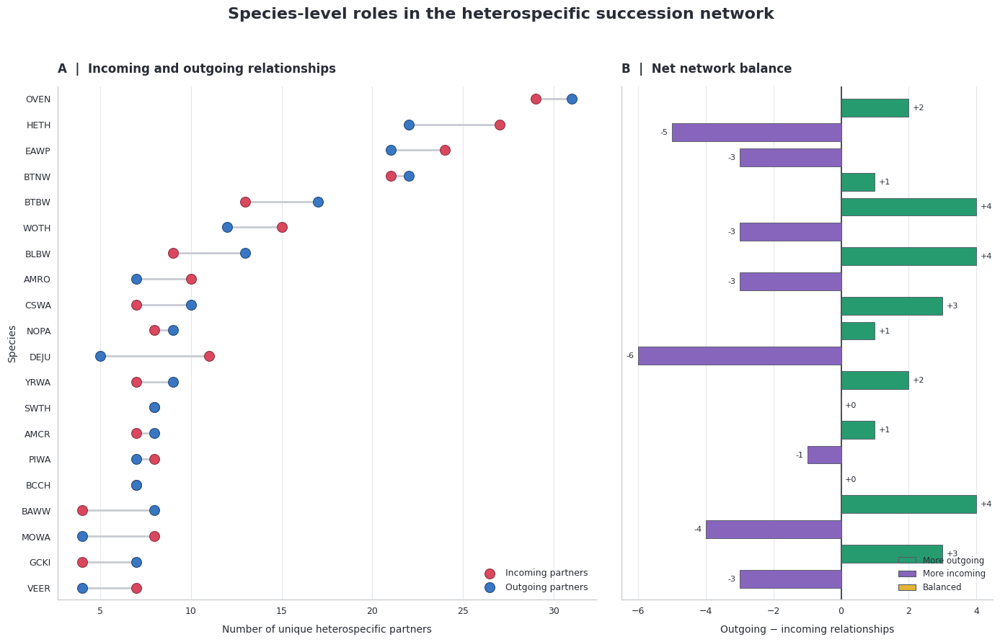

Figure 5 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure5_species_network_roles.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure5_species_network_roles.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure5_species_network_roles.svg


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 5
# Species-level roles in the heterospecific network
# Multicolor publication-quality version
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# MULTICOLOR PALETTE
# ------------------------------------------------------------
C = {
    "incoming": "#D9485F",
    "outgoing": "#3977C3",
    "positive": "#269B70",
    "negative": "#8765BD",
    "neutral": "#E5B536",
    "dark": "#292D36",
    "grid": "#E7E9EF",
    "white": "#FFFFFF"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": C["dark"],
    "axes.labelcolor": C["dark"],
    "axes.edgecolor": "#C9CDD3",
    "axes.facecolor": C["white"],
    "figure.facecolor": C["white"],
    "savefig.facecolor": C["white"]
})

# ------------------------------------------------------------
# VALIDATE INPUT
# ------------------------------------------------------------
required = [
    "source_species",
    "target_species",
    "q_value"
]

missing = [
    col for col in required
    if col not in robust_pairs.columns
]

if missing:
    raise ValueError(
        f"robust_pairs is missing columns: {missing}"
    )

# ------------------------------------------------------------
# FILTER SIGNIFICANT ROBUST PAIRS
# ------------------------------------------------------------
rp = robust_pairs.loc[
    robust_pairs["q_value"] < 0.05
].copy()

rp = rp.loc[
    rp["source_species"] != rp["target_species"]
].copy()

if rp.empty:
    raise ValueError("No qualifying robust relationships found.")

# ------------------------------------------------------------
# CALCULATE UNIQUE PARTNER COUNTS
# ------------------------------------------------------------
outgoing = (
    rp.groupby("source_species")["target_species"]
      .nunique()
      .rename("outgoing")
)

incoming = (
    rp.groupby("target_species")["source_species"]
      .nunique()
      .rename("incoming")
)

roles = pd.concat(
    [outgoing, incoming],
    axis=1
).fillna(0)

roles[["outgoing", "incoming"]] = (
    roles[["outgoing", "incoming"]].astype(int)
)

roles["total"] = roles["outgoing"] + roles["incoming"]

roles["net_balance"] = (
    roles["outgoing"] - roles["incoming"]
)

# Select the 20 most connected species
top = (
    roles.sort_values("total", ascending=False)
         .head(20)
         .sort_values("total", ascending=True)
)

# ------------------------------------------------------------
# FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 9),
    gridspec_kw={"width_ratios": [1.45, 1]}
)

fig.patch.set_facecolor(C["white"])

y = np.arange(len(top))

# ============================================================
# PANEL A — INCOMING VS OUTGOING PARTNERS
# ============================================================
ax = axes[0]

# Connecting lines
for i, (_, row) in enumerate(top.iterrows()):
    ax.plot(
        [row["incoming"], row["outgoing"]],
        [i, i],
        color="#C8CBD2",
        linewidth=2,
        zorder=1
    )

# Incoming partners
ax.scatter(
    top["incoming"],
    y,
    s=100,
    color=C["incoming"],
    edgecolor="#913344",
    linewidth=0.8,
    label="Incoming partners",
    zorder=3
)

# Outgoing partners
ax.scatter(
    top["outgoing"],
    y,
    s=100,
    color=C["outgoing"],
    edgecolor="#244C7B",
    linewidth=0.8,
    label="Outgoing partners",
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(top.index)

ax.set_xlabel(
    "Number of unique heterospecific partners",
    labelpad=9
)
ax.set_ylabel("Species")

ax.set_title(
    "A  |  Incoming and outgoing relationships",
    loc="left",
    pad=14
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

ax.grid(
    axis="x",
    color=C["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# ============================================================
# PANEL B — NET NETWORK BALANCE
# ============================================================
ax = axes[1]

balance = top["net_balance"]

bar_colors = [
    C["positive"] if value > 0
    else C["negative"] if value < 0
    else C["neutral"]
    for value in balance
]

bars = ax.barh(
    y,
    balance,
    color=bar_colors,
    edgecolor="#555B66",
    linewidth=0.65,
    height=0.72,
    zorder=3
)

ax.axvline(
    0,
    color=C["dark"],
    linewidth=1.2,
    zorder=2
)

# Value labels
for bar, value in zip(bars, balance):

    if value > 0:
        x_pos = value + 0.12
        alignment = "left"
    elif value < 0:
        x_pos = value - 0.12
        alignment = "right"
    else:
        x_pos = 0.12
        alignment = "left"

    ax.text(
        x_pos,
        bar.get_y() + bar.get_height() / 2,
        f"{int(value):+d}",
        va="center",
        ha=alignment,
        fontsize=8,
        color=C["dark"]
    )

ax.set_yticks(y)
ax.set_yticklabels([])

ax.set_xlabel(
    "Outgoing − incoming relationships",
    labelpad=9
)

ax.set_title(
    "B  |  Net network balance",
    loc="left",
    pad=14
)

# Legend
legend_elements = [
    Patch(
        facecolor=C["positive"],
        edgecolor="#555B66",
        label="More outgoing"
    ),
    Patch(
        facecolor=C["negative"],
        edgecolor="#555B66",
        label="More incoming"
    ),
    Patch(
        facecolor=C["neutral"],
        edgecolor="#555B66",
        label="Balanced"
    )
]

ax.legend(
    handles=legend_elements,
    frameon=False,
    fontsize=8.5,
    loc="lower right"
)

ax.grid(
    axis="x",
    color=C["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# FORMATTING
# ------------------------------------------------------------
for ax in axes:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#C9CDD3")
    ax.spines["bottom"].set_color("#C9CDD3")

    ax.tick_params(
        axis="both",
        colors=C["dark"],
        length=3
    )

    ax.margins(y=0.025)

fig.suptitle(
    "Species-level roles in the heterospecific succession network",
    fontsize=16,
    fontweight="bold",
    color=C["dark"],
    y=0.985
)

fig.tight_layout(
    rect=[0, 0, 1, 0.955],
    w_pad=2.5
)

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure5_species_network_roles"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 5 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

**Figure 5. Species-level roles in the heterospecific succession network.** (A) Number of unique heterospecific partners for each species, separated into incoming and outgoing robust enriched relationships. (B) Net network balance, calculated as outgoing minus incoming relationships. Positive values indicate more outgoing relationships, while negative values indicate more incoming relationships. Colors distinguish incoming and outgoing relationships and the direction of net network balance. Only robust heterospecific relationships with FDR-adjusted \(q < 0.05\) are included. The 20 species with the greatest total number of unique partners are displayed.

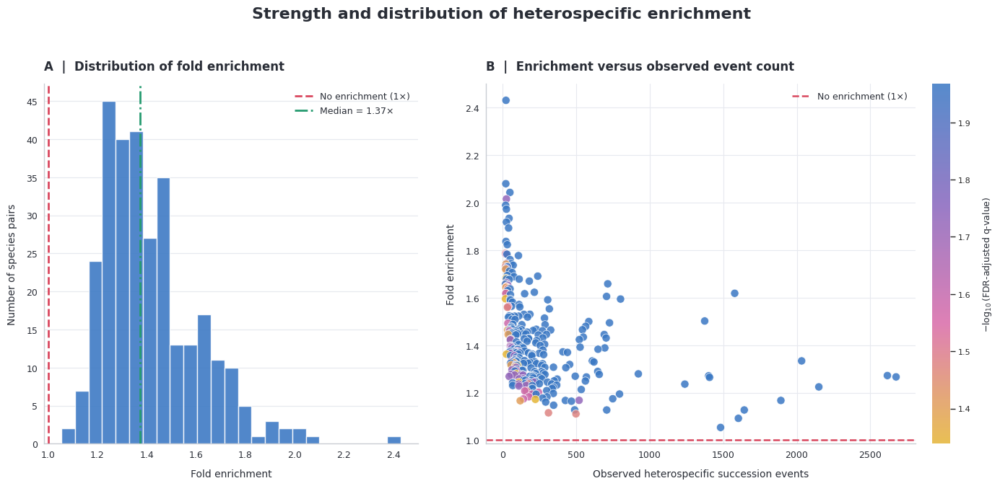

Figure 6 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure6_heterospecific_enrichment_distribution.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure6_heterospecific_enrichment_distribution.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure6_heterospecific_enrichment_distribution.svg

Summary of plotted robust pairs:
Number of pairs: 300
Median fold enrichment: 1.373
Mean fold enrichment: 1.416
Minimum fold enrichment: 1.054
Maximum fold enrichment: 2.431
Pairs with fold enrichment > 2: 4 (1.3%)


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 6
# Distribution and strength of heterospecific enrichment
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# MULTICOLOR PUBLICATION PALETTE
# ------------------------------------------------------------
C = {
    "blue": "#3977C3",
    "red": "#D9485F",
    "green": "#269B70",
    "yellow": "#E5B536",
    "pink": "#D96AA8",
    "purple": "#8765BD",
    "teal": "#36A6A0",
    "dark": "#292D36",
    "grey": "#858B96",
    "grid": "#E7E9EF",
    "white": "#FFFFFF"
}

# Significance gradient for Panel B
significance_cmap = LinearSegmentedColormap.from_list(
    "significance_multicolor",
    [C["yellow"], C["pink"], C["purple"], C["blue"]]
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": C["dark"],
    "axes.labelcolor": C["dark"],
    "axes.edgecolor": "#C9CDD3",
    "axes.facecolor": C["white"],
    "figure.facecolor": C["white"],
    "savefig.facecolor": C["white"]
})

# ------------------------------------------------------------
# VALIDATE DATA
# ------------------------------------------------------------
required = [
    "source_species",
    "target_species",
    "observed_edges",
    "fold_enrichment",
    "q_value"
]

missing = [
    col for col in required
    if col not in robust_pairs.columns
]

if missing:
    raise ValueError(
        f"robust_pairs is missing columns: {missing}"
    )

# ------------------------------------------------------------
# PREPARE ROBUST PAIR DATA
# ------------------------------------------------------------
df = robust_pairs.copy()

for col in ["observed_edges", "fold_enrichment", "q_value"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=["observed_edges", "fold_enrichment", "q_value"]
)

# Retain FDR-significant relationships
df = df.loc[
    (df["q_value"] < 0.05) &
    (df["fold_enrichment"] > 0) &
    (df["observed_edges"] > 0)
].copy()

if df.empty:
    raise ValueError("No valid robust enriched pairs found.")

# Calculate significance for color encoding
df["minus_log10_q"] = -np.log10(
    df["q_value"].clip(lower=1e-300)
)

# ------------------------------------------------------------
# FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6.8),
    gridspec_kw={"width_ratios": [1, 1.25]}
)

fig.patch.set_facecolor(C["white"])

# ============================================================
# PANEL A — DISTRIBUTION OF FOLD ENRICHMENT
# ============================================================
ax = axes[0]

values = df["fold_enrichment"].values

# Histogram
ax.hist(
    values,
    bins=25,
    color=C["blue"],
    edgecolor="white",
    linewidth=1.0,
    alpha=0.88,
    zorder=3
)

# Reference: no enrichment
ax.axvline(
    1,
    color=C["red"],
    linestyle="--",
    linewidth=2,
    label="No enrichment (1×)",
    zorder=4
)

# Median enrichment
median_enrichment = np.median(values)

ax.axvline(
    median_enrichment,
    color=C["green"],
    linestyle="-.",
    linewidth=2,
    label=f"Median = {median_enrichment:.2f}×",
    zorder=4
)

ax.set_xlabel("Fold enrichment", labelpad=9)
ax.set_ylabel("Number of species pairs", labelpad=9)

ax.set_title(
    "A  |  Distribution of fold enrichment",
    loc="left",
    pad=14
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

ax.grid(
    axis="y",
    color=C["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

# ============================================================
# PANEL B — OBSERVED EVENTS VS FOLD ENRICHMENT
# ============================================================
ax = axes[1]

scatter = ax.scatter(
    df["observed_edges"],
    df["fold_enrichment"],
    c=df["minus_log10_q"],
    cmap=significance_cmap,
    s=65,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.55,
    zorder=3
)

# No-enrichment reference
ax.axhline(
    1,
    color=C["red"],
    linestyle="--",
    linewidth=1.8,
    label="No enrichment (1×)",
    zorder=2
)

ax.set_xlabel(
    "Observed heterospecific succession events",
    labelpad=9
)

ax.set_ylabel(
    "Fold enrichment",
    labelpad=9
)

ax.set_title(
    "B  |  Enrichment versus observed event count",
    loc="left",
    pad=14
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

ax.grid(
    color=C["grid"],
    linewidth=0.8
)
ax.set_axisbelow(True)

# Colorbar: FDR significance
cbar = fig.colorbar(
    scatter,
    ax=ax,
    fraction=0.045,
    pad=0.035
)

cbar.set_label(
    r"$-\log_{10}$(FDR-adjusted q-value)",
    fontsize=9,
    labelpad=10
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=8)

# ------------------------------------------------------------
# CONSISTENT FORMATTING
# ------------------------------------------------------------
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#C9CDD3")
    ax.spines["bottom"].set_color("#C9CDD3")

    ax.tick_params(
        axis="both",
        colors=C["dark"],
        length=3
    )

# Main title
fig.suptitle(
    "Strength and distribution of heterospecific enrichment",
    fontsize=16,
    fontweight="bold",
    color=C["dark"],
    y=0.985
)

fig.tight_layout(
    rect=[0, 0, 1, 0.95],
    w_pad=2.8
)

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure6_heterospecific_enrichment_distribution"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# PRINT SUMMARY STATISTICS
# ------------------------------------------------------------
print("Figure 6 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

print("\nSummary of plotted robust pairs:")
print(f"Number of pairs: {len(df)}")
print(f"Median fold enrichment: {median_enrichment:.3f}")
print(f"Mean fold enrichment: {values.mean():.3f}")
print(f"Minimum fold enrichment: {values.min():.3f}")
print(f"Maximum fold enrichment: {values.max():.3f}")
print(
    f"Pairs with fold enrichment > 2: "
    f"{(values > 2).sum()} ({(values > 2).mean()*100:.1f}%)"
)

**Figure 6. Distribution and strength of heterospecific succession enrichment. **(A) Distribution of fold-enrichment values among robust heterospecific species pairs. The dashed red line indicates the reference value of 1, corresponding to no enrichment relative to the null expectation; the green dash-dot line indicates the median fold enrichment. (B) Relationship between observed succession-event counts and fold enrichment. Each point represents a directed heterospecific species pair, with color indicating the strength of statistical evidence using the negative logarithm of its FDR-adjusted q-value. Only robust pairs with FDR-adjusted \(q < 0.05\) are included.

Interpretation note: Fold enrichment describes the ratio of observed to null-expected relationships. It should be interpreted alongside observed event counts: a large enrichment ratio does not necessarily imply a large absolute number of succession events.

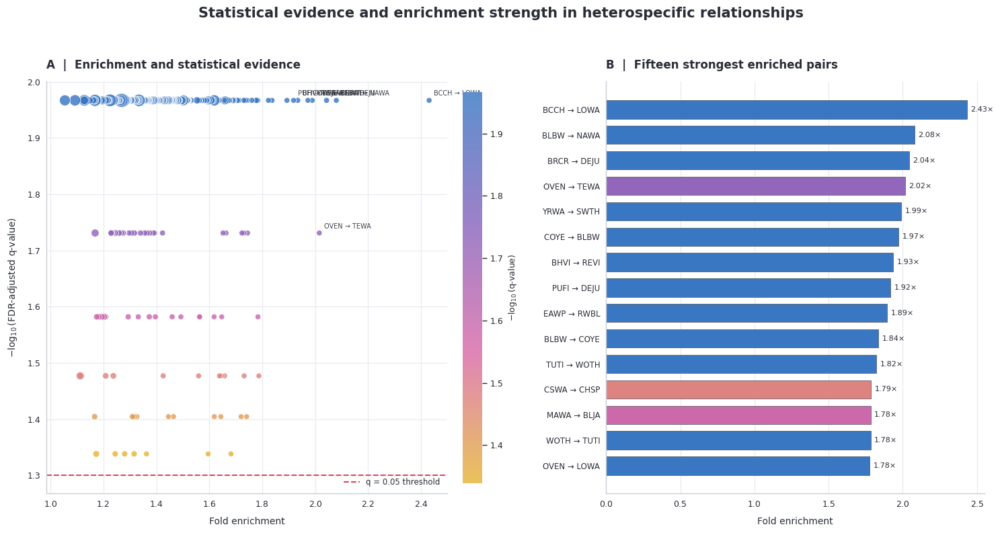

Figure 7 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure7_enrichment_evidence.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure7_enrichment_evidence.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure7_enrichment_evidence.svg

Summary:
Robust significant pairs plotted: 300
Median fold enrichment: 1.373
Maximum fold enrichment: 2.431
Median adjusted q-value: 0.01079


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 7
# Enrichment strength versus statistical evidence
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# MULTICOLOR PALETTE
# ------------------------------------------------------------
C = {
    "blue": "#3977C3",
    "red": "#D9485F",
    "green": "#269B70",
    "yellow": "#E5B536",
    "pink": "#D96AA8",
    "purple": "#8765BD",
    "teal": "#36A6A0",
    "dark": "#292D36",
    "grey": "#858B96",
    "grid": "#E7E9EF",
    "white": "#FFFFFF"
}

evidence_cmap = LinearSegmentedColormap.from_list(
    "evidence_multicolor",
    [
        C["yellow"],
        C["pink"],
        C["purple"],
        C["blue"]
    ]
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": C["dark"],
    "axes.labelcolor": C["dark"],
    "axes.edgecolor": "#C9CDD3",
    "axes.facecolor": C["white"],
    "figure.facecolor": C["white"],
    "savefig.facecolor": C["white"]
})

# ------------------------------------------------------------
# VALIDATE DATA
# ------------------------------------------------------------
required = [
    "source_species",
    "target_species",
    "observed_edges",
    "fold_enrichment",
    "q_value"
]

missing = [
    col for col in required
    if col not in robust_pairs.columns
]

if missing:
    raise ValueError(
        f"robust_pairs is missing columns: {missing}"
    )

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------
df = robust_pairs.copy()

for col in ["observed_edges", "fold_enrichment", "q_value"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(
    subset=[
        "observed_edges",
        "fold_enrichment",
        "q_value"
    ]
)

df = df.loc[
    (df["q_value"] > 0) &
    (df["fold_enrichment"] > 0) &
    (df["observed_edges"] > 0)
].copy()

df = df.loc[df["q_value"] < 0.05].copy()

if df.empty:
    raise ValueError("No valid robust enriched pairs were found.")

df["minus_log10_q"] = -np.log10(df["q_value"])

df["pair_label"] = (
    df["source_species"].astype(str)
    + " → "
    + df["target_species"].astype(str)
)

# ------------------------------------------------------------
# SELECT TOP 15 ENRICHED PAIRS
# ------------------------------------------------------------
top15 = (
    df.sort_values(
        ["fold_enrichment", "observed_edges"],
        ascending=[False, False]
    )
    .head(15)
    .sort_values("fold_enrichment", ascending=True)
)

# ------------------------------------------------------------
# FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8),
    gridspec_kw={"width_ratios": [1.15, 1]}
)

fig.patch.set_facecolor(C["white"])

# ============================================================
# PANEL A — ENRICHMENT VS STATISTICAL EVIDENCE
# ============================================================
ax = axes[0]

# Bubble size represents observed event count
sizes = (
    35
    + 180 * (
        df["observed_edges"] / df["observed_edges"].max()
    )
)

norm = Normalize(
    vmin=df["minus_log10_q"].min(),
    vmax=df["minus_log10_q"].max()
)

scatter = ax.scatter(
    df["fold_enrichment"],
    df["minus_log10_q"],
    s=sizes,
    c=df["minus_log10_q"],
    cmap=evidence_cmap,
    norm=norm,
    alpha=0.82,
    edgecolor="white",
    linewidth=0.65,
    zorder=3
)

# Reference for q = 0.05
q_reference = -np.log10(0.05)

ax.axhline(
    q_reference,
    color=C["red"],
    linestyle="--",
    linewidth=1.5,
    label="q = 0.05 threshold"
)

# Annotate selected high-enrichment relationships
label_rows = df.nlargest(
    min(8, len(df)),
    "fold_enrichment"
)

for _, row in label_rows.iterrows():
    ax.annotate(
        row["pair_label"],
        (
            row["fold_enrichment"],
            row["minus_log10_q"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7,
        color=C["dark"],
        alpha=0.9
    )

ax.set_xlabel("Fold enrichment", labelpad=9)
ax.set_ylabel(r"$-\log_{10}$(FDR-adjusted q-value)", labelpad=9)

ax.set_title(
    "A  |  Enrichment and statistical evidence",
    loc="left",
    pad=14
)

ax.legend(
    frameon=False,
    fontsize=8.5,
    loc="lower right"
)

ax.grid(
    color=C["grid"],
    linewidth=0.8
)
ax.set_axisbelow(True)

cbar = fig.colorbar(
    scatter,
    ax=ax,
    fraction=0.045,
    pad=0.035
)

cbar.set_label(
    r"$-\log_{10}$(q-value)",
    fontsize=9
)
cbar.outline.set_visible(False)

# ============================================================
# PANEL B — TOP 15 ENRICHED PAIRS
# ============================================================
ax = axes[1]

y = np.arange(len(top15))

bar_colors = [
    evidence_cmap(
        norm(-np.log10(q))
    )
    for q in top15["q_value"]
]

bars = ax.barh(
    y,
    top15["fold_enrichment"],
    color=bar_colors,
    edgecolor="#555B66",
    linewidth=0.55,
    height=0.72
)

ax.set_yticks(y)
ax.set_yticklabels(top15["pair_label"], fontsize=8.5)

ax.set_xlabel("Fold enrichment", labelpad=9)

ax.set_title(
    "B  |  Fifteen strongest enriched pairs",
    loc="left",
    pad=14
)

# Annotate fold-enrichment values
for bar, value in zip(bars, top15["fold_enrichment"]):
    ax.text(
        value + 0.025,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}×",
        va="center",
        ha="left",
        fontsize=8,
        color=C["dark"]
    )

ax.grid(
    axis="x",
    color=C["grid"],
    linewidth=0.8
)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# FINAL FORMATTING
# ------------------------------------------------------------
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#C9CDD3")
    ax.spines["bottom"].set_color("#C9CDD3")

    ax.tick_params(
        axis="both",
        colors=C["dark"],
        length=3
    )

fig.suptitle(
    "Statistical evidence and enrichment strength in heterospecific relationships",
    fontsize=15,
    fontweight="bold",
    color=C["dark"],
    y=0.985
)

fig.tight_layout(
    rect=[0, 0, 1, 0.95],
    w_pad=2.5
)

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure7_enrichment_evidence"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------
print("Figure 7 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

print("\nSummary:")
print(f"Robust significant pairs plotted: {len(df)}")
print(f"Median fold enrichment: {df['fold_enrichment'].median():.3f}")
print(f"Maximum fold enrichment: {df['fold_enrichment'].max():.3f}")
print(f"Median adjusted q-value: {df['q_value'].median():.5f}")

**Figure 7. Statistical evidence and enrichment strength in heterospecific succession relationships.** (A) Relationship between fold enrichment and statistical evidence across robust heterospecific species pairs. Each point represents one directed species pair; point size represents the number of observed succession events, while color represents the negative logarithm of the FDR-adjusted q-value. The dashed horizontal line indicates the \(q=0.05\) threshold. (B) The 15 species pairs with the greatest fold enrichment, ranked by enrichment magnitude. Bar color reflects adjusted statistical evidence.

Interpretation note: Enrichment magnitude, observed event count, and statistical evidence capture different aspects of the results. They should not be treated as interchangeable measures of biological importance.

One methodological distinction: This figure uses only the 300 robust significant pairs, not all 2,602 tested pairs. It therefore describes variation within the robust subset, rather than a full significant-versus-nonsignificant comparison.

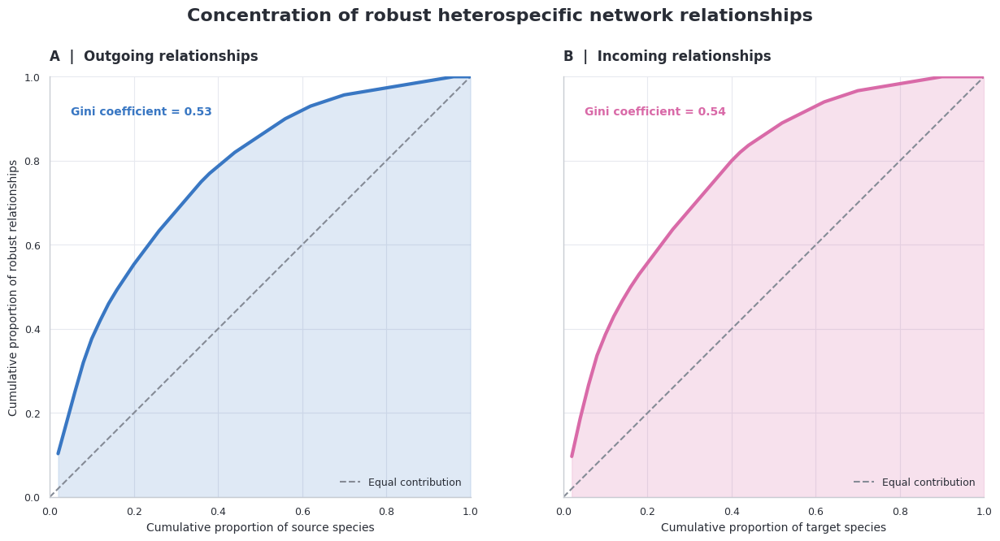

Figure 8 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure8_network_relationship_concentration.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure8_network_relationship_concentration.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure8_network_relationship_concentration.svg

Network concentration summary
--------------------------------
Species represented: 50
Robust directed relationships: 300
Outgoing Gini coefficient: 0.527
Incoming Gini coefficient: 0.544
Top 5 source species account for 37.7% of outgoing relationships.
Top 5 target species account for 38.7% of incoming relationships.


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 8
# Concentration of heterospecific network relationships
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# MULTICOLOR PALETTE
# ------------------------------------------------------------
C = {
    "blue": "#3977C3",
    "red": "#D9485F",
    "green": "#269B70",
    "yellow": "#E5B536",
    "pink": "#D96AA8",
    "purple": "#8765BD",
    "teal": "#36A6A0",
    "dark": "#292D36",
    "grey": "#858B96",
    "grid": "#E7E9EF",
    "white": "#FFFFFF"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.facecolor": C["white"],
    "axes.facecolor": C["white"],
    "savefig.facecolor": C["white"],
    "text.color": C["dark"],
    "axes.labelcolor": C["dark"]
})

# ------------------------------------------------------------
# VALIDATE DATA
# ------------------------------------------------------------
required = [
    "source_species",
    "target_species",
    "q_value"
]

missing = [
    col for col in required
    if col not in robust_pairs.columns
]

if missing:
    raise ValueError(
        f"robust_pairs is missing columns: {missing}"
    )

# ------------------------------------------------------------
# FILTER ROBUST SIGNIFICANT RELATIONSHIPS
# ------------------------------------------------------------
rp = robust_pairs.loc[
    robust_pairs["q_value"] < 0.05
].copy()

rp = rp.loc[
    rp["source_species"] != rp["target_species"]
].copy()

if rp.empty:
    raise ValueError("No qualifying robust relationships found.")

# ------------------------------------------------------------
# CALCULATE SPECIES-LEVEL NETWORK COUNTS
# ------------------------------------------------------------
outgoing = (
    rp.groupby("source_species")
      .size()
      .sort_values(ascending=False)
)

incoming = (
    rp.groupby("target_species")
      .size()
      .sort_values(ascending=False)
)

# Include species with zero relationships in the opposite role
all_species = sorted(
    set(rp["source_species"]) |
    set(rp["target_species"])
)

outgoing = outgoing.reindex(all_species, fill_value=0)
incoming = incoming.reindex(all_species, fill_value=0)

# ------------------------------------------------------------
# CUMULATIVE CONTRIBUTION FUNCTION
# ------------------------------------------------------------
def cumulative_contribution(series):

    values = np.sort(series.to_numpy())[::-1]
    total = values.sum()

    if total == 0:
        raise ValueError("Cannot calculate contribution: total is zero.")

    cumulative_relationships = np.cumsum(values) / total
    cumulative_species = (
        np.arange(1, len(values) + 1) / len(values)
    )

    return cumulative_species, cumulative_relationships


x_out, y_out = cumulative_contribution(outgoing)
x_in, y_in = cumulative_contribution(incoming)

# ------------------------------------------------------------
# GINI COEFFICIENT
# ------------------------------------------------------------
def gini_coefficient(values):

    values = np.asarray(values, dtype=float)
    values = np.sort(values)

    if np.sum(values) == 0:
        return np.nan

    n = len(values)
    cumulative_ranked = np.arange(1, n + 1)

    return (
        2 * np.sum(cumulative_ranked * values)
        / (n * np.sum(values))
        - (n + 1) / n
    )


gini_out = gini_coefficient(outgoing.values)
gini_in = gini_coefficient(incoming.values)

# ------------------------------------------------------------
# FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6.5),
    sharex=True,
    sharey=True
)

fig.patch.set_facecolor(C["white"])

# ============================================================
# PANEL A — OUTGOING CONCENTRATION
# ============================================================
ax = axes[0]

ax.plot(
    x_out,
    y_out,
    color=C["blue"],
    linewidth=3,
    zorder=3
)

ax.fill_between(
    x_out,
    y_out,
    color=C["blue"],
    alpha=0.16
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color=C["grey"],
    linewidth=1.5,
    label="Equal contribution"
)

ax.set_title(
    "A  |  Outgoing relationships",
    loc="left",
    pad=14
)

ax.set_xlabel(
    "Cumulative proportion of source species"
)

ax.set_ylabel(
    "Cumulative proportion of robust relationships"
)

ax.text(
    0.05,
    0.93,
    f"Gini coefficient = {gini_out:.2f}",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    color=C["blue"],
    va="top"
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

# ============================================================
# PANEL B — INCOMING CONCENTRATION
# ============================================================
ax = axes[1]

ax.plot(
    x_in,
    y_in,
    color=C["pink"],
    linewidth=3,
    zorder=3
)

ax.fill_between(
    x_in,
    y_in,
    color=C["pink"],
    alpha=0.20
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color=C["grey"],
    linewidth=1.5,
    label="Equal contribution"
)

ax.set_title(
    "B  |  Incoming relationships",
    loc="left",
    pad=14
)

ax.set_xlabel(
    "Cumulative proportion of target species"
)

ax.text(
    0.05,
    0.93,
    f"Gini coefficient = {gini_in:.2f}",
    transform=ax.transAxes,
    fontsize=10,
    fontweight="bold",
    color=C["pink"],
    va="top"
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

# ------------------------------------------------------------
# SHARED FORMATTING
# ------------------------------------------------------------
for ax in axes:

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    ax.set_aspect("equal", adjustable="box")

    ax.grid(
        color=C["grid"],
        linewidth=0.8
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#C9CDD3")
    ax.spines["bottom"].set_color("#C9CDD3")

    ax.tick_params(
        colors=C["dark"],
        labelsize=9
    )

fig.suptitle(
    "Concentration of robust heterospecific network relationships",
    fontsize=16,
    fontweight="bold",
    color=C["dark"],
    y=0.985
)

fig.tight_layout(
    rect=[0, 0, 1, 0.95],
    w_pad=2.5
)

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure8_network_relationship_concentration"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------
print("Figure 8 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

print("\nNetwork concentration summary")
print("--------------------------------")
print(f"Species represented: {len(all_species)}")
print(f"Robust directed relationships: {len(rp)}")
print(f"Outgoing Gini coefficient: {gini_out:.3f}")
print(f"Incoming Gini coefficient: {gini_in:.3f}")
print(
    "Top 5 source species account for "
    f"{outgoing.sort_values(ascending=False).head(5).sum() / outgoing.sum() * 100:.1f}% "
    "of outgoing relationships."
)
print(
    "Top 5 target species account for "
    f"{incoming.sort_values(ascending=False).head(5).sum() / incoming.sum() * 100:.1f}% "
    "of incoming relationships."
)

**Figure 8. Concentration of robust heterospecific succession relationships across species.** (A) Cumulative proportion of outgoing robust relationships accounted for by progressively larger proportions of source species, ranked from highest to lowest contribution. (B) Corresponding cumulative distribution of incoming relationships across target species. The dashed diagonal represents an equal distribution in which each species contributes proportionally to the network. Gini coefficients summarize the degree of concentration, with larger values indicating greater inequality in the distribution of relationships. Only robust heterospecific relationships with FDR-adjusted \(q < 0.05\) are included.

Interpretation note: These curves describe concentration within the significant robust network. They do not establish why particular species occupy more connected positions, nor do they measure total vocalization abundance.

A methodological distinction: The Gini coefficients are descriptive summaries of this filtered network, not tests of statistical significance.

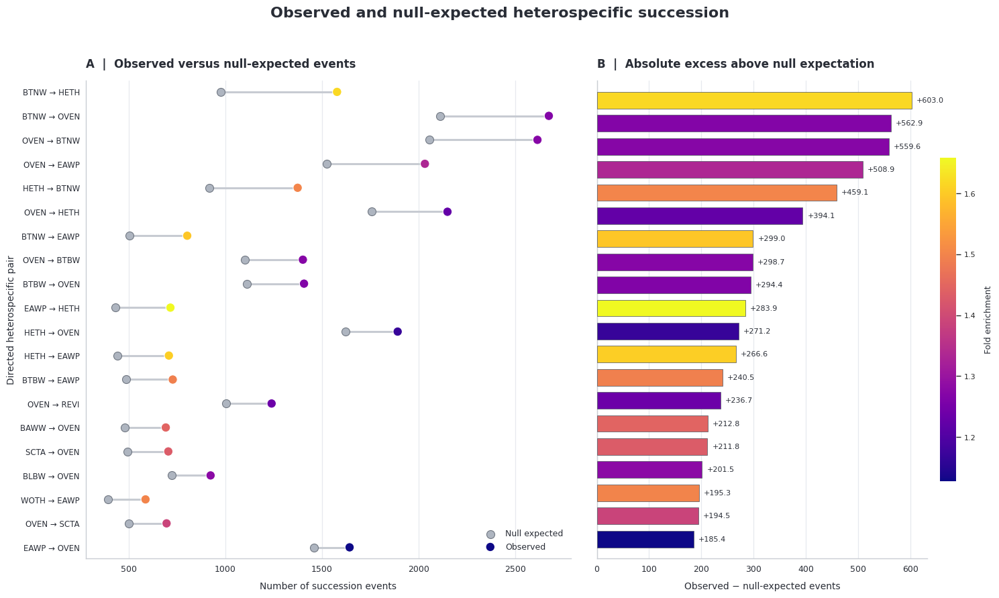

Figure 9 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure9_observed_vs_null_excess.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure9_observed_vs_null_excess.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure9_observed_vs_null_excess.svg

Top 20 excess relationships:
 pair_label  observed_edges  null_mean  difference  fold_enrichment  q_value
EAWP → OVEN            1643   1457.587     185.413         1.127205 0.010786
OVEN → SCTA             695    500.531     194.469         1.388525 0.010786
WOTH → EAWP             586    390.733     195.267         1.499745 0.010786
BLBW → OVEN             923    721.488     201.512         1.279301 0.010786
SCTA → OVEN             704    492.167     211.833         1.430409 0.010786
BAWW → OVEN             691    478.204     212.796         1.444990 0.010786
OVEN → REVI            1239   1002.331     236.669         1.236119 0.010786
BTBW → EAWP             727    486.

In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 9
# Observed versus null-expected heterospecific succession
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# MULTICOLOR PALETTE
# ------------------------------------------------------------
C = {
    "observed": "#3977C3",
    "null": "#AEB5C0",
    "positive": "#269B70",
    "negative": "#D9485F",
    "purple": "#8765BD",
    "pink": "#D96AA8",
    "yellow": "#E5B536",
    "dark": "#292D36",
    "grid": "#E7E9EF",
    "white": "#FFFFFF"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.facecolor": C["white"],
    "axes.facecolor": C["white"],
    "savefig.facecolor": C["white"],
    "text.color": C["dark"],
    "axes.labelcolor": C["dark"]
})

# ------------------------------------------------------------
# VALIDATE DATA
# ------------------------------------------------------------
required = [
    "source_species",
    "target_species",
    "observed_edges",
    "null_mean",
    "difference",
    "fold_enrichment",
    "q_value"
]

missing = [
    col for col in required
    if col not in robust_pairs.columns
]

if missing:
    raise ValueError(
        f"robust_pairs is missing columns: {missing}"
    )

# ------------------------------------------------------------
# PREPARE DATA
# ------------------------------------------------------------
df = robust_pairs.copy()

numeric_cols = [
    "observed_edges",
    "null_mean",
    "difference",
    "fold_enrichment",
    "q_value"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=numeric_cols)

# Retain robust, FDR-significant enriched relationships
df = df.loc[
    (df["q_value"] < 0.05) &
    (df["difference"] > 0) &
    (df["observed_edges"] > 0)
].copy()

if df.empty:
    raise ValueError("No qualifying enriched pairs were found.")

df["pair_label"] = (
    df["source_species"].astype(str)
    + " → "
    + df["target_species"].astype(str)
)

# ------------------------------------------------------------
# SELECT 20 PAIRS WITH THE LARGEST ABSOLUTE EXCESS
# ------------------------------------------------------------
top20 = (
    df.sort_values("difference", ascending=False)
      .head(20)
      .sort_values("difference", ascending=True)
      .reset_index(drop=True)
)

# ------------------------------------------------------------
# FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 9),
    gridspec_kw={"width_ratios": [1.35, 1]}
)

fig.patch.set_facecolor(C["white"])

y = np.arange(len(top20))

# Fold enrichment color mapping
norm = Normalize(
    vmin=top20["fold_enrichment"].min(),
    vmax=top20["fold_enrichment"].max()
)

cmap = plt.get_cmap("plasma")

# ============================================================
# PANEL A — OBSERVED VERSUS NULL EXPECTED
# ============================================================
ax = axes[0]

for i, row in top20.iterrows():

    ax.plot(
        [row["null_mean"], row["observed_edges"]],
        [i, i],
        color="#C7CBD2",
        linewidth=2.2,
        zorder=1
    )

# Null expected values
ax.scatter(
    top20["null_mean"],
    y,
    s=75,
    color=C["null"],
    edgecolor="#707782",
    linewidth=0.8,
    label="Null expected",
    zorder=3
)

# Observed values
ax.scatter(
    top20["observed_edges"],
    y,
    s=95,
    c=top20["fold_enrichment"],
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.8,
    label="Observed",
    zorder=4
)

ax.set_yticks(y)
ax.set_yticklabels(top20["pair_label"], fontsize=8.5)

ax.set_xlabel(
    "Number of succession events",
    labelpad=9
)
ax.set_ylabel("Directed heterospecific pair")

ax.set_title(
    "A  |  Observed versus null-expected events",
    loc="left",
    pad=14
)

ax.legend(
    frameon=False,
    fontsize=9,
    loc="lower right"
)

ax.grid(
    axis="x",
    color=C["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# ============================================================
# PANEL B — ABSOLUTE EXCESS ABOVE NULL EXPECTATION
# ============================================================
ax = axes[1]

bar_colors = cmap(norm(top20["fold_enrichment"]))

bars = ax.barh(
    y,
    top20["difference"],
    color=bar_colors,
    edgecolor="#555B66",
    linewidth=0.55,
    height=0.72,
    zorder=3
)

# Numeric labels
for bar, value in zip(bars, top20["difference"]):
    ax.text(
        value + max(top20["difference"]) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"+{value:.1f}",
        va="center",
        ha="left",
        fontsize=8,
        color=C["dark"]
    )

ax.set_yticks(y)
ax.set_yticklabels([])

ax.set_xlabel(
    "Observed − null-expected events",
    labelpad=9
)

ax.set_title(
    "B  |  Absolute excess above null expectation",
    loc="left",
    pad=14
)

ax.grid(
    axis="x",
    color=C["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# Colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.045,
    pad=0.035
)

cbar.set_label(
    "Fold enrichment",
    fontsize=9,
    labelpad=9
)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=8)

# ------------------------------------------------------------
# FINAL FORMATTING
# ------------------------------------------------------------
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#C9CDD3")
    ax.spines["bottom"].set_color("#C9CDD3")

    ax.tick_params(
        axis="both",
        colors=C["dark"],
        length=3
    )

    ax.margins(y=0.025)

fig.suptitle(
    "Observed and null-expected heterospecific succession",
    fontsize=16,
    fontweight="bold",
    color=C["dark"],
    y=0.985
)

fig.tight_layout(
    rect=[0, 0, 1, 0.955],
    w_pad=2.5
)

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure9_observed_vs_null_excess"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------
print("Figure 9 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

print("\nTop 20 excess relationships:")
print(
    top20[
        [
            "pair_label",
            "observed_edges",
            "null_mean",
            "difference",
            "fold_enrichment",
            "q_value"
        ]
    ].to_string(index=False)
)

**Figure 9. Observed versus null-expected heterospecific succession events.** (A) Comparison of observed succession-event counts and mean null-model expectations for the 20 directed heterospecific species pairs with the largest positive absolute differences. Grey points represent null expectations, while colored points represent observed counts; connecting lines illustrate the excess above null expectation. (B) Absolute excess, calculated as observed minus null-expected event counts. Color indicates fold enrichment. Only robust relationships with FDR-adjusted \(q < 0.05\) and positive excess are included.

Interpretation note: This figure distinguishes absolute excess from relative enrichment. A large absolute excess indicates many more observed events than expected, whereas fold enrichment describes the proportional increase over the null expectation.

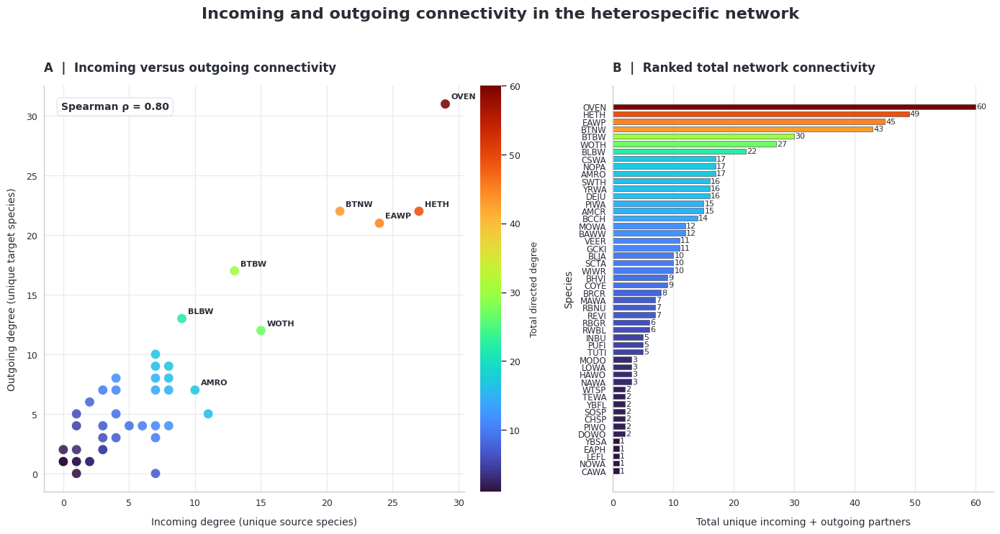

Figure 10 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure10_species_connectivity.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure10_species_connectivity.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure10_species_connectivity.svg

Network connectivity summary
--------------------------------
Species represented: 50
Robust directed relationships: 300
Spearman correlation: 0.804

Most connected species:
      incoming_degree  outgoing_degree  total_degree
OVEN               29               31            60
HETH               27               22            49
EAWP               24               21            45
BTNW               21               22            43
BTBW               13               17            30
WOTH               15               12            27
BLBW                9               13            22
AMRO               10                7            17


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 10
# Incoming versus outgoing species connectivity
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# MULTICOLOR PALETTE
# ------------------------------------------------------------
C = {
    "blue": "#3977C3",
    "red": "#D9485F",
    "green": "#269B70",
    "yellow": "#E5B536",
    "pink": "#D96AA8",
    "purple": "#8765BD",
    "teal": "#36A6A0",
    "dark": "#292D36",
    "grey": "#858B96",
    "grid": "#E7E9EF",
    "white": "#FFFFFF"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "text.color": C["dark"],
    "axes.labelcolor": C["dark"],
    "axes.edgecolor": "#C9CDD3",
    "axes.facecolor": C["white"],
    "figure.facecolor": C["white"],
    "savefig.facecolor": C["white"]
})

# ------------------------------------------------------------
# VALIDATE DATA
# ------------------------------------------------------------
required = [
    "source_species",
    "target_species",
    "q_value"
]

missing = [
    col for col in required
    if col not in robust_pairs.columns
]

if missing:
    raise ValueError(
        f"robust_pairs is missing columns: {missing}"
    )

# ------------------------------------------------------------
# FILTER ROBUST SIGNIFICANT RELATIONSHIPS
# ------------------------------------------------------------
rp = robust_pairs.loc[
    robust_pairs["q_value"] < 0.05
].copy()

rp = rp.loc[
    rp["source_species"] != rp["target_species"]
].copy()

if rp.empty:
    raise ValueError("No qualifying robust relationships found.")

# ------------------------------------------------------------
# CALCULATE UNIQUE INCOMING AND OUTGOING PARTNERS
# ------------------------------------------------------------
outgoing = (
    rp.groupby("source_species")["target_species"]
      .nunique()
      .rename("outgoing_degree")
)

incoming = (
    rp.groupby("target_species")["source_species"]
      .nunique()
      .rename("incoming_degree")
)

all_species = sorted(
    set(rp["source_species"]) |
    set(rp["target_species"])
)

network = pd.concat(
    [incoming, outgoing],
    axis=1
).reindex(all_species).fillna(0)

network["incoming_degree"] = (
    network["incoming_degree"].astype(int)
)

network["outgoing_degree"] = (
    network["outgoing_degree"].astype(int)
)

network["total_degree"] = (
    network["incoming_degree"] +
    network["outgoing_degree"]
)

network["species"] = network.index.astype(str)

# ------------------------------------------------------------
# SPEARMAN RANK CORRELATION
# ------------------------------------------------------------
spearman_rho = network[
    ["incoming_degree", "outgoing_degree"]
].corr(method="spearman").iloc[0, 1]

# Descriptive correlation only; no significance test here.

# ------------------------------------------------------------
# SELECT MOST CONNECTED SPECIES FOR LABELS
# ------------------------------------------------------------
top_species = network.nlargest(
    min(8, len(network)),
    "total_degree"
)

# ------------------------------------------------------------
# FIGURE LAYOUT
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7.5),
    gridspec_kw={"width_ratios": [1.2, 1]}
)

fig.patch.set_facecolor(C["white"])

# ============================================================
# PANEL A — INCOMING VS OUTGOING CONNECTIVITY
# ============================================================
ax = axes[0]

norm = Normalize(
    vmin=network["total_degree"].min(),
    vmax=network["total_degree"].max()
)

cmap = plt.get_cmap("turbo")

scatter = ax.scatter(
    network["incoming_degree"],
    network["outgoing_degree"],
    c=network["total_degree"],
    cmap=cmap,
    norm=norm,
    s=100,
    alpha=0.88,
    edgecolor="white",
    linewidth=0.8,
    zorder=3
)

# Annotate the most connected species
for _, row in top_species.iterrows():

    ax.annotate(
        row["species"],
        (
            row["incoming_degree"],
            row["outgoing_degree"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
        color=C["dark"]
    )

ax.set_xlabel(
    "Incoming degree (unique source species)",
    labelpad=9
)

ax.set_ylabel(
    "Outgoing degree (unique target species)",
    labelpad=9
)

ax.set_title(
    "A  |  Incoming versus outgoing connectivity",
    loc="left",
    pad=14
)

ax.grid(
    color=C["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# Correlation annotation
ax.text(
    0.04,
    0.96,
    f"Spearman ρ = {spearman_rho:.2f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    fontweight="bold",
    color=C["dark"],
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#D9DCE3",
        "alpha": 0.95
    }
)

# Colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    fraction=0.045,
    pad=0.035
)

cbar.set_label(
    "Total directed degree",
    fontsize=9,
    labelpad=9
)

cbar.outline.set_visible(False)

# ============================================================
# PANEL B — RANKED TOTAL CONNECTIVITY
# ============================================================
ax = axes[1]

ranked = network.sort_values(
    "total_degree",
    ascending=True
)

y = np.arange(len(ranked))

bar_colors = cmap(
    norm(ranked["total_degree"].values)
)

bars = ax.barh(
    y,
    ranked["total_degree"],
    color=bar_colors,
    edgecolor="#555B66",
    linewidth=0.5,
    height=0.72
)

ax.set_yticks(y)
ax.set_yticklabels(ranked.index, fontsize=8.5)

ax.set_xlabel(
    "Total unique incoming + outgoing partners",
    labelpad=9
)

ax.set_ylabel("Species")

ax.set_title(
    "B  |  Ranked total network connectivity",
    loc="left",
    pad=14
)

# Value labels
for bar, value in zip(
    bars,
    ranked["total_degree"]
):
    ax.text(
        value + 0.15,
        bar.get_y() + bar.get_height() / 2,
        str(int(value)),
        va="center",
        ha="left",
        fontsize=8,
        color=C["dark"]
    )

ax.grid(
    axis="x",
    color=C["grid"],
    linewidth=0.9
)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# FORMATTING
# ------------------------------------------------------------
for ax in axes:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color("#C9CDD3")
    ax.spines["bottom"].set_color("#C9CDD3")

    ax.tick_params(
        axis="both",
        colors=C["dark"],
        length=3
    )

fig.suptitle(
    "Incoming and outgoing connectivity in the heterospecific network",
    fontsize=16,
    fontweight="bold",
    color=C["dark"],
    y=0.985
)

fig.tight_layout(
    rect=[0, 0, 1, 0.95],
    w_pad=2.5
)

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure10_species_connectivity"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------
print("Figure 10 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

print("\nNetwork connectivity summary")
print("--------------------------------")
print(f"Species represented: {len(network)}")
print(f"Robust directed relationships: {len(rp)}")
print(f"Spearman correlation: {spearman_rho:.3f}")

print("\nMost connected species:")
print(
    top_species[
        [
            "incoming_degree",
            "outgoing_degree",
            "total_degree"
        ]
    ].to_string()
)

**Figure 10. Relationship between incoming and outgoing connectivity in the heterospecific succession network.** (A) Association between the number of unique incoming and outgoing heterospecific partners for each species. Each point represents one species, and point color indicates total directed degree, calculated as the sum of incoming and outgoing partners. The eight most connected species are labeled. Spearman's rank correlation coefficient summarizes the association between incoming and outgoing connectivity. (B) Species ranked by total directed degree. Only robust heterospecific relationships with FDR-adjusted \(q < 0.05\) are included.

Interpretation note: A positive association would indicate that species connected to many partners as targets also tend to be connected to many partners as sources. Total directed degree counts incoming and outgoing connections separately, so a species pair connected in both directions contributes two connections.

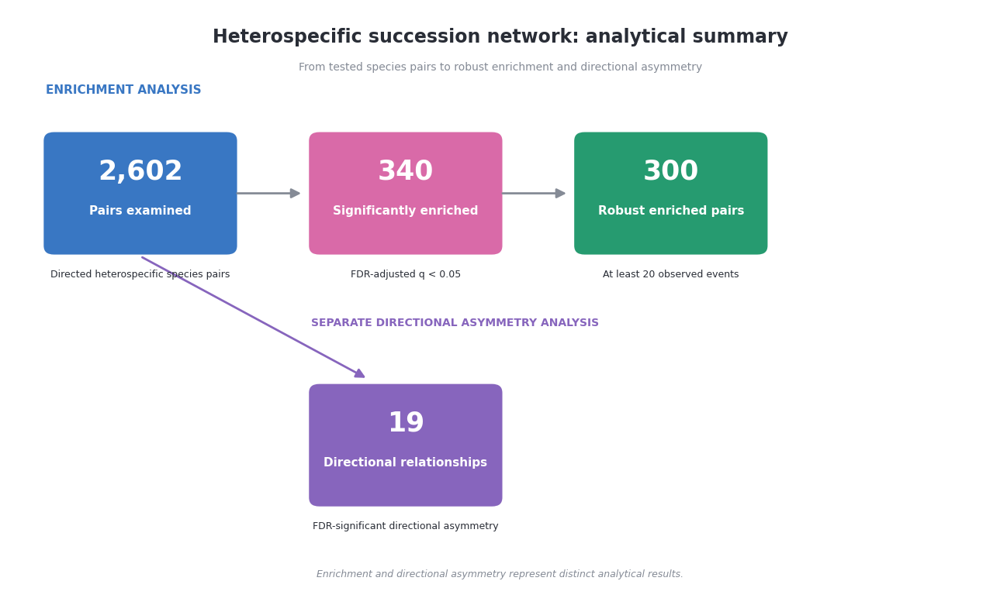

Figure 11 exported:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure11_heterospecific_analysis_summary.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure11_heterospecific_analysis_summary.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q2_Figure11_heterospecific_analysis_summary.svg


In [ ]:
# ============================================================
# QUESTION 2 — FIGURE 11
# Summary of heterospecific network results
# Publication-quality analytical flow diagram
# ============================================================

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ------------------------------------------------------------
# OUTPUT DIRECTORY
# ------------------------------------------------------------
output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# MULTICOLOR PALETTE
# ------------------------------------------------------------
C = {
    "blue": "#3977C3",
    "red": "#D9485F",
    "green": "#269B70",
    "yellow": "#E5B536",
    "pink": "#D96AA8",
    "purple": "#8765BD",
    "teal": "#36A6A0",
    "dark": "#292D36",
    "grey": "#858B96",
    "light": "#F5F6FA",
    "white": "#FFFFFF"
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": C["dark"]
})

# ------------------------------------------------------------
# FIGURE
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 8))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

ax.set_xlim(0, 13)
ax.set_ylim(0, 9)
ax.axis("off")

# ------------------------------------------------------------
# HELPER: DRAW BOX
# ------------------------------------------------------------
def add_box(
    x, y, width, height,
    color, number, heading, detail
):
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.04,rounding_size=0.15",
        facecolor=color,
        edgecolor="white",
        linewidth=2
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height * 0.68,
        number,
        ha="center",
        va="center",
        fontsize=25,
        fontweight="bold",
        color="white"
    )

    ax.text(
        x + width / 2,
        y + height * 0.35,
        heading,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="white"
    )

    ax.text(
        x + width / 2,
        y - 0.25,
        detail,
        ha="center",
        va="top",
        fontsize=9,
        color=C["dark"],
        wrap=True
    )


# ------------------------------------------------------------
# HELPER: DRAW ARROW
# ------------------------------------------------------------
def add_arrow(start, end, color="#858B96"):
    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=2,
        color=color,
        connectionstyle="arc3,rad=0"
    )
    ax.add_patch(arrow)


# ------------------------------------------------------------
# MAIN ENRICHMENT ANALYSIS
# ------------------------------------------------------------
add_box(
    0.5, 5.3, 2.5, 1.8,
    C["blue"],
    "2,602",
    "Pairs examined",
    "Directed heterospecific species pairs"
)

add_box(
    4.0, 5.3, 2.5, 1.8,
    C["pink"],
    "340",
    "Significantly enriched",
    "FDR-adjusted q < 0.05"
)

add_box(
    7.5, 5.3, 2.5, 1.8,
    C["green"],
    "300",
    "Robust enriched pairs",
    "At least 20 observed events"
)

add_arrow((3.0, 6.2), (3.9, 6.2))
add_arrow((6.5, 6.2), (7.4, 6.2))

# ------------------------------------------------------------
# DIRECTIONAL ANALYSIS — SEPARATE BRANCH
# ------------------------------------------------------------
add_box(
    4.0, 1.5, 2.5, 1.8,
    C["purple"],
    "19",
    "Directional relationships",
    "FDR-significant directional asymmetry"
)

# Connect tested-pair analysis to directional analysis.
# This is a separate analysis branch, not a further
# filtering step from the 300 robust pairs.
add_arrow(
    (1.75, 5.25),
    (4.75, 3.4),
    color=C["purple"]
)

# ------------------------------------------------------------
# SECTION LABELS
# ------------------------------------------------------------
ax.text(
    0.5, 7.7,
    "ENRICHMENT ANALYSIS",
    fontsize=11,
    fontweight="bold",
    color=C["blue"]
)

ax.text(
    4.0, 4.2,
    "SEPARATE DIRECTIONAL ASYMMETRY ANALYSIS",
    fontsize=10,
    fontweight="bold",
    color=C["purple"]
)

# ------------------------------------------------------------
# MAIN TITLE
# ------------------------------------------------------------
ax.text(
    6.5, 8.55,
    "Heterospecific succession network: analytical summary",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold",
    color=C["dark"]
)

ax.text(
    6.5, 8.1,
    "From tested species pairs to robust enrichment and directional asymmetry",
    ha="center",
    va="center",
    fontsize=10,
    color=C["grey"]
)

# ------------------------------------------------------------
# FOOTNOTE
# ------------------------------------------------------------
ax.text(
    6.5, 0.45,
    "Enrichment and directional asymmetry represent distinct analytical results.",
    ha="center",
    va="center",
    fontsize=9,
    color=C["grey"],
    style="italic"
)

plt.tight_layout()

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------
base = os.path.join(
    output_dir,
    "Q2_Figure11_heterospecific_analysis_summary"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 11 exported:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

**Figure 11. Summary of heterospecific succession network analyses.** Of 2,602 directed heterospecific species pairs examined, 340 exhibited significant enrichment following multiple-testing correction. Applying the minimum threshold of 20 observed succession events yielded 300 robust enriched pairs. A separate directional asymmetry analysis identified 19 relationships with significant directional differences. The directional results are shown as a separate analytical branch rather than as a sequential subset of the 300 robust enriched pairs.

Interpretation note: This figure summarizes the principal analytical outcomes and sample sizes; it does not represent an additional statistical test.

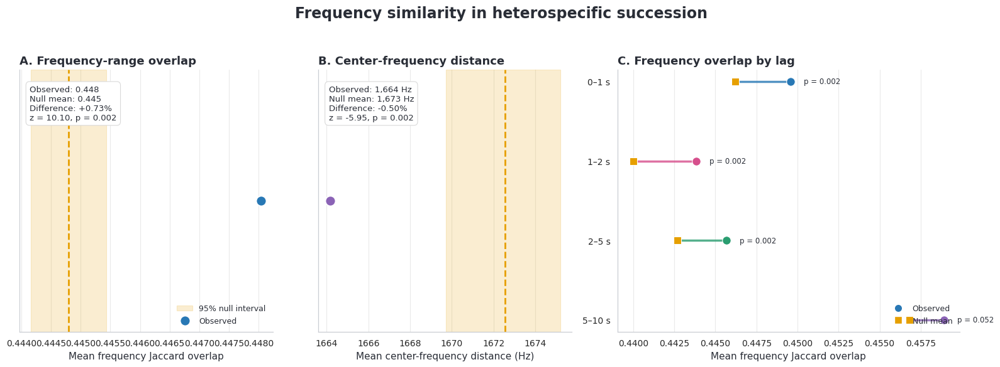

Saved:
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q3_Figure_01_Frequency_Overlap_Null.png
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q3_Figure_01_Frequency_Overlap_Null.pdf
/content/drive/MyDrive/data/derived/publication_figure_atlas/Q3_Figure_01_Frequency_Overlap_Null.svg


In [ ]:

# ============================================================
# Q3 FIGURE 1
# Observed frequency similarity vs frequency-randomized null
# Requires:
#   overall_frequency_results
#   lag_frequency_results
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Verify required data
# ------------------------------------------------------------

required = [
    "overall_frequency_results",
    "lag_frequency_results"
]

for name in required:
    assert name in globals(), (
        f"Missing {name}. Run Q3 Steps 120–122 first."
    )

overall = overall_frequency_results.copy()
lag_results = lag_frequency_results.copy()

required_overall_cols = [
    "metric", "observed", "null_mean",
    "null_2.5%", "null_97.5%", "p_two_sided"
]

required_lag_cols = [
    "lag_bin", "observed_overlap",
    "null_overlap_mean", "overlap_p"
]

for col in required_overall_cols:
    assert col in overall.columns, (
        f"Missing column in overall results: {col}"
    )

for col in required_lag_cols:
    assert col in lag_results.columns, (
        f"Missing column in lag results: {col}"
    )

# ------------------------------------------------------------
# Publication style
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
    "figure.titlesize": 17,
    "figure.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.9,
    "savefig.facecolor": "white",
    "figure.facecolor": "white"
})

observed_color = "#2878B5"
null_color = "#E69F00"
lag_colors = [
    "#2878B5",
    "#D64F8C",
    "#2A9D70",
    "#8B63B6"
]

# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5.6),
    gridspec_kw={"width_ratios": [1, 1, 1.35]}
)

fig.suptitle(
    "Frequency similarity in heterospecific succession",
    y=1.04
)

# ------------------------------------------------------------
# PANEL A — Overall frequency overlap
# ------------------------------------------------------------

ax = axes[0]

row = overall[
    overall["metric"].str.contains(
        "Jaccard overlap",
        case=False,
        na=False
    )
].iloc[0]

obs = row["observed"]
null = row["null_mean"]

ax.axvspan(
    row["null_2.5%"],
    row["null_97.5%"],
    color=null_color,
    alpha=0.18,
    label="95% null interval"
)

ax.axvline(
    null,
    color=null_color,
    linestyle="--",
    linewidth=2
)

ax.scatter(
    obs, 0,
    s=130,
    color=observed_color,
    edgecolor="white",
    linewidth=1.2,
    zorder=5,
    label="Observed"
)

ax.set_yticks([])
ax.set_xlabel("Mean frequency Jaccard overlap")
ax.set_title("A. Frequency-range overlap", loc="left")

ax.text(
    0.04, 0.94,
    f"Observed: {obs:.3f}\n"
    f"Null mean: {null:.3f}\n"
    f"Difference: {row['percent_difference']:+.2f}%\n"
    f"z = {row['z_score']:.2f}, "
    f"p = {row['p_two_sided']:.3f}",
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor="white",
        edgecolor="#D9D9D9"
    )
)

ax.legend(
    loc="lower right",
    frameon=False
)

# ------------------------------------------------------------
# PANEL B — Overall center-frequency distance
# ------------------------------------------------------------

ax = axes[1]

row = overall[
    overall["metric"].str.contains(
        "center distance",
        case=False,
        na=False
    )
].iloc[0]

obs = row["observed"]
null = row["null_mean"]

ax.axvspan(
    row["null_2.5%"],
    row["null_97.5%"],
    color=null_color,
    alpha=0.18
)

ax.axvline(
    null,
    color=null_color,
    linestyle="--",
    linewidth=2
)

ax.scatter(
    obs, 0,
    s=130,
    color="#8B63B6",
    edgecolor="white",
    linewidth=1.2,
    zorder=5
)

ax.set_yticks([])
ax.set_xlabel("Mean center-frequency distance (Hz)")
ax.set_title("B. Center-frequency distance", loc="left")

ax.text(
    0.04, 0.94,
    f"Observed: {obs:,.0f} Hz\n"
    f"Null mean: {null:,.0f} Hz\n"
    f"Difference: {row['percent_difference']:+.2f}%\n"
    f"z = {row['z_score']:.2f}, "
    f"p = {row['p_two_sided']:.3f}",
    transform=ax.transAxes,
    va="top",
    ha="left",
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.45",
        facecolor="white",
        edgecolor="#D9D9D9"
    )
)

# ------------------------------------------------------------
# PANEL C — Frequency overlap by succession lag
# ------------------------------------------------------------

ax = axes[2]

lag_order = [
    "0–1 s",
    "1–2 s",
    "2–5 s",
    "5–10 s"
]

lag_results["lag_bin"] = pd.Categorical(
    lag_results["lag_bin"],
    categories=lag_order,
    ordered=True
)

lag_results = lag_results.sort_values("lag_bin")

y_positions = np.arange(len(lag_results))

for i, (_, row) in enumerate(
    lag_results.iterrows()
):

    obs = row["observed_overlap"]
    null = row["null_overlap_mean"]

    ax.plot(
        [null, obs],
        [i, i],
        color=lag_colors[i],
        linewidth=2.5,
        alpha=0.8,
        zorder=2
    )

    ax.scatter(
        null, i,
        marker="s",
        s=75,
        color=null_color,
        edgecolor="white",
        linewidth=0.8,
        zorder=4
    )

    ax.scatter(
        obs, i,
        marker="o",
        s=95,
        color=lag_colors[i],
        edgecolor="white",
        linewidth=0.8,
        zorder=5
    )

    ax.text(
        max(obs, null) + 0.0008,
        i,
        f"p = {row['overlap_p']:.3f}",
        va="center",
        fontsize=8.5
    )

ax.set_yticks(y_positions)
ax.set_yticklabels(lag_results["lag_bin"].astype(str))
ax.invert_yaxis()

ax.set_xlabel("Mean frequency Jaccard overlap")
ax.set_title("C. Frequency overlap by lag", loc="left")

legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=observed_color,
        markeredgecolor="white",
        markersize=9,
        label="Observed"
    ),
    Line2D(
        [0], [0],
        marker="s",
        color="none",
        markerfacecolor=null_color,
        markeredgecolor="white",
        markersize=8,
        label="Null mean"
    )
]

ax.legend(
    handles=legend_items,
    frameon=False,
    loc="lower right"
)

# ------------------------------------------------------------
# Final formatting
# ------------------------------------------------------------

for ax in axes:
    ax.grid(
        axis="x",
        color="#EAEAEA",
        linewidth=0.8
    )
    ax.set_axisbelow(True)

plt.tight_layout()

# ------------------------------------------------------------
# Export
# ------------------------------------------------------------

base = os.path.join(
    output_dir,
    "Q3_Figure_01_Frequency_Overlap_Null"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")


**Figure 1. Frequency similarity between successive heterospecific vocalizations compared with a frequency-randomized null model.** (A) Mean frequency-range overlap (Jaccard similarity) for observed succession edges and the null expectation. (B) Mean distance between vocalization center frequencies, with lower values indicating greater acoustic similarity. Shaded regions represent the central 95% of the null distributions. (C) Observed and null frequency overlap across four temporal lag categories. Frequency overlap was modestly elevated overall, with significant differences reported for shorter succession lags. These results indicate a small association between acoustic similarity and temporal succession, rather than evidence of behavioral causation.

One interpretation note: the lag panel's p-values come from the 1,000-permutation analysis, so the smallest attainable empirical p-value is limited by that number of permutations. Also, this figure concerns successive heterospecific events—not necessarily vocalizations whose time intervals overlap.

In [19]:
# ============================================================
# Q3 — FIGURE 2 | STEP 1
# Reconstruct directed species-pair figure dataset
# Source: saved master_events.csv and master_edges.csv
# Does not modify original files or model artifacts
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

derived = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"

# Load source tables
events = pd.read_csv(os.path.join(derived, "master_events.csv"))
edges = pd.read_csv(os.path.join(derived, "master_edges.csv"))

# Keep bird events with usable frequency boundaries
events = events[
    events["is_bird"].astype(str).str.lower().eq("yes")
].copy()

for col in ["low_freq_hz", "high_freq_hz"]:
    events[col] = pd.to_numeric(events[col], errors="coerce")

events = events.dropna(
    subset=["event_id", "low_freq_hz", "high_freq_hz"]
)

events = events[
    events["high_freq_hz"] > events["low_freq_hz"]
].copy()

# Keep heterospecific succession edges
edges = edges[
    edges["relationship_type"].eq("succession")
    & edges["source_species"].ne(edges["target_species"])
].copy()

# Attach frequency ranges to source and target events
source = events[
    ["event_id", "low_freq_hz", "high_freq_hz"]
].rename(columns={
    "event_id": "source_event",
    "low_freq_hz": "source_low",
    "high_freq_hz": "source_high"
})

target = events[
    ["event_id", "low_freq_hz", "high_freq_hz"]
].rename(columns={
    "event_id": "target_event",
    "low_freq_hz": "target_low",
    "high_freq_hz": "target_high"
})

q3_frequency_edges = (
    edges
    .merge(source, on="source_event", how="inner")
    .merge(target, on="target_event", how="inner")
)

# Calculate frequency-band Jaccard overlap
intersection = np.maximum(
    0,
    np.minimum(
        q3_frequency_edges["source_high"],
        q3_frequency_edges["target_high"]
    ) - np.maximum(
        q3_frequency_edges["source_low"],
        q3_frequency_edges["target_low"]
    )
)

union = (
    np.maximum(
        q3_frequency_edges["source_high"],
        q3_frequency_edges["target_high"]
    ) - np.minimum(
        q3_frequency_edges["source_low"],
        q3_frequency_edges["target_low"]
    )
)

q3_frequency_edges["frequency_jaccard"] = intersection / union

# Calculate frequency-center distance
source_center = (
    q3_frequency_edges["source_low"]
    + q3_frequency_edges["source_high"]
) / 2

target_center = (
    q3_frequency_edges["target_low"]
    + q3_frequency_edges["target_high"]
) / 2

q3_frequency_edges["frequency_center_distance_hz"] = (
    np.abs(source_center - target_center)
)

# Aggregate acoustic measurements by directed species pair
q3_pair_frequency = (
    q3_frequency_edges
    .groupby(["source_species", "target_species"])
    .agg(
        frequency_overlap=("frequency_jaccard", "mean"),
        center_distance_hz=("frequency_center_distance_hz", "mean"),
        frequency_edge_count=("frequency_jaccard", "size")
    )
    .reset_index()
)

print("Recovered heterospecific edges:", len(q3_frequency_edges))
print("Directed species pairs:", len(q3_pair_frequency))
display(q3_pair_frequency.head())

Recovered heterospecific edges: 121623
Directed species pairs: 2602


,source_species,target_species,frequency_overlap,center_distance_hz,frequency_edge_count
0,ACFL,BTNW,0.717668,627.682667,3
1,ACFL,HETH,0.461819,1548.740000,2
2,ACFL,OVEN,0.894160,278.467500,2
3,AGOL,ALFL,0.729160,712.350000,1
4,AGOL,AMCR,0.110182,2477.308800,5


In [20]:
# ============================================================
# Q3 — FIGURE 2 | STEP 2
# Inspect original temporal-enrichment calculation
# Read-only: does not execute or modify notebook cells
# ============================================================

import nbformat
import os

notebook_path = (
    "/content/gdrive/MyDrive/Bioacoustics_Project/notebooks/"
    "Copy of BirdNetworkAnalysis_10_30_26.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

for i, cell in enumerate(nb.cells):
    if cell.cell_type != "code":
        continue

    if "pair_table" in cell.source or "robust_pairs" in cell.source:
        print(f"\n{'='*65}")
        print(f"NOTEBOOK CELL {i}")
        print("="*65)
        print(cell.source[:9000])


NOTEBOOK CELL 122
# ============================================================
# Step 116: Corrected pairwise null model for #2
# ============================================================

N_NULL_PAIRS = 1000
PAIR_NULL_SEED = 116

rng = np.random.default_rng(PAIR_NULL_SEED)

# ------------------------------------------------------------
# 1. Explicitly isolate HETEROSPECIFIC succession
# ------------------------------------------------------------

hetero_succession = (
    succession_edges[
        succession_edges["source_species"]
        != succession_edges["target_species"]
    ]
    .copy()
    .reset_index(drop=True)
)

print("PAIRWISE NULL MODEL SETUP")
print("=" * 80)

print(
    f"Total succession edges: "
    f"{len(succession_edges):,}"
)

print(
    f"Heterospecific succession edges: "
    f"{len(hetero_succession):,}"
)

# ------------------------------------------------------------
# 2. Species list
# ------------------------------------------------------------

sp

In [21]:
# ============================================================
# Q3 — FIGURE 2 | STEP 2A
# Locate original duration-bin construction
# Read-only notebook inspection
# ============================================================

import nbformat

notebook_path = (
    "/content/gdrive/MyDrive/Bioacoustics_Project/notebooks/"
    "Copy of BirdNetworkAnalysis_10_30_26.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

for i, cell in enumerate(nb.cells):
    if cell.cell_type != "code":
        continue

    source = cell.source.lower()

    if "duration_bin" in source and (
        ".cut(" in source
        or "duration_bin" in source.replace(" ", "")
        or "duration_class" in source
    ):
        print(f"\n{'='*60}")
        print(f"NOTEBOOK CELL {i}")
        print("="*60)
        print(cell.source[:5000])


NOTEBOOK CELL 54
# ============================================================
# Step 50 — Recording-time coverage by annotation duration
# ============================================================

duration_bins = [
    (-np.inf, 2, "0–2 s"),
    (2, 5, "2–5 s"),
    (5, 10, "5–10 s"),
    (10, 30, "10–30 s"),
    (30, 60, "30–60 s"),
    (60, 300, "1–5 min"),
    (300, np.inf, ">5 min"),
]

coverage_rows = []

for dataset_id, group in master_events.groupby("dataset_ID"):

    total_recording_seconds = (
        master_recordings.loc[
            master_recordings["dataset_ID"] == dataset_id,
            "n_events"
        ].shape[0] * 600
    )

    for low, high, label in duration_bins:

        subset = group[
            (group["duration_s"] > low) &
            (group["duration_s"] <= high)
        ]

        coverage_rows.append({
            "dataset_ID": dataset_id,
            "duration_class": label,
            "n_annotations": len(subset),
            "total_annotated

In [22]:
# ============================================================
# Q3 — FIGURE 2 | STEP 2B
# Verify saved event and edge identifiers
# Read-only diagnostic
# ============================================================

print("EVENT TABLE")
print("Rows:", len(events))
print("Unique event IDs:", events["event_id"].nunique())
print("Duplicate event IDs:", events["event_id"].duplicated().sum())

print("\nEDGE TABLE")
print("Rows:", len(edges))
print("Unique source-target pairs:",
      edges[["source_event", "target_event"]].drop_duplicates().shape[0])

event_ids = set(events["event_id"].dropna())

source_missing = (~edges["source_event"].isin(event_ids)).sum()
target_missing = (~edges["target_event"].isin(event_ids)).sum()

print("\nEDGE MATCHING")
print("Missing source events:", source_missing)
print("Missing target events:", target_missing)

print("\nRELATIONSHIP TYPES")
print(pd.read_csv(
    "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/master_edges.csv",
    usecols=["relationship_type"]
)["relationship_type"].value_counts(dropna=False))

EVENT TABLE
Rows: 182513
Unique event IDs: 182513
Duplicate event IDs: 0

EDGE TABLE
Rows: 123830
Unique source-target pairs: 123830

EDGE MATCHING
Missing source events: 1131
Missing target events: 1089

RELATIONSHIP TYPES
relationship_type
succession    173029
overlap        81717
Name: count, dtype: int64


In [23]:
# Q3 — FIGURE 2 | STEP 2C
# Verify event-ID matching against the complete bird-event table.
# Read-only diagnostic: does not modify source files or model outputs.

import pandas as pd

DATA_DIR = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"

master_events = pd.read_csv(f"{DATA_DIR}/master_events.csv")
master_edges = pd.read_csv(f"{DATA_DIR}/master_edges.csv")

# Reconstruct the complete bird-event set for the temporal analysis.
q3_bird_events = master_events.loc[
    master_events["is_bird"].astype(str).str.strip().str.lower().isin(
        ["yes", "true", "1"]
    )
    & master_events["species_code"].notna()
    & master_events["itemID"].notna()
    & master_events["duration_s"].notna()
    & master_events["event_id"].notna()
].copy()

# Keep only heterospecific succession edges.
q3_temporal_edges = master_edges.loc[
    (master_edges["relationship_type"] == "succession")
    & (master_edges["source_species"] != master_edges["target_species"])
].copy()

event_ids = set(q3_bird_events["event_id"])
source_missing = (~q3_temporal_edges["source_event"].isin(event_ids)).sum()
target_missing = (~q3_temporal_edges["target_event"].isin(event_ids)).sum()

print("COMPLETE BIRD-EVENT TABLE")
print("Rows:", len(q3_bird_events))
print("Unique event IDs:", q3_bird_events["event_id"].nunique())

print("\nHETEROSPECIFIC SUCCESSION EDGES")
print("Rows:", len(q3_temporal_edges))
print("Missing source event IDs:", source_missing)
print("Missing target event IDs:", target_missing)

COMPLETE BIRD-EVENT TABLE
Rows: 182516
Unique event IDs: 182516

HETEROSPECIFIC SUCCESSION EDGES
Rows: 123830
Missing source event IDs: 1129
Missing target event IDs: 1089


In [24]:
# Q3 — FIGURE 2 | STEP 2D
# Diagnose unmatched event IDs before reconstructing temporal enrichment.
# Read-only: does not modify source files, dataframes, or model outputs.

import pandas as pd

DATA_DIR = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"

events_check = pd.read_csv(f"{DATA_DIR}/master_events.csv")
edges_check = pd.read_csv(f"{DATA_DIR}/master_edges.csv")

bird_check = events_check.loc[
    events_check["is_bird"].astype(str).str.strip().str.lower().isin(
        ["yes", "true", "1"]
    )
    & events_check["species_code"].notna()
    & events_check["event_id"].notna()
].copy()

hetero_check = edges_check.loc[
    (edges_check["relationship_type"] == "succession")
    & (edges_check["source_species"] != edges_check["target_species"])
].copy()

# Compare IDs as strings, with surrounding whitespace removed.
event_ids = set(bird_check["event_id"].astype(str).str.strip())
source_ids = hetero_check["source_event"].astype(str).str.strip()
target_ids = hetero_check["target_event"].astype(str).str.strip()

missing_source = source_ids[~source_ids.isin(event_ids)]
missing_target = target_ids[~target_ids.isin(event_ids)]

print("UNMATCHED ID COUNTS")
print("Source endpoints:", len(missing_source))
print("Target endpoints:", len(missing_target))

print("\nEXAMPLE UNMATCHED SOURCE IDs")
print(missing_source.drop_duplicates().head(15).to_list())

print("\nEXAMPLE UNMATCHED TARGET IDs")
print(missing_target.drop_duplicates().head(15).to_list())

print("\nEXAMPLE EVENT IDs FROM MASTER EVENTS")
print(bird_check["event_id"].astype(str).head(15).to_list())

print("\nID FORMAT CHECK")
print("Event ID dtype:", events_check["event_id"].dtype)
print("Edge source ID dtype:", edges_check["source_event"].dtype)
print("Edge target ID dtype:", edges_check["target_event"].dtype)
print("Event IDs with leading/trailing whitespace:",
      (events_check["event_id"].astype(str) !=
       events_check["event_id"].astype(str).str.strip()).sum())
print("Source IDs with leading/trailing whitespace:",
      (hetero_check["source_event"].astype(str) !=
       hetero_check["source_event"].astype(str).str.strip()).sum())
print("Target IDs with leading/trailing whitespace:",
      (hetero_check["target_event"].astype(str) !=
       hetero_check["target_event"].astype(str).str.strip()).sum())

UNMATCHED ID COUNTS
Source endpoints: 1129
Target endpoints: 1089

EXAMPLE UNMATCHED SOURCE IDs
['1707_E0003', '1707_E0046', '1710_E0026', '1713_E0002', '1720_E0004', '1720_E0010', '1720_E0016', '1720_E0019', '1720_E0032', '1720_E0038', '1720_E0041', '1720_E0046', '1720_E0050', '1720_E0053', '1720_E0067']

EXAMPLE UNMATCHED TARGET IDs
['1707_E0003', '1707_E0044', '1710_E0026', '1713_E0002', '1718_E0049', '1720_E0009', '1720_E0010', '1720_E0012', '1720_E0015', '1720_E0019', '1720_E0029', '1720_E0038', '1720_E0044', '1720_E0050', '1720_E0053']

EXAMPLE EVENT IDs FROM MASTER EVENTS
['1701_E0001', '1701_E0002', '1701_E0003', '1701_E0004', '1701_E0005', '1701_E0006', '1701_E0007', '1701_E0008', '1701_E0009', '1701_E0010', '1701_E0011', '1701_E0012', '1701_E0013', '1701_E0014', '1701_E0015']

ID FORMAT CHECK
Event ID dtype: object
Edge source ID dtype: object
Edge target ID dtype: object
Event IDs with leading/trailing whitespace: 0
Source IDs with leading/trailing whitespace: 0
Target IDs w

In [25]:
# Q3 — FIGURE 2 | STEP 2E
# Determine whether unmatched edge endpoints exist in the full event table.
# Read-only diagnostic; no source files or analysis outputs are changed.

import pandas as pd

DATA_DIR = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"

all_events = pd.read_csv(f"{DATA_DIR}/master_events.csv", dtype={"event_id": str})
all_edges = pd.read_csv(
    f"{DATA_DIR}/master_edges.csv",
    dtype={"source_event": str, "target_event": str}
)

hetero_edges = all_edges.loc[
    (all_edges["relationship_type"] == "succession")
    & (all_edges["source_species"] != all_edges["target_species"])
].copy()

all_ids = set(all_events["event_id"].dropna().str.strip())
bird_mask = all_events["is_bird"].astype(str).str.strip().str.lower().isin(
    ["yes", "true", "1"]
)
bird_ids = set(all_events.loc[bird_mask, "event_id"].dropna().str.strip())

unmatched_ids = set(
    hetero_edges["source_event"].dropna().str.strip()
).union(
    hetero_edges["target_event"].dropna().str.strip()
) - bird_ids

present_in_all = sum(event_id in all_ids for event_id in unmatched_ids)
absent_from_all = len(unmatched_ids) - present_in_all

print("UNIQUE UNMATCHED ENDPOINT IDs")
print(len(unmatched_ids))
print("Present in full master event table:", present_in_all)
print("Absent from full master event table:", absent_from_all)

# Inspect records for unmatched IDs that do exist in master_events.
examples = all_events.loc[
    all_events["event_id"].isin(unmatched_ids),
    ["event_id", "is_bird", "species_code", "common_name", "itemID"]
].drop_duplicates()

print("\nUNMATCHED IDs PRESENT IN MASTER EVENTS — EXAMPLES")
print(examples.head(20).to_string(index=False))

print("\nSTATUS COUNTS")
print(
    examples.groupby(
        ["is_bird", examples["species_code"].isna()],
        dropna=False
    ).size().to_string()
)

UNIQUE UNMATCHED ENDPOINT IDs
1301
Present in full master event table: 1301
Absent from full master event table: 0

UNMATCHED IDs PRESENT IN MASTER EVENTS — EXAMPLES
  event_id is_bird species_code      common_name  itemID
1707_E0003      No         EACH Eastern Chipmunk    1707
1707_E0044      No         EACH Eastern Chipmunk    1707
1707_E0046      No         EACH Eastern Chipmunk    1707
1710_E0026      No         RESQ     Red Squirrel    1710
1713_E0002   Maybe         ????          Unknown    1713
1718_E0049      No         EACH Eastern Chipmunk    1718
1720_E0004      No         EACH Eastern Chipmunk    1720
1720_E0009      No         EACH Eastern Chipmunk    1720
1720_E0010      No         EACH Eastern Chipmunk    1720
1720_E0012      No         EACH Eastern Chipmunk    1720
1720_E0015      No         EACH Eastern Chipmunk    1720
1720_E0016      No         EACH Eastern Chipmunk    1720
1720_E0019      No         EACH Eastern Chipmunk    1720
1720_E0029      No         EACH East

In [26]:
# Q3 — FIGURE 2 | STEP 2F
# Validate the confirmed-bird heterospecific succession edge set.
# Read-only check before rebuilding the Figure 2 temporal null model.

import pandas as pd

DATA_DIR = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"

events = pd.read_csv(f"{DATA_DIR}/master_events.csv", dtype={"event_id": str})
edges = pd.read_csv(
    f"{DATA_DIR}/master_edges.csv",
    dtype={"source_event": str, "target_event": str}
)

# Confirmed bird events only.
confirmed_birds = events.loc[
    events["is_bird"].astype(str).str.strip().str.lower().eq("yes")
    & events["species_code"].notna()
    & events["itemID"].notna()
    & events["duration_s"].notna()
    & events["event_id"].notna()
].copy()

bird_ids = set(confirmed_birds["event_id"].str.strip())

# Heterospecific succession edges with both endpoints confirmed as birds.
hetero_succession = edges.loc[
    (edges["relationship_type"] == "succession")
    & (edges["source_species"] != edges["target_species"])
].copy()

valid_endpoint_mask = (
    hetero_succession["source_event"].str.strip().isin(bird_ids)
    & hetero_succession["target_event"].str.strip().isin(bird_ids)
)

valid_edges = hetero_succession.loc[valid_endpoint_mask].copy()

print("CONFIRMED BIRD EVENTS:", len(confirmed_birds))
print("HETEROSPECIFIC SUCCESSION EDGES IN SAVED EDGE TABLE:", len(hetero_succession))
print("EDGES WITH BOTH ENDPOINTS CONFIRMED BIRDS:", len(valid_edges))
print("EDGES EXCLUDED:", len(hetero_succession) - len(valid_edges))

print("\nENDPOINT MATCH CHECK")
print("Unmatched source IDs:",
      (~valid_edges["source_event"].str.strip().isin(bird_ids)).sum())
print("Unmatched target IDs:",
      (~valid_edges["target_event"].str.strip().isin(bird_ids)).sum())

print("\nSPECIES-CODE CHECK")
print("Unique source species:", valid_edges["source_species"].nunique())
print("Unique target species:", valid_edges["target_species"].nunique())
print("Missing source species:", valid_edges["source_species"].isna().sum())
print("Missing target species:", valid_edges["target_species"].isna().sum())

CONFIRMED BIRD EVENTS: 182516
HETEROSPECIFIC SUCCESSION EDGES IN SAVED EDGE TABLE: 123830
EDGES WITH BOTH ENDPOINTS CONFIRMED BIRDS: 121625
EDGES EXCLUDED: 2205

ENDPOINT MATCH CHECK
Unmatched source IDs: 0
Unmatched target IDs: 0

SPECIES-CODE CHECK
Unique source species: 96
Unique target species: 95
Missing source species: 0
Missing target species: 0


In [27]:

# Q3 — FIGURE 2 | STEP 3
# Reconstruct directed species-pair temporal enrichment.
# Reproduces the original duration-controlled null model:
# 1,000 permutations, shuffling species labels within recording × duration bin.
# Does NOT rerun frequency nulls, Q4/Q5, or model training.

import numpy as np
import pandas as pd

DATA_DIR = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"
N_PERMUTATIONS = 1000
RANDOM_SEED = 116

# ------------------------------------------------------------
# 1. Load the source tables and select confirmed bird events
# ------------------------------------------------------------
q3_temporal_events = pd.read_csv(
    f"{DATA_DIR}/master_events.csv",
    dtype={"event_id": str}
)

q3_temporal_edges = pd.read_csv(
    f"{DATA_DIR}/master_edges.csv",
    dtype={"source_event": str, "target_event": str}
)

q3_temporal_events = q3_temporal_events.loc[
    q3_temporal_events["is_bird"].astype(str).str.strip().str.lower().eq("yes")
    & q3_temporal_events["species_code"].notna()
    & q3_temporal_events["itemID"].notna()
    & q3_temporal_events["duration_s"].notna()
    & q3_temporal_events["event_id"].notna()
].copy().reset_index(drop=True)

# Keep heterospecific succession edges only.
q3_temporal_edges = q3_temporal_edges.loc[
    (q3_temporal_edges["relationship_type"] == "succession")
    & (q3_temporal_edges["source_species"] != q3_temporal_edges["target_species"])
].copy().reset_index(drop=True)

# ------------------------------------------------------------
# 2. Retain only edges whose two endpoints are confirmed birds
# ------------------------------------------------------------
event_id_to_position = pd.Series(
    np.arange(len(q3_temporal_events)),
    index=q3_temporal_events["event_id"]
)

q3_temporal_edges["source_pos"] = (
    q3_temporal_edges["source_event"].map(event_id_to_position)
)
q3_temporal_edges["target_pos"] = (
    q3_temporal_edges["target_event"].map(event_id_to_position)
)

q3_temporal_edges = q3_temporal_edges.dropna(
    subset=["source_pos", "target_pos"]
).copy()

source_pos = q3_temporal_edges["source_pos"].to_numpy(dtype=np.int64)
target_pos = q3_temporal_edges["target_pos"].to_numpy(dtype=np.int64)

# ------------------------------------------------------------
# 3. Recreate the original duration bins (not duration_class)
#    Rank durations within recording, then qcut into up to 10 bins.
# ------------------------------------------------------------
q3_temporal_events["duration_rank"] = (
    q3_temporal_events.groupby("itemID")["duration_s"]
    .rank(method="first")
)

q3_temporal_events["duration_bin"] = -1

for recording_id, group_indices in q3_temporal_events.groupby("itemID").groups.items():
    idx = np.asarray(list(group_indices), dtype=np.int64)
    n_bins = min(10, len(idx))

    q3_temporal_events.loc[idx, "duration_bin"] = pd.qcut(
        q3_temporal_events.loc[idx, "duration_rank"],
        q=n_bins,
        labels=False
    ).to_numpy()

# ------------------------------------------------------------
# 4. Encode species and calculate observed directed pair counts
# ------------------------------------------------------------
species_values = sorted(q3_temporal_events["species_code"].unique())
species_to_code = {species: i for i, species in enumerate(species_values)}
n_species = len(species_values)

event_species_codes = (
    q3_temporal_events["species_code"]
    .map(species_to_code)
    .to_numpy(dtype=np.int32)
)

source_species_codes = event_species_codes[source_pos]
target_species_codes = event_species_codes[target_pos]

# Exclude any same-species edges after mapping.
heterospecific_mask = source_species_codes != target_species_codes
source_species_codes = source_species_codes[heterospecific_mask]
target_species_codes = target_species_codes[heterospecific_mask]

source_pos = source_pos[heterospecific_mask]
target_pos = target_pos[heterospecific_mask]

observed_pair_codes = source_species_codes * n_species + target_species_codes
unique_pair_codes, observed_counts = np.unique(
    observed_pair_codes, return_counts=True
)

# ------------------------------------------------------------
# 5. Prepare recording × duration-bin shuffle groups
# ------------------------------------------------------------
shuffle_groups = [
    np.asarray(list(indices), dtype=np.int64)
    for _, indices in q3_temporal_events.groupby(
        ["itemID", "duration_bin"]
    ).groups.items()
]

# ------------------------------------------------------------
# 6. Run the 1,000 duration-controlled permutations
# ------------------------------------------------------------
np.random.seed(RANDOM_SEED)

null_pair_counts = np.zeros(
    (len(unique_pair_codes), N_PERMUTATIONS),
    dtype=np.int32
)

for permutation in range(N_PERMUTATIONS):
    shuffled_species = event_species_codes.copy()

    for idx in shuffle_groups:
        shuffled_species[idx] = np.random.permutation(shuffled_species[idx])

    perm_source = shuffled_species[source_pos]
    perm_target = shuffled_species[target_pos]

    perm_heterospecific = perm_source != perm_target

    perm_pair_codes = (
        perm_source[perm_heterospecific] * n_species
        + perm_target[perm_heterospecific]
    )

    counts = np.bincount(
        perm_pair_codes,
        minlength=n_species * n_species
    )

    null_pair_counts[:, permutation] = counts[unique_pair_codes]

    if (permutation + 1) % 100 == 0:
        print(f"Completed {permutation + 1:,}/{N_PERMUTATIONS:,} permutations")

# ------------------------------------------------------------
# 7. Build pair_table with observed and null enrichment metrics
# ------------------------------------------------------------
null_mean = null_pair_counts.mean(axis=1)
null_sd = null_pair_counts.std(axis=1, ddof=1)

source_codes = unique_pair_codes // n_species
target_codes = unique_pair_codes % n_species

pair_table = pd.DataFrame({
    "source_species": [species_values[i] for i in source_codes],
    "target_species": [species_values[i] for i in target_codes],
    "observed_edges": observed_counts,
    "null_mean": null_mean,
    "null_sd": null_sd
})

pair_table["difference"] = (
    pair_table["observed_edges"] - pair_table["null_mean"]
)

pair_table["fold_enrichment"] = np.where(
    pair_table["null_mean"] > 0,
    pair_table["observed_edges"] / pair_table["null_mean"],
    np.nan
)

pair_table["percent_difference"] = np.where(
    pair_table["null_mean"] > 0,
    100 * pair_table["difference"] / pair_table["null_mean"],
    np.nan
)

pair_table["z_score"] = np.where(
    pair_table["null_sd"] > 0,
    pair_table["difference"] / pair_table["null_sd"],
    np.nan
)

# ------------------------------------------------------------
# 8. Validation summary
# ------------------------------------------------------------
print("\nQ3 FIGURE 2 — TEMPORAL PAIR ENRICHMENT RECONSTRUCTION")
print("Confirmed bird events:", len(q3_temporal_events))
print("Valid heterospecific succession edges:", len(q3_temporal_edges))
print("Species represented:", n_species)
print("Directed species pairs:", len(pair_table))
print("Permutations:", N_PERMUTATIONS)
print("Random seed:", RANDOM_SEED)
print("Total observed pair counts:", int(pair_table["observed_edges"].sum()))

print("\nPAIR TABLE PREVIEW")
display(pair_table.head())

print("\nPairs with at least 20 observed edges:",
      int((pair_table["observed_edges"] >= 20).sum()))


Completed 100/1,000 permutations
Completed 200/1,000 permutations
Completed 300/1,000 permutations
Completed 400/1,000 permutations
Completed 500/1,000 permutations
Completed 600/1,000 permutations
Completed 700/1,000 permutations
Completed 800/1,000 permutations
Completed 900/1,000 permutations
Completed 1,000/1,000 permutations

Q3 FIGURE 2 — TEMPORAL PAIR ENRICHMENT RECONSTRUCTION
Confirmed bird events: 182516
Valid heterospecific succession edges: 121625
Species represented: 96
Directed species pairs: 2602
Permutations: 1000
Random seed: 116
Total observed pair counts: 121625

PAIR TABLE PREVIEW


,source_species,target_species,observed_edges,null_mean,null_sd,difference,fold_enrichment,percent_difference,z_score
0,ACFL,BTNW,3,4.056,1.077973,-1.056,0.739645,-26.035503,-0.979616
1,ACFL,HETH,2,1.348,0.914184,0.652,1.483680,48.367953,0.713205
2,ACFL,OVEN,2,2.812,0.390908,-0.812,0.711238,-28.876245,-2.077217
3,AGOL,ALFL,1,0.398,0.556692,0.602,2.512563,151.256281,1.081388
4,AGOL,AMCR,5,9.406,2.528549,-4.406,0.531576,-46.842441,-1.742502



Pairs with at least 20 observed edges: 832


In [28]:

# Q3 — FIGURE 2 | STEP 4
# Merge temporal enrichment with pair-level frequency metrics.
# Verify the original Figure 2 sample size and Spearman correlations.
# Does not rerun permutations or modify saved files.

import pandas as pd
from scipy.stats import spearmanr

# Confirm the frequency-pair summary exists from the earlier reconstruction.
assert "q3_pair_frequency" in globals(), (
    "q3_pair_frequency is missing. Do not rerun the temporal permutations; "
    "we only need to reconstruct the frequency-pair summary."
)
assert "pair_table" in globals(), "The reconstructed pair_table is missing."

# Merge the two pair-level datasets.
pair_frequency_analysis = pair_table.merge(
    q3_pair_frequency,
    on=["source_species", "target_species"],
    how="inner",
    validate="one_to_one"
)

# Match the original Step 125 inclusion rule.
pair_frequency_analysis = pair_frequency_analysis.loc[
    pair_frequency_analysis["observed_edges"] >= 20
].copy()

# Calculate correlations.
rho_overlap, p_overlap = spearmanr(
    pair_frequency_analysis["fold_enrichment"],
    pair_frequency_analysis["frequency_overlap"],
    nan_policy="omit"
)

rho_distance, p_distance = spearmanr(
    pair_frequency_analysis["fold_enrichment"],
    pair_frequency_analysis["center_distance_hz"],
    nan_policy="omit"
)

print("Q3 FIGURE 2 — PAIR-LEVEL CORRELATION CHECK")
print("Merged directed pairs:", len(pair_frequency_analysis))
print("Pairs with >=20 observed edges:",
      int((pair_frequency_analysis["observed_edges"] >= 20).sum()))

print("\nTEMPORAL ENRICHMENT vs FREQUENCY OVERLAP")
print(f"Spearman rho = {rho_overlap:.4f}")
print(f"p-value      = {p_overlap:.4e}")

print("\nTEMPORAL ENRICHMENT vs CENTER-FREQUENCY DISTANCE")
print(f"Spearman rho = {rho_distance:.4f}")
print(f"p-value      = {p_distance:.4e}")

print("\nMISSING VALUES IN FIGURE VARIABLES")
print(
    pair_frequency_analysis[
        ["fold_enrichment", "frequency_overlap", "center_distance_hz"]
    ].isna().sum().to_string()
)

print("\nFIGURE DATA PREVIEW")
display(
    pair_frequency_analysis[
        [
            "source_species", "target_species",
            "observed_edges", "fold_enrichment",
            "frequency_overlap", "center_distance_hz"
        ]
    ].head()
)


Q3 FIGURE 2 — PAIR-LEVEL CORRELATION CHECK
Merged directed pairs: 832
Pairs with >=20 observed edges: 832

TEMPORAL ENRICHMENT vs FREQUENCY OVERLAP
Spearman rho = 0.1925
p-value      = 2.1860e-08

TEMPORAL ENRICHMENT vs CENTER-FREQUENCY DISTANCE
Spearman rho = -0.1828
p-value      = 1.0988e-07

MISSING VALUES IN FIGURE VARIABLES
fold_enrichment       0
frequency_overlap     0
center_distance_hz    0

FIGURE DATA PREVIEW


,source_species,target_species,observed_edges,fold_enrichment,frequency_overlap,center_distance_hz
7,AGOL,BCCH,25,1.578981,0.499075,922.324440
11,AGOL,BTNW,29,1.186725,0.669581,659.010638
16,AGOL,HETH,20,1.323364,0.405817,1661.697950
22,AGOL,OVEN,37,1.249451,0.734277,595.250595
36,AMCR,AMRO,188,1.333494,0.246503,1711.644426


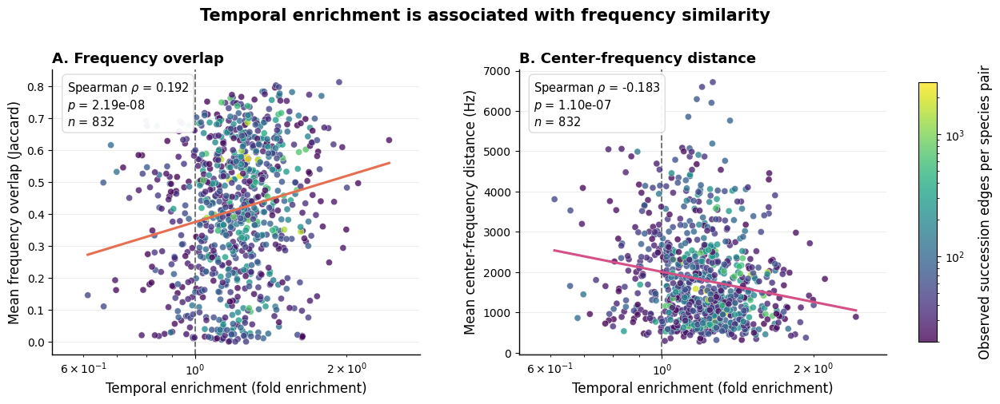


Q3 FIGURE 2 EXPORTED
Pairs plotted: 832
PNG: /content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_2_temporal_enrichment_frequency.png
PDF: /content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_2_temporal_enrichment_frequency.pdf
SVG: /content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_2_temporal_enrichment_frequency.svg


In [29]:

# Q3 — FIGURE 2 | STEP 5
# Publication figure: temporal enrichment versus frequency characteristics.
# Panel A: frequency overlap (Jaccard similarity).
# Panel B: center-frequency distance (Hz).
# Point color represents observed heterospecific succession edge count.
# Exports PNG (600 dpi), PDF, and SVG.
# Does not rerun analyses or modify Q4/Q5 outputs.

import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import spearmanr, linregress

# ------------------------------------------------------------
# 1. Prepare figure data
# ------------------------------------------------------------
plot_data = pair_frequency_analysis.copy()

plot_data = plot_data.replace([np.inf, -np.inf], np.nan).dropna(
    subset=[
        "fold_enrichment",
        "frequency_overlap",
        "center_distance_hz",
        "observed_edges"
    ]
)

plot_data = plot_data.loc[
    (plot_data["fold_enrichment"] > 0)
    & (plot_data["observed_edges"] > 0)
].copy()

x = plot_data["fold_enrichment"].to_numpy()
y_overlap = plot_data["frequency_overlap"].to_numpy()
y_distance = plot_data["center_distance_hz"].to_numpy()
edge_counts = plot_data["observed_edges"].to_numpy()

rho_overlap, p_overlap = spearmanr(x, y_overlap)
rho_distance, p_distance = spearmanr(x, y_distance)

# ------------------------------------------------------------
# 2. Publication styling
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.2, 5.5),
    sharex=True
)

fig.subplots_adjust(
    left=0.09,
    right=0.88,
    bottom=0.17,
    top=0.82,
    wspace=0.27
)

# Log color scale makes the broad range of edge counts visible.
norm = LogNorm(
    vmin=max(1, np.nanmin(edge_counts)),
    vmax=np.nanmax(edge_counts)
)

scatter_options = {
    "c": edge_counts,
    "cmap": "viridis",
    "norm": norm,
    "s": 34,
    "alpha": 0.78,
    "edgecolors": "white",
    "linewidths": 0.35,
    "rasterized": True,
    "zorder": 3
}

# ------------------------------------------------------------
# 3. Panel A — temporal enrichment vs. frequency overlap
# ------------------------------------------------------------
ax = axes[0]

sc = ax.scatter(x, y_overlap, **scatter_options)

# Reference: no temporal enrichment (fold enrichment = 1).
ax.axvline(
    1,
    color="#555555",
    linestyle="--",
    linewidth=1.3,
    alpha=0.85,
    zorder=1
)

# Linear trend shown against log10 enrichment for visual guidance.
log_x = np.log10(x)
fit_a = linregress(log_x, y_overlap)
line_x = np.logspace(np.log10(x.min()), np.log10(x.max()), 200)
line_y_a = fit_a.intercept + fit_a.slope * np.log10(line_x)

ax.plot(
    line_x, line_y_a,
    color="#E76F51",
    linewidth=2.2,
    zorder=4
)

ax.set_xscale("log")
ax.set_xlabel("Temporal enrichment (fold enrichment)")
ax.set_ylabel("Mean frequency overlap (Jaccard)")
ax.set_title("A. Frequency overlap", loc="left", fontweight="bold")

ax.text(
    0.04, 0.96,
    f"Spearman $\\rho$ = {rho_overlap:.3f}\n"
    f"$p$ = {p_overlap:.2e}\n"
    f"$n$ = {len(plot_data):,}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10.5,
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#D9D9D9",
        alpha=0.95
    )
)

# ------------------------------------------------------------
# 4. Panel B — temporal enrichment vs. center-frequency distance
# ------------------------------------------------------------
ax = axes[1]

ax.scatter(x, y_distance, **scatter_options)

ax.axvline(
    1,
    color="#555555",
    linestyle="--",
    linewidth=1.3,
    alpha=0.85,
    zorder=1
)

fit_b = linregress(log_x, y_distance)
line_y_b = fit_b.intercept + fit_b.slope * np.log10(line_x)

ax.plot(
    line_x, line_y_b,
    color="#D45087",
    linewidth=2.2,
    zorder=4
)

ax.set_xscale("log")
ax.set_xlabel("Temporal enrichment (fold enrichment)")
ax.set_ylabel("Mean center-frequency distance (Hz)")
ax.set_title("B. Center-frequency distance", loc="left", fontweight="bold")

ax.text(
    0.04, 0.96,
    f"Spearman $\\rho$ = {rho_distance:.3f}\n"
    f"$p$ = {p_distance:.2e}\n"
    f"$n$ = {len(plot_data):,}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10.5,
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#D9D9D9",
        alpha=0.95
    )
)

# ------------------------------------------------------------
# 5. Shared axes details and colorbar
# ------------------------------------------------------------
for ax in axes:
    ax.grid(
        True,
        which="major",
        color="#E8E8E8",
        linewidth=0.7,
        alpha=0.8
    )
    ax.set_axisbelow(True)
    ax.set_xlim(
        max(0.01, x.min() * 0.85),
        x.max() * 1.15
    )

cbar_ax = fig.add_axes([0.91, 0.20, 0.018, 0.59])
cbar = fig.colorbar(sc, cax=cbar_ax)
cbar.set_label(
    "Observed succession edges per species pair",
    rotation=90,
    labelpad=12
)
cbar.outline.set_linewidth(0.8)

fig.suptitle(
    "Temporal enrichment is associated with frequency similarity",
    fontsize=15,
    fontweight="bold",
    y=0.96
)

# ------------------------------------------------------------
# 6. Export publication files
# ------------------------------------------------------------
OUTPUT_DIR = (
    "/content/gdrive/MyDrive/Bioacoustics_Project/"
    "data/derived/publication_figure_atlas"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

base_name = "Q3_Figure_2_temporal_enrichment_frequency"

png_path = os.path.join(OUTPUT_DIR, base_name + ".png")
pdf_path = os.path.join(OUTPUT_DIR, base_name + ".pdf")
svg_path = os.path.join(OUTPUT_DIR, base_name + ".svg")

fig.savefig(png_path, dpi=600, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")

plt.show()

print("\nQ3 FIGURE 2 EXPORTED")
print("Pairs plotted:", len(plot_data))
print("PNG:", png_path)
print("PDF:", pdf_path)
print("SVG:", svg_path)


**Figure 2. Relationship between temporal enrichment of directed heterospecific vocalization sequences and frequency characteristics of successive species pairs.** Each point represents a directed species pair with at least 20 observed succession events (n = 832). (A) Temporal enrichment is positively associated with mean frequency overlap (Jaccard similarity; Spearman ρ = 0.1925, p = 2.19 × 10⁻⁸). (B) Temporal enrichment is negatively associated with mean center-frequency distance (Spearman ρ = −0.1828, p = 1.10 × 10⁻⁷). Point color indicates the number of observed succession edges for each pair. The dashed vertical line indicates no enrichment (fold enrichment = 1). Associations are modest and do not establish causality.

Species pairs in each enrichment group:
enrichment_group
Below null    115
1.00–1.25×    368
1.25–1.50×    263
>1.50×         86
dtype: int64

Group summary:


,pair_count,median_overlap,mean_overlap,median_distance,mean_distance
enrichment_group,,,,,
Below null,115,0.333,0.337,2036.341,2206.243
1.00–1.25×,368,0.411,0.399,1653.687,1874.525
1.25–1.50×,263,0.483,0.452,1314.719,1617.329
>1.50×,86,0.479,0.458,1389.626,1566.384


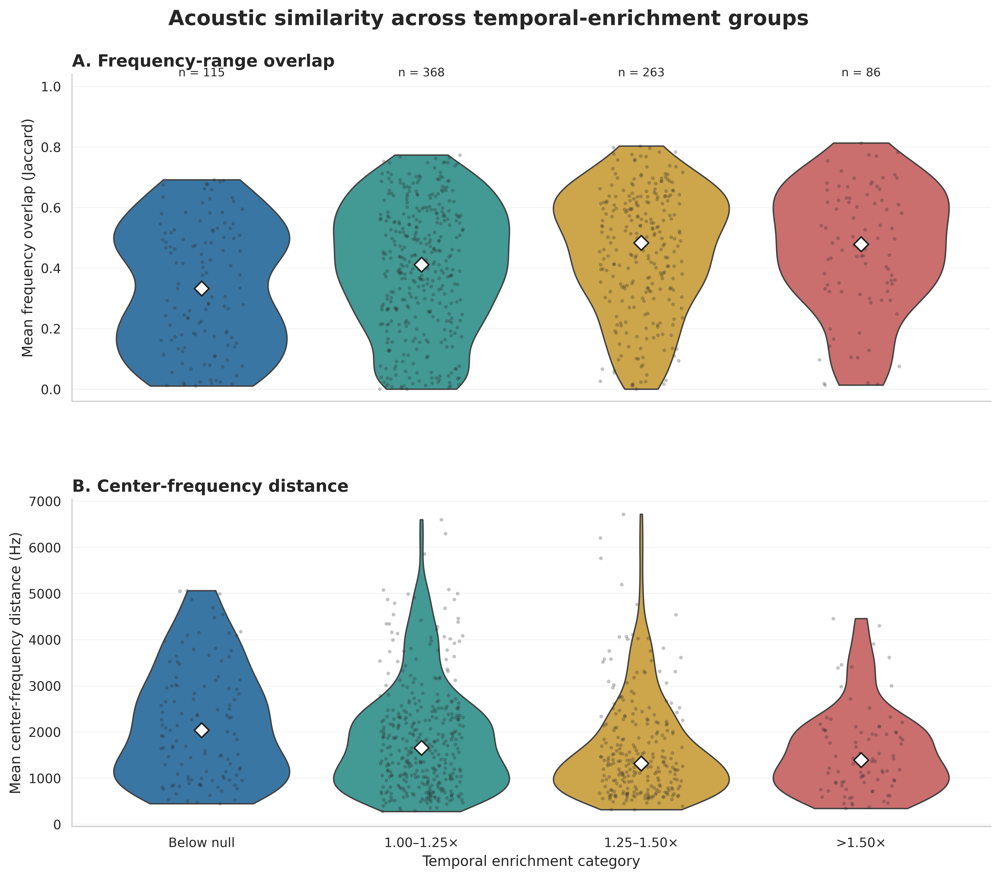


Q3 FIGURE 3 GENERATED SUCCESSFULLY
PNG: /content/drive/MyDrive/data/derived/publication_figure_atlas/Q3_Figure_3_acoustic_enrichment_distributions.png
PDF: /content/drive/MyDrive/data/derived/publication_figure_atlas/Q3_Figure_3_acoustic_enrichment_distributions.pdf
SVG: /content/drive/MyDrive/data/derived/publication_figure_atlas/Q3_Figure_3_acoustic_enrichment_distributions.svg


In [ ]:

# ================================================================
# Q3 FIGURE 3
# ACOUSTIC SIMILARITY ACROSS TEMPORAL-ENRICHMENT GROUPS
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

# ------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/data/derived/"
    "publication_figure_atlas"
)
os.makedirs(OUT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. VERIFY DATA
# ------------------------------------------------

if "plot_data" not in globals():
    raise NameError(
        "plot_data not found. Run the Q3 Figure 2 data-preparation "
        "cell first."
    )

required = [
    "fold_enrichment",
    "mean_frequency_overlap",
    "mean_center_distance_hz"
]

for col in required:
    if col not in plot_data.columns:
        raise ValueError(f"Missing required column: {col}")

# ------------------------------------------------
# 3. CREATE ENRICHMENT GROUPS
# ------------------------------------------------

df = plot_data.copy()

df = df[
    (df["fold_enrichment"] > 0) &
    np.isfinite(df["mean_frequency_overlap"]) &
    np.isfinite(df["mean_center_distance_hz"])
].copy()

group_labels = [
    "Below null",
    "1.00–1.25×",
    "1.25–1.50×",
    ">1.50×"
]

df["enrichment_group"] = pd.cut(
    df["fold_enrichment"],
    bins=[0, 1, 1.25, 1.50, np.inf],
    labels=group_labels,
    right=False
)

df = df.dropna(subset=["enrichment_group"])

print("Species pairs in each enrichment group:")
print(
    df.groupby(
        "enrichment_group",
        observed=False
    ).size()
)

# ------------------------------------------------
# 4. SUMMARY STATISTICS
# ------------------------------------------------

summary = (
    df.groupby("enrichment_group", observed=False)
    .agg(
        pair_count=("fold_enrichment", "size"),
        median_overlap=("mean_frequency_overlap", "median"),
        mean_overlap=("mean_frequency_overlap", "mean"),
        median_distance=("mean_center_distance_hz", "median"),
        mean_distance=("mean_center_distance_hz", "mean")
    )
    .reindex(group_labels)
)

print("\nGroup summary:")
display(summary.round(3))

# ------------------------------------------------
# 5. PUBLICATION STYLE
# ------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.titlesize": 16,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.9
})

palette = {
    "Below null": "#2878B5",
    "1.00–1.25×": "#35A7A0",
    "1.25–1.50×": "#E3AD35",
    ">1.50×": "#D95F5F"
}

# ------------------------------------------------
# 6. FIGURE
# ------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(11.5, 10),
    sharex=True
)

# ------------------------------------------------
# PANEL A — FREQUENCY OVERLAP
# ------------------------------------------------

sns.violinplot(
    data=df,
    x="enrichment_group",
    y="mean_frequency_overlap",
    order=group_labels,
    hue="enrichment_group",
    palette=palette,
    legend=False,
    inner=None,
    cut=0,
    density_norm="width",
    linewidth=1.1,
    ax=axes[0]
)

sns.stripplot(
    data=df,
    x="enrichment_group",
    y="mean_frequency_overlap",
    order=group_labels,
    color="#292929",
    alpha=0.28,
    size=2.8,
    jitter=0.19,
    ax=axes[0]
)

# Median markers
for i, group in enumerate(group_labels):
    vals = df.loc[
        df["enrichment_group"] == group,
        "mean_frequency_overlap"
    ].dropna()

    if len(vals):
        axes[0].scatter(
            i,
            vals.median(),
            marker="D",
            s=65,
            color="#FFFFFF",
            edgecolor="#222222",
            linewidth=1.2,
            zorder=10
        )

axes[0].set_title(
    "A. Frequency-range overlap",
    loc="left",
    fontweight="bold"
)

axes[0].set_ylabel(
    "Mean frequency overlap (Jaccard)"
)

axes[0].set_xlabel("")
axes[0].set_ylim(-0.04, 1.04)

# ------------------------------------------------
# PANEL B — CENTER-FREQUENCY DISTANCE
# ------------------------------------------------

sns.violinplot(
    data=df,
    x="enrichment_group",
    y="mean_center_distance_hz",
    order=group_labels,
    hue="enrichment_group",
    palette=palette,
    legend=False,
    inner=None,
    cut=0,
    density_norm="width",
    linewidth=1.1,
    ax=axes[1]
)

sns.stripplot(
    data=df,
    x="enrichment_group",
    y="mean_center_distance_hz",
    order=group_labels,
    color="#292929",
    alpha=0.28,
    size=2.8,
    jitter=0.19,
    ax=axes[1]
)

for i, group in enumerate(group_labels):
    vals = df.loc[
        df["enrichment_group"] == group,
        "mean_center_distance_hz"
    ].dropna()

    if len(vals):
        axes[1].scatter(
            i,
            vals.median(),
            marker="D",
            s=65,
            color="#FFFFFF",
            edgecolor="#222222",
            linewidth=1.2,
            zorder=10
        )

axes[1].set_title(
    "B. Center-frequency distance",
    loc="left",
    fontweight="bold"
)

axes[1].set_ylabel(
    "Mean center-frequency distance (Hz)"
)

axes[1].set_xlabel(
    "Temporal enrichment category"
)

# ------------------------------------------------
# 7. ADD SAMPLE COUNTS
# ------------------------------------------------

for ax in axes:
    ax.grid(axis="y", alpha=0.23)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

for i, group in enumerate(group_labels):
    n = int(
        (df["enrichment_group"] == group).sum()
    )

    axes[0].text(
        i, 1.025,
        f"n = {n:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# ------------------------------------------------
# 8. FIGURE TITLE AND LAYOUT
# ------------------------------------------------

fig.suptitle(
    "Acoustic similarity across temporal-enrichment groups",
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.11,
    right=0.97,
    bottom=0.10,
    top=0.91,
    hspace=0.30
)

# ------------------------------------------------
# 9. EXPORT
# ------------------------------------------------

base = os.path.join(
    OUT_DIR,
    "Q3_Figure_3_acoustic_enrichment_distributions"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

# ------------------------------------------------
# 10. DISPLAY
# ------------------------------------------------

plt.close(fig)

display(Image(filename=base + ".png"))

print("\nQ3 FIGURE 3 GENERATED SUCCESSFULLY")
print("PNG:", base + ".png")
print("PDF:", base + ".pdf")
print("SVG:", base + ".svg")


**Figure 3. Distribution of acoustic similarity across temporal-enrichment categories among heterospecific species pairs.** Species pairs were classified according to their observed-to-null succession enrichment: below null, 1.00–1.25×, 1.25–1.50×, and greater than 1.50×. (A) Distribution of mean frequency-range overlap (Jaccard similarity). (B) Distribution of mean center-frequency distance (Hz). Violin widths represent the distributions of pair-level values; individual points represent directed species pairs, and white diamonds indicate group medians. Sample sizes are shown above the distributions.

Interpretive note: This figure tests whether the modest correlations in Figure 2 are reflected in differences across enrichment categories. The distributions may overlap substantially even when the overall correlations are statistically significant. Do not interpret group differences as causal effects.

Q3 FIGURE 4 — OBSERVED DATA
Confirmed bird events: 182516
Valid heterospecific succession edges: 121625


,n_edges,observed_overlap,observed_distance
lag_bin,,,
0–1 s,46407,0.449585,1656.808536
1–2 s,28751,0.443821,1678.078626
2–5 s,34358,0.445677,1678.091110
5–10 s,12109,0.458915,1619.765915


Frequency shuffle groups: 9,218
Events in shuffleable groups: 181,215
Completed 100/1,000 permutations
Completed 200/1,000 permutations
Completed 300/1,000 permutations
Completed 400/1,000 permutations
Completed 500/1,000 permutations
Completed 600/1,000 permutations
Completed 700/1,000 permutations
Completed 800/1,000 permutations
Completed 900/1,000 permutations
Completed 1,000/1,000 permutations

Q3 FIGURE 4 — LAG-SPECIFIC NULL RESULTS


,lag_bin,n_edges,observed_overlap,null_overlap,overlap_low,overlap_high,overlap_percent_difference,overlap_p,observed_distance,null_distance,distance_low,distance_high,distance_percent_difference,distance_p
0,0–1 s,46407,0.4496,0.4462,0.4451,0.4474,0.7593,0.0020,1656.8085,1661.9850,1657.1599,1667.1186,-0.3115,0.0400
1,1–2 s,28751,0.4438,0.4400,0.4385,0.4413,0.8701,0.0020,1678.0786,1693.3265,1686.7031,1699.7357,-0.9005,0.0020
2,2–5 s,34358,0.4457,0.4427,0.4413,0.4440,0.6791,0.0020,1678.0911,1685.2365,1679.3155,1691.3057,-0.4240,0.0220
3,5–10 s,12109,0.4589,0.4568,0.4548,0.4589,0.4589,0.0519,1619.7659,1627.7247,1617.7173,1637.0551,-0.4890,0.0979


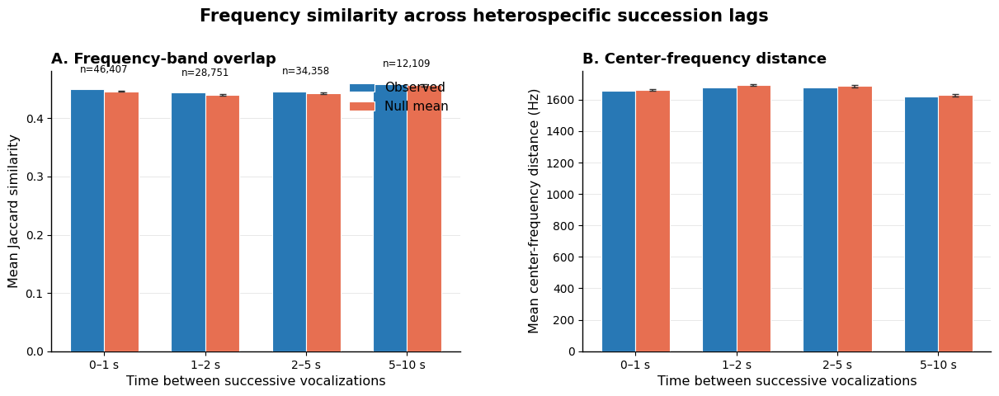


FIGURE 4 EXPORTED
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_4_frequency_similarity_by_lag.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_4_frequency_similarity_by_lag.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_4_frequency_similarity_by_lag.svg


In [32]:

# Q3 — FIGURE 4 | STEP 1
# Frequency similarity across temporal succession lags.
#
# Panel A: observed vs null mean frequency Jaccard overlap.
# Panel B: observed vs null mean center-frequency distance.
#
# Null model: shuffle frequency profiles within recording × species.
# Permutations: 1,000 | Original seed: 122
#
# Uses saved master_events.csv and master_edges.csv.
# Does not modify source data, Q4/Q5 results, or model checkpoints.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Settings and source data
# ------------------------------------------------------------
DATA_DIR = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"
OUTPUT_DIR = os.path.join(DATA_DIR, "publication_figure_atlas")
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_PERMUTATIONS = 1000
RANDOM_SEED = 122

LAG_LABELS = ["0–1 s", "1–2 s", "2–5 s", "5–10 s"]

events = pd.read_csv(
    os.path.join(DATA_DIR, "master_events.csv"),
    dtype={"event_id": str}
)

edges = pd.read_csv(
    os.path.join(DATA_DIR, "master_edges.csv"),
    dtype={"source_event": str, "target_event": str}
)

# Confirmed bird events with valid frequency boundaries.
bird_events = events.loc[
    events["is_bird"].astype(str).str.strip().str.lower().eq("yes")
    & events["species_code"].notna()
    & events["itemID"].notna()
    & events["duration_s"].notna()
    & events["event_id"].notna()
    & events["low_freq_hz"].notna()
    & events["high_freq_hz"].notna()
].copy().reset_index(drop=True)

# Keep heterospecific succession edges.
succession = edges.loc[
    (edges["relationship_type"] == "succession")
    & (edges["source_species"] != edges["target_species"])
].copy()

# ------------------------------------------------------------
# 2. Match source and target events
# ------------------------------------------------------------
event_position = pd.Series(
    np.arange(len(bird_events)),
    index=bird_events["event_id"]
)

succession["source_pos"] = succession["source_event"].map(event_position)
succession["target_pos"] = succession["target_event"].map(event_position)

succession = succession.dropna(
    subset=["source_pos", "target_pos", "gap_s"]
).copy()

succession["source_pos"] = succession["source_pos"].astype(int)
succession["target_pos"] = succession["target_pos"].astype(int)

# Restrict to the four original lag intervals.
# Intervals are left-inclusive and right-exclusive, except 5–10 s includes 10.
gap = succession["gap_s"].to_numpy()

lag_conditions = [
    (gap >= 0) & (gap < 1),
    (gap >= 1) & (gap < 2),
    (gap >= 2) & (gap < 5),
    (gap >= 5) & (gap <= 10)
]

succession["lag_bin"] = np.select(
    lag_conditions,
    LAG_LABELS,
    default="outside"
)

succession = succession.loc[
    succession["lag_bin"].isin(LAG_LABELS)
].copy().reset_index(drop=True)

# ------------------------------------------------------------
# 3. Calculate observed frequency metrics
# ------------------------------------------------------------
source_pos = succession["source_pos"].to_numpy(dtype=np.int32)
target_pos = succession["target_pos"].to_numpy(dtype=np.int32)

low = bird_events["low_freq_hz"].to_numpy(dtype=float)
high = bird_events["high_freq_hz"].to_numpy(dtype=float)

source_low = low[source_pos]
source_high = high[source_pos]
target_low = low[target_pos]
target_high = high[target_pos]

intersection = np.maximum(
    0,
    np.minimum(source_high, target_high)
    - np.maximum(source_low, target_low)
)

union = (
    np.maximum(source_high, target_high)
    - np.minimum(source_low, target_low)
)

succession["frequency_jaccard"] = np.divide(
    intersection,
    union,
    out=np.full(len(union), np.nan),
    where=union > 0
)

source_center = (source_low + source_high) / 2
target_center = (target_low + target_high) / 2

succession["frequency_center_distance_hz"] = np.abs(
    source_center - target_center
)

succession = succession.dropna(
    subset=["frequency_jaccard", "frequency_center_distance_hz"]
).copy().reset_index(drop=True)

# ------------------------------------------------------------
# 4. Prepare observed lag-specific means
# ------------------------------------------------------------
observed_by_lag = (
    succession.groupby("lag_bin")
    .agg(
        n_edges=("frequency_jaccard", "size"),
        observed_overlap=("frequency_jaccard", "mean"),
        observed_distance=("frequency_center_distance_hz", "mean")
    )
    .reindex(LAG_LABELS)
)

print("Q3 FIGURE 4 — OBSERVED DATA")
print("Confirmed bird events:", len(bird_events))
print("Valid heterospecific succession edges:", len(succession))
display(observed_by_lag)

# ------------------------------------------------------------
# 5. Prepare frequency-profile shuffle groups
#    Original method: recording × species
# ------------------------------------------------------------
shuffle_groups = [
    group.index.to_numpy(dtype=np.int32)
    for _, group in bird_events.groupby(
        ["itemID", "species_code"],
        sort=False
    )
]

shuffleable_events = sum(
    len(idx) for idx in shuffle_groups if len(idx) > 1
)

print(f"Frequency shuffle groups: {len(shuffle_groups):,}")
print(f"Events in shuffleable groups: {shuffleable_events:,}")

lag_masks = {
    label: succession["lag_bin"].eq(label).to_numpy()
    for label in LAG_LABELS
}

# ------------------------------------------------------------
# 6. Run the 1,000-permutation frequency null model
# ------------------------------------------------------------
rng = np.random.default_rng(RANDOM_SEED)

null_overlap = {
    label: np.empty(N_PERMUTATIONS)
    for label in LAG_LABELS
}

null_distance = {
    label: np.empty(N_PERMUTATIONS)
    for label in LAG_LABELS
}

for r in range(N_PERMUTATIONS):

    shuffled_low = low.copy()
    shuffled_high = high.copy()

    for idx in shuffle_groups:
        if len(idx) > 1:
            perm = rng.permutation(len(idx))
            shuffled_low[idx] = low[idx[perm]]
            shuffled_high[idx] = high[idx[perm]]

    s_low = shuffled_low[source_pos]
    s_high = shuffled_high[source_pos]
    t_low = shuffled_low[target_pos]
    t_high = shuffled_high[target_pos]

    perm_intersection = np.maximum(
        0,
        np.minimum(s_high, t_high) - np.maximum(s_low, t_low)
    )

    perm_union = np.maximum(s_high, t_high) - np.minimum(s_low, t_low)

    perm_jaccard = np.divide(
        perm_intersection,
        perm_union,
        out=np.full(len(perm_union), np.nan),
        where=perm_union > 0
    )

    s_center = (s_low + s_high) / 2
    t_center = (t_low + t_high) / 2
    perm_distance = np.abs(s_center - t_center)

    for label in LAG_LABELS:
        mask = lag_masks[label]

        null_overlap[label][r] = np.nanmean(perm_jaccard[mask])
        null_distance[label][r] = np.nanmean(perm_distance[mask])

    if (r + 1) % 100 == 0:
        print(f"Completed {r + 1:,}/{N_PERMUTATIONS:,} permutations")

# ------------------------------------------------------------
# 7. Summarize null distributions and permutation significance
# ------------------------------------------------------------
results = []

for label in LAG_LABELS:
    obs = observed_by_lag.loc[label]

    no = null_overlap[label]
    nd = null_distance[label]

    p_overlap = (
        1 + np.sum(np.abs(no - no.mean()) >= abs(obs["observed_overlap"] - no.mean()))
    ) / (N_PERMUTATIONS + 1)

    p_distance = (
        1 + np.sum(np.abs(nd - nd.mean()) >= abs(obs["observed_distance"] - nd.mean()))
    ) / (N_PERMUTATIONS + 1)

    results.append({
        "lag_bin": label,
        "n_edges": int(obs["n_edges"]),

        "observed_overlap": obs["observed_overlap"],
        "null_overlap": no.mean(),
        "overlap_low": np.percentile(no, 2.5),
        "overlap_high": np.percentile(no, 97.5),
        "overlap_percent_difference": (
            100 * (obs["observed_overlap"] - no.mean()) / no.mean()
        ),
        "overlap_p": min(1.0, 2 * min(
            (1 + np.sum(no <= obs["observed_overlap"])) / (N_PERMUTATIONS + 1),
            (1 + np.sum(no >= obs["observed_overlap"])) / (N_PERMUTATIONS + 1)
        )),

        "observed_distance": obs["observed_distance"],
        "null_distance": nd.mean(),
        "distance_low": np.percentile(nd, 2.5),
        "distance_high": np.percentile(nd, 97.5),
        "distance_percent_difference": (
            100 * (obs["observed_distance"] - nd.mean()) / nd.mean()
        ),
        "distance_p": min(1.0, 2 * min(
            (1 + np.sum(nd <= obs["observed_distance"])) / (N_PERMUTATIONS + 1),
            (1 + np.sum(nd >= obs["observed_distance"])) / (N_PERMUTATIONS + 1)
        ))
    })

lag_frequency_results = pd.DataFrame(results)

print("\nQ3 FIGURE 4 — LAG-SPECIFIC NULL RESULTS")
display(lag_frequency_results.round(4))

# ------------------------------------------------------------
# 8. Publication-quality two-panel figure
# ------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.4))
fig.subplots_adjust(left=0.09, right=0.98, bottom=0.19, top=0.82, wspace=0.30)

x = np.arange(len(LAG_LABELS))
width = 0.34

observed_color = "#2878B5"
null_color = "#E76F51"

# Panel A — Jaccard overlap
ax = axes[0]
r = lag_frequency_results

ax.bar(
    x - width/2,
    r["observed_overlap"],
    width,
    color=observed_color,
    edgecolor="white",
    linewidth=0.8,
    label="Observed",
    zorder=3
)

ax.bar(
    x + width/2,
    r["null_overlap"],
    width,
    color=null_color,
    edgecolor="white",
    linewidth=0.8,
    label="Null mean",
    zorder=3
)

ax.errorbar(
    x + width/2,
    r["null_overlap"],
    yerr=[
        r["null_overlap"] - r["overlap_low"],
        r["overlap_high"] - r["null_overlap"]
    ],
    fmt="none",
    ecolor="#333333",
    capsize=3,
    linewidth=1.1,
    zorder=4
)

for i, row in r.iterrows():
    ax.text(
        i,
        max(row["observed_overlap"], row["null_overlap"]) + 0.025,
        f"n={row['n_edges']:,}",
        ha="center",
        va="bottom",
        fontsize=8.5
    )

ax.set_title("A. Frequency-band overlap", loc="left", fontweight="bold")
ax.set_ylabel("Mean Jaccard similarity")
ax.set_xticks(x, LAG_LABELS)
ax.set_ylim(bottom=0)
ax.legend(frameon=False, loc="upper right")

# Panel B — center-frequency distance
ax = axes[1]

ax.bar(
    x - width/2,
    r["observed_distance"],
    width,
    color=observed_color,
    edgecolor="white",
    linewidth=0.8,
    label="Observed",
    zorder=3
)

ax.bar(
    x + width/2,
    r["null_distance"],
    width,
    color=null_color,
    edgecolor="white",
    linewidth=0.8,
    label="Null mean",
    zorder=3
)

ax.errorbar(
    x + width/2,
    r["null_distance"],
    yerr=[
        r["null_distance"] - r["distance_low"],
        r["distance_high"] - r["null_distance"]
    ],
    fmt="none",
    ecolor="#333333",
    capsize=3,
    linewidth=1.1,
    zorder=4
)

ax.set_title("B. Center-frequency distance", loc="left", fontweight="bold")
ax.set_ylabel("Mean center-frequency distance (Hz)")
ax.set_xticks(x, LAG_LABELS)
ax.set_ylim(bottom=0)

for ax in axes:
    ax.set_xlabel("Time between successive vocalizations")
    ax.grid(axis="y", color="#E8E8E8", linewidth=0.7)
    ax.set_axisbelow(True)

fig.suptitle(
    "Frequency similarity across heterospecific succession lags",
    fontsize=15,
    fontweight="bold",
    y=0.96
)

# ------------------------------------------------------------
# 9. Export figure files
# ------------------------------------------------------------
base = os.path.join(OUTPUT_DIR, "Q3_Figure_4_frequency_similarity_by_lag")

fig.savefig(base + ".png", dpi=600, bbox_inches="tight")
fig.savefig(base + ".pdf", bbox_inches="tight")
fig.savefig(base + ".svg", bbox_inches="tight")

plt.show()

print("\nFIGURE 4 EXPORTED")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")


**Figure 4. Frequency similarity across heterospecific succession lags.** Observed frequency-band overlap (A; mean Jaccard similarity) and center-frequency distance (B; Hz) were compared with frequency-shuffle null expectations across four temporal lag bins. Frequency profiles were shuffled within recording-by-species groups over 1,000 permutations, preserving species-specific frequency distributions. Successive heterospecific vocalizations showed modestly greater frequency-band overlap and smaller center-frequency distances than expected at lags of 0–5 seconds. Differences were not statistically significant at 5–10 seconds. Values are means across eligible succession edges; null intervals represent the 2.5th–97.5th percentiles of the permutation distributions.

Q3 FIGURE 5 — DATA CHECK
------------------------
Species pairs plotted: 832
Enrichment range: 0.612–2.427

SPEARMAN CORRELATIONS
---------------------
Enrichment vs. frequency overlap: rho = 0.1925, p = 2.186e-08
Enrichment vs. center-frequency distance: rho = -0.1828, p = 1.099e-07


/tmp/ipykernel_404/1056307990.py:324: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


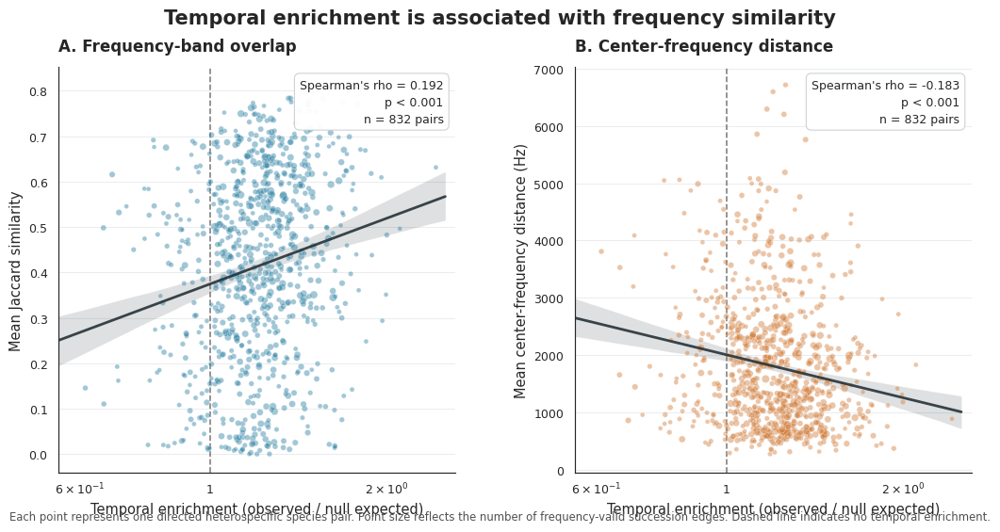


FIGURE 5 EXPORTED SUCCESSFULLY
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_5_temporal_enrichment_frequency_relationship.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_5_temporal_enrichment_frequency_relationship.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_5_temporal_enrichment_frequency_relationship.svg


In [36]:

# ============================================================
# Q3 FIGURE 5 — TEMPORAL ENRICHMENT AND FREQUENCY SIMILARITY
# Publication-ready pair-level relationship figure
#
# Uses existing pair_frequency_analysis (832 species pairs).
# Does NOT rerun the permutation null model.
#
# Panel A: Enrichment vs. frequency-band overlap
# Panel B: Enrichment vs. center-frequency distance
#
# Exports: PNG (600 dpi), PDF, SVG
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from matplotlib.ticker import LogLocator, FuncFormatter

# ------------------------------------------------------------
# 1. Validate existing Q3 data
# ------------------------------------------------------------

if "pair_frequency_analysis" not in globals():
    raise NameError(
        "pair_frequency_analysis is unavailable. "
        "Run the Q3 pair-frequency analysis first."
    )

plot_data = pair_frequency_analysis.copy()

required_columns = [
    "fold_enrichment",
    "frequency_overlap",
    "center_distance_hz",
    "frequency_edge_count"
]

missing = [
    col for col in required_columns
    if col not in plot_data.columns
]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Numeric conversion and cleaning
for col in required_columns:
    plot_data[col] = pd.to_numeric(
        plot_data[col], errors="coerce"
    )

plot_data = plot_data.replace(
    [np.inf, -np.inf], np.nan
)

plot_data = plot_data.dropna(
    subset=required_columns
).copy()

# Log axis requires positive enrichment
plot_data = plot_data[
    plot_data["fold_enrichment"] > 0
].copy()

if len(plot_data) < 10:
    raise ValueError(
        "Too few valid species pairs for Figure 5."
    )

plot_data["log_edge_count"] = np.log10(
    plot_data["frequency_edge_count"].clip(lower=1)
)

print("Q3 FIGURE 5 — DATA CHECK")
print("------------------------")
print(f"Species pairs plotted: {len(plot_data):,}")
print(
    "Enrichment range:",
    f"{plot_data['fold_enrichment'].min():.3f}–"
    f"{plot_data['fold_enrichment'].max():.3f}"
)

# ------------------------------------------------------------
# 2. Calculate correlations
# ------------------------------------------------------------

rho_overlap, p_overlap = spearmanr(
    plot_data["fold_enrichment"],
    plot_data["frequency_overlap"]
)

rho_distance, p_distance = spearmanr(
    plot_data["fold_enrichment"],
    plot_data["center_distance_hz"]
)

print("\nSPEARMAN CORRELATIONS")
print("---------------------")
print(
    f"Enrichment vs. frequency overlap: "
    f"rho = {rho_overlap:.4f}, p = {p_overlap:.3e}"
)
print(
    f"Enrichment vs. center-frequency distance: "
    f"rho = {rho_distance:.4f}, p = {p_distance:.3e}"
)

# ------------------------------------------------------------
# 3. Publication style
# ------------------------------------------------------------

sns.set_theme(style="white", context="paper")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.labelweight": "medium",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 15,
    "figure.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.85,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

# Balanced, coordinated colors
colors = {
    "overlap": "#277DA1",
    "distance": "#D17A35",
    "reference": "#666666",
    "regression": "#263238"
}

# ------------------------------------------------------------
# 4. Figure layout
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 5.6),
    gridspec_kw={"wspace": 0.30}
)

panels = [
    {
        "ax": axes[0],
        "y": "frequency_overlap",
        "color": colors["overlap"],
        "title": "A. Frequency-band overlap",
        "ylabel": "Mean Jaccard similarity",
        "rho": rho_overlap,
        "p": p_overlap
    },
    {
        "ax": axes[1],
        "y": "center_distance_hz",
        "color": colors["distance"],
        "title": "B. Center-frequency distance",
        "ylabel": "Mean center-frequency distance (Hz)",
        "rho": rho_distance,
        "p": p_distance
    }
]

# Common enrichment axis
x_min = max(
    0.01,
    plot_data["fold_enrichment"].min() * 0.90
)

x_max = plot_data["fold_enrichment"].max() * 1.08

for panel in panels:

    ax = panel["ax"]
    y_col = panel["y"]

    # Scatter: point size reflects number of frequency edges
    point_sizes = (
        12 + 25 * (
            plot_data["log_edge_count"]
            - plot_data["log_edge_count"].min()
        ) / (
            plot_data["log_edge_count"].max()
            - plot_data["log_edge_count"].min()
            + 1e-9
        )
    )

    ax.scatter(
        plot_data["fold_enrichment"],
        plot_data[y_col],
        s=point_sizes,
        color=panel["color"],
        alpha=0.43,
        edgecolors="white",
        linewidths=0.35,
        rasterized=True,
        zorder=2
    )

    # Regression guide on log-transformed enrichment
    sns.regplot(
        data=plot_data,
        x="fold_enrichment",
        y=y_col,
        logx=True,
        scatter=False,
        ci=95,
        truncate=False,
        color=colors["regression"],
        line_kws={
            "linewidth": 2.0,
            "linestyle": "-",
            "alpha": 0.9
        },
        ax=ax
    )

    # No-enrichment reference
    ax.axvline(
        1,
        color=colors["reference"],
        linewidth=1.15,
        linestyle="--",
        alpha=0.85,
        zorder=1
    )

    # Log-scaled x-axis
    ax.set_xscale("log")
    ax.set_xlim(x_min, x_max)
    ax.xaxis.set_major_locator(
        LogLocator(base=10, numticks=8)
    )
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:g}")
    )

    # Panel formatting
    ax.set_title(
        panel["title"],
        loc="left",
        pad=12
    )

    ax.set_xlabel(
        "Temporal enrichment (observed / null expected)"
    )

    ax.set_ylabel(panel["ylabel"])

    ax.grid(
        axis="y",
        color="#D9DDE0",
        linewidth=0.6,
        alpha=0.65
    )

    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

    # Correlation annotation
    p_text = (
        "p < 0.001"
        if panel["p"] < 0.001
        else f"p = {panel['p']:.3f}"
    )

    annotation = (
        f"Spearman's rho = {panel['rho']:.3f}\n"
        f"{p_text}\n"
        f"n = {len(plot_data):,} pairs"
    )

    ax.text(
        0.97, 0.97,
        annotation,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        linespacing=1.5,
        bbox={
            "boxstyle": "round,pad=0.45",
            "facecolor": "white",
            "edgecolor": "#C8CDD1",
            "linewidth": 0.75,
            "alpha": 0.96
        }
    )

# ------------------------------------------------------------
# 5. Figure title and explanatory note
# ------------------------------------------------------------

fig.suptitle(
    "Temporal enrichment is associated with frequency similarity",
    y=0.99
)

fig.text(
    0.5, 0.015,
    "Each point represents one directed heterospecific species pair. "
    "Point size reflects the number of frequency-valid succession edges. "
    "Dashed line indicates no temporal enrichment.",
    ha="center",
    va="bottom",
    fontsize=8.4,
    color="#505050"
)

plt.tight_layout(
    rect=[0, 0.065, 1, 0.94]
)

# ------------------------------------------------------------
# 6. Export publication files
# ------------------------------------------------------------

output_dir = (
    "/content/gdrive/MyDrive/Bioacoustics_Project/"
    "data/derived/publication_figure_atlas"
)

os.makedirs(output_dir, exist_ok=True)

base = os.path.join(
    output_dir,
    "Q3_Figure_5_temporal_enrichment_frequency_relationship"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFIGURE 5 EXPORTED SUCCESSFULLY")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")


**Figure 5. Relationships between temporal enrichment and frequency similarity among heterospecific species pairs.** (A) Association between temporal enrichment, expressed as the ratio of observed to null-expected succession frequency, and mean frequency-band overlap (Jaccard similarity). (B) Association between temporal enrichment and mean absolute center-frequency distance. Each point represents one directed heterospecific species pair; point size reflects the number of frequency-valid succession edges. Solid lines indicate fitted trends, and dashed vertical lines indicate the null expectation of no temporal enrichment (fold enrichment = 1). Spearman rank correlations quantify the direction and strength of pair-level associations.


SELECTED Q3 SPECIES PAIRS
1. BHVI → REVI | Overlap = 0.813 | Distance = 372.0 Hz | Edges = 44
2. MAWA → NOPA | Overlap = 0.803 | Distance = 459.2 Hz | Edges = 49
3. COYE → WIWR | Overlap = 0.796 | Distance = 316.9 Hz | Edges = 20

EVENT-LEVEL SAMPLE SIZES


,pair_number,source,target,overlap,distance,edge_count,source_n,target_n
0,1,BHVI,REVI,0.812837,372.028500,44,60,67
1,2,MAWA,NOPA,0.802825,459.179184,49,53,53
2,3,COYE,WIWR,0.795717,316.889050,20,22,22


/tmp/ipykernel_404/2910379968.py:545: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


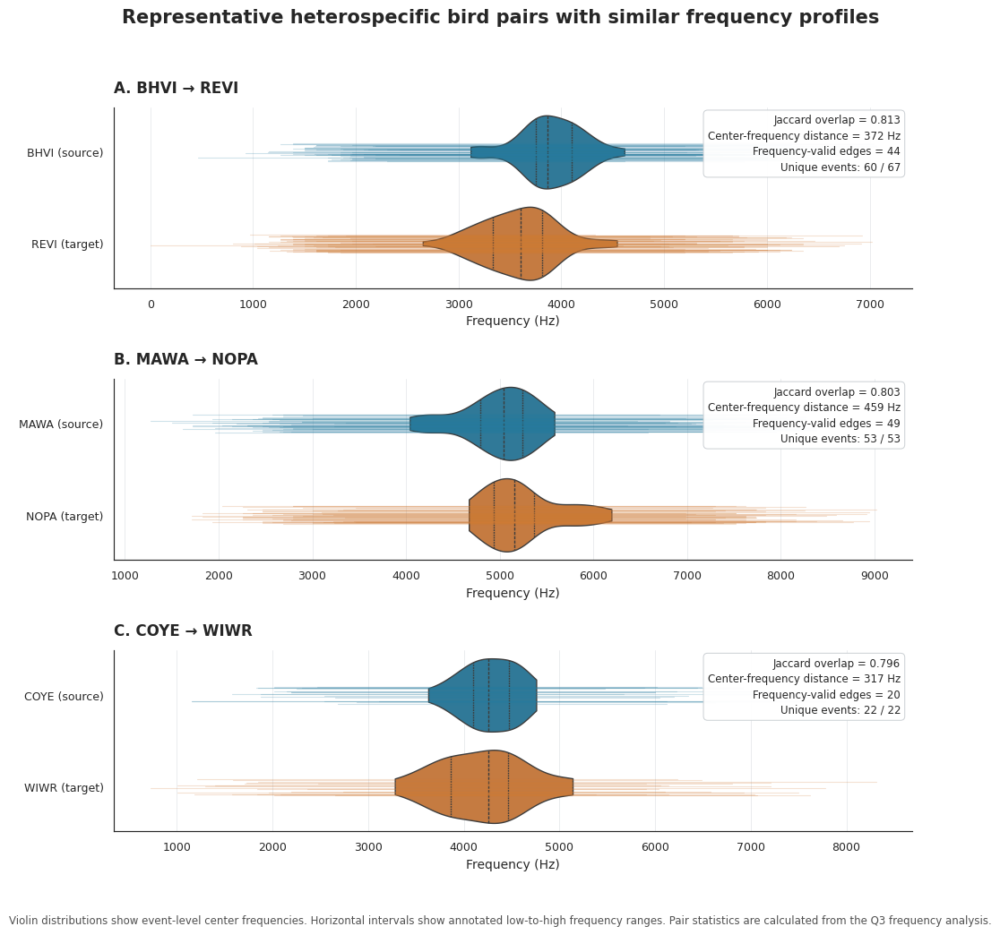


Q3 FIGURE 5 EXPORTED SUCCESSFULLY
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_5_examples_frequency_similar_species_pairs.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_5_examples_frequency_similar_species_pairs.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q3_Figure_5_examples_frequency_similar_species_pairs.svg


In [38]:

# ============================================================
# Q3 FIGURE 5
# REPRESENTATIVE HETEROSPECIFIC PAIRS WITH SIMILAR FREQUENCIES
#
# Three distinct species combinations selected from Q3 data.
# Uses actual annotated event-level frequency measurements.
#
# Panels:
#   A-C: Event-level frequency distributions and frequency ranges
#
# Exports:
#   PNG (600 dpi), PDF, SVG
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. PROJECT PATHS AND EXISTING Q3 DATA
# ------------------------------------------------------------

project_dir = (
    "/content/gdrive/MyDrive/Bioacoustics_Project"
)

events_path = os.path.join(
    project_dir,
    "data/derived/master_events.csv"
)

edges_path = os.path.join(
    project_dir,
    "data/derived/master_edges.csv"
)

if "pair_frequency_analysis" not in globals():
    raise NameError(
        "pair_frequency_analysis is missing. "
        "Run the Q3 pair-frequency analysis first."
    )

if not os.path.exists(events_path):
    raise FileNotFoundError(events_path)

if not os.path.exists(edges_path):
    raise FileNotFoundError(edges_path)

# Load source tables
events = pd.read_csv(events_path)
edges = pd.read_csv(edges_path)

pair_data = pair_frequency_analysis.copy()

# ------------------------------------------------------------
# 2. VALIDATE REQUIRED COLUMNS
# ------------------------------------------------------------

required_pair_columns = [
    "source_species",
    "target_species",
    "frequency_overlap",
    "center_distance_hz",
    "frequency_edge_count"
]

required_event_columns = [
    "event_id",
    "species_code",
    "is_bird",
    "low_freq_hz",
    "high_freq_hz"
]

required_edge_columns = [
    "source_event",
    "target_event",
    "source_species",
    "target_species"
]

for col in required_pair_columns:
    if col not in pair_data.columns:
        raise ValueError(
            f"Missing pair-frequency column: {col}"
        )

for col in required_event_columns:
    if col not in events.columns:
        raise ValueError(
            f"Missing event column: {col}"
        )

for col in required_edge_columns:
    if col not in edges.columns:
        raise ValueError(
            f"Missing edge column: {col}"
        )

# Normalize identifiers
for df, cols in [
    (
        events,
        ["event_id", "species_code"]
    ),
    (
        edges,
        [
            "source_event",
            "target_event",
            "source_species",
            "target_species"
        ]
    ),
    (
        pair_data,
        ["source_species", "target_species"]
    )
]:
    for col in cols:
        df[col] = df[col].astype(str).str.strip()

# Convert numeric variables
for col in [
    "frequency_overlap",
    "center_distance_hz",
    "frequency_edge_count"
]:
    pair_data[col] = pd.to_numeric(
        pair_data[col],
        errors="coerce"
    )

for col in ["low_freq_hz", "high_freq_hz"]:
    events[col] = pd.to_numeric(
        events[col],
        errors="coerce"
    )

# ------------------------------------------------------------
# 3. SELECT THREE DISTINCT SPECIES COMBINATIONS
# ------------------------------------------------------------

MIN_FREQUENCY_EDGES = 20

eligible = pair_data.dropna(
    subset=[
        "frequency_overlap",
        "center_distance_hz",
        "frequency_edge_count"
    ]
).copy()

eligible = eligible[
    (eligible["frequency_edge_count"] >= MIN_FREQUENCY_EDGES)
    & (eligible["frequency_overlap"] >= 0)
    & (eligible["center_distance_hz"] >= 0)
].copy()

# Treat opposite directions as the same species combination.
# Retain the strongest directed result for each combination.
eligible["species_combination"] = eligible.apply(
    lambda r: tuple(sorted([
        r["source_species"],
        r["target_species"]
    ])),
    axis=1
)

eligible = eligible.sort_values(
    [
        "frequency_overlap",
        "center_distance_hz",
        "frequency_edge_count"
    ],
    ascending=[False, True, False]
)

selected = (
    eligible
    .drop_duplicates(
        subset="species_combination",
        keep="first"
    )
    .head(3)
    .copy()
    .reset_index(drop=True)
)

if len(selected) < 3:
    raise ValueError(
        "Fewer than three distinct eligible species "
        "combinations were found."
    )

print("\nSELECTED Q3 SPECIES PAIRS")
print("=" * 65)

for i, row in selected.iterrows():
    print(
        f"{i+1}. {row['source_species']} → "
        f"{row['target_species']} | "
        f"Overlap = {row['frequency_overlap']:.3f} | "
        f"Distance = {row['center_distance_hz']:.1f} Hz | "
        f"Edges = {int(row['frequency_edge_count'])}"
    )

# ------------------------------------------------------------
# 4. PREPARE CONFIRMED BIRD EVENTS
# ------------------------------------------------------------

events["is_bird_clean"] = (
    events["is_bird"]
    .astype(str)
    .str.strip()
    .str.lower()
)

bird_events = events[
    (events["is_bird_clean"] == "yes")
    & events["low_freq_hz"].notna()
    & events["high_freq_hz"].notna()
    & (events["low_freq_hz"] >= 0)
    & (events["high_freq_hz"] > events["low_freq_hz"])
].copy()

bird_events["center_freq_hz"] = (
    bird_events["low_freq_hz"]
    + bird_events["high_freq_hz"]
) / 2

# IMPORTANT:
# drop=False retains event_id as both an index and a column.
bird_events = bird_events.drop_duplicates(
    subset="event_id"
)

event_lookup = bird_events.set_index(
    "event_id",
    drop=False
)

# ------------------------------------------------------------
# 5. EXTRACT ACTUAL EVENT-LEVEL FREQUENCY MEASUREMENTS
# ------------------------------------------------------------

plot_records = []
pair_plot_info = []

for pair_num, pair in selected.iterrows():

    source = pair["source_species"]
    target = pair["target_species"]

    pair_edges = edges[
        (edges["source_species"] == source)
        & (edges["target_species"] == target)
    ].copy()

    source_ids = pair_edges["source_event"].unique()
    target_ids = pair_edges["target_event"].unique()

    source_ids = [
        x for x in source_ids
        if x in event_lookup.index
    ]

    target_ids = [
        x for x in target_ids
        if x in event_lookup.index
    ]

    source_events = event_lookup.loc[
        source_ids
    ].copy()

    target_events = event_lookup.loc[
        target_ids
    ].copy()

    if isinstance(source_events, pd.Series):
        source_events = source_events.to_frame().T

    if isinstance(target_events, pd.Series):
        target_events = target_events.to_frame().T

    # Verify the species identity of each event
    source_events = source_events[
        source_events["species_code"] == source
    ]

    target_events = target_events[
        target_events["species_code"] == target
    ]

    # Record source and target event measurements
    for role, species, subset in [
        ("Source", source, source_events),
        ("Target", target, target_events)
    ]:

        for _, event in subset.iterrows():

            plot_records.append({
                "pair_number": pair_num + 1,
                "species_role": role,
                "species_code": species,
                "event_id": event["event_id"],
                "low_freq_hz": event["low_freq_hz"],
                "high_freq_hz": event["high_freq_hz"],
                "center_freq_hz": event["center_freq_hz"]
            })

    pair_plot_info.append({
        "pair_number": pair_num + 1,
        "source": source,
        "target": target,
        "overlap": pair["frequency_overlap"],
        "distance": pair["center_distance_hz"],
        "edge_count": int(pair["frequency_edge_count"]),
        "source_n": len(source_events),
        "target_n": len(target_events)
    })

plot_df = pd.DataFrame(plot_records)
pair_plot_info = pd.DataFrame(pair_plot_info)

if plot_df.empty:
    raise ValueError(
        "No matching event-level measurements were found. "
        "Check event IDs and species codes."
    )

print("\nEVENT-LEVEL SAMPLE SIZES")
print("=" * 65)
display(pair_plot_info)

# ------------------------------------------------------------
# 6. CHECK FREQUENCY DATA COVERAGE
# ------------------------------------------------------------

if (pair_plot_info["source_n"] == 0).any():
    raise ValueError(
        "At least one selected source species has no matched events."
    )

if (pair_plot_info["target_n"] == 0).any():
    raise ValueError(
        "At least one selected target species has no matched events."
    )

# ------------------------------------------------------------
# 7. PUBLICATION STYLE
# ------------------------------------------------------------

sns.set_theme(
    style="white",
    context="paper"
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "medium",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 15,
    "figure.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.85,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

palette = {
    "Source": "#277DA1",
    "Target": "#D17A35"
}

# ------------------------------------------------------------
# 8. CREATE THREE-ROW ACOUSTIC COMPARISON
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    1,
    figsize=(11.5, 10.5),
    gridspec_kw={"hspace": 0.50}
)

rng = np.random.default_rng(503)

for i, ax in enumerate(axes):

    info = pair_plot_info.iloc[i]

    subset = plot_df[
        plot_df["pair_number"] == info["pair_number"]
    ].copy()

    order = ["Source", "Target"]

    # Frequency distributions of event center frequencies
    sns.violinplot(
        data=subset,
        x="center_freq_hz",
        y="species_role",
        hue="species_role",
        order=order,
        hue_order=order,
        palette=palette,
        inner="quart",
        cut=0,
        density_norm="width",
        linewidth=1.0,
        saturation=0.85,
        legend=False,
        ax=ax
    )

    # Plot actual event-level frequency ranges as fine intervals
    # Each line represents one annotated event's low-high range.
    for role, ypos in [
        ("Source", 0),
        ("Target", 1)
    ]:

        role_data = subset[
            subset["species_role"] == role
        ].copy()

        # Limit interval overlays to a reproducible sample for clarity.
        if len(role_data) > 100:
            role_data = role_data.sample(
                100,
                random_state=503
            )

        y_jitter = rng.uniform(
            -0.10,
            0.10,
            size=len(role_data)
        )

        for (_, event), jitter in zip(
            role_data.iterrows(),
            y_jitter
        ):
            ax.plot(
                [
                    event["low_freq_hz"],
                    event["high_freq_hz"]
                ],
                [
                    ypos + jitter,
                    ypos + jitter
                ],
                color=palette[role],
                alpha=0.22,
                linewidth=0.8,
                solid_capstyle="round",
                zorder=3
            )

    # Species labels
    ax.set_yticks([0, 1])
    ax.set_yticklabels([
        f"{info['source']} (source)",
        f"{info['target']} (target)"
    ])

    ax.set_ylabel("")
    ax.set_xlabel("Frequency (Hz)")

    ax.set_title(
        f"{chr(65+i)}. {info['source']} → {info['target']}",
        loc="left",
        pad=12
    )

    # Pair-level metrics and sample sizes
    annotation = (
        f"Jaccard overlap = {info['overlap']:.3f}\n"
        f"Center-frequency distance = {info['distance']:.0f} Hz\n"
        f"Frequency-valid edges = {info['edge_count']:,}\n"
        f"Unique events: {info['source_n']:,} / {info['target_n']:,}"
    )

    ax.text(
        0.985,
        0.96,
        annotation,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8.5,
        linespacing=1.45,
        bbox={
            "boxstyle": "round,pad=0.4",
            "facecolor": "white",
            "edgecolor": "#C8CDD1",
            "linewidth": 0.7,
            "alpha": 0.96
        },
        zorder=5
    )

    ax.grid(
        axis="x",
        color="#D9DDE0",
        linewidth=0.6,
        alpha=0.65
    )

    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)

# ------------------------------------------------------------
# 9. FINAL FIGURE FORMATTING
# ------------------------------------------------------------

fig.suptitle(
    "Representative heterospecific bird pairs with similar frequency profiles",
    y=0.985
)

fig.text(
    0.5,
    0.012,
    "Violin distributions show event-level center frequencies. "
    "Horizontal intervals show annotated low-to-high frequency ranges. "
    "Pair statistics are calculated from the Q3 frequency analysis.",
    ha="center",
    fontsize=8.5,
    color="#505050"
)

plt.tight_layout(
    rect=[0.02, 0.045, 0.98, 0.96]
)

# ------------------------------------------------------------
# 10. EXPORT PUBLICATION FILES
# ------------------------------------------------------------

output_dir = os.path.join(
    project_dir,
    "data/derived/publication_figure_atlas"
)

os.makedirs(
    output_dir,
    exist_ok=True
)

base = os.path.join(
    output_dir,
    "Q3_Figure_5_examples_frequency_similar_species_pairs"
)

fig.savefig(
    base + ".png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".pdf",
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    base + ".svg",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nQ3 FIGURE 5 EXPORTED SUCCESSFULLY")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")


**Figure 5. Event-level frequency distributions for representative heterospecific bird pairs with high frequency similarity.** Three distinct species combinations were selected from the Q3 pair-level frequency analysis based on high mean frequency-band overlap, low center-frequency distance, and a minimum of 20 frequency-valid succession edges. Violin distributions show event-level center frequencies for source and target species; horizontal intervals represent annotated low-to-high frequency ranges for individual events. Pair-level Jaccard frequency overlap, center-frequency distance, and the number of frequency-valid succession edges are reported for each example. These representative pairs illustrate frequency similarity among species involved in heterospecific vocal succession.

In [40]:

# ============================================================
# Q4 FIGURE 1 — LOCATE EXISTING MODEL EVALUATION RESULTS
# No model training or prediction is performed.
# ============================================================

import pandas as pd

terms = [
    "q4", "gnn", "mlp", "top1", "top3", "top5",
    "accuracy", "precision", "recall", "f1",
    "baseline", "test", "evaluation", "metric",
    "prediction", "performance"
]

found = []

for name, obj in list(globals().items()):

    if not any(term in name.lower() for term in terms):
        continue

    if isinstance(obj, pd.DataFrame):
        found.append(name)
        print(f"\n{name} — DataFrame {obj.shape}")
        print("Columns:", obj.columns.tolist())
        display(obj.head(8))

    elif isinstance(obj, dict):
        found.append(name)
        print(f"\n{name} — dictionary")
        print("Keys:", list(obj.keys())[:30])

    elif isinstance(obj, (list, tuple)) and len(obj) < 30:
        found.append(name)
        print(f"\n{name} — {type(obj).__name__}")
        print(obj[:10])

print("\nObjects found:", found)



Objects found: []


In [41]:

# Q4 — Locate saved model evaluation files
import os

base = "/content/gdrive/MyDrive/Bioacoustics_Project"

print("Searching Q4-related saved results...\n")

for root, dirs, files in os.walk(base):
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    for file in files:
        name = file.lower()

        if (
            file.endswith((".csv", ".xlsx", ".json", ".pkl", ".parquet"))
            and any(term in name for term in [
                "q4", "gnn", "mlp", "metric",
                "result", "evaluation", "prediction"
            ])
        ):
            print(os.path.join(root, file))


Searching Q4-related saved results...

/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_splits.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_training_history.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_test_predictions.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_frequency_ablation_history.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/temporal_mlp_training_history.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_paired_bootstrap_results.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_recording_level_bootstrap_results.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_level_performance.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_confusions.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_species_coverage_summary.csv
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/gnn_specie

In [42]:

# ============================================================
# Q4 — INSPECT SAVED FINAL MODEL EVALUATION RESULTS
# Read-only. Does not train or modify any models.
# ============================================================

import os
import pandas as pd
import json

base = "/content/gdrive/MyDrive/Bioacoustics_Project/data/derived"

files_to_check = [
    "gnn_corrected_overall_test_metrics.csv",
    "gnn_paired_bootstrap_results.csv",
    "gnn_recording_level_bootstrap_results.csv",
    "gnn_species_level_performance_corrected.csv",
    "step181_temporal_mlp_test_inference/step181_temporal_mlp_test_metrics.csv",
    "step190_acoustic_ablation/step190_ablation_results.csv",
    "step190_acoustic_ablation/step191_reconstructed_absolute_metrics.csv",
    "step192_seed_robustness/step192_seed_results.csv",
    "step196_research_summary/step196_acoustic_ablation_metrics.csv",
    "step196_research_summary/step196_seed_results.csv"
]

for relative_path in files_to_check:

    path = os.path.join(base, relative_path)

    print("\n" + "=" * 75)
    print(relative_path)
    print("=" * 75)

    if not os.path.exists(path):
        print("Not found")
        continue

    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(12))

    except Exception as e:
        print("Could not read:", e)

# Also inspect the corrected GNN metrics JSON if present
json_path = os.path.join(
    base,
    "step184_temporal_plus_acoustic/step184_test_results.json"
)

if os.path.exists(json_path):
    print("\nSTEP 184 TEST RESULTS")
    with open(json_path) as f:
        print(json.dumps(json.load(f), indent=2))



gnn_corrected_overall_test_metrics.csv
Shape: (7, 2)
Columns: ['metric', 'value']


,metric,value
0,accuracy,0.445170
1,macro_precision,0.318066
2,macro_recall,0.286658
3,macro_F1,0.286169
4,weighted_F1,0.429885
5,test_species_count,68.000000
6,absent_test_species_count,27.000000



gnn_paired_bootstrap_results.csv
Shape: (4, 7)
Columns: ['comparison', 'metric', 'observed_difference', 'bootstrap_mean', 'CI_95_lower', 'CI_95_upper', 'P(difference > 0)']


,comparison,metric,observed_difference,bootstrap_mean,CI_95_lower,CI_95_upper,P(difference > 0)
0,Temporal GNN - Temporal MLP,Accuracy,0.001610,0.001580,-0.001789,0.005128,0.8066
1,Temporal GNN - Temporal MLP,Top-5 accuracy,0.004890,0.004889,0.002385,0.007424,0.9999
2,Full GNN - Temporal GNN,Accuracy,0.000596,0.000626,-0.002445,0.003757,0.6505
3,Full GNN - Temporal GNN,Top-5 accuracy,-0.000179,-0.000183,-0.002504,0.002177,0.4343



gnn_recording_level_bootstrap_results.csv
Shape: (4, 9)
Columns: ['comparison', 'metric', 'recording_weighted_observed', 'bootstrap_mean', 'CI_95_lower', 'CI_95_upper', 'P(difference > 0)', 'event_bootstrap_CI_95_lower', 'event_bootstrap_CI_95_upper']


...


step196_research_summary/step196_acoustic_ablation_metrics.csv
Shape: (5, 14)
Columns: ['model', 'acoustic_feature_count', 'best_epoch', 'best_validation_loss', 'n_test', 'accuracy', 'top5_accuracy', 'macro_f1', 'weighted_f1', 'training_seconds', 'delta_accuracy_vs_temporal', 'delta_top5_accuracy_vs_temporal', 'delta_macro_f1_vs_temporal', 'delta_weighted_f1_vs_temporal']


,model,acoustic_feature_count,best_epoch,best_validation_loss,n_test,accuracy,top5_accuracy,macro_f1,weighted_f1,training_seconds,delta_accuracy_vs_temporal,delta_top5_accuracy_vs_temporal,delta_macro_f1_vs_temporal,delta_weighted_f1_vs_temporal
0,Temporal only,0,15,1.839631,33540,0.442516,0.839117,0.284423,0.423333,90.376330,0.000000,0.000000,0.000000,0.000000
1,All acoustics,20,14,1.830364,33540,0.439595,0.831515,0.282219,0.420811,78.104105,-0.002922,-0.007603,-0.002204,-0.002522
2,Energy / amplitude,6,15,1.843350,33540,0.440996,0.836255,0.286067,0.423396,76.769460,-0.001521,-0.002862,0.001644,0.000063
3,Spectral shape,8,15,1.841353,33540,0.442308,0.835719,0.288050,0.423732,77.900486,-0.000209,-0.003399,0.003627,0.000399
4,Frequency bands,6,14,1.845946,33540,0.438790,0.834377,0.281265,0.419958,76.946028,-0.003727,-0.004741,-0.003158,-0.003376



step196_research_summary/step196_seed_results.csv
Shape: (10, 9)
Columns: ['seed', 'model', 'best_epoch', 'best_validation_loss', 'training_seconds', 'accuracy', 'top5_accuracy', 'macro_f1', 'weighted_f1']


,seed,model,best_epoch,best_validation_loss,training_seconds,accuracy,top5_accuracy,macro_f1,weighted_f1
0,192,Temporal only,15,1.844551,95.129983,0.441175,0.835838,0.282701,0.422472
1,192,Temporal + spectral shape,15,1.838770,78.703661,0.442576,0.836494,0.279611,0.423904
2,193,Temporal only,14,1.840883,76.086066,0.441294,0.836673,0.279218,0.424313
3,193,Temporal + spectral shape,14,1.835700,79.788494,0.440847,0.833572,0.280626,0.423571
4,194,Temporal only,15,1.833294,81.422024,0.440489,0.835778,0.285184,0.420890
5,194,Temporal + spectral shape,15,1.831002,76.000089,0.441264,0.836881,0.285341,0.422082
6,195,Temporal only,14,1.834213,75.139360,0.441890,0.836047,0.283150,0.425102
7,195,Temporal + spectral shape,14,1.832200,75.771295,0.442129,0.832081,0.285070,0.424302
8,196,Temporal only,15,1.834087,76.094604,0.442248,0.835033,0.287677,0.423183
9,196,Temporal + spectral shape,14,1.838797,75.825443,0.442844,0.834198,0.285108,0.422888



STEP 184 TEST RESULTS
{
  "research_question": "Do audio-derived environmental/acoustic features improve prediction of who vocalizes next?",
  "enhanced_model": "NextSpeciesTemporalAcousticMLP",
  "best_epoch": 15,
  "best_validation_macro_f1": 0.30344527526187914,
  "test_metrics": {
    "n": 33540,
    "accuracy": 0.44066785927251045,
    "top5_accuracy": 0.8383124627310674,
    "macro_f1": 0.28538632040532913,
    "weighted_f1": 0.4217308290264965
  },
  "baseline_test_metrics": {
    "accuracy": 0.44356,
    "top5_accuracy": 0.834705,
    "macro_f1": 0.28584,
    "weighted_f1": 0.423367
  },
  "test_delta_enhanced_minus_baseline": {
    "accuracy": -0.002892140727489556,
    "top5_accuracy": 0.003607462731067379,
    "macro_f1": -0.0004536795946708527,
    "weighted_f1": -0.0016361709735034924
  },
  "test_set_size": 33540,
  "train_set_size": 103738,
  "validation_set_size": 33252,
  "acoustic_history_available_test_rows": 33411,
  "acoustic_history_unavailable_test_rows": 129,
 

/tmp/ipykernel_404/2652268346.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


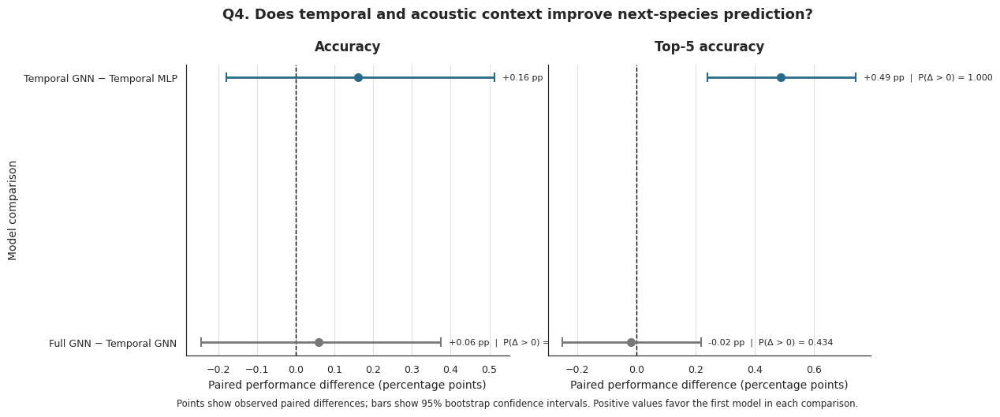

Saved files:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_1_paired_model_comparisons.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_1_paired_model_comparisons.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_1_paired_model_comparisons.svg

Values plotted (percentage points):


,comparison,metric,difference_pp,lower_pp,upper_pp,P(difference > 0)
0,Temporal GNN - Temporal MLP,Accuracy,0.161002,-0.178891,0.512821,0.8066
1,Full GNN - Temporal GNN,Accuracy,0.059630,-0.244484,0.375671,0.6505
2,Temporal GNN - Temporal MLP,Top-5 accuracy,0.488968,0.238521,0.742397,0.9999
3,Full GNN - Temporal GNN,Top-5 accuracy,-0.017889,-0.250447,0.217651,0.4343


In [43]:
# ============================================================
# Q4 FIGURE 1 — PAIRED MODEL COMPARISONS
# Temporal GNN vs Temporal MLP
# Full GNN vs Temporal GNN
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- Paths ----------
BASE = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
DATA = BASE / "data" / "derived"
OUT = DATA / "publication_figure_atlas"
OUT.mkdir(parents=True, exist_ok=True)

INPUT = DATA / "gnn_paired_bootstrap_results.csv"

if not INPUT.exists():
    raise FileNotFoundError(f"Could not find: {INPUT}")

df = pd.read_csv(INPUT)

required = {
    "comparison", "metric", "observed_difference",
    "CI_95_lower", "CI_95_upper", "P(difference > 0)"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

# ---------- Prepare data ----------
df["difference_pp"] = df["observed_difference"] * 100
df["lower_pp"] = df["CI_95_lower"] * 100
df["upper_pp"] = df["CI_95_upper"] * 100

comparisons = [
    "Temporal GNN - Temporal MLP",
    "Full GNN - Temporal GNN"
]
metrics = ["Accuracy", "Top-5 accuracy"]

df["comparison"] = pd.Categorical(
    df["comparison"], categories=comparisons, ordered=True
)
df["metric"] = pd.Categorical(
    df["metric"], categories=metrics, ordered=True
)
df = df.sort_values(["metric", "comparison"])

if len(df) != 4:
    raise ValueError(
        f"Expected four paired comparisons, found {len(df)}. "
        "Check the input CSV before plotting."
    )

# ---------- Figure ----------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

fig, axes = plt.subplots(
    1, 2, figsize=(11.2, 4.8),
    sharey=True,
    gridspec_kw={"wspace": 0.12}
)

colors = {
    "Temporal GNN - Temporal MLP": "#276A8A",
    "Full GNN - Temporal GNN": "#777777"
}

labels = {
    "Temporal GNN - Temporal MLP": "Temporal GNN − Temporal MLP",
    "Full GNN - Temporal GNN": "Full GNN − Temporal GNN"
}

y_positions = {
    "Temporal GNN - Temporal MLP": 1,
    "Full GNN - Temporal GNN": 0
}

for ax, metric in zip(axes, metrics):
    subset = df[df["metric"] == metric]

    ax.axvline(
        0, color="black", linewidth=1,
        linestyle="--", zorder=1
    )

    for _, row in subset.iterrows():
        comparison = str(row["comparison"])
        y = y_positions[comparison]
        color = colors[comparison]

        estimate = row["difference_pp"]
        lower = row["lower_pp"]
        upper = row["upper_pp"]

        ax.errorbar(
            estimate, y,
            xerr=[[estimate - lower], [upper - estimate]],
            fmt="o",
            markersize=7,
            color=color,
            ecolor=color,
            elinewidth=2,
            capsize=4,
            capthick=1.5,
            zorder=3
        )

        p = row["P(difference > 0)"]
        ax.annotate(
            f"{estimate:+.2f} pp  |  P(Δ > 0) = {p:.3f}",
            xy=(upper, y),
            xytext=(7, 0),
            textcoords="offset points",
            va="center",
            ha="left",
            fontsize=8
        )

    ax.set_title(metric, fontweight="bold", pad=12)
    ax.set_yticks([1, 0])
    ax.set_yticklabels([
        labels[comparisons[0]],
        labels[comparisons[1]]
    ])
    ax.set_xlabel("Paired performance difference (percentage points)")
    ax.grid(axis="x", color="#DDDDDD", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Model comparison")
axes[1].tick_params(axis="y", labelleft=False)

fig.suptitle(
    "Q4. Does temporal and acoustic context improve next-species prediction?",
    fontsize=13,
    fontweight="bold",
    y=1.03
)

fig.text(
    0.5, -0.025,
    "Points show observed paired differences; bars show 95% bootstrap confidence intervals. "
    "Positive values favor the first model in each comparison.",
    ha="center",
    fontsize=8.5
)

fig.tight_layout()

# ---------- Export ----------
stem = "Q4_Figure_1_paired_model_comparisons"

fig.savefig(OUT / f"{stem}.png", dpi=600, bbox_inches="tight")
fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")
fig.savefig(OUT / f"{stem}.svg", bbox_inches="tight")

plt.show()

print("Saved files:")
for ext in ["png", "pdf", "svg"]:
    print(OUT / f"{stem}.{ext}")

print("\nValues plotted (percentage points):")
display(
    df[[
        "comparison", "metric", "difference_pp",
        "lower_pp", "upper_pp", "P(difference > 0)"
    ]].reset_index(drop=True)
)

**Figure 1. Paired comparison of predictive performance across temporal and graph-based models.** Differences in Top-1 accuracy and Top-5 accuracy are shown for the temporal graph neural network (GNN) compared with the temporal multilayer perceptron (MLP), and for the full GNN incorporating acoustic features compared with the temporal GNN. Points represent observed paired performance differences, and horizontal bars indicate 95% bootstrap confidence intervals. Positive values favor the first model in each comparison. The temporal GNN showed a small, uncertain improvement in Top-1 accuracy over the temporal MLP, while its Top-5 accuracy improvement was supported by the bootstrap interval. Adding acoustic features to the GNN did not produce a clear improvement in either metric. Differences are expressed in percentage points (pp).

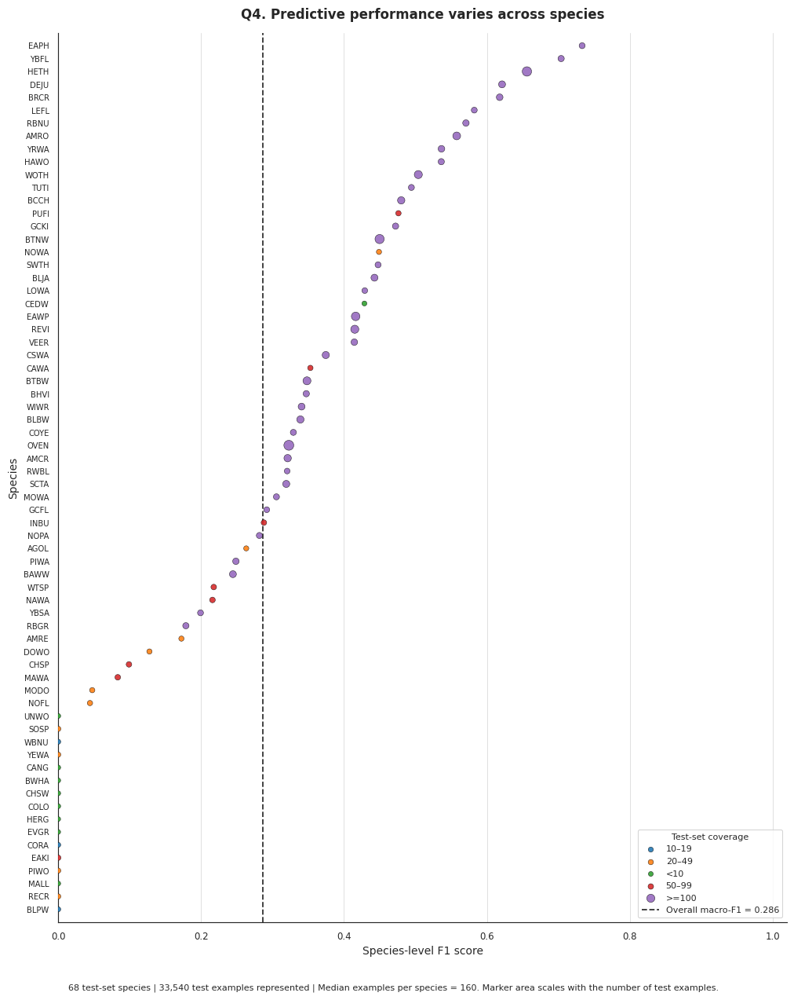

Exported:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_2_species_level_performance.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_2_species_level_performance.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_2_species_level_performance.svg

Species-level summary:
Species shown: 68
Test examples represented: 33,540
Median test examples per species: 160
F1 range: 0.000–0.733
Overall macro-F1 reference: 0.286


In [44]:
# ============================================================
# Q4 FIGURE 2 — SPECIES-LEVEL PREDICTIVE PERFORMANCE
# Corrected test-set species metrics
# Exports PNG (600 dpi), PDF, SVG
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ---------- Paths ----------
BASE = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
DATA = BASE / "data" / "derived"
OUT = DATA / "publication_figure_atlas"
OUT.mkdir(parents=True, exist_ok=True)

INPUT = DATA / "gnn_species_level_performance_corrected.csv"
OVERALL_INPUT = DATA / "gnn_corrected_overall_test_metrics.csv"

if not INPUT.exists():
    raise FileNotFoundError(f"Missing species results: {INPUT}")

species = pd.read_csv(INPUT)

required = {"species_code", "test_n", "precision", "recall", "f1_score"}
missing = required - set(species.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

species = species.dropna(subset=["species_code", "test_n", "f1_score"]).copy()
species["test_n"] = pd.to_numeric(species["test_n"], errors="coerce")
for col in ["precision", "recall", "f1_score"]:
    species[col] = pd.to_numeric(species[col], errors="coerce")

species = species.dropna(subset=["test_n", "f1_score"])
species = species.sort_values("f1_score", ascending=True).reset_index(drop=True)

# ---------- Overall macro-F1 reference ----------
macro_f1 = None
if OVERALL_INPUT.exists():
    overall = pd.read_csv(OVERALL_INPUT)
    match = overall.loc[overall["metric"] == "macro_F1", "value"]
    if len(match):
        macro_f1 = float(match.iloc[0])

# ---------- Plot styling ----------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 8.5,
    "axes.labelsize": 10,
    "axes.titlesize": 12,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 7.2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

fig_height = max(8.0, len(species) * 0.19)
fig, ax = plt.subplots(figsize=(10.5, fig_height))

y = np.arange(len(species))

# Marker size represents test sample size
sizes = 18 + 65 * (
    np.sqrt(species["test_n"]) /
    np.sqrt(species["test_n"].max())
)

# Color species by coverage group, if available
if "coverage_group" in species.columns:
    groups = species["coverage_group"].fillna("Unspecified").astype(str)
else:
    groups = pd.Series(["Unspecified"] * len(species))

unique_groups = list(pd.unique(groups))
palette = plt.get_cmap("tab10")
group_colors = {
    group: palette(i % 10)
    for i, group in enumerate(unique_groups)
}

for group in unique_groups:
    mask = groups == group
    ax.scatter(
        species.loc[mask, "f1_score"],
        y[mask],
        s=sizes[mask],
        color=group_colors[group],
        edgecolor="black",
        linewidth=0.35,
        alpha=0.88,
        label=group,
        zorder=3
    )

# Overall macro-F1 reference
if macro_f1 is not None:
    ax.axvline(
        macro_f1,
        color="#333333",
        linestyle="--",
        linewidth=1.3,
        zorder=1,
        label=f"Overall macro-F1 = {macro_f1:.3f}"
    )

ax.set_yticks(y)
ax.set_yticklabels(species["species_code"])
ax.set_xlabel("Species-level F1 score")
ax.set_ylabel("Species")
ax.set_xlim(0, 1.02)
ax.set_ylim(-1, len(species))
ax.set_title(
    "Q4. Predictive performance varies across species",
    fontweight="bold",
    pad=13
)

ax.grid(axis="x", color="#DDDDDD", linewidth=0.65)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend for coverage categories and overall reference
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles,
    labels,
    title="Test-set coverage",
    loc="lower right",
    frameon=True,
    fontsize=8,
    title_fontsize=8
)

# Sample-size note
median_n = species["test_n"].median()
total_species = len(species)
total_test_events = int(species["test_n"].sum())

fig.text(
    0.5, 0.012,
    f"{total_species} test-set species | "
    f"{total_test_events:,} test examples represented | "
    f"Median examples per species = {median_n:.0f}. "
    "Marker area scales with the number of test examples.",
    ha="center",
    fontsize=8
)

fig.tight_layout(rect=[0.02, 0.035, 0.99, 0.99])

# ---------- Export ----------
stem = "Q4_Figure_2_species_level_performance"

fig.savefig(OUT / f"{stem}.png", dpi=600, bbox_inches="tight")
fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")
fig.savefig(OUT / f"{stem}.svg", bbox_inches="tight")

plt.show()

print("Exported:")
for ext in ["png", "pdf", "svg"]:
    print(OUT / f"{stem}.{ext}")

print("\nSpecies-level summary:")
print(f"Species shown: {total_species}")
print(f"Test examples represented: {total_test_events:,}")
print(f"Median test examples per species: {median_n:.0f}")
print(f"F1 range: {species['f1_score'].min():.3f}–{species['f1_score'].max():.3f}")
if macro_f1 is not None:
    print(f"Overall macro-F1 reference: {macro_f1:.3f}")

**Figure 2. Species-level predictive performance of the temporal graph neural network.** Each point represents the F1 score for one of the 68 species represented in the corrected test set. Marker area is proportional to the number of test examples for that species. Species are ordered by increasing F1 score, and the dashed vertical line indicates overall macro-F1 across the evaluated test species. The variation in F1 scores illustrates differences in predictive performance among species, while marker size indicates the relative amount of test data supporting each estimate.

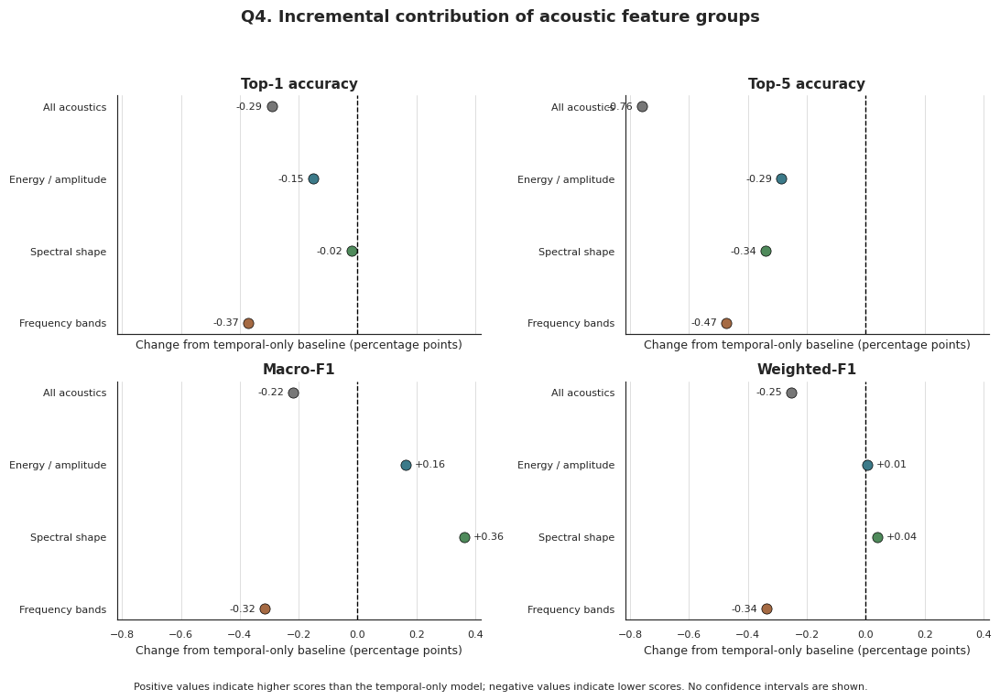

Exported:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_3_acoustic_feature_ablation.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_3_acoustic_feature_ablation.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_3_acoustic_feature_ablation.svg

Ablation values:


,model,Top-1 Δ (pp),Top-5 Δ (pp),Macro-F1 Δ (pp),Weighted-F1 Δ (pp)
0,All acoustics,-0.292188,-0.760286,-0.220366,-0.252178
1,Energy / amplitude,-0.152057,-0.286225,0.164437,0.006313
2,Spectral shape,-0.020871,-0.339893,0.362717,0.039871
3,Frequency bands,-0.372689,-0.474061,-0.315788,-0.337561


In [45]:
# ============================================================
# Q4 FIGURE 3 — ACOUSTIC FEATURE ABLATION
# Change in performance relative to temporal-only model
# Exports PNG (600 dpi), PDF, SVG
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- Paths ----------
BASE = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
DATA = BASE / "data" / "derived"
OUT = DATA / "publication_figure_atlas"
OUT.mkdir(parents=True, exist_ok=True)

INPUT = DATA / "step196_research_summary" / "step196_acoustic_ablation_metrics.csv"

if not INPUT.exists():
    raise FileNotFoundError(f"Could not find: {INPUT}")

df = pd.read_csv(INPUT)

required = {
    "model", "accuracy", "top5_accuracy",
    "macro_f1", "weighted_f1"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

# ---------- Identify baseline ----------
baseline_rows = df[df["model"].str.lower() == "temporal only"]
if len(baseline_rows) != 1:
    raise ValueError(
        "Expected exactly one 'Temporal only' baseline row."
    )

baseline = baseline_rows.iloc[0]

metrics = [
    ("accuracy", "Top-1 accuracy"),
    ("top5_accuracy", "Top-5 accuracy"),
    ("macro_f1", "Macro-F1"),
    ("weighted_f1", "Weighted-F1")
]

model_order = [
    "All acoustics",
    "Energy / amplitude",
    "Spectral shape",
    "Frequency bands"
]

df = df[df["model"].isin(model_order)].copy()

if set(df["model"]) != set(model_order):
    raise ValueError(
        "The ablation file does not contain all four expected acoustic models. "
        f"Found: {df['model'].tolist()}"
    )

# Calculate changes from temporal-only baseline, in percentage points
for metric, _ in metrics:
    df[f"{metric}_delta_pp"] = (
        df[metric] - float(baseline[metric])
    ) * 100

df["model"] = pd.Categorical(
    df["model"], categories=model_order, ordered=True
)
df = df.sort_values("model").reset_index(drop=True)

# ---------- Plot ----------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

fig, axes = plt.subplots(
    2, 2, figsize=(11, 7.4),
    sharex=True
)
axes = axes.flatten()

y = np.arange(len(model_order))
colors = {
    "All acoustics": "#777777",
    "Energy / amplitude": "#3C7A89",
    "Spectral shape": "#4F8A5B",
    "Frequency bands": "#A56A43"
}

for ax, (metric, title) in zip(axes, metrics):
    delta_col = f"{metric}_delta_pp"

    ax.axvline(
        0, color="black", linestyle="--",
        linewidth=1, zorder=1
    )

    for i, model in enumerate(model_order):
        value = float(
            df.loc[df["model"] == model, delta_col].iloc[0]
        )

        ax.scatter(
            value, i,
            s=65,
            color=colors[model],
            edgecolor="black",
            linewidth=0.5,
            zorder=3
        )

        # Put the numeric value just beyond the point
        offset = 7 if value >= 0 else -7
        alignment = "left" if value >= 0 else "right"

        ax.annotate(
            f"{value:+.2f}",
            xy=(value, i),
            xytext=(offset, 0),
            textcoords="offset points",
            ha=alignment,
            va="center",
            fontsize=8
        )

    ax.set_title(title, fontweight="bold")
    ax.set_yticks(y)
    ax.set_yticklabels(model_order)
    ax.invert_yaxis()
    ax.set_xlabel("Change from temporal-only baseline (percentage points)")
    ax.grid(axis="x", color="#DDDDDD", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Q4. Incremental contribution of acoustic feature groups",
    fontsize=13,
    fontweight="bold",
    y=1.01
)

fig.text(
    0.5, 0.005,
    "Positive values indicate higher scores than the temporal-only model; "
    "negative values indicate lower scores. No confidence intervals are shown.",
    ha="center",
    fontsize=8
)

fig.tight_layout(rect=[0, 0.035, 1, 0.97])

# ---------- Export ----------
stem = "Q4_Figure_3_acoustic_feature_ablation"

fig.savefig(OUT / f"{stem}.png", dpi=600, bbox_inches="tight")
fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")
fig.savefig(OUT / f"{stem}.svg", bbox_inches="tight")

plt.show()

print("Exported:")
for ext in ["png", "pdf", "svg"]:
    print(OUT / f"{stem}.{ext}")

print("\nAblation values:")
display(
    df[[
        "model",
        "accuracy_delta_pp",
        "top5_accuracy_delta_pp",
        "macro_f1_delta_pp",
        "weighted_f1_delta_pp"
    ]].rename(columns={
        "accuracy_delta_pp": "Top-1 Δ (pp)",
        "top5_accuracy_delta_pp": "Top-5 Δ (pp)",
        "macro_f1_delta_pp": "Macro-F1 Δ (pp)",
        "weighted_f1_delta_pp": "Weighted-F1 Δ (pp)"
    })
)

**Figure 3. Incremental contribution of acoustic feature groups to next-species prediction.** Performance differences are shown for models incorporating all acoustic features, energy/amplitude features, spectral-shape features, or frequency-band features, relative to the temporal-only baseline. Panels show changes in Top-1 accuracy, Top-5 accuracy, macro-F1, and weighted-F1, expressed in percentage points. Positive values indicate improved performance relative to the temporal-only model, whereas negative values indicate reduced performance. Acoustic feature inclusion did not consistently improve predictive performance; the spectral-shape model showed a small increase in macro-F1, while the model incorporating all acoustic features and the frequency-band model showed lower scores across the evaluated metrics. These comparisons are descriptive and do not include confidence intervals.

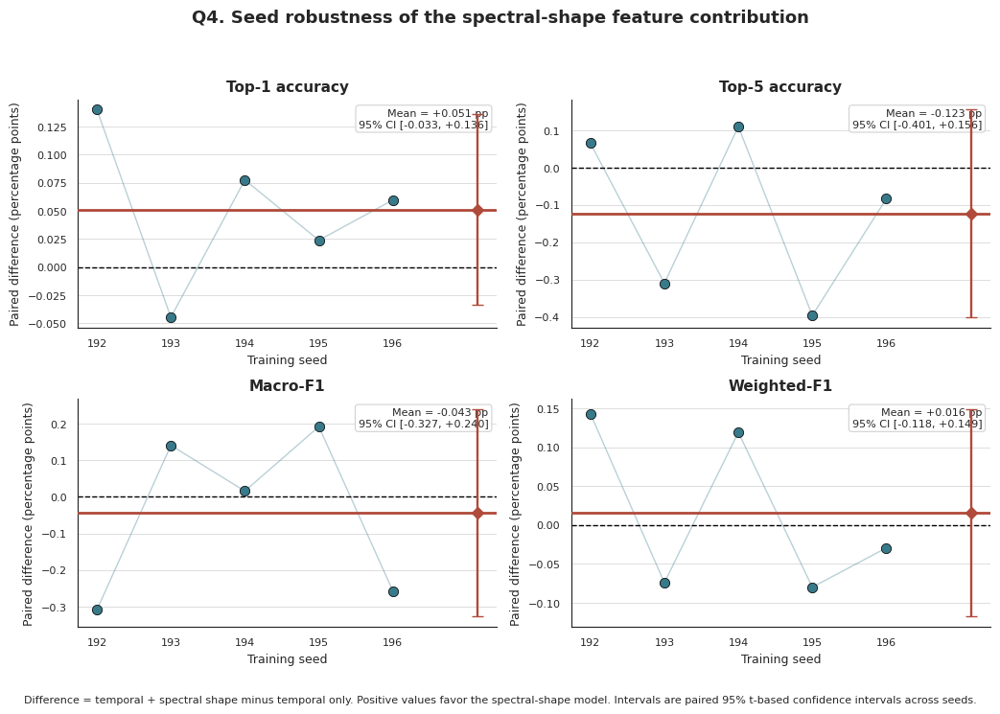

Exported:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_4_seed_robustness.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_4_seed_robustness.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_4_seed_robustness.svg

Paired seed differences:
Top-1 accuracy: mean=+0.0513 pp; 95% CI [-0.0334, +0.1360]
Top-5 accuracy: mean=-0.1228 pp; 95% CI [-0.4014, +0.1558]
Macro-F1: mean=-0.0435 pp; 95% CI [-0.3272, +0.2403]
Weighted-F1: mean=+0.0157 pp; 95% CI [-0.1178, +0.1493]


In [46]:
# ============================================================
# Q4 FIGURE 4 — ROBUSTNESS ACROSS TRAINING SEEDS
# Temporal only vs Temporal + spectral shape
# Exports PNG (600 dpi), PDF, SVG
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- Paths ----------
BASE = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
DATA = BASE / "data" / "derived"
OUT = DATA / "publication_figure_atlas"
OUT.mkdir(parents=True, exist_ok=True)

INPUT = DATA / "step196_research_summary" / "step196_seed_results.csv"

if not INPUT.exists():
    raise FileNotFoundError(f"Could not find: {INPUT}")

df = pd.read_csv(INPUT)

required = {
    "seed", "model", "accuracy", "top5_accuracy",
    "macro_f1", "weighted_f1"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

# ---------- Select the two matched models ----------
models = ["Temporal only", "Temporal + spectral shape"]
df = df[df["model"].isin(models)].copy()

if set(df["model"]) != set(models):
    raise ValueError("Both expected model types must be present.")

metrics = [
    ("accuracy", "Top-1 accuracy"),
    ("top5_accuracy", "Top-5 accuracy"),
    ("macro_f1", "Macro-F1"),
    ("weighted_f1", "Weighted-F1")
]

# Require one result per model per seed
counts = df.groupby(["seed", "model"]).size()
if not (counts == 1).all():
    raise ValueError("Duplicate model results detected within at least one seed.")

wide = df.pivot(index="seed", columns="model")
wide = wide.sort_index()

if wide.isna().any().any():
    raise ValueError("The two models do not have matching seed results.")

seeds = wide.index.tolist()
n = len(seeds)

if n < 2:
    raise ValueError("At least two matched seeds are required.")

# ---------- Paired differences ----------
# Difference is spectral-shape model minus temporal-only model.
# Convert scores to percentage points.
results = {}

for metric, title in metrics:
    delta = (
        wide[(metric, "Temporal + spectral shape")] -
        wide[(metric, "Temporal only")]
    ).to_numpy() * 100

    mean_delta = np.mean(delta)
    se = np.std(delta, ddof=1) / np.sqrt(n)

    # 95% two-sided t interval, df = n - 1
    from scipy.stats import t
    t_critical = t.ppf(0.975, df=n - 1)

    lower = mean_delta - t_critical * se
    upper = mean_delta + t_critical * se

    results[metric] = {
        "title": title,
        "values": delta,
        "mean": mean_delta,
        "lower": lower,
        "upper": upper
    }

# ---------- Plot ----------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.2))
axes = axes.flatten()

for ax, (metric, _) in zip(axes, metrics):
    r = results[metric]
    vals = r["values"]

    # Individual paired-seed differences
    x = np.arange(n)
    ax.scatter(
        x, vals,
        s=55,
        color="#397A8A",
        edgecolor="black",
        linewidth=0.55,
        zorder=3,
        label="Individual seed"
    )

    # Connect points to emphasize matched seeds
    ax.plot(
        x, vals,
        color="#397A8A",
        alpha=0.35,
        linewidth=1,
        zorder=2
    )

    # Mean and 95% t confidence interval
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.axhline(
        r["mean"],
        color="#B04A3A",
        linewidth=2,
        zorder=4
    )
    ax.errorbar(
        n + 0.15,
        r["mean"],
        yerr=[[
            r["mean"] - r["lower"]
        ], [
            r["upper"] - r["mean"]
        ]],
        fmt="D",
        color="#B04A3A",
        ecolor="#B04A3A",
        markersize=6,
        capsize=4,
        elinewidth=1.7,
        zorder=5
    )

    ax.set_title(r["title"], fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels([str(s) for s in seeds])
    ax.set_xlabel("Training seed")
    ax.set_ylabel("Paired difference (percentage points)")
    ax.grid(axis="y", color="#DDDDDD", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.text(
        0.98, 0.96,
        f"Mean = {r['mean']:+.3f} pp\n"
        f"95% CI [{r['lower']:+.3f}, {r['upper']:+.3f}]",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            edgecolor="#CCCCCC",
            alpha=0.9
        )
    )

fig.suptitle(
    "Q4. Seed robustness of the spectral-shape feature contribution",
    fontsize=13,
    fontweight="bold",
    y=1.01
)

fig.text(
    0.5, 0.005,
    "Difference = temporal + spectral shape minus temporal only. "
    "Positive values favor the spectral-shape model. "
    "Intervals are paired 95% t-based confidence intervals across seeds.",
    ha="center",
    fontsize=8
)

fig.tight_layout(rect=[0, 0.04, 1, 0.97])

# ---------- Export ----------
stem = "Q4_Figure_4_seed_robustness"

fig.savefig(OUT / f"{stem}.png", dpi=600, bbox_inches="tight")
fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")
fig.savefig(OUT / f"{stem}.svg", bbox_inches="tight")

plt.show()

print("Exported:")
for ext in ["png", "pdf", "svg"]:
    print(OUT / f"{stem}.{ext}")

print("\nPaired seed differences:")
for metric, _ in metrics:
    r = results[metric]
    print(
        f"{r['title']}: mean={r['mean']:+.4f} pp; "
        f"95% CI [{r['lower']:+.4f}, {r['upper']:+.4f}]"
    )

**Figure 4. Robustness of the spectral-shape feature contribution across training seeds.** Paired differences in predictive performance are shown between the temporal + spectral-shape model and the temporal-only model across five training seeds (192–196). Panels show Top-1 accuracy, Top-5 accuracy, macro-F1, and weighted-F1. Each point represents the difference for one matched seed; the horizontal reference line at zero indicates no difference. Diamonds and error bars show the mean paired difference and its 95% t-based confidence interval across seeds. Positive values favor the spectral-shape model. The small differences across seeds indicate that adding spectral-shape features does not produce a consistent, substantial improvement in predictive performance.

/tmp/ipykernel_404/1613905828.py:155: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0.035, 1, 0.97])


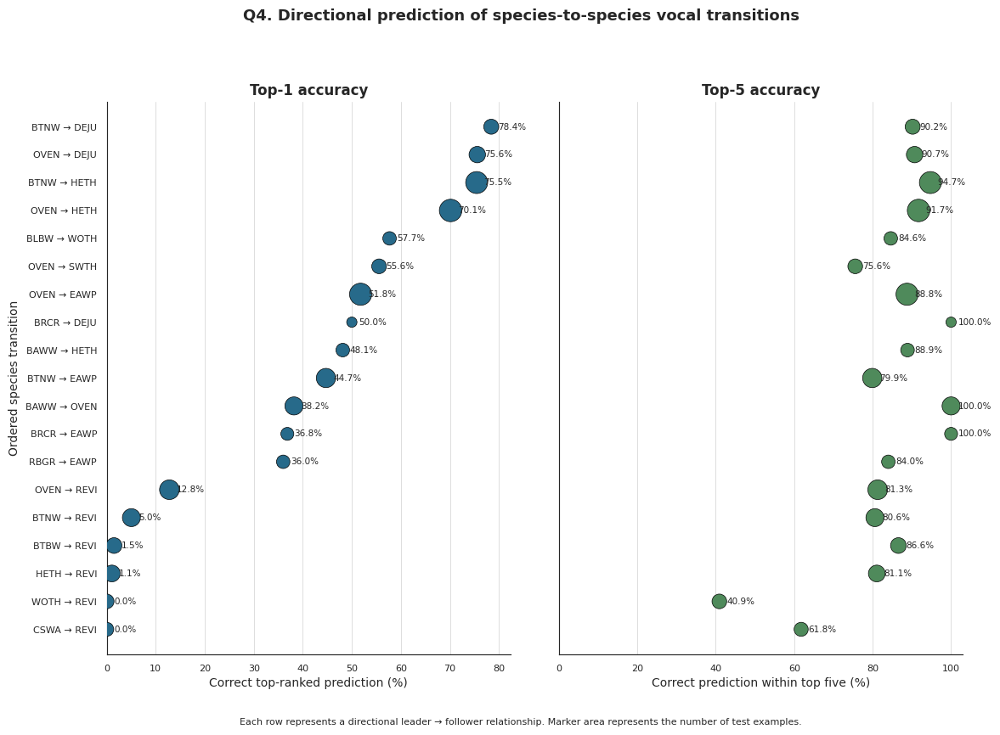

Exported:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_5_directional_transition_prediction.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_5_directional_transition_prediction.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q4_Figure_5_directional_transition_prediction.svg

Directional transition results:


,leader,follower,test_examples,top1_accuracy_pct,top5_accuracy_pct,mean_target_probability,mean_target_rank
18,BTNW,DEJU,51,78.431373,90.196078,0.502645,2.431373
17,OVEN,DEJU,86,75.581395,90.697674,0.462660,3.197674
16,BTNW,HETH,379,75.461741,94.722955,0.511316,1.897098
15,OVEN,HETH,422,70.142180,91.706161,0.495335,2.635071
14,BLBW,WOTH,26,57.692308,84.615385,0.262380,3.692308
13,OVEN,SWTH,45,55.555556,75.555556,0.360161,6.755556
12,OVEN,EAWP,392,51.785714,88.775510,0.322012,2.568878
11,BRCR,DEJU,2,50.000000,100.000000,0.233222,1.500000
10,BAWW,HETH,27,48.148148,88.888889,0.296129,4.481481
9,BTNW,EAWP,199,44.723618,79.899497,0.284354,3.608040



Summary file:


,metric,value
0,significant_directional_pairs,19.000000
1,pairs_represented_in_test,19.000000
2,pooled_top1_accuracy,0.472464
3,pooled_top5_accuracy,0.872464
4,overall_test_top1_accuracy,0.445170
5,overall_test_top5_accuracy,0.839595


In [48]:
# ============================================================
# Q4 FIGURE 5 — DIRECTIONAL SPECIES TRANSITION PREDICTION
# Uses actual leader/follower prediction results
# Exports PNG (600 dpi), PDF, SVG
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- Paths ----------
BASE = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
DATA = BASE / "data" / "derived"
OUT = DATA / "publication_figure_atlas"
OUT.mkdir(parents=True, exist_ok=True)

INPUT = DATA / "gnn_directional_relationship_recovery.csv"
SUMMARY_INPUT = DATA / "gnn_directional_relationship_summary.csv"

df = pd.read_csv(INPUT)
summary = pd.read_csv(SUMMARY_INPUT)

# ---------- Validate ----------
required = [
    "leader", "follower", "test_examples",
    "top1_accuracy", "top5_accuracy",
    "mean_target_probability", "mean_target_rank"
]

missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

for col in required[2:]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=[
    "leader", "follower", "test_examples",
    "top1_accuracy", "top5_accuracy"
]).copy()

if df.empty:
    raise ValueError("No valid directional transition records found.")

# ---------- Convert accuracy to percentages ----------
for col in ["top1_accuracy", "top5_accuracy"]:
    if df[col].max() <= 1:
        df[col + "_pct"] = df[col] * 100
    else:
        df[col + "_pct"] = df[col]

df["transition"] = (
    df["leader"].astype(str) + " → " +
    df["follower"].astype(str)
)

df = df.sort_values("top1_accuracy_pct", ascending=True).reset_index(drop=True)

# ---------- Figure ----------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

fig_height = max(6.5, len(df) * 0.34 + 2)
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, fig_height),
    sharey=True,
    gridspec_kw={"wspace": 0.12}
)

y = np.arange(len(df))

# Panel A: Top-1 accuracy
axes[0].scatter(
    df["top1_accuracy_pct"], y,
    s=55 + 15 * np.sqrt(df["test_examples"]),
    color="#276A8A",
    edgecolor="black",
    linewidth=0.5,
    zorder=3
)

for i, value in enumerate(df["top1_accuracy_pct"]):
    axes[0].annotate(
        f"{value:.1f}%",
        (value, i),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=7.5
    )

axes[0].set_title("Top-1 accuracy", fontweight="bold")
axes[0].set_xlabel("Correct top-ranked prediction (%)")
axes[0].set_ylabel("Ordered species transition")

# Panel B: Top-5 accuracy
axes[1].scatter(
    df["top5_accuracy_pct"], y,
    s=55 + 15 * np.sqrt(df["test_examples"]),
    color="#4F8A5B",
    edgecolor="black",
    linewidth=0.5,
    zorder=3
)

for i, value in enumerate(df["top5_accuracy_pct"]):
    axes[1].annotate(
        f"{value:.1f}%",
        (value, i),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=7.5
    )

axes[1].set_title("Top-5 accuracy", fontweight="bold")
axes[1].set_xlabel("Correct prediction within top five (%)")
axes[1].tick_params(axis="y", labelleft=False)

# Shared formatting
for ax in axes:
    ax.set_yticks(y)
    ax.set_yticklabels(df["transition"])
    ax.grid(axis="x", color="#DDDDDD", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(left=0)

fig.suptitle(
    "Q4. Directional prediction of species-to-species vocal transitions",
    fontsize=13,
    fontweight="bold",
    y=1.01
)

fig.text(
    0.5, 0.012,
    "Each row represents a directional leader → follower relationship. "
    "Marker area represents the number of test examples.",
    ha="center",
    fontsize=8
)

fig.tight_layout(rect=[0, 0.035, 1, 0.97])

# ---------- Export ----------
stem = "Q4_Figure_5_directional_transition_prediction"

fig.savefig(OUT / f"{stem}.png", dpi=600, bbox_inches="tight")
fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")
fig.savefig(OUT / f"{stem}.svg", bbox_inches="tight")

plt.show()

print("Exported:")
for ext in ["png", "pdf", "svg"]:
    print(OUT / f"{stem}.{ext}")

print("\nDirectional transition results:")
display(
    df[[
        "leader", "follower", "test_examples",
        "top1_accuracy_pct", "top5_accuracy_pct",
        "mean_target_probability", "mean_target_rank"
    ]].sort_values("top1_accuracy_pct", ascending=False)
)

print("\nSummary file:")
display(summary)

**Figure 5. Directional prediction performance for species-to-species vocal transitions.** Each row represents an ordered leader–follower species relationship evaluated on held-out test examples. The left panel shows Top-1 accuracy, the proportion of examples in which the follower species was the model's highest-ranked prediction. The right panel shows Top-5 accuracy, the proportion in which the actual follower appeared among the five highest-ranked predictions. Marker area represents the number of test examples supporting each relationship. Transition direction is preserved because leader–follower relationships are not necessarily equivalent to their reverse. The figure illustrates variation in the model's ability to predict subsequent species across directional relationships.

Q5 FIGURE 1 — MODEL COMPARISON
--------------------------------
Top-1 accuracy: temporal=44.252%, temporal + acoustics=43.959%, change=-0.292 pp
Top-5 accuracy: temporal=83.912%, temporal + acoustics=83.151%, change=-0.760 pp
Macro-F1: temporal=28.442%, temporal + acoustics=28.222%, change=-0.220 pp
Weighted-F1: temporal=42.333%, temporal + acoustics=42.081%, change=-0.252 pp


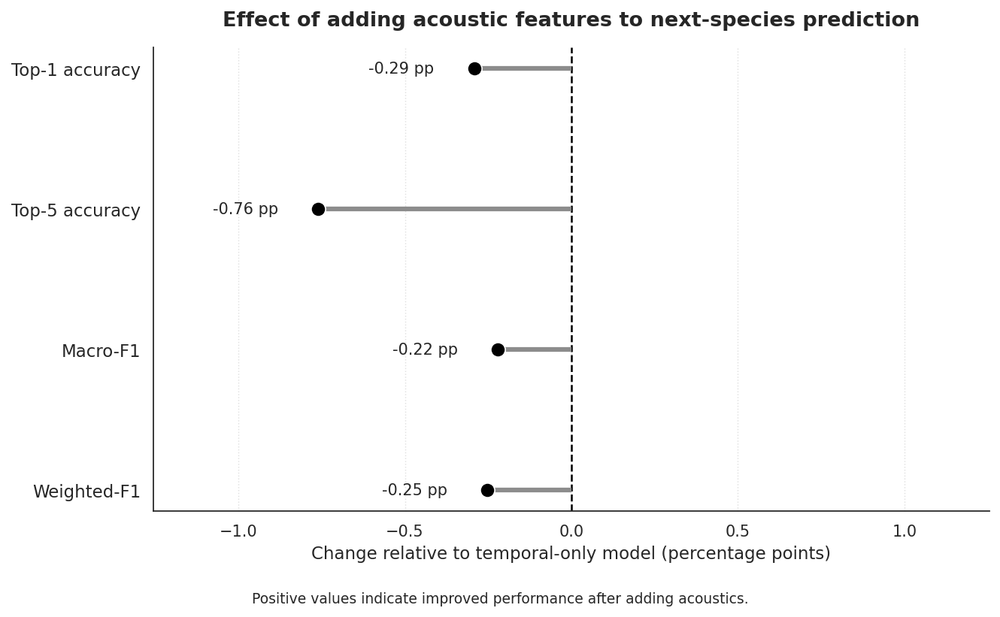


Saved figure files:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q5_Figure_1_temporal_vs_acoustic.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q5_Figure_1_temporal_vs_acoustic.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q5_Figure_1_temporal_vs_acoustic.svg


In [49]:
# ============================================================
# Q5 — FIGURE 1
# Temporal-only vs. temporal + all acoustic features
#
# Exports:
#   PNG (600 dpi), PDF, SVG
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

BASE = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
DERIVED = BASE / "data" / "derived"

INPUT = (
    DERIVED
    / "step190_acoustic_ablation"
    / "step190_ablation_results.csv"
)

OUTPUT_DIR = DERIVED / "publication_figure_atlas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert INPUT.exists(), f"Could not find results file: {INPUT}"

# ------------------------------------------------------------
# 2. Load results
# ------------------------------------------------------------

results = pd.read_csv(INPUT)

required_columns = [
    "model",
    "accuracy",
    "top5_accuracy",
    "macro_f1",
    "weighted_f1"
]

missing = [
    col for col in required_columns
    if col not in results.columns
]
assert not missing, f"Missing columns: {missing}"

baseline = results.loc[
    results["model"].str.lower().eq("temporal only")
]

acoustic = results.loc[
    results["model"].str.lower().eq("all acoustics")
]

assert len(baseline) == 1, "Expected one temporal-only row."
assert len(acoustic) == 1, "Expected one all-acoustics row."

baseline = baseline.iloc[0]
acoustic = acoustic.iloc[0]

# ------------------------------------------------------------
# 3. Calculate differences in percentage points
# ------------------------------------------------------------

metrics = {
    "Top-1 accuracy": "accuracy",
    "Top-5 accuracy": "top5_accuracy",
    "Macro-F1": "macro_f1",
    "Weighted-F1": "weighted_f1"
}

labels = list(metrics.keys())

differences = np.array([
    (acoustic[column] - baseline[column]) * 100
    for column in metrics.values()
])

baseline_values = np.array([
    baseline[column] * 100
    for column in metrics.values()
])

acoustic_values = np.array([
    acoustic[column] * 100
    for column in metrics.values()
])

print("Q5 FIGURE 1 — MODEL COMPARISON")
print("--------------------------------")
for label, base_value, acoustic_value, difference in zip(
    labels, baseline_values, acoustic_values, differences
):
    print(
        f"{label}: temporal={base_value:.3f}%, "
        f"temporal + acoustics={acoustic_value:.3f}%, "
        f"change={difference:+.3f} pp"
    )

# ------------------------------------------------------------
# 4. Publication-style figure
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 11,
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

fig, ax = plt.subplots(figsize=(9, 5.5))

y_positions = np.arange(len(labels))

# Zero reference: no change from temporal-only model
ax.axvline(
    0,
    color="black",
    linewidth=1.2,
    linestyle="--",
    zorder=1
)

# Horizontal difference bars
for y, difference in zip(y_positions, differences):

    ax.hlines(
        y=y,
        xmin=min(0, difference),
        xmax=max(0, difference),
        color="0.55",
        linewidth=3,
        zorder=2
    )

    ax.scatter(
        difference,
        y,
        s=85,
        color="black",
        edgecolor="white",
        linewidth=0.8,
        zorder=3
    )

    offset = 0.12 if difference >= 0 else -0.12
    alignment = "left" if difference >= 0 else "right"

    ax.text(
        difference + offset,
        y,
        f"{difference:+.2f} pp",
        va="center",
        ha=alignment,
        fontsize=10
    )

# Labels and formatting
ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.invert_yaxis()

ax.set_xlabel(
    "Change relative to temporal-only model (percentage points)"
)

ax.set_title(
    "Effect of adding acoustic features to next-species prediction",
    pad=14,
    fontweight="bold"
)

ax.grid(
    axis="x",
    linestyle=":",
    linewidth=0.7,
    alpha=0.6
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Symmetric axis limits with space for labels
max_abs = max(abs(differences).max(), 0.5)
padding = max_abs * 0.65
ax.set_xlim(
    -max_abs - padding,
    max_abs + padding
)

fig.text(
    0.5,
    0.015,
    "Positive values indicate improved performance after adding acoustics.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

# ------------------------------------------------------------
# 5. Export
# ------------------------------------------------------------

stem = OUTPUT_DIR / "Q5_Figure_1_temporal_vs_acoustic"

fig.savefig(
    f"{stem}.png",
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    f"{stem}.pdf",
    bbox_inches="tight"
)

fig.savefig(
    f"{stem}.svg",
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure files:")
print(f"{stem}.png")
print(f"{stem}.pdf")
print(f"{stem}.svg")

**Figure 1. Effect of adding audio-derived acoustic features on next-species vocalization prediction.** Predictive performance of the temporal-only model is compared with the temporal-plus-acoustic model incorporating 20 audio-derived features. Differences are shown in percentage points (pp) across four evaluation metrics: Top-1 accuracy (proportion of test events for which the most highly ranked predicted species was the actual next species); Top-5 accuracy (proportion for which the actual next species appeared among the five highest-ranked predictions); macro-F1 (F1 scores calculated separately for each species and averaged equally across species, giving rare and common species equal weight); and weighted-F1 (species-specific F1 scores averaged according to the number of test examples per species, giving more weight to frequently represented species). Positive values indicate improved performance after adding acoustic features; negative values indicate reduced performance. The full acoustic feature set did not improve any of the four metrics relative to the temporal-only model on the held-out test set of 33,540 events.

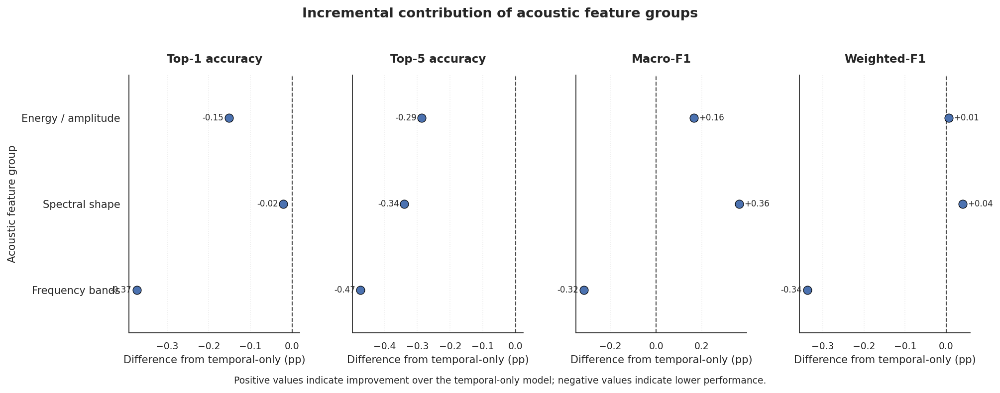

Differences from temporal-only baseline (percentage points):
Energy / amplitude: Top-1 accuracy -0.152, Top-5 accuracy -0.286, Macro-F1 +0.164, Weighted-F1 +0.006
Spectral shape: Top-1 accuracy -0.021, Top-5 accuracy -0.340, Macro-F1 +0.363, Weighted-F1 +0.040
Frequency bands: Top-1 accuracy -0.373, Top-5 accuracy -0.474, Macro-F1 -0.316, Weighted-F1 -0.338

Saved PNG, PDF, and SVG to:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas


In [50]:
# Q5 Figure 2 — Performance changes by acoustic feature group
# Exports publication-ready PNG (600 dpi), PDF, and SVG.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Paths
project_dir = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
data_file = (
    project_dir / "data/derived/step190_acoustic_ablation/"
    "step190_ablation_results.csv"
)
output_dir = (
    project_dir / "data/derived/publication_figure_atlas"
)
output_dir.mkdir(parents=True, exist_ok=True)

# Load matched STEP 190 results
df = pd.read_csv(data_file)

# Keep the temporal-only baseline and the three acoustic feature groups
groups = [
    "Energy / amplitude",
    "Spectral shape",
    "Frequency bands"
]
metrics = {
    "accuracy": "Top-1 accuracy",
    "top5_accuracy": "Top-5 accuracy",
    "macro_f1": "Macro-F1",
    "weighted_f1": "Weighted-F1"
}

baseline = df.loc[df["model"] == "Temporal only"]
if len(baseline) != 1:
    raise ValueError("Expected exactly one Temporal only baseline row.")

baseline = baseline.iloc[0]

# Calculate acoustic-minus-temporal differences in percentage points
plot_data = df[df["model"].isin(groups)].copy()
plot_data["model"] = pd.Categorical(
    plot_data["model"], categories=groups, ordered=True
)
plot_data = plot_data.sort_values("model")

if set(plot_data["model"].astype(str)) != set(groups):
    raise ValueError("One or more expected acoustic feature groups are missing.")

differences = {
    metric: (
        plot_data[metric].to_numpy() - baseline[metric]
    ) * 100
    for metric in metrics
}

# Plot
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(
    1, 4, figsize=(13.5, 4.8), sharey=True
)

y = np.arange(len(groups))

for ax, (metric, title) in zip(axes, metrics.items()):
    values = differences[metric]

    ax.axvline(
        0, color="black", linewidth=1,
        linestyle="--", alpha=0.7, zorder=1
    )

    ax.scatter(
        values, y, s=65,
        edgecolor="black", linewidth=0.6,
        zorder=3
    )

    # Label each point with its difference
    for x_value, y_value in zip(values, y):
        offset = 5 if x_value >= 0 else -5
        ax.annotate(
            f"{x_value:+.2f}",
            (x_value, y_value),
            xytext=(offset, 0),
            textcoords="offset points",
            ha="left" if x_value >= 0 else "right",
            va="center",
            fontsize=8
        )

    ax.set_title(title, pad=12)
    ax.set_xlabel("Difference from temporal-only (pp)")
    ax.grid(axis="x", linestyle=":", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(len(groups) - 0.5, -0.5)

axes[0].set_yticks(y)
axes[0].set_yticklabels(groups)
axes[0].set_ylabel("Acoustic feature group")

fig.suptitle(
    "Incremental contribution of acoustic feature groups",
    fontsize=13, fontweight="bold", y=1.03
)

fig.text(
    0.5, -0.02,
    "Positive values indicate improvement over the temporal-only model; "
    "negative values indicate lower performance.",
    ha="center", fontsize=9
)

fig.tight_layout()

# Export
stem = output_dir / "Q5_Figure_2_acoustic_feature_ablation"

fig.savefig(
    f"{stem}.png", dpi=600, bbox_inches="tight",
    facecolor="white"
)
fig.savefig(
    f"{stem}.pdf", bbox_inches="tight",
    facecolor="white"
)
fig.savefig(
    f"{stem}.svg", bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Print the values represented in the figure
print("Differences from temporal-only baseline (percentage points):")
for i, group in enumerate(groups):
    print(
        f"{group}: "
        + ", ".join(
            f"{label} {differences[metric][i]:+.3f}"
            for metric, label in metrics.items()
        )
    )

print(f"\nSaved PNG, PDF, and SVG to:\n{output_dir}")

**Figure 2. Incremental contribution of acoustic feature groups to next-species vocalization prediction.** Differences in held-out test performance between models incorporating individual acoustic feature groups and the temporal-only baseline are shown in percentage points (pp). The four panels report Top-1 accuracy (proportion of test events for which the highest-ranked predicted species was the actual next species), Top-5 accuracy (proportion for which the actual next species appeared among the five highest-ranked predictions), macro-F1 (the unweighted mean of species-specific F1 scores, giving each species equal weight), and weighted-F1 (the mean of species-specific F1 scores weighted by the number of test examples for each species). Positive values indicate improved performance relative to the temporal-only model; negative values indicate reduced performance. Spectral-shape features produced a small increase in macro-F1 (+0.36 pp) and weighted-F1 (+0.04 pp), but reduced Top-1 and Top-5 accuracy. Energy/amplitude features produced similarly small, mixed changes, while frequency-band features reduced all four metrics. Results are based on the same held-out test set of 33,540 events; uncertainty intervals are not shown.

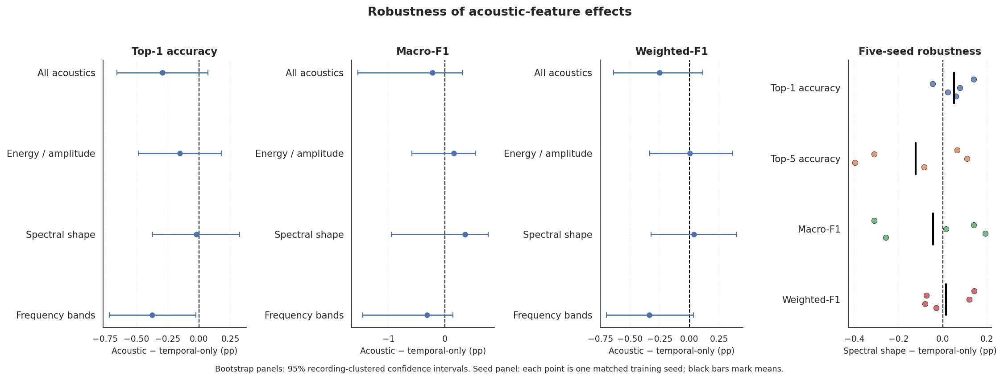

Five-seed mean differences (percentage points):
Top-1 accuracy: +0.051 pp (positive in 4/5 seeds)
Top-5 accuracy: -0.123 pp (positive in 2/5 seeds)
Macro-F1: -0.043 pp (positive in 3/5 seeds)
Weighted-F1: +0.016 pp (positive in 2/5 seeds)

Saved PNG, PDF, and SVG to:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas


In [51]:
# Q5 Figure 3 — Recording-clustered uncertainty and seed robustness
# Exports PNG (600 dpi), PDF, and SVG.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_dir = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
derived_dir = project_dir / "data/derived"
output_dir = derived_dir / "publication_figure_atlas"
output_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Recording-clustered bootstrap results (STEP 198)
# Values are acoustic model minus temporal-only model.
# Intervals are 95% CIs from 2,000 resamples of 254 recordings.
# ------------------------------------------------------------

groups = [
    "All acoustics",
    "Energy / amplitude",
    "Spectral shape",
    "Frequency bands"
]

bootstrap = {
    "Top-1 accuracy": {
        "difference": [-0.002922, -0.001521, -0.000209, -0.003727],
        "lower":      [-0.00655,  -0.00482,  -0.00370,  -0.00715],
        "upper":      [ 0.00072,   0.00178,   0.00325,  -0.00025]
    },
    "Macro-F1": {
        "difference": [-0.002204, 0.001644, 0.003627, -0.003158],
        "lower":      [-0.01547, -0.00583, -0.00953, -0.01465],
        "upper":      [ 0.00314,  0.00541,  0.00773,  0.00145]
    },
    "Weighted-F1": {
        "difference": [-0.002522, 0.000063, 0.000399, -0.003376],
        "lower":      [-0.00641, -0.00336, -0.00322, -0.00699],
        "upper":      [ 0.00114,  0.00363,  0.00399,  0.00033]
    }
}

# ------------------------------------------------------------
# 2. Five-seed robustness results (STEP 192 / STEP 196)
# ------------------------------------------------------------

seed_file = (
    derived_dir / "step192_seed_robustness" /
    "step192_seed_results.csv"
)
seed_df = pd.read_csv(seed_file)

required_models = {"Temporal only", "Temporal + spectral shape"}
if not required_models.issubset(set(seed_df["model"])):
    raise ValueError("Expected temporal-only and temporal + spectral shape models.")

seed_metrics = {
    "Top-1 accuracy": "accuracy",
    "Top-5 accuracy": "top5_accuracy",
    "Macro-F1": "macro_f1",
    "Weighted-F1": "weighted_f1"
}

seed_wide = seed_df.pivot(
    index="seed", columns="model", values=list(seed_metrics.values())
)

seed_differences = {}
for label, metric in seed_metrics.items():
    seed_differences[label] = (
        seed_wide[metric]["Temporal + spectral shape"]
        - seed_wide[metric]["Temporal only"]
    ) * 100  # percentage points

# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(1, 4, figsize=(15, 5.2))

y = np.arange(len(groups))

# Bootstrap panels
for ax, metric in zip(axes[:3], bootstrap.keys()):
    values = np.array(bootstrap[metric]["difference"]) * 100
    lower = np.array(bootstrap[metric]["lower"]) * 100
    upper = np.array(bootstrap[metric]["upper"]) * 100

    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.errorbar(
        values, y,
        xerr=[values - lower, upper - values],
        fmt="o", capsize=3, markersize=5,
        linewidth=1.3
    )

    ax.set_yticks(y)
    ax.set_yticklabels(groups)
    ax.invert_yaxis()
    ax.set_title(metric)
    ax.set_xlabel("Acoustic − temporal-only (pp)")
    ax.grid(axis="x", linestyle=":", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Five-seed panel: paired differences
ax = axes[3]
ax.axvline(0, color="black", linestyle="--", linewidth=1)

seed_labels = list(seed_metrics.keys())
seed_y = np.arange(len(seed_labels))

for i, label in enumerate(seed_labels):
    vals = np.asarray(seed_differences[label], dtype=float)
    jitter = np.linspace(-0.12, 0.12, len(vals))

    ax.scatter(
        vals, np.full(len(vals), i) + jitter,
        s=35, alpha=0.8, edgecolor="black", linewidth=0.4
    )

    mean_val = vals.mean()
    ax.plot(
        [mean_val, mean_val],
        [i - 0.22, i + 0.22],
        color="black", linewidth=2
    )

ax.set_yticks(seed_y)
ax.set_yticklabels(seed_labels)
ax.invert_yaxis()
ax.set_title("Five-seed robustness")
ax.set_xlabel("Spectral shape − temporal-only (pp)")
ax.grid(axis="x", linestyle=":", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.suptitle(
    "Robustness of acoustic-feature effects",
    fontsize=13, fontweight="bold", y=1.03
)

fig.text(
    0.5, -0.02,
    "Bootstrap panels: 95% recording-clustered confidence intervals. "
    "Seed panel: each point is one matched training seed; black bars mark means.",
    ha="center", fontsize=8.5
)

fig.tight_layout()

# ------------------------------------------------------------
# 4. Export
# ------------------------------------------------------------

stem = output_dir / "Q5_Figure_3_acoustic_robustness"

fig.savefig(
    f"{stem}.png", dpi=600,
    bbox_inches="tight", facecolor="white"
)
fig.savefig(
    f"{stem}.pdf",
    bbox_inches="tight", facecolor="white"
)
fig.savefig(
    f"{stem}.svg",
    bbox_inches="tight", facecolor="white"
)

plt.show()

print("Five-seed mean differences (percentage points):")
for label, values in seed_differences.items():
    print(
        f"{label}: {np.mean(values):+.3f} pp "
        f"(positive in {(values > 0).sum()}/5 seeds)"
    )

print(f"\nSaved PNG, PDF, and SVG to:\n{output_dir}")

**Figure 3. Robustness of the incremental effects of acoustic features on next-species prediction.** The first three panels show differences between acoustic-feature models and the temporal-only baseline for Top-1 accuracy, macro-F1, and weighted-F1, with 95% confidence intervals estimated using 2,000 recording-clustered bootstrap resamples of the 254 held-out test recordings. Differences are expressed in percentage points (pp); values below zero indicate lower performance after adding acoustic features. The dashed vertical line indicates no difference. The fourth panel shows paired performance differences between temporal-plus-spectral-shape and temporal-only models across five training seeds (192–196); each point represents one seed, and the black horizontal marker indicates the mean difference. Most bootstrap intervals include zero, except the Top-1 accuracy interval for frequency-band features, which is entirely negative. Spectral-shape effects vary across metrics and seeds, indicating that the small improvements observed in selected metrics are not consistently reproduced. Bootstrap intervals condition on the fitted models and do not capture variability from retraining.

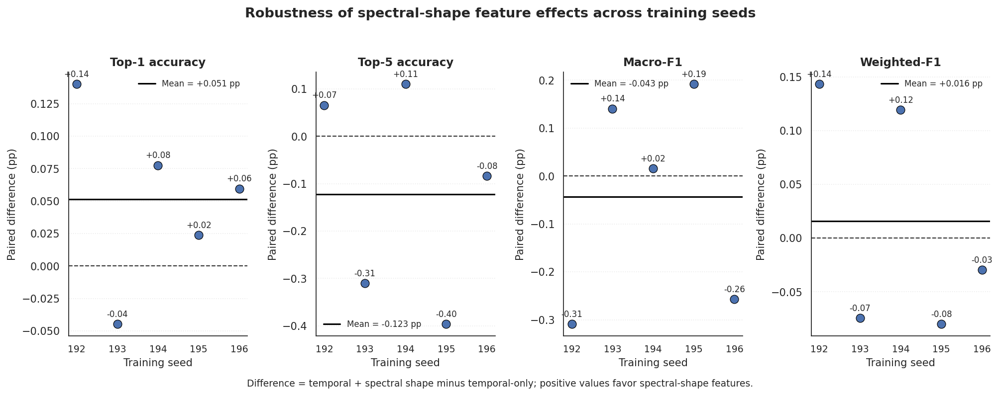

Paired differences by seed (percentage points):

Top-1 accuracy
  Seed 192: +0.140 pp
  Seed 193: -0.045 pp
  Seed 194: +0.078 pp
  Seed 195: +0.024 pp
  Seed 196: +0.060 pp
  Mean: +0.051 pp

Top-5 accuracy
  Seed 192: +0.066 pp
  Seed 193: -0.310 pp
  Seed 194: +0.110 pp
  Seed 195: -0.397 pp
  Seed 196: -0.083 pp
  Mean: -0.123 pp

Macro-F1
  Seed 192: -0.309 pp
  Seed 193: +0.141 pp
  Seed 194: +0.016 pp
  Seed 195: +0.192 pp
  Seed 196: -0.257 pp
  Mean: -0.043 pp

Weighted-F1
  Seed 192: +0.143 pp
  Seed 193: -0.074 pp
  Seed 194: +0.119 pp
  Seed 195: -0.080 pp
  Seed 196: -0.029 pp
  Mean: +0.016 pp

Saved PNG, PDF, and SVG to:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas


In [52]:
# Q5 Figure 4 — Five-seed paired robustness comparison
# Exports PNG (600 dpi), PDF, and SVG.

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_dir = Path("/content/gdrive/MyDrive/Bioacoustics_Project")
data_file = (
    project_dir / "data/derived/step192_seed_robustness/"
    "step192_seed_results.csv"
)
output_dir = (
    project_dir / "data/derived/publication_figure_atlas"
)
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_file)

metrics = {
    "accuracy": "Top-1 accuracy",
    "top5_accuracy": "Top-5 accuracy",
    "macro_f1": "Macro-F1",
    "weighted_f1": "Weighted-F1"
}

# Pair models by seed
wide = df.pivot(
    index="seed",
    columns="model",
    values=list(metrics.keys())
).sort_index()

required = ["Temporal only", "Temporal + spectral shape"]
if not all(model in wide.columns.get_level_values(1) for model in required):
    raise ValueError("Expected both model variants for every seed.")

seeds = wide.index.to_numpy()

# Calculate paired differences in percentage points
differences = {}
for metric in metrics:
    differences[metric] = (
        wide[metric]["Temporal + spectral shape"]
        - wide[metric]["Temporal only"]
    ).to_numpy() * 100

# Plot
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, axes = plt.subplots(1, 4, figsize=(13.5, 4.8))

for ax, (metric, title) in zip(axes, metrics.items()):
    values = differences[metric]

    ax.axhline(
        0, color="black", linestyle="--",
        linewidth=1, alpha=0.8
    )

    ax.scatter(
        seeds, values,
        s=65, edgecolor="black",
        linewidth=0.6, zorder=3
    )

    mean_value = values.mean()
    ax.axhline(
        mean_value, color="black",
        linewidth=1.5, linestyle="-",
        label=f"Mean = {mean_value:+.3f} pp"
    )

    for seed, value in zip(seeds, values):
        ax.annotate(
            f"{value:+.2f}",
            (seed, value),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center", fontsize=8
        )

    ax.set_title(title)
    ax.set_xlabel("Training seed")
    ax.set_xticks(seeds)
    ax.set_ylabel("Paired difference (pp)")
    ax.grid(axis="y", linestyle=":", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=8, loc="best")

fig.suptitle(
    "Robustness of spectral-shape feature effects across training seeds",
    fontsize=13, fontweight="bold", y=1.04
)

fig.text(
    0.5, -0.02,
    "Difference = temporal + spectral shape minus temporal-only; "
    "positive values favor spectral-shape features.",
    ha="center", fontsize=9
)

fig.tight_layout()

stem = output_dir / "Q5_Figure_4_five_seed_robustness"

fig.savefig(
    f"{stem}.png", dpi=600,
    bbox_inches="tight", facecolor="white"
)
fig.savefig(
    f"{stem}.pdf",
    bbox_inches="tight", facecolor="white"
)
fig.savefig(
    f"{stem}.svg",
    bbox_inches="tight", facecolor="white"
)

plt.show()

print("Paired differences by seed (percentage points):")
for metric, title in metrics.items():
    print(f"\n{title}")
    for seed, value in zip(seeds, differences[metric]):
        print(f"  Seed {seed}: {value:+.3f} pp")
    print(f"  Mean: {np.mean(differences[metric]):+.3f} pp")

print(f"\nSaved PNG, PDF, and SVG to:\n{output_dir}")

**Figure 4. Consistency of spectral-shape feature effects across five training seeds.** Paired differences in held-out test performance are shown for temporal-plus-spectral-shape models relative to temporal-only models trained using the same five random seeds (192–196). Panels show Top-1 accuracy (proportion of events for which the highest-ranked prediction was correct), Top-5 accuracy (proportion for which the correct species appeared among the five highest-ranked predictions), macro-F1 (the equally weighted average of species-specific F1 scores), and weighted-F1 (the average of species-specific F1 scores weighted by the number of test examples per species). Each point represents one seed; the solid horizontal line indicates the mean paired difference, and the dashed line indicates no difference. Positive values favor adding spectral-shape features. Effects were small and varied across evaluation metrics, providing no consistent evidence of a robust improvement across training runs. Differences are descriptive across five seeds and should not be interpreted as confidence intervals or independent-recording uncertainty.

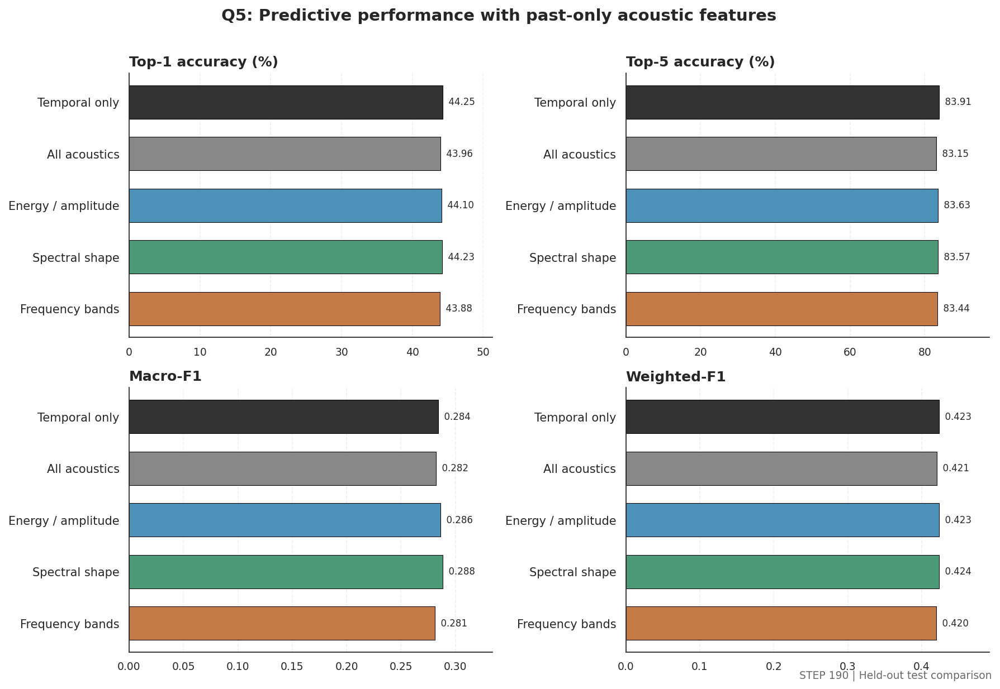

Saved files:
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q5_Figure_5_overall_acoustic_feature_performance.png
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q5_Figure_5_overall_acoustic_feature_performance.pdf
/content/gdrive/MyDrive/Bioacoustics_Project/data/derived/publication_figure_atlas/Q5_Figure_5_overall_acoustic_feature_performance.svg


In [53]:
# Q5 Figure 5 — Overall performance across acoustic feature groups
# Exports PNG (600 dpi), PDF, and SVG.

import os
import numpy as np
import matplotlib.pyplot as plt

OUT_DIR = (
    "/content/gdrive/MyDrive/Bioacoustics_Project/"
    "data/derived/publication_figure_atlas"
)
os.makedirs(OUT_DIR, exist_ok=True)

# STEP 190 held-out test results
models = [
    "Temporal only",
    "All acoustics",
    "Energy / amplitude",
    "Spectral shape",
    "Frequency bands"
]

metrics = {
    "Top-1 accuracy (%)": [44.2516, 43.9595, 44.0995, 44.2308, 43.8790],
    "Top-5 accuracy (%)": [83.9117, 83.1515, 83.6255, 83.5719, 83.4377],
    "Macro-F1":           [0.284423, 0.282219, 0.286067, 0.288050, 0.281265],
    "Weighted-F1":        [0.423333, 0.420811, 0.423396, 0.423732, 0.419958]
}

colors = ["#333333", "#888888", "#4C91B8", "#4C9A78", "#C47A45"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "svg.fonttype": "none",
    "pdf.fonttype": 42
})

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, (metric, values) in zip(axes, metrics.items()):
    y = np.arange(len(models))

    bars = ax.barh(
        y, values,
        color=colors,
        edgecolor="black",
        linewidth=0.5,
        height=0.65
    )

    ax.set_yticks(y)
    ax.set_yticklabels(models)
    ax.invert_yaxis()
    ax.set_title(metric, loc="left", fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    # Consistent, readable value labels
    for bar, value in zip(bars, values):
        label = f"{value:.2f}" if "%" in metric else f"{value:.3f}"
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            "  " + label,
            va="center",
            ha="left",
            fontsize=8
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Start axes at zero so bar lengths remain interpretable
    ax.set_xlim(0, max(values) * 1.16)

fig.suptitle(
    "Q5: Predictive performance with past-only acoustic features",
    fontsize=14,
    fontweight="bold",
    y=1.01
)

fig.text(
    0.99, 0.01,
    "STEP 190 | Held-out test comparison",
    ha="right",
    fontsize=9,
    color="dimgray"
)

fig.tight_layout()

base = os.path.join(
    OUT_DIR,
    "Q5_Figure_5_overall_acoustic_feature_performance"
)

fig.savefig(base + ".png", dpi=600, bbox_inches="tight")
fig.savefig(base + ".pdf", bbox_inches="tight")
fig.savefig(base + ".svg", bbox_inches="tight")

plt.show()

print("Saved files:")
print(base + ".png")
print(base + ".pdf")
print(base + ".svg")

**Figure 5. Predictive performance across temporal and acoustic feature configurations.** Comparison of the temporal-only baseline with all-acoustic, energy/amplitude, spectral-shape, and frequency-band models on the held-out test set (STEP 190; 33,540 events). Performance is evaluated using Top-1 accuracy (correctness of the highest-ranked prediction), Top-5 accuracy (whether the correct species appears among the five highest-ranked predictions), macro-F1 (equal weighting of species-specific F1 scores), and weighted-F1 (F1 scores weighted by the number of test events per species). The addition of all acoustic features did not improve performance over the temporal-only baseline. Spectral-shape features produced a small increase in macro-F1, while Top-1 and Top-5 accuracy remained lower than the baseline. Overall, the tested past-only acoustic features did not demonstrate consistent incremental predictive benefit.